# 1. Data Cleaning and Auditing

The Formula 1 dataset consists of 14 relational CSV tables. Before constructing the
modeling dataset, the raw data is explored and audited to identify missing values,
incorrect data types, duplicate records, and relational-integrity problems.

The cleaning process includes:
- exploratory data analysis before cleaning;
- detection and cleaning of `\N` sentinel values;
- semantic typing of dates and durations;
- primary-key and foreign-key validation;
- investigation and resolution of duplicate `(raceId, driverId)` records;
- and exploratory analysis after cleaning.

The original DataFrames are preserved unchanged. All cleaning operations are
performed on separate copies.

In [621]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import os

In [622]:
DATA_PATH = "/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020"

file_names = [
    "circuits",
    "constructors",
    "constructor_results",
    "constructor_standings",
    "drivers",
    "driver_standings",
    "races",
    "results",
    "qualifying",
    "lap_times",
    "pit_stops",
    "sprint_results",
    "seasons",
    "status"
]

raw_data = {}

for name in file_names:
    raw_data[name] = pd.read_csv(
        f"{DATA_PATH}/{name}.csv"
    )

print("Number of tables loaded:", len(raw_data))

Number of tables loaded: 14


## 1.1 Initial Exploratory Data Analysis

The raw tables are first explored without modification. Their dimensions, data types,
summary statistics, missing values, duplicate rows, and placeholder values are
examined programmatically.

This provides a baseline for identifying cleaning requirements and allows the effect
of cleaning to be evaluated later.

In [623]:
for name, df in raw_data.items():
    print(f"\n{name.upper()}")
    display(df.head())


CIRCUITS


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park



CONSTRUCTORS


,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso



CONSTRUCTOR_RESULTS


...

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1,1,1,3,17,25:38.426,1538426,14,1:30.013,1
1,2,1061,1,131,44,1,2,2,2,2,17,+1.430,1539856,17,1:29.937,1
2,3,1061,822,131,77,3,3,3,3,1,17,+7.502,1545928,17,1:29.958,1
3,4,1061,844,6,16,4,4,4,4,0,17,+11.278,1549704,16,1:30.163,1
4,5,1061,846,1,4,6,5,5,5,0,17,+24.111,1562537,16,1:30.566,1



SEASONS


,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...



STATUS


,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine


In [624]:
overview = []

for name, df in raw_data.items():
    overview.append({
        "Table": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1]
    })

overview_df = pd.DataFrame(overview)

display(overview_df)

,Table,Rows,Columns
0,circuits,77,9
1,constructors,212,5
2,constructor_results,12625,5
3,constructor_standings,13391,7
4,drivers,861,9
5,driver_standings,34863,7
6,races,1125,18
7,results,26759,18
8,qualifying,10494,9
9,lap_times,589081,6


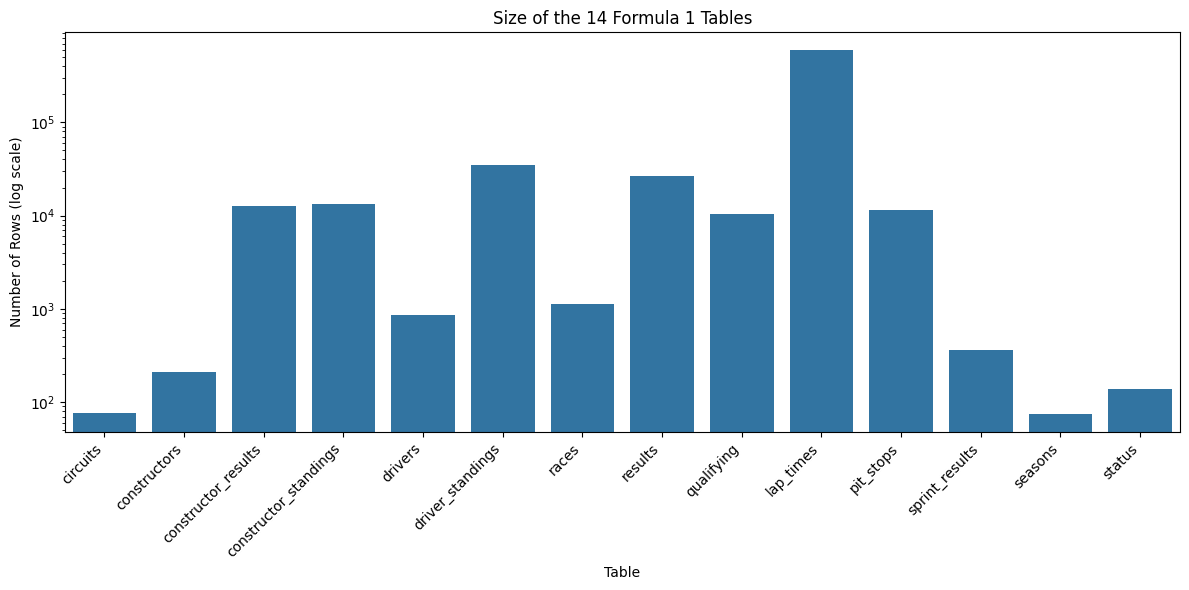

In [625]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=overview_df,
    x="Table",
    y="Rows"
)

plt.yscale("log")
plt.title("Size of the 14 Formula 1 Tables")
plt.xlabel("Table")
plt.ylabel("Number of Rows (log scale)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [626]:
for name, df in raw_data.items():
    print("\n" + "=" * 70)
    print(name.upper())
    print("=" * 70)

    df.info()


CIRCUITS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB

CONSTRUCTORS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   constructorId   212 non-null    int64 
 1   constructorRef  212 non-null    object
 2   name            212 non-null    object
 3   nationality     212 non-null    

In [627]:
for name, df in raw_data.items():
    print("\n" + "=" * 70)
    print(name.upper())
    print("=" * 70)

    display(df.describe())


CIRCUITS


,circuitId,lat,lng,alt
count,77.000000,77.000000,77.000000,77.000000
mean,39.883117,33.442925,1.076683,247.012987
std,23.001701,22.808866,65.516951,362.738469
min,1.000000,-37.849700,-118.189000,-7.000000
25%,20.000000,32.777400,-9.394170,18.000000
50%,40.000000,40.951700,3.930830,129.000000
75%,59.000000,46.958900,19.248600,332.000000
max,80.000000,57.265300,144.968000,2227.000000



CONSTRUCTORS


,constructorId
count,212.000000
mean,107.547170
std,61.952685
min,1.000000
25%,54.750000
50%,107.500000
75%,160.250000
max,215.000000



CONSTRUCTOR_RESULTS


...

,resultId,raceId,driverId,constructorId,number,grid,positionOrder,points,laps,statusId
count,360.000000,360.000000,360.000000,360.000000,360.000000,360.000000,360.000000,360.000000,360.000000,360.000000
mean,180.500000,1106.944444,734.658333,94.366667,28.177778,9.922222,10.500000,1.550000,19.583333,3.336111
std,104.067286,25.636134,276.412115,89.166421,23.796293,5.842363,5.774307,2.496293,4.752803,13.447963
min,1.000000,1061.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000
25%,90.750000,1084.000000,822.000000,6.000000,11.000000,5.000000,5.750000,0.000000,18.000000,1.000000
50%,180.500000,1112.500000,840.000000,84.000000,22.000000,10.000000,10.500000,0.000000,19.000000,1.000000
75%,270.250000,1126.000000,848.000000,210.000000,44.000000,15.000000,15.250000,3.000000,24.000000,1.000000
max,360.000000,1143.000000,861.000000,215.000000,99.000000,20.000000,20.000000,8.000000,24.000000,130.000000



SEASONS


,year
count,75.000000
mean,1987.000000
std,21.794495
min,1950.000000
25%,1968.500000
50%,1987.000000
75%,2005.500000
max,2024.000000



STATUS


,statusId
count,139.000000
mean,71.237410
std,41.092434
min,1.000000
25%,35.500000
50%,72.000000
75%,106.500000
max,141.000000


### Initial Data Observations

The initial inspection shows that the 14 tables vary substantially in size, with
`lap_times` being the largest table.

Several fields also require semantic type conversion. Date variables such as
`races.date` and `drivers.dob` are currently stored as `object`, while duration
variables such as qualifying lap times and pit-stop durations are also stored as text.

The numerical summaries show large ranges in some duration-related variables,
particularly lap times and pit-stop durations. These values are noted for further
inspection rather than treated as errors at this stage.

The next steps examine duplicate records and missing values before any cleaning is
applied.

In [628]:
duplicate_summary = []

for name, df in raw_data.items():
    duplicate_summary.append({
        "Table": name,
        "Exact_Duplicate_Rows": df.duplicated().sum()
    })

duplicate_summary = pd.DataFrame(duplicate_summary)

display(duplicate_summary)

,Table,Exact_Duplicate_Rows
0,circuits,0
1,constructors,0
2,constructor_results,0
3,constructor_standings,0
4,drivers,0
5,driver_standings,0
6,races,0
7,results,0
8,qualifying,0
9,lap_times,0


## 1.2 Sentinel and Missing-Value Analysis

The Formula 1 CSV files use the literal string `\N` as a sentinel representing
missing or unavailable information.

Because `\N` is a text placeholder rather than a proper missing value, its frequency
is measured before cleaning. Both the number and percentage of sentinel values are
calculated for each affected column and visualized before any replacement is made.

In [ ]:
sentinel_summary = []

for table_name, df in raw_data.items():
    for column in df.columns:

        count = (
            df[column]
            .astype(str)
            .str.strip()
            .eq(r"\N")
            .sum()
        )

        if count > 0:
            sentinel_summary.append({
                "Table": table_name,
                "Column": column,
                "Count": count,
                "Percentage": count / len(df) * 100
            })

sentinel_summary = pd.DataFrame(sentinel_summary)

sentinel_summary = sentinel_summary.sort_values(
    "Percentage",
    ascending=False
).reset_index(drop=True)

display(sentinel_summary)

### Total Missingness Before Cleaning

The previous analysis counts only the literal `\N` sentinel values. Some columns also
contain values that Pandas already recognizes as missing (`NaN`).

Therefore, total missingness is calculated using both existing null values and `\N`
sentinels to obtain the complete missing-data picture before cleaning.

In [ ]:
missing_before = []

for table_name, df in raw_data.items():
    for column in df.columns:

        null_count = df[column].isnull().sum()

        sentinel_count = (
            df[column]
            .astype(str)
            .str.strip()
            .eq(r"\N")
            .sum()
        )

        total_missing = null_count + sentinel_count

        if total_missing > 0:
            missing_before.append({
                "Table": table_name,
                "Column": column,
                "Missing_Count": total_missing,
                "Missing_Percentage": total_missing / len(df) * 100
            })

missing_before = pd.DataFrame(missing_before)

missing_before = missing_before.sort_values(
    "Missing_Percentage",
    ascending=False
).reset_index(drop=True)

display(missing_before.head(30))

In [ ]:
missing_before_plot = (
    missing_before
    .sort_values(
        "Missing_Percentage",
        ascending=True
    )
    .copy()
)

missing_before_plot["Feature"] = (
    missing_before_plot["Table"]
    + "."
    + missing_before_plot["Column"]
)

plt.figure(
    figsize=(
        12,
        max(6, len(missing_before_plot) * 0.35)
    )
)

ax = sns.barplot(
    data=missing_before_plot,
    x="Missing_Percentage",
    y="Feature"
)

plt.title("Missingness Across All Affected Columns Before Cleaning")
plt.xlabel("Missing Values (%)")
plt.ylabel("")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

## 1.3 Cleaning Copies

The original tables stored in `raw_data` are preserved without modification.
Independent copies are created in `clean_data`, and all subsequent transformations
are applied only to these copies.

This allows the original source data to remain available for auditing and for direct
before-versus-after comparisons.

In [ ]:
clean_data = {
    name: df.copy()
    for name, df in raw_data.items()
}

print("Cleaning copies created:", len(clean_data))

## 1.4 Cleaning Sentinel Values

All `\N` sentinel values are converted to `NaN`, Pandas' standard representation of
missing data.

Since the final objective is to predict whether a driver finishes on the podium, not
every column in the 14 source tables will be used as a predictive feature. Therefore,
missing values are not dropped or imputed at this stage. Instead, they are represented
correctly as `NaN`, and their treatment will be determined later for the features
selected for the final modeling table.

In [ ]:
for name in clean_data:
    clean_data[name] = clean_data[name].replace(
        r"^\s*\\N\s*$",
        np.nan,
        regex=True
    )

print("Sentinel replacement complete.")

In [ ]:
remaining_sentinels = 0

for name, df in clean_data.items():
    for column in df.columns:

        remaining_sentinels += (
            df[column]
            .astype(str)
            .str.strip()
            .eq(r"\N")
            .sum()
        )

print("Remaining \\N sentinel values:", remaining_sentinels)

## 1.5 Semantic Data Types

Several fields are stored as strings even though they represent dates or durations.

Race-event dates and driver dates of birth are converted to datetime values. Genuine
duration fields, such as qualifying lap times, fastest-lap times, lap times, and pit-stop
durations, are converted to numeric seconds.

The original duration columns are retained while new `_seconds` columns are created,
preserving the original representation for auditing.

`results.time` and `sprint_results.time` are not converted using the generic duration
function because these columns mix full elapsed race times with time gaps such as
`+5.478`, which do not have the same semantic meaning.

In [ ]:
race_date_columns = [
    "date",
    "fp1_date",
    "fp2_date",
    "fp3_date",
    "quali_date",
    "sprint_date"
]

for column in race_date_columns:
    clean_data["races"][column] = pd.to_datetime(
        clean_data["races"][column],
        errors="coerce"
    )

clean_data["drivers"]["dob"] = pd.to_datetime(
    clean_data["drivers"]["dob"],
    errors="coerce"
)

print("Date conversion complete.")

In [ ]:
numeric_columns = {
    "results": [
        "position",
        "milliseconds",
        "fastestLap",
        "rank",
        "fastestLapSpeed"
    ],
    "sprint_results": [
        "position",
        "milliseconds",
        "fastestLap"
    ]
}

for table_name, columns in numeric_columns.items():
    for column in columns:
        clean_data[table_name][column] = pd.to_numeric(
            clean_data[table_name][column],
            errors="coerce"
        )

print("Numeric semantic typing complete.")

In [ ]:
def time_to_seconds(value):

    if pd.isna(value):
        return np.nan

    value = str(value).strip()

    if value == "":
        return np.nan

    parts = value.split(":")

    try:
        if len(parts) == 1:
            return float(parts[0])

        elif len(parts) == 2:
            minutes = float(parts[0])
            seconds = float(parts[1])

            return minutes * 60 + seconds

        elif len(parts) == 3:
            hours = float(parts[0])
            minutes = float(parts[1])
            seconds = float(parts[2])

            return (
                hours * 3600
                + minutes * 60
                + seconds
            )

    except ValueError:
        return np.nan

    return np.nan

In [ ]:
duration_columns = {
    "results": [
        "fastestLapTime"
    ],

    "qualifying": [
        "q1",
        "q2",
        "q3"
    ],

    "lap_times": [
        "time"
    ],

    "pit_stops": [
        "duration"
    ],

    "sprint_results": [
        "fastestLapTime"
    ]
}

In [ ]:
for table_name, columns in duration_columns.items():

    for column in columns:

        clean_data[table_name][
            f"{column}_seconds"
        ] = (
            clean_data[table_name][column]
            .apply(time_to_seconds)
        )

print("Duration conversion complete.")

In [ ]:
print("DATE TYPES")
print("-" * 40)

print(
    clean_data["races"][
        race_date_columns
    ].dtypes
)

print(
    "\ndrivers.dob =",
    clean_data["drivers"]["dob"].dtype
)

In [ ]:
print("NUMERIC TYPES")
print("-" * 40)

for table_name, columns in numeric_columns.items():

    print(f"\n{table_name.upper()}")

    for column in columns:
        print(
            f"{column}:",
            clean_data[table_name][column].dtype
        )

In [ ]:
print("DURATION TYPES")
print("-" * 40)

duration_check_columns = {
    "results": [
        "fastestLapTime_seconds"
    ],

    "qualifying": [
        "q1_seconds",
        "q2_seconds",
        "q3_seconds"
    ],

    "lap_times": [
        "time_seconds"
    ],

    "pit_stops": [
        "duration_seconds"
    ],

    "sprint_results": [
        "fastestLapTime_seconds"
    ]
}

for table_name, columns in duration_check_columns.items():

    for column in columns:

        print(
            f"{table_name}.{column} =",
            clean_data[table_name][column].dtype
        )

In [ ]:
display(
    clean_data["qualifying"][
        [
            "q1",
            "q1_seconds",
            "q2",
            "q2_seconds",
            "q3",
            "q3_seconds"
        ]
    ].head(10)
)

### Semantic-Typing Observations

The semantic-typing step ensures that variables are represented according to their
actual meaning rather than simply retaining the data types assigned when the CSV files
were loaded.

Race-event dates (`date`, `fp1_date`, `fp2_date`, `fp3_date`, `quali_date`, and
`sprint_date`) and driver dates of birth (`dob`) were converted from text to datetime
values. This allows them to be treated as genuine dates in later analysis rather than
categorical strings.

Result variables such as `position`, `milliseconds`, `fastestLap`, `rank`, and
`fastestLapSpeed` were originally stored as text partly because missing values were
represented by the `\N` sentinel. After standardizing these sentinels to `NaN`, these
fields were converted to numeric values.

Duration fields were also converted from formatted strings into numeric seconds.
For example, a qualifying lap time of `1:26.572` becomes `86.572` seconds. This was
applied to qualifying times (`q1`, `q2`, `q3`), fastest-lap times, individual lap
times, and pit-stop durations. The original duration columns were retained alongside
the new `_seconds` columns so that the conversions can be audited.

`results.time` and `sprint_results.time` were intentionally excluded from this generic
duration conversion because their values do not have one consistent meaning: they can
represent either the winner's full elapsed time or another driver's time gap to the
winner. Combining these into a single numeric duration variable would therefore mix
different concepts.

The resulting data types and sample qualifying-time conversions confirm that the
semantic conversions were applied successfully. Conversion quality is examined again
during the post-cleaning EDA.

## 1.6 Primary-Key Integrity

Each table's primary key is checked for two requirements:

1. Primary-key values must not be missing.
2. Primary-key values must uniquely identify rows.

Composite keys are used for tables such as lap times and pit stops, where multiple
columns together identify one observation.

In [ ]:
primary_keys = {
    "circuits": ["circuitId"],
    "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"],
    "driver_standings": ["driverStandingsId"],
    "races": ["raceId"],
    "results": ["resultId"],
    "qualifying": ["qualifyId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "sprint_results": ["resultId"],
    "seasons": ["year"],
    "status": ["statusId"]
}

pk_results = []

for table_name, keys in primary_keys.items():

    df = clean_data[table_name]

    null_count = (
        df[keys]
        .isnull()
        .any(axis=1)
        .sum()
    )

    duplicate_count = (
        df
        .duplicated(subset=keys)
        .sum()
    )

    pk_results.append({
        "Table": table_name,
        "Primary_Key": " + ".join(keys),
        "Null_PK_Rows": null_count,
        "Duplicate_PK_Rows": duplicate_count,
        "Valid": null_count == 0 and duplicate_count == 0
    })

pk_results = pd.DataFrame(pk_results)

display(pk_results)

## 1.7 Foreign-Key Integrity

The Formula 1 dataset is relational, so foreign-key values are checked against the
corresponding primary keys in their parent tables.

For example, every `driverId` appearing in `results` should correspond to an existing
driver in `drivers`, and every `raceId` in `qualifying` should correspond to an
existing race in `races`.

An invalid reference indicates a broken relationship between tables.

In [ ]:
foreign_keys = [
    ("races", "year", "seasons", "year"),
    ("races", "circuitId", "circuits", "circuitId"),
    
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),

    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),

    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),

    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),

    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),

    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),

    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),

    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId")
]

fk_results = []

for child_table, foreign_key, parent_table, primary_key in foreign_keys:

    child_values = clean_data[child_table][foreign_key].dropna()
    parent_values = clean_data[parent_table][primary_key].dropna()

    invalid_count = (
        ~child_values.isin(parent_values)
    ).sum()

    fk_results.append({
        "Child_Table": child_table,
        "Foreign_Key": foreign_key,
        "Parent_Table": parent_table,
        "Parent_Key": primary_key,
        "Invalid_References": invalid_count,
        "Valid": invalid_count == 0
    })

fk_results = pd.DataFrame(fk_results)

display(fk_results)

In [ ]:
fk_problems = fk_results[
    fk_results["Invalid_References"] > 0
]

if fk_problems.empty:
    print("All tested foreign-key relationships reconcile successfully.")
else:
    display(fk_problems)

### Relational-Integrity Observations

All tested primary keys are complete and unique, with no missing or duplicated
primary-key values.

All tested foreign-key relationships also reconcile successfully. Every referenced
race, season, circuit, driver, constructor, and status identifier has a corresponding
record in its parent table, with no orphaned references detected.

Therefore, the relational structure of the dataset is internally consistent for the
relationships examined, and the tables can be joined using these identifiers without
encountering unmatched references caused by broken key relationships.

## 1.8 Driver-Race Grain Audit

The required unit of analysis is one driver entering one race. Therefore,
`(raceId, driverId)` must be unique in the modeling table.

Historical Formula 1 data may contain multiple result rows for the same driver in the
same race because early Formula 1 allowed shared drives, where drivers could swap cars
during a race.

These records are genuine historical observations rather than ordinary duplicate
CSV rows. They are therefore identified and investigated separately before applying
a resolution rule.

In [ ]:
duplicate_mask = clean_data["results"].duplicated(
    subset=["raceId", "driverId"],
    keep=False
)

duplicate_driver_races = (
    clean_data["results"]
    .loc[duplicate_mask]
    .sort_values(
        ["raceId", "driverId", "positionOrder", "resultId"]
    )
)

duplicate_groups = (
    duplicate_driver_races[
        ["raceId", "driverId"]
    ]
    .drop_duplicates()
)

print(
    "Rows involved in duplicated driver-race groups:",
    len(duplicate_driver_races)
)

print(
    "Number of duplicated (raceId, driverId) combinations:",
    len(duplicate_groups)
)

display(duplicate_driver_races)

In [ ]:
duplicate_years = duplicate_driver_races.merge(
    clean_data["races"][["raceId", "year"]],
    on="raceId",
    how="left"
)

duplicates_by_year = (
    duplicate_years
    .groupby("year")
    .size()
    .reset_index(name="Duplicate_Rows")
)

display(duplicates_by_year)

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=duplicates_by_year,
    x="year",
    y="Duplicate_Rows"
)

plt.title("Duplicate Driver-Race Records by Year")
plt.xlabel("Year")
plt.ylabel("Rows in Duplicated Driver-Race Groups")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Shared-Drive Resolution

The required modeling grain is exactly one observation for each `(raceId, driverId)`
combination. However, 85 historical driver-race combinations contain multiple result
records due primarily to shared drives in early Formula 1.

For each duplicated `(raceId, driverId)` group, the record with the smallest
`positionOrder` is retained. Since a smaller `positionOrder` represents a better
finishing classification, this preserves the driver's best recorded race outcome and
ensures that a podium result is retained if any of the driver's shared-drive records
finished in the top three.

If multiple records have the same `positionOrder`, the smallest `resultId` is used as
a deterministic tie-breaker.

This process removes 91 additional rows while preserving one complete result record
for each driver-race combination. `positionOrder` is retained because it is required
later to construct the podium target (`positionOrder <= 3`). Although it is needed for
target construction, it will not be used as a predictive feature because it is only
known after the race.

After resolution, `(raceId, driverId)` uniqueness is checked again to confirm the
required one-row-per-driver-per-race grain.

**Limitation:** Retaining the record with the smallest `positionOrder`
is a deterministic modeling decision that preserves the driver's best
recorded finishing classification. However, historical shared-drive
results may involve multiple drivers sharing the same car, so this
rule does not necessarily reconstruct the exact historical allocation
of race results or championship points.

In [ ]:
duplicate_group_sizes = (
    clean_data["results"]
    .groupby(["raceId", "driverId"])
    .size()
    .reset_index(name="Rows_Per_Driver_Race")
)

duplicate_group_sizes = duplicate_group_sizes[
    duplicate_group_sizes["Rows_Per_Driver_Race"] > 1
]

print("Number of duplicated driver-race groups:", len(duplicate_group_sizes))
print(
    "Extra rows that must be removed:",
    (duplicate_group_sizes["Rows_Per_Driver_Race"] - 1).sum()
)

display(
    duplicate_group_sizes["Rows_Per_Driver_Race"]
    .value_counts()
    .sort_index()
    .rename_axis("Rows_Per_Driver_Race")
    .reset_index(name="Number_of_Groups")
)

In [ ]:
results_model = (
    clean_data["results"]
    .sort_values(
        ["raceId", "driverId", "positionOrder", "resultId"],
        ascending=[True, True, True, True]
    )
    .drop_duplicates(
        subset=["raceId", "driverId"],
        keep="first"
    )
    .reset_index(drop=True)
)

print(
    "Rows before duplicate resolution:",
    len(clean_data["results"])
)

print(
    "Rows after duplicate resolution:",
    len(results_model)
)

print(
    "Rows removed:",
    len(clean_data["results"]) - len(results_model)
)

In [ ]:
remaining_driver_race_duplicates = (
    results_model
    .duplicated(
        subset=["raceId", "driverId"]
    )
    .sum()
)

print(
    "Remaining duplicate (raceId, driverId) pairs:",
    remaining_driver_race_duplicates
)

assert remaining_driver_race_duplicates == 0

print("Required one-row-per-driver-per-race grain confirmed.")

## 1.9 Post-Cleaning Exploratory Data Analysis

After cleaning, the data is explored again to evaluate the impact of the transformations.

The post-cleaning EDA examines:
- missingness after converting sentinel values to proper `NaN`;
- changes in Pandas-recognized missingness before and after sentinel cleaning;
- structural patterns in missing data;
- the success of date and duration conversions;
- the distributions of newly converted duration variables;
- the effect of resolving duplicate driver-race records;
- and the final data-quality status.

These checks verify that the cleaning operations produced their intended effects and
help identify whether any additional cleaning is required before constructing the
modeling table.

### 1.9.1 Missingness After Cleaning

Missingness is recalculated after sentinel replacement using Pandas-native missing-value
detection.

At this stage, missing values are not expected to disappear because sentinel cleaning
standardized their representation rather than imputing or deleting them. The purpose of
this analysis is therefore to verify that missing information is now consistently
represented as proper `NaN` values and can be handled correctly in later processing.

In [ ]:
missing_after = []

for table_name, df in clean_data.items():

    for column in df.columns:

        # Exclude newly derived duration columns so the comparison
        # remains focused on the original dataset variables.
        if column.endswith("_seconds"):
            continue

        missing_count = df[column].isnull().sum()

        if missing_count > 0:
            missing_after.append({
                "Feature": f"{table_name}.{column}",
                "Missing_Count": missing_count,
                "Missing_Percentage": missing_count / len(df) * 100
            })

missing_after = pd.DataFrame(missing_after)

missing_after_plot = (
    missing_after
    .sort_values("Missing_Percentage", ascending=True)
    .copy()
)

plt.figure(
    figsize=(12, max(7, len(missing_after_plot) * 0.35))
)

ax = sns.barplot(
    data=missing_after_plot,
    x="Missing_Percentage",
    y="Feature"
)

plt.title("Missingness Across All Affected Columns After Cleaning")
plt.xlabel("Missing Values (%)")
plt.ylabel("")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

#### Observation

Missingness remains highly uneven across the dataset after cleaning. Some variables have
very high levels of missingness, while others are only slightly affected.

This is expected because replacing `\N` with `NaN` standardizes missing-value
representation but does not remove or impute missing information. The variation also
shows why a single global missing-value rule would be inappropriate: missingness must
later be handled according to the meaning and modeling role of individual features.

### 1.9.2 Effect of Sentinel Cleaning on Recognized Missingness

Before cleaning, the literal string `\N` was stored as ordinary text and was therefore
not recognized by Pandas as a missing value. Standard missing-value detection consequently
underestimated missingness in columns containing these sentinels.

The following visualization compares the percentage of missing values recognized by
Pandas before and after sentinel replacement. An increase after cleaning does not mean
that new information was lost; it means that previously hidden `\N` values are now
correctly represented and detected as `NaN`.

In [ ]:
recognized_before = []

recognized_after = []



# Pandas-recognized missingness in the raw data

for table_name, df in raw_data.items():



    for column in df.columns:



        recognized_before.append({

            "Feature": f"{table_name}.{column}",

            "Before Cleaning": df[column].isnull().sum() / len(df) * 100

        })





# Pandas-recognized missingness after cleaning

for table_name, df in clean_data.items():



    for column in df.columns:



        if column.endswith("_seconds"):

            continue



        recognized_after.append({

            "Feature": f"{table_name}.{column}",

            "After Cleaning": df[column].isnull().sum() / len(df) * 100

        })





recognized_before = pd.DataFrame(recognized_before)

recognized_after = pd.DataFrame(recognized_after)



recognized_comparison = recognized_before.merge(

    recognized_after,

    on="Feature",

    how="outer"

).fillna(0)



# Only display variables with missingness before or after cleaning

recognized_comparison = recognized_comparison[

    (recognized_comparison["Before Cleaning"] > 0) |

    (recognized_comparison["After Cleaning"] > 0)

]



recognized_comparison = recognized_comparison.sort_values(

    "After Cleaning",

    ascending=True

).reset_index(drop=True)



fig, ax = plt.subplots(

    figsize=(13, max(7, len(recognized_comparison) * 0.4))

)



y_positions = np.arange(len(recognized_comparison))

before_values = recognized_comparison["Before Cleaning"].to_numpy()

after_values = recognized_comparison["After Cleaning"].to_numpy()



# Connecting lines emphasize the change for each feature.

for y_position, before, after in zip(

    y_positions,

    before_values,

    after_values

):

    ax.plot(

        [before, after],

        [y_position, y_position],

        color="lightgray",

        linewidth=2,

        zorder=1

    )



ax.scatter(

    before_values,

    y_positions,

    s=55,

    color="#4C78A8",

    label="Before Cleaning",

    zorder=2

)

ax.scatter(

    after_values,

    y_positions,

    s=55,

    color="#E45756",

    label="After Cleaning",

    zorder=2

)



ax.set_yticks(y_positions)

ax.set_yticklabels(recognized_comparison["Feature"])

ax.set_xlabel("Pandas-Recognized Missing Values (%)")

ax.set_ylabel("")

ax.set_title("Pandas-Recognized Missingness Before vs. After Sentinel Cleaning")

ax.legend(title="Stage")

ax.grid(axis="x", linestyle="--", alpha=0.35)

ax.set_axisbelow(True)



plt.tight_layout()

plt.show()


#### Observation

The comparison shows a substantial increase in Pandas-recognized missingness after
sentinel cleaning for many affected variables. Before cleaning, most `\N` values were
treated as ordinary strings and therefore did not appear in standard null counts.

After converting `\N` to `NaN`, these existing missing values become correctly
recognized. The increase therefore reflects improved missing-value representation,
not the creation of new missing data.

### 1.9.3 Missingness Patterns

Missing-value percentages show how much information is absent, but they do not show
whether missing values occur together within the same observations.

Missingness matrices are therefore examined for `races`, `qualifying`, and `results`.
These tables contain several related variables with substantial missingness, making
row-level patterns particularly useful to inspect. Tables with no missingness or
missingness concentrated in only one or two variables are already sufficiently
described by the complete missingness summary.

In [ ]:
msno.matrix(
    clean_data["races"],
    figsize=(14, 6),
    sparkline=False
)

plt.title("Missingness Pattern in Race Information")
plt.show()

#### Race-Information Observation

The `races` table shows a clear structural pattern in missingness. Core race information,
including race identifiers, year, round, circuit, name, and date, is consistently available,
while detailed session date and time fields are much less complete.

The missing values are concentrated in specific session-related fields rather than being
uniformly distributed across all variables. This suggests that the missingness is
systematic and should be investigated according to the meaning and availability of each
field rather than handled using a single global missing-value rule.

In [ ]:
msno.matrix(
    clean_data["qualifying"],
    figsize=(12, 6),
    sparkline=False
)

plt.title("Missingness Pattern in Qualifying Data")
plt.show()

#### Qualifying Observation

The `qualifying` table shows progressively lower coverage across the qualifying-session
time fields, with Q1 being substantially more complete than Q2 and Q3. Identifier and
qualifying-position fields remain complete.

The missingness patterns of `q1`, `q2`, and `q3` are also mirrored by their corresponding
`_seconds` variables, providing visual evidence that duration conversion preserved the
existing missing-value structure rather than introducing widespread additional
missingness.

These patterns support handling qualifying missingness according to its meaning and
historical availability rather than applying a single global deletion or imputation rule.

In [ ]:
msno.matrix(
    clean_data["results"],
    figsize=(14, 6),
    sparkline=False
)

plt.title("Missingness Pattern in Race Results")
plt.show()

#### Race-Results Observation

The `results` table shows complete coverage for the main identifiers and several core
race variables, including `positionOrder`, while timing and fastest-lap measurements
have substantially lower coverage.

The completeness of `positionOrder` is important because it will later be used to
construct the podium target. The converted `fastestLapTime_seconds` variable also
follows the missingness pattern of its original source field, supporting the consistency
of the duration conversion.

The structured missingness in the remaining result fields is retained at this stage
rather than being removed through global row deletion or imputation.

### 1.9.4 Semantic Conversion Validation

Successful datatype conversion requires more than checking the resulting datatype.
Because invalid values can be silently converted to missing values during parsing,
conversion success is explicitly audited.

For each converted date or duration variable, a parse failure is defined as an
observation where the cleaned source value is present but the converted value is
missing. This distinguishes genuine missing data from missing values introduced by a
failed conversion.

In [ ]:
semantic_audit = []

# Date conversions

date_columns = {
    "races": [
        "date",
        "fp1_date",
        "fp2_date",
        "fp3_date",
        "quali_date",
        "sprint_date"
    ],
    "drivers": [
        "dob"
    ]
}

for table_name, columns in date_columns.items():

    for column in columns:

        # Compare against the original raw value after excluding \N
        source = raw_data[table_name][column].replace(
            r"^\s*\\N\s*$",
            np.nan,
            regex=True
        )

        converted = clean_data[table_name][column]

        source_present = source.notna()
        parse_failures = (
            source_present & converted.isna()
        ).sum()

        semantic_audit.append({
            "Variable": f"{table_name}.{column}",
            "Semantic_Type": "Date",
            "Source_Values": source_present.sum(),
            "Parse_Failures": parse_failures
        })


# Duration conversions

duration_columns_audit = {
    "results": ["fastestLapTime"],
    "qualifying": ["q1", "q2", "q3"],
    "lap_times": ["time"],
    "pit_stops": ["duration"],
    "sprint_results": ["fastestLapTime"]
}

for table_name, columns in duration_columns_audit.items():

    for column in columns:

        source = clean_data[table_name][column]
        converted = clean_data[table_name][f"{column}_seconds"]

        source_present = source.notna()

        parse_failures = (
            source_present & converted.isna()
        ).sum()

        semantic_audit.append({
            "Variable": f"{table_name}.{column}",
            "Semantic_Type": "Duration",
            "Source_Values": source_present.sum(),
            "Parse_Failures": parse_failures
        })


semantic_audit = pd.DataFrame(semantic_audit)

semantic_audit["Successful_Conversions"] = (
    semantic_audit["Source_Values"]
    - semantic_audit["Parse_Failures"]
)

semantic_audit["Success_Rate"] = np.where(
    semantic_audit["Source_Values"] > 0,
    semantic_audit["Successful_Conversions"]
    / semantic_audit["Source_Values"] * 100,
    np.nan
)

display(semantic_audit)

In [ ]:
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=semantic_audit,
    x="Success_Rate",
    y="Variable",
    hue="Semantic_Type"
)

plt.axvline(
    100,
    linestyle="--",
    linewidth=1
)

plt.xlim(0, 101)

plt.title("Semantic Conversion Success Rates")
plt.xlabel("Successful Conversions (%)")
plt.ylabel("")
plt.legend(title="Semantic Type")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

In [ ]:
total_parse_failures = semantic_audit["Parse_Failures"].sum()

print(
    "Total semantic conversion failures:",
    total_parse_failures
)

### 1.9.5 Relational-Integrity Validation

Primary-key and foreign-key checks are summarized after cleaning to verify that the
relational structure of the dataset remains valid.

A successful primary-key check means that the tested keys are unique and non-null,
while a successful foreign-key check means that all tested references match existing
records in their corresponding parent tables.

In [ ]:
integrity_summary = pd.DataFrame({
    "Check": [
        "Primary-Key Integrity",
        "Foreign-Key Integrity"
    ],
    "Passed": [
        pk_results["Valid"].all(),
        fk_results["Valid"].all()
    ]
})

integrity_plot = (
    integrity_summary
    .set_index("Check")[["Passed"]]
    .astype(int)
)

plt.figure(figsize=(5, 3))

sns.heatmap(
    integrity_plot,
    annot=True,
    fmt="d",
    cbar=False,
    linewidths=1,
    xticklabels=["Pass (1 = Yes)"]
)

plt.title("Relational Integrity After Cleaning")
plt.xlabel("")
plt.ylabel("")

plt.tight_layout()
plt.show()

#### Observation

All tested primary-key and foreign-key integrity checks pass after cleaning. The tested
primary keys remain unique and non-null, and all tested foreign-key values reconcile
with their corresponding parent tables.

This confirms that the cleaning process preserved the tested relational structure of
the dataset.

### 1.9.6 Driver-Race Duplicate Resolution

The effect of the shared-drive resolution is evaluated by comparing the number of
excess `(raceId, driverId)` rows before and after applying the documented resolution
rule.

The resulting driver-race base must contain exactly one observation for each
`(raceId, driverId)` combination.

In [ ]:
grain_comparison = pd.DataFrame({
    "Stage": [
        "Before Resolution",
        "After Resolution"
    ],
    "Extra_Driver_Race_Rows": [
        clean_data["results"]
        .duplicated(subset=["raceId", "driverId"])
        .sum(),

        results_model
        .duplicated(subset=["raceId", "driverId"])
        .sum()
    ]
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=grain_comparison,
    x="Stage",
    y="Extra_Driver_Race_Rows"
)

plt.title("Driver-Race Duplicates Before vs. After Resolution")
plt.xlabel("")
plt.ylabel("Extra Driver-Race Rows")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

#### Observation

Before resolution, 91 excess rows violated the required one-row-per-driver-per-race
grain. After applying the shared-drive resolution rule, no duplicate
`(raceId, driverId)` combinations remain.

This confirms that `results_model` satisfies the required unique driver-race grain.

# 2. Data-Engineering Questions

This section answers three historical Formula 1 questions using
multi-table joins across the cleaned dataset.

For each question, we provide:
1. The tables joined and the observation grain.
2. Relevant data-quality and missingness considerations.
3. The methodology used to calculate the results.
4. Visualizations supporting the analysis.
5. Findings and limitations.

**Data Scope:** The dataset covers Formula 1 races from 1950–2024.
Questions 1 and 2 use the available historical data, while
Question 3 focuses on the explicitly requested periods:
2014–2021 and 2022–2024.

These are historical analyses, so finishing outcomes are used
to calculate the requested statistics. This is separate from
the machine-learning prediction cutoff, where only information
available before the race may be used as model features.

## 2.1 Front-Row Starts → Podium Conversion Rate by Circuit

**Question:** Which circuits convert a front-row start into a podium
most often, and does that ranking change after 2014?
Distinguish qualifying position from starting-grid position,
which may differ due to penalties.

**Tables Joined:**
- `results_model` (raceId, driverId, grid, positionOrder)
- `qualifying` (qualifying position)
- `races` (raceId, year, circuitId)
- `circuits` (circuitId, name)

**Strategy:** We calculate the podium-conversion rate for drivers
who actually started from grid positions P1 or P2.

Qualifying positions are retained separately to identify
differences between qualifying results and the final starting grid.

**Grain:** One observation per `(raceId, driverId)` where
`results.grid` is either 1 or 2.

**Missingness:** Historical qualifying information is incomplete,
particularly before 2003. Missing qualifying positions do not
cause observations to be excluded when grid positions and
race outcomes are available.

**Data Scope:** The analysis uses historical Formula 1 races
through 2024.

**Limitations:** Some circuits have relatively few front-row starts,
and observed conversion rates may be sensitive to sample size.
The pre-2014 and 2014-onwards comparison is descriptive and
does not establish that regulation changes caused differences.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# ── Re-use the already-cleaned tables from Section 1 ─────────────────────────
results    = results_model.copy()
races      = clean_data["races"].copy()
circuits   = clean_data["circuits"].copy()
qualifying = clean_data["qualifying"].copy()

# ── Select historical races through 2024 ─────────────────────────────────────
past_races = races[
    races["date"] < "2025-01-01"
][["raceId", "year", "circuitId", "date"]].copy()

# ── Merge results with past races ─────────────────────────────────────────────
res = results.merge(
    past_races,
    on="raceId",
    how="inner",
    validate="many_to_one"
)

# ── Add circuit names ─────────────────────────────────────────────────────────
res = res.merge(
    circuits[["circuitId", "name"]].rename(
        columns={"name": "circuit_name"}
    ),
    on="circuitId",
    how="left",
    validate="many_to_one"
)

# ── Add qualifying positions (before grid adjustments) ───────────────────────
qual = qualifying[
    ["raceId", "driverId", "position"]
].rename(columns={"position": "quali_pos"})

res = res.merge(
    qual,
    on=["raceId", "driverId"],
    how="left",
    validate="many_to_one"
)

# ── Select actual front-row starters (grid P1 or P2) ──────────────────────────
front_row = res[
    res["grid"].isin([1, 2])
].copy()

# ── Identify podium finishes ──────────────────────────────────────────────────
front_row["is_podium"] = front_row["positionOrder"] <= 3

# ── Era comparison ────────────────────────────────────────────────────────────
front_row["era"] = np.where(
    front_row["year"] >= 2014,
    "2014 onwards",
    "Pre-2014"
)

# ── Compare qualifying position with actual starting grid ────────────────────
front_row["grid_differs_from_quali"] = (
    front_row["quali_pos"].notna()
    & (front_row["grid"] != front_row["quali_pos"])
)

# ── Verify one row per driver per race ────────────────────────────────────────
assert not front_row.duplicated(["raceId", "driverId"]).any()

# ── Print summary ─────────────────────────────────────────────────────────────
print(f"Front-row starter events: {len(front_row):,}")

print(
    f"Front-row starters with missing qualifying positions: "
    f"{front_row['quali_pos'].isna().sum():,}"
)

print(
    f"Front-row starters whose grid differs from qualifying: "
    f"{front_row['grid_differs_from_quali'].sum():,}"
)

print(
    f"Overall podium conversion rate: "
    f"{front_row['is_podium'].mean():.2%}"
)

### Methodology and Visualization Choices

**Minimum Sample Size:** To reduce the influence of circuits with very few observations, we require at least 10 front-row starts (grid positions 1–2) for the overall circuit ranking. Small samples can produce extreme conversion rates that may not represent consistent historical performance. This threshold is a practical filtering choice rather than a guarantee of statistical reliability.

**Era Comparison:** For the Pre-2014 and 2014-onwards comparison, we lower the minimum to 5 front-row starts per circuit per era. Splitting the data into periods reduces the available observations, so this threshold retains more circuits for comparison. However, results based on small samples should be interpreted cautiously.

**Top 20 Visualization:** We calculate conversion rates for all eligible circuits but visualize only the top 20 to maintain readability and highlight the highest-performing circuits. The complete rankings remain available in `circuit_stats`.

**Limitation:** The selected thresholds (10 overall and 5 per era) are analytical choices, not statistically determined minimum sample sizes. Circuit rankings may change when different thresholds are applied.

In [ ]:
# ── Overall podium conversion rate per circuit ───────────────────────────────
MIN_APPEARANCES = 10

circuit_stats = (
    front_row
    .groupby("circuit_name")
    .agg(
        appearances=("is_podium", "count"),
        podiums=("is_podium", "sum")
    )
    .reset_index()
)

circuit_stats["conversion_rate"] = (
    circuit_stats["podiums"] / circuit_stats["appearances"]
)

circuit_stats = circuit_stats[
    circuit_stats["appearances"] >= MIN_APPEARANCES
].copy()

circuit_stats = circuit_stats.sort_values(
    "conversion_rate",
    ascending=False
)

# ── Era-split rates ───────────────────────────────────────────────────────────
era_stats = (
    front_row
    .groupby(["circuit_name", "era"])
    .agg(
        appearances=("is_podium", "count"),
        podiums=("is_podium", "sum")
    )
    .reset_index()
)

era_stats["conversion_rate"] = (
    era_stats["podiums"] / era_stats["appearances"]
)

era_stats = era_stats[
    era_stats["appearances"] >= 5
].copy()

# ── Figure 1: Top 20 circuits by front-row podium conversion ─────────────────
top20 = circuit_stats.head(20)

fig, ax = plt.subplots(figsize=(12, 7))

plot_data = top20.iloc[::-1]

bars = ax.barh(
    plot_data["circuit_name"],
    plot_data["conversion_rate"] * 100,
    color=plt.cm.RdYlGn(plot_data["conversion_rate"])
)

ax.set_xlabel(
    "Front-Row → Podium Conversion Rate (%)",
    fontsize=12
)

ax.set_title(
    "Top 20 Circuits: Front-Row Starts → Podium Conversion Rate\n"
    "(grid P1–P2; ≥10 front-row starts; races through 2024)",
    fontsize=13,
    fontweight="bold"
)

ax.xaxis.set_major_formatter(mtick.PercentFormatter())

ax.axvline(
    front_row["is_podium"].mean() * 100,
    color="navy",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall avg ({front_row['is_podium'].mean():.1%})"
)

ax.legend(fontsize=10)

for bar, (_, row) in zip(bars, plot_data.iterrows()):
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"n={int(row['appearances'])}",
        va="center",
        fontsize=8,
        color="dimgray"
    )

plt.tight_layout()
plt.show()

print("\nTop 10 circuits (overall):")

print(
    circuit_stats[
        ["circuit_name", "appearances", "podiums", "conversion_rate"]
    ]
    .head(10)
    .to_string(index=False)
)

### Figure 2: Front-Row Podium Conversion — Era Comparison

To investigate whether circuit rankings changed after the introduction of hybrid power units in 2014, we compare front-row-to-podium conversion rates between two periods: **Pre-2014** and **2014 onwards**.

**Circuit Selection:** Only circuits with at least 5 front-row starts in each period are included. Splitting the dataset into two eras reduces the number of observations per circuit, so this threshold allows more circuits to be compared while excluding extremely small samples. Circuits without sufficient observations in both periods are excluded because a direct comparison would not be meaningful.

**Ranking Comparison:** We calculate both the difference in conversion rates (`delta`) and the change in ranking positions (`rank_change`). A positive `delta` indicates a higher conversion rate after 2014, while a positive `rank_change` indicates an improvement in the circuit's relative ranking.

**Visualization:** We display the top 20 eligible circuits based on their 2014-onwards conversion rates. Both graphs use the same circuit order to make before-and-after comparisons easier. The complete comparison is retained in `era_pivot`.

**Limitations:** The minimum of 5 appearances is an exploratory threshold rather than a statistically guaranteed sample size. Additionally, the 2014-onwards period includes the 2022–2024 ground-effect era, so observed changes cannot be attributed solely to the introduction of hybrid regulations.

In [ ]:
# ── Figure 2: Era comparison — does the ranking change after 2014? ────────────

# Pivot to compare Pre-2014 vs 2014 onwards
era_pivot = (
    era_stats
    .pivot(
        index="circuit_name",
        columns="era",
        values="conversion_rate"
    )
    .dropna(subset=["Pre-2014", "2014 onwards"])
    .reset_index()
)

# ── Calculate conversion-rate changes ─────────────────────────────────────────
era_pivot["delta"] = (
    era_pivot["2014 onwards"] - era_pivot["Pre-2014"]
)

# ── Calculate ranking changes ─────────────────────────────────────────────────
era_pivot["rank_pre2014"] = (
    era_pivot["Pre-2014"]
    .rank(ascending=False, method="min")
    .astype(int)
)

era_pivot["rank_2014_onwards"] = (
    era_pivot["2014 onwards"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Positive rank_change means improvement in ranking
era_pivot["rank_change"] = (
    era_pivot["rank_pre2014"] - era_pivot["rank_2014_onwards"]
)

# Sort circuits by 2014-onwards conversion rate
era_pivot = era_pivot.sort_values(
    "2014 onwards",
    ascending=False
)

# ── Select Top 20 circuits for visualization ───────────────────────────────────
top20_era = era_pivot.head(20)

# ── Plot the two eras side by side ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 9), sharey=True)

for ax, col, title, color in zip(
    axes,
    ["Pre-2014", "2014 onwards"],
    ["Pre-2014 Era", "2014 Onwards"],
    ["#5B84C4", "#E8734A"]
):
    ax.barh(
        top20_era["circuit_name"][::-1],
        top20_era[col][::-1] * 100,
        color=color
    )

    ax.set_xlabel("Conversion Rate (%)", fontsize=11)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())

axes[0].set_ylabel("Circuit", fontsize=11)

fig.suptitle(
    "Front-Row Starts → Podium Conversion: Pre-2014 vs 2014 Onwards\n"
    "(grid P1–P2; ≥5 starts in each era; sorted by 2014+ rate)",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ── Print largest conversion-rate increases ───────────────────────────────────
print("\nTop 10 increases in conversion rate:")

print(
    era_pivot[
        ["circuit_name", "Pre-2014", "2014 onwards", "delta"]
    ]
    .sort_values("delta", ascending=False)
    .head(10)
    .to_string(index=False)
)

# ── Print actual ranking changes ──────────────────────────────────────────────
print("\nCircuit ranking comparison:")

print(
    era_pivot[
        [
            "circuit_name",
            "rank_pre2014",
            "rank_2014_onwards",
            "rank_change"
        ]
    ]
    .to_string(index=False)
)

### 2.1 Findings

**Grain:** Each observation represents one `(raceId, driverId)` where the driver actually started from the front row (`results.grid` ∈ {1, 2}). We use the actual starting grid rather than `qualifying.position` because penalties and other adjustments can change starting positions after qualifying.

**Missingness:** Historical qualifying information is incomplete, particularly before 2003. Of the 2,243 front-row starter records, 1,257 have missing qualifying positions. These records are retained because their actual starting positions and race outcomes are available. Among the 986 records with qualifying information, 49 have different qualifying and starting-grid positions.

**Historical Cutoff:** We analyze races dated before January 1, 2025, covering the dataset through 2024. This restriction is separate from the machine-learning prediction cutoff, which permits only pre-race information as model features.

**Methodology:** For each circuit, the podium-conversion rate is calculated as the number of front-row starters finishing in the top three divided by the total number of front-row starts. We require at least 10 appearances for the overall ranking and at least 5 appearances in each period for the era comparison. Both figures display the top 20 eligible circuits for readability.

**Overall Results:** Across 2,243 front-row starter records, the overall podium-conversion rate is **60.05%**. Circuit of the Americas achieved the highest conversion rate among eligible circuits (83.33%, 20/24), followed by Sochi Autodrom (81.25%, 13/16) and Circuit de Nevers Magny-Cours (80.56%, 29/36).

**Era Comparison:** Circuit rankings changed considerably between the two periods. Among circuits with sufficient data in both eras, Suzuka Circuit and Sepang International Circuit tied for first before 2014 (70.00%). From 2014 onwards, Suzuka remained first (88.89%), followed by Circuit Park Zandvoort (87.50%) and Yas Marina Circuit (86.36%).

**Notable Changes:** Circuit de Monaco experienced the largest conversion-rate increase among the circuits shown in the comparison, rising from 49.17% before 2014 to 85.00% afterward (+35.83 percentage points). Its ranking improved from 20th to 5th. Zandvoort improved from 12th to 2nd (+29.17 percentage points), while Spa-Francorchamps improved from 17th to 6th (+26.76 percentage points). In contrast, Hungaroring fell from 3rd to 21st.

**Limitations:** The sample-size thresholds are exploratory choices and do not guarantee statistical significance. Circuit rankings may be sensitive to sample sizes, race conditions, and differences in historical F1 regulations. The 2014-onwards period also includes the 2022–2024 ground-effect era, so observed changes cannot be attributed solely to the introduction of hybrid power units.

## 2.2 Home-Circuit Advantage — Controlling for Starting Position

**Question:** Do drivers podium more often when racing at a circuit in their home country than elsewhere, after controlling for starting grid position?

**Tables joined:**
- `results_model` (raceId, driverId, grid, positionOrder)
- `races` (raceId, circuitId, year)
- `circuits` (circuitId, country)
- `drivers` (driverId, nationality)

**Strategy:** We compare podium rates between home-race and away-race entries within four starting-grid buckets: P1–P3, P4–P6, P7–P10, and P11+. This reduces differences in starting position between the groups, allowing a more meaningful comparison than overall podium rates alone.

**Grain:** One observation per `(raceId, driverId)` with a valid numbered starting-grid position.

**Country Mapping:** Driver nationalities and circuit countries use different naming conventions (e.g., "British" versus "UK"). We standardize them using mapping dictionaries and inspect unmapped values.

**Missingness:** Records without sufficient country information are excluded because their home/away status cannot be determined. Records with missing or zero grid positions are also excluded from the numbered-grid comparison. Exclusion counts are reported during preprocessing.

**Data Scope:** We analyze the available historical Formula 1 races from 1950–2024, as provided in the dataset. No additional date restriction is applied.

**Limitations:** Grouping starting positions into buckets reduces, but does not completely eliminate, differences in starting position. Grid position 0 may represent a pit-lane start, so excluding these records may omit genuine race starters.

In [ ]:
# ── Nationality → Country mapping ────────────────────────────────────────────
# Standardize driver nationalities and circuit countries to consistent labels.

nationality_to_country = {
    "British": "UK",
    "German": "Germany",
    "Spanish": "Spain",
    "Finnish": "Finland",
    "French": "France",
    "Brazilian": "Brazil",
    "Australian": "Australia",
    "Austrian": "Austria",
    "Italian": "Italy",
    "Dutch": "Netherlands",
    "American": "USA",
    "Canadian": "Canada",
    "Mexican": "Mexico",
    "Argentine": "Argentina",
    "Argentinian":    "Argentina",
    "Chilean":        "Chile",
    "Indian":         "India",
    "Liechtensteiner": "Liechtenstein",
    "Uruguayan":      "Uruguay",
    "Belgian": "Belgium",
    "Hungarian": "Hungary",
    "Colombian": "Colombia",
    "Japanese": "Japan",
    "New Zealander": "New Zealand",
    "South African": "South Africa",
    "Polish": "Poland",
    "Swedish": "Sweden",
    "Danish": "Denmark",
    "Swiss": "Switzerland",
    "Monegasque": "Monaco",
    "Malaysian": "Malaysia",
    "Thai": "Thailand",
    "Chinese": "China",
    "Russian": "Russia",
    "Estonian": "Estonia",
    "Czech": "Czech Republic",
    "Portuguese": "Portugal",
    "Venezuelan": "Venezuela",
    "Indonesian": "Indonesia",
    "Irish": "Ireland",
    "Rhodesian": "Zimbabwe",
    "American-Italian": "USA",
    "East German": "Germany",
}

circuit_country_norm = {
    "Australia": "Australia",
    "Malaysia": "Malaysia",
    "Bahrain": "Bahrain",
    "Spain": "Spain",
    "Turkey": "Turkey",
    "Monaco": "Monaco",
    "Canada": "Canada",
    "France": "France",
    "UK": "UK",
    "Germany": "Germany",
    "Hungary": "Hungary",
    "Belgium": "Belgium",
    "Italy": "Italy",
    "Singapore": "Singapore",
    "Japan": "Japan",
    "China": "China",
    "Brazil": "Brazil",
    "UAE": "UAE",
    "Korea": "Korea",
    "India": "India",
    "United States": "USA",
    "USA": "USA",
    "Mexico": "Mexico",
    "Azerbaijan": "Azerbaijan",
    "Russia": "Russia",
    "Austria": "Austria",
    "Netherlands": "Netherlands",
    "Saudi Arabia": "Saudi Arabia",
    "Qatar": "Qatar",
    "Portugal": "Portugal",
    "Vietnam": "Vietnam",
    "South Africa": "South Africa",
    "Argentina": "Argentina",
    "Sweden": "Sweden",
    "Switzerland": "Switzerland",
    "Morocco": "Morocco",
    "United States West": "USA",
    "Las Vegas": "USA",
    "Miami": "USA",
}

# ── Check mapping coverage ────────────────────────────────────────────────────

unmapped_nationalities = sorted(
    set(clean_data["drivers"]["nationality"].dropna().str.strip())
    - set(nationality_to_country)
)

unmapped_countries = sorted(
    set(circuits["country"].dropna())
    - set(circuit_country_norm)
)

print("Unmapped nationalities:", unmapped_nationalities)
print("Unmapped circuit countries:", unmapped_countries)


# ── Apply country mappings ────────────────────────────────────────────────────

drivers_c = clean_data["drivers"][
    ["driverId", "nationality"]
].copy()

# Remove accidental leading/trailing whitespace
drivers_c["nationality"] = drivers_c["nationality"].str.strip()

# Convert nationality to country
drivers_c["driver_country"] = (
    drivers_c["nationality"].map(nationality_to_country)
)

circuits_c = circuits[
    ["circuitId", "country"]
].copy()

circuits_c["circuit_country"] = (
    circuits_c["country"].map(circuit_country_norm)
)


# ── Build analysis DataFrame ──────────────────────────────────────────────────

res2 = results_model[
    ["raceId", "driverId", "grid", "positionOrder"]
].copy()

assert not res2.duplicated(["raceId", "driverId"]).any()

res2 = res2.merge(
    races[["raceId", "circuitId", "year"]],
    on="raceId",
    how="inner",
    validate="many_to_one"
)

res2 = res2.merge(
    circuits_c[["circuitId", "circuit_country"]],
    on="circuitId",
    how="left",
    validate="many_to_one"
)

res2 = res2.merge(
    drivers_c[["driverId", "driver_country"]],
    on="driverId",
    how="left",
    validate="many_to_one"
)

# Verify one row per driver per race
assert not res2.duplicated(["raceId", "driverId"]).any()


# ── Track missing country information ─────────────────────────────────────────

rows_before = len(res2)

missing_driver = res2["driver_country"].isna().sum()
missing_circuit = res2["circuit_country"].isna().sum()

res2 = res2.dropna(
    subset=["driver_country", "circuit_country"]
).copy()

country_dropped = rows_before - len(res2)

print(f"\nRows before country filtering: {rows_before:,}")
print(f"Missing driver countries: {missing_driver:,}")
print(f"Missing circuit countries: {missing_circuit:,}")
print(f"Rows dropped due to missing countries: {country_dropped:,}")
print(f"Percentage dropped: {country_dropped / rows_before:.2%}")


# ── Create home-race indicator ────────────────────────────────────────────────

res2["is_home"] = (
    res2["driver_country"] == res2["circuit_country"]
)


# ── Create podium indicator ───────────────────────────────────────────────────

res2["is_podium"] = res2["positionOrder"] <= 3


# ── Create starting-grid buckets ──────────────────────────────────────────────

def grid_bucket(g):
    if pd.isna(g) or g <= 0:
        return None
    elif g <= 3:
        return "P1-3"
    elif g <= 6:
        return "P4-6"
    elif g <= 10:
        return "P7-10"
    else:
        return "P11+"

res2["grid_bucket"] = res2["grid"].apply(grid_bucket)


# ── Track excluded grid records ───────────────────────────────────────────────

grid_rows_before = len(res2)

res2 = res2.dropna(
    subset=["grid_bucket"]
).copy()

grid_dropped = grid_rows_before - len(res2)

print(f"\nRows excluded due to missing/zero grid: {grid_dropped:,}")


# ── Final validation ──────────────────────────────────────────────────────────

assert not res2.duplicated(["raceId", "driverId"]).any()
assert res2["grid"].gt(0).all()
assert res2["driver_country"].notna().all()
assert res2["circuit_country"].notna().all()
assert res2["positionOrder"].notna().all()


# ── Summary ───────────────────────────────────────────────────────────────────

print(f"\nDriver-race records analysed: {len(res2):,}")

print(
    f"Home-race records: {res2['is_home'].sum():,} "
    f"({res2['is_home'].mean():.1%})"
)

print(
    f"Away-race records: {(~res2['is_home']).sum():,}"
)

In [ ]:
# ── Compute podium rates by home/away and grid bucket ────────────────────────

home_grid = (
    res2
    .groupby(["grid_bucket", "is_home"])
    .agg(
        starts=("is_podium", "count"),
        podiums=("is_podium", "sum")
    )
    .reset_index()
)

home_grid["rate"] = (
    home_grid["podiums"] / home_grid["starts"]
)

home_grid["label"] = home_grid["is_home"].map({
    True: "Home race",
    False: "Away race"
})


# ── Overall rates (without controlling for grid) ──────────────────────────────

overall = (
    res2
    .groupby("is_home")
    .agg(
        starts=("is_podium", "count"),
        podiums=("is_podium", "sum")
    )
    .reset_index()
)

overall["rate"] = (
    overall["podiums"] / overall["starts"]
)

overall["grid_bucket"] = "Overall"

overall["label"] = overall["is_home"].map({
    True: "Home race",
    False: "Away race"
})


# ── Combine bucket and overall results ───────────────────────────────────────

combined = pd.concat(
    [home_grid, overall],
    ignore_index=True
)


# ── Visualization ─────────────────────────────────────────────────────────────

bucket_order = ["P1-3", "P4-6", "P7-10", "P11+", "Overall"]
hue_order = ["Away race", "Home race"]

fig, ax = plt.subplots(figsize=(12, 7))

palette = {
    "Away race": "#457B9D",
    "Home race": "#E63946"
}

sns.barplot(
    data=combined,
    x="grid_bucket",
    y="rate",
    hue="label",
    order=bucket_order,
    hue_order=hue_order,
    palette=palette,
    errorbar=None,
    ax=ax
)


# ── Percentage and sample-size annotations ───────────────────────────────────

for container, label in zip(ax.containers, hue_order):

    for bar, bucket in zip(container.patches, bucket_order):

        row = combined[
            (combined["grid_bucket"] == bucket)
            & (combined["label"] == label)
        ]

        if row.empty:
            continue

        row = row.iloc[0]

        x_center = bar.get_x() + bar.get_width() / 2
        height = bar.get_height()

        # Percentage above each bar
        ax.text(
            x_center,
            height + 0.007,
            f"{row['rate']:.1%}",
            ha="center",
            va="bottom",
            fontsize=9
        )

        # Sample size directly beneath the correct bar
        ax.text(
            x_center,
            -0.09,
            f"n={int(row['starts']):,}",
            ha="center",
            va="top",
            fontsize=8,
            color="dimgray",
            transform=ax.get_xaxis_transform(),
            clip_on=False
        )


# ── Format figure ─────────────────────────────────────────────────────────────

ax.yaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=1)
)

ax.set_xlabel(
    "Grid Position Bucket",
    fontsize=12,
    labelpad=40
)
ax.set_ylabel("Podium Rate", fontsize=12)

ax.set_title(
    "Podium Rate: Home Race vs Away Race\n"
    "(Grouped by Starting Grid Position)",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylim(
    0,
    max(0.65, combined["rate"].max() + 0.05)
)

ax.legend(title="Race type", fontsize=10)

plt.subplots_adjust(bottom=0.25)

plt.show()


# ── Detailed results ──────────────────────────────────────────────────────────

print("\nDetailed table:")

display(
    combined[
        ["grid_bucket", "label", "starts", "podiums", "rate"]
    ]
    .sort_values(["grid_bucket", "label"])
)

### 2.2 Findings

**Grain:** Each observation represents one `(raceId, driverId)` record with a valid numbered starting-grid position. Records with missing or zero grid positions are excluded because they cannot be assigned to the selected buckets. This may exclude genuine pit-lane starters.

**Missingness:** Driver nationalities and circuit countries are standardized using mapping dictionaries. Previously unmapped nationalities were reviewed and additional mappings were introduced, reducing unnecessary data loss. Records with unresolved nationality or country information are excluded. Missing or zero grid positions are excluded separately, and exclusion counts are reported during preprocessing.

**Data Scope:** The analysis covers the available historical Formula 1 races from 1950–2024, without an additional date restriction.

**Methodology:** Podium rates are compared between home-race and away-race entries within four starting-grid buckets: P1–P3, P4–P6, P7–P10, and P11+. This reduces differences in starting position between home and away drivers. Overall rates are also calculated as an unadjusted reference.

**Overall Results:** Across 25,031 analyzed driver-race records, the overall podium rate is 13.78% for away races (3,129/22,709) compared with 11.46% for home races (266/2,322), a difference of approximately 2.32 percentage points.

**Grid-Controlled Results:** Home-race drivers have slightly lower observed podium rates across all four grid buckets:

- **P1–P3:** Away 55.54% vs. Home 54.92%.
- **P4–P6:** Away 26.13% vs. Home 24.52%.
- **P7–P10:** Away 9.34% vs. Home 8.79%.
- **P11+:** Away 1.67% vs. Home 1.63%.

**Conclusion:** After grouping drivers by starting position, the analysis does not show a clear home-race podium advantage. Away-race drivers have slightly higher observed podium rates in every grid bucket, but these differences are relatively small.

**Limitations:** Grid buckets do not perfectly control for starting position, particularly in the broad P11+ category. The analysis also does not control for driver skill, constructor performance, circuit characteristics, or historical era. Zero-grid entries are excluded, potentially omitting genuine pit-lane starters. These results describe historical associations rather than causal effects.

## 2.3 Constructor Mechanical-Retirement Rates: 2014–2021 vs. 2022–2024

**Question:** Which constructors have the highest mechanical-retirement rate in 2014–2021 vs. 2022–2024?

**Definition:** A mechanical retirement is a race start that ended early because a car component failed. Failures caused by crashes, driver errors, or regulatory decisions are excluded.

**Tables joined:**
- `results_model` (raceId, driverId, constructorId, grid, laps, statusId)
- `races` (raceId, year)
- `status` (statusId, status)
- `constructors` (constructorId, name)

**Strategy:** We classify race-result statuses as mechanical, crash-related, finished, or other. We exclude identified non-starters and calculate each constructor's mechanical-retirement rate as mechanical retirements divided by estimated race starts.

**Grain:** One observation per `(raceId, driverId)` for an identified race starter.

**Missingness:** Missing statuses and ambiguous retirement causes are checked and reported. Uncertain causes are not automatically classified as mechanical.

**Data Scope:** Only races from 2014–2024 are included, divided into the two periods specified in the question.

**Limitations:** Status descriptions may not reveal whether component damage was caused by an independent failure or an accident. Race starts are identified using grid positions, recorded laps, and status information.

In [ ]:
# ── Audit statuses used during 2014–2024 ───────────────────────────────

status = clean_data["status"].copy()

status_audit = (
    results_model[["raceId", "statusId"]]
    .merge(
        races[["raceId", "year"]],
        on="raceId",
        validate="many_to_one"
    )
    .query("2014 <= year <= 2024")
    .merge(
        status[["statusId", "status"]],
        on="statusId",
        validate="many_to_one"
    )
)

status_counts = (
    status_audit
    .groupby(["statusId", "status"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

print(status_counts.to_string(index=False))

In [ ]:
# ── Classify statuses using audited status IDs ───────────────────────────────

MECHANICAL_IDS = {
    5, 6, 7, 8, 9, 10,
    21, 23, 24, 25, 26,
    30, 32, 34, 37, 38,
    39, 40, 43, 44, 47,
    48, 51, 69, 75, 76,
    79, 84, 95, 101, 103,
    105, 131, 132, 141
}

AMBIGUOUS_IDS = {
    22, 33, 36, 61, 65, 135, 136, 140
}

CRASH_IDS = {3, 4, 20, 130, 137, 138}

status_classified = status[["statusId", "status"]].copy()

status_classified["category"] = "Other"

# Mechanical failures
status_classified.loc[
    status_classified["statusId"].isin(MECHANICAL_IDS),
    "category"
] = "Mechanical"

# Ambiguous component-related cases
status_classified.loc[
    status_classified["statusId"].isin(AMBIGUOUS_IDS),
    "category"
] = "Ambiguous"

# Crashes and collision-related outcomes
status_classified.loc[
    status_classified["statusId"].isin(CRASH_IDS),
    "category"
] = "Crash/Collision"

# Completed races, including lapped drivers
status_classified.loc[
    status_classified["status"].eq("Finished")
    | status_classified["status"].str.match(r"^\+\d+ Laps?$", na=False),
    "category"
] = "Finished"

# Summarize classifications
status_summary = status_counts.merge(
    status_classified[["statusId", "category"]],
    on="statusId",
    how="left",
    validate="many_to_one"
)

display(
    status_summary.groupby("category")
    .agg(
        status_types=("statusId", "count"),
        race_records=("count", "sum")
    )
)

In [ ]:
# ── Build analysis DataFrame ─────────────────────────────────────────────────

res3 = results_model[
    ["raceId", "driverId", "constructorId", "grid", "laps", "statusId"]
].copy()

res3 = res3.merge(
    races[["raceId", "year"]],
    on="raceId",
    how="inner",
    validate="many_to_one"
)

# Keep only the requested years
res3 = res3[res3["year"].between(2014, 2024)].copy()

res3 = res3.merge(
    status_classified,
    on="statusId",
    how="left",
    validate="many_to_one"
)

res3 = res3.merge(
    clean_data["constructors"][["constructorId", "name"]].rename(
        columns={"name": "constructor_name"}
    ),
    on="constructorId",
    how="left",
    validate="many_to_one"
)

# ── Validate joins ───────────────────────────────────────────────────────────

assert not res3.duplicated(["raceId", "driverId"]).any()

print("Missing statuses:", res3["status"].isna().sum())
print("Missing constructors:", res3["constructor_name"].isna().sum())

assert res3["status"].notna().all()
assert res3["constructor_name"].notna().all()


# ── Identify race starters ───────────────────────────────────────────────────

before = len(res3)

print(
    "Zero-lap withdrawals:",
    ((res3["status"] == "Withdrew") & (res3["laps"] == 0)).sum()
)

res3 = res3[
    ((res3["grid"] > 0) | (res3["laps"] > 0))
    & ~((res3["status"] == "Withdrew") & (res3["laps"] == 0))
].copy()

print(f"Records excluded: {before - len(res3):,}")
print(f"Estimated race starts: {len(res3):,}")


# ── Inspect retirement classifications ──────────────────────────────────────

print("\nStatus breakdown:")
display(
    res3.groupby(["status", "category"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)


# ── Create mechanical retirement indicator ──────────────────────────────────

res3["is_mechanical"] = res3["category"] == "Mechanical"


# ── Split into two eras ──────────────────────────────────────────────────────

era_2014_2021 = res3[res3["year"].between(2014, 2021)].copy()
era_2022_2024 = res3[res3["year"].between(2022, 2024)].copy()


# ── Compute rates ────────────────────────────────────────────────────────────

def compute_mech_rate(df, era_label):

    agg = (
        df.groupby("constructor_name")
        .agg(
            starts=("driverId", "count"),
            mech_retirements=("is_mechanical", "sum")
        )
        .reset_index()
    )

    agg["mech_rate"] = agg["mech_retirements"] / agg["starts"]
    agg["era"] = era_label

    return agg


mech_a = compute_mech_rate(era_2014_2021, "2014–2021")
mech_b = compute_mech_rate(era_2022_2024, "2022–2024")


# ── Minimum sample-size threshold ───────────────────────────────────────────

MIN_STARTS = 30

mech_a_filt = mech_a[mech_a["starts"] >= MIN_STARTS].copy()
mech_b_filt = mech_b[mech_b["starts"] >= MIN_STARTS].copy()

print(f"\nConstructors in 2014–2021 (≥30 starts): {len(mech_a_filt)}")
print(f"Constructors in 2022–2024 (≥30 starts): {len(mech_b_filt)}")

print("\n2014–2021 ranking:")
display(mech_a_filt.sort_values("mech_rate", ascending=False))

print("\n2022–2024 ranking:")
display(mech_b_filt.sort_values("mech_rate", ascending=False))

In [ ]:
# ── Top constructors per era ─────────────────────────────────────────────────

top_a = mech_a_filt.sort_values("mech_rate", ascending=False)
top_b = mech_b_filt.sort_values("mech_rate", ascending=False)

# Same x-axis scale for fair comparison
max_rate = max(
    mech_a_filt["mech_rate"].max(),
    mech_b_filt["mech_rate"].max()
) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, df, title, color in zip(
    axes,
    [top_a, top_b],
    ["2014–2021", "2022–2024"],
    ["#E07B54", "#5C85D6"]
):
    df_plot = df.sort_values("mech_rate")

    bars = ax.barh(
        df_plot["constructor_name"],
        df_plot["mech_rate"] * 100,
        color=color
    )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Mechanical Retirement Rate (%)")
    ax.set_xlim(0, max_rate * 1.25)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())

    for bar, (_, row) in zip(bars, df_plot.iterrows()):
        ax.text(
            bar.get_width() + max_rate * 0.02,
            bar.get_y() + bar.get_height() / 2,
            f"{row['mech_rate']:.1%} (n={int(row['starts'])})",
            va="center",
            fontsize=8
        )

fig.suptitle(
    "Constructor Mechanical-Retirement Rates\n"
    "(Minimum 30 Starts per Era)",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ── Compare constructors present in both eras ───────────────────────────────

both = mech_a_filt.merge(
    mech_b_filt[["constructor_name", "mech_rate", "starts"]],
    on="constructor_name",
    suffixes=("_2014_21", "_2022_24"),
    validate="one_to_one"
)

both["delta"] = (
    both["mech_rate_2022_24"]
    - both["mech_rate_2014_21"]
)

both = both.sort_values("delta")

print("\nConstructors competing in BOTH eras:")
display(
    both[
        [
            "constructor_name",
            "mech_rate_2014_21",
            "mech_rate_2022_24",
            "delta"
        ]
    ]
)

### 2.3 Findings

**Grain:** Each observation represents one `(raceId, driverId)` record identified as a race start. We use the cleaned and deduplicated `results_model` table to ensure that each driver appears only once per race. Race starts are estimated using positive grid positions or completed racing laps, while zero-lap withdrawals are excluded.

**Missingness and Start Validation:** The analysis initially contained 4,626 driver-race records from 2014–2024. All records had matching status and constructor information, with no missing values after the joins. We identified 11 zero-lap withdrawals and applied the race-start filtering criteria, excluding 15 records in total and retaining **4,611 estimated race starts**. These exclusions are counted without double-counting records satisfying multiple exclusion conditions.

**Status Classification:** We inspected the 66 unique status types appearing during 2014–2024 and manually categorized them as:
- **Mechanical:** Clearly identified technical or component failures, such as Engine, Gearbox, Power Unit, Brakes, Hydraulics, and Electrical.
- **Crash/Collision:** Accident, Collision, Collision damage, Spun off, and other explicitly crash-related outcomes.
- **Finished:** Drivers who completed the race or were classified as finishing one or more laps behind.
- **Ambiguous:** Component-related statuses such as Suspension, Wheel, Front wing, and Rear wing, where the recorded status does not clearly establish whether damage resulted from a mechanical failure or an external incident.
- **Other:** Outcomes such as Disqualified, Withdrew, Retired, Illness, and other statuses without a confirmed mechanical cause.

Only records classified as **Mechanical** are included in the mechanical-retirement numerator. Ambiguous and other non-mechanical outcomes remain in the denominator when the driver is identified as a race starter.

**Methodology:** For each constructor, the mechanical-retirement rate is calculated as:

\[
\text{Mechanical Retirement Rate} =
\frac{\text{Mechanical Retirements}}{\text{Estimated Race Starts}}
\times 100
\]

We calculate this rate separately for **2014–2021** and **2022–2024**, corresponding to the two periods specified in the project. Constructors must have at least **30 estimated race starts within an era** to appear in the rankings. This exploratory threshold reduces the influence of extremely small samples but does not guarantee statistical reliability. The analysis includes 19 eligible constructors in 2014–2021 and 12 in 2022–2024.

**2014–2021 Results:** Caterham recorded the highest mechanical-retirement rate at **17.65% (6/34)**, closely followed by Lotus F1 at **17.33% (13/75)** and Toro Rosso at **14.46% (35/242)**. McLaren ranked fourth at **13.17% (42/319)**, followed by Renault at **12.50% (25/200)**. Although Caterham ranked first, its rate is based on only 34 starts, making it more sensitive to individual retirements than constructors with larger samples.

**2022–2024 Results:** Alfa Romeo recorded the highest mechanical-retirement rate at **12.50% (11/88)**, followed by Alpine F1 Team at **11.03% (15/136)**. The next highest rates were substantially lower: AlphaTauri at **5.68% (5/88)**, Williams at **5.22% (7/134)**, and Ferrari at **5.19% (7/135)**. This indicates a notable gap between the two highest-ranked constructors and the remaining eligible teams during this period.

**Comparison Across Eras:** For constructors appearing under the same recorded name in both periods, we calculate the change in mechanical-retirement rate as:

\[
\Delta = \text{Rate}_{2022-2024} - \text{Rate}_{2014-2021}
\]

A negative value indicates a decrease in mechanical retirements per start, while a positive value indicates an increase.

- **Largest decrease — McLaren:** Its rate fell from 13.17% to 3.68%, a decrease of **9.49 percentage points**.
- **Second-largest decrease — Sauber:** Its rate fell from 10.50% to 2.08%, a decrease of **8.42 percentage points**.
- **Red Bull:** Its rate decreased from 10.03% to 3.68%, an improvement of **6.35 percentage points**.
- **Largest increase — Alfa Romeo:** Its rate rose from 3.33% to 12.50%, an increase of **9.17 percentage points**.
- **Alpine F1 Team:** Its rate increased from 6.82% to 11.03%, a rise of **4.21 percentage points**.

**Overall Interpretation:** The constructors with the highest observed mechanical-retirement rates differ between the two periods. Caterham, Lotus F1, and Toro Rosso ranked highest in 2014–2021, whereas Alfa Romeo and Alpine F1 Team ranked highest in 2022–2024. Among constructors represented under the same name in both eras, McLaren and Sauber showed the largest decreases in mechanical-retirement rates, while Alfa Romeo and Alpine showed the largest increases. These results demonstrate changes in recorded reliability patterns across constructors and historical periods.

**Limitations:** Race starts are estimated from grid positions, completed laps, and withdrawal statuses rather than independently verified starting records. Some mechanical-looking component statuses may result from collision damage, so ambiguous cases are excluded from the mechanical numerator, potentially underestimating certain constructors' mechanical-retirement rates. Conversely, a technical status does not always establish the underlying cause with certainty. The minimum 30-start requirement reduces very small samples but does not eliminate sampling uncertainty. Constructor renaming is not reconciled across eras, meaning teams operating under different recorded names are treated separately. Finally, these results are descriptive and cannot establish that the 2022 regulation changes caused the observed differences in mechanical reliability.

# 3. Feature Selection & Engineering

The modeling task is to **predict whether a driver will finish on the podium
(positions 1–3) in a given race**, using only information available after qualifying and before the race starts.

## 3.0 Modeling Grain and Target

- **Unit of analysis:** One row per `(raceId, driverId)` race entry.
- **Target variable:** `is_podium`, equal to 1 for finishing positions 1–3.
- **Training period:** 2003–2019.
- **Validation period:** 2020–2021.
- **Test period:** 2022 onward.

All engineered features must be available before the race and must not use
current-race finishing information, lap times, pit stops, or other in-race
data.

## 3.1 Feature Construction

| Group | Features | Rationale |
|---|---|---|
| **Qualifying** | `quali_pos`, `grid`, `grid_penalty` | Starting position and qualifying-to-grid movement |
| **Driver recent form** | `driver_podium_rate_last10`, `driver_avg_finish_last10` | Driver performance in previous races |
| **Constructor strength** | `constructor_podium_rate_season`, `constructor_avg_finish_season` | Constructor performance in earlier races of the same season |
| **Circuit history** | `driver_circuit_podium_rate` | Driver's previous podium performance at the circuit |
| **Race context** | `year`, `round`, `is_home_race` | Temporal, calendar, and home-race context |

**Feature-selection strategy:** The initial 11 features were selected
using Formula 1 domain knowledge and hypotheses about qualifying,
driver performance, constructor competitiveness, circuit history,
and race context.

Their relevance is investigated using training-period EDA,
correlations, and validation-period permutation importance.

The final predictive models use 10 features, excluding `year`,
which is retained for chronological splitting and historical analysis.

In [ ]:
# ── Base dataframe for feature engineering ───────────────────────────────────
# Start from the cleaned, deduplicated results table.

race_meta = races[
    ["raceId", "year", "round", "circuitId", "date"]
].copy()

# Each race must have exactly one metadata record.
assert race_meta["raceId"].is_unique

base = results_model.merge(
    race_meta,
    on="raceId",
    how="inner",
    validate="many_to_one",
)

# Validate date type from Part 1.
assert pd.api.types.is_datetime64_any_dtype(base["date"])


# ── Add qualifying position ──────────────────────────────────────────────────

qual2 = qualifying[
    ["raceId", "driverId", "position"]
].rename(columns={"position": "quali_pos"})

assert not qual2.duplicated(["raceId", "driverId"]).any()

base = base.merge(
    qual2,
    on=["raceId", "driverId"],
    how="left",
    validate="many_to_one",
)


# ── Validate numerical types ─────────────────────────────────────────────────

for col in ["position", "grid", "quali_pos", "positionOrder"]:
    assert pd.api.types.is_numeric_dtype(base[col]), (
        f"{col} must be numeric"
    )

# PositionOrder must exist because it defines the target.
assert base["positionOrder"].notna().all()

# Missing position, qualifying position, and grid values are allowed here.
# Their treatment is handled later in the pipeline.


# ── Create binary target ─────────────────────────────────────────────────────

base["is_podium"] = (
    base["positionOrder"] <= 3
).astype(int)


# ── Calculate grid-position difference ───────────────────────────────────────

# Positive: driver started further back than qualifying position.
# Negative: driver started further forward.

base["grid_penalty"] = base["grid"] - base["quali_pos"]


# ── Sort chronologically ─────────────────────────────────────────────────────

base = base.sort_values(
    ["date", "raceId", "driverId"]
).reset_index(drop=True)


# ── Final validation ─────────────────────────────────────────────────────────

assert not base.duplicated(["raceId", "driverId"]).any()

assert base[
    ["raceId", "year", "round", "circuitId", "date"]
].notna().all().all()

assert base["is_podium"].isin([0, 1]).all()


print(f"Base frame shape: {base.shape}")

print(
    base[
        [
            "raceId",
            "year",
            "round",
            "driverId",
            "constructorId",
            "grid",
            "quali_pos",
            "grid_penalty",
            "is_podium",
        ]
    ].head(10)
)

In [ ]:
# ── Feature 1: Qualifying position ───────────────────────────────────────────
# EDA is restricted to the training period so validation and test outcomes
# cannot influence feature-selection decisions.

TRAIN_START_YEAR = 2003
TRAIN_END_YEAR = 2019

eda_q_source = base.loc[
    base["year"].between(TRAIN_START_YEAR, TRAIN_END_YEAR)
].dropna(subset=["quali_pos"]).copy()

assert not eda_q_source.empty
assert eda_q_source["year"].between(
    TRAIN_START_YEAR, TRAIN_END_YEAR
).all()

eda_q = (
    eda_q_source
    .groupby("quali_pos")
    .agg(
        starts=("is_podium", "count"),
        podiums=("is_podium", "sum"),
    )
    .reset_index()
)

eda_q["podium_rate"] = eda_q["podiums"] / eda_q["starts"]
eda_q = eda_q[eda_q["starts"] >= 20].copy()

assert eda_q["quali_pos"].notna().all()
assert eda_q["podium_rate"].between(0, 1).all()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(
    eda_q["quali_pos"],
    eda_q["podium_rate"] * 100,
    color="#4E8098",
)
ax.set_xlabel("Qualifying Position", fontsize=12)
ax.set_ylabel("Podium Rate (%)", fontsize=12)
ax.set_title(
    "Training-period EDA — Podium Rate by Qualifying Position\n"
    "(2003–2019)",
    fontsize=13,
    fontweight="bold",
)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.axvline(
    2.5,
    color="red",
    linestyle="--",
    linewidth=1,
    label="Front-row cutoff",
)
ax.legend()
plt.tight_layout()
plt.show()

print(
    "Training observations used:",
    len(eda_q_source),
)
print(
    eda_q[
        ["quali_pos", "starts", "podium_rate"]
    ].head(15).to_string(index=False)
)

In [ ]:
# ── Features 2 & 3: Driver rolling form ───────────────────────────────────────
# Each driver's rolling values use only earlier race entries.
# The current race is excluded from the historical window.

def rolling_driver_stats(df, window=10):
    df = df.sort_values(
        ["driverId", "date", "raceId"]
    ).copy()

    df["driver_podium_rate_last10"] = np.nan
    df["driver_avg_finish_last10"] = np.nan

    for driver_id, grp in df.groupby("driverId"):
        idx = grp.index.tolist()

        for i, row_idx in enumerate(idx):
            past = grp.iloc[max(0, i - window):i]

            if len(past) == 0:
                continue

            df.at[row_idx, "driver_podium_rate_last10"] = (
                past["is_podium"].mean()
            )
            df.at[row_idx, "driver_avg_finish_last10"] = (
                pd.to_numeric(
                    past["positionOrder"],
                    errors="coerce",
                ).mean()
            )

    return df


print("Computing rolling driver stats...")
base = rolling_driver_stats(base)
print("Done.")

# Validation 1: the first observed race for every driver has no history.
driver_ordered = base.sort_values(
    ["driverId", "date", "raceId"]
)

first_driver_rows = (
    driver_ordered
    .groupby("driverId", sort=False)
    .head(1)
)

assert first_driver_rows[
    [
        "driver_podium_rate_last10",
        "driver_avg_finish_last10",
    ]
].isna().all().all()

# Validation 2: every non-initial value equals a calculation from
# previous races only, never the current race.
for driver_id, grp in driver_ordered.groupby("driverId"):
    grp = grp.reset_index(drop=True)

    for i in range(1, len(grp)):
        past = grp.iloc[max(0, i - 10):i]

        expected_podium_rate = past["is_podium"].mean()
        expected_avg_finish = pd.to_numeric(
            past["positionOrder"],
            errors="coerce",
        ).mean()

        actual_podium_rate = grp.loc[
            i, "driver_podium_rate_last10"
        ]
        actual_avg_finish = grp.loc[
            i, "driver_avg_finish_last10"
        ]

        assert np.isclose(
            actual_podium_rate,
            expected_podium_rate,
            equal_nan=True,
        )
        assert np.isclose(
            actual_avg_finish,
            expected_avg_finish,
            equal_nan=True,
        )

print(
    "driver_podium_rate_last10 — missing:",
    f"{base['driver_podium_rate_last10'].isna().sum():,}",
    f"({base['driver_podium_rate_last10'].isna().mean():.1%})",
)
print("Validated: rolling values use previous races only.")

A maximum ten-race window emphasizes recent performance. Drivers with fewer than ten previous races use all available historical observations; first-time drivers have missing historical form.

In [ ]:
# ── EDA: rolling driver podium rate vs actual podium outcome ──────────────────
# This EDA is restricted to training years. qcut may produce fewer than
# ten bins when many rolling rates have identical values.

base_eda = base.loc[
    base["year"].between(TRAIN_START_YEAR, TRAIN_END_YEAR)
].dropna(
    subset=["driver_podium_rate_last10"]
).copy()

assert not base_eda.empty
assert base_eda["year"].between(
    TRAIN_START_YEAR,
    TRAIN_END_YEAR,
).all()

n_unique_rates = base_eda[
    "driver_podium_rate_last10"
].nunique()

n_requested_bins = min(10, n_unique_rates)

assert n_requested_bins >= 1

base_eda["drp_bin"] = pd.qcut(
    base_eda["driver_podium_rate_last10"],
    q=n_requested_bins,
    labels=False,
    duplicates="drop",
)

decile_stats = (
    base_eda
    .groupby("drp_bin", observed=True)
    .agg(
        starts=("is_podium", "count"),
        podiums=("is_podium", "sum"),
        avg_rate=("driver_podium_rate_last10", "mean"),
    )
    .reset_index()
)

decile_stats["podium_rate"] = (
    decile_stats["podiums"] / decile_stats["starts"]
)

actual_bin_count = decile_stats["drp_bin"].nunique()

assert 1 <= actual_bin_count <= 10
assert decile_stats["podium_rate"].between(0, 1).all()

# Quantify the relationship shown in the chart without assuming that it is
# perfectly monotonic.
if actual_bin_count >= 2:
    spearman_relationship = decile_stats[
        ["avg_rate", "podium_rate"]
    ].corr(method="spearman").iloc[0, 1]
else:
    spearman_relationship = np.nan

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(
    decile_stats["drp_bin"],
    decile_stats["podium_rate"] * 100,
    color="#6D9EEB",
)
ax.set_xlabel(
    f"Driver Rolling Podium Rate Bin "
    f"(low → high; {actual_bin_count} bins)",
    fontsize=12,
)
ax.set_ylabel("Actual Podium Rate (%)", fontsize=12)
ax.set_title(
    "Training-period EDA — Actual Podium Rate vs "
    "Driver Rolling Podium Rate\n"
    "(previous 10 races only; 2003–2019)",
    fontsize=13,
    fontweight="bold",
)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout()
plt.show()

print(f"Training observations used: {len(base_eda):,}")
print(f"Requested bins: {n_requested_bins}")
print(f"Actual bins produced: {actual_bin_count}")
print(
    f"Spearman relationship between bin mean and actual podium rate: "
    f"{spearman_relationship:.3f}"
    if pd.notna(spearman_relationship)
    else "Spearman relationship unavailable: only one bin was produced."
)
print(decile_stats.to_string(index=False))

In [ ]:
# ── Features 4 & 5: Constructor season-to-date form ──────────────────────────
# Historical constructor statistics exclude the current race.

def constructor_ytd_stats(df):
    race_stats = (
        df.groupby(
            ["year", "constructorId", "raceId"],
            as_index=False,
        )
        .agg(
            round=("round", "first"),
            date=("date", "first"),
            starts=("is_podium", "size"),
            podiums=("is_podium", "sum"),
            finish_sum=("positionOrder", "sum"),
        )
        .sort_values(
            ["year", "constructorId", "date", "round", "raceId"]
        )
    )

    constructor_groups = race_stats.groupby(
        ["year", "constructorId"],
        sort=False,
    )

    # Cumulative values include the current race temporarily.
    for col in ["starts", "podiums", "finish_sum"]:
        race_stats[f"{col}_prior"] = (
            constructor_groups[col].cumsum()
            - race_stats[col]
        )

    race_stats["constructor_podium_rate_season"] = (
        race_stats["podiums_prior"]
        / race_stats["starts_prior"].replace(0, np.nan)
    )

    race_stats["constructor_avg_finish_season"] = (
        race_stats["finish_sum_prior"]
        / race_stats["starts_prior"].replace(0, np.nan)
    )

    lookup = race_stats[
        [
            "year",
            "constructorId",
            "raceId",
            "constructor_podium_rate_season",
            "constructor_avg_finish_season",
        ]
    ]

    assert not lookup.duplicated(
        ["year", "constructorId", "raceId"]
    ).any()

    return df.merge(
        lookup,
        on=["year", "constructorId", "raceId"],
        how="left",
        validate="many_to_one",
    )


base = constructor_ytd_stats(base)

# Validation: the first race for every constructor-season has no history.
constructor_race_order = (
    base[
        [
            "year",
            "constructorId",
            "raceId",
            "date",
            "round",
            "constructor_podium_rate_season",
            "constructor_avg_finish_season",
        ]
    ]
    .drop_duplicates(["year", "constructorId", "raceId"])
    .sort_values(
        ["year", "constructorId", "date", "round", "raceId"]
    )
)

first_constructor_races = (
    constructor_race_order
    .groupby(["year", "constructorId"], sort=False)
    .head(1)
)

assert first_constructor_races[
    [
        "constructor_podium_rate_season",
        "constructor_avg_finish_season",
    ]
].isna().all().all()

# Validation: subsequent values use only earlier races in the same
# constructor-season.
for (year, constructor_id), grp in constructor_race_order.groupby(
    ["year", "constructorId"],
    sort=False,
):
    grp = grp.reset_index(drop=True)

    for i in range(1, len(grp)):
        prior = grp.iloc[:i]

        # Get the subset of rows for this constructor's past races this year
        prior_base_rows = base.loc[
            base["raceId"].isin(prior["raceId"])
            & (base["constructorId"] == constructor_id)
            & (base["year"] == year)
        ]
        
        prior_starts = len(prior_base_rows) # Correctly counts past driver entries
        prior_podiums = prior_base_rows["is_podium"].sum()

        expected_rate = prior_podiums / prior_starts

        actual_rate = grp.loc[
            i,
            "constructor_podium_rate_season",
        ]

        assert np.isclose(actual_rate, expected_rate)

print("Validated constructor season-to-date chronology.")

In [ ]:
# ── Feature 6: Driver-circuit historical podium rate ──────────────────────────
# The current race is excluded. Only earlier appearances by the same driver
# at the same circuit are used.

def driver_circuit_rate(df):
    df = df.sort_values(
        ["driverId", "circuitId", "date", "raceId"]
    ).copy()

    df["driver_circuit_podium_rate"] = np.nan

    for (driver_id, circuit_id), grp in df.groupby(
        ["driverId", "circuitId"],
        sort=False,
    ):
        idx = grp.index.tolist()

        for i, row_idx in enumerate(idx):
            prior = grp.iloc[:i]

            if prior.empty:
                continue

            df.at[row_idx, "driver_circuit_podium_rate"] = (
                prior["is_podium"].mean()
            )

    return df


print("Computing driver-circuit historical rates...")
base = driver_circuit_rate(base)
print("Done.")

driver_circuit_order = base.sort_values(
    ["driverId", "circuitId", "date", "raceId"]
)

# Validation: the first appearance for every driver-circuit pair has
# no historical value.
first_circuit_appearances = (
    driver_circuit_order
    .groupby(["driverId", "circuitId"], sort=False)
    .head(1)
)

assert first_circuit_appearances[
    "driver_circuit_podium_rate"
].isna().all()

# Validation: every later appearance uses only prior appearances.
for (driver_id, circuit_id), grp in driver_circuit_order.groupby(
    ["driverId", "circuitId"],
    sort=False,
):
    grp = grp.reset_index(drop=True)

    for i in range(1, len(grp)):
        prior = grp.iloc[:i]
        expected_rate = prior["is_podium"].mean()
        actual_rate = grp.loc[
            i,
            "driver_circuit_podium_rate",
        ]

        assert np.isclose(actual_rate, expected_rate)

print(
    "driver_circuit_podium_rate — missing:",
    f"{base['driver_circuit_podium_rate'].isna().sum():,}",
    f"({base['driver_circuit_podium_rate'].isna().mean():.1%})",
)
print("Validated: driver-circuit rates use earlier visits only.")

In [ ]:
# ── Feature 7: Home-race flag ─────────────────────────────────────────────────
# Unknown driver or circuit countries remain missing rather than being
# incorrectly classified as away races.

circuit_country_lookup = circuits_c[
    ["circuitId", "circuit_country"]
].drop_duplicates("circuitId")

driver_country_lookup = drivers_c[
    ["driverId", "driver_country"]
].drop_duplicates("driverId")

assert circuit_country_lookup["circuitId"].is_unique
assert driver_country_lookup["driverId"].is_unique

base = base.merge(
    circuit_country_lookup,
    on="circuitId",
    how="left",
    validate="many_to_one",
)

base = base.merge(
    driver_country_lookup,
    on="driverId",
    how="left",
    validate="many_to_one",
)

known_countries = (
    base["driver_country"].notna()
    & base["circuit_country"].notna()
)

base["is_home_race"] = np.nan
base.loc[known_countries, "is_home_race"] = (
    base.loc[known_countries, "driver_country"]
    == base.loc[known_countries, "circuit_country"]
).astype(float)

# Validation: known matches are home, known mismatches are away, and
# unknown country information remains missing.
known_home = (
    known_countries
    & (
        base["driver_country"]
        == base["circuit_country"]
    )
)

known_away = (
    known_countries
    & (
        base["driver_country"]
        != base["circuit_country"]
    )
)

unknown_country = ~known_countries

assert (base.loc[known_home, "is_home_race"] == 1).all()
assert (base.loc[known_away, "is_home_race"] == 0).all()
assert base.loc[unknown_country, "is_home_race"].isna().all()

print("is_home_race value counts including unknown:")
print(base["is_home_race"].value_counts(dropna=False))

In [ ]:
# ── Assemble final feature matrix ─────────────────────────────────────────────
FEATURE_COLS = [
    "quali_pos",
    "grid",
    "grid_penalty",
    "driver_podium_rate_last10",
    "driver_avg_finish_last10",
    "constructor_podium_rate_season",
    "constructor_avg_finish_season",
    "driver_circuit_podium_rate",
    "year",
    "round",
    "is_home_race",
]

TARGET_COL = "is_podium"

assert len(FEATURE_COLS) == 11
assert "circuit_podium_rate_grid_bucket" not in FEATURE_COLS
assert set(FEATURE_COLS).issubset(base.columns)

df_model = base[
    [
        "raceId",
        "driverId",
        "constructorId",
        "date",
    ]
    + FEATURE_COLS
    + [TARGET_COL]
].copy()

assert not df_model.duplicated(
    ["raceId", "driverId"]
).any()

print(f"Total rows before filtering: {len(df_model):,}")

missing_quali_grid = df_model[
    ["quali_pos", "grid"]
].isna().any(axis=1)

print(
    f"Rows missing quali_pos or grid: "
    f"{missing_quali_grid.sum():,}"
)

# Use the explicit numeric counts for missing data
missing_by_year = (
    df_model.assign(
        missing_quali_pos=df_model["quali_pos"].isna(),
        missing_grid=df_model["grid"].isna(),
        missing_quali_or_grid=missing_quali_grid,
    )
    .groupby("year")
    .agg(
        total_rows=("raceId", "size"),
        missing_quali_pos=("missing_quali_pos", "sum"), # Correct string aggregations
        missing_grid=("missing_grid", "sum"),
        rows_missing_quali_or_grid=(
            "missing_quali_or_grid",
            "sum",
        ),
    )
)

print("\nMissing qualifying/grid values by year:")
print(missing_by_year.to_string())


rows_before_filter = len(df_model)

df_model = df_model.loc[
    ~missing_quali_grid
].copy()

rows_removed = rows_before_filter - len(df_model)

print(f"\nRows removed: {rows_removed:,}")
print(f"Rows remaining: {len(df_model):,}")

assert rows_removed == missing_quali_grid.sum()
assert df_model["quali_pos"].notna().all()
assert df_model["grid"].notna().all()
assert not df_model.duplicated(
    ["raceId", "driverId"]
).any()

### Missing-Value Handling Strategy

The original historical modeling table contained 26,668 driver-race
observations. Of these, 16,174 had missing qualifying or starting-grid
information, leaving 10,494 observations after filtering.

Missing qualifying data is concentrated in older seasons because
historical qualifying coverage is incomplete.

We exclude observations with missing `quali_pos` or `grid` because
these are central pre-race predictors, and imputing them could
introduce inaccurate starting-position information.

The final modeling periods begin in 2003, when qualifying
coverage is substantially more complete.

Missing historical-performance features are retained rather
than dropping valid driver-race observations.

These include:

- `driver_podium_rate_last10`
- `driver_avg_finish_last10`
- `constructor_podium_rate_season`
- `constructor_avg_finish_season`
- `driver_circuit_podium_rate`

Missing historical values are expected for rookies, constructors
at the beginning of a season, and drivers appearing at circuits
for the first time.

We initially use median imputation fitted only on the training
data. This preserves observations while avoiding the use of
validation or test data to calculate replacement values.

Median imputation is treated as a baseline, not necessarily
the optimal strategy. Alternative approaches, such as adding
missingness indicators, can be compared using validation
performance without using the held-out test set.

In [ ]:
# ── Missingness audit by modeling period ──────────────────────────────────────

periods = {
    "Training (2003–2019)": (2003, 2019),
    "Validation (2020–2021)": (2020, 2021),
    "Test (2022–2024)": (2022, 2024),
}

missingness_rows = []

for period_name, (start_year, end_year) in periods.items():

    period_df = df_model[
        df_model["year"].between(start_year, end_year)
    ]

    for feature in FEATURE_COLS:

        missingness_rows.append({
            "Period": period_name,
            "Feature": feature,
            "Total Rows": len(period_df),
            "Missing": period_df[feature].isna().sum(),
            "Missing (%)": round(
                period_df[feature].isna().mean() * 100,
                2
            ),
        })

missingness_table = pd.DataFrame(missingness_rows)

display(
    missingness_table.sort_values(
        ["Period", "Missing (%)"],
        ascending=[True, False]
    )
)

In [ ]:
# ── Correlation heatmap ───────────────────────────────────────────────────────
# Correlations used for feature analysis are calculated only on training years.
# Validation and test observations are not used.

corr_train = df_model.loc[
    df_model["year"].between(
        TRAIN_START_YEAR,
        TRAIN_END_YEAR,
    )
].copy()

assert not corr_train.empty
assert corr_train["year"].between(
    TRAIN_START_YEAR,
    TRAIN_END_YEAR,
).all()

corr_df = corr_train[
    FEATURE_COLS + [TARGET_COL]
].apply(
    pd.to_numeric,
    errors="coerce",
)

corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=ax,
    annot_kws={"size": 9},
)

ax.set_title(
    "Training-Period Feature Correlation Matrix\n"
    "(2003–2019; includes target is_podium)",
    fontsize=13,
    fontweight="bold",
)

plt.tight_layout()
plt.show()

target_corr = (
    corr[TARGET_COL]
    .drop(TARGET_COL)
    .sort_values(key=abs, ascending=False)
)

print(
    f"Correlation observations used: {len(corr_train):,}"
)
print(
    "Correlation year range:",
    f"{corr_train['year'].min()}–{corr_train['year'].max()}",
)
print("\nCorrelation with is_podium (|r| descending):")
print(target_corr.to_string())

In [ ]:
# ── Feature importance via Random Forest ──────────────────────────────────────
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.impute import SimpleImputer

assert df_model.columns.is_unique
assert not df_model.duplicated(["raceId", "driverId"]).any()

X_all = df_model[FEATURE_COLS].apply(
    pd.to_numeric,
    errors="coerce",
)
y_all = df_model[TARGET_COL].to_numpy()
years_all = df_model["year"].to_numpy()

# Define chronological split masks for consistent use
# across feature selection and modeling.
split_masks = {
    "train": (
        (years_all >= 2003)
        & (years_all <= 2019)
    ),
    "validation": (
        (years_all >= 2020)
        & (years_all <= 2021)
    ),
    "test": (
        (years_all >= 2022)
        & (years_all <= 2024)
    ),
}

assert split_masks["train"].any()
assert split_masks["validation"].any()
assert split_masks["test"].any()

assert not (
    split_masks["train"]
    & split_masks["validation"]
).any()
assert not (
    split_masks["train"]
    & split_masks["test"]
).any()
assert not (
    split_masks["validation"]
    & split_masks["test"]
).any()

# Random Forest uses only training and validation records.
X_train_rf = X_all.loc[split_masks["train"]]
y_train_rf = y_all[split_masks["train"]]

X_val_rf = X_all.loc[split_masks["validation"]]
y_val_rf = y_all[split_masks["validation"]]

# Fit imputation on training data only.
rf_imputer = SimpleImputer(strategy="median")
X_train_rf_imp = rf_imputer.fit_transform(X_train_rf)
X_val_rf_imp = rf_imputer.transform(X_val_rf)

assert X_train_rf_imp.shape == (
    split_masks["train"].sum(),
    len(FEATURE_COLS),
)
assert X_val_rf_imp.shape == (
    split_masks["validation"].sum(),
    len(FEATURE_COLS),
)
assert not np.isnan(X_train_rf_imp).any()
assert not np.isnan(X_val_rf_imp).any()

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42,
    n_jobs=-1,
)

rf.fit(X_train_rf_imp, y_train_rf)

assert len(rf.feature_importances_) == len(FEATURE_COLS)

# Permutation importance is evaluated on validation data only.
perm = permutation_importance(
    rf,
    X_val_rf_imp,
    y_val_rf,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

assert perm.importances_mean.shape == (
    len(FEATURE_COLS),
)

imp_df = pd.DataFrame(
    {
        "feature": FEATURE_COLS,
        "rf_importance": rf.feature_importances_,
        "perm_importance_val": perm.importances_mean,
        "perm_std": perm.importances_std,
    }
).sort_values(
    "perm_importance_val",
    ascending=False,
).reset_index(drop=True)

assert len(imp_df) == len(FEATURE_COLS)
assert imp_df["feature"].is_unique

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6),
    sharey=True,
)

order = imp_df["feature"][::-1]

axes[0].barh(
    order,
    imp_df.set_index("feature")
    .loc[order, "rf_importance"] * 100,
    color="#4DAF7C",
)
axes[0].set_xlabel(
    "Impurity-based importance (%), train",
    fontsize=11,
)
axes[0].set_title(
    "Random Forest importance",
    fontsize=12,
    fontweight="bold",
)

axes[1].barh(
    order,
    imp_df.set_index("feature")
    .loc[order, "perm_importance_val"],
    xerr=imp_df.set_index("feature")
    .loc[order, "perm_std"],
    color="#4C78A8",
)
axes[1].set_xlabel(
    "Drop in PR-AUC when shuffled, validation 2020–2021",
    fontsize=11,
)
axes[1].set_title(
    "Permutation importance",
    fontsize=12,
    fontweight="bold",
)
axes[1].axvline(0, color="grey", lw=0.8)

fig.suptitle(
    "Feature importance using train-only fitting and validation-only permutation",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

print(
    "RF training rows:",
    f"{split_masks['train'].sum():,}",
)
print(
    "RF validation rows:",
    f"{split_masks['validation'].sum():,}",
)
print(
    "RF test rows accessed:",
    0,
)
print("\nExecuted feature-importance ranking:")
print(imp_df.to_string(index=False))

## 3.2 Feature Justification Summary

The selected features combine domain-based hypotheses with empirical
evidence from training-period exploratory analysis (2003–2019)
and Random Forest permutation importance on validation data (2020–2021).

| Feature | Justification and Evidence |
|---|---|
| `quali_pos` | Qualifying position is strongly associated with podium outcomes. Training EDA shows podium rates of 78.82% for P1 and 61.68% for P2. It has the highest validation permutation importance (+0.0819) and RF importance of 0.2059. |
| `grid` | Actual starting position captures changes after qualifying. It has the highest RF importance (0.2139) and second-highest validation permutation importance (+0.0568). |
| `driver_podium_rate_last10` | Represents recent driver performance using only previous races. Training EDA shows actual podium rates increasing from 3.16% in the lowest historical-form group to 59.25% in the highest. Its target correlation is +0.557, although validation permutation importance is slightly negative (-0.0045). |
| `driver_avg_finish_last10` | Complements historical podium rate by measuring overall recent finishing performance. Its correlation with the target is -0.474, with positive validation permutation importance (+0.0079). |
| `constructor_podium_rate_season` | Represents current-season constructor competitiveness using previous races only. It has the strongest positive target correlation (+0.565). Its validation permutation importance is negative (-0.0133), suggesting limited additional value to this particular Random Forest when other features are present. |
| `constructor_avg_finish_season` | Captures constructor consistency beyond podium finishes. It has a target correlation of -0.483 but negative permutation importance (-0.0095), potentially reflecting overlapping information with other form features. |
| `grid_penalty` | Measures the difference between qualifying position and actual starting position. Although its target correlation is weak (+0.024), validation permutation importance is positive (+0.0064). |
| `driver_circuit_podium_rate` | Represents a driver's previous results at the same circuit. Its correlation with the target is +0.290, but permutation importance is close to zero and slightly negative (-0.0008). |
| `round` | Provides season-calendar context that may reflect changes in team competitiveness throughout a season. It has little linear correlation with podium outcomes and slightly negative permutation importance (-0.0039). |
| `is_home_race` | Represents whether the driver competes in their home country. Question 2 showed limited home-race advantage after accounting for grid position. The feature also has near-zero target correlation (-0.010) and very small positive permutation importance (+0.0009). |
| `year` | Retained for historical analysis and chronological splitting. Its target correlation is near zero (+0.002), and validation permutation importance is zero. It is excluded from the final predictive feature set in Part 4. |

**Feature-selection decision:** The main evidence supports qualifying
position, starting-grid position, and historical driver/constructor form.
Some features show weak or negative individual permutation importance,
but they are retained as hypothesis-based candidates because correlated
features may share predictive information. Their combined usefulness
should be assessed through model evaluation and feature-group ablation.

**Excluded features:**
- Current-race finishing results, lap times, pit stops, and fastest-lap
  measurements are excluded because they are unavailable before the race
  and would cause target leakage.
- Calendar year is excluded from the final predictive models but retained
  as metadata for chronological splitting.

In [ ]:
# ── Apply the canonical chronological split ───────────────────────────────────
from sklearn.impute import SimpleImputer

X = df_model[FEATURE_COLS].apply(
    pd.to_numeric,
    errors="coerce",
)
y = df_model[TARGET_COL].to_numpy()

assert len(X) == len(y)
assert X.shape[1] == len(FEATURE_COLS)
assert not df_model.duplicated(
    ["raceId", "driverId"]
).any()

# Reuse the chronological split masks defined during feature selection.
assert set(split_masks) == {
    "train",
    "validation",
    "test",
}
assert len(split_masks["train"]) == len(df_model)

train_mask = split_masks["train"]
val_mask = split_masks["validation"]
test_mask = split_masks["test"]

X_train = X.loc[train_mask]
y_train = y[train_mask]

X_val = X.loc[val_mask]
y_val = y[val_mask]

X_test = X.loc[test_mask]
y_test = y[test_mask]

# Split validations.
assert df_model.loc[train_mask, "year"].between(
    2003,
    2019,
).all()
assert df_model.loc[val_mask, "year"].between(
    2020,
    2021,
).all()
assert df_model.loc[test_mask, "year"].between(
    2022,
    2024,
).all()

assert len(X_train) > 0
assert len(X_val) > 0
assert len(X_test) > 0

assert not train_mask[val_mask].any()
assert not train_mask[test_mask].any()
assert not val_mask[test_mask].any()

assert X_train.shape[1] == len(FEATURE_COLS)
assert X_val.shape[1] == len(FEATURE_COLS)
assert X_test.shape[1] == len(FEATURE_COLS)

# Fit imputation on training data only.
imputer = SimpleImputer(strategy="median")

X_train_imp = imputer.fit_transform(X_train)
X_val_imp = imputer.transform(X_val)
X_test_imp = imputer.transform(X_test)

assert X_train_imp.shape == (
    len(X_train),
    len(FEATURE_COLS),
)
assert X_val_imp.shape == (
    len(X_val),
    len(FEATURE_COLS),
)
assert X_test_imp.shape == (
    len(X_test),
    len(FEATURE_COLS),
)

assert not np.isnan(X_train_imp).any()
assert not np.isnan(X_val_imp).any()
assert not np.isnan(X_test_imp).any()

split_summary = pd.DataFrame(
    {
        "Split": [
            "Train (2003–2019)",
            "Validation (2020–2021)",
            "Test (2022–2024)",
        ],
        "Years": [
            "2003–2019",
            "2020–2021",
            "2022–2024",
        ],
        "Rows": [
            len(X_train),
            len(X_val),
            len(X_test),
        ],
        "Podiums": [
            y_train.sum(),
            y_val.sum(),
            y_test.sum(),
        ],
    }
)

split_summary["Podium Rate"] = (
    split_summary["Podiums"]
    / split_summary["Rows"]
)

print(split_summary.to_string(index=False))
expected_rows = len(df_model[df_model["year"] >= 2003])
assert split_summary["Rows"].sum() == expected_rows
assert split_summary["Rows"].gt(0).all()
assert split_summary["Podium Rate"].between(0, 1).all()

fig, ax = plt.subplots(figsize=(10, 4))
colors = ["#4E8098", "#E07B54", "#6D9EEB"]

bars = ax.bar(
    split_summary["Split"],
    split_summary["Rows"],
    color=colors,
)

for bar, rate in zip(
    bars,
    split_summary["Podium Rate"],
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate:.1%} podiums",
        ha="center",
        va="bottom",
        fontsize=10,
    )

ax.set_ylabel("Number of Driver-Race Observations", fontsize=12)
ax.set_title(
    "Train / Validation / Test Split (Chronological)",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

print(
    "\nFeature matrices:",
    f"train={X_train_imp.shape},",
    f"validation={X_val_imp.shape},",
    f"test={X_test_imp.shape}",
)
print(
    "Imputer fitted on training data only."
)

## 3.3 Train / Validation / Test Split

**Split strategy:** Chronological (time-based), rather than random.

| Split | Years | Rows | Podiums | Podium Rate |
|---|---|---:|---:|---:|
| **Training** | 2003–2019 | 6,808 | 963 | 14.15% |
| **Validation** | 2020–2021 | 779 | 117 | 15.02% |
| **Test** | 2022–2024 | 1,359 | 204 | 15.01% |

**Why chronological splitting?**

The goal is to predict future Formula 1 race outcomes using
historical information. A random split could train models on
later seasons while evaluating them on earlier ones, producing
an unrealistic estimate of future performance.

A chronological split ensures that training observations
precede validation observations, which in turn precede
test observations.

**Why these periods?**

- **Training (2003–2019):** Qualifying coverage is substantially
  more complete than in earlier decades, and the period includes
  multiple driver and constructor generations.

- **Validation (2020–2021):** Two later seasons are reserved
  for hyperparameter selection, threshold selection, and
  model comparison.

- **Test (2022–2024):** A held-out period following the
  introduction of major ground-effect regulations in 2022,
  providing an opportunity to evaluate generalization
  to a newer competitive environment.

The test set is not used to choose features, preprocessing
strategies, hyperparameters, or classification thresholds.

## 3.4 Summary

The completed feature-engineering pipeline produces exactly **11 features**:

- `quali_pos`
- `grid`
- `grid_penalty`
- `driver_podium_rate_last10`
- `driver_avg_finish_last10`
- `constructor_podium_rate_season`
- `constructor_avg_finish_season`
- `driver_circuit_podium_rate`
- `year`
- `round`
- `is_home_race`

The modeling table has exactly one row per `(raceId, driverId)`. 

The pipeline validates that:

1. qualifying and grid joins preserve the modeling grain;
2. driver, constructor, and circuit-history features use earlier races only;
3. first historical observations correctly remain missing;
4. unknown driver or circuit countries remain missing for `is_home_race`;
5. qualifying/grid missingness is audited by year before filtering;
6. correlation analysis uses training years only;
7. Random Forest fitting uses training data only;
8. permutation importance uses validation data only;
9. test data is not used for feature selection or imputation;
10. median imputation is fitted on training data only; and
11. train, validation, and test splits are chronological and nonempty.



# 4.Predictive Modeling Task

We train and evaluate three models:

1. Logistic Regression as the interpretable baseline.
2. Random Forest as the nonlinear ensemble model.
3. A shallow neural network with two hidden layers.

The test set remains untouched during model and threshold selection. Model
selection, hyperparameter selection, early stopping, and F1-threshold selection
use only the training and validation sets.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
)

from tensorflow import keras
from tensorflow.keras import layers, callbacks

RANDOM_STATE = 42

In [ ]:
# Keep year for chronological splitting and reporting, but do not use it
# as a continuous predictive feature for LR or the neural network.
MODEL_FEATURE_COLS = [
    feature
    for feature in FEATURE_COLS
    if feature != "year"
]

assert "year" not in MODEL_FEATURE_COLS
assert len(MODEL_FEATURE_COLS) == len(FEATURE_COLS) - 1

print("Predictive features:")
print(MODEL_FEATURE_COLS)

## 4.1 Reusable Evaluation Function

All three models are evaluated using the same metrics:

- **ROC-AUC:** Measures how well the model distinguishes podium
  finishers from non-podium finishers.

- **PR-AUC (Average Precision):** Summarizes precision-recall
  performance, which is particularly useful for imbalanced
  classification. We use `average_precision_score`.

- **F1 Score:** Balances precision and recall at a selected
  probability threshold.

ROC-AUC and average precision use predicted probabilities.
F1 requires binary predictions obtained by applying a threshold.

Each model's F1 threshold is selected using validation data
and then reused unchanged for training and test evaluation.

In [ ]:
def evaluate_predictions(
    y_true,
    y_probability,
    threshold=0.5,
):
    """
    Compute exactly the three project metrics.

    Parameters
    ----------
    y_true : array-like
        Binary ground-truth labels.
    y_probability : array-like
        Predicted probability for class 1.
    threshold : float
        Probability threshold used for F1 classification.

    Returns
    -------
    dict
        Exactly ROC-AUC, PR-AUC, and F1 Score.
    """
    y_true = np.asarray(y_true).astype(int)
    y_probability = np.asarray(y_probability, dtype=float)

    assert len(y_true) == len(y_probability)
    assert np.isfinite(y_probability).all()
    assert 0.0 <= threshold <= 1.0

    y_predicted = (y_probability >= threshold).astype(int)

    return {
        "ROC-AUC": roc_auc_score(y_true, y_probability),
        "PR-AUC": average_precision_score(y_true, y_probability),
        "F1 Score": f1_score(
            y_true,
            y_predicted,
            zero_division=0,
        ),
    }


def select_f1_threshold(
    y_true,
    y_probability,
    thresholds=None,
):
    """
    Select the threshold that maximizes F1 on one designated split.

    This function must only be called with training or validation data.
    """
    if thresholds is None:
        thresholds = np.linspace(0.05, 0.95, 181)

    threshold_results = []

    for threshold in thresholds:
        predictions = (
            np.asarray(y_probability) >= threshold
        ).astype(int)

        threshold_results.append(
            {
                "threshold": float(threshold),
                "f1": f1_score(
                    y_true,
                    predictions,
                    zero_division=0,
                ),
            }
        )

    threshold_results = pd.DataFrame(threshold_results)

    # In a tie, select the highest threshold. This produces the more
    # conservative classifier without inspecting test data.
    best_f1 = threshold_results["f1"].max()

    best_threshold = (
        threshold_results.loc[
            threshold_results["f1"] == best_f1,
            "threshold",
        ]
        .max()
    )

    return float(best_threshold), threshold_results

## 4.2 Baseline Model: Logistic Regression

Logistic Regression provides an interpretable linear baseline. It estimates the
probability of a podium finish as a function of the prepared feature matrix.

The model is trained only on the training set. Its classification threshold is
selected on the validation set and is then frozen before test evaluation.

In [ ]:
# Ensure the final modeling table has a clean, aligned index.
df_model = df_model.reset_index(drop=True)

assert df_model["year"].notna().all()
assert not df_model.duplicated(
    ["raceId", "driverId"]
).any()

# Recreate masks from the CURRENT df_model.
split_masks = {
    "train": df_model["year"].between(2003, 2019),
    "validation": df_model["year"].between(2020, 2021),
    "test": df_model["year"].between(2022, 2024),
}

# Validate mask alignment before using .loc.
for split_name, mask in split_masks.items():
    assert isinstance(mask, pd.Series)
    assert mask.index.equals(df_model.index), (
        f"{split_name} mask is not aligned with df_model"
    )
    assert len(mask) == len(df_model)
    assert mask.sum() > 0

assert not (
    split_masks["train"]
    & split_masks["validation"]
).any()

assert not (
    split_masks["train"]
    & split_masks["test"]
).any()

assert not (
    split_masks["validation"]
    & split_masks["test"]
).any()

print("df_model rows:", len(df_model))
print("Train rows:", split_masks["train"].sum())
print("Validation rows:", split_masks["validation"].sum())
print("Test rows:", split_masks["test"].sum())

In [ ]:
X_train_raw = df_model.loc[
    split_masks["train"],
    MODEL_FEATURE_COLS,
].apply(pd.to_numeric, errors="coerce")

X_val_raw = df_model.loc[
    split_masks["validation"],
    MODEL_FEATURE_COLS,
].apply(pd.to_numeric, errors="coerce")

X_test_raw = df_model.loc[
    split_masks["test"],
    MODEL_FEATURE_COLS,
].apply(pd.to_numeric, errors="coerce")

y_train_model = df_model.loc[
    split_masks["train"],
    TARGET_COL,
].to_numpy(dtype=int)

y_val_model = df_model.loc[
    split_masks["validation"],
    TARGET_COL,
].to_numpy(dtype=int)

y_test_model = df_model.loc[
    split_masks["test"],
    TARGET_COL,
].to_numpy(dtype=int)

assert len(X_train_raw) == len(y_train_model)
assert len(X_val_raw) == len(y_val_model)
assert len(X_test_raw) == len(y_test_model)

assert X_train_raw.shape[1] == len(MODEL_FEATURE_COLS)
assert X_val_raw.shape[1] == len(MODEL_FEATURE_COLS)
assert X_test_raw.shape[1] == len(MODEL_FEATURE_COLS)

In [ ]:
X_train_clean = (
    X_train_raw
    .replace([np.inf, -np.inf], np.nan)
)

X_val_clean = (
    X_val_raw
    .replace([np.inf, -np.inf], np.nan)
)

X_test_clean = (
    X_test_raw
    .replace([np.inf, -np.inf], np.nan)
)

all_missing_in_train = X_train_clean.columns[
    X_train_clean.isna().all()
].tolist()

assert not all_missing_in_train, (
    "These features have no usable training values: "
    f"{all_missing_in_train}"
)

model_imputer = SimpleImputer(
    strategy="median",
)

X_train_imputed = model_imputer.fit_transform(
    X_train_clean
)

X_val_imputed = model_imputer.transform(
    X_val_clean
)

X_test_imputed = model_imputer.transform(
    X_test_clean
)

assert np.isfinite(X_train_imputed).all()
assert np.isfinite(X_val_imputed).all()
assert np.isfinite(X_test_imputed).all()

In [ ]:
model_scaler = StandardScaler()

X_train_scaled_model = model_scaler.fit_transform(
    X_train_imputed
)

X_val_scaled_model = model_scaler.transform(
    X_val_imputed
)

X_test_scaled_model = model_scaler.transform(
    X_test_imputed
)

assert np.isfinite(X_train_scaled_model).all()
assert np.isfinite(X_val_scaled_model).all()
assert np.isfinite(X_test_scaled_model).all()

In [ ]:
logistic_model = LogisticRegression(
    C=1.0,
    penalty="l2",
    solver="lbfgs",
    max_iter=2000,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)

logistic_model.fit(
    X_train_scaled_model,
    y_train_model,
)

logistic_train_probability = logistic_model.predict_proba(
    X_train_scaled_model
)[:, 1]

logistic_val_probability = logistic_model.predict_proba(
    X_val_scaled_model
)[:, 1]

logistic_threshold, logistic_threshold_results = select_f1_threshold(
    y_val_model,
    logistic_val_probability,
)

print(
    "Logistic Regression validation threshold:",
    logistic_threshold,
)

assert 0.0 <= logistic_threshold <= 1.0
assert np.isfinite(logistic_train_probability).all()
assert np.isfinite(logistic_val_probability).all()

## 4.3 Logistic Regression Evaluation

The baseline is evaluated on the training and validation sets before the test
set is used. The validation-selected threshold is applied unchanged.

In [ ]:
logistic_results = []

for split_name, y_true, probabilities in [
    (
        "Train",
        y_train_model,
        logistic_train_probability,
    ),
    (
        "Validation",
        y_val_model,
        logistic_val_probability,
    ),
]:
    metrics = evaluate_predictions(
        y_true,
        probabilities,
        threshold=logistic_threshold,
    )

    logistic_results.append(
        {
            "Model": "Logistic Regression",
            "Split": split_name,
            "Threshold": logistic_threshold,
            **metrics,
        }
    )

logistic_test_probability = logistic_model.predict_proba(
    X_test_scaled_model
)[:, 1]

logistic_test_metrics = evaluate_predictions(
    y_test_model,
    logistic_test_probability,
    threshold=logistic_threshold,
)

logistic_results.append(
    {
        "Model": "Logistic Regression",
        "Split": "Test",
        "Threshold": logistic_threshold,
        **logistic_test_metrics,
    }
)

logistic_results_df = pd.DataFrame(logistic_results)
display(logistic_results_df)

## 4.4 Complex Statistical Model: Random Forest

Random Forest is selected as our second statistical ML model because
it can capture nonlinear relationships and interactions between
features that Logistic Regression cannot directly represent.

We evaluate three candidate hyperparameter configurations using
four chronological cross-validation folds within the training period
(2003–2019).

Each fold contains complete races, with training observations
occurring before validation observations. Missing-value imputation
is fitted separately within each fold to prevent preprocessing leakage.

Each candidate is then trained on the complete training period and
evaluated on the separate validation period (2020–2021).

The final hyperparameters are selected primarily by validation
PR-AUC (average precision), using mean chronological CV PR-AUC
as a secondary criterion.

The selected configuration is fitted on the training set, and its
classification threshold is selected using validation F1.

The unseen test set (2022–2024) is reserved for final evaluation.

In [ ]:
# ── Time-aware Random Forest hyperparameter tuning ────────────────────────────
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

# Confirm that the current masks match the final df_model.
assert len(split_masks["train"]) == len(df_model)
assert len(split_masks["validation"]) == len(df_model)

assert df_model.loc[
    split_masks["train"],
    "year",
].between(2003, 2019).all()

assert df_model.loc[
    split_masks["validation"],
    "year",
].between(2020, 2021).all()

# Raw feature values for chronological cross-validation.
# Missing values are preserved so each fold can fit its own imputer.

X_train_rf_raw = np.asarray(
    X_train_clean,
    dtype=np.float64,
)

# Full-training imputation for final candidate training
# and evaluation on the external validation set.

X_train_rf = np.asarray(
    X_train_imputed,
    dtype=np.float32,
)

X_val_rf = np.asarray(
    X_val_imputed,
    dtype=np.float32,
)

y_train_rf = np.asarray(
    y_train_model,
    dtype=int,
)

y_val_rf = np.asarray(
    y_val_model,
    dtype=int,
)

assert X_train_rf.shape[0] == len(y_train_rf)
assert X_val_rf.shape[0] == len(y_val_rf)
assert X_train_rf.shape[1] == len(MODEL_FEATURE_COLS)
assert X_val_rf.shape[1] == len(MODEL_FEATURE_COLS)

assert np.isfinite(X_train_rf).all()
assert np.isfinite(X_val_rf).all()


# ---------------------------------------------------------------------------
# Build chronological folds by complete race groups.
#
# A row-level TimeSeriesSplit could place drivers from the same race in
# different folds. Instead, each fold is defined using whole raceIds.
# ---------------------------------------------------------------------------
train_rows = df_model.loc[
    split_masks["train"],
    [
        "raceId",
        "date",
        "year",
        "round",
    ],
].copy()

train_rows["_position_in_train"] = np.arange(len(train_rows))

race_order = (
    train_rows[
        [
            "raceId",
            "date",
            "year",
            "round",
        ]
    ]
    .drop_duplicates("raceId")
    .sort_values(
        [
            "date",
            "year",
            "round",
            "raceId",
        ]
    )
    .reset_index(drop=True)
)

assert race_order["raceId"].is_unique
assert race_order["date"].is_monotonic_increasing

# Four expanding-window folds. Each validation fold contains complete races.
n_time_folds = 4
n_races = len(race_order)

assert n_races >= n_time_folds + 1

fold_boundaries = np.linspace(
    0,
    n_races,
    n_time_folds + 2,
    dtype=int,
)

time_folds = []

for fold_number in range(n_time_folds):
    train_end = fold_boundaries[fold_number + 1]
    validation_end = fold_boundaries[fold_number + 2]

    fold_train_races = set(
        race_order.iloc[:train_end]["raceId"]
    )
    fold_validation_races = set(
        race_order.iloc[train_end:validation_end]["raceId"]
    )

    fold_train_mask = train_rows["raceId"].isin(
        fold_train_races
    ).to_numpy()

    fold_validation_mask = train_rows["raceId"].isin(
        fold_validation_races
    ).to_numpy()

    assert fold_train_mask.any()
    assert fold_validation_mask.any()

    assert not (
        train_rows.loc[
            fold_train_mask,
            "raceId",
        ].isin(
            train_rows.loc[
                fold_validation_mask,
                "raceId",
            ]
        )
    ).any()

    latest_training_date = train_rows.loc[
        fold_train_mask,
        "date",
    ].max()

    earliest_validation_date = train_rows.loc[
        fold_validation_mask,
        "date",
    ].min()

    assert latest_training_date < earliest_validation_date

    time_folds.append(
        (
            fold_train_mask,
            fold_validation_mask,
        )
    )

print(f"Created {len(time_folds)} chronological race-level folds.")

# Verify that folds do not split races.
for fold_number, (
    fold_train_mask,
    fold_validation_mask,
) in enumerate(time_folds, start=1):
    print(
        f"Fold {fold_number}: "
        f"{fold_train_mask.sum():,} training rows, "
        f"{fold_validation_mask.sum():,} validation rows"
    )

In [ ]:
rf_candidates = [
    {
        "n_estimators": 300,
        "max_depth": 5,
        "min_samples_leaf": 2,
    },
    {
        "n_estimators": 300,
        "max_depth": 8,
        "min_samples_leaf": 2,
    },
    {
        "n_estimators": 400,
        "max_depth": 10,
        "min_samples_leaf": 3,
    },
]

rf_tuning_rows = []

# Inner chronological scores are calculated only within training years.
# The external validation score is then used to select the final parameters.
for candidate_number, candidate in enumerate(
    rf_candidates,
    start=1,
):
    inner_fold_scores = []

    for fold_number, (
        fold_train_mask,
        fold_validation_mask,
    ) in enumerate(time_folds, start=1):

        # 1. Separate this fold's earlier training races
        # from its later validation races.

        X_fold_train_raw = X_train_rf_raw[fold_train_mask]
        X_fold_val_raw = X_train_rf_raw[fold_validation_mask]

        y_fold_train = y_train_rf[fold_train_mask]
        y_fold_val = y_train_rf[fold_validation_mask]

        # 2. Calculate medians using ONLY this fold's training rows.

        fold_imputer = SimpleImputer(strategy="median")

        X_fold_train = fold_imputer.fit_transform(
            X_fold_train_raw
        )

        X_fold_val = fold_imputer.transform(
            X_fold_val_raw
        )

        # 3. Check that the model receives valid numerical values.

        assert np.isfinite(X_fold_train).all()
        assert np.isfinite(X_fold_val).all()

        # 4. Train the candidate Random Forest.

        fold_model = RandomForestClassifier(
            **candidate,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )

        fold_model.fit(
            X_fold_train,
            y_fold_train,
        )

        # 5. Predict podium probabilities for later races.

        fold_probability = fold_model.predict_proba(
            X_fold_val
        )[:, 1]

        # 6. Evaluate this fold using average precision.

        fold_pr_auc = average_precision_score(
            y_fold_val,
            fold_probability,
        )

        inner_fold_scores.append(fold_pr_auc)

    # Fit the candidate on all training years, then evaluate it once on the
    # designated validation period for final hyperparameter selection.
    validation_model = RandomForestClassifier(
        **candidate,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )

    validation_model.fit(
        X_train_rf,
        y_train_rf,
    )

    validation_probability = validation_model.predict_proba(
        X_val_rf
    )[:, 1]

    validation_pr_auc = average_precision_score(
        y_val_rf,
        validation_probability,
    )

    rf_tuning_rows.append(
        {
            "candidate": candidate_number,
            **candidate,
            "inner_time_cv_pr_auc_mean": np.mean(
                inner_fold_scores
            ),
            "inner_time_cv_pr_auc_std": np.std(
                inner_fold_scores
            ),
            "validation_pr_auc": validation_pr_auc,
        }
    )

rf_tuning_results = (
    pd.DataFrame(rf_tuning_rows)
    .sort_values(
        [
            "validation_pr_auc",
            "inner_time_cv_pr_auc_mean",
        ],
        ascending=False,
    )
    .reset_index(drop=True)
)

display(rf_tuning_results)

assert len(rf_tuning_results) == len(rf_candidates)
assert rf_tuning_results["validation_pr_auc"].notna().all()
assert rf_tuning_results["inner_time_cv_pr_auc_mean"].notna().all()

## 4.5 Random Forest Training and Evaluation

The selected Random Forest configuration is refit using only the training
partition. Its probability threshold is optimized on validation data and then
frozen for the final test evaluation.

In [ ]:
best_rf_row = rf_tuning_results.iloc[0]

best_rf_params = {
    "n_estimators": int(best_rf_row["n_estimators"]),
    "max_depth": int(best_rf_row["max_depth"]),
    "min_samples_leaf": int(
        best_rf_row["min_samples_leaf"]
    ),
}

# The selected hyperparameters are now frozen.
print("Selected Random Forest parameters:")
print(best_rf_params)

# Fit the selected configuration using training data only.
random_forest_model = RandomForestClassifier(
    **best_rf_params,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

random_forest_model.fit(
    X_train_rf,
    y_train_rf,
)

rf_train_probability = random_forest_model.predict_proba(
    X_train_rf
)[:, 1]

rf_val_probability = random_forest_model.predict_proba(
    X_val_rf
)[:, 1]

# Select the classification threshold using validation data only.
rf_threshold, rf_threshold_results = select_f1_threshold(
    y_val_rf,
    rf_val_probability,
)

assert 0.0 <= rf_threshold <= 1.0
assert np.isfinite(rf_train_probability).all()
assert np.isfinite(rf_val_probability).all()

print(
    "Frozen validation-selected RF threshold:",
    rf_threshold,
)

In [ ]:
# The test set is accessed only for final evaluation.
X_test_rf = np.asarray(
    X_test_imputed,
    dtype=np.float32,
)

y_test_rf = np.asarray(
    y_test_model,
    dtype=int,
)

assert np.isfinite(X_test_rf).all()
assert len(X_test_rf) == len(y_test_rf)

rf_test_probability = random_forest_model.predict_proba(
    X_test_rf
)[:, 1]

rf_test_metrics = evaluate_predictions(
    y_test_rf,
    rf_test_probability,
    threshold=rf_threshold,
)

rf_results = []

for split_name, y_true, probabilities in [
    (
        "Train",
        y_train_rf,
        rf_train_probability,
    ),
    (
        "Validation",
        y_val_rf,
        rf_val_probability,
    ),
    (
        "Test",
        y_test_rf,
        rf_test_probability,
    ),
]:
    rf_results.append(
        {
            "Model": "Random Forest",
            "Split": split_name,
            "Threshold": rf_threshold,
            **evaluate_predictions(
                y_true,
                probabilities,
                threshold=rf_threshold,
            ),
        }
    )

rf_results_df = pd.DataFrame(rf_results)
display(rf_results_df)

## 4.6 Shallow Neural Network Design

The neural network uses exactly two hidden layers:

- 32 units with ReLU activation;
- 16 units with ReLU activation;
- L2 regularization and dropout to reduce overfitting;
- one sigmoid output unit for binary podium probability.

The network is intentionally shallow because the feature matrix is tabular and
small relative to typical deep-learning workloads. A deeper architecture would
increase model capacity and overfitting risk without being justified by the
problem size.

Early stopping monitors validation PR-AUC. The test set is never used for
training, early stopping, threshold selection, or hyperparameter decisions.

In [ ]:
def build_shallow_neural_network(
    input_dim,
    learning_rate=1e-3,
):
    model = keras.Sequential(
        [
            layers.Input(shape=(input_dim,)),
            layers.Dense(
                32,
                activation="relu",
                kernel_regularizer=keras.regularizers.l2(1e-4),
            ),
            layers.Dropout(0.20),
            layers.Dense(
                16,
                activation="relu",
                kernel_regularizer=keras.regularizers.l2(1e-4),
            ),
            layers.Dropout(0.10),
            layers.Dense(
                1,
                activation="sigmoid",
            ),
        ]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate,
        ),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.AUC(
                name="roc_auc",
                curve="ROC",
            ),
            keras.metrics.AUC(
                name="pr_auc",
                curve="PR",
            ),
        ],
    )

    return model


neural_network_model = build_shallow_neural_network(
    input_dim=X_train_scaled_model.shape[1],
)

assert len(neural_network_model.layers) == 5

## 4.7 Neural Network Training

The neural network is trained on the training set. Validation data is used only
for early stopping and model selection. The best validation checkpoint is
restored before threshold optimization.

In [ ]:
early_stopping = callbacks.EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=20,
    restore_best_weights=True,
    verbose=1,
)

reduce_learning_rate = callbacks.ReduceLROnPlateau(
    monitor="val_pr_auc",
    mode="max",
    factor=0.5,
    patience=8,
    min_lr=1e-6,
    verbose=1,
)

nn_history = neural_network_model.fit(
    X_train_scaled_model,
    y_train_model,
    validation_data=(
        X_val_scaled_model,
        y_val_model,
    ),
    epochs=150,
    batch_size=64,
    callbacks=[
        early_stopping,
        reduce_learning_rate,
    ],
    verbose=0,
)

nn_train_probability = (
    neural_network_model.predict(
        X_train_scaled_model,
        verbose=0,
    )
    .ravel()
)

nn_val_probability = (
    neural_network_model.predict(
        X_val_scaled_model,
        verbose=0,
    )
    .ravel()
)

nn_threshold, nn_threshold_results = select_f1_threshold(
    y_val_model,
    nn_val_probability,
)

print("Neural Network validation threshold:", nn_threshold)

assert np.isfinite(nn_train_probability).all()
assert np.isfinite(nn_val_probability).all()
assert ((nn_train_probability >= 0) & (nn_train_probability <= 1)).all()
assert ((nn_val_probability >= 0) & (nn_val_probability <= 1)).all()

## 4.8 Neural Network Evaluation

The validation-selected neural-network threshold is reused unchanged for
training and unseen test evaluation.

In [ ]:
nn_test_probability = (
    neural_network_model.predict(
        X_test_scaled_model,
        verbose=0,
    )
    .ravel()
)

nn_results = []

for split_name, y_true, probabilities in [
    (
        "Train",
        y_train_model,
        nn_train_probability,
    ),
    (
        "Validation",
        y_val_model,
        nn_val_probability,
    ),
    (
        "Test",
        y_test_model,
        nn_test_probability,
    ),
]:
    metrics = evaluate_predictions(
        y_true,
        probabilities,
        threshold=nn_threshold,
    )

    nn_results.append(
        {
            "Model": "Shallow Neural Network",
            "Split": split_name,
            "Threshold": nn_threshold,
            **metrics,
        }
    )

nn_results_df = pd.DataFrame(nn_results)
display(nn_results_df)

# 4.9 Combined Model Evaluation

The following table reports ROC-AUC, PR-AUC, and F1 Score for all three models
on the training, validation, and unseen test sets.

All test metrics use parameters selected before test evaluation:

- Logistic Regression uses its fixed baseline configuration;
- Random Forest uses training-selected hyperparameters;
- the neural network uses its fixed shallow architecture;
- every F1 threshold was selected using validation data only.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assemble complete results table
all_results = pd.concat(
    [
        logistic_results_df,
        rf_results_df,
        nn_results_df,
    ],
    ignore_index=True,
)

metric_columns = [
    "ROC-AUC",
    "PR-AUC",
    "F1 Score",
]

# Assertions to ensure integrity
assert list(
    evaluate_predictions(
        y_val_model,
        logistic_val_probability,
        logistic_threshold,
    ).keys()
) == metric_columns

assert set(all_results["Model"]) == {
    "Logistic Regression",
    "Random Forest",
    "Shallow Neural Network",
}

assert set(all_results["Split"]) == {
    "Train",
    "Validation",
    "Test",
}

assert len(all_results) == 9
assert all_results[metric_columns].notna().all().all()
assert all_results[metric_columns].apply(
    lambda column: column.between(0, 1).all()
).all()

# Sort results cleanly by split and primary metric (PR-AUC)
sorted_results = all_results.sort_values(
    ["Split", "PR-AUC"],
    ascending=[True, False],
).reset_index(drop=True)

# 1. VISUAL ENHANCEMENT: Styled DataFrame with Gradient Heatmap
styled_results = (
    sorted_results.style
    .background_gradient(subset=metric_columns, cmap="Blues")
    .highlight_max(subset=metric_columns, color="lightgreen", axis=0)
    .format({col: "{:.4f}" for col in metric_columns})
    .set_caption("<b>Model Performance Comparison Across Train, Validation, and Test Splits</b>")
)

display(styled_results)

# 2. VISUAL ENHANCEMENT: Comparative Multi-Metric Bar Chart
plt.figure(figsize=(14, 6))

df_melted = sorted_results.melt(
    id_vars=["Model", "Split"], 
    value_vars=metric_columns, 
    var_name="Metric", 
    value_name="Score"
)

g = sns.catplot(
    data=df_melted,
    x="Model",
    y="Score",
    hue="Split",
    col="Metric",
    kind="bar",
    palette="viridis",
    height=4.5,
    aspect=1.1,
    edgecolor="black"
)

g.fig.subplots_adjust(top=0.82)
g.fig.suptitle("Model Evaluation Across Dataset Splits", fontsize=14, fontweight="bold")

# Annotate exact score values on top of each bar
for ax in g.axes.flat:
    ax.set_ylim(0, 1.1)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    for p in ax.patches:
        height = p.get_height()
        if not pd.isna(height) and height > 0:
            ax.annotate(
                f"{height:.3f}",
                (p.get_x() + p.get_width() / 2.0, height),
                ha="center",
                va="bottom",
                fontsize=8,
                xytext=(0, 3),
                textcoords="offset points",
            )

plt.tight_layout()
plt.show()

## 4.9.1 Threshold and Leakage Audit

Threshold optimization is performed separately for each model using validation
probabilities only. The test probabilities are generated only after model
training and threshold selection are complete.

This cell verifies that every test evaluation uses the same frozen threshold
selected on validation data.

In [ ]:
frozen_thresholds = {
    "Logistic Regression": logistic_threshold,
    "Random Forest": rf_threshold,
    "Shallow Neural Network": nn_threshold,
}

for model_name, threshold in frozen_thresholds.items():
    assert 0.0 <= threshold <= 1.0

test_thresholds = all_results.loc[
    all_results["Split"] == "Test",
    ["Model", "Threshold"],
].set_index("Model")["Threshold"].to_dict()

assert test_thresholds == frozen_thresholds

print("Frozen validation thresholds used for test evaluation:")
for model_name, threshold in frozen_thresholds.items():
    print(f"{model_name}: {threshold:.3f}")

print(
    "\nLeakage audit passed: no test labels were used for model or "
    "threshold selection."
)

## 4.9.2 Model Comparison

Logistic Regression is the baseline because its coefficients and decision
boundary are easy to interpret. Random Forest provides nonlinear split-based
interactions and is appropriate for tabular feature relationships. The shallow
neural network provides a differentiable nonlinear alternative while limiting
capacity through its two hidden layers, dropout, and L2 regularization.

The final model should be selected using validation performance, with PR-AUC
being particularly informative when podium outcomes are less frequent than
non-podium outcomes. The test set is used only once for final reporting and
must not be used to revise the model, architecture, hyperparameters, or
classification threshold.

### Primary and Secondary Evaluation Metrics

**Primary metric: PR-AUC (Average Precision).**

Podium finishes represent approximately 15% of our observations,
making this an imbalanced classification problem.

We prioritize PR-AUC because it evaluates how effectively the
model identifies podium finishers while accounting for precision
and recall across prediction thresholds.

**Secondary metric: F1 Score.**

F1 balances precision and recall at our validation-selected
classification threshold.

It complements PR-AUC by evaluating the quality of the model's
final binary podium predictions.

ROC-AUC is also reported to evaluate overall discrimination,
but model selection prioritizes validation PR-AUC.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

validation_results = all_results.loc[
    all_results["Split"] == "Validation"
].copy()

# --- NEW VISUALIZATION BLOCK ---
# Visualize the comparison of all models on the validation set before selecting the winner
plot_df = validation_results.set_index("Model")[["ROC-AUC", "PR-AUC", "F1 Score"]]

fig, ax = plt.subplots(figsize=(10, 6))
plot_df.plot(kind="bar", ax=ax, colormap="viridis", edgecolor="black", width=0.7)

ax.set_title("Validation Metrics Comparison Across Models", fontsize=14, fontweight="bold")
ax.set_ylabel("Score", fontsize=12)
ax.set_xlabel("Model", fontsize=12)
ax.set_ylim(0, 1.1)
ax.legend(title="Metrics", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
# -------------------------------

validation_winner = (
    validation_results
    .sort_values(
        ["PR-AUC", "F1 Score", "ROC-AUC"],
        ascending=False,
    )
    .iloc[0]
)

test_results = all_results.loc[
    all_results["Split"] == "Test"
].copy()

final_test_result = test_results.loc[
    test_results["Model"] == validation_winner["Model"]
].iloc[0]

print(
    "Validation-selected model:",
    validation_winner["Model"],
)
print("\nValidation metrics:")
print(
    validation_winner[
        ["ROC-AUC", "PR-AUC", "F1 Score"]
    ].to_string()
)

print("\nFinal unseen-test metrics:")
print(
    final_test_result[
        ["ROC-AUC", "PR-AUC", "F1 Score"]
    ].to_string()
)

assert validation_winner["Model"] in frozen_thresholds
assert final_test_result["Threshold"] == frozen_thresholds[
    validation_winner["Model"]
]

### 4.9.3 Model Comparison Findings

All three models achieved validation ROC-AUC scores above 0.92,
indicating strong discrimination between podium and non-podium
finishes using pre-race features.

Random Forest achieved the highest validation PR-AUC (0.7057),
followed by Logistic Regression (0.6992) and the shallow neural
network (0.6934). Its improvement over Logistic Regression
was modest (+0.0065), suggesting that nonlinear modeling
provides a small additional benefit over the simpler baseline.

The neural network achieved the highest validation F1 (0.7124),
compared with Random Forest (0.7029) and Logistic Regression
(0.6992). This demonstrates that different evaluation metrics
can favor different models.

Random Forest showed a relatively small training-validation
gap in ROC-AUC and PR-AUC, suggesting limited overfitting.

On the unseen test set, Random Forest achieved ROC-AUC = 0.9362,
PR-AUC = 0.6992, and F1 = 0.6594.

Its test ROC-AUC and PR-AUC remained close to validation
performance, suggesting reasonable generalization across
the chronological split. However, test F1 decreased from
0.7029 to 0.6594, indicating reduced performance at the
validation-selected classification threshold.

Random Forest was retained as the final model because
PR-AUC (Average Precision) was our primary selection metric.
The test set was not used to reconsider this decision.

## 4.9.4 Model and Dataset Limitations

### Logistic Regression

Logistic Regression assumes an approximately linear relationship between the
features and the log-odds of a podium finish. It cannot naturally capture
complex interactions, such as a qualifying position having different effects
for different constructors or circuits, unless those interactions are added
explicitly.

### Random Forest

Random Forest can model nonlinear relationships and interactions, but it is
not naturally suited to extrapolating beyond the historical training range.
Its predictions may also be less interpretable than Logistic Regression, and
its performance can be sensitive to class imbalance and the selected tree
parameters.

### Shallow Neural Network

The neural network can learn nonlinear combinations of the engineered
features, but it is sensitive to preprocessing, architecture, regularization,
random initialization, and training settings. Its probability estimates may
also require calibration, and its predictions are less directly interpretable.

### Data and Evaluation Limitations

The target is rare relative to non-podium outcomes, so PR-AUC and F1 should be
interpreted alongside ROC-AUC rather than relying on accuracy. Historical
Formula 1 data also changes across regulation eras, constructors, drivers, and
calendar structures. Therefore, performance on the 2022–2024 test period may
not generalize to future regulation changes.

The chronological split provides a realistic evaluation, but the validation
period is still used for hyperparameter and threshold selection. The final
test set must therefore remain reserved for the reported unseen evaluation.

# 5. Experiments

## 5.1 Feature-Group Ablation

Feature-group ablation evaluates the contribution of different groups
of predictive features by removing one group at a time and retraining
the Random Forest model.

We compare the full model (all 10 features) against models trained
without each feature group.

The experiments use the same training (2003–2019) and validation
(2020–2021) observations, with the same Random Forest hyperparameters.

Performance is measured using validation PR-AUC (Average Precision),
our primary evaluation metric.

A decrease in PR-AUC after removing a group suggests that the group
provides useful predictive information. An increase suggests that
the model may perform better without that group.

The test set is not used in these experiments.

In [ ]:
feature_groups = {
    "Qualifying": ["quali_pos"],
    "Starting Grid": ["grid", "grid_penalty"],
    "Driver Form": [
        "driver_podium_rate_last10",
        "driver_avg_finish_last10"
    ],
    "Constructor Form": [
        "constructor_podium_rate_season",
        "constructor_avg_finish_season"
    ],
    "Circuit History": ["driver_circuit_podium_rate"],
    "Race Context": ["round", "is_home_race"]
}

# Check that all 10 features belong to exactly one group.
grouped_features = [
    feature
    for features in feature_groups.values()
    for feature in features
]

assert len(grouped_features) == len(set(grouped_features))
assert set(grouped_features) == set(MODEL_FEATURE_COLS)

print("Feature groups defined:", len(feature_groups))

In [ ]:
ablation_results = []

experiments = {"All Features": []}
experiments.update(feature_groups)

for experiment_name, removed_features in experiments.items():

    # Keep every feature except the removed group.
    selected_features = [
        feature for feature in MODEL_FEATURE_COLS
        if feature not in removed_features
    ]

    selected_indices = [
        MODEL_FEATURE_COLS.index(feature)
        for feature in selected_features
    ]

    # Use the same training-fitted imputation as Part 4.
    X_train_ablation = X_train_imputed[:, selected_indices]
    X_val_ablation = X_val_imputed[:, selected_indices]

    # Retrain Random Forest with the same hyperparameters.
    ablation_model = RandomForestClassifier(
        **best_rf_params,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    ablation_model.fit(
        X_train_ablation,
        y_train_model
    )

    # Evaluate using validation data only.
    val_probabilities = ablation_model.predict_proba(
        X_val_ablation
    )[:, 1]

    val_pr_auc = average_precision_score(
        y_val_model,
        val_probabilities
    )

    ablation_results.append({
        "Experiment": experiment_name,
        "Removed Features": ", ".join(removed_features)
                            if removed_features else "None",
        "Remaining Features": len(selected_features),
        "Validation PR-AUC": val_pr_auc
    })

ablation_results_df = pd.DataFrame(ablation_results)

# Compare every experiment against the full model.
baseline_pr_auc = ablation_results_df.loc[
    ablation_results_df["Experiment"] == "All Features",
    "Validation PR-AUC"
].iloc[0]

ablation_results_df["PR-AUC Drop"] = (
    baseline_pr_auc - ablation_results_df["Validation PR-AUC"]
)

display(
    ablation_results_df.sort_values(
        "PR-AUC Drop",
        ascending=False
    )
)

In [ ]:
# Exclude baseline because no features were removed.
plot_df = ablation_results_df[
    ablation_results_df["Experiment"] != "All Features"
].sort_values("PR-AUC Drop")

plt.figure(figsize=(10, 5))

bars = plt.barh(
    plot_df["Experiment"],
    plot_df["PR-AUC Drop"],
    color="#4E8098"
)

plt.axvline(0, color="black", linewidth=1)

plt.title(
    "Feature-Group Ablation — Validation PR-AUC Drop",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Decrease in PR-AUC After Removing Feature Group")
plt.ylabel("Removed Feature Group")

for bar, value in zip(bars, plot_df["PR-AUC Drop"]):
    plt.text(
        value,
        bar.get_y() + bar.get_height() / 2,
        f" {value:+.4f}",
        va="center",
        ha="left" if value >= 0 else "right"
    )

plt.tight_layout()
plt.show()

## 5.2 Feature-Group Ablation Findings

The full Random Forest model achieved a validation PR-AUC
(Average Precision) of 0.7057 using all 10 predictive features.

**Most Important Feature Groups**

Starting Grid had the largest contribution. Removing grid and
grid_penalty reduced validation PR-AUC from 0.7057 to 0.6868,
a decrease of 0.0189.

Driver Form was the second most important group. Removing the
driver's recent podium rate and average finishing position
decreased PR-AUC by 0.0174.

Qualifying Position also contributed useful predictive
information, with its removal decreasing PR-AUC by 0.0117.

**Features with Limited Additional Contribution**

Race Context and Circuit History had relatively small effects.
Removing these groups decreased PR-AUC by only 0.0018 and
0.0014, respectively.

**Unexpected Constructor Form Result**

Removing Constructor Form improved validation PR-AUC from
0.7057 to 0.7235, an increase of 0.0179.

Although constructor performance showed strong correlations
with podium outcomes in Part 3, its removal improved the
Random Forest's validation performance in this experiment.

This may be explained by overlapping information between
constructor and driver performance features, or by patterns
that generalize less effectively to the validation period.

However, a single validation experiment does not establish
that these features are universally harmful.

**Conclusion**

The ablation experiments identify Starting Grid, Driver Form,
and Qualifying Position as the feature groups whose removal
most reduces validation performance.

Circuit History and Race Context contribute relatively little
additional predictive information, while removing Constructor
Form improves performance in this particular experiment.

These results measure predictive contribution for the tested
Random Forest configuration, not causal relationships.

The original 10-feature model remains the selected model from
Part 4. Any decision to adopt a reduced feature set would
require further validation rather than using test performance
to choose between configurations.

## 5.3 Preprocessing-Order Experiments

We compare two preprocessing-order decisions using Logistic Regression
as a controlled baseline.

All experiments use the same training and validation observations.
Preprocessing statistics are fitted only on training data.

Experiment 1 compares median imputation before versus after
standardization.

Experiment 2 compares creating missingness indicators before
versus after imputation.

Performance is compared using validation PR-AUC (Average Precision).
The test set is not accessed.

These experiments evaluate preprocessing choices without changing
our selected final Random Forest.

In [ ]:
# Experiment 1: Preprocessing order

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# A: Impute first, then scale
X_train_A = X_train_scaled_model
X_val_A = X_val_scaled_model

# B: Scale first, then impute
scaler_B = StandardScaler()

X_train_B_scaled = scaler_B.fit_transform(X_train_clean)
X_val_B_scaled = scaler_B.transform(X_val_clean)

imputer_B = SimpleImputer(strategy="median")

X_train_B = imputer_B.fit_transform(X_train_B_scaled)
X_val_B = imputer_B.transform(X_val_B_scaled)

def preprocessing_score(X_tr, X_va):
    model = LogisticRegression(
        C=1.0,
        penalty="l2",
        solver="lbfgs",
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )

    model.fit(X_tr, y_train_model)

    probabilities = model.predict_proba(X_va)[:, 1]

    return average_precision_score(y_val_model, probabilities)


score_A = preprocessing_score(X_train_A, X_val_A)
score_B = preprocessing_score(X_train_B, X_val_B)

experiment_1 = pd.DataFrame({
    "Preprocessing Order": [
        "Median Imputation → Scaling",
        "Scaling → Median Imputation"
    ],
    "Validation PR-AUC": [score_A, score_B]
})

display(experiment_1)

In [ ]:
# Experiment 2: Missingness indicator order

# A: Create indicators BEFORE imputation
train_missing = X_train_clean.isna().astype(int).to_numpy()
val_missing = X_val_clean.isna().astype(int).to_numpy()

X_train_before = np.column_stack([
    X_train_scaled_model,
    train_missing
])

X_val_before = np.column_stack([
    X_val_scaled_model,
    val_missing
])

# B: Create indicators AFTER imputation
# The missing values have already been filled.
X_train_after = np.column_stack([
    X_train_scaled_model,
    np.isnan(X_train_imputed).astype(int)
])

X_val_after = np.column_stack([
    X_val_scaled_model,
    np.isnan(X_val_imputed).astype(int)
])

score_before = preprocessing_score(
    X_train_before,
    X_val_before
)

score_after = preprocessing_score(
    X_train_after,
    X_val_after
)

experiment_2 = pd.DataFrame({
    "Preprocessing Order": [
        "Indicators Before Imputation",
        "Indicators After Imputation"
    ],
    "Validation PR-AUC": [
        score_before,
        score_after
    ]
})

display(experiment_2)

## 5.4 Preprocessing Experiment Findings

### Experiment 1: Imputation and Scaling Order

Two preprocessing orders were compared using Logistic Regression:

- Median Imputation → Scaling: PR-AUC = 0.699174
- Scaling → Median Imputation: PR-AUC = 0.699128

The difference was only 0.000046, indicating that changing
the order had a negligible effect on validation performance.

This is expected because median imputation and standardization
produce nearly equivalent results when applied correctly.

**Conclusion:** We retain Median Imputation → Scaling because
it achieved a slightly higher PR-AUC and follows our existing
preprocessing pipeline.

### Experiment 2: Missingness Indicator Order

Two approaches were compared:

- Indicators Before Imputation: PR-AUC = 0.697325
- Indicators After Imputation: PR-AUC = 0.699174

Creating missingness indicators before imputation preserves
information about which historical features were originally
missing.

However, this additional information did not improve
validation performance in our experiment.

Creating indicators after imputation produces indicators
containing only zeros because the missing values have
already been filled. Therefore, this approach is effectively
equivalent to using median imputation without indicators.

**Conclusion:** We retain median imputation without additional
missingness indicators because it achieved a higher validation
PR-AUC by 0.001849.

### Overall Conclusion

Both experiments used identical training (2003–2019) and
validation (2020–2021) observations, with preprocessing
statistics fitted only on training data.

The results support our original preprocessing pipeline:
median imputation followed by standardization, without
additional missingness indicators.

The experiments demonstrate that changing preprocessing
order or adding missingness information did not provide
meaningful improvements for Logistic Regression.

These findings apply to the tested Logistic Regression
configuration and do not establish that the same choices
are optimal for every model.

The selected Random Forest from Part 4 remains unchanged.
No test data was used in these preprocessing experiments.

# 6. Model Explainability (XAI)

We explain how our selected Random Forest predicts podium finishes
using information available after qualifying and before the race.

Three methods are applied:

1. Global Permutation Importance: Measures how much test PR-AUC
   decreases when individual features are randomly shuffled.

2. Global SHAP: Explains feature contributions across multiple
   driver-race predictions.

3. Local SHAP: Explains one individual prediction using a waterfall plot.

All explanations use the original 10-feature Random Forest selected
in Part 4 and observations from the held-out test period (2022–2024).

The model, features, hyperparameters, and classification threshold
are already frozen. Test explanations are used only for final
interpretation, not further model selection.

Feature importance describes model reliance, not causation.

## 6.1 Global Permutation Importance

Permutation importance measures how much the final Random
Forest relies on each feature by shuffling its values and
measuring the decrease in test PR-AUC.

The model is not retrained.

In [ ]:
from sklearn.inspection import permutation_importance

# Use the final selected Random Forest on unseen test observations.
permutation_result = permutation_importance(
    random_forest_model,
    X_test_rf,
    y_test_rf,
    scoring="average_precision",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": MODEL_FEATURE_COLS,
    "Importance": permutation_result.importances_mean,
    "Std": permutation_result.importances_std
}).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

display(permutation_df)

# Visualize permutation importance.
plot_df = permutation_df.sort_values("Importance")

plt.figure(figsize=(11, 6))

plt.barh(
    plot_df["Feature"],
    plot_df["Importance"],
    xerr=plot_df["Std"],
    color="#4E8098",
    capsize=3
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Decrease in Test PR-AUC")
plt.ylabel("Feature")

plt.title(
    "Global Permutation Importance — Test Period (2022–2024)",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## 6.2 Global SHAP

SHAP (SHapley Additive exPlanations) estimates how individual
features contribute to model predictions.

We use TreeExplainer because our selected model is a Random Forest.

A reproducible random sample of 200 test observations is explained.

Two global visualizations are generated:

- SHAP Bar Plot: Ranks features by their mean absolute SHAP values.
- SHAP Beeswarm Plot: Shows how high and low feature values
  increase or decrease predicted podium probabilities.

All SHAP explanations focus on class 1 (podium finish).

SHAP explains the model's predictions rather than causal effects.

In [ ]:
import shap

# Random sample of test observations.
rng = np.random.default_rng(RANDOM_STATE)

sample_size = min(200, len(X_test_rf))

sample_indices = rng.choice(
    len(X_test_rf),
    size=sample_size,
    replace=False
)

X_shap = pd.DataFrame(
    X_test_rf[sample_indices],
    columns=MODEL_FEATURE_COLS
)

# Explain the original trained Random Forest.
explainer = shap.TreeExplainer(random_forest_model)

shap_values = explainer(X_shap)

# Select class 1: podium finish.
if shap_values.values.ndim == 3:
    shap_podium = shap_values[:, :, 1]
else:
    shap_podium = shap_values

assert shap_podium.values.shape == X_shap.shape

print("Test observations explained:", len(X_shap))
print("Features explained:", X_shap.shape[1])
print("Class explained: Podium (1)")

In [ ]:
# Global feature importance.
shap.plots.bar(
    shap_podium,
    max_display=10,
    show=True
)

# Global feature contributions.
shap.plots.beeswarm(
    shap_podium,
    max_display=10,
    show=True
)

## 6.3 Local SHAP — Individual Prediction

Global explanations describe the model's overall behavior.

Local SHAP explains one specific prediction.

We select one driver-race observation from the test sample
and generate a SHAP waterfall plot.

The plot starts at the model's expected prediction (baseline).
Each feature then contributes positively or negatively until
the final podium probability is reached.

Positive SHAP values increase the prediction relative to the
baseline, while negative values decrease it.

The waterfall explains the model's reasoning for this prediction,
not what would causally happen if a feature were changed.

In [ ]:
# Explain one test observation.
local_idx = 0

local_explanation = shap_podium[local_idx]

# Actual predicted probability.
local_probability = random_forest_model.predict_proba(
    X_shap.iloc[[local_idx]].to_numpy()
)[0, 1]

# SHAP baseline.
local_baseline = float(
    np.asarray(local_explanation.base_values).item()
)

# Reconstruct the prediction from SHAP contributions.
shap_reconstructed_probability = (
    local_baseline
    + local_explanation.values.sum()
)

print("SHAP baseline:", round(local_baseline, 4))
print("Predicted podium probability:", round(local_probability, 4))
print(
    "SHAP reconstructed probability:",
    round(shap_reconstructed_probability, 4)
)

# Verify SHAP contributions reconstruct the prediction.
assert np.isclose(
    local_probability,
    shap_reconstructed_probability,
    atol=1e-4
)

# Show the observation being explained.
display(X_shap.iloc[[local_idx]])

# Local SHAP waterfall plot.
shap.plots.waterfall(
    local_explanation,
    max_display=10,
    show=True
)

## 6.4 Explainability Findings

### Global Permutation Importance

Permutation importance was calculated on the held-out test period
(2022–2024) using the selected Random Forest and test PR-AUC
(Average Precision).

Qualifying position was the most important individual feature,
with a mean PR-AUC decrease of 0.1536 when shuffled.

Starting-grid position ranked second, causing a mean decrease
of 0.1293.

Constructor season podium rate (0.0363) and constructor average
finishing position (0.0234) showed smaller positive importance.

Driver recent-form features also contributed, although their
individual permutation importance was lower.

Race round, home-race status, and circuit history had negligible
permutation importance. Circuit history showed a slightly
negative value (-0.0027), meaning its shuffling marginally
improved test PR-AUC on average.

However, small or negative permutation importance does not
necessarily indicate that a feature is useless, particularly
when predictors contain overlapping information.

### Global SHAP

Global SHAP explanations were generated for 200 randomly
selected observations from the test period.

The SHAP bar plot identified qualifying position and starting
grid as the largest contributors to predicted podium
probabilities, with mean absolute SHAP values of approximately
0.13 and 0.09, respectively.

Driver recent podium rate, constructor podium rate, and
historical average finishing positions also contributed
meaningfully to predictions.

The beeswarm plot showed that lower numerical qualifying
and grid positions generally increased predicted podium
probabilities, while worse starting positions decreased them.

Higher driver and constructor podium rates generally pushed
predictions upward.

Lower numerical average finishing positions, representing
better historical results, also tended to increase predicted
podium probabilities.

These patterns are consistent with the importance of starting
position and historical performance in Formula 1.

### Local SHAP — Individual Prediction

The local waterfall explained one test observation in which
the driver qualified first and started from grid position 1.

The driver's podium rate across the previous ten races was
0.80, with an average finishing position of 2.2.

The constructor had a season-to-date podium rate of 1.00
and an average finishing position of 1.5.

The Random Forest predicted a podium probability of
approximately 0.956 (95.6%).

The SHAP baseline was approximately 0.50.

The largest positive contributions came from:

- Qualifying position = 1: approximately +0.15
- Starting grid = 1: approximately +0.11
- Driver recent podium rate = 0.80: approximately +0.07
- Constructor podium rate = 1.00: approximately +0.05
- Driver average finishing position = 2.2: approximately +0.04

The remaining features had relatively small contributions.

The sum of the SHAP baseline and feature contributions
reconstructed the model's predicted podium probability,
confirming the consistency of the local explanation.

### Comparison of Explanation Methods

Permutation importance and SHAP both identified qualifying
position and starting grid as the dominant features.

However, the methods produced different rankings for some
historical-performance variables.

This is expected because permutation importance measures
the decrease in predictive performance when a feature is
shuffled, while SHAP measures feature contributions to
individual model predictions.

These explanations complement the Part 5 ablation results,
which measured the effect of removing entire feature groups
and retraining the model.

### Limitations and Non-Causal Interpretation

Permutation importance can be affected by correlations
between features, while SHAP contributions depend on
the trained model and the explanation reference distribution.

All explanations describe the selected Random Forest's
behavior rather than causal relationships.

For example, the importance of qualifying position does
not prove that changing qualifying position alone would
cause a driver to finish on the podium.

The local predicted probability is a model estimate, not
a guaranteed outcome.

Finally, test explanations were generated only after
model selection and are not used to modify features,
hyperparameters, thresholds, or the final selected model.

# 7. Inference Function

The inference function predicts whether a driver will finish
on the podium using the selected Random Forest.

It accepts the same 10 pre-race features used during training.

Missing historical features are filled using the median imputer
fitted on the training period (2003–2019).

The function applies the classification threshold selected
using validation data.

Two examples demonstrate inference:

1. A complete record with no missing features.
2. A partially missing record containing an unavailable
   historical-performance feature.

No model retraining occurs during inference.

In [ ]:
def predict_podium(record):

    # Convert input into a one-row DataFrame.
    input_df = pd.DataFrame([record])

    # Validate feature names.
    unknown_features = set(input_df.columns) - set(MODEL_FEATURE_COLS)

    if unknown_features:
        raise ValueError(
            f"Unknown features: {unknown_features}"
        )

    # Ensure the correct feature order.
    input_df = input_df.reindex(columns=MODEL_FEATURE_COLS)

    # Convert to numerical values.
    input_df = input_df.apply(
        pd.to_numeric,
        errors="coerce"
    )

    # Replace infinite values.
    input_df = input_df.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Required pre-race features must be available.
    if input_df[["quali_pos", "grid"]].isna().any().any():
        raise ValueError(
            "Qualifying position and starting grid are required."
        )

    # Apply the TRAINING-fitted median imputer.
    input_imputed = model_imputer.transform(input_df)

    # Use the selected Random Forest.
    probability = random_forest_model.predict_proba(
        input_imputed
    )[0, 1]

    # Apply the frozen validation-selected threshold.
    prediction = int(probability >= rf_threshold)

    return {
        "Podium Probability": round(float(probability), 4),
        "Predicted Podium": prediction,
        "Classification": "Podium" if prediction == 1 else "No Podium"
    }

In [ ]:
# Example 1: Complete record

complete_record = (
    X_test_raw.iloc[0]
    .to_dict()
)

print("Complete record:")
print(complete_record)

print("\nPrediction:")
print(predict_podium(complete_record))

In [ ]:
# Example 2: Partially missing record

missing_record = (
    X_test_raw.iloc[1]
    .to_dict()
)

# Simulate unavailable historical circuit information.
missing_record["driver_circuit_podium_rate"] = np.nan

print("Partially missing record:")
print(missing_record)

print("\nPrediction:")
print(predict_podium(missing_record))

## 7.1 Inference Findings

The inference function was successfully tested using two
driver-race records from the held-out test period (2022–2024).

### Complete Record

The first record contained all 10 predictive features.

The driver qualified and started in position 5, with a recent
podium rate of 0.80 across the previous ten races.

The Random Forest predicted a podium probability of 0.7869
(78.69%).

Since this exceeds the validation-selected classification
threshold of 0.725, the predicted class was Podium (1).

### Partially Missing Record

The second record contained a missing value for
driver_circuit_podium_rate.

The function handled this missing value using the median
imputer previously fitted on the training period (2003–2019).

The driver qualified and started in position 3, with a recent
podium rate of 0.30.

The Random Forest predicted a podium probability of 0.8070
(80.70%), producing the classification Podium (1).

### Conclusion

Both demonstrations executed successfully and produced valid
podium probabilities and binary classifications.

The function correctly reused the original 10-feature model,
training-fitted median imputer, and validation-selected
classification threshold without retraining.

The partially missing example demonstrates that unavailable
historical-performance information can be handled during
inference without accessing the actual race outcome.

These probabilities are model estimates rather than
guaranteed race outcomes.

# 8. Analytical Report Generation

Run the following cell to generate the separate analytical PDF report, including the notebook’s saved plots and evidence. Download the PDF from Kaggle’s output files.

In [ ]:
# Part 8 — Generate the analytical PDF report (self-contained, one cell)
# The figures below are reproduced from the notebook's saved Run All outputs.
# Run once and download the generated PDF from the Kaggle Output files panel.
%pip install -q reportlab
import os, io, base64, zlib, pickle, tempfile
from reportlab.platypus import SimpleDocTemplate,Paragraph,Spacer,Table,TableStyle,Image,PageBreak,KeepTogether
from reportlab.lib.styles import getSampleStyleSheet,ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from PIL import Image as PILImage
_ASSETS_PACKED = (
    'c-qXocR<rgw?7;gu_3w$0j0UpyHbJ_L0#!RBq7p8dP3+$gTU%42uN6Z2Mv&fgaj#}7X<+c0s;vg6se&JN)tq0Tzz);{x0|a-ut}weV!fufiq{$%sFRf&Sz%M'
    'mtPJhodA3*A&C-?j)3ItFUTRhT@!yk7kB`$JFxo}@S}l_z7F8P0RZ5@-Vb1R7;p`6=-@%tg9i_>va%jJbm;KW6Gx98Idb$AJNvN{z*F4Zz*AgYJiO=lc}|}_'
    '!^I^aE^t;zSX5M$n_p5!LPYwUh^WX{AqV!F9zAlD<LFTik<(nKMgGTS_ZfiW$U&on1eOCrfFC#xuy7pMeF5PAI@BLnzK-`Fh4qI+EC&xCII>r3_9Nf`3(J9n'
    'tcQ-Uv#_wR0$2bCeqcGs%5mrv*SUC3c_?iBFi_|!xLZNl!XY3osgy@i>7tLX|J^6p;u1Qy@XsRVkZU({ML~Y|o-aGE>`CO^>uImIzjU`J@gNK9p}jg8j=iD$'
    'aNytpmV-b1!1BG0h2tRWDNgxw3RfMtz<1+>e4Z~CkFV?w0gkimadWV604@V|%mM#YIq)v1!?EBUp+87vZAum=t8sm{K$gLkxD@45eq>Uo3U*3+$S+AD>To&B'
    'm9QjB)Vh^=QmfwFMXj<6eHQc{bLz5rZfb0hb$6!@mJ(>SaAWDs9m3E;zqKtfeKepJW=j~g)fx7ejT4O_zOky3fBv${Moi;|=ars*T63gQo>fF(l{AiI?I&As'
    'c*l|0J=gqeZl`iLIOJBNtI9j=9`rQj;}n~Pe_2H}A~*nt(JrGme_1dmzM>2|!oZ!r!ro+9*NLCd-XQ6-i3n>lQ--l_&4?=3vjwxrc^5~5`FzR>{RAi5ebclX'
    'ap*_>4T%o}P%t$!_t7iED2t)qQ5U?Ud;Z?w`<vicITh*jG+OYL;pezdb`3VGW4{(w4oRDbQ%ieZ&>qCZ&h{8Q9GGhAwyKX#As?{{f{vj=!C}3?A#4t0c&c3A'
    'Uex|7m${iLMoSCb98R){s-y{RNgc-js`L0mjXS0AiFVl=Npi}WVPox}>?A&YuyD$8En9M#?)m3%5XUW_cYf_tYH=I14BL{X&|2jve;lds2@d%fpAc?EoDr&m'
    'NM<Dl0!HrU+SgKsJmAtX!YFvnBkrsmRg2fXBEOjtvFaybzEVUGnD$85fhTgf?zUmMwVYDm5L-y!HXLS<Gzz3}w{=6L#zoOp9a`EpSRrRP+kF<#!#Nk*J+nh|'
    '%I$@p)EXN5Rca2J@=12P_;(CxwJVoCuo&044W)_m->JH-T|TCSDF`s)#WX=&A8?l(bQB`rE%LM!L6%L+fqB?+%qLI&d?=>i5-uzk)m2!~GZbGvY;4f>#wQ|h'
    'mO-T3sr!LwODcB!aFRI4D{;#pgm%o3^~;P;L9VlZ@|HoM3_VU&MW)77hl=iXb%()tjy(3f(JNI;8c1_2vz2gPx~T7^pe7}COivLaJeVCv?3V`D@X6^)CvgBz'
    'L?p1oz{CLVvZVKw3fbw^M{eek5!BV_no?ATG=u33=jSOr`SanVd4Z77-g>w!cOSI%OJ;zQ^{O-{%!--s?~#B!qounbrWmXD$+W1b|E!$+btW-&RAFGwom(W5'
    'SPHw!cUE|PrR*Uit*}u}p_zqob$b1>BzKKPdYNbO9CF9D2S-sexNXg!l;Cd~q(`hVzA0a)N1PllotLq>l-E1#ChOaQe?RY2ZLnEDmc_fQPTh2-5sGw#!74LI'
    'elzxGyvF^|YZjxD5cr9_l6Kp`(TTh!;o$5?DX+5>2*pw$csGo;Q1CjZ{Xslyr9rvvl`TG7$5{$+As_KvZ@P+?;=4Fy-OSUi4K*pdqQS+Rv<sja*SCgz6j82e'
    '9->I_!Jx@={&8jAM56E{%r{`%yKk!f!CRxxN&~hxdn+EI`Xk@b&D&YI<gfG_6x~$yp3bdwbq1?#^{Pz#vI=mgYeEZ?xcR7K)!E|+>q~8>*1DF*M77N2I-9_S'
    'aN(qF<H12#r<wI7f;ECjbeAiyX~`zsi(6v~^c*U7xtqhjV4?c5=90q5q8R#@k*fsvU4X>0JvP94b?wU_YSh+JAjJQ;hr)}8(TRh>nNfr)Engubf3=}~1>E>l'
    'FSG8dwl?_Cim9!oNy{~L6$i*kxDZiFN;nP(`3ZI9V}pzpvB9X+xFo@>)D$uz=WYzQnZ+jLM&|}MtZ`Unf>pBY#nB(I<uwrH3W)ifz-71aGZ}aE&KzoIP%MQ5'
    'TX+|fsg!oGCO6kflS2vaAIM(SHWCG*#cvinsz99;P>Wt=mH8xI%AjlB*SQDdm}Nkf$m~;xoHAf@JJ1fWzOk-7%#aK6vN_+;Qc8ywc#V%?ac3FUI0f^bVi|gl'
    'AFRc_wwXf`5Q{t+pcYJwC!4m<-NIyq|Jx#$_DqJB-LW*96b^iJy-Q|2IO{>m`e4zrHIeTWxJ_0%kdz<iJ>YOt)n;Z!GtZ0FW?bR$V-~Ak-lY_C8!58+uv{`S'
    'Uj~)63YSQ46W~k&iy)|-$c#kj+ghG`Z<pGL67LvKnUO*SXPZ?MN;nMRZw@NbQ6*G$_Mkv8dHUo#)?eI#f))!ajWZBy3ZqwTN|u<Moi3(k(1ta7Sv>VJgS`<;'
    'N~$yP=woYopS(&+?)RoPpsvp$Hiz1*W9_jNZS6HFsk>Td`6nG=oi;*Zu#kupx04bVhg<TA)}#y&?&I;b^3%DIWMA#$S-cgOl#`f|oYM5S8hU3lcL7JMahOrU'
    '8p0X`nai!!ymuNO4}5}uAZ5*~-7V4(qou7K$kSt2D_CVYB_wqWamW<+{!361lbi37kJc7BTuL}E@KrRQWpgczxg4jqd7zR-tMEhXjmN$EA=#LPzVdhNHmlYZ'
    'J223-lq0RBm(}h7ZKmWCkj1w7b=Db{AYy&rjB3Z|yj36VVf1qt?~E7^S!HJU7YUY^N};5N`KZBZ&-w~0xgY!5Im?zNI7hiW;;dpqd-9@YK#FBik*)V6D-kCp'
    'l>!a(jZ2c-gX`#Eok8TCL6bo~y?!B5AfwaMh7eUF+g?1!;&mv_??Z(XHu*UaDA2Pa_BcP8GB$iiVlAmqM+&>BstiA=J#pVi4t69R-+p|>J=%7{ba2VsRCb*W'
    '=FI=PSp2R9)FV!nf)>(vS&6_Box#45FHV{t!lV<=P>r9g{f3aXwdo_$a+Hl`t3{lA<$*o9HVbWx(g)C{6cq^h=7(OFdUCppWzlN#_Ny3tekHUQR5q_(`Y;Jh'
    'tAc4G<dk8Mdv|Al>N&4zfl7|5`Spxz{fGqF)56A62};;PgS6V?XcS#_XCAo$<kKuy8XrU3HEB@tTv5EW_3A=^k5>P*s2{#jFOreusj>|iJCHY@Wq3Q*%u*>d'
    'JvlphCeVYy2{+|27?N^}Q_g-wLuqvSS<&qTZi^vkDChh#u|g7wLGp95NSnfCNuDu=m@3G_C1#fyrmhE}_EvY9KlMuAdGg#DRX+%%tc2F+UlXt?>l?@reis7~'
    '5N0ePAyQEf(`e(~QGpPefPhQpllnpO#b`PVW1)OZ%Ae`z=Zn$jSVG8K5eQY#iD&EtUJc!(d3M2gBAu#Kp(lhTq1c`Ie-ncC&}OKWeu{HL+HXmTb8Q`-A0oAb'
    '2~|S~*`Q%rlm;8gTEIybqhGK|b&3Sj_TYxY02F5QnD4hs@7_%5FkDKR1`-7UvU9kNE6myQTqi0d&ut_x3Ztb<R9D@+#3S`U=|icbv8?PDD`cizRB1<NdHu<)'
    'y7v;1Kga{YHdRIrJ`Xytj2<8`b0n3lQowZg<}y1}kO4xc&zSX&tV<JcTOtja#82u^q}}<Xea#c_PeQ`pI@^LmZuEQ|qE6DyeX=0!`Y2xbG{f&{Hns6QK>Zgw'
    '-<04*Ayp+D1q!8wtyTngHQaZ(lfc*oIM<9F8e!L6e$*9@Zdj-YZXG|9BeE7Y=(%yXf(86pSaCADXj^vd<IK1~TI&`BK2x*{pzgI9`@gqY+0=1u)39H+u6v7m'
    'Mh`pk>XSI>OM6glC`Z}{Q}|Bu`&)e8ptFsNn)-9QfRfSoXa8qI`ZtN+tOrjR2{DcBTkm}}<g?)}^`2}KLJABq-@FSjv7SyRzVCfar#JBz`AZ(ui(<SZ8{=y3'
    'jr&^cC)$m77oam2&6qcD1>KvvgK|>mc7IpBL{CJ`7MF^+trM%xmQ^(_I&(_c^`skYc+t~&ODJQr<K^zA7a4VS&9eyklTV)el4jMToK*rcPX3`w?4OFW=;vr5'
    '&{pmgdNTQ4$#CIZk+)g33kd0+jd8^;j8iP?V9LeKDih+u9z*LNZ}kUNBd?XMIrp?18zTIv9Cb`-HIGGUAege65X)tR2R3G;?AuM(DlWRV_tVv<cH=!fhPFUa'
    'Q5%@K4W$hx6JM>Qvpno83<E<X`?Dn?f{fgw*Tjk{+MRlXLPU|ev<emRDqWCBp@sU<<HmkTlwpf1AO|7U?$FF1rkeP}Vb6Z0)MkyizJ~K@h=#lYcfes<U&1HM'
    'THh%{TV^IC=q)r=7*Elmi(z78j`TR=Jk*8mp`yeDtM?bc)VOjHKOSs>4iV2yB*8eNa;q!(4)3c?XIWT6#87RATkUO)N+{iW>OqN3&nhL?E~YJVn71u+SyxzD'
    '<^1ss&9n&UEZ>8k4({aa6)$pChpn*>o){V9=n~qSA#F#Pv>+C7W2Y|I?dN_3Xg$UeH(I!m90Qt(LK(t9wxVd5F28?gx>(EltA4pYUNX%CJEg*(yr@X1O@G6b'
    'mbGvP3GlD08QScyYx(G#f;9Wu`%z%Ei^BaXG%Vgc1OA6P>0j^#y;d|mr@C2NXR}SKY57-q*}y@&@*<t}MWKlT-(L_zKeXPeW7eIu7vK~%K*4S8EoQUFFe;2*'
    'Y!#81VLaq3B;{jQ%g0Ua-k8sKO}yA`oueq%XJud|s((7`QlVvFdYawoAunK~kKAxTR(;1+Q_l)FGDKh3=mkdNW*Nz<1#d3owD{+m<PFb{fb=1vok307qm*jj'
    'j)R<6*+o{jfk_z>HNLr%h=rC0*2>13*n$)6aI7>5l)L7%Wj=E|zuN37S0Xe;1Xu7RDedioUY`aLGZ7&NRB;ts+;5W5!+Ll$)Y5gq%*AsehVCIqDGz<C)>n@R'
    'b_&Y6l=hrtDlMwv1GMXh_X*N2kMDgVE%k5zY}Ge!%eC4q@+x7c>~73Evi<$2RQnu~<cr+>x`-|C7qB4o^8^$;Sg|6lelRO9rXW`R@`h1RqZwH!GR_Bc*sgnW'
    'slgaQ=6LO2am*Se+vdr`L$YE@iCbvcO?JZU7OCTzHwG^MvAulS)Vb-i3;4$@)XDE=tfG%~c+|{BKj<SKt8R;<gI1nHex@YR`sKG#oxQfLC)RvST^)uzcL8$I'
    '<vnv*=l$t0Fsw^fy<kbcq<Z*N(Y9X6qP*Zv_6ewc;RuAL4pc~oe09d{jlY<Syal&3Ms!C8MPYHsP;7`}hQ>9~^!VtTPBA47_w?3t)1$~;_C;qDLLW7pj~@+j'
    'F+|pm`;#i$bPwyjdNs(iL+$iV`^1o+e@^}KhqwQj^UI(O@LUK_p<GIEXwJuGfw`!pqP>ZJs@s%}pTSgSTpotnOjSV}mqA@(7Hs4u!%vcx+PXcE*H8;OOs^lr'
    '$0_3UvQ<b5OO&dTzi(Ia1s|B)2jZaHD{&VS<KhY}Q6ekCX_*UEr&o2wUoAXAC)oCwnK$X{=LXnnTsp4zE=t{iT8I$i;NZ9=^b;?I^1&;Z-qkPPY}DtKR6aL!'
    'A|4eElVQJE6-Bni36Wq`ZwZz5;Euf2JPsR|B73n4Dc)2!Tuf1wZO;=C_(e80PSj@sIt6O_8fE`yT=~<D>=$+2JFcP{R+BsA14`VdUw6`Kv|Fb5m+1zCEY6=0'
    'syn>m`AIOXM(mB54`KN8<#o2kvgOZ%dU<ar_LP_0tA0mIwHI1gb!Xw7k>;pRhD)SEjri>M+o^sCOR`3d5sUOkP!?9vG^?co7}(TgbLdMfHrO{yI6b<#Z64I-'
    '58Af1T|+fuI~OH&gL=QXV6rWR@07lx_*LINC2E1AsXMC>iBcIk`)-B?-MrEPHG}3;lS>o&mR?Z5B}F?l+AR+WRMSf>k)puw2~jI`@3e~4n^M{B9yE08>hr@z'
    '7_f`g5-xEyAo+ZILtg1PxU(RAZOt``FLvKfYz!^%eQMdcU>l`{atXJ>0OdJ^<(zOlB5m4&lp+H|$a6f5OrjBI?)KK)R;d~J96!5#^EGOuP(5F3y&t+Nt@#2m'
    'D5QVAKKkiYQ=CuYx@5(EGg0LB#a?LNHUrj{E;Ml?%{`uddfe9_O$1TJU#O+qz)lmIk=#1bl@txyLRjlydlDt>LrY-N<2WX7XZD%v#k5ydV6~*8cMV%^K@Iz$'
    '4&G7EhlUpuI@BF<3>b6z1z-_EJf`?JD1=@G>`IG;Uz95H+se%3=`-s-JFlUdKY^J-?u88vh9&EzwYYk0_ygKQMzRUMDivnq>`h3s0bbsx7lByG3uAMuu%2iW'
    'NHsFc!(IOrb<ykRcq#dwDVQb;taE)?i4+@;#3XxWRWXO_)>kybiQG+I#DbeGiNr{LGC~T(0gg_j?E+p5?+2cEojrf0!!(US8WibJInFuWj4Y7))J>TcFL!D0'
    '1)@+@L6ge-#NEO&YA?)gVTcxT&Y$1}O)!I5*1jD=6XKk76)ZGWl?CVoGF+Thd;XfQsl-YVS5JDw;4WZj^u6YvzTvgmI)Ou7M4@tZ=|iHn`nvWIQ?Sk8ls}m0'
    ';#y@>kZ5vRS8Dm%Knm$DVLy*5nM(Ar%_JT>L+-u}Le+0E(-Su~U{_1^OIBaB3B&VYjduic>`qokv`xWIRMgwfDb;mB%<a%;(nRa0%Zl)EaU!0`ff9KjsU!-c'
    '4KpI%7~9XW9I|R^#5crM4Hz(@Be~rfSAO)d{;&|ZO{kF^i&PDI9>!(lEi}5SlNZon28CE<U0PtQ_S399(_#W_I5frOXvA@1ja*BgT1@|b=u@y{_zqpIu{$gv'
    'igJ&uctp}U3agj2OxtLE+C1osT@;4-MineV#d~JwSM3Z}*|Sg-!w1CrL6DPxup-;dIBsoNC(n^+Iw{A(ICsAeW<Ykv;$?Q{pIW$OB;)d{EIKSrVY)$9fgXm<'
    'H`76Jgj5?GSRfH{yO<f(?waUEdRM+wp6WlTyvY#JRaWJbLyJt5ReGvS91hw~JiXs4bWIRfJg=dyFVI-h&%c_ayg`d2!<1^IYEIf6S+61#WV1CZL>QXG5OpXl'
    ')wp!$ECe|w>vzq7mR@NK(&|KDLA<TfRyk@lb26d(c{;>+@<X{SocnQ#asS*g1ClL>zijm)Fh4uqt-SKHGH3xBR3TCDF*7AZAQ0a>gh=nrr}+0>M@TtW4Y*MV'
    'w1{dG`8pT4SdVad=JeuPmD;jr&VKv%Nu|dh0t&D_)tDHi&xx^Qx<8CgkG?+0kQ~^A(MnVYVOq%2Y*lToE|xGl8qKsW!dCT~s~ITuGRh34GzeLWZ+MGSVO?B^'
    'l@^tNtgii!A;r060qev5AA&&6Ro%Mo#V~V=DyN&Poa#>o5#zUJoJSy%&*p5Ebn^ARE?P+=T?+CUK4S!?QySS|z?$v!Bw~i$ckB94E7!&Ie|DgDu@3G*w`e1$'
    '7@r}{Ns6@$Um6t#dRJ-df?g5`giP?2=seFL!#BzES<bZ1d4pE`jY!G7w0PPJs|cb@RI>$^xadG2J?98<B?+Q%a#q1Q&0vApt8+szB3l0vrlMV@RF(5cQSb;Q'
    'kdq|+tl~c$lrA4xpyBt<iBp$%0T%xOVGQrTc$MEGF7F#bD|z=16P}0m1!I3Z@e$*Km#|^^piuZOV9j$QC+vUL_cZ5i!|-gL4!LB;D~vK}WU5^K$ip<)Jd4j^'
    't3jW8?@@V`J*4Dp3b*O0std$c5PzB}ob}3Kr~m4XpzjXhi^rPRYes|jM;B0z)a48f>s64~$R+mhln>X#zzwgbR0_gGBi8tKPM84zhxpN9zc#s!hknUbJh>D0'
    'U>9)q*X^xmul5t&Xtbz1JJU12?rkULa_WvsoebL6Zj9~O@n`!mpN!o+F`muVG!&w#zggka$~v)d;OsN6<K8BMP0UAO(O&$^CYrrJ?bpwR2zBY?g)Niu?X6d@'
    '&TX<WQD~Ei?f$!|`!S!ss3DV$Q4v4up7!fy0rC9oqfG-Y`!OCm(Ph-7EBRnzVNUTv&_o*3u{-Fb7kE$T524u22EUzn`vvp6m%(@JtG=|IUzZRNIIzNL62fD+'
    'Va#&nj#h7ucF#`l6`o)I3%j$s(qgB(EOywfH%=-$T7Jm=RLW?$X0g-sY{31yxgk;i@W39w!!Dp`Ic#FNAq<=rA(%7nJ-B(fp>SVQ9v9gJZ>g?U?_}~srrpmu'
    'cG*xc1zvG)ndQPh%q){R2Sya1-wHOxw|+kSyWLqP_sspf;e{vvVffj7ZFy}O-aWXQ)wEH>sdyyx*p{_jLgkmWxBJ`k_-Frr7(R^ezcu`4KMnrnptG*vv|k(e'
    'yA1hxA}R=bGwi@0#+JO2L#RJLvI}rZ+2%Td`DHT_uNj@cjl26;Q^>sw%M4{cX8YYT9}Nt5w%&E<6D+nx<Oh+6f_Ej?j$5Bn=Fc_PRV9hhQ-_RGgdE!Ln>&jY'
    '(vt^d6O0QoZds4sBTkbIZlxzGv~t?@>pmTmpW0Rl?U||zaXVbZ(njXlanwr>#y9Bt70|g=iScUbx3J;a1y73?EJz$Y&M;aO2DXk<d&rAr1{QVmWN1%shu&K='
    'DIY3$OuUy=z$aiHGaR{6>fB9=^T{N7i1SNLYP=N;j?vi#NI<tdHQ;tb$E*#dUE}Dh^BP83YIq(Iw>~WOLM6hx<wC7~a$QhRj>&8qzFHnh396DH)*b2YDK0UJ'
    '>d5qNl&@+OTK@WwReck;O<Jupc}!x!ew6iq`Q(?RAK^$OK3t~~C^zezJUQU*FkslkJ??~pI_p*Y1QJM&Q23x?&W*t+X*QWLFHW4D3_rWxUFEy1jn=qz{<>i2'
    '$)6%%2oh-_84+?N&S3GHt$X$iP|3uq@?5xXZa0yEw2OKeMMxdGx!lUqSAdPrPFBey#6MZM3F_60(bWK}^*eJYG$;ripq=E3hR;idaCp}1qYKD|wWDWI80D+R'
    'e3Fj(QwR;>q?RR6SO;4-d<oLsWsBOTnOn|DjtrIW0SFN%k|-xd!CVGWq=oc5sfRH+gK#D>5?L4~Jbe&t2vB<NoU_);8C}loha1=cqPP{-S>g6{YG3I{0C!G4'
    '<|7Q|RZw9gpw@qtU!fj*^ogfn3_?hiFoVtYj_&^z9KL2tI``BDK^m1c)-M0j$I$8%T2O||N71zgH)Rn4K07}JS6)JQohU57t=?l&Hny}z@9k{`Sv{j^lfvch'
    'DqH`csf0|$wD@8|HC*0bB{<c($$ok67gaJ2s@Hd$rXX)xifBQRc{d$6l)E{+A7<S^U0KdD^{pByqr$K=q4Xc^B$4D&Q=k)9jKA!iS-QU`Mk7MrCi>A7*eVTX'
    'QnR%SfY|wOG0ZIA2hpmBWs9i{Uw^1<^a;Q9v+8+BzwDT{Qf}IKJ%feue2N!_q@GNq*U7%Cj*;@8s-~`bmjffWJ>y`}RNfkA9u0%&)}jK|2-`7Ip`Ec){5<D;'
    '5%?u_*yE-@Z78TJFpjfZD~?lLrPWN3g4BeDDWfZ95pODQA8uP*|1du^1k!Gqt%!6Rg;krfYtBtm7m<1Rc(Ey~sA-(wl)e55FBv$JD)x|GR+b)!tByC+u+qOy'
    'OT9h-c0fy!Y$kojRhG3s{W7-ip6BBq_uf{}x}rGK6{EPI#*3@Q4dUej%1}dud+GYZ<C&@)x4tZue%Q#8t{B|~+{p<Z8fI>34-c(R_P4z2bW0m6>&QtsjT5#G'
    'r5>ul7gZqUf%Qb}(1tNcU2wyd&w!BWgE=!V@rl+@bGGZPb1I#Q75AZDF#4Dj7I-=5+3j!ipP|ncJ7GHmU&0Q|NPSrdyZj5+zlrclq-Dg?Gvqw!Uc%=o`_b5$'
    '<qILS2KSsDRc0&6tLWbH9$@(V40!i%GTi?=p({RA_G|Rvyz@;RO|>cel7<}+v#H37w0Xeba&yH|%+Y5r6WfzQo5Hq`{SkI=?3We3`{&q=wC{rc_JkiN9K1(!'
    '^xrUy+T=$_>wDM_uQ3A0yy;@lUH|r8`cH&2m~>NJw)+!{iX!Dx_C4xfwYeppTfz8z{QJE8Ayw@A>bdlHB^c9FhRN*V)wt}j%_$6zYSB<<>xo)Nx;7q6UFq?)'
    'lN6lxAK=!JH9V6D&xQG9OJr*3N`AVhp5z3Jw4qhS=L=Nyq9}bKRhRXz&*3ShW(;VBi~D28vDDT)vNk0AgqCw!jQf0mNu1|#i_zi8F9NR*JefGSqrDP3vn|pv'
    'kpCx+G*eS!c_)^+C6}_4e&`Q0^UL|K5GGbRws(yO_eQh~Ts_UuHpq`r{*cK53qd$|zTR?qJ=bb>eO5A=ioxXOMsnueoRPIp^Q~2jzHzju*TUV>kZ&=Og5p1c'
    '!)wRLbD1DOue^$Zgvi*N0tT{2ak6w^@|HF5AT)_QSP&_st)DTc>q=&Od^EXE(WRtbRkm*q?b>>1p|!X^Ub~Dk&{gUV^ZA%{eN`+aYPQ1VI(f0kvLa?&$ha)!'
    '%c{Nkik;}|gXoa6c;<NpyMje79~<YPVS<wzCJ=Ir^pS|}tiG+;6H{UAVaWOe*i_1BQ%z|Aj{h8|VYtQq%K_yKqd~WK70t#TdEx5F%q`^-B`v&PIvM6w4C9}K'
    'eWEANp>9!$1^&J2Ir>=-DolI)Z_f=eSE#Xe@*nvw{D5F)NDXE=TiXf^+m?|Git)NBsy3w9EE;JGIxC*gA(q@s{S+SIYiaHo;TWO+2o>!2;Q7;E&N19V6s<k;'
    'DxlYAMRKu$j7!p|JYLjOy-GD3+`F{%JuF81{mQy~^ZA@nYPzR{wBpqfT3*HcL}I?#p|ba4>8kXMbmnmA`<}u!Ufu9q1_uzVVZ)(`jbd7#%7t_&-9kyd#){}Y'
    'Oq_3a+<~nF0Y4Tf38p-$fDOAZKsmbm9Hh?a#hKd#pj?XtiyT_PlOOeAB}qxVp>Gu3g=Wv`3+a03HV58X!vo*e_c{RdLVtUz5Ah-f;1clVIs=4B9f#NQb;gKo'
    '&H-<To2;y^UB$6r)_N&w+=o^21CEz_xF$&>P1|OoNc8Q&V6oWVEzjHdGAl`m{4`~!J4Q{JX`PA-U4+?B;Ln3|Z=R4s$ERQYCD7mEV?RIn^h<8o6Pl0t7sHct'
    '7q|Ey0|0mYz>5}D999JnwAa$T-sb9k8b*Ia%&cVb=q*L7?gA=y0W;vLRJ83yE02Y>JD<+mBp3CnS<uP#gkdr2X*v?j!ExbXcJ3@I_kTVCoKW?t;0D8c#y@&P'
    'e*1cge4u4axvb`JW#40Fi;=%4&G`aOw{^y0z($Ve*x{Ee-4#dgH+m~*Dyp;7ro7W2`yOBTy&WCAQ&+QgppzG()uqb_q_R4@S84m5*bcP3^6zorQ86m2D4e|D'
    'iH1*sAxH18pV^03QzIr0<2ZytCLD`O)4n##V(yxtah|;+Nzw}jgQ0awq*|g<cLA~Q=jN2@T3U@_9LEK+lTx8AJd%rZiqcjV4MyrNlg=GQvbcclmjIb}oNGMI'
    '+c^vIyMUXCN4KKi?R2f{hZSF$ojv(5-EX$qzS@oVkIe&6`<G*&i*E@}m0CBkU`<ffosmu{H5`yef`E<4y7h}~tgN^}qYYup<;-ZQT<`_*5L`}W{KDaqU)u`N'
    '+u*r*m&C{66m{)@K7(}_-2Zs+aJAkn<8(7zUhuPUN^~5Dz@ueIalx7#IhU@KZZRm^S%PIlA`#MVl9B>4Oa7RfLM85}Td2w^3(md`D{B#iUukmHMOLqShvnd_'
    'g}vo{ugk5NvxISy2k6L}?rK|#YTN==N?P#|#rD}Kh>BVlP-d1jaibaWviXsP{xJ`1GCX67pvdeP8dlYtc&O#1sI6mgrD6V}a+ayIYo(3UEQyFDzly>FF`{8Q'
    '#ZtoNTCJ=tJgV=)FV73u!a&u{tYb+@F?1j|IwJ}K8ogw6S5!Aw^VsDcEgSE4cm(03rPGR`NL;J5;AYY(9qLPBGn6KTC*8w-`KZ_?x0MSX!qNTxL94@yp!IGP'
    'hGM1TqSFDqtjFXaWEc=PLhtXn^2gb^VN71ORL5m70XHU##&o`1;()ZYiC}IELy^NVIoj<DjpH0(F#O!27-tu|j7j=!$0+5`;&m_k@JyHrdG%vY_cd0SQ&MSh'
    'Wr)@zq=3*ijQ3&W_HQe<h+gFyd_`Vtp~-b+8|are^GLV{E1=;fjmy6#jVBIv(p(8Ay${DBLL3U+ociDfY*ZQl>Oe}?Z)R-<{mM@$9*FgqyMX(VObW0PYHzj1'
    '-@oWr;BPQzpjKUOhsR;_3iA>IoecSKX*VrMU@(wCh)RR5OKm+{^ZU#7L|gTtsY3Cpz8=Ie>8RJ`r>F3wqNrp^3mc-QM*3~Rs1XmM)Hu4^@43l&84x;L_GAIJ'
    'Vn~*uykR-Fg@~k_h`QeUB((39J6qg<i6m1DT^Vq<_8<ES9{7)~W^ej3Khb{eRHtkl`dEsI%`>Ld7Y0nu&k>`ljX{3dcY%mpTwJ%uT5cSvS<~-BtLb^uTK^(u'
    'd3m*Q{!mwiX0Iz>^mJqvGbOHV#Ym@oCy?FC1U`2xgS8q#R2fxdPWX+?ICR=3zAMP4O1!^_X+EhI{3<!dB>iR(ALL-i^vb}K8Pi*1UII~q{u{p~T`>CoYs~kW'
    'Jxp}FHc;Yr@7TqR)|(Mo8gKtotGh;=-|Hs6v$Fm#iBZJZW>uC%XHibCkDG*lytQEV5ntPk@H*qQ!!OzTWp(2772?s1j)~%Ho!Kk3W9nR&nD6&+kJmRfTfR5g'
    '1F7HZ_`b0&OWt$&UiY2#8SY;v#zny~HxT`_PHXX-{<l{UUZ?H1Bp|zhQH{6eu>ySZjQcG{k*I=Nhs(21>~l~WGoyb8Z~RkY-u&w75a<_!57_p_pOd6syl?t)'
    '+)jEIptO<pZ?OIUj+hhM%4qis(U})7znByiHJ)$}n;l>C9yU4qqW$k+^8YttoYPf=Ek)zvit9Yl<D46*5Lj=YVjeDAGL1pyi);IQQuM=f+d%(BE(Um2iGs{3'
    'X>PY$*xKCsEoCyESR!D_#WnZk-t{-V#hNEL6rvg$4q5vKq_pDeqOlvx_>?yv3$ntB+J{FmS!tbtwy|%0Ppc#IUF1t2bS*1_F8v4q{N-Bnu_@i2XDO`2a3|`p'
    '?w=RRug`KQ&2;-W_`ha-`$woh%TM=%5!1Adq<DAW2|J3G$j8)n<W2M8(rRT@yVh&jWyqn)K%Ty|iFxH84^{61#L<@PdNPr&;p!nuU4(lQnVWq_`Dau+9n%TZ'
    'L{b*Lps#=)LirGaqd*g(RAq*r#P#Cdx`dZ)j)=92JY?Kl^t`s6SR<fs{!*qp@?P(I<+8Z4m2z&~-j|R3c&l{k9xkTf!j`nvK|^v)J_d{LewDTtF{i7k+Vf>^'
    '4#nKWQeTpx2qEw19tU!5YZEPzM41b{z1P?&!x~y2A*AdQqff$vx_KGa)@}=OJ(ODkDYIpEIThDD!{Z0JjLK=BnBEi^Mpq~|n@CDg^{s-ts>%XHpzhKF&@~XJ'
    '^~4=2%*^7|lwY0dxK5tw{5(QF=OPPVIOgf-sdq`qvr`|_U(DshRk^ie1$d`;WG%)o6g+rq2|##Z`z)v<g<$vh%8d_cA?xUrj?&mqH5j<+TESpO+n3D3<Z%sH'
    'F(rPwBfU@A{gh;iEX?+PU}xX;H-=}%`};g@90jWBv|6%u9$j2%6JRXHQ;9QS_0w1(sg?1V#JN^*8yx4cwzh`^12@H!OVT7}EIHjp9{^#e3AOSm=Sh7KfKKn0'
    'W_$jqG+8P3L9Y;K?$cyaAf$l9ZmLlXop8jz_J8zVBXEbSFYItNymNRXtzaXz#Szou*I$|$cAQT>BEJ`19vFr(v{?TN&5@i-XVw763irXuz6*=ZnKQ@;W@Bdf'
    'DHKZgks~s8wsGJ0l>?7bXGgOO<&0uuJDZC8F@QUJ8@CVR{`0t%v;j}_a+>D8@VfO-XXC;QpXdDgl*zRt<>heXnIXF(7o+{2HvkhZUB+UHnPOp)FK>)el0LOu'
    'NLAeDVFMpfYG%i@NS-hh(6Xd~nDlzOU73nZHKG@vzCJ9Gi-&&}7lU=~%t2U#9fSMZ^IY1vR+{k@>u*|DpAT!OD`qa#oPGA{`LM0Dd`zZX*xfYO3;*;A1vn@s'
    'J$*T8BL#wK<~GZ0j9vxjm(dyM_#OM;hGvn%@Hl$e3N>y8Hhc#W(<tRyr1^qn`0fNc*!m3>m8;VYwM*`+uw43)KH|Owig$$=Ov^v=#TN6gdiD^7W}Lkv{2*f>'
    'b&$r1q%s?6qGMEFQpN}j`q~&SuD7?K^KMdK(h<(Q59?F-y;=GWOl(AdDXK6Ve$RVvLIYGEKh`G4=9r$f6y=1@&5JA29*(h!d>)l*n>X=nlu8ch#GC31rWW0;'
    ';O_WAFH*)MCD#{QMIP2hI{7J<mZeV657AHZg%%bS<roY}tZ9#pB*CrPLmCm&SEv%3@8BYOlb$Vp_jQHPTS>Rh3enN&6Cg^fX@QGQ1(;!#SJlde6op;#Mqxh-'
    'WR>}n0^{V9&!03CY+y&p8m)0H)0<@IojRs`f>E=XWL+Uu4FfXNPBULyH3_W7;AFh`z_;|6o@kEXa|Uibi8r@j=o><(ImWzq@@+QmaaINcZHmxE^WM)dUccQF'
    'Xrr_k_@uG}NHVvyW%bQ7PAg2;>puZ?p)FMTGFnSj*CHzUfl2h_SvB-fs{4~6q?&&ABhTI>UOH`y0psB8Bg(E)o?ye%)?h%-m>Ow~pQ%m>Gl4WA*Ht0Gb0p6c'
    '>Cq_SyftC;R0Xuj6P0AmtJ9)w)km$f4iTaj2vK|<%(ecgF(8DUITnpMc55uRzu!v0j5cp;+q}N{es$e_q98r1Y{_rZ!^=@<kO_kzB^Ha|7AMFWur6K8+Ppcw'
    'ke+%RF8z}d3YXShC<8Ca+36Q+l(WLj!&-RLOsFiwF@Jek6#k@<VNw1b#yST#^$3v`ySoN@YN}>fMj&RfS!MB3!4S#k5VG&3Vw)oWAz|}g@O3^*ZP9G9D9Nft'
    'w_B)j6*d5Ef0`NUeKFm>&0$Ap7jP}{UH<3fvvjXj)hl~jgTN)e_u4%bxPeVR{Y=*Zf2y%FtigC>ZZ@3+VONTcJ({V?TN@T+`N=DkIJPl5jhaV#;fHPOiagOD'
    'kP|+4x)tjbeN{CjANIYW93V4?o99ZJyb1~`7L8@q1vjLN%ZT)eSPL{weW$AilG*O|j~n_oOCdv<6Jb>w2*0oB{4algjq}?%fq0eQX<u=`mzmLm&Tq6mobWqS'
    '%<nYTf4bo}1Wx*nz;^+DOY|A}08|HzG);e7wduxc_AejOf7?(#L4dE6@nBBeYeRF<#P40d4Fh;-C^Ky1F;{M@&Z__i`2-;=xJ@_59`W+Vla0U0u>V6tflcK='
    '9#@s2Ao~g_-%}aZeh9~of<DsoS?7k4ZK~>5g!=m=`CUctJp}vBEquQd_aN@?TrJ;-U%~5FHlP20n|?#Yq~Al8fx&RPD!ikh_3X!Mvi~xp{kIK&w#>a-WB&5x'
    'Fe63o#||J+Av*E$<xjd*BXYdiM5)y~sJr0epGmXDmD;q>9QT^r+?9Rw*Zn<48*PRr(=rBAosAS<`lm{vi7{uqm~29+sb5^TY(xY<WoIiZtf9R->n}K0Ls~`b'
    'LY2KMIIUp(7r_7c7W`Y05{?5yBx-?Naqv8)#gOXsLD<c5(`yD*_tFhq)KuU@eME=LJ~ju$LWJ=|l$~38D=L1pN6ogI{_1-9$dqr5>uFjQ3>HGffvPVWkDylj'
    '=GxgQxTrXJQ&U+*0shNGhLQM^3_yrJn<Z}vl3C+LGnC3uNXfA+3snb%j~0UHt@R0mUOa!ZN`ahI9votbv}vX1Jq5L?r#_5<Pics1X=!ztpEEj8FnT9_U<ooX'
    ';S4;^T?4`U4rk~w!kyxxMx?y88dv6QQY6b3(=ogfl4R(G<}1WG9bFcy#5n?i_(E$H28NS{%mDtPPpw>&-JQ$9_4+dy99)f?*e2sfkD04{H=S$!VBR>f75t&d'
    ')N+2%idJI_yoT&9u!#S;U-W0th0$7k{v$C(x)}gbR6JLMUP?#L;85j+I6h;8?Mp@1Eir}VPYAVsbh?CTuF@jPcZB4jOpN|@o!bE4BX2i_z*2n)q~~Cu%5o$3'
    'FC6&pbOdp7J9C}QhWg%5a4w~%*vT(-(hp|)XbMOm)aPrd?gDz1wX3=UK58G@1whVfgG{fC#alS?$ptDD+}CPM{N>a_wN(?I8*W+Hw~gr7Y|h7f1c%|BIYr+5'
    '31SET8oXE>{t;<Rr2dFL0KgAeRUnW9d`n8QAe3!2C9C2MNHOoTt9IE^wCem|=j9-9d8!Zd%SrZ}2isfG-@q-MT-T(eg%H{+0Yd);$er+%p=ijRz09h5T%?nJ'
    '%QHkydf{#De{<(N{`JoJ^I->tN;|>Vn!1>nN*f$!WZZ|#zl`8i#7{b`?$`2!%7sTZav|bjFxBJdI%!iinhBMmUrP5&%>k$kV$zMIW{xJV2V{n`cNy#gbdTO|'
    '+};lrM}~GM8|w>;R(9u3-*galOv1Dl!_<0Lv$l=1!&`NR)B_YH-y&w5>#6I+BA|Vi$y;fzLX))*i=H~x=JFl*a?Rn*8w>sm6Rpkzri53|2bpQJQx|GOvUHp?'
    'ul(~FPX`#)om)s-rxkS<y~n{rm7PFdVnn<d!Wg2Q-P=W=_Y>QvmSPwM`pCyvgiecaU=~#oOrXOn)D4KlTKN|zoe#$`7lQ~?s$l#R=Z<oHN+QD#+Shd4G#-9c'
    's=1i=vZoT<(fyXHJY!LHO*6OeIDN5a-Et{F0c?dW46)@`(%Y)C`^1-$w}doTn%&HE&#WQWDhLvN=!~n{rlQ)=?yCpg%RY(vf(lI$#AU5ZCGUv=A;oT#>Tq01'
    't2-v@Fhk$tUN%t$58DO!hz|{;6-jJo4{F;R-i5aZs4uC35?41Q-NUw$xP0?uW485}1F60m6jLiXjaw6mZx3zj!;S5Y1z@6DFr^RFv;4&xf~{0^5>Q2oAOG8k'
    '7jJeHv(RmJ%}-LYj0zN4))o~|BmZ2;XTtP;(Zo;Q1>CzBT`46bbmq26MgEMoTp_;LOcXuL2h#|i8x?>RD|2jnSDf}6iXuKNa)EIuRI&7*kRn#2B`nYd@9>et'
    'hb0E9NHEMh6FvjI#(Q)ScGVcn_eNMWG8Q?O>K6wF0wHw#BWtlb_YO9qTsK0BR#9pOgOndjl^o^c2^;j=)QK+J+XvuBvyWt65F9xvNarP4_TUO@!S+}To9I|}'
    'eEQv0pK3`*^oxEGOv{@uSfVtHCxSn7E5aIq;!aN=6@A`MjJob7mRAs;EiroHqfA^CkkcV5#=^PAAnO*)?x}{`Uvm(jJeCIeCvEWBUSsv`R#3^yClrmIdSXYM'
    '42G3;S}ZIhsNT`d5R5{==ciqSiPu|c$@2lYVBf*Ht=mNDyeJp(pLfWqJ>tSovn+j`L$YpoaW%v@ZN+?vkZd;mBy*YYX4ZFaf{K5d>z~o+>V#(WDWgv$)mU~}'
    'DE5Ekw<21-RATg4hxV=0+_`15%K~X@cV?zS<95Ui%a;;Vhr9A~JVS7u=Xp9f71f+4eeXax@bj;cR=!1M?Kdj)Va9CufJ=xq^f;|Xvia89wt=n2d`Yk0tu$HQ'
    'ETtDq%DAIh-w2rOwL$l)T0MhQG5-xpyK%=mwcvhd-1N#1|0Y7({nX)Txz_x(W%Dpo^g`Lln3!DpGI68_Lc}gl&?|R-f*tJqHfY^%^*=%WwuJ8~r0<NG?`@Ma'
    'GG1&li=-GGvdZ$Uu@AX&KU;fOz0EX=M5TX-F*5JPI!2u3eE+xC>Hj2{Mewmjxb_6CK@=cjwL)?oqH1FB{`oGZ!gr<jaBJ^ajqJsX5C8Ur<E_Tx`ALo5>u2KQ'
    'kuAeXl9C^rq;ojszG-~r|6DcyDnh_dwbn$UfH7-`Olbv0*?<wmNPzbz1#On)2V=ukdYw7mM}~+M!<36#2R|#^dcaTp5!NKjmpznR#|?6A9O^nA`cW>_6w__1'
    'v6Ry7m=QkcvPGY}yuPD#T(VF59w>=J!~)kNUf}cM6@3|}1o+{!x`3j}%HY>L<KI(XbuaP6mj08euiuM&vY097yClNqB!b#um#_VnphbCIjhMQ2?HbG#7oR?s'
    'p;Xw2|2egVmr&Khp^#;GZ}x|STZawlgUp2<ONq~K42ARW9jb6X=a)(GEruK$A*GOpLMmr96a#U&IC5!ky8x$}RA`yM$M|e+oFC?Bljz$+4Y0{wfT0Bg!hl-3'
    'J11uqItA<1Nc7#|vY26u&Ei_@%J)c;wkWlBe^U?Dg@F@4dlWA$XoUI?dS1Q?J%DSQtZ(;WT#R0vPEMX^(9BwH6+uLw)a3<%;hOPMSUKPYXtkS$BDylaWx^Fl'
    'EYL!r^pkXj(Q(#UNv)j^-X1EoJyHF}`D2J(nlpF*9s)`Z(u?`T5Yg(Iy_Pk^Y22aVY}6M8H?|`OSmD5>s{EKCi<vV+2s!j7&$ClAJ$(kL(l^qFO*To>C~XL^'
    'RxFOlKxTc!7B`rmp)-fIoz@cQ!v)jv)rTO^Y8{k+H^_$USlainD5wt%(0}T#E|#Jn-{pl#zz;Hk#3{I=iV?BsAZ__m+m}BRC`);}lFoKylec&)mIMzq{UbPK'
    'Lchl=2>^h_ZWr(~Ge`YX)2r3suBOgb_QKCH0enXzzBD}F1;jS)>}ZqRiwd;*#77hXK)wHr3LV57V|!Zj8H;agkG~Sx^g(~i3V*m?-U8sP$mWR&3|s5K?-}^s'
    'U997aEPv#G3!mNvaF3mSo2e0gWk0CuaPqmmA+jgv?ATsU=Qi19f6vG7kK8{8UvZ@eZTVG}%O6SM{|Dn)!IqbdKe8x(*5HomUEdmAPi7bk{458aeRHp#zRrD>'
    '^Lmaq)2JfP$fB1+^VtEp8-U{io73p)Z<hqeaupAUs%B$Cczo6azUnJJcRqUK@}TIKW{JOKRNU?U^SV~)@C#$rRonBUN(XNJ<sRAmL&}}n>kI1}1Jn5M63UFR'
    'ZpEcw6jCIRzjBBF%J9{R^c;JHth5HSY{OuF(jqF=oivjC(h;Ytah=$zUyjkubwX^h`-(v%Gc#<7GX$y*u7)hz$A&8JvP(47N$iMQQ<p_%&(y(XJNx)b=O$jT'
    'zZKMX=}#Zp4n_sAV#hT|oh4@V2XS|Qa^j%PW{De=tY)~EQez&Wi|1wBZ4JW$Ngq84g@nh%f;&u8&j1$lY>Q$T*nxnc4CQk06Bf?fp8%jwD`i~`YUoFTddsbo'
    'K;*<^dS$!PYY~!qmT+pH1MC8Q0OpGql%(r^xLxFh#^4Q=r$CBne#OT2;O>@(n6y%P0@>c&qw3ZHX3NPvBv<n3I%5z%-l??;A%|U^^uB$q!L|&OnI2zH?x)SE'
    '&O3*XdPX_l@jzchjS3I-$pgV^AF9Ub0YZ#~IjLw(e8?pkVur4b>-CWre#%3eAEKfYp)fBC_{QBunP4Y`21XaumI$@MKKWqj7=BS-dYF%|*=DLy{JogF6uysX'
    '4T8qR6s3nB<sTS`K}fYQpjswJGSRW(WAE2v#HUWZmwn$UZ*D^pj*2RYR~6P39*mH?MRb%br5`T;wJpG+w2%AKT0ZTKH`bXuEjg<j+-8KaO0HH`T?qb|jL&}#'
    '!Gt=dZ&TL9A_Je`Dossq?Lk>nTZ36<k6g?L<8Eo7A`=7zgJIwh(mV^}uU~VBx$)H(5v%*aZ)WBAqOJ@&kjeOaSvzt)xw$&c!rj&}N!oAg+^XLC+;*VQe{>5m'
    'WM@srQ0}gy>(g-tYmqD1#+`h<t&1oJmCqtwaKL|Y^D1Dwl@U6+QHi$Ad9jG=w|_b}M@+Alz35l)SlfzFkay?05mA-5*6ed>ZCCAkTcwPazBh(tHNkcxYm<X5'
    '?>=E&(ckbZxxtpjx;I674Ho`J!<fxhDRJRzZiEey{;nYVSe>)L()$778PnVG-37fyCKHGoX?3I92k$W7^NqfFs@s|U;S}y@#<yQrzSn%cA`1$AepW5GWg}>T'
    '<J$}Ke{A*jh538kch+bBTVfo<0&`c3nE}DK&i@elz4G}Q+!%*4)6FW<?OhuW4eMdOVKlb1b5GNMBj%faU!RbJYu1l^>K(gS({Lm9+Y|Ely6>!CZ`!`qO?+ql'
    '`h@(i5~F$ftvW{K{8@*K-)rs!*!DXI5`<e+wnBe`#IB$wvX8b7g@~3A=bw(IA6dZ&=0tA%8wUEnBgQO3T{`9WFS)iJwaGJVIY`A<1(j32gx0RCrM>@Oo-_YC'
    'G3;H2-@kp*N5OjYLM4QU#&b;P{w*rG@~>SmFZH~g8(H69#hdeD_B%rt_lFEypF##_lQ%NgLxLV9Get&Fc_g=B@W@t8dx0Q)e$Q6eyx*;DDq(nRVErXMn7<!%'
    '3rqEl3c1wqGRxWHw-I-{nQDw|gl<{w>8VceW#4miti?|63oV;+US!J!JEV>Ma-jP+z=2;&dlh>c9c~4qAH5R5WM!%>)ck)#yoXJgE|2SU4+g9<)g@<~jr1tc'
    '!MNz;ntOOSJqW<tJkgdM-vEcgZBR!qF-#n1OtLLXbg3M?8}bw#QaA5IOv^2CPO9aT1z>;68&Pbq=aE9c{BZ2`c$n)mOWsytrxs2=z5LgQ8ovC}8+qHhUE-{O'
    'W4=Lzf552{@%CLnFjiN@GpLi?7IQLT6y!+`@!<Z%9VEY!izB8(Ba7ay#uWMH-8Nx+`q1MFyJt;XUrJ@qYltaQ8}sH^Z?8v}F#kZxnV3#woLzIHGX<u-_C%p+'
    'vYcU>?_m)=bqSWF{4k5(@3}~vw=cyynJ85ZIYPF<PDJrlvcMDCF!Ax>qt~YIW3q=iALn~O+IdUFrKEG=pqG@JL@}!==r}!4(*Hy{7I!Z>o561e={EF=jEUQH'
    'z7(C(l8H_NYx=L<7y$4VzMf~Zjt_4_^=2b+j_2|X(%XiG<jGoEz9OD;Eo%LDJ1!?IYS?VwXC$v#$`vp4Hw!>J!kuk1i*ztLi)cwER=6@?E#s#jKz6ak@N0qL'
    'xVt5~w=KwiXkEMs839s!F#eoF#gQ;o*t3p&U~6n^ThALwEC`b9GpZ`NmSp<?vD^X+v6KP`F?R%<d)~*bSKprSkI|9pfGKSv0zh@bStU6N4kvQ{1kfHWrBk{e'
    'T}h$g<n4&NPkZ*sC_DfLUZ^!=G#na&cMk6Y(tl!V3bw!<ks85gT9@XO6Jo<x=v4#rJ5!`!I5SHc(OlOQ$H8$S^G5*e#{M6-MmY9Nd|ZYoVr)>&iLlkmJ0n~t'
    '_Cv=k6Ca;0$nmhf*m4w8yXdTtYNlEGdt!2C2)_69w`Aor`~Cy3`<8<?HG8mnO;P1-OXE0DLp<P1lIp%6ls>Ow+NU^QNHujx`)jiDf8f!tcQ;hdwNRVVYRi7n'
    '<fLs;#W|R`2E5D3AzxrGXgE<3AP(6KkhO?n6BRPIW~P}QlMA$-w?`CN6*1Ls9ErK}v#fhr2U-0$fWc$H*R<vAWKOok^|dpp>H_L2a)GuFwjS**#eX(q82~sz'
    '?sM(6nir28R?uY`>kkI<5~FUjvu>NW<I84D3yP@y?W3He>SLz~PcX_lF++j$!bTzK;Y1taRyi23{>!Z|nf<)KT7%uT#K$hZn$Op8q5|pNFPKti50ZElG|K!q'
    'V4NuL=#Sp-0zsf{xE#SHwWJT;RW&43IL3UV&!6P0`T=D3B~2L?Gutc4E6%fq2WZ?FFD%4W^t8h*!R(+*#zXP$*^eAKhbVSOB9iPta%5`0=!986%$j@w45=sg'
    'p~eEQsZm5M<7Q{1dAeJ53ZBEGl0H)#Q;dHaLI-Ek=i2kR{6y7SrdIJT951J9ND`B#X^M$&5AA4M8~Wx&m4xGXiSFsKQEqmzPBC`*$b@_N&ItL5eq`s9{92^J'
    '^?<T6Z)TK~L6lqGy)0YxWOlp^>1i4=a}2kz62xk9#1APQLb`6=t*z}E8BjMJbu<kcwG`hunrN40pV<;)muDnBlKTHp_uc_bWn15W9D5&xSZL0GfPkQM2*d`V'
    '7ef*PA%JvA2vUOtu#F(agaM>Cr6vJ_l+eME-Vu_}i-1T6QM#f(1Kugm<Gk<h-ns3~Upu>HpL3FPR@VNm&#GG7+118f+Gpx>gq%h3k3CKmXq4$7LJ(Ch=DY~#'
    '5u@Z3DA1LhaGOzsyIJNyJV<q75`xCgwJ_!2b3ypalVgaSUbnZQ$#Y6Tw}|?*7o2zbhmP_vK_SL41*G{6I#04~<f4I&*41g_go9&*s_rwv`GwCPA#|01Qe7Dr'
    'Q@TKL5MgqWP@8Fa!86l|GzvLL_+rwnNX_ARLE~(vDlzfW{95=?v)^l+l3s757<pBV>D|$O*dc$`HZ3fV;2?(YcHj?wDWG8e6M{+(ej83Y@;p*Jdo)T7gF=D9'
    '5;)#SLP2CM9V+!B#BY+C<vJ(H8FJ*=pD7y5#64*tsdim;c=>Q_PR?Fcco(zZeXuPrunchlrn$Cee?&d!^kCO*v-d>156>6e7Q9V;FZRvNdAnlAT<m3a7j%2q'
    'w*(E@_p+z@2Zu`8bd|yqhK_!HMZa+$LTyXXaM7iB)w-l5pF2TTjqMjs+<IRh?*#6dcRlvU_s*jC?Y9ap6Feb!W%iErcEPJ|Y>>p>k=`!wZ;koouMK9K&sE97'
    '-Mkx&0|xJj^<{i**FX3XO2L`fQ0P!dMpv=L_u}9E`_}V!4USn{@4=rq=qJ3s^<K)i>Q$Dj1ic}8Z0a5~rpE~>{-7yIOSc%!K~(QYQ%L+VQUCrk{C5rh@&qtT'
    'gP5gFZwlK)(}0t#-og@?!<~tlcFs$R1Kzm<U+nGnt-@HF0{^Thd&hsfuzl^mnA+O~l`)t3dbU_#yAblPAG~KG?KVQ{L6!HRMu}o%Y7V@x%mFGLXLtKwe-iEM'
    '8yeyYR_Vl*66XiQTZ^1{<fU6SfL)edS`IuT1xqnJ3-mpnOh190K(w3G%d@T86b8uWz3bX&9}~BrNv1p=z5D*OKoMv<z==x+{Lb*jvq@HSf**RE^4_`asJ=w7'
    'h_6+f%KVu{xBf$IOMoMf?ruF3<6$S!8AarlF+2!wuhfgbbgu#MkLv~jC!2YMiHn*{Z~mZewnxOgz!2i}h!G_w2I6iOswALJHzxZ?7`>?G4<bBwvDtAv1L8m}'
    '(=`g5HJXxmThR&8eWs8?Y#MjXgz*9qP37Q>X8%A25~HmR`T(p<Pb8LcEjAuR{CG3BvgTF%!Rz}xxOsFDEJhdH7}v=(q-XhS{K7Ksc)pu+i9llZIkkeAS%swv'
    '+2|HZ66TC~q>;7d{7Q+uso%2Yfy;-rhV;(SV-x3m%Q~S0!=^$iKi7k$#Te(HDT+!6w|IeN;fro1_;+5ZIYoO1oCx@Sq^TgPzWv<399Ovu0hzO^mH;fm9W^NS'
    'TF0YbPxUIPMoP~y;hkJ!tt(s(c-tLw`=^3AV1^JmGc&f)$yX1fKnQ<gu*%{kK|G5(G3QTP9sh+hjS=ZJlId@1D>#}Rk<ZNS5J>HmgF@R@sN$yeZ&bsuLV3vq'
    'Y9LuOH8Srwg9%<t&gxKbK-GIg<rAtWV5NX4tIjU4bZ?w39opY%3kek+Q^$=dwt-_Tvf_R-GvlPPehZp=<tY2DjYc<UL$<3x@>{rtNyhC1?nwzn!}21Vn<q5q'
    'L$H@tCQh!G5^KhmJVVU8>fbgJUej;KbQY%JmemJ{7&(qF7PtPsz-a)N@i(9+;aH4{H4plZI#<hBl)clr31zg@T-DZh?SH*|ZsYk#<<1wQ8%f08>8jU9v)ZcN'
    'x*s$y)v35U)*Er|`L<8@cvsV$wXzOtwtc4z>2QKyZ<~BV_gqu_H<>2eQrtGqJ@!2E1P7`3k&;g$f55eTC;X%%(oA<n%O$NpA~3Jlc-%U7w#g%7O5(nRaRJ6m'
    '%C=J6b1cDN<Ym5b_Qq|Zs6;{Q{d40kwdhI~VwCFn3kL@W*=UtMCtomc12{$o?A(iU&#IGmF8TE3GYbj-j2|1ogBD&H*=wSrlYizKcn)oUfQV3SJS!)knPlLw'
    'j*%1Uqpo_Vpt?FxxPsu0+<?IhJ4ZR5s3NfmTg0vFM{V|oO>KITm+AbEpWd%jmVmUy(g@UsS0s&+>k(ExL|UJfc!Ye^h=2&P;0=pA&KN>5O`Cm(p0;~RS2d9^'
    'J1oatNkvwwCs*V*)X@Vw7AF}>o~F(*N8uL|Z#h`{EFY^s1WjkW4sGb7gQ=NJFWfK!^TBP>iQtbK1Uuk(kHMR-=<G&A^)o+B!)?(kGMNY3_664t9Jp;dm7de_'
    'C?lg-OPf^OQ7@+6FkINJUsD}A2e0Qs6BhlNoOj+%r`*rmH!Ye@x@F_UI74iBQvoJZUR-;v;$JvNy&(xI^&h5+PKnB<0nfZt+c+z8E%UpIMq%!NE+y3S9Xx*K'
    '2LhtcP8&PW6z+(iGM+{zR+f$&G*1wJ)-$Z3%!*U0HwT+P0n3h&Dfh!p=s{(jYley%USnaal!jZrT&vA{g1VyInLxRU!z+3Frl^!xK8|LK92Re-GatQ0^y<D<'
    'd$qTCXM>z@b{E`<wTj_ksknC?B&u*N9W#__NeG$jXboNKt4}XBqMmQ7&;Wl1pfP5gpVFR^vvpVy2|1u1?|cSHL2WwFf-^Q7f<<H-B^Nosat>5J17H802I1Z9'
    'yE&|P1K25#-9oiDOb@xj5a?4{yv+icp|iai-m%$La!>@vEvlq*kh7O1l?lD!tH)Q#!jg+h+mQ?d@QXzqZuj$jy~H0~mG{?5uZ-Vvp4oZpn_8wFo$s^v#(V0m'
    'L}m2WLpl|1Doxj0%qz;lmml|GCgdvkD(dwFlY3`09CNtV+nY9J6BG<OFQv70YbEJi9QdFYZ+<>j*fZT+L!?%UyMOtWT!oS;S>%~%8a0i`s7xRcDtcULO)l_u'
    '6OCKtD~d|xy1&J^jlS=B^=6T$b|Uvh>nNLXvE4&`(QDS(?H1c<7u;_BQ(Vo>6N&YE6#}^a4INt8!Yeg+-&m5NrPhb-m06xy^(C)ReuVUmOnJ~wOnmoD_-pr}'
    '^I+1Eo8ODxx7(hNxP3%yN7sM6!<HcmdaJkH&Uu1qF3%UM$#J1%sr)jzWmZAu#6Djk4d|^Nr`9tEqIC)8!lv7Y%XW=!jo~Oa_vYngZ~Xu9O8r-K*q5JIrWsK7'
    '<<Za>BYbN9i&dKH2Xh#Hw>%M&)xLd^FQ@O1+wT4KBD15+wx$#OFY54w{nS#c<2+!e<+yq~VlDL{cK_qP=}*Gm|Gtwc<4-G%yce)h8hst}77{u+uxYQey*vZp'
    'yBLHEg@xc4KxIwFGJ{mc$%Bv48B^$ZxADbp0>SKj#-}0$5{?|uKQtPtH0Btp*?4mP>>Ekw9k0;wAvG%YG_Wb5X%$+RWn@puL638;3h*bJ9@pQfjraO!&^b}a'
    'w{RISSqA{T=$$foA?4S!scv_qUcXH|A<BB~uWXwF_He55sh#&XN*N2K*30?cp!i+o!{1{dxp{mK>!pjp`r~pnyDD0YO&>roO4MLKHQjXQ;!z6#mf;2NWb{rs'
    'Hrr*`?&c*$#-5Gn$U5Q{(PpGXB{?CQnU(o-^_Lwo>0n+Uz7Sj>wIn<57-HRf`ltqurXhYyWH&<fIsi+*Z6Hhc&;<hJ1Jc|NS)XKuemKzO!{sKEH*5V#Gs7uG'
    '%Xm66+pb7$b0ry6`iS}&P;$;&`KUSA;n^^m2Ix$GXJS{1$z;7-)-!O%c~1=<a?+5q)*MsMwD7C$KyWxyLZZ{iK8X$q2;^?F(LTBiEcuM2cA)j-V!W6jIw05&'
    '-fqs-^9y$cntSNL!)gaJ*}i>mdyb`vm_P#p0t?8+2&LCAL9XeT>7Zb^e&lFirCc6ZFs5G*-<hwh)C_fd^ma!6`(3d_5$nwRBfC~6Er3l%twt<FO}kTDb5uyC'
    '?Q>`&B0X!F1&jb1O?!=JXW)dcHVmdl3TH-~B$r<Zn((##VVCcvRL5A0bW_Oj`Fug>bY3L{t~(;Vj25uHC2~YW<L{%;VUvE^l$pSN2DCh`IA7gYH9KdYW1qRk'
    'bE>}j*34Kg>qE2AN)Ck`OU8TmyUcH}-HzE~ROEp2#UBUQW-E`2t;>}2`r29EZ<&;P*+2(f+KGEhU*)z>eC_Z&kE=$cA8vU~4?eDPk^Yt`x|4l-(o-`_`;>0a'
    'd$Q-N-1bksrjg0QoCoJ*w$!%gd4*v;u7BtvZ0_Ega!pWWTotGq^CHLmh}w$nf$M<*(aap($a<$~{fxKM{Wy1{AfwKgFb#u)w^B|<kIk*Oz1&rU9R<?U8D;vf'
    '0lU6f?0A9^L1kM5|5Gj_KZGyJ5?rBv9RT>vN2>jsF#d_V`>#K&!@mk`0p@==L#T;s8#*{MwOjo`Cn`#G)1g$dm)`L_7GtU(Xr?!nQ)W&nD$ZVMzN)_>MIKCB'
    'O2s&i&oxmqfNGb)KKw}QcR!KoX~HqdMU{~qrf%s}GL;(1A7%X{D%mIxoMqdlyNIar)?HT5Wfh?Am10;xJw3C-dE8C0u{z$u+JR@>iCDauxcsS4o#Qa^dS0m-'
    'u-e*$91*Dm&DIyA7OSb0PGx)8a;<FiGhH3xOv$ezy^J0bi1}hv%|>*$-5LFpXfaFI%wN*Rs}l2a)Cv<L=>=J_m0_nsU#13%^C@#@!x8$tw=%L73BL?)Z#0oG'
    'ix5bY=+Zl_o1i=vk}44y>=zmNlNQvlnOFI~l$gw({#bIifI6!eZK-I_pAz1r>k)NWpw$fXv_v}H)D@A9R?w(@Q`4id6!@K(yxC&}0<%0j*0nb?iT6#e^n`%0'
    'ORcXx@X#zZIfG1s$Ar~&7pm#vl9R<G!6qs<p+oc|=>`4gWmqrsI^?OTX+c9jj~e#_U8QJKGPTo_@3QMSfWCLVuc@R@jEhaFW;(1YWfYs(mTNdfeFkKt{1Dh~'
    '=BM74)92PVYk#O7Ws`K1SsJe8uxaU&I3qOtw9){gqq*U}bjCdkizfB0iPB%hb52|aNB_Y<y;m_^`oYha@6#Zv&v=xCBJ@$!VM+@K*Nb3(%_X!YmDJ=TWB~1c'
    'SL;&Am?Y{Ls9O2w`K=HNVks;NXEMZZ9d6e&XQ{ZHe)-$zHIG%Y!q87?!KpoK%3Ad9SrCCrqyD5fFinOUrE@!+=I0b6ZM#8HL(>Y`?{7tU_4Q8`cHhMICzi*q'
    '4Op=KpyeckAS=0|nV+!){G3nLv;JwZ8ysvuD7a}>JOUN(GX2Fa^(|d>^LojS>`LE`>~g9Y7;@*C>n@9Hdm!}1MC{M;R7lwK!DIf-`zK#a$nE|&i_GV5f_D6C'
    'o7sCj{u7;}m2C%Wk}3ziOUfs&Z!{+|y`EqsyLa`^yn14^t94~&uyx|fcI)mxF8?m<KiSOI3+!hTRrR*(rF?M=%ibb7C!e?PWq8Od1yR!e>K<Pq>B6aJ1EzhH'
    '2V;ftx<y+j1n|Xf+M4C3?Gy6FY})=1h5vl>(<6AK#1?dPIVQ|1t0V<!caNr*HdgdLX5ruQrT9zDSH3)MCPyyByL8!U;cVN}ZlC4Oe9(kjKJ{-|`WPzu7~Ic}'
    'C}f_F6Yge0$_5tTUDU=WMaeq6=iPw3UyLww#pR^L)J$?%8fI99L`LGWsN;QoE3aFVLPwbnbMCZIl}UOTJ!gF5(J@(~83G?$$n2W96}G2jx&l)?vpMbtv3Ds7'
    '4GSl|*ZQD;cZb;4bI*>Tq<j8Xp6e&ck-2Gh#P)BlnQOn9nLAT{+t<JG>xSWXZ+{QC74Zi}pSf=|ry+<SIk`NBS3S*Pt*bB)1^7Ot8)qDiio3WW{?r>uT$q5M'
    ')<Q6EHd+{pfI7#>U)YnkAY6)US&|Q!!y0HgdB0B4CIniB#k9MY^dFOISV_)|y03h4gc+?Q$!}0F-ul=9s&TEmL$$101(;tg4fzbPPP6Wqzj<h+sl;5k2GEsR'
    '9zPWqKI&n1=v|(?^u>Ev5ltKH#RFQ$E?MbXUOXl`K<(%P4ZgpXY;vqHU97RgE}RhwPI%}ed9vr`t}02z<i&G$WlcUtpyoI7J_87qmz#>6#C1b8c;D5Panupr'
    'gw&~Lh)7|)SwWJN)#B?9`WDm#s7rF9Zy`PGazuDuqEXR(!4Yhyf=Ej?%nE=-M1cCZ8wH9?+-D!_;adzM$Ism~@|n{Fa@@8-D86}Tn<hrnawiwO$syR@=7CA8'
    '^+lHObr#CHN}YZ@`Who%JfQ@00ALtiQk}4YkK;m=HnMhMH(ennOc*W)H8iR(de&{rDHag3{CZCL%2cmNsrCm#MUjo!%HDQC${R!-`dMbFtm|w>DpA9E=KNj3'
    '9@&Tt-K@64dN?VDyBn08hl%KQa%P&Ck7I<9_brcv{Jop_>^Q|~IfECG;qMDSyt%dV8E`7UV9T9qf4Yp^*K%q3(}|C_k1otenD#x_oia5nTs_pm!NI|~FY(C^'
    '#Q!!lckaK)b(`cX`P_c@sGX%q_1_e;fNw^At&9BPdFZV<KV#~h!QFYqSLMEUeL@y-BkX&rjrHl#{(2S8kb-Y|VGsSdCjK{FY|Mj8yL}~cv<B`Fz6~7v=?<Sr'
    '3Tc0RpWXH0daWt@`_BJ^HYQi1lHd@CU7bLUO#%D0YurMEDhK1oRy}xr*wQZ0&aF$`tal)OVr0~91J}sWYWk@c@0v7h&HtOc{KYWIK8<v+x}RzHSA3^CgAO!d'
    'GPL^$0e0@^jmI^INXA1+i+E5}h+%ADMH!lcS(;1icX<!X0nX?N5!CBTj~9wG=G73y@dH`v=}^K(h+HSVl<47JD0W!)=fcVl?l_z~SBKL3GuM8}HcAOab&vO;'
    'g%xv-WbG|^VWJ10iZg&7YP+||Md9ga=6M^OH|rq@JaKSN_3^tJR#Y=Oio2I~P-1tcVcxI_{g7T?n$P!i-f{Je<BbB!Dxhv=z(egK3rtX%FV)*8LNdf~aN6|h'
    'h8?WX_(lqGkXt?9O3pojf5?LVVmcuB!DaAWe%+|-J7-EU?WX1*AbP%?)L89@5Ixy<FzLOTEH@K6k4=;H!$XU8ihRrp3=jV^|D<a}v`6$tBoKJ$83T4PHb*Mi'
    '%2TdFP{?hi+rOFcEP5wnM;g{Ud$7Ag1e<GacwadUrv{YK;Bu3!79A&~;6tIjBr8i_N-a?O0nhQg=h;KGSXxOTK5c#sLrJhC1{?KQxuqa2FLd9g$&j9ab@^34'
    '<uQwbno!EVn+3BJmRw{lnUp9BEa<4C5}i<#$M7|sq$IGqY-yY^^re<ZCew5PU!mD7IJK%68}SU3_H$O4n1V$3F<W_g)5(v(2L2)gq@Gcjgq#}ejDc}dM+M)r'
    'r5Vf^<;$O>#M4*s<x_pWFrO#Sr36w~PWQS<_Z8&Rgkpu2Xs+pfVCZyqFI=A&sx6wiJon}^z=NF6KuE|H&KK<0oq!fbSXsxCOn~!R9rF;RK+*nMir>u6?$+Na'
    'X@w@WE3WvK56?I$^jbi!cv7FHKOrRw=cizjh5HNfEGW_+s3^i4?PVEfD5E-UWJ<;z>yK<lGMb^tGj4LA6LXHaxk|JVR+KQZw`<Shw>0+O-Au~9=sw^xrcp6w'
    'pF9;;6#tReKIhHM1(u<aYC0{<bfu_}p_%KrJm;8$Y`cx@#}8{2%#}}IRopi8;?2+51;!*uzhe^&0&Z9ADasJ@;EFuxHvPoUo*f7l>MLaSc(k0bnZ_Tx+&fkI'
    'oKq+TmL8o@$9y4^UV$gv%&BqjrnT!WudyixQ#oddaWjj2ax?i1-`nhvpY1^$4D&LuLO0u$^l$1Sv;QKmIcW<tyn*euPv7{cYbG~wu0^)7{yxs*tvTOy#D8va'
    '|4^4-V;Y2)woiBxpWKA4+iq!L&`Rm^t*EeD*6f??vHmahQoE(oztn#Q1g?I)Ozfbg?a4vgCxjg@v^}}te`A;LKklx^v;7`2Leki_6W=qGgBJVNH%ePd|DRa?'
    '|LXFjy<Tf_?7quNOjsDUt^av%I$~tYQET?^{wjHjJ8?x$mSUQs9md+^(+G0FJ6;hIwqSQr@VP|;&e9~F(1zy~M>*c*$hGOI*P(fGc`PwiT{%xfP#NuE8KFv8'
    'l_?8O#Eizvl*FV(jfsZ~b-KBYLl*prn;YklKW$Wg1|;0HxcRBV2Y}gfsBXoyC@q=Q_cHCS&n~qrJ&QKyA4<6Z_(w4c0Knu>mQgF@>hwW6ms~-ct8z+2iJGe<'
    '6xKtTQ>8d|#Nu0JWlXb}@Vv|Gr+G$+9L7@|<Yj||hOXof&VE1d>MdZ!CWnn_NEF5_b!(Jr_r%v2F_ln6ge#%@Fy{7asm#to(9Ah`?Krb@g+1JL5ZyPzH8+^m'
    'co^%!^owgd1b))&!97a0<)g-OJq>-wa4dRc;EkZUo~J_*Czhh`Brh!_e*Ewz2vLH=Er<=2VNdq0*z;HBz5LErJ|?dtTaYqW&>_M59?r-#S)<tYP4N#~mEqPm'
    'Z56TZc8SFudJu$tYGfiNA}dTm=BEtvl1nDOX+Q5GNbqH3XJ_E}5=jZ786I#^-Wv(LG^ggoBv8hocp5_<3DeP?!AV!kp^%!bq@!ewl+G^}|6l<V?@NXOt~lNA'
    'oGTL=JO>vw4=>Hgm}Fqn%!_j9!<S4FoB|l0Jo!$`c#IOZFWXZ;YbnB%nK=hvZ@zwnzMB@*TkZt!fGx;eOm-qlb!v_`$3F-C{P&@}cAZ`_ihEzU`341^SxgYF'
    'Kb*BZmMJuL1gucCgeO$`L<Z{;9_v~8R$tfw|KBF%Uf$yVV9_L<hpjL4Rrkx#`FR7UT-Mjlelry8BwHt-n||V6=vO@zJ1NMm$^HjbmWroNpGxo_cP;+2q#*x;'
    'sv9L(A@nKz`nP(z<nzf!>q>Hp&nX?^NsL%`6|=mMSp5eQ0!YD>uW+5ys<@-tu#RS0IFNbgYD_;)R-WKHG^_)ZHEC<X)gk*b969=Vh7weY=4J<GRz3i}L$d|p'
    'C)uJ@mtOpd?cYt-Qn96L;$QmRU@pSWdj<<74$bhXaV<x9f-o1uZfvO2!<3JpZ<Bt&{jyjA&5=72kw`<C(wkNfC#G{_RwW7(L1smnK;w1!*v*O<?&ovK$+pr#'
    'CGur@&DW+A3~qUVN0n_$Th05xjRh^Ctg~J8Hn*X9iN3ySyvu{C#hqSzLwo6M#m~*-EUsXRTe0u63Z!96T-h1h;b5A1OBDi+bC#wdMqpc_IC<eSV7j0P6FXfh'
    'M$KS4b*)~@6}7VlB93$WkE6*gO3>-x?iUyKChyc_p1>|wqwZv6b)&p>-6LyCv}AvlN08l8-MCwnDS^+Z<N6oFT&`XUuki9_%7G9?pjgkmam&QY6f0Q_$gZU>'
    'neMBVm-)+41I5>r`y!5wvW~8D77vv;@UZMVSG^4cGT!}kyKIV2Nl2)!Vzp^nbjCKQ|H>}vTF;VGe<@P#k(F4oGn#hGgU{H*RzEqhl`?!tiq)DzlgR`Iyur~I'
    'H=@o`BA0DpOZVn<y=|?{>*Z!$1?a8l<P7@JuvXqf{gLYGEy*|~=NR*Sx}69^q=Ts(oLmz|IC;iZ{mWk-BYElw=Y0|WRFydN;KIg3y+Nn2K~bwh*!0QlY<kw='
    'wid*r5S-1LnLtUI@pRP~|1)qgzaHgd^57hZh>^%25XZT%V!Ul($AgY{s!yG<al&ZlXrWi;k~bub#xGRT_0z!9A5zKXDVR$t@BtImTak*mcdGnVN*%CSS{DbD'
    'r!eqQvZQo50)Euy_rLInCr+hx>2olh+fR#2hYDI_#hNBXpAz)weng&KIS@>8axx8gflMtw<nycxv(Novn*Xr<6Y7@00N(2CZm6DcaHY^%GoDoCVxT3%s?It*'
    '`mKA$UV}C+bLYV#vL`XAb}5kF%_8OJP^n^5vaGh`uMk~JY4U5#qCxz}Tt;*GO|bZeZ+2yr13rJQ-CQr;=@0sX9=Qr7m*>nLiT4O-E<;Pd9^8fpHs{47WM05i'
    'D$JD+p{Ew4QF0)MzyX{tr$T1EWpDy`j8Kk0S;81%OANjizqYVLg{BvKtk|JKIeh+-+o3{#9L3%~-EJd(?aK8}nx<`wGLFC(TQ7;e{Mr~@n!XVE8PHJ^e`i5o'
    '<&q}w%74|8|Nl(G-YaW2;!5~>IWB^zi+-O0$$=Mr3s&!GZ|S|hZ;0&6tZTZ{p;iuBVGQ~HmmbOgeHy+ssb^(p$#MEKn_{lVVql(Cqa>lx=kE<}PD%g2dr&LZ'
    '>EZiIs%&rP|NJ;Y!MEs6M@<D<p7C(;Uw=$8_X!)?4m`Ze7iw00j#o?uWoTh?PNJ{XCUqNlt-o1EAk9286JJe~rrEk)x|vN4X1%}O-q1c8utwMvN&8gV6<C;j'
    'Iz7}iM*oS!CvEDCxa=dzEVtoY!5Ge@t}OkW&w%t-__VUj<6a-*Ie(JK)m?x+0hs)<<&er{<lmpL?XlRR51G_T`8E0eh0Rfrr!x5P8%4pK49B^Qga|1CYI@5f'
    'G=1O%I|{6IxG_EKIg*J)J1(|^wR0JECftp@1A^vR8iI()fM~qT3&jNLAjkEbioA93cWJfM`g0w6XM6?nU(L~J>d#M(6a=9G*qJBp!-<hg{hk`ADMQb5ZVe5?'
    '0(V+FQbL0k5=_InkBanR`b~v!U^>AwcQGZE9H~akS<|d>ix6zjvHia1F88=+c*S{_)F)|Vx>QGhvax8PZ78*2%}&l$3D|;WM{HT3IM12uWXo<C)!J9Ws?DG`'
    'h#mDRl0Il4Qep`KG^RW-qCs715BKcI(s|vkrK9Tf)KvMD0gm{xvrx&#s-7nT*n+@@qPL>S^!YUG;;u|lK{rGxb5O`(FmK^nbhq-Mj8NA#Mu;I*q<!{0K+a@p'
    'nMiMhSf(&=bVhEdVPU#gr+RL-ni`&)Qq9kLWoz=fTgNOj!L_*eX;>jL&kK>)5L#+CcFa*Qv`p*4Qf@q<^~sK`ZZEk`Px1IDu}l?Lc(bg>dGkm$tCo7fIN>T~'
    'dmNB5Wi1vDbjA-SXB|V&&<u)FGKw`iSajPvkZW;ghxO0RD&e7=Vgn<f=Ii@n@2DFum4|6zQo~L(Fs-s8q?`RSV5WuRy#_HC9>V@U4FlzIRc!sM1#Pc>-}kb7'
    'm&T;(t+%*g{)gkMJEtm4l`qu`{T2cyt1JBN0I=VQZnvqp`Hyfen<uZye9P4R%3o~UvZq0dzZ?y<PO$?$i{8pm(QeKu^75PfuUEZ2X7OVVgSQ7L4Zm08{s}EC'
    'pP}_=;&A)o7jv54`CPHL>iX|o*gFnPJY8BI&G*SJtUWVR+XgY3`xJlv*rWg}*hd#+)#?KqBr!PG)?65jYOS3=WCVsnxE<+_bOm8=lmJ3n2_G8(`?jq1GQO{9'
    '+}9WI-P$eI_6L(*+5I)qtrO#7BFjWp->8xI7?@^Yn1X;BoPJU<Eh@Vbr?o7xQMvB@)Wfw_s}xqxBd9*7jL~FqaN<hz#VUL_04q;!&Bu3j&tX+l$m!+TNo|jp'
    '!<b0JLb<TCx7xY%(9F;l2waa|CFzSkQkPMQsmDY*1WVu?TT==k#(iY_G=J?9-gWLAPi+=9deDFTWMJ*4!!Jisidd`zt{{)q#jMuRJBUw>wNE)&vyvHg|HttY'
    '2^!Qn2Q4qA!hu+E1Q@71J!lh_X!HV<^C4KqJZM77m)B9ux!uIR8LnG8b)50SEp{)&J(*<3Pzs{Zl`oJq<a%Z_1biC1?%re~m_=fm*s~Z*YFYw$E!}T&MUypc'
    'RH7*6GwGTcdg1^jVwqprv)qD`1L}$dyMTEKcK%_>k)i_kjO@?x=)0F#+0xux{AU+E4>?~=%t(8hQ|6_}WXXR2!joED6{flHkjG3zIU=4Ae(B}WYl@f|3U2WX'
    'E8+q}EywZ3dg3EYMVmUk!~#_U<p5*I4;4&C2$3^x&rPh$jHc!6hO#oA=!oUX+TempvavA#VJ-hNL0{(0Ib?Zx^>R=!GlOK|vDp`bfOVOQOG@{jxTb0w6Cn*N'
    'OlWiK=jm%$As~!0^Xc^I=@*Q&tkN5;;PE}50XIv#S#VX~#666*Tz4t)F0Lu$O9({GGrM0=t;vJTKlJ-lbK;Fl8}uSnpZD17$bsn_Z!&z%5Gt(w0@Re}$GS4q'
    'DS4E~O=9PP7v9ynRlsf#b@U(^U4=n9V3ZEBBJX10@e|3kszv<&Ddvk$R(V3BQz5;ltq!Kx{%i^p+mwlqD`9oWnf;Ms>vkt|SYdAZTNGRS*K6!Vb47cKGHxow'
    '_8+cHPamMgqVV8(q_qQrQqP~Y{MhqD68<wlDbgC29<b#DzEiS#^F5o*`Miy79{=v`HmbA#<JeZ+SH|aOfZ|r=SIFn{wy%|3e_?2w5*|O==2leAKOp*YtIHcn'
    'S_zfz(-(i@(qRB~i*I^oi*NerZ+z3?ExzfUuV~bw^}6lKuV~ayE?bpf(Ww7|p<h!)lx)##Ke>%|53qnLUk+_6NksfM%XXlHL#3bf8BqS=U%Z%qeCUynJjw_2'
    '<8fs<{Siw0^=KvZOCK;E)VG9F|4k?Rk3)A>wkF2v+ABJ35p8F_5^djY5pDmeU)tLD8a%Px4Rx8tazH5X&J{VQ6DpDtF`ogem%zg`M3GK~o}N#L$JK_{aMzEA'
    '&c86Q`my@r9WIT!p(5=mw>El88T52}(bQecMI9%(A_)=B8S`~MUJ@}3>`KFUxGaA-Ts))WX>{)Wx}wM)Q>&PvjLU%h0QNQ}k<ETj$d0mJ<Mlt%uH7PFeK6v$'
    'g*ERyC1}%8s>I!$JDKf<j)6dCAVNlyo64@qsZX<V`!S+7a?4bOl+g{Bpg{2H0VF_!($VLd$Kp#)uEj+Ta&~D>S?JdWk`PF-6qg4G1Y&dAr}##z0zNe@CFfZ`'
    'hC=SoH{dFmbF<XXk^?G=?3zAzSAcmVK?Z4JU<$t9E1@Tj>Jjpl0d@%9J|O2(&7VS-OvrDeAC#a4&LCvOMEd+PJDXY@!2^oyKrZvFA208qd^$W!M<veqmUcqX'
    '!=`7BRr5i_(FL?1Sv%Bto7)5P)cUq-l{d^JDAX9FH>0a8LJikrLx;D7wi;N8WgMYP0_3Qf_<YjSmV&_omc-5rJwL`WWJ8Dn(P~Kfr{w1)WPExD%9U2p4JtcK'
    '_5O(!5|+lyMwZONjmpGgn#7^7kV8K@?l_JEreh?XN_DQ&8_m~GiBrvVYeUUzHRSq@+n`Y3i8rcAo9C_HM<Ci;xp<b*zCeh^<-wAe2YOMGis>AnO}`7f%7i0w'
    '9cWQ4g@l8idZci?U+&ykrlLOB<{t&mp3h=l+TEwo);|&3U$oX1j2k@8PO5NwKIP_xF@_IUUAx7?ui}G^r?CQZ9A93F0wUx;u_Sq1Y!QD%&t6j4{q1zkr=&W{'
    'R5%aVutT~YG>zQa@lM4ZSI<?o?UubztiSh9Ov$>cSt=E$oU_C>CGkiJ^$q?1lV29m#wohIMV<Xv^gp4q+~eJiEAi#s5;(Ix_O9bIJOed^kCQ=;*RwN^uN8ns'
    '+rzn5tqW>CUF3y7{`neALr;hEM}OH~>yy#yPn&kwE5*bN+y&g-O7*-gHMhK&BD2>%%|502V8maebpZf;rdbQ=g+>OPg*HKZD>5IAur;v~d(v1ihdHp2dRlpx'
    '`GUJswze{&GVqwZ6i>k%C6t>8@pdaHL71N$-J7?wQFf(_iRuf{dRgyk8|IxLhh9eHs&c*#{TjnX1ore<JP1fIXC%R<^(^_*oucyf+$fR$ETBz<`!y(z)wJ5c'
    'L>79|DctTphO%vDT?4|ZtRtYH=(DeUA-Wwe4mlL8pK+DT-bT(AvXQfNCQ?roYHC?fudyq_(9~gSIwi=%V)a;xvH=$KEbCQ3W|Xs-ms3XANQ#MpflFk>@o^1a'
    '3a9n$P7q$0Hv}8r6&zx&IIg&(vXjN=hH1dGR1n{5Gu>TlmfZM*XCV3q9*Vw}TlIxP+`72ns5~)kGjWKP3dhBuB)J36#0NV^DE?bfT(!sp0Rays3z7>lv10or'
    'n8)s9FSt9mY6%JxKwWVXh=k^(m7bOlV7Vpdl51d_vBdNPMsmxX8VAvDa*t~WLeb+@0`^^0a)3V$qMj@^4pq!4SmfF4TPM#MH4mE23wN|<I#5p88w;xW<st=5'
    'ACBQ{mN?p)sFujX`UmzF{nS89gi0<EXpzaoNcXIKJs(oLxLtaht$<SVvp02fsR`}a;yFuHF}yx&@|xK~tb*>0>FkN1{>NF*;fAU@ve(>QD&FN%&hMeS2F#}s'
    '6f!fjjynE<BJc$3;S<HZVRps9+2f#PkTxdnzM-^7D57D-kpV_!Rmq{K0p$qA5w2J7s-bMiY^1VBAq!m6MW{?91g#6i1ipNZwUhO0m=)n_W{6imH0G)OR+7Xc'
    '4-+L4T?bXhbSfNYm-xi-`H5NfId2p_;H<|Rm<fprzKXn94M=_$sn=ZeeNrR{xl|$FU#dHYo9NuiVRqtoIn0uBc4SXAwW`Y99~45!>L)N4Gg&ha#bz^rW8HIS'
    'msS%S4O&NS3NY>r&f-2c-gT=2<lSzQ@n-QyF*bA4Tj&y-xd{$S`U>Iv4^-G4`<1gT@^#TxQws;OTlqlL^GCqwEuU*f`HJ@Kn;c(<elZmOODkGzKAPqg>z+U6'
    'Y2Y>c_~VdBy@8hz%|VnU^%>w9z)r0&APL)F(-7IaaF$ss1QG@nmK#)nC-PwL+0k!bFAm>-d&Sj5f+r4cCok4bd>c5~!AQ3Cy>p38n*EP{m;U~WBOjy~T7FF<'
    '(ur;PKR*sPmmi>L7$lxTFMkGbN+!PV6<y!vz-}Ek>7QBQfuVJ6h?*YO!^s{~ri5t{5t~gOM&4Z~xE`-B6U;>>f(Mp86bL2atQo_+vef<=NINtsG^v*3?ed0('
    '4#^{%6Q_1bFF7R?2n3#>T;ui(3!D*?eIRa><0`LFC~_&=IKiSUYe1h_<YCo*Dg37wkv&Bf`geEO1OE1$Rl%D**h2MyWx%}Ye;q6vD{R0y@_VqXD(z(~W=!>p'
    'D&j^)SmMB7tdX$k%c6ZjOgJ1ZCSVJS+Wl(J^NV*omyZ*$GP4DgD_VkS8GZp-ljsTY_$)ZwXdGRkGjnmk{di0n49e(2Sw@0RZisnkDA9=VU@liNNkx&}hHE>`'
    'sqcK#GBFO*7)R#2M*S{nS=Taq+oavVl3x5pcUaNI$9eE<R4eY@hjBFz#3{&UfUEHep8q+>QDIsfAlv8@WkN$y7kw)X8EC_brFnmaT&U&bm^xL-?O`%iU<9_8'
    'F!Op?+k8H35Sx9@*FDS8RlhNn*p7uAhV;5RtJ(svz@KN*jWqi`)MIQ9D1TpgOT;~(eX}W~iqd#Kyj23`W=e;Uh|BXa5t0!ccX(MEX98lXl+VVyL@dXh+-Vlo'
    'IP^Gny2#|5J1N_wAJIuYzdx2t5fFAJHHmQPQhLlzWONmdpbE)+a*aVv<>MwGF#$=2OkU;-#W9tGm-in(ENIiYsSq=HN;_ZB5Ta4i^jddBdfa?}#K`-Eqko@K'
    'yMy)_@MNhzVf8aWrt{|MqpzI%+N<iJxhL<;d_2AO@%%6oRT#VR=emMD$37}noFkZ-4;`>$<7PYB)4KmWZGu5<*%rbulr5e;^{O2F#OH6^!Y%P^H81DGXMZN1'
    'Jvg<617x;ToxWd5YEPX%U2*GA#Iu+9zC!k{|0)~$T}MH5fyey?qX>_}2H~WxWnJ;-`k>|?0<#QiO0AoH+y=FxldAVwk`jeg58+7i!rWcy9N)KmhkoPvej8}8'
    '4VhgsV=HE_FVxF)wC^69{Y#4WFKh13Ebe%DF%d*1U-yMm4jm4iWJN+CW|0%w&OycNBu}vv1XP+F&)IkT4!I18Cd<k{$zpLL(2~eg_K^eQcD3h-_icNL<T%~Q'
    '?!)K_vGQB5j(U@6>8W9fpun-fWoh?o^!ciW%?NyxH}de8yN??`BqQ_YQsE_$q5~CLE;Pz><kh~R2-G9D<6)k&bn?*tf-dR@1lhG`*=!~6{gqUsQm^?)ZEA^A'
    'j;?zI*J8%z#qOh<YGEoL=bZVU9X<Zia}!7KNZgcj6xT5ilW=q$81t5THr^Aoi^yA_+c0!s94#2CZ>lWkTi-aBxNtl@JF^&_hNV9B)pehDKWqX%;3<ya5yner'
    '#-||3M{V{brP2`+c0ZFa+Oeh7E+M$f3+K>anC!EXh85fR(|)=*1<^;MnSBdL&`l8_s!u`>=2_P45SioZ7G1E|MC^mxXvXOIjXav@uQ_TAnlFYHRzyy~t0F=I'
    '?Hvy+^}F972ffxW7oZB?c2~JSLd`*GA56ia!f@&=2B~z3#dB;vFD3MtT94Wi5ZKmh@e$)e11_VG#>lRIk3$=g)DTT3qKbaRCd4}OMmP4Hz62U4KnSJoE&e^('
    '8OyInrP~w*c{u?)5U9+ve9EP!sUC(PbiSQtXlTA|v|A`F$mQn3!n#$?^B2i-=eUk*qe}PoPH$i+;u|70!3S3&1Sh+(`|C%93B^0gza@$X%-nqZVc|-JYUk`H'
    'ah!bV=0g|)fp|GpmY{b)j0MpX9ILX0Hn7G%gfuHNKeVkf8q0CGrGA|v`ZxCYU&>V|yH~P$aLYhh3HMG|Zo6B8pKB&8DE*dwR!XH=Sw;LGHu;;2Jo6L4V?Je`'
    '-b&k>{9lV-Ti9-&cXNZY69%`2B?pJvw)Y+XIEwB3*={3#?aK8}nx^H<8g#>WskEZ}#Jx*jyItQXOD>5sTCqLxFk`0b<13^8<O2VpX=KJe?JOR<zqrEbx!p2R'
    'j~GN`#(7JTE+%bjStr={ykq@H5B2ocis<^I1~nhPUOTq;FUo1b9^_rOj-Ov~+v16SZQ~j5FYDdriGFSS+Li4j+-_U^_fK<H^)0fqZz-XEHD{-^u7{@@X12fg'
    'QO?Irudx}K|5vWr|DJ|tZ3=wutv-LXv<_xI&Iw+WkM;Mx#0maOA0wi~9W)^(AcD#vR~;aWLCtn`GzGpukRbI;uc(OTgptTnZO@tlCPQ;R)Of+49M4_6%<UN-'
    ')Yk+yy~4+nl&=zZEEg2t;?h1TJsjR2o^Rk8+##ZH%*$+Jb@9{l^Di&&gjM~H`t#-S*IB=t9nf_F53(bCF*4aQ)xWeI2>4Fhflo0auRHC2XGHj=)UXt{kW}xt'
    'lmc2E!kHSg&ddT#%Xc{0z<(|r)(m}F!lzy1S0+16G)m5unxr*HC|cjA654Z7*-Ojs2P~hakqVz?+px|BQqE=He4(MlDHb>lnO45M-^Ib~((X>30wZO#=P9=$'
    '<0j2c`-z<Mb)6GSNtl9K|H@uIDy`9xTvSs+3PTxPJbu2VR#ybIQDJ*wul7M9T9iA=8^@&_j&3q1?J4rah97uTML1hopldUl%8&;g^n=ueHRCd96o}TeRhqR>'
    '#EBe-h8WKU!=JzN$k8`B_b5>rkvMp{$*(V_pr9pC$O0Qmj@f)8Um<Zl?@}t=c+UN3uN$7?U>)c@4so?5#{;22-{Py$-`VEq^f*SyAW&J6O$P!$19&7P#07lf'
    '-KNB$z*`@*6929w1H0AWRq0SY<XeX{mAU6$=|{pxmb~?Q`r6IwTt1XmT4NN~Zu03Qke&~rioW8h=6M4G0w3spJCW8&tpxJhSppi?|KirEcvmW}_Hlb!^_y2u'
    'T)$=3oj(1R&#(TA`LxZZ(oH{c_q6re;U@O&D@oV-%O7ZA&i%jqiAC7fG~RC>Ui|4(iVSHt#A-xpN_m6w&AxlKvS;atJ{XzZj`J6o*dMX7{5O)72hFHSyjE~Z'
    'd}@q*Z_|-*him10+k+W?Qtni*nOvz~uI}rqhA)3o0%swJkq^O_v$}*mrQXe;*TuE!O${73i{1hb{*EuO74c}Sdwwg8M=m4(AzzfGZ^B=S^#AgDf7tg9^D&Ax'
    'u{&=LEOEF<f1QE9zb}6Mjh1;poB?KpO03Fgt>(K<xTO;G!uwq)QdJ0jQ_IB6J~nwj4F+A(rS@WKa?gm<JH$$$&~<pVucVk&Y3HKj6OVJ<!OfBdtK#0`0;N}U'
    'gAd7oQDu^W0kzi8D2WC2#{Bt66TK_P^pMcQD%x-IoscO!1><TMTVD({AaDku6vE#Px}QD;qh{x1Ixa;vR}g=$2^dhDXy!?bQEQ^oKrEN{r)4+yq^72JFGun$'
    '!;5xR7;tgXl}oRZkZRN=gw=ViJSwpd-{$hz{24f4Br7|uh*6rJm(G3T6p>;_kjnn@mp!vOi{*agsjaP?2cJjhgq$y*&h<p)0_R%U^KQ^qJ1ea5YxrnTfY)-R'
    'PGw97s_VT5nRcudxRG~URmFXtNJ7;>!uNAab|&YbW*1)tR_~bqVR2B0Lianr(X^mSE<Krr6uaec)=Y;pIW%N4v^BI}8Iu@0W($S&RcOekbfMzZ?ocL;-h5~&'
    'U_O?E(}CaD@;osa_c4I<s?$+}k6m#d1QslSzxeli*9w>6)8i#bhDAS2XzvxS0)|nm_B1IJ(Xa&1sKx_1s4O^SO{-?)T`j(>bCRf|qm_XXr<}=WrA9oW1QPv@'
    'pGc<C+cYFOLw4=-`t~2V+D-+p$qjXTYh@m-#L9BM!!R=#ju8dwlb?fM(K{3RwvCr)uDD*>-aO=%J?yzT@4J9aomyds>W5qK1S=)m6BzQhb*-X_xD6)vP-3N7'
    'W|q+gH5i*9TQKWA7>^T6cBxbRV*5>qKg3^3`lVTl!cf~v1n{-Ot7&8~Wa2H`$N0w@HnefO#P3?{X}$gtkiI{0yR<i+#@F-d4uB1A+$!z(I`qIlWfD6!XGDpU'
    'jb}Ezv)#6H?|^tjOJCuov$I9)8~``jIRM^ARF|D@f2A_+JYWBQZHF%B*V0iXv~uppPXO4i_U+QnHsq1nJD2XV8JF9ouS400%zw)y7cVIvsTy%E*Q(q;_(K*h'
    'IYv~8+_n1C2EQD5)K=|Uf)?SN5{=?svW6DckMV*p?L7bAcNqWoN!aifeaKP*YeTnDY5*IWneRwQ@64%Qo(Lhg|4Tml-l7w77X(hPxU=~YkUDj;7NazWDZ4L_'
    'V-mWa{J|rqbdV~RnHFkq!W)gSP(An-))U~34EvCPV`!@ixeW`Bg?315EF$Tk;*CvzM|5<f11)jl+GOPDb(%xv>ingJ!ajg(`GsGfL?26l+njFpUiz0OQPSu)'
    'pN%_y%J0k%vi=pYEgk%qp-k-miV`$Gr=!K$XT*)y3}YCXFkFW~W+Biw27&gOu-Wll_+<ywUIZxeg_9p<%pEp+HLz1^0L@yD+W$*il&V9lxGjQ~SbK%<u*KLb'
    'O_-g9U3by$Uv`1aj;7ymNKH%6H68Uw)}DFfcs5{Ft%TS-XG9f9-Uy)+1oe=tE+d4=SzB^8QGgQKA#8^cljNHl?b_5d1!$ynl;Vdq4)aOG`g7kB<3aG^0x$H&'
    'u|#G>3aW6N=~S^9%y{0lO2U#l3v8v^7C?U8x3Y*uuKwt_LmsDKNAWK_mHjwO!$Q!OicNuN4Gmbftxz3{rd1=ce0j;q>FJmQ4tCUgq8Z*}5ECm1LS4C!+2?sQ'
    'L4Wc)M6kATL6vT#DMDhe9x42ZUE7e%qfd`=y7Yh361M)Hzw%a|`<ptVwKplTY}#i!@I;rx@O@vA3EXNc<ul-pYNv8aU;Ads^m-|=;m>fN<gR1^0ZR_><?n*O'
    '1x~`@H2ieg3Padd^6C8eIp<BqYu}_A9Sv!#&g~}cWw1Ak!N%x&%P~Dpgtsvlqw7h;=;^BK-?pa&`g+aMbmz_^^M&nse<w}(U7s%6kbc4Vn-VPbMtr!E>n9S#'
    '3VhrB>Lwo_xH1xiGB!EHA>4eDStY>xOO|1-asa-up*bv9r_WB1=?FOP@;g!}yzb9Qp}(4v%GfkJseHfow=#-@zvdDK{G;Fhowc;sVbta6zGz89?MAtCD<Exc'
    'lqRr+2y|X{4`L$Ifjm(H9`;!BQHQ+|>k~}|(W%yCNf(fKurXa{H&5oUdaiiHoL?SDh@h1>oKOxeIXjhLk8ooeiJhb^<UFMmAsSWkI}7)lslWt*ye-1jakW4W'
    '4n>=zm)#eo?XFH4hgASutxDwM1G~tH<+c~|WvV(?U0Bx~%CaF&;?#2|1`t>4l8bB?=~QMNC^j)Un`Y*KeaWq_El%$m(Sd3=W{OeBQ*ScU?60;F9}yb@Rwl3x'
    'J#HHnPY7#rpacW@>$?1FsCfs|bNCqQt4#N^wcfov5xlunXS38%mVV`)j4Q6)9!OKUbTim@64Nao;wEf&dBelha|QBb;Z^izX?q+mC9l|AWhe7>X1c#V2^A2%'
    '=@)L>u4eXN1`iILyWr8}M|2xD(e0uWLlL$Z0XafKH?uNL#m^(6+0f*P2i74J>rQO)TKQ285kbOAlV;R&fW2*sA8Q(&V7)iy<(2}E8XO7BpIyq8S6>Y0MZK<i'
    'dks8(LiF+8c=)vPW|2wCO$4i}Uxnq&c<Igs)zN}?)5*jzcuQ!*L}pyQ?eo2-8pXA-I1e&S{zHLL^P@s)Y44ATCu%jDjDOHjigP6BFvL4hLF6}!qj91yE-(M$'
    'MN4GH1{G<tu+wGvwi$yMYDykNx5mbSf2jJnE-sT{-#PYZ;y$0ThY>k%y@Ivc<eg`pMfcp-39{2D(cy9=h|AyR!WQLE*}4YSlK{)Adkr{+Y$PLyk!lEQU;_yc'
    'dYhQvNS3RlK7*p>k--m;kpoLC$cRIXZcnM`(;y{z<LpuL>)R)kM&mEUA4#!c4$pvpG(ixO%exW1Gnt~%&!mq-#A<5QlZ$BQsKQ9`>YM=nw%^;4B8{yZQzoVe'
    'N2UT#*pP_<pIYHY-^nMFPz2P1bF|rph>mV!L`c<Vt&jWXT&sP$ENk>ZuP}XR25g}R{hvhArFP_zX9_{z&MS2Z1of)+7#1zX#k-pc;@>A`c_jEEpe8!$G`E)m'
    '3s8pUWFeuWfi;?>v~H0eo<0Q9Sn4-56YiX|?@w~b53YT$*0$8#u&stH-&2$!PTvi=KPZPd;}o;BSTgVZY(kPvBt<>;WHT9)Y8rn<KW%Xm?`(4tKb;Z!iU&>F'
    '#)Dq^l^^<Xn;*J%@88j(N-vwdxTWkiyuDo)tp&yRg<!(C%yKk3XVB-{*tw*Bzw*Bk9w)X5kL|xAApfHsWY|eaJjU)RY#*Sm1=O<#&*D8BjovW-0d9xqNh}vO'
    'NF`58emLBl;s@IwqEpkn-Sux2&Gyl+C+lw%%};{=MIE00s*i7s5#|oglf#St2=DX!SmA}<Xj%QIf2>F?rF_H%vd7mvDS)pjm<T*W3`(Z$OZ9|V2ngiN!=42N'
    '#Xy=w*TYs}NE19YwxZobyJ@bXvXDlowC?*DfiOZioHR3@D6`U#-rBuYN2??Wy(#q`)JXmmzT3@n;r3@hQg1Qfu)(gc)*!wVIl-f-dn(?scPh2c?LqtEpD+#k'
    '&BUdM@sfA$#njCuetB$mHRpb0C#Ly_!d^KhI##&jJaC0rn`4GZIEZ#@FhZkcybn2{q+u)bxDE`tyNAA}#Nfxh_lz4K+`x?~4-ATE<>%8oadXSgGcuHS-f2|w'
    '*&Ao_tIJ-BM<!&sMd!}>oY$fTkr&nlsB?sOj+gfpaGy6o^<HgKhJT-T{}g2^c3|}EINXFgFfl_+#NyfH?So5+<9r89g>Wi{AkChp#{Q1XP!1?Hq!~qKF2OoR'
    'n7AMIWv0k()V@rk?x`&X^*$S*Q*;;n_&EqsGwW?k)a~xWW<oaZjyMQVhCDSK(c)Z!qSlNt%MNV>0rolH@Kx43<XnsO3$53ZILJ-%+;_$-BR_|N3@Olix-_RI'
    'T`fU7p&@Y&Zh$EndMqVrZEs;H>bzrjAE*AsrGCa-wy&FwR_v<wvXy3nfhMb;M{BOm;O9vR1p}}5E%J2`)6R4Kx)F2sniV%EJNkJnE=pSfuBN=)zz=)I&gtN6'
    '<lHj5AdVrE137EhjtOh=8MLjwI5K?jybX%}B)|Fqt7_WIS44R;ZH8Ea=&||?=o|Pk7a$BtcYIqpv~o?2RLB5@g)5l{oe+c?$KOg$;f{A>>J)iNbsmo;z6okP'
    'WSHuDwHsH_&rxyVje?|EB=t`1g}`Zf=Uuo<DOo6Ut+axdOUK%}^0X|(#|d;9|2Z%MN{M(COcK%gyW(qhbYU%i8kE|Cgcb~*uWmbGj|F=x)xVX8h4?Ram6`Hc'
    'l+$lwHX`hDZ#uu81^~Yaw^xRaaKNx3Ez#TAl_KCv#XcYZ580K3kp~}ayAaXBTx`6(YcyK;+J-ehNPfgMTJ@XeB|AL5ARxG)!n`FW-r4eGG2+YpVj1@HZ$0)!'
    'fjKi4fN|rvyi@k(l6ScJHWkf<0)7aJJg&OSF-Tar*_c@+chUNSkvNBPfP1B5RF+X!Ou+Ixz(J*L*Wv}IZtaiB0+tsl88XD^snjZ(bBuw#$+w-9e^VQ;cx)$B'
    'TI|Jh{*`TI*>+J@HwJ~fWME&Sg^R3QHqbcNVr^c*8M~RP<|=0Y@MyyK9TLcFFQj`mihDXR4pTONAcDngA-+uM3+}A%NMX%mBT!^Ye9^wWMZ4i@2t<`g);sb-'
    'RKIyfqVizdXiiRIp|bhZnPb-)h&Ci*5c8&HBX?ao0s%#{R-UdjW{b}sd_A48>K<#FeHcz}(epE5{X7nA2&_KZZlri`ssMRFC*m9ej<|+^wG0-gv4dZRF=Ec}'
    '^)|N`K5=~(ramuS3m05c>LU6zr-o`A<79FX!38V?q@7ptmN4*eK4jRb07Vj$Kzh)8JsjmYYqBEuOE9E@f@p!LfVCAA<wa9v<qw42RUa?~Ohed!B-}mRs38=l'
    'q0(xdL7)oA1!P7^A{0dm7Wi%5(nu-I5{G-EV&5<z*L`6o`YRxjTp=eY7>K}zA1FrCI1gN9fTlkKpcDz0D;9>+2RCWyg`wT3fHS?lRv;z30OlNS?Eho#y#t!a'
    '*8l&w_JS?~qBM7@5}K4yg5bIkdNG6$IwC#v4goCe3IZl9B}i8(Nk~Yj2^|##qzFP1LRFC-il7ul(Vu|3>-}8!`}^GTz2D1UGv}N+nHgs0Jm)#j^Ln=kkTwFY'
    'MZmJrM%y_x$96G6>tOWmqT<l^)P<^4ny#IQgUq?qS7<S$+EN4BNFEW>nWEYzRN=zp*~m<QJ@t?>?wExiw@Ir*Sr3H)f%fH6{<ODDiYJs4&c|@jSGbF6f8$*r'
    'CAxxoyDD@(v~ljx;b7XUt2M?Pd&L?=tI6?sIXxI>R9?qg1FsJVDY4J#aAkIw;8kT3`y6S6KfL;Jx7?_}T9Bz%+S_cFTAjKrr(ZTIGozdPm<I%6lsC!ECu4CJ'
    'UmAYqE;-m(+r)dXfV4Hl%^)!)A5F-zk9X<T?pQLKc*<UVRz&ky@P~l<tqtmA$3%JHTv{+01)~odqJez3%(Z>|ic)puy7t$7y%1s8hd6vgwyI`!R<8UxA<G9}'
    't(<4>I(jZyQ>QrmvanapNeohsd%Oi|a$XuCHK}=%QMsaga_)?S8%ZD8Pc19fD{bHj;UQ9*{O4Zod-F}{<X^&LBWF;08^*Wh7sOc(TRA<oL=Kfe(mjZEx<^4|'
    'n9<nQig;~LXT*ZZdgH6(uhea#l(%G@0$E#b(W$tcIiry;0Ml!psE}6?+W=GV_ptu~FuhV68W4Cdt@n4Y=zTl&8nvgsER#i(pe>*1*ZW(mo!cAytMs~*ZPw-X'
    '#=gy<#fj;kB%@uoH!kcPbLd|>c-sf6qIsKV&Cl%0c8%6SDIes_8((en&|{`0(bp}xROaxZ5@3#v+0piGpy>9-FWXnNg^%3XcuvU~$=>FRZg1=yvjv;{zjkm>'
    'Vs~?ChOOK&50#y}n=t1Sar8+8=h^y@2Sq~L5NOqiV+A;ikzRC51JBv)kd3aY|NH0lFC8r0-7#6GnR34<LmW7q2@3I^nfPp;ehk$3SAL7{V}1QILM7F?)T}lK'
    '&c`xpbFpNaL(JE))Vj-FbH5y!YPW^1rzb8{E99LLni-V#i9iiuAm*E`Zd3fhQFgVBz*<RX7sD-ap|F}jM&ro)WAr4o?l??Dh&>q+7?m)u`l4s@d28iLZHYnd'
    '5!Q#gyytDWpLT2gF@#+jSt(iZOE;3M>>76kduT{gxME8uzRBg@?}l^BPi<P>8Q^}Gx=#lH{xnC;uKy8{ct%k0kJYf<e=ZyI{u#;T2ft{BkUk7IJ~C$tH09NM'
    '6sjxicFYHronbGz0Omm%nj%I;>fi$lSl*LZ9&7+zzK;qc9X0Q`R1CoC7OZSG&dLm7+P(4B#@J*c&{Y{RT_UU9G0~c!JKGtIWI-*xgP6#5y^0ot*83jqv9f*Q'
    '0Ywj^3jOwE1YvS=fd^d5Y)%VOp$wy7MIK2wI8CW7|CWTs5qBk@EUF<)W^Xi0U(5!MJsN|(WtG|BKB@gOVczV)ZoH{0&CKvf<=TdxbM&6VxaCLv#ePel0N%v7'
    'hxJ^sh~4>+yr7m^H&Y1So4c>h*JIgChb24Y_yMZn@%iWP?n$_Up@(Fmh@Md~Ed9OKUJP9hsgr{#0~6XSDe<e>W;5PW8s&#=Ykhje_Nrr-`f8Iw@gRGur~j`G'
    'Pi+B^qF(Ujasw-5&??U3%+M`dP-;?*BT^Q6Ds=^_>6A$_wDj~jS_8N8ruR3BU1uJLmGyx^Mp8T-85Tq!4qR#u@MPGVRC-e@XbA?EvsuvN%?c1LeltDRDbLbu'
    'ShSymBctJ+av5uuO#)Hkqq{n=*H4Sdh;YfoYokC=`P8@iZ@eXG0Pu-~y?GA>%7$cuEY^%ZCR_A14fHO40@Q>+74EBv{9}3D1PlbCZEjx)Gy8DT<Gi|Wqg$fq'
    '*t~b$mghBNOW~7#Z1d`kPk__Eyx-Wu)YHKh401!WlJ@o=Tl+69(G9hg+Rbd<xQt)#96E0(bQ@6>z4YzmoUO1Nx9Fv{JEqB3WJdfShP?;qzNIa-?HQZbOmBNj'
    'TkhF2zVH{w`oQuUpD!_u>0iaWoc&!*;USNaT#Wm$sF^UeE5Jn{fo-k`h+}nuI<KaTf;>wM*q(uAt`xfRvuRMmf;RkN*)<Dl{0D9DWKW9pD>0ng8+E|mKa`tJ'
    's%S{(VpJtgdu03>EBO~TsnOqXLK7h)|17kg{sA{yqD*orq=Ba{GA%}n2&0N)UWB9uxZq433saH<7}+(>U7OV*2<e{VDL2e%mu7+Pnq;KCeUXE<AmxCG<=O%H'
    'SnFaPoN}02K;b~}(YsZ15?TaV6+Q!GZTsv(X|u7(2476R(9A%&ur&EL2ST<l4@iY_0Z`BuLxicFNk^vDOG31Er&!#~RLz#Sk*QLtC#fNrH>EIllAkSSk|UKQ'
    'a#?zqvj&x<A)v<f;srDEjtvR9C}h0uxe!%*er3}$4IJ__Ipm49n(4YoXp^pZlt+1bE8@pjx)zNKKGfoa4i5Ty)Z?NT3*IPeV&@qBlVQa7-#@Ly-MbGV4*N1g'
    '`Q8Fa7WWvHamL?0HENZGI%02@bXwgokEmcZUvD8SES9`(!6QGsfeMOR)Uf%vM6NGy$hrDa(4DcuI5_V)RiOWF`mXVzhz_2QB=don@wjm-B;zbxUtg^IkfmiE'
    'r}V94(Ks{n%j1WVg_lC@^)`s>SBhRok-Wk2t6{jt@HFd|!sN7!(s|Icl)K5w6ozLiasgPw8JKGSL&W2A6)^i?JK}p}Us@-YJub>HW9i!+2|5Uq6+-I>>-9s*'
    'Gdkv}c1&i!pDp!7T>;H{QKd#oM#&GVX_!j8>49{{xIQK%CSis@f6y#POV(Z!h();v_LFzF&D<pxH-_uhG!y0u^GAiTmF)tO+)ttoNg*_ZhMdlwonVirxaBpr'
    ';6Gr7D1po;#=X{Odc|Xu(zGM;oovckesF{ur($#B_bR`IVG*guR-R>ZM13~thiWT=q^Ac^R^Ci{IfxPg7xg-YhAMNy&LqUjMj2RD-#0@rpH(8+t#EK-R|h-d'
    'mwadS&nHmkG!)0RS(S&9YMIG+`9kBOkOVx`=Nc7hfE1M1DqKBsB9zsv!Sk~@-KbTAk7AoA3$?w&kzsC6J!8AtnBVJ74q6XE8aJqc*h<!6<D--4-l~JWd9D&G'
    'HO9rnAkSGjf`*?Ec+;&U=t=x?SV>_qIX}LidePXSMwpiG!O4ThT|HU4P+}M_a)p;mlIqh)Pm5@X3WA&UDcmT32oEyQAmD@0uGT|tM6jqQ^I5WsGOW+``dkE4'
    'bG0^T*;idqPK%ZmajLby$6m2nyx~uLa%N*Xz9jE;3(VN>e)wyh+3MVs#*^bo1a_>SIhwP&!$nniENq(W{?73Zv_gyRYD19Wve{y%K7rbZ2Fm}=PHhTyY5zPQ'
    'y<Ttjt+>;i=}ttB%4t>TE6X+reM`Nn74^|65pHO8G_zLUcj(!$v2aTTi(1~`p!Uw8;HrL~w|YT$NJX3GNS127<r6MNu**b1B#aY3_tX;=K)Tp@sY;WW%kw{z'
    'n^=@5#($ICv{L}~WVzzLBsbaDfmBp(&X(9^W@UZBNB-vvT#rYpHVACkUD*;0*r|(4n5y?yJPX4M9i*}zh6P_Y=lXKmTRchFwhGpNYr#8-m!r++cw;NGzFf;P'
    '-97}Nv@(-EH^lz<gV`V4YeQ#NPHKw=_$y{A(q~H*%gq=y&lq_o^50%?Mr(<;cUx4TgiFCZ&|VqwJ*+N%84<Z@=W6$FxTT=yXLt}Zl{ta=F{;Bc1&MJ{qL+!@'
    'PKgyIQ|&gxv<lggNPAmqTZ7N#^EA3?IIZ6toSEC0=8?tX7em&uA?mS{?1RWl<Y;RZ4XR9pg_v8@P|uOm_?L)cBP&kM_mY)yYzM2h#5<i0ZFoF$!`#ocfi`0L'
    'K>@%g^t+|9d*2nXsjdK5VrAFE`{=9xr!oISpoYMP>{d?0+0gNfS*On?&FViFcfcNz2|`#r7#ebCAJ27VXeS!Y>phR2c=vPx@Z*S*W>)Q}O$fQ7?};rFxzZ7j'
    '38;EODtkDv>LxK1#e?_oHEC$}z<IZH2lht-iE5)h+VCdeWEj4Z2DlEn8`MxcHC!l$iRbHo{4Pt;YF2)+yRT|6o8rHqaQo-kA`fo{rJ}Duxn(Hd6KYep+>=MB'
    '(SDb3_khI$2W|mQNAz0FIu_-Wcur`;ZPmwwUBcX0w*+ftKyFo<aVu%;FuM!JwJ<50x9MRhj(61(3^RadrI5)AmQqHo3^{ZXc(No=)Kj&>o5&K0x=EOXXpcSW'
    '9===Ik_W6N6sIOB(8Qwe@zmLgdS;ge-qDR;V#{3v4MygASS|c!BUVn=OwM7ywVVtnMm9vqcEdEg;_pjjnl+>r7nSuHbm;Y+u_jb|a>7IWb0x9xrs?8=Yn;TO'
    'kUOLra<?a3k#vFwX9eZq=_SGIfN>9DE^yV9nRB<@JDmgC^zpMI7<Y@DWePogh9!jQAmUUd7~Vf{0M{poEeM?Knx~AQ7|td~U9y1SWw08^HyH>W379a(2bUC='
    '>EBa&vR5Wp43vgZm0GSZJC%D|P_JfHq6nPAumgCkpBF!&GD~X6?bJ2)Oq<^S(?%-VIYhBp&6XHB_|U95FX&@Ve8}*E`EQLl<+h7cZEqRcY}@JHm-XQ4+ko%M'
    'e7we%Y4^NoNb9J{1a1Pl)3#;KhgY)VP4H=%%)>@j8D<@aWkjV(Xvd5?;6$Wn|A=hV=`2D$AntN6IM9dz#`U-t=H>LR$R;aq7<6qZZ;ng+gA6FoPk<RTXxjUI'
    'S7lbuxbm8+w_AyzmGbT_nCe&s^Ya7&f@>_~vb^Kh1%Us(^LW><f523YwlxbwG-M?gUfliW>*VzLE1KG~_r-R~{*9)w&y#|8r(gcBSgI#4pl>ue^@Xm&6c1FC'
    '*MzVN7SGpz$*kJ7JnwZYP>2y|n{GjL;W>8qzzSINp*Q)thm3izx!ai)--ixa1D1fB#kz&BT^jXAr`$HLeP{l4l7IHu&%gYv;<qgktlKVIAxY`q4#U{ysD^F}'
    'cvSRN^fft#MWFs!A_j+PNAT+f{7NUVIQbz@5Vexg6}h}nc3j_@*>U9t405IHbxf61iwuz;{nAjzp3T6-U`zYe_*g`PX#<wxm?IDQMY@CDG1vV$xIzXuYF4s@'
    '3AZ45LoUOHUmBdyH@09V%6Q@-2nBcuYrhvh|JQC4YQDWav2yW7ac&;R)SJLy8G8}!;mbkwoEnBR5{S}ch8WAK%bF6@1&4Q_fEe9q_YIo{<K~}XpRM&1)rB!D'
    'CC+~3IyE*>J|a==ERirDIWX3bTXtgHe!EIq*hnkKJ+Eh&3UVBOTINA?@_{D^YQYh{F3MO+(`udsK!qJ&i_)R4a<v?`oj^(_>f{kOsyDh}U8|e95k093r;gm-'
    'N4rr5e^RG!$Xz^q85Gi>WDmr&ULC)M<1wEdtk1Uxf^yPMPEktAo+E)CFLLu@fMHN8t_jb30p|+>uF}YMw6VZc2Y1wia|Y{0!RLmw;1{1SGW$uxWS(Hor;F0g'
    '-a5j>+T0N0LY_DmuueaFjJqU^0j9Kk%%P_SS4kCmHzgwnr922lIf_nbVQqAA#6ZiqI6REPMZ#RvuoQyX6|H^<Nr2mRV;Vb62JkjFjKz+?Ve<1=PEJ2c4Cxf;'
    'stHlX^2Y8y?94LEtz;q&c|(=fdK8~B+V=QW<Y$z`z;!`z<@ER>YU;}xZTo`V{TK3QN#ou^It!uk?CA%;S><IK6!BH4k$Uk3Mg5aKq<-Y_aDAplr%45#_?+Ly'
    'vpjq#J_0Rpwj;jIBUYDxgy~}$pV72zZoYbbeoCQJfU{QL+1a0}KtYXhtrSh0_tcDlI5g9kph^~zzoCY;Z*jT!u+f^vO)}*2WG`jN5gyn~4nT7E$8%`h1L5)t'
    '3iW+X3>UWMW-tTV&w0gFkoa1hM#$zmOHFr$=8uUotvfAkru(a;qB_v2D5Q0$7DP-zJzQ6(O(XHDwM5}VSiD?UphIwfVXrJhiMjf{y(_K?#xko(o#oYeCq9Es'
    'hcr=npinq8%Am1S!~APOFW2j}bBD6XE@B^}UsfL6Ef!Nw%gx=tQfGic^B+ls_$b49{2JVAUigPQk{RF6L>Y4I&5R*lUqdx!;;dKW^?Dtz^c6&L(Mq$g9Cstd'
    'TJk^nCXWF337|X8F&rKnHuzRh*gJUj(j1bQS*xKENVp5JCKMF}SsD@5`08QP=cRqQeEC_%5~kFuz6IHSR+UD$vVV1>d&aYjaDhAAk34-@m-<&GJ2v5$s(N7B'
    'ZN_5i0_$o62q0CJ=oVdKrHiUt+d@kIX|($yt~B$4BU)EO=j8+O^}iNHyMEdHQnQsD#C%@b(w)29VE29tUi#hN9rfAf{!+)k({wAx=-<*!cEGrgbY96;ssdi?'
    '%gJA6lNxP40U*cy*~7o%V0UU%NcaDMYQEZmYEm};fNI{~fokqF-3ravsY8Ehy2a-FPj#~`o#=A5U}2{se3^-e!hQnWi&G6=z#n_L_snwd7T?8BL5xOxReonh'
    'UhZf^<@g8Fx_|TS{f~9C`~E&<-UCIm+oT%<7x?qT@n>>c!WQsVq~gwh&%b1<p@b4TWG7`KYTmvNN{%e6lXZead0>g9<b`3Y3d#{!mYDyexj@cM+6<}44g0hO'
    'b|hJaj79<Ri)x9TYa2u&a0cm~yJk+EDGmfP1DS6oHZ_hn^vXN?bTSDP)63a@Zm(aB)9LI{sTD;#8-L$%`VYJAjbHl%_4sEB%Qm8i`1k1aKa)|wA%3>=b%(c8'
    '|D{xMXKPIVS)Y5*Vn6cmq@pB6X%>1|%y|J>13TuF^u+#9j={|W673p2v@V4Lr>%o2+MX_v@Z(J>B3BOS^{X8>3P$PGtMVWC?$`#esm!vR&%KDbWcwVFm^KAn'
    '?!@mMXIF}8BlD+}m`<?t`$nB=o86s&FA2fsCbI>D@d!7MF4z7}1tO8a(6(JxzO=7SC1n%@6686Zb%)#hxTdw+1(>v%_B6#Iw(Rk|8j7y!;Fxpb7dnIYM*W4K'
    'H&^XMhTZ|ilFDl4Zj(+<OIebz9n|j|0ZCc~UTM!ki<L5oPtG<Tl3N#QIO3zNE5S3Ksy)}P8QY$lOdEMo(>KH~2v;h}%^6j~cpZ(fWvzH4yvlfl=JTPPf!QwK'
    '4?f@<z2Dw{n+Cr3)JC~KZ@=07uw1L&A48kaMIt$+%+-9q*tU17bOr0#g~WR~jFocf%Ee%>Ii;iKP4k9Tv`1}6M3Us$$`|)lASQ;5Ec)nuJr}^urhJcDX|xb;'
    'c{tp9)w9<b0=HdoD_+pglRj>Huexx*7K{gM2D+4~mp%jK;lwxzpaY>iei%q=*rjR!gK#c&mfy=X`f#uTU2{JSoauSP=xMQ!krYbhF}W37?YDYq=GlkjK~cKO'
    '`{4MDRK#H_b#1bkkZFarCe)o-jljY=ZSQNU2J;VmCv>M*Sx_Ddf>WLi041E9A`?WO5gxs~<<m!L=0s(VfHY!7Gc{X4xG|5Y2Fkq}V=;)iy3eC>y#;)oT8B&6'
    'lDRZMggNtGFi6E6d4^v!^ahdzvY(h`l67!?^{T=WM}h^YsLM|r5HJM7Hzp5BwCiw5k@fm*65(iFFOPMwFt~J}_NuN`P~Bt{CDT1e3W~8p7G^+;82u}lkdDaq'
    'U%^-Y;iR`^EyM?b+4JhJ8eL;?A6yk0gaTP**;kM7Ux+QFqi7*lF@`&<1k8kp825A|iHiW@gTJ2&w8?glSapZIbsD~*c0_b&DDh+~>vZppzovI-SlVWsKAjWm'
    'R3ZR)Cj?e@A|3oiWL&XyWOYm->YHl=7>=A9gWbxbtc8y37*205O21;|eT%T)r5oha&P>NG8??6b_gYWYC}1F~z*7KUy%U@J@iN$UJ43Iy6lzE&aWX(YiV$D@'
    '^V>ZZWeyi-Zz~&B)Td?K>6!-|pZWtu=GtQ_u9&TI{?WvC<jT0)!C$@&oBcB$`()kkQQ8Xs5&;3QFSf+9<PLjO&7Eq;mSHf1R_Sn`Wu14TGnp-yLG~<RS$NnO'
    'YUA4TUE`?3W^=>C#Z__6k(HosEY<@7)B8=H&^Dg$#3`mred5!nhKOP9dB{pZup>@n*XxGX+c`1HhWcvA$zZoW$8ykV8TIt%*Rm{|UspT03-urnrWcH5;I_*!'
    '`Xgp!a>t6(NyZ!;{^DkU{6Z38N=<-il$STjb4>U(wg@Q21slvSajx|0J6arhWY8|dP9#Zy7?&%v>UMJcm&xeSAlLGKX8-VlHqXVUX8L=T=8l`yLJI6KDNlz6'
    'JWJ~Za%|y0tuDC>nXYnZ!$JK|AVIZ-eVGT`a;0(?lUgxwpAj?deySw}q7CU-75IL1v8SJ}pK|{q6K18f@*5ba`U4tjU3n|%y#X1arZAr;oHu>W|G_aG`AqlO'
    'myvY6$9ZVtdIS4rKa~qeBr#$Wtf*7@F=KWRkjuj*rbqkYO0un>!EAmYr?P$AVJIJS2r`J0Ls(}&3u6TJlY&BRR;nyl_hk@?xoVft=x7T%^<APPq1vtx0)ekB'
    'v3Cy?v412*gX6=UGEea(Iw#c#u&5|3k1CLF`p;Jn*$64AI=tDqj|B%mpBg&jF<w4j<!wne&b(a%lhqyX9kfd|%9}(Lg<r0<_XyG{#O2fbEPC7BNcx_~DXM+k'
    'miF;=M^|niZ2L=tRwzyIP5vx@-@KcfWVYKtP_VH#yv}%J?o1YS8{8V>H-TK<9Ce%QQMK^RT3c0KrB=}wD9=8dv#yOQCjzy*S8-k+(zn3})u0A-RK3N3_bNzv'
    '8tmaQuwLiMZ$Q`y^62Ijnzs*>Zp9mOs-ugd-Lhph2I|MRO9PJM4(9q*uU~$XsA?Ng7XIKrx9i_oQFS6PhjMal%p`XEl%`}$s<+s!^}Ofo-t02xIydIO*fK4&'
    'ebi?I=D%ZiN1}jN^wsud^d$II6M^B>@CSt_cD{zfHa@)ENQo>&^wnokZ*H{J@or&Arw=EF$f^EU?fy=1Ro^DK8kJP%U0q|^1M3CfWP~@3k0xwUO?O)UuXYtr'
    'bn=f(Q5OQU9zIUMn)Z1JLFI18%gC$0C``uMPqofwE=nUyPWR5YPn<B!@un=8!nLH)Iig7MjuJeU?SPcLts*WzB!#b`*NWAo%Vf%tQHk$oH!hv#Ba$KJO+<fF'
    '#}&rXpM#jdP9$;6^xMy7<j|}`s*&T_Z~CzI^Ow;p)VjCgh_&{+6}ocDZzbjYi@=+-QC$shjiAcXMq);Zm!jIu60{(?0J%}|YtM{2;K0+F29RlR)H8mbTJ>ME'
    '4A^N87)ir=gnIuuh`B@G=ZiBQv@sj@jvv(<!jUBO?s}puN<P>%$49pOwg+guztH`M+(UNio-x3i7P+np8H8kQ64t5O-zQ2JWd9p|b+xO6SaH$V;;}_eh2{xT'
    'pBR#Ab?3bwF?~(acGvMlt=afPhZ3S>qK7%e3^Ql%xu`?SNeCH)xat^`=a9TL;m6E!_nFy2v4A{A&B=@$DB;oYCqNyCwuxrJ!y&-WRWlk=NCbIbE|o5wq{&-s'
    '{=|pj+e+t+eP}Cwaj_lm^}0MKkp``)d<stEwoKvFp31jvea}bMhL}43wCiciLnNM1SQImAD6ry32A#VV$Jwi0y~5XsTQWH<{|`n+Oywt8Pe33q2#pn{A5M6j'
    'R`<>IG``;&WaBeak=wAX8G8M*%@fHzI5_w2wSA3@11^YMWD|Aq2`Asp&wtsRTnxaO(r=JLJJHqUq@C}N)<I=jev>ecbvonhUpPX=!76T~KhULq*CMxg&CFl7'
    'A^07Rei>SSDJT^Jhb!l>Hnt?CJY7PPI74o;+rRiK1>ixyAz=E(FfQ>J?ZF744Ba2UV@<p=v6@S+O^e-}qF9#eP3QAYL14~%U9lM>%`{CN+u%$yI;ZC94?D=;'
    'FJ{*7@wp!*e%y++pFF!A)AY?$Il<4?4}9x&IMO9Z?W;JD-Zc3yC;0Ef7Wsq{pLjxW<j|PG%WooYp8|sS8O&l!bVS_~A=*ec**1Y-U~ncrrRPl5`%xZqmM8XH'
    'f>4%Ai_k!N>&kEoOkib<S-~9%u8w>Wv5S>E4lyWKMs<W)C<i6#i|WiPst(zf?CB|fEp<DU<AP=;&3u@G&>g*8+7e90VB)b)adbHJ4cJYE1Mb;ylF57EzC5#@'
    'omn(h&CYa%aKLqL6_Pz|A0-tBPU<=xg+R22R<F<Z+0I-h#b6AET;b-zwI>Cops$64NjBNUE5D@W;SQ<VX&CiB<nq7$c)}AV^=n5-Hz91kzwX1(E30QRhzyHy'
    'E#%$I<b#qP&sv6@7iW4cG;meXA9x^k6kxShS=eiIz<tZ$y&pTzc~wHSwDufHKB0#xO11#Q?Fwv3)+?^yBxuwn)Y7?>i)^xuK7uS8R8{@*9vxfxBsw+--L5Xk'
    'Z4x20YFv!+yn)Qidk?$bLRw8D8d_A`A9}Sk^s>}sNbk&PV}Uri_x?4`5!qQbCbJscMiP5E)Peg;cU!PF;>#ZvI>3F>PR_aHrX^JvjN)L@Zxl4KPu5ht?QXoN'
    '{?Q6oXMx;=<d>|cIe0JGNa8LxivP44gh>)emUhoZID(T@fqva^t=_L`Y@iZxM)@F!mS174#gU<6ZJjQYij^(GdGhp8U3F{t$Pw7H<U!wkpeX5ySK*FD4CqXh'
    'v0yFBld!D;WvUVJ68klUbQnAKml{wO6k782O^}_D`TSrjgQA0Xpqli)$h8GZIWuqJbL>-#@yG|y-%<iA@8cz|Xr7jNABq=v7a6=rA1xvl&HbofgvW&CFy4+}'
    'Ae%D*xu+&{$`?CxqBOX`)+RSjiwHITVwZa;8@17M>6zR%Wf7wz$1{~R<TvpeR%fuCFtdeV{8IUny`59D1xG}`{GFEg|E6I3^Hsf_Suo?v`xT2+;P8#HHd5^D'
    'cLeb-<tho=M9eK8)qiI}#;x?3QEZc={_xI4-VxLog9hq;hdaNx{9S6;%<zp4$0Kpxxl3px=z};6xrA$Rd7D|flPR`!Lv;Sz3qoJCHjM>tLtYG=*MEhy2pnwL'
    '=8%4Qv=05xXYG(%TSHly{W=JZblKt(bA|5QEhPu3;M=%C$?;^-m`wdLU~5C9s_-&fGI<l51@fzYUesf&-v2B?KOnDUXcYK@F!<Jvzjt5*^YGp91#=4+veV}!'
    'MYqwlY{3_ne*f@!WrZtoYA>ElQdXGE+91Dji12V6`r7Wg&cCB-+pGG(2Kxg}s%S`Ua%(p^`uG3E3j7yd=f<rr!Q6~o4D9f~PE|VYJ7m&c)Su(CHbWdWnhY`t'
    'AlY`U;-FB!#!9w>6~!_#dB8(yfx<%N71S8}Vl1r`<a_g4*Gbs;oAov=8ay3-D!=WkvY8myAK};QAc-lV^RG)fB1uWdx!GtaZyz#3Fjf8N(+&TXPNO+va8spG'
    'm6Ymuh}*-&lA^OW9_*=^FD`g<BRKPro-Ea`?Rbx(?UZ`HuBiJ81Y+((uPy60pkFa1hj<H&f~>gVPuoR^!15<CPZSGg1?DBpyvGl|`LXhvn7N0Ij4eXdtx8KY'
    '6hSlSr(As=Xx*PzmsrHd*lf+BoJ+Y{OzC_4N{J3-D4dzjkbFipXdRE1ebz+bIxr1_6Y9agt@!P!&5>~_4sJopRK5xCR)$z68WqeV9SKEmgqJ|WzR7i<^3~wX'
    'Gs1@O)|f-Oy_4?^rZg52wU7|RnW;P!-FfudaW6izP8`32^%)VI74w9Za`t*VhK#R)cVbi__NOG?K|c(#pWh>08Jp_*Dw8*ipW|CI*@G$#D((#AfKR1A9E9$K'
    'wzt%ydM_3`egc#%T^(P#e-$dP$W^WV$Ovg?s1ZMmpRMwA5il<UPD10BZV!?A@nO3Z71fi4MP34S9sE0UMXYtiK21ZeBswEqe<^<@a5nh8s@(T~p;WZ&Gmbg@'
    '=<(Z6fWJd@{-JdLZ9mlk|I+FZR>3Pa&h`5bJS!nl5`LR=kG3eY%{CBYe_RyEmb2$D{iqZD4F2rFxb&PR<2(9;(h9Yn!Hp-y0vzo#5KaT}4UkI*Zr*%*qujYs'
    'f3be?>JI?y->gO}3M%EMA-3V3&%Xip{0g5@Mpx_`FJBaTman+~idrrvOzyPXzYuNyrQ7MD+=xQA)G!(7bJ7BhP+X2M735R#(WTi6=aJyBm_SSgl%DzV!xJs<'
    'sB>5*Lxp4vZ%xakm7gk1alH9<q+f?&S&{8UtSb?8-(U4hhoszX8{ZUz2Jd}1LZh8{Wg}TqU}imRq6tVk$>@Y8JcPopT#>LIgqExyPQDOY;1z7aNK4MEo#oI<'
    'zGu(SmAB%D76;lAG9cO^Jq{Oz9t5)&xr4aNnM|hE-gD=i({%GdcM79)awa|jpcg6vt42tR{w%0DgnN0E_+yggJN`6KvOFh6*D2bOcS^}U!wy%8Pt6*w{R9Yd'
    'aRK#}l|7oZoYI*LLMD67e~?D8Vt5J10`{Yk@B4B16bHK*s-T^M$6(PNh~BNsO~kUYZm$fZ8cN4fhf|4!GLA8n_;Y(v(WN?byBr=|ZsRE_&YP95HC@o`bZza+'
    '!V8Xp6^Yin=B6tCj9pBM%xNd)*D;$zi@es_C9RYMHCll+eRhSNNls4ZhXdjAskXq#DSJx_FFT5}=+eD1I`e5`k3|Yxvqm^buk=1JX<oLUE797Gz%lhrlgI&u'
    'e~uEIlD+M;Y@<(Qv3|i5iR_u6(Qe`m9%LRaX?bj06m!dSL|)8CJqL$}=8zk+JVMqQYUbK2(0`NUUbC+X?^D%L$I+OFyDq4dIv+SfX{v!2wZNFU<(T)u+f>6p'
    'v)rHiG;Cu4*XFiRe&Gi{4|6-4VP9&t7Mg}jwyAzmwd=pb1OMizt@Wxebzhpk_;+=4Hf5}B)~S!Zwq(C&^UFCVkYthMp(>R#^&02xxewjVXdI2$1~e|Pe&;-X'
    'xlG?G``<Z_J9W!nnr>MvJ9VvJnr?9(|5M#Wro2$!1`n%zx!lNLmtO0dDwUJtvv02(oNuYZgh`zCNRp)9)<#|)8F7lmzjXPpIP-s|n?HG(MH!OV+e(nZDiD{{'
    'C%}38u#CU%IHL_@#LZ@8x{o7dxx61|NW9u<+OwOvy2=uS*on0`&=uU|MFN)4oPKE2to=vc)kC@Pq`q3Wxf0|$QuuTM=a%xL`$s)bl4sB(G%0YxnXA~ZVGcXk'
    'Bzyj6U{SrG{PV^#S6K(4uy^DbH`H$cyX=2}+x%6-`vN_N0=%(RJ6Q?&cOWDGI$&?tgG%lMYiy_Ccg%vQL#CxU!is8xLvw>Y0>OfZuO!iFndHS$M=F%DptcFp'
    '5cS{A2!bkNP40VG?ovoF9Pp+xc~+Edyk%U>fTmCm#Z#h>NmyMqF4^$~Rmn<|+j;Rspq+|qH2BeAk#i7~Dq%EzOxw4xZO9s6SkPB{B|0uuDNWr@Lo}dZJ{oAD'
    'to%3|I>Rs$Ng3{sB=n(BlyV#`uf;QyNYRYR3zu{XoJx$nyAE`DvI2`<dXd{i*j)(1FfVpIo}xhwI_70y4!hyNvp3_aQddfE#<gkaN|7t&ijs>MLEVI8+3T;1'
    'y%CM)rX3NdEG7}L&;fvP#caZfTq}zwF0^3_m#zeTqsO(T^zyi5hd-VAUaen!sIQlP3rD;Q%EQB>5Rbg`i-yFs_xmSjSMD6k9|~#hN3AI)jxyiyTeUTZy*(EK'
    '{sag|K4WgU84O{ossn_D#W~O31OUI`XL1w|$!{*34UPzt+r6C+{{M%RY!l#3EZx|0IJqdK+XJE!U#M)q;47`?g1nm?&t@O_)?)=|5}2phQD@Z?U)k?-6F50w'
    'E3P4N6~0AT_`U=z^zbUtpmt+l<CRkp0#j1->854bXc@~&q$B-==gX=PbtBX9v4;>XWA8#t8fM>xJsvS-aldM1e`lVNk@H17@o#eG%F|7RnzysU$8I#aL^Zhm'
    '1q4Y$QA1jM=UE?^9c;#QR=)@TOL|mWQFtP-k;PTivsjah&rh_NPR;rpBY4R_emBC(hu&Ef&I2h{&O7?gnN*m)4xc>nKIASjcR4)94y`nt;5;+#gz|n_gh@IZ'
    '*X*jAB52DsRCCN3j8%yU=9+YYM~NPd(ahB8RJ1NmR2{Z0**6`7xIUpG6Lpn9S00K#T*zcuN^{zIhPt~Cf9DN?pH}FKdk81Zw36*lg9UiK5q8ql4II|W&`vX<'
    'fb4TJQE%iO=Rk836sp{CDMGZ0<jk|OHtVD0-_Ha&>{Y}e4HaSWB%ACSRXOf8fz{wt2KQo7F(D>%pA*t5_m*cswGnaYB{A-O&yP{WP37wTbwkKT*=?XFywTd-'
    'VXyjl07)W1rzXLJKh@Upabxl%B1W<1oo<~&<;S~>G=qj`EL|QBkot)e=RtDV1O*Bm0c4<bF$L!ExtIG(cR!|{C}gHmt%v4}34$ErIb@tS=sUAVQwD7it^#L_'
    '#e!o9>ri}rd;>E3sGwspNWq#)UVC1Y<^JZ#LIJLdd``~ujeyTEs)0Be(GMAD$`6y+@4tKCVbQyv7*q=xDH%vD@qnj;h8VC%SY%i)rR#COo5}zKRhM{FsM+o='
    'G1CrKv_c~?yz2*M7J`^^QCgR;_b${LS0?p}z>01*7Bu0HQZKHIf8{2A{Lyehp3b!QStIVZ4qABVXc)YY=O*D%faX1sPXM~Ua@Mb7sh5E`^YF`cqeV(Og@uK5'
    'Dx6Vn#qKkB%>L2oN63vCA~`Ur^Vji*yi<S0rF=BY*WP<t#2RBH0{6$ZcU-aWznz61hS`cy(u}L8BfZdYe=h4uZEaHo6pwDprpq^YY)QCj&-pTbc#|l)5x;C#'
    'xQ3LREH((w;SN+AfmcIXqr!SV0j4<U-SEx+k5_kN42)$!cPen|>-{pPgSQxfSA*|wp(F3tKJR$}{kxLA|Bnh34=PfH1QQM8Bf=!le>wO4BcAZCA)0<_2yBZ-'
    'c}eO!w`|gT@)n<PyTLZr^1rj-&gq<3N55)&%_iTSntif02r2l9fe%iJ_!oQi-jt3|5T7TEQDO>{wzrUCWpCS#nLg<J`~HG=3cxyw{3cs3Dn$WLf0IV3x0S7p'
    'rWs5>X0<8idl`^!W+wcK{E_`pUzW<!P+BRDm^29QKU093+<7G0vrdc4U3sF>?W<kIj~0ldZTg&l{?Vos(6{ur0UIYFIoM8GgV^}{u5MNN(rSqIP^iP~*Tj#n'
    'Ce8f0*mnWjaaB9y4q3kphvL7=Yc6yvxS4K?|MHD~7+5|p_pkbExa3fmJByC*skf2ztP1shRG|oLd56BzGC^t9!Y`ze8aOzf*#x>c!`e;I&GxGSR4%FJcyWcI'
    '2O|%@mr~k?Eiuq0mfB1ioH5JI5j+mm<qMWSzxJU`y)q;>3QVu<(Jm#6oZ(5}a|-o+n6L^H_`Vd7rIAxA77Wh=gVhVor4vxeJSf>Fpe~IO2!A|^cT~th8qsSH'
    'v0VC$=vaA(-}P5Pt5TwR=v+7bJ~j5Uf|a*<sM44YK$d1!1*6R`-qTy@R*hOov1fWb_NcZtB(&;4KYmf`Vt=E7NPj5ei4u*7($5fpY0y6OOMACk4${`3yd+?Y'
    'IphWY?llQxy!5JUNl^cg)roQb%cNm6FWw2p;n_gAiL26|xMSKkDvL4TldxJeKik{xHKVcD^4Yq#THvgk2iM6@fJCd>Ya#<mH)0K?J6&iOey+$jGfB`)R#BaE'
    'urQzb$GkHfCYuv16Qoog%c4(BJiui!2I8i7A1tw|+??3^Oe4bPbhB7dgjuLnAFaR|<USlf=#^j53(>l;rK5bdAEf%@ARsR1Lq{*)+iQTIzDdj`#8KO(U*OyX'
    '>eT(+)P}}3{Qk<i*?#q4vs?b&++x|EHoE3jq_9n=w_(}Aj%S?#fPFO)ucPp*dwt$p=}qML)86J54{xe|EF=ZflIgmFg4{=<570TBOdd;d7n{5kENSmV>8SrL'
    'qwx>R>qH2`1B&oK-Pg}(+t=MRKh1A4w>D|=(>Fs6eNc!=*hwRa(ynpW9^)^8M1T3laJTYGuAa*FX*21XR+nvC+Oo6$d7FmAwByF&0)8c*B%Pwg5lEc9>ok?<'
    'eKRqm*cLwnSJDsmO+62`pIMNpc_vnFE_y@<+FQ<7HBV)ysP&c2Lx!59_#d8aOujz<;td{Yd;vnS;n<+in4W}U7mY?`sIH6*%#IHTdL!;2K-?^7n#bp*cbkw)'
    '?4A*W`s0doDT3@*Vb;KswV^C8NS2KDD$r{yv%o0cop`G1$gQLd^C71sm?Vqg8YYCzuZ54S7@e3~wJS;nzpMPMg@0($Yu=WqL5wFRBxVW7W4o8#8Hl%_x|v{^'
    'V3*xMBtHJRevJ+rOvu7sE)SV(7w>SfUNuqEHUXf1P_lCixvy^HK~{IEZ}yCy)^|{PBYgzRE|ccxKd^XeWi)&8ENT8{!8=xLZ-h){%ig}+K`Rl@9JqgcPI=J#'
    'dU70C`MiuVnOr#6diENs>=(DV*NrDS+6?)G8*WY@K)fVLb~pEHeJZVlQflK91%k*la;))VTbWvdhP9RwLB=V0DB_BVr@*R(2$nY%!F8`hj=3J;Lv*Q~AGj35'
    'FTG>|`>D0jqGR0!-jQK$E1V~X;9eyNG3hOIX+bHlv(Izg$}AhTR{!~);;z@Dro>l#;^U#Z=8&MwUrZE=usqz$t?M1^+hqc)mnH6I^H`^w9BPO(Y0PJ4R_U}v'
    'RvAX%>fmk8Hia@aMOJ*x!Uh9OjAxh>ucu`0Io|l|b2?wmSyF<i&prW+i=9jDef&qpbLoQJlE-sOi)F2N64A=2;U&0YTS<Jjy`?AU2>3J%;#+A$^j@rBt}wZ5'
    '1-X;(KW~!L`y@n4vtfNktA2C4!@h0(Fy3IrKLKiArEbc0gJqNI!h0%;=a9tsT4T^ou>I`U!S+F~SKhZ7e9ZFnEF7{cejmt6apV6=`;WF6!r^OT3)*YE1yU67'
    '$yk{W9GP~st&?nlX&|A`d<El$g4Q!+_;QpUEh>MW+CLdD)A~HMuYab_eQx&ER)Xx8P5zylEl<Onu=$H`@b$hbn3iKZ4uQWtYRl8GQ`h>X>7jp9H?GHqh7#RQ'
    '4vlY|E!dn|9=JDc8r~)b8MG5(3Y;Ol(xq=x75$99To-z$$(FM!yguYiIQ^MQR@>#+9iP{ix-U()d|o?s<6oL?g?j&|y4gZ>x7n+5h3*tg$raU+1gVfi;=G!7'
    'ZVJ9bzR15`4mahNX>#ca04ca}_cC;nwM0anYO`B9<X)YV>bT+3ntySH=W%iTnT)5c2{U6bvSz?1KoXePLaa7h&|ny&OPW5MxUX5#7h^f`N+QuTLPC3fOjqvy'
    'H1zXq`s$t0xgU1J9)4p2{RbSe=ko;mt8mh9PJ_1ry{+9lfZp)`EugnzCqig`Rp8n`?}yn%uN|E6O)b**$9roZ6cN)=gL8RfbU|SeJe>NW=-s$iES_rCFm%-f'
    'sh}^CsaI=(H`BWnAkuq&-FX1;J>uutX@}!)=dO&R^ywmZlrT=tt;&6%kS2AZN*|L0^;xrevQO%C-QuXX2-ell`_8+nA=D!HspU*tieKCvd*jqyCFbFpbhwgv'
    'r4MZ$qOUl8-7#11IoC5{iA4iNSG=!;yPLZ^@n?^r!<{8(Z9W0!u&<ItBl|Rp16h56zsHty71slL7aI+{)}?T{p8$A_IwUimk_NVD)OpOrJ|)?<b3UFL6Aq9Q'
    'ps;48EoL|r9gz2^#vXB%X&)BJH(td(bvauncR4>rv+-P1xbo)#-C<(RaKz)x%rq5L$$$oZ-@K>q=SOJN0HIA-jWnn0CgB=&3eUb=5@Q2b&#QjO12R<2cg850'
    'qpKlf6_wSkhkrUyS*y@&fYEs>S{LN`(<%Y`rZ|;78PGb3BGxEO2TvEXd&5=xXd8!y4#*raK&>f*e~m2Hn?3nF`Uzgm7HtZHLcbpb2#Q;IFOTvEyC|AbE8BHa'
    'TmpW}r_toIoz6uS`2K@($~f2|&-1@D$o+u|T%GrJD{)i(cv9JE3l&&1z}}oBMIdH#q>wEQ%_*elzYrXuQiV8ql&e3q-%wPYY#p(JLx#rQEd8I@*f$=o>;xfl'
    'AG{p}LNd-i8ZP7xtcjbcD|)hdC^x^%qkMQiXqZ}?1`eyh>Z}sq!%>WdEqeCLbS>eAvWB_I{y^u<uqpcRd*AVmugEH2Pd2FKb$U1Jwuz)|`;>WI;4qKTtA&4M'
    'J8gjioetjE(I){;A57io{&vd{l!YVLN!t>JtACxKx+-OBofz}a;ynR8e)08OE7$f%v+X>HN`;u2Ir7GsVPs~e{>-G$D^SCN*K+=y6P+Ph<*YnMc1_1}JHj04'
    '4Z&Sv^uG@wB+tAhpSAUvbHPY}(-2*^23M@n7HS%z5Qwc?{Oa|&SL8wr1*pPk8Y)Vk6}e%5bDc`OIW2->a(UD^Sipt?gN0nes~v)#3?*L&?ez{Yyj;tA{BH2L'
    'oG~A49_U3qiypedmDn_%yC-ZeSj3w~w80dRtHlfGJXl57GwGFY+5~`@1dbQ+$u&HJR7S#sV=iC#b)m_?{ZHS4>D|HI<qZ<FzK+qcF7vn(CpL}@B2k|W8pJf1'
    'mq=Q0ORXh&gV>bhL5Ne#i^|llL}YlH2aMkYNfgfK<l&lX1*`zVrfx7Y7vIU?)<wGv_~VVJ#>8U0rSOUnSufwoOs59p34J^*$5A}K-^|;lNZQ(GnWJwxB+(4w'
    'jiI89pIO_bW}uTT1zMNf3W{PUp}bQUHS)@7nWKg>cHY`bjHgrwQM$&-$3r<tiv59DDSH;qdLkfr3D))j&sLkWD)w5oJq6+hL#QU#<C!`}??jCY&Bw7wl^9fM'
    '^~*qOa+Nsp6W|O_f88oXBgmZ5gU1shJq*ghiJR0UWo4T6e6Sk0dg7RkDjRsWAlf=UE<fg^bxE?m0NRr;4hx5~wX|PfC5XmEpvyl20&0~f4Y|2Y1$&pIPA0;U'
    'U^QVKs`a!mjyDlXDd6c(sKR<a5&JmN5wC`_oMm3Nq@_hmfI6~Ht)Q~nP9ojT1qj{eF6-eEi(5!mp$f350T>9|+`;;kkYZpXyS9}LuJtyCYj-N=;A)z={T>yG'
    '>HfT4=PLuZP_xd^ZgbeHRbfL4R!*Bm7S!m6M)_psE)9hXUslM?110<#aVDYnCH%!Cd<FGjmHw4a>q%fcGo+MIM{k@}CwhZY4}%+Vv`n{^8rRNyde-S^Xg37X'
    'tsx}g+sV_tZkz{_0r6ayaxbW07EmL`MP`y5QNVei%Yex_@PlXH45IW~S$-9DVk9Es)L@5q@cW~fqGDpzY+a5W7aZxhwPL6kD}qQ|oI5Y`ifJ?TzWzyrxA)3>'
    '&mE1u$Q_M6uMaz!lYst}g_o-~j#UiCFb$WMlNf;=7=k1H+ejKNf*+?x?{~YTGiLL4mJ1i7hChs7ty%Yd^BY!izbTi{z^Dk{dN9cLCebK)JlM-8&^seQm?-|-'
    '`cBRw@1ag~Bo&*Yw{g3{c3KS~W4kI*A=IoH`B5g)*VmyisA$^wekV=p!}}|_`>H0`V^#ruN+6!@z{%$H#88_dj5)+%B<67lxh_xoP2kIHH5p9Qqpqtz0V;m`'
    'AMSYQwn)9=*)8#U|5?9xZ_k{%_E+;&g=+g9F#@Syo3_OWV26Kw5hb4}$nRHU^y4?(FWasfD6hwJMpx4jFIgVMRu=r(znpav;<hyEyOo`ADTmt*rmhA5g=I6p'
    'QaslD?;@<4cR2pE+w^|844tJe(-A%BQ)R`LRX-?Wr@^m05+`C$sBR4)ucb*=hGggE5%1y3Y<?^(4jI*!#$8r$b5jd&I#jck1`ssJg4EJndth3|=Za$tLK^jY'
    'yY=p%X~HER?8-;*W@E>0RoFO1i40yaVD)OxNM<LAUqU}-1fKc?@PzY?<Xs)gZLS6|3;I}xg;%VlHdUMolHhMz#EM=ACChzC$<I_W5n?#>Au4Uee{rR;)7S}}'
    'c{Ae01%;N-<@}MUGS2RZBreY)+j=-6#?K6(8>=&08<AaQ>81R5ZgOZAXl3*$>An7q&N6HVaKc6@B)dWv#zSlI%Eyq2gTs3jPo}60%u8@@ie1}dV8>BN@R-IG'
    '(rM{G5N>!(VZat5&T(*rV>?EsgE$uEuSQbJy;F@4i?T}_g<2#@A3T@35V!$?KwRO9<pg5-yN<gD7$_;D;ThMeK1&%tGn2J;X->L)anciW3u2x)4;0FC)SyA~'
    'Qc1PuB*LZ2)JD{BH(M0%SrCLww~)drkj>#n5r^&`jorA?TV~dy4E19Elv;uRdBpG#$U3Pm_Cy{K#~Z^vVF;<IXug=L)UNbBS;;KOgDPNntBjYy9P~X(IS}&T'
    'xHq4n=>QN%svMMI@NfwiB-3Fu6%C%i8|EhGpa(zxgV|;QK%j8mk~s|efp;5C=k9t%sCBqjqxchGIQz<CzR%gQ`bb&z)BD#~)5r@u;nxu{?l&1*Xu20SuYE@X'
    '0QOb+y$;1ug6Hg@K9G#=p)1WJ{S8sXo7KucZKbHi+FHH7oHJhe=%a+u579t(t0VF>)qEtV80p9t$JSN^RHSx)bpAWaGNEw`5Na>JrOPh21Gl^WEegc0<xhZJ'
    '14c{sLiE{NcM?Jc{OmO!Xtpi!r~Ys0c1V@J&|}a0T^)}q^B&z<o&Gj%;!ALx|5`@6;&LC#>P5Cj%%#70o4Zz^JF#(>=7YLcO6z2|lnDRv_jym0qYPURWWRZC'
    'ASYPw6JWLv?xS3u@zwy{t$2%~c<cHlA;qI*_bu4`C(?1u+Xe=;nH}k}LV;B<1>zmojPf$HPDMW4o>s#N>l>%u5?I-&vKR#x(^Tbpn-xny{T-xRL1i__%P|_b'
    '$NfYp>kmZXG39`SX2yOp1a5k+0&-+oU-YPsL8}IjQ$U^?=i?m18<3_A>`_>|Z0#Kw)cl$Eib{wAPEg;A+6EVsHXw0VK9!E2(8&W5YdY^(K)DXw{B;3=xLWK*'
    'JJg_WIZNg%ryoHacyT?sU0{@Jm^O;ORn{{WlPAk{rXH#_ysH_qr?N8Xf`%<Mxs1Rvm9l0%Ze;2RgLqejf1C)e?L^pAe#9|+>NE=_<${$nfhS-;-$G}#X%7lb'
    'Hq|`oInqFWk!AJrZp8QJDEzlmTZa~(D(BYpfjk`aq1LIAmQ%GxCjAN$D<%Q*3QsDHh(uZcwzM9yXJM^J?SWUIRpZQY1jNs~6>~<yY4DInnc7JP66nIiQ{5p~'
    'e9SP7ctA8>4Ii)4wQw_YU052^MBz*5uZGx46md_SyV`@zOn!%-C@TJJ9elo9_%vlIST)1=V!yECSz<1;J1QJJq%7lbVS>^Nb!)I)JVqc|bhow`RM27hlf#yr'
    'T}U<dge#Q2$Zu&<uzTnNWrj4*o1=bYzSbPk#p*mfLAqXQ+9%(E@f=4Ai)0qvXcG2opGNt70#GRCU?CLR0uxdcZ($O5;gC<=*;?~tIo&a$JT!!sb=!q6{ee)k'
    'jNLgd$exN8feK=QQDCp2aGpyDjP>jIgBOO(vR;~bb#Jjx96dkTb<D}P=}O=dtiM4ooEmHCAVmSY#@AASaVMsOs+h)4<tYTclMAs+rWX(gbFzg$V)o_ZN#eAD'
    'c~E6Xzo~J)Y;x<gyui(=1|C(py)SbN9~^rsZz#}9v&<b7L5XCpQJ{|-3=-zFMB3-5Cizvhqd_$za|=Te{`o1Ws$TjNUW1iSfWUBF;RbX^)uBh)+V&MUYTNAX'
    '<*N9yG<bqiY46LQE>`Dxi{v>Cv5GMfeL+dqL;~SvM%#Xg?=`~sPTa0>2$t!X4o&;GVGTZ92s!MvM1Mq%5DuU!Kbs=0Jx3QbC!H;Nh<cnEVTshg+=pP-O@Mww'
    'qGBJ46;&=%E8WZVMJ!Z=y@?h1+E<3^)EuJs7YhW!Vf03E<8x53o0kr&fzy88?O-nT-EXhaB1EdwV7}~a!<UF=0+8rFl|L$sPRh4Z99XL%V1_;qh=;LF(?tiB'
    ');;_05?=cgd~OdAt-@-^Kiilc7#KRgR$%TV5La0zIaBA2z@Tcct#f_7EXv3C32@~T;9~h8$w%cR1$)t0+FY*i`k4tGjhf(dy*PRjVQMJ?8znt<Hso9>1F5>A'
    'iNlQgRQC7;=a%3z^J?{Qm;aDiVcr%;4EFC^{?>r--PK%jZs17OhVh)6;Aw-=`f1Xsxpx>DxQsI&a#p56u%SE?lHf)b{1cqFP*>0$@@DoAjg_wM9S(=b#tPrF'
    'Y!XA!Ql<|M)2^t^1)&=JChbyR)}uBHg>qL1J!<NW($FTEmqYnsd%AZDbWKt7l_SqY#f;eIb_)zD2aZru81ELW^UfNxQ6B6}XcYCeFoQ{zR<AT%wR+cGi;RzN'
    'FDwomHJc_rE_rKXHJ)-_<a~m4qOV&)5MkQ5%3J$t=js8_9dUZUxjTD*KMDIbK)z?rLIlhI;r#Uq!6F}aORjySy>wceVuMlJ%HQZ^?mHfNX7dX+udB)Q#_7UD'
    'L(=fWuwCCAh<=xj$I~b7?An2>zWYNuzV-J|u5TNaT1$xEF>i_ot{mF1*^&=keevxe>?0q7{+Eo@EneD^y=M1LoN1b>+&@J%K1%H#)D6Fv7Tvgy0W->yLk~8m'
    'tPB3OFTwA%7M@6&UyP1P<BvLmJ>Fwf9GG+QorsPIZH<;>Q=T2R>i4i5I;+mps2&tVt97^WLXd^!t7qWtvA{@nLW_AZ;I{1T@}6_d<2ILqD&Q@4B23lVu%Z5P'
    '$h%%LQex(8NuRP*cIbgQnbbGR6K^L-Ly)c>G~ca&|Bt-)3~Mr5+lHBO)Nv5qh!LeZo2sEGV5oxQNa)3oCS6KE5`qw_L39QOgkXZS&_M!(kdPoHp`)U-AYdQ~'
    'O;7}c&}<Y%kq@1jJ+t?Ap6A`q`+mpqeaCzMWo50KJGswwUe`LW^QvIegcDH4w@5Lx183d_$5bIj>u#?){A0FJCh)M*xrBRiQ>laur2!84Ed0@>mMnivaSA#U'
    'p5@b*j9UX9bBE&~Vwj*yhW%;6^~B4F3odq!%+T^tJR`k+_!%Ru9eL2hiMz3ls$5<5a2}-dsLDOBGMH<%^&$$xIW3o`TEvKFicYLlradgGaU9^Jl&suT#<p7M'
    'jxa+8W?&(yYk7tzb3}%UWeEYdmBVyZ%!uCOd?$l-%lH<;y8T>-Q`Ju@5Rr|1W6+pp+RJy%ReBkob+aiB*OP=R^pyht(6(%Xx+_dLtB5KD9C7A<$k9M(^=*nV'
    '(obDF`xQ_^-KQj9CLUX}K;HGdEMYd+Nu%CMuE4me-k^x*91e^WWnCx<&~~)?v0W)rZ<ndu)xv1htsQqDQ=4Ko0wGlB;7d(GhgT*us+eY8irRqs*2!HrC@Y7A'
    '7u-M|5jJgLO5V!s^JZULN`229Qc+8;?3ZV>l1JYlXM0TF&v}pszjozyE>6^gLz0hg1!t`+0~A#Cgv?>Pk){5z+4AL^NSj)=u1lL<%K@pf`jrVOmAl_GL~Ei-'
    ';>Nzw8&V<+D^ZKkYTqhM;nZ{9&`m^}Vhg3#1zk&NB@HD)ae!P{nJ!&c2ZZaAHVlCppjk+R`L5ePDLU2I=MM;~kS>~Mp|DPY7ni`ofsnw2bhk9P+0)E9qyMbQ'
    '@HY2Nu^&YR#uvwZipNhKs;$0{F^Qb(x}6y;`Y0_?@Y#`hz{4@2+@a1_47l~~65WbIH`;5X>1?RYSw=d(cH&syqDG8rrRl_gg3DxHzwfDm$%8{fLT#FmeVl04'
    's(APZm52Y#Ze@e<hRZFi?|lCx9~1kc=-t%nZEaBB_K8K)g5Sksdy_wEHfi58h}xZ${9(suYHRvMDdH~%!>;;%Thw-(>if4D6mGG?>haa9kS|l)Pulh0ASI;#'
    'PCwUkYyP`m?BVlC)wn4p9sD^`{X+q^wctOH<meB7QWxwY{Uf>e^B*i%{I|&!!f0Wpx2iF__Dv&AsCS3YlTyOZ>f!Nu#b|X@x-?o%U2rbT?BYGwSKD~DK4gRB'
    '0~YLfIuVSU1a46i(<EU72XCi@Z*-l-_=icr(j1E7vJTz`Dielfrd;Wz;OmMnC*Q~&*s!BxYQPzeZu86)OmIU#v??{&_ko>rGqH(<yofT|uo3Wg-oD0_J~ua{'
    '|9+uXM&IQKTgPebn-a6ov?aQato4U!g|Q~8fmWYFRY3~vm{x^AYS5#UNhPhp#g7)p(r&c3Qi>XQ$LogYw(-6yy>zDOiKf6PFs=>mV52FVX|U7ah2}^u>zKf$'
    'K29O15~kIzn6AKDXN=1B)>)2q9B;wG!af;kDP;FKDTthBS2=Y7wY%;`{=D%0n+N=nm{j+`3@$wp&cQz@t$mOtk&<6Ycz~ev66js<QTN1TDPF6ensZ;pMR<0|'
    'X<?s<>6@rJrlzlw*@%}83WmmKXxGl2H31qPQV*Yuau=+yad8&cX1P&4;K1vp91kk{zOsI)sosynGAmdp01kN!fXgMk@eCGH=e_u~tMgWx>tt3`_$vrRUP6lI'
    '(#UTYz==G*BFp1;{50lvJy$Vk+oO9$==U7TmHJ9iqlz$lR3dsi%67oYKBZY+s?dBvk)<nQL86^jB{kMZp>raQRcGrtV|eIIgbmVlBs5*+oT?>6$vfj)5`4sU'
    'M&5EK{U8TnxJ0Z#H)oEZj~$p{9J!=C@&++@P7{d=CBF~xW}w<9FBV!q2zY5f%OQi@iW53JPH9>I!!FO*xOoKX8`+&5b?XP3-_uO7WcZ&)Tj`>3DAy&neTnUQ'
    'Ri5>&C=2VhWG{=_VzUv%3_-1ShXomJ;u68jP#-Z_&H&P7B~Cn~ld~#~tbEEYU#LKA#b32Y==@dSdat}yd003xW>XBCKVuQfDy`9*u|m|8$(VmkudGk<(gM&~'
    'VDNnF5rwKhcguU!zm~Wx)5>sgpMP4%UhNDF>XF;^-2+zg!sSTtvwQ;Zn1{Q4Em>y%gUn&ad#6!Fj9bz971XknX0OW^Zr|~DG$oFnvp=;<S8(?)3J8!_il3}q'
    '$yX@weu||Idfc9yqthES^+U=EKl`X%{_SXY`7k*mYb|e{ni@GWDhkiIh#Adq$}xECal-b6ZPRbvMQ&m6;WJn0w?}8n3Nh4_JW^Ed=k6kK-FwLLqUN#p-&_{G'
    '&~XMC`6oQa+P+=m=rP8pFi<8uDBf;-X(ProbS*z@`pR^~*z8f?1b-0<S>M@#QpS0Id#6bK{$pHsYE`vw@7{fvoaW=yT=2z!<8a-;T}A0FLPNl*pF1P<QyREj'
    'tcT5Z^@2yeq<{s77^XRW`s$Aqh1bX(9x4%~SIP!9#lSfoW6kY%zZ!o2(?9hkoeb2VMr$4ZlnVTmPw33gI9%`-DTGgwl{Btr<e}e0EbiZbssInlv{l>o*#PHP'
    '&DfVMaCQf1Nhze>q36a)`k`=B5yeXt{eNLqpgmyqOY4MA%kR#Xid3mx3%XyHp?H`2?J@q<={6jXz+2tWf{y-Ag<IR)>t^Loh1NHS;9zC8^=kKZKKFJxvAtU;'
    '&mzJBk`Q=3SN7X&7LQD=7iCNdV<(n*4iUw~Mdvsx#dcCiy6bcE>0wOzal#ZDxXy3sk@q6?S@@#1ImQrtVbJ^irzAT&7TLqS$UT#7Hs62yg12gTq_i+>8zP&+'
    '*3zjizFKlNrI_|%=9C1}H7scEUO#i-SdCCH9@;E%EDz&j0pqYZk)o-m@fEY9HDfIjlhx^;=n-f{+^zrBNq`J%%s)W*ZWQvvoJ^L_P%5e?B(Fxep7+bVz52qL'
    '#lau^8wFi!M%<k*9F-iA_n{g`jr1AC7&&69ynD*AJv&;(e*XB&z{e<?QCe{dyQ+NA35dFEn{jY7z<S!-Ey-D5ZM%M|otjk`VSal_IU}x6aJI2D*=aYccObKe'
    'N%r%{5zWBvz_^EEgDS5tQA>&oOKdJDTU<=B^3U52<5@`+hY!45HIcu5%-K(TLAU6Ub9mfB?S%_I&dp_VgEnxD8wnmSg?ffuA#fVUG}9B?kr?tC>R&e=V1Eum'
    'PBdwt5P;zh>Z;zwmw|&i=Jj%!0fAt*a+c7j>KyZR6jgmO?Z7Y=OUiys7%?j)TOR%z=-D|~**OJXp+>I14){R=-PqNeQRnCg>A{AE*4zx_opyj~NG^M<8dlaz'
    'E_yf{8ybU*l<WofgJLkQ_JryEXZe+K&x?lld7ZF5R<wnLkB<g@wMSm+d_pyduMQdDy=y@+@~vaZ1zK*`HAuL6owZ>1llWeyS}Il@e34b#hC!Zo7j{7V`8MiP'
    '-bl^B(Oi~!Y1vi;9&mS0ss{P(Qg;N(NCh{bmqZ<LT|P36(?8VVOrJTVbm>3Rw*e%f-(`V87w@&CzTv!kegS{6Jz(*eMefRi-{D5uh^>iM4pT22-*Wl4<Rs&B'
    'ax&qUr$2qo*y%Wbp|H7MQ>8U4{crRc)Og7%Wrgzb8t2>0Cl8n|cD|ZU{Ni)Vc{%p#V_1rhj>&Nm0Nx8*MMZ;yzCkF0c6Ft^(;U0>_~Q>>0srYema7|0JW@Y0'
    'v2wK2Q&q^1gqeL3jQsc35~L=r&%Rod|Glr)7N~H6ssjz1V%EPJYxPrD{TohS#tLGN$%#yGuhj3}Sak2d@W%S&xQCMdq-fg$l|k!=z<>!{!G9hPo}A%IJl{Yy'
    'H`K4m5)WjT6#Jyw1fWi)fK^91W5&wpdhg+(_IBxs;4LOZlHqbO(YkXC;NPjGM4flOcx~b&3E1?vSKaQ_d>q6WqD8mnR6|wDIII|DpPQzIO6JqDwf#zNoWwL+'
    'eZn!PA?6)4)!)sZRzRES;mp9nVC#`cyuoBZ4_dvd4QVI|mm+Bora#+xn?j*N3EMi^s<#9|r##$fEBn*<>nKk$IpHWJL}gQ~gn+EFP!CUMA+?UvX!NGwU#zng'
    'o<P*nnEoy^IWcDG`&rH^mJMo3Wjv^9+>^Zsxja|g&f;qhuS>%kM?$AhkgcZ*%k!tLY*Wjz$ueCk7`NHRn3wPq?*%h1wNTfZvHXU4*n6-XRHq0Xrw?nfE5&kC'
    'K)N!Xvhln-+i?p&FNnQvBozq`j4}b;X9wY<i+fPwZqL(7^Yaa-hOG{n4j}B(qmpHw168F}LHM~vhf*!6hB+akgOP_x)J*dKemuEMq1RwjjME(1YcM0+NrNK#'
    'h0BdhTis<HqoYP@MI41ZtZNt$&x_3MxMp=RzvWe+k2HSNi`7zR(eGI71a|fpNN=<o>f`_u?jMY*15Q8#$t%%S7=+IIhz6Yj%>Wo|FO`&S?Vs*#HdG)Xk_9&U'
    ';|RhPPqAg$ypb`VqA+ZKOG->SAzm~`4S=wb3@sc*K7PuF$FUqAtehobvg<7rSAa)nOkp(gS_E&G&80GGVxNs{t$pllg=MiTYg8`B4ndESQcvpzC_cV?%dHFq'
    '-VSf5nt@)(-V_6*m<v?YkLI$jnlBS+2|D%k`VlT=BJ%uRubpYk@eROg!x$}a%^Fp2$`MC9cG#{TJt(X{N5pCS1TfL4Z~^p4lXi?s_Wad>D|VsV0W47nGi5_g'
    'GL$}tXh|nhk;`Z67ci1==lDF;{*@J)!n3_cqA#XJIEg5<XqbImgKuw53a@2SMMwJpsFl)ILxNi<>H{-dRqZ7V)z*u+cKI*Pl(CjdGwhdXjQzWviG(yv_G&ri'
    'Mn&sz$Ns0ZpYShF>{SuGbor2_$GX&D@H9HK0;k%~mOV*lBzYhq<)WS_n*0@OLo^EtaV-bwJ6k-Ca8IZA5U*F>rl>p9HpOC=;S+<xomH83Ct;6T{HJ^%=7Ny%'
    'H6>@hJsa*`eDa#LdtfcvZD04|s=S>Q1H1HOR+W0ai0HT<Ur!TKCggIoEKoX4diWcf*=OvAwG<#rh%pntlJaW4p3P+*56rflx)nQHxo(<NOkYx9pEV)udR7)^'
    '_%u1CO$oA)OtJti!ni<S7^SrQ;Vbr?xzTEjyj>Z!w(7cdznk+=nP-HJ<Lvk}5(|pnKKzW|@sMe}iwQCz0B!Q%_X1l&2g0O@UFW@(O7r!!XNLqd62fziKtdkd'
    'J#F;U%Kbl|j{9{@54s@6E&#Ox^C>(JGf{C09S<JP;2|`2?JTK`#Q}}|p}a|9L{p{P#r+LRj{W`qB8I<mwV*hiNKYWf9+0Nc+1)jD_9vy{|H_OlMe{|`sC|aF'
    'v7zmx>HQ))290gN%{ZBl(KC-0U%veN0lC&YZf*3FwfePYW=jF~Q%No8RbBP3=i|RxvE2qW8%H$`p2M!d^#=dNifu0!yZ*w8y6Q<yNv^g|?oxMalZ|z~JlwG<'
    '_T2W8Ux$?L>cwa0^X;7{%jfIw=$Kp5Z$!CO)wyZ~Q7vX9)IwPtw9KIk#mUN-9}*v;UnbM1z+eZb^^=p=^vSAW)Q^k-wQKmn#^6(T#f+P7{WG#pX7~ka%ow|#'
    'vfn>-JQagJ=`HJe)qMXKL-^f39p(!wp19xkq@Zn6k+Z|3a@E~QH+t`f4F1x!{H48PkAYsew4cFfghwq9_gO)7uD5?BO6M=At{&e1S9#uN$D)~ot>?e!SF}ez'
    'V0oc8q-x>nwwr%+2mViYr1&*E`O=E8SFT#&Xc=xDL^9QGpJ9)gD<$|{x0r;5?IqnR(R!AaR6k_URak|m&AZtWQ<RgrjYsO;i(UQJr9DbDUY`}5H66B`v+i;O'
    'nW@VJ*eT`J%ov)W=~-Q7UzuV}F3<>*yM-f8O7)a2+?N5usI9tN!AB#{?BZcZd38=kX-e6}1KGxQCL77cTi6cOXw;Z%Epi<MdLPM8k^VtuS|a<s`$`hRp>!$q'
    '2Et}HjPp)0L=}_lyn^H|Pmm6pxvuw4zpxZ-*eE-WYb?WG|CmX9^MDir9ZFnyM|k>e)odQfge#uQF^-z|=Oyf4iUmA0r^+Vr=2i~_L(Q|8^(`W(XRV!^Qsx@W'
    'bO%Gw)81XZXsdQOlOvYwRD5Eim4KIN1nuSv0OCjuhXg=H7JkZO<H;$fjves>CkD;k3M)s4J!BMh3jc1$nP@y3yRj=~=<87Dz#eh`Vfm_LBDE~q=SVUoG{nS}'
    'm25(SM^)W<pEh^uN71D~QbWr<Y*<u@&-~fj`WK76lY6dQT>_iAuDsL|Q{r71GsZS_M-){(x)+r0T2ba>nS`syP51T98x%dtc2<vu*OSFVF3e3?`TqQU;QjGD'
    'd)R8m4>BKG9BOifv)C&C`4HOEsA2*jR`1;OJnY@zx8Z*MMpsH!*Sh@*Lzs1s2Pw9nl5VSEe|P<g$$O{I<4b>2*YDrx1GunenX2=R1y&1p=Z^YHf#(*TX1?TK'
    'qIX}ch1q=bNH5ZVgydxzPii-@iDQ}i=pEltU39Ww_ynpY&d6E@R0rjqu>f5TQpUjow3*0b?mEm~ojXm{&s{EVT-}g3wJ8R172<boik)rzw$EX7mMz=CkB|64'
    'iZVcsbcB(HEgz7xY8(~K6Kc0XAe9v#`CypYyN8pN&d<mx2p3WI`jG?Kd0jHT2h$}1#8rI>`@=f&Prt#K69+gl!|F_gvkWi`0(pIJABan+hdm8#`iC?78(&bt'
    'AF@V?xGyCG_Mi>vgNi_)CnVZ8?=7(3G<^KSu;_|z;b;Un_qPN7;N!~;fyMvkuf{Z|fN1gYnPv`<dmg84LW@&KRR<itDZ8%Sb<aM?@k(@sQ+Ds<sB85l(*dE('
    '*eZ#L4}H5Q1$?Drwh!{T!&^IJPgeC*Pv8PMtDsX%<6o*R<Zug%ZMid;IFmZ)%}=fDU&fcQJD%HqS*vsKQ~%_-)~U|79~O*vrMEuan><<MYjiuaEBV#0q8;wx'
    'FG><8ulad~hY(A{-s4LD{)>ytKiVpPF=N`^lb>ztXApQbq4TrS*sNVjeDN<h_o#`nZXPqkdw9-pw|stjrdhkR`v0&M&9>eZ`@%a;VG%Y#6)d)hYMOPE?+9sw'
    '>?VaIS76U%=vZW^I}_sLv$!;c_~1T>ghsTA8Lzd6T8p+&f&yvrSsu=Gidt`JvOm_3KFt>8frIWqk@q4RO@}q>Yj~A10<t-1F$9XiHh#;P>tF~km-6wfqSGvD'
    'oqHk8DUiP$3|WGN+7bh`+iK`c?j7%=`NeRs8P{ivbEOQ<^|)9sp1F*DeoTLu{S9K(WewqVLE-JesgPIfnmix_4lt^lVodcCW<C}P({-QBqy3BS*zJRK$+_&x'
    '{2pg~WURPV>v$sRP&*uchIhL3on@mtvr;sI0R)6XA6ICf?LKj{xGsTbJ>w}oIICFNoBuEy+lRnRH@joWs%~12L--@k<)swMc^`z5zz^Bkp-oS$%9Djieb<El'
    'Y4!U{ZT1wt-o^!fi*Rs+sVlg*UHp7e9NLPvfDW($`dUso0eU8@o?N>zHSfY6o5LEH0IAGGd_7vtg??%jjcp}m=|Qyb1+~AjKPk36g#LS(SIaK%blNn!o@AkD'
    'DE(dT7W&hCBTYzzNvFvEN24#;;b|!=wB*sI;8XsN6fn1FWXfIc6e0LoVEE$ct3`vd`Neg}M*{*xkHf{EYtA+hSSKtrE~M5T3!n=Zfrc(^07>ni^yfxn<vIJa'
    '8(8^d6&&dB$@q49g(E83&+vIZL{rNB1LZ<wPH2h@@?z3C$8S+Y*LG0&?Nws}g>mH~LOQ`Hm8&@xMlAHF2ZjmN+j^s-4nwW%B#Z(UU&T5vWrf2DSs`#~!pm)g'
    'UroYm7j0DN@3H)hsC3RE9Lr3}Pp&z;#4-mV(fQ#N#%+OZ(IAEtl&Sk>l~%chesM7q5%v7B*#k_$StyTb7C<^uDd!LDka=|l?pCv)Rsp0bJlK1LdFS1aq%JJ2'
    '?lg`AmZCehP~*tilnPJAM?UGg|Drh~q~^v53^wr##4`*#!<C<#v7%#CYfam*^Z?r!Wl{-g94hRgQk_}LaA~bpmZao1!M$4-a`=d=O8b$7xxv%&njEXCvJeE^'
    'OW!}dQaJ74S3whuPD{Z?rJ!d8rqliXL&}Z3p3ssKg0CT?ni%i;oPj(-OEPm;xNVaA=S~&}GFs+j+^oE7$12Xcd$x?ADmKLe^O6Ho%q#u;{8;+Rb#~<}m%)ym'
    '`eYd<_`r2O&t(z8&50^si3XXi?QGNV|C6iTfcpLG=VaTy$TpMmG(QH9Ma)Id_{s0J%yGN&aOFeC9(sONhMnuoEsKkg0n1qqo;RxAW*YMPj-8s_z;co(oYP=e'
    'GSXLTI^ZY$r}~<Lim&M)KrhV99>|yjH5<CofEoux=rX0y7p30$GmU%T!}h?e`R^||vYOkd;rRVAyHqi%m+dF3W1lwR(}O&_O%1X(@{{)NozofEZ{L_RwzZM4'
    'mrx*AsrrIlm7OHmC-1OoYd*XmtsXTC=rZbUr|5sQWVA^?Z+GbT(>T;rsZ0IH98kK37i!ks6pOg@{lB`5>pkPrwFdVV#N@{P*4X)Q&VP|-&EFNP^Qj)C6&2L<'
    'IUO>A%RHkrb?GyVPb_@-EUROOWMUP)tmehs7K}R$yVm;kN38q>GXH9p`MC5?Zf4QczmRE#E<CIMthD@`WHq$aLjDik%)SQPKjS~j9LvCuV*JW6nH!~+8?hls'
    'O}KBkE3Mg@R`O^^YT<|U;m~x@{x|&t{4o(3c@b-&h<brrR06<hiy2DrA?{@Pkd)QX7Qz_0P~JrOVXaT64_nCstx5B}kXh2k5rmjkhSjiI39~rmiPWu%GAzml'
    'fZX?xFsL+`<nHaYDYl-cPR<y^%w5dJrNqciTeDTjbSuY0Qr{9--qPPKk|~OlC#4c9e*$sE?VgD=E(&T^oz{*H!+)$X0czkVhV<zX5AWLrCH5}DUk0+{>eZJJ'
    '?RGGtxe=oCt<by_>QPn3NmvNCx%;iwqlU0G>UaUxdp<|eda%KQ0h!ITC<26sr;gspwR;^_;uLPv81P61gVyJC)hy@)n&!CVf{^ODYKPtJZhZAM<FtRnhyiVy'
    'U0q0^T6eA+Ds<@h%dw((JusYlI+qdq=?q*om(q0UnJmV!5!<g!N`GN)I6M;K%tEk{>TQzJgp8l|U0BXbxz;nvZaMN{D5XRJaCO+qRKZ~VV@T1?RHB+q7)mIs'
    'vAdj9h%QR?A0ohe2QnWou#x^Dzu3+sREdG!`~Ebbhc83Z79kve@5}a~NtfeqM6_ZcTpHiQS^tp1ogM4Q9_<kXKha`;o`$VcG4jU+Z|z2mf3ATiJ>eQk3<Ec{'
    'TV|sGp#8#T+EIu|){%l>$<^ZwA;UP}$|7)TvAalP-{T`orhz0Q`Vq%`>DD!KVuEfQ5CoCqb0+`*DWJ0$n!G8df;Sb;1d@qyruwb3ZcyE42or$ZII#~g0YUP^'
    'Fdx!Ht4>;cvh@+{ieU8}R)knHMS_y%z(_;*7CoS4P0ZbE_zARetT4dY&gheK8T!e#@5#Q5bU1TUED^`J{rJ^z;NK?x6ntm?2_RqU$^4@R=GpIcF<Yc6Ec?mR'
    'O);BGqgUUU=)HRRDt36J&%F=%Qt!+jlT-I5sy|u4p~nR)z#gyY`?@4*woK<?2dI=voY`>5C(ql??<%CUjeo%)h_{D<WO~f#Zrx+hxAfX&KU&pSlIN1*Jycz$'
    '@)uHdPu&!=`4`mi`~)tO{S$9qLO&Z7$QIaC4Bw0V3vek&3`fdICnSFogg(~27a8@#C;3e**V7>Du+j&YNbi`S)i2Y;R=EI{v}x)cdRFF{y!7tR{%{+<U&M^h'
    '?a6R;wx!kOQ=bIh>jqmPmj7S1C;PpVc-FP*0bL%~GxGm{L5dW@Rh_=lw*BYYcL67?u-Q+m+isKc&6}A+a6B-8E$t66s9;MNcg>{9HlrG-)Rn7N&e?A4g>1Vx'
    '5Xw56Y6N>)@G8J+;jQWT-xsf2)8AnV$rtFX6F05CISNr%PG_E*?9~$hBK1$|@*}4QUB>Ar+BnX}B|Tbc*?3u|53{Va^k==11(Wvya6Fxj6Hb_3E+Y=Y9;2SH'
    'O-?kHv_=E0oCn+En`NIU8U`g6yieQfz4hz95HsU|CeN66$3hQS9(B`obaKvG&VD=%jd|tZm6ts-=MwfQO{_@$In%;MJ((E@m(*b_!p$~jl9?%Q;LNa|Xv#)N'
    '+zf#A1Z1pNbS{6zXUW_UkTnbjw<>Omb>SbXe<*YZ?aATGuzK7;fEKb5(CEU5kOe$|(ERb0J#efgX?T{Vz}>6B&tTd(z*!ah*Ga5{p&Ma35T2gFx*EtUwh#0A'
    'alJG)`T~s}#%7hZT&i#xe<}!ZqHCm9kxAq29k-dG!G>~EIQ3l70gC`uP^P_j?6#4ZtxXyZku(z6o#HA`v-?Vb%C)ZFmzG<V9i1uA#69Xb@z9$Zf@GjrA*m+~'
    '{Ah{PJP@LepKU))Q{f+o*G#JzDmy3OHCR}22J7Rq;AZHLu@2)3DP4!u!!uW#8T06A3CtgLYs&8q#iS(JAb32TgSTSd;CzC?zhDlgJ9<h=l^yq<CQL?`@?^;Q'
    'acuyU_`-_6CY0d_N;n`r4Iv1So(3z_AHG~j61JA9KYl$jsbuH_VzA`1_Z)hTcH&p>InRIgo_k#y^+Z46v-ceKSMRxsfA*fM3rQv-4L?1TXmf3c{fnanbIT_f'
    'Il}cD^W7_})pqBc++;<Q^inGom}_X?@Ws~kH%SH0jZCc>^ZsF25J)%wHcTny0xueX1|j{ggu?9AGE$R=GulcAg4Z>sCmeK+t!52AJ9R8VOve4-zm=7$-B0ZA'
    'C=o0^ZQA`%`EBrTozmmKTnVE5!KH38=GE$9hm^}ZKg(^lO<hgADEHFdbU^9grr3e;gP)|{UxW_Ny?0%WG5ryT$N$w^@(Y=_LvKYU8ZSSYEB(>(^vgEhZ=d7O'
    'ExX+x<@=t0(V@%hqcr{R+K7GisPUYp^z+tkHY@Jw(BXcw^s{;};*&Lfe`)bIHy2Fp%EKEaI09VZttQja{!jn_b_1!4otqv8_x8CP9HWig-3JT}&tZ<~=biE|'
    '!1-C&^*fp`{amnGeRQ_;;dP)WN4D@BqA&0qIjbg0+`cFO=Q}$zyq~I-HCsB0g#wwDo%6nIJyOgxRLXmN%r@!mkw)1I1OZ;(KPbmaSiERLVUkU>4-}A(u=c;V'
    'Cx_7z=;{0FH<a?9ub@0Sp0`Fx{Pa~nxdWY-p4^QsN>1;!fP)^f9Sb3nk{<W_Vdj+J)xXm)hgB*u>hwN1JTQ*9;Nz%-4QBe8=LJ`lxRKf8HN)^$7C_?VR|C=H'
    'VfDH3_hCw7&JRdsZsKtC!GvEhZ}FD#^h`&I+OD<~0lp62&wJDs$SNenu6BwJ4nYpC)x#kMTEcOF_MG0WZxRoX2Jl{1K9%P*5v32~hvmW6o$%RQh%`z{?aY7X'
    'gHIz62wC8jqh%j=hZf}3z5s#yFPkR%k171anauM`&SYUMp-uE_;)SLC<@tMR&@YEQ(7<4a$6*>q<~`K(B@VCH(d4*DZaO60B+I>cWBX4b3#|9-*Dnse2CK<A'
    'NBJ$@NtzWq@NaG&yOrNU*3T_BG&f2Aob{=psOGPxW?xM8{=>j<x!s|yF)s3$nCb5o7oTe{CbaJv91{DYKJC=@Xw6TWH2h25<JV=y<0k*QlIr4Q@pAPi&D-Zf'
    'Dqib^!TaB<RgaS|JPqV0nU^A^5_?bFc?X??PIV@_Ii&T<tbDxgv*%8(|JB!}{G#9fc3W)zU3<o+7%<xU<fP4}Sh{J6vDm*2IwN$ZYX05#%{7r5TsgJPX7`b0'
    ';$h_^bGF>dQ{i+ZedR0YuR|d-G9DkwR*sgqT`n2)538w#i0Y4yg;YGAbP1>$WXtkQ=9XtCM&MvC)pjm$8m>choc3)VSY7Aht+@nxL?5rnLv#0H0z*|#<{cns'
    'H;zsTsE35yKlF9qKi!h!_BF11+5kNLM1)OFAvwJ~`p2qlr$aji?^!ex5$xU-5F8M4Z;wkwnmovdF@|C7Auf6=r#~zuTZ%?r#E9I53@`9%v-9=}gZ@piX@@e4'
    'U#BniJYJUe?591H!2u1Xd)D#zdfQ_PMW=onWFPj{>hAhZkAMDOhs44@{PyUK2G=-t#<&nU61v}-RyM!9pJHCGdZK4oDn=P}Bw^v{Q-hlS7MgZ6Pw$y`^M16}'
    'oyYNs<B&;K=aZdD=FL(ubS;R3{uXzr7>lM=LB_NM0|TR?d9w2b&4rN^nEQ9boU6m&z~he_4ZGKG?)Bf9?z&>i<Om+Qt^nNJ@&_6r<@4yceCokD1zHLx3}<BK'
    'Rqsp;IiBe{^*(qogJ7pk1AchkIe!$SpW`p^PST9^B}!&?$W?Z?L6G9PKZ{<%2jCjaQW^mjJ1>_Y%NyNm&tVy5Jcp*ej3NT;P|poSfdX=eu}5bwIja&#VJc@v'
    'yuX1%Y5y{jWQ8NtwU4?)@ejzKZ}&JRZ5hCTI#^kNOh6}Y!VDjxfiR$cu@4Dfac}tI{?@NV=leh0a$9;N5aDG3!!_c#CQX3t!-N#NdD@%i9y1(JDVbL~3!6;i'
    'YTfY{8pWtLQwLl^$M>1oz%S6sE^Ai`AbMmgr4chT^G1K!myr75cQ1F+w{?~Zvs0#BROB1pcFL+&q&ylPb=aRLuj@ZD?S(o{CyhL73K>kZmGhXxdI#3JX@$uo'
    'qqDs3=nOt$%4t5i6<SGYfSXefS8GXn4?9=@6Z5~CzrFQPj1U8Suukg=$&5I=L=*`Jy~`p?x3A`w#&KR;8tBJ#Z*bN-i#T)2J&ZzP4`b94;=Be_=k;26HUe{l'
    '(}L|8$oXzgVRK8H4dV7lpdAIJcVX0e6?Bm0M7B`wWLW?y)w_uKd!FsA$o`Xt*M=8{k9k)XCSe!0>Y+cXRmB?^oh(g|d9IB0uzPQ86C1G`7#0lgl}hTC7#CR;'
    'u4t-g<(9Kb$bE<ugau^Vq3<+~f#I0(Bv&<sZ|@xci{nDAtehv{0o{w<CJLWvP$8W`$7bUuoh%8}_qXM?IlN_=N-xcCbj)b3GA@nRX4MjzEg4%hsNqe1Q`Vc;'
    'O8X!9FD$nt1%_cSaM&O2oQ-iOv&!m4-C-zapu>sXQG!UUmZ|iM`Hkr_P4<%)6_>M}F{jRpS>O6Mh|C&E+S5_eX7UM%KWAEi>#nAO-|hVVFAL#ZgWOH;i+&Td'
    '{qX+q-9V)JFQ2iPM69z_mHPRwi&{C&YQY=NKif+xmKML5EB*d2tKc*~E7$(q?eRBa6*m2$p<u;hQ|#q}{H3c}r5ngiu@A<-N|}`uy^E6<y=AgOa_h_-(6qx='
    'GW2X}Rrl5_L5+D?rS7~AoKf;h&st7~L!bt8-1AF3H|&}U?(AT{K;2aOw7N(2dQj7zM+(L^Q!|c_;2jaQ&a?~XiyH=z1OBUn^*qp_Z(dn4lU=IXB5Vb%s;5R*'
    '%ig$MIwi!jqAK3oX0b7Lnz9AqWCNPBz^g?iHlCOqp3F^hEmdIcEOS}`l%BmPj;@GdA1yvta?Y*h#?@+-znxU$!q^CzXz$XazBTZ!GF1Zgh#PcM>|EDjIfw@K'
    'XGw&adjf!Ezbm~Df_pW^ZC)E?+b|`XdE@)kOh`?A<~M<6LytQu6RVW~viaq&Iw14ny94o-m6h&!_ONFKP3vnMJ;N6`5Yv{C9u%Md$Ut-+tEq8ZJHFkly^;xr'
    'n^RP^(+#Z#&^9Ob>pWI&;HfBUVSKVw(UpW5B?tf#iGoY5rQz?sn?ECZb!Fe-AGXD0H)OM{<8NhEnP%G)d>r1MLdnN&^ny2L488{SJsW$nDRv*aA?Kvz`cZRi'
    '>)QdH;@u6t@ZUwA+bV);`^PR&3t2Hn1gD{L@=+<xC?pfGt2R%%G;Gg{85^*s<AA=Gnn_)V?55Zj5$WjRJByvBJ;Hm@8}b{XROHh4_joHtWxbT?`zdp7f+T0~'
    '-QxC=rHG?iVPxQ;dF2q-cLfUY-atLqJ4Rbk%FAP7O2XO2Q$fY_VtP$~_jWh)HC;f#o{Jv}nD@({CZ6_>4-6VRgerdGX|5ci4u>~tnzJKWI`Q#Y^G`j*Y?ExA'
    'JVUieqqc$=mi1eK>`S2Xh(%|?`wZ+mj}2~+aCXcjcx!4#jicS?spa~v>wk0*P6(aEz=b?KZltrQs2Xy22puuROP=(NPV=)`A3c(gns29#%Fd@}+hBDI88qwq'
    'q4EihP9_Zh9;u0*dH!SO*V~r&kW&_CB8F&g9s@7bjXFdcO(vk##u!f|V@HI%Bz0-fd<;|0PaV`p;Uo0>-3qSdhD{1mo^E4;F%(Wq$#N*~?pzs}66Uq_zCb=T'
    'yOcDgNdHGpw>vv3tF#|RL3(hW&Shz^6Ho5hXTBl7YPeJM*5!_M<DtIl;WuHjSsk-4<ZalMA9N6WX7hcHmbt6(s}b+3HPzm-vNG);86j0t@_799N8$$m9yjgy'
    'l<Wm6VuRnkJ(~5o*Ce=iaPL6uwl4zAr-M83*w$C3nZF(7?Je)UkE?f8lM>zdO@8oY<6Dgd)<81Sf6V4hR&G$hf)-axFYmAYfgUecbSFc1{jz!}H(*#a)v6Wr'
    'cvDR3w>#R?bSDG)k+CWEQT|%Rv1$IM7=2T0Q|$Wry;83$Dqg@w2recKEN37d7TEuwE|dfVb1SNoAW@y;?D{#0*Q23Xf@4%~A5z3+6|gH1xZZ6v+7;G#PQbZy'
    'DTPoebK~+2w4t)u95?C;jzoCG*^si)2(7sMrk7ULr>Ll2$&b%3)_<aP=-#O0N87LtvTlU!2fZ^MujAqy#37243Rv3wrr4{xq1|dRK$>z)WY!5C(7Cr$Xu}Hh'
    'OV}3KiQCZ;=N~y&^PJkx7I*N<r_k>k`<E@;)Yu!6BXxLF?Ce-6mNFqJN65rg>^W)dyzdSYy<>z0*UyY_VQP?AX3fhfh6s?y>Um3-N6kqqN*Ui064RgI+ls73'
    '8zxFq)#sSugPoaCG?7xQYknJo;=?VlJ15f8c`RBG4q=}6S;6IXW!2vdW>8QeZ)ghol*#Nw>r19pT7?ZR%vu6IJ3E^xa{frx(=CcIlzxQ`cmJT~-uhwY%3$~%'
    'G(PVrCcLQ5!V2Uj%v-6cFt-XSy|znsHF+zfS<|ohuBBQq7rK&NHPj8aqdYNb&KxdI$s@(q&D{qa&)nE~GMxJ@Im??u_38&X*)tQ$9)Tc|kX)1fFf&`V+j|dD'
    'n=m%%>ysub?fH4D-S=l*<gxP<FKCA%NOF1XyG6r=<>b*za6AyGw(a8U_EnWT4i-VlydhLGv}$Rw1Y@)vv+4+5F|S&-TzEOz5ogy@YB#JN2pI#G3q|wKIxOIt'
    'y7KDUg6njYX?61nZCLADKVnLo61>8DgoH`P^C0*~dyl<NKV5R<gxi=#(8&3697N+r(GZ5LxugMPx0J7UNk@%WH_Q=#B+sp*cWDC3OG{986GtgNE|T?!Rg4}i'
    'rB{sL7S&sP+V>)g`?K*+tTg522?9Gi-Q@l=63PKSgv2x?Na{NpE%8C`9lK#I_D$hq4dDovW&kz;>nf+18ZNui=mm9q|1QKYO`nb~YjB>UQ&0^rYy$I*5{q2+'
    'vqF<Omcur;>C1@bpy?1~Tz`<gN#aKDhJ$MDoi-W^@{aJv4j?b<p7*u+bLe8_Vn;DaBtOV+I=f<>r|VT-5f)}g9yReHnm16a5k?kDaDb$1S-Kev?2z}j1*;33'
    'Zh2dri%5Z6TAVHsstL>Lx?w0vvVx+TkVE-*Ptw<}wD4hL{zqSgrDX|2_1;bqyVw9@k?8U4Xj(hKeR=~JjCgYFK<(obqil)Gq1toSE+I=HmWdDtJIzzpW&OY)'
    '_?2$S?l!$mvD5SR)uXO!Cc<@aNGaAP_jawiE=02G*xtB!A;p+^JpX>lm4To!X4rCCPf;<s-nrU(-QaluJ=0<B;L_fw@ww3+w<KJ;i0#zq)8$y!9oYDVMfS}z'
    'Hp;J+6J-(mLvm^gc0suH9u)~Sf9#SSP_x-=>>(>e=ZrNWd)U!`IzTfvSB8jjk~KM?EfXJ~@TQ`C@$rAMtNzpV=R%SHmD07nHq?2$y!?s+RlmbUP54#Lsc@Yy'
    'GsA1EoT65W>ZkU<x(3t3qlt#SgS(^t3nNeO3c0;h9q*!W{O$T}^S?=zwG%&g#k=<x43b^dXifOtRO-Jq<ou*l4wyLZ8(i&2O+C~rTks6`d;7(V*K=0|SGQQo'
    '?LV=}uNZTEM-a_w#{RxOY><6mf7=0*{VPEFiu{-+gE_)Ue*;k;dYiHDjH2hm)hlW5`t)8G6$ke6b;gdC`7x+v<}AJ)vK$?s5Nq}<&kc1)+1Y*C-?^K3c^_0S'
    'T+iTHvYsm~F|Wh{LaN8vyALN_=lMPjnje@n!G64Y`0AZ;&|AFKs}}(QA>%Y58vsZ0ulL)RZ(){%eoze$sq&5BX1Q!{`$+p>5RQT}SeOyd7mw954WpfFDt4Q{'
    ')dYh(Kf?!->W3$;J&Lvi8ur++qbk|tqB?ILKIrckt{xfbMK|kO;Hn-k`CsO=Oe<Gu%AxxnOn41NLH=%^jNA)O4o@AT1>i2pSB=tVfy@1R1DYot`@7RGGqdwv'
    'F%T!!o8^GoT}kh+gk)!QZS?jxSVy5ol7Zz1o`4>*_p>gCX#>qjFf+Wmd}cC~K=C8}@ZMoMyaN&uL%hvbQ2}4fnWzg**1*}b5JlmV8;XkcdJyhdx@+)Je@$GE'
    'CkQd)TYuWZ?&LD7oMt&HJ52z4XY(!8({&zGCJ&oN{;gcW`U!O@nJK<-jMIUbqZ&m)J)9pP8G;1U!7}8v^hT>iy=YnLSV_QZmnV)R>Cq@SVno+_mquTz-ywHq'
    'li%P^idV}(dd2*V9N%mgFaSVCKpo&7yHgt|h28;#cI_nJZs);TEx5b-Jp(!2d34XIvOpp~?ChD-fw!T9ee%ZPnZtP}dT^C+$?i07Ny%tGT#@-Wvw<*usedio'
    'T6HWv1<{Y_*LYRV^wL)G?H*y`*i0}O4ju;I6E<JccC%9H30#90^y)=wrkLDRa!s+&NGa~j8h-2GU~zCca_0N+fN{s!7g7jbNfk#tR#OL|B3m41(X)@Gm;K!G'
    'd8xv8Bp7TZ?`rEbT^+pM!g}K7U_v+m<MWCN$rk1-Fihs`_;X|6psHRKAvfB>ZroOVUPIpn4tI+q3U2EhaPY4w(XARRs#c>mS}u4xXW9bu4qTF9T$UlK)Q^-E'
    'H;;;D@kZhoPfHlJDUH<-E$EF$rsiE|P6q$-10(Epo*jVlajrppnoJ%1ab)_U#dp1L73jniWn6t$w`=Cr{jg`(O=h@EK=w>TQ5g9JR3hEedA-i*FnF7?ZPD9i'
    'Kxcw5p3u^CzQgIAeg>THjzaaMjfYg}^vB<3tb+n7u3EiJJt~@%GivCyxszHS7=$rMnd;mW<5yZp!9C$)tKLK0b@z-~{tlx=E^~W~4ZW%-qTX@%nNRvk=nbz9'
    'dzP0;`Eo8{dN{<j@dzz`id$Ik2-9PcWyp%`s>&)wW2PkZq=Ve+1kYy3rWj3Q1aFhpO}mvyEhP;o-v}L(@<i&Dn#fs}6LTy-(7lfeqa<4L_-Xt3OE4r@N(pXX'
    '0yF!;uygQKV#F4HNH{D9`w&Ck)<$dr$QIkP_^R!HrQ7!(uvz|RGiDos9-N=;`@+X+?WzIK&T1fFF*I5U(0GpPcc@qArwGySiCst1!1NA-kp}`JKM6Clp16yz'
    'A2tn7i%;8Uz29;1_1%$s^h?!TX>OkG>h34gNqU!ld<UgoxtH_dwqErXqOSxjeEcva`0&RkI!8Owj;&nJ{IDrT-4uHt{;uf~Dd38}x3}z*7rj@56yhbIJ^5!_'
    'V4{NCzMEnif13Pf_BGfWzqDiNMt%#2?sO{zypDZcYP)ew|J`})dBMp)mgvYiS$Mf@;MDn^kLP61fgJw0smkYlM?8R`eM7oe$vcGqA79CL9~NtI!y7}2&V(ZW'
    'G)U=*>g(&6x*`9od>Qmb!@-7BtVW318N#KK5!iUfDZ+5a-q_rit=9|x?|NK+y^_<bcSGSuFY7=ae=JyC8hM=y;PBjBJ{Au+F7aR6@k$6jqr+&HZu84tv9YYY'
    'xS5JwsiLA`#n-W+)n}2LVr3`z#)1<ep%|~MaJ}rr8!!BGeU{$+-~0Rg>y^wtNmCQ@O6FF59=_>0rk`fK*g`4YI87~E2d;DNVk;jmvf?O~oI5~=*h+R1A~=2i'
    '|K=C{uU9(rd$qxv#xRRCV2|CUns=LGb{2IOwjZ+sLVz~?N`nW--+KFv)c4V<|KGfmtypNe(oPC8_mILy9s+NQeLQT0XLW6gb;dRRY2814{O(Z0uLG`?(iaLo'
    '#A90iSjqd(_a>3}>wy2?&xfEe{G~!S#iq`@aDWe=diOUT#_#oYJ31C|b!A8PmG?Gq$iO?2kL9}Bk2wb8bu%TaRK4g+6aQN`f8F|pRN(;f#1*|UJL3#_OZwnZ'
    '^*_%y!K}or&l!q*1V;XcP6j4$M|XG9NVZz1<~{};{X?K*yejUIxqui&+6)AqsDy^*7#m0JHlI-_fBMxEvH$WqVcA6G*p%a#1oL5)IwPL^C>34rXQ3Y1aiciu'
    '0&}F#Im|nuIp1YZ9G~cn)mg`HP47MyZbNYRI9Vjh(*g4)k1W=DV+>lqn)_04Wu#B%uFLG~3E;frGW?mSQ?^6NxH>peD=1-*&v+xlXe!ak7ldbve8}Q#3QI=i'
    '76H*S;9#Wvcgx~d#l=vjEnSg{JmN0YMISt|0<B@IfZ$^g*=;~&bM1Op^>k##uJn$IgC`oI0g+`q$Fo%f&)@fe+VdB>=GA459s|A7Qy3*7QgOoezK4X&r$1q{'
    'J>Y#&thy0aIGgRp9FwJ%TJ`%H=~EaA9TZha5Ut*<wXjl#lw9pDPpgp0erF}|&C08Lb`o+><>vjti(0PBW?(q-7}8NuHs}k2Pixleywi3JpWB-IQy^#TAe!I~'
    'tdXASfuiCB*(56nD-dY_b`7IUhDL=CJugbH2iul9U!F-pT-wh<^$Q#<$^zdwJ*BXy>Fm8fyS8P?-v7mNMk&MJmELG`V+ME&Yvj%SW-ThcC1&D0nI|tyULkkM'
    '8~cc!`Sv=mQq;^hGAc(;Ld6H~oqgPQa=-`!b%+`eNUs|i8Jrl~T~legYaPr?U-ULIvsJwhDR&p|(0Z42<_lk&zqG^AWau1wfINr(E@2`$*?z7uEtJ8T0uLn+'
    '2qIS^3~tsMY_Ga>Nvq^FCW2N!SEniL4zn|*r|fbI&V~h~?eTUNxaFdThAs3_`1QL(7h4?VeJUENQtoM@syb&s%sa{Tc-<ArB*A<lH^qXT2id*P3dDuf7jieU'
    '^{ix*AL5m=r{-YpB`13~#fm^iR%MF^vhhZV;iZ>xR!%40Yf&Q3$m!6l4_$GQa?NySyXL1_*^U^U^UtK0$LX~T+?y27e=0lq*DnYzkP*_m@zg38&E0i_b~Y-Q'
    '6f|eRyfc%QcwOBs1BI_#hfC1jJUQZQ#Mz)7nV-6S7M<uCdhusXcB(QqCM+BuI<gg}1<Eek2F;%}%$n9*Gm0`^ex9E_8Ps@|dCz}3uV!Pv1kASnEe^=YkT84N'
    'e97z?*2wRyBbp%rm`kYA`>r#^yvpqUP_y-*8XEwRUY1d*wL)*Ga*RuqVT0YVCd^fCol4ocmx*dtG8_xVMJ3a(XSRam^3i35+#D;BdRRWy*ABW3FwptnzME2R'
    '#g)FEn(2;*+y6aw*mkZNy*{ePs2-lGQlAa1);tj*F<n-zX!cH<HwnxnMot^`<UV3As?wPJY#gPp^ckzT2B8^{(o&zSk#n|tU!_c$Fi%nI2W}(R%h8oiwb@-Y'
    'w7Am4fxF>-iwd)PF#s0@o!OB!klX^*=q2s?Xhzz~tvX>n*{Za16yseheB2*SY13VW@{$gP$W(Y44%_<0XzeGuQ9vLwX*XSfij31mX~g5=iZF{(JJ}MSsy5za'
    'f4DOfO_}WHt{if!F)hyN%f^wjiK{NtybS5b@}`Gv+d>0VOt&UX_g;oeD`Y6#GO;M%K>^Vc_z6FW{hzzCt_Tj;9or3cUrHm-KEG-qOIJ2m8oM!}E37-3A3Y7y'
    'vMD=Z?JRH39s3x49bVa+aBAoZjtFzF$dwo$4l8ViSh!&sF;!&O1v_zGPq?&r?3tQKb82<1MezakJhx`Hz7?ioAF@w*na|8y@_YX`3n`xK#}c%9dZb|xz0}WI'
    'ugD#KA>0FlnI;w42w<=dd9$0vuk|j-5H`}mToiJ&V0>q-ysZ4vb%={%{V2+*429exWa@A@3sJG%%$-yAjGR*gNXv$Un9n%kiV$H3;0*onJ{zRGO_7($A`EGw'
    'gbtvrup)tZvhe=AeEU#1z0xxV*gj~TzGgTRr`KG~Qi3J)AZ-^*U}*YfX-~ip8+(G`f_tZJKyI*yG5I@;oKVR@LhZ72Tt%6rB<$t(7R~!+{x)r^TQROi<=I{m'
    '=P~+uvGbswEodQ1+8<@++uNPoEei8lmH?Zq*LF=mV_D9M$_GSU#VBQ7SIdKGDttJZyO>+L-~G@w%<Xv-L;7JQjSRYY;w0K+u{2A8CRmv;@i6pxDRj9wg6H&H'
    'Dr>X~VKN3%&kn<DUbPOP5qe#`Qz#Qqi1)JYycbo67Fv_G7F)D6WQ015#J`b;mT;g<vveK!f?{Pq2U)L_T!qq(oAHMp{K4ddg2sB!DTNqTf%!OQZb@B2KhK?8'
    'hGGy@lACoOx4{vX#8IxIVyS}Mo;*~m0d}OM0XX9UEpgi3>|0ivZ`Ci|;HQE-qey2tO2mc(!jVJu+s5o=MmT2&OevN#$>psK&xC%H$jNKY1jhTMzFO<KZ>X<h'
    '52UsryD_BUz%gF}%j%HSm~L{nxB$6E2fljhEWB-1qAK7p;Hb;6it2u$=Zd3APtK*GkdbLuO1;smyL$t{T*X(Di#rKp^P%ClUgrUt*XS;`!mf#w1}8029C{>I'
    'u`1s{Fq^aMp8G=ZQ~st{vav&77(@8CE*yWg5w($#p<DwsDvBcKDZ?yNG+T(?p^^8KGwsFmzuU<fs|eLID|QwkPB6+yDRSCwZ1s=d1=%0!aDFKrwZd??zk3i9'
    'tN9J|;YefwL{a;&Qj54Gl8F?*`;s^}1`Qe@vFZ_b&S}xj>K#q}=;r)vGcP01vXhLyw<knWIu3v<ExhDgJuvs3JP1t>^kg)*iMIsY*YR8Xs)6r;4Xs6EPOg1-'
    'js*$`z3JFsW~G9;vX9-2jt@UVANH^U*ar8>DhKxKMdnEjEVDZaiEn@kx_)erRPKS)CNv!tv#5~{(*#F(e0*?RQHcjZ$}4dSk`R{mb!~eR`jIxwx%^6=v)l_^'
    ';b4yg$Yu3)%8#pB9><ERh_DFfu&>sYpB9y)0s@nh`(!{%zN!g4I$cXAehLg*J?6NcB+qJagv_rychQR)_yPe$Pu*H*2WTB31z=&8$>GXG>0>y$+V*f{j65b('
    '%7f(`_{7C6$l0kPgZi)?)|{s+!>H;2YK23u@6Ftc+k*qqr(G3Q;SS>1fS`L=4q7(PM+T92*6j#2-#VjGva)`(2FFcg-_C-8;m??8U`}bWbsD38P`Zj$#rmdc'
    'P-hqV@r-3<F_#D)ndI+ynoa2CfLls>Q+upr9<uX*p_UKk!v_(2-n$O6<pf|%>XEYfGi|8iyoR!m)+t9%J~81Pi*iw~eEwmXm1yFT=Bd2^R~ZU}rM~;&HsX<u'
    '9ayDx#zZrWoetQ?f6$X<08<*{RpR(CGxV|Qqc=@jJ1*bihd+14R%`J4LWTwzfO<r|a}z)k&$E9wv2L`sBPTGi&UKy~*Z<tze>&TO;VH^H8AxQUV1YVzxgTcp'
    'e6Ejcf!41&bi;9klzULOu*)m@NWRYgRQ%N+yIea!5ATQkf}^0c=k6XZ>`Sp6$`mO~VPpt1hWKPDVWj3WOVJ5I9CfCgsUP`0iS1RK&7zQvo`;rI@~lZCQIqE7'
    '*j{13R^&=Pk>OL`_)fmjDzJoJLNBZ2Rzkb;vk12<ZnZR5AVptyhqdQAyP#}q@y?M;G!n)7dZ;}OJcnQpxoSZb9+%e8N7j-2KI^WbbwaqFm6zA_0;al(p3p(!'
    'PA)4%l?NO!PLGS(6x;o#Sm*3LtL-XA+7Yw4t5*9p;o#x!<d)P(3M$%cQ8TK^DQut|5O%i51@7Ls2s|U|k}cZ@XIQKhV^jae{(sne@2Dofr(ZOPprD{srHPaP'
    'Arz%b5tW`mfP@kV&5}?;QKFQfVgsa?6p$(<p%*DZ1Qex7LQ@Dqssafr2q;Ab5w72J?)Ue;XRUMYJ?~v-z4zX;zB~WSvu2*p?3rh0X7;nQcMQ{y$A7)Mv1Bom'
    '@+&xY_G(T^Nsf`m_@4mp<mBX~QdU+TV-%aorirnZ*mb*B>MOL37lWyk9>;|VE2#p&|ErC=_FD1#PrejrLV{OT!eDk@@3_KHbwydT_f#0*=*CQ1@yK--XT6%1'
    'S#OVpY75MbxGl70iR60=NhVh5T3kGf`V#Q>&WHU=%UM4vTwckr<^ykfHxV74SKo0t)e6I@hI~K%dBDhwS`D96|Ey^~W@u%CtYni{aL<OWXI3*RDk|4W|Ml>J'
    'vV=!oDg|7xE?lq)C{9R7;JpCj4}2{mB5?Vp&{@d3^dR<Z#i$+sBgaqN_hVx-#vx)d(n7E7g#+vLl!VHz{|AeU1AF7-!~Z8uN;;^o<9$j4d(D?*`n{M7u=j57'
    '1K=ps5@HG9;sOA;{(Jy?lK?XS@BaNf`}gzm@bK{R@*dz5<l{SdkWW}ZfL~BdSX^98SXA_wq@47z<FXQ>qB6=dvhoT*AW&Qyq^6<>mQw^O{sqGI=T^Rhd_sJD'
    'LW;*lk1PI%+ulon(7}E6`>EVq@_>CpT--ujdtCtOKb_>}`m6oRMjqY+`?(M9`-|&&^v@+1_W@o$-oyL34{&qy0J!#X@8{ta5*85?mvbt9dqDKqY2vW_1-LUB'
    'Lz<n_LO5O`6dhCm>LWu!$r%kJOl{M9>597bI%b!z-?(3RT<?k!uI`ocnXtw`@REPD?&IeAZ-&=?u6;bbe|Tqv{!+!u!@ZAp-yfO3gt+#Jz!BX0g@nb@MIG<G'
    '{d%czmgkC`yyEE#_q9S4v~^5h)qUHW037~<xKD^%2yhOtP5ECk<|TfB$aYTtM^rHh@#q=K>)29Cp1XPmLy?J9B#2r(<WpMO2~S!j3L>9*aKzIoRN+^q4R3v<'
    'v}f+*>dXffq?L*yoBhFQmA(Bd?NwYGDu;K|`&N~l8GSb*#9Ks&9$v7<>ZeksOy3Y;7YgBU|8~vUC^-dx1J5VlP1~F#H*aU(HlNR}${9EVp-&aJODOZ~^4EY@'
    'wVUH=wE*rfU8;~E7aNi#+6c20=#+3e-8h;WRNcCr^rjx@5iavO^!2q*O`B2{HVs3)^^LLE&09f*kA@6kO%Wt>DhQcDNzdB+c~_+16pm9$GLm4(Jg(m<a+}~+'
    'Ku(*TrVLA88=!&E_uC~?evv3MNb%yfr0wYE&p7u-HVFB4__M{1s$v-m>sj@x!77g~CMy=f=vpRJ1<&7D`PQnJQU?!@q^BSiaVgoOsx;eRvR|2&LF1<ZO%b06'
    'QZA(3n_(KqSZ|pdtFpy4FmCG;ZYpsi3mBX;rF?O94pmCON-WXHJpd^#u77a8Ik6}F=)MK+V@2*7UaAgrE>m?b9_97dS{(Rok_VK?HNTiu`cvUkm^%qen}>we'
    'jb8T!WZbdKakMxDE_SQ>rubEeV=ySY*_rtI8n-1^ZtG98HLo6zTv{MC(E3be;Jk?qLud*Oc@>$k2Ur)92n}E<s$W$%e*6xb5!fi6tp=f(V=oCbuf2_`?}AZX'
    'Lj%Ub3V7b}*!ilmw74@uo-SD{G%}$6O0hC-P+broI2oj6_f%-DW@$Sqw3We=?K9qRITO+H#(3zAx$%R1k#LFkse*!({3_%k!1erP<_qNI@rj@pRnFDF^pac5'
    'bCV*ns38g5C8dxi0mucZM<jyXS+uKWTdj;odX!Mpb<!Du*A;z<Hnp?2KVAX~vL`Y1x{?E<%3R{YZL1F4-dy>JJ-|T|+W_ZSm9Od^;icAiHJ$hRcu+{U3>~8O'
    '24d9T+tM9B<DfR8H;^ORLT24tz<0>8rN8Dh5AH-<3su~_-0rZigFB-Vbj|-dunD63q+<#KE*k)8gLkXVKCZy<NKPjiDzaI@qw!K6EKC-%0BNOF`J0M{3!RCq'
    'LEYH`+!o)L2<ODo-9RCq!aCadbG&Uup(F+>T;3{n^P(Gtu|#);?pT%8XrEpJXXJ44_PwGBS1bB}bh+KkLxY-a?(9oe?U<4F#l`jR$SRZW9&->&RA6Azo?fH$'
    'H;~_r@)l(%4@Z{^>UcTJnM387kt<`@sxxPS^b4I>pGQ_oc{e5?(!TVFKVxX%_-WzL%xJWE<mTcj-VAOT&eN|k_vmCT0!Orvr79+Go{{BNt5lW%t-*sKm(Cp|'
    'AibknS0s7jIsE-=$@Wo&m_>YtS~yP7AT6W{+)NG~1S&-)wcHgyDPcb=#CU#{U~?K)@n&v>(yn?{59O;zqY#ORT6xpq@EO9lgfAv21GD;_;_)SgtDjsVCTp`r'
    'PFP3;&m=)REYUR8U*u3u2-axTs0MHqpz1P0P86Xp4Olg@?(3fYK}<e;(Y;18vQF|SStSv^q}2+)k9VunaNQE`uK0E2O;Nc@l%qiNY-2H8G2R*qLx-0eCYu;-'
    '-xYr&W{_Ly%80C*K(i(TmkmySJ{Ny&iw@>JLHT)%BeeE)^S4zv#^k+QOLa||+d*e(T5$H;v#O`HW<?;z`cbDw?hbX@6~Xfx)?{9~0uTmQI6z~vD_%UVVErSV'
    'X?5v=i)c>5i+T9ZxVWU<)|%1Vb9GmOuBvT5EF0xd-uD_(=p;UzkIMn!{k~Kzu_7}3;pwu7tAK!)r<UM99o_`KR$U&4fK#$XZ&bICttTR;66F*>&e8W1b;T8%'
    'km(W;zO@dmF3+yBR|a2|3{;>j=j)u3veFOF8&eG#wa+3D58y&mx6$Vhz2hGcAyq2)tFb2`*43}GZ0=4>lh*xRln~L`<oIJ(6gn)!J@G$d@a-L7!dMoDReeQ6'
    'WWaC@@u)VNE<i~3p?r9*FDx3_TifdVBaPdN>mknZPX~j#;fod_A)iAJER?99&OqS@!^l{m<ddwEtF0V~Lmuxt6bOt^_yju9`zWQcAt*uuA4G^-(P993Q+Llx'
    'o;orop6Ng?phMt7>6u9nHvn8x_Kl5^R8+Bb3_Rtx=_85~8eQ3mW)curHRaMbGivIW6r{h;Je41CZTXFpl*GaGa+I!EM<l(WHVtPG{=j5;S={dNuHw?+Ua*#a'
    'fqS_JP)^{8-H?)!A9}I^TbSs3dNM9oQDQ1s!ZWU~Z;YvT+_-++F11{I;;DmAB5%oCkU%fIJYtiOMu2#=CZ(3OB>alwisW*syH)mX#$kXxp0I&UOcGa?RIGj~'
    'oL}WCZeCgYZTec-<c!ysAd^&o{~Jc0eB#-M`BYQxUnp1HmV&1XlZZi31x+G;Cb9;A{a|t{kr5i^{ow~@+4BlX?@Kr0#t*m1suoiWk)5eXRY#|d6K;tQN5liy'
    'OrA&X<U0h88nPS%Z?u$1{)V12NR~P|%W;1eB`$Bbe-9A*+!7u6q8{J|KwiYf_+Z0osOUMTHClzc8$JXlC=NLx*yfX~yf(u09oz19la0;<3Yuf#?g!Z;wNiZD'
    '5*w95!nUiBVj<-Y&4azfv0C^PZ^k~72Mrfd2{|!PG&(X>0YM0l1Z8K$lp`<MIVAFY#Cy2bvNQ?+hYgYH-#aGUvD8d<{owFNeJgko22r(0zYmuvnNyUI86(7{'
    'tm}ICh6s6Sem8xKDp45)-6|gWEDAjDq7f<%`<53Vu+Yj3FPd+wf#20Qui_-=WuVu%nemBPi4^)gSgSM{5Y!Xj9YG+gE0QIC#wD$O6Rb4r13suHkBh2uiZ1h5'
    'YV*jk^8NqRTImuVZD(u;*Pbc*__6^WFCG1N>ReIP<j2^8u}Pv;sf6g$oRrViiT!bP`VV9#w!cn?eq>r2R!EnQ^E)S}1}?a`2j5dn3$jtlbusqES*JmC-)~-O'
    't1((>ekp!eObWu7j;q`FB*wpdJMJ)3!sc7re6UoFUXcP29j{cc9;HKmUACE$tqIbDz8!y-kwJ7%)gtrIT7e6MVn>iE4BC}gmp-dtRMWO|{*Vg4fI?;pY-t4a'
    'ro5@hI9^u)aYe`0kbFW!%h=pcO;&N&b1dD<EbnoLGJ!5;K0HDDh6LJ)Ksq{mCP;t$Y4Ct+>D&ANlB^kxtNML`MkX$wo3e32Enxw=S>+=y8yMGf4O?nE6L+3Q'
    'yml_)OcHN`Ts=?JVvA0nrCto7=*>UV#fwrD=}KN&+Tgp#UWx@+F=A5cGlFGGDv=Vw$p&3C$t&vB8-`RMR9-FH>9)1Yi)u4Me4oDZ_mpA3X{C|QOlNI4kOYkI'
    '&;s`p8tiyvx+3F-%3dBj&$YIhw{vpKyOHJ7js-Doj&ro``rzI)TATF{)GYm<k0>-J{PiQ?!n-DgT#w()xcY4lLTA?=c<R9A)JR#!2W)HtY)V+g@@>6L6fI&!'
    'M%*T2#{N&V(W&4mN!Gx{4IEZ4m2k`y`}k0WG{>|I7u$||dF<}-)4Ss0KFXj_RRL4;i0{D)J{gOYzQvHM>B=HL<0t#$NCDuL)>lg`okYhzf#|v*Gu(5(c{77*'
    ';CHE)^C{}IQ1Custo%7pdc@A%LvaUlGz0uxhDiyu{PNf3rif$-7khSD%W%<I|Ff8~-c&cfi~k8T%l*z(dw^xs&~D5gfKzs>l1_eHg}U=fgEgW8Gu+{fl4ehh'
    '_2Cby^r37RKBW9wS!B}fD8P~UAdBFb;Ag6JQ;*$jPM>yRi1ZiPSl{<^heAa&MXA$FT9(Qx6X_N1q25+(ljwVgF9)RY=2hgAE`BgHBg0jn>60;|5Pkp^uljYU'
    '$DDZX=yszoO%Q_rp|&xISRWL;A^_LEqt_0Kl(thVIqN;=9VW84!~!tzM_&cBA2f0c`qFLiQxD!7`|3;y&Kf_W6xU1S=*k70lkl#YKm80xyefwaxKcXd|8|DJ'
    'L_mNUHNZ186#{AIwgsO2aSpsG>+mSqlhR+#pjuX3h$=oBkC4~f7G2*TE+P5GD)MSuO<UWQX0A0&rCf^JA%BLVkv~KIHbPx0wM17krOV1r_nh#`g}Kg<iuJaX'
    '-^dvs-!Lhe;#`lUU12gf$nP@jE#u2!;`K)uJ0SIgU$ScJ>-d_QR+6PjrnGLtveIDZM_M*T676B0)b{#KUqotIol0-5QOn)qz8{7x%AKk)tsH)HzEhyltxBi;'
    ')|NaiF@{eCkobe7`|V{z$I@)0#BSxYf~M~!E%R#=l@QeHWQ)LB_v&nzYKNDucyVhL;}>np%onr3)_Ir}BB(P5u|^4Ql%={!NQ9=%2ETplS#4w*Tx;j)M#4zn'
    '%~CNqXwems-1<$(gOc|nqK^TffAWrzA(mZuD7J_R)w_p|&7(AMK|?ea7358-^xs$Yr>q`}yP&-X*vj1le7U>}wR%$k*lPIdRESt$;V(Q^-S02#=-3N<?GDU#'
    'z+M{w-hoR@-^rL;J1C`$qTuuyoM+)AhH){j8f5QSVH10`FeoQQg{~a3Q;#rgNj@escBJY&*Sf4`=)r+jy0VJsqIpx`w4OgSv}s-hn=%7`C``P7g=FcqCNj+O'
    '2i*^{K7MVaunIbJBoC2jC0f+_AoUFq!KhP&$gf#*@@wf{CKSMdzMX_W8RxOa6SpfGzt&C!m3*DSx~<nkj*a2d*4Vsbu0Qa~mG2Du@r=p_{-Q7MlFX53oNg&6'
    '<-p1BzE;dBXc@g`765*B+zU+UA64T#ej?^u9qlxDK}NXTXVR=rBvss)_O4E7sl8kYxp{P34^~$fgc}m>YxS+07`v1+;Ec~vzE^d~SR!C8ri_FX@~rYZ4@hl1'
    'x5oc?H~szg;alZDwbm3a8$h01U;Lhty-}VtDxDBh<d~eUXIozcCZIh7T-vK{hXIacS32>d+dIAwjZnI<=GKijasu02M{WkT-tAAVnU~jU?=io!)pz@>xLL+8'
    '*`NR?U(CCAA@v$;1&(CWin872$%Hv$JGnbvA}#B38&3cx-s}OMKzs;|wb<vV_^Ljj<jkO_t&}?b+T;ZZpozAw;@ECxUeD!PI$7}1j}O$~MU9t9>~83d`lY~R'
    'w6&SieT5}(GE{53|MfTk@becb!J{SfL)Imw(_-`k!lt6@ah3}HRhpEfp{|?(;4Vd9T(!IJEIIfN@cY1|7Sq21Ya2aGm~Ac!QVPlz_iy>)Z)|ZV&C9>3XTSxk'
    'F#^hnO*gy=(S0Va(=!#yry#GbquAdY*PmF~W9q@R_Hh<zUHN89uHh7z#+l%M5Q>o^^H|yNE`Pew_Y#sN)`j+rTxq*Dantb5gH_cGyRrTp!?$mg6^mL`pA@Cb'
    '^QUqoks%&v@?}^TGF|OO-DVuX#G}^f<XXT_h>QB|meO+?L!%ed9kF~#I7!oF0U^)O?cTIT?AWZ(rp)|SFD*JN5M*2l_4(@$*e7mP-pG)>s$}U?>NG*fuS}2U'
    '!DHLup~tt=0I~<%{K!!bYMyo!O7p`l<H9BfX82D{(e868t01kIqSYP6D<L~#M>k7|L0jgJSO+R;W<iv!_e9gHZj@B|&#uxvz{PC<Ks3rt$?aW++{Q%9;YE(b'
    'k2GeioK8SUkx_ph6OD#wsiV=DJKIMx3c3qkaU=&eBoH)vdL-(4boe9!g=vE@i#w1-UtH_FkjGqq-2ljH<2vD`@9aA+(<c^pkdg&TkD8{_9xcoXblQ@pL&O^t'
    'LU^N$l9DXfUI%zp;1YeEHE13Mt|&6F{FE=eDBJ6fB+NXgx6T_+d9u`;)F#~4f7=CcBxOq^$l-HtvzbB}(XZs(2j;nD!*s>CX-!J=j%HOqw*7w4V@jsNS6>-J'
    'RVtJ$ch$Ir5a34byx`@7T$GpJ1Kd%We95);{==;QrwrA1C>tritT36#+h~TAodx`Tm^`zx?L_6OQQRsxMjk_<xLP-y#NBi+qvLG*eKFuL|EJ6bc)CjRh=NgE'
    '!ct=G9w7buJHQz~Euc-|2n81BKy4MHK0lu5ct}U6T=r9V=Jw&;+TI7F*v5%?TpmM5KI2y^$&dEHOzkqflH0%YLqTnGVwbs@9e`Kn68=z)gTbZr0A&>FOUn&j'
    'ejOxMS1?q*IR1pV!-|@^;%NB+{2c7JnHA^Cx?5oTrNKSGZfK$dz{H*nPV1GX;@tV2eMToTJ`X~}#pHE5Y|V5u;U9Fe{@9+i86V{pNYv9{;jX*E1h&FX3=tIC'
    'C1R7=J&MgxU6ArvTn+1v%G;3qx{Y3diCg{SJ;3#I2i?S5UcMso-t9ikQnWv_(D}!m;?a+hUb=eWp}QL2tm}0XfJ8Q7+7)c!qm);Rcz+}98Vn0XOaxyW3%{Q+'
    'pz8S>8310D4Zh1g*NWK#{0zEuF4$-f;4vG;Ay8b7Wlr)0SJYwh1hRc~LcUAtPJNv3?L#KTvt_1zkkb*{t^nCnYx<sG*iWm;#g0oh(eX~?>L!d{P>Xf9Gyx0Q'
    'ybKYp+3uDlF6tV*e`WICDK|#ux;DXGnR#EA03S$Jv|=G8M|T%YSbzgPZH2=Hh%G*Lwueg6X&^3bE<b3$4T5Azm3ZtngSOg@Hemn&w`%E|LEaCXTWF+8f4ee$'
    'i^><7v(E2QN>Oe=8=V;p2fCT=<*&6k7C~EU@SEnerzdQ^OStX1P)NUIY1iZEYtWbla#PHw35Uu$|0u1j_}#cHBU));YWVz2MNd-U`Hw0ec@t~9iS1%z0WW4x'
    '0)E!Kb5WTpb(7+`{6#D;Bhk^$(VE~F8zgOJgC@^iODr414S4^&YLw)ciYR360S@QpnHp))6A+#d!~2L3;(qhWRA&x;nk{P$;9eLs^Gj1Trml_n=3U||u^}}N'
    'T3rx!Bs$iMgdBr=K#kfS=+$quESEIi5H!VBS39U}hB=id?g7B*Z)b%(=M<h#rtSgyAD{en4Irzywr*89KI1V#)2?t-Awh(sg4Hi&qkNwp9i9;hoP?(<e!F~5'
    '^C4bn>BP<>_(k0d9OzSMBMmw!;wOyntaVtw74E4wrG+?m98DEtw8aC%PH#rAD_EdL6%8lV(SxK<K^`{g>g>h|O)dH7P%Zhk{>05k+(&jK0)HQU#s?bqhncWx'
    'wjSidBK<tYa_i>QnjK(Bz@Pfy_%HFMvq`DEiS$t~3<bI%^r;)$-&87W>EnZq{9+kCg;ef~s(d){7Wn$HSXLTaS4n%B%F4%}8_&dueMUH;lKyHfugkbU#xEk;'
    '4_6pw<nkMWvPyof7$>&GUPXgNgQ1^x3f$}*J_*k>h5`*A4QfcV4u!~>=Yq8sdm`xGKWo*|CPRP&T`blB>&xp8#lDxvTqD6lC_7w#c-(Lk%JImo0%RwrpH$iY'
    'P2doDQP*&2t+lt$sSG}QlG51SuV?+7FO(o})UpZkUb*u58sI>uF&PKbBt_XRS0!M4swE2r_5fWY<B^{lYzf$oIgPKRa1X1fVlAf00^k7S$l7Dqn%zUo74(;v'
    'WuU3*Wnz|>dhB<M6rphAXpe}H6Ng5_igmL*L+8kLPTU-KA~fd2b8KZ0q|6Gsz#>p6W8@3!P1c*UYN*Yu0C|P8SC)MP8Z%VCyv?h)5M1`lXUT!I&G+Lda)$CW'
    'N<nk~X1ZtD&VxVoD~H-B>ScR}AN4$H^fgXhJXHN)$~O!BqcrpcxHm3k55PxDpPm<+ar)r&<+TP4Y~xrBYiLZMpjCPNTMV%R1YA&t&Ay~~URPUMghiz@qwRJA'
    ';P9cZZUwJOTCo+P70Y(jg4e6m?I6Vq-<>!s66Hk<l~j%g+MJ+y;J5yp|D**nt|9oN>`)WiQ3^9|S$$L}G)pn*PrQ9l5G9LwcDT8(9N07m<A-cYNO+(DFWY(D'
    'md)7<EL^I)+cS+~6Wgt!bgwF+b$3WqvHs!2CAs56vwV!`UwlZ;KAE%vrNL7)-Q!dEZj<qO#d$a3L=}Q|NBBjf%}t@i19BOv#lB^%dBQIX+cKp`S(>753=G5v'
    'jhuWLA>GPX78lnax2oW_b@(!QjP1G$1-sZC0e$zX^v%C1>U#QUaamh&i1Ix@Ej7YbHE7#VSzixetorfn0j%14;P(@(?h=F|thS2b$nW2IL2Me9Zh)6v(mkT#'
    '5=3q-#`!u_y64DV$q#ZYB1vAS;}A#5B9H1{NO;W!!+LTO-8NIZW-OM~o7jm&!$9X(_f%7fnV@HjC{c)(LWemC+%Z;_GF!N|Ngr@0gL%WElI0KMJ(f$q^`nMo'
    'MCaOSp-$mTYXDW&NXE?zmR0Y59l7jx<5}4K2Cgj2EK5pH%6P#LpRkivSz5yq6QXVvQH~2RY;f37s~nt=ysooY;lF<>_IS9;jN()2cxz;`syt9^oAE2v?NCe$'
    '8#>Gcf46)0ZhJtFhgxWg6^YTw2$_K*FnCFXFO!zO$g)H+W`94CPIZSKQzHvHsOtu&B0yhZ4+T%F(}=MdeS9ZJLgW;a6eE)Q<B}NbMt7TWOIwd=?;AY-<Stps'
    'Q@8T1*hLw?#WC;~j?Z4D7fHN8MxAvHoqn)mtbfsHwRK7M+8WV^Iw^I)v*D}srE=$kiI=D^ij{_o7j-3s^4^yvS>R4z#Na~d9Qh$<{DV;yw_BCpG!bISAH|U%'
    '2sHJTn|QrO0T1HcJ7x7D`Nq#p(-VXM(QK*ue9Y5<BAn&<qycs&LrX`z8Z}_{_^Wm3VVqiDO|?pp2)Y~!pMuD1we@>!xfV_KnVGA4CS;yZiVr$>0zZn&o<v>C'
    'uzf@Jh#Vc;<WH5$&B7(p8xakoTTLj>td6yTvXVtMXmpwtV2bcxYP)-^B^>O+TWt_`R6R!6>DeKraZI@%VhaAJh*Dtrn83?*>8)+g-G@2qKe9?iR;8V_>@Vwo'
    'E3H(tyrX=~t8lYX1EzLX%U%28yFPt!$3x1Jw-c_YgwT#52t_b9h9hVBWGZE}YE{jpWx`p8LN9TNzco$*1>kvuf#z6f8blppLOs6k-k%9M*k$4sYFogx*fSMF'
    '>Gf}MqMq@;tpZe;QeuWrSrP(MR`(~3h9{X$+6dV^@p$6Kuc^4ch%$XjceWG(*#iZH)6k{%U6#2%l>91vnQpxI#%NQFpYpgN$w*mCjen#XJ!hSc*L#~qUI+&w'
    'BlM@sHm6SQ+Tmq6sYGAJXD~8-ea-hQDaQoGc@A3BZtG?FX^w?eM-HyD0IX^m#QUD7Ix06LWehztZ?&t!@MwE0qan7qvr=Tu9zedOyBGbvh^L`?ZPOPHC8F;6'
    '_+K*^wdks5%`)7o(J&87>ySJ0yRC_v0vEZGCZZ5q7VHV9ht*<wJ){133s8(zWyxUzcD*xRa}g2O23h)c$Q~&D1pe$|sT~pW01;hg8Eukf4G~)cdftO*18))6'
    'B4~$SNyoTX1QnDyUv!&+aB6Hzy=^uTdB72%T7MEfoT}Q~$4)<%7BH3H^R(`G#=ujs3aM1dA^n049ct6jW21bq{p)l%3$V3oagVYV`qSxMq^I2YP}7dajim-}'
    '{k)J)5J+2BmKnV$UfZEsZqm-sjb%@3b4)4DGd48Az}Z6kLc2>HzHE6YE!3+>TcP=(jCcC3`_ip~;c9lp^9MtsB?fIcQwq`boWvTDz`B!+OzqXUMZsP03u1#o'
    '-j{3bO5JlzV6B5kV^kFeGsIMA8S)TyeKI>TskhIo0Hh}ugR}VwJ*LbAT^I9N{0d`t+@23nI|BptL)yz$gDkemHNWBlrW$%1g$#6R+kLiDjm-5)i`4A6v{!mn'
    'Md{JKYtfI1QI*@>?!+0ZWobJ&a4q?2rRZWZzQ>@^2ULc*^4d-qk|i0JG$g<YeZK&o3157>oGkat3>|R8uhL&wRdh=T<yeA_uI^zH{`z*0WqF4j=jIHWc{GY2'
    'A)tm-gjDn#-X-t5(3RVi>+~^CdD!xyEy;q=OfJ`#z5lq%Ur#DS&><k~QewEDijIo-g*cp|O=wIr?y=r*D`{B35(24K%pv*sj@|AtDw9qg`|SOIJ!9vcW#jDm'
    '{k^G|S&B4Hw<Q3~^aF;TXy5Nv^-w9{UN1Y?zM8wLrTFd_kcK%t`<6B``T@dvRm~iO4^86+?*SGMkwxmBD~hEQ_=S1%+T<DxuHkL-)sVBTvJavJ+r=ijR#jx9'
    'd4h?KPk?BZuh{gUD+lqXIl_c*<=6{AJ~tJ@gXc(zER}>=o;|?Gsw(h`JrUQWcgL*$=UUtJU^tP1IW^lV@NNfOxA}90sUDV^_G}gP0!Dp<xe%OwWq2~U$T3lQ'
    '8tU}mxgtqIGKt_5o*nv#yMw;={Hl-p_NsDIO5*uMKZ#NUjcm4aa|m-`A3~V3sI8MP-`2<XQ@PS}?%vOH&RdRILCXQxGEK=cEv=9$(hqN!^Yt}zD%6BIaC~2#'
    'H}i2-fchE|Wi<;}RVh`?%SLi%6AdiZlOp)^XJ5rG^?f{OBSTkKG0tC0b+34%$_iQ1_bM;(U{Q%wkUB=Z7|I9gjEnCUlBk$xM&6Zl)+gmixmA_K+cj=vh3bO*'
    'Y%S4LyX-VeteRr@j5$&Jx8><cu|9jSagkHy#*&e*TF1J1r$3GjVolmakj!(>^fPB?wcC>ZOtetFL8sKj(y7iOE~VpGQNsi$s%Xzioyjh&0#HJY0B!5-PxWf;'
    'N8kn7H8gt8_i{#8#dVJB<H1J@DeA89NSdawNXSo%(TIJ`tLh#F?l#_jpQf_LThyAvLVTE6VphizOnaF*If~_quE~cwZ*LRvS>D%XvwlKd7H=gQTvgjVkw0pg'
    '0}mFnQ~VQ&(#Yb}f?-NN4fNtgB@?xxATziIX7D7^zNggD^C(4K5B*rd^i-#yh~laN=<^1slT|dUwYC*eqh(YpoN?vrt;+*z+FnoEem^5i_5~Y$p;3m%t#vZ&'
    '=2#KJ6v|F%)lT?PX~La@5@1f$J)e_Z(XILpmqFH#C~7mo<{2(aAfWJ*bP4pPr0r107(1VRj<h|d8sA7WNcaEpc9!WZ_^5fH8XUqCnKY%V(mTYTy{NdPy$7&e'
    '$^3bGA|f|qRHa^ZgNiD}hA4GpKg`o}Gru7clwLL2Wl1U@1{1;~&UsD@$+zX7r9V`DqW0zWm9qwiLO<K}XzQ`&SiWUUb6?!Gj6ZpIzp_SKjq|h9Z-0^^bVhrt'
    'P3Dcim(8UMYe>tg4P(YqeyxJzm01dM?k0$3P37+;7vwvwvrcH)Ni&={=fs%#YIP^XvI&g^wf4>n820I_9J_%@u$AN?7Z>Lox?b@0UgvjNVT$h`axFrWm2xsi'
    '#}XGscOeFcD&K9B%PJ-$Ho~TBU!N)67fYuJMd$q}S48JwqKaCbKUS>*obT{NzE;5nb|PfM66NVd=EQWRD}%Z0s+_jCq|v+SiAUT*y-qHA$8?t#_4RDIM&_to'
    'Bd`ra`t_6bmpZ;>SnmPcymyP%>6r?~1+Ei7M3>W&UZh1@nYKF3=y)E8uAlP~Dz8JZ=?eF{Q|0WjBWYmuX&V-2QBWUW`t&5l3UNF{kZv5F@7B-jFAwgIi%0eT'
    'wbF>=IA&ruNoDVJ#<9k##p2Y)mPcz4^R;g|5l3T$<3ZXCPdp(m$+tZ^^eXvXlkg!HwS`AXzJd-Fv$#EXN8G|EIy)ID8O-qBr0NSuzQKX~u%p3HpVL~Tj4uHp'
    '>BbpL(ZM-*sWs%u)jfa!@^UB3l-@T4tlx5f@~QA;ZkIv&g8pf8uL8Xs0)68TPnSsdm|c=Ti$2d!e!}r4<=d(q60@<lYB<7N7z&oQ=ydNE%V3UIO7#@K_%)0P'
    'kvNv}8}+4)=$_*nfYoxZt?0HbEi!?N1hRLYi8K?;V<@a*a4$1_4={T|SZz#A%t$o*)^>G*VF&Q1^_j{@=|_}tA-N8eCUE{al2X$gXNq(0r54t)c5k;dY6Wg!'
    'Y9xzGa(w2ho5Z3-v~{u_YhS&XQ_$9a@f-EB9T(#CbW?A!^s35@Md$=EmdnfytTx!rhcs+Wt)y>9TWL;FMz_FE2F5<s6<CwXt9x`{rmPt;ppP%kiP-*1^Z4A3'
    '%;${ZvyaN0)vH=sD9nZGPfsdRnx7WdqvDlpjNamBB7)V;t>#B3`+g{mMmei#-{4n!B*ak)z`?G&H0sBI+$6k6WvgEky8!X23|SDoD#ngA_E{W}Y=1@_QmU_n'
    'qC*g@Jo}1Y2^(eo1j377iB%4Psk7e5%pi~`ilNqRDP{+i&tamWK_MiXFoKHdjkmz>0W!O+Hoa?bh4h;{ML6#wNbZzDa$$_lxAgM1Vl;|8-x0~!1Be$luQdCJ'
    'oI9`rU(!~y&925WE;iuYO@ahUB`#>i=tacQTUm4QlB<g89>~x~`}+Kz`84UKAU?XDfR*W#6Uu|;^9(EI=%mLF@IohhHznisXMB94DigjfGmfb@Js>OzSVX;b'
    '_)HC`7;5Q|*OmX2OgI+i#PW@jRt;Ry*37J8%%9LpOwYMu$<es|f<5sZ@=&#6hVKowx@sK$Q$I`c;E)@I%(S$MYE7A4W*m{vctAdM#KPw-5>y&cuGuOloRgd&'
    'Ne^gO^wZipgBbTh-%)UrSpYm_|M;3%!Cc;vlEuP(fHH8|uMJ-|sD>lK9zL*UC?aLOWmUXE-O>tgWwj$0G+NN88+XIHNjP`ZFd$uM-?Ou}uv^375&G4jb|ewL'
    'ICibh)x@eAqcQ4;rTsL{HcRC3nJs!~X6lW1wI$#!^oW6UOXzbGn`qs3wiT&0;`$}~Ec#Adz1MSHeGtRKqJ$ovE<8LvHf3&A>lU$jSAXJqy?1F(*cH%a=!9v$'
    'ziOAYTl!^)L}<DUCt~YTXo~Y5U^}C-t3+d{=E<X2zj)x-R=ib5l4=LE9rTdzal-oPjZtEu%%l2^Yzc-(XQ>%h!xIzIdT)O&GNQJ%4C69FaKDk_GR9DUP%-|U'
    '(i{7z)~b@&3}qASzVI3K(n06MUUL8r%etn_^E;qI0|@n18A{nN`Dwa)$rRc!@PuwQEr0)1ack9z{L<-L>^(rnl9hMq<R|f1BJ81GRifq@%rS}AH{N9GdSJDi'
    'N$=xPbPJ~91iR)9I5V!T$eL_p7zv^Zu^i^Ju7oT3Yb$=}j9uRvo1PQ;ekc9r1!&_`>8NZL)KQ%FaPmIs%xrnF7vf9xCwcj=j2)%g<NJ&VFI){^9DbtsTkC@H'
    'W|uJSC77L$GNijH8LKCyoA=H!bfMU2@K;N;?VXMTq&_R(0P%$ZH-7PWL>|f|D^-ot94#bCa&>|*i3(?}!s^wK0?O(6FlAQ_+jO)#_Y-OhwYN{&q8wH(D6#k)'
    '0@;*J^Le`mII!ZV#>uO44bTlJLjj#bv8WQQ`iu#2b138zq!eWxw@Kdae=-BeqRB?ve*Yw$j|`kTXgo1$<Kz#sgR+_zGLKFSKY$XeNC7N#_>@)1Au%e)j%LYO'
    '>0i5fLfycrqLG{QYf!Htjht@HBn#6Oz2ogs_Eo!;1?rDK%xw(XsZn$5X|Y$FzI1++H_nRJGV4RtHDf!VIy0>#6gfm}V*52&Aw9)mhLbY17K05E5G?L5E`O%}'
    '+9p{FS;!QYv^zw4e3%?>Nqi0+Evw}oJfhLGHa6jIQ|N+9Hyj-AE*Cxq+LSlXsS60~{W=pNiY7u9Th<j$JJF;|SO&-)vE{R2PbK%`VNT--*3mJA$A!Oy3T1(y'
    'MyqZ=cOGPv?tiA**fd+I&j`&bL14ilj^*n|sZI(t95A=Q^lW9P7PPiy9^AVkV@$$b@oZ|pKaChNTlmUx!RD@ji7@LRm|WmYu@2QLgiZc4lWTY7u21fRwXoM1'
    'YZ05MegvxCajvVhY1V|=uS2CMt47j6UFHFbQ;{@@^wg3bAVX7LFJTOK_2QR)iN=ftH)gjj^~F;3#9E*TmY#L8e>0=9mxkw^0Bn_J)<CLc((6NW;E1ZxQGd*f'
    'r{ycHIs@3-HeIl$aqLUvG)G>ej?Pf8f2ybd^<o2zxd2P{t}uoxTBDLE@&+6if^H~bfG;rhb=B%v1gRRQ&fwUP=;GrOc?lKGeU$@Aqe!`+&H%CH*&uZS#2gtg'
    'R<q8E>|PsN^Yr965{4U^W<o)U=N}H*AU?;Tiks$O=E*kCEG=Us?KiVB9k}IbO_yq4El%LBBkF1V@nV-|f?P1;yp6WcV8SH-#WworZF4kHt^h};%PN25f9oEA'
    'K~_*-!{cLAFHwauU<8L)cXi8Ro%bQ{@mZUKSYLVZ#o>uoZD)?s+qWNIH5^kF#a<8S+U^}jm%<<rp{zpQaPKH7nwO8kGe@>BsV|%%4<2x;qAW`DP@NW?onNn6'
    'e}%4xH0tA$M)6DV8Klr66Y!laKjy4vf6{&;0I!79PFhNN`H|OWJv~`P=}pdNzVd0|tKTFdY9wykW%{**uop)rx~s)*S{Rf+Jhb!VxH1B!<?W{I_S?7CbK#EZ'
    '>nCCNr`|nl3MXGLqTAFTZ6aQ9uP(^36oE)o#jSQ(jaDqhUh==gU17tjiQCN6b8T2IYp4`1F}&K6i(0d^*4i?0RKLhq+fmo;7V%y0z3Ep~QB(&CN-SedyrGsW'
    'a}?;F;ptYK(`{693L&wKv3C59I!muO2+KM|Y{95TezJwwGNR`(KAndfiKY(0(+?#|Rge<z@udv?qyGzEVv4oe1dg4ra{Me5_}hi1cO#r#*sOZ#jFdkNXjzPB'
    '^;NS&B_7rD$Jnpae9v7Pz4LfKU?lR#C)Viqjn$P0u%-9K?#RiJ_7?H404JT9=i9op+s}=D75tk_OdCK<K)*IBImr8}-R`G<lPSCk;4%9*fPW|B{*ue#e@7+J'
    'B5EV^On%Cc9ML@&+Ji_xL9ipVH8U)J{0>h(^^cqWQS$#2CBAu@=P28n1$vdn*NtZf>eJ4>eEr~r#`T9BY|F3RLQu)(>f7qd<<IY@k9^c>kkMFQiP|OmNM~w~'
    '5f?n>c1r23;*Lnh;<t$Imo|RP;Nw?*-7$&kIXa+v@BuP6ls{E&WMM#C!9e&prJ2Lo1H>b2yC&4BL5;wJ>_H}#PhOF#IT9Dw7PAKs)d0wA{qywxKdq#2$?B;+'
    'Q(a0_GA5(?ExI>uqX(%QLV9>~coN!Muc_9%ikCr~GF8RS4UXpie(1b=>nKm#|9k@DfBX?U7}Z&^2QWGKGyzudSU8VSof8>YBHwfaS_HXz#u}3EC0IH1y6hE_'
    'o4@RFLgq!GY{&EK9L<TGImy2X-NEr}3yd}7Zqjh}fybaI=KG`nA_m9fs>=CJ{dew?m^>{;mQ&iN4fQ*5i~7s)mf61uBOm#CisDO4e;D@=sU3SY?q7s&V3&(i'
    '^rM3VpaT3_<}&P?z~98-<wpsOG$NM-Rp*Ea;&=HAxqlIP4MJ`R;fo47CHFouylMJf|01-TE`wD~ZTI_--WYG$d@uPK`!6D_{~we7G3g(Z{(~k}7SV$9ZdB%o'
    '`@YSc&SWU<v>P%mbw+6tYkt*icW+=&*T(FpI<3e1vo$m5*BjTPt`F99k3Bpg<K-S3^S2iH0nYo`EXVJ#Bw(@9f6o;{?nXX7|BQ+M1e0V-s)0g397de8ucxS+'
    'ljMXQu<-mMdGO{V-@yKE^qX`5S6%a;RN|z1C$G}rmtf`2Px+bui*zLITrsUTIO0`4TGGHTvfpxkNR?f(-ki9ktt~IF?&BMBFgvKdh{dqEQS?~#iqIJFRBr4S'
    'Bt_1!T^u1iuDY&6{xSR90#E)CXM%hb+En%YQb<18wiqdq;}DcF&@D#@>LNBn*Wr4!LQ8W?w8fn`++<~_PmsOR_d#9$TJe%OwT&MxWhKFKjcg|*2<?if>~9k>'
    '8k`?3dnsvz)omh|^Iymk%61O@yq&UawxNZBWl>QloG3<4vCJ7?pK`lXBb@lgXJi7p?W`qbmU$b4pAMaWOo;t*GwDKbL5QK1j&XLXf%eCpISwYodltR@bq_%J'
    'q91Wr>S)5SbrQYQEPpED7K6BI6)&?vAboBkmkn-663qQBRMl!R(N;LxVXwXk!@z8PMe)$`;}wn1mK#hoL|zN@e4v}Aee8GsF=bWNo5Wa?>rKGqgk@c>2&)h~'
    '%`g+sXzPC_#+z0m1)a{in?V)pB8I56{C15uF}f>jeuQttwd7U0A!03LUZ*tAb8Obsx_{_*oYOPAzKtvJeglsTi=1aMKetNY5*`^ccRtLw3cjd}z41j#0S@*)'
    '(bMxli6N62dfh!G$zf~F35)JceZ?R^EGuc`-tL+Yyxo{;LDH~fMM<VZN&RmIMkK!8y*e8LxfXxO`LB(x9@SR(qx0meWmRs?tmK$>tvpr7Qxop$St=~{{fnvm'
    'U$cbNQM*Oj;7#v&`ZO;Q#@<ck7t@pWtG}o<-`~hUJalRzCPU@HNu%@HOUJwQh!_cWbor^{C7m@Tw0*j6&CwY?dTyg2OGkk|SofOk9^ehv#@)jv%wdchzUh17'
    'W%&wznSzl8lB+-RKF#{}kuwv*=!gNz9TMHrUp;(DSekHwLc>lIO&eKWHV5nxijICqWm00mDi3UGFXKCuMP`-Vgi|Hn-=4TTqOM*_8Rs{nB}~2W=PQOf&FVcB'
    '+>{U!0`AA2^_^4r_85Nr&p<Su@CfopiJMc(mGKg?@U(&Iu8QZ8?;TZ`P+R^^CnYh&;}hu46c(IaopF!}dxj_A7CSKWkoRS^r9_)bhbrfkMm2(uL-l14ZoY6+'
    'jl{SFaR;WbvxiHZ#wD`E!Q{Udoo{ljPe;;+K}`W<h>$!R>BG)xybMhu+QQ8-zutjYf`5qnL<F~2Ryus*@ER&lE-r-?)%tvfBTpE>r)x~{lR0{Ax)vdtO(a9R'
    '`4@A#JIUc5fcFQYB{XcVsD3dxI-2Z9H}TW;AWI0h@u<|mg;Z$oL&$6^yg1ylp1J)4R7dniftMblL0Dyq9y(r-!`?NXL?UXzj9&w1l8|%PWn>zx{O$Ju!v?#p'
    'xoes0w`z^<$Yr+fuI$_azv{lf2RO<d#g*h98IuxB^a0%{Yl7(oqd3*sF>vx(yOc)BTl?iyp|Aj5@R4YX4`6}0Ryz;LTBQw-J%D$yl~0aaS$!93U9e<-&zq$<'
    'vtVFAR}vrmBCy;tr$)<p?5;`t@uwQ^e{(SBe3|W8N4=lvKbpS$@?|9ORGE77LwEnUkCBq{A^yseJ%s1{t&&&m>2R!sy($y35rFa8TBcNtX*F)g3f`K!!4Af$'
    '|HP^5kKw%&c8gk;!#gAP0M*?#KX#4w0B`pLxZ@(e{wE$X5jzOK(XO{HzBP8LZ@o29{4n*MVQtIr+n3R1J|#EW4cA#~JDoY}Hi_cWC2HaCZ;vf5?g8LhYBRVf'
    'TT;on_SLaHz^ua8ol|K5F4v_08I3@-r+a|w!{;`u?wpEtCDp(GJ!HKHVAbt(NNMk+5&Cu}cZUiV?Bnf&G;B#-XqB&2`!m)GMoB9Q=VZEkx8q)~7{_AjAI`T;'
    '_E*)KC6|%N$4E&nuLZmwwIsFJl+!=NXy-QDe9N$4icPe9Q&*l_JT0AbVyaA<6_A`EK|m{Ts~ehU${>2%B`0c(NXY51c9qrqsoWf3h#Ny+XbY<?uQc8nx7*HV'
    'j=WPg2P=xZQHoVH`=pdn;?zNKvn>Y;+Qy~K!z<w);WC^moD47KM9Pl42^&XP>s?E2npC{MsI5jcx2#Nb{(Sa!c)G_qm4-uM`}LAP`qy+iCS0(<YYH=qj965|'
    '8Jf)ESm>_M5(|)3GK4L+OFT=eR)=Da6l9n~70VSdw`Yu!T>f2B3>z4cEp`BHeAeX5B+Ce>N7l3vEJ8di%32cEUd(|v<5d6MTx{RW|M($%%`pM$8PM}UaaBMF'
    'q~%w1v{1P@iTtr*9iD!S)E~#S!rg=JWqwMv&5?Ul=X#-eX-F+C_KgL;9D3H=+|%dEs48?A3Ly|McnKLc8nF9cPxm--ptLJh)!2%9YAXIr{o(2kU~6=(i||=&'
    'Gc9l0Z0au&Om5kDc~~h)N|RqCNpB7ms&6|3Cj={B%8X0(jy7|YumX#fZ-8%O*dvd7jVnB14KDjDHgcW}E|Dy~<b@`|@Wh<&C)+sDU-kfXuis4H38a2c3Fj_s'
    '*&Vl8mR=FGORu)i(-#OgqXam9gmrqp?HdXw<Q{p8ST)SMEim?-;qCYFnxRzfGU>(J!4K@ulFY4<YhyPIEomk<rgWzd|G=yK7SmWSAN#+De)9)8^&jAWfd2vh'
    '2lyZ0e}Mm!fZabujcm|}y-x=k#5Hcm%mk%s?ut9|jN8y=*8;?MW0!tmG#jrstLACC!_M|^O&bsCu2&h4SFUAw=)aHMtv&kWMl$x+=jMPG_4l%vE$yN`K*FWn'
    'c-dFG$BWyqo+H-&-QNRdp}*@hCk&>f^Au2z4TB|D9$K?X2XkUui%M>`ky1CDS_ezL{}vMbTd~34Jr?}i+_N*#a~3vji=i9(-jkr)#d$A31-CaLepwkkApY%&'
    'zs=R2W*7eh{J$}<lmNd?g9>R&vr=lv(!aZ64$Smd&~AQFr<<G?Q&FKS+7RCAsXhuXYrjYOTji@s3wF^{yQ=fqUn+1psd7&<tV4W?70Z%Vz8Y={xbj3l8!wvk'
    'xH|krD8$_JCE$>i`JYnr-@QQ+y87QNQ~VD~<9)>p%%gHtwz0|v+k*6H1g-=#bnnAtKY&1c$5F#jEijWDprD{5B;j$HG)lePk5Ii~bJoYTZgh%c7yZlP-lw+='
    '_vmPAOA*DgCxjI+aaOTbQ=`yNZB%Qd8><V?^f1#987R*ZJk>N7lA%~l1Dc1c^ud32-3qp=YQ$QY5}YW{#VP3WT+T<?unXjOu;6OT2AwJ72~FN*Bmg8f>F-~4'
    'dID=R>V#A@kJ;w|8h#f<JB3558W8Dz1Tv5}x6lKk4es439wRO4hLP!cp4#d<2_q}?Qna%MSe=^5e+4-O10JLFkCd%ywbr_}I0o`$Q%5RvzWYaSL}p(b_;}R-'
    'h;w|%2Mh>>BH|L(<h7e?nZ{Svf_$zxDvt0gKD`WeJQVUwjPJ;u`)xr4Sg-_zQ1pVGb&OO4KrHK0Y2s%q17NrpEje$#Fe)7|&xJ@DMwF|HBQYSwa{WRj*SMjo'
    'q<()K_S<K@+Y{Xu!@<U`4?#anu!tn+x$g?nw3||<wP(*RCP}v}imp@X#uX!^B%flP2vsnx8pW6&V;NS8N9A}I8(EZF_KnOy9p()z6iK8k388G;lw}LNcNI;B'
    '?E`p?*KDktMJ?W3l`moTd3Dw}ji}}+83ow^K?`Z*mI;T-Z1?I2rEucGr6rLk%iW=U+?d4_rp;sf#^jO5*Cqn%lX5wY6wlbXuOgvr^T^s4zpq$TzWKb#nwKw>'
    'RfD6Sp3cdjNCh{AQ_cOg&RWeaYH2I9CG}na6IxGHWMi!$CfDMr@C(;V>tS@@JfpBJLb%waK_~rk+v<yTfG-J8yD8?2w`%N1D#4so8|Q*WGajidd}e=bYcNAU'
    'N0Ql4#VJqZl1S)HxIf+?=X63c#wG87uP;lA(c@39-|)!$yn{fv0Xe$fk#QqyDc?fDhkQri<@O6;-O;0sFf_X*gmM`Iv}`(!PPQbaOFnrYo`ipcH)(M3#~rgP'
    'Jz;Q|<a<oXtll{tyyBNUsxmy&o`zIj1UO_RdnGfJmF-wTAeX^F{Loa{fG)vXAChmcWN|Y}=vE~Yc`Q0S1*KlvRP)YI4Ch>`uRI|!;3)M%O0i$weIb|DMbLeA'
    'kJsEX;<QSe3~F`5%chF_xZJ#aq&!$(L)ay*#z6fC?jYh?_E8%*0z709A};(*NO1XJ!-PhT+6|^^3Tf6BQ;qG!)uj`Xz6lX%>F@CpVz0}%@+RCp0|IG!;|R$b'
    'vgvJLMPQk;^1O}>1afQAF}RRVQD$6QOA8{?w?>|`P-z-;_y2C8H$LoF9^@>Qmov|q46!>iW1Yy$jorA+B6=qtOF|W|g<$643kVTA)ZAd`5vV?;ZN9demk6mI'
    'Rhx3|iJp#ZNmwb=$OfL(eF}~_v6z@n6tKVI(uAO?5o34GfuKe!?cT2Y<X@uPT#AW{z#>8q=(_(hB(x-0%}(-QKM_BL%=_ULWl~4N<+(q0Ys$EuKi*P(1ZY=w'
    '@#CPC3+jjb`-k#Nc}TIJHA~>yv9M{gqVo+mB5p)FMP1z|0>Q-Al}8-)w1`aV-vcoFF*|jyG98|}xRr%?6J{N;P#vxDs^0o1n^RuuXt}l$Jv*?skV|(j0d!HZ'
    '(Wi9*m04eV*KZ)apQefN=IZGEe8NkFP4VMXm#Epwpnj?RAgS%Su5L4qe5qw<`VZ$H&Oe<0T{%=6koAahKBWI!&NqyvvBBX|r03Y&cI|f8JNBpVBmOUL4T#`t'
    'f)*a(TOWPnoc0crs%c#kY55xi^;~;LtD=@;m#7dv-um^`vF{4!A%8~}z}xKAEUXvf#l9LV>*0U={r{XZX?JB~1(p)%%w}5^V^E%55l$JJ3eB4*>c1rsEdyR)'
    '%5SRv6zCYznHS~1Vpj-jj!Onw!#(`9E_hjbDI8l7aKg<!M1Ho#oqbpO)lyfZRx;F*A6;{^x+@h(bXT8&qNbn(bIWnbTl=)0BR7{$uR@6)>2lT;7D~mEf}7Ge'
    '^lLXu%pP*~0GiwJFJ;V{ecu8*!TSEiZXf4BFb3+)l+~eEe)M`oqF_C^E<jV(rS2U1M3S$ej$Zjg8S=>yrCb&)Giju%rfn4w3?5ux(x@rC{9pF#JCyH+Rek(o'
    'SiAlqF`~?A4`AeS{ksfu>+5;(zt%i>pzkJH@(dd+8(gAvtSZHDcxLOV(X@n4bE12q;!mg%E1F=<SU0Jc2e_X{ERqv1_>^f;C*t4Y{K<SJz&G<BLM*>T>-`_>'
    'y?0cT+qy0u8wv_b5Ks_Y5(qt@p@Zn61rlmP352#l0wgp+DM0}j(mNpmLJ@%g3B7}WsPv9N0I5n72~9y%5aGJlTJF8i+54Px?;ZD?-@U)%_s5)bjJG`R`{c_Q'
    '?@VUF8XMBELbH@aD$ywvULUCm4UAfnPfJ_3Cz?!F<b+k~!|}C~_U&qwDV0$c#W5qH)-XW?5C5W;XX<$XXSG+>#VaOm$D<XTvxnz?@ya1{T)=`r6mIDwN_v{P'
    'U<X|xX8+KV2W&JZLba|K*9C}^>^w&j{Oo`s*QczWeVn^QOb!1hzh{|8QimTSsNJO&QFmDQ?W^<)Cl*cdlSw=rCXTfc$(23X$2ARjiV0an%A6ojrSxMCU8C|2'
    'T|b#lX2E}e#`B6Zd%*BcUPi$(z^0vtRY0Ji3<L<!z28s0S0Luy>-ZIOZsh|*!syELBz~bUYz+oB!OsH`y4N0FB<85}ER0Eh44ka6qCJ5n!V8BA!R5##?wl!y'
    '0t-32jwCl1SR#KLCSVC~qlE`Z{vy+8*JBFp-im}#lsJHE+d~{5cA@ZIE#r6xOY2W_-3ziDWfHwypQfQIIbKnS5$sH1MWk%c98%yabFT4ltlpJsA%fGKB%M*i'
    '00NsffHDB<`^LH?-kXv-rs^rE{H}0eA-pF>enN={a{jjhA{I?><1G_JniQ2kEP<*N)*i$|GtDAJDF?8KHkwrJtPp!sjX*v@(~roARVHX1IINESa{4lhWfN^='
    'POVs{aH!}GjWf-k5vP$nV&Sxq|7C0<yIla?vl^@E;D}1Jxe>JlzkW(+hFtC5MN1nvj>Hff!IVeD0wnxS<S8IBs7<!W!te5FDjUwV-Q;qWn5R&yF|ExN20Is<'
    'm8c2D1Tka;NE6r1SGn$<MA7Jve$fw9p3*#348r12ie?64(>OU7Uk)zML%<BR>qzPSoQXgqagxeO^)gu1HZF+)=AChjn`CAs^CV_1WWw0-r`gGIop=L^Bia<s'
    'r<|$As9KHX&g3T&^OR?S-YjrBu|U|Zn21BLTaOo)9i2WJW>xW`CtjYqBwsuH>*!?8Q+`BJikO7(4hOR~p1pyfQYHhrCX`b@n41T`d8LrxG+e~FjQt6!`F0rX'
    'A=>IeC4>*M(33oh`?{eHI%Y*ZuTQ)<Zfq7O`0=4u2DWZoTvq<gbq3Nxm{3C#g=KzPFgro!nt?SR6uox&nEx2~64*82L+eVV1F8C%M(}Bz3eF<C8dNPNTtgkM'
    '+JymyK5qg6R?ke9&<&x){Hv5c86#RRx&Lx!j%@L5Lng3}C+cz+p-N>83)KHyGi{qXU4Z;Ksx>+s87t6JbjK;Xc^LV@LPBELfLl;fQD3|*3Be;8QwFfSZ&I|M'
    'KU6#kKAmL#(79?Q>apVp)(m)W1A4R_KeN!hS@?c_Q_NvH^_{W9x<ri_YyIA3Q2pXZHKt&N_;YPUO2309wAlC6>x83kWTvpr_7kPXu6^BZ%?mEMqr5=ph=FZ?'
    '_RoDaxU2p+7hFNk?G-C%e-0j-=*8J>jVJ6(Lv2+3OE36})iw-F7P&dG{brpv8l|e7o%{xp@KN_%;+6RpC-2V&tNUTVI{%8OMS&(&3x{QePa2vlj^UN`Mp@t1'
    'ytGTb$hDzYJc?|F{J2{+DnT0N|3r9_A1C)i^h5MR^xs>gZcC|Gy}rFBcgZeimoK#Y5O6-zHkwVMp~iMh_ENI*U9fJI_B}iNPQPrQ1=AM3@ge4Ef1okj&!Y?H'
    'f@e0qx{|Nz-4OTQk@uy$B^~=`I4l|7w9*2Pw=VpWFFvAE9OFLUsnVFhS*NKihyWH!pg%<a^P+&Cn9w3E@mF(@mI2ib1e66wL`>P<PQ2YQj$HDZpqyl~Wg2os'
    'P$Zh|8moQ7m$=o9)%w6Btd*TH0ud6i8r6z)*Cdj~>NqJRhRyLjO=p#^fsLY=PE1i0@L_0lG{Pj~$Vqq&LV{q*0nx9!!dt<aI=~Z@!-x31pK^-qy_d&XxPte}'
    '?9z7g+@0rD;LKBWmZOk?f@(HN^&6%Kx?QfWR`)e6cBB0k+Y|P8dVU>t2io((U%<go3t$UYCBDOny2<hSFTZ+c8}F}M48HWXU4G8}{_kq^``~Y47E(neNjcUr'
    '7VEm78Z#z#d>e+dlMoOKhY8h=Vc!vavspmw{2kU%DEJW|XY#bFD>xvHWLPNtfO)C!{ufqgz_?LJl~`SdoFYZ2uV3`Bkj}UI_+ex3=(ViJSBnBza=vJBj4BtW'
    'rOL=v4`)|DpKpqY)O1FW#!2IW+1`K?=b-D}k1FMK#jplpbi7F&b|v%3xY<H9^2)ie;RJ%3m7^m8S@XG*Pes6$!A(d(l_{xV3j=`GvS}f!MRN5U&}C`lIqH_S'
    'e^9Tdi|JnVEr26k<s??}@yqU8w>7(E{f`(eL-td6)kteR^~2pYyruGnNJ4s7uf=IlW7X~T<KiwKQgRiHDRf?HyO?=oiV2a%qTVm$sOjv9!Lv{Q<=T&y9>AG='
    '50Lj4<Y<*?ZXy&j^^3_)2kt8PW2%)YZzLPXa7GTRX8K;4pjl3R$og*;5>+ITH!2RUZp^rwK!YJ>xc3wt>X3I)rzPun{7<39(Kgw5zzJxDUDOj-kcl{R%-2iS'
    '%y+^UsDq+a#`W>0<94kJ&0qFyuIl{OmFGG2GlDW+$eC87p~G$-wMY~j1JzEkLWte4L_b{(TzlBow+W7|cPj?KgoiHnhfb`j>0~-e)?~StT}&ezRfzVLQ!BuZ'
    'Q@&~XnpmJg?o;!*_--w9MfVae3FkEOs@jyM-%kQj#9qEx5cdE+fJX}FzpD&J>P0U}ZHm%=IYPXHy1FWd#SX2NgjbE=h$$;;U3t8HV+H4Y7q}AD^3EsnP$IRd'
    'O~L(cuGKy3^69K;{11zTuU?X+FDkc?ErcQ^Fdb89LXh~Eh<FPZ0Z+hjP*kpo<W6z{l2OBD;@IgrycQ}3Z}*Sssu1mm3ndbCMvJ=@9#)uC-b>KR*RHH&Y|^~p'
    '#|$oya1DOOGvO>Ajlp5O<rq#Zqn_?mW;AsFNJ5qnsoG*n&>$e~1eViz_yS3fdW~V%RL7a5(dIBQk32=xglmmUZa`FTCUPs=f<D>|8j?^|M)^ayq_GJYdf^vu'
    'GW^z-U!<@rS!ftT(}ZRyZ#KDI2DH0k9u`l*RgwAbEr)=p+QcGolV&w!-$$ud(79iM`joRe52^`o4a~XfRb=t@toYbKBR2mR`$03YTdx~DR302f3~;>pHoF5}'
    'YtSi`Y1(9r2D}FF_zI0(m2&~m<a;FKBIQQw1hz8y;zfI5x}NU^P}6w%;l?I7I;8r`X~d&R#j)TvIh|ie4D}&eQf9(}^*!7!ZaS7&L@gyP*%qYfP{!3}{}I3<'
    'XET6iG+?>%N<&8d<5j(Gw!>!>i!iRVyy`lA#R{uD(d2Jm(1`MfRf>=KGSEB;PNok@y83zFrr>B@G2?Jnp5p@5SL4}a1l>;hzkB6h*6L{``vQP5-c_vee);kF'
    'WYPy{-uS4#G3%ApD0d}o3tmDV@2OEdcW$Fa7E;G>E7F0%o$Z;#9qv>p)axR=Xh{5kW#<lhgY8Jjv!<2-WncN)64n5xRuv4$I#u*ZZ|I{2VpoMFW;gD9r~nqm'
    'ksMUqHE7<ego7Kq6_;`*1{%=3&mRH^mnWF+y3Qe%z0w`gCF!6G)EzAm@%OdnTQ5q-pf-Z4>JmP0s>~8*FO*f?Hr|!_g?B7&E8qk15HQQK8TPkfoFNk<>2`R*'
    '_596u4v*wY_!qydh#dl&xL&dTZOFztD!gD2p#SQ1_b)DJmF`c&#)kkuiDurv4f!q>>UU)9r9XX6xIb3yo3u$OICzJ;C;QitqJl|!tkRA`&;!ts66Z~kS1`k`'
    'uS-AwZFI|>roelf;eH5Uf*(T<%^Efnvc5dGe)qT0>lviG>@t1k;0%$eCbuao0CeM1aO2$HM$a24)7U{;<35iltBW@N`W`%J^Mr5f-$oC-Vf7<f#=f5+M*jvM'
    ';os=+{K3W#Hh!@2gN=V=<4UQM-iX27L9R?0AKi2tl!I5w0^{itZuOjfd$!r#{Nm+cwz#*O3cXH88#A{v%mZzt6U({}a^C+HY<`sSwkYYerfpBw;QCw4D?|T7'
    'z*_phh1_oQjlwrSKFa@`7kk0S{`s|eOV`&WE)Y19+#`d?La^Ul<)7i7h?n=6*<>ZW-uX&8Q!u=K{-c-2JNrlSrEzPW=?WX49^^J&ebfKt$z103VeGPovT60m'
    'tBP^$uy$yddZ-wW&X(AEHA5QGMv~XW;9bDl^Bkg~{EwqklQ#l75_(ebtLpktLSqr4#CGF`XRaKZ3?kKliL53cGVA1}QwnT4$bPHbug89N^Xe6xz^-R?!(_Vk'
    'XESJ0eP7(dUN7~QoD;SLsIH%KX&JnjX%e2iMT`w(15x{;Ef|6vm*wS^#6D1oec2rvshJQ3KJU?nnrRdl!-AaIPDe5Lf4_C*-=7Hm!&3lTLOx*Y?=9(ezsVAL'
    'Wo2Mw8qR`rAe0K1wufy?Bx^^r9c#yPy^#_WTw)n8;jK$rXJs4YSI0??ycsHa;291&7wM*uzokASY_`IFsY-u^0l=C>>uXfAXC~<s8yB9b^i^Jj>3D;Gw(gN7'
    'C;qg=OE+@kX);02K&Y-f=ki#Pm%7P2_AO4nh@D*~6&;FR;bhu2N%Uhwt|ryODZ4un7#AVc)RfH)qX<xVs0lT59Z)Cy4E}7r*G=JyOyL&K$V$<Qc}VIGODNw;'
    'rB_HEdnH!3K$HMupBEB}7+4RyEVAVF02bbJT$gRz_#7hTRDSir@kLIkJG(+O*XKU6C(5p2@!`|6`-olboUszsz`=4P+9x<fN!+*_ev?Xyh(B6k<EMWb9@7;O'
    'D>8no$nvzHdFfUpGE>)qoWdQipQuk3I4!!rLiRFoqd91gh1wyw-oSi|EKX5t(L?6rB|ONL0u!omcLz*)K{#K;Kw+u=5MbR_C8vm!wG9f>4EU85Nya&I)enP^'
    'tHj6e7i?2}B=cu9P+SM>l)fZtd|8*`z$7BCsZ}<upXqi~La(7vp$<quDi5wkA;8;eIP``y%_CyEcFq(=8kXqR>|klQ5&cNv9(bG=PS!yU)FpE9*|1SqLM{X('
    'wdPBnEf#iwida-`j;u)wpUobc#dO`KmG)ul-{?BNIZrgEX!*M%<JpTk{C851sY%#6aUtAO&4LNHr#;<(VtO9pHIzOgLF*GaF)@)eo|y3U29C;(TOXpJ#9T-D'
    '8jp*B<Wt6jO#8|6Du)209?S%fPPtD_hci;9=wr=ovTVDVbzA<U$pnU+z3gj22m;rN-?0%?Lc5QSPS(6ge_$(i%DZL+Xe?UN&{q2*jBY3ePe&{<YnGi5hxZ=U'
    'iP(E~u|z$aJL#yF`t9}3NUpqV+XMXFZp;$>&_Hz{SA(=DtfY}k-{P+RrQ_}FSB(OJ9K&4)@K~WLZ)R2WSV-~{-=A!Z*ZLYU-CzBGJJANTdKvAOWHFs&Yauk)'
    '2E}-Og<f;^*)`Q_3t3ODE_bTOYOFmmMDxT1y^*=MfrWv6c{v>efdHM(nh*K3SpC9LY64+3KAS~L?KD<%m<VsF;qZV6&E_;dhag-Uw!c1clWfC0*Z3G0Gt4-p'
    'Q9k^*gt8=H3(`+4Y88CXW9!$uHbYE%zvVvzj}+5aFCJTLPFavReIbL8pIixfr_-+^OWq+<dfP<AV7OlN7lTp9e)_T!>fzM8WoUk>v4M71b%<<Up0K_HJ(OX?'
    'QNJlw1+bki9kz&uSdw%^<4-tF7ZCTD*~c`YSajKAVNDEmV^v!8K@DFHve*?}%%Df;L>}>+YU!&MSEG&8N4ga;3-;Ks&l0IS*0=gg(oOvX$V->{<s4U&3e3b$'
    'lbJmQz+*O;jtRkQ+1wmR{nLVK4+ZN>1)E@&E-GdZm&HVQNmmbUnWWt0u#j06>Lz3eAK(*(dgk9V-rtwQncAmY2hXS{8AT$())yn$FX@()E<jX>Nf4Eon5PzJ'
    's*(*4b}OG&;cWZEWEl=0U5LR+%re>XTPDQY5z#T*PI%I;0urhnSouWZQtlY^>O+KR(%Z2&1KU$D(^3q!<_zC%{YuyLqVBszv`6XIQ?9RC-jkbUcMk!1?RQ^&'
    'l~Mu#@Kycy|LZoXov>BvTTzg|9l9;qKLEM0)PpIX|LTk5{_R8tcF!~YaikO9RLZh1*REvVgv#E5S%tEc?Trun^?@d<tMr*ez%#%Ry?^gedgjyLzG~B)gI_Ie'
    'cM>M^|LwhJ9THAKUxLYpfFhTJO5U&k&X%)@J*Ut0YhPvdt$ei;`f82#ebezI(p%3O4nodWVv6~GZ^ELZen-v|F;t?%ge*t=>N_Ig5U{8w+*v1nQZ8))6XrlZ'
    '^{m$*5!7i?Dcw<96t~3n$-1mZ`NAVE;j|ArSLgM0d!KaV3DlmYkgXi>!lgIPqYZcB$Rn!cYCZ<gK{J1VP@FU2Np$Ge7dz<{3C$z;_qI9ttrr;D(@sQI#6o-D'
    'f(qEJe19f3<vd9(@)V^O{GuqCJw8@vsj=#s>d-eRG#tr<S#0;Tg8H)K8d?o+raiZdbMLdq9uLNlcoTxbnwpMU_@Hcn@?VeS{}2A+|2L2FZ`tul`Z;5%FaiB0'
    'uC^`4<58uQQn+yFY#<9M_B{LQHCSVD_^rR`?_d9dF!%g4qoG%wgq}u6imB_A$;hZ`YT8_h7a+ST098tw{&N2R0uBViLYiV?YIu13p8Z@w_KH<Ya()c0Vh5HG'
    '71Q+fTNU)WN=59>N5uEY4yA4-nvivtxchD}uO&rM=r3?B@KI8TuZ!T;*|2vdx(X790DFmh<>Lx#f&Nm(>#_$!0WaP*R8^0B(fXvFoR0eVwKw3!2=3t3V~+;K'
    'M0bL3rh&nE3$fK9ZzpWQ$LNi4t<lW<tV!vHYt@ra>ozPm!v3_0zLV6%xYE#VXcJweqJN{>_KxzO{)d+GN54MxdUZ$k4~q~>O6D>mbPVqQ!P;UH`!(lF_IK~`'
    'VEMB3FUeoB|Fi(k2yH6INL3n-=P(9F4A;-kuzmNA$JPXSOxMk@{%OIzB7&#ec@rK!IdA5Z7UbOg_RgQ)b9?oRz635czx~tVR2@uZAop}Jap!yD8sEKNLc7^c'
    'eFA^d_|rnG0XFM>!P=pq?0ee$-@R}BNfPfL7V6+(gKcWdDoFJ|q?P?ItU`Z~`h(OTr2ZiF2dV!tsRI67Mc7&Vz=w={*EdZgqD{US&zrldHd5I)zGoT57F2d;'
    '>LH}mHaBBD!{OY6gOTWy-3^C;pNTei{@^G&rB}C7qd)4vB;_^XYkx+HM=R%lOhQh^U#K;<`tcV2SG|S$FN?HHibk#NU5ksbzmCDW^OWBUmC?19u6mz$m8!ez'
    '=!6q<>{+&Rp6-gmeEkQajgH7?*~1E6lKUl+qN;f*O71$r&UPP^bKv86f(g{uPt`vx1|Vtv64K3e!MvgzLlD0L0Hmh=T`l+bXO&vEs~7A}R%Mklo(={B>i*3+'
    '!xbD?WYwv~>-q(vS83kV_fC3R_G0HaEWPXaWksj;J4&#?`o6ASqggF^1;LL}SLI_SK%dtilQdzbJP<*UUxkgH;(Yq9c2M^!0C{1FiLQcKKfb~dNv^<g2M|Tl'
    '>pl|*)8_)t^Lo#Es1$EPo+3!?z5$PFd}u~)HPqj1+>cv|fyONI_#Bg`t1E~3Y%Fk+4(|34gJb&bA^QTDT5e`jqH;SZ)icSoP(2Gp*dDkTCEAODb>}P?2<o2F'
    'M(ae|RB>?G=&#kdmo`-I*_atexp}Z(XYeNEZ#;9aCUNk~PNR5-eXVSMIiXyJuGvwZsp+pxypu{)WY24hGn%+XpHDT8(haL7zkUM3bM=hVw7ffSRefxB!xTbD'
    'PU2+o7-5Xmqlt=sv|P2WZ05$2@(xaI74qJN170Od(kaqW%!)0RPj-?JecCA?Dl62mf02+Y%``V*@Eb45FxD_^7A|R)&<dWH`&C_sKxo>OsgG!QcHt+XTGL(n'
    ')Jfzci<8bCnzvrj#`X1N(;i&lgVluAq|J2Xs?Am>^C?8)0;+1?KbET+Bk1F-4GNqoSC7=cpX-3%yort%4K_P!oKNKOa}lyf_$imFMulq@O!VlXwWMw+JYeUM'
    'M|b4CHYDuue49Jb;y5a}{fZmS%vWMdV}?1x7Qi^Oqp*3{U$*)ru7YgwJT_23Kf@=Ns0>c1Hf)X}YL)L?qmfwJ{P5oCmB=Y7T9BrnrV~@DLhzN`cYvx$eC!#1'
    'd2(G3W{NB=1hEztE97ar6-O6(yYZUnbLdP73KiLgXhNY*V^XeLo{r=KcmW^GqcgeI>TafC!rqvhWb&)9I#x{>!q$_&1!|p|J4l65b%Uq2KrQ`)>0vnC#P?zr'
    'GHMUcNzlu<_MUMn$2!u@85xC|Q_#X?m8$JRz2-HjrI+CQEexK6113L8l8DrFgvM1h-5Ld}7Tag(6b;bE#Hvpi&G-7}!U{S`VQLim7DWJtBut1LN!CA(9>tT|'
    ')ZfDvXM2axX>{e=Df+Q}v&LHw@%Ym*l`zX_WJ0XdYf4u{pg3RZ1TNiGPW%k%N}q$KF#C0NUQZ%dw?>3+ND9lk4G;f;$}?^Vfz%>~=vo5lFI^OlDZ5kJR6gr~'
    '-bazSE25?fr}z4wR84>EA9coyV>C`)_foDLZ{*llI&a0OFKhR;unugj{U89&7F9<Qg(3(<Qk&MIK=M{DhvtBhYolkX_YO%aKUddTj)&XqQe%W!Gq5B&QAop2'
    '&voXvqsJPrnl_EAl-mOOOg-cV*3Lh}M|co2uEiy`{G&*q84gj_KE<}yZnkZ;@%-Mg?+RhNqFpO|msP5`Ec<Uao_KfWPlclw7jp$Ex9)Fz_aO79!YL0z%nyhk'
    '5I-RPb0Lgx?++y233`98S9beV(%cf{rSg7?Uuc4sW5g4IMWvXpg8k-O7F;v^kUIN@)n=Qb_V_;?A93GtI^elL+co~V^^--qQuMySKMBhuY*(yQTW9XbOlsk*'
    'OXf@I`;OvuY0EyRU!Q#i;^7wzIq73xgfI2|wfV?*1&w<|hdXg+`6r@E-aMWO{>=1UfprU!IIQ@K?{^P8e<~bT=!X86Kx8g19QYjq4#>7UkI;o11O6|JX+t=+'
    '7R=kqho1Vip`!Fq2&|FUV6~#?>mdL^@_9Dmq)~irF%@a9)`^4}$Wjs?3Nf0xY{RqnaN_2#3v3pnl7k}6qRp$%QR(FJ1<)ugY^sd+W;P~f80u>u(D>A}bFWjb'
    '%(Fn!au7AdMb-+`%z|Hh?8|7e&`OplV<55^=P#e{#aw?$7d>~u?txG8+C;x-P7l8A*SPqLZB?o$9!85VIT3%RXR^Jm)xiLx%WT!S*;!P22q+GG_OA-J|JfrO'
    '|Mr~O5L77x034^Yrh3-vy=3X5#p!Nfs24RtH{2+gAS1~pA$A~uYl@|$*gU<Eg%YI`C&pctFZs&hXleQv*og{{U&*y;MXf0geA#@;)>uXd)Bp<1c6F3b;P@e!'
    'q-tUEh%u97ejG3z?{wf$AWdx1gyvr3jfm+BZ*0m%T2ze`6~-&hKQ9y~%rl?r@Zije!2#QS_?!YhCC<IKr5?c@dDyzdW%5M>C$=LZWO4~tPUkgM7SvIghPBzX'
    'bLc*AikL<dYsefrJ7lgl;iB5zbfv30)E7l=Bk7*CGlfa|8D_D5Ix&X;9%2hLM-XwjEAGpn(a{%2c_+{jwNkw%C1*M^@Tq6g9}6ECM={{1SLJxl??p_CZ3P$P'
    'bQfom^?dbWKO@rpGUJk@&vjJkhG`!HeiI5bI#J9NbdIEa2W@&n>(UD|A+uMhZJI<MuMIG%m`LI<AqthkrUT63J3KB|g$70Y`e@==OarJlkNNc#lsb5wr|vU`'
    'Ne&r^dh=ugQeSgc<u6+;Ofg=uut>Esv*~!n1*11ooW#6S9W|6;sIw%B_a0;wa{Y-q)09`DcyDKQ88X+9)|b~;pl#)p?vUz`C2QjhL2?##qx_)0VAvr5{OJgV'
    '<wR+TcD7fRBc)rTNS!(g?MesAG|dJF%1B?XA1RC?!Stbbcw~c4=z2!>xLg#2J*>Itf|jbUz#$l_zWj^kJB>ACKBJaX%6C}SrHT<NB)+<<#PCY<%*b%=b1G#m'
    'zP5{3S?3tNB1%si*e#XN?OwdnIv+A0`o7fmQ`V-eZ8x{5v??BHp|5{sv%QFO{wg@^gMVem|9a(8Qq{nhQ=4aAA2Y7|z~@HG{SXhESPlsBeL(Ry7*tskY?8Up'
    'YVhiXXKjA`u&Rht=12Bfw!{^cYn$b9?*;&JDnV);lW8~p5e)DR>*NopA5cG_{$GG1@JuwP-RZr2;5sxt?)!k)dpo0`yLnCVp6|}*&{y9bT?zCS%-g`G_@=+%'
    '%h%?4-8mrD?rZu9*JP#DyL7NMO(xyo&N+DXob+Te`=5ouxuX)K@&8-mi-y1sydUy9V(3ILI6cfAB!ps5^o!Zgadx_v5j6PoAz(z}p!#$yvP=qO08-}U&Qk@2'
    'KWtmw6?&8|-?Q*oe6=U&{m!g)G^wh@wMylavVx0NwWAZqBZ*SW2+5Y;z^>FJd1aw&@g)8#m}psjcPEF_URO+bsQQSi9B1uH1mWSmIu8@fmDLda<VtvjSfz{%'
    '*wKj^)6f@M`5b!$PD3%IW%yPgPR)dng<kn|hle5@#X|0cUS{Df1kdFPp2TVOnIi|@M`dGj-7#qO_q9-%>7q8?w)FMM`hR&a(Er-Xpl^@ww6Aqg)H?u^$MyEf'
    'bVJJ=y^`mZ<tW_@`l!jus<+oe;X}X%0q&+GTSh~b1TvGY0&a$7cej^WUpLJP6%I3T0v~nJ2^i-WV^QnZBUL&J@#=KFw`$T3XoG6usWra>oIG8>*5O|DSIb~O'
    'dgb(Fym`TAt^a2HDA!U%!ngv`tFVzH{!*1t{uYp(<Zb}IOJ|g1{r1gqWX*7KzQ%wu@=76Es3b}4@-Rx2<n^9^$<t2aJ$EVKOutp?=xa;motoU<;C`GHT}s&+'
    'y#=v%xS;+r==qbAvAIYS0)n!k>fo4o%x(8V89HVC$oAc<VtW}OUD2jg@Mup+uuxEIZ3Ytz#%t;|jG<}2o|S(D(6CgI=AE>_kshY5##E^$xro2&!CGT20vvJ#'
    '4*_ZyHKmM@AIwJyRpN0&i8thB;xAU7if-$EM3^8S0u~VG6VT6&WK5JAh|`@Uy(l`tmDx{?eW3cdYZw7t*<YW4@X5gDFHOESLYF62jU8QfFheZSQi-U{48G-f'
    '<&pPRNTU>HA)=TR`|CDTnv@KrsmuEQ5hD5<H}@vp3LgzEzDUw5GaO(}6zhb2Bo>oPika0YUHw&${mOu-?&}pG=Uv4@GlNO7NTYO9H^#jP^L{AI#Fad~)J~1n'
    'pTXNwH}}G#0Bmqwk_dKPs*INp+ZioR*QS4gjrm&D2r&7QI(#XmGLUia<y5b7V*c#JJu%=u8Oe}71V~;jVPP$a)+6@>q`4QmojU<7<n@YM?BzzYPHswb&0p-5'
    'nNXtbCt51Va8Zo`Sf04{{m(Wp177#}NH4d1Y~5tze#n@5`n>OTCX%O~Rq*P|r&*_`ero!w-pGul?`OVqg&GP+D2^)Ux99HKeR}X+i}!Ak`yt?1u(yumYuT7i'
    '`-6MZuGioFRn5@b?bYjB2DCHNOo^#$wu7PT;j?GHYhgD^8u!_lM+MUF56kdJ@4kCd{^j|1Emqahx}e{lD^p}{@j`D_1YJL0`?KF)wF(+)H{U6Wn1s0>)A^nU'
    '(|0Y|Pi8X*Cyz4{`k(z{woHFX_SuhIf8_cj*Z<pcZQtIK-M+FdT=8ZAKd||3qv!Q=?-`rxPd{)Uv41gZxCa~9-8iq>&o?E1yYdk56F3?iC}|z|Q-Vd+pExc3'
    '%PT9p5T$cl`8T2t-k81FoHP1o1hP#2P6N~b>+H9Fh&mDHja6p@j^zU3##f<^PV>^IeqYpm^7u-2+WpZx!oQV!WNb2pypU(z&YWu|xygQ7bGl!hhJR7G<#`CW'
    '7IX;EE8BY^d!ogzyF}mEw+mBK9XjhzsDe>T8Dq|dUji$-^{c8IG#G)LR!LE?N25e!jg7WX)eQk=_OZt=l{*Fn<3eY<T_;F}7mQL1H0=4zwp_0SyH(pbg?_8+'
    'Z2bH1gZUjaf$DDfrknYT+G%4KwP_4qOc;ue=`HI}zK<3GW>$VkL1Rl@YhR2w_IODvPNbdLl%)>m$gw|cjQi>sh!CD~##GBra)ext6obR(VdoKNzy9mO>F?K!'
    'X*K=b&r6q2`+cv*D6d3|d#O6{`c<{Tc^tBN>i*eW$+02Ip>`JRVlC)M@uryJ2NGR7jB~fw<yc79Rh6^R`K{@~Yav*UgsIY5Uv5rvVv%hECOI?Z@&NUT9qr>}'
    '3f4N!MbDw*u3Yb(>31`?c`hCgB{AecFvP2%9zOZxUOm(7+N%;}lWnb~&AJXNoQ{q)!b;^K9IUN&?bX%1CMYo&kWN{Zxx&<ltoi5_D}Z451Sg*OKx39)>~pJO'
    'FWrV&<q9@!s5I4G_&NsGVj8>%vM3o5%Rk7Ea-hf%4*?(NAy2<D!Ru%r;t*hhxIC`N*^7v~qbWw!2Dcx8rzUSRUpnI-L-!T_unMUU-+9Sh8Lw9*@1H+oEqT?+'
    '!fr*j!Ps~vQL>4v)6-p`O+FYVyd)YaE~7$60puF;C^?9;p`#L<Z%=vFD2KucVUap83Nfb*gXfmD3DAmYqHuu0Z2SUpWVtjK&YDCq87o3adCv7*ku&dBzupur'
    'uXUs_c7?5Rv6AEPZ2CpNC2iEc;L~^AZW2vRT)fB}pi0b!N<%nNT!;Z&kz*#Z#6-yf>1I}ndg_)%*gC5_sR3saZK}Bi>xZ>HmGC%#tI1@$eC1T!i1^uM`N_!B'
    'R!)RD5R`ymPt)6wffLH;IX5oEIZh0pN0g{1e1h~1cE$_r!ZqB)JOo%=3AtvCTagBhWr%4MgX@wOXK&n8%7Sr5e))Qyw{zSAUQYP)P+#B3fw7EAzesV+21HO$'
    ';G~=DD3ls!w2*npAz7R&jU!!68yTgcW1>eZK!p$qsEA&KoyuO!k)Yx&5{CNGjD{UC4>c+n9(LS)P8cbOX-Jno70p9V<k0Kch6uczsjnOus+t6YI9D{A$o*pd'
    '4$MKa)9qo0fWr5gTcHlPa}4<nFmJ*egWQ{wcE!<(mWd!K*yH2Ac5(!Lkgo-MLHjLB2-#WO3_WZ-S^W-s1p$sc!5bZA<us=M>+SUGJw(bhset#aqj?Q~$0Me+'
    'oq}v==%w2`g*Oo(_Vk}hksMQPFgbEI)K`2l53bUr=|tB^G~4P1fyK=7LkNB^^vQ$Hm0{I{1lYTpc|k#mhOSM4v}YBrC9B+Fb|{?eRyBbEVJkA!W$G@J=+KoX'
    'Oma-JP79;*u5&b3a>z*t4lt~WuCFs2^6lM~)I{g<K7P(ABMHu&Js)1U_<7^~eOcui+9M-dM^&50x&_w{0iX4IiBs^~?XL+jF^7N`TBDEQl^-N5czZ|1U%Vbj'
    ';#{hwaqzk^nGc8L?1;wm#-b>tV=z>LlYC5xEVY8>H8;)^vz`$%WzifnT_@ZvTbzmc#P8<NE%J<>1M|aOLy=l5dutGn`WN>~&=k{YXe1W|o_>FILz{?;%F(5&'
    '>+9^EegX#qAu4_Md3DXwPRs6&vSjRODkdy8v@8mHnT$Au&h6Xx5p-+^)Lw<`*xa0uPY!Ev;gU7O7XBvSFa?Q%vlf^*d4eRG7i3gX>@nH0%EU`9rkNU4{Q~3l'
    'OoKbA&QS$?mIfF?Ux=Ld21p!jVy-i=(1x16mS+*^UB8tF9O!q9H>tg|TRf5#L7}FqqcsK<N5^YPC8rUDh#D7&#53M$6@(hqn7^>KWJG9$EF*%c5<88ll4{Zw'
    'tS{Z`gPOU01%jeV(1o(~axXvBm+3&l!KXE%+?a|lj6@Ked=oaFQjNjK#dmm1dN_MnxjL14Wl5D<r^Undh}F#t&MJh}2-k>rpZmq61^BHQsy?pn#++@Ix~fr`'
    '$r_%snJ_(+@O3Q#MWYe7%l(>g;A2>4al<ec;BlJT8LwvwwTy`6ul3rfudzyg0c&$~S_D2dFCKcVjjOMZ*Q$~y%XUY@Z_+a&f-x<qZW}(l$)iodw*0PAm4W#&'
    'WpHMC67I2Lk;UhMa~uUD=Xq+R5g^BzHux6TUOc18)1v6kVg#LGl`er5FzHIS*N`YEPK|TWgqzv!gD%&Qc}*NKbQA-iSK%TStFB}U&*SDb(2IDB#GSIl$rGEj'
    'BD$~hfLP>mZH~dCwp;xUp1KuRo3xlj>uO<ShIJ#{4X_}P2;FVA>`Z(QDyD;s5$^TxmNCkKdxn8y9bLNpA?39b8SS!+GB8Z;q9f^2?h^&?gmgQwg^MT7s(7Ly'
    'Q%f!-_c4<L9Jlo7rS2)H8Z?9~7m7tUNf7)tpB5i^q-2!`X<K14nG;C!OmkE$7=}eT5D-b>0bLL{p~M#lxp5)5hA$hrc1O7#TDlJm)x(6dO6saps55fx9BF18'
    '`k(KeYx65bnepRi>fB58a<&T890yS197PN-Q`K8@;IW75bCttQvdNq@aW@-gvgnSTV3YThgq%4oMGV}Y*NaEKC04fsoi`F{`**;nWaxQZOVpa#oUMdoD2f@)'
    'Cz!)&h+$NS;B+K*MeNzQ_SNuk5FAkn{f~|JUt0uCc;9%_%F8cKY4<012`F4=;R6X=d&9eMZDPkZ$@_Sa1rMd`pppk%m1CIe^_$b<Kd!N9i2LIj8z0cWxW;Dm'
    'Y0!&9zy}SFLjd~WGr+aTuK&VYY*@lv(uW7U-wfR5>+Ik9<fo+9EP11J-F{Xa&j^C!Q!*}j^ku9HhLrX!y_;`d-K((<Xn869s_GEXnf23qy(=kYv=jh<^UOau'
    '=C3x~?fdDgZqUxz`M(>__U?~-B|Gg36m}Ea<YQN)t6Mc4k}RWyC^3BzQQKSO#K5YbQ<LoJJR)=5j=E4s3#gf{{?ZsKVWFC{eN3!7V%G3rgn#s0meBB27do1{'
    '*Db8I6Q|(X;#gW3sq0E6gE=gPYNx_bkV&==^`XLFh6A)leVQxQ4dxUCMj<`Z8dBFOq{S&;dlcO~Ci-h%$Q}RpJ?=0${WRKDE8)!OyPETQ!*Ic;mySuqG?4t>'
    '6-;!z)$2A@1z%sK0iUhvm4{jdK;2}u7p_-cT`<U@izSGMvKHPuPno3-r6SVLNS}CF)?)2cyaDqLtOCG>3cE@)l=M3TLXwJHPQUb!QI8eIghHXH#MP&5D&cZc'
    '4@ZSFd5@i6T&PVRb{g|NZ}HV>O!=4p=(5niTPb$L<L`C@v~ouphMH!Y*<WX_IbIzpwSZV+u0&iem8mZUNl>G{?8LnW0JKrgXTf~3ZB))Atb_=M=aLFP7Qs$h'
    'tR<4Tb8q|{qjUeL@&hNDk9|g(HxOvw0iw0SMCo}Y+Wy2m(SA50%YsZ!P5hVfoeaMbaXap$^38|mG~ajja2usJulf1En}wowYyh7CmpDY)!q$8!J$B(BC4wEB'
    'B1|DAWHeMLNc3Hvwx?gjVB0sPZ;#*Y&*6%%Z|5t`$r|$A%f>J_Zghs1u`XhQOke-x`EW{EDqu;zAKJTkWrz`H|2*o;!w{4;9uEzXu`$9yX!mj_!gEvzw^q1h'
    '$#a6E$svJ|y$ChD87L`v=&FXU9;DRcWy;&-vGn)|Wu=|`g?V;fTgxe5o!5VMiiizP=}b6J>4&mRSYTWLw*K>j+$^;FbpiIgohNm7;*R{;U7Azhr8_nbH+zHj'
    'es{$7yK)FLW$fe3up-kR-SNAjr<W0FoA6!wzlX~H7f`6n6NzP{?eA!p|4`P%26(v52;Tp*)2=sa_WlvtkI;UE_9L_(q5Yo<O&Tg{E%xS2?(QJ~a(fovA1%^f'
    '`5EH7B;6iw+ugYO{<N+3_3G(+>c5564ZD+_xXbz`%9!*O4*?xLw%+5`hk&l?KNG3&tK0Kk>KV0teuK2Hdc!lVbysVfCOtG*qVV(CJGWQ$JKKP=&2_aKiO>G*'
    'Q1Q32?=fVoS8SCDU-|Y%Jl~)E158kN^{)F0-?2ZsqpB^T+thyFyn77Y55N22|6Tc1taQnGBjpzBAKj@>EawMu<z`9$KB(ZdsI79$xIb!u^7MB!wLg?2hWBQt'
    '8ngj_cK^wteGL8eamLH7+i};TBX6@oS2t8Po}P`#M;Eq55uw)P$hu4FoEEZNi#XtovoB6e<;4!a+P0`LW?q<n*fY?62#7WU{M0%q$CKCeB?3#~27z%xd7vek'
    '>)GSrta83Q(}D~RD(BmRGd)`g1_dJCpKPPPH0=CjUb)b3C*2-EJ5#h+KimzwLB~*!F#cI#{J*gl|7sT!EbAYTYnq|gC*lese!48%TR9b<1a{5dJOb~$AGamb'
    ';^fH_8-v1Z1vxoh`63<-$_cb*oVLOamd`a;KGp@*Rw8UP(GgwEkC;5bUT&DY#jh{92dWM7CMmuk@iRUSvW&BSgxcipJPC<%9=nG5rl{>E|E=&Ie%#;_%fc50'
    'r~<7=^;2GxdKWN;@JMjllxKUI4Kjulus#cuW4H3PlHUC0HZ!j^pG#@%Lh#n2wiVU`^2J?h-=$Z;VUA`_is-lD+S}yYc?c_Zd*pw!MjZZXxy@>&*>4Yx*CfEe'
    '`gsmXw<4lj8@Y4F0A(m~vxaP3Nd_E~Zz|5umc?!2I2G2LUtl&>2tkwx`~7spMysrgGVR;el4M?+k&P($rG)<kBQ`o#X<4v*s???+)*NX-Ai$pZ_jL^-*sTK='
    'jE5Rf*9!ICJblmQn9$a~#PyjjAP$GGZs@nwcw3JNIC`NRL~aZEq;B#3cA~-6$vo|glpN2`ph`41ywRqrdHX&2zJ$;9nQ;k{E@xji_*>~&4D^&8hH=<Le9_CM'
    '&qA?+`}PqL8}FKY&&Fu^ct0w#a9W0moxC(-GFO=cN5U}qj@iubbjltJY2jCI@T9(Q^1AEjG$K|#E=ImU&uL)S4Cq>oF~3CyxzWUd5IQFCDgVM3gT=kRVV>YN'
    '7PMfEVcI%W{4C>LjX+z81cF;CSA^T#@VUeeyA|q)`BHnt7S_j(eCI)Nr*(Fe?tL9Mr_1FkudU_?KOF)*6Is@n#FOO;qY?IFu8mxbT#Qz>v1PP4k|W}chaH@l'
    '&kN$!cl<Va`6+@f*OSMQg*E{h#wRO65Re;Tl-GD62NDj_Jda?g^x7INSDTq7;$Ft}qaibI29{oWrcB$7p*#yX_}pM<Z=S?y|E^~|H@OeS2P-v4jQJjz$Gez6'
    'lG5zzyBLMVx%SPt)rd7|rbu05LXQ-&?lqO@`xM#j!lN$~6yBSthGu8tD3cs*8eTW^Q*4C^#A$Q_0SMzQClFC-VM)i5q9t_0jOK<TlUZ`2YLDVuo6*cdDSG`V'
    '@@M9zhM2CtuD*d?o@AR?1XU*sattX13r(NxA=B8j+i=}!XWo%*oaUdJAIlfQ-=evdKh~w`VT)pSk0<x<BzhMeg^4xoM~*J?oTwl<FK#_>stzW>3(~OOeDPPQ'
    'Qf4<g+S;Sff#(`c$87_aM}3|IC+S9O=6B||=+a_&j!(h7ml`OPhG>pHx^IA^Oeyl_4QZn8m58;5t)3)f8C|R#|AaYuhoz2gTJA3tQS$V;&NF^;a>1LG%&2-M'
    '3~jf;$-eYhw|aoMS7n3t1-8Ck<Lx^G?N-Mi^!*u`3KSq@&jfQP?#e&d9AW-I?OEabRYeAD*gvAeb?eNZmPgO6AV|ZC&wL!wS?T#c;;(uBv^*{{oGU@`yua30'
    'b3;LI&GgxK%TtDVP?XNXkqI&`(4G9U=>B)hvsv(%(!`EqRo{d8ZYgk`#A7WObJFp9FyAe|<pKGT#*Z}q+oz$@tu$hWI$G(k63#zaw#<*()q1V&#5)f27fB~2'
    '^zC-;b1hY1Dg!OcXLh_lw`cw7<%s`&uaidK^bK*h<#!nLKg;371;aeO|4Y*r&^iQU{Bj7OD;xq4tVii};7K(FW-lYgk`}B`i7c7mQ5Ulb_O)vd8V%SB6;Fau'
    '>r6vxo+XEXKK8?n#eu*!^q|pjXVBYqvx=7mTec0r94U}nDk*HpG@N-wM>t<3T}fcOX;R)&j$LuV-CokMjQw-ZR>Rz=K90splQOe535z_RCx*6FMZNMeYIStl'
    '@k8w%f5G<LHCJ1ASTX}@%uVT8phMy$(iBt74J_ayXG29=>6pSL?&jQvITZ(Ud@7`p8n_H<nCA~@N-v}I#q*AM+No?xl!7(2J#9q(`2i_^SJ{E*|8B7w!16B('
    '_BngL(n@t|PgTlW7kUZHohm%%WWrI$8#kHk?8fZI0xQAE79SvWBCo4--9LYYi-)VQ=E7Ug5~2JdseqegNP~tJfshop5Mq$G26wxDwCq`~>56u!CpBD<uWTqY'
    '+T>xOH8u?+_G!L5W8qXcX7bKt_oGP18XB&Vjgx!{C<syg<#ZPdVOPT)1or05%P1R87em-*b4)p1j7ngj)uWFUN<_jXH67u=_kQ8?FQ<9}*rT;s$Hfz~D9CfB'
    '{(ACh=;2{HLs!_qCduL=T!omS+*@Y-%nE>5sr^_aP4sV1G0n(WJEhlZc{{BuQGq1Fs_T2M&GErA%?wdF8<GvmPA0vEyBVBnb*hso03M*$uE2eU6J)3os+e5H'
    '3WFmF4co|wnnZ6hK;#$4F=OI(AjyU{dd}$Hkh4|Z$ZKJUv1nhqYj-d-M~;2zOux1#J5O4vM0;&Nx@#=)_DxPP`ouf#5ZD7HX5A8dNgdSvJkVb@6XrqDF%4bM'
    '&fSOHwdf(iV_m?kk|lC6ITbLwaC7_8;r`wH+I}bu62K4Dv|-`&??prhgNYv|Cc*kX26f`rP@s@13$LYI8zNgAY35#X0?%98SiJF#&tF&^noX(2&#Sg_S_<iG'
    'FTi8j6<omzUa^#Z9kdB$4kAm9`>N^SOJ=uGy|~0rljAa;vuIS4d%HMfD9`IKV(8fh!i#Xavx{Nj1f1~u8NZ{mM>EZq)Khel6jStzx(bZ>y9Nu(d$_oHHv|!)'
    '{SGx8Fs+CeBo6OcjOR>S`n@~o(K@dxfpOXg+O6D{xK^P8&Vp3u?rL^+UV7d6!tLwLl|X>)eWdM@ebUi*t1RQZF|o226YiQl_mb0>c|c?WACxPNGYNvQ(WPS{'
    'Dlxu8>mSfH2BzR1Eyql`h^F0I;VZ;K<MVSJ6Cn8eX(-7K!5g(D@r?TxR|BZtvBaXU^6jX<<W8qaJ}<R);&vE;k_T5$NB2IL%lSYiM6=^Anaz$FWOwHxs1<@e'
    'B`6_qL>>s5jE0|eS7dCAIS^C2C1U!z%B0FqP)_({0Y`^lCht5F#~^CcdgRgs>qm+#ymN);$Fz4YLH4>D+CVo+C)%rO$sa|zbWD4|a>gSDRQVw>XNb*74~_g#'
    'd1$EpW4{Oj#`}%tueQIK&}wJ%#QQXgRBsk7i*2jp)3q*)HBNyrI$Li-YJJJvAVQf`Y0(01>}yZRMLGG1#R!bli#pxROS)nrmh~ATJQn<)4L&4SXPI_rd)}9R'
    'End163v(PaC@s9U5Y0p_)Qu1l<Y_`iU8P2Iz4XldG^-un9+>^yY{`eDlW7^VbgAKs>`9{;_)Yc~`8PrO*)6yF#-J1es+a)HX>r6hEL@SkEHN;ZrsuSN45|Ni'
    '>6f@jg4vu1%S&UNh2liws^R_W)y5XJuh4rn5`lLn@1P?mTwp+n@*$<A@>Zzl*_@`~xr-FX>O>bfv(w%)?ux7_mS)V7a=%X3QU#(gqBZ)buO9@TQul*5FBPzv'
    'UM<W;TAG}<5Ic2mVDX}3hGx+qwR8+3Vd+x5Ubw_I$bYm^w}{i<R2$rf5m-wWv72iT8CZRnIlg<w?8&6^K>MJ_Mg-QmFxFIkyI{8T)jfgVTOj3FKQ1NhNm7MI'
    'L^auMWE17leD?R29SInfmb)ur*M`=sUHMd0_v#e(_m&3u-JpCPENpq_%jnc*i0tpJ$$dH9ew*%>p4>^`h5*L;rxxDdTk&6b^WKy>tSLsrl4q{(_<WgT{k`S7'
    '%!=GbRr>I0QF`68{2K$_h5g<}B{0$OMH4D)z+p_C;S=lT&l<nCS~|x}nnu?$!`ZQrseh5ekwP2XM}yWM3H(UlzfS@(J9+ZA^CVaMUkzLJ_HXgr?%vjGmb9Il'
    'iM~`u3Ye9?Q1eH?-BrgAh}92-GG3AK$;Ldkq~3+bpKMVvmM0ot(Mv{zb@hV8Z+;0pEj{&_eKxD|Uxml@|NRHzN10q(F~W&Jx-ru4w(4d)d3LOKPM;lE%i2GX'
    'J~#yIae{Z?P4y&2;#(s$@k8>ZyXVRl3Bj&Y5^;+~Wnzbb&T+hNAlU=!=1^K~h5GqGz<p!qwx_4~(T1h^;671~v7Shon>la}+SMspLe!U-3{T;p;)pIk6R^w('
    'Lf1VtQf#@`X9sG`R<AkXB2>hYE+_*TbM%ksE$+Gl>(yZ~g+E2$Q<q^$svn3Vmn^EMgx)KX>;&&5o5K_c5#1*u`r_uf-~O~sWv5^+-WDG|A6p55mjP9JzWM@G'
    'pZ#x?q~9vi<WlY0Q#E7OlU_@Wr)b;1(m87<6DG}E+_0X^h-|E!WHUUX+eRXyy$`_I5Svjw_FJ!lRAGaP^zdpZ!joF$siS*>=S?ItGRc2Da%xldQR!FoXXEbb'
    '<ziOkK%>0OIol$g!uEuTixF;4ic2yPF%g3nmx)?C(@tZumjMWu+Q9Lt(-M#@Q!S<}Be&0$j|wHjZLtRBTh{w_v}#^tt~z{P5F)7RL{%HxRjK99mhaJmF*xyZ'
    'jMFBm#hv)kI(}#4&bi_#L8PI$b_7AYxR<SH&<t=wEn3AY&vLh>OEkYbf7D(xUNS4dO_lGZ!ad<(eVP<|QXaMcy!DtWI5e|Zzr<*rE6d~r9eZsqH&&^=ws)<G'
    'Na*F|$c0BtsU^-`&z0t%9|N3;+|XX-!W|!5H866dr(n-J^TaK<c%7r<M^<6lsAa(VG0hyo`fl;@;?S0778+IHeq`}z>LV$5;$4$#a1myOX?Mvf5B6li`f^6o'
    'e$FJ|%tkJz#LC4ID}JZJI)$cQBFA&wRLMPC|Ds#kPv@|94wWi<73Ym2f(R_d{`$lMo}qPFG+61DO*q;zBCg=f3x_=<v6zSzq6v}CcdNn$O70)KT9J`rT0E`7'
    'en~UR{)4|MY=!R?2eP`W*P*+5Zqx^%kT|X7naDF!Y7c%`Bkw+Bb}5^S+giLzPG&}|OnGF;T2_F~PAFS*UN2n`D5KTkh$5dZ2S8xcabkr#_QvuyZR4qhdRD_p'
    '7H(R?kc|4V=*XILG>{Eu4!FAU-Ud{}mquUiuTHY>4dvhUR`y1w;y_}eUJ`EXAbKKKH=-8vn#@qy+hOGd@C5iK6&bo*Mn{rR&hHC%{O@vhRV-YaUnn0j5bGVA'
    'Pk<wd1zhyt`iN+os&mQt?WQitan^8Ftp<Oas>&7C<_BgL;WKE?@KX_`j}`Sco8rEdZbd%=KvY28$0spG1*Z8!#TlnuM?l7Jv<oiAm0}+g-c6&YV8t;BMZ;xD'
    'LFfwpG4WTzSM75WA??t-7lpDGae6UB+O0hMxp)Pmd4y-Oko6qb8z?ce)4SyZfJM$L(jAORDH>i@)ugC`LhAS)bp@=_;erV8h_0g!Qs;#OaaJ=|Wsqw2b~<j*'
    'F(4OzOLCM6jJw~Urj@&Zke`o5)z^rf>f!HMt&c}=O_r(N0q}%6wxS!=G^*Yg-g2GJr6@c5C$BA!vOSvBOi1A_j^s5X*+bN_v3r}0<*JM%)3@~0v&068YqO(H'
    'BRC##t!11uq`NjlIVNTU$f$4VC<UC!Dd}!6^UpM`dMEUvCsDq^l-PyughRP>HGkj41YhDPwGnJ8l>`L>Q)yd4Ch5>6;d34>B49IPGH-HGdOLINX|dOg|H0mS'
    'KsB|s>%vjD1r!t%G$1Gtdecy(2?`;Qgc=Be(3GA~1eCf3QR$tKfT0Q`K&VneFG`UP3IU``7f_^%Aj+@qy}$oE=iKvs_uPB_GwwaV85whqk@>vueCAvkYrSi&'
    '=bdxymHpe9L9ZCS#(*Q2D$Ci$k5-m`@;vnkCEni3(FiO)(VH?FyKcQsCd`1bjRk3zLm>GZb4^s-hf_<`2>ZMefg2Dg<1-ggnJVLTxd8}~->v{FRoCxDrjc+Q'
    '0RWx?TMqTq61s>Ot$Z%YLqSQy@HHs|;Y_AL<H3C3y6BbmM!l>J0wIT>cr^%QiO=&>KLE@J%dkLbVg_^WS$1(q*$#Z>;HlE+TVf^-%8FgB-o?IUrik-b&!5s3'
    '=Zrv|0Gy8;wpGRp(k^*RnG^Oj)98NFi}xyrCcZH$DfBSPoqXw7nhrZV8dC=>>huHY;*{60cYesjx$J^29-WmL(Itm{(3m{+mlNq9rpKAfRHF~CC%w<<hkVNV'
    'c<e719HuKjMCl<W85)PYdpr%6cz@U5dHk0TCh_gc2M?PIUS$Q;+0_bf#a+++^5Snk686R#pHB}t=s&mki|E_Gxj^{+kh8By3%!;68_mDDpfvo*2=GWc=lXBQ'
    '`nG@Shlu{yNPms=*GT^l8R>;IH_`yN%cAb4_@%DR`}XmjcOy!sms>sa_aD7eyi1H)(uLkt5^Jzo+#O3@X-<3*yRrS*QuM2m)$m^|PA2wc*S|UduxB&rF79l9'
    'ZHyPamB0T#9L>3{A2V_4|IFz(FMY82x$(;Z;GJHh#93x-94@&*O}vmSu}LQ;X{&n~m8m`$+Yar#e^R;o<@lqjw#&uOHDhtgS&c?~>lOkUj!TsuC8b7rncq~}'
    'R3{#TuN_sot!kCZ6zXQ$@vMoV;<ZoOxi~X*pOveN%E=t$-~oQodYZNBn45OtaW~=|nFPd1Ni<$qKJ-f9KPPkMug~AD!oqUrUkEM_PyPg4b{2mYWzYX2AjuC('
    'MW*S9C<&cVO~G(BN7*?d^#}>l#ASU)eHIJ8JhP0<MD`F7XI^u8HaKZuLL26ATmJ;fXTSprB~w+xYLP{2#f_-uHiCD##zeLvDti=t$zH@QPg;O1{LaoB29vVd'
    'juR`QW2Mu${2;<T{mx8Jb4H*m&v3*GZq5%Ifv5|uz3{_Ujq&bqq<UaSbImr(rS?XX02$dr^`m<V`OZd5(a89X99|^TqhZfV$>!nw0>07kQ#J5>mX&*L)G$S&'
    'Otq%LZ(ea`j(p8SHs=0UNrN-!ckbf-@91GdQ6km4-U)*$DI6wp>m56996A?`h@ibN3l`wG9hz~V!oOO-tS<X%@`rQpw!t|PB8vtFz@;3&USV<BQJFYU=tmvV'
    '&?t+`$CeP~(zua!5pzts(oFu5{UKGZ_Wbq&0dHOXWtGe8*_bc#7{9Aa36J8h&vW!A%xXEe0yE#+K;os=?uhOu62Dq2RaPkE$ktkf*$Xd+8x%OMVLTE_orPz-'
    ')}5_+LHK7>i24kl%9;6WooxE9NeLo*By0;DqmeccmiXIDZfNOm+N_2U90-^mh|X!I+ZP=2ewLD@|Dm2ck-yrN4<)Du8SIb0%B<XE2=N`DLNQ$ytgP#WsKd4<'
    'qe{4W@x5g9JkK>@nsP+V$D7=|wcDq%J4S$p$xI!*CK;L$%1k#YJ-p%MS}xIu%c<8qEbubIAn&3f>|UTv_6KuJ;|+f^jy*w0`8!W7S)oGOG0tNf{Vv&1UCt-5'
    'HaMgiSP3q}a^}b#ieXt?&sv6PGTiLJXA^nHXA@L^hFcc(4#S>>_TFzpoE<jO@@2OIUx=9Blx{P7QZ5^E$-ub~^jOBRE)~YM15BOwLapCVxsiC(C_lB;U)kbS'
    'mrp^yT}qanW;M34P|$7MHeZiCELOJ{H+rJ)HKjdDVq(B1i46!xyoR0Wa549+=wfUiq#L6i=m$s+_8K@*Si9imi^f69Bw$NvB@YbSH7>()i?0RNTJ)v3Vdm;&'
    'zO!w-rb~G~LS4i(U-q@!qD(9%v^xs4ASU1yx7^qw<#@+74@us@56Z^yIBRA1n@1-+0c$0iy3M-A<;{!5CbYNH_VMenTNRol<8nHu!D%>;zG;wvfY3dyg4|+i'
    '3pYR1FQ@=tPVVAhdGH9cmU}3>t9(o3z7c<Sp#h&p>|>9_G(sQ`oy7tNk6Z=wf)%@3<jZF|=P%rW<&t105l%VjGQZ~`k>wQr2$LkEAeQqc!h&=gsc@O_+clH`'
    'fm=p)1DQQ}-I%;*$o{OtmfU`vvk)8uE9ia|4|l06;;nihIwap==wfnF<YZA-8eHqFP_|>NW)3aB16PlhgYz~&2!xv300x$g@*YByS{PH^6OY+MlwO_dbgty8'
    'TNM-5k4tO397*cbPRua{jQ|H7;zS&y$KD|}I8==sEzXrE4~C9khr()2fId*SPPnr;`g;FFkQw5%ezMEid!thB@XVQHBk6|CsDk9CLgPC($GwOPRxY6i4xe83'
    'qC~c8^23ttcn5~QxSHP|P0(Q_Bt8T6G!lKNUMyx_Br`x=8IIbmk4EPk=DxDx*)cH;?1RtdoD9FoQj-Z|t-HjaGLKrSTdmteV;!6aX6cD0+1aPEnp)!VkFc{<'
    'y>oeAh*Xj58ua*$Q}{%U+<qPt98KpjGVw6Uw6Ioy&vj^}hqK?JT~k1_L@YFNRXQ%U7aw8t4A-fZ+e)dKPa_P1ZEJc9p8H;nYmMj`G9GvN*oseuC%P9^jf<{I'
    'RUIlQ!3lw>CkwBdW-B7pKYu@EoojMYjNUo1me5$Bj^Wl5zSnhDpGF9oMq4#Oc^B~g+2e}sQSy)(-s}Eq=kn<AudKH9o)H@NpAZeRYlzp5NPf=35*ogU1I?BP'
    'g1>|x02r=AZCwkhA;nsm?oSimj>;DrS{V#8bkJK~`dYP*3o`vYYw`bPgKcvY_zJzjw48$sf#$%dhM;R47mWy;eR5v><)C6Il`S6g%#DX>QxT84Fb>Zsq_bzq'
    't*RIkpam4mpB&1!QOF?fyLzd}u%Nrkx?|ftNEgXyle+`f;p)KjXX=CcTHw;-4+{Jp622&1XXhwr%?^@j1~rT)`HtbPP89UaR@35q^eDj3p@+s>pOI+@D-TSe'
    '+9O@gH-<^!?44mWpiuuzm|PL>8qHhK$Ge!j*i=!9>z&qhhujZ}*BRXT9Fs;-{35#|PEqKBm=;^VS&7miq;>w>w2TNSOI_L7b|;<}{H#qzd;p8!lRWmNz2AN~'
    'x2r`^C=Azy=|XUn*)89_ly5j70QyXy@4&uU7{fZ#<Orl|@zS|P7OWDb4QofgdW<6UZ4vI&qbwO!P8~kFPh*=pXQT_!<3zUk-0c;fqu5<_vhkZid0O=q(+Gyo'
    'uiHsaf|PN-D<u^Lpo!t6q86_V5p?);^5{_Bnp01G8IwuP`;kF~n(P)cV}x6XvFnJDSOz=iKoG>C@w>~SAy6SPEngcgv=Re<vU^=5MnIm22<$+}^UKHYE<l3V'
    'TK((IZ!uXU8s(rb%ji*b!}J2Tcjd2IAPOaBrBgd$B(9fGOr4Fj{Jhj=i0uKu*6;w3e8NF`q<d(IA)ZO<cEz3%!FEPMv4;fA-cP3T!6wlOpmE<AlM5Y%wyb`f'
    '1VxoTXMUq<BE``4?!s&i-`!^)o8zzzwVnIuZMI>@2Fd~80KoM<DheOlKeq}vG^=y#zc7&pEd^4J-CVfqm}Xam?Uu3bn0K@F{aEwW9PMZIQrM@)UdyK~sj<84'
    'm|Ds$r8I*S%g5)9L}}v^kG6Nue^WA#nb%26J(UYM1o@W_C4ZyE9{|!@4**jK0M(#XXXMdqr<GILC3s~7C6@JlSmJ=h#hDh%RSSK{{~Hxn!zp>%Pao<l#nCvV'
    'gSAC=jZ+MuP)t$HoKVbm?ADa}0U+bScZX*hJq`dz4*)jdhD35g5Gy{jE;4!pd~uUf%feuwXVWcp9eZnx59XuGfmb~gab{pE+{|S4=~NI)Rj0JZZ90iuM0csk'
    's{Pui_uez82P>2f%^6s}8cBD=xg66U_Tgq9l}>Bi=ih5HEA`JFUA`xBRwheu;`SEnm~%P1zPiU^Zg+$}3u$HDKSNsN?0ZP{J?WR)=36~lXM-WeU;(Jt#550_'
    'cNb&_h1w8ykJ1Rj6|q5bm4<{k&WKvpzD_R|w#Du57w@hA#dz}P=g8WoW^Ct(YY9(Fk|BD+2WV!+{P4Ee*QAsWs;Mli-Ybw79YpaZiFmK6haw(0>Fh5t3_$kG'
    '4TisM3*rq)XMGxSp4os^Z!F&yXWL}L(<0Pg&NTst#l<C>0L^Zl{;>my_cdj{GVZ|f?DOJ*JZ;8^Ko?n}We{A~gk>7_($8DB{a-(jKK8&#7`Q@Mk+~!u*9^^*'
    'WWQ*+^D2C`bR!C2_vurHKys%x$ybyllggVNuLSZfeO1?(`&Y7!?p*)Csr=+m0$az26w^bcf0mFXb9<+WtN`pE)m!M^1M&OcT9t;to9?DJ{H&`#KmJ(;>JW!K'
    'dq(As{ZajPCud{0@4b|9S5JrYq3!6!8K$2livrqY?3%+{jz21vhV(8=m1jNHlGpgl|NUP7=(JfTvTi)#)g|Lq|I0s1p0gB>)H2WLLw{DBOZ&9VFQ<M{`$g>+'
    'wO`bJQTxxKR(zK+L>t4C5}#b|B|p*AxnC^bu|4$wJ?ur7*gLYq)z>1#p?{YA-b;}@lC<g(@a(QqWqWPjzVA2f1At{H=3Y@*h0E*bCUv7<uY(^nQFjdnE?G{E'
    '+m(DX_=ikI|L;9=N3v6~d3|)=(z!ZKw>f_Gc$ft=lW+Z0#lX_4A*9Swfuvqy*?jt%fUvBF44osf&%Ii4{}gd}5^C=C)v5)c_(_)CQ@qRW36EPOG@A*aa$1RQ'
    'm$13YlO1bJpylETiG=RGkZ@cq+i^JoC+iST3D>_eW{T>xobCl|M)8M5@_g=-{UR#b|6^k?^=%;T>brk0rTjmTIa9n5VwkJ<o+~pC8QOba!6{^RJOwS6K)3Po'
    'UIjON<Z60;43a6G8`{1NycBszwIn6^&8K%;n1M6NiTVawT78Tja3X&*uaV4ke}2};ZE_z&+=Rzykeg@4kRb;J@))CaZDC9ym8Y#&6w%C*MGOMPYrny33(R|v'
    '$R$>MV8wD~L;(?OioD%FZbR}W%K*Vs3x#s<7P!`Z9}tPVw3^>-g{%8b(r;dTa^t5&BJ}+WUeBi}fzvu|FYaPKc2>Vle`HMik=0?C%|$I|PpH<wy+H)DrkZ(^'
    '%bO!BbL1-Y)@wcqtl{s2VP|b(@b(YlU(%db^c>9cJ0Tm+UsMP^d9rZ_fYZCza}093n)a>e{%ku_UPc*Cg~lfpEvZE0J;88ng|_&+{>kV&mm|CJ3ovXas8}%!'
    'olti1)8qJ){5bw@q7j92RmbKD0fygnh{eMw0_8k5L}8FWV`LO;(2dvv=#|$mK;b^!C5V{P&T~ev_Y7pqCXBl5yNE#bB6|ev-~#=YsL`T2CqvBr8XMLa*<x_f'
    'x=>$Amzt1k`#xGaP+;Z&@M%(Rs)WD*r*dx1DW>vN>OLVB!V#~>`0;0K?A^=>7Nu3&E7#S%%vr;j`<`oE5EOd@k5ccot>w3U5W$&;EZSh(IUjmxlgtR~e;@ce'
    '(i0PNSjqIp%7(L;{CPUQABW(#nADaF?OL~k&eR=gWLVZ50F9p1G|HUlMq%gl-`AMLw#tY0Sbe`MIgyw!Iz;ApM%p%aFV<hF3JqLQihHxb1>d~ihS7SQ@T8bd'
    'Q9PF_lN?;|Xk7N2Nm7HZMTu3IYR=7cWLk@rR#IkcwWEwMWGUmfQ4ioanjeG-4FJ*}mn%Ir%p(ZLXAF`1m$f<L6R(CcK_lS~LqTn_<_6g*#s==|KzwmsWT5)7'
    'e$ypc_og9BTA0t6uH?0b&Zl6_+alOShPm4?ZoRPdP2kfWOMw{<^YiifGWIz%SrWtN6>E0&BHz6y)+|77ZKBv1Gz+|jG`G%_345xR^P1Xy;{|*0x@Jygg6jq|'
    'EBhnG9(4W-H(U2&@dx?<A?7hoU1k~8UM`zd>NV`_tC0dlV4Z{Q5a$DqWY}4|X;#9cHJE_6R#!pHV1$WD8BNjWa3jtlku`!jtqTA8Xjbg#RA)jt4~STW1F^8R'
    'q{rtLD}JcJx7<kAC@f=)J7$<y9!zN%?_jPNE54izljM*zfP-X{qmJhGYYcloEUAkxIT`^Y>%CP-zM)mVB>=k4&w$M|x~N-wH(Cydi2;t=x@*>i9y-K5IhuFZ'
    'vzH_@+61~$7HxD{1s%o2iZMA$9eT3hOuY~rF9zeQBS4|()2&alFqp@6$%x!Bc%o9O0YB+w7~6?R+6_ObGd>BmV@CdLSBOBzFmvuJBi^U5=5iVi8`Ti_4Hgvk'
    '+a}yTvH8724wdO|k8AkNVM05n`HV}?VLnLkOWZ@Vaj?Fcb0UNQ-GX=o2vlYsNI41AUCh@ot0Htnu4pvbO`?C;fquCBwB2u4xhi>D1IiJ8TKofMk)^LPVM*;p'
    '4tPvt`@T9)iZhK&>!%787WJHE_hq{IrU!a^yG(pg8Lq=mfjEefSQ2X263*(BDWVYZ5i&-xbgDi-A>j?g+AnMa=&>-cfn0tyEj&isFGHK`Ldc5O;5l^j+?S!+'
    'ot}JGj7l-lpD;4X4pqG~RpS=5#fsac@f#;r7#y-O`G+9IRb5J-{N$-3PLZ!hYRD`kOE;3>dAiqmg1u)EDl5K|E4`l)C6b1v7`iLHd|GXM0N^~$E~Zr(`~hw5'
    'x08+<-Ol4@KblHb%j$o#uy$KI;esOv@gaj~Xt6#ityuWUQ};07l3A8X;FYfET&j$ebcR4yt@ufc4CH=zrB|kA^zi<<nM1=#A{KWNf8-Q|CnnE-5_zi>DA-?n'
    '@qIpD>~RYRs!xNZRneipFsgo{&pJ!x0Uir~f`OTog<Zd&sSCBIewq9-`DOBdk%{o0lqA_tu(PClQ{zg<q>om%Dc6p<Cuc+L$Mus!*_$FEI&}ld@J47U=_2E('
    'OKZphAfk0g+OTd)vIKp||EslA?54j8Q6**sWQ)nU%v|>xxp}{#)$GV$5Y@9w=8?807XuVF)e$`#U)Wqv{Ruhzy(JhG*M6k<Pb{E^P4ZgTAE`@k{?|+%7k!Vp'
    'WP=U>X;WVzf6W1Np1H*D9&!<8Kp5QeW>OS|g~dwTPZc35xTyQ$!Ci6OO!`9?ns}FItag(bL7`e7iHo*FfH*(QDt4K_akJdE^v`JOhBrIpH3x2y&l;TVNr~N^'
    'bmkOK3QcjVyvi<x4&Ar)F?THmd}`AR%BC3x(-TD{^3)&^{e(ivwEU0NLbuDL_Uc6UA2A<Nm`~102dCZ>iMCJ^4V__k=qzaOCxW8TR&bi-;5=R8IUuA=TrR<0'
    'Ios?uRm#jSVf<zW<Z)H8bXxhO4aLlNU)<{7eE|K>R}(sP9+%yyUB(txV%E_f#julP-r{ZaBQWRA8d4tu5DrDWas1tgWKqh(JTN5EijJ-nIfYsh3LLZ3@9}E8'
    '%R8jEK5lG4s28x$4PUoQ?Hn+SxXtlU-zq#1k(Ttk*<|@x87qyehwAn$jv}I1L&y?S_wfjjz6?CathbWj)@83pg!|{HXQRhmAUXEaW_H@A64*_p(?D4)xm~O$'
    'E%JNUonxGFgD2fkWrkmr#!8k%Bau1v*920SpC-P&9BW5OXgszdZYfk;b;$Kl+Us2m&bBnncCkbqr#0(yicPtEyv@|qK_<z<0Uz(wBWzSE!#3}+*X};x1IJHD'
    '^h&|X`g-Ebat$-3>EW3KXW<a;dYlJVKk2l9z1QxEc09Z)^!WhbhH)2ip88k@N!_jSP<DLA|5C7&s+L>z5xy!0lcox2xN$dRAb%%>Q%-%5>T7l{=_!QZq=gEp'
    'r>G}<o(!{yGIfGY^Hfe2eJNq_IFt?ObdC}BOyf$Ri9^Y)<WUhpDL1s1;E3!c^A0ygSz3BPd6M=~kKsw*Kni(Y|BFD4vup`-UsGX^^9Z9I>fV#!0Zn~SOp08;'
    'Hr$A}8Z@#k+JgQus|7A5Y{n7x%nw!7;V2hKI|-Z?NaK1l=iNO4HzZbg0r3MvXdnw|Tt%wdr09lrmXD`=CGW`NI|@n@S~SpX#U_bWwoAx?KVSbXA1H3h_gO5*'
    'Ek>?}`5OiDl<l@m#goZ*i$CWLxPj_Yy(kHW@tq<wgTC=Tsm&zz&H=i-c9bqzJ*TT|!=YrEL2y1<6jV6C=N(GYPkOct;s}kNQEczi;}AMEL+a!sWj<-;4&551'
    '80F|kaf9;kJ;GW(%#=2xy?zQmH-i}-HvN(iXQsBpM+_6|pAl!r4vVa!@A+%1q>{tJfHHD$!7Jlr4j5y@%o^HnnE3Ko=;1`hsb1e?2l;vKiyZYwx1@NbXuLu%'
    '5vuHo@-LniLD?p~GB>12=5!I%Hx%>0hKEycDzCIcAuzi{MI-NAc9Cm)fA-W((8o0+C=>>+ZNJ47c=UIIs9`>f)$&jfODE#lla>JiFV=A>(9_6$^)U4Zba{sg'
    '-{BTtv6|F!v-wF45$-#;St288lq@)`W!w)+$<H?dh~JXpuouS1AxhsP#a1@S!(=)TOO;U<<#m#)rB@meh5Eg<_Uc%xzRwVklujl4Bbq@xYohI}a;wZ7B)7wz'
    '5)TL6f~Tk*#Y^3bi;Q3`^-9+}ynHxDk<e>z`$64H#=4vB_+=ZP*74cHvBvAS*Y30px@~)ea{lfjdd^eaXQX{$LY1UI=$wp~hdXO}k2M~_srFA&Zh?7+Lx=t5'
    'Ah&Q$A-Ft~d?KgxH-u<-l%e{Yq60v~BY(AxlO76Y{p4(vyOP2^0tMk$!Oz)Uj+YuHAkWwtYes&AnHSI|eC8{nhfT&%o!8S9j(R2<32h}sn?C7O8xhl0YmQ(@'
    '9iCP!-ndZsd$~tyMB3EEnZcFED7^-3;?s}*X9gs1PVV!TAL(9B%&U(tF%r!-x!3i|tMSCoW)=)!P!jdK;BB@6u^QWVic^8oKN|}HxF7Im;Y$hT;4Q9?O&mWP'
    'jRIs4gBBfc)bDjkkbIeUrkQ>=ir(O$EEn6n=dH0#)T%%J`&#hNMz*I+$Zd3~CyP0_E8F66{b#kGjp473QGN4A6i*b9Y=5%j`Pr!MaKx}4^*%KatyQ}8_tX#N'
    'S>%1vY5GO{7xDi_#P{!2N|Ni@dYtYm^`*F1t99Cf-$*p9Je%0Id=QEGgJF++&}nk?gT9Hrku1LMk75_c#Ql-)uT90EE%#1dsr-E}wbUlK%HObUO}F&{@$0{t'
    'j>FmiTeFu)Hry<*Rl#@MHpzT%TnF)2-3Y%>X>w`TF@3k~0037%0OVK}ekd%(D4uK5gxNdHdopSV6t~k@FQi|s8-E<e?09DUfuwu)1Of^N-5!Ft#BrC>(ZsK6'
    'o3djAZxOztQIiz}2dTw4gMtQ%64Y`TV*QH!<QYaka)ov?^<`))5(Kt__}|m1igZMTYcKJtY~WAPagrh~$|d}=kT=_(-DV9fVk=W*>d%bb5$OIsdYgoIW0|Q6'
    '-{xBMFVt{7`}`lj@c*aFeKU*9UsHOGJJ(&Lkp^{FHeeRJ(2s3c>HJc>T;~~ZL^*rI5rZrkVEdxW>ZjZ*H@42#lzkB;x8f{J7H*|3o@x(+dV%774gk-lHTVoT'
    '-7ngG5Y?nK74cRKFl6UQEO*|lbFTTMa;jL07Yx^;0cUEaa{>;>=*{(|k3^WO^;SvatxGq?C%-vIiRUn1wBQ<1uI(z$*CXYaNWUn?!1J<&TZX~s%L%t+87fMB'
    'i9VC|!+xz^LxRr_C7DcW3hE1tpz5&~{FxFlyJS0T*sV#`C#EV<CSvPykWwWZh=$u_@}LjwwY*e!R~fFi+NlkkCHbu{M6#E#G`*`4!i+99|Lhz76&(P$Ig%`u'
    'g%^$9Y;a4>bIhHHe}Qiqb9gc2-Pqjl)!Yvgc(F)pw`*X$x5{Up9OfXgu=BS4?9sSg%({&-I^w+kM9~_65tT9bx>k*MP~n5N6Y=R|W*$}`pIm2jjv;Z<etOa+'
    '@v+<ew0hsh`1j)O_d5OVYGOZNgd%HMI{4u->iDK1I7m213C9N`M-p_{Yxgx=YXOII2P2a{AbU|FGQs4|ED>aavzmZDpI9Uag4cfwB2LNmez2eAKD(>1NU!xc'
    'F8{WF+@D+Z8#bJmZ`*3^8&q;*dty5x79f@P5ws~Hh3hl;a8}Q>U|{s2l&}usBPez>7TOhD+7XAReg96{*w}l=hTRhE$CWD(B`UdcE+a?C2uLV&+4jn47&>#2'
    ')wy8RsO+VBMDFT&J%Ao?u0~rqT}#2-I}5dRcd;kts_RA+l{M9^4QOiI#p;5AZ|HNq;~S)3x7xVnRHoy$*Gbm3t509(kekC3KEbqa!5J(gV4zp(g=p531-<LO'
    'fTPT>+>KGg`5TM{TD7RuW50u{$g@uJY(gN4gN)hoIfuHg7b|<k7bP~-WbY|r!lNk8OGXLOnk#O3KGJlvhehvC2r_SxBy$ISfWS$waf}{-uaGPKAuiV-*8>{$'
    '#(-qNO!=X79MYHpukft{&je+fbeZe=ilR>1g$JH^X~FD-aJPi9wdmAF_CGM8Fi360(!T#|Z_f3BCAviw=F3i&O&kEqrn@$YVyi#?MJh#K>eMK;=Zz`o#onhF'
    'fm;L1?(tw7;2H2Dv58QqEl<!n1$k6QK!|<>*R0<G9CLQ4=Fc7C8)bA7MJ2!6?y!}A*9J)SIPHBQOu}075Of5X!?f2sZ=MT7%S&lH!n>FAY*9Nrbt9BV%D6cz'
    '=#in~Q&F0H;5852Uh6pEA|U}MW-#hfC?PgNi4fX%SZH<}@-iDKv_rGC__Ivf*ynwTP^nyk`)HQQA=P&Ua_E-d9Mll!k`4gUOGZ7L-NCwGlth=g$F8@s<t5`s'
    'oA#_7-EF6|&7NfccI#y0oTSm$=lem+Q&mde;&;vzAE%Q6wck{??~I>rw<!Gbko>jfj34~Q-vc>x$8Y|E{et~BgK1e_q5E3&jlbEnyS?CZAA11cl#E~+p4#x3'
    '@@SfomukMQvf$!zUg}+?!os&>h?KhpatDB~Z#?`nGW>tIIxm^7^?Sx*`JK1)=C3D=4*>j^k4|lz&-Z`(v-#Xsdex)TRLw(PKWSWwtvB5{0{aqrd5;iq{=rWg'
    'yC(-5U8Vnkv9ItQ0L1Se0KRv!q`CCdMqzqWi?pc}tjk^(HEj7UO*zAT+V!zxx`J?hY8tBTY-^|V@#>edl8cg+{8LO8XQSReFRDk|yw0WJhKH=n0iGRwK-VWJ'
    '!LNDhu+A+?_`1${3WS_i%oE2f`+n;fPJ(VKtcl;~Xk!9TfC}1+L|;cR#GMac35@+`^27g$%}0K`8lGsVEbrCHbto9j>hTAsL+)Q0gAc{)182Z8?3o}^>gcyD'
    'ZqEn;Mkcv%WKZfHQ9#>oJjGTWZWP?P6(`;-!`30C&jPftpQFpm>rxtxta?i6f_Adu``17`OdK8JEcvVi2nG-F?cR1g_h@diUe!N%YujFf7kx`DxT?c6ggfzK'
    'Y6o=yyoUNcByx`?Xc8b}Gn#ie|2Rb3J;4LH@(7vSm5_e`Xl^`@rmLJ4cRqHJ_`=*JHvFNmwt#4vUQlx2Ba0)VANiWdx!V>nuwv1Lo@XwDgE<Yv7sc6TiU_WE'
    'Yt#Cs3t^FA&eL(d?sl}?u{GjD8(ZHJ5FUOWC!S)8Dl!m}=ugoK>&HLoD}3C_Q~tsx;t<Ijf_RCk^GY-Uh-0v-AzC5eVzZ3rhM`eiipxyN#%x}}A#5R>Ub&%('
    'ZY-0S@Gl`KC|wVG2AFG@f3IDSZ06JvC(KmwVczF9GBWg|xNq>C+hXOB2Y}mCdHR;1=Os)~<lIZetoHgxvVAOOiC6I9v%{W}1?mQ)<@ZGSZG~Hp6>A5CEIY*W'
    'vR%wZgsbzIO_Z0DC674XOb-g^oXg3LUOP6zfjDbjDInU@&`jm8Sb_8NW0kY`#G$G&*NAVfFc*EPaDSC55+&Roj|+7Uy3!fvDRWz}G#k&yCk662-N$=H#IWm3'
    'm4{q>rox1dzcwk7lEaXNpTT?UK_2n()jeb9@@LKuzGLx}|MSoS?~><q=UiTS&Qi&&#*=%yj9^$Ph1``?c&v1-WXgxV@yrqTJWRd{1mA)w^h`Yb-Gwa`Ifivv'
    'seQo@1g>l_({)4VhA(FtFeVIOJ=*7{IYU(=J4B?n<A4;12Hjh?9n7s)o}DG(EbF9@<*cHPJw@b>rkD4{X5JMUD3%-T?`JKz#xhOMQtWQKe*Xg-u_S?`e;~8Y'
    'GiX_j-4}71C8N6_*Z`00z^q^65w5FgPk45$i#3b!zK##Gna|Z?eOr=iLPWnEk)3xix4nHo7^+%nzpLibU(M9c?(%A(x@H!2@iw{5<2(?*+G)!g&r8SMwDj?T'
    ')TcgeEv>*EW#u)TJ;R$3xV)CqlpNXDiBs(URtAjX2@xLb<YZ@OqGeyXizIE;q}a#n#IVj@yOP|3y_rw|>RfF^4Fe=9?1>RTTt*l1*ee6%6PKEh*!M4Cns6@J'
    'umN6^@zLm6cuWByUA#%Z>y9lcVE$$oLLDNIF4u*p_MFx94&QVd44*;0v^Z^1LNLU-Pt3g>89Az#w@ekGT;0l$-ifL{rKmIxt5^~|{86=iEp8IcHHW^CJkQwM'
    '{n$weW$ZJ_#x8#Sb6_6VRZ=v>2kz9~LzJGz8wO6d1Wp=jM$cS176pFwno2Jp%pP1?$993JQrxkD;7sK#e$w>t%n*<Bap6xo-9)C&ARHr~(WHUC?cId1WPFgg'
    '4o45fm~lpjx3LLx@}-nXf~qZ;4WF*%KP(W#s16&Z8)jcj<{BP?s|B4I0fQ`b;#fKPK`El4q1_&pH?>()?M2pRFunx2q10tUQzHBY{|R@|LaIaL09Kz*h@9FI'
    '@evvQ_E@z<rFIb1vwZ*EyKLzfora|*oIbodVm6s8qO?hKt78$J$A0&hI4O?JY)Y`v(urqdz}ndQ0Lck1mt#81L9~@Be|gwbSfyFgAXU1wqa*zck&E?=vqdHt'
    'qgS3AI^fq5&&La{`*^8_zoGB6dT{<#Y=*XLhh(KdTE%Fjm!p*Ts<VxSp)k~+7vOc(Nmv~DCe<ik?`{0cPiz92L8Y0_P`GqerjBT6owx<Vq=jf({!njsoA24v'
    '7!gICK2@{O(S-^k4Bh}w=0p7mhb_Ik3TT8U%e!*g@Gzm*y2&PfbM27@S9=imMv?7ZFB&$aN!!cdb%st}OzBW*|I31rnv}NXLFtY#Wf^&QjHi6XsHw9Kzkv2!'
    'kBDeuU_?Q2-Ju8Oo_M+may;)Q#KDCVY+>*YbfvT^N))xjukM4p?%RG7<FAipmzB|RcF|&=Y4VqL7qH{eO-ieI@0`zY&0`_IgzFugI8$Z!iI!K#DRsxG*~q0<'
    ')<dU=T5_J9b^P|wMOjpYkb3aev_6Mqs}D|;7A9(IpErQ&RG970R@Q}Qbwq30Lfw(QFddt3K5;ziZkEMp<0ELwAa$^v$xzr}#*pW_zm66fzk;ah5p>7fX}HBD'
    '6az2x?cUs<Gl?0IQCU<yU*ptHTUNEX(*0(AjvotB;d&DTDwa+UD22cBjh?NlgPPk|i<iq{jwa1>_Ynk_i*1)=F5chE;kA8Z5#o8VbTFjgW3$Iz@iLFjk5qu@'
    '1Hcv*`%Od(09X&Y{9l*~P_P(o4+EylWGUE1d!$^+Vb>53;eTNMrcUy58DnqswSH*aBD;Ha){{-qI>pjA8;MhcGs_16eY^9Lt_J{+%mHBV>emCngT<W#z~bBQ'
    'SM5JvBmMp36NqU+%s#DefA#=C;iGQF><51T6=D5NLoETHK;M3078L)XCiwhk;#;){P!g+SEdvlA@3C0WyIQj6|N1qbQiWxKL6XPuAWbs@KTL%uE-j-+pl37k'
    'yFa#&wBDF&`-*EerOKx*YB#R?7PZp79GCnbv#ND@+%be96uaZ}{1^@Z5Q>fZUT8?Zc*<Y|qz01PE}Kz956WO7Q_Oj~;k;66#`k$eKdPL}TmP&GZ}1Btoxie}'
    '(v~uRU#S?~-n`-FeQl=Udw-*C^_UoNuGxqI$%TPR<6x9eo@9tyb{%$el&BN1QIf{?`bDJWJh|KJ*Hdc2jV_*_*_EpkeKz$V`oj%|SO556{9P!-JNb7B0cVcZ'
    '{f`aQ`^u#AQmvRQteI6L((K$ylowz$AkezQ>bYYz6q5D*oTnf5FZTyI9!OokJm)i>%{M=R5Vti0*<M6<sNPx8{~Stta%3C;IHX219AD{-O0pKkH$(Fz_OBfP'
    'rfy0K`>3zk8%^&R&r5Vu6WK?jV+=%JW%1RDpKKSMBvP&BeXW9vnoqYpdv_<trQ!0cDV>S?s(kX=W1vsrGr&%l5y5ga%Oc-+HKJxmbf$xKk8^3PI8^%DK&9oG'
    '&|U-2j_a9K!S2Zwun%l4f1oauLK=eiJXdCzn6^F)xA004CQ5Z3ig;48Kj42?cRR5ofn2SBDHbQ0(U4m6`LUXxqR0A)$oXqd@uQ-l_QJI`X|K&xuXhn@i`^nX'
    'h<`xqOpN=y#LBqUFH*lq{UY^?)Gt#1iWEv(;EwJHf_#_jd~=_C^;~Jn%DxhMBK(7wrQak^hQklaJgH0dUKD5GVz1qPN8f6T_eS-7F0XC#8TRo%z1I6x);?%s'
    '?K%J$Hm_Tbef}pD&sqQP4<w-sIj3^HrJiS)RU0@?BN2BJ35Z)OsfC#)l%#LU`Qx27sOBSIewqf>^OBOXgd>a4tUX@S%`?0k>9L*xAKr{RiJ7PMR7rk8+LYlW'
    'gaCK7sV}nmMN(y@AqA_jhGjjtO5Wy>Qc6+3NpyFjNUUD-0bp7o=auH&1Hh=)_=9)i$*IqOv$26{_*{zoXW`g?I0E>7y}mIY)!}@jjQK`%Hwjkm8kKEvZ&Y>A'
    'w}{V#ABx{wOJ6>}-i*pLSg}2m)7EuYUcB478R@DNv6in-+_CVDLDK=P)sXU`hA8Yre&<8o%)SuY#Ujx-fzAE{08On0CkVXB*1CPkGJM*b_9-tPK`X<)T8MX&'
    'vbCf4Piiwtx2uK1FV?m9>2rjyW^G(3A9SLyR*TKksUJE$^wM%fg(w^-t^rupW9`pck*`wi(93k+ZuNm`$<li{>Hab@1HKSJ;oiEfwn;a)1RJ{%s-slx3sKr<'
    'Wzpg*N0E=Q;wTYRbi8qq$g{!BY=!;My4TtG=G^GS&{1g+vA79_k3y3sjeSFyWCu*StvfzEjl=1EVK4gq;zF7}5Oig%Wc*$-7Lwv6$iNx}#YypkrC0a{;%sw2'
    'RBO0hSw*qXWB?lx`>NV?q(sZ0x65nA2LQKp19?7tge8KisFQ`H(y2wg&R23^u{lOq43Z!{ebz0`cU@R~%7+|q5hbB7dR6?CNEF!C(~ni%rv?$cFBJ8>+8xX&'
    'km#c+!-M{e78Y<&VK3bwIf@%z7|+1i4jIjHN=hJHmqH_7^Upw_Ly+aQ+2?TgjV7#7R$X@yZ)J6ddbH<LgJDhmIs*fJRiCjDfw}m=1r(F@^B|7!O=)t8g^gDn'
    '>EgJlJS;Fg%c%*fQ?NIut=c`5I7H^B0r8QYvv5{4TWfy4Nq|sZJ|;rYG)Oyl)NDVzkk^S^m0M8mW_epY|E!O694EZf+<hGg6l_xL*67c#sJR~fY;c)Kad%3-'
    '2_}$EZ9>lsIM+Nzc3k6QTjmq({Z_i>8aFPnrK2NOpJuR<V_+22cyUHp7w$996O(zfipJ@10BDMc(8tl$Dj^P}qB!`1<=Q>lXI0|1=+8uOig@bIWPZdVaB8;h'
    '5UGo1^ioEoe>95k01%uxdY(r{d%<aLG7@>_F?=|LTQtF2TL5i_p5Y#<7{DwpDP^FSWaFfR-@n928=JjOJTsFV8Dcmaj?p%b9A7&Ti8nUz5!vL)xNhZex<Bt+'
    '&Sk40B!OC*)Fo%4K`1rJ+eaq`;uS;NX&#KaLi<Fm3L;}Tufe;Lk-RHUHbf+}@rf`w*CZkvKi&r`8B59A8n;jdI6MPs`bTl!WaYwFb(paB9X2Y1ahLHbhW52<'
    'c*WY%mW-lxh0ifvrXZ;cN$MJW-MEv)nDtldRxMrLE`uJ!Q$E|~#ir3sylvRv_70}Yv3M08wic-s*XH7lL_1`cqno-0HMJc^nn(zmW0P#p_wofrS$-3FaO2*>'
    'NbSY69<w8|J#Xed;od6U7woTPyJGO<xQ=sjNyq!a=Tc4+(Ykg&mW3~BJ}MvZuMN(m!{7gc|APO5|9=h_xlphJGj^>f`(*B0urp&5mNzV8zN$Y#OLJHEr^Roo'
    'Z=UK(UTrGyF>6rHuPIue6em@<v<a4>54rE!G_KFLJ`l0qe_Oi5^C;!H!rebTC)>Su|6RuQ+_W<B&8?g(%qe5ntm8-W1ML1F_EWsfc$Xnx_yBPAd&B`c04!@p'
    '_mp|cUr(xHaFk(HJ3DUhdcs-YHF4!;oTZPCdTms4|5~e|<@iKsb?j39i#WaVa|_xdADR|Qqh_NwMq$Ng<*o_~U{+t+7Pt6|ww*I7l<t(_ADVI_9cOBAPvlZV'
    'TyrJvP_*Q{4gggD4D6xzCn4tsjd)FROzZCqa_u7=Z^l14N4w2WqLj0BG_ri=&#h_E_KfQ`3*!(rv{tuDnuAUTU6P>e;|1u(C^sMr*ACm_H>>sW=Z88poL^GU'
    'nEC{^d9aMZM_`lMxp*`==A}Aa;rV}N>}2-|KWfBddYoU4KrqQW7aE(_GuQ8f22DZ>pvLiWf_!4DU^;CQ6TTwl*~pbqe$U_5(<X$&0xkMY*)UD%n)%xa{7T)&'
    'Ryx}8aLW-f^2TFF=c7esAzBoJGL%J+4B8zOw(!_t+|-x=7dVGQGI+zT#ffZ6HQA`>npW};Wnyx2@kBd59TZPk-F_&3IelRfG|MVO9^W?+8kYi*NSBMHuE?AL'
    '9v4o@9JVZFr!KScs!5MJcIKp-lXis}{7%A+$kMRJ!-jV8M&RpEn|L1F0|H}k;*gMAuDApn3(HihzQ2pMkZlV`Wd9>)D20sA`W`iXz=^g8oYy<2a9S9}7+J%b'
    'mw+{_vCZP^aj%|Mm?6d+<RW_T2my*LQK$&HSELxJesdmQERw2`SJYZ4z1K20U{zQXZn)IJFGsMt`7|_1zrr?#ZGJd-CGt7_hMq1_aK<1nG*{1X&@)}%Dj~_q'
    '2eJ%O+SAL{W==A2*Gl1&l1{iNLicifQu?XF7E_4KFv1Fv2bVsS@o38krbw?y%z)%Vt~~8)a>jzCi7(T+-k!X|cs;vP1}fs=t9>jWFAW<^Vq>_t_QXJ7#t^Fp'
    'lTOp`7H)M*I#H|}<P+-1b4L_jnjjmml`ZlL&2RE%P~N2{&52(~nn!MEnu0?P)uGu&SEZybAIm(<+dgU}?vWN|65U+VvF~8YJQ0<6hQ`yvH5%Dpo?9$Y8*G28'
    '(CN!fUPYRyy`#@)o;y%ZOHa?05IipzczH@F7!t3Fgc})c)a~<v>Bn9kj<T<Y<YL0dKN~KqUzt^n=j9_|N(3<Muc;tPn?U!gAYp#D8L6gB)FjVQ>s>_ohYcV0'
    'YKJ9#yUs+OD{s%i0$qAzs~MezFz!NX5cK&VUmB>p^DFdN!4btg_hN8gzc?o`UsenCPD_K3tG_UBif`_c=5ellD7b+y1xvHNOy`+Y94ROAW4f*%ra=_$Q$O^Y'
    '3R~q?o*8qd#P8!6gjI*^%0%nLF6c7GumnhChT(AXWkgQtPY7W@_T1zW^8<k2Z~N(b@8+U&_ZwjE2X*r0+a}Gg=8)lpB`RF$8Wn+w-rOLO!YTegmAdMGDRsmD'
    'u~N6|kyX$pqW<LXt4tDG;vcKfH+)im3JOJA?sc&z`m*ngbC|y~opLP-_(QE2x|AUP6DeK$s<L6){7-Eo%YYc>Cl2eCamTNz=1(mjU$$}i58T`SkE)Yjg6{pP'
    '{L|1X`H6c$nGCAmVSM+eSTUMp^%M8_Cn2_1e@Yv<z^y-V$9~cgefp;mQo%OjUl9L8HVOGf`xov12DH7j_#bQ^4PLCy4xj3AUyN_-Z7?4;5C4Fk@N0(r^b~xD'
    'JaqtYFSmYDb^s7s++RHaoZfc=Di$rTZ%16I_1jBb;+g&IZ-}2=`SJk#Z+a5`pBwWB3i@tJkW|lxv7Tci*Eg`F;E>2+T<3#svjaef${t>9{9A^1d4=P}k1vd1'
    'Z$^sUix@Eh>L`(o8N(TajGH)veq*2aI*oWZLzz>NBEG0D=KyfYe7@x$F5T~I^}_1VQQo5NJuohms-hkF*oYtOq(n*GVb$ysikDK()G3qV-3zqd&Kul%hh&in'
    '69mk6Er?6!TxE$f|J>CN!F=Sc>+UXEzH;>W@kn9u?jUZ2#5~5QyedSZmP4!f`#r7x`+pL*9R9my``Op^sNXyb7T+rrZ@vu>fBUbXM-=bGjtR;pUa$EIPBktt'
    'G{e6SFMHOX80At3g(i3R$T2_&<Gx{_>s)iA)kL$<ibft058-fg)NBrZP!xm!)lIDW3paO4d|6K@9n4#Q3OF35JvZrh)YE)V+gH)uf#CTrCQs|E2kRRh%^nEe'
    'LtylyqyA*3n7M}Qx&(Zlg(#{S`92S4@``%DyR>R!<bHzXrOzgojPEZL4TeuY4LBlGem~AI|BPt41AFl`eNiM){!I=b)uWP-iCL?TY-Fb-@ab@FlUPG(C$$jV'
    'T{2@ZWZY%4l!bF}N~H622c?4kSPcEyILtz|c7^>6K<}MW5?#3e9V`!nLJ23h#>liT*bIajX>0T7%E6T~@uLKMwb1uS?CR3-cx8Kgu|ZCS*>037)wa5R<afgI'
    'GxLZS2Y~ZMo6F0?d20Yhb<_BBgZ#q_Y$omfc?KEuOocI!{n5`o8A6JYtFDo+3nC+skqsq$w(kj@+8By?!C;(GKAqD}Ar*J+8a5l#;^53QW0Dv+L$|{z_E?Ap'
    'Jpr7n*?vgXE~GCTA~cd%Ou|EH?8H;)GH?0$C8V?TZH9xs9~c5A0yQT$y<x4N(Nebj6a$?$T$1*DSFGuO%$(}<G~O-Q1d?P3=L3WFCqmoTnE(J5c4*I48>cO}'
    'wAVzemNjz9^Zgw;8r4N?l@6s)HQYQbL=!NrqhkVHhMyC%BR}w;<&Jf#R=+FZ;IUm(Zp)}W{29k<#Dt+;s0SR5{wPRfBo^kNaof4zvs(D-tJU@5VsOP*<!4<~'
    '2uhl~7Ug&YzgF-0m=2pEr_uN8qvy_P#-CM)-E?(rJUZ8qgLl-g!g?1gUAwKm)Y#?Ya0Ae1?`{IF)G1y}Rt-b>4(MlzSnHK)YuE-Qy$X~eNbSN+NJ+h$=t0*q'
    '!}q;zG=k#I-VGlr$!QMkHSgXsVi|q_IL@rw?lm=2r2{z3+&q%XRC+E#vA24`IXraaewwamU{NE}qSta=D}0h)cwV4;8g_mzJYE06ZUz$wncsS0*Qo6NN51%O'
    'BBHd?+~49f;igYnn9YK9ut1TP!I6NY{mYX0^qs>$%j4<&{xfHqwuNs=B<kNM9001$|55$W_no9u0&2|FHw?bL{iDRHxcw%HOgOycalS+M%fmm)AF984xbaB}'
    '-I8Br_2|#?Sp3cz)n873IsN~IQ>{c9q%XX8q`T~;!@_ve#sT1nc!a2zW#`}=`|Z{z@dFF@7vk>9Mr`W1`GW7yrdl<78~{X_8;UZXPW*ID^WC#>O5f!DX1Mh3'
    'w%FHyMUt^bcU<ktzeC;X?;`=G7dbVLOx-dI1?l7r0qAv17*`MnDS7}0uGzXA`aL|kiTkjXXfi5002bjXb0VHU`?*R>UWS_IvU{qcBDS^<X@r$wo51ui902YN'
    'oyoYW6Wk(KIQQoEZ(|O1eT<q#ymi}8J{_76ki*?GMm>(cduAhAVIzw3PStA)+T8D*zGGG2*R~nd;on}8oVVJI)ES*cg(dJkf*wmU_!6P$nYzf{FQJ+NM>Ynu'
    'pY;Q=49*q(FgOy;s!3z{_ZJlZ56WZzei5a5tErZp;fomtOESJ6w1Z!5B?uQ**s`5$JXBT59tawABMGwe@iwf4IB{x`J{lk{KY=CDL)f^VE~r{DQTPRe;`v_U'
    'Ww`lSLnEGpTM&FAk?8q1oL)Fvy3n>ydFPkc3(#bp;JGqq2U~IR#4{rt1D=PaQ{QM2eB0aa88UnLj*p0R-SbT`?w}05n%2D4pREm#)W)yY#X5q36alYsjoiq{'
    '(35KH{oQcvj`gU5R8N~NnA`NODH4NK_chbU(?DIheflxR?0F9jt)xTQI?XC<mE2~lS}Mj7y?AYCAdst59~8MN?#1$?Q+P;OT?#Ludr||W5N@!xh+1-p`n-bx'
    'm70G5vJ}ER99&=d_8mvfLB!ZIt#INa$q4vUBRIcEeXqb3!%7T3dys7?ivA2M$PRJ2OcVGLy2@8|$TN5JLL3Yh15TLj?zRF2s>q1j7|z7G>mnO3U@_W4U_KKn'
    'zmHWNbYvA-P@hvkfA>t}Rd1FKVGh-57+hME#7Y!)xG6+;5Hr40MWd+C0K3-m*=VC8kA&E~-;tbhOW!zuj(`tyHQ2$un1=D1u~{m~ZulZFSYnruloczlQ@Vc3'
    'kZ&;mPA5?ZuYXbKBaiFIO%_eiTz?kQFgXh1^*MmUmUlq!!{I4)Zkje#M1I;kqeJcG>s_|M-r29#{lyk!lXpw;CV4lrpV8v6o;HEtAfY`xG>f-!8MvK-mC5(G'
    'k^9=I9{!Lq9u~)r?S7OSSYS5<SI}%P4ScLh47*0I)0k%d;?TcT@h!-~UVm|rDmF0R%p1aj9A;IEz(S@g@G@p(9)}i)mj_qNErz_KbvY;pB1iWQFEZmsZdX9g'
    '6anwhkw|zg=cpJOW_+i%)o(c6I5nI8)`+K4Az4=XUG$3DdMYBScw1P&#`<WGt!U&392C5Ss*&dK%cgeup3)Sr7m(5spRsMZGQ*z8AQxJ9E_c-kH03d?Jy#RY'
    'oz7kYR*Jas$u+r`3uSSbN7%*YRXh@iaGvG^5f`w0Qhe9_?0$RCX{wzpP}7-^OU=*}+L**+)okoKxmw_jb9giD1usXwuhv82`DFuC$9(moezHMqrs{%>I1Nk$'
    '#<6hxkf++9EoXV+Fe3cOntabBjIF|xPo=++#39a=TpkHC>N5B<(;V#NG`4AdAot0lhUs~e(&~lw(Vb~xaXy@ynbO=&)gL%5M$l}0jy+X@Ln3i4S+LJ?9^;sR'
    ';fs~*s3(lM)mVqzz{F?;a^79YYXx)XnO0BU#=I|WpYojx>KUFCqYC-i)95Wpvl50wNr)xUVrdS7afFHE4=L7h0;h^B8!c;amdlEZE!^>0e+}1FQhxY)p<v+;'
    '-K<eyoR#VwvEMXuTbwG%CdrqerF8Fv`YX#Za8DHK9@;GK&|?ocMsI-0U$`|XGFeO*1o~JN85+QOR5s^u*-`3NM@f#FcjQ<ckX|(wsNt4m7!ST~W1HVDWVEtL'
    'w0mIl{Unuo!nA-6hnaZ0E}bC{EQML~c6(j$6fJyOtW#cqpV2M&s2I~WTW62T7eCzNPP`$cJ803>FCw?Qtpn+LR?qxi-ZuZV$yD&lwk2IP^{*9?2M+)<<j;W9'
    '7f}C&GDt=vzuc{kC)NFBE-{<EcihYq7B9G2e!qSRqRpF@MRt25`YoJ#I{QfJDR)=GSDh1@;~TzwGioT_W`F4WC1l_Gn&iArL;VfFA;@=crtefX5>$2`(5+vl'
    ';)K}@Df+g+46VC_!j}o7Mz76%L+KExx{sw7YHyXBerXqR=}Y7C)mELdqlfYo?ZtK2WYekyu&}2SE!yn7V8wxNm%_g_)T@n6sJye^(>(y3)czX#KFYyi;1Yr*'
    'Z)<1Lf?P2kC=CA!(eR0B1sC#~Lo<#ULTB>?v|&i@PHXtOnf=>@vunPz?d_Ox+(qMJ%ECmhu;vhCZf9I~kAeWJZ1cPvJd9aJ2`=<R?!zBLx+1S}Ip@YgGI`qw'
    '*S&;3Dn=|<8OvT5stC+CSiCZB?Hsz~>{RF2C=oO(20{Nn?7eqXQ|q@j8oMH>Am9!PDuj|y+=M2Ajh+xnLJ0|NgCsy8ND(OtHb6R(1Ta)7frP3+kP^TGNJ59u'
    'i_%0u>8KRt?!AAW@8@^MDf`}W?)lCgcdx(J$a>yqK6AZwy=$%+f^4Usn?`f<`k{M#urhx7I>s!!9t;ag95ghpn+&-RD`;Yhe#6}?LW_>#rLO#^m9gumXW%IR'
    'pQpns!b?BnTErPg<UTwVdlUjsiXLz-G8W)j2cCFTBHK}bIT3wV^opjmNdzK%irxJ<0+`h>*->erb(llAsPl93V(*50tqgG+|I%Ztk4B{IL2gq0AqgQJ`CAly'
    'zsMDU?;jXV^=;#zR`s4!tCETDH?%lTi#1|mEVa4%{G|hx-@%~rWaF*qVvX3z9e~$2z+PNN*^L_ceVz<O%4_2bc_S*-&ux4geT&>M$%)yOOnU43iAS(M^BeNW'
    '=jF{Pm=_MKBht9otdiGvzO9LguPL<<RtvqUc=MhpqP~8<&@3{3G%@6V#aW7O1xu23FDm&h@(HfBy=Cb*A4;)_?fe?%No6*FIvTzjzhFZfz4hpiNFnfSO1-~J'
    'UarTt35oNFp{bh>8<axYiuGM?{}gld$K~;?bZX6)@aS<RxA>vc$J&ppR*7aV|1-Yk&&y$vf%wHS@gEG@KM4OBa`fkAkw0yQ|6t(#LHN($rN1TpE$MGbe@puR'
    'wWRC1#cOFa^}*;^eB1V0sQ?7V-G6i8^~5*Fo<EC6r+_c#jRnM7@||Gg7A^W$3zjB!0Pn{$e~k4}{qt`5+U>1(AP!%@v(Jq*$^VCTk^gYB{jaIht=nsSjlc5i'
    '^1J$1)$@x=mv;d4FJi~cX|G~wK!#p7qO}8))^PDnUa5|r%E_(Yj5D4BPPtn$NGSnL5YsW@{n}pDO>?89?-CNd+#pA7>EDjZkS0xHBNRbOXG7nH_9Ys^nWOX;'
    '<h<Auz<<R9@t%DZH@o*IbBl~cvf~CZ(K;arGpB0KpzgG08&{Q>FzX9jqM#uc5DW7nr*4_44_mlrQKlgKE|B*-X^^62)Q+Fwve0%}n#mVhTP%yqgt5338uG&%'
    '-Oyw4CYI>qve=|J85-C>Mh}mtf%W_{qP1aDrOgPB<0jpSIa*<nx13OK<-Eu%*qhVeRrZybJ+AKH06ISAyIJNBS#esUjF3?ZxJXBLa%_WJI<oRrDvXq@L1IEy'
    'Uwb7qhIC^eRue^^w9QVRR)6!N`XwqhzLmNIDD_!zBXh<%)7Q71Ij@5YFDX7LAP=h&yB>|G^RI$#G~BQ3IgKMiQ`J=6wAhCF6J3Fp1c@5k$rYQFLC4~mSF{~K'
    '(`szMP1}*U^PBFma_MF}0I^f(`MRb3ww#ObF095L4_TfPDV0lnSBJ1*&A~FFQTd9s3i!2LE>b@*a$3McIq`VivPW>4E66$u3oBwZinTuzF!Q|D<kSypqsbE)'
    'gsW6ZE05lBe{6Jd<@<RX%D}v~f>VCNnK7FlNwyYFbJ#>KJUlVCyYy;dc+~3};o@hPg(FNt%`(j6PVePJsG@9|vN=xOu6o%TkrPUD;`L2{_QLfnrsAomz3{Xr'
    'y4Z_Fnn$l9EK_uJ6`)g+2r$S{IZrxdIk`mAzJRXPT_j%{*glAz`-D2>U1ezj9%#Sf4C;Yfvke)_ITVjPDgDBw3}jwYpzcv}l)N(p#xMg19O9$7Iv-!C9C0dK'
    'L_&usE-rCR2B6qPIiuYw7pO*r{l8GEbX6q+oR5Om=QPn1to0&nbSrb+7a#-ul#rMG+@>rKji`Pg^g-}3Gk`xuQkk2h%yJ{{rGO2ZO67I*{I4t2eC*SsVItgR'
    'Z=#AUZC!uO(oJvZ2NIv7k|=Y0d56kr`<>h;BtVHYw>cJ~?U`k8R^%%wGwUD~nrc-8lg^%2rO<ffgAe6AN{LZ(6Teh@t-E~?qC)Y|a#ge(qRFKO&186eNk<Ab'
    '#=H@v<xg;RoC_KN?Vn<@6P!N9R26Ay!xKc>dZ6m|j}r0`Ii!RgK&Vtf$DD-d3PE_N11&jN*_(rfhj4iFL-w`C_Uv!Xr3@XCCWG>%%5D@l7RE^FW!J5w<qmB4'
    '$cxenhV)!J6fGm$6e|%7<0lgp9%&0Aq!cde*%(PSa=zr!vmV6MPzy?;4KJ@goCigwd(B?g94|+Y4B24Y3}AMCl2STXcuvKd&h>e;plxnu+orfkWC5izFnRh8'
    '&4Yeyk}ptP+e1PiZu>ntYZ7VipEfmmvsjW~aVgudKt<P@hZLbAvt;E3jcMs4A#{_?4I2oxFbN3>R{OHU19tD@dm@=Y<sM2TS*M{a<LsbYKvvz9$QUXi<e4bD'
    'ZbC^^IJgn%{(9lE5y9a?xl<d;`7)?GYVlQSes2g<IID)f%cQ8sVOR{^?_6{or$F8xHu9moKYB$#)Vf7Gwn)@i<d6(ZphUdM+4sH1Ct2nB1G-VLvM5IP7^6eE'
    'DMH`j`IuLL1nN=u>Dt_$P?mlWTQ;sK^IEy3>O(?1bgna|KMR-|z{{FES{9uBVx9o+*3Vy&==YrPBU{U@%M14Qq%}X6PN#K0-Y}3}8t35H0X9~*PcGZvEPk>-'
    'uwO>F&Nlv0i}z?K=AoOoX;s5O>&Zyh#?m`6+5|KIV*hS`-a4b{kPfuP6MDzfii#qOK(}=^r3MJWXh>Fc=258o%V|18D3UlA8@UzL6xcX-RI1N1h0k;X6_G21'
    'BoyY57t+DRcQ0nC`Ky;3pL8^2ODIVwX-uCk<5sCy^xB6##H$~BC-0`D%y?iaaW!{aO7D)vcZDbW_#@MvmGxHZs?1+$%eq;ENL+;lD<QHpb03A~bQ0r%rG@^8'
    'gz%P^n%FlcQtLwn>yq7{B(YWL8&rdvDQ5RXDdN)tmXk-Isj^pP*cbY;Wqa;erDm_V;$-yCyfYId2SYP~HQ<?;ilarj%Y`d0b4$n&=7~oSjds5_b#Hxx@5ySO'
    '@lZvitmIyleC4sVBxzivM|oRv$OaqL4Cn~BnrAk5yGWmq>6prFunf=}aS~Tgfy|s%_>y?vgtSJb+DQy$xVbZv?>So+U=O%)1Cg-g#tWJ-d3{Ow9yf(GvavWQ'
    'o39xu!!FZUe>6}gdHG_3Ps(?s%t(iPjQzXGHxK!~23yuF)X($#E|?Vd(&#fHG<6f0DqJH{=ONbc6F-$C3KxWVfe053CFJn{dXGHu$@3ofkza(&%9_)he<^_n'
    'D)Cj%N8RWqxdP1@V7T$B(ktg8NqPV_%FxZ488ZmCX3n(l14odgP+2d{x^2BY&cwh-<(V?u$h2k&B^97uO5|2ZozX`YhbWa^eXB@G-zocwO~7^N+RX@1>fSkF'
    'V;d*R*za9>qHcMU;e87~*Y*<e*o5W@e82oQPVw_;Z7ge#FOx=qjiBS{ix+=8dP`ch)2P%mr{DEMgpI1nIUpRAC!^=2hbLn|30`8^76U9l-c2T?i#-jwmm`>O'
    'q1j_Vp9+Y%>iz8d1u;1*>UF-M;_9u%O9jk1%8)x&Xa8?n?nAM!JTs-rknutIY$c`5)<r>ULQBaC6_4uqBMdrUl>J8-bO^*g-g03LCQ|>|jC(-uI<?f`W5-?m'
    'MhYml_3P2oht`T4-34cMb)~#_Cuu0X1J>c$5@nZugl)dK@dLR3N4Y=J(!MnI6#W<2k5d1L=1l$9^na$e{hR!6^1sRdDmf~Nrc{mUvf=gNZAtZV(9A`jyFb5J'
    '!#5^dz3n(4TU8y`9rOj!eY<T3;LI*Ls?>73p6vT|-S_SKVap%%Rkuoa0KC!W+l;vJt->ZApSvI0R#jo5)Fs}xN>1^E8M}=C5$pV~e+PtYq8;v&6M}s+eF9>w'
    ')86+()eo;w5%J@%Z?e#%zC(+r+O!yrX~-zPjeMe)L}gE@n3A}E-}pJ6zJz#xP*gVzDvym^R^JEFk(ot`m>YqjqnYs|+9S7aom;xTDKGsIZ58Tb$}PS<Zb(Fq'
    'z%l9uNO?Rq>SgR;!Z-BqPi0p{@e)<SmY6kjCw=_muvBw8K`U7~Z9}RXCV{cN6QNIMNw92Q7&zT~<}s0d67FbrSmz<vHD0vIcv_PQY7v2d)6=J${Dpn${~NJF'
    'e;!dxGyB}Z$cBMprzyRVtu}=TO<6+%R3i>KFFp@|0~$Z7)D|F0Fb5yH&I>sfys=K$4_TvV5zA!W*GyK$yUF-3$bmU_WF@Yyf0^;LYrgK&m@D*Wx>}MQMi+~('
    'V~K+i*x2{n$^nD!1kq7AGEtmW{X*mzZ$-;6JEB}Qv7^C5*ZWz{(c@mJk6b-?wTLBrjZ|5w(XUT)!rS1i@H!-gn{K9FODRIHTFUjKZDr54D{#gsiO|PS=QgaK'
    'js&6YCjoW<%PIpVN)8vBX7x~%ar{{B<LKdBrw0N3sBT5ul0#r8=XL(LHh~Uo<n88ef@;@hzRK$3_MQPE&5m3Ha)HU8fJ`n?YISgvth;4*-!N1^b30Ogi+2Wl'
    'B^eiVOToP*^$I5vX%!WQuYwSjWy%8Ur#GIZefdp7!@SN+ou*Jc!BFdEtlvNm=lMj%Y8T4`_X#Y`!H2zMm0tN9p0GRl;)JJAFiIX#BY{gzGsY$5LqYlv_|Dmr'
    'rPF=oX@)g+0xEV+wtlwxOSDd+Ja`IDw+5?(!49kQr{8}KLyl{d!iiv%f<_&(#Im^dx5HO>n<6;2T8P7<CYhLows@N?NX{UlK!yWFlH?RvIbgRPz=`P*f|7V|'
    'VQZdCVjt5LqL8N0Ryr-L+4%D2tzO<EU?RP9F2zmCzcYapxr#z8r8NL5@8(ETS}k>>w3CZDeVn*QGotp(GsnSEM|<P=-dcQDv@O3mS96T!(yC1RTofIMxSwK*'
    'C2g7yOF5+)m4HI8fv9I#Cu4L2sE_tw1l<fZ)K>EFqwMK(S-r<^%GNJFSrYzQnj`)=LIppm6(B$PDDkbD2w{S?-~}_9vNMAPXD0O#ebbmWw9X^<Y-zob7sY6a'
    '@1c)A8y@dmnt0{x`_*`UJ51K@lc=-f%=0fgzfQkA{F%HdwK^hV@*$<e^Zu^)Ov5%i_Q1mn<mx|valM>%{o<>Gd(2tAAJf8orEg?(sinW`zN0gCE9BUIMnJ)!'
    '2Jf8l>>sF?Io~5#Uk;w(L#?7qZvwe#f1)11z8w!(ICe#Z_P)gFqY^{oPt^WDjh?xy@~1Utl;58yKIt{1naZmGLQ--q`DuI3!q3tGz2{VJNjs#$M*l=9{~=_2'
    '@2-41!e`^xf6M(_?*9km8W>+k&K4llla)MT-?ywZM#;B(r=jg{p8kdPr`Xq0?Mi_++D2CN6}t-SRXJjY;C7EUVO!5^^S4SW?e`5Ya?cSTQfI$1Pb}$tt9h*d'
    'L()-ym9bl3UZ2~)EG|8J>)YTwwHfN}XSxG;AH4%u*a74;oVY_DJ5A`TdV4?r&Y{a|?r}DTRtJZAEjAtBsfdU>)u@`N!YvmN<gd&U{<Jp*%fTk6H&62vMe)zJ'
    '!IMsdn3`+86(|f$l33VTK$(aSFOf&P)f9#Y-gkVl`(T0kW&~9Cg7%|6wrIQR<WV3{Xa_Kj>iNF;hBtpy*HmsxE;Ye`UTR!D<)rE%Cd}4@y?F;}ZQts!XmG-|'
    '-W7g&>V|7fN3P=8=V<{DSbWhG$&&C#uqHo0e|&uW2$~>z7w}&{druUb`LqdVA~;h4Q_d38zfQc2kxE%$l~jK(c;f<4n!7H=q(Ryg?aP;?dp=Ia)C*`r92(7H'
    'E4q`lQnBftt>F}BZ<t!f))7H(6~*Ugn>@P9BW)lPvczAL3Em5ZIVYQjORg<(R-qE0oEBudY_W(xKt_JWqBXy#fXjIUEjD0OsaHkB1bWLFI?+ocfH-T-6N%+i'
    'nP$$UL_MjDEf3FXw4@66`dm<f=OpJ(tnRjsxCMD=nVJi&WrFwnIY>xcrr_vnj{v&Z0+rnZn2mBsB09O{swCXi%5o^24a1r=<j_f3m%+zkvP_HI)xBbi+y>~c'
    '<AOdh4GoVpFCn5JEP_O3`wn2246B)ijvsunEB(b(MUX(6Q<p(G{~#UH-0>O_@he|nj`HU{wx7rh<+M*(lah0ln~SH0lr0}5rf!a4qXg&7bygq5ixL$TyuD+}'
    '%dd%Zesk@=j=gRY5*24zBnLS5xuWG&h4~?K%v?Z4#;Y9GtEZJM;Yj%-XSU&R68RkWJXrapRm-QD6l<|ep>nXgD%dsld33jv-b87nMD^D8ZoSfT!kNy1eGrcK'
    '^=tvTmcgFX_aY)6p8MPe-iG5a_7wj+FE=iHN81$zbE8gJl`%2EtS)HV5k$YVx=G-EWP^NT@`&Me+(A;P9M?}o5Es61Df5pMvC<@L6dmFtTyR#~qat$HwCWzX'
    'p(IT(R5{P<t5Nc@t+zpQYl#ZKP0(tUqRnHbqhl$;kZMop)C)j*<!ThsNN~Yu9K~cJb}L4D+`pK$cm*(Xccf_?I;y2DfFl{C`Gy(g_LTr>`)MMEb1J9j1!W18'
    'JW7p9D9Ap3E=c$HUK*l|G$>bSbW1Q)WjH;!4z)P=Oq$<5>A|AVB0_(lD!=mD_G7<~!B;TqpN_wOHgFm+Q*M&{=C|7i(s~BlJ*F@yoclg<de<d4(R)irZs}|k'
    '-aPO^`Lj<-C5J5gn_TMWh*hhPNALO!Nw-~ldTCc)S?Xw$In{cX(+`?GKZ^2QOntuq&EX6jmcE#EyH8`!yHh`kx_+Ed^GcAieDSXp>@jgxuZd<rD|WLxTryN*'
    'Uwl3Aqo~L&^|lclEa9oJ@ef7+QuGhalMqDF-O_(i^rPth^mZRV;NQ;t?abfK{M*j7uEnass@0RJGnkAF=To|I`>prGKdO!12@O8Cwj6ckeVZzpMwIAKR0_NH'
    'UOf+FRf@SCaI1Qu{$<^K-81430s9L2dp=&4GBh{gJpO*U!+r-42Hi|}Hmbb?NLJbb)O;rkjQnt7JxVHZau(rKZk+bjlj*e{;IVSBP(hAZV3Sy6BXpT8^Y+b`'
    '3prYjX3x?BScZ}BG1;sZo+a>!x%nl_tp4ePj~?G28jc;?E8ob<VzsXq>CwdM!PLi}cg@1$4s}xLjW!sd4LQ`i)R@5p1}K7>cK{owT+41uU3C;do}tG2Q!m|E'
    'K-QxD6&xFMy+*x6`w0TS0hS-~h4ZIG0ZUyIIa4_-n>$vY|5_Z{fBs)f|K`DOzNIffvn%KV64%%{<o%n8B#<nGjPj(4&d`}-y5F<EKzd9wEigIoBC~7U9NYM?'
    'k2#Vv=jL8L(A57PB2$Fsu)WD{Ip#8b5g%5&_D<ICkCQU<_{~+P<WP=Gi3GIQzYsl326f9bc|X=-Z9Tf$XUwbbUA04y%2g5a*MT<dr>=bo$%v-}3D&OS4(4a?'
    '1epnQ`F&ES?qjj4P6#4%5@|;nSCU{gH#f7Kt_{&#T)57Y`i$P$CA-8z{$cW2KE`^$F*sC3tdy&*&cH~v(N_w@jey>^8OC@`XY?;zZ;vo1SNDY_)@6a)e*Vo~'
    'da>)m^pC?ZJRu=$E|IWTRWKZW2Q=yGBQM%hvwWUXPUo_~^Q@MGdu$$Dk~BW4^c&pK2HkDw`uUV(#e@mHJBy23e?&7=x4VZV?0w_@Df59L-4G$O4(5C64(>fq'
    '1VyI=7{b7~kQkUai?j9cxi}c5E?&Af3#!@oa(+d`pxJ2+&YSpg`p899GSRsAb$;gBn+!2mGZBRwcpBrJ@D-AgNOX)CKV;JQ>HduiJ*JEVVKBMCe1JSP8Xvix'
    'bGHAwMidY4qGkQrqpkB6S7=;Ju1PU!!X)@31wF0$(54>ga5Zh_4p&>W+|m+Tkl4f*uw{dEBgHiN=mH~(;IYKBU}N(E>=2euDut56Zv%%Ve2MFacooU(7MSVE'
    'FuwpVIG)UXZj!A6%GZCiMA;5iW$_p$B?>4*CM0y{pa6G^6hrN@2v>{zHr2$WxWoFYaG><j=2Sg&#@w;|Y4Iq59t)RsSo!9)W0<gcGf5+D7m_#hxg@9{a)s?5'
    'z1TQWV~dGqrdP-oV<CK4daqstk8%J%V*z1<=BKDpvB$_L#pKR{)?$t5==CFsg)P1(U5R<HOu2ystp_5Ij3|bVYdppEL_&Yk1RJJMvVR9~Y!5<0k{<{Jo<=@u'
    '|5QJt(E9xiV+U~ISjN<6P|k`QK9f64YADUtA;3>H47Zh>Az@CVNLd=&VR~SdTYtowCjBGUv}^9)jy0wIuUON!&l~}}CJp`@BTaWlB|ERZO{>b@sMlA2uKprG'
    'vqZh|{`Z1~e$QGSe7yOlL)VxmrsP+jkFk4q05R>qIyT-sN6w#LIH4H41IYNU`Ss3yhmhJJ#IB!)!&4H~4|f2{&N~3VZ&I?OmlvJ4Om+Z9DO-s=30P4{If!+X'
    'o^5NCP8gRd?{8iRf=OsB!0QJBgtBr3^=MVd=+{R@NTHWX3G1K*q)kEeA4hd_@SNb-9jWB+=mUx*?_bC3ML(S%9Sy8+sQVUVZ}mRL8RG#N2-Has$f*a#JREWS'
    'm>p^R=ALfQKym+6z3J!12VcZ1ddmCXBm0l!y1xxXf+9pBS8HLCHhw|cBwW6SylM()IQAidj~s!B*xO^2D1b~(g<jMRIAQS~k7cFBp#(=&bqoY7hsGr2a+ozT'
    '<lt;BEq*<KH*)#aXfkEw0`k;{{4_%e?Q^MSFI<#=gDT_B)y*?WQJ4S~fYgL0gC85<)CG2x6oa+8^iNqd1_b#XTR&w^aCBMg`;GS6GlkWLN891?*_ABafV9Sm'
    'vqOKW3V+Hi!GHaK8?kqf{VQlVVF2@d?u|a7v-=c-W@RiOrFuPn<JUhve_I0>-d%dAPW|BJPHr%&uCPeJ5ye0<-F^b$(LDhKBmvr|=j0dX2>^I<ip`!toG(5?'
    'iiC9A2kTH6xyM2sD_8QxuWplB;fwO<(Ez&xo`BGM#E(qNoP66$-CcO|V>C&mM7!%7lIy(0Rhjmc%EjLNcY8Yl<HeS<pFQFgN-W~r-o17o4I1IG+na<LAt_y6'
    'JM%lsgF@>XNoTwdq>Y|wCg~tKC1v88^lJuk92LHBS!TEARjdZTHZux7_Yr>UFup63QS$WRu^?BhH5P_jmx+EDBvu0}H{JLo!q}g8f<OBl-<sx__`DoUNw%d~'
    '<F1%jwjz%b@)~rQ7aCGAY?MQyfFdVg{J#ABww`OdUPX=^kiBl&Bfc4>nDTh?ywJN+X3-%_+2X$3KD2#sagh^X;g9?3kH`>6WnWY^<HxFGW?8oj2)JP*z(zBZ'
    'DnR}d(XHXT7G(Mok9bZSw=pT~QQdsVKeCukoRhd*aip>X+~;akWT4q*F5B&Q`fF$Ct!}2AO$oyE)%QlS-o<l%i+sPV)xKrvt<G8-?f~3hXTXQ-xA2-DZzX~K'
    '?53<LbP}Tj?H0#G6lZVM`^U_5S0sHOe0V9Ly#90Rj}WTAA%8>uhWrir8}ip7V#KmE+4qG<XBDo^Xf8^At#eI!P2RX8D^^eLom@VA^G^nu3mRs#W{7~ffC{HJ'
    'f5igXxO0^H{EuouLBVI;|G^ujmU1g@iqmM%$>4k!%cx&EE*ByH=YW3eWu_0<;7;nbmv<iApI?+XcdqZeD>O&l)b(&sZ_ctE977e$7FHxoI`~!?6ykr8>;Jlq'
    '_u%SoUjb}i+CoyTJF3HyuR5aovfwB?Go?9EAD_>AA}ly4hg?FwXCx#c^jyj;o4RobJsO-XO1v=q>1<zO(n*W}sa$j_>r%GF^4-f<0ROd%44yAC)SfFuv1^<e'
    '#IQv2RGpofRN?tM%l5tNBWDZs?z>z}Yug|{c8F>7a$1}bJ0eya;C^T8S&-wJIPlqLkBb<KF!%Md)yWisIz4RglJj(v?(eIUbpTHKLYbAW@R2(OjbO`#qC@>w'
    'l=4b?^Gq0Gq8?@Nh$OxPkZ-_w#RCy9^2$&Z!jW;7<?GG-A0&a*w{KXC;`Clo;qBT{jS-V-e6F?lEV;B%zZjq(#E?KVpuL1AKdOpJwz?{E+D^_RvB=O;WvsZY'
    '!7sf`%)(9nO39^$$l4=G$iT~A6$~SX^WEOOOAc?X@7(ox=oVU>tTi2;gFYQ4#kc)hkPM%k%wv+-ZnbLF1n6tO&^xiq$2rz3a};A_CM-qWD|;}|DR&5wBtVht'
    '1@#q#?*Q8Fov-r(mDG(tGcQa_FKn4fxWEUwkxF{p0t+9GV$-83(QpY(DLp3~*YELM>)MF-skUWBHcs)arLG#Q+si>KcJYv81e$+NPJjB>0}1;R1mcVlE+{<P'
    'aTTMk;8xn__s1>)ih`SxUHD}>qI7-U+Sx_k2ciS9fONwcLi(vi?AWQix@@AnQ+Ry%A}rl>`?PRP6g~$Dz8MVE%I<M6b0oz$HRuVn_{SA4<%E}9miZjITT)eB'
    '?}1Qwp#Y`SHIaQt60AoPZOmUqQZp#6t-Bs#ws03)EUrO1#U8gQbhr8zMh{=9ifwip^wr6ZbbaxX2Gc7)XYmyg`_0ZGTp(}d^7VpVkv7L0_v6vgug@8I4&W$o'
    'uR~YWf{)i6$%ZP4bM<s|wDB?53c2bJRaMfnpMgz$$U&7v+UuLs!e;zZ+h}>+sN(6<ls9m?c|y<I-29|{rcMk(AoyuCIhQGtNYL$<;btpov|y;zyAYdH^IWuZ'
    '?+hBx#<O1MiRd01Q7$v`SXEuh+DdJ*6Sm(T)eQ;nwyRj^gn8e%CE=XNkzL=v5(~$|V7a<=(+0@X*y`?(3=W!07M{#~dEuUU?5S(1Mov7IFm;s2*3z}=ZMFI8'
    'trC8VsC`aE-kvl}DHlR1gMr>scjcu*6|x#~s3TW+eDgvPrOMW7*JO}0@;+iW9!tp{&Lih*@p;J4%GBa%zzL|h5-Rq4mJl45Roq_~Dkf0S^NUvv;YO(8L(MU-'
    '<_1Ge;B7D`;mt!}o}Iv@+H1B(A*C=H{>ES+zZtYD*vV9+8K+Pq#(Un&cCvbTpe;4)4Y7in-IGkL+6O+U<HUb<LN?-+xV&MFr9#bJpgg|Fyv%@kGbr*Cvf4ec'
    'Rx)~A3Y8weTRGc39U6cqh|Bwd_58iwPMrNpxIh1SVYthEI)`ylQP@Mo5$5eZ7AP^b7MfXhqqQ$*;#IaJaL%(Of8yj}3gOzDUq|w^F&!{*41<!P4igrTR`GYz'
    'EwJ5u7$eo%`Qbp2c$86|7=l^{GFN#g5Tlc^H|nJ%Sl`cLPHFir^r5<L!BD<#R)uN+`yk;VzSskTXahF(t+WetacNLW1zPlr2-i-rGe0^-+A4B1q1-~&sKb42'
    '?m=N|G9x5U#1Q{_menC;h@zx|tE7XoxGDr+@e~8s_YCgWM=3$Qm*yl&6WMQsRuZ#dLUWgazxRH@C?)N(`Jfwt@~X*<0}+!CfxIbs)0P6V9rn??s2Fg|1MJi5'
    'W<|E}$^u>f83>V`%s7aGUoumm0I5noITV}wFn>SW0G=9(P;b?-vh~g0;Ldg`#8>h9g-;f1nFrO|@}_7`Bq+QN&0$5L$8>PjJ#uY4Q3^U7oN&r+^X%F$le*e&'
    'w`{))kaP(B(_&STB=gjclr!&JfeN@s#@YwkUfw)eS8(@q^ReTwoGj43dJt8sR3B;`C+}R?a=buAZao9@)+@Lm%-JHrWom_bwVTHRlJ1(#E!Av#Qf0LR5Irg^'
    'hj<?L32htnCBtH9U4#hTCvw;n{3!cs7#pZ2rUWBaG`FvUXdoSIYX_QwDspnhtz_aKaTI0fz1r0)@)(y(NXyM$-v{xG$afBJpLOqf4(-@HT9<y7>iq4%TND1N'
    'uZDpqaA#i{pAoG}ywe%9w#?gd`NO46|A&XJYkkb#cmD3p_m~~P)h|5_N^(1ZCtI@<rzC3+mqrUt>>B<D$FbJ3?++I9!aWn$6ga<{g&*+1WvrbJ($xN8>6LY7'
    'jm+N${x<Npf&Wqi=W08?KT)W~Tom2`7;g0M0Gc}+?`ZZ`TXxpr->9_)^n>qAD&kiB?1Kh8HcMF6K0j#B*%yC#sNIHVJV3ea06JcO`$Y$-y91z>{kcIX`Z-dQ'
    'YSJ}`^Et-J%}_VTF%FQMHC8BTPN`Ox`xZrCbEt?UF(2dVK0&Fi4*t{O-=Aq-$bgmIlCuzd9DKQBQ_E8NouznFNfq2sF(c?XFiDbS!ZN@PNt+u{lLtL}-^IK2'
    '2Dq^n#Z<7q#2aDoYYWx6dCIF{UAbE9tc!S<p$w~e!D7IocXCd+Q&ihK;mjN=a&LsRnQMh)Jvp`2aEk1&0Amy$xGAB+Pt9gX(o0w-gXb4@%Q~q+4;&iKwCoOV'
    'UTE+G#;*etns5_JP=SB>hWqG5>=bq5pqFkql|Ln*-yYRRLZ+Lxl+2wu;CaM-tfS)&6Md}h<Mx*=3opQpyYGLT^8UDTz~Bg&f4sqgEdY{Fw1zP}&Tr6UV7^pp'
    'T7!02lto!Z{1Jr+n+S7l{m@3ObQ6K2&Hm<o0I3%~_|L(&zU5bjU3Z?TA1VmnlXF1z$LS26!eepCNbA}nQ&`q8Xa*W(xfc`z*N9xz2#=%h65q|khkb~mi)RS9'
    'Ex^5x`wBk4MZ4|C+Z{R<$V@gt+Z8!UD&4w#@q4e$711;5W&b$URx4Y5`^lnVSNEQjAE#dB-xTM{))J@cs-97aUs5D11C-^s21;loFj**nYu(=W#UayU=9`Tv'
    '1?Kj-J@cKp#?gA$b>mE>MP0%dGz}zyiDlw_c8Z&!=4HK*=wv665t!M;4j@h_qTxBF-!JUG#ccodnY{xCtFzZ4Pw5)vb5rsfVIz6dhHO>+bp~Ag^h12-K#q{>'
    'Pz_%<cgPOhlH#*}sQ48tSMI#=O66kZBEax&Bym&YnFPWkw|mkMWhOe+QhQXS4tCb67?}~d@Kk#Cp_Rqy)H*YcI=ne~M0Q9;#EXAjv<VI5A4BJEJrjBd|M@kT'
    '6{SNZ{<PHO^Yhto5-mBLGkN*+oY2sJv<LeiWPSLF*t$_GZ)2z|<LO*|$9=%_yMX`BBk%o|Qul&q`?*<Thh`ty9l(j!s>Tfy@=9rP9U2|gq_F!zR&Q|HT3&Ln'
    'epl*fJ2YYkQ0`Oc|LfbRsrf(NoCY5s9^de^xwCing989?koPC~ryI9JgEKMZ$qw0%%4HRuPq}cMql@(=?x9D?{ZYb4^XI>3;_aK!b7F#vTYK+pm+k<*o>UyP'
    'IKg|>^4Uen)h}yrb*j=0m(^2JanPhB4u|mC_ZxPx@`_r|7zSt;<82isEEW*Ox4E#{^knx9)^GV$$CuX>?;$E`rDs%cNb4vC>y%barsBLS6M|2r7oPWApRZeX'
    '&6(ltKdRwlGx_LxnvV_URE5Bs2g0oLCDq^jZ2jkU9WPQOsO{ZW`vur9w;^^N=aVjax?_2@`0`SzKbp+>S{mS<@MUhU-gLVBW6zW~^BOe^TyE^GJY}A+&&tx2'
    'FNNeGq7siQ_2=F88=Vxf3IEvQ(7Xa9zPEwVh?OLiC3#*#g6nkNr2-#{@0^gKV2Sca(xs2{K!B1Nl%;q(2`K*NrLI2N^{9(Z8FWMQEvR>rt(O7=LUIQ_JC*47'
    'Rp+zjv-mkpkp`7}X~d%4F2V`E2MaGk2tE-8<sL;mR|~tR97Ej6#G;EZ5S^k&s)e%_hb2(p&KX0x-aY<^GEW}{Un!+ZVwX)SLA=(=5NRLOpw81g_^MFUg)T_S'
    'r%tGkw6SWx+t3E;Hvo8L*L>PQikW+XZ-Kr#a!$pn4LYjpVkj^8Ttw@bp8vt-g(`xC@(E<T&?|6qtsN-J3y)`IMc+iuP6K`4K=K`05>r-+&qDM-RAAP+a2B+B'
    '`MH`wo(kUw`JM@Ji8(Lhr->+|N)KRi8?1U#1xQW%hIhVWHTmFLVXtBm@PRXZS;Q+rANxz#kU#~+kFj4T%~fe$Asc`!Jhub5^Ku994U)D!qd!mK<mU{5km3+G'
    'Z^s_vtkp&ro18beZ0sXL71e~3krG$ul#>mL>kD0?QH*6LDTKcwCP+?7@xm|+9zmfdTT6)7?*dXufsw0XDjMp#MVCc%QE|rUYr2lHQ}kwEL;>dk5}31o!gLQf'
    'XXU|#B)q$1eF@j@g8SUHM|1sjc9x%Xg6p<OIE8?7sr!926O3xU?8zyUA3m;E-aAxuQHb6%*TY9`|8-(2ImO!R5SI!*NIa@A1!|5?KF9wHH@(bUUHL|reYTk`'
    '4Mc+7uWUBk7qTdu0)0(yj%NCXZxL~0OiEv-YV{?-3&vm}EY`WSCcL>`*iDxsyC}ihwX3;ScQa;xd0qk3P5zl}nwVzQk!isS)0%ki>f#!9L6fbcfOP^0Q)l(|'
    'zK0M|!0EVD)Jnuvv%%)^9e}oyEDP_r<>*dUg+5HNCNVrJw@Pyi%v`TS<|9>P*oU~3`AU+ljt+M7%`HI#FE`XYFU=)EF_9WP?XPegU&sU9XpH9U0Dv}j;+4GV'
    '97B3%f-^%ovhmW>Ub}mepD|JViDiM0hVh}Q#Don=uue)MK?w<3_I)%{M$J%MQG2{maf6d5PpXk6zc*fG<;86y&X?=}E{-XdpbC4BgseTBRVENG4oXL?H%5n1'
    'W;e`T#T&n8^0ak<nLw5E%7h!3mHIc72B)+A%(vr(k?U?NkN2dPeiARzdOXp;-;M7$qaj;6T$?Tl;(T+0!^Z4T8qH?z#0=fSDMEw3qZ`5?ba#qkLQz&gdG)XX'
    'RQhCt6}dlu<x;kU#96;2oZL69)M+S=CqZgY97JoPmY-Sv+&mkV=mM?e5|orQN|clozhw<Z@}<OnBuENS4IQQ(ed$P3&MA%JS{;(OQjO)){a5)mC}49^UQ2HN'
    'NfZH7=kz&7(Q*ecX;0d;hI1xVz=(1ymY`&>zf)En_mhLgJdzzsOcVlcQq-@r*cl-se&U&ppzm2eXY7l|{gUt>5_qmDGbn*Kl5hP2MT$j-mW~Njoj1jK+1R3m'
    'GrvIu#fyd9JF_2$v)am(mas0p5jv!0N2t+vn?oyri_^c)xyN?^$~%BrMa)mhZ<OnoC+@t@_$DQ*@>l)}=syc5xmfgU$mBX53d+rmyiKsZdgStcpDsRyqJglG'
    '<RPrNAIV0eq;lz-4uA!q-@sfQ{$#(bqQ5!bg*$Mad8eWG^!#1<cMwrw)0<o9Z6oCO%70?s9rovWs7n#8>)inyH@{Q-6KMC??#zEO{0#bimi>QVCU8SO^EXT2'
    '=i)8qoz3LzZ(c{QsY4yM&g$H(SMAGvTFDFXQt09eIBis54B6*w^drCN(s$+j&vl4*$X*JOJ7@-UBo?)D@><NZW%V_?QHPp0PWC3U;tti*nPN4Y;YR;QZuVa?'
    '6F2d%s>E~Oi~ZOC^IAcy{f~7i9CMorO~D~>5f#ssAQ|$g=%Q1rFav3csq2>56-}w{S=_+IxikAo{|B`FRWnMroY`bv49{@+p$eu&$dw>dm~iZqY&CWndjuXh'
    'sfi|B)N(kL*!fgia0?wY^!xn%r>%GYV_gzg8a3Pj(B0p3WV9uN+c$ER*wa;Gr*coH{XQ;U&E_qYmMEurN13H>U@y5RBlH|wFRV>?_IWg`rAT`Zw5c6G5Yj%O'
    '5goaz==7oV!SkW|2}0a@Lq$dScBRxWQv3P;eYN52>$^<<S>|;X=g3>a4j>}`azDWOh4}@!C!ao-eEp;4{}c2=cuD9;l#E7D!FMV84#4Io&_32a?Vl)qM(w(O'
    'igBNqD4fF@(ln5bj#{_VV*b=D-Tu=my>j^XdE^%H&NuQ4_3UA{9l*!*-A`i;U965r1{KtOy7N8v4>NZHe^Qf@e6gbbJNw<Ku20Mzz-N<Pn19DrOw|v@U2S5+'
    '_B#NlC86|x$HV{0oLUW2>;!8_%DFaX6;=6bWTdmp49WOvm4v)^X+L#bN<}QI*AH`7`H0Ks-+RTD^j#nQivAtIpyod3f3Mc?@8gKSuaQdq5B#|ImVy6voACI5'
    'f%E40xUWLxY8+T?ywR7v18@|I{At?%XJ48uj$*GLd4M*ugXDL#X&;V$C~bi=d@;lgl_8m&&ysB`xA$v1v+vPgU0v)lDi@CIVl(sba;2{F1~Dc^dgjSwkMmK9'
    '%(J=O6tI*YemIPvq!Av49D|rv;R`Kj-KS#qrwK8156R|Tj`5}y^>bUcM|GT1<wOJtO7IeKCCz<aQN$-@6|pKs8YZ|{(#HtpwH}%t<NTyc)nU|-7evb(@8oe_'
    'k1WoLW{Fn@pB;dew;Vt`TP7S*WvZD`11ctC=-lU}I_MD^z3n0{R8~nsNt|_LUY;mEgpGbboMJ3h(zqLHtKhwQh|AzHmR%vBn|q5uaMp6XP^$AIbq&VLis&}t'
    'jiwLr`5qQn)n!34YJAl(*7bEr3QSBKibk1Q!RMR8{<n<;VnMko=^mkQQto{y64EQ!)0a>_&XzoR^uq5e&<K!yq<GDt^{=7LNcF3k!;n$@-E|((3~x!XKmv%-'
    'GlqL(iC}eQ^ZbGl@VF5t^kuGk@s~ZMPU{pDH8D#!J;J~{1&7iFSGjtQrH(_BMzrDZ2>FrFoN#W!SoWNFpC-YEZXQnnFS~x~DZ5=bmYY=<y2@^YS+oR@B?Vw|'
    'Im?i>0+dBSp2ZFzzwse+-n&~-KVHXCvVeF%-K281%EW)b@JJB}WHT#rj4Y1KniiU&F9=7rQG;#MAK+&fr7o(zpJ>4pvU|cQBQCm)D@k5w+E=O|$i&h!2NK8?'
    '@kN@03=iV@6qRcagpMSsd#l^njJq}loF(+d=)N1*=n!gj27Xc^5790SG0&&wipPj#i|2BZ8&KwX*PNg{#-~6-fz53FU_oJl*Z!S9Z@%y|*ZR?X<%3^bqd95^'
    '6Q@4+O}cnYve*YvM)3M0g*s^ak_PZTj;*6;M)9e~H)a!(eR0WxxJH#MIrh<$pa*>f)FG+$7Nfb!&MXOGJJYj6)u9>Y8mGm1T^BD<E^Oy<*%eJJe0TS7()qyf'
    '=x!%8bv^#ry-s-H@cxubrZN@57MBnKl-CdC2V;&GRwt42jEJh)D)Q3d>(mLQx}^gl^Fgj3Cy0E|B7r2;663rwROGf)8u1~<t5G%E8c$=WtAMx#6u-Ru$<vY7'
    'A*eK(2o8}6L2^%sR%hdhJtJX*s(F%M4K*HN5b^$az3IlFH~E3Bn4xiOU?`(J&&cCOcy!NXV_xNRERF(pQ&K4ctAOG5ZQ|lE;ksw1F;AJvq|~Bm*A8^N8Qxl6'
    'lSy%m<xq_Dn_w!^D9U)jq3?>edOBAQa|3u=9IE(7iSKP;^3P8q!LqP~DJLAgc{{uFs#W0LC`H^jidNlHDx!AEb5KI6JMWZP7{$JX$IIayJ&JDpbFC=VSa`@L'
    'I(F%WS!gJ#qiCf)%EBq0`NqFahCJ|<ra(0%Bb>jM8a1Osv=iD<@*<8JgdSnaO{4s(9zL>R>avkwx;tYp%Su7|oM!srr6f+h=_0ewuFqP+LIH70{Ya{rbx<|='
    '`h}^cVPZGdQ<X?Eoo0(SQlPS}3(H3isH>F|!aq?E`ACdDVa7}?#@MH!+&h4iP5Sj+<p`_v@#3pHQr~_%IuwA+5FUc(abqcs3Q8-<LD8~c&jB3SlU7-1WkjPo'
    'h=Y<^j5tcH$iZtx3h^&}-@Ls`ZT4&%kh=iCDIn-fCay?|o$wqDXYz|q*`hNR>b1%CbTdqVdxD5Y>YO1uU0vZx^U&3VekZmaaGuq6P_~$bmJ_;Ph{@+TaqaUU'
    '%D))Dh@>}_-9(`!WGVhJAQ+M$8{S)FsIfi*sQ>Af9wE?-MTOI(Xr@8@6S_p>>bYtXNw)Rd>m1!7YZYT=ISn-z@yIKtX>403w6wg4NAd~V1&Rd9gs-0t-<AH1'
    '!_4+j$yVoDxf{o+W*kX4q?c17*b3@)f~+n@i5OWK6j$k>M*}{$KkrL#m+I_+bb);cYjd|$WJ+GS_6_(ZoiZb+R1mOa^6wq1N<T2LSn<@1_)+GiuC`FjV-t2T'
    'Z?!d<0L76#np8(50u*GH?JC%yf>t&UR6=$^xJA*~E!1^RIJY}ZrK($8$s|rVePYx#(Uex$+E<>#rGf7#hev?0n=g(jkD1dn;L04TmU%W^LBm(CbvUnzuaszP'
    'xRmI3rj#na)Ed(gxfN#_FQyG0@X+zI4oE^75}UYicsDKp2qZu+%VhPr%j0wMWCO51y;J6ci7h7bxL>kMX~&VvBqJD?cAoI+PBa=Bf9&bNf7-BjUHGYCL%-h6'
    '>PxFwnN<-f5{u`ne)cl5HD4~<ys4RlyKiYul@`S3#5*Xls^jQ{-4TSsPfshrwgLo~V;=~qJ#&dI3sqqE@)cV+tjwJhn!Y!_KqQ<=Jz=_A@h|p*Z+Qv8WnxZ#'
    'kijehHF+7FH}I-7i7yPJ#$z4X7&3%O6cC5qE+5I(Xs$ovech#(e^`cUo>dy#+n#$}By}djWok7+ALQ`Tt11Ae_%`Ib(Pks(uQb|SU!V0Q8N92WTzr9;I*<P-'
    'EGnsSh)0QCu^|w5xYDBm8y>r&P|$wc^shGVb3cF4%996HovzuZ<w)$>Xc#2EjP~Z!>9(<*iSRezI>F#^Jn(g(fFUMastQgOYceOWK9j8(OvP~i$v0u!yhmB('
    'szYL~)8GbwV}a;(yYwt!F;lsmC=25}$ew2@^lpfp#o1Mo63+N}fP?K&a|{G&ho%DKNBnGLNmXh^{aIK@D9ZK%pErFC$d5eMx8`3ER%(5ok_Ar+Tx{?+dq?FL'
    'E_iX8QL)0suyz25g4Z-Iq|-G#U;E}B<BFCx27#zk!KKkl3F63+>;`hLR~*C-f*PS+h)|MIXlaK;HzKpmZhUdf<dYu^7HFT6kRfiDNqCa1Sn_6lg!X<50)8k3'
    'exol}{ZRD{|MD5(d7^RxgMch@g)!i$C`*Cg$06JI*X~z2xCvQY#;7qC`i~>yq?FFd-yT$a?Acbqr$a_MvPMu5(%!91pyZjuTvs`x*pbH_s#`~L5{HXqC<!_1'
    '@$re-5-V|6_c+i6+}o%zMvvzeV1{vZ3s<6(wbBASlKF#Khu(yg)SwKJhkmY}{Q>R;iF56};213ih5;_<wGI^!nKhXvbx|1vvrwtY7u}ZG(5w7ZU!lqPzu1t='
    'Yw>vFX&#lV$5Xy$v*qh=?sClWr9r*l)q92dPuvZWR0D3))_KZOQ-)M@ZgQk7WD2vHK8%#6JoO2zy5=;J{fnoKhaCptH-4EM{Pe&lO?pQZQPONqAMTh0+%US-'
    'Bt)rnhq5bCBbIVf-K|gK1q`Qir-5U-?ti5vcYLwWWS4Nkg{%sAjA*;BWI@NNBvU8i8P0sEQwi_-7(PU(-%d7>=cT1wFAhpL*OMT^EB%|U`87-pST;U^qp3#%'
    '(V0RGgg#o@<^sU}r;O73u2HO!(B{E4laLV<YFbH@jbiJI9e1<f1dXVP?ftr*gt2o%KQ4=`ml1Xh%F8qBG4?)vK937bf4mB_8MEAtbQ*c3=VT`=t`R#eDeW}^'
    'DA1n9=33&bF7t_3d{pmZa0l0VP-o5Uf{ZdjXojDF@VG!51WC|{-D<AJ54RxktKXm{N0LknuI7p}_y+hc44+e_F_;3wsKhKbJwo3*PQb*XNfXVE!58fBh9!T4'
    'B$?;4L!q+A6l+9eyUY!V1Qp5sOnI0%a@^#;j@{YI_`*-Vmbt_~)+2;#k5cmVql~>gDtchpM4Ct+C7D8#VLJT2An_f;1McN{)8sj3bTah*N7e+r)j~u?&EzKJ'
    'SodhsxZHvkH0*5)RPB&t)T`c{CQ`$|CwBDe^`~<%Vs&=}3~Pe<F~IlB$vfuf%}cFc9GV~~PBr1COH!nijsPoO(n$n4bV?)=w17#>2IW}Esq8kQmMJpIL~(4e'
    '*O$>|ezJjCiF}XNx&C|SmlD1ZV1zS!m;T!_$$!$PxCt2~f8<GcTK1Gy>Teq-p3~x?8srCtAc3dnh0lf$mX=Es1Fp1w)_Y*>e97O$TzX14)CYfCKrSjNp<nb%'
    '5@rrSjAo65nXW3F?MsEpAHEt-gF#t;e3SF$15P=RR#If`W;av>HY@y=LWdePIUbhvde06Uv6i9<=hz09F0quVbaZsi-e`ZTHMJ=XDJ|$qy*roucs(5<#m>?8'
    'dIgg_cPAnNB$E)3)<0%-<>cMfKtq1+kX=AUTkq7cBt1%`xNf4pa6zJXotHhEIMm}!b(8y~&?_X6WEiunFEL!MZtj%t5n%i^*%&ETB}>^3q=1pyV>)`yck33u'
    'N-n<^>rFNF?ov28A0bKuO{t==Ejft^Zri8@6ZW>ln7)_IfzI8#^<^woC1E$JgeyAAE;6T*gg8-PU)hb^2NqLzEMBvtEVRo?UY7aRIG6-ikDo2iwQenwLM8fv'
    '*g4~}+`w>B+O=a0OKKi6z|v9oL5iI#XKKRYN-_>P>FAJEizjeE@hh#}4=Q7~HW&8H{t7&WxtS;{e4Jb@|HM(5*2!_2>mf?PQV_HpeyCwBq=}Xkl684+NsZMs'
    'eYnN`YT4%|5QppoNmO+QD;N`?{2fouyLh=`6`=5y0F;u^s1DB0Y7c%_tiiM$!|?g%Se+`Ox>MGx$0JhgL$cF44i85(ovflM#+AP><mv^l={@!6ef!K@ZNA&s'
    '2=f6^BmbHxQ`-xoWW6GZ%SJD7?au7|z@w9nDZC9+c;h?Qb-ufe>5$ouwA1$*acXO_#}H1XCa+WpkM+B8C8Fn1v&OiSp4pn+V$o&W*yuF4d1yRAnd%0uRZB7z'
    '-khdC84MfpuCdNVnJy<|&1VgMONGvZl3Pn^=ET<W+n_baa#4g|=M>HHI@|iBIo|EZB)qojbRZh~JT<kRn$x$$q2GDYWJvHDo{(W4kA(Z)F2ZA@II?O(QKwPG'
    'Lp;R&7ZYv{^n%L+oxuBtQ%748jp4o(6c>rtL2QXWT*>^NTm0)o-&EVKv<qQ0hg2<c72lz@)r2W$iebQc6v^IVbDeiXIIC+Vh>)5+MCc=3iPulCh>=8E$8H(M'
    'gp9bbOF_v-5DAIu6=;pURqjx)b#jT+4MP)5ITF`c*iM57QXU%+D~VN-c_*b(&+)-w?_iTE_5oB|FM!(lgiZIkHmxWz;|rnc6}FW2eZocx6YO*e+1PEKIi>1P'
    'eguI%vP{*!dZPqRmUss{_kmUvG!-M<ab{(RM3cqdmTfC1SWFibU?QT-T<5qS5_dJ1t`G|P#2b?Xl*KT#rT~I*>C$zSfM4z;7f=Ui94+z=#mw^fUg~8U$Kdmi'
    'W*r9BCh>htIp_nLh-OOIWBk#D+p^)|x0;xJ-I}-f+-CZ&sT(toi#G*^kLVotN+At0m}lQE^SNrOjrobrcpcm0aIAgUTA|TQ`J$^#8~537@7<ESE=I8*2+QsO'
    'I<;3CZ8Gp1=gOH_NAAeLl8tJrK8L9PZt`4_+S~6BHk>zpefG@#2K;O%n0&SvdZ_oJsH}OY2>gp+wrrbT;Ih5{?x{UW<O}`QC*54=Hv_w}+Il`tTzey#b==z~'
    '>1<QPa4)6)uq&K|mYP(m#~eI9EjEC?AbQsVYIDH?^~^j0!4SKWM)-_cvCJVcM{ikm>)?tfl&Y8ZbN9&T8jtFGk6@%e9q}scVHBD(goLzlM}U>a!C)8AyUT|P'
    '!k6B9Z|7)Noyu%slGQK8IXh9ji<R?huXKkL4u=inVzL|bZ%SK+*r9<o1<|{5?rtogWj}|N2{UYI=sDBTIB_j7SI@m=C7Z2nh!RM0I_^Av-bJJBu(+OV9Ojpb'
    '_HxUno|RC8%&z>ovZvA*ip3PInOMDg<YZ0?$<UbgRfpUdz%Rf$xd7dR=ASL;LEC$G<QlE3W{G<byeL922wE1AA1`o2h5FwX(4E#>Z0+-gHr66P)ds$KCW<IS'
    '1k7o8=+WaV$Y#Zt%HK(fwCT7=iqD6}b`P^Z6NZMgyjp7^WG6BPp#?WQ-Y`Gq9QzU5Jp`X$P^hVXAtJ*YBs6~u_hir-X;bc%|8(9*TsO@SAw1-976t_|l8%q3'
    '?*oJU+pHqLXMQ7Oa`^HJtsBgWd~Q6Z0O#;LJpUJa?;X|D7WIn;1q4JS0mL96gd}v3P^5}L2qe@LI*4HCMXCyldZdL8DM08Y^rG}~tTag|QUcO!NCz851yQf('
    'jyLZ2{c+wK@4a#F8~2Uz&Hc|FW34&YTyxF+n{%zT_g+OqwIM8BQHoRbV<YfhPTY+bJrIZ#_hTtoSp1a|wu2=tAn-8i!+m&XBiqTM#$iN5?7qxF<Jmf1U)Q#F'
    'm3a54*47WG;|N#d3mAI_usUVq@s~tGUEm}n?7>0`m)2NwcV9hTa7fWpN8H<@SKZz=$xv=YPLK5IN#olK=`u2kLry1qKed5r4}VnqRSvS-8jw^*O8xMQ>IB!W'
    'l%@ij6AvP2J|c&ubWLZ={MJuqhvv2;N<=KB`pad9dv2yTs;89WonLO_SwWIk{+3m8Sxx7$Vf5kGG>HMLsPo`ZuDC-H2AlfNDn;lfAm#`S<_Ci^|A~a@+laH{'
    '=?+1#>y#8BpZ7X`-URQL#3nHPK3;IUW^2hRKto-EGnftvh9C@lqBdke;`Djv5zNb>5?1w80J}H#1-NFkOvl<qrJ@Iui#_9u`2+)ziO6WG*^Q&9hUpTgIYM3o'
    '&IpwV)_xT-;oo_`lSC$~W9f7t5J;zI0Z;bLo1iK!QUqe0Id$*?Ys2Q52@AIlNto0$vppc+9fcGfyPLcy_n&!@C4SEb53(&a-ZRlZ9misS1Lhz)=1X%ez6yI?'
    'f_Wv61UhUyg(m$KaqbKX#wkBFON!~7LrMXu;LL|V0{jI=Nqv<N1Nnp{W`CAfFi?2`7X5&+SG$N%|GWAIq|3%FXbx=NUB-?W!gI%qe2_<xv0xfY360Q8{Wul#'
    'lC~eDM->au+;8ux;j57sc*ZhW*#fch&0zHKs;daZkTPHRGnnF0->J8`MI9%FRj^TdwJ5CE5;Mm-WbDr3xur;*UknQ`zTbe0+;M>a?dZN!fK0iao|#_JPQf?q'
    '>UV@A;%u_X4b_KVZl!#hddXIj0yH`eN#>pKoFq6XRlpyqAx0<xya*)g%(Ix)<U`Rnp^>jbs?`S>t&{I(a~f{t)D!)9qq=oVOA2wI6|9m1N|8M-_h*)-M@kW7'
    '-{rVeJ}W*M_(7y%wafJ@TWkNZg@B0^t@6;JNXhXqKJvAi(*<)k|AF!9kPjTstFiv0(-4AAsWNo&Rn!f_`28MhQFbxaVZp4f+V?FWy>e0_7<#3y5oXMou#i^<'
    'qRX5~2NM)cu{-uMz-;IK4xflLRkY<wU7Oj4MUdq?_{4i(qt@sbz#9_L_n%Zd0XTAdmx6;J`AAd9)Zd_*i-ZKfNeBKyNZiJKxffaihaS)*C`JbT9ZE#PeIL@>'
    '_!52JP1UAPD`-&*6binHSwtD*ouC!USqoH{80o&DWK$%7+f4QIt&H=OXw9_SW4cxAJ1=z(a<o1#FQ4d%<SvL#@{O3>&cL237kdYUlKxOP=`Mid46-GnPVa>^'
    '9jK&oi#9}lSIzDy#J={&QN4YZAdeRz5Jgg4CO~m&UZ&`STkidxg>;W=7Igk>rN>Sb|1F2?Gk^N?X=7^I(0=jx^LDmzm5%av1URN9bLAW|*fevlNxCm<LocH~'
    'qds-e=I)UU<kF&(1JofX@}~J}7Z+igoa>j|3!Ekf1GO-A8%|l5$}g04HcDT*lO@)d3_Y&>;URgMkEWov`@QyVY8hxK33n#42YV(7n#E{?e?VP-2N4?tDA;UA'
    'oeJ`NIb5i0W7;PCefL{A>>+&OjL9ID{7G*F`Q>}^=ELjBhr#H8QD%#Zeb7)FJaA!P$&^?#=v!dyf>Q}$di%SvY!a)Jmv3AUS+2Z$q||!pHz3!jT`fEtkFI#4'
    'c*^)=5Y6L+$KRrf*N%VseD(1Mw<|qn@Y$QnSLAeF3ZyXql2IM`wCXy0I=DCGY5&WZjlVZVF9X5}>rILp>x9`Y2ofEnoS5g18!JO#&u+@7nZz?6-DgbBm*Jz#'
    'v-?G;6r~DQfVGtunQd+vYd4pIm77<WF1vdq$!TfhJ|nzt+J0K+B8A{p>CY3!2P@svDv*nWR>&TWqjdiy5>2E0&(63~o>iz_flRJ;FWgjx&AO+fu*{Uu4p0m3'
    'zLJ8bZUueewgu_ZT@LqnFP*~9TIZsujN)f$$McDe%q8k#ljjq+ee1g9&F;}JN149?&@D#`Q|G$M>aLNIJ~j`_hXa45W>pd|uWv?53#Pvby+sy%3-B4<zUu3X'
    'gSQYHYR1>qp*o7Wk1T_+1EKw5IayBC4;XCk8w3nQT}`_`&BgvhzT-05M!8$d56|aInvTMSEBMQF?{sfLi_f}~oGx-0w;dMG1vn=cDsKi_&K}UuTs0oCYFN@J'
    '>oPZ)N#5LB@Qw$&zpPHY`LMu<;#)-^8q)sKy8DV_kk9BhAdc2qZm;kBN%q{U>&ZX%QbGXg{ytEe)~nLKhIx6-WD$<9OBe4}oBQ>;n1;i57~a8`Hx<eG!=%wK'
    'o+UH&OgQ_|i|sihO}xtByOnRv37-$k`?pn}IJmvM(O&=%Y=@7mMP`-HevBO52}CU}Z%64@3cpG@u^RcyVmRFCrdWy|WI}t1F=BeHa@okLrT{uFUpcS!!fEk0'
    'K;XyTAINIDdlZp2xU}JhNa%-8)hZ3?Dd1{wZue|p)%X2ZK1#iO_fC<NjiPj>*sfJ>8@Hm`)9f3B^IEdIb-~mx&n+;-iHUr5BOu)^EQQytnvC>r@Yb*e_<RiW'
    'bEuiEj$n<{4YB=j&NOtb$=%$KNEg2z$IJj{*N17yGCdL#<sj-<*rH*9wa(uBdT;u?lTpWC?WZft6n*suzZA!{iM6>+o7V3gKMhcDt#Df3>(&QT6VL~3r%L*9'
    'GVo@Un-!fr*XNCNoX02qvq#7J0t=|$$!<>Q)){e?o5+qEhL(d~XT*F&pfF0>L(en=I{!HUk~#yByEa5Q)&O07UFon;W>$^Io7I^4D~QVjaTRnJx3?1vsJj^I'
    '+JM<$n=}T|bFj+-@tWAAJmtcB8|A8EHp=pg%mwu0ZKwt<0HHWC(fuQRlLYuL`sZEx-?KFS|KpyT%5z@J{hW$_h!546_cI6J_ss9N06`22jRJ6R0010+F2L`3'
    'fC+$`laq^+lbef+i<_JK7_R^?FAond=)?&=0TIxtQz9T?VNo$@anaLf!NS54vJz(@GB6nIl(@W-98^&n3WNS5gyRn@FApz}mlp^<EqogK|CoM11ps-D%5l{m'
    '<$wT=06C5VIezy6#Q!LH<j7Hu|Ge6HjEjfkDCdzsrH+CC04FC0Hy<|_ALmh?BOF`+jw44oxwwI%$3W6{lnEi>Q)*Z|flM72ff(WJv$Q-STNil{nxTKu%F3JB'
    'GR6@t=flFGFm(+R&(fxQvG8X-NXENAlF$6H&`}N!j{nr~AF)S|a2)$ns0aLGK<=a5Tt|;`{`X28|GimZ5gazF6exuMYy2}8=#)nj!SkK8dZ?Pwl?iT*X9yX{'
    '7wGRf0RNxP9048$0t^9jng3G;{TQDfbhsNJewV%Bqu3T>daf7}njIA>XRG$nq_?+^RqA^FjEn))n{03j@-@XfAg9Yt-Y~v=u|zg}|3&#M$r9NO=Ccf=-qWjq'
    'mW_-~-0CB*16%+Kvu~D<!YBh5F?pE;A^9bOn9L=bQ7`CCtTCm~C%6oP71aS2w=fc~6jNcci9ovrb+s?&LPB}slj1D=EKO8ukWRIj)Re=%TW^nRb2-`Ew%uL&'
    'RY@I8#~b8`FE@gYsA!$e_lE9VB^G{q5%#Fw+ueyLO@99(VN$8)#S%86U>oAxlV>6rXe?DG)shAcxV7`-Ji1tC4FL$`5$KRaYdxH*(k6SG#_0FjzD0~s2WwF='
    'gd!Yl_=!TUxH`gTd2IHJUw2R*k?gSFF!BpO0ayTt)CW6D`6(6Qr$pR%L4DI9L$}16MauD`4~Zy0j7@$)*NZu%@N2gv8b9*2YnT3plU}y5iYBgl1vLLji@F+J'
    ')WjIxy=hUv;RUEEIAqjl)%b^%5ukm!#VC~%?SXH21sJNDnDFT)Xscwb0iU#drk9oz_T?l?i(5d=hAC#eD8o;ADn`pELO&H2GWLfKtM&kJfWlRlsyu!xf0Eom'
    'gbyoHPERC6d+z8fNR0=qdhdXXr_F|=k6Bx8L?>u|Ut0~!kiGBq;B!F4yUSAZp63b`!5~~dFpD;1)k+5_e->6TYyO0r)^z=dKVP{r&JXwLFMX95Z;V&Is&l&@'
    'y?Q$o2$Z-#d_`U3u+nc|_*tM;4J-MGNJpp0fc_9MZoNIU%J9OQUsA{8xPn~0UKf@6%Uh<axNBxy3*y6uj9zTb;U#*PVa!{SP!(c<_NqIg(^8Q+%O`O|ivG@g'
    'N61CS7oWRf&#9gB)y{1&%zN2TYWiUUFk>qcF|V2l>YNR%&?v-;>ZixOuch|(N-av~b<w6#b?#H@P2eA#D_J!zbqq_Z{G4G}-$r(9LPo&7s1{5b9AmR7#eMnM'
    'J(Uv5(+kx%x>`B)nC;=gebRi2G}e+&Xk3mLB0tX_D4Y)*DPXqa1z$E&kQn~fe193eyqJp7i@dfxS}wIt4QI*B-LGhoe)zex_R33dCm!~mx25b6P-Z1B3gSUu'
    '9h)=E2iN(E6uN1I!NSg2L+GNC)(*0)i#89j`<XM&7&5x6^^nWUZh70(iXbpK)*Q8P5Wx2gi85i$$ZFSyqc3&Qvn~y|zLIH{-Ttf0V>>$eotm1!(}s@<Bx1*J'
    'fUkB6__I^xokCCb)wb3J4&vRHfeyJ-^xLJEOS(*D{)!g)r6-pTJ7=vJ8)=TqG|PL$Ns*Zx+2jAIO5NAEcUGR#KVa8lPgIA&6(le31jEYT*%u7rM)zEvJor#T'
    ';)nz^Rz(Gq&DUAhw+_3BO9r_2%02D(P&ZMF=0g`YIyz>&_3h68dAcj>(1ns=yoWtLs)?4Uz~j6jMKTy+VzKiwv3hs}X}VE76{0L9-2FtMTVwfL%QY{%qubw3'
    'WtWv<d0fShC$E?!_&3$g1?H!aC8eu7ua%v4cJ*R|##(pe;SMsYGk`4)BXq!FnOD*MV&if3YQ9TFWW)Z>`ApxWXxMcuaP~SxW<-5FK%{Hf8ZNS6jrOIQc|ihB'
    'A~Lio9`Qq^I}YF&ImlHbP`%l0Pk>{IVxGDRLbtm#EdREHcIIdjg%r%^`%J4NA2O<Ll{&cV*I{(lh}3;Y;lLworiK#n%6dyf*o@=UX2>8;dUu9e;WIaItN-TD'
    'i^n@TMTQ@kkK0X#38<c~+;B8b$+6_2Jk>=NEZSTMRha&ICpVFv+A$eCqA=s&oa)I(g~;tEPZR-O-VE_=%1d*Ai8TCjX9FHQwF8}GA@U1GmdW3l`UjZdS5D-$'
    '**IO>KHPmzXf^fPBi2jEs`T*7?F5QN?fxU!NoxXLr?m-5@#dCL3F-G#$HfG3BE7=x?w)$US9yLrF8jPrI?X~}w=!a>mGV4CH4Zb$U#^&E7YSVGO7GuN+acJ4'
    '-m~J5@pr{L@a#^-Mv>%va0@bVUN@2LKH-Qp$UoSPUR{>8WK~kMwdM7HMV^$iC-&&N^ILeH{&Zy&Tis}SWx{kz?PKi|IR#8M4X+*^e8EGdn$74n<e62Bh34^$'
    '_^HEOTlPt*yQhzgZ~#iSM`Rmo<>R&KuCHyh?gbWUJ5iu>3xOXtfxu#P_<Vs^SPYdL5r6cI=t<c;77GM@mnOuW)TT{DMlm7k-4S<T7v&9ET90e1XAUlK(~HWi'
    ')^Bu3FP?SPv(6HkhhRS^>A7gXFik)tu;M+GhUCYDSn2MLPYrlF@8$NGXib!kDCce6I$O6j()0#HshR;ic}iekUk1Y(J!ccC_(-vdP;pL+jYPAf+?Rf&z`(%U'
    'bwz)zT;DEXWWH}wV)^qV38{%YG3RX=AxRFKqoatQcaM{fAvGeDi0W$RKDEDBEmhHKtuvnR3PT*E#(PjZEo+Pqf^WhbmbT?Jj*4q&sAtMWT7$5WA?ZpPS{siV'
    '?p!`H&2c~Dmu<`Uv&^r2?MXSk@E8f<u&*kyaB5xMVc_djc2UaQZ-DI{D`2?P*2%omFL@=B<3e0buBP;W2dL-m>u(ksBx?Rl>&}}Qz+-@|lVe?Tj)}wW`gy`L'
    'D*3vmrMfNu({_Io9cGtuKVx`!@I~&RvlFJ#xnz9`rN!(Yfh@?O13@;^$w`;upef~ZK3kA;ob_C=eLV-eHV5r`SR`Y-dX2940TI{Q8&pvt`3Lw*VPW0ot#5K|'
    'nkm$-YnHIjLh`Nr0iV^d=y;dUOB74BI=V$y*1XY<doG762VbGrB^!9-+v>@Ll%!Nrtn1DD&1kJsN3`5XfV$pq0Ck`A^PYkAFI)0lnZoJi)-?OwM!0Osc}+Ql'
    '_7(eULBmW3$P=_L!1<}J3`_2986VHQT;mB>-mZPd-_ach_dV`w{=7n4$n2k-<ZW}3uV(q2vi*pr=aiPKkB0>zku9r#B7$Y>>7!RJ;x&IpIa+NuaZxY|KD^L~'
    'l2Kg*aTno^v#=slYnR8jzV57@b%L{$-CTwO_%2-mss=Yyd5Uu9Zu<{+*Dph}8KTCS*V{-RopqjyO7ZE**j0p|W3{=M+tH5W6Bt|2d3;FFxq=<%V6Qx~p5q6`'
    'aLn>2MNQ%O>RD6noghotx&CwcW;LzaxmuP?Ie(T6y20D4WXMQ#@DG~Uz=USwttff7Lp4e7f#aD;k>A2Wse9m}d?+d9tKdB^A$iTfUWIcyYNei1%T0BO@3Ae~'
    '+343?TAEIB2He*m2GHxHDwnxNkED~mPIZ)qwW%`quB+WEHnDb+m4c_5z$JRHc_cDJc4`$(Yxp4Z<UzFiVU7I2PlV;9od%X!jK?PQAx>pyQV{1)IDLgKWE6bb'
    '1E|~;*+RMat+<zWYTsBb*;w{ALc!$W^KOGJqLIL?g~3)}#*sU6(N0$O*1{S+Y;u|!jCg0xuutpb%LYbE@?6j;p!K5t&T#uPCKMt6Y*OfZ<*IGPsrkUtx@HOl'
    '0n5uq!@yu)8MVH0RYKp#*g|{3%r7f!^75G@t<d5ix3h(L*Vkp*V*yT53QW=E6E>sESoMBp)x<tjgRfki-royy)P$jJj!<Oum+94{hLQtQA8Nth{dT6vF6#~g'
    'o|IB>K0Hdn130$ApfSy{<jL?A!_1>TPwnlv-ImG8wH}s3ezoM1v}~9{nhp`+Y9R_SIFALdAy%X>qrKB!zy!m!=rIY4vnEV`X>hs})uEZPh4`9zbnbtriJO41'
    '13D{0;35ZlNfjE(9-s2B_gfSHzFt-)ec~h64&E#VcE$dxq1p^ldOOA-U^~st6So96#@&kxmMXkzlHKkH+3!F2;1LWsl2Idv`I<Q-JS0aYR30hy4&~1ECCQN('
    'y$v*wtpiM<&+FR6t#1=vo@1U0UoUQIA=C&Kb|+7W;t6=I@|T>w>lT5G0+?7hn@B<IWfYerzxTe&fwqg%tXZ+s!pK}+u5s1WO~9);2+ZB!XP2b+`FB6j_zlo{'
    'zap7+zj~|Nrj~B1b6l6q)_1FNe?QV(jXdR{jG{@fz4ClKm31{z9^TU53EAr08L|k{qBu{NH$h2_-j{iZRZwBZz4B`nIVNUs-<HUzk7f^B#R_C#(aG4V!{=LL'
    '@)(D0uk<wLD?G0)TKcVj;+2JDDoSXirY{QyzxTp8H3?pZ1)sI*e@_uFlaX)s?OIT3m;r~$NF>BXzU0Lu8w)JJ>YW%qWiJh&o^CxdZ>$T&-=4Tx9d?!4-A*oD'
    '%?b$_nI=%N+SS_CRCyp1lgX$v;P!(_dIqDsZWa{<tgPknwH13sZZYheJHbHpqkSF~!$_)e&ekZ7QZ{F|qb$b74ln{|)xd)POiDP8VyzZy*O+>(^IMo1-vaNz'
    'P&s@kpI$WM-d;+<Zt=yVZcFYIntkp@BVIk$$UHYOSL8x@Oq-AHc2?dsm>aiWkYR!8l~WE&o0N_0^c;eaGfP6rW)-`%*=Jok)J{F9iU4QRlt)C@KwGt5A_ckF'
    'aZSYse7O~gF23)^*0p?!>gQiSA32E2a}dYt5TT)3K~xL58<{@07M8O9gr-&wQC2{tOY@BPdhKls+t!Ne^2_jmVOd}hIN^4U#HUe3{+y-sidfb}-Hi=r2UCl@'
    'cs!TVU&$5=x@`Ndm1xGL$(0Gy@;PXWD$ARiW3@8ToHd0_p>$W4OUB)`Xi&d`7}W&r${MXBR6L;ePJX6iThp1r1H-TkT}x@fOjhVG;opEk-&Gk!fRxjPvgX)}'
    '%iN8L$Ye>l32wMBS-v-Pq$0%6frn9dPkj`dRZn6qEGc~d#C$2ISmC`LKi+&}y=fq1t*FtHhBTGYeuM;3k;Q)W+Bp^b&RN$yFASQ7Cb|xw`kp0}o?ZM1S7Wr-'
    'Z@L?SXcKS%pRp=DQg7dx+4mbTP9ij;<t&xL2Y%dn+if1wkY5<-hl^mOCUz)CXu4_EuWbyFvrR_cWa(Duac*H8HM8housq6i@;6{0R=oc<fe@z=I0{DSHcEr4'
    '2y9oR{v#C)=ATM6$VXfyyM<kG$sRd;#saxCg6*i;h_v?*-ZstR9bt1+*|4Bs<P_p-)?KN6OGfQR58PcN95%7`z4tDLu&F*OFT(jHuO<IHs7zMSnZIGeGb#%c'
    'R$t*O=NIH98QOyEZlk?EZ<U=s+mQESC$;tP!`9g-gCP+$YHsHYFZQ{y<>iPcN6%gPD~jvprI(1+gOA3+7|aum!4G4XdFsExgf*=+q62g)Dnh?}TKSxH5`l5v'
    '!J!q4*+|nL+yaGz1~AK)qjsMKZMT#w(bcC>VEBBz{v_<a*=mi0f$XrEho|yNK2EShFkWSej3cGF*D+%L^dz{_yDi<qXF?vTW@_m<AEeY83<D2Xmzr(L4W<~K'
    ')k)RDgvndscG(FEe&``^jfclr=*b%1P~RIVXfkQ|{$A#u9X&D&XXmo}H(4PsK+S`Cp_TO(BbCIrVsKpMH{h+MA11A~-Snik_Yp7Epu<g*VaK=bDF3tz%_`R('
    'HM(Onj}*{tbxcaa%5ipV*F1Nu5j${pz!Ngjo7pIlzFI&;<!2S96r|57hl(X1=GA6zqlS;G30kv1j9Oo-#<|h4dA#s(x!p^Bl&-Z$tY70Twa)l`7UZY5Oxv_A'
    ')Jd1Bu2uYa)Al|R4(6WpZqcl!dX+rNMy~@1W3B1<+Q7E)y+;;SL(7@CH6N!K!KUhnnZJW`8Y(xsv+YM7k#>u<Hz-8!8WMRq+Tkoeo0q+F3<67USW;H0iVyWu'
    'A5qtMy}sJCz9PDFwS5yEsc7v<N=<*iMx}``kzNxhz*O~No>xLirfry0yrxn@Y{mQ2Xo}iM%}d)9QNHW;en4o0r@FfO$|;RH*(u>avpxH%PZkq6r#Nb<wC4@)'
    ';px3xrG@!b(G^v6)~Sqomvp4Yq<^S2luTAve{%7u?f%6qF9GMn0plO(5BiMX<@B`s+DDtG?w)Ny`vGh}cb#gOJ1ksbM=@>jgY+6?2S3(w)@qgUskktI*sSc^'
    '8K8xcp>icmP|bXplyJ`@2Op+CRnaV?m>oNTLLe9Uw=n2p)92(+u#hUvbin9o;{{j(;k|9OleA5B^3px*n&OV@Q{h|1va`s+DfbJhr4^u!yrLq50f7^1t-S{P'
    'f77#k6pgZcz`l=Ib3B7L5i|<xH$a{pk>@4KE1xq3ib@)2Q88I*x1UatnvPcA1-{8I&O1=<_Pi>gli6blZ_a@>Wsp0~MK4*@5}7C@im|4b1zcMP8{-JxNaD5C'
    'rn_<*(Xsaf_#2-t^R-Yf;zw9gIVVnVofOWQK48aJt}qrzPx`RydOM=%R0+eZ1J*HV%?72zLY{(=D^_dv+CyeNRdIoXJ4sFzrLv=5!&=%Qv<mmUGQEh?M^fvy'
    '@dUG_gk*mko;Z6#vxl2Uc~mpR8Ha53p|8+=WmcPJA_o!2)k%YvbJ=;_3otAF7(7o0q1hRIxQzo<z`t3M9olwljK7^1G`oVkIv&cTLmR!3?v6+8{aoV+^63;~'
    'YsA$fZ-6o7(f-TkJ0y(?)5vy~LzrEPkz~pbB_-C8zlsO9=iTgtc%z+ZBjkz8W!eO}g|_<}S$UL^50Dkm!<yw21$1ndon9tiZkfcuyq4g)mj4SZe1G~vz%H+N'
    'o_A7TCEsOgh-<J!XFC5>xREln?)K1K&2I`|jfSc=@z)AQ7oVv~2(OE48gb|o6zWm-F7>OY!s=13y@ndhwg3^TW$viwL{c8n7CAh3*`}oNYfzd!mP`x(nsxkP'
    'hy}XHPcHR91u#8xD|gvUcFUg7uLh;rK=%|Im1|<hll(#$%^F3~!bE?B%!=Z=;`*b+ThFETlxm&GNrbM1O1~;^|CGFkHqtzS)J+R4Bb(^2YUj+8x*P6y=2QUs'
    'PpF1^y{O6!36^Sztg_L{<ic_p6O?{o$EWh%nlr4KEFe%Hp%VN`ve9ejQDWsZ=&)!wz>mu5znP@LSt}1zK&poXgC^c<DaviN&3wA!ce_+x69x-MK-Sg8ckaq('
    'u!P|F;j)qHCn(H(?!~7l<#5i1B`NYm+TUw9(o`6xRir;&ia8>0)*)OQR-7~B9@ApH;8BK|cH?fm$t&H!t0zV_8}sJF;T*78qSKf85~aE{3vp4p`ICDZqJpGc'
    'QzV!YT-vKOO-3uMsVnXzXS?m|+C}^TBIIg8+?Bqsu}vDwM<3MZoy<45hn38ze&V;2);Ve&d@a<a@_<{nw7O#VVKyQh5ix#@d;H;gNedONa_{S1>2#tlCBKL1'
    'n*X$~QpJhmB<Gxmw;E4SYpXNJ-pR*tc(;i1l_cpbpIS2=84g-=zB19O4=nZK9v;ud=gN^$w-l)Lo1j+b{*rF%#SfJVPC@RF*dmM@J`>yUxj}3)uiWYb<558`'
    '+yax{SEjBK3&4xCTPujy5u-rbwYT}m`9q7iUCtvA+a0J?R)xG~Nj;KL<6b@3sJ0z_OwR5#PQJG6Z>q&o2z7`%d(Kl{wNY*J_VrqCwBpRxt?BlxYgQ}fRMvYL'
    'YLQU#gZGDEg@K1``uuOeU*gP5w)3ob$$oQoSJ;yNX4>cD5e0}5y-Q1`FAnaCSUcA|tg)ZERk&_-QedmQC^xj)u^4lXl8P3y!4S$cZu{o2qtuJMOf{BGwdlig'
    'UAs*kDJes*O%6fX*VJW?o9>vm=9rK6Et}>BHX1LjEeD*3z*f&b@AQN+QuL;VJAS>s`2+dh0Ngdp?6BGe$hpQZU285=WTl5*$g>pU+<E>CRCXq$GUvr_fXD<U'
    'm1!D=c=SZOznmtf_OQejpBITnKN5acpiBGZK-rY~w6#Yf{VG@c<9Ax!r28Y`tCI3t8v+Fs)F}KoPFjkN|0FN33I5}hO`_UIatG}#19XH5Un?3toOE_R2M%4%'
    'k6h9%;%aBY3VhWekNwSe7k*y(N~*tr-cGiIHmq}<J&ru1RuiqF%NJcGUFiR-8Go|in#@`UTWMW(8H^fL;E_M`d2&`C`E;;UJnv%ui9Ya}(qz|8u^Ju7UlEnv'
    '?IOG5%@}9WExpq<t`-P4pMDeBzI(8tm<4o9-T&nI<lK=U$t4S0H36gMoJHJRS|zo9!udl<>dzd#6aG~-^$$$!?@!aLt!8Uv9a_Z-3wzu99!Z=yAKvuy`jZb`'
    'Da|Jpb{`JJg|**Jx{biiMlbcktH||>)*j`>x+~6xSI_M%y;0m2uYRQNZN;mZ5a!6J*fo2Qotoy*Mxy#`UAPH=h<xC3!fe-YP+1BtT<1yJGWXK5kw^-+*Og{+'
    '%lP>A%7h-mg2HONmu)vim=FLV>Z&24XVzBSAwhiIRIAU4C8_L|u5}1R8R9_QYQpWqJx?$X77MPap{z`Lq!l9uyVyj3MQE$Yr%_KAd3uWu&1m>tlAotq98$|d'
    'QI5<YCofN40R$``vsn%<W<C7)Acc8|aI6+iSOl(L<1YmkP&7rT-gUrm$D7S*`+7EzWg5{-)86_LsZcl6f<hjf2P$fc)>eSC98>aEw?tbx=iD{lOJ=0Ur!Kxw'
    'kod*H?s}%1@5a}3P^(BA++CL};XEe2>$(!pJmjpsDIo$BL&M|~3otAp(@v<E<=}+<6T?>1?G%c0^D+6)VCz!wy<D@7ll@n`vaBhtx=LOV^}E2C!B)D9Mpr+x'
    'N9u!DmG!;JQ5{)9A5Uk?KZsqv<fPNEnOgtUi|^6hzp{Fnv+xpF$QLfb7OW3g-omDCv|R5;py^fLFXOWcbubNYyXA2*LlcZuQCc39OUOuswKtm%(}?TX+mQ{S'
    'fmVnlDatf%?t+Rmd!*9p%-9-yc+5}fV`RAKN-kM!0*Ug6$b4PkxQ`#snEIl_&43Almf($5o>{_^vVw1FiHpO7IfeNj&^tdkab<^vbvX>eL-A%H{4nDDQCxkQ'
    'Gn$+(6W{gf(xaBC{f@)&7LnAS2bXB{7am?LdgBoZtiGLqkoO|K!rm?e4PPCpoEFDMx}FHNu<+N3WQiG&BjvH{f&0|hgNZW4&%1ng6!)RktF)2x+BEaa{(k(A'
    'IZJZjDXEJew3;=Ydb`#Y<@H}0;&U&{iznMpIG>c?c1(iG0M$qND~3&w=bvdK1G?ZFd*+SyqfKda0GF8%nO^^6J2J7vlegy9t8*u0G%aA#C$*ZLpzM5F>f{x~'
    '6NCPnI?Rs_8+1)B1v;*I&@uXwT3mzW^Y$u<pobIhEL-YL^NKvxvBeJpKLa#36{EE4YWa$Sz%tB3p(ZRRwdX}il@IrJU|g2`%1(;@1kvk&6#v4=LKf$*g;lM7'
    'pM2r!Nq(v+5|rk&sdC40x328hJpbqaJvYK-z_$MKhXw2rBllDVCqXoHr}(>1nCfh(EEklDq5;8R$HAW^Cwzm0&gJ|<Wj1LHrMDhPk5pwpqbs+5i5GevHsQW9'
    'xtF|gox^zOC7C@TbRDu-2ARE0e100AWKkJ(uz_AP9^PT~2V}*V_z}AhiDm0fOJs6-^qC2jzd=1RXw?>;#UTu?VB$C6q)~KLC<pDf%?>lo3P!h6qdtVTTL1@U'
    'b0(WVDv=T!FSQiR#o(S8Y9_zzJc5|wm1iAW)^r^5NdzrD>OA!-3|vK>bJx>CT4>P0j7Fc}{D_m)s4|AmRhEp#j{v!9K6eC{ywWl#vxm1?g)-(|A4o7Tl#S0f'
    ')J~*bR98<zORo*gU@k?%g7}<7hFed?8eUenVZK}WWbH(|sHq;qnRvyv2fYe%?W_1Fp;qR;{ggXpSghP_P-o<kp5TY85@&w{u6l$9;9f%_J`}}{`9W8zsdrW`'
    '+`0T(7r*wf{HKuNn90B|8@U-u^7(b0<5j222-dfbn)T8p246-TJde>uMP<7r`tdi<oe63s+s26`L0$Vyx1_kMmk#hQ*3CIIM+My=`D~$a;=+}zVfiUBLRAv{'
    'Rafex;F~|VrYO<I7MX#?9V+=Y9usc_f}flbEc0vAed6J|dn)Znka88Y`NrVjY+#u?mxy>70sr~)T2LsrLsJ71>2DzWV&ck1IE2c!H9M-4ZDjfG1hVB1@OHlr'
    '4VUyMv6cWYUoa(0vo+z>6@IzT4y@tC_hVyq5lO)e%Bbn6*ItUQi3V$Pvf6%?x~F<l5uZ)ECZ^Nh9T&k!(^3cNSlh_0^M}bS3o{bjPtSrOkW(C$1!&3GW-=K8'
    '0&tfTn~hx9EyGoqb@anBr{f}$l`;-sfhutXw%hdCypiwd>bi8GN#Eoh@@q_~hj(bY<yp*v7Mbc4YI7e$&WO}Kj@|(tH@34z6KzZl6{r@=9|u(9l3bN^#qb-G'
    'n@SU=1<^L>-Q4}6iEXjc%DiH<SBv*7wx$);E4^q`tdk{|J^-i;JHd5Kuf9ricjYE5x~fP6V_EACO4O$6cxQp?y}j!|=Kq|kQ)ZPJR>~4%ETKoNBq<J(@4r4d'
    '8KhJE138VoI1#aHyvU%k^YFrzBahXNa!#s%YzkV)#Z%=QXN6(BaOT2aAT&hcEpPwB_xG!*o1=0c1Dr|8tHZ7feHVGIxnHWvf@EtNR-Gw2lcgX>X!In35<@a?'
    'KjEp6ogKf!R@}<#C1mcoJ{kxsgl4lu1ZTzn!Y^65k*t0LK2KEmp^Mc(sHZl5Ng}pGmNvwR^*Sp>gZB3xncKE?&Py1XrkN{J%^t=>p0jE9%H;<gD^FQ#>>#FX'
    '+o#RKa0GN0_-yN4ky8ZXzF|^bEqZg`G8a!1*MNXs1hdQp7~bVNFwdq=voJki($%FGb_BcI7Bjho^uK|Eq$)>G7<)F9ze<ax{&igw{%c`eKYv`f%}5v<9vy6@'
    'MzX5kbrlM(Z`i9&9dJt!i}&I`HzDTt$Is_LXpDImiPS~nXz03=W$}JHJt=h{+-A7+9js=ws&YqG>brV(YGL4H$?$>BN9UM(LR4?R+VbtFO8+Qgo(ium9{-ok'
    '=_LHX5a#>|KUlHu31mK)Hk2Dw@G-U0-yw7NV-eL#!pKQ6H8yA&+Rej88K~kXZX}tN7SS&1D2+fvVZ9}@BPyQ5?Lkj2A9V_A%#$oEU610D;F7<M*QJ9SHP>F+'
    '@d|wO2bG6R)D^`8>EJcU%ISr~K0|0jK(xO=5SN7fuKH+}1$9+OlWZ{^nC&w`^!YHM6{7)zCmAvEmP|hT;E*a#TdNT8udm+0LBIYMm~qz4|0_961yoG!?bCj7'
    '%B8_ri`G!*5~~jBs+?0E2E0^d{z=T+0w`S8vY*G*Psfsy{1Rw_t?jJiD1RKvG+d8fth2Uu`U!KTu#{%?;{Brcxry%f6Ej~+%dGZ<KG%nUE8m@ufs%2%Gd~|4'
    '^<Uc7u`}SbMMMRPw+m7O;L>0VD{@A`4i4#{_Rc%8qO>x7gkH%QvAhHm%JRJzSmY#EU#3Y8zAn?WJ^`3=EtWWM;vk%=Z>dpvQ!PCmo?mFbs?xnZT>%6Y6Ip%5'
    '?&uh^F)bfO_s>0bKNMttwt#uPc+pImpVEqz&`h<wJ0Aqcl(klh?l{TIfNu<H`^71aWo3Rq_Fjk$nszf%7J#w_XuvhZg;;>!@PTOh(n*=Ihl;76cW50w8ue4<'
    'I^T}#$ZjDX4fY*SGkb}f+YE*1i(4+Z+0=qJNnS76t9;9;JHzZ~>ou7t(=m`;I}uA2ZthF9*Q`UrzG*vZhsR!xO>p~EFc(CW7#>{?4qdl1fV-}%_hT*#1SWik'
    'J{Q;3jwpX6t6Uf)TlQ;=D`?+##Ao{!8P#VlLGth?`E^$1s>3=2yrTwC&gS>?P%+$|G^Xog73`&n(A}-qw49Dp40Z6aW4d9|v-gA@unjHN@ma3B^XL=LA}ikn'
    'S?R`g&J9j5<Qg$5vC;`NTXuc2(t9rrcDB3l^}oj+Shco1F|4O%-PNf5J2k%c$|fdDfoxuW87?4Q?ejVYFYC}Fnf)^WK0R61&xqUjySlt;`&MSJy^!NfG|rE6'
    'uChrk6fKu%PRfYG#@HMF2Efj?pho(~c3W?`5{Pb^a8gpL*)h=01FM>=Rj-`W&SQO*kBu3qOoC*WJ}@s)EL>^rWMiou{#XxQ6;G&(2I-0IQMc_5`BLH&%1`w1'
    'i>Njs75M^%A`3P6k08B*H?<UXz38qg&kNzF_a+5r4Oo}VS3r){+bM+)Cc}?iO2Q|CFvjLghYJA;eXjkUYiGpsPEnDCOo$&{!OL2yz?IiX%TnGeKyExg&!?ny'
    'e#SsexGz}+as&>sP>$LUO6GkoompW#H~n^)wYH)X5DqvO<(6JBgz&+l@Q3o2bFnzOR`RBeRv2ZE9G?2bmd%F|(<oUI5zf15g;_NP#Xl0;{W6)Ff~_5xucx2Y'
    'SzGCtzH+l`_w+OMixcN|WaupxgYy}hK3^CYTdh|kR=r=pJ#i<w47T@e*#VEKs@#7@Eln(wo{6%m_@OD_l&mo`avq@<!HB~vJRm2H;$$O!1Gpery^~`n5JNkO'
    '#V#2YC$gmI#st%w&U5@P3W9nGyM;+ZlLHmDCq{|`^RDSANfn231;DIbw1=jwV+}nb1UfhDjnwIy8tG&UNcpUyrtq%9sZFmj3q%({^KnX{dDRp07gc#6<p$kS'
    'fAHORb3304NE)!D@pg~8;f$8OQGX1V%A&rk@M1%Vxa?|3RDAxO#%bXCM|6$+Rx;>f*nrnI$(L<b!2hUn#%on*%NebuQQVsRavikG$RuOTNu+w@rKj9^%iKqd'
    'WNH<X6C%$*>utO4wczkM9+kEiy0Tj5iT3)hgVV$`cqJmwD%3VVvKUgV9_)${ILzwI)q=R=t+d~D-1#DGzem~y|1_P@Qc$?dkg2>tNv>dEfdlow5L-tv*Y&Ej'
    'CvX0|GOts)L=#6y`{1H(jl@Yzu!*`77@G|kFbkk5=`JByPhP&}pq!eN#<=Y61**E_R8RS(8%zcNP(mC2iYar7r7~|@r_@NsCubBqk_nbul#KD$phKx~73Z5^'
    'TqP+b3H=hP(mDzZA6Rxlg=t>3q*6M7^{uHR@O7BX%GZ;w8r^&X99<C_P`z_j9Z$<7+L_7~r`r9Xtw0ykyJ9)A31s{mN?hQt*r-;!`$ih<S2O1E3ewqWpIk@I'
    '?`eqY0DVsv6h7@AQpnT2YCT%xcjZ$bf{nMdUWnSKYcsM+r_*G;B&N!ZTz_VF&es@#EhmRau0=&u3p<e0{Q~HjpfeR?^%IKOlvRna4G@KD7P=p)2ECW6KKfqp'
    'v$EFmL3q-6fPeE#>rsWRs$oRDUdmt9UK>$e#@4VP<<?o^JwNE}wx7l$D~Jn0ki|oa;oIRSKk>f-Y^9kE;{y6H#z#VmX8ODW94~w*6A(cOaM5Oc?RXIF1wy+S'
    'a^~{tcMG`jP&8pA6mF8}GfJdp2_AJpG>_;B?b{4V*LK}|3p<Gh&2P%GSq|aX2AzlK@aU6hetRoF4F_^yEf(aMQ|^b7gfS&TQLP#Wgcg)XF&cKhqxqHYwc8%%'
    'lP!*WmT(Z5K=h|;M<NY*<`%TlzZq4t_PcG&w6Z>T0nKY>a`|+*u?n~Hu{|CAJJOl!*|E4Y?I}C+=0}|oF}kTkG2uqc70bV$j)w#!(JR<%t{7o+qq9~c%4-+m'
    'PgLX&mk_r*Yf?v6X70rY*<9F+k0|9;q!$kwg&C2bZ^x{66}(mfY27qP*3Rwl5Yw77avjdRXP_m6%lMkK8^I49J+UUY=IvSPjxL>+{3r12Gtmaz?%2DU6(WHY'
    ')hILS$O=A+NTydU4laNGq9%tV_8%_MCA~gU7bxXl{T^pTh;O(V{US^S_B5vY9|2uaz?77EMo9OOoyRDKHEmUUwD{oxOf`?gd`vQg?zcj<Fd=0lFvg^hC=_~('
    'ctu&SVo4KmCO8U~Jt8>%s&(L>JajiZRN}61;!=w+o19qd52hMRL9_6Q?uoahzH99$p*0tN<}}}N;=i->$<92VWpC?3c+HcePS1J<eXZCZJ!FV~y{h8zAPWJu'
    'Br=x1AO>ZZlZ~`Og3r+qet)tXL|f~r6n@JmaH@W#X6|~7g!Qxj2lZczJzZJiL2mL`_|lzfj@l^qwCcr*$cX9cvegr2W~OD5r@Yspr6q6Y-K*!07j3Mnf2F5<'
    'rDZfK=u;;%a9c)`Up{C|szAcVyR8ukJ7_;B*hPEGYwx(^Ramyo+Z>MbIYz@Cr-=TE$zCe$<tkS+s#6ooBqefDXA%?r+MWEM3G+cvYAMtn0#WAt2Z|mMF~{ZW'
    'atXC@`IEl)Ol<`58ah1h8eW>`zdKPbvxoBv0PdWgaV$P;d9tne8&Eo_N*$`uzcT(=@WCywWu)O#4QfbZ?Mvr+XTmi_`udmw3R#9g$jFQlFQ0HYr2G0QcIid`'
    'ospQ9J52n7RW&lH*aMxx2W8QvIj@b{ZTSTMWo;>g8__%If{|GwC*?@CoC~@7xGR=uwm&M5L5%z)I&{8aD&50c8+`#QHF7)g76iPNnz2w`J*%_AAT?f7mJ$DG'
    'z4me(G~ZhASD$Hp0SQy_0jyu9N6y(ecz(z4uI7-UMulYk!wIaWBEOnqk;V5u=IU#FQ1?2BjPmdD-jT_B{Va*q>#AihRg)8Qx*G!`j5FWC!$qYpi=#Ya!a~oF'
    '+U>N`f9UK2Pc#<dBKA;2O4bZqSH9()cjv);iR3qjj557&(Q}Jl=6DL}loTAtO9&KK134v<;(`X|Ac{a39A)|gAaZQ!b0^bF1pmz1r@5=OjH5r_lvga&JkEDs'
    'Q@-3O%av4r`;G6{+vfHCZCQhnNODq#OquA(!l{K6v#A2iDdg)|@^FpZfxSqEiA8yymaDw8U{BJq{k~$tV55V~_^>xZc<bH~TGqwE<)Dyrwn`NVl+kODf1GHC'
    '{=;&ZBkTVMpA7hab*XH=hWMr$SGzhH<)&YADg6179VWv4e*Q))>ekn<Ck?o$2epaJ_$yeG0@v48M-e7CGau-~RcG9AhSlH;l;6&pIv~iL4-=Uq)|g&qN0`zW'
    'ZWpXX^+3ncOu-HQq44ta>}U`YY3BJ81x6f}I^gWE!Xp^^aT{T=a;J1EDr9URE<0?jMO{yhl={M^W$*Nn4;=i-d6Qi(Rh5Y7;QQ7T-{NE{68hRhXQ>XDv$6^z'
    '<nMx$EAPf9WiJ2R=Q?X^wJN-&1T1)44zUxQKj}C~wlLgz{ig5F6W4cl^6QmavFEay-j1S#Q4d+rY!;PYPmMbp?5AK>^K3^lk*D=XS!8w}a!Lo7z06;^<9Ey7'
    'EAvIA7zjE?oL(<sR{;IgmEJ=p05g|GhTS6a&dO{@_13r&pMBT%^_2_9<}EH37=eJd!@CxS4|s+hz+9GJowB3b@rK2Q8YxI28-4#9>~Z}Tm|SN54C%gS$Ai0P'
    '#E#@2)?Zm%?t<Kga4SGW7Sj_Up@}E>n&=CSW}yj#?*^scd%_W2D6GeocNHm7)@<%~M%~vG$-yl$>ISg#ytl`9xnwE)_g_vOR@d?*Uo+v5N_a1qoa&0p^v8k9'
    '(WP)7V%7>d&1^E*L!9v&pb!<;(@r(7d_X<4RGN@KN8G9j<*tsbK~nRmi@b`8^xJ;B#hXX3JpEtbWD%CqIcGS8_~thgTt<{zAHG@D^8N!{2dr;^>vyO9$puLz'
    'VHGI!T3&luzD*efjdyhH?2Xa4U-A#_Ib^%GwE7+-2EOa6v`199KOG<lMG?6ax&3l_pCZpdZ9rFh6y6kW0*i`0axNbA0@xDbkiCDflfu@B_!y~~kd_k~uLI=V'
    'Z|yAiQiPJ(&X%cZ@ECYj_F-{tb_MuIVs+J*Ps$`~#LkzKodNd#_6?#2@Y_AA?2E?>xa$Wir}VG6SFbO8^$`+Cj?a02hDKSjGB#OJq6eX6n(8!?%<lN5d{fXw'
    'T8UC-_l&sX8sXd`)*2YaETt`^&q3;^9{^CMSa-5m#KUAsf}JbDwPrE#yevk|l~>g8*s~p%^S=Sbbr;DxIdctNm#kQBkiYWGrffH4^F#f8zZ2>3b-OJpeO(=)'
    'CwSx+2g<~2v|*_sBD9&;Mbkj4Ret8$bX#xtcy;6T$B|5(=P$Ot3d~$(sV3AdO)MK3Q;W1v^pr2Ag#~Q%gQ`xD-n_Bx9mgXdIgmOztoT$idegDm-=AA0;Phrt'
    '+v)ertAC+upk<iw>^5-KjOzeOyX-eW?)zLNslhuSdx#Ze*;9bCqJ*cILYYpL$Y#tCMqugMsub5}-GyY292dXmb0+D&#=^}q?i;GU<!_re9gUXOw@TQAzUEVw'
    'of@^g?GWLs$i5mPbs>EzVRYs8Wb^GNP#)VZ(u@{JHMN^K4R(3a-AVE?dKfGn)Bq)7WF}~*QfMy<I9jFT9K|2og|j9+<gzjAjyHVevz~^^Q=i|>)u-Oqn2wVh'
    '%rG5&(_;Skf5qVs94Cs**iCKCM1)f-e_NadpJu>q&P77onaUK=@1!Qj$4&EVn4R}JHXqf0z2#8m0PVt}z7$k_1OEnuNXFg2piceu-tZ#;GzL^Pb|?n3?t~V9'
    '<M=O*|5qHO+@*&71g8?j-I_R^o}P=ff^VtJJgPTFX=`)-uz%|-e}aSWv2B`h|Kz!*hKo9a?Q9$E*#>!Nb^5f7%3p8(LzDsUrCUDoKL_qC0Muqpm>O`~YDa}I'
    'm2>aPE^Et5mrcydWo`%s<k=W8b{8Hu{Q)U6?W$GNbH&3ogVR`ncA=B1nN7!w3+&aM2U{{scTdH3Eueq?51GeG6<?$-8+N|<araoijS+0lI7qH6<}7B|o5$qV'
    'H4sp41cLQ(%|v=fb@iETjdmsxb6_GxmM@P3YRPCI6f?bK!9SFCvafz{t3uabUHwtl&v=h>|86Xi`rhq8I(>wJOYXN7j#xZb4ykxZpl(=y(~!PCR&>?pL0pak'
    'UAB0dIt-Jweo;c4IQ1?|U{`&taw8|#i|z%ak&>X$$Nxj%(J|WUKv?mD&(Ehv3={`<T54g*4su^Uw+ZVD8%xA$d(-%>U?=iGW>>ljsSSpXeYV9EA~}IYuyW#S'
    'Pv>p@4S4k+zPOOD#o9lW?X&5c=B}pw@0v@Bw-Og+6sQ)|C8cLIH&aM{zrfQYUPSs@6F4G6S<QS|l4pw7c4|8*wf^l({_N8^XDnc1>bUx?Pd*(CZ-aj`H#c9>'
    ';QnM6G?lqK>Yd9NfWSH+9`hPbs^A?UeO-}6IJWc(hv+r}wo%2AFjYxX?v03xA;d~@YxUr8`bx`4+l!5Z{)&Hf6j%x5(!ZL?`3UU482;xlaO+0w1zA$N5%3Dy'
    'bCXBvv9XbHtP>UTCod#Sd3|OzWhuSL-M=gJ&rk4B0kf^sb{xvcB8a4zg09y|uHFmJ9%fIpAk>Fp@YQlgL^SB(_fh<h)Zc(kfW<}RqknT4&Q?x~|4{P3IR39W'
    'qE=2IpKyTKXVw#wT`VkAYIOSMhBGu#m*yqXdo=%bcomaRLY$0CtJH+F0-QAPJ3Q1!=aO!_RzV;_Vd`c){$uu!8h!(I!OqViLb-E~uj0n1a72L@r8nxwb3Brk'
    'I_;sWGHCDG{++HL$f1AN_p$?-USUAt5rdG5nv}Gx&`Bw&iSIglPSHN+@vsK`v1i$)9?8rBWaaKFd9dk}(2V@6b3YV}FV8066)|bV7In9eUVFU7|IyR`1XzGZ'
    'h#`#6u6D&rmsZi~qz@D;yDS{w{3fK)538zYnsMHYt>Uzs&Rs!9F}<xq9)#A{Bw}y6!R^QQQcwQ7#0HD)TlGL|3BlB|>gxASIilK-_xb|Yt{>~UH2q}iH{dDN'
    'a$9Mx)}PNqF3q3M#k|z2QY0uZd)tzf%z7L<UilMZ`md%whjYzr<g2{D5<1E4d3odOcNLZFR4U7g54|wF6)mjz-JNNzbyhZ%x>)NNX>}>XU%u<Fb9GvCXSBZS'
    '`MA?DUw@eX{jY+hr>u=$<>3jI!g*oCoTFJ7K8bIoo%U|}Y;u|v{f8CwPV4god?xQhA<f?aiQ3Z{Np&Txvxx*1kJi5xHZ-#4UfSPN^p!UJ_c(Ccw?0EnYjF62'
    'wRh+&%Uh%!qegYn>{HZHgwl6hTXRhNF4<+~wbn*oh%#)L$)jo9Iuj^-mK!w=??V!!?IwK2jGz6V#KsTqnf_&+^gJKUh=y4oaXD%y-NY~5nAgFAxbHV+uR3G='
    '!LQkip@s4`M?+KhM|<S|3zz@DWRPj)eC?rE>5`Jy-8)W7PDuzIaDF@Xm>V{bgv>8&G?!@`Hvhk$)N`5|e(`(p0QfDQH-uF6OIhc?vG?BbaCU3k@JK}vUGylU'
    'Mw?Nh2cyjBy%W6?HPPMb=uE-ry_4uAK_ZAUL<@otJxZFE5ao;e=HB;ypZ)B2KkxVM=ly-(oB3m{pIOIwuH!uCnptZd*SePdOHyC*c>nE63JzJn`UhY0ncBzg'
    'wZKqzRL<~rN0W_tpf%2&pQIEyIxwoo9oLT)fSoKTb8PX+eAr0=>HGf%iRX$o@Du=fvtKy&`E#^EjCIF{^!D-ez~isn|GEzn@>4)}iPUq&IdWiUYJZiCV97T6'
    '+E%rIMum@ZdL2xwa*=&#b~%vcYP7CT>qG0g57|pE=cFuXZL}>Ywv2hFx65hqFPqhHRZpsIWxOMRRWyt}W&5URq&%x_78SkEuWfP9X#%J_z5WjApLgLy%WN@y'
    'mu%~Pac9V6<++I*Y57O5Pkn8}g>BtJAK0f}s7ByCHbCn;mH4QBioEau^^b8HR<8-o_y?WJBEFGN=H^&k6(+ydW~pmho%L3v_13wE2;e8q$1+kq_|6=JeqH5H'
    'O~q^7yadiY;GeM#4U8k7(xBP9AbH_|Jhi#F?aGf^oKJFvHZMqCc;Mu7SM|gD73Qxn|9==}jP;N^qeRgNwE$cPBJ*rf)fT~X#qWj;37$dqqmQQbm3;faC!>P>'
    'f;qFe*;>JJ{U`6xfqTh!NF)kRqR_`rxqfW2y!em;09^XZFXMu_O)bxNd{<oxf`!H%?NT8oYlx4;&N}hdy|TT!4B>B(yJ-`2f^qe+hba%F$oF|7Tp}P-Po+)U'
    'ZuDNIg;Pj1dfNVs^QwAP=G&%L7TtIETfNy1J(yR$KbYO)m_2tQN6Z!IygJx6T+#Z%YeQ0$#8YgS?>4#XZJoongBkvL7k+*>XUK%NWcg7g;fq{Yb>Zh2i`Kb$'
    'aeaDXDwe1QF&X-Yy;D3i;LTDjVdk|ni&(xCe_<tXsbpfvdFCDd(@H9}g0W;O@MGC+9EHVmt6RTmZ`ujFe2OrgxKX0H-W!XV%<}~lxSv}QoQEJ=y?J%4baz=E'
    'yE*(UM6>zaD)J%(eeclqalc=I{|fw9;C~66;*+YQ;j?YKTi6~UO~S@LPEJAAO5ch0P$mn!PmHw(iQ+(r3Ae^;-7%*IZ2;hM&8@%AoJdqskID3>k?I}o!2AE%'
    'q=`}F-lgU|?!E?1e(Qo_1czd3wp%ZnVAK6cV@E}H(OX-yncK0sTi_&Wx!=+T9N??D`F%pPF|O43gG2UxC3JhcGnhIas!?l+%<xQXi3cY9BsVO<RqLSZiN@$?'
    'lyCQHx^lQ@xbBz@eIKXlt4Mvs+rpal8}iykeclp3hVIGH;gRm>jlrRJpPd2>#yagmtjWpL)YMtML?1FMs!hp6Ep3!lnbg#IJnTpdJBZeScr1dsJ9H9nO5ua7'
    'KEwL-=#PFaD(MdidD!z-owaMo;E#|n^2i;fKA=?_HsO^O3)5=y@{rpNri@-Y?Sp_G(gy?U@o-zCM$38c(VFHG^21RdmKt_JI2<0+C0ET3^z<!fbIjD`k(Z=p'
    '@_<AL@x4ck>IQ%Hd?Y8tkOlN$*|$vzx#nSNCItE|J|^|Kyo$wpLp3ie+i7aJzk&y?77F6q{wB!5f%^kPj97DMB}}rBT1U{Nt*eQ+Gs|Umc6p7p&!r5iNo}5X'
    '(A#_8a$DV()j87i?xM$|Fo*s7sW&@Chz|9X^&IRdrVUdoC!v^RG}gM*k8lI#Acm3VkBIhh=^j*-eL>EBhZd^k9F9Qe?z9!#y)OI&*b&my*@K*TUsn_53<*I('
    '$Y~Q_@h@#g2Mcg(0y&Mqq=tQWmcU@~55rPyZ)N4VT4u(=723D*&2LbU-NaYY7IAk}oo*q;elmh8I*}NwzN*^ba^cNZDMoc2M_aO0D32u7Xqed4JwiYijBAG-'
    'G>bUfu)SM~7R%Yzed`Nqx+D@{Kc~xh*P3(*^kJ9>6HYZ8@SVp_6jgg6l0-J790fEfbuiVr^r|9AIUX+v<`Daqmq+2*=#Y3a+rjkBd%Hb0`1n_2;wN*haM$;Z'
    '{FoT3CbQ>!NxgQG?Zs!54zsni**C~_KzIY7-W56byWw4(?kU;M=uG4wFn6>Nla;VPRv2fo5s-#mOHk{_FH*S-{-Bq)H2Q#bBi^NORN2LF8QMZ07nhhJlXQ7N'
    '*M?V2ZT!u;Ah}5=8zrwnf8OF<*7|8?a4>)GXaN{#JOQqaOWaZFI-wD@yQAV9z@3E8Hu%cW9cq-`h-49@PCj`la1&$wd}$_YRrNcSt#XJr`fI?VMX#2c1IEs8'
    '*%krjE>Vd60U5<1iGNWK|27rGfjr@k6Lb+S@+!JkM5DYR#JCA?n$zJjR8=*Xg}^NPfsI9M5fx!tcWn1QZjulHFg8z5Sd>p*Nq_4Sba*Cm(&~A@Ss?9w4}jOD'
    '@$Xxb-FVH?AxCnOH-FMKD+?0e6=2+;KLu>5_NeiF%Q#V<WNdu><%&9|blys^Yk&J;Z^~ciO>|qzKUbR?E3K7?9_9PX&I*WC9yKP<x9=zPYODQJs!jpD5wU!H'
    'j1ZesfV0fcZ+_La;O<j^d(Qi*Q$Wutz@lUA6hI6BlndVb_eDrHn-r9mcnVN6ALr53wGP|u3O@8W$#ab7iwvGrvn6{K{7LAD{W$>VzIO6oeoHMm5vPEB#~)e_'
    '-@bKK{_EZ8>AKM0Fj$dqWX?B_;_#*BVS7{k5DpsikoxUiC~3TtzzN|9Lx25=!|i?@T10bqXVqI?$3af$8i|z88p|y@#R~74AHv_{pRuH+WHCQ=vwXO9FX(H('
    'aOsS=PR{%A0wZj2m>0jSW|gh<i`Lt>67@El_J0mMEN@yr9%uOHL!Q}@h%dX(y_}h|J_TF>(o9$#(dJ!r4CwM}GVM4U1%H0w+_q-k;XN8+e%R|~@$oY#_#8C+'
    '0#BhK?G$kBLx`oMarOM!pm^R(`0vg|p6q|aNdJktf6nRNg-?R>5M<53@T_gxDSv<L|D1RpA9a`70pXTp+p7APbI>g&j)^+P_wR@=Jj#)5yz@EvIew<bEwTqh'
    '?la8ouzx=X5fG!C3=_Y&!mnL;gzvdN4gNVHQ0{RjYnSuC>E??(ItNAK!h|YceHVdTzVLXF7~s;~=y|5LsHSIqC+8r!^DO4$TzI_53+dNP$mgVAx&D>wU%CG8'
    '&$SpxU1z9d$9~n;^Ez{eOQ;cPVc{S1W;<NIMP`$xWrter5;ZgMsse23e~iK^WJ%&=sj#BrA2q2<H^W-%tNH(j&x`Wzm7O2q|4Sw+@;s_Fu>Kfhf*+3?)i|-='
    'T(UfmA)xn{z^dG^DxqVYtpSdH=X=b)(BqrjKYVn*O+cPNwvmSn`ukfIpDPpDM-2b~Tq(Vx4;iq+2Sim$ayz|(G{_;dnjI7G`$vxr6@#xQZ45XYe-RunXQO`U'
    'uv((wDBByeex_5*nT=1s`?M$`Z|ylrAPnEjs;KMuWd2AS-jpzH;4^}nncvrP3)^n9p+91fIj?0&2BtHN+h!F$c<dKXe11sM%A_LmWwPC-Fg5xsvK=yieZ{X|'
    '{JTWhc^%G@+92HI-yA=@@=>*F?h}g_+wJd8^8&!d0PD}mA}<ciY7<Uw-afCHa4%4z{@P9tpTgha!KG-vVWE$5sKu96zXa)57IcL5@}JkT7bv3hNMtQ<Mz-yc'
    'nz8q&9gqbuqBl7{zuzV}uZa`RQF0fQ(!v%V2Xy@+{)_l8;=hRhBL1%s9}(<B%L`@oylN7NH-Q<uTnp9GGAy=zxXMgV*Mz%QZ*l9SZSg_0_oBup^rpJD<-^}H'
    'i#|Mp8F7Aq+m}Y6w(;uNJ)PzKf8as^R|lG$pW5|zI?I6$ez>LYJTol^0Q^Ns{?*l%0(W_~aJHrXb*?CjgUVG=e&QlxTUB9OG>;nZv<d>nv1O#PWj4Zoi>n>w'
    'S`iu{YsC-}9})v`Cbv2}N&=w(@h!=Ng0v70QXZN+o+11@zFBh0N{a=K)F=sU)*}`dNv_EE3_wxh$U(MLokdlt7L(8ZG*wnLiSW#_m$LG&qu&ZX&t>KN`lxxP'
    'fPYqyNeM<4u#z6%RorECGbi(*%7>OcIbd|EI+rao;bfkv^FmSAfXf%Yys<siZjM32@QgKsmflu>#=coW>)Mjku2*6%uL~Z1<*6stC8(8yWSC%44%$#%Y;6AX'
    'n+4VRxeFHN8DpM!7TvGpp4UdvJJ=RH!bU5m7t~PIx9lchx_$Anoor@GX`p3-)k{VVH80-2fsi?>uaO+4Jcu^wANG;5!i%7i%IbTRIb9s(C(HnZH*+)sXGsm+'
    'i|k0Mt}WJm3fLDs)?*O%u(;J!z+6mmlQt$U^Z5{+(fz*q!iB!t_lV4$TJ^ADTU%?z60u2sNni1bHMHhnASaMRIFDt~A{{PQDp;BEU=%8dh}(g;yiPj~<uP1Q'
    'c&M(%Wf_I()tF6<rIRRULc5nG;v&E>ay9e2uVoCcmt?9r_!)sP@fZY~bC)uUWmcT)tp!!y+NGEwP1=^9GZBAE3u>>l!<3OHPlN<l1J>(Ecl(^nt~A~dV+>Pp'
    'jWEG}e!T^-%J)dU!CSUqt&MwC_G{A^!N4o>epCs$zUnmaK{Ry7j>egvLQRM5rZ&YD=X6tAUPv)duaL^Ta5KogsjtDd5Q`nP2^6jgRFE59Rm{?PC*Y9HpQfXB'
    'ER3RSVJ9w1AGDpGf8Cm-P{29`?}fv6;E`G)Y^Cu9C4yr}QbARgMHZcnyiZE(mV`?(CE^pz?Jl46*P5Q-WR^JUmAeWak+aGuPn%!svPxl<pV>jZ^-NdVwWBsT'
    'PGusmE}_Uo2*IJOpH#{CF_JF^RuW(-MYia=l%?<kLtGxV%DGVHmL%lpZs)q0&~-wF5*vK806Nl{v8%yDvigBM^E+BL8#^ZbT?SW%-{|mY3zaf)Ma$+SfLz)|'
    '+1yv;__J*_3cCvH+&m?zz~X6_N3>U{TY=wg?KBD-J!uw}NQeh)G7AR5a$M%P`7CF`sMnOYT5Tyd-%d1KCDMlKChL1D`dcH7s*N+HKm<G<;#k9gU~c~{zT88S'
    'LK~u*Wh#UJs+ih>1SV>6caicfi7C45^_Srald-}>a<JxsIL9hiV;h_O3Ykhn(4`~uFzbwtHNVM*;}8O2joK^<-sJIab>)INlXBv|z5=N8bVQ&FV%V@;yt=E9'
    'rcwc-SZJH?5r35@Rh>R2B3cK6!oV<Ut^r0_ut&T%RolEd5c-YDu{qYoQg(RasmkS^smg0rw+jsKl6sqP87te?b4%1|73PWdfyCEqioa1)52>bSyzy}OT$nPT'
    '!8%V9#s(jwbD=@KDAV8bq%6=EnCl(}9HiMu(Oi<^yw0BJV~9gOOYSvzEdif;W%aPJ-2+}Xl9|uK+$_H$OG;@&oCtZ<!Wo{R(#q_ZIdru&40Lva9Ss!5nhvj2'
    'Jd9F#&8GfJLB+r^;K4R$rIY*D(GxD1yDK|CHfi78mPuh694q)byGNf+!TQDbwB}}O_4x82VM|OQ<Y`QDvzr~z5oR{Dr%_ahvPrk|pX!anNhsTH07oT_f33xL'
    '<Xln8_M>pu<aW7}QB?}ZA~RuH&JRZpTe|j51>)eSuTuxcU-%F@MY0dz-hQH$_Fxw9v8B|iT6z$s%$gUgXP?~->89<ohfj&9EkpDrw#N29bd0kieAxJF_c7@`'
    'FBQ5=Wap!zgo&#YH71_gp90=(12m{LvdQ<`!ygqPMT4(%3a%=?`~uVeKD(?hp7b0q#kgZpuw%>f6c8Y%knu8jvqTz^4*sSC0A$MlZ&WK8nHh^$&DW8~mP_QT'
    '5NTCx#~AxzcMsSM_+zuTCG5Bm0Ju&1_d9eh{bd7;@?WLQOFx%X_)$D>NFW0iK(pwKh8IIj!5>}aY+si5@ADqIZ4EP74h*~+p?)|+96Z4-lk+ur*6zEo^w*9l'
    'w}Vqa7XZK&PyFvvEh&i<JCsyT0qY{CfVVN<4MZ7^nZT!j!ueBxE%15plwHS`-lJE?BAM+P_4fddiLajn0L&P^L$=2aY&pRJu&%$`YV)u6TfMgXthTg2-w;#Z'
    'M2wB*l3{u&AGb&m<Teg6P=xN^O(g9QFkeB4@m}Zn!WA9^kJ2jafeD*v5u5^EN%`N3ISg{IT9x7qvYaEO-f>MXW^h))y*V##)1ZKvE_xI0m170}%DqFtQuu>T'
    'G1@$>C{X(D#112Q2mkKTk})<w>!>T5BY|tfJ<Z#~+k&2bYEc4q^b&Vn>J`bN{wk-r`jF7GSKWMA$qO?Ce6c#;;!VWA;<^*Y64M$TrAMVlG8&k`()Ae2pMczQ'
    'X8;CSqAxHn$9Ce~1imWo;GNN6qc<?U2%EoCOueS-5&9rT{{nOKf(~o`-HOs*lz&nFMfn$H^W8l%V9_EyJcWPLRU%Y&(6#I#_x!Y#m{8(>VD918IVb$o$jvc}'
    'I^F^`6_;`M5<6llb@4;5qNTa_H^Nu0O?r-+rvUh4hv@sIey@@ntS<Qz`eGDn000SwzYcWKE9|=xk3YWEpEo3Z@s|ytfV1696lf(%Tde~EI+&_Tn`9WQH=)NS'
    'GiYSvCB9v4N0WJ4=gQzDb&*ZAU_)d5(EUL!84R`G8rGWov#P3hVKCf0tug`b^|4+t&bLGMM`!LLqqsu}pDt?Vlkp=9m3{sF%^d>%Vt?)*-Ul(rF>O-^#zm@C'
    'hV=AJrBeWLhXB40V|Y3xs(HTD)GuZ3mbN7Nxb^5I0cUpq$-5xS!rk#nBgO9#2T{evt)tRid{}mi@6g<$o@3d~@y0Kmn61YjCs%Ks_d~&cfszywnn*rj3bGKt'
    '*{OP!S7d|Atf(oH{IyN6YX|>DU}b-z*2}8v6TjZr!J7&qwdZv2&}iM`d3H`Z@|;sQ^a6GBB5<{rUyw4&@rMzUWiAU5;J4;8Kd*svPF(62C_hK1DwZSJqt3HP'
    '@lD*udE1oT&I7bK=OmzYfqHq7BC;n(tixJML3!RA|4JhHv!WK*LQ`q?ZamhSxror>oRm)XpRkLBhHpvZ36lRx`>(YBO8c+0|2L++M@=5uU-rt($7CSBY#E`S'
    'xrp}Qbq$`lZOD_>(>?AcLPkq^h)-e*^?t+gI6Gb#Oj%kRuE<9{_oS0aaZ#Ccq2a;T#rmB75CB<B5&(c(tb7t(@ex`wKTldi-WNO~6j&zs<Hw@jKU%<Cx^6Nq'
    'M8PO*%XYO6^FqxN_~l9epgLKC_!lQ|4Rw8+=wwTBVO8#~`ZeA_wN4%AZz`5^(0e^1H1pT;@2uqS15Fa&j1^BvSK{Cl)M9R7mRnQPyPpr4!{t8aOI=k48&|Q8'
    '=j+ZW`zfKFUy2*O8U<q{9<w+JNw_-?+#XNqd-<E(=G|T^@X=(3k+v1D6T1IfO#;x64c%``+T6Ih)0E7i{R)R*^TYc*#0EK<6`rJEV?!UW;K)sxVNcCTf8!>5'
    'X66R7i%^ClN}9rDYOm3DOyQwm>a}pQRrw-)NxJvAMe?TDvbgfrwDsRaU@r&qzK_9VonKa$9Zh;xWt{@@p$#7keK~3N^DR|%RUC1rn1dLk=oX9;r0|;c<}FIJ'
    '28WSa@e;sTnNqBJ0Y{l&zmq^3mMKPLlpiZAO-PKY3X|hD8ul$V`S#!ddk~xU$QC1v8l)2NS}a(|Nl1uFLt=TZl-j*@A<Ug&fuie-xe?KjhtlJKc)68GUQo``'
    '11<QYvRKbX)(RWmszy|ar%DRa2oIuXq}C7hSDanrAcNiCxV~sZ0Ku+2d2+*8MN!PTwIo}3M+3&q*7dLrjy*VtbiDzrO%rT&OjFIz@^i+nPv$eorZh)Jv+CF4'
    'Mzg2sGczAn%1w&*ZIuU-2nKO}ALp`%>qw|pu|nDC7DzI@vZ`&0zl{t7df3`9&&va^iie}`DZ&;oaV|r`1(C+CoX|TfG_EifXmT>i+=|nzAIKL)WY{4b>YGAB'
    'bw}H9Giu>3JMp5*sKWv=nrgK)VP$LB>Wy^Ya&dl4n!J1)O_bGClm*PDt0eTji3qI`FS0gTF;Iku?qw?`-@*ZtIckqV4O!6(DdR=^iFR?kc|jV@20;}f^KA8)'
    'nTL&Ts6K!GqFdd`FFW6oCO0N|pfK4X#GzE!Nc-{A7fjuE8}6e0+FM9i;Vp5W3w_JE=0I^i`C1DJ4%F;OIr)t8K$l`pn0wbu=x8`&MZh9=)|MY`c#MsVocvHe'
    'JLsTm4oXXj%IDGgX3W}ci$*vp!;L)Q^>!qrRUe1tifxdhkT+$q?gB`m%pM$!=YU9`vha*i3T#MAWd}R{5ZtkG`+Bsli_!8zYY>AfhiDVk-L+<=1|$K$<Djf6'
    'B)06O#O72TY<B6B1q!#%Q#Tlo$NF8#{j_LS<SRQ=BdQLXRZl|W63D_QRlv07Da?jdS@npH<)M?NNv*n4LIZBM?CauT(;qeBRm55gpebQ1XqqL|?zA^P21Rqb'
    'U<Ch=R1+>k4O9lpWV_ojpfG0p;wd3lEUT;SoL{~+NopKt^#a!hteL}&h6~$mybuKO9BYGMr~?aljhWJmdt?wcy4#(Cz7;vB)^N?XK0S6SZjnWL#v&x4uQFQ_'
    'Q|Bs8hfEj2kD`nsh1o9*90?V?8O|4{o?EsxnR~&K+WGYAwQ=#08j>O53@+x|Nosckxv((p;Bf@NX;p{aF<XB)kxLhx^2GzGX6?^9oq8f7N<uvw2~eqhcM2dW'
    'It5te{8*$BoTEJjn2H{uMsiwn0aq3|{<l8q6=<FML4xsEv13*v4L1lH6!zj2Fz$ccjTh3_9kdhNpE@M%lJgz_NbvrzC}NlLZJr<skgC&cYs4M<uWm6%nWDG!'
    'yoXK(FHzok_AHPjHL&LTv1L8=DS+y@CpgUN6hM0%c?!rmx(B#aI`VJZ$!CH%X7fL$IR#W*dPhMC4MIwu#0O9O<{Hl)aq<dGxO58GpZxxlLRZmG^nZDi^nV;m'
    'T1y??%FCl64I&EuE=q{vQ$V-yZl>&GtWA(b(o1~qx|}$(FV)*~5MPDVS@<d7)9>;pnCw$(ugQzfXD*|H1Kp694cv>2`~!|Lot*v)5fpD<_wYU9?~K`6TcUc#'
    '5!dyjXq(`yAhpi^s^4yhml`1WIr*Of@z|f~eon(Ye5rOo)qYFUH1o*vTNnXH^-z$2e<vKP-fDjP_X6SHZFUg-%iS+`zuf(DR|hh{)0O6fw3{`~L^+Q;z_Nxw'
    'VDW6E_)gk4_vWCs>H|W9KMk3>1K1ru>g^t7kxE-SE2x$%JvjC^-6j&bIoUAJR6!m6O?mnELQ0GDSeku0bf&ES$d&Q2Q@c#h!r}hYWg#m8sr7)cvm!Jpb^U<i'
    'YLm9Z_gQJP$$+r<mwO){_B!@h296$FJ1ed-@r`YB-Eb`)`}#YP>$Fju)1Q;x{4HL5S@V)*9m;pA6>@NQ(OxYbQ`U!ca0NxBm{|Fk`TeNiA7t(t2Xi0K#IeR_'
    'TLlKc{bx@=drBgn0|2rf71wX_rz%-k_HT(xhQS8JMHJkB1cr@7c_nHEar(a`OpO<e>-Y$l-lWKO{7DhN^m`<IBYX^Za{c)1baKM$VK3T(J{D)S=}DV^JPPJ8'
    'X@01*$G({Q?ACeBSvh{j{;VLj%X*;QF5kw*vSBn?=CSaOWjrUw?2E;DU0kRAbG!hb73^m~Sv1KWkJEU|gHOpD>fJv-|MObgu<R`DX9d|%Gv_=L41So>u<_4&'
    '##=KX|D03=2~;-P<24a4^h17Co+CJ~$tTVtyLMJw*{Q~V*sGN<RaE7d%1b{g3H@I5`PzAn?<92gS)LW4zLQtQmpL^VwI<q>Q;F6Y3XinDg`L+CLg_hP?J~a?'
    '5}Tn}+vKH*Wlm;A1LsM7ab9<(51w6TzZcowFVqh3bri=N9&4?<Y*j3iCU1LxUN5NHmb~Lj`n^yWdtVX|@hgG968I~D|6fVqDd6~`=O}!br}`US*Wb4P+WV@q'
    'BD9c1k%~9U*tP81+tPPh@KIaEkJ6=)&b~J0`R`8wA6O2R{30V}2x^CVv@LH<zNU3)(2wVO+zi0kTK>8E`KuQ6*PGveJ2_GpDY`YMuiew4t-3a<bfu?=UtPAd'
    'zQrRA3}ufnb3~!3G0B*8rE1wR5@?Uw!rJF9HY=$dX`X1WEI&PW+{J;K<kb^9T%{JOa%E<Kf~}~H4?|vTcsM#!hn&FgK7;HnxQSfM5R}JWu+inM=wwa#Dpbnl'
    'a@%b2>ogB{0h5&L!&<%_1<Z6D5$+L%gLn(18OAcr`Ye)CFIaT163s3$Tj7XhDQi+5K)Pi*r9v&fd6_D}WXjllxK}wv_Tfhvz{sPXhh$=LY0Q+ok6L1Ewz^ms'
    '^0f>jr!&<YO5@^1YB=Cq`Ybg7(JUK-Wwez?_n|Nsp61}aW{uVD91B-!5}G%d7bM9TQ?`8ZK)>rfz}K22^tZNBu7Z^C)}f|e`4lfJQQI`iWvW${T4NsI^(TEj'
    '*6EtGw>JARL&gz4mYAC7!iUh%Xdq(H2RkHQTJ0c2?Eq$G83hq7A8Kt?OBt0E;H9nS+YVuPM7zF9L@B{{yx2vr7GzJ3eFP{h)n-UJC<=rlo<C(3odM}IH%E|t'
    '(_Xi6O?Pn~1&dRB9^4`&$Q@iN{IV@{55gG%8M3g*0x?VMkK1Ktu?FlPTe3*>bxqjl)ME(*y~xu_?x?=gS|!ZntZFFg<|IHok~NAKuBqU!c5LX5l`6^OVtb!V'
    '*@Vz=cTs41!4b15gGr|E-E|lRM9A6j`jr;RclG5OBl2_oWL?>q6b{nOwK=?yPDac6-1FHl={fp=P?o|qvVM3ji;<%X3165p9XqaTreS?}X|!}&7L8K89-l)r'
    '=4a#{EB79ZWRezdWKpk`h(~F!eob9Hv31|^oSFGZf1|IkYJ%-af}+YB909nF9r=O=O16tOlbxVHnzg<{dV;&OH*pFO$HKj1F4xnFVR6?S9vSAZN+<n6{1r&N'
    'VZ5ihI-0MgGPGjF>zcfQ(QiPtTL`BXE3*ZzOEiEvQt^RZd7TnF!XsYuV!dmURHQ7q>CwNbu=WRvr`syXDHQdV7!Sdw+<BQ;m0UPk(-Hb3o_zNE@*|_)dk>y@'
    'CP0vN_RJvxi2Pb(W=&HuLGDRO_F&tPE3!5HpV=)eiut2cI|!Put@6rN&gtl1$!`yJ!G{TY(qQ4(#N0r+@i&5|PTGwT&&6+tr^s~YMU>fl<GDA*?Wh6|`UM?Y'
    'J}`4TG=IZxO9L@-ZTQ-v<8%@_EoIim8n5$!<YNwkxf8ZwAWhOln5sxS0yGSY&CPA&C<~Y9vB7tf5y2rJP<9K8akx^e;LCZ<I)8zph%Gx%1fWoa-rBdqxlE`A'
    '&3)&?pn4M=%Q5xp4rHBMppc_?yokZF%_dNPjgF5C+)@{7D#{k>M@_20Zrj`&!K8pjB!<>19lPo0q}iJHnN(?fiF+}~uJuOlIkUmi6L&n>#XMxdxTqJkeQRYQ'
    'LdWox6%!&NkM#>*R||e>n%wrpiU~fsVf>R&O;)5w+g8D-ZP4>8TIKx*eKrrk_T<X%EDjvmV#B=VbTsP=*X-Gb^A%!~Iel29r@`b~Z{KEXmaxI2-dt(9)5w&f'
    'Q-_tQau?BLPmAkCdh+^H-CK|EJxbxd8Qmn9_2Ol<&UiMEcm!9S#-g4^Gy6PMo^Jls)b^x!lI%FFn5P1f9!%=umk9y+?huFfQ$p!PUGkg3@QR#`;d{7a?qubo'
    'HKo9<*ZIq}Z^`0bGBvY`basg~A{J8`c(`hnPzYw`F)Q&zNks#N5p}iro?}jGj^ci+9y)JTlx*}QF2W_XG-vQ=k$e3EGbv}obv*ver((aQt6C#*BS*)TN7pnE'
    '(J;4+PN2P!O8+XPf)t)GNl$hs9me+LE4Eu6JG(UcSnk<k4zTj=kXBtCO2PM=;ktOLaLD!Fyj{$eCun55@-;AZU;5MdBH-qi32$aXVLH|sWiK@`_9M9uyY&UW'
    'z{=kSU1E$(f*GV4@?wf6DWgz@X49k!BP5IyAmky4#-AP!<Y)y#t5_IobHs(X;~CahQ0GDF%eYi~6QTA}P6S@30O0m?gnHRQ<p$l-Z8F~Y#SuJpdI!<B#S7^w'
    'JF$|AUaNDfiXOv&Xx%sC>!j16Y)X;2#RT{I79TxiG#ay;SQ%9kFA^SX=&iQ)^MxDnJEb%0DJM8m^o45J7B8e&PouY(g(&(D1=F5)TaPMJ-xRc%WKjika2T+w'
    'WHJk~F-nJNNt)ufVzEOjx%GJDwS-f+Y<by<F^TS1t>Dqv1**MlORbz_;>+e9dGx}Gk8>wQki|M1Hf%~R0?=TIW>^1YiVltct_^no;q`3$Z_fmGvHa~>Ve7?H'
    'fN#fgoBI#vQvl#Ek19pq|I1DUlA*3A000G%aWS~W=1EdwZxXfv3^(arjDyAd=p}yn=+UuBTw}Ac^dau)@2joc*WWunfsbezzt3-p9GwCde_AWR|1FVSjtFu%'
    '$?IJ(PY*5)xYpI*A^+kOFs!(nw0HAP#jXkC@s(icO^s=RQ$Rms>a$b8`aQr+#gPBv-KewIdlV83rKV05HBa*Z0EqCQnwX#CF@3@-EMOS`jyY)JPRaNy{<b#M'
    'x!4Bn+*dEi@&OXf77B+_lYEUZo1|`69%-#st-Dta`bUzZai@&n-l%YV`NN|m#;yXw3a+6s%N9O`jTYfSoIXDh-M&V9n$5Jc$=z8YD=*Z}{0+NwcQAUM<)7eW'
    'RNdfhJ7jTFS=++gh+WqTr1LOcYJs;&hV5_FEq_V@<P+ax=LLQ_`{nGHvp=0(t|=Eo2E<Jx`ZJl=25qieREwS=d1fO?$O-1U<WIoCqgLT6EUu;%{@tcoi{75Z'
    '13e=-Tx4nxZJJ2qg|THic(D*c)60@x+vmEUvrSr%51rpzh?1x{QoBW|CwVZZjf3Wia+opz^Aatdw2cq=GcOGO1Pz9`{WOf9xqIs$c@=rhYtr*ElYpI>GhUA8'
    '%lbCa1qghfb}g0H%4g^rSu%M~Udnf`gX<R{>L-Ld1E~T}?Jnc>##m_#1c(KMU4RItt{tolq`j;AEqqyCpwy<FUP|Ty6zP09V0#7Y`u2I}1^3$*AUR>2c3+QG'
    'k$)bb#P)$RT{&G|E|Xz|b=;d5^$3`2z?vmP2+o48u20!VGP~XX^#0a&y!!wE6Gq(z4i^h7Efj8~k_-bDb?&LuC1x-2^i6B)!~EeSCeIuSFAl7z+&Np+>nX|?'
    'q>NC6n-8~t$+_tWoKXdRHJs|0IR)(9m_gPTSEIfW(`6M2d6hK(23h@6Gl<Z#3eVc+;c&aVIS<-j{>WKTB-wSH-9goq^V4lj(Lc2S3bwn@c_umES7ryPP3O&`'
    ';xNZ`b@xlre_Lsn33UEkY10mgeZ#i3{Lzea&Y4{8Pa)tcG=cPCug0AFWV_AB^JXHo(ezgB*?ak(f9e!mDi4tDvXMIpZ99Cf=gl5Is5hh8i&x41rULvP0l7$~'
    '_h*d%dGqD-fH^Y%6e;kLbgZ9~@}4a{4jA|+`OryQU=N5OT%-42HJkmTIpjPm`0RgEC<<TUi7)?3+OMSjO4|SFr2V%0j!#9xHf2StJF6aH42@wt%Uk#oE0np^'
    'vJzsxFCT1lU7w^<@==`Y*xu($66O&S4^~Q^uKXO!jFn`KWHrJO8VF`6l>pVfWq>K>kAsZ<YtO0R4`EQ~K>jjYvX;!@oX`x2^1?!%l}QwY*2N&nw-m&p1>eEG'
    '@n55QVi+ne-1kvPEbS>MHnlQ;4$Ab6Y0=awjy0xB4e1EI3o(+kl%xR=mxoqlDlu;q7p|vfTGN@N6T+jWTIUwVr^($oDxJhRwt`-ySc=u8jn|--B@S^S`YkYl'
    '-y5DI(Bvhm3Md4)62*#in#E$f(9_J>j}{5F#)GF#BD_0c69^%>bX6oXOO0(hS#G7GiwNEd8B=M2Q9_zbb7^t%3o<N3taJS5EJ0x!nVE44K<o3B;*e+QBclV-'
    'n_^rZ6z-<jcd@d0`hh8DL5X)C7k=8<3a-e#?}#bf5VoMcc_$6bZY-2ZPTfXGWcZp%1IzVk{mxG7@v~)!*$e5+pR3WFS8enHXtK{;4{Y~xym7r%X9QrfI#40D'
    'ZX0S7c$NQ69d8nKti{q)bjXlOCnrhGwWv(l!CfGpa<rBXOctIYAJ1koUx~9)#g4>>#rjDW)lms3;t)ldDp=WWR_EorLs^CqLTl9KX%U|MrFJMuO#_vJxyVcv'
    'CL7S|TjM)l3|F^gGt@l5Re8!Cq9(DK5l_jOQ+xVSfpJkw8bsjdJf#t3FO7JdIALJToC&+&N=usq;UXYBQ5l44S*Ii;q;%&KC3Yu7Z=o|{G_$IGnlIDKsBQGF'
    'qnznZjA_y!f~f}aG2yP%FhdL?11lHX7Sp3xFwN9(RiD4W1EZy$850Xf*U#Q*(@<DMjnaD~wYg!U@WJt-Yc>-OtCZoP$tZ0uZ;uH}tr9J$R!*$n?LHtDAwpR>'
    'dKl9s`C!{HfVD@=5)0C%V0`g4l~5so{hDFvu$^U%mjRB3=9puOB9BSbXoa7fK-s&HyC3#AcRN$5L?+XblG15~MIy{Cajg}8HLu=VtI8|KSnFO!Jc5r!fn6qI'
    's9!~QDm*N&t+8*bHoeA9f)bKs#G}R|;ROm&Q@zRpc{`Zj8nGkI*W|?KrbJ;3JTF7Ew<m12ItLKbHX}D;qohb|3!fF1;k(1Yt>X?x@Ii%u_qc|W+QrLXwZ5mF'
    '0)BjA@Yt#<xovX<TEZhN8Yn6-1hS{swxn0;9lla2;Ao(b<3qxx*nm5a-WEDHd~c4#?aPk@QdfimsUO5JGY<}dScXP@$m|a<WnhH2ErA<PN22((;~`>W5yTFx'
    'G^6z#D5PK^ypK)Z?f!<EY8eE2Of;KEC_@hIVd9Zkq?~y*v`7g9GMO8xgxvB)^;hZ~;-f+{?+MV%HuS}*bWcev`VEm1hc{(er(~3V@)>b;&nn=$Tb>;klFda?'
    '8w<Zb?p)*}n+Z*KhDljtQo=q6Ofn+N9qq1OzfJ+zfrr9|Uq(=Fo5A!C)<vM!4WyO&K#txm{pQy)GIGlI--d=+G(WN>R;?d%sMSDllaK&}Hn~XZ;M0eMo)|e$'
    'lQt(v&ZQeA!y_Rg*~i(maSKOaz&F{3#@v(n6wvbe_$$F{^=IY+#b4$R*IzFe#~r_s3JF*%nd3{dJ1a8f|L)JrAFdDi1uh;$o)sa#n*OdSq9tkmC~p3wE_l>3'
    '@As^_F7x-kx7`Oxf6X{S5(g-rJT+;DY6Q1NWCJdPO#a!i>VG+&m)YPiXXM-?eGUNV7`i5Ai{1&3fFt;^HD~J5XgrW7s4?+N9scAgAmd)d4L&{^PU_&_pW>8Q'
    '-c7~Y9hrZlJ|Rpza@(gp3I0lS&pk66aS-X@r@YFgO43UNMvj{E52-@~p3{XaiAn-@2+pi<el`5JHAMF)wI_847wYfj%GCXQTR^mrBzasw4<!AAxufcm3DxJi'
    'BlHRPDL`}Wi}5{xklorJ*N;5Nd{@=nQB~^XI~x8Mq3+4wwoG<Tr1WoUY3Vb!WYy>JF9QH{oDTAJDAXE#%$ifqy~{~wh*3wQXii>Fa1B88KU|G;KnEkJk|rlR'
    '*7_j}-5>p4x+<6fD-zXvo!%`cm*>HXAlzYQ0l{@Yx@WA!Gghsb?#7hx%zvdZ-xoavv@_+;k>aFQCpYNcmX2|laqMTRp{ps_dsfk&bdHXHh{KHP?sw02x+2Vy'
    'A{f+!emHs#Nv?iRUd*d0F@fu>c*p+Ojq7uvsFmWTuYMql>2ppMlYHMw;;96Kk;6INc_ojY#EI?dLxrayT4^ni9fN<+5uixGBYO3ToaMO}rU4ph<Nl}XG@o!_'
    'mMdg~_anQ`y~v#t5t_a9lN)>b3qtt0m#A|hPR&<2V^Qitp|m9DUWm?#Og_NZrsDV&&i{#U5)1WqGah2I1~h{LCUGNML$nP3=<V6FqP^V?N11_sb93eWLZRME'
    'h)*k0ubV<?Y0uxH`vW0o62i&*NmFVL*V&DaGcb^EI;l^Y?F(57`B5uRS}~&Xr7>)XSr`6s8*~tVpGpmK65D+WsMi1C0<U>MAo_4kUb|jGTb*{hoDvs+pa0+='
    '{cni><dD&%D?h)x#MqMdt~>NnN3h`;-0T<W;~j&{LsIT3E4n;Yz_w+0wV4!rpnWRrq{axp_rpY{a9lp~NyO)fN5&+s(=NqmVcyrnZNB=-PEa>rrv6rABW3?S'
    'at&Nv+mEu7W7UsMZ%m@S8tYTOA?PZK8VZ}9CCdYJGa9a!n3}axJ?2_>ap3vPD*A^xa}1zD#POzDYnvCJneOQHsPUYVM|H{sVs2ZW97oS}oFU8G?}OR1KO7~k'
    'nEuW%hT~G@yHZK9jlF-s<Er6P4L|QUn|XfQe>jpmXTy<;U+0s%yIC<QyLav=>YR<{Jqp{8GV7E2)e)QLj)>0L<cDw#PKW&p>sMI+uCU_jI3nN<Hw7d0W}<;W'
    '2%;9=zicfu>`X6tc**c2`SAxPv1<Y)AGrkK8TdIAUncIqwJE02or&ID#Cr35Qwn4%o)OQhXFXJ^lnOD}l0`a(02tN(r2+g36=$-$nu>!VzEw_0NTv#Tm(><u'
    'm^)M%W@H3RL9Las>hlP*Ft3s2EoAi;q3PN@*6YbMlPW-(jSHR}3CsDQQ5efAs3z$WtqyF#-hqY=g-pn2bKr4MQEV+Oo&iGgt`#C9ZPAAMZM!r|18J7bPOwHA'
    'bFHBvu`3Jj*}0G}WXl=)?tGiE;cb07*DJznt=B@F-no335guUz0&cn!NnmBikCdyMi)x?k$4xZQ#38C!^_!&P*(7IE5QkD0ygF^@PL(Y84~-_Ri0#><9gtK`'
    '#Xf+=^VT6E#Z;=xYb6>{teuia@3lbsCS9AibQGfKw8kVX5S>uTMgm@AqD-U0L{?a=#HCLGGh8y6O~5QtHi+@Z#+fbQWujumFpaG|4Wg&GOJ$GxJ~U+->E#S+'
    'nP?5#gZ6DP27%A5PcSJ=xZ!A~e2Akh@PrvV1mwW76AbDL*`{RdWFuR$p5G#f7ZEd+IMNyQ+v;mjR1}_Ztwm+nrZs8V<@jUh>q$N^*HDK3oRtr)?Hn3aN2>&o'
    'OB9<5K$_q@u~nnWRftRxJ`c_GYD7b&{3wsFDi3F}LXU!S-fWbIkfZxD@)NB>1IKs~nQeir3KokUmG@u2wcex3DSG7jb&OMtG3fSaNk@-6hdZ><aXh>f;mA#a'
    'vhirTdx=``afMQAj7N;0Iz81*j(8O&IU$1n^ynI(vQTT2Ry{q+r&gt&>MmvlUt2UwiHwl-q0n+y;}Z63gj}XJYtU23hSK1*DjKD>9D`374Z-DU`?5lvHWL@$'
    'XUx-Z?|greokx&7NGi`MpgGQ(9YO7_c(tq8nR69ty+CSW><Ej+Knkfj64ga-U8)SK3`$S#9$4mg2Z@e>?QsoC9V%rDXdOsyup)-*4BxRK^y?E=uyS{fo$ex<'
    'H2R8>)@}SD(P6ek!jxB1mez>%l}!kD9w{SYGh=!bf<{m|*2U`dERcL-0<5^2N?t($1#uID3C!4#8j(^URJx_d0v-nS_PybqO=niqs=cce)ejug{>1sFRd3KU'
    'Lg)deJ6%s=6CLv$cZC|oId0PKI@=EwPJ0C_23{#%n6hXZM+>WwP9#wAS7lk%Cce$JyuI?ZZni{y)<czq@g^a~bvwGur#HKLr(to?C{ykxQS@&1Z&qXDnJH+9'
    'mh~6;8$Gk^IZ`A}+7+w_Pn07VEKcIE|3k5yNc}PnEiFAEk!shgGVbUHD7#J??Q~>KR!n!ny-N+q2?~~aZg1APN0IYs?WIZ_2AmFJ?PO6}Wa$cz4IN>=aecto'
    'TMYIA`EN8qA`3_ip-4m-lXbt3Fg2%;;JR?-N@GMBrzTmXS$SKyAD@Lq8$|o{*vGLUW#osR)K1~PyS2iTnNCBn-W^2c5}1Xh#l-9R@_t%MZLx)ok_&#kqh&?w'
    'V!S2~0!oBQj~g^AcMJ05&cb4GZu&Kr<x)_qRf7l*^6iGVBW<0cu(Gti35?;|);>ZcB!w~iV8OV`QQ`7XOz*m0$&**~0vu^kY_XwG8YBB;Yv9w>^tcHlKisYa'
    'vA86a8H@-ukHhjHoy&*H6|PTr!;3gH>5p|;5g9bjHcmT<;I|UR`9S9ZhTnX9Zh6f+IL1DjcX`Q86TNjp95*0yIQtyegx*2#b%8bMBZCjP9BJ_AOgd*Hi)KjW'
    'f^M3cFjA6AQdm6Mf$#p1mM0gYR7YpwZ9SNDg2gg7#w1NksO(O2alEqWCv@qsV+{p7E*x<!IayhkM~AMZm`HCXUS^d#8H7Fwid_fqV`e`Wdga5DL?leUmQo1O'
    'Eq+%dpZUbpMCD{xR;y=;cH5zG+Y8|izznh1A0>pla*2_=g}meIM1c$jbp)7FP317(TI2c(fF$TP7rK{Bsy38vRQdzA-+Ax~tBX5wK1k+!-b9d556KsfOK~z%'
    'i8}>I0=GbGWK({!ig<)vk+x>xb?jQHm*V!QLADXM4_>R6H&ABmBoaJkt1nEk?CQCsm6D&=tcGK|6T=3zu>s;~#UYR#tH~sR_i!mh^(N~K93^|ByXq54BfZA$'
    'Lr(#HwDzxo1rvMN0U1O+#jA44#`3irMJvuKw{I`86xco>sZk`%hTYZWxzadlm-{A7(Q2fyJM6lW(#i)^J`D~}u}TE<m1svP94<9Sc(tFak>Kooc0(Sts%@=4'
    '@qmkRE@OO*Z+P>fiSY;(*oYEMnpC;Rsn5b~E+0a&<^=0!QzdGQc5uBWCU(sMl=>V6tM1&<sIPTwcWkrLb9GNf!|P*dwE1@%qzUOS({x#M$swkrv4V{Y7<<i<'
    '%$SoQ_c(appa2O^Xi8>_bLYJxdz<D*C77B!y%R9OJMq3f`VvdxId@;bkdaf)qYgV4yBf!Atn*m)n3(}i6FOv4s)5(nzu6>6en7q-!f7H#s1p_+Y=GMiuK`p%'
    '=By1BQfEJ&0z7kmEYhBd9`PcPr+`VdV4$Ggr?S5+!MheYe@PMliw&_Q%)#=DKhw&6+}O>1mgU$AW?Mz&?y1kG0N0<3qL@<v*>S{)M(WicMWKMp!Y2Pn^!m^C'
    'Q~}QZ=Ypn98wIs869xHh?(#`m#QWhHHF6ohY2E@oH)*Ng@F~sC7DOj!3nIhWR;B-_cX_PeZt+Sg6I8r?_h)U=s`N7gUQ<>oUIf77a%?K}>Of%#UC83fsLW5~'
    '_5bTY!bI7}ICo9~N|U?9lTTBjgkdEe_mrhag^sWAO0b*)8au*-P64dPjnZfk0Kgab=MJ_1nf`P=Z8hmiRO%~>!8@!I>&Wl`8f7SE*8pc7=gZ5F^87PfcT;KH'
    'S?hV&Jv6CJ;-aPimy1Cl22<Q!YvW!^`f%C=vAS9f#Hg*^usHFiE5~R=5e!O#AzA0%0Z4^BXeg@ZbkYQJa$|A?h}VBhh`_vPpuI{wt^)1@Hg3XzK!<e}UJt;-'
    'kOdek>v#ccVa%!>79wU*u)snnPe}f9HD`!z7HGUTg)?_XcBkCx8YUFjA7foWIr1!p&?eiSrKU7CdlJMQB6$WNYKEsU880w1xS-754sjsN!2ln?flHTIsCz?^'
    'y`~8Y*~0kovip@<=Lv)n9E%KOlYgCyvkQ>;LUv2EfbEDtTYv}X=sYpn2Z2G~LR<WmdV8P$ajFr{rSu^i59f*pNTo)mq~&PVut!@k5L|Z)9MD|ojeYt|wrt?x'
    'kwWTmLhxs}eN*_CeMT{bH##9FoFy(59Fbifi^-FqPhYR|a?*S9ekPuLK+4JcNjq-m5mOD_9}Z*&ViZjVo^}b%o~a&WgYW-=5x(+Ml)A{7{PPF)+*Ho=`I#Id'
    'F^B7{c#b_cC42}deA)u})y=PN{*`Wsw9Q80+-wg4h{F`2soz^azK`tQK1rE;B7Se>nCJ0*pD<Ivh4yC7x9;M9xt_>;bb9}~z0mOgTLYQTXdMt{F-xUZ5?*Hy'
    'pHSsGXli@BEl`<1+-rB@=y?iYkv^_ejQ+ApFQzx5zbn=f>(DrYmYoLRXc+tpw`Sx(ImBJ8^ioI4aF>*|CyqvwSozF=C7uBqbED_q;PM_{cNI+cyBPOkhV>K`'
    '>KE#5Q1Zt&=JCHYxw}rgG@i?LR?3?OL|?DpaR_w6nPZX%MCkcCQnqJ#o(UW^MSGRkABCj|wl{=)Ce9Dxdd(xVJ}FWivH5!+58<MJSmSeCs@xuD_+|9V=>HO<'
    '%s-4GU80NwQ{LG?jn!CD5$tKBHXb0F_kW$=WL>^BwvVQPs79#AKC&W?s~scc`q=d?1W?Oy@f_WyzdN1%uXCL9yI=Gv*OwM*Jw<&?nj>e~Mmnn*j<{|ukg9VE'
    'k9oLB>=HPe(37wf=i3UlK=Z6dxTAfpeg_sr7?QF1c3D3(tyJ`Eesa*mONuI4*@Sx#$#X@TXsO;TOH&wjV?F3okl!RZzK_4EO)s7G8b0JJ@cw?8Z$NJzwI*x6'
    'rJmdDxKA584PtF_D0W?2n=`alSExL%{QLK}vyk}jbr!q@AnHXm_b)EVrq{yuf`5$iJo5D-XL)u<f>oUNfs&PEV;}pA;)Bu_s#Ww*H&$ONc`c&EdRQQtWVkju'
    'K*B_mTIz>JuW};E&KgI|#&IrwXG?Yd@G(RS`f&_TQIubi%AJcXM~J~Hr@A}WdL3$XliS<G3JDE0eGmM^MjL0?1XaCjr0K${U?fJg=tc+~8+I1INyvoe9~dkv'
    'p>-vx|2b272L&<LBxfUetr()L5lyRiu<ue{h%ypo_E@4iRVR?c=;>v1&0CkQo2pn^a!p06$U}}IFHtI$g>l(9xWzql($dXz<TK=8&0puOQwr-{LzAndBqj}5'
    'KEk!pj(-L0QqcyuwK@rw_iH;1u_m()0^MG7&zd1QS<5|~GlvYX(m8WWR)acC-oF{mToh-VkShmal2z^-hQuQVEOVzu$Hj+Bja^Ow{YY-AEr8;@pB)LpV2xc}'
    'rh{J;A_Eb}UAQ|su3B1+CLy6e1!y`nSKIsGXOwZIrKMP_=JTp;XhhRq8!LwNQ#wYgzLtO^bNeSWk1e-3ICMJQnIo<9Jnu>Yl1vzEsxmSLo$Q}{>F0z6<#@aH'
    'Eo+rIB~Us}UdNqb%l`m|Qaq=i0Gq02maX79ig9|Z@3!)C7B8-<c0Gec?hLmRa`0X`P8rgdZ0Ys0(X8t%wlA?2avrQ7-;}jlz2T1c9&G5|B|I`cm=VJat;pQ*'
    'Q!#pist?84gUBkaJowB5Gs<+NsOK2ZuZ_dTd;@`5)|)^3DRW1s9P%7E)7Bo1Dv}%HX^R$N4I}lM-rT=xp@&_2P}jmEz>xugyb!&%t4QbJ2-mkXf%VqibtSYe'
    'fYJ}LLhJ%1UQ$tum#*9t5sCIA5)Ql$RTNW`t;}(8l3PiyNG9Rvg~#hLw<Ld{T-vP<WiuErJ7BGO>#yjuK!rbzkvUcZ)dWQ4GidULYr~>K!fjL<o;SMGqB30O'
    '4x(%9RgWWbaWvE%@v@}xM52(oUp<Rwi?cA9+SN?mvhC>GN%iTlE;IsdeG2$E@{yW-?d!NsfCrm)UwuDbzk{}&PMu8aSg$(=*hz*|sc*<?Sg*Mz&jCYzMNs7q'
    'Yl`vBo0PWhghKe?OiQPLIf$PAM+Wr3eN)c}6LQe(do@N$Ro2&`l5DXvJ8Inp8TT$#<#DB>Dd@HppelnsHp3%dzKm#lb#dYw$HEXLqa(J-g^0@8H^x&wlJsA3'
    'qcT_IOC2|e@EVVaXAmE5MM0-rX~Xpi(;b<WW0~I{jCrsO%XX(|k2-M9>2sz&_se8FPN66CYZ9_OEHvV^^;riqdP48i`Vwi38G6yZ2$fiL<V3Z`?!JZCJh<wu'
    'r&5I2Rc0kGlwIii1SUp?V4AKIy%ljK6CHyc#G9wdkNFcPYLB>6bgi-N^cBtt({QnA(kYwVkr7VSi=yF;7u|13HrnTPy7Akgts=z@LfoTtqg_Gf=m%RZ1QASV'
    'DuFyUJ?Kep5GJ`>_GKpoYV%l5jxXFIl_{wZ^mJa76I82qG78Y?HdFC+V2=-pjoq~#@@X+ji%ZK3U{;po8jNH$t%V^JU_$fhE1N_cY(7WTc4~6v;<3v4t7Kj6'
    'Xb!|o0&rB@+BRr(58Gj1Kc>=)WN3-8t{shcx87KUQP6RvnDh%7t=f!A<vaA<v8E!4Mk(inFA#ph>9yu;C;j$%5Y*_69XdL^M*+zW6s@o<>$P<>Sj}T2gHD?S'
    'Q8*0wMrP_?L6uMA#!P_riT1gDi-ed{$33GnAv%rvAPjVsOOs+wmchM|L6aoNm)0JN@mx!5xP??^(iu%lm8mV(X{bND8Xe8o(w&V6&1O7*C@>e~FKpocKkU7C'
    'I9%<%2E2&gJ0l3AcgE;MFnaI7B<g61E<y;Rj^4}Yy+@*xAfor)f)qW3M4|+d_}=XB?suQ}J?HH6UEjB_bFOXve4hLM-M@P=Gtau$nr9iZ_Is1)wh8wXFwt1B'
    '=tPW;*2KQLcQOFsPD4i%%^bB@t>LtW_gJF#^$FDHne5Z@af{<K6NiP%@J5D4SrTxXkssN`C9)N#n<W#6m(5g}t#bQSy>Xerw-ZLd^|9%vGob#Y7z6Ql(yTm>'
    'VwSf?ZKIy1im`f>h{g0C#O=#<$hUXq(~^ef&E2gGO_ycm<S&hs1%x-a$Tl+@+Jc;HB|V*%i`eX3`#fJksR@UzNlAZ<2aso053aC*lpm?nvA|Rl*@Sc;6Djt5'
    'bjRCr{Qb@AMW`bqsnEpE3<MpRYvqexcTM?$CsPbs{OaPK?$9ZBw(JEc`1Oide9L2Vs{m_nQK_j~8N7`+Hz)5h8$ZfX#y3L9FZGZ9iWcNG!aOj8C5EMx=sv6_'
    'v|Htk&9;%AV!H(YLbxIp%YBpP9f(0=RG4S9qj{AsBiq3^C&ax^G-_GuQtDFb|EQD+h~Nwu*7RSsJp<~Izspf6Dze6ZIYKq}+~}4|7#p!~nTXG_y0zmr0aj`l'
    '=&VCF`R0Ksla<O&sE`0bzuP|*o<1`Yu`$M_J-D&Ai=QdCt~LTHETT4yg-43*9HfQdOY%92edp!1FP>S6$b6Zg9gIR{d+(9rodILy(Ru>AgI_4F^9)q<c(NY~'
    'zx_P(3Nd&a@#^FZSY{w$_;f>4SiQ58zfT%XY+8tz;02Sx^E+4M+wQyBc-`=6Js)J;$5_!Hl7gHDdCpw%{kS@`8}Ri3x@)-&1ISPIJ#J4~nit|2Yo`+H_;o*O'
    '3GL(W@QVfr7j6>nJx>(sxbpe}j-AU+TWqnEx_Y(Y>D7(<Y_`GJ&oAJ_7hQ=unv0HnR3F75zJCE{2*`9mg@u~MInB2_XDy<#|H1_0>-vDVlFdR=jM8r|;J^3#'
    '{0`csy-R!l8hfNqJ-)ujwLMXMksCsJQ5}C?E~K70m8q)?U!5CPSXycA9g^E;dZfk`EnH8qaT?xW;@O+*`J>z?0JsejxJc{&i7g_pQ+!jtNAP%xb(YUgwlrL|'
    'Q95$L9D5EpR(t&Tjw2tFnnG=YlDo!n)$MldF=7^$86pV?9}#H(**;l9SU-!WqoNTDYVY=pqz~UM=IwQD`?O*cS6&K-S7O1{Ssya2trHEN;S5Eb0XMIVohxe0'
    'Oe~uS7iJoRir60LD~wuxFT5TApsl88m~RMdg$H=$Sn%;yk+OJ~>uUB|9VYh;tQFk2GIM2=Tre=ugp?9Q)G>P;ey>BN;sCxMt0V?oS^ByVis*e~VrpNPK2uL0'
    '&IxWt#iofhc?WX~y2LUa-5=A0ZV_#os8=Z}?JzT9+W}h<kzs*$Zz7Nm^!bvsuZ>w{gaFTg4`Jb!yoId<d(O}*L_@x=)?wWC&#eBIKBan1@<9G=RMQs8emJM1'
    'l}!Z-#&!C((%RK8d582iz1;IZr1i}~0UievA~Uaxd|`S{3x?XQ)xS`(k^4{VB6hbZlyRXY*S~)e(~>&mziU?H12YQKw*1aL4{nhNAwyGj|MZqgYH#k(G)&IX'
    '7rw!Jqn3x=Cq{J&UiYy0CtCBlJ4<yKDSj3tAN}pmN4<G_oN{T3=7s7Z@(EEMEI>E&+t<EJsY|JUvD9_cz%<{t;W{L;@+*b1#?thNttExnzM8*^>=`iYe1h~f'
    '!*>h+K3Yb*H#g4+fR^X}@e1*O_O##t)&KwqUNaO&S+~hwC2?Rg&VE^DlhC{%_C07a0{YgB{Hb=wANJfRkB#zLszXHQjE#9Ig^EXdPCAS1D7-rH#~h5%{~Ove'
    'S#-8*n}Rc!#No;J=j)~q9#B&bOHlK1>OJ(;d?|a5Dh}ZKIV&xVAF-Z=pGr~I*2Zq0+s)<tBz%rT?*^sOkJoz)*&*HTnjwEGj8}06I334o$t^dR$gQ1o1XVLW'
    'EPLWnjA0s_0gb-BC3&v!$vn5^UnH6$jf2mUn0R*R<!8V`o7Lo4Q<eQ#v+FMsfo}21QC46G6wSbY=dIx8d$<wwJ-q1`2kTeka_K<%i^ET8`}=&{=^lLWUzDI<'
    'jpu0q24>&x4_$h_^!hLM`kWCG&V*8|#U$EW-}}JA7@bUNb`UO*XZN;9_sIb+^;lg%xZ^jxN&i>sXFz28^I)$*zQb+(AMXH+FNJ^jfcWp%HykI=?$ck>*WfC9'
    'C@q>+oQ||FrI~ZW4v;eu66=uKz`d_)xJ)d}eq6QzdD?=lMj{Yb$wiMeq(#^i=-J&(NT!Y15(1AGZ}`Pw${Vhs&EbmZTBetZ5n*95uxaOeASY63o*9n&C{LdO'
    'eQWzKSSsA&r2=AN;S*H2$TT|z7^q>Z>Dji;>~UXI9rcvum|tpKw~Lge3Xe~KZDf6iTps+YVS}ZU3ArN`@0GFDY?J-&vc!ZV;a*6hysIjLZHs(Nt-h}<UjXyQ'
    'nvy`VNw|b(fnVMVbQ?CkcTd?TvWrzCfu3jLK*jsxgPd>I3mB;Lzf<d}o23}U>xC`kTjr0GeCWS-x5-JwI$y_~6h)fwFsJU8+c90aUgwE~F(zgYW#(6E3*Oz5'
    'iOLD?oDcNcbzKpdd|)y)o-nmCT`CQ^JeIoBz9}Wk2_?&BpS!?g(%yN$l%!#<;}#yC`P<FG>TdZe^{pgHqBe2Qjd8)csp;^;lPK>(ca<FrkZL<j-<^sn-@*pY'
    '0;3Ht>d8wz61m-4M;iyLNR>VzFx8nbhEEU*2!5I4Xo8svhs~)jXf#(Qa#Mymm@|>A@D)=AH+6`Kq-exnwHx0m{2r29M|}f5x5&1hTw7oN3zyGT!SGB;QfzX9'
    'rNT6qxXI!mRh(9X*M+YYM&0SB92EpSEtC|CizCu|w5E<VSVzQ?MTwH?>eJ%_x$9pxB{6>(sotcjbu05x4s&dx(FcPR8^}@;U;{B<p~<a!6TYw6u3K0qG||ki'
    'EFqq1e|D8Q8YdJ;YWj3K0B-&<hQZbn5gt%gs1v8|^4aB!ac5NHosG%}x`~{5YdK-|Yz<xA^)=!0VnOn9KQM&#{RUZsIT#mL<V`j8k=>|Cg5COocO6a5v4G}u'
    'f9bMSwzu|fMM!Yykg5)m8Z;xK*<Pn~EZfhLX(zO#aLo5kq$*<Db?|dG5k2nGr_mhCgXYmpG|g^9a&J~~Xh3KL>cOqXcREz3@NrTe$l#!^#!Nmg`^)(Cti5=T'
    '_ma3h>Uxr4oP~5Fe7Nt~lKNlPP4yMrGLL4@OnwriRN=;~a`SjpGmxy5%TJ3p$P*7s4-Fsh;7E}sOzx`N=~orX*u&Unc#07VLS41!sqSHt_ka^+a9!f{M3#7f'
    'Th)dtJx$*ry@EpRO-4P$l|_$dQY5!luRX)M&Dv)1V~*qZ0^Fqe*PCFrc>S(B+oD=GI$MI^(>$F#Ntx^Y1U4LRS=qX5Y!pglzbW(zmK08gr9VJ$ruIsV{vcbn'
    '7+cOb1Cpkcoae-%OIT{z2fz|qd=cKf8L*YzK9g`PL+IkbA>_J~Ii?T&Cho8n+-0vUkdf8xkeV2M67|@YkA708LSZOYF>-#*^-*vJOq}ykV0hVb*?VJ0R$PI='
    'cl2s-#ENRagAVG!YE;jl&>7&D?MAI~LyqjNvD{Ntqzdbr3*x?VM3?F&m>DuTA@x~*KV7`ZFn<kl6#8!4Wz&-$kBxUYP4V^<L3a;;%R59%+`?@>;-Ns4I(qKA'
    'q-~ZOaRO<aFFV;z@}*Uq98-y4=4PrumGJAv^Lk&5$?YD6rt#{%2dnd_hVx2!_imLAb5&nEEjbD9KJn9{6m&q4at1sQuW)hIl+V-5Uz{;c9$c5!A$j^4_6jC2'
    '*)`wa<$`3j;b~4XT8C@`dV-MtWX6>^A||rF@)+s9CVSs<`)(%2u}Mx=(zfE`(Y;#Tz~*l}iWXXiLMG)Zit-w^9|tYi@Y96J1wwq|no^nG=sAjL*~F8UaSDUt'
    'Nh_fHl-qo`N%^<L5j^T^yYa)Uu)2KKq^1NNcMutJ|GU-WV~lJrU~QbN6gxLsu{P9=9?x#d#zANpQa>~_a=0OYX=<p!K3HZ^wyFPG3B4<;snn~{mKCeCk+8c+'
    'O%%5%vAHnmmIVGx^P9ChTv_@fkd#32D7fHIW~hoJIaa=Ft=r6~Eb8XKiTC3JqW907R0M)7@gN#};UQs-=$&JIrjDi=!fb~8bJ9D|1;V1@xReE1GTq?haMm#x'
    'FnhOj&;~MaLfD-21?;lC##Y$$jSy<bcQq}%t}ym63dll)-nuF{0K+rSUA9aL7fcTiO{!IK*%-AXjZqt|r<?2$UxoV7EpRN68eL1s=1n%Ls3tHc$YI@>kFj5('
    '`$BX9Vs{30MX%nuLUV<^-}|s2-AhR-C}D3$3A!8OjrBQGDZcVAX;*t(85Exi20(mMa~#A=g5CSX`L9p8YvF9f{Z`PMw!H`F|8o0b>3TNlDC26&H=SWA=4{y('
    'ThdFZOR0a66fvxEKk3?c&oiJj?8!w%qT`1`(y$Iv)r6smq_$V6OzvQqarXgnw3MyokCG{i$1lcS0RYY3jsMYa-kp;*Kq<1llG@!e7|mULcU!f$6YZYW8Cz%W'
    'HC|67$+JcDr-C`{t<)PD;qY~WgkY9oRjIvoFbRX^NWD~VCx4&zQ7td`d4xS1RkK!T@9FpAC{zkdKC$+(mf-H-7orQO!N-M{8h=asV$tGOw?F6&`9e;EE?|TU'
    'UK~HuMZtFvx~wb*@7PeYI5*FGW$V{}ri;#)KjS`|zbY&0_^#k*yx1Gi_dCA-)l5m+(a(6Xh2m%4m$nP~9WO2^F|~K?XPns>82vL}WVpg~fyZXIHOaR6TfVrf'
    '^E1!1YPbF!|9i`xZ}5Hwj6+@oVHfz{TXtG_sd#De(&GOg7RMF8b0zziDz}BOtMsjp9YE`6i(H3A!X_L{mS$8`JWwb*YV+3J6a)JDdYR_<Gaz1MP%F*Q$a(V&'
    '$OSOVa{ie5{CB%2T^STgztNwY6_eI2go`(R%jsF=RLNn0^bO|z0Ziz2<AnB}$g)M#q<~GaZV~ORd-if<h&#!{3Wdsl`v~%4*Xsje2nmvY<ZO6@bfCmaqODqq'
    'WMQnl#RZw%X4nO=VQ>=*+yXtV<_@ux$iTa^>9#wP?kue(L-Ok)wwQcy2zc4VLdTh$fNW%uJ5<p+VN;ScXB&8M13Uc|Bq&2JNuNO8m4`Md(6zRiHlaW@@(={_'
    'Ysdb1=8Cqm-$j-cW04wughW^A66m*Widx-Zsa4Y$s*Crz!O(t<Ktii#p)ff&B|(SP9$H#uR2{!}ZR&bEfc7pp`$n(EI#~*xZvI-oy$&uEM5fXqq!63-QRTOl'
    'FLnzS)qNAax>YroTKg^*7WwcIH8r!x8IzV13I}OlJJgp}vY?&2F`_S-rrMIOVJsW?*gQ!aRZQT!6L)3ix84YR^$)Rtw<{HJ=DSUkaG^eELw%FAGE3<`$FQP8'
    '!MrC3z;xF!(4E)gvVUM*q8qlVqACWZtxJ-7at6$OT_NP1QS@@BJp98(z6wKhS4yhl8ya@Fm%$mH^EDwGQP4(X(9)1#Xvzm>De(vajC9i+_n(2{UJtElWz_CE'
    'O{dzu_-wjv8Z<TckL=k#)Y$?PudQvv1kUF<+VM<tT&4ErT0Z}(5&COhP!Z5w{1(2E-TfyG^puUopFyXTMbWdqQ6h`;d7S`?#_P-88`a+Dy%YSJw~PXcn!o-`'
    'GDm6booa+S)2x2YQ<!7&jy7d`Z{PO%)nw=Sd;!4e^swvF#HERU%0yzH?btn*W^$Y>E^{VH3Bo1Nk4jc!!b!J}nNG-w&j91M9|Vaca2HbjY(#eEl|#cFSNsga'
    '(*V2#uU~t-{AZ8<LE`}c40f*Sp+VLOnz<ky$j~97+Aw!kZS0)nXU)tH;07##W3Llt{%@AVC*5{j1uG0<jvy=BeJBI*QjBF*-NNv59Z$cUm#)iM;xh_&2?T$U'
    'INN^)<B|Sa9p5&N_@wkoB>Emd3gw*4vNmk*7DF@e-<Foa|CIBt>0E@SMDt#}=@p81KSRN%`=|VE{(&pq67H1|b2OH}D(eMM8vW>;+-*Dlfgek;Ia0%IZV}<J'
    'VNCf{Q1fSiNqnhwsr7$Bt8Me7_?8~|2ESghI<1N?m{96#;~Ag`S#Ijv_(8Yu!^Z!|XRF9krN`19(e>Yr%920Rcrq>1di3sV<lq2+3ez7?ivAE{TmHjM>F1j}'
    'Q4PT8^7%6OHPp>g1iIAt>uCmrhQksn@)Q-5Neg3h#2!zuG6Ds*Lf+BF>O*Uvdcn@X(7Gnldy!7CGgF6)6>HhUPFU3PSz^J=A&6#wgieEP+MX>eP}I6FCY6=2'
    'tLby+%c9lX#e0g0qwo3^GOZQir>lyVn*dhJz+zNd-wMlS^u2y}1NGL@`;5BZ2s7}9g%gcG==Rr2ZjLl0)`wcU<GCq0;BwnCbn_F6r&b9z%q;B+R6%WaqFOCw'
    'E8`rh-!mJ{@GY&T59*0LawF9d)b4ujABnfwuuRZen7<BaS5@<;%T1H$-e1W~qSs=D2`0ucSlOu4HVH|yM55*f6)F+Awrn4ZlPzl#sxh4UGf-+{^WaRcrFU_A'
    'j%B?R_EJ9xl8hkC;O4z}P^4yNF(W6^c0O=v(T#HjiA08by!QS|fUHd^n6R}jjGTkPAnkZ~8L?@6x4JSS^v1N4ebJeW2o{DRcS{or-t~8L!s&;Orx4#TlapYa'
    '?p#8`T!wd#3nVGG;rP$g)!WgOl-IB^xr<Bs;NC;|<;YT{Mbi<k-N6W?Y=gZ}HMmRBM0`IAPJtnn!#+Mn#?pu>?BM)zR9pF;Q!RE+=0qJ6tYv7y4B9s=Iw3*<'
    'PzdQxM8tP=$m&N8A>s{q&~cmPt|3aTLDz7CIh}Zo%Qqysx@>$qXLWV8@4iS9?#LGo?q?a2;g;8GQVH|sX<6dMe8@Ed-h5B(0tkQO62{PrcXcJqXFzx6e-!LT'
    'I^9UJs&5%pn{=0qDv6a-G9jw}_Cj(cq&f~_$5rz@A_76O*Z0a2j2IBog+JJJVAp@E5fyW|PHhfw*jGIDMQ_$U?Qe|84wUc@)GKuG50u(-7R~xdF0%T-(b@bH'
    'N_oX*tD=CtJZ8VL4Hf*b#&Io=N0CA@LJ!H3RoidP&j{R^(JSX@MEP;V6Jv@!O6=(FxW3{_1nX|H7cQMsyQ8YB0;!4Who7i+3>P#htl?F8ca=6N8yjzc?1bKB'
    'He~|nPZCEE`Wm)IU#bz<q(af^FgmLpR6ZN^BRSm(YDcyp)xPo3;=>66gS}4*`L+7>u2084_Oq4{zGQX0>OESas%Ht!YO9E>11Krw*^0}y>XEduVIjpt7>mJ6'
    '4EG<wEuNez@WSqk3b{LGJ`|adqAWZv!@F}NdM#Q$5#+&~kTRjksl|eVax9$m4bB{<ibp;LC=?KU>JwCzoRP$^4!LgSe1g<$d&e48F$2oh;6#I+gUAH+siKny'
    '^eFDqeUn$iVQ`@^OWAL_6>krt(g5K}E(ld2<^EM(#i144ewEVcYc#8Ji9duZ6>EjSCrES5uw+$FdmRK9X&IcU>v0*MTVG1jT=ZV!2FQbejb?ft<>T2H8rJz%'
    '64Ak|0p|bk{rf;#qhsA?15)KCT*Y%h5P`#vdh2u3j=P-|lTc=-+a}GVE@V-H74?wA9cQd_RG`K5W;)^Epb?l4T_;r7v-tMw$L~66pX>2E&Frd6v<k^KdpoQu'
    'w5tmAR80*o)VI)B895+!=HK9k85P@!^7F!xf0leHu(dyowYF9fPmRWLQOqLxR#|G}9WOTe+o;^dmU=hvJJyS01m|60{A~4VYDyIhj!|$??4ql*dk<`a+`dfr'
    'MFu2Y6uan(oal-A*rmlwi~o9ye_Y7lyx^L8izfCeZ`zm_^Uz7j-Evh7(&6fI5aMOAk$cgVBe0MaRTp`(tQO=s$uCmwZ>b5O2iN@*H^P+Gyw#}1=LyOvwh(pg'
    'WhZG2a})2DFWzbhjoMS&8qbvrDM;xPUD<5b=MnN{9vR7<2!=;&Wcy8yfoZ(;9f}+?-ca~)Y&N_B*9<(_d{nWE6Q;RX7fTEK?*A;`-<mm><>onzK&o6=w_*4b'
    'Ucc=OpQ@RbyenuJ=RGbJg8^-ssm<3QVy<ZY$F)8$c}}|fVf&(_nPV{l@fK@3<;e}sUIJfAr&Sk3TgXN$;YpX&OX?-{zoI6sx}O0=j%R?7%o*TS-Nnx4u|Fag'
    '9<H9JN%ux%kFTym;??ZB&?b`ztr(U;DnWrtwZB;+>GDp^qN$_6bG`i^IUN8%jyLv)$G!g-zjD3OwY^S=8iJzk=qSQEpOeiCY4$8Q$m!o-=jCHongI?2cB>@<'
    '!!x`47hI-6Sc5vm%+T#5u{$jGo7V|VWQ>%*{#}QdV%;50YY@!lu3WrizBHM+Qn3y`15Qxcf#3}qJBbrK^Df=F)M3!QG=u_E(|d$mVxLA`k&`iN;b7)qCK?;s'
    's(4E)aU;RD2e&I9h?S>obt65h3a0Ro-H~~zY(H<$D?R;2(_M~)kJfU;K|+$G+?qi`<0bRJS73Ljcvx-DTjkvw?*zG|QG#HOgd&@GRB0cw`S^I-+C(Wq?`B_#'
    'yGn359)f7qqjfLL@0wJ&b-t>;r^ZKXSPged<YIGQJ1C9@_rRGePMtPIBCW4K^6_pF_7$R%*KD8e9+0U`YwW{&^YMx-Ez_u((tIGickcFogEU05x--jd7syO0'
    'eE|^d3Y;zZ?fOqtOu~X9tvATN+VEaQy;#bt&%;W-c|0@&pXJ43A*uEDaJ}x5h@%`BCMo48mF%K4R>2TswE;Y6_b%E~#;sNLG^59-nKwu;>U@@p6Pr5}wI5|g'
    'S(toG(BspizerH6Rm`i&I8hv(DD?%Jor4%GUYh_$fG7o{xTn!_QmYhN*dTgBjM>VlFQRd(swt7Lsam7Cz%r!|)+l`&?71UR&z8-Z@~kWwQ<@sdf;S*r=|ZhL'
    'R!~&x2f!BadYd`Ols8Ut+Cx}OC)*T8^+h+C<*_@nP<2Ye<Uwr7`o#O2EWI$L4k4ThS~J(xqS_b2Nw$uR#M(qjik)J`amW<?lK2i06=Trj>z_S-l45AmWV?Cd'
    'y5N!nx*FCgi>#o+n4SmHspEce*j~isd%t~4Nq{ZcwAG(3A3-HnHdXa2=DTb>g-*iiqLN_N*47V{2j_uGZoKXYQ7+!=r_9x?q|7X&BKh1VjH3%Dy>G+@51=;V'
    'VD^+xN74M>=+1z*B;)rnF*ZLGI@Wzxol8rNk}@>bebWo_D~_6H5$rK5D-a2%#KHBL^A*+$URhN0p+lUc3)#h;BlH<5ew)z|`%3mF4yMR8LVZo?uEy$LBLuFg'
    'TXw_w3UX)~VVwr#v97$^zeePLm5kR8(6iW`hFyyM+l$0YmXz>LLF|kR)E_6oSf-SX<J0fj+#a10PP@yd;TJUUVzc68iqR{WxrA@LnEYEp-nE9$MT$v@zpeM!'
    '|9UI=|2h=D%AH6tfPg3;G?b8aeIc|7&WieO#o%iZIIUv}i^*(xNSgY+8vDCt9VG)Z)xn@$6#pUA4}WO{d<!}`HDB8FjVeaqr9<iCe0du4dVRxja21-FF0vQK'
    'XXoO%Ra6iqU{cO)7uQ3>Yd~42ToJ&fL-Rf`4BM&PM646DJij5F;FnTF6M7M843guLbV>TZN{U~=PEHeRYG6v_4p(VeHf5!qv>btOp8;RE;<poipi<9(@;fJe'
    '4{W>4%JUt^i3yKbz>xB&t>R7qm`F4Khd1qi{;*BF(8m5#4EO>0wDk`>TZWTmQ?EDKuGZ;76UuHqiOpr4%+;o%85-R!Od#dJM1^L4@yGZ=<<Tq~SfwHvX4Iz('
    '3AKv~wRP@hds=B|vk9BJ2;LzR1$w^XiCRbFv09cMF2?Vc2T=)%#?N?tez@-A&Q(G5G$_)YwTBotmCC~5{#0yCV8ft?YO?&&Hc6bY;B2?M8G9So>TbUKeMQNf'
    '45H}pQ5QkM#TB|`mE@I@I7<_IR7!Mfoi_5<VV-S~bCwmj+ZwjAQ(yWYifTi@)gY4!^WP<nxEDu~tFYRe#B3ZFA_{U;Zg&EhH=lt;ETB&;Q31<)V*S=qJT>C0'
    'rotT|x=tb2L>z{y5QSmsd?sC!?5=Lj^ppb0Ll&T5y(me{_Kf1e;ilrTrS~4+6>jzoMeUR*Hv(vC`eU^ZYPhP><n(GojU!SAZiaHC8HlW`FX~m?ihH0YDyhPd'
    'VZRO`8@PTuT-e<}n4I-t<2vc7CzZH>jU#Vj7=jHhNQvB=c%eTOyRbt(1{eu(cn#cc%^qGxxZ7>QPw?o2y9Va<p2$7UH_>2Ada$afI>O2l)9Yt}EU}&@TZgu&'
    'chI_hAkbufZSRg*Hk%frXLu)ANC^5i&%`6r1E9ED99uT4rJS3WYnfY+sG{`JC5C0Zy^D7ynnNdNy|gdpt>92fbV$Ub7<DVkd<tD#MoXqi&ae=kX<ELdtB!@)'
    '#<Wg}&mvyEmT)EkWZg{k*j}M(Df!+pn%=7kj_@?mChkhHuyu(_t}EOptIXK9qrpp0&XhK7WeQGhSrgTTbq?8(a`Nxai9nytw>7$h_$zBeY5=?hd(Gj+(sivy'
    'o(MfngPQksl^K$pN%DDIF0rqfnVDruEp4EM-y+nOZ-u7Uqv6YB%8*U*kh}7e-Fn!GSVnYlq-0#HX7e-#;dcR)7zv>WcU7KbzVu!-i|q6+@y(l1=v~eZP5Z0%'
    'Dy+CdBf}bz2X-{~IYFyXx_IXfjioinQFDe(7u^*dO^BLTbaEmQlXu@RD=Dq6O-6DZC~^^?B*@nOe(kEdhQ(SvMGt(EbZm>Aak2-cS4B3VIDu13Vxy>#8_s%X'
    'E>wg}OMkLXSX3rO*-G^xf$Nx7d(pM!qSDk%XnN#pxg%lJK51k-Kv5)nqq}cq^=@hLh>C@E5t_G0bJ_uzU21AMX(76DFqm1ZDq%x0aYAmm5P_3AUURG?2@zQc'
    'Weaz;(ddddJ$;ojtV69(Dbx<ks+acNEctLGax)UuO`edbQ!XJqmrS}lGv>rG6uHF|K;@)U1`4^AG-t#5QJzU%MQFOSbV5<_I3<#FpTG})Dl6Zp;r6>10pT8<'
    'Nr>VG{w;%UamSK~$~<&5>6Z@@>r@X17YV4#Bw<hPw!Vb8cK0cz`q=-)TzjUg8}9vvI7afti;)WmZZ9?CCFzp%{}JgbZlYQ4mnSC<KkD&TFt;?vxfl3dOzM2|'
    '!SWjIgO*A2ITl#S88$YF&!YB0@g5PM$dI0&=b7;v4_IG5a}1p}(b~2F0NoVEzkWW_f3w>`TSiz&itO;@RT0w>O(v(#_)mOvRTXyD(`jY~kvBr{^?05V4O>IJ'
    's0cAW>@`7IW;`|aVl&MJQv7EJ8!8ql+SrLcuXGubJHL03!V?@!<%Jv+DlD7<NVxzFmvaySYtF%!o${}kcN4$qx0K7dl7s;1OFU=5lT=5eCK@%F4{HksA2EKL'
    'G++|@D<Zne_j0bdOc>J*wx)A57TM^@vFEhUBbFc2l**c5l3a55Ir<8&?RVej4z2A8{tgj^?4&r_xK$VE;MyN;x9V@dQ<14x&?QF(b70I~pgWAu05iV%CoU{G'
    '^Z8}CU2+uYcP`)-7tNAs?da$SFEinx3IC42I2O3<hozV1F3tVZ<_=Z-)d$ajY2okItYYT{h>rc#Y~vDfZiZb;O$T`saU?81vD5)AOrL}mo4+kk`E8|K5|+)5'
    'S6R;7#cK}G7VN$ICl|#y!p<N_l0gk_VH@G*Gvlxb$78tArrMTj^o!49Aspe}p~l5V;~ltt6>b^VaJGBYM8Zlp+-TB-d*t)_I3df?3!EITT+fL5pLzID<_@Ms'
    'p)uu0+=t|7ap7jxaB1PvB0ZVREpMr2odE=?nOos(_9_)p5ncCd@RltZQ36>qqT;E9y2I?5AmNN&>kYJ*W-@zD38Srb`!}D#w*SMY7B*a6O~B=2SC?1{3W2o}'
    'sWX?5z>Uh;Vq!>`jT2h)pIh6rhBoMb6BHDPuuq*(@F{W_w>rGtj?00wP49?FDx%)Ngd1X3kd{`qCKUpOeTZ=6V2z&}6_;Ae{b&g4WwtQ6ry))@KqqhWC9Wu*'
    'R_7DQ=Y^TTl_u<v@Y8%Qf|b1Wr^Iq(M?w#qf;nr9M4VjdpA^;+6&XM<^64G2Rr>|GpaKOEP9vqU(0+-BR?OoC^FV*V%l;1!{CtGc)EI5zMid9L_4uDU6{aXA'
    'FzX~ZyQ|oenx&s$Kcn^MhzfRt(B1(~xmAZ<50^;_8BYjdp3HzxfH&j%m(3t&aqMfjWT6!H_taaG6K&wD1<YfJgBZl5vG40-X}*|{XnQUw?b2(ta8?gc;i&SJ'
    'DRgo1CkWl}@**5dD@d$k-LrkEHjq|XF!!E@=UB$vwo&s!nh%qMomiq?xh~TZIUcg$0aI6lJ+n@7Qi!oiee)2q?FK;;!JT?&I1-^CEs@ell&TRT(Nsu=+p!^w'
    '%Bqbl$b9gS9WDLK(YDAP9QIq+DMcKy6s?Qw#}r|<?(cyIH<WDar}9yj5I#qeAt?&M&iLzEOp3K0Ly24Qi;*9$yEUf@My=A_<>>)6m2#w5<}GsP%^0f54Hib#'
    '(V#zmQb7|T$vGrLj5DRurGks4$uThFJNoLRH-nDtK{m0&6DH&zwuxwc6zuVN0J<QlUlH#2IV>Wo%z7nwRPW`E!79y?(A2Jvfj8b9Mn8^^pC-AM6HlfKYRgNy'
    'yd~(OmMNetzwm`Ed(l|z9F8TXejvp#eOs;phzo06)sSwgaqX}zdv{p=h2WeWau<z>*tsv=$MrA7(B&B3#zPO6`+IS-OM>Pr`UKC}lut2&rC)&Uce)c}$fdQg'
    '>y6^9&e`1NxW9D>n_P%wKW~ijf^FDNMsj!>UeZXVdES`p1^aOT3)9Z=rLBJpThHyJ3VIACQ_aDQOiN?Pd(zqSLqkJJ2@N^N!TY-2R42xyKSKOx=AL8H`4r!3'
    '{qi(}q$b3%`1Ot*00gW2X*Kv?UJZY=7Gc?}o}j_7VDEZY^WBV!&Rpz_AhHKHv^-><yUz#md0)}&*OttBUP)@R8u<dxW#l#9x$s?kW?xddqi=S~e)LjcTKl<z'
    'H<p09us+}TZ8-q_nIHI5;Kz9E&f_hu&w&=@d7cqp2+Y$QN^j-21Ow>5%|22NS~@-W3oe=r>HYRX+1(!x5>L+=K{RZ%<<xdhm;fLL`TU(O<B`9#%8zq~Y!o@6'
    '0e+oPTmYceb!(TC#8)P}@C-PoFkU#h0kALg9Z?{!UmMl+zo1xQbQ;L*P_8lp<e#a1@nF}8H_Bu#7=q`0lK{9!k!_e@;;_A`oRxD1&3WHA0LH1pTl7n(mrnm*'
    'IhE&DTLVM<r9)GmqY(`-j6R#F72;-@J_GhCZzim+Y$m-p0~UVFhZ&JRnSU_IHT%9i*y{y;h()JkP45=6Y3Vf84j|+V{g3bY|Ki#;dVO()F(t2P8KPc&Dct&1'
    'f5m6k-q-K?j}Raiyt~u66B-G6mg~^8ny`fHI=tx#suujgQ7nGWGzdPM9~JQdU<!(*h?vT9wlDV=k#Q~Bk86%WyZo>`Zg&0G`?T&FNvM<{Xj&F=sIdcmVa=eO'
    'eH~>&FiSWmUm*C}KZd!0)E?D>ry1G8STDu=youpUQqVI+C6CSVl8nQMat&-@8_PvPQEWqb<rpm1ra8`69P?JE+z_O@+lP^nYGW?w`r9q4_W<W6AvV46BPRo)'
    '0Aw)Ygo_AXVi@Tn$Y~npTxKVv+V=QL-;TJ^3`OwaJ;9Xj8>8T9YyuaXB$tZNFkOmG##E0SoGMb7YBNWz@<0z?JD^kTVNzU!+uZSTsyZ?zJXPcyImlfg+~lfn'
    ')G%+|Jij$+gJUp#-h*K6K8u^N4x2=Jf}*sbm|@;Ho?9JEEk_k@63*6&)q$KT5GF&`#iQs$Dgit{gvQY8&;g8eS~ZfzfxFAgOJMDhJA#B)9XFs_@y1*RNg1G2'
    '>E6Kn5^%ZrJv~z9BIY%1QeC7S*(0~B0dB1Ot(i6&snr}(i=UipR^>hcnDVCDdrHNWbiAUx`YclLY*NhbxL~HWM$&sCMm&?ojcy0XzE4(TLgGRRqWEHIL*oN5'
    '-uE_Xu0rBIBpTWFrIYEQ8H#QZ>&7$E*dsjJfRRg#(pYk|8YwwTx_T~qJfUJ|_u!o9R0uhzqk2=qL<TLN(lCM{fkrA<dBcE~>wOA~YnMB%G13zSC4H>9JA$gu'
    '9jZkpDOt+cH34X*TB{^=2UdKj@-$CduoJvVB<)c!dsD%BjgU^A$wTXSc8T6Q_8T+~J$QF8%Ew74h9-C^=_2UUDCC|hrYy=k6={eU_d!^TXUBZI3*k3_V)p&0'
    'HxQ!o;l%4dd?}LE3xb$Mql1i_l1TSTBNf`7<6FW@#S61QaYXVRZLbQK@|lK{$uw833qho*TMWCvonn1^6tAG!%g%m;OTv0qQu-oH(mK#2e1$u!wE*B*%-0n>'
    '@YJ(N3-AQh3$l#rv=xzpuCAN#D2+*paqD<C8&3NK{y=A)B+^MqpL<beM6uS8%~cZ&V4MM%4t%p*KhG`=^LN}Hmw&}*o~34DxV2OGSCi=Xy8Bq)%-;aCcF#wy'
    'TtL|2@W4yfCF_3&s|56iwdVcA#cYi-@rCN~(U)QqOG*9Y+&bm!g*o-C1=E6-c>E+@gS~HTs2!+WqPY1Ep#cB}Sowc+%^g!A<wR2+n<pq+et<DOT~aJ$G)fJo'
    'S-w^M8h)ZI7gCmD>{Dw@kc}C_#P>onNKV7XIzeh><7xX6%h!4}&&WRolVKXa2a`86o+kLr7d=<_h()I5qu*%P`qGr;$28y8&nSnHZB9jcNB4F9*DJW}t>vb5'
    'e@~oPFcvO`EY4Lff}`MojEf-xmh8har}4ihKyl=EFNT5>-%Rt)^Z%Yxk)b<Y3<;dK^n2X&=PrK_j+Aj5E`~Z(J~^c9Q2(B8;i8FL4AGqX_&ue%w03Fjr?q(2'
    '{@zJW|1+TRdp$wS#ake?u;#u<ygo@SP3pUpLGk0R`6&m<+`h*isdc?}UP?o)2!rHT^*EoiSqT<GUm@z|OJ86{09Vv4{&bG{Pwbrf_t%vwHl{SO`<9k;YIkdb'
    'T)Qh!KQ|!#@sc8L*7bmxA}Y9uO@S>+R|UD&^omp2NGNoAFC2T+&&LNK+a-k|Xk~HHut}jAFPZwLuWPRnq*7_Qs155d*1AUxthqI6R4KTAv}rD}w7ni`X&q)2'
    'DccY_W3RHlVUylht715rZtGu)mW38>S&`7)Iq)_t4YK0yLHmx<s!o=S@IEiYrkQe#EW%Q~xhq?Xr1su%VN=0Eco1TiY5HCf2F$y$dIPk$t>7rq46rjY*E<@M'
    'YIdtKnimlbGuw<db@DRpLt%FInjFKb<Hx0fu>k}1*S9NThNe!-x?s|Hr;@{*-H;DTi1>7zL1>jy*02?z9^gfrGqB8T8fYV&3Z@HLDU~BS9)d>(GxK5@L5`!O'
    '8XChg4M-sUuEON}F-cqwLzen}&E%!Bq%4DJ{r6u?0f_-&`t|$zG5(|+fhGBDwzz!iBdn{ihH;UJl;yjyf`iyoR+_H^AH;o^UYS0vcIgjE8%!2-<V#QZioJC*'
    '(_qh1TetYh2Vl9u{1hZtY!f%`s_hPI=>p^S!r9;~>!`V;MCi$??T$t-?;2LBn+Cb~ekVsju!$-1-c(twh0-0eiF{VJuY7KY0W6GQcb-z+i6e}za)(!(>shYB'
    'yp3dcSU~ZmgCd&>1Ftr$bDj<%%ETwOBy5bt?<GBLdT;YqPsPxcaVkNQ^xF-}HUFDk<F7Qs{AelDLSQOF1X)7d#(UCK->n9t_Z;=Eyw&bTJpaM0_M=zkYZuh)'
    'M#nR+HCo54a)YiHUW46=`qiJ?9Lvppwg{Xv9MTw0LR`?{k&%Ck1bu&v1YKR9FUD@mg9FM<bsEx5e<GlPm&c)p%e_6v4P}o$l?wivrfkQEjQkk|UHiq)J)brL'
    '$oP0K%U_oNb9qgO&&_T_0iAeK?aI!wFqIm%sG+E6(ZdM9^qA;7IrI$B&3Vs6CP6vb$Tdl@t=A&-HChU0uf_vl;@bVsF6&+yq<HCuqDz;qW9_b%3^Hbg_kN)1'
    'v^*U&l>Is-{mScvneW$+*g0ENSyzh3X>R4@mF$YK6TgN|&Ulvd{~%v9M>+IeKMA5?GpQkN%R@)IB}3|ZPdR9*xK-t&fO@_4wTH4%<h;h%Z?zu*T3v8X5?|<S'
    'nRE|sN@dV*M=}sm!T4>9gc0{BG6YN<nts6E^b#^1_wWGg7gr7gO@`E^P<D6ncH!4w8oB4(8v*Rgd=$v*w0EYmS1|t8G0iV74hhDoLPtDyr^bWC|JWapgKW}e'
    'JhFeH>vP_g)h{mN4f4;_c(7}P!dqIdzuF@B#SO+m_X96oTKadll$TOe6H70X-Km!SDAc~O_G2BVBEp)s^+l;cpju*VvF;gg1~`9npoc5Iu>ZhQVU}M`x_rt<'
    '8Aez)c&!|~^2jsbPq!xiGh6Ze!|U@%k>kkf_(Y>&p(u!GRU#?dBVoe6*|$qK?iPYAAVqI{e_se0sOB=Fz7VYfSyAS;EqZR75EZ$n{@CBKF1!igmQW1NR9*L|'
    'gn4kYgqyIP3hsvMG?cuRONVSeQ-LpbvMUX2Om)HFA)DN;WE(5X`IEv<te74W_2P&IzXosGS`T<7?EWEcAHZee6km~Nq@c!(5EyznN%(?j+r%=VO6UiAx}%+}'
    'Jy<fiZ`;~-*pYcsRrek}C#jM`xxP*qHdsGjxHz9AS-x`7-utUgJn!{<<W5P(jk+6X#8qW95#{&Pc)7xzh|mSU=4XXO!i7pz^D^b!4TD(ibrY1V)`i+01(e!x'
    '7CvLcGgI$S%nXZsrYYZ{k&4qMQos1-;o?WqDU|z3&;3K1+IBQOy}IaIs<M-$1OsWYkzpmOYE=E*MRd11boG-r7(y5;tvx4)Ed}HIcPJ%GR?1R~1$IPG4+Y=%'
    '1<4my&c#sH+axy+^c%)o1L&>gkXvXbv!tIVH{m?+`d7>X>Jn?wj#64uMYL*}b-dXAc0J9q`tI+&?2Hq&$JqOuHm^Q;TDV?x2g+Js#JSF_>RxHsC{PcenZfcK'
    '({x<PO6|cci8MAh?Hg}K-<>#SRaqjNh&ZJmQ)MZGDJmig6uJyRqGgs#4pn6EZ+7X;-1?G&d-72p{i*s+8%;&@F+GYfMT8ZY-|ksEn%OiNZ6Ix7rn>bPr2TWD'
    'GI_TZc1yBZ3R9cS`0V?V4(xRaPWQD$;u-S`wNy)urDE&`9XuJ(n(RWWR8>%n3Hk3KWB_odO24d(SIF#THA}Lrnu(|G9aoadqMDz97mCzg66dJ?g9G$~R4L@8'
    'lIwMT7S;_H<KtN*WRu&SI0|0|iQnNT=#5FUwvdEqXyAv`u+gtLQx@y(b3LUh#?0x$T#}(NH$J^_oBVV5JsO|7+hMp$O}>;j@%7M0m(h1~q6Bz;F!JLbbrcYL'
    'MvkdUcfKocH%X)NC!r2LwRmLv8O=+phw>*cQ0L<{Ohfdk_S&O>7WNf_U(y1lov-uv$zolO{;U_G$go45o8%Mr(jcJzT&D9}l}q5OT`NYx;&r@A%(8PCnsZg1'
    'u;&WzSs9jg4a|Af&t=Y4@uH;X`DHo25(ieGIh@Oco~!Cxd>nspY3|?B9PeqEUwFEInbtnZmy7@Q5JE+I5H2N=>!N#<n5M0ZF{**vH1i`^u}9o%&Dg^8iBJnv'
    'vWJ0LgZ;fq0HBldr|$_2El!!dHGijpwv)aToNQfx`GFs=lOG<$VLSx@N(R$SaSXaDB5z{0)Oul0SNsmeyx_#aXO;JFRo!R8rD`);dy|@|VlH+YKT7l6cuq!E'
    '#s`KByQW?9r4Kc`FQW90qPS-t=RenYkyo^<MdC`dS$w;`+Q0=a9rw81m`3cub_@Rs0iCqxZR*bvCmssVN_5xjG5sRP{xlmR0e-Dl`dHR1f1lfhN|A`+IY0hU'
    'CpPh|)R0pPO=P3~7Pq$1`&PU~%=n<Ns=<yQ0xvsf5lj9wdilK55)o6BC;W1aXx8U_3Ah}*@-pk8cprIBGyhWXQt*G1AQ?RKAtdz-_~yT$9sll^w)JL9dX|iM'
    '80vv`&O7%Po$rL4J<`4RVhiuN0^d`k>MDOA%f64rQZMgDH#vryem9_$$zM7pcL8XH$o}+}|A*z^ALFtMguFTTtQB|aszZ<?S<6=@rUDh)%zaa3)z?moGc2Wj'
    'u|@T%PthP~bP5mI-Hh=CwLtH{#eU(=r!uBtOGzUMFV;6$_V)?sWs*~@3TwqHmo)@aYB8x+xu_fy2AE)9F+vx>I%S$1duk$!8zVqYKsc3NVOffzB1}*)1R3<O'
    '$rkZRex5tT{R|+)l?5e4-|l2?2%608!Ncd?-R{w^7V`4yv-hn5<54!b2SdUgXA_IKRX`gLdNNGs{Khbo&_P#|RrFs>Ba=tTR@7b7dM0r*OR+RmRpAc?q$Z@g'
    'L8S0)qo*2QYPI^8SD0po1~>%-b`%w4@ClrtU6R2zsrnT^9Fapi?&Cw|xM?_re0nUzN!?oId}yUOTFRV#4H~!)s5P>kGpDk!$9(6ZaR++IEto1a`{+z;kfWJ&'
    'btS4;t3X#rj%`hrs{0!I9`Sqe01G2`c?rkonur0u8$%t5$@PSo#1vYZD}>2XPMi}ES-WQTAnr3@NS+-!5LK)KqC}%46o^Cygxc^4_tCh!rkJ=y^$&gc;au*2'
    't2M0fx8qM*>XwM9DNf|vzu~G~&5dYaX1Xai@9nf8$a&DODlOHOow&|)SXtChE+KBwc<m*H@eR86v@@WFLgftDw0*nxq#%8E+$Vt5T<{*D61GN1-M%XL+P$y1'
    'X<l|Vd#@kbmI!lxhuOMAz~BiB%_*0AJXfnpkVwQ`sZuYbSLhzS#njv|zSh%i>jwmVzrE0s&`j!+XzSgKi&Vp*#cVo!$Z*F#&m0rWq)BdF{rqN|^vXm@zrm<X'
    'O}*8c^>ue;WM3*`EN)B?6y32nhD>D1gIV9dHLT#)5L<~Ribn3tnIIR4>go{^NNwg334edH)Lm_BNpskSC2FsBC@SL3#H2-harqn<N++t8_$np{qp+BbNVtk{'
    'y*A>#PV!Jx63i1Kw0=DR>n^5eWxo2g$LspvbfyaN7_DeS<OM%Rz~Cyp#j~07(l4^@`4X8j0tTeAErcuy8`ubIDYoW<V?F662`RR47476c6>cY+tirrYtOPI$'
    'F$gPb`WRB=he^?-#Ar%`JLF$<?O*>AtuiEgd;Pv_@{aS9>{sG3+7<}Hr>7li(xIWIcCPP3I^r8~R3%9ztP85+_vR1V;(n{7E5xC@s<}?aVP~KC*@cj)FBKI!'
    'YD15IcP6<^(OS`vdCbJa-AD1ZyqKkxdb=hyg{s9743;Th%7&b<XSL-Ng=j{Lv;|;VCC%sCs;xmNH?5-coK@V7vR`qnYGu9nMw1CI|EA6##uPhHFUwx)_6Tb~'
    '-H{(vH&r-R|FVl|H4iSlZIdWT6BCVrA=$84paF?^QD#7K&~TdzoXGQw%h)~eq^{%0jbx0R6+VX|ZT!Tii-=4%vk%!_rD--eOfw^rqebId@9J}Y11}t;=4zY7'
    'U+NQdtJo1}qYH+j8w`iXy=`e$N#QeiSWMj+XSrrHZ{aJBV~0_ZLC*BT+wIRnxJDvu@_t{|*lzx+FMBS>luK51S3UIm+JJiXulhmfa`HER_D1+^FbQ>DAM0E$'
    'G(fev8glh(DktQ;KEe4hAq0}$Ev-c_?fg61VdC#kc9kgG5Y(<^N11ALUJYk~sz`0G{`TEF)h)#%75<PV<_u8upNVJSqo3q6F*MdFvAaK9(WRif0ib2@{fGOU'
    '{%{Rh?T^c9^qT;HcLwkZj;h&js#^;d@e4@==@KfqF^|faM_E2pn`dgkkbdP-R;Z(k<b+CXnd}djb+P%9yDICwuc^8(%iwByfFn@&S!tBU3)!iflUKe=W5f@y'
    'dje9p_2RX3T=Md-8Z<e&he*dqIJtQJjk8sVH3{la6ccyXNot+^T^zydMLQ%5=%hDrf19(+!tYf7GY@0o!>piY$WpPg>gQi@0<AJ1m`HoDHoD`%hqMy8-ANW!'
    'uU~L1_NmtVtLAbXXd)*ELwb2$_6cMyzu-aSTersvpE6MZ84n+<bB?t@`*Cmog3E><@Y{vXkwgF*ZLRJU?{Cvu2S51*XFTsz0bqN3yE(#xpAaHvbPhj1O5gx;'
    '=O^&)OJkSD{%DL~`s%Gwb^|&V0;{32F!#N1UNS8?3Pj04Jl=a1H`o0Evom1l3~-dMlTw?0Fu<+$UGLks_yR_YS7Bb0eB+d){*Be10l*Xu<Nq{9m00$2;`>DP'
    '?#Q?E-I3b*hN;3%@hoK}pW-xc;y`wAMlWC9qi`p2XPIjxrAn5B-lL@`VOlb^5qFg6K}aTm*Y7P>Mz&Aa93ET-QI-fOu@h$XwXhc*UW59tanr^OFi%=GQ;U7<'
    'EL&1tS<~oIi<{Kb%^U=4NzG`HuYP7)HF=f#%qjVHua6y-7{KjSnWeQJ5uMeeq-IhIj}DFsljk(aGg)3OEW#72NzT;d+pw%3=+5=1V4J2J0K3vdW0NV=N38gx'
    '*_I~S2$SSdx2Pe{qWbC>qS?2pTmZ&oUTSR_(ai2X=Ay@fGC@vc&;qhrJ*+?zm7ZD;j$wSrutCJClAjyBYJZ`;fPoYRj};xkgcdP(h$zm-w-^HpBW6?HT@S8T'
    'n*-==*{d&)Pi7XzcOacf$Et+ND(PdJJSnL-v9g6xkxF&eoAYjd_aIvmDPWV*I$4S<1cUv)AjTOr-Kjg(i$jr0f~4+gsQ@~@XwjBP#m(c>e5#yiO9?DmiUpL|'
    'GSz&#UWwbV9J237_x(D3HHCT)1Y8mBdL%M?Jw^Uy9?l4~W|?G5-^Ozyqsj2_J-IeuI5eIdMJdl4!yKn>!Ro@(aigB>+i)f%93%A>O9F+eNu{--jiF|&{o5U5'
    '@vKbMHHB+v{oNyYZZ`HtS6Rsmzh3#cz8kER<+GsBn%@Ip$a74A@7Srh7Byinv&O^iOTB~OEJ9yZ3dd@AS@V>vz>?RV_C5<M5f|d}1nHL1J$AnC%o#3k6Y6BI'
    '0w3y&R;}^gHo=LUV_^g;QF(Wu%IkHVt`o|}@BuLAooLx-tE#l#4!YsI=_)K09DT83g9{c5!u|U4JHvTJpS6cNx`nxHKt#5n2Bea10qf1yGL48gZ(OYbbZouV'
    'EfF7yjG?*MurRp105)!BkfGJ?NYfJS;C#?1c<lZLNL4p0Lw3Yw8sqqgRozC}A_faz>=mNeeNQ<lpIJ9*(HMoIe%czS4d5)s#B=(7EKKYEY#ZT7i%d~Z{7{!*'
    '(XefU81(?X-y~I4V)0E$my1^^6GPgGX1bQ4I#B8av0{@CsYZA{*lyT^*C%*(fg44~QZYfroSbsYOZwX})@idTu*z97IA8GljWd9x`GmmYOL&4xku5Z%Z6V=i'
    'Xfer-FwuTDzUwQ8_!0HOssvVsM8hEF%`skW0EXDV3#YrML(-H&p_gXoX#!?`ZnJ>(D!r{DYu^XUGBHt7YoZ1Pm5*-Ornss-!i(Wu0nJUYF*>vZnFHD=2SkHg'
    'BtP4N9M0-S9;@?rR}!k$JBrD+$yhhVKC*YOTDN?}my!64Ww^oZP9(t7#wde()V)e!mFlFEGJCLY2<vQdT&^4N3(-ZNX|Fj7IQ<zw@*{~m`~>;_mhCP5%mmBO'
    '?wA|<-thaG38r>o|3fCIjBkoQxP0Yrnc&~b{~;5+VKPT$Msn?ECW!cqcJ#+g@K1Vw2t4Dc8qQ_TRsSA%>Ic+6{Uy_RuKM@Dvk>#~xeU#@>fZxTM&7&UGUuv)'
    '4?Hi;U7Gv5xj(L*6VDaNXxZ6WmDF>hIZ@ramAl57Scq0j$+u!B7+$3tywB`YOuiev(yU_2hRj1t)!PAWs@(s<4V!mTZD=*P`CT$(c{WJy>#$V$HGflZ;*ENu'
    '*2>SG(C*SgO_MEKAR{U%IwLJI?z;4{W7c-bpQhw9jnR_~1<wqBd9`=hjLV=&_0~I<<?ot&C`<9VvGH%^gq&Igg;b4p{17zzTYv|jdG}=e!JlRYN?@kt_b8jV'
    '_iu+dpbwmvH($C_yZa)FbDU}`OTh{6J9VB(K+RK^`d3G0Jv3q_+o$|1ct2Bb9n-)U3hxbbc`E66J^iRZhZ0dem%%^k$Rc$rn=-r<ycGOjB$)rl+Y-p&zr>@G'
    '#S?W){vY<<JFbatUl$(`P!NzVT?m9;LoX^Nv=Cb8MS2Up2#5s`>7CFLnzV!>pi}`1h=7!U2uK$Nk&X>SMaoYp?|$#u@7a5w-@W&I&OOKZW6g&(&$m2lG0A+N'
    '%&b`y+Yp7Z>`(@MyH4WyK27g}?`Bdp$GO^1nHjfV&|hq!p4+jeej7FJ)cVrEa9iZu6KQ~;Sp4s<y8rx;P|Tm6D8C2%yBi~HCgh8-mX3>u<nTb-)AISkVTejX'
    '3;a<yC+wXs`g_6vr8^raK02$<01{}&bA86HBs-C3==<8EvmmY^>o($aLePL=Nl$e0RVNBaS_R43q^h!S*E^e@<i)yjV-}Gwa=wrKTA2Qfu!OamQNXlE?i&a2'
    '$9qGK_DRh0tT{JCggZ0d!yuB`n$5||GuukEVf1<48H|%|<;m&y*|gj0h()|)<2-3_d2xuuc1daIRlN~WyX6aZ0_mgo>Q36uo{NZ!NQ%ke@n~e#+oN@MRKIoc'
    'O2WE3z^x?6^w_YN9cpwreGpBLc&=*~$9dZ-Pa9J{Fx>BLi+V}#Xe^g@rMHm0cE?EQVbM1k@}WpU$z+}SR3rdXGC?U;h}eJ8I6=+Eleh`Lx4<irD%ZuNY;Ikc'
    'n%AV#|JW-KwZx=}ujqAx!6j1sW4>l*ic8(-c2$9RvEk=t=~rDF?GuJfFNBK`O%tgEWiWAP=vuHli6LXS@gVD)(X$3*?J@mi=F_dRC}*gt0{yxtNaLh*bYfbK'
    'v_~GF%j_@>3NK-8pO$M~ZiQdF-swYZkiL@d0(TOjUv?<-^w#n>aremZ;~kjZ2P*A--742p_Sm@CG6bSXitfI79mY4Libzvw8lfG07Q*;kSv~@jHEPOvj``F{'
    '$|=9NVZJ-t83uZmPIE>4;+++BjjG=+M+qC})t-A=q8g_2OF>fqB?l!P^@$()2eJMkAw6TL7??OSJH*&v64)I|nM(PG?Boz{?BWsqahcrWj)LRGXw7KgSgQK_'
    'NXPOPdhVt96z7h->XBE@wm&4XBWj#SUa8*vA*0D2hE6&18sqbaR>gW0+WychRQ3;j>o=kQ;)HY}d!|3j7ve0E(Xv?}y46@IFgL13ptB$%UFEa#CV%qw`+Yz^'
    'n;fsr*EgCfE@D-2r_tC40A$&e{`y1iPd8f9Jo(e*5ReG~gspvW_s^484VlP`wDAK4Bex*U)Qh+8seO{ht$TRToDcRcfA_+#NlrrTT-Ri-$|CcdbE@+6{&l^|'
    '(xEjLH^S-o6%97J*g;}LrAuxPN$C5=gax|{OufJAIfBh{3<DdbNy&A}A6T*w#gvitl#W$9tzY=1>Iig9<}}pY)3o>0nH(SIR#W1+ZQUGq{g)PG9NQq{?qHj8'
    'goq2%x$wxJ?%OW~=?<-%*J#%h&O<~hJ&^rNcl!8CcQWA_c~zAdu6l?72@pvBQmbZvsa2JS2}B(tphkqqUs6!}FDdBXrbslrIwr1nARyHojsW8!f?A*SXY%&9'
    '4`ipKq{R;rpaNRGyH=gQY5k9<MG;<F%#PN?e)1&)EAGg%nx~p2;A5UEb(8CWH?0l#QtvKvW-^y*H$)h>?QC&Uv)9MQg#m1oO8@(pGK?0ZDqjp>I^6d@NcYuL'
    'vS|6XOTgf}rFLxPpPiOxnAw^6(Xw*s4SwHqkQ#g9snoU0XT{5Tb2UOPSIo52wgJW;o4I@^B!>vTJMr>{@GuEAF!6*-%6fs37Df+JuQqpUWt08<qIE%L+ZWr{'
    'B$ij4>T!sV&1xV-U!fC1O%%ErRICgI4eW+H1E=U!HAeJartv>4m)wC$c3F*(O<};DEY6X#&W>7KVCuyUrYy0~Pv=L2INV@<{13UFKha9krkcM>7rZ0^i|ug!'
    'q1nA__`+dvP{`+JViRCY4Y!wdb1rCFN2Hmw8C}E`pbhrP{2Eg2%U@A0n|+Hnwf=!Pc>^^yp?<{Y?tY@mAwdj7jw_81pz0>i%yR+ayjBEapop!n01--MaCB$R'
    '7W9<DW=0m7&S{++k!S4LbkNQ&d&~JeY53ld(bdwGrU^y$x_w~sI{%HU<hn`(TE?}pRZJ&XgflvEAOT-)d*THc!PoRs3r`&|yqq{&-7!$IvOBILXvlsN$6=jm'
    'h(I$&psb_9ow8^&uJQAMAm3AZ!U&`Pv>Hs4+f{YKyS>?r$${Yd8ZL0jI6@OYz|p7Ey?ycyF>+>1YVv-QNWt4Y`O67XyRfAg=P6GMM=WsZilFXRbM?zdZBHzM'
    '8u|mP-jf>3urHGGV)+PHkGn|7h96bCH+cI9c%AP^8%ie#cvGb?x$wZ`>xpC6^fK&oTFWq?<)ca7y8op+*KUT_e{j!Ux11)+N%rO5{HsXBI?tL=R}o<%59v#<'
    'S&g~Pys<rUONe_rt#zJX>8$l}WU*tnhQ9B)^V17X-#w1Zc<i>k=_`#MOrLn{I5PRMTchb~vA+rZmnT$um;0OwdLO9%@P)LX%P@TtEG`IdBz>0aB#7vqfk;^m'
    'EaIUM`<p*pr@FHBmMSddoy_f+^nnwpgMa-o_NRLZQ-%KY#%K;wTL2JD_}i-03^OL+bsZ-Z-`SD+`kl`dWRgrYF?Gq=Z*#d*1IsgCu!NU(aLiorWOg{A`eu)N'
    'fqoeNXsW@~D^i_sx?St68^)8miBSu*ZYW$NLquk|4|w#&?eGYu8id^!L#a*TETLW`G@1{L`dky+u&rBo(^+w=xCG+n2$aZ6$RwA~F^E`rA8531C5@XmvK7W3'
    '#lCrr;`iRIqyGjs1r-x`*>T4=z#C(x$&W$Wq3h_o?e@*|jHmrcxi3{X)vLcb1|4M78A40nUDjraKFagNF$(eehqK^EbhX-FkRi<62d2brB0Bv9#26NiDIBBd'
    '?(a?f=J}iFzsgft>&DsieW1jBThl2z{}SPJEg?H;nng~ur*O$=kOWAO{#k)*UTtM<432+8bNJ^;{=NbLuF3t|73&H9ysF=ye;#c+Iv#Upu@gS*yMa)aU8R_a'
    'O5O*I-!XyfL%$1aiB5v<(QjT)!k{Y(RDCyM6|d<VC|dV}=O5Pl=$6!v*RksC)$@fhoFe<c7YxnToUJ&e#eG6MIbBNhT4eALx3D;6(=9>geAJudM_-U%HOA7='
    'W_6iQ5z|+Z6sHVctVyt<pbE}d8k&r9;&x&4IEW6)LJ|Y;v<a3E7+p%r>=4OH@4)M0<aF3$c~L`!Ild&g4TNLxd$WX%%l`g9PIjJ8N1`TDdLPlvw}X4gSx2R9'
    'H(?ekRJ9<B<d+gsu2N?4dLuwBpbR$G3zVC<R+GL7C4cNST-`fovTfwcl$aBdMWwdKR8A^IeaULl<Lb#M^NjM6!IJrxEL4%t3v)xvV2NtE(%p%U%M1HJlzFM&'
    'MT?zLF2J0FBf;tXL<x5}4f1qN8Zz9TuIwxbF=Q7TxghWE*JX3tUXXfb?+G`~P2DZ_grRHTrD&;-iA_%%pF53?mI#wI#-mV0+iO5y7`8m2(kQjwie{lA68fbZ'
    'eew!a%6ZPV$O;6;$_zTKHr^mXUEH8T>-b?QxbN7Nh_5MeQX6<aX)J+H8tGmg=tdOo1F|X3j;76%Um^Dh{RrvSedX<Iqj9fGIs4BPj%84v5uasvO3GDN&2>v?'
    '2vLa=dMhEJVBIA?biJgrtCzd7yF@%KW(i~OtS3Xw9Knx+ubKJ`J2e$^)tJSrr*RM`5I*)7Je?FsExCSSXF?p}mj`x_(I(1FG?8TM-VMD|s-EQgRsWqcgEm*D'
    'o<-D6E27Js>eOBE$%xB?jvCpMXTPuBubsCsBfL)7l+dfFSbak>x1;l+9|^KaF2`dVyDGcUp;3x~fmAN%#XaR!b&@8l#dP+@Qk_bOa-zPt#T4&b#oxe`nNf^^'
    'I$?P(k*GTY*+6A2CS9wfMbG%@@aLv1T^%A9T8QU7R{yy$Qx9G_bun9WsCdYPYb*A=jN)dbhFq3lLQabQM{SGT%juJe9elgcsh1Z`b<-Xv*%G0NZ5I%4=P}CV'
    '1ui0Dh*Rntwj-MThTiwdr&d)m_B=MLoG-CbC$(ts8=ppzypYKP*%@^9&vDqj!9eUz!KifEui}#>Q}RdxB_tXXIZnfgLn<pCmT1q;E_X*ezc4(B^?D+}$<G%w'
    'r5^k$u%=+hF}TC3%R;mus5#yB9pV#h7q?HDQS;YX9J~vzmEK;3H8;P*^D<wfXcY9QZ>oSmj=)Ceb16MnDL4(2jv})v>-LWcWVqlpB9WMi#H$B~#ymhaCS9|F'
    'W9yo<N|KlZD7^$|Ky2cCwG`TT$;A+)6@Gn9Fib$GTGtukQSwCO67voyH;qYX(l`;Smsib|+f@E#Eo3C{9jqX{%>A3po1A17mh^1nXB;+>#@`&ylLnAVh*rjQ'
    'YjnjweRXd*!Wg=@4}hVTo?I`XhBAF|x2>P8t7g$(c$7Suz(G2d6^Mg+zP(bO^R83xuESR0AwZq#gx~v-Zf}-O_-he?8`sV?P+A#nZ(Vc~3uF0dp?YOT!1=qc'
    ';p+HqncrOLSj`WE2w?g_1B9jP)8EA)dH1S3Wkx0r^Z3vO>mdO<Kt^O89`)&=QUB)y7y5@86rUn!4svspNu0xZAG(M>%z#meqVItr=R<FLiR*_h<PI}v2fQv#'
    'Vkmx-_`gO1i$PUn`b$@wJ#$VXF3z#g<l!?@zh-{vi+ga(_T=udVd8zD*nc}kl;HL!9)qkY>Wek*Bo)>BfIdL@FcbI(+dq8X+1lwb=Mv1`WJe(mIl3t3oKdod'
    'RNPpgN-{H&UyyN?nD8zy0AYRn0;e!^hK4a#??f(9MM(-Qx}=AD>;v}oKZv*uuH5OuTzQ@m7!q}VPw`#UbbVEA{PsR@c}rEik1X1%YyCtfJ!Ny^B)Kfvqm8~S'
    '$ewwBEQ;wU0_(l90KC_rU7O5v5vz{699nLPqb@l+{Z;g<f~R5L`Bu%bF48=j&PQE-?S*6F50s;U*NV;lGy@*+6#QYA(z{62YKOpElmw51{T9Hv;}}l#Vb{&W'
    'Oh{NyT>tzIuPs*t`McyuzQ5~3XZqVaMmZdIofHya^Jl4N^r85fwYbniM-Tb4!!F9h+{NCoEM|$=|EBZbna-xRz{HO_KIt);1O&qmBtoa3M7^l_)VD9NP;I4s'
    'p#0Z6SDZHb%lCoJ=6rTlxzBg^fp*8J4geUto%0u`<3D?Zg@mN4gj0~=4X3j<FZkmNFwGA06!`vGM-2FM>vv6jhBq>moZL&p@w8mLU%Cu;1X`uB@7^FeXT48<'
    'ldj}<YWg}<kccO@{T1L8;b)`yYsO@_m#jt}j$7>18ISdsJkUn+xd^(5jNY+J_~hbM_Ofjf&$G143<9MExKygh6X&Qpm?i8j!F)rGw<Pcu{v*&LiNyt4eL$($'
    'Pk)km?laT0Q8v?rJy=|)u%yLXEFxRq5gX#xozSPC^8pX>W4+zp143V!n~qaOm~eMZ4nnn6Ll+gU>F%@}0jGrSfLCq?5;v9aSY0N<W|?QSHw_tf#=1(s$1-G5'
    '@EMdOtQYL!&VQ~Th_zUD;yFJir$D)>5TtyTQkRoo;zGRh4|!-MK&4)5-F(f*yO;NQ8@`Y&9sx>X69Id6$h8YMa13-o18b%es=mYuOX#W&)9^S^y>I!%F>RUL'
    ';^-dyjLzNSr8lx1c5xEY2HXYJN)b@=mJ}FD#v)f-Ct)D{2^TfVTU^qkRui}qtc^h`r9DJl51zTg`@8`t@8!L2AlARg|M_yRWclj>1bO$Gbw9K2C<7J1i6Eo&'
    '<;sWi2$T;qj`VVRcNC5jeY~TUiej1d-vkregFst1oD~O~g+dI71))hLaaroh+Hodp2C9VvVm)l#8+s}x>duZu3$5a@9|4eGLT=x@FTD8#)n`U~I7Y&wEM_g-'
    'c%$F?<>drH3_G`Ky9BX5R3*pHNb|LSymUiLuS7!nt&2NSm)x2&x;I@1Rk{Eo7E<h8Wd-81EL0nmT6QJRvQa81xUjo+Nl2#)U()nUIr%#|uAE-0V1KPoI{v71'
    'jyMW(=gDn7>F-^k_v-!0mjI3cFKttV$dwpal!!6u1v_ClBQjky0%4e~4NHdUNq0Em=GE}r5VuRsid*i|P}nQ0&N7qqiISL{H;9td)F0k?`#@WN7@@$PE_WT{'
    '_j>pQ3VmNZDH=^nnSpv*C7C(o=ooaK^l^TgFt=jz{0s1H+7q%NG|rg14OiD%q~IH)6@Qb7f=ywP+auSXt^NE*R0U(C>}_a;68w<Vv`nPzJ6)Xb3S#DF0v<k<'
    '01cu*KesLJ=qPs-I_9YeuYm|tt9Glb<r!t{LS8_iBq}Y}l$*(_eq;PO+KdAT@Bi$5PBzKQ@f{3@JDnw9&hW!WXCH`rQ4ZtsNOyT6uyP)JZRtfpL=grB$}YtY'
    'ndBQT-He9HTN#**Y6)8PZIPz{eAn-Xb|6E?7x%tJ#YdHv*b1zbbH;oH>1T2~*5?Rt=M8YG;pT6g7z-a+L}q&${Jo-D(sl_gtQ&~Iy=1w04B{S{zLv|KPlrBT'
    'M_fKIEIC>1BW97iE}>H)b0DKB@{65yK5dwXLpG?tv2Bo>bj~sII*{J3AZ$hO45bS2VYkG#CvN`r{nBNJa^1(j3Unax&1!``ICg*HINpIQ*q%lZc<i3!INpKs'
    '7Rf`ncI=+~INpI;M+PUJICjr?9PdEk`%ULRi%x_Lmks>vUgGl=rH4co**zmg8R*=0;-!}@p5=EG>$5$aHP*C{gDMCCuG^6Bi<smkGgSpsk6;S`;6(kSE6RUC'
    'AH8v;j~c%_)JOXrhc~(<`33_G7<@O*RDx5sVv}C56#bn%dj3Ejg%ZAMH$UTwUZ-wh)aG2LWh;__9?GLv4`e3bzE7s=B##2rD~hK38uXcK;@}@LQw;Hgh+6g+'
    ';*(sL#g0Icf0LP%gr|>U7apVjkeP}Iyk>=>>*0YhugH%<f5>T6r-Mix&lfq=t1sCdf&L_?g;_Qo<*9m%`a@3p3o<HylhZgD-XBvqM*U4r`_1z=&qJQ7FZp+c'
    'PwZjuu5u!eNwKAT7fgK$mE1muW}dXL(qf5i=zeeWZaW%xU3^<WbQ$xml|9nLnA#L%51df9|BD+l{?WUc{|tNBD~y!GR`hz7fg6@eNynT$%WDydC`n#9-T`x5'
    't;BXUaIek8XiMKk!fmC{Tb^lxT#@W{mdr|{mycJDw$H1JpUYh@CFe-SJe!ubC}c}Fs)5}K4-ru&GFWxKBmuS5YYZL*1@H^KyhNg|o_CgONFAsRQ<|=NTe$GC'
    'R3hyn(aJl6I+AgyuQ17!6;rA#N|{<{<584jp1khc_u0L0s}&xLksFH5Zq7r)7$v^Bq1h%B%&0`D(mdLUIy3FXbB947H|*9BlU`JL1#kIRi!2$&m;g17H$0wQ'
    '1%nwhMj6?fiKn>`mzkKDte+KhiSp53A27D4;dc%?Cm6m7dkcSqB}=w=#p~};1fxUhJZd?;3YdopmR-j_Q_)B8@AxC6IyCCtf_-V#-%N0c2B^bYl3$59G&802'
    'X!+e1$=zn)KpQDO_69Z`#C2uW)2oX20qVNOL}LE|u9{RvLTAGB!sT3xm*w3U`C+L{v?NVsnrBV@FLn1987$S5)xrBF^1Pio1avHQE@kwelg|@RYYMh}0Yg30'
    'Zi-KkPoG&H(Dg0kEg0zKdQn2)4phCHP%mdmM<jL)!_{;uNS@!+rk>ZqfWv*JEfQ<-T*H1Kg=-Sc(c0hrGgStX2)3M-k?5{>pQN*;efe&vr(+6lfe=%$bg0{4'
    'AQwa@hQI}=vg%97qi4oOpy^d`4oeNPh78}vC~l*j^+yLJX?CqvUr*(DatWrvGI8ac3nF?>gK)`?b_i1`I_|l_N8i)R950@fs%S|Mv{t!~R|DB$H&u1qECvel'
    'Yxr`dxU;nEzuja~!7kcc^9(hVn@`e&KL>$?c^wosC^4_DuXC*JjxV{!Ccuj<NvS@Y2Z@*VKch?jI0aFB`Xa>taX4UR%PCmxMhs5{N0&?n`nKg-;sqSj8=sO?'
    'jxguq6`G1$%b<=XJF~COrC-#jF=|??3f^2Le>f*=zYj2u&V(S@>MgUky#O?DN8n*W|GV`8s}vRHx17aJ!a_wwt?l@j{$@_O=$z|o!@I#VeQc=|)XaVz9qLNh'
    'rgo2!CbOW}p@FZ62AWg*fO%?28?j(!X`Tz;AjxpGv<r_yHl0)Gr{@Jw*)<!tn8`bM=US|ET+Y}>uTIScL;whZ<awLkQ||PX9rY&H-0}<N+z8iO?b))Nh{ex_'
    '>Z1EVMc#CvXam&Kc!Bk3FR!FK9^qLL<U9WOC3S--`gp$#jNfwm3$!%HWN8pv{JH^)ad7m}J}HGFM!NjfGy5M#>MyPBj`j{EC+sPHJN_T;*l8ZYxmapQ6R>Cn'
    'iqeU7m$+Z`CH}f0hH6&^vJb#-ubyS>|CaUPE@<w|Rtf-w!TuxHh`A5=HA~+0!V(4eJJ=GEx~!Yy-X=k}vbLfZc;vkE)GrF&$`Z-XuAz+W5XMpRCy6`|9M`%$'
    'J-qhwbN60E+?lgBzaG%IWw#HoLQN^wpX~!w>u*!fV|NR`N3+JRi>{x+2LKh5xaeLq+e1Iz`qui3Vn@f53MeWR%WqCS16|Ypp}IjSM>}aVc@Dh-OcwtJ{|5ha'
    'u(*@s%|$kQWV>v`gy)o;df;Gns@Z87uG`;(@9wOJZWhWs&2VN~{Ahe-iZ8|U^LLd_fS^?DFP3orXFo?Df^Oy+d^B91=I)hpv-D7bDpxc1jRc>erm4QZ)48_H'
    '^afCI_^ihr?+l`dd_WAWWk8^+;_i?k6L&Cm9{#yb{mkBrIcv=U@$#_}H@>pcg`xCbhWe+{L*||W=BSj2C9W^uTV3z95wPVMc<AC1@T~CxSSjJyOcV_YBKZgt'
    '5K@a545@h&)00bX#f_u>Hl86Nl761IRukpb_*Tnf#AVGm?FQS=OUzR`5@{~n65XT^;a|ReX;YFDvC9{l62@ZrNi-a@7OzJ7Z|$0}_w2HWqerTYXtE>y(CJTD'
    '$%Z?rwoPtX-`I5+45BFjlvsKMX|@~}`Sa9N)cOplCOVpW*=3pnP_GQIYK~<ird%RkUUt#t5ZlKZh9lgBJmQHGj9v;-QiZH1$SnHj%%>CjU430^7;;zhDusQ3'
    '%jZe+2%9v6=uhu4HBL@~9#{yeL$6An%7z3{pA&bJFDkQlIUN-h!oZ|>iJTT0EEjLEu;-Tu_DU{;w-KB{&F?O|*MFW{OxC!1A`&V*uIlV5T;!2*$3I*1Zm8>a'
    'bio`p?Me&=y8Dgkx{(cA$jSJ|S(YeAcf9$smcXR8p4?=+6>utnf|Q;w`{8Cq$PRZcNZ7Z!ja9+@=M|vafI0Z-7gPoxetpQr?mZ4^T8{2XJ|XG*{j#I>3)fqg'
    '{9JZpRx%8ZwL?z1ShM8pIVIp!y3=X8k@xc6dLz^jQy%q<uG&nh4LxCg?zD)E5VsA@7<}`Z#mRi{G#*~Q>~!dixGwxnq3x>xO|7yf`s|+TqY?)Bw{5e-2qi8Q'
    '7xB<GF4o2le-4fn@3gjH((Vqvvq;S^u$4N~b%{sZSX$dyUqMQ`f^Uh$MXX8{&VnrAdoA7FBgl0TufUcNpBq2UYYRl;{TxoSkG#8pibeKh7vyTks_4ZxlWV;h'
    'fnMK6s5{!5i#qeLlV%o!;vk%)b;)UtuTR~O!xlsr0CX2DTjwNO*ZlW^>#AyFa;4w^c4Mvb5>9AgIgL@cRJk0^m#lRGbD6x65h0(a5EK;okT*ubZ<!H!7D=$f'
    '<;`M}suMzRPu5Oz<?{Ng8FI0b0Qtc8A4sKK%tZ2ZA!o!@ZNfY#k8E#|^RwyZJ$UfMBp`fwL{qVo;x9~z%|}m{8gOjTNqr+}n~mfuAHE-SMXWt_WO?erL;7EC'
    'p||k*V{ceaMA0Rc>b`pQ<|&zmVX4>qkH&enEdeyYL;eo=Uom9(yz1t3-!3Gy(#qiscZp;A>idg=H~C!HbnQoUg-r!#W@^xQvY7k$$5*TBc1b_Je>uf&3;<kg'
    'VgG@}V&00LgF3zTP~Hd3s)!$DFiP`KAx>##epA1c{{-vWoY5z{O`<`$e8VWOE~mX(p7j2DF}xxq#^#D%TuVgY@EK}TxAk4=0Dj<X2;0zhxq^$#tz$Gjc#Hq8'
    '%Gij{XhSI?g&=75m1sp;qyH7L_gOEsrsN*dWsTz=oh+NJa@WOj5Po>tVq?tfvGCFE2*xj3qjU9)!BdOTJeU&k>*&jmD|9FN-yFjbHul+@?8Q+HRr2X!r(2JL'
    'J~@V!JnocQI<G<DZt+*SJ<+-m=RSBfiFves1p$ccC}6)J0tdWFj$q-aA9P~{Us$E8kRv6)rEfvnD<$i>Gvr4w;$Os+S7hBShRZd92Op34Fdo6kwAT!+Z~dnI'
    'oA!T@ws|w_KG4@6y7==_153(qlwOpso?ag}e*k105zPxv47A9&=I@W$j1|jg{nR(&iPednArhtjR4OjEE^l|%ZEf#?_#QkAIDHH97e593`7I^(|BIUVH;myI'
    '6T?Dmv$Dl^ZHm(;!Ld<cAtt`0uwsh23rzTd03XLjc-6XUgkpnLyK~1tk?cv6c@=>P0Y*=6{!@zcH7iV65cqSQ_(|K-WyB6ry%BR5XBUy2Cr_Zdc15$CW`3ku'
    '=})m#Fv+q>UH>dC&LEhVi+#i0;(^LC<5L;z9+-@0S50UL&@pH}G~bo<^ViDxF2_2$LKKz_{E@>2r_G21bk#-&-a!Hg#ByM4HzRL`1#~e-T#l(5;7FK!P?}vV'
    'iIf;<rnyX?@cel?rU+9tk6Mb&&^k@HSu6F{O+7kuH5uGRN`gcRNPxh1bL+gELTw5A3E-{ilSS!R+v)6T8jw4&sBHJQleYG3afnkR$XSLSW=4ZTFxJuO+DxY}'
    'zp>@TJmb`%SWCpHlYZ^E>sQb@*vRLeIsXwYnwXfiaK*QeTF#6UZ4%q0k~PYg;kfZC*t#s(yERqy4rsXs)s87q8U*I;r)9m+5E8I^iTz%WUXimDgZ?!3g+x+j'
    'Ux5=Jx(Q93rq?C=_Kq@l=2b0Hp6A(PQuG5Iz-^!cbC)Lt(sYVcNb*|UNjJhY`B&;C{N2|VtbCr!Wt3%V^>ZysK$<Tz1)7-aWxu#vmKT$br?egxL_byOo6D>n'
    'Fs-}}($RELPfyEg)$$J$rlQBHrVC`-h*z9FagyJtHWw~Y?X$y6K@&{{vp_foYNc9tIXdA@wi3Jy+*abebxd4%-H2n23Q>{4Uc$&Y-%iL>g`t~PDhDdd&^>jL'
    'i5&%47H~4@U^;vKj3LS4@iCFHZq&uvYfK+wTTtrA#+-3H)Uu+&&2#zIkn_SYlfoyzZ+s`prh>6KA7ovFB&T6kc#vcsKH=^)D+0f;yK(*o;umt;aO|2ppJ{aQ'
    '1{a`j;SY-go`1xr*YyjHOnx17cD^b}o~g4M{W)4R=C(Nbv?Ruz$9Aar!74&h9y^YYse7NEbv`Y`iHgvguqE@p_}vPNoP_7jsBSq)U+uy|@CP3rXB|$rfKKX5'
    '>dudduAYitWrt<fpbhShtVBjeqt$zz^mPlr-GW#lGFMWa7BJkcb_{8N1;7C-b2nY=)KT>dmS8BnvI*BtRP-op5R{_e<gP_z_!*BntM#w^AVk{efbV^&$e<u9'
    'MUDruxop%~Ats-j1m?SMSWE)6gLGePjP)pJKd6XMS~7NA&k%_1_f=o9#<##@or+dKFWhnO27&}Fm<&FC?x;`*k55!}_M!vHO12bjaS9qt?gJLBu7v4*mhs+v'
    'LmMii@jV0IaZdX{wf(uSA_dh~8%+3e9s7lsJ1nUvxr98;^lZem+c+XugmE*AXs-8lW%pj;Ic6IQy?ub_4;3@ljjR6rYq7TmY=!T?C*7lM<YaOCx1GP#r-{Q5'
    'lv31_>>tpp2kO;t*nbNcQ-uiU7vmv6!vPGdWe}J7@{kyp6m(ZKZ6CPfy${s%ukfbcoz?Ri+Xt2@QUHP!(YC+%;`xWKW3KjFE7su^k;J5?&z;c<9k9RuR`kpJ'
    'uXuRvYq`V_)03ip`Pt&+u^l2Fot;l}D9tT|eu;~CQ{@|hRH@2ytNXyx^N$`E-^S!b?E|-WRO=F2#~%D7bKoQ(tb7s|-y7}16nZ!4v0azV>Z@O*CyRe~{kQM3'
    '@9X{%@5heJZxHEoo9J>`)2}4XNqxTaaBMHIbz47gwr?NUCExfaaNUze=dlf+SpguqK>k<%zW@9kCv8t(KwN{#J(9yL@71i_@Ffc{ACN6g#|rgZeQim4#Vk)E'
    'FAA>Tyi5*f)noT<LdTeu8h06K8>TF)SSrp9S+MAA!?oK8=)8GQG?`sbpsbf2QtyJmOXD$-0^F}O_LyV)Nz&BnEpzm=l17)9f}hsn9j{N?dUQ##MuX-O-FaCa'
    'd)H311Xq=4g%L!Cq}>X{sX?cq9+KWfQS91hobS^_FeehtdE&YnEOT<N=BFyRUX0AI%zb<BUUj>)<6YBRzM6<?>){8;;q5LZfLcC{$4?$7A`cRuh`*2;#b-8J'
    'XrDgps|kYW2A`G77<j!i?F8P;Z8T@2XQ9lBT`E)O$Q>}p_;}L9GKku3FZypKv;kZw7>TytMd1*$n3y0Aj#N=D?b3a~)rr`V_VIVzB>83rK5)dys<AjeDmkFL'
    'n?FIoXv$zvltmOwR#Q&mG>``2s!7f0eX9tZ>R{I`@zK21|JLilY4Odwl&cG+?6Ge~X0AS;TB+=vJdF;n5X$HlxPrM=Qw`7Ya!lueu(R{)G*Gz;f?-;r==$q%'
    'bGE>#9VZIjWUs4JJ=cfNt9o{s4-2BG(dLie-%QG%$K5VtjhD^9o4d*3rsC~?S<|AS>HJ8M0BUOb-4eBH<8UQ{gnYvkDe~B5R$qA^Z%#e~&ftn#ctZVN`#HmA'
    'a(bl>3GtHIB4&Pc*9Lvg9+w-KXCE-`Lpv%Fu;&ie#;(EJK|*t}{*2CV=C1H25;f`<n>Z)gE57Ag=DPQ#7a8mrXUE1OjMSgLk|TrmG;xt5?FXaeV%1SvOj&Z='
    'EhJ_DHKtMTU7B27U7$VAuX{WKOD&>3r;`uS6695^PsK3AZ%j>IaPad5p`}=dm*Wu*g=V*|d<$U8@hBTf<i&lJX#N2$02s-_<FZDm*WkvqVqwWnb&f>^Ac`!y'
    'iM)QY3l2J)%fjqWlFJ~LoaOAXe&Ri8$iyh9kb{RB|EV|?QM4Dee_8d_kRY0mfVzWUFjum(>r{8_KJZAk`C-XJ#}fW<5K{BvXN+0WF1N(cH;Jq#5@f#O)apb2'
    'S6m|(Wm~H>?3<I7{+Ao^PPe#C=LMVW1CMD%4V^%GC!dj$n7$=@R2StQKe%fw^UBe(UBfGni`^J;;+waE+vuyP2Vvt$qN-nvUI(PiZC*6i`D#uhfV9tbd^|5T'
    'P150e^;`w+M`iTc!tDz0mTse=P8u6O=JzM;Wgne+X?SB)^~mi{lUUJaiXeg-R_o}M^2e*3ol7AVIqz%fC2OEr(|-|#EZeL|`@QO=HV=&>=SQ(3b%YGSUpcGa'
    'NOK)IKZ>P-%j84-NE!2Cp+0hc9LrFfPU}XudlN;>k#owUSmoF_?%zcIpCTf0S#Rk3#qGv@;Ky0-qhmjuBpoHnf>EWD0Vi`aif_VDH@KbfiudQNosDmU_DXTK'
    'TLPjOQsB%<KF7&Pn>p$Q*1|M*WN3^Ay5zIeO@{@z-j%;N7R=lhoJKoy;z=))bYs@Hh~VgB2)p_{cE^sdVITdXbgHm>oa}agKvFADV#LqCQT)TpACP%>f`dS0'
    'yhB+gnN!(HRc;U%BI{>Wb-hE)_x(Bg484^bYHE97z{#ge|Lh?ZE2p<h2@lp|F0RrS-2a@fzjCXzS14Q7KmW<ci1j+*-0NRo*k!!o+pAE0<!GXz{2@pEVfXFA'
    'YqQp1fpwf>+yhhZB?DVgUBcv*dA3p2u;T6JlL4t@nfD9bZFFhU%}x&=cBTAuQLX&Sk>C9)*|tx5QJZxx@wu1X3YF0W8ejY<S2?vU2Tg|~undHoM@U(+i+56j'
    '%*iZf!XM{?`R<)9Jwmn_>{{Jw=|+rh(r?c4tA#x}LQ)>)pptpN;BF}?Oo({-2<bx?YRd7xmagFu@eNtn-({PEty&UXZb!ruTs=av9;Oy4?5+Hp#D7T=scT-!'
    'pa4?eW}_Nc0~%Dx(}M24lBB0AR}gnMJ<kY-cAL9wKQOdu^Ek`P-I9N4Hg%pg7qt=`6s3{!L(^+saXa-@JmzjufA`{^wfjDxV6)4o6D$WF`TT)AnR6*3OIf=|'
    '?Ih_La_yQjj7MtT_L>S*G+OfAoOG4vxN7pJMv#@{GLz9%-TWp1G)ffw|N8y;B=m`!7a`cy0IP*`R=0jy69)^st&2`9Dtc>EK0BVn-(^4N{313cGReHYPK8-Z'
    '*m<&F3rvmSs7w>)aa1}zNQ@NeO|X1fNrcr^hJ)+)N@tluXb8czNKY(G^wU^i-e4p(%F|()u`>51JvmMfUL+-Urq{WSv55}pGnZ1$^bYK1o{!9`aLVx{_O={X'
    'vH}G8)j|zA4csbtYUp-q(9x9a)YU>idSyu8dL;A+w)8_aoQF)Cv#QqET|J6B2e6)Wms{w&n*{PnOlF(OcI1t8`5V9^^|PqKB3`nNVo38fO#*kI(#|i|uzVg5'
    'vU7aLD-bsCJVdj|Xuv-}L5ZrXgY`mMJc0!C`p}wpniCv}Zt%pIWtqX@%Z=>Z0v)T)!#LyxR5SHn8__*t8@^t!Ax$iNK%N1PaqRWk$)l*vl6B0s4yc!Rc5A4f'
    'xWusCqjrq}qI&72<Su}zpA=#6re={adQ8lB>xM38CsbI*U&`Gu79>onqPa<JqtkYlk*xA_mNCvG0;l`rnTYRcVP_r@5+2f+%$Y@V=?~Ru%1h@3gqh`@P0ut{'
    'z0)%)(>B^v;YX7c&zZJ8Op;WOtnw^qQpGEdxEf^F|Bwgjl}w}_8{3yRMMAZw!{ehOqwRSFP8EQxgZa!~j|R7XocMA%Gnj3!aLB(ReT8gyk?Y+jgxM*RSJ2ZR'
    '2be3%RL#KxydEftoexGI*7^a9FhPdZY?J`S$nYS-8Iz_p>rgZm&wD1yFwrMsSUuxvgqG-lNnlz-JyTNIG|uQnscd4(lU`bpOs&FF=|t_Q)gE80tmoAVkk*7e'
    'y+h4y@i1XA`Wv1Z=<FM;Ay!SY=qpzk9Oi7VL}-7&HY|V1^B!?|xgeD~^9-*l1A|uc@-^ICtel$r{IZaw7@{-fGtjvP=qQ;&x{6m<vT<+yd+J+gbXXBfW^&h+'
    'Yw$x1UQJF|^<wMr^F&Y!$_2#+DLb)ZoAQ?@Pg9&@;m=TNiHSi${P?v4H0z?$K=;*R>M<K(!T=T5?a{l>ze`cJ1k;k(UD<>irhH)GSINkZN(uK#$693sU{d|B'
    'K5ok%8#Z@5?@=6m)3AO`g0imAyqe$B<&J`$)b}b+fOLs0@NNZfJoLw4wKD82V=@YBz&#ab*mDiCY@BIvYDBF#Pe#PQ+2UiTxSJU&&WaoUL^$8KJ_FJhzh#y%'
    'iWHr^bHkQQTe$Oj@!`9hA)SLNsu_H-(`un4<@1ki2tUE#IZ!&cIYi0FXZ{j~I^%nH&aF~^!hL+bz5IM0m$3U%w&pUGS<5LuLSMSM&Ov4SCC+Z(xDTKdx<tev'
    '63!ZSBL1v0aeP5E2k<`^#HB;+hcYZ^-KY$0O0DBEFTY!Yy8Y$g4^VvPKCtar7q$<)Qv%4s+y1F41^Kk8ZnM>K?n~Uj&pGqX{FZ$a(Ijo}gz9>yCL8%?E+^UI'
    'wP{t+Itw?dd1D`l3Eb}BcG<D{%Ctw3yyLyavKRX4kIX70HGb|-pH-$*BIt}S2=5$JO#yuEmpFcMm<L#Y()fv#15W<G3}PYBzQLTn4-~s>pVBAX2e6M5VXZIf'
    'c8P>{xb}g@)>|_B0QWBLVj2%X_^tcjeO%?Au46{<c|+?4w!XH-Bu#6tn3_}?Hji+5H$Vp+m1?#~^wIy68W&LJWHy|eo*$pe*PZaeJvIgaQOOCGIt^<w#a~E~'
    '(k^0+3%B!iHx%phN!R8EZGjZOxUw%<&}fsM;15TZ_F&)^Z|yW+Nl3O7n`1CPVDAN$Qo;zO7xYTpadyiiMc^h`(>M@Y*K35e(~x;(X2wP;D&blFX&%X))4GMk'
    '%q#gAap{0(MMe$HG^1W__~(1j>E;A&fPh_q2BvSN9UgjfGuwG<R(HoXm-p0%7rAQ1Xh-KEKK|jMuMRW~BA4jUT@oh9x`+(!gl$;w`4b$#sSQc)jM(c$k0>s-'
    'X)lmr?x`<N-!_c*!9Slg9}ra9V9?=K)V)A7AgAw}?2C$)&2UydpYP?9@Waw1cxK+-2skw*$=V<!HUhUAQXEfovyBGLjm-6o?gKJf`#{zTd(5P?p_tsK$5S}}'
    'Z-`roby4R1D7tX&AEnt1NX}e<NZKED)$3|mzQi(-6k{K}Qw(o0<;9UB$f>Qxo<VJP_sf~fmk9Xc(VfqHQt=h?XXDiB@hYeh7%54(ROw_9EFoqe&_@A;U`S8E'
    'c?llGW5srZQ`0BPqvI@{=qbZ%Ed!serXm-IOP)RI<$=xiSGEsg>X~gpG?CecZCEm8FnG@rtbvzk10n|?S~|K@H_*wNjU7f@KE6WY42>^nrjY&0l`)&;+*ipp'
    'u_J3l)krppDAh<>)+ynKZsr&!$uyXdbwAm~QHT<ds8butpWUCA!}&d-MQRh=6z%j0W;;iNs-fww7w9b7+1g4*<8!;YCKHicMMmgx6ONgEfX!5T(x9B#``Yxt'
    ';yR5FV9UE{)L58gZ@c<p&;Z})ffFF%gg4>v?_CYD<h^lSinKeK!!NmBh^T+sOt+Hfw4ZVo_AKH*_1NVUG^8eDpbOjvBzDbjsj=f<lxD~L(ob3`OCA;>jGj<S'
    'mYn+zuhj6{N*U08vwMyR&kuz{eYE;#?a$`V?KKEaIt&72=Y(H>Vz$|m+Xo(VW^o4T+&B~W`s?%JZx@w$Z@tB2wlW&8=Sr9qZu7U!$6wK0A1-m|txyW3SoE~m'
    '@Q|9BKg(IeaBwiPEF{kRJ4i=w%`o9tfju2QFAW;Gs3x<M(s1U5&d>8!AoQ>%Zzk^cP&+_#x}7V^+0!)IJ1BlX_?=D}kJsO&d;MAE(6D^>pj`gDD4d2r4hrl?'
    '-6E>?!m68wp*^P$?Mk-}O7d$dR#6=m(Mz~}0Ci-jw{}p)f8}VVh&f8=(30%-_(9?SUfGX@`Y@p*OZtn4TETBB|D&m7JICJ`ksQ9fktEc^uR_z4ov<5W{o=zs'
    'J{i$>T|hB9<CBrzO8adDvFWy?yVOq$=U@r0k=oZ}$sB)RdLKyNc4Y1tb^kd8_|MK7<xY?3*_C@R?AXk2M#03Fa-g@&vOnpZ+Xs5U7gx>p0bed>_46%(u;EzW'
    'X6U2S%BY{^Bu65TRhNdBZwmdV8ZD}_vK(oe!fC-0BVz#Iq*3~p?$g=_j&9Uy&7c(RSl*L);v1^_<YTVzfv7SFX)NC6KG#E^I(Tj2#a#&RlFb#pSl9#PZBRo)'
    'XwA=BT3BOK^CF7j07X?EdX*vL!zccK(@$nI6aHxLS4oa7+lxK<bF4$5x4v^~{}?oF?f6x}H=KLH@pC$pmr_Ex`9rUgef{>U;LkiTK5ei|b7nqL^n<eXKJcry'
    '9y+vkyI7>WlY-q{5_~=Ps}w)9J`79O`iS`2&acW{`_TF@Y}VI;yP>ha3jIUl!?1|GP5R$C{~yUY8HXu(?JF!fo%oC)5Jr`mFmi)P`B(Vi2rSJB+wbRjUPAT('
    '%AcpfW{y$cj=W-Yg=!G%uIBqr{MeJwq1WnIo27}paJJn1G&f9Wv_{HS<0O-(aD7DKDG&^Ss^N}D$3%?tfuoVerd~sLI~9%5T})1yfgXlS0C6nr-@E$zm+rFv'
    '^F~Ep*wJryhnai+<Ht`10wH3tF)<lplYQ}d?@J1=PrqBay+$ov`bF7^#GNl-2}$QMDNn=Z{q#}S3(85m%m>n5(&>xUqeJoZ$;x3OHKV@d=_+>pqdi|ZMs*e$'
    'd`l8y2Bx>TAj4l$DrVi~QFgQ^;py)(L8kKYnQ{tH1?N&rr;--)GKh3fr;9WDEx|$)QM)Uv!D|DF)!be@d^l=%lv;Z=l4b}o!Y?4e*c61Cpmr`*W=B#pO@7Dv'
    'bBHL>lP{E3pS_6DoY#Xp<f7W2mK8BM6Qwe*CN3^M)U6`Xxh?YzYErX3HYk^GOpje9y+s>{Eh}~M876AuVJk)5*JXX>i>>U&4+i5*wNig*t``t^6me#;`=%>S'
    'zH*xe(G*F6cE&`Vp4noZH<+f0Hu$83@?G_bMZ?09j4qy4jif<3x#7*r5_+VYuQn>=eOP0kc!#vaSICWkWk{Kwc%d>Ref+oH*jOfDhh-8MX=ZuH`b8*5`z4z5'
    '!wDz6z|naDxEW6`h+`I226c|JqdK%`i!C8p@7^=p@<l06%@Oz~^r^Bdj77J5Iamyy7Pfnyxqqe|Y;pdEph=p-6uM98Grq!YK%3OKqq>AIbJ-Q=PwJyXQ#@tP'
    '>86U)0twRKV+OS@B448kydQ4puT?GPs_ICmS&TMNgZV+t7|aGW)wase98Eo6dL(_1mO^Tl7Fn&gVtKwlUkx%ZO`mQ@;UR)TERiqQl=k^PKn>Hvr1HIonzV{f'
    '*HgwOs+x3k=qA}*gg$0B&{gi&AF`daA=^fMPS0S<jNr=wK?IpxYcg|gdWMyiN;POp+$wWMEWf3Z)SMrD(f_o9?LIBd+sYgqHoF_2VnJh$v(S9+f)~Qj8Cmsa'
    'WvP{q_;#at@?;p|OCt;&gCtWk<8O;Ig|rdNWPbRTDEfnSA9zjGcUGB{(g>X|Zu10pO)N`8(JxK<B{4~pBUVv-31V1nwf7)v<+mvC?}GYXlvq`zx$XlyU9DwN'
    'J&B&hA(=g`qf)z2X-)latv|mx_W|OPlly=G02rmU{i`e8H}ySx!4x`06*?-Ya8@bj-DCDbcs0d1Cbz0bYk>2Ltn(X&=;2k@2e?lqn;ZK;l<9WF-%9|>_J{R9'
    'N6oJqI!5TAfIfXtJ%@MvDxLq+4=}~a#%Cbzej#PNi7tMe0c#!MzU==aVISc0iQUcI2O__T762@?8)Cpe-2S{8(x2}vwf$@O86kKz83aNj4Pv?vvQ2c04p3W_'
    'bklXK+U`^Oh%Z|S@qQ+|gJa-$Yc%;<s#H79BOxVdkqaaNf-EzI0d{Of$Y=A3-P399tPNO~`)4qYg{F^v&&dfaT=l-e)ySNds+`7+uV&)LOQdMF_*b@%z$~u@'
    'clYy4w4RSL1E|L<^ANsODv~=%)W};N7zgFlLZTq<>7<3*Wt(TNrFURPaTFq!l(+?tbVYmr%NHg%2DMDJXyAQc$kBkf*U)E;Y_#NjBa<culF3Db9Q=XQ!tx&g'
    'wvrV`qi~C<@J_hn$C@*>;hvOCOoEclsKE2wmrnZT0wlt{*09y;mSzt~=9;#+yFn=|-xZ}(xmS;(^&U~C)$Va%M%PgbM+Y<)Vhv&um!Zs>F^QL?xl==)qyr@9'
    'FK=SI7Cfs7B0+BI20fBXF<k0)i<h@sF6w_5@Y1z%8(IqeVI{zE`%CC2Gc7*U#6GYNvUu$Lv(61O`7Y#DX-WR{Dmx`TRV0zSAJMBAWUa*D<VFv-i2^mh0O&k7'
    'FBO%ic7fd+G#5|dq_$@B^acW|whug^{0JB@d8lNiBSYMDY`)5E(C-6ZIuvgD-?6#eIV@Y|ba~78ig}5JUCLT4zjC%waF+pDtN1xhyuA}wwdI6di|{OHM&WWo'
    '?Ygn}`l&P1VpDDvGf!=r&dN7@h07ka9+W%?`FD@fatdS9lbXF97nag4{D^4Tl<j@+NMXVKE8(Ka<K^gsHt}XhuZGqATK~)9kkm2ZwcJ;vU#G!i1sOqCgYaYT'
    'i3h4~3{xJoEGLeg9VbHjp-KC$vcUVz516~tr}Hd+;8+h@>65hlY<@F6{e#E8d0+cvS%(|HT7E6@PZHI8JS*~u=+1-T$Ih)jA_4C2(TD9gE4(D2?;5X+>ap+J'
    'H`*^<B{dByz1|=4#%g8kmDoWmeoq#oxth79>lJnE`+z%5^#|SW*}HAcFYmV49kdR%zDJbFk9@1#_(~eE1imzrw;}c8U_zcAv|Vj;N0b?ld`J9vPqR7*`#qe$'
    'hx7Mv{vQ}lCt(fAS!0yH^r+f1=6!(wM~AdhFxb$Qf0~BN=|kGbRSE9OnBD~qheg4SlrM2j-5J-1JYAgIJrvRdpD#TK3<Ico{^j*Pt(>M4mic|Dt#-vv?%FrL'
    '$^A7kUhmX}V@?T#2!Pu?GfVHeS>O}a%%2TH%x=NmO}5-$(WegL&wJA2UfdpTeQ$FG?mr&n30WVy-w@h36Ng}>Js6RLR%AyRCw1qV)cYuoVdj^QvcE!^ujLCM'
    'N9rq~yYj1hSk5PMzh?QMwg1q;>|k-f&U(q7LcGdy;_hYs_gBhG4a{P<1IBh?s^JIIe9(5jj*;wY@OFMQcx+-g{mD?bsD^fP_3n0hG||C4AGGnURLDfPnf_~q'
    '$0nuCbGSS;d*0<Sn=ky7qz4my(4GxBN>cUMM9;rdM?S7YZ@9X3<sb7>$zP1i4xo>@U3w{Wq(qkYV5$$=OW%%0jr_<Y^89mp$rVBBi@GiQK)I%m?!mcp&_4J?'
    'f*!3}8*5=avLQPdEfY{kUcf$pNI94uvBOCUnmZaL@gp0$uZl*)WxogZ_rU(A3@qMYy|Myho=vCLMZ3nZM(?hNx6h7<L>G>|QXJt(scqgHVyc;V9tEjLglu>X'
    'eBy$BTkUYV^w6(zUGIHs7(lqz_m40B|H;Cr)Z`U<uTqCZ?~``P?(}!`&BEB~e1{CP>FP`B%Lc<O)~w$US`%ib8-FmojK7|3_zc_MTS}!F#UCNwII9GOawH^*'
    'WUQ%|Qs=FK1kG+ZL4w3{I*bv4E+VQ=wLy-!7f-QuhJpbv7gI4M-`8%{Y@WS`PdFVeeSyJ}(pNmW@hP`sn#Dk;zXEkgodgK9{mi|(vCl2wCAM);9V@J1uXR=q'
    '^W&89OO|0YrlS`TAYd1V$rP9H0zoL5o^i1oJlX@j4~OZayk&METCX%p>dCEEDsLOt3f$ZW;8L8?VWnn?R?KKmWUS%G6^pulr(8`@ywFpvnQc8ZfnWWqcYU;l'
    'g_S1~40csO#e7dlo>W~jG8&mF^aC+aGI*>hRvYSQzx|d&wa(w2B|+X_XMu9oG5}3VE)P1&Wtz})OG<`c;3;x;HKxPyNY1_>AEG6!uW2utl+5TS3Mu>;Rs5*_'
    '2f*-#EJ{nNn(K9m-R(Qc`@lS^6!hAcikzm9RmIZ4=R#G|_XUl7*s`EM<pi4z!nmgtYn=zr_!e`jy9~W$H;I@tdD`QOifB@g$jtrXDzN~%FH1N<KwsqYDL{&-'
    'V@P&NHj6p9p=ropf4R_I;}mL(rp~|BwbH5PCG4|%T78%HyF~3Ikdaobo9*0dbF)e}k4ez*y3oe`QQ$FP<X6%DAb%h)IV>{H=!8U;Eo-FtlOlR@>CZU^nCvFM'
    'z@CAn=5dsh!-eP-`N5^-4CqUp?0o?DQaIA~4MsZKdx+FU&brz!BPZ8t-sFONrVrs;0zKW*FD00Ykrzfe%UE+SxePhN9s!~BF*00Ut!5pp3+l>!M+ZOf^aG!q'
    'dXAQZGxcZ9^0buC0jfL@)`>_y$(*P(Nq%ieFii4}2FX>*$upXSGX#c44d=}%*eviIi__MWc~%0mZ{p~&;5kE0%NSqv+*P)L37oq6^{qkL?SUfg0HbZ1z>(8*'
    '^V&iUd`1dxaB~(NS?9Tgy6#agW&<>`5g8JgLR?GOq^5QutZFcJv)ztZC?T28+}}f0Y@VgVwZ+mmP)2{f$Fw=ss-7~Ts?RFdn9hUN4|DzPdEW|Ixm&%+jERzE'
    '32srXYv=Wea|ttxafaW5FI|LzE+f!o%@Li{+DQHzetV?qB~Kc?sZ+<(bNICsN~+ZyxR^*UIT(zH_He5ydJ&A-J9|8mv1e;wwNp`eQYtP8=16o5erA6WZ(KE?'
    'WO45kT&>Yd_3>~wnAtzafUjD^K`^U6q4EMta^zLvCF$3mzT{wmfcm`tT2rZQQ9G@{4f&fBmw5Ryo?C{)M_uIJruuwbZ*Hgc5{BY>9E-SGSA`Xy;UWDav{5);'
    'gsWB>;;X|-Kwp*wpUD*{C)GpndJejj!L^1t=KFK?a1P=Y!jg>93|d2)Tk-h~tW(B*PGm7W%*rC?;ucYqo%SX-s+~&Z=S_r9ECi>U|M2QBcz3s&Q`hJnZ*(A='
    'kc+CMewA!V$uz`c)Lkl-8NZoV83+O_3k1eW8{qVUbmePZ-a_aGvANG9?M1}h6RG^9l9Kf(R;0jyl+}>d7X(a!zGEgUyv&aO%KyjSdxtgEZTrGe5Cs7Z9R!qw'
    '(2JDNi$W-&O79>LN~qGMTj<q<8XzbgLX+M_rB~^_NbgOGfC!iUzI*SppL6a#&%Wo|=llNn&d5JAS!;~(8*|Ju#$0pFShH5hFWFcRrk1gE!`TgHIxC*RA!JT+'
    'Swbf##y2#q8ZN<q?%xqq<j=V$9#Z;!SR(neLZfS((D-fq{QvVh9RR=zd;<6v(%miQ=BMAU0GpDRi$R}de<&X@-n-12-(^!FP~-fWda3=%<(I?NUq)!R{C|A)'
    '_ume60_p$5#+N5#p8)_p+Lz~Go?jOC&f9ERCY^)xft+uBSnRnywcWx@Nhxb@WgMMP@oY3AJf(jJ2j<Jj2ew@ST;6}5xB|3a0nD4%t^oG|0G#0eBSUT20&|9%'
    '&*!fI$jAu|LFu6lv)|5FfXcRQ-V5+a%4OgIvDZcH&xuRv<0pW-mSX?8wEz57XYWj_7aFJ+DAfI8aUgyU4?|n-CQ=EWBcJ}3Ux0VSatJ`|{xvnO&%}RX!+}d_'
    'k?AxG=TWXv+wbXVew1)@S+*Gbp}>}nt&_%^81Kbkr>qNioSY3hbroIjnCAK0QUY-2LRWo5fAvvv#JkU*W{BLFy4nwG1?SG{y}QpHd~UlhM&@zc3CUzB*Qe<)'
    'P{0os8>B@`&KG^kNCDgqA&}!rY;O7Txr}rVFeBuPEZbMSXbs5x^oEh$AE>I73Cetgc=x!!9ir&3S}B*F5a1e+DUH0}_X_WG>l+>7+S|0RLLD_%<6D_>@a0>q'
    'Ve;`uK(y8mMw)J_<YeXK#5Tq6CT~Lx(~xlvMN{$CcKqv2{lCFt0Mf)q3mN7>f)<i0;wi#P!5|cby{brV(0rN0^_k`bySZ{k1QB3bo0B#;xvS<3le67-LL3Ho'
    'Tr#M=bcn{*vAospj8|R~O)tx@i}z<ej(s|;X_=H(yYjJ7RfFDkvX^VvD`-JrXZZb=SvKO;jhOH}=7V5<6<9s(P>PVMJo=qN`!jeSb7^*kdqBn_W<aoVlTV|9'
    'mKa}KW<a%|!w?K*t_wSN+@}2wuza7pe885>wBaBSj<G)Ys(I(M-3|`H4qJeDCnOHytwbNE@IfQdUnJ?jFsJ%E0t-Z&Q_pv{n;-YS!XuugRjU#gU1Z)57SN2g'
    'A;)a3(dv($@9fat2}e*EBe?AM`$WkJ-+va%o>jG>Oh^gnLETdXJg%VQNlRs6=NqyWc@ycu+nhd^M6cuqw+=X94l5lHjml!5IMe3JWl_an#-~NKd~^gt;&|;G'
    '`}za<FaQFMoAD^6)AzvmFD(>ASYtk+N!HiG(g!4xwBth(lnm6jh2!O)K9x~QapixMnJ&^P#gJ#r>2p0Ev0^_|qQknsDgy2}LgQ#vGO<x{y_3NyASt#bkmif!'
    'X@e6u^Sj7&B=fseq`;c^OuI=vD8*WjoWn^0kW7<DIG)TB32j4bqBWA55ZR^QK3IRgLFda7?+3ekpLBSDGbGeQz4EQXsz_!Z6nHq(d2Nh<W&w;i=2k7C13y!S'
    '(I-pArieASHO7ws4N-eXCo4KrMVSPo=q1wZ3ScaITJc-9sfGG$;NtN6=iogevIQ%WMe!utjwEOP2kWX!rjEHq2R7%Sz9IAmml<;l(YZI~N~-NoMYS$>NDLOg'
    '9h3ef7WqTQ1C<+kM$ikQz}bvKi9hZQr3%dVs<lME;@Gloey#qi5^57EJt98y_)j*+$G1!z#`oE;0G=WLP6wc{IOXz|^zOiDI@cB8+1`tmKN$HcKT~>Cn0?Os'
    'Jw;d1_I{ILm&WA}KB45Be*r~t1!$1fefb9*(mxs7hXFcceStUM|FpIH_6HvGKN+W<6V*?ae*Ygc{{Lr27y`>72P8;<z@>mY1iI1}a)d7dIG=fJl{1+y@tJ}A'
    '3jjbg{nbDFtf{W2jIMy)1xSnOe{@8BvC8Sh^HX#0MO#a}S#R#;{M*YcvW1&G1m@ZHeHG>|3v*l_9XJ_P8}yuyC$9h@wJu)uN!K7vc5|*l#@--{N!mE$l2mGx'
    '3?%q>*8o{L=K%@@dZDG?$4URt(GuA-(lEnU_MO7LS-ta^WB>SqZlP^%)8yI}f3ONk-296?#vD_|=C{To4YSJEzW9T+z2lX}&~It*NMXzPzI`aQZ^2)j@dxX~'
    'K9QJN-m*`^OP@=U7mIryJlF2{gY^O94F%<+i&)LlduCrs{>1estEJ^<wvB-Is7;-PtyAcqxE}w>>hSUw1Ml#U|1s(R6O-fyx$0BOb?uN}LB4520UMD60QI2Y'
    'BrAjI8l?In-(hrCfJrL3&G8ffpv?LCKaI@($z!blQ@RuJZ!-;0{ld^~8{dCH#u)J5P5<dGtvfLqf&8hz0`8qhDF-RAHDgqNH{bp(5BUuE@25Neuv5D1ANSDw'
    '^CCDmX4N6N{5W;B+-CzMO&}#Bt<63NEsSGXmOWCNwN10>V=qN8M2F+U!f0AP*_-c<nXL<@Vpo9b77jqT#VFx{cBunRm5iSb=QN=$0HptCk%0TzdrGB~uZDm-'
    'iGLQq{8d`wtDBI&7XQi(`2Yw@)Uzem_<-wz7ck2sS-V#P9P!c&Go&~Yc0w#jVaZBp8*$c=9EFw^*;IK$;OEpl-`{?`R{*?!C5FWvd^<r(1NMGUU0w($%6<BT'
    'W{oOeJtD`~921JliAWdoZOI>{zC}XdXe0yAX)M>d{6yb#1!%Pb0J;7I`}VK*a|7^||13Ul!;vo*m`*4^xk2{VBA;E*DNe7NYybc&`?E;=CwEXK07%xob2En>'
    'qN}6|zgWDki1QASKdm8dEtkPKY`O`ujx6-iTeUcJx6WC@qHpgsmGFP~rwsh3YAW2y^ELEO{Z*asITOxGME?rg`Vlkx>wN2Bw7;@;Tdikb7B|U0ti0}F_1P8R'
    'f;j)bs_;J|2N{@rh__=NMaKzZqrw*l{0aUJ0r5ky+j30<agG%&va=*%(f!_=j7%Ha80dPqL;K{vTIc`Kd9d<^C;21se?W+bof$WqJ^5QxNKR0U<4je{#XnCI'
    'Es}L1c*{xd9aTLVnR~%-1+eXY^<Qj#|C_pkBuw2>(o`ynPl-EgRZr+Sj&b=DI&HW^F#pE(qJw&YjewBKG=G`!mn`9@znuI3ttGVJ>FXU;$&#=ob=!Q@7_?7U'
    'rbsj}b&ZOn8jAN^2Z05C%lxs{dp`}=@wGeW2hGIVbZCf$FF_5%i|u$;kt0m3+FvE{J?kWwQmKtU$1L(~cTh&0txjTAFQ=pag)aXu3X0(w5IsvPieH;LYZNt|'
    '6<ViX{F6(7@Ldj6E8#Y2(aPt{yRWO?FxTd+UFR&_^B=9A{OdaFe^HRuwPO+15#^ehV198a1xp^+zvHIZ4i~%-G$Qm@r%-WMaqKNlaTd!Xk**N?SB|#-H-cJ%'
    'tz6&8s45pi*x{7DBL_gBzlAYhm0$uCA`C^dFPRI_2xpLtB=q4gl8BC-O#K9y^Vz-q$9gKReBqcw{Rs&)_Wyqa@c%~8_a6;UnTM1LA<TB-zz1#Fml-@Xb&b&i'
    '2JvXYc`X}`NMi%$hzlkh!<d_TmTYd|#~UI4jo#;f_RB@v0z_-TotH~aZDioaO%&}9*YKB@mp3a?{-?tRN=bbUa_=S&vZGZ?0M7MR9;A(gBKKW)^jr5?O~vho'
    'Lb(Ljaz}FqV*HagxtsdS3aVBGVg76^BZ#dq<xX%NQ)>=PjX74$uCr$ophqmJ3(uS=09le~kn4LC=O$59RadxVvokxm2_+Kpuq$zM3>a@R33s*0&rBI=E?GeH'
    '7R)mi-4^Fqjs5ewlw@%lZtMny^?^P1RFQ;WbQrZYdvYCVLTg4`sM3fvBC&TD0bk{uDDkYD2z$BFEf0rR9%|Z>1uM75nVm)&V3>>IQTe@H?A-Y10l8inpyzL4'
    'p~N8#h01r+w=UyTvR%EJ6ECI>s7Eq~6pr8JTMfF*grd78+4*FFqbe%Jr&-~K@7dg&fe7+k>r4TbfylWNKIe`v0{m}$NWsD1&7NlXk>ik_Qo$d(;L=4=QS#qi'
    '4dBW-F0R#92Sjfo4aAnzJ6a`RtDXTqs!p^S-tBh%sxjwIfY4kGu~^THTq~Ed!FOcdMPdUz71VSd?Z(%(b<l7Yg>!1Kl~{X<)5c(+&J64UHzq4kZi-0bCN@_{'
    'Ud6LbI1)Kg!TZ~&bo8ljzF~8(Oi!XF+FLN=OobSP2?~c6>>VWLF=%#oYo<ZzMzVMh=}JFTt}_6SxJ3nxn_M)jlh&8xUbH3@5GvgnLIjhkgd^)Uy>WHMVLLAf'
    '+yQ_8XKW^`GJb_ok=THnrX8nyjlD`4+wq5}VitM1^Qd6t*M9w+jEvKnDFQ8t{N&KLB1xm|3oBd9>%x><*<;y7-D_#_wQ|0P231gQ_993QH&(U|NTimrDD%)I'
    '4wAha*Y60|eLLJQQILU<3JHsoXf;L<D}_6OghWph$RfrBi`xnm`O9dnG5SY`uO5ZRt67>AAicHS9klT?kwlxcp3j$@YI~v}_MuC3x-cbv4O$E~X8hwJd`tg~'
    'bHGW}I5I`1`;oTVr{NQ&0X1@`*6SJdz#$-0c}mf+t~WT9EeG*~-SS759|tBhOmplYwZ|x?K+cL?ja|Nqt-CGF#{brU#NY@elwYL|sF^#4v4hvTqsP$9!0av}'
    '5dSyTp}0Ps?iF9-8}I+ti(aypFZWq#+%IGuQBv(9hOq}1^}tyrS>#g>jf0`w5h;?-1mt@`x#)cTf(52i@?`Ec^9eS}#*kr3za`}oA-e$t0*0iPSX8|&^;(<Q'
    'he3--Q|FSr#|nY)0z*D@!MxV_Lb+0h+BiLp)+>Ze{rS|y@<Y{_)LCVW7y67@yn*@&SXXYqod^6WA>Q1{-5;#^P%m8Jt=jzXuE=-0BJ%|Db8Z{;317GsKAd${'
    '9^O+GHI^3;3i7daaoJxF4SLI#U6(u=7x8_V%<&448vG)vXI3tDii^fjO&RZz>r)bZRb>;UfhD*LB9G9kAIfvqZsS&mnc3@?0^8Q%e?{IB3`?xeuO(B`*VN9='
    'VaBq9pVC4M@^VC5y+8E;1pc<TPfY2oQIe1cvR3)pM0Q4Jh$N}3;i}3<D``B6HpubCpcvoqsSfMl#l39PlG9LI)Q>3$&#$e4pL&sG1sOHcQIx~0m0TLEvpc(_'
    'OO~F?lk$h=<=#ISIN)C{1|G0S`E|9SqnA-Ykp$o@5!X;zcK2tZ<2u-h!^q}So|u^E*Jw4>N}=Vpb_S0e*&NtpE9Lkl-MBxCwUvdG`7x*j{5<P}Sqcw_70GS9'
    'd!#O^4aw8tnq4{abkfHn3W|ry6G3Z%$@(7!;}Z?QJ_>{c4xeFUUCZQ!-`vN~Hnl>$H#L4~+XNPQbPNg}^$XqP=g^;;OUhvj?K6BApTi;_pQ4FKK+ytGY*As|'
    '%YeSWjZR=unY`Qt!Qfh2n1ReE4Tr`G;aNnQBS-x^d)qFA5;xtwDb7hhtvJ!;lHhQ*4I>o=Igmv%GIiG_AtOj+lIfT;h#A8bHSEgYN7cG3dqd-CF4^<Yks)2R'
    '?1?a!;2b$uFr+#=zwTRdJGX&oP69hDKgavs&L<bRk#l`$*V39>2!tH7YDi)*&OZPsB{I>}rsyedQC&0+L91B5U=Q<rUhA<cRH4jU+`8fRrVN#R#4#mrno^QU'
    'DJ`6<(q7*ylkw=;MqNq>;gEop{CJhx!=jwP_{5-J#A+!y%teai>Qy&GR*-7W)H3mC{{DV(3`74~_O6eUS5vPaY;cICZdu}Z!-w*5D07?>*$Dhtv5UnP+^30F'
    '(uwNqE%D?BSpTgF-H-aHmRoM8ni-ceOv&(&1TQ^!m7UPzD;&eA<}CL+X)qfGV&NOYAUxP|V9J){!bvi1ZG4Y?9@RD~6{k(dV2TM43C!K+#GO59MsD6P{Bz@@'
    'Y8#>%ZSaZ>of+Ro9b+^z0wFJNsMu+du});is7}kuZebD>qw5Ek+KQ?D5f&D%<YEWKBt&#zUCRtV-x1DO0|FBySy^La!d@q~KWWWK%9>HeA#M9T=`(rk;SAw0'
    'F9EJC({>5hscuVk-2K(UD9qQc=kqRWhGFHpK|KA9)`6$3le9wUD*#`P-P*^B<;tSW^j84{Mnu(y;f876O5Pm|9`d?S_BOV$tTLc+|1!)3uZQ7@mH->lPf)v{'
    's)9!iAx7Ai9Zn4v#I+l22*7D`^uYXesN|b}f3Vh~^N}pMi}RaW5?PptAP!<@!9C#yQd0Y=We3L?o)d3#bStSpU|it^rS!5s-q*5)2OYF4JwFh!TcBmpUr;qT'
    '%Xge!MOUWBQR6SF<4GsNlvz~v_g&a~J&KN5B_*lhsOghf=5sW9<m3Lf%J)8Gutq^}`R0U69Dkq0Xf;w(vF9m@A*${(rKUNDPeg1;GU(+Gnnag%%@|ivl@~0-'
    'tEz2vDY`GwL9}!_AGU3F$ds&W13>xyS~P59agW2CfN4Lu!eoW|+Eay^j=|%aO(B`;XRv{Sa4|#?oE$I&`FQd0Ht}1*4;2(ja9ZF7CyEv|6FcoPRxc&LB9jvS'
    'j8HU16Q*ucG7jR0SeprsTJrZ-dsLc!CcX}sZZgEL=O?ZVy(9q5zqLaOhrSN?4^E+1=IDo#X&Y+V^)b&>o`1EF(84f(%19FDNs-B9p`50Bm&HG%;L6WmhC-oe'
    '|3Ux`+MtL)YJq$NS$LyGj;r2Kbp*(INjX$FqatkNB!Qcor>9Q?+vO=qMVsQ&5O#EK!NS$vOuG5}yOEbP9|`1`&hW+5N%3f&$hV7dLFz`9eRu7Uo66*n(AR=r'
    '<hW+Sl+s=7{T1v}X0E4s8w;?2KpkaW<-PoRAz22oV5~HcOjd?wP~`$Q9Byqq=nh=XA5JS8<`+=yAN#j%^!IaLQf%(b_<aIVj?aZUj`eYPB#A&j6lZstww$-g'
    'AN7mDRdo-~4f!oxsUXYYzGW_V!@h;9d5hm4thFv74jbGlOCj!2kgO7p|MJbsMYHa${1Ls8lGSRL-O~aBUH*PJDruXarT|LF^zLgDAwjRjf|*TZ2_ugbh`oe#'
    'tdCi&3IcJYyHg2Z0&0q;Rr^2A-soCxQ%qKjU`wK=sfiCoZ!nJ~QCQn9kh>0kh=o(VUJOlDTh>s4>xOl<%J$N~%y<y1ITH8%aFEF5?ohcBT#e)MoV=GS#WnKX'
    'ke#<?7`eGKgv}^MVyUNBef2~9Vm#u_ryvxH`eSIT|6O&Jm4L{Iq_vh8Tj9s1E~GCC1)!WkO5t7-OW@&N&(#4ySJ&#h!!8y2A!_l+cK*=meojWau&B~s#6BIy'
    'Tmp}u^~uT#hUi=2Pdk1nif4{!g_%(OyHoT5V2|G_$J~!ZlC81YDzXJ3$W~dAbA4#wW-)j62oerVe>3FCYg=HuG0tZ8Do4pzGVGO4My!g8?3RD%9FnBKQTQtx'
    'I(ufw8VN@w6lX48(%h*h#m2k|AldLbRhQ>@p2M_uf6;=%OZa|eetd9XHv&+SnyBr8|AvK>6iIQxg?4=WMrk&ghoP++OI%wMm*WSViHbce&PzrhQ&!pXq9yrZ'
    '2rW_;(i?pE3ru$woDye+ntPp!Dx$7)-GoQ=u;U0#<-6)wiB=-RgcK4Y^Sc^0K<uc8nMm(nXxB@8ZmEPL`dxd!xs7_yyZm(-xL~;<8r}B^nR4e)8`&@Mm)3Wr'
    'e<S7Jrymq6R*&DS7W$xqWDCwrgm2uVQ1OAUOOZ<w8Ah`Vq6z{EP;{|^#eLZw0xw5LaX9O)G*!q>*Ydl;p~?!fTzC$5u;kZbW>15eu&4yrGFpB8xJ@!_LFO<u'
    'H0i}&oF7qqQkrwH)6efS%xvMUrfVq;iE#r`Htx3sG~}S<0tp#w4;(PZ#zsh&a`8AP2ocByKXAo>*8j;J=2o2N(uz)G8R@=y6~Q7CimH+<J~t|XNF~57+KHVt'
    '-A5DVk0%`$QQ)$5<Y4c@5g8$S&>7(}a|A;(exL1Azf950f<vTsV$&BbDLLLmMFd5JJx}u_l&>Zp@sx=wvaz4&pBd+7{IVFY@k5ljo5zahl`>Gn+K=OKBohRs'
    'i$cc<Faz`Z<l!K&By0AK<o{52Cfs~!K2Gn`nt=j~ZnW95risR`X?BR<2WjMf+Woz#Ng)lYsQDsa1W;qAXML(zz&o-6el+^5thbIVr#yE?dHkuMO-lMbJ{Ea2'
    '_?Yx(ZP_D!59J<~FwEEPuG)|^qdw+&7nSnG(zNO+=mT4gnWG$L9~J-4&je@6J>Bx*7DmziF0F;Z2Gvv7(T}WkQ7gNl6B15)9TftK785j|?Windtpc4yX^EBm'
    'Rpkqg(eO61MUD3v38LxKicf7JCT1&qNX@ubwVXY0L><9J)A3W-;~EiDl2#x?c;G76DD&QN%xS%~2BQ`z;<fCGfCDCSf%seSQ_66O%K{+np^;j;Ke$|hDM{<y'
    'Ej+GJA^mS!p=pb0hGSWE1<D#J@mU)J0s!Ct)-`neTW2|PdSh{Q^eL{cwC+L4$kPz>RPWQ|P$O0W<sb-zO-WVwSf%${T9M>n6~g4vNVO^-%tTc>l2v!wbpjz+'
    'WB4>-MuQy@1SESW@7*e&HDLN>@PUf9t605_hGrgTgp+H?%Om11qvfzIc&~DCZBWU$T-XqDI7PwrI=7p(+Ca+b5G{vqYzuP1h>gJ!9{DyjF1Cj7yCBVQMWNyB'
    ';Vt8%`*>wDrAi`c38!#}Dd<M4?7qX-^6r<`?~yF_j;#f9DOM>~0TyclpdrcoqR$fLGVjbL^*)~o!{DABYTS9sLCTD_W3IEJHITEXb5cl?B?ot9PZ>N^RcMue'
    '+6=tSAB*W#rR{>(-Jgm}8Pwl}*@1?vK9nAlc7>>}@(tno=`+oZB2rc21QNxRH1<iWLuv)g3bV%TRZBly0iNUW@^u^M8XnE&$SO$HIcVL-R}oSc$<KSH#9{~%'
    'PYH`poom%w8}K}6Td_0ZM)g~3iNfXxKuQj2#!X`b&S(>Hp~}_#q3rj?*$Mq|Jgy&GT9?s6R!_e6WX-?!48WlCG?WG0B3tFy?KB6hbq&B!gCHwQ5Zw0Uo;Zdr'
    'HasWq9WlJ%Ov0~qK{G*CzWKhgvf5g@Z_K0E+*bHWI`$DEy}XucSh6DiP{kUHi>=4W2Sto>?pG3Kr*yX<G#E;Ww!t3XKZ1?zzaU@9v^es^<Ld0U`^8&5DcFOk'
    'fY3#ie7av`Wg(y%neF`}Qb~p5ZKx9+{1HZIiURH`1)1>5n2|mdsvgR!5sIdtSt4zW>s{r-kvfa07&#AhfC3)xwXiQ4yeCY#MqTHI?Vox=TOhCfJeN-~Bof_k'
    '#RHQOWgyV#W0G*prW~>D)0l+GE2I<+mmQMgoH_Z=qc_+oQrvih(}nC_MMfeCkt=8t>$zZB)I>bOT308g-Lj2DL6;nphVQ6!lu!!$+$t+eadSqG)_d%bWOR+W'
    'f~f5*2b+C%M7qxPzRx_{Tl|&Lfb|Z4wGIuU%DO0yxH|UjvHN*9kFV_+KvGm2+nc>VvZc8(*rjACYDWrsoQjkWi66#^zbMdDRwB=B>451R+5oky9#G&C=~T%Q'
    '7c3VH9PdVgpRy|+tE567^|xDDY^>6zoV+tJ?>dRD70$>x^vudkiQvp>M^A?fqVzlax43UxtPO#Ni_pE#`rsV7b4gzm*9b!+oCvKet4Fk)a@4?3NJi2#G(^9%'
    'v-gPMGsEyjDQa+31(9h+eoq4ZCGF|gPr1f@aMWs@JGY{yV&^WbaDA0Fu3O+8dc&oC*e$4Ul~YhwY4CIL&v14KdrwY_%rm_;&B!YN8mQ>^uHRy|kdmxToW<Ig'
    'nced7P`O4X!&m5ew}6b>UYenU!gfvN?@>mzwNVF&7%Rb7C=Pqp1^q>1k4tW{?jf|mf@V;0)hx5sW`3ow^9RCFZmq96t}E@b0zl#=ULHCS6@<2=rT%UCyG$^D'
    'Gv7>9=QSOL#kYS<Zz3`7g(x-fTdEL)VP8ZLo0>}AOQ4~mncsv>v2Rz01dd1qy1d0db|>^$#Wdf~o3XyJ#`rY9Gh(&oPJE65#I4Nj{(;70^)3#(YQtY@<SxJ!'
    '!BF?%&Dzj+uuSj<Bm-u3UjGDGN9iGw{Kbd6pxa{B^Le?2=e8Iv_?5#uC#h_Gl;4sN+7l!oK0V6ERfwZ0AT|+yYyr8O(AEJWV#kMTuwlV0V@g#=JTo1ZU>bv6'
    '^)>PkP_CLNPgrUlpB-~XCPh}TD`lJ%DXl`PFT-K)q5Aj<?fre2rT`6`gdHxW=<$=40|Ud+Bz%_P57oT_5WM9dh);Pp<!nElIsvHs7mw*TD7v{-ALr%#=rj=1'
    'KPuX^7%8Xh7_xH==8De|$wr~_(LroG{;U=cxr9ZsXrj`zJzn>&-2YhU1CDx9IW#G_(f_nkZgV1blwV-AELP4N-lWs>{4~n&(W-0bSngxq+NdMQvT;#mLex-p'
    '0bJadf=^4yr=)mU3rV7cp|2(oyVYqS>RZw(;)I(lF+o0sK<rm1_J#nvi7WD?+-por*>M=z3%RZ+@#|jBO3_WUDQKPF8L!8gqsw1s%b-bI^!Zy_0ve%JE0p)R'
    'J1j|(Y=|tZLP?;na?%=6G>x$V0;iU(Wxu*RnrWzL@D-S%%a16^SqLca-*tiekH3R!6+*AOd8;nm#&9jWql795Q+6wEjN*vJLlDl^!>wzQp*?;YQ1V{CCw)rl'
    '32~H=#)<|y!qbYh)hO*lxC)mze*Atkt{b|Runl`76Rj&y)s)pkm|);w?9Q*nkqXkGrfy|gyNiSnZMA1TWo~l#Mb{%3kL(jDGgIu)@)k^1vY*&UGgbkY6OckC'
    'VH_mJVA3`^?X&!13y@%boTcPly~izDXS6=D4+)9uxTPPz4vJz6S-sZ|%YF1t%_d<2B-DpI;S`BjR(OsdOP!Og)fo)WBTVYV`iHGAInt9+O#&ySs$DBeV7lCl'
    ')1+NFK0nw+<LCI*rQT)IU^I<2nPyyCi;-|TNskX_N9an_L&a^hrhtK9NN$kOiiUF^iw0j*)qOjyyN<onOy6`bS`nV$-<fPtao=W8+Rs!ea-WU#)golO7cAy{'
    'D08YexSiIx@sUuV5tP094L~WcPV*J2qvLC)hDdS+y9~8JWRMky-JSTf#s2!R5kwq>_E9`SUUt<cL7xp?sa;|QPU|-fd1Gx+^`tuZ(S(~w7tGE8dF)-+f6i-J'
    'E#x6P8Z9?6aCD*aesEOEZjnApD`=ZMq}#wnQArcAK=&*TB%m6b9io|@VSyk&D^hmmucZl>Ag-p{l)4`sR4;GOsULPYY)|{^2^mIWj?AC!ZL0F@f;pH*cDrP('
    'o<fhCvEM~?uxeKA0!sPVvjlbm@&|ry@75t9RWfhj>T7)fSBgtb(d(~6QU%{oZ_^x6NtC0j)}zF`6T+ayA@DRmqQjCOT(iwYkg)6oQcxVWOQ>NFDqN0XYKgLq'
    'CTU}pIMq!vU=@XH689*nwZj1Ms^u6wP<jm)rpGcv-<9cpSBxR%d!L;+>j-2YlWQ%9#h6FuxkmGc<!^Sv8`C)$by%Z}tR6%8Rb?xa-9@}lOuaD}3<|9-6LB(Z'
    '+q(y@qWH3Yl46Z9qrp;)<d)Hcvb5)k)m}VIMx+gK4e<+rL7+0z#b?L2g?()FlxG%6wT{(X=ls$QEi&R?blG;Il92``_+I^-#%G^tIRe=q$91LA-yK3W77nQt'
    'ocRv+LGDD!C`KJRWC^At(G|LIab)%Dd4q3Rk60*<(hWBRsD)!$Mt03P`9g-A#1IOubttmHi_(4>KAGiq4s4oorscBsrVfvzBCMT}AJUN~(c8O-v`U%8(9VzP'
    'NxjCFK6-EG3;#BW>@Z4FC`b;<5EiUFCu#iUPFBHtO#A-h4Z5&yia9+~xvGbcHJ-@Aq{70@zn~~2K(vq=GPS8ydy}w;69HW$W%r_$TAONa<&je6Dv5xwU*d+~'
    'B$EQ~x4P=7h$&TweM(*bWgp(B4=6eHRo8Z`5rj3wEgA-O`xfTGVoXL{?C@1u|L8CWVtzl{HoS^j(9=c0xanE>DNSyzzQi%Cx35EUL*$IsNRs(22n0nMR-$YH'
    '%4|g8Q@Q9@7#NDe5S?qG7}2WEBp<wf1;DTbRw}}@Amz3g2>HzsdpkQ0h?=~_RNb^zp%y0ZIMIcA``?c2`ycv0(8H_AgvGx;f{2g0Bl6hnF^}B~n|PVF>mRQs'
    'uD%2AE6Ky<0XJ@3&u`Zsz|}NB7C?ZHe+wU<;MT2M1Ox=P2}ubF@7y6IBOxIor6i-Gq9miBpr&J@r>1#GOF_ZF%J2{bhCm=x^z2-0%$!Wj5az!KxpB=(c!v;3'
    'NC;%6p`c;@zox6t0N|aQ26!iUH$Z@!z#DkL8&|CW`fHFkZ{pqf2O9})<KMb*^A6tiRo(l58~8VF;@!MWbccu#@7A?h*Wd7O5dd$KF_H68P=SP=dQ|Xh=<2z+'
    '$0ZDp+@Yiv);6yi0t;yByhfqpvj=Hpw5;6{%gUFS1uY;@S=TpS8P{?jTnoBZ`j1-iZs8N$zWEnOg1|qt+#<Mz|2JTNQ7Yg<PQk~oajjbuRYt}nsAWzC&KLwe'
    'rL=hc<!TB*e0}RpARZ7P4LDZ(=N<Zp-gW#;jduTJEUV><lJARe#Ew?gqJuceX`c0QsMjUBxXa~d1ReNx9@M&IxZbostzU?>%*8n&k!BJM2U25qVO~62)!nJN'
    '(;pa7_zJo%_ApypJ9vK8EuXtif+;i!v1q+AUu<Wq9w?xxdObHFb$rT9&)m9iK_GtD@`Iegn!*p}2P|9tF_Q-69zRfG9(Vynx3A;fpaAk#qv8EEeI4T!BR;5S'
    'X+s0lvtPH`+O<i%zKYrco-me_+4o|V_IUfHx9jnDw4Y^}N&SlPuIeB}o<p`Cm*?wy1$ag^0G=p$ge;oFbs?2#d8VO}Hj?$TLDAc(%efbuBX+-Xe{%dxxd@~_'
    'lGnP8>DTHzsoj1snzXua5ckomsk>;^>k81#Mt)y!r1=gh4T4uA%S>;`h<dOP&x}4wt*{)NwwlSOH|LsptnN3l@rid`)#QEBjW;9ldx%U0jutve;QHL90teWv'
    'CJ<dXoKFt0SaFn!;aRC2#GO9!i&pUBsKOOAZ?1c%5}wMs`0{-yH$0(dj7lPmtoS~b9F2|JtF*(780ZLHQZ|=1e_+hQe*kQomF6XJF+7wMe-Y2yKI*F6dkLr1'
    'p)BZ5Z74J;-x<C4DQ1cB?fB2x*kPZTrs-(A=8x{KGC!f>qs6FVJ;(E!n+T%YcTY`_;)cWAvYd8JlA?IR8F2_I#$Rf)O;mywg}$?M;WGyH9Z_QBPfV;B;Q3n`'
    ')hAgE_?9cE{HE^J_Hj;)K-14EPanpbZG>0GPkkb8^WJ~fx{+N+BnGoL+O4tIFsb*^a=Zd)U~`XIIQ7gq)*dG|@-jH$)~&Z^`rQ>c^}1X^dD^B&cnG4@h(^PH'
    'TPJ2)M}g?V=#=z~8hWbt*24Aj(BX2ZE~jZ&WW{(BbxBL~jA8$a@n^P0o}dz;mu@G^Z+eQ`e~L!iFW7O4nvTd#>3L=TWIYNlzmr?JSQ4?Y{I0Fw@VM+yWzJK!'
    '`wXGGS0fAt_QPhWak;Y;=a#3KZ2l?T)xr#Hu{{Yq2Hh8yvc|<WGV7fj-XB?GQayisgY}lT)_%}}$20|JOX0>z-MvNNfl}*FrFm}S5ykVo^NS`S(-k=(eV)g*'
    'lBxyF!}|WpYO6YFT@&)LlNU`UoyTf=+hK*vxFfk|ERTZib_H!o?xIz!Ge)YAvy+qqLZU3b!kcMb4@`RMJ+^9O)Pwphp)5SaC5%VZ>l4m`TAz2V>%^1JHGDX{'
    'GC$CM&X>MJ%DrhyGck1RJ}V)IsnF`fYo<{Er;OUQMo*)5ri&s!{W>QJNLpg4%V@(%h>lN4(0i6Y<{I5GpJxSYp?2l8ebaD}lXa3r*x#Q`zQ5j#5!>IAU$y?a'
    '=E0@If1guRpR93+lTw2|wU8zsOG({4q`0*uDekQL@*AmL<VS2ucTIz~A}YUuXS1oNSv9HTxA^CoH^3Z`@s{7tDHqCl#}s<yMB}1NiVz!qsIZQlFOVAXGyc@N'
    '_OL}&5)<$MQizoE5k7I{i$cq{@2=RVw-*`~Y|LsoE0TZr!%da?RO;fsQAQl{F-Pd9#UP@!XXzubl$4SzF{SqfM`x{^<z><H(rOfCP~oRwp;+rueo4b9FNK;J'
    '+|SFL3Fb%PZEgP4+!x0b{a+_5e{hyNq1kB}OdA`xB1SAqehbOz%u<YRq+c7YziRRI`>~+V4|0y|XWZUd29!V@PrWjr52!To1L61EX(HHDwM`PHR*4YS+oA3A'
    '!>0!JE$9knO)=fNo|P=)Sotd7snjaJ+|s}ojIsFkS_fdI^%*s3UTlw0t~BUGLHDaHa}=uIS-_{PuzE+%WE`>X4_PF@gc`JDW_R;J@dr*}?!Q=fR~<^`-zUZS'
    'rxaHI+QxoXd`eo-_WPa}bxQXati`|=m3Ig(F+%-Lgq~}rQ?Xh=lLYqH@Vx8;WtW~%!(pyo`MX+U6#=ThL>^LnEQ$#K)VD)7;<~f0`WbsuJm)kt7aI2?>Z=u5'
    '&jHy9b@C}9cyxX|3oTz2IO=7(8{swRbEtN3mzGCMW!~dlL#1k#e>{<S4JN0pHdw5)zPyPQd)<5s+P=$Uw?kMYn42<G`7x1o<lZ)Ll5IuXAqEv?qbu1U?B%hZ'
    '_wC6+tiJwY(S`81zKWb*q<zuBWNXtFwLEy(-KWk|7k4}>q&@BQ!Q@ft;f()6E~fWeNRM5Z{d_5?O%QHqbK<0Sqz8=%|BXoZx5~3eR*oE6=U3cWAJT3t&qJ)1'
    '!Y2JW3WuG3pL@No!xxr6h?F_NW98vhwOQ&kiGU^yWRtZwhUG^rui1feH?ebPuf1X~9(P!qgjN)>2`!mTHYAjbu{8K6P-)wh2_5b3zS4iRMNyO@q)a}|><n`='
    '9i63*oXP(bFa9sh@l^w;<}nVT{ad~;L9yHWZeQ$*A=v_ksT!Mpv+f-_HKaVVb9V3CT01-)ou;e8XTl<|!23ruc)fIEc8$UpkfJRH`^YjWOoLq6U~NL8ZJ{K{'
    'QfLzBsjb^2r1r^>H#-KY3VuI2!T8uluo|=~eK*bGlB=kU%N|J<FsKoAbOpHGI~$k#!!`G}x;YI`|Dr*%HRYrdclRfr$x2;M=H1xRMATky@p_Zz^#l$X6{}EQ'
    '4!m6?kI8yfK@~`jOlRO9(iLi`OOJ8OnQr=(>H6~ufGGF)x%TkY6=0v^3NQv9{(g_Q1DClVyuequw{}nmH}4y<vmC-&C5#z2#i5E|d$WeCmpN+LdLiXq(l=_G'
    'xXQTrr2=f)o3?fK)Ym2B0SD^9j}x0_Z$7=MF->?`)bmacE}$RwvoKYx!ON@UqWH4gw=K4mPy6x1;M*kji<?iCSOyePANgp~3Z|jtd7JA#5;samq<_C<J%k5t'
    'YqicuEJ)7Uf5yt?^La;AI4!yIi}G<N`FLXJpLOEO9LH4C8hEyvIklYOyYFttAIDO-o+s^l3{OgO8YHid)^^hdb&Sgy5<Z{=>d#*R9+))fPzp_B9yIHK=_D(e'
    'E*>30i+F6bR@o=*3SDVi-OPk`5=s;YwF3IYKbbneJW0mu5v*dl9ef?bd@3s|wC_@jQ6u1wy8t2(5xZSl2|(&R1(uCLO3FLcH61JNdJn496r}TcHX<hB54k09'
    '<`2*@t!mo3t!dq94Z_wX)4#AuxgDkJb`m_AzZ*S>KZ&hODfie_QW-E;jr&*oYIxc0MqoAW<(fewhmWv<eCV9${89P(wz_Fz+rmMh@d|AA$>C3YJ7nLzud~Rc'
    '8cWvv%5nSYzFWPVcGd3o<XFq_AEKr9C_}8bR_8>$h;!-}J5^vr_ePq{Vxwg8%;u;#f$Stmva_JGO*c<lXZ;ge*0fcav(374@Ed+F9GoZ&PC3Cj#mK2eL}0z7'
    'UU|puXS9xdb8!w4i99HZ-<z^Bn26CW%<>OQS)LWklQYeiKb`;T&)PzQY<W+)uB>$s0-pnZGyieu={mmhQ>nqRe|OLC_!O__ynNJ@?vm_`+q|SK(E+&~Oks8R'
    '6LCey-CrWpv*p_bU0~0@^a9ruZp!dFsn{jmqP(cGh+$EmL}~`&vJ)i88H_TV+esOB9L`H9_hR1~xE<l)`H;bAUuN)UMvh71YOm-IwI~>Bv!oJhGS@^mas@b3'
    'f0=H-twT&rFCt0BpG`6GPL67z>_LOZG>B*RH)UY4x+*|IIlTjMBu#l7S0$9)kb_C6;;P!?xmCxuCv!%>Y{!|@rKSfJa@rWw@LZ8OzM!i7?LZLRDey49Ynks5'
    'VS4&7kiIe@@T~=BavSPbnUBZDD0PM_7J+)#zQOFP-wvwlcioPL?dh1kyeAYuQ-$8u3iZ&1Tfj^8qY>dVrPjM8sa5_&sYhCdGkWKe2S3RzIi1?=3G*}dZCxjI'
    ';Ep=3IA~z-q|l^J1I{5W_P0Xri^*;Ito)i6b%wM``Nz>VIp%TlF{(Ar0y<g&1;fXf&oB3km&?5aIPJOQi+eVEHM8bsgv4*%tT}iqmL-}%ZY5{Ir_(>*<dZv1'
    'S1g+6c3!&wtl5Z=B+@yjfWg9UAhYhrlL>=*uoiB6t!kRJ5$B7zq4c6KJOxi%uVo_|8k!j5NyHPKU%PDcO0tYYR9Cf$v)(BJ*KoY2)i1)OU2huVrMShQg&ImM'
    'Qd?D*n{upagf@WOs+|yCK0MRzyRJN&d7qx#C&jan2JROU%2n@81&4EH_@AfW<>#~V$rO|F`jKavu6Z=wP+JmsXOC#1y?V&csBL^lH)}S!nU1H6lYX32_)G(#'
    'IzANjTOmV*zTX#^#{roc(+%OlHG$!~69~S-B>&Xj71(^{(eEeT<4@Mp90R{}JX@_wGZ4iVLR6wR*xF+&qYP3fMT<>;V=s6+j|GjP<J6B98RLdi^w?5{NgkkS'
    'b?2~F24xx`*F)y~wC?;-9X*cAl7{q(7<ttPi0B<(#<118!g^8aIt~9N0&a!ivXs<Yq-G2(h7Dx!eEuG)RuyfzRd?IQ&Q#ID`n>b5z1NY&P)SGH>>pDhb3Ig2'
    '6>BRx)7Z{*<p4c##ARF;-M!E>?a@Y&Zw4I;M=RZQ{c=^-qi2lMPHxPuS(pk`!Ae$IYUW;ZV_xMGM&*uKFY;#mqFf$#y_L$h!=4SZ(08Q*CN&vkl)loJ6p^F7'
    ');6CnO?8FEA+mg$A>B>l1X_v+?cZv?slPe$Y5<JtUo5M5qA$pnyEjgm1C)6^oTq&);E0%8fxKd%%yY2CUJcB(RJBHt9FfCPzYwEN{eILt=RK<lOHHzUDme>0'
    'V=ac{3J}+~;()^%jW_;8mZ~ZQ8xMVt<Bc&c7pOF3B>Q$p-mzKOrdep(WB$2BO-Dg_8p9&#hc0s_uUGanDhX+0?uy&HV@+LGfF7$=^>L2$;04A==X<9fLBpG^'
    'j$xeHiPcB_R{##RPuMhE_&JJ%D)akFljZd&%B_G~YYuLkRDO9ujw~0F1%drX!Wuf$`sQ%~C5zs%BQK4sw&M9F{XC}QO}gxwe7Vp{yR%wIx>23$aW<7_w)-|#'
    'nuy-sO~Pm)hVR5-)UijUq+&FXc@Vq}o3j?TT5)x*=b5Fvf4U)N|2gn0?c=)e_wgN@VMYvGqrcxHOLQiS+&{hN&Tms!+cw2^<Ue6#88zTachj<;qHEzTWV15&'
    '+lpzic%-XWLFZN~7!h9H9xacn^PR5W%|jmT25Mds)qASw*b8qh2~e?A=~C#4m#_M`Ibe0@N=#06S9NyfBukzzy49u~xxvG_H9E@)b!kmBJ(W<M*lpJ;J)7&f'
    '$LIKF-cTcK;6kC@WO(WxHH)-hvJvp>aYr`cQ=PDpXv7gOe@&K-hPT%dBl3%7W;?RsTwKSlC^z}z7AgE=Va_!2kb}cvwWl{mXFb)+u|`f?@)QvEB9!hzn)qmi'
    'dZNypDYw;fS8w0Dj@rZC?4dv%C0+h(T~ck*tAFv5REG5JGd(>Q>2SlL&67mUEtdqZy$FK3IrU?H-VM87D<_(b+`|R|j4nw=3-ghU+oaxoJ({078LK8PZ8$Ua'
    'GF_|YjN+_JPNF4`W;mk>V`KM2M#NgQw=PQH6U5+?;)qi5tO${ds?F%F!6LQY5}nN^Ay#9WzWx5_XxWD(hu*19){>6W4+E<W_p|L9MAOzIB5=!cn+-=&<@>S*'
    'wvJZuBYvDC`Z%2*yF1*A<%5#X6`V?b7`N(7Qua@0a)5A7`H20kH&a=7IH+#P$YhafQT2yBh|N=Z)@&}f(Zasoog`-nxs#dtOS%%^L1aXlW}X=<Y5FkqfU=zA'
    'EyUwnLd1HFMH7=nlV5e2j`wwbR}W&9d%Wdx1qeIuV0b?&#;Wvud1ykoiP=*IF2Uki*0`&iWgHd}HQAlYGo1;lQ^tFhCeXd#{IoC6tzw|cLK!`wr{z0OSJr3Y'
    'fLpEd`k^<VcU+6t>dz4KZNrfqx9_syuryaL%tW6~j%PZj0M;qi)>)p!HRS#RWkR3yjs^zhoYp$$Ktod72OThxTS}w$eSYD1sm=UQ{nfouVL3CIJQ&1hF9K7{'
    '*Y^8i7W-%iJf>gRm#pu>n6<Z>I+MnF_zZSE+e_<`gpvBog;c~BtEE`hu$qP5IxF0mI%i$o8LFXBt6Q~t-bq`nN&8gpixb4E7MtVIjvGm)4@xf4od{__go7=0'
    'riGZ7CpU2`I(n|hCe@SoNw?ZfA=b4SxJs$S;d7s*GVyxCoq9#I5U7e0q3v^sD?|b5qW9+gQEKOw`<NYff`Z;nKTeJ{!Pf0!yJ#C6zc=HtB@ow8=$Bi^FggwP'
    '+WOSWsb*Q_KmV0A?8kahwe-WdU~120CWA-Vh*eP4Op{@L0|y7_r(<=us$j?W-m-NPosf~UT*H1l?@8;vsUjT&nf$RYWqt!^W1gtVU_(~*M)h|&WB`@e+XpPX'
    '?D=-cyEOJcpyfKPvu=As7RRe7+=}X;<O5dI$ZnjPM<A_-RSbLHJrUpF*7-Wa28Y=SG-~64VX^&*GbndXd2+l|&#^|ev;D!o&p1V)PU}Qua7m8IgNIAEKJ(j`'
    '^GWh3v~`zE58-f4o46*p)W`2*MWt<mix2M!h(!7KK&K6N9O9kz6Y|F@Jb!?8(~4}=QaQcmOFqj55^Q<#9wdd2xe7Mk+>Qf%)5AWT=$e+s<S+kJjBGZ8b6;>b'
    '^H1Kxj-7=0i$K4UsJHxfEQAtd^emOXkEM@w7(JT?&-bs1ezT~e>pN>e^-tHLTzZ~ZiC|i$4c+cZvT^rG@Iz1LR@=imoEi!ZSLV+FxYYJO-xgJYEdKhpN)}mz'
    'HJoF(jyCc49>v>nHVvg5oGGI|!byYWIQHk3r=>{+?bG#lpUFmr(ptxcn(xYVlpWSMSt%5z=Qn_@HpAYxU6xZPUOYUFEMh}8apF9jsQlT3w-YprcpVEwX?waG'
    'YOE%4t64wQBI|1cLLM#zl0w*@b6NcOs5k1KyZ@5?DeGmf;V{&&fls2i#;LP#xZBk$pNbdn6qCM~E%sKx6H7E9!dqX${ycgoQCHYQPqD-&vy?My7q-=_a0MXR'
    'OevX*X=foI#->^FxLJMZ;6xiRP3K<Z7xwJdtmj{Q7<-pI*oQ9#FZ5JZEZR<0x1Kv#{W#An0kpUABdsBzI3`V|)jld-n`PkqO$f`VSCdV|alqIERc+OjCQ767'
    '++Uf_BSZ?Xy-i8fOKgReU-so479&tK4DYbI57cxyM5zl=I^-T|#n)-`TaCO5degv#d$`RdlRU^b1qEM9?jCcOgO)2m-sE5vL%p<BY;&I8W#-qG7iLClwOJA4'
    'X-|7Me)fc0KzvSZO~X0zgn7l&M@%DjeoIcfi*NFfx!k60+b+F-L}jGLcV-w}Ea_LTTmgJQ$H5BL^B-d=`IYDMf$oy~;84SsM1zMhXXhRsQv|DMQX>y?w7XRg'
    'RE=+{hHG&1(4O>Xkr&<%?_7Hc#Ey@Yxfia!I4rMB$X!D>%#?<UqJV}w*FnB>J%^9K<PSg6F^ZQ3n9(Uc(Kl~$JsPV`P`HYTf=@F&M2_8s^-ifcR+9v3$3E+n'
    '3x;Fe2X9hpWWJ%kHbXFV3=xMyNL{L`l5jn&uAnRLzWvPT-V=V#t$u!crw7v`(0wtp2QgLQXn83E>z(xc@NZxZhGnSH6el@uucv++c?BTo?YO_aF05aktURR='
    '?lPq8cnJ3%0#j-<nRFMePD-iv6vEdh4<sIUtY5?ra_uk1J(Q>#HSYT*C8vwa<j6Bk&7}NED5BRIz_7%<VP9t=;H(N~NC+SF?6R*yH9++|e`I-W7Sxw^<LfE9'
    'go0mP(EsomzMCi5&ogUW`h3cRql-ZgoXAp`5Y8$r)W5fS#Pptb;YKSL(fUk(&d`L?l$&M|m)#eES*ym*+2zfhl!%x$dmT#8^^*C5`G=<xo4B+aUHb=T#GsYp'
    '<y4nAA*3GzO-!_>o~PgR+1<<1rjgl$>pBb7TW`X9o8d-Di532SNp-e@qGh!qr)f&bqSPzYa~uTh6pC~d?zot$G3@`k9p2;=L}>9lDlOI?C~CMO{{!b(E*ajO'
    'Fgoox?8f@0(QKqqZnVDn?)%oIgTSyH2bDMYuALojo#R3Zg$X6v%hR4&8a^eh%Hc1y2mS1l^pSo3IY+w|zX`ZE4c0`X(2yUZ6Zxsq0d3St?%Hm`^Hvk50fY&~'
    'bEC$xBRo|s^4OkYgg2|)WX_~G+;}a^|3OyDigOnBK4Hg#cq?(uy;|Gqk8WaB+tKaMtP*|m=~g9o-Sh@_Fy*{i{=+!RPkJGKtP3Z}U#vvJ(?-Z_1Ri_NM`e}?'
    'EE{+muDSjIWrEytyLU#F*TNgc+g%hCCx<bj5APz}tlqRD8$Kj7{AdFD{u-r}WW!;_yU|yGJ0gRDa_|ohn|<tV>h(f;j+jLZcQ%(Rr_o@8`wDCm*WmM{XYn>&'
    '@&4MAb<Qc_iV+G|#i;@*O;HAmUYDw31$Q?cW-pUb4WCk%;I`jZB_I6+D-y;HW#tXlx^%6${Cd$ND)tzThRPqq-Ve$_oStephbk|C0EU~XWk)iid&$a#*BnwI'
    'S@N>MdUx~(-B@#}+@3ZhEnuPAEFy(Yf`F=z=p@xsoa0xiFL=e?G$OUC#N;CT=mx_$z14_*v3kxCRp?iXU7PaCtja3@v7S&Pu`b7tOlW5lU5B{;`E?Yc1ES|>'
    'O6t6%qQkZOGEj-LpJHh(8u?F9St;GctM*OYt{_q2&9G%T7O|gi>QhdNhQ*fTR$VHgRE(+Y-93Fi<Cy$$VRzjsJ)Go@_B4*eL+)uy$vt~+(RPVXO(S(hYN~Y{'
    'ckyNo9@2+%oJayA=Cmz+p?19dxJ;;yu+9X;IN+ks?pt!h<+6nP_>1$JyB~))rt9=iQx_gc#wWUKUs6tcOef8_I(9bf)oe-Dwf^SyGF&HK#dh?Va(WZ>5UYP&'
    'ad0#l^vi+iOy^}#eEEJ7RM9f`(0rd(`bH82US4gmxw|T!qSqwkmNL$(0P=v{ypguVSTWp_Daa^%R}WIkf7;1fTX(w<^m-<;uRmH_#|s5&uu`qw__S*JZYe!O'
    'RXP92vu1ddbCU~7%MTQ$`YFa4Z3(=HR^Y&i8ZK*_j1Sj?a(l`a^KKvd#2K1<oJ93%wcDv^`@a!7q#RIxm@ro?r)`pcWExq|n`L=dcHc&4>DbBFY_nK4wycm}'
    'a9%faFj%(=stY#!ogP*)NjEa>wDWUT?}LKiZN`^xOST6qG)W(F8|i8aTT0Uud9y8DCz#7_Cpyy}YFPi>+|`r9noHCfiFowzl%p$mi<I4@=$7<XEUQJtm=w(G'
    'z;`<$EOloCT>p08XOXnF^O@??KpBmYrre1**3b{@r9CyD8pHk<d+#0A<kqE)$73&uh!iQJfS`aNHPS6~2}lW{1(Z+|iX`-^$3};M0qII7Awf#O5Q<6<O{8~`'
    'gx-7S^XNO`yuUN^&Ro}=cfQ{@lfU+r-JWN!d#!b^wfFNp!9(T!eNOqC$G3e1o5bfI#RT9Goa^b!a!i+IxQ02l0|qucrQHS;Umm{u-lu}eVd1EWvhq4RDEJy9'
    'O0!I8*1=^ab5tWBY&?;-FWzs|FCX^CBVP4<&JB{=Y|=;A)I?8Oq{)rR2G02Yd`j|1l4;f$wz$G_k|thQas0-U*B*(9&327N2{GDmq4;Y<&nGpaO<3S-q`XvP'
    '{HRj2k}|};4A{M8mvm?-H|s{c@atj~O@n-&z~A)IQxZZbs@trpC<8~rjDC-4{A&iQ?Thc;Fo%VI<9pLb16z`#@*M)@uJO#sDmXf9xQ#8kQ|Fc)+J_Lk3S)WF'
    'J10$4hsUkp@RGdlFm|<3O&VH<wcSe=lQaPYt2*SzF>P~sqzZ?Hzc@R^srVJeKQ?1xrhU?IORFs=#t}*?#gn#nWL+-zK6$)G>*A29|1#YgOqX^)tQ6gYo{$T%'
    '$e^^V2!g?kgvrF4GnHY&@Wy1u#eTUiRv(ZM#<<?`d|tR$&FFMB&CCkAhG=!4=+DkeZ`Bh<Z(nuwOT<w}3fg0%45LT|DUy`A3CP`@w6#EG1*TEl?irSMK~sjb'
    's_xeqlM`y+Y?f*&>p(|o0@<-+4`4DV$syTh<TJ;<l6hvao7_Da0=IB>?tlEL#9ERy41-5<FJe`Kg8R!-w%$Ykb1&OFbi4M<HDMdUkQ&>8TQS>^2gJ-g0}cD|'
    'LKmHee7AzU1}ddRrK&W*HeA|uE|+^JQS)fn##}HIvb;W5M$fr4#9Wd)u`uLy`OC2v|6B1tuHvv<&a3Uj9J~U(HO|suInVK2b^bSAwlf&*?v8ZNe!DOvzktB*'
    'CUdT(m;nMj=91Ql9sb&3Tc7^Z6|FgW5%Z;0MmRaPhNhR#81l@}?=rR7__lZ~P2}nVOV&iv-acaZ<?1fTj+I|?HE$a!U%vbPpHaco39pigRJj}fg`jtp*N##<'
    '5Y8k<1P)n3jG$53$#?as3q)A9>a(~=yls^AokOoWMFZz}bUW)n|Gn4!zZHLB1s~?^?G0#2DjNYB{`+0mx-gCT6cK1Ncxd;LN~wE`kMU$hX07k|FF5C$5%GWf'
    'WCF7N!p?i=DVIhC^^i@i&ssGBx9Q_P_=_f<b^N@xbxZ-{U*{H6(S2(fw|i5?=l|Iu!wFna?TGe=_mONSz-I*(X<e6myE;+4mfE4YO4HU}DRbhot;bK=H`b?y'
    'c^J2&!EB?7eq^Vv6z?h<{*B(Yq*Th5*TrAno^kAXz*3Ca=AuYXd%fqG)(gm~Av5JInOA4$|MKH~tQ%ZA&%)Oo_W*C!Y~DH5`G_fQo#dJy*aO^|ZFx8par!3U'
    '=6Vc%&Q2~PDb++IbN-VR*MkD{CY7;D78^F{toXZUxv_)+Qwc?eoJr^<cZqEz?Q&*B+!M~{P7<DnVCZZK`BXGRa78*LkTQ1_RQ|e+S)8p{lh#X&CR}w8T4<;c'
    '-!dezQ{n}L8-_|Um(d|(bV~(a7hjn=Bp`<qqn_|+JYB43=en@n)*gk%HJq(*2gbw?2!hGnj_m8}u`jIIuSM2%)_tW`snt2^5>H%vF27wCZ`>(ex9jJY>S>zw'
    'EvP!T>9Gf3vR4jCf*eS!O4C(72cEgZo>92LNvTolrg}+JXi7a`Cg4=Q>!lmzr>MBr_GyI6F0&>k!FSt*wXUBysSU1MO>H$Ew1h~KvGzD}3BM9>Gg);~;i6rj'
    'Xm1c932$A7U7b`u7ioeQA8{8evh-#x4b$egRPOU#gFcFwXnJ6N4@wG)VMkX{v-72`(j#E({Fb|xmZ1jn(<rbZb%28`2xfuZWiD^XJuA)zm1x>>u>)sIxZ&K6'
    'Q}S0!oBieLu+`J8?36)=-kmlpcy8ZK+ci7VtYMVKgwVlJ7;E5@QB;}|7(C`x%cV6FW!0CfH(lZ{9sZRQe=FQtsz#At3xC%kPxfov>FOl`1ql^tt`bl`b_g|i'
    'v@@AOlx3mBamALPK5{Ob&X6H=28I-E@wZLrljKp6=FBHh;`z4T;Hnma>7$KNK!!woSg~vOsAUcWhDd*jhN*SvOwL`MpoFR5-1WZ&C#@2u;#CF|=Yu*nd0nX$'
    'nOC%hJlvJPt@HHaU1vk;I8`-;TfjxxyX{j3?!~5!9^98cu)0BtPhO_Kv6vdm$^Q)ZpnOC3oQ(*-5o?k;kOU>UPaay`1Dq4}*m6U6_m{q-82FqWG`nI*6l`b='
    'MM{ImS5!!DsJLnb#J58VnsHfWm(GI^!7t=xqGTgL6>0Dlrlq()`_Nlvwkp8usIJ37pqaTX_sFwHfBB{foqK@r>~ApfpV1YM+Mcm%(V_X4odr3qZzeB5b~|{a'
    '6`MN~RxUvLT7NV9@v6PjuSXeq+e#uc;@((e?ndgFEEy8Dyc5tU99zimhgHkK#w!rVP&kmV^=6fb7iSsBaF#)Ko*q>d*F`K^LOH@S>bR-O-aLrb=24d%C1o#%'
    'E>~zs;+^yYG(t`Cd7PtwH=$NoxXC9ZJTREWu2*!%o0X=lDp(B9XjYyBg@P`yk4cn)BvFSE>?o0d=l#sEce%fpWf-9^quEA@vo=DZ@Zx%RP^<5}sH3yCL?frF'
    '{PkDCtyKJo7|@9~JoV699*ndb3c4-aWH37$KSL9)BbV}@WfVlw(N(9uFgf=odKze@qSl8}>B>(t!8-Bi^f!-V19Cvc?wT{#G8Q*snwG3lI>pHq7R|RI(x#L_'
    'MnOzn`#3?Zk6P?otnaupsk}meTr65psz_kweDti0y`RRwtYs{h5I*{@&SFYR9YJ{!Y#dl1rLU55z+x2j4lk?jG>UY|BQn%gC-pZ4Ng&tw#W9So+&<zBBLyS}'
    'XLPk0&hKSU-Igp<x;?tW-d6&e(4h~-Fe&Kky5Lp$C;{1<b<bZYIi_`G1q39AbI-20Ucdb1FE^#4i$6^#zA=#lY^@zZHcrsew@|3Uhhk@n`&{*>@<moS^Z%vU'
    '?edZ0*urvuuKb8K$K;@_^sh8?I&odtNObJF@{8Rqt~q*+!j_Lhifi3_0FT9Y;=mh|ABN!LE2?3}Hp9$ZThsof4iDl4uh+_*6*EkO%ZJ0zO(-x>Sy^jYU+$?_'
    's>;TjCo8`G)}K$Va`!7$<qMg|M~PnV|Bb!6Old|wB`57Hh_f-OCp2fA+b3UiF;_4R!5TCsc)o?NE~s498BhryUoML3U>&%=MYNm1UAKa(IzD|Xzg}C{)xsv`'
    '##5y15S@ya;pd~ovrc2ao&b5oWZPTipL<Z3m(xteRc4xX!^|j0`hC5HCx@=d-XQBkoIWcp+gnbBaa%tmok}u4j*@lf46L9t(eYqX8F^K@P^8wWinD=i_)Wy8'
    'Nb5*JU!DwM3d`w|E)$Jte<$&_Cm&*D3<9>W`?k+&Og5pVkjlcJg|~8r0!yZ!#+y^~jcuOCZewH#rqPOwa;+vV_FyBUvsihPV&ScfEr;UC-|n605|3#9vcQTh'
    'A}YAeI*Ibzox73XtEygLF^Wd>;#H(123X>hQRFDUj8vwoYuYjIVa~x1oHr20kv@k=CndicU9!}v7ZIzel@abSuClJf4qAcxJ{|seqRrS^QX%rm!N-|V4c1Ph'
    '!j$SVI^!f34$Wtl26=?(FOb>6HGY*PPl2rGTQA&Qm9d`3h?0Vza+p2sv^_CB7F8!|2#ZojOC*r8iR5BSeI+Q`{WtYLu|K?jYO2osg7HIllsp@9eLY#GCoO-C'
    'n2&n^4g_QBsspO~>$SQ{*di3%i2*@01RFsg)WPT*H6#{dijy^k)?5>zSG~DB5A982pytkdlXMv4$=I2$EH+K+BG+lA92#Cawnpdo<mY*-iAD_;3d;TwXw4Pn'
    '9@)f(!Q@<fyhyf9dxwd`ruVhLTwcw%^CAlQX-!DSgzR&l1zh?DxZStY?r2STW?SWVjgP0le_&NDQ!pQV*=_fFUI|t<lD~w{Q??-1G-%e3%%fc%*4F7P6S-=_'
    'o@V)ZJ-mA2#Mju%ZY8v*{$gtAN}d#Ws=JdIiK&0bO(o@VMH51~dh*D9yNT%<iz%!JA~FgmnG>EIg>91Xb=RWyTS?MRX(2h3mh(@eq6=*D*jeAUy9P4fVCP<P'
    'A`f;rMTRL&l-Fftga@#yz>f%T%SMStM2BBS%thlkRa8;-9q7-zXdGC_Gey;Xc?dQY_o-m0dN@)=rr9^oAR8gnlTa1Nqm0TlKyj<Bk`rMA1cP!Vccp=w(GQlu'
    'OAf?qDtEgfZ#V13(F{@2i5xjoB}C4~fiA}!x4sMtiRPa&FB5(|JK5NH6*r6!>jyzh5L0*0Qd$n#i=qT-@;-(kI*bRcrf72|hJT1!V11HSm_*pN$%0ilM&Fef'
    'ziRa2o-qoM*3fX03*;6Y<rkkqwn7RI0B;r^&@}l9=BPMVI5phSAuy6cF{<9ZX0<A6L&J;77>$e$xF_;h+EVubU?#<o+fG$hb#8`!^<sN~Am+Jme{Spau0tO5'
    's5dn9_@8X(UG*7A#uQKXAAfY!2O6q}b!mEKM|d4a5COWS8Vxt-E=Ta1ydR^CNm4?*TRFnq#ZvWRIkNE3&gd?rderYV)`+&ej)}G~Lx!_hw-&>m2NNX%IZL8C'
    '@sj;HDgukE!S9UT|CKh{iUV(bD<a*P3exuys{*03W{QTal&A7@R}z2P=sW6oqI;l+t=NUb!-;7#PYPzd<%<!C<y#_)-W5iR@O4;?u5kf)^6LP@h*-k{P;;BJ'
    'au0wEUsDY%vH3E~we`}!1X2-Gv4+}q+7;dK-UGNR*6aaB<ec<3$~w8`Z?qI|x9#MJFuJsS=vQ33vIlVKtvm&O6LyTpQb(m7##)nV+?iq@5Rh0G0OtDJIASf8'
    'L)(bJ^oZ##krTNbJIO#Gzqn4HQ=4z`oV=c!;D%COo_wPBNd|DQkDSZ5+0y$jDDp(sTH+xy4lr|Gj9D&{SIe6z%w0g3Qi{zkNtr2`DH^NfPk-1GoJ;nK1j)Tj'
    'uazH2jSJ5eNGS($3vj34^spHdT~?rWn-xybjaRf{j=AjzUP3<5C>>ABC_k{<WRkWP*|8!Elr?z^D_~cwD$`HYKs0(u%1VUs*VJ+oww9a(-6o3a%JkYM0zTp@'
    'n?y7~^1Q6Cx_5vaXp5LauXS;=Dp(Y*6yF=z(U+T9ksXK`RtanBD~9i0`dmT{lv_wA#WK=BMN#>P)_^_0Ww}Bvr%uO(lK8`M#TH58lA&dA?2H@}UQD&J%jqf}'
    'Y_PJ{=(X8**96@PX@6&wW_i-8F>G1O;A3EgZC2PCyFb4FNG5;UwXyXV0WFrVYk{1P!ffst$hYJPea^$9l7iY1Z0)M{0fYfCuFWBk55{m;F_08kf2XgNd~&LV'
    'MLfQR9j#MO{uVhXn`LEXHW$6AG_4|76q#@-h_Vq(^15NKm9$pIlxaN*dgVO8pmruXar&tANL(X+2CLO$RN|f~4%T~keW_RWc=r9w(;7M9^ZcmJX!f%ogajKX'
    'rTHqOWk9W<_?6{X_vYKwZ~dNpkeN*imSZ$uTNSBZqTRNxLXM9OThwufr=)CS?Pn%K=uS4(_BD+N_WPhe_Ad6qcu~~dYgrx8jl^Q5IrCdJis1WVU8A+If>-32'
    '`$I&$Sv&IXg@*hkNhYw&*7%V_3G!{I2YPh!SEu#uC+rAG)Wzm{w3Ir#cv8M(T_S@{T~;F9^P^g@!VV)r80>B5U48^lj!|?~xLaL3j*3bsV_>ZK#EE@)sxgD1'
    'r_lsSn0#r_?sujPxGUo4I9paL3b#ME;XZ891hb^5#Fqy<h}ys%Dh$^~wI>hq4K1uFe$Cy%sv!Ln@zRrWxy32!_&orZ-mbtNpf~M589gtl<6Ip$*+auGMFchG'
    'sf*nVgyK;o48dF@6BL&*jbC3HeWqwA-c#pI)CB7*rIPjAlp48W62&)9!^Ts$Zf$tBDZU<62vRJ(^3Z0ssAFrOdSU;+{f4(+9CR&ma%ZWfjcM*ad9`_E_miKQ'
    'OUt-)cuM%p2@bl>p0a-Pe`8#riS?TEIEM{e;VR^^9@k+xoE1_0qDA?Y)~qpU24K%rn=AiV#1!bVHv{NYc#z>>IIJ5RhCsW2BYCttz9W8V>$hTdH~2R&>-8B;'
    'It&~pM`3Qh&7V@RyH~=G&wF`%Qhjq>s1Yc<xjI%@KVU6U;N|(|ImC%P@@&qqd+w?iF}rBz#KD>!_4y|vJB!*&7l4!6PtW_$Mf%6SC{tB#nZT8Mcqxn?Jny%1'
    'auqJR>ioIH>$78aPg!e;BoystetA}lyf!x&kXf@E`z9)5Gx~BpuT!GE;G25GAeA!r@vgk_(PHezv8?vBa9NL`Y=tvcdw_EFUD*DV?Cma!Am~zM>%9pdW&4B6'
    '+vh$D*`v#Wl^kL4GOm&eckU$t5*Q3EpTuHu?dztk9_$-%lHE9WUlzJZ(lXc5TZQK0(@LzXU6iKaN0n({FeqH%-=C}P{StlXX4LQz^DS!fsGL)K^09AjZisge'
    'AX=t+XSriYPF{}AIy&wy8;n8Xvx1Rj`oY09EG~f-$^-^`cYtD}7)LH#LzeilWh6ZUY%c!Sxv1K@J;1b(f2I4*vE*~htJ=DDB}7qhDW99MCBa74s6Zziw1!M^'
    '$DW<aad|lk({mSOVvyf`(JU9L40F$8hd7Q2Q(nYnucv<0dob5wL4{_9T;Zx$$=|iv12EFhh3^-W9&N+4mtXl8K3ND={QO||^BKo>LWQn{PvNHa>e3#7nrh@P'
    'z6S_=vDPr8r62b^sk%MCx!FVD&bg2Q7EF@`cg94k*PE#In&gS=djPwmBW(U@l{;y?#qcW|l}9;yW1L@B1G#xBGsD-e_%mORnmobgm2iCs9hj7{F{J)kOwB^s'
    'U3_Dtr%`EFSHNKoy`4!vd#~%XCdWpPoZwyRWd6+7s)JbBi+b|{rAUY@8e#=S>p(CNLiL-!pYyT-HuSRcT7mIt4!4)}_XjfJpbJ`eB@&^b@UH2tBV{^g9cTs>'
    'Zh}#DL%!{uUnID{4FNWD0167}H%fUo`YNk_?D(BR`kc{6WZFsE9sts`Jxcsp+jjW4W-k71l^*FC$Ee%z2ZL+FQzL$V=~a{gvcMUI`36lGoNk@ZH^5!i$4IaC'
    '=s?*rOD>m+R^K`ek&X!)%q)-`g;;*JcD8@rg_B-2Q0cY+BYBEYm@+*K5L%+8_;<71d3)oq6BE(Tx><DSqkgTjLI2xaK{Os?)+w*|sWg6O4^ZoW%j`jFhmpK?'
    'irD!R((7~J`ug>n{0A`nU5>5~;@~_Ada14&8WmrNV#(N&Ha1HRvD=NJUybk+&D_*f?7b;i&f(_eOlXVsm43PHx=v|dq%v}BTrA9uopT63u0)-zm6SrE>x+d4'
    'jy(_k%pxdEPnYF@;G-^(RQh}#4u3Irip|GGJDs#=$6W}*&d|p6ktr+VX8wOS&5h!1U+s0=9srI`NFGCId4&tkj7MG-QieBKzhAA(L6%VlvjQpEU7K~Y+DpVt'
    'c~#8n^37k4i!#tLj0u;mP|XXnBNs2F$kDpWOM_Rx1@kng+GL5Vn;(*zZ`TR>$!)yR?mV@MJloy)6u3yc^XR12kDbSZ1@e7<db~9@WG9N{OJ978R@meI{`k1s'
    'w*Uc?h#yVbHt#ga@iz)?NyWqT(&XAc`h2V?uq(P|H+<UMUkYytxPbnz)9s@tI&;1CHp6amAb}fKckZAo>a{1O0nT+p)XbIBD&HuLVixs4EsuX>a=SG9_RHPW'
    'h@%{#yBhxYs7{Ojxqb&27)cDrp8s4|b<Z>PyKaSJS&QX^0e?#@Gi>jcez41Vd81*`+_z`g<kas;QccBfwp2Jtmvt!LF)Pt+PQjDFJ%N{_gw+ow9W}`v)(pJb'
    'ykSHSqDD&PLD}_O2Fya0%!2b%(6ij@!AIO=y`JdzzaNFY&g=5ke2PhT(elcT{1&dVl{T))%97+FMbljE<6y$1L0+|YThgJxaJ7sAdVU12R$gyqL$NxfFm#H|'
    '73@}*D03JS^OZT~!!?o94Jw@jfkL;}Q+;x#!8&Il(xLj6aDw(VO6b&}Lk}iXSl3jKZ<KUOC`qjqTN;AIN`m|BgRoup@pG*Zi?rHttji7UC&Vm9LE~Nvo|=}>'
    'oK@mlDtfD0eS8#~f=dWl1Y;ALmGwc@9L?UE2<xwS%id|?)-p9I_#(WRyFRY0v<X?99C-*XN*3TTIf3HFt^GF2&BoIV^`5G$u+ig{&T&mhXTs}=xHAZlIEN+r'
    '7}J!rRX*p<^!V?%bNh&;E655G1bXU?>zgh(Cv@Var0V(BH-kHPVC=0dj-grsNlCA@f`-BsZ1q;2$R|9DFxd87x}BVJewunYFZP%djq(D(O!=W1N3Fe!wlma2'
    'THJ<S)?e8&NlN5ANFo6x!|wz1i!c6YlDYgM&O`eZWYs~cCR5Eb^XbMjf9p1T<F=0+<+~2XbpUzpzwk>R|32!zr%v~^S<FmHLN%detqbkfoN=ghpOqOM-q&)I'
    '^AXQ?O|u>zu>ac^1Kqys^sB}-hYiiha3X1<^^<IT6v}WFaQH6rM-wmq{Tqk7{9KP}yxgURxzUcCM+ZM&{OcAWz;X{DYm935G<Q;pL7)0*{~n9%xA_G@m#O<1'
    'oBMYu|BHnGAxN08sFJ)G>3z2Llqk`3gBK~8qcjHwj|UumcweWT)hFHd+P#K*#b#B(=frP42)E1yts%fHR{A|&{G}NlfLk|`v5W7ft+uUW6W`Ll)Hb1$KG*cH'
    'tB~1fs)D9LL2IPa5M}K<10AecB^2pUFkZ~Q8YX#SxPs+N)?l863|eE$ASW%T9Vw3uWaHJqhN@t3n*#QS6HYibzw45DqJ1A_XgJg9TdJ#7clF-g>%Dcn0bRGm'
    'I|zmkdYE*!3Q}@0)am?EE`}>suF3(H6kh#NlpyT28k3RO>>gk^Q2=P26V%0P58)SwjVhU0cJuT8l9+rU8HazAQtVLeW{9pEG<Km8`KI;&ANfdqeq}|s`74Fe'
    '&gT%`RT#_aR0=yM;EBc>i+tUift}K9T|lgt4iFSWx|zsSalz+P=F|~y>5~`t5px$Nc4nvna~g0B^Fs)yzvCn7e9}zC)kvMyVtE;vqbQ^!;=+4Cw&M@BK(9SP'
    'FEO8dJ$Jg-Ayg}3N&EQHiQT4*Zer$BY2WQ$Vg$fT>90cx!#*&+ah-pa)IG!)awGn{=@HS1kYthYbWE<(<*>(zsWTl;Kyh8gJpf;`fnwB-BdBDJF`xL=G(jaw'
    '@i9o`_e=z*-X+c#6cYdK3B5cF!4j_`+&W8zuDR<wX=@x}R5e|Q%n$_Ke`}-$)q^y}MtV9g8suukJJbv6#m>M{3P2u)(5ZqL-y*$F=?FQFd+lq^;QSk<7mjk7'
    'UoxY`Gl@ku38AZ&y{bCX9F$e3L!n&`81IHF$C3(%pT~4D5y+RHRX0TDfmc%Mv~?mIj?CyI(2(3nTnXRA&XJVj6Z~yC*b*SnT$|Ew@6o5$kFpAK%WLtrLP+=3'
    '3&^NLTp|3?<dkUE-=qeZ=&mtB)GP>18VP4qb=tU58taUfXok9M%35)(bQ=j;!neiN;3IBd5+>LoW~ay4*G80*#6(e|u@3aS3H5c&Ap@nj3U2%ClBkD(UlQUm'
    '=zWg)SY)3|GT$;;7;8G=_tvH$BD%)%Qbmja2f#$&hpaebXZsdo`NY4o%hVZ1FBg~7qtyOR`9}wI`+u0`3(21^*bOT@Fz+esV@td=n#4HDv=a}?LuemEZfy_|'
    '7Xixwe;t^(&;Q&j_~uytRo3K~HWOl~BJ9HmyvgqbWJz+$GA(6HOdm`2n`j=o8VX5sK%w<4kt?_D4Lo;rs)PtxEie~-88?9v&$mUc6e)-TbuRES)rLDoG^<t;'
    '2;IzL@)OjyE9J|t84;|-xZzWAW<!9;>dYcdWb>G+*euP7huc7!vjXhcJUVc1dDzf)s-!QlV}T9ZsdY^}Gu@DID>$V+x~Yge70n-8Utl;>R>|lJpC<Gdy#IeP'
    '2>Ab;d)yZgZ|Sej;*ZUm!%Yu^&%bJ+qMRo=A;Ec(E=~m(#0556<r_ouQWlHbC^c_nxJ#AVHyk8GYsHUhr6)w|U1F9wYU&+tc2u6DEG?l7T&~i`N5N8WO0u3l'
    'IpWg(Y7bDonQ1IlB)?F?rqx(S+%U|_W~=SbnaD3D>AkrhVd`oolyMuEZv;KJc~zXbQt)1W53_>hsES~^zN$kxB`dq)b>jbc0`ptJ_C*oh>{Q!3F%5o#ANw01'
    'xlx#)KtUW<p3=RhZ02Z99MnJ|iIl|ZS9X%VK068anr#tZXhl)nWhA${ac>2PV|IO4yq|eT(HC&9v&WtFIp$a8ywsV2`By${1uGnjyq{5-Jj{}A&C1XyjGony'
    '#k2q-R``-#Nb}*IQnM$T(CLtK=>;0nTZX1<_5<j_7?H@1sR9gnIzHR}(UI_b2u-ON4BC=f(j^}(vYYfQ_*f_ROd~BYOeIrm&ECSwBPMNrUN@;3nj1Fbf9f&3'
    '@^X@`jQ^=@MrZ?<{^CG^zv0=3s>tozpVu#^5BJ#i_T^m;FhA#nNeserYmA9vLqfszG?Gr4cN1BxkVd&1WZB<!=~+}gn<NAs23En69nfIonJC{)f$1Yg`<dBT'
    'kza80o7p}-gnlm`X^A_xbHByr(zTGfJO0A@HvmQYKSUubK2S^()BJ%L)!zQ)@o~<kdQy%z;J0+rk0$bp`?@PB^HZfQI+M=O)|TL%HxEpl`RlNvB=$3DeYfuU'
    'ze;GFp>xj4Gm<+*@VjGV0n5a=@;5zC7c=z9ffXxh)l<eHz8kI5U>zx4KQPB_vr7|OlDsuj6wo#*+UkTPU!`jOQQKT34{Z#rk6<nHbVsJ}gEo)E9N-HlXDysA'
    '!+dpgvvsK1bhgemp0~{$vR0$28MYf>=Ne~2=S0q?H;OPUJDPyHDO0`Yg`m@TII~6gi8?DVx=)gwMi|GnLQ;rK-<)@_?J)=gk&ip%cu+yEoKETbmYZ7DGt1cE'
    '#(}uVy#4_lFL4_et!$F{!!_BkPj1|0I04`RgWb5=O64fg@s4ROSmCp*oq=X*BybgurHw6PuX+QnCin$q-g&w%Yy4P@h|l1bvtRFRL700<bCv2Rg~71`q`H>N'
    '#@UTjuu{KH<5*!$k)uE-h|pkOp`|{ae*}jVipBLcb_sfJTvSPA&rgwjn<*wxfgA<gAI<ATzBC|emh~%PsqRnP?6uGg^6VP5#a4TOmHxna%FFd>!aJPJWdy&3'
    'XAR1@u)B{peq>TaKQzQi30fj4!|ml2mGa-}Q5fX4aRqE<HvI*U@q8zwzdY{j^WOv9E5mhHq3%zw>Z{5#TA?|}!gXZ~w+)YJ@dxUR5jEe1Ag<5m(#0aAZ74;u'
    'kvUohYU?;2Cetc!(?KhgI}NPV=dfnnC68{CK@OU81_fW)M3;L$i0*olqEaK>><;89*^qT8PNVyBX*1kh`&rdje0#Mryhf!ontT<%%23Pka5Z<A5#2|242b93'
    '0fV!GGTIJfjj{+7ilq6Mhh2e-J>EqIO*}di^uhzCozev4Tw82*7vV$cKbOh4Gfhv_6-MDEO*J<Hgbjm;aHcq%e6TQd#9kvPsB0NKIv}M4?tg^=vbjdbK1K{@'
    'HksFsiRvlGJnxWmi8&vR<caHQ?#$>9LnH;o&*jg}IkL%L4Xd>)GkKARTQ<Yiw#ZGGF#3zeYo;-cAq6DkdBfC_W=F9pE8{`WCJj7xL~>m5A$+R(lORQ#<60g_'
    '%<GT(=p?q)jfZ86YHRlG(8L10+}n*m%)@?c`^`N3+_HKfgZZaMFbC<yBer#3l%c1|=7(~5cani3ih|%ir~H}nfh{KU&0Bi_viV5GLZl8HyYYb2-8Pk`Px$R<'
    '!Uy<v5;6GFwNuQhM{hOy$>j7%-#4W7QIb?HyQfl>!7BVxO<Ls>?rK9nhX`MOvIlUhsP!L_pY4*7bCN14a`k|{Om}$K%^nbbYT$OsW8u`~;e-Ye_}fJ!axItN'
    'u4UU?OIIhy4$jdT*<i7-oOc(wjB2xaYKBG^u@IZond(o*BwHyPAZG>>c7TTbe=-+4vHAHD0*g3(l;2xPIi&Hy@^X(%o+RdLw5ka<QnWM&4PKCRU!D%#F<I&V'
    'w5ut0j(9<)=_C^`?jW}Qa^G2LVWo9yr1}N}J7w;eksNW<$!pm?GB9fopr*Kn*mmC)-Hq^{?OLDPhPjbG4LZ1*0y6gipXqmc_W+!GfDr#Qt}WuO>>hx1fZzg*'
    'he80?=X>aD*1e=JG~~~hEVT42p^zv^&Y~^8EvKQpSGPpJB=Ogdc3Ha$(`$+Gj~3kMH?aoWJCdy;(t;Al6DaX(neOGjxz^6FO1-GLRJ-<+fDRM!#!lq|3`4mw'
    'VF0Ydm<#<B?92}xUN&_}Dd4+G3W>2Zdogl8_LLAPs?aA=*3qz!ibKngQ@91P4G<JYz2OGu_VNCfi3El7a!0SKz+3S0nT}nJ)EOO}98hl!k)Sl@zG!^(^^EcF'
    '7(2XilEBIrSX#7^X{e>W(ts(=EFd5Ni_Iut%5mv*J82+l984eaJYHwj5{HyFIS6LbF~cKM^{mO*t%f<)xaWiXlIi)c`pa^wuR1ZWnLf9J%}jg{<f!&WW2vCh'
    'w9x?*G6Xw)=WS42wRoIDQnp)aTSG`7PlISg#fMCYwCn|sxNe%30kNO#nAi*+y(y$Y+E(s8V+p6(8m2#(31b&Egr#66XY~=L!TH#4cj@JIp2javmhoFc=~?Dw'
    '-$F67#R_5uIQdKr&3m<bQrA>6Eipah&9X(ZyI@?f<HYpKo`fUf{MM-x+Q>8m-kd#v>%pWdWS+mVz|0Q7=Fwjt<R3OiG37q=YA_i5I8iEW&Y2KR?z@~5`F@p%'
    'Newi{PY;x!B&UWZt^p34RMvUKr@xK!2MvDi=GS?1?%ZfeBN?+3<%UQ?uR_7>C8_Q^Ceac9{^t1NKGm|^&!HT*x4zB3fqe7+aQ^EbuQTiUZf{`U$(M#g=UArd'
    '%~?lK6RaD+bgk}3lZl=E_%?e#>}4*Te<4y4Z;%h5SBvwt8hwuHSe1_t7fj0PG_$plH;47STO=hv85Wp!k^meOeg0#KmI+ZEH%@Fq=uY)Cn(Ef79FY$vvPl!v'
    'dV_+3%9!YKLpPm<kML|!{YO20lZGoU)#D+7uduKWpM~6!0|pbgk>rFsZM(pUil?mMbLc(5tAz^C_QfiHpYZLL>j!IA<j?NL5yxUOx1HMjkBM>(@$3OaNBrW~'
    'Zw2gbaBU>rKj@Y8VghI8>E&Ou1Dt=tu(PPRbYXwE*iis5d))8uhY*(u(}>n(ihD-s{E8qk&8u}0IrD}4Qr1?qr{vPi<mi^PhFXTEM|g>T2wdfd$Gy;C73Sv7'
    'xC}qU8Gt46%m1*9v)xKe-1!zr_o|~D!7J6s^G(8vZ@BdcWz>)UDK4+{6W~-0>kl4v^}CEK<tzQ}MBO8`$dJug_(FNQ0T&qmxS+!$?}sF2ws&@$#ll1`9NEZp'
    '8k<{njvC%*FZ;5o-pPCs@YeRfLU#}Bhkk(~zfh8YIS9^ANU7J)wvlK;2q)C)VspL363!CMf^dy1XaZPyAS=X40Gp{i;AP9xZd{-XO1my-*NfmsS1O8NqS>Z>'
    '-r{7L-8Aj9MvL8>N|v~>JZ^K)CIa!(#(;K~bF6^Z3ohd@$+9$$zV2G%z)p8)rkT;mKoba^MNWmd^MgV8;xe+Lk$Eo~J6jCWv+~|HKv(;2nHyK>F5<e!4a_XH'
    'Y`dwuj4lRigvmp<K_)r*tS1)o2fD4_L{@~>TZ-OjCko}?B-jf?;LJkp6PYN1tzM4p&^EikuX>45wUx=_3&0N(`GT#=C+g~*$OY;;W}!&cQ`$)JL@<NdisSC>'
    'l=_EWD!$U`LKdPMkX^C26VvKZap$}ft!<>|Ffe7MH7#g-d0jwY7fdyNn1dxHSMPkZpG?pvO{?+5-!!+tTUxE)3j}4$Ae!HtzT5UB*(v|ASd%sG{uO+mGc=kP'
    '35-sZc2F<b1Iz~!+=g-;A_C_dt{y=M5=1(~+8;I~*a$ipM3x2?DWtfDsSukclU{<_tY&px{`)o*_>%WwJ%*Ls$Ggp!bqz9m69CZo;0H9tVrSVGITFPCfmCV9'
    'lL<>W;xN+ov;3n2!#Dn@-ZvgszAk)migVlb+XL8~SKvy#J4m0F_`m{i@<_m6?417Lv0~5tY-#?9pQhw#k@zLLZPL9jzxCYvF~Ib9!y)=Te|nh<foe;A?GEG{'
    '&6@_Ch^GF{0qpJ**Y<rr8*J=xCuXP#X9PH!22#jhx+6Wgb)l&i)1r?Mkq}SH&71D`G;R4Xk8uOW0S>&X{4to-_f@^|$CFJ+IE(Zc1o4sDn&u5S`0?Q%)ukTn'
    'qlp#C6+JaN)%&KzM^PrGluKRaV-<jz?#y2t#r(rlZ2z}9YRdOTefY;iV$^nFR5PLLS$(S7D&XkTKk#zEV;<Nf>#yiv5Rw{P`?%b$Z)0mG!E)WtRm4Lf()C#Y'
    'K#1)>zvp&v%%ao)*I?$x^A!_ROZ2^_-=nt~G;+&sTkxS*<!>+Z@<w75Ev{g@pK+P{8Dg^Xuqo2gMbKi<&SHHW>$K9kb!enA4>%Xr=0;*kNl96Ia{*uJz@T;Y'
    'D?YW5%Ftt>D$7&zu^p3@mDR-!q<~sktd>&_a19&CzY{9Y`RD;U&t=emR*037bW){6;am^8x_MW1LtrdpXEJ!=l1#5eydth3P$ezm>*CAve8zUGbuiEK2NNjh'
    'nT{}J<;hi)^xXJvK(Rbj{P*;bZ7}3yXm0qJy4+cT9DBKODpD5B=+J5$Ts|-!Jbt4%{VmI41dVWi!3}xcp~o~X$0<&pOft)EjQ30bt)yk5vFNBVStL9<h>CRM'
    'pGRD6+!7A`l!vW1Drz`%tOG5VKF}Yk1Sh*j%#(HW>%XSffL{}Na#ir_F&}kZquJ$C<2E=c$&~_mvtF)~GaE5TOQIk?qtB4r<eEiQ4<@iV1gvb3N?rvkK`V4w'
    '*Bki+kM+a`*XX|Pp&D6fyp`fbPYsSCQyeSsUXSDcgNd;J%TD%4Y&JBV8pBO{11~`2b#h8SHG7rU7C6&Tibp?!y9aFnM_{LZsLsppI3NDbMzT!D5}~;#qg2q-'
    '0Q%#9sPJ#U7-m(L@Pj^W#Y<~jH|poNC(Y)4d8baE0T@brzw(2(o^{2!-!s=>otlld$y-z+<O(_Wz`zX6&s8Pa1$Dqc13@(KCh*JWF=7~xCMBf4WZOY)%chB0'
    'q3TmrQx_#tt$S2dMtGYN&u=yo%+_|$MBIe#^74GcmFm#*j00RTO?6>t2Ez__L6T0hvfBW|&4DK@TrV?U-aV=1*h9?pwc`lYhpP>SDS<(W`O9EXD-)A!tB%-z'
    'kS6W>(0jCnpQ3sp^p*rKHM<WGGyG#Y4!mnEcmJ~Uz`R$YEk2Ze%#Xg4X(v@%@?lJ`^qa{?2Q*6|oALCaxz!Gw(P3#q6%V?2qH6|CUiCH<xUW^*t9`KWjvz4*'
    '9jbOedX~QU?J7S;DA>v;QzTuT4|01#Ze|ZqBkdsiqz<YC_W)rT?h4oUCp5!zwQnx4sPEp`cK=#KzmRL!=i&ZHxo<VOVMf}MRAILDnDA90)UhZ%Fr(mWH&Kj^'
    '++#VhZpye=%_GgpA}d`HGE|Xy_0+aT6YS0FpmLyQd*<UZuhRBbW)9QRKpy5QAH10vMA}kGADY;hP?r@ZMBcosMT5&EZXe;J*=S7(o?78S2a99CpOILHMl2RP'
    'yE34eRt1X>-8OhBz^53MKd<zxES!JQQ>xFY<1Le0Y=@L+Y|yG0#)>3}8?h6s4)o-IP7E|)HAM>ukQUY18iXf1;DU@4!}j7+f;Tk5jo;W=g4NZz4rPtiw8w<#'
    'b7sr14xr;6AY1d(zrT<4$B&LVwd)2QzeT!Fb&p`Z!*rOi@n=d9!ArE1QiGLbYKA+`M7iE*kDJn-xccCQi01-G!V!~q$INIDUF>Mb(cMc!FuDv-0s`mI3UZV7'
    '!tAPI(W-(Pi8$#~K5r`}@Gz>SJFY}klBJBT9SmOPW^L(=LmjWW8<%`J8v9DK=0u@Ke~@g_ap<YGoIKI`62Y!Qi&Q;a8T<61N|7qiwco>D7UwS%34U7F6jNp&'
    'wWy@-0Z#m}%Mea+il(Wo%mL{rZGHxtdVHhgbJy~CZ9B}=`e_I-#39NRQKSs*!nn=qrq$R|ByZdeAZ01C>%@v8Zrl4pBqL3K_XLJT#f@T9u%r+zFam9w-55x!'
    'wr}>ni%=QCTN=jNKck#&xD_GUR3~O5XfK~@u(SvX&FWmla`T#yn9L40|H35IP=-^|8iK|dX0zO2r0hq#B7U`iq|kI&U;Z9ob5?2HO2fwuVhS#ZBu2%_jY#8-'
    '?HwXP3o9&Gl^S4*@BmvPgS`Ad`{Y8~)ILpGQQ7BDjoVzuAu!L^fb${Oe|!u@?|ZQI-23_V3%)m~Bv-dmVGx_@TYwz@AJr#+I&&+IeQL^Ixs>hwVL2*C=;nd@'
    't>2m{J1(fI!Dh9!n#~K6O2dLwJmhecQ354C)y*t>TtN}j#I(J#%k0!IKRq=e!fq_{5z6Zj4OCekASlB#Cw1f7-f5=EL}}F0<q$)Tg#S+A?*7oEGr{ttg!L=f'
    '-9*ejJHM*Ru@Slkk%;$$NI;gl){QD2?w9Ow6C&}(a-X`K73|HNPAUjA%Nq0~8Hf4WE<`{rQKT7tHL8n=_@@ATtPTT9_I$H#pMju-&<9Se5iT_Q+`PV$t3aDl'
    'wSM9j5wgw;LGp|7^rOEKhK!L#Qc6Wq#mA<tC;KHUb9Jdg&o{VXDrr(W_ByJg;<RvrK`Kf}fBNfVqX+CJdGQ!#zt2plK^m$nmeCIkwzD|12cV1w?RxD2P6B7?'
    '_ltBGU*6u<(WmeKRRi|v)2Y>yUQVPy;_!7b<-nHd{-%V0pzH!P3#ra0P9Qv?a@sV*Pv=?$U~x5z*hy~sD#_=_=80qK;{4)w)Zm0>bo>?wGvVfHvC6p{Q(NF^'
    'n$S0W_g#Dv`BCM)$i#^&>jo-pZ6LElNff17EB6Oyi34egjG2NlF|j(hqDtvXIX`4GxP@Xhsn@u;EB?k<?K3-BG;c#=RIrcC)|tx_U&5~ki~B5UbN^Y9SS)Lf'
    'K54iee>+dg*olUcHliYNo@T4lt7I4CTm|U&lY07-2}!Z)2uoz{bB^|v%N6EqwNxXcJZYGbpc_2ItD&w#Ig|yh(~lo=>9zB_1oGP9vvE{ap25)>A!<*QMGkt$'
    ')pO)?3#imk!k)#G80OR&DKtC2D%<tz-HnNAVxIhc6pf7;%QSDf%ZsGY@Iuh55I8Z%f}4jSo052n-BjXZ3q0g)gIl84+m6S}Q)St7ucj#Z?|Y=<2#Xg8=9inm'
    'qxx>+<O4$ger8}l@OjfP@-v5W+UNnY!=v;)z%uXAPr8!*ouYpo;~h^vnW&OCTMuA+LVWc1NfWvEzeJaUCu@wmJds%)MgK+!!H3ZPpB_XUq--`cZ;#~&d8@La'
    'oO4R&n!P^O7CL7N+YO(P*+>Ii`2O{(-&8Xti~K>YzM9}Yz>&v`IRqOR`x-KZZ;OO2t9$xz>%%My?YgXrwa|Ly{n;k0Ff1kRE1w*Hc$4ThZc1b<eE!q!m!GBK'
    'vqvflakw-`R;Oa^w96G3U#snfT{f<MuAe3Dn+^h#|26f(r<oA;yJ_uG0#;7zny0cRjGJqu?5W<2zP;^cG~JFXvqv_1oJQ$a(J_IE7S^^4(J_6|S;awdwgCb2'
    'VO$phnpyuAe)n^ISCH#JF>)u`(3EH<avgA9=>E^Jee!!^#Di2X!~bziC&xSg=8@Mk_x~Og+Sh+M`b7D-5KSC3#Y#E^{P{tOz__;0|JR)b{b#3c7R&RODx{}Q'
    'UTCdJ=tqdiE+xIqo8ho)i1WA|R&MvrHhfp`?*LUeI!OPp;;MPC5!YsqEN*2Xt^CnJsLPKG&EdfJL$cSlKkR-MTlf_c4_;7h%f4)qJ_8QOMEtKE`~SBcJ2-dr'
    'o%zdkE)V&S+v)yxmi|+gv$<V0k(&TI*R~%*VCFyQGhMuNbW5$FD)k-vm{r9q#a<P&%g?#cDQizA$J79aCjTIghomr#9cEXxg9>7!N2O}6u32EmxnT$rKZ1d6'
    'lz5?x$+zug!`D;!u<OiANusp3D+?G}lFGfXg6Nw15=n1c%c&Ck1hOMxd0D37cHNG}fZm9TYeA912LT@Vx+1JG%&;P0j0RSkYH8X7)HOHQ8H&Hddh{o56{Y0D'
    '*|kw*sgi~iFSX9PPzy<u#!#?IiW4O{_u&&OCuc_bM{P5aGkxbJYGn|*A5{4Bt9NZXE+y(D<lUi6FqkDIjrm!cg+)w2T_Liu`Sr*XHGSywVOehlfCcslZfQ$e'
    'Um-fUHw`}XSy-8-ebwM@Lgk0#n!BMy-bTC(k<VUBX~r-pXuQkC{Bm7TmqR{QVC9bPz|k<rOwBC^Gv&J%SYM*2=Pe7q?9%r+G&D8!c*>%Xo1X5IhrVmj^974h'
    '1Vftr=yg)8bCiw}y2+A3y>E6jQ(!gJt-iy%WH;Z^R+13mSX4=7l!Ebx;<)z!r(Wt_u!~Ab1zUw~aSL#7$cjuIoWi@Fn7DQ+uBGT)Vt22evAqVFr@uxZMPw4J'
    'bn#u2b~a~V{rkSyiIsEjh!q+|w?hp_yxo;th<z-We8Ko_j%LV;^+bCTU;KQCWp`td?y5z4P<Xb5Z0NIWS!h$^n45C}#ef`>QJ>EbS_4<Mm0Tz~cro_87|E3Q'
    'ZgTz9*`Y|_H4kYtrDjo-Jd1anbr+Ap0L>mLIrpyd7}$!E<esh8GIiB$MT>5k<Uy=lbc9ZYGVyxlgQ2O)YAGlT8v!2eU~<n4M^{oH24Bj{uNGu+D+>d))|J21'
    'ht|;sxpayTddo#?rH>9qU5sVr;(F?q3rmG=yuur-I!?DTm9cfsbTEKcc~~GvgVKXi*=luPGITx;A}`j|q#DO>dT}3k`NKKvtNxvs+J8~~6CC*;Y1jqNM}T_R'
    '&kd?fz3+Cax>>zdfkh@1HV_GrJc<DPeXQj9=$Blx0ZRyxut?Lv+5a2qE6vWNe@S57agEj!Rmgg8XDX%M9b;)hL^h2NTjtlE<BUU!@~Vov%UG`%5b8Q6+K)$E'
    'l{KymFhH1OYgLo34bv)=g+A3txzw8mw&LA12O+#dK2BOT`~uudo}eBE>l<O*pX=b+uM46ayuzs2T1P&PiFtx&;f)hIWKn`QCx<P;Ns*_6p|ALU;x8wcBRM+Z'
    'MZX0N6f^Z$sPcH)wMDnb=k5WH#f>>^uJ)Xm)0paal$FNi^i)q~C`V9gtqV#`>qO-2Gz#HlUU|89gYm)*ZGN<y*SPl=nY5k##s6l9|6;T1^f3rC(HE+nDX3R9'
    'yaEpFan2`|3lCX0smL?AyIe_}y?s}l!BjJ)j8Q`KcIr{5Lk-)k9f~@ATcTfL{hzR9PRjaQ8_n2Goxo%Kj9mY`UaHXbTNo7$z18<Y>>ELo)NXg%ZS>$X|5B5^'
    '88*}tis!uF1EIy-bDP(!_z<eM!dX#p;dsotDAq5vcol|FHIxExSpIPT1_rANrNzScB`?E2Nm@nQJuK?3>uw(~9TW2A=H{EkTJsu7g4#gv#4=^nbdX=$9zZ60'
    '-OpjH#2w#FM2djVtv5O+)30nGPs?&-e!%OkFty}!hUtCj%-#$d>tTwQ*_0~V1JJEqU3qbFB#+|5_U&Fww=Q+l6zJf|Sp?sRo~}<r^FzpF!#^K^F433nKi1#t'
    '$v#<uY@z~Lz1X~2w3=nXVt+h^8@hnFSV}-JFag!1%(CqL1w6PuNt$mLptpW&PC7FN$>5{uaaxHSy0e)1c<10Z+S?$_^_B}GM?cP%yK7Xp^LT~PX+P(Q+yk_i'
    's#aM_j2a}`J7RrSuQr`?Sa7<S(2QbY02)eZVegs!TySeg<`TQWh3M15LD*OGFaBIA)&`wnZ!7<y)U4V$OBqGxVfs6&PSdr&TkW3uwhA*luX<ZM>HZ;Jj83i5'
    'ZJgGAChairq7e6cdsJSokCuy}iKCJ?2j1IVZL4<_E8xY%L|+Vhxh{$IOChbQ<RS<3^tThe>B1_NvD}V&9~Jvu{#;TQq+FLl6~pB;g|}1=H)-uB#+j3X$(H*~'
    '*=07_ciCt4rcU3g{W-y%eVG>IzWH1CU$&acevZ$adx97WlFZD}qkNSFdk#5#CVtZ^zZnBj;J{m~drFjHN>*;o1D!q(9PoMph^eY2<l!sRivfQ6^NO$G6&p4@'
    's|SA-u6Ue<*|8Ti?Sq>~aC?Agq~d+WeNX_dI9QGOp*or6Q$wW-+i?+fa5+4s*Ga$pBnw|O(2x6FLKCV($IY-<D+uB9Qz8v;$JSvkNqGa@Lh{R!C&l{$+Lx)q'
    'H|3_671++7JUzHC-d_~i!FK8hr9$Z6=+15|^C3UCK{)d}xn10^IHT@t-=Kb72JN6!Ls{25>0nkPZ5oO!E*M|{hbx(D3v5vyxINPWC!esXe(MgmXqFNr?}`p9'
    'N^gk$sXVw}*qEy-{nzN`KkEN1c%O~SZG6n>oxtC*7=;|h;@)qD1riqgme!DE!9`7h5Yjo~FJd|<Q>Cdhd`-M)wiU%BsUs>n%yD*J>6ZovHuT=_KF00=XbIun'
    'i~?sD)4z6>w9CMBIx_?7JS6Bd>P?$#fU`93R*1VKgp{SR2l&M@WPI&>u$ipWNeX;Fi8~_}Z-FW`FKtQ)_rltbqrDTJb}Dd%Z@;@(<zs$yeF3%$k<4A{S~v86'
    '==ZY}u>R93hyT<}aoJUWuF8XJ6^az-hG}O-i}~<_oew`tA9?mQS8iX~r*{>f{PViFhK%s#;vcjm4Ir8f1b9(ha7h-IDJqh%2WTrc8?o6ywkN-_Pzcf<5<IFf'
    'qy9Rq=BV!NEfK>vi20&cD}MnpCM$2n%z)&keFyA&1o9JK$_i5O-rXVkO804Y51F^<8@cqsH6ATZ7Q3cI{&B<bl&G~@T7$0Nvw+R3iarGLpTLIIpJ|9P2J10j'
    'UJ0N1PxPY?nxl5FLU!a~TZR=e*VH$edB)Rr7Jj)CLhaRgg#OMqPxoS9A-<9~q~tMs0BytFPLcg7n%^%(DZXrmWr4JryYWUrEI1xCM<}Y5#bIcu9k&m6DH)_m'
    'yX0wMTB0o0=n(U8w5s2wccpklE7(n~*et*|kUX-q;6b)2P&iS}^`f>i$KOf!_e;ORmY$MybeRsa2N0tAy>GEQ?!o<wUwZTl^8mCt@5iO6VB>N^W*a8^>%&cK'
    ')%3d_(;*h80_)TZLFAHiT5Fed_mLUR3ZDp);{(5ocLn*0o_;;^XUM2uEp&aZ@Q>}%pZBi$=H2XZiw)ny;VZuwL$`mxKRijuzzjdT`OeAULe1K(a5vi<YWeW^'
    'jJOV2uWvFv{ZnG0Cg02z^q*s{Uhw}Cx>x)h0PStp%==*6ZW=0kV@ALJOZF*UV0F&#i=-SS{eg=;UT>nFXIR+Ou<ZdnM5PFQDc3p}m-Ya9XW#zv<c#XC4hdm9'
    '_PT>ZyRxtLQ&X*R2K%LRZP2QoteSH5Y#dv#go83zZIH~jOKpJT4*g);p_66&2%tYpOtlqzaKqP5gAa0;ZEpTr0d95nkx@8SM35yFtz(>gi5H->(97&&{gU+j'
    '2~ftY-Y~LhI!-B&Hy5)-$$<;-!tnz+e|)qGM|0>pu?IMrk}Q5`Sq$_hVCcdWYo~!K3V&5rjUf`nZ#~eOMWwloxA(=k4kCX|liXtwGct)G0>8>`QfhLZ=#;ZD'
    '+}?_W^_)=WisBYtiD#2EFW(aIk_SNJG7n$KYBRDw)uwPPUw<@X!!Uqgp;isYa&PLPEISv8>~nlo2U!ei1Vf^+K#>@t!64Hb)U2bn{v7h!OYJY+I7*e$cs#!|'
    'w`MaCEPVI4nP!vc1LZI~6Wu0dP-6ZnN;(u#lIhJ+CX+JLPB$+o%mF1c7d2X>FTCIa72Z$cuzp=sltbE{Q*Gi%Smd{vHO9}d*zlv=LDQf9BmtED?nwl8kgw|v'
    'rVd`0ML6E3Y<}?atW|Px4@VAeknA!rQS5xA!$+;Lw$k(Zd0+ikoT@=J9^ek&PJ=q5*uIidIwhoRe1U<2vQs9eJcj%5PR2ZgU8zrDO6-!9N%X8>Qb16!+@dD_'
    '|FHKSP)$DX{vb+MQ4tZPDpjdcLI*`U2uMkgK;SE#&|5-BLFq+$FVaZ}J+x3ndha!a-XZkfT<_ktd++zZdv^c(+jIZt+<DKLlgT^JlxODo%;(9>oA;d3R7Ybp'
    'U~s4f<p8rE$<=BL4fPO;ZwQH9O)m<EoEVXrJYn52JoTKtpqBnJR%?TFpdHZE=@%&e!%+QYB?S4DK6yntGlyG=n8Wn5_!$vvi0u`*nY(|}tJ|Mzqq}Ds3Y#eB'
    '#z6p6+VH)>5Sp17#!fAzt0YQz(c}=~`gBTrX#MtY0)XotrS9nI;fCP2e&v?7i%M|!=(j^D`q14HyQZmkgh?Z1ZLKIkaLX!y+Zh(UDqwKl6Wtn@y*@cE(p|I?'
    't&0}M+JVF*g0lsm;=wcVj78_k(XFBM6>JjJ^s|VR4(>38S`R)D=jF}8mqudEucKl-g1>kyVk7W9C#4C3?+bZ0aK>^<=5b{#smDMk0PXB=f_Kkq5DAs$mBVKz'
    'Yvt!31!Ie<ww#`%iE|I}N7@V>^6h!<9D%CM&($^t@4o!c{in`&;`DHQv`!jzIdw7FBVe!>v^R{kDMx;iH{Z}bQ)HGXsZWpQi!Ujp`u6O7-%LBAqbs6Qr6zrP'
    'G;X^`ZKOR4^;Io>MQ%+_@p#H3Z{FZp7?ECBz@zOLX%S;y@g>?(d1dOq;u(RbF;;OtI<l7XqS=wrtARZO_cdNc#D|OFJJ_X1kPQQ->Y(gYTtb3(g6&A{y;O4_'
    'dQf2Nihw;vKs?ShYHvJ#w8S}a7BM-!Rs!6_cx5VmG2Hu25R7(Z=nbcP(4#88V$%XNZJ7!Yem8~-cOGZ822%OL3U+-9KmF%FSy9f}{uFJfD-ng*0i70i&3t?F'
    'rDFxHdr#6k1!Rs`E7nfnAVlIktwyKlSLNp~PwY%IDT~*jwI0Rm4b6_pecFDJI#xwhBvu(jdYsPMUPW@c{H(@kAf@-KTKz@Qw)nEFgCx4jSJlGPZkKM|Mb^nZ'
    '(sWdhh;(%Anp%p&fb#0$b3f*^9reXzrQ%zS7mCjvqFTGAYplnI@quzvz%VZ|)EA6YLCB3OPB*Ws?pyIc!$Aj|r-mLBC0q0?s14Y@WW`P!0XFNLh&y4{%it8J'
    'HkQIjSYA%dAb8jDCu-Ji6?POx?;-=11QL7B0qt4C?N|%{T43kcUcUW3L<AJjr~XHk_EkT@pR>1q6YN;}-XvI0sT=-ZZf8+|2-S5)kkR01_1^^TBDtNa)3r45'
    'iugJaQ?-=kJnT+W(e&pR{R^11q8Q*AuJF+?hsAs++Vg%(C0>F8bKg$w!oIJs`eHU(ExrTuDl$2R7n`{uJl&?qVivBc35V8FOEJdk=*;vGD7xGPm-u%NB$dT>'
    'n>)q4jf<asr@)nTM<OK(6&_}y2^oXgZ5E`Iy!*R{?rBSCINgSm6Dl)W9)&EOi^WuIU#febV0~<V6BuGW9;73O-Eg12bbfN8@N$^@_9^<KW+9iRHxE!=?M6r2'
    'iC`hj##W)MU_4(=PA!VemXUh#r4fpYZzUrl-*#eikx3Ag>po_%1IrT0$WC2j0d|igj^w7u6aS_u&{A5byflO8(P;P$e*^D3!?Di#@;A0a7-pL}HsLwfYxB`t'
    'h1q#lgQM<hZ>P9b;cWB|o6t^NpCVY{Tr6^OI#A^73QpJ6=_cp>_BTB~&Gbspww6~BNVv_%aG1^LIHh+&#O2zu@FMIpk;MDG{=BsO*dNkxK=O|`{reT#tfky`'
    'UOT!fyYq|2J1frBYA0Jm4==4688k;~UkdPbuL_Ke7FBNWD!@8p7l6>(r~@=+x3g7OBB?uEZYJ(;&iw%N7{s(W(pt^UqhXV+MLmQcmlY(?7A&<<+O8Y8^8BOZ'
    'Yxs|)iNw~nseZHlI2xa6NsnJ?O(29bcT|H17hD~Jnegs<d0Q}HNYK18BQ)Ms-JABvliSdETvgb_L+XjhZvw)uo{E!$k7Eb=6HQ*%T=|gP(*4EX1a!;gWi1uP'
    '@fWS-{6V8oehFcIF>QMl&SS&8nOmq|e_8*f@6M$xcqP1CZHfodSaf0#?49Wv>S<dSegAoDgN(cWd8;%!)%01|@q3C|#`C?n?J_iDB+z*>v}>9_0tlI$KsV^-'
    'b*q1-G$^4c)$>;M8|aLGo<cUO#PxHvoE)6dmJ^OeC}3(+IBk#{V%_UxysJg4{O7&n_i^K8)iey;mRN(}?lEW6@bw6Vqg8v(?VyyScUlA^CP(P^FrRkEc%B}+'
    'HrgX5tQ7s2DQ{FC9JaZl2dP6GZw!g=(w8*P$h((e%$)~vLmHE4MNdCQHg73KI9JInuR43>bHuK3G9T%1d?rJRItQC9czkTA*Xt6*A54w6OrIciyKeX_O4M(5'
    'a{h<=dz4a&dAZ%VKCmsj8p}R^i~No=+%}-j^#E?f)>#~B;j+8Cd;8-jQ)g;^rHJYU3JcC!!|ns6c4jy-bsPbZhJ?dZHRhVEEF#(F*HKU>XFatzs*-)@vZm3I'
    'mGln1vViws?FQGa+h~pwi*gI;?sOx``hNRdP4^+~CI^u!J6RACrL-o_p2fRgHq4oIY7;IG+&y{`QhViOV!a#<7f0tnf1!eRyi&XBnE9!abnP&<P4eQ+PRsX_'
    'X_j)5ply$sTe?TnHq*8E=}~fW8ync-S%3Mk4l}O#%7d=Zv?|93a`EL|G(v@wbpU5-M$~%A93tQ8CR3z;RCIi-#Eio$tP~L?{L+XuQs-2;b5z%53cfKiQkL;J'
    'Jeggo-%b}zpV|j1?%B;c)`(KF2(2YsLHd9v3=!23HZV;8aa7TWu)?`lpZpYEMHSo!x2{sUKNCo;E*Tacz4Xag{b<MeWV30U<RbwAk;-avy8hJruP%wzOtFPh'
    'R<$Yp-_d9+bJp&1USAxwIA@lJ$1R@MJQgp9E8~i!EoX|Y-N(r#gmiiP<YN-zsDYZ|CAk!4IKX$boz+qg?7e4PXTP<fis!6aeEu;r$L6!30}&^{debwgfsQJD'
    'x$3<r-v`W`oB+)MMHbqEkOpdl28rq!VPs-n!nmKfZvU7<Q^mJkQ)powOL`CriZ9<rq;2e`#qcOQA%m5N>~groTf+^*<mKkPt9G4S=6rHslER>LsKvN#LtZCa'
    '2HD<MrANdHhh;;DcE#(<@+(Hix=F%Q5=%lmCQOCa`pGzbz~x=3`o5wf&)L(~g3$WViOxS$#8knyT4$2&-`)T<0_A?Uver^|j5V&O0a;V{V4Yx(su6r1&SHht'
    'hQA3sok@yQ8*B1L%pz|o*-m|&j!dv?8?H5x+s-xb4A+^W@s7#sBnrUQY`m*bnMxhiQOo*vfVt$6H~LMmFdlw!&beV+6moVRhr|Gjt)pN%AOv$(R=!i-YWY3y'
    'dXTWC*<Mjfu1|MdUQ{#ykshcjfbf-#X{tH5TDLR)%P(eKDXh%cUBo4I$4|OgK5C;*Y7-GWi=1eH0SQesq#~Or3V)<^F(`6b=ox!K()$$c>eti6fHXe%$W)IM'
    '8Xmo(+`uYPF|lDKQ<IT2n0c?WW>0Sel__K*%g%}+qRWhVjGDE5GABtG(ab#%{1G`RAQkuYl+z9c+}XMIzAx~xKF`eF00ua|R6@wi55%SAghyB?9a|@_C=~Zk'
    'A?r9f?U#=}u-06q8KgQ%SIjoVT#C`2;pisuQ7~tNpaKjhpU#esKsb9s$7E*D7B`h{h^JH$|709n5?$vg&~vDN6*2_Fbr+<tUw5XI{uz>?l|9XsV-j&|m&FPd'
    '+NvaGl^~R2!{9*{+VcW%6OrN-Kn;<IFAHexkU9lc7^XU^PbiBc8fa5?%HFpcC6siN+}x-%iWTV%x73blKB7HPX?UYeiwM3L2&?mFcubwAJSS)?lK!}aYSkrt'
    '0~1vw4~cQX!8Yn>x5~`R+=8q=MCey^9@|uz_{I^^lnAgMAZlm7;<|(9W>R<?XEV}Chtk8jqh+Z{b!^>us$LoU3UC>$IcJGUoKE#j*baH$V)22-y5BiF?c%c0'
    'vlmh-ZHmKDW1VfgL(4h0kxjCq;RcbsSP%DMlOn_Dj0C&Z2f;<Ubu|1iMJeP?g3r#%>BXZD|4Jxu8tPsV$vs+#{^7O|ZFwpYxmD-Hg5bI%b>s%2DcLgENoAs('
    'Uo$)ws#gd>c~W<V3L0@p#63O1q{QiAs?{!BA(6QZQqg%868m*xyWjTPSM~x=>~+?6^f)|q&5mrZUy=;xf#bH~H^$Rg)05F0Pyoyr<6Va@Kjnj6a@yqIP0UMD'
    'SR7Y=giS05AgRuQRJJERGl;^vf3iwAO=zzbQcP8qp5}*&Lpj;juXUWU0&>E3Y*z<@Tj9(H!fw9JeTr7?A3f_@Y@1F-yRAehPo6~;lsnmAxQ4JCoVz2-GxyF8'
    'V@>O0H4g>gV!ifOL}4}&c9+=(tJwyH<t6flE2oh;?oe&hm9`FX@n!y;a)odsHYBbNUv;gWcX=#-lpG+)=Bt@AQ5OFLrMYX%!LsP$i3B1APke<pLr@9_M~b}H'
    'x?LT=thO8ZJ_vX|K}?m*7u&>C)wQ3SI-e(aFT;U`7<?6uk}C62<{!GLUfA9f-^!+xg$Ir!8t|(M=M?E8QgGlApx9`Aon&&u7zX-ws1yk*6VWlDKlPObhaj)X'
    '6n~6VnV5ref#%Yc33LEc<Ax#y7=Lz^QjRg2di^FPA2MNwNfNz+%m@jaM!O5}I&0EBwvS_&n=ng;GxHg}tH#vdiyd`qL$Q5J235VHyPNIuNLa_SYQ^3hwT6SM'
    ')wzn<WoBM<nFG*V)H~r?oY4*2PVnr+a9x0p&O6a<;x(P>uE_F9wuXDxU#m37$HJj3acpal1Q)gXh9OE#Y7x2jb(6g)TS1@PkE{W0g|pvTqtV07^bvBp4VNW?'
    'DVVg`mG$7df=BeQcU9n6k-`Sk5<&OG6_b?S^qYP;?dRt@NNU>Bu`fZLpG-_lw68%~Ho@0Q-v5H9glYw4cM~%1cTCuZ>_PO30GGC1lPa?X4I90yc{tB&d@pUC'
    ')5T(nTD&Cji)u3ys5Asaqp}iCRUVhZ4A3@(oT#Tfr@IPx*C>F*>*+mWhZi~4$=~#70(}e4`jYc0z$evZtRQe?@TU@1#45tRi3^MfF3<OP%F|)kw!qs`Un{mE'
    'uOPtDl!CCGlk7kD9`;H}4CaMZC3R@$2csEs!sAxqR=4Xg;8A%`P16;pVx0I5T0P~Z5_5xL8#^vQeH^od2cHc=dU4e_O7W7eS>v{hY)R)vKxJ`pxE?b&ItQi5'
    '+h^FP-&=s;(^0GAtIu!up9?S1XVRv!DwS0mkn_a$P5?CNXp1+;oa=MvQidk#+kOqB)lakz9Z#|%EVGvb#sYdIqeaqyVzsymue>Z~jH#j7l*r~YD@2(gvH7l*'
    '*$X6xneZ{YBL7Umin_X?-HQC2iPgQLbapk`Lji^CWQ=VcpAJi3JMKqze&Kw%e&=+EqIzd)D=--{)`Lk6E*HbXPnm6OOOYar2viveTwX3*Hl$Ppl$XOc6zd#$'
    '&YOQGxXn>;G+L`)i&V?$%JE?rwQT6O!<SB|H>z(f*HRB{@1$K{ul^5d)}XL%#pC^PF5L>&u;`v)(W>AbXsxcPyc2Ua+{pVwFHlZx3?|2tG+j%!zPP2EZNYqT'
    '@+n!5*^^S(Bue*eN-R!yXv`O!q$gUu_PjbG7%3kVWiK>z5}rhZTv|~S$-^=uB(BXg-ZET4TX|odo9lVSCa&?DMUXR%VRnb;8gVqmSdaIiwFuF(AJOit(=M~Z'
    '9aPJnBer9jD0xVf#Dv{fA8teQ^n|{V<O<u#YMz_`ag?bytFFz;T8ycB0mi<LLp@KcEh@xIT{96WAl;yc=+QI{W`)+8=s5Ac;hk&t<?>EVKgfJUd)Njg+m>N5'
    '4FP3Oo)oXIBJ4sk2H}8dI1?`ysY2}LSo~A)#6dA$(L?i%7N4x~KU;%-;l@DJh#nNEH~q0p#WKr${hv224THzLpW8&RdK!lhOTnx)4UkpW4<p+0Sy7%W)K8}r'
    'a+BkxC&~<hDgX!0wVILEwY9($jLTd;aPrdRbwZhTV{dhu<0BE~cM}?zgrRC{3GDi5Q!YWT{|A$80XY95dXS&-Y#GJHx&k@TF-eYa;>^mIGhEt@>;`sK$rqg>'
    'v*3Tmj6>ms7n_H7V$PSB-w|@FHcP~wTPNzP#zwO$&FlS88bSd<tsN{A!wAG0vmNpxifSWB|A?~>+An}T5aDja9u`@K)@1|rJJ$}%!f_tQkcQ(KicmB$*#YGT'
    'k7?6Gr830<El}Bx98gCQ>8_g%gwNRpK7>j_l5&INt3FPjBGWtgBdlpGkOl?eP5{p_1cpJ9q%BQtp`xP)lxx>tj>tOfJjU%{hsps3DVIA!v9D=NLzyBPWV&=2'
    '4BbqlOpS9Zo!u$v%6C%GK;0xNGi*~mIimzXk#nu8D4HvAyg{E;BOF*fXTdB+2}G73tEb%?7R)a_HSX<-s#w?#j-%6JheUHI754QuwYf{McLpI4D>(ShyZ8V1'
    'SoU)!<8Jk*9}jE=R8TnD;Kv$K-A#okdEiaf8(noH18uAFj?X#5+eNmDJ=Mk=24z_=tqM~GgiUB;*NCaWlPVM9z_eFrr)tBa?UA(gF!}Xj!)Xh<;JI=!k)4fM'
    'lEr@^kE#0zqz4*|a^md{2`$h1r;xYGE$;VqAYRBjXgPx8eNlX6S#7VqXL1CTD@sJexyi$G-FRWx#taJ7kF4!8wt^Vz-?tDnC|Ki;Sk@KkhIIyoq}cDWxAS;R'
    '#E9@3N~%rPLRBW(%zIc}%DIwPtN3`jXx+J*Kw0M!`D%m0QP6u{g99u~CLUKvRy!1znY~Eu4TXL$<``?bResqne=p7;)jqmnW~c8uW%_KUqYTTuy;@7D3DYqw'
    'oGGw$L?)uNSz=Qt%-{FoE%x~0pOkf`9JIG77Wdf;Adpo+obE`ujnJ4Lax7idb-Tl<wE-14Fty8dt|<cL@0WuzvuKLUnO}I03jgEZmh=w|lqluaaIT!)j))#J'
    '&4e5a%Q&uPo}}70v1P3jVssZ{!nai@)RV{D)IQ0dmg<oeH`9mS3mFB~abz(g87G*<il_eQRDLrME0}ntK5chp^c}MRS}a71dddf;!SGCDVkY*UY3px=3AR{<'
    'U*ec|D>Q+yYlRZ!O>lCD+R`7>Tnj0FM>0Ug0c8z`p0Y$yYx_p&P?WxKx8q+=Wz;$mxB>No_;(fbK}$uAFR8&1>Q?%+Ws(WZmnF))xv(mQR1vGmkUr~sHf3s5'
    'QN2+iDcMolfBc!82c;xUZxXL$LlT&4t^#Dso$2O}Uf|7r1*dV-xDgk1+lg5@;L)v85_+*zuXF3CK`4dG<1Et=UHOB=4n(#=Q=vQLT5;e(;+5mV-1VCms?9uI'
    '+P?|(9#~+VY_C|ob&~;e*$ome>HcWZH5nvBwG!q2u^pL;u`lNUK0likS*J&C3O7P6r(FBY+_#suCjxXOX0lXSZ7qxx4Kvk06Wl5sOODTr7;$Hi@ex}=Mt&LT'
    '?xYQ6NlsfI1<K8>=m<NgU>|k}YHF4P=z|(AIqgUt?ujR*dS89Ja<$g%v1eQr9_2COr1sRr%b$Y_GR^=0n>N(;WS6>4LAAoo)M1BcwspgpH&F(YQH6#8pKg=|'
    '2X9aLb_8%rRVi@w%p{`Qf}?-wV5&hXrgFS|^emJooQFl*yeQ1mpo5b`4$gb&GDCJBy+{IEyD$2EV##F0eTFJC_;AU-PTq5NGCfk6GOCs)t}|c_xacG<5TEMh'
    'kst+IRn%Hyt_6fff;vN)vnR*d`%LZTkd$IDxsAbD<>sq<)4F2$d9?`{`-jPY=$o}vZsE+Vj{K@Ku<#Fb2Zc{jN(A4}9X>*<@)u!vf<_p=`?Jv)FRNQI!v!_5'
    'SvzBfM`{Vjnbd7ycW>{Q@hNuz$l_7W`>&I|wqTfq_}&RWKQ5;XUs=E7fyh2R@L-<}=DXb_c%e8}<~w*{?xq^pYhJR9jp;W@iL=&^&Q+K*GrZ|rnN>JIWFfuc'
    'KuEaybr(s@2v7)?(qVP+NQ1|~i^7kie_4-ybVrwynf*5b^K)u-b~Q8J(nT{0{=i@Q5&ddWjpHhZi#B{<M~;svRJGV@BbW6336=F3|BCN>v$mRvxuL^};t{~M'
    'DOWw-sia|Nr4swN&RMl641S_`1?fLrS^Dh#tV&T8lQ49|cG9L8ijK6g4W~?D=49_xKQ_c9<1|~6X%qNJ?6~tx$m2tZ5!H?$y2sH!k$qDQ^b>$Sd7O6MI&$c3'
    'adwxr*K9!iH|wOZ>{9XMc0M+fXM)c=4YTjmQuaC_wJUK$*;P8g6-a`scB7Fd5cNw+?piEu%%(y0g_hV-@5i|6b*Yh`p|rKLU_dYAawa4Kl3@4sIF-MBc*Mm)'
    ')TYXroIwmCp!dT*-aQAld8)FO9WC!v3v`e2z*k{k>|I5DV#;@_(Wfat$w;iAKu$edv&L(%s+%NX;_3^6qR<!?O-d20-5&F3<u{uICIBFCMX<C;^vbo;%qw<?'
    'zhAd!Sq$aGl6^qcX_y8XK_qW^<V(*mS}^GgIyHplHTsZ9Aa2}WPI#u&$@kTXn95sg*HYu|vhcKQ)-vcmDL^Im8kdvbb6ryrC}XLnVl1&{v!29{z{N!Dddf?*'
    'm)_iUc(RvNBo$W+@M=^(*JCWtHZA$oZyhxxRuD1^gmS`58WEor`S(qQ_#Sa?)Ht7qRdMkLRamifO}i#R2ks`O;-hA@0A1`e4cL4&OpyBBc5Wlm$_`44ad5~E'
    'Fh*1Fuk@ufup3)tCrG5dfxf;3XNbY16mJYYni(+=>Dbs#E2^J*-)_xiT&KOaog2`@{lUJ;ydQ){*<I`AZ5EE{tf#(i;do%Ru0h`E!(9+J6n$7xZP;$!jhjeF'
    'Kqdw?YQU~>^U6+h*NELK@;7+xzU_Qu%9-Q>@AB>^{08UfCb&8hrMHKRu3+qN%IWu<>P=xjGJ#M1aqOgcj7g?SxE}x&y4#Eq@a@7fec(JVyCmQ}F%F0n_(<E?'
    '&d%9apl_(auL<rrapdo}TTc^fAh0PD3l$M<i9ukim?B_lxlr1jC|t7GNPozYg_D>jZ3xDGNNVwZ9rBHEMgpC#h!c4Q_+ph(;4X(1n@U4v@k%hH4&ZLGY_FEm'
    'HzfYT6lzF6II5RiTi{fi%Byf^OU=f(NSH(IHYTOq2k*qC3D?1zsZE%@-rR$~2M!CnAhj;n)!fgYF1vnH-t1pHL=PziML^Ns-NjqGh#kyVcyO|OvabKd6m#F&'
    'flUVOF2^hPaSQ;;yV(ZUne!=Z#8H{b(y4CN$Ny+s1E4W5XoVW6jKUT`UlKkfEjs3o&$8`5&DI3Z7Fh$S#p2+~&Syr3vnjpv0?8@bX2_L!mEj)PsD1R4KN!%4'
    'rv)G|$3Q4zJ7u@5H0AAL&Zw&^kpLJ86Q3nDd*SRU`IXKlEDbTHnC&^FZKifIXZKk<k?!JP_6=ddex=(tXMVF|6gYaNt|zqOUdUJ+>KnVEf|FQxo3&<F1^g)5'
    'n<|G(t=;hXtU;b@N#XZw31f2=^ET$j3PV&>5I%hrIEB*DvDTzbdl+MUrmRQ~aNDm-0gkne$FT)cG0HqDvW!?&;E0)avcD;j#=7hX^DP{MwqBuu-0dbz=F`8b'
    'q2qDs58xH{ToMYk5k}4<U7(}4Y|sCfV@hv+PsN6ji3%IN=7l;~#J;O?xkd1M^7lN!Llp&O1%g|*2ncTdxd?t^31kUKh=_=Zh)9TuiAhLENXhS$larB=Kcb+x'
    'bD#RrlPA=V9zUj`eL+w2l<C>y#|#_{Ow257Y-~^HUva-=<$A%&#`;f%-1;L*PDV~iPEN`C^zl>H|Ht9?PXbD^+XKW1!duJ)w<&KCQr`OAN<jaok%R<<|J2@p'
    '4a6j*ghXVw|LHE|A;B#|!dtgV$?uU8-XZz(;TFMdLLy>Hl1DE{sc86tF~g6aFw1D_M8^(M3kYk0bU!(|M#WXK0JL4clvj|w%VHH2F*bGjk@IVjO~~1=Y(ci!'
    'L{478%)e#tPw{lO{x$p`DkmbmeT($ZO<~GE-`*x6CH+(Bzht;Yc$?@kwbl<}N-9n5sD(%T#$U>Y_C7T~c_APuW8x@8vj2OU;2z<hHc}E&61*WeR$+e5%zXR*'
    '+i2j-enIN$@p?8qFV_t6D-Sj_)W#0GS4^}rIro`XUD7jPyTF#qWFdDKZOD5u-Y2B3{1_b{V`~ELR3^roqUiKL<t#~5EXfpQbsvkI1dUYPUFjZDv}iIit*oqD'
    '0#v0+bG~=Ri`F>1?JrBq4;1)TGJY@JxXXw#v9^1H=~Hx;yZG4brA~miMYmFhJ$&0Glb6+ZlySd`LL0$(G!u{QOK!YlqDRN8v&bv`P{3f2ToSwY7MH=i{;{bN'
    'P@*;V&elT%I69q=cwB@L2oq1SwzgmmG`*L0PWK(UUjLim&B^D{N-qJN%f@g*9afD^um<A|V4=|SG$3V2L+z(6+u!Vgdge~PR_GnajVN~HyHdCB+M6)64ry1Z'
    'OIU^b`Y+i1^f}meeoULi$)3Idn<#LNTT^bctr^kPTc6UC$g?KAYcS3b6-ZSn{BxF+Uvqo_e=BFph1#wPX=Yo8QwDAF^1_6AxU-*H(+)eQo_on1644rS7pDY@'
    'Kq{}tmlU%AHjlK1;1EIR%V~+++~!(~Z~oz^toxD=-A5nXHjp$pHcX1I)&*~6MI==WNa17g5#P$%Z%uZJP0#gxrHkf<1zu`ws31bbIJqwZ{01O@*kQfSaKLc)'
    ')so|V)_d1<r8@EXH-k^40H{qDt8ybdU8PLZAz?p~ZcgFk36hFm{SMp9pG6q1IsrrwE@0P$z7*i+@Tg{87A2qas1P|btA*K5Q&T=+2f>yT1Zo_ulf1gwRRm<u'
    'qXj37v{C&PPhVddFXUXx=ygcMm?^*NL+)lXL5mHrEZ}vmS5K~$0qV=kZMr4v6RNhF){EF*2Bz*_#4Tbj)vZ*ZAziOfw0?~PvTvM6XI~Y{78=7G;0dIZ$3%3u'
    'xi9th7IG`SguT<Z>&IrZZAKr%CTpfF!VX1mza`v~W?ANvT$uZI7Y!#g+|gqh1#8tw)a#TBc#Y`XDm_s6h{sFR`>-;8l~1%%XSAX9*BRWfz}mwu5R;;toXHn<'
    'oZ{nO((+94_RTEMdGqpbhN>WJu%fKm4U}Bx%eB`%dTnwnGuyTVMwR+UOCA(fPwY{mZX@C^Hwrml?EsFZ!&A+;k2Fa?&yf;Uzi3S>tGTV)pS+OXQ><6Wqn6pI'
    '#|sM4?U4c)*oI^Znx5IT1QB_Q&V8lT;?|YjYssx_B6<k*{5GehtEH^V`mk>AWB{Vc?ma&x%F@;30BR8Ywd@fQu%gQzHTI-&A$O;Y+V;6MLhm;LexZY7ea7!5'
    'l)cQ?ib4!F8h=Ubntp6nP}9{q+y(ADVg3G{P`zaato+=b5x~^Enq9B!Ysuhig~WgcY_kJ6w1;~n(jF6SFQao7nwm+5Ln2$$^J=Z6@0OhQFz8zqKXxb^?0q^V'
    'Odb_3efJBgqvXP;stB4I<*Fvx2@F^ttvRa2j}``fc-K`3R_bDZet%y5Fv8B15h0&p9YI@^Ecih_Z?PIuQeEBFQ5P^l7PYT9P`Uk`WcP`4-wM#y>N;~F#t(|u'
    '%YMa`R}}C`^<{i2ld~BSRYzr73*DDzv+pPhpAZ`Tx;nifVXxn$r7+9yrPQj^kE>KvzsRqjPo#(J!tMJ-sG*H}Yo7+ax2CNN>?g?WpPa4b$BSZxN_rFsf5Hq7'
    '98(GFGsh^+X$+Zc#-Vg?k)_aEo*2h~yHr-w*5G!j-f3r875IJ^i_iWs^;D(9R^G0->IW!Uq224g{EurhJTa}$fcJ0V{2ZM9{Zs8;3YmUv6FET)?b?>-l@ApZ'
    '@SHxugcPTLca*SQ3$v+7VEi=iC-Tj7$V+(A_1of>dA#3-NeQ|ICn)RsRqnlL|75f1)91U*%`!i-I`pp#Tw>BW8@fhs|AI=S;98W3*~c9R(CD!1J0>6Zc0UbG'
    '*9E>;v#vLQZfy`l1o3-Spl$|q`S>4bP#=h)Yvy<+lgr$}^_!rQfd}jFtz00qlDvb>&Fs?Pp+CY4Xm*t@PMO+`i<as)kxJCY2Hv9QG<1_6iH&UdSo{I#_#p07'
    '<n848rp8k+k*R3vmztgZ$F#}Z+LuauUl2m7M@6*IlOC};P_jqxoW|oHC<zwJVA{8YtUJFp9dv&&q6-)7HnQv{E_jTfc{xkh6FIr2%p40jLWx&QyC!t~UY;Qo'
    'Q%~go0DfAe>I}lluFhU_WJFv2Q*_y2`%_77TM|4z>Nf#e)&belu%^0s&8C=d8y8oFOpJhcF$fy%eAQ^a_c>aUn~72E*PoKCJQt>i{`ye?w+*=A)BSuZV{9g&'
    'W&)mw$4g=Kc}SnpoklJ;ZeK}laOEX78ktd_oPNCD*Y1a4NKT|zrl5QN-ARU!G>znYsMHWWzdXv$C01=%JZp^FMm;&bye<mm2l|pWU>zyC+CBK4lJXYi!~g2h'
    '2T|Mk<{2)_YQ2rkBxQ%ZG<2-9a@rRznWr$3`9M*Nwwm2v--Z*?X|uf%18zfAqJQ}*WffsOvnGU<z;8X1sMN=&EJgdb&*IC2B=<Q;z1SUm3tTH)!Xu`9tDqfS'
    'To%cw?~UOHwiZ^!ES3}%H5Q^wTI(}!DsBoY_iVF-@I<e1T$X%UYfjurVG-=<-f88+p9v_iUHvN?Ix>;7l_WWcn<3$AGc~&iRn{jK!{R><1?jD9GKDH6<jneJ'
    'Nkodyuc-E-*lzqF64@I<@At=p5q3Hv6VgfBUDLNyEaw@$Ox6v5$UXHb7#6=&-&+xG9HDhe`7i|1*OzBiFNsJRqOWGfr`;TxJX_m;70#4dGTz99&MQV$S4l|q'
    'M?WptbQ>3K=rfgRF=fcR>~Q|li~cI(Z{+fT>;fL3CXcB6hM02xG3vsT=Yn>9_d)?5e_PeL62IN~Qz9}LgwL4T{b*2gKSOoqnTCCnwh;p?&$NPne;~kSzV_>v'
    '?`tL-grfQuWLGRBd)~x_etxQH?YrP^PVtw^_go?*cUb*DlMXH2;WOOB=eh}x#?pHHCSYibb1f4v?;=w3(nJq%@1+{tUmQs#tR++c?M3<IBG6k5Ja%Q;@Vl9|'
    '@2OE~BPt60vS9Td#~8ng#`~hLCn~)d49~bnL9|dhTOHT?0jJb1PJ}F>s-%x4c~Zlcm*Bxx2JCydT+x@_ja(b3bnr>-zM?#xsl#6#U!7KW#Bc+>IxWX$!>Y&0'
    '(Sh&BfM7eFMR(p*&!^J{)h~*}c3F2;4>FrKMPDr#X<Meykcj9rq|ce7N72KEN#KbjV=I`j3FAXi$2Gz?3dcTW4vs!mzX>cu1B#+Q(-9W!4>g0#!)iLm<z{Rw'
    'EIlXe+n+R7_1#dx?bbffR)3h~=B>V~o?Orvg81@yl{P?rrU-W-i{1?!lnmmSB{%uJ_Pj*IvT1w4v0<HSHg#N6**w|0t0X)98FSJChAn@#<};b-^92vNhV17x'
    'c5AaKYPbc8EA088@dpQam+HM0+qyw45m-G^<1%&%EA&@s(9BO<D&E3v?pw<6ZvqR5c0Owjm~H5BG9un;=EBq8{y?+z^&$C-`_Ck*=Y6SaJ+PJ*&z>Fd^;PZe'
    '1?+fVb-rehZ6+xhndo~^BxF`M1vJXHB)&K9&S}6h#p5Pv5Y4dkNYt!@g<uzwPE*-LPS3fgy5p^okdxJLSxDcT8Biy({d2s=R$Nh3C>4`PT^CsSo$$-RaFeWm'
    'ZII}}^G-kp=|#v^3n^(`fZy!IbWv$TT#VyTb#RXop=m1S>~^_z{)yMbuq^Ur{_uF{imR*a<|_a(&~2$oFpBOeWWMGc@>#(Bl<xzyPg_2_D8`U$p(vd!RKIQb'
    'omt#+D#3V!tJctr#D<z#p+Ztb`k@u3Hb7~^uF{;eo1m-xaFJ-YL*Ndv2GR5{J-4S0mFSlDjy{{Kd3*<6;)472Z#=wr++&vw7@)AdHWd0<^)2hVsWfF}5hkV$'
    'Hf~Fbsp)CD=GnJ*?18?P-qbm}aWIcaSL?jYpT+Th-}|T;)!!&>hxy(+7aRAtsQ+Mucd6Eg=(xH79fLn53(hy>CuSaca}bF4=YR2}&S_DVEws_K;(a}=^S-0w'
    'HS4F`Ubfm9NngV!U!3w6w7;r7C@4xuAts4OrUxl1bBo-1m2PnMHlC_<m_!mYI$OTb^4_xVt<ZMmX()P9fh{_EL;=cl_W?g_KOB4IyARpqeNu_D3oIJ9z-*vm'
    'd7U}wG~eq9*;zd!PCcJ}=)N=elefmqE*KH{4s83N64Y)-H8S&z^;o9(lb~dR30(y3u)1@`qtVJW;#0Uo^)HJ4Q+sEjo6H<rAwfm0!42@+`-GpcHlqF4J;0IE'
    'O$s&BtOorYzHHRDiq<uX=#L9gQHzkhRm^M+Q$c1YI{&tg@a$c*TA=J8P}Kn=PbCMS-i@)TQb=ppUBFZ<-HFuw$(T7ZEg`>2L1*q43el@+-1QS%`U^oi7x>2d'
    'uZ&mydn!l8SQ0Px9b7-s1O8Q&q_AnW2s9nc1TjkpMp`fNSVN*EAGx3U_xe*Wh<t&lc`T6E?S!g#c!ew}QgPXmY+B~!#T8k5Jp<3vOHwXLOU<+?Pm5Ax7|D*~'
    '0vIG@^6lW|6EZ42v2mZUbiDMYk*uUNr1z>}WZknT)Axk~ypoIxB==!MsccZ6TNZ=I)9+~M;s~w&%DGqbYai6kMBa-3lt^I5;gM9cXH~fAraa$$gf)T4e5xwH'
    'bN+t+#!rTkKfDOz8=i@(w#|6f<Z;b<EBY<jYaa$Tnug6jN9Z_A)k~ymWcZW;Sa{r@?G;YEEEes@zuT{%_<F4iLPttiU8hD_ycj4yJXx%ZggXt72=85VS-`)g'
    '^Y6lb&g%Q|FLfWibYOYzCt1Ka{PsTGdG%rDVeXP2g^6xv&8tdz3zN;GYiILXIjHgNCyt+EqPHa+q)$0JjGAq4c3aGI8+5expWH<UpNx-JfgUlgw`hDpqcOgs'
    '?JM339AA6*h~q^|L?)4DdGU_wL&|i9*IDGNyma+cOPUvg-!3R@-E50f-b1n0X;it?G!j;R^!Mzr(-Qq~qNmgqmy*yPHNtJ`87Ay5_K`$rU79@i<6SG5j0=T>'
    'MB``a>n$xf3H(eHJ`9e&YvVINZPU=gz4#+P<hwkVtgHdP`T=>isN|OU(zE@PCb+n5wdk~+SCUMCl@Ix`q|;ut21J>G9{i(1(JpC(AMb-Tz11odJ(O^7`F4I&'
    '#dV2+l^P#O^cdKj&X%W`<BrGrR(49AYL0Wzq!nAu^crUu@=V!Z0g4wfslm>^+&!pE<_d}>X%jsytF0OMs`^%J|N73dKkd!n44qMpY|#+D61-HSH8>+Wz1nCw'
    'Nk`7pFFPX~aBD`OuB!1afRyA)plag>9z`pBOc1f6_ISU2T1@2gNm)P9{KB8rxvizM>PTjptK`IE;$RvrRj0;gi7`Mx`{V&P)}IBt`>N7{rvKQHf->*V_Q6?)'
    'lIa0|3Y$w(5|O)Xi1a#q?z0E3`Z)+wPkEI2TXzW#Po){3BGmOmckDNHa)3`m{RSRByCOO9wBRy+DZg(d*!it<k6T^9!v{@bbIWV9m}D+LPjq}6VpD?@=0V#N'
    'C*-oP58Zt<ey6!owRM1(hY2^u;^Q3GnDszv?^APQWBFc`jEh<Lw1nEo&l8aTH5Sl|bhP$|=~u!WRMkaHEYA4e{R4ik`Nu{rqDJ>a0~_yha^2dYV%=}mXs~Im'
    'zL7rM0Y=bOqIuCbL(|q8pa(;`lNO=YixTEJ=$4K91iuN0>$Zv?;OU<a4h`d&fQ0MNBt124rM<3CQT45l$eLGK?r1?o%nLCih6o-VL7bIdTZ<8!#J&A$A6cWY'
    'FAEY59byNW`+;P%Z$OOq?Zh(-wYn(!{X8TX2%>7Pi9TIwJvc4J-AGa`fl+JM(tFw`BEJbXo#yO?>D05ccId{+L)MflnOcEAr%a~lJIsEDeQUoKG>KnOcJfZ2'
    '+1zAzbV2jxe~M2_Z0}(Rt2AkS=+4}ni3gY8r{$#)8EY7?+gQmB5u546zVvEU0*i>XJbkuGbgpZ!h2!FreC!|yG?I*?x<s%DD8W+aCv3uE25N{mLu}dd3zljW'
    ')r`?Udy;sIZCr{hksM+If4O<BWk{|#V&tsgLz*8j>Uub3d*5fux3VKc^L(7qbdCY3XYCK&Pb%cV$EPO=<HE=uMA|#7s+rg8_v>dJ#;=8g)(FKqgx?-;cSm>N'
    '=BECvvxpVv_(N!&aP%A(BBMg_A&&%q*t}^?>fz2^EWZ_2h{k=FA8g4|J1Q8GTvjTi#wFs$>m#7BP?Pa!qvG9$(soH%g_@qel~<~Df&61*(l<*_Oe`b<uH3%='
    'HI4i*0v7d{-__i_Q?tIo$xVSprZh)}@wkggws;24B0bc%6uq)<1}DVH<woNix`YHw=xiJdp6_1J6!Io(Xc%r378b{ILA)L(?zkbW^jJRq{5f@>NW_7@XOV#}'
    'uduDFbmQ{9@g~3FGv%i{%}p+t`Zr$QC+^)3=w~WZ!M^^6_t0vHCFh(*1EfUKaabX2)KT>N)8<s62hZ2K`avbl*C8oyeXUZ86Uusk40(CooGX5MY3wso76Gc&'
    'G4;C_D%iXsuyK}O$eeImrLz26e4Pq>sNEzV9v9wD>+>C>HgW=+g?QN_zCzMy9$9~-SnBnqvZvFR2-sdA)%XadGfyp7({!nCGmG#&utb^>QmX99s$XLxt}m<k'
    'M64wIt$ZtUQwIt^Ej-FX1pVrX{Ywbj&Xm@>Cvq=l`GGWGlP)(4=b7zFJ?t0X7`IF#qfKRM(pXjVuns20lrPkizQy1-1{Js`Ii#gX4xcC|`QYxUuz6P@xO}h2'
    'WX#oJ2)AikFzJ`Ma4ggNT}W`rw8rD@Ay3AoAQp*FrI=i-5m1npVI3-4A}*_4u7-~_ogw=s6gH4}8{h=wja3OUklx@}D5{Hvzb{bq(c_=DG69(cA_S63k{iE('
    '@jayE6V^8g3tEwioAE95z@xFxj`nmEJkk%FdtmUt4mqzbB9>Y>PV7e~)F8^#X10F0{eO5%o^banIy>y=Pgc?zrYHNg9ty`<E{)lV8XhC@o~fCCNf$?mK~8I^'
    '=khD{3vGW*X~?KjkbR1*)uYmX(zQnS+=S`f11`V?lj0xdP0pL_;}^f=Tqh%=;cg0yynbBEdp{O1_1E<Mr%(GGvfP*jHh39?(2Zjr6$7fSdEdun%)IhaS6|W7'
    'URN{Z`;DhY*f)4o`O9obK-kO}ND|A3wRH)m3;xOq4=W%PePC(F5SH%y%1Fn9P6dmwL=;qxB`13jtPZPEJhpKag*iQa+v8m69QjISEuEwWP_~6~{{?`Y)*)D`'
    'H(x=B1udMJA2|+FzOa;-;s276tLUKi<Lph&0!DYb<e}C`pLK1;j1otoGd-F6^Vd`h8J;yO9uX7y+b7D1RrGX$r5WmbpU#CP9bNwSXjnR!WTZN6ty>q2RIp0k'
    'YK7OKq^#06o>?d9^RU{b<<_@KhG!~<dOTplSsm@f)B@-1fv|8WlsCnuM$>R5VC^CAX}$8(8HKA7%Z?AzbtF1~Vr#P?Nk9wHZ9zXt1igc2_P0(5No?7jJ$xB('
    'hSCvZ2tlQ;ZD<eJjnEG*5k22aPx&!8=0&%ql5)KY^*p9FEuY@F%<Y}>@uE@q>97c?Nq3M8X)Xbf6l1LJ-zfyp@0<!OD4hcDY$l8}gZ5ug?jKNGF5MH8yp+4<'
    'a+ybd?p9+nMP-h~g1ENJ4UF{FPe;h*UQDho(beqi^9Zb&qG#9Dh=*~C5Cz9%k3@Y|&)RyL+YjA6{h|7C$^KvIY(!EXSG}@{8C8T<&EUY(Vy_AQ=)#Kld~W%G'
    'EARv|Kix44@duCIL4=Nop0ses)RdETIp2NSyZyyaLqx253jb%Joqn00S#5QxM$IOx%I=pQExHt!?|9$xDa#h52bhI3{t@9fCZj5&_yqQ9Bg@9If`fy?lE7Xj'
    ';5UKIZ-OHenUfsf5s&gc3vGT(fJO_ka4|L))`yN7sjQr5C>c7_Z@LCWd5%=ss;Nw?uH^Y`yq^fBqcEjN`Z6<h>u1=m#7*2_#h!1D(6ME4#fCLQRgqAshO+Eq'
    'Es}J{%5i@`|NgnDgtvOU)1a*)UPlmUY-(4qOJ03yh9yL4G5k{PFHv6DTh_DWCo&$W2t<o;bv1B`dxFp90hOYL=7-A^NuC|&&{Ddic{jh)wge5mBOG^Zygrbk'
    'JYD(TKu82hYlr0LyFr!&(FD&fZbzi}_c3VVykN1VUAP?ad^<muj_*!)ubA%oT;B*ioj8dsO2;?b1voQQdzRFG=u!tuawx4wDE%gwS^Z7W>_H7Ip{JYTOODZ)'
    'gI;EfyGhi%OkAys7oq%o(3iSQ!0$&eMOV$G@?Vsx@ZSA`uq9UhVPl7+l>D>S(3&<+k*@bYq4AtB;Bv4<ROX21E#&VC!7ti}x)f#AO}r&i=LIGhb_lIg&&9sm'
    'Th?#D79zi@ZYK|DT8T_;xa>rw{@R2VsIHVyaM<8|;ST-V&XFiEV2(_@y~)qhr)kI)*5mrJx~{QGyryPKFkrjPKPAKFk<V8;T2Awz@qm246vL8Hv_q>}4G5%B'
    '{<QhCvMBxB2fYsBdfqKHqhEOW<l}on!eFFzv5t<yL-q&`v3gC<+5`Os%A0bE4JxjIi{AwLd(F+>Y$Q1iGcIFh6!M-{MppTs0|PLuB%KZh4w43QDi7W=x4Zh1'
    'P4{2^(vf6Z*L%t1`axg5yQ;X6insGQ<x~5cliNNSKYZ3BC|w80>u&oxU@bDoK$lU~6J1&p;v|6D=_nLkmqb0IoeLc&x4nP*Lsz6I2;%@pu2tc3a&xI2Ck9*E'
    'NN&@@4CkJ}8k-tiip1BxTKnEVqGi%CKmi^DV;@a8y69kEgtw+pV5KQpOgOe=YO?;}L;hlQrv5j<FW#C3U%zQuh_+kFh-=lk_1F8A+CLZATPn)wUd%$iG|_i-'
    '`wx<phRgp7Xc)bi)10hit-`qSCS*}lYw5l-b=ASVXy@PeGC89b%Xe+8UNG`UQXDF(T2_pYcCo@=ak03dzLv(P^Q22grL8$gt^+DR4iL|<Scl6(iiOf9!N`(n'
    'mnXv$Z-=|xR~#Hn3`t-2D2j|MYohCRzukY}x)WQuiTM_Cs#uV}1DBCeH;GP+zU3gfd~b~-m9XadEaelHU+I|(a5-#=cpY71azKxab|O!IK5w+8@Cn%9Fig@<'
    '<Us?;Oz5LAFMg<g*ffp0m5PU|>m_hRxLn!#qp2CaK5ME-yBE#jxpds*;0*H?N?EN)C=6980p8e1dJN>XPEwUHzz>UMyZt1Z_a+n8`S>l{a4$Gl)SzNL+(_TD'
    'ab(sC$HkVJzi6cLR-*I3tY)r1`^;sbNy`e8UErdb|9HIcM*tqe{Z1h`SDJ{TAD=mBu*<$sOL7w$5TdK0NK_)`yks3AnZs*JB==TM?*COJPlY%p6e><DZctWZ'
    ')3##4E}A&pk8vZo4ZrV88@QXT>-8CNrJhphHxrUQr%-&}^uMRlj-b0K7bUG57$u%ggw(&Kl>a@;e+&Fi32;x4=jUY>rpKp_jw({kJ-+qRv4r6JOu9|#gT?x-'
    '?3bcS311m6kDEwo?&c013e$>7)RByUGdYMl7>8Itt82X3=Q91L(VH9d;ZU1azW~7du5}k(a5+zNeMx3mte&E0qeiBk=o+#?I?t?%rA9m3=nT~dqw?LK)7u?b'
    'bbPa&5ZBh(Xe35mF>Ex5@cxL;n!eynF0e3F%X6dHD?JeQ4^0d60{Z-ICC?f&20cn34pJJKuEga?r7qhY^YYwb#Sfe<<c@n_rFL03(+`CWA96Q^%Dr8NlO<my'
    's=7^Kya)dJ*O1Oo<bl&qr=g=Si)-KsZ(7Xi4RT-HZWum<Y_#8OqRPWR4;#6<GbMz(xH|^e)fv?w?7>n4hYo%%$~@(k2%0T-f9a;yxEFxeE^-s9nJrvr`c3dv'
    'KdU6)48Z=I;P6{+hwbH;uKnw`JSC0ckV9YKS=t}pVts5*<k%>91oqux8l!3r5&VS}RT;i;uO6SVH4dnn!*PcwF$K)~E#7)&BE48gYoX{6-W*6w<Gu|`v_{8W'
    'EN&KBEk%8+{4{^2=Xk5FW_3U!Q2NP_za8C|^tYw}B#DLT>8C$<UEp{9A(~F3)MJCa7fH1(4#P@zhhI(+W8J(|2vOUt1>)3ax=&vgK<po1&ykoCbp@_j!<$ww'
    'o^<{FRC8!JkfmD=Yd;mDd7ZkQYJV56<N0r$i~08+6W3BJ{%!yDqyAgqA0i-UB_%s2A0d&H75{A~*^NnqW%^X%EYC~*ncdRD>)kt$|G2kE1KM&h%bU=1h>Gxh'
    '_1tU6+I@z0c#(7lQ3)Q=nR!{b^?VRuP8)>fBCplH4W1{vIsKkl$6RpwZ<fOG@8)yYi8JzVjj8&-1^#CQ99Ipk5IGA1m%muh(y0021&`cnCGU=EMI*vj8>MiS'
    'c>~y74SmLMg11!>|BjIV4x2J@b1rsGLmrnPqsppevy(tw&F$K>(asE6F-szhWq2mJBW~q_hNaS%T#{yw1v;F}JIhP6S;*?@{r*uY?b`zbRpCyeT?*3m?oo-q'
    'osfKAF6dUnhjp#J=oxhNxn6Cgfu;~!S;_hhhU6`&BQ?<kb2Vl<XOdNWfsBp2CHi}C$67;Zz6~X)uI`owG~cm#acP>vfi-3zvIyn>w{u%zbdSpvF*-2H*RUBd'
    '+K8;{y;mpsmH~|}f7Vx#v2!lM-Sbt|o}9MjtD^XEW-(1T12nBY0H+4Ir#UW`Pmv7CH~V?GJ#UiIjlTI?C1p5#$pN_fWDj1kZ(NHqxKzIVge-0R5$<W?;4o!<'
    'Sn-{4e;~rFBg>_#e&n@v|HHgeIlQ)yCq&+i3XP?(`iX_XoCMQ-cdohQ|9-_XA{6$vwHPa@x27O=Dr|z}I9v0L0ZPSUqwHTqwGXT6*HFw|asDPCYnobv3~lIH'
    '+K5LNUlYquU~;O0n8WrXSnDj57Vie(`av6ii_7dTxpfOxBd|?6l;;lh;M;LEtrL<YhLz`bj2iQ~!2bry{}KX^pG1!iZ+^667_m;C(zY*hr5{x0Vr}t%dKLKk'
    'y8`PS*Z+L{L&pvLn?O;w>H5iU0tsO4e@OmAPo4lpU!T4FO@QXj$VdZ^Y5PC$i@em@I6ogl{fE3n(&c9_ye_4)FYJuKiu1V%r(|#P#tw@b$&9223T{#o#-q+&'
    'nO*;Suz@Bj|3`X|g_du|J$mqKH=rbapsLJG#ki6En}f>k>CZtyWI_KH)hr?Wta1ay7QIRzvY8m%&1N+veegu#dMoNbD_rZ$@;8BeUCgQMRkP_1hvn{mF(=Mx'
    ';HfOA0qXHa5xk%xg#tGw-|Q+dAI7Vg7E558Gvt|C=B5&Kvo+m&*aWmr_ACakq^^@(JpeSR<=Sj~_9Wg9{yW3}f*IOcx6^Le);)c1-lhB|P|mm_p3*6{U3v-~'
    'E0j>O++uy%fi5u`(Z%%#g`!{opIu=Yo%xpe?3>X#A0Jn1p!z-OJ8$r+`D<&S%KzXsKfLIf|8}^25xG(8ZN=mlZ#47#CPn+B*Q17;1<h*_KK`lTQ$~N^-vll4'
    'S6|?xP*A~epf#u@JH71V6!Z$c<<UhG@8p#$;FbHK=E~jGX_k@xLh5~JkC?PplC)L=QzUQh|HjUHKt;J_>!Rf*sR)APjFO|0Gs-6CoQkAEk#muwfPj)Sl5>Va'
    'psIi>K!Oq_=OR;*p^%Iq@Z8<o-QDN(Ij7G!_l<Y&eS3_5{A-T&e=`+>x#nDHWo5W%qPL|Xd5z=8<92?yZT=_de-7f3S=P%v-w6gk9hyWNjnZ(qWz0=iZB1@*'
    'BIio(O6A@Fsz7q`RP+B*FuR);c4brDwivu-mkQH^GVDl!PLFN?TxvDte~n@8x7zy-u;r*k@C*o^R(f=KN*9CeYlkZ`CR3C3#F9q)XH7**6P8~RwBIVCi5zRH'
    'F=aHjKM9XxcW_P>R=rX;<JQsdQl`P9AdSBtQhmjXrhlq*TkL=bx9V3rzqtyeo>4gqg!jJ3&>PSY?Z@-C3qv}|KfchsL+H$uKZH0A<uueY($3P-PKz=SKODlN'
    '{l?B8E8#Oits90<v*|p|6)wNH!-Az2Q!>biF5~4(7m7u>SwB@;y(JMTp!fOgDp*z7CBLdNZ9!W<C^U)_QN9JrIUbH_?o^Odd$BSo%4EYt(|i<6O``_qJeN<3'
    'jB5H2QyCvkBOoD$V#*R@-so@J^svr>%iu_{<R(#8Y~$#uJ4k)We=ZqZ6RMyEN-fjg+Nr(W=trQ;o;1Q<8cd^#AL~D-Oyy0p{A%Rc4d5W+c~Vd~YPyAak^6Ao'
    'c?y`7k}?&h#<}%burL<lV;SQNJ`l(T9<&KGB{uB?Q!czlb>^b28+Da<U)>#9$68<%6m<ILI)XP*gfV5<QvIY`384;J&=)`xiyd~}0Y7WU8wmLv8deF@s4dI_'
    '&hMQ~$!eBWa>(=GS1@^i@r1(n5<fca<`l&y-IkVgHfVk9)~d6k3dun%<aou2bNX#s2M~YU9GE|Ce)k;E*nw@s?9;blKpiV&T@}|Rwg;`}UtLGkK%PI!hXTg-'
    'd7ntH&4TKqBx2H8bv~l{UOGO`7U=?0D-*Ew-g)YG?=s@T?AabcaAxj~Q``gx9+lDsUYoa%tZ0fFVE8hUL1ox%KYj|9OO<KS5me+L!|TZbAawT%9WpD~Z+?0%'
    ')K%_Xr#P0vp%Y7|wK%#-m15hOXD^Oy+l1=m>@4|FuS`hH{6Q4&R$!uK8dIZaM{P?arrVDH!u|&#tam0i*Z+yo_Mh=)arzfJt-XvC1afGc?6(rQZqx1lL8zxn'
    'jS3&u$!7A9mie76Ml^X6p0fQUSo?D~vwV#T2FaszTmAQCO~oVqN&X-}njY#c)mrP(@*In;X9W;C+19sz5cOpU)<pw$uzX?4zWL?IG-1Kw$3KW!-31aCE>f|='
    'Q5Emnz)gopt^JpO5RMg?w|_eNr=$Oi93|cN3o7~h6eB`H)goH+n!t7aDy%iyqrf3UUSs-~X<^~e`)^hZMm;#RV|iTXhqty;?6eDJ<JxWj_0i?_yHnTX9`i%o'
    'Q3#;@JJtlgk4T3oVxf=sTqKOHxiGUY;DisHy)zxGNS^>J)HHKNy(9{KTf}IU=*b6UgQKI`3f~X$2kILd(jx)`pdN<oS!5(Nq%hLq#BnF7dAsoTi0*@?B$-}<'
    'b^OCE>nv46vywPthfNC}$;ofAqe8P8pF$O53y&_;E9hyiomoX}{HC;V1Pshd5w8ApZlOTY9hM@H39akqR&jZ3GVM3f!lRtI#_}x}>P$LCZ2^aEb!?Gdr`-b5'
    'x&!N+uh8aCb2Pq$V%QQ`?>0W=4`b_V^<f{>8x`AG&KxAH=X@moV(}aRpzXln#gAweN$cThBX&W5wU|%D`m~YffV{JQup4~;L0Cc$#chq6aUvc4;rWx7_Vy|^'
    'x*y_Zv8gkZXA>x5Zbc-RW#_Ef-wq=w0HGqfIwdd$m$3v6*kpARn%pjrt4R-<OQj--bNOl*3Fg{2dQJ4?*IB8ksSih?x90E11`KNw=wgFE_EFMKM>JVE35MSP'
    '%E++X{4W$!6u-vZ034e1r$<MpWwdpjT|uVWNZyc-e<@3X)($FM-0YAzod*(hOzimq^Cq}v53#_CV;X>qDgBbo6Y01XqwRfo6sHj;QC-%xvJ~QhDX+{J%1M&S'
    ')|Gv#WM%s`=hgQ>c0pm+Fw4x$J}H4JPWgifAp3Gj;(mbBEXqF<7dQ%^PmXcIu`)7`9)}8v5E5`z)<7}~=|l`!HAWsDw7u(=u7mCdIz-AWZsfgoxOZ$epfdNa'
    '2GkvqkxCdq=-`!!itIfcXXIIkfW}@wB69S;vUo8zROYn3rTOc24uqwiBtzIO`_`A<%juvcw_>EWteK21nLhX4T%2t-?Q}f*Lv5i21RA`8uOjP&(6rBL=EXx4'
    'hKi|r%P%LKrY&Dxrcy89AO>Y#zPEo{#Z(X6hLE1w^ltETa1EUIe(`-y8M~J_{Cpj!9sHVRm0P9HrhFpRk2>_i*?puf4YNWz*4v}5!SY7;0NKG7%`I`Z7O-`f'
    'v+}Ol9p5<r*Nx%>v1V<h#_Rq~{cZ%xmh^YJsb9upf0It3@#7|Wrs$D&18~VL(>B>Ud6HDLfbUyUL8ebQ8yv#nQ4;cMw;6H|i-2;&409j!cDj`VV|vE%7!zuK'
    'ks(pcQtuW-K})v`oA++%iOzB-u=x9I{)6sF&>qDh&ZaqW4TboX6gW3p+hFctRA>-??rlbY>#wxl8I&9MSyw4?t8W06?2;B=MuXW6p$yw)YiAl`bQ1v!ALW3g'
    '9skYRo;<9*wo`m*e)tGxGa$2UxI*WGvH6B-I*$B4aRcaSH950|8xoC}Y5*2hB1@;p?+&QTFXnD(^56(YaM;+fRQoWJ=h3?>E|wB5d)sUtR$uq=mO<xE^yS2*'
    'VUrEhZIFmuzf7&!t}trcanM7g1WS+T!eDZ<C55302o-vyz~ywJtv8;eNJZ6)4G#Ol)LUeGGL+S1Qr4`q$Wc-lQWKC2&3Q$)uOzyZM^2%us5J?!-gi>3U*)Q@'
    'XDP1<z`PPWY`XX1UgDsG1{UxZGeBTX3*oJ-&rcm~3Z=;8k-}lt9vd^5t_Mb_Q++kVpJi%-M?{3A$DYqWQO1YStuMKH5ENHOfF-5IDJ>gd<j+tS_0LSl494XR'
    '$!OLs?O7f2Xywi|9NeJK4hag*DhVPwDvtM1;ZP4X5b16-!j0M4@gAWMpV*Lu4JeBS=hdFn7zG$I1cA<1?l&eXlg0=3s1GR0ts`w-dNqHEg;=M%B`$yQAO9lb'
    'Z%Q_K4DVNV;IfI!%_ZNHRwkq#DL>sK@htEhiVC&kfldlS!;{5rK721gn%aG3b~p^6O<2h*ahr!q=Tlqn$g}jCgDQv}<*YIww`vK!x=J%vYTLhR?9#f(*oseU'
    'L|Zyr@2k!`r@wjN1n!I3Mdyhw#eiMRF1RKUtLL-ICfJxXVy*TbEEtt2A-#5Dcm@H5KWUxHj@d-}+(c^4+th>TB1_N5q_j3@ELHeG$Q7$kJ+8)Wor{;B+~M=k'
    'SQdGSmzlFpRhULONnE&M&!=vsc~ezoW}g|&SlrkDFxm2tFHYe7lid1C-y1+`sllYqNO1K@`rPpM8h&{GALUQvICUDGx>IJGD1%zBy>;m$MXWZFv~=eKS`c<8'
    'XY#r3*q8}#>VydEw11Y$MdK$D1{k-~@axa<1kIEvXT>q3IQTU_d1)!UPgR>)*VIVuiRQh;)=$;<eQ4CF+Fch#7>L=q-&Db}8MmUSl`7W}f}aG(b-S6Ol<Cht'
    'uFe81fu>%jx7jG^_2*l+#r>tzAQS4bCwj*z?gkM89Uid``0oWiE71!+=&ceSR4wP?NhO;U*8sZD81qPS*TgC6Q3QK?VY%`RA^ik&2`tL;Tf9l3yh+9@fs*m}'
    'JzSy;Kd$^JC|<~rbYW*};--I78m7?rQA*N|6~*I^V8y$$>_paiH~syz(^=1su3)&e)w|JMMFZI2eVt^ZaM8htR$$v6SL(Sqy>pX4$?q+>ZItKAQ*tfi=IwXj'
    'c%<rD5Mg8%g#P32?WfE~<|GH8Up6XV3`y@j{&&o8eKbF%;OACEie5t743{^35i7eIzqiJPEWb(S^(&=CW5&K&gcYp+uvF~#*7{BQ>+i<T{#5&?+W$k<x{tZm'
    ';+UC|u8wo5jR{K?Jy}S?^=(T{hb-ise8Su33l_D2db~dGCfWnx4N4K~hf{Ww{xEDrDT>fcnVY&TOLM>}u}*(%P@BMpdTiRw`pNq4QT$QO(lJ?)CCQsA4{->h'
    '$Us6<-<VEKUZ4_L0OL+92)X1z*;3&wl0RMGI=rm@6#660fK6!E?basN{d%g`5C?wS@rWT{J$9Dqor?@eULEF|uIg1@UJ|h+;!$6aAWM`8;dc^S-m_d3D-;nM'
    'lt2k<#&8i_pOA&lTx?ke^f)ETliVguQ*7ajp*lzxy}ueNPs$7&>kwL=&2W1GA)yA-cYS3cKyjnGho*YjsQPZXcU2v)$(z`&Opw3jG`;3|UtiCExF1DL2tH;^'
    'lh<f+*hZ>P)kh#Yn5fiUDw?TYR$3mBnj4@Qo3ihtzgT!(6IoV`)lM{MccMh+2OHFl>7H5H*w}q+@B-2$Ee7`T^k#4VWjqM2=!oo4ysGf{{(XC@GMh4hG#Hhx'
    'IXqNj`)@{#N1l-#TuT@-hH>{Jx~vl^Jj`e?qj}a88@0lDK-zC}rB)Z-A<?lKd9a~57~=z-U%%dSUP$|;YBTd=GhYcbuEsB0e^#%elkS~^4zca`x26~7@m22b'
    'EZ{9a>6-pYv_a4Ia{XZE(7*fE=QCM%k!IXv+{wd`$d#u$dg81h2MK(vINAJ|8vaygKm=b@zUc6GaBu2x$>v2P%Wv|GtygSrLxX+?i#=#QZe=j|(qcbzrOG|e'
    'y+R)UJDBZ}p>%rD_I!G*2}1=aD?Izr=(pd&UsN{6jss1S4yr6qxEov>UIU;04$l7FN^>E{pprCaa@T0Z-@(bhTdCSz6F>2%OaF>X_<zfPo16b?=bH71DgERY'
    'P4P)8*@&L7(LI^E_o0L%VoN8y_IrNvVx;AxB@jNp-m1?<{KPR7DRRc1ZvRr={SQ;Ql_mK%0OOs<jd|aIAg7-z066cAYQ!t!20h18#hs0|AVNa<W=u7&;q2?+'
    'H$mM~Q_C1fklkh&NAV~y^NfywXJ}g9#;Np^uANog&@7H#Quj<(CQWNyY;3hekf!k3Y{YQoYM7E4ZZ2-4X5F#wNM>(?q;p6$+UWZ(+7>K<M+LNJ?0q;2OiEUp'
    '`v@10v?!=<9_p_$8+|VwA7AbfOXVHLM2oL%hqo9zYbY_9^v!FzZ3R@FbQig%UkWsAerM&bu^Aoo>K5DP-I+IB20V{lMujP|2y=?#pzU2eQjAutg$j+7yrT4G'
    'Yl^PAiowtsX1Il;GrUc_GBe^S!t$LGYk86uZigtNBvu{+Kl0JN=|}>$=T#%qmuvEAOFUE5&n#;K2m}PIVqTp0cK&sqa)<&=;_49e_T#Gy*D*zDd=$l<<+RTl'
    '{_vG8f%?+v?THPAc*}F(sL+<at?ujL4a0?$N0ZGg4ZeFlV>TeMpM)mT24mD#iA49M6#kRXyt9|l+f{9n87e#`NhTt>^MR~hx<3h>y}YJBS^s4H{{!pZ><z$F'
    'E9i*gD7@rQ)%s{IzIdpAt#rA5R8^NimWykkFtHwB`uPE&_xaObuZoJweti;GHYg=v5KGxf9M95c$P0AdF{$QB-*i4s7}t{Lrt7_6lRD(rr3&5>9Syr+UEam?'
    '^>TJc|JqYfE_hVVo1Rr(^<c_08jJS4g_5%SMNGH%D|d~9?DKS;lM;-`cE9;HVq7>P*S1o$sk~0i|F(A+hwrQ%lh5oBzd)-oF^-AOX3)7+#k*;Kv7AqE+_t=!'
    'DB(yvsaoq1G*&N-N%uO`C(f7m0_YdZq3BRnAw=f&jl=$7+K-5wlXQoM$t(WNgU`WaAUQJa0;&bcU~f?pKZ+PP*}Ufs(L+Ibfj0o0g)n)bT~(F|4W<Qb(G9q)'
    '(ap#^yBA&@NZFYqN0eaKGrr(r_`+b86QdT#9+L=y9`F?ly&HZlJby-qmM}U1$r#vje%mwbEv_xiMVvF1<tlMp=28||udX-Pef$6#S~UAWK=aD*waoccgrHCn'
    ';2z+E_J4P4hC&_H7)8fg<3zA}e^IHZ{@C$_{V4u+CDyDwmgYB!Zyzl;4X$2%RXMv1S3I6?>9M}jl(~dj^pZ)@=%yRRvg=NNv&Xm_l#Qj{_6knV7c&{l_0-<p'
    'KV{?c(;cdmGQ0j1URVRxKkLa;q(j(@BHSBGB)5wumv%J_j>~fN{E%1C_;Ssam+0XF=Zs_L?3yi2@$wVzOOn)9jtzZ!$PM6S=P0jz+xgL^NogQW*-x<_*IZP5'
    'Cl#wc%)E!HX4bYzUXX9)DQxvGrW{qq8wS_?VF)+RgY~NYc<Jyzwg2y{-H%Ok$3eKPA}w=HuwI!&v<L6w`mznZka*o9_6@*%{;4O!5c$Uf!!O#2;{2Q5?E32p'
    'Ai~Lq#1u61|N4OgG9J8(VdKD-8$ka!m;K-G1=9NKe*+m-c&~Gcu<~QCR%IW!I?dKH(YQD-d!*V_^G9hBx@yt$@3QXr7u@i8;9~U?Lj!W@tum)+U8nLYNI5R7'
    'Cx*Cn&w+BvQD}owq8A(T`8$h6ewdc2dgkl7JwrC&a~FDyIK*42w@`A%((B8u+2NSi)GD0t^oeQUz(SYi(&pwCM$q+>&Mf;E@JbrnmwQeC8JuF`?*?wQLJ_6#'
    'Z6{p}$hv^HQTlBP-+0fh{MfN44><87M(o&phrZB+avz>_lAT64EXd;&MwKp<VXHTbE6>k@{0psWiC*z7*X^CnZ@908y;echSUavuI1xNdj17U+CW%L_i-pX&'
    'W;;sc(TK6R4G~!+S{q!GZ_5)LZg`b7jtft#3(3}~2gKA`cfGL%n~&V~+P~9m+q+l>y{>4>Q5bw$;WR-C(-%}g<Q(gYD>%Xi9nfAQc(xQGKJ!{`U;8%%La*db'
    'lW0+<p^|c<+*hb!ZL1pqn#{uIluMD20)O7`(G5TuCyt{AQcUC74XXk3D+DVxB*)kK4d?tw=8CpdJj%P{t;LZj9vseaQQf^xV$A-Ln)gOI;$_u7{m1=bZI4fe'
    'i&9Zkq&3jb+Uq06#mkZGto}z6W_<c*@h^V@Kizu^&xn#75X>f8!yXRui!SACJJ{9uenO$9ABdhQNE9CDQ_QeV4yDb{_$l-4Qf}c^RBektDL*U9n*E4-%vCmp'
    'MC#i%@4L#&o;r!2IwIue)IQOJGBs|yhuVCQk{|!gJ+_}Zw0g7b-W7drQ0^eqQak(ic9S>>kou<Ci9YPVll#-0oS!;mA32r2jOQO@!xobf_-PKwPaW)5>c9E?'
    'r_29mx*Tcz)8&WjfAdNT3zVr6ErdPR(x%LT_Rsd6SCwJ$rjXUVE`VR}P#ogifo#+k21Y@m*7Q{f#&UCwED2_Ek|YHq*NTt8&%>(<E}pj!Ub)=>42q56rPE~4'
    'i|awBDEkXeN(@19CZ7yfmZ=5)ye8FqllNnkxP5&Rav1xx6|9AA-z{F@izqnIcB_)57Q~{a)vvTVKr7lUDvAp?n{_@EsV&P~j}~g%#=nBJPM1T}$^H68RMq;P'
    '$f*&-)(sUKprY^TH|Popf%90c#u4RlJak}$?%j+s=(uWkkKV|vTAd;+@<%pD!}cSL;3SfR&1z~-MQO0LM(1f{twOg9b+rzs2cc)ML0j8)X<V6g9m6=HN~d&+'
    'v91^86*0JJ{iD*fxA89DH~D;*%SSvaG27vNV2{)zk1hdkuLXb&v=X}1)m6iw8|M--A2H6~lULh0>Bnn!9tS*}&{8#VZ5$bPt{@sym1Q<nj#GeYn4h=z;e2$N'
    '#j@$vvMX;es-?&b6e@=t8`}3*fgV%v)I(s^Xij{Qes4i6l1AL@UjiNx-sVyaHJ84<Hp??->(#eGMb&v9`frDv|7cI2?sS7Ix!;nz2?+$3BI*Sf+_>AaqpxEj'
    'g$NjI-W5FIEg`|4hs7bAqpG(NiW;T)3?`3pp7FuT{vuY^T~wXT4P<x@ow6t+O~+4WOX39D`<8mdM(K3DpA!0*@I+~2L$ZC9f4akLTn(u<HCH=%b~j5e+jL?w'
    '>HV+IQ(hKXf<k78==n8NaRVv|7py0Min_L_yY`&aJE<(Cn^qwwI5A*4UE;46^{xS|=gsv*wq2$`w#+4Mb+4kNP)L;DR3d3yKw?j9nNXMOY~O$qYG|L>0xnJb'
    '+qD3)PKdX(c7rB#%=~hF4=D#`HlTPRiAiH_=*}{2SG&N{sJCO%Z^yj}X7q3+BNU}fvn`DV=Vr!~hDWnq%qrUmc|A`T1e^mBbbDl9RKWC=dcJgj<Cvr5ru_Pf'
    '@f(qequ+++ws@DK6U3w8z}i|^#rGwN!fl*`bm$%GJM<*{BC(efUinkrKmvXGoQ9b#UXo0DOaRP~aLvJ_o7^#e^aC4{Gz)(IF%KwhOIE7?6RobvRt^@|6{@_F'
    'kQq0rx0v~fC;|G@tCGjG45Qn;M8<wCsG4*xN3Q}^8v9j8h}FEC+d~NUt$KxHx+-{GvvDmP-%~xjG;^QJF3+I9U5<ou@o;1zyM-WBVEHJv-|I*lTw2HvwB^{@'
    'hQA^j)_HD6F94^+xUiBbn$HOdfu=RYJ1h&UilGK~r>Pv|aAu;E&f$&E(Mw@@1?Dfo3nX+*SoA>rOhPZs7@O`esk*PVy87y5frovX4h6Y>QA)^MhzcqL6rsr1'
    '@m>*kJi-W_`1y%Sy`IB@l)7Uv!rN++G&N)>{1}?7_kd>qt)ruxv%m-2dp?u6&iIeD$Bnl?b61x)PMY0I(Kan9M!&4A;D-&SNfIqn&xa+peEVg0%9iU`P&mo~'
    ')Fk5^3uCREB*6I8NyZa84rTkeTXqe&i!|eOuXGBh!}-IH%tVJho_ne@mWCQHNLo_y5W_yAnY^DqO{kqyyq#%&WuY$Xh~zH?mVbs~95q+h0l&yH^UQ!>F{Xt<'
    'C7*LbUM-)Vm9dT0oBAhqk2_Qsm3z21-vEk}tXq*{R7_Sb%o{tVX#}^tVRM4=g0aO8yQ!We`nbwXLaU~Zn8g6TTo-EmpoU!b<C3k~)EKw?@^<hmwqs{=n}(pW'
    '{43PsFZiR95ACAKb~Ma5F=-~CKy@kX?`o5R)u{(QgwpugcWBNq=3WiiDE2!?wjWZsQ1?%C4=>B?2)Cu3S0C}*eg2;;UjCbxpvK>F*UrQBx=%GISL}!lDrxz6'
    'SGJ4OmCN#LS2)ElKv|7GCbw?adOwrvci*@tKG@$KEHg00Owr^xa3}JkT`DtEMl(OxVPe}!x_6x^#m*{!9WGyK-cpfL6tqsevzY-rrEqdn=bmE{T?#p7ui}kE'
    '&Tc*yL~FzCoORnuk}}ET9w}yj@S1*oyB%=EJC!#EBM%f(EZfGsTv653u%kEAVB+t3PdSxM_mL2c)}^ymbj_2JA}NK`^T*k76x5VD!os4TC@n8ETg_aN_c1wu'
    'U-foy2CLh{x1aZPD01^f*_Nb^A#ugbM=)%Zi|f!(^eW2s5M5OUHHC}OY4fZCQRSOiF2$Kjz{N-8`+$)Bh3p3!0wJH9?9RnYOWI5@3DZLoNy3qJgE&W$;))b|'
    'N6^->rk4AG5gQrUspE!PC|;qIN#D5KB^MD+RB{qyyluoe<AdE@6>qSk&tVD*tuZk+F-cRbH!{{*oiQ2fDcs>Y0Pc>!xGvu3I{<mWaAQ0%Z5aQux1}wpz`=4x'
    '&_OfA*AgWbw`DaH#1)i^+82*gxy(^JnrLmrZKtEvX?rllQG8G8wM3BjzD)0)p{y%>N^h$l>4YiFKq^pj88_Sjng>y{3wgxr+McL`V+89$<tLUlPQOaqZ4k(*'
    'UH47c3@zpKF439Q^1XW%3R^zqPLnB9QHV<AZIgx`Jxw0-o-rD(;b_Sj?Fn(|1LrZQco2coLZ*>_%I9rd5@wl#8XTk%_N`&`Fh3zlryR+`rjrNsIB{4To1}jr'
    '+`+Ech9+r>FTA*q5sTTGX6{4K)}{Pjx(YJq;p;9bMA4hX@Y!A-LdzS#nP6BruyVORPU$i;b48Fed2C#J>V5ZgpDrzS+KUZ;x)tKYV@pciQ!ZxsPU`lW)~UEd'
    's;X6&SQZWC)RRCT=Nmu`cK`qIbVZR6Yi{u*dD$FSo&aM&Vy~LUty#;i?!)`B1<HkYV>NLNqN=K4kg8_kBtQ7{u!Cc}j=I*^?Zm-Z)P}9wt&ZZD1VeXq9Gl!>'
    'AE+89ODS@)&qUg)D}yVW4%!Krodp9;(AYRH<%obTN;+HpQHUW-lj+WmFpUr>AT|JEd29ChtOJmm-y6WMp`mi+6$=}Xx;D<@?)=`ZXh<`U?`6V3j^*t<AC$B0'
    'Mx?{GoHnY3&*0JehAo29VcAJlmiJfI2<YJQmz)G@ReY~kfHft9O={It)ZOg?*rK1keVTrkvqv??w#52WEMLHdK=dKfsCV7KLq?01618n_lY8KbSQ14kmz&Ua'
    'T8q`m@``phzNldnrI}ZzoHqn(*xE};xdwhZ<Eoj0wsTnKqMsy=bQ1c&cVR`?uaw2y+WR=W-*5y71{V%0Ulv?HueT9HDt6Ld>qEY_oc46UzU`mIz7m^jXp(9+'
    'jkMU}z5(RYS6=t$SS0>xWqVrD88sADqn3Qv?5$f#t)cfpiV<c!=*i`{-3Q9RotOJJ0Hy00zp6`)rR&72_a}y@dY7aSZfW1DMesRk!>J`w{k&^mz4ZHwvzq7+'
    'S4@{Lwrh9Gf-e+LyCyAWRsRA_&%VatzIykci`DtW6@5P!wDB}V^{KT4bSXyq80FH<;5UQ30gOF`|7NlGk9Z&KD5ZauQm3-owUOaFysR@k8@DHdzTYaGbr87-'
    '=e+?O$L~c}eyGp60c<hM-PaEWaqBd_|F&-ar?r1t`+t|UkikYnyDFHYo?g7eMoL0=rniVF_EBQobHiOuel(p{*8N<UOrVY@r9;e{?Qh2~v;L4#D|g28bobHm'
    'FW!G`P7#*zypZ6JL@OJk8&1C=3czmrk&CS)^Uxc>`{<E7KU<F;dNa+x;3mhH%6UE@K79`fFo%AM*14VK*I?rO@`2jR`ix{pk|Bi=QJrVFuK)moc5DONF1?4i'
    '&N;l3>|={7NfBx0OfjY5SD%;9z24m?UB;JjNmx!yTxIca5UdGZ`FI9On$`U%+QuuM8oxTPq3o=%s&QCC9MopYKQcD>Fb!yHmC*f?7krB)GN<{F;n8YQ!(7b-'
    '{l=)4j?U<duI81u)$w?F9auDn?nv8E{&aOzg>9DNyw)I%-JFuz?gO!}jiQ!sslW;v=rvB|ntQem&j_#pgwH9q8KbjQ>@K3qk%N|SWp^A1rf2N^VA|z)V+`iN'
    'Wgh7%+)q8-dLpPd-uxAj)2)=bx|y^8&Rqn$Yy~Epl_PQ-xp2o1n7WV<BEaFs#0-+r5`@=B(83_ISWKH2D%t;R?(y%Abiw|<E_|kTZv#tO?;i_Cl4|KY<~IP>'
    '-_Az9+g+;IeCieb?U&=ldeJe8PVwK)QR+KA?ubauQ$w*N%^#kPKHH$*O!noAKS`CMF)c8NWgmYXEM+#NG7+Wwf^hh2x3-IE>K1QoaP<I6L*+PK;lmVYkF#+i'
    'c64B&=XplkJu>o>KJ%o_>5I>;#b0WbJshsA&BrWsL=+#pcL)Sfa`NmXwX%%Xo@Dqd|AA{Oc8)V&3$;FfqGvMA;-^|<vBQ6w{0A;jX@RzN0DJK3^YTW>Pn~Q('
    'aY+}62r>V(J6X#e|I9X)6DAM$Gj0-*j?luzX09<a>KlM@IyCzyP<2~ja}8s}>Jo+{-|B8yj1anRcx)&32Qd9N*XG}=E#cmc_WQ%3KY))bXo}LC|8)F6beuHz'
    '@2A}zfx>;I+sx%~9q~IX)?IH?_j`weTU0W&b|#|)HWWaFYj<0k1`1~1yorv*{ObpD|I0IMZ(da$|8Ps)wB{@;mS;4+q+XfX@D3f#+&m^0soBd&67qqG@w~no'
    '|3RIruRnyB`<2cduOW4aUqrrGk}9bXZ`y<I#1$uu<%fy&eggNwawqRgb(X~?gIU`usz&TMyO@?>#PaQnH>N2fnKY@O&bYK7et(a_(26WxT9XADD=g;c=a21r'
    'dzaRXa--_UO|s<nTuOQM52P2cy+(FCU<4&T0oj)LSjum|q~#RiD#p7v%?c4nXH8Rg=b~l&T)gMEzLciX=&Ow?4Sfm8c)%ClMCcH*gv7y(nk@u>c1jFK=M;1?'
    'owG3zGv6^z;8z%#m#n%|5_%%t+F)jEnY(0$nUATB%lv%)(PJaVc_KCV+PcXxXBLo$S$^Dh!1Zu>RV9-~Ze-rNrA;*&nb4=pL*Xel^xX2j`Da{-Xly)y?@@~g'
    'pQOffpTzJ;S69~#3$?_gM!R?iRDhEhKE8Ea6l5Gnii_8Cf{Z#U)Yz`IJ89`2x2@M)2Kg-q!o8wb(kJ=0G<@&v2~1>EpIzW<RYw3tvxu#vNeSlo;vAg_E+raL'
    '7+QYhqziw|Nxl8iCpCDH1kx9=#KDN@$wk&4rKi0`8HG9LOiLm*Y|>IY(%x-Pfzc(%&2LwkF5iEQgBfdQL606KjQ*>2_1|81JMyI|O@bGLkLRnl|3<gk-vE$`'
    'SCLh@jhCc1fZhw?NdlM2sjL#A&cfIeclZJuiO$gKJC*5O*g0{U(^DR>(k!0Xe5pQfpJGKhCbJS!+NVI}o|8&C2>Q5o`9z+uE1p~!{3+eah6-y7*mHD}G#u2p'
    '^gPp^%1Tl$f}<#tqKjFxU4qxL9jtL%qWi0i8SW194w=8F&=c__X>kQT?Lm_H!J341p<Uc(W=)P*NzV?#M@NNe(y~LFq@!+ILLlflHO?G?irG)FVuT?<#T|d;'
    'rO&jut`r76WsozIoT&ywR0ZvJZ>(T|{);5he8K@s2QO+F>2svm5MK;7xvEzQY#~;{cH4|;n~G_siv+bEA@O4F*()R25NEou1jV;rmAoD)sVNg+H5zSw*e3z('
    'J;#_P%sRklcyvwAo{ph>_l%ljFTSKS!f?G(__I=Ys9J=NI;+fki<~`{eO~4x4k=wL2xLNQV*Dd0s&LfAY544Al6s`j&>_~Rw2iIXJk@Dp0`E^h&|b2MT9D~;'
    '7nP<JD)g_*jcwd6@`z{jr5-Uw9|KehW}AdFXQsz>?>cypkpu0;7F3jYD`GJ$UkH-Wk(Lf(oEkkvJ09<=D?^*ljEkdRB&ai??Zk%Lz<Ketw<SC!8Mn42q|6rm'
    'GMlz+^Xha6?tOQ}vvGJFZRu2G6Qt@E`^^m5U0Xk66Lt5Zf{HoupegPS%PP8;#)aGNp0yH<M*D?6uM<U3q`Z9<2nU{+yhO#UrK4=VB^ukLioYb0X?k@oAv!Pe'
    '3lcc4xBvsSu`0Td3c*tNM-0@-dLurOG&&|QU9oR??Iq{TcCbGtZB!9QRb~Qx!`4f<A2eV)?g@$&+hh~@b}PuxE~BAU<PuWyypU%7G^vzC6Wf~6*14v$ZjgW8'
    '$t|vD(q^@f8uI^x@K}b+fWvTFGJbSa1*~*^@m2c<U~l&HsW|N4GQ62$5?45tg#Truqo03-$)Io^{MWg_7Pz<)@Xp-O`u!3IMAvfa{@L9h2;aEDi`=j?+Ybp`'
    ')Q@U;J?!=#)*6%%c!4;HBCW+Uy?MMLagD+8sBG9GLVV%+sr|4v5V<|WxC|ZqIMVFU>fwp}9yGBAIT@YWKe#mTd+R;<{@MQ}-;P;dPo#=hb~}@4b=}Jbqi3T<'
    '+k4V?3|JJGy_Z9-wl!}6@;=7)3%9j$RAT8j<zLFPkEP%KC@25<<bQmf#=o%j?{6<s3}umkE2#Vt_AeJs37XNow)*G}mfobmv7%$sYFa*}7s~@$D)SWlS++J='
    '4+lBxeT>?EQFNa}G@edeV7koc>f2(%9rU?`YtiP7BFx^>Nk90q6X!2f;z!+A)?R*Fhhu84pg##%7o-FsR%t($wUV5bB$21AeZi}tgb8F(+-!C|tP40Y@iw?d'
    'x&I^_DxBl2YdG4d#G09!k5d^6zkG??7}E=iPQTAZF)Y;R>9SY$lPE=`ZLa?*_)o!q3jPPdRnB3Po~V37>X`~O224NvU`zl8%l?wbXr5Fuv91$-_eor1$~TmP'
    '`t8qUl=hM5)$WSmEzYO%{hI2oZe~_(I`h_$(j-y*w+__1+0b}~soG7X?F92^49Bl@eJRJS);W|TB@F#f(><`|%ql|vg>?Nt9gkj5A>w#gN}LTVENIjPnR~iL'
    'aWe?lf6;u?6fRuoNtjVM@wqUnb?hAnXNKWNXyZ#80SO)-#<ga#?!9Hkfi2G(Pp8tfsVh~ou{D>8sTsDK!i;z2Ww{2;`3FYMPb{eDrMWk9G-WyiH>09+<Rg+K'
    '2zb7rSaV=j!)-6{LHB06hvqVG5Bc`?XCuCXULq{mYYEVs*2NyYtL3LmQDD-+G%5IQ_DXx~M`!=Ycn|W7Ww;EB>2&{G^uxeIhb*U<@)srV-g>Phc3C04sP__<'
    '`EN0%5MTJ4EbWoZv(ywjfeKK$CNIh}Yr1{T`>4AepM(liuj2BHo#Ak}uISERSrWuqfJ;luA>_*!%EbX+m6lyC-ksOAJa4p3%mqne?(=Bmr@bCF`843=wASN<'
    'G<8j^$BoBZ1QmHpOFHCV-`R7i1t}t?OUD&GMBZ%D2w>l<c>LI{yL*%nob9?nB!Ill$m`gKf~5wwUYs7Y+i?#zua`BUotJ1&6VA@0*IyKET^R1t3Mo0F(h83C'
    '^o7z?l&Xy9$NCw|;}pg6v6!7)8KE0)G~IWb><O^!CSaZ?Li?4hZSy=y^&$~a1?I<u&byIL^Z{ts`6Bdk<>W&oVguY__N7IOe?gzc>T}=QlC_e87+Z&k*+slJ'
    'v^LC<gwT~oMJjssw+rEl`WW>>i7YUOUB*!2=b3fUv*zKk=FQq^-D)0#xk<!b`^rj{jJf&Ada1;^Qc0oD?GAY>wAr+lZi|NZvLBe(XLz0cdKTEE=~WQ7q^+$h'
    'D8I@o+KiOoiwH~dMhC|Soq)>6p{dkSao@kOk?DCH>MFD=bT|wsGh2#%RS?OKSfSC%(#UJpiI!SK#^>i9Lp@fN&|hgKnG)kUk0!HUj{f>|w&+@`RqUV6t+f6a'
    'ZuOr&MtCJ)iq?PBup_1atlkjD;04`gSS-E)9P5gsXuhBN%$6~yiMMUN>H8!tEZIr75|Kf@9v088HBb1R=xM9+4PdjTQB}U}OvR4ZL+>PIt)rV`hJHTIGPKTf'
    '|AONNP&FBhD!OL!sQG9ConwxxY*L})5lkBXbnrPf9?Xz5wflf}JQSCZOl5x0&@I1h*x`fW)Oe4plMq)K#!Kbpo0m3x-?gk&k6H(r2t*h4uhT|d3P1uJwiU}D'
    'u6wS+qFr+8qP@;yA?=sxyTX-s{e2r{6*cLI9p2f^QWEbX#b_kw4#6i7#rnLWla$Gm_v2;`_#0`IFJk1$A10}XqFJX!`5jvaY3B&=y4zr^^|kd2LfG%+*dhj<'
    'OH)%I4-0+S645L(%+D3$*<S0H8`b=ZChIk^!*S$0;G4Le)y<bjDnW&{Y3k|cHD_VQ0@4>?4S0Xo&gd&0Z8agvd0b;vW?h;)g{-62VY31<*bFQT1i?$$P5YHi'
    'Po?S=reW=A8%(yLe5+>o@YbdU!HN1gj#Bs(0+E))s5F-zlUOkL!ru$Hx{!|_0ywHV7Sw|t4QmrfY7c4wL5VfD#>is`iqP$VK-KjXr$VHTvZ8BAC?r$OsY?J0'
    'wM!clcAVc&SUw3$fqJ2U{e8UL<xPs(_ngZ>N<_Pkkt*wyISp{(XrKU;FNVy143UdKyS{&0MPsb#^}ff{bOsJcaRlwru0YUYZ$;ZL^mb7a8hR$njp{GqeTo{Y'
    'g&`Ar+%dWCxFR60{CaKO`PgnzxDDxEiM7<O8&*zQJP{k!MPwqL@Bf=gBaX=mjn2g86$Q9WJIYduiE`ariS=PRtQd(+3sBy;+nayVmYr;{<u}KzPf!}D(ai!D'
    '4)d~dXs(y$CDN&u<d?I@Of*tgIc<vzX!LS9s(DlB3L=eO3GKT+0E}ry#<+-fW(DIL_>}v6<C%V;hdQsR*Aix5k_0O)l-hvSN{WMhAxs$2ZHKtK$ZceOTV{Py'
    '?i0&gATUZ>Qb12Zll<&`HgWwKY>{8sJLWOMoRHH*)7jxu=n@MH3O_o-zVS@bU0AruF%g!8h7I|)ykRLn*(E!T+TP@D^w!tX_oh>C9()TUR*gVnXNa~qwn9*I'
    '-M1Ip*nO0thU0S}E3&#i3$SO=8-JQcO)aLxFUpa`F$&&Lq!?wdnAX`f{x)P7sY=$F*bP4-n1r4@5&Nn%rQ36#L_juTPT6`oI!MIXOw|S3^E6r+L^rlT&`Gn8'
    'Oeq!T<;@hK{A|rcV=76P-r~%-kAq#aW3J3HHK%Bgez|%=;zZVIgz_1kA5)Pf)Yy%1nfE3`Ezbc>VKs#+1F;d6GwXVKa?HNbQ3;BYiLXXx>G$#}vFZUsu1cM;'
    'jjnd!h*I(X%Rwo5&45SW9)iRyl`!7&pKd|jV)JDV@AICB6&^1PsC+VX{_%sB&e+?O7tg#M%*b{eP95|`J)C*WNQB3KcbbqoEh$UZV()$l0^w_i%M!OBvDK}#'
    '@$O0YQW-DhLG{Vv`IUpwO3@Yhw&ue9Bb;R95<`vr*urtZ^`OXg@bTxv%MZlFO17{6n|FHy6|t^Q_fEQQ0Kmbi#P%CND>Bga1~7#b4Bj6-I#wUM0UYWco`fFw'
    'C$(|utEKgf^Vh}j#!hmB(Ugns)G`tc=({l9a^ygM4I)>(O6pcpNNTFtBzDr1bOl<<_GxHLa_m}9mK*1&M?Qtho$>{3Z8cWszO<an2ZDikL1d0!ZJdOw<Qo=L'
    'XCj8K5V8wFBuW4g2QRvMys$)MUXGnny7jl<R-H{Rb6Y13rzxe1McX|54G$K~^8|7MLf_}$INUq4S|=#f8ChXO{Tv<7$iZQc2^YKd+d6XM3lW74if3*~77yEJ'
    '7bO{MJjr#X9+sVHtkJ);GIaz44jQg@(Mt?e2N0NWJbWC*3R^EVvbPo@<5%Y3*ON?8_HXfR$9A575_Y7vZ3F{UJhIn1{a`O{{gl7wzJM9y(CRKp%)MXmqB;34'
    'zUwL*d}HV2d_nQTrZ_6GhQII03tnCn7>FxF)!P%_&r;*3GG~jNSm0>777r3=_juhyKG*eS#wFUWo#ceK1<3mrHa4Nm9QS5Ee2OyD%cuDipB9Y9V@7Yu9FTv2'
    'B4!B!pl70TNds5~q&n)%Itr`Pu<u$vl#KgB_ur)U_)SdSA5XI2KJiHLm{{3Qod$Abno^4hK1maO;B6B;a(7?8h?}R(Q}VPQI5Q{*W7PjR3%6j3&WX);Yk|Pf'
    'GRByR3Bl2~dkI>@3w-j<t|8ghB4UGBc(iDyJipuc>9<9i7|Uy-mXtLKD(BSQnsoK>s4TkE*F}37pTO#p)3K7CwRdnes@6CsFK(R{6p~jC6raAKroNU+QlyQ4'
    'AU0>jBdHtFYs<vsyI8^tB%Jih6{}o>B+jdOoM6Q>8g%zi2sPZ=f5q!|;J@1Za8wxKKa2cm?=#As%GbW794fXrHmx${lPlvoe9_Y%R#&|5ZjVnZ)X?2qiM1B$'
    'C9wF`GI11XBmD@dba7i}TSUW{s;v6!-0Z`Q!N*C;N*zgxEv=ZIXkItb0}kf@c>DQ(xCHcXwha>hU51jeJ8?uKb&F`=29Oqg8M%tH6$twJ>$lTD#pC%lXncq2'
    'V+>KSdKIF`tiC(NU;Lzbhb$0MJ8V#veVOYrGq6dD@%>==INz{5QTqc^m~@=Uhfm1^t-~U_pyRvVl1p{zBU}?o>0exJMv&i)C6V(-LERS5%D{t{RDr*=%DoLz'
    '#0|v%-<TySvHg;E@R2NPJ$F0Vjq;ES@hDo_c?!gl33KosD3~d_EAd*+T(j<fdfO?^-*0EB{QEm9CjRbEXQr~#ikPu<3hYcu=xYx3%^dtt#pbscN{f{#gXhE4'
    '{pt+@YN)~$1Jl;g>k&*zIv{~XvT{5j?7MK4xn`G8dJ~%0d1Qnks2xnE!3EGIhs46y0_nsG?kvuE*W`|^{1&9`{~Dx435uG)6_ek-rc#S<c0S!6imKGfyK9!|'
    'R#asOw%B+1HNfOI7VpLaX&&U%u$>hp{j+!U&&uY?U6*S;KcmOKtxsRhjpUIp?ASna_BJ)6olhE2#<+M1tau45h)6=5X@PjvjjaDzRN6MJD23^e)Z<*I;MUeV'
    '2TqG{f91u+*XQtk6RDDf=f1!Ecuan%GXskrxB0@ZPmkF?HTuo&vHAOvtj@JMo~Fr!e7W=EaW3cz`O~ETqfMISIF5_1N{%iqE6P~5u@+AkMGw4MoB47BQ2S9S'
    '^_-?sgeFL=r=Ka_00hXPXK-P$eOCt{zo`a*USFf?4!GP4{VUO-Ty3`}(0Pc2Lve`n2EcY<Q<yRJ6q=p4l^bPabUpSCG#0ADWZu7RsQpU0+_8r572*BxY%s(?'
    'Uw1%_vnZEsJZ<kS@T-x@+OV*6>Zna>1a1B*T(gJXO~yUA)Q=;_@>03)I%BicGk%XlbRV8!XJJS;7JfXMF#UOU#%Rnp#LJcN;0!Wn9Xq@_$Ao_>3zv;>TkA>W'
    'K78Mmf^YTRZG-gwPpgWZgz-UdRCp$8%FuO<k)nH+q8n`ehW@cJDv#z|D1oL_IbVF;zARFVT@<mJQSKBe5XGN=D>Kg0pv%-lQwG-&yG~B&YCW^5Dv!t|$MCCs'
    '?T%md<`r{>pK}ydW+KwWeU*s&zX2%^ecyvaTj_bnc<(rDJ*<pM0+utCr;yO{Cg8OY28d)sjMn0;_Y_WBn|TH_6l6LW+C!g)-Y@<ajzj&I<B<i)Fqz=vTwh~S'
    'ZD{kpe;9B?tdH#-ugLUhxB2wsv$4*RWh*QjhsBM)Jc?92@yBl}AC^BR8lcTKiDr1e>}4v}(ZhE^f%?k|1p{_%aFbrJ`oIueT{!@hwm4<(tZrNS2EdsMpuyTQ'
    'kNz9tvzN=nF#}Tmdx+^s$_o|2lP>QC=?|2hq@HZZjke>3@u}j|vVgP2EQH@g?j&{8b$`Sr>*<z@viES{7P72Hc~9fpeyfPbNrhCU5D7@ugK&Xoi}z<&#gf!n'
    'DJB=j22&_>EO!o>D`{o<qf6qa{PGF)RDux+kH+GErt)ol0RqoC?Ku5s*TjDA<+!&dFd0>(EvzT<Y;SBa>5s0Qqa{D*tsNbIJ$u$4rqUry#>{?p>9+art1n2|'
    'Yud-k&1x-RHLCg@b-)hyOsdPDS0W5G@n0jg2ei%vS4D^uG{{l!HSmLIO|C0~OV?Vfr!tCeYrcMXAH7cojIpG0n{JVlXF>fhxGDQzSeSqFhQBpfM%`(`TV0ke'
    'D77{fdXG#vYx(QDZakuwL7Eh><m|fk1Tvj(o$`A1vVrxP1121mHOKo!)krs=2k-}$PLwYQoj*6BSjrgD8O}m*8u|W0@ys249KD0fKASSj`Qh@!gby}#K>Nx;'
    'kUS*9K51lJFhOXTkv0UX;Fb`^K7m42j$2M0A6ZzHHp>J>QHy?_Nlj?cO^YB5Oom=N&Gkn%n+{eYUvuS<msS<Em|%7T3E&)I#@Y|#xcNqdzxi}6pC7Dt;JZ}R'
    'p{h8MkkVOsDTSdPI%Wd!X+V~o4a2X}J@!d;skLxz@rrnUVKA0jtamqIx6Fl>6@|k(q-lF#-+jThreTf?9g)O2FkVqav=TQ^(Ug8i_HYGimd83o_CdD8#B)--'
    '5^dtwtWJlss-gmvmVEQb2Hd%duh_P@s^HsVx@O9`n})b3uj1T;>XSXW0c2$wQJ*zzyHPQ8c)ci#$nJd+A^N!%&CG2}<J?Z8NV@^JcXbOF-1VCJEsFXEz$4W?'
    'F`!gT3zAIX7cZFWc4JQw45WI|GuANu+hV*;go3!nJs}cG{tcbokTsSL?O{CByW|@{I1&;MEw&T$*y@hACXV-)&EHT>zZ;0qiu4ZfbTQO6YL=e3BF7-4$J_%e'
    'E_fC^0!w&@Meg~^`^_4z%4U;I81QPsp346wB|FbPDB9bM!H)aLwI@XtWbu~J^`8kSZW!#M*XBtLVixN#lYjZ;Quo*dvH2q^pO$SldXAnZ{U%=yu794ef#XRQ'
    'oxG<x>bz65$Hs=rD_odXM5#*7^Q}GjQ~m$f>L1XOerNrCG_TeFbSBv1VXXwGgSU4cuA_ZsX>S0Au{QGzb|!;qmn`a?Z#wRjfw7vpB|3TSx>p0jZ7VVH1u8K)'
    'dIeQSAi<CQf;)7T#M1;?7%Q)BJ5IrZ2rjZQaUhSXkjJr(Ny(c5rHcylg*Wq~-2~}Eb3EARbvgZgW$eO&;oVDSiWaKsZkcVij35E{a%n&ukMocuo?{bH*M}g!'
    'rf?tm`Lxg62)D`8yE~4f3pDm{1V_yYzlpJ?Ay)>mL*@&<S64lNcW22+=3kJ0(liU9mpBjyxoo+K1H1{b_+T;`%Py)O8=LknpvlmN*bpARoE#OrCJy65U2L*o'
    'Fz`C<g4iYS$rY0&I-7OoLIJ3GJ-HM*SGnwTy5LY#LlDu%rmbhFcdijWqF|1lB+EO3#=ij|kv_fMWE(G#GM7xY_iSjse$djk2ThRE37BY?J004q<O+qRB>_+^'
    'O&FYxl+j%%Ns^c8Gn&R_&hK6dCbqi`lPF$_ET0mH)qCMNM(&E#L9b2Ph0-VI>UK;3f-g2)Ksm~JKkGA9GATsclA*qT8ot2uCO8w*!zYdh-_kR(hc}oUT)e!i'
    'FwqX-UgaLoqbSVj?G&Ru`0mslyREvQq18JF)egASBcm<L_ZYAK>)D?F;`(}=G}jEjicv(tG_@~7)<T+pprpT|)wIIb=adH&ZbJ;02Bk%q3%|*rKzvLJkv<}{'
    'BsHbfVB>8@+sWRAg4Xl&%Kja)Ty+jrW9A0iev=&kJnai}q1b5B^=G@0zgP!tSoz#_G4%1SG1|D5u5Y*M9ef!FY&DM^KbaH}ugp>xY*?@hXK|QcI3arV%(5+Z'
    'EpTE>g3c87VA!!N@q{;ITr})L_ReRy8vw#LL2G@AY*c5FBg4=b#{-q-;EB(Z;wtSc`||!Qtu<9P-h;FA$O(k-o@eELS{4Db{%Yuoba8ou{)Dn7{^Dj)gv}l~'
    '6v4;#YROO4UDEQQEeyq^F<)U*QUx9FBa_#LB)DJ?DcpM%mau!zis*x_pm`3QKPSZ?3g|ViFODGUURIRITo;!)PHXNuPoY|4t(+oFyt_T{MPF;~gxQPZIjLI%'
    '@=-u_e5@}Pj}Q754Gqs%-#ER&WUZy=Q$qz4jdxKphPt|RZK==%L{uqjlI2WBvrqDKP{$XSUaVWDbS2f02qiP;S3Nuq&X1i%#7iKA4}x20r}CDY*gZ6I;0sGW'
    'C9p0!|M@ej`VAse_tg;%YRz~6W84Zkfjn<+Gh);YrmF)F4U!f|P_ZUnW3}#NabbD;%G>~s&3zlt^HH>5Z^7VxiZY>pax2%ra5E|Joafxl<)Y*|EA8|j5}vlq'
    'tMlMIpQ?$c&QEuqjMf&`*>7*#a@M39Xl$b@D=&N&`)q^N%$YJiVH_e~1E0{u#(@SZA>?-#JnajL%gahy?l4wnwjQRXb>-o*x^(5R9)vXgqI`f=@+e`?YFffm'
    'Aq9f?fMkZ`dq9s2lVSL{AU8`;GH;*cbAG8B$~abnJbcdK%KZoP$Jj!<QTC!$rA2YYqAR1iecCjvVux<dzC(L+lYMRz<Fdw@EJAW>nN&cd^F{t?!5AXNMBISO'
    ')1pWn&BuuQo^4#a22-Qn0>bz1zkaZKl~Wx_8<y=8rxz<VZiYDQErs#HkE92RG3<()N5im%k4HYI0@t-~%>eBHFt$wg3`X25`E||<MLLkE)v;i`CIzLEM@^t1'
    '1G1mm7#8=U;g~%OJDt<^gj8Hd*vzghGowz`jv(STldEe&H*2!h=c$n7#!%C)kWlibH~i{UQf9o_qcTv~gy+3h1MS<Dp!@z?(Uth{H{g2QE|KJ+j#Vac)M_C2'
    'g9&-9^LJYXgv2eeyM*0tC(FG54|`u7)#kSCn{K4gB5k3#6=`vbOVDBkiW59goDkf#El_B2NRbvV?i33lSaB;(@ZcJXyOp>1IlKFu^X_@?o_o(d<K6Mb{U>8)'
    'ee*Zv8_BoUT;G~=>innMKg#@ddC#K1UUUBOb9l(3=?vQ<9NAK$OGoI9PHh?(fI$Qmf)xr2%drz8qV2dM3)tjxAk4r$fsUp-l*K%xN89BgHTPUTVRtUz`JfkS'
    'z2}_C^$ho7EQS*=x(30@mv42nbY-7!;_-!6C$4^_ja_<*zrJsUQ%cG*ucK%=Jc=<4H(<7sp!aCPdq3?JTvLhvbui);sYCHwGIf_^v~M*?zliCx@FVntE+$&F'
    '5v;Tt>h~1Pj*>cLV;WwnruLuV$h<or*`L7XxjGYROT6S>y!0FrS(`)O0F*Z%QBIFP*UL*|$fW6Qa*+;Uo?om73?d2JXnsgB$h5T)gwhclV`u(ipbEdWzu3=?'
    'y;pCHPq(V=QFg+;PFTAoM?-H%Z8>3xx3!Y9$7ZV0!cnR4wAIz^m~(3G?Ap#GE`v|U_Jpa}q-L8?=Yu5aNwo(Cb!zGZF54(_teI<H^{me-L{9iU#3Ai-zcPu?'
    '1L@r^M_%`Cd&&Q%;|WI%`l0H0{bT`a;^tZ7-J;^)3G}O<Ad-aXo$$OZ@OK?jm0!UjC{WARPP1!0cvuGwZ4CP<g#8W+@)gfBOwq#escGH6)%*Z0MgG|X<m`J{'
    'K3g{74iYxpHUB9jJSfaDBVq_ygpdfB*wKR`*;7irDnx%5(jg;PtKP8z1{u>eZJqwKHT9>E%q*k)r6ca5GGbGY%b&KY{S>01$u+v~OaA|>!$*6K#<wI_wH<E&'
    'r{M2~4&tG<OtF#V)j+xzA?u2MqsKgQ8aIHI!e5`#GdF<N{OtU1DO6y@7OIf^1&X;l1g|%{*rd7Y6DgNMuE2C<jC!AA0bxmy!D7jb4cQAnYSm89s>P_YF0oBR'
    'LA2oXF6~`gJF}qN<NL#?hU&`PA)vK10I1q>n-WW8wuqr*qgWX1p$ctKdS=U>m!IcOP*P%M8~tgN=IK2(^$3yMw^}?(Q&}|7HU)X1p~Xn1WD)asoZKH9M~Lt5'
    '-IY^!Oa4w){fok0&|J9WwNGe^J*>%gp1bc8sf%J%p`~9NMN8V0Tk7zYo<VYF3(LY(iu;>c>^u_Ot1v82IDe#r{cfk*TN2i6i?MOGB6$I?V(7XX99y->%*X2k'
    '<-n^DO5B<UcA_N@jI6AT7-6<;Pr_B<Rdi>9?Oiq1ytR=x0BkZH5Ua?uXs`tB@JVuaQEs_Vr$*g=(x>*26rjuugH_HtM+J1kU07Iyziut?7^FRf5bbvk&0|ms'
    'Ykz?MsGK1(20OFzA8LvGA35oHn@Zv2&m}F*$BFPgxa31;_;HB7#m6G7-M;BdhEzizr9JYezX3QE{78wXOPEMDr{%SYIxSLYtkw_+T1M<UfNR9sH#MU>sgAD&'
    '8=mwfsp~n4#dALwRP4yy8nhB+K+%&0mrEoR90cYfU1LVrdT|psd!?S2ZMD`1v(}Z2@LKoP{mvA>60GBINYrqmoBcaiJ}Z?`KI=7OQivC>Cg=a~{=u7P`-;d3'
    'PN=HnQc9XC_e^?+TWj6P49inI*UpZ6qKLB=`A&PL>?ufj+@UTmHFh>IqalPfUw8dQih7L@Rdx^RG58Lthepf_Bjc*yfBdNYzxfFIo5KR2zp0J%^XJAns_Cq*'
    'SaPhJQ`|U{1xv3CO20#uwE(7xBA$L!xBmd${_@a?($J8h)9y$zr??EZ?onY}6fg>JQ3T1`HiQd(Jq!N0hPYi*7PhcW@IYGRkt;@mxS(KrIvr&-T49{oY{-xk'
    'crea?6}JD(Vrhj3s7}*SM!6R@AUfXqp53su#TmJ0>QbRK8dkhklWhIWWPH2Xf*L5doY9ra?hz3@eF|m=JB>b3GQx0HX@I)8<g}7|(khvp?VY@BZQd<flGH?U'
    '`P{Q4oi^2<1v^I9s#k^rJwFv!lT&riSr@o5K~-ec)_^Y;QtvO{G7wNptT!m%1C5WuMGW!_Z128}^4eUUo^iajZ|Stge)68xU(l!^XJJMY)D)eD;>y{xc6Z>R'
    'V50Ekt33T}uf;9otbLYhK8yKJMJFS8Y{A+sEG4OzpTR$fdQ)=PN1yywbkb<};nZ(MC%aEEmzC{?8O)wdvE?^_+g74XHAf+@&w%V6Gg6*Va+IFG58vOr&gMCY'
    '{uBW6>iWPbUwEJh-Mn)H*z?qe0ZpIl-2j3slkBgjlKuz%-xAH?)hMNPBv1T9IpYSP+I+>Xxez`sL$@)pdjoK*EPvYhC@e1MxrMBZ)U)ht%qVkblGC~3$nhrV'
    'qsCjrDfE(~)<M*>95tS@Dlr~<2kP(I4zc{~9}`ze=I|p{d5DODcOlj0m7W?Zvxv)!)y833l+Bh_kEJPXEQi8WV`-g|w)R3AUj)GKvM!EU2!}C#_84+Qb9<2Z'
    '71QYG-PTre&LeF{+O)ckQlDG_oQGtHW`~1>*FR`(IC<q1rPWl(@Sjxx1THl@ht`nNC+`HBBe`yMaqUUdX*t*iRe6m*)P}IDSV<@qmDcvDXp?@RaT$@}U?vnl'
    'BbuDrU!ec&LW@giQB>dX%hrsO$dZ4Yi@%9ybM(YsYfaXjZOP!OQDaI|>K$V@=4ELQ{{idQXzotQNHdp?+%ldq&ABaZ9qz<*HjBXOG292+UjWOgmM*ab1h*>r'
    'n|mVo7;<OaCB{?KW*r`$a<Fuu5}b-5i6cMQLJr6gV*H}qbN&x#W*yf}$>xaVGxZBL=Sd1T%J{){xfUW{&e7D9RGkFhYmeS_x_l8%g_UjmV~<kyzbZ^^_tzDx'
    '|KLIj*Q0S$Yjn_MZXa0-jcPdqqkU`#B(`LpWPJPuc>>mUY*rMAFGW1-R*{YJX!3orF49HQx$Wj%_4Yw`6Ij3=fK(8;AFI@QwY)eWGI@X-u(x)Qc`1J|W#J|?'
    '!*tgN9yp7j1b6BtTgxzIFP#l+5Shh@c6K#Q55~+bZ|*Z}LWzU)nrGRi@>bV?!Wds-bk+~)M$zIQ|GATpK{tS}wXMF*vuW1~Txk|Gcm1CfU-!(9nNQ8i$~<wV'
    '?(K!VzF_(xW1V~XjI~sva2uHw51Q_`*qrU`?y<>A#_gUUcqh=^x&4c{1;^qAa`55M%;R)#cD}WmQLR22buP!zU@JFS8fokWkwbdM#H|;MA+=i^EF+JVRCG^W'
    '5`IZ2aeu(O_U!AP5Y5ncvU}Gh7B;N|!i7|q30#$|tHntX_LW^&!Vip35rU-vr#baK$|ugOK-MNBPDd9Dlaa-NTXRjZ_hpT0Jo2{WO%3EOdMs+cy)3YCQDd<W'
    'EPaJ-mEyQ(G9o0?4Xi{CPFw`U4-IyWiwtUEgrs}#yi@NIjE?=%O4%t8DmXAVj9{o>+-&pCN-q-=>OL9kQ)4$GjT4RL{SdkM^=0q?(f;x+uYcLe1Jmf)(PM^d'
    '`5<REmodkBTTB?OPkzwCMcGyf0z9vc<Lx;2%|2|vi|p!+0+yG+VKImve}Wuy>A-L4(Awu-mK@GD<p?9=?I&h3w-FEX`VzcQ+xd)8p3Ki|j4DYJ;&Tjo0S}$F'
    'gRnmiotYi*k9rA(3$4twg>}6}#|<dxfa-NIeGzO0_SPLvp@h7Oo{Y+Rby<q<euR}mJNuq~BaVon^TI8Q;94ct!rajt*H3|dj*f0o_emG)MnC#=s9?ebA#!Y!'
    'hV*@TmHV=&X~GymmwdH}BN3pG;b8{*#h{}X<IqsO&V;=)Ux(8}M()szArw|6+!<9V2<V4R5j?2XK&ddhPV{lU2v=~4ach%y>-!?j5J^yYEmK^c*sHRgeEu+b'
    'OV0^5A?|iZ>k&*WJg@7W+&YjL0(}oOCB4QI)G@H?GQl9lqGa5Ns#D})r#OgF3i>W}(onLx89#4mvQ_uqbCG>E6QYa)I}hCQfYwu5FpdPqmNCx*2w$do!EFou'
    '_7?Zet}pfAhk6m2>BWzUd*Fg@=KIf|Gj%NDB#WJTOiP{RzLrXrnl4Kf0rT9qjkqQi!hc-b6zedHqvLRYCGtn)nIgTS*q`eiLJT$E+G3(lK1ge3D@RE<qffmg'
    'W{^j@uS=w+)3?#STFvA1+hArbKlj>dAUk#D&SkB~rt%Fy|8>nDe8}f%NTdD)!XdAKzXMf6bFKA;ZUCEp4yk+YG_sj)5ucR7o;W5RTFJW8&i@?BulF*EFF$^F'
    'si#CztKw7n8A-JJb4VLqU#_fo(RN*&6E>6EFr|UM?e%l0a0fk+%W-Y?12rPIJu+us;22#0b7<_;acd;u$CqCtolQp1O(!88VHxya#{B+p$UP3|UYqi-cd{5a'
    '5NXWrVMU-lf$F11e5+JSUCS7*Z&xnlcyjwSfx`{p2Jqp+(FEn|4zGSKwMJKFw}QM^{4Mg)mEv%9*8R8;x#2w-qP#IZR>z0i)tY2R*$&`N$g+FsUhapZa%T!|'
    'C?9WQ*<G!ca@)#cl*igT6Ipc?XF-sMu&u1o!)}D^vyILfTBX!q=JBu0oFZv<Z@DPC)otQu;EZfZI50o_<~|}+arxMUwXTBFN)iu96xTm6VBFp5`Cg`!u?Pcg'
    'uOT&rj5!tL=hquUQaFQoySpQ3S#Niu^LZngu3bqb$_-4{nx3)e)b_|~yO-7~Vmpgg3dmO*9$aVP14Wo@CWD{Jzo^8dX_|V3Cf2K+a&gScu1&_<$8ev#DfYrL'
    'b=qA!%)^vb@=eIuLd+AJd=n)Li1;8>Q*;Y=T{{T~JId(<sF0jRu&avzDZ?!fxsgG8<WT6Cta~z?YC!1uqy@3hd}6nu(Ki|yECw#ne|^7c9TDTKLd2ene@=F&'
    '4~8YA)YAEB(=*SRU1@Asq2Z+>n$6Ku5ruX<^&>G7c2Ayhb2Mk`b|QO0V9SD-p`7x>r<vWdl%v>AlGPqJsTP!IO-AlJWMv}jBN3WnkE@Zk1or-p-L_ajLeHzG'
    'G>+&F$5Gt2mXpl7QHU<cgq>TESG0!I5hkmAQ30deP4E2T5Gw2jSCrHpcrSiVl#W0_w!yaH^DY5pS<5!CgbKs?XI<4}@?Daw3MT+uB?=}=1}?_oe6vdDtX($;'
    ')hxJBM@P+&Oa)%-m}M=4h3#S7;Idw|jMgHx^7L-<t91k8-h5S687VUJl4P=&TU~zod$i5HcMeghYs1f8|8waMe>2G^ORLae$wm_`xg<pHaqXp-pFVl58DV3f'
    '%5wvdd)>`B)(m+*eBrvCZ&MH;QI~iLg=B}`)j%|Tt~Z;RquXBq%o4^S7TuJf&1k_YyPfe~y{UpQ2RthiXX9^T227lLsjh~&&bVp^pbpYnBeAlfT0i$n&}PBr'
    '#)^ZCrAF9*++%U_?Z&dbzIFo&G>zGt$b^?;iI{VA9(y0KNX4O7v?zrn;LM$`)%bQ?*+(f1L{~>9ZAwJ6um;V#Ll6{xCwdFfqo+v{L&>Zy+WA!NmM0$({~Mq9'
    'gm=N`-)r@u^Zo^e_CD7nh*==hHRSmXAgGS<4k$E6TLWd699~SzK+ayFr`BogY9jL9Y?Aq@ea0}k&1(^Q<?!60g!pl<4#7~WB<hGQNMXpdu9CtFBb?4`YFClf'
    'tE-mDeJ-|pTBV-AZ+d7xM}EmXBQWxF4d^vG;eet|pExoqNa-Rb3at6BS|dE;d#ZU)rb=EvyK2Z_N?~o-Xx%}TAA4{*TmgX)0RoLz&Q60Ag;s}i7n+raXA8@o'
    '&aB!WB@h+mL5e<hs54a>TSV4dz1gOD0}x%)&5<$AT{u<OK<SKWYmK$C%QaX5+1E(VWA7bI!r@eEYJ0cl>UF3j`|N!JxE@7y260$>Ph=c;pTH>_&fsaysp~%4'
    'tieL#{$yh7N{UXSCzqD@WF1eRs%sl*Q!l+GOsx54jR_5Gww4`So-1=twhPZtmd&#!N)Htyo0-Gs;*(>V1a|Jnt!Q-zNmi-PaFYq^V>T%z>W0GIuzDE25Zp=+'
    'n4~@*14-Q$vr9&UoJh4*9$F3!YBC>d^$C=R^}G9NiFT|AR3Iojzq@g;GXxh5>#`TABruQ356xnxjCAG%mm@#rhLjDs3U~ImVR?<{3DPCj%<Lw373u28>KV!w'
    'QT2Yp=Bu|9w(qE^s0pohuwTbYQ(?SgO0X<WhIxvslq2<x%n(D>nEgXZbMW$sA6aSZRS+Ga(@4FDm5581B-XSZ<)TR^5ioffRRz!2TUE)Yl0X_Jx`WK!3$&(G'
    'wxMHvexc?4?7sPaBnZ2!k^CaB3OnNx{j2HU0I5HT{3*LDkY9jPV1|Oxtl%q%HVQbI)~2_XAfeqDp|xt>wKhRlnpXV>QHeUsZL0k`n9a3A)htkmN&Bw0SbV6Q'
    'UO3lL=vrZM2#wJlnErz>u)ETlH(Ib6PCO+vP1ZS9J9*-aI?q+t*)<=l)2}$M=_<By5dBGT*1TeKD&6DX_=hY{G;AiV9Y3QyvTFR@-msqz)Nt!^zH)HEOwFkM'
    'BviOe!;QB52`>2Nez&*%rvrvb9Ar{Lh-3Th{GUW_VtEJGaT9I;rPEJ)y?%FqOC=$KKE>D<?m7CC80phnO1zlIl8mhVX)o}12gq`JJ7W6FB#eNNKM1SheU<+Q'
    'H+;fDoN?Mon1btQPZw^`L&(SbIUA66=5oNHe3F!%`z;hndVDUL5BXGSG4+W<=k;8S_)i%e#J9(4?qe{wd(`=<M84Gx$KKvRFB`G*Kz#W~*;<pJ^&4wx`AmFZ'
    'wt(m}1=`E2ki!neN`sDCt9BSKBH<{!=x(HT>r`YbMSIT61_6ir$K?|(1d*KnnsqrVHT~EmtERTWLGYmDWk667Ss#TTGoj=Y-j;r*O(H-{q3io>?0cO-_|E9%'
    'gYq0{)4)jEN2RvdFlm~V!}2j1R3b_i_!7El&XxaBom$qJn&CFl*Zs)r%PW=Y|L~sXzaNPIKC?0Dr$VR~4~#Is#={Du;zW~n?&v%l)NET$c1SxuWn?1p@xyif'
    '$W7{ngPGrWk|9l0pH%Z5oc%)AUEH0kBv6ryZ~WzFw6paiEo=^VywxKM?50anBQ|dU;z*CU6Oy<9sr4kaO3Bv9)sD1Zb`5U;6{0RS()Hub-@!8yEXV7&h3$$D'
    '4b}hPbLGjuI@lanoYYK3RAqv<Oi!M0b8e9PPF#mojhLD^13{+ABmV!80@ZZb#bMxd(bf2e6;t)|)zOleFMlzO)aIw$z6dd#xtbe*x&2YnL@E(VZ>>6m@#6I$'
    'cba9u+dq)mKgFsU8w_zDmtT_D<TN!bcosDa=A4s{{_t_%V*38%CoY8Y52>z81A$(puP0M}a~G=ybYA+TyD8(aFW-RPO!Oy^b>OGeBr^BAjnE(MQ=2^HBD6*2'
    '{SZm{qZ>dvSgiXJ{|_M8A)#s02*M#N(zF@!!QKW4RJ~2Pe^}PL80A}qhlvtFn&~Cb4_20JMiZC%sx>K3Q*K$po<}mjIEf3A*%xrydsfBB4fz21mOGtK>*71~'
    '`OZ_6!Y_<G!bAV;e)_-Hyb=$sSimOGm}OMzX5}HSW?{_eI9j<L8Z|{Hj9oNF>h5*HL6c>IDa}vL6UL2t(;b0T>4x|bhxoxx5(4G2{ybE3(o5xI_atra7LEFp'
    '%P-dC_gs13;1BpK6IDG!83@)84yw1AYEjxEo>?M{9~XvIAzIBL%O*=hOA|IW?ZRiVCS1vhU4A4f;I$bOwo}#F8qTEf8-Sl>>T6Os#)x+FLyvvK4D^%g51%m<'
    'XRQ2>eF#vzE6vi-wWm}e(`wAf5j-Mrt;*j&AZDAn(;!g!xRQbRVNEJINqu*d1J!Sf%*H;DcQpooqe$Rbp3uUMS_KQu=5G@bR&gtE7p@Yvf9TY0FBBzfJw}kI'
    'A~8MhYRNqnH|9a`@##4}M1=hz@;rh3qECV>qe+j7Jycr<B;D=(K7H+-6L+l08yfsJ<(P#5j-v<0W{44#A~Y;kQI;z}Tm#j7t7Y5!{rAM$uTvto{c5?nM6>Y6'
    'eG^YzqSw_nxi$NrTa+h?SX-FC?1_pYaGu7d%}ZVG4)XnAs0Ff{I%>(RlhGr^{amGrXV3psL?96;3hds;=_#sF_l;L84M^N_&5suD<KHm4zog#+1H(_ws`}Hd'
    '^h-<XYD0RJJ0Znm@%J?(15qW>k{k{Pf-Q4503ZX_hnR)Z<W`tpD6DaKq<zzlot2$2T<EZIC+h3147Nwu;Ow^%68`s8U8BL`(_gwYBie_aVZJWLbp$en?OW2&'
    'E~@I<sjxIH;=n8S9rMZxx=2(7RVX>@)}|n$QeQcPnq}wAi`|p%faN7<TYD5`I}D9fn6h{~jhOlHlT~Eg;DL}%rTsU0>v&=|x)Vl@aAj(bB|90rAZiOpit-{y'
    '3V8^cuYug*9pQ|~04^SI2#QKhZ*wYjAhg<<Qq^6D3$+MpQ$BL5t@)g@{-j+Tnm+GagU-;TMXt&lUg+(+!P7mv&0cpnLx4{<ICxN0jH@1bi&U9YQSuJG!>Tw0'
    'Zv~nlly@t~VP5wii|#iXY>PQU_3*MPVYAav8-(UaQs;P0s)bdbLEthW%k5o4`i)wxR~xTCa;E*3koat|?S)ZMwcw9KrZU=zhYV8$2pvA!c8jO)-Vg3W2BU1s'
    'PP?`=-D?BrrK(hK02$Z(;!V5la#~c6{!fc!?33U#Q~Mi0z<l>=ZHcVR6%YJ%)9#Av3~Kw~rRELb)sW?{&zs%h8-V1#wBfNIw_%V9Dcmm?N5>sK4%V846ZrXI'
    '`7wLqi+*LWv6_=V1eG~ddu7|hs9ML>X*p}6BB{LdV}I$Mb*rg%9j?o<`uYIh)U)`Z6>{-ay%HzM#B83^!_-iDZ2PHj{^ePf*;k)vve=L0d-L{%*f*&m#dTU}'
    '8^=DxTHh^;VCtnQp0Kwc8VDlUZ5^+R-%^9-34^G{d(W4HL^7y7bBS^KW6j#_?Sq!o@UXlGZhdMnVJnF*EhwCEhUrRoD)6m0?f?K%(XTQ=T8EkJ`RRF;gDel5'
    'Y*cG#Gz5ouzj29Mk1n?b&mK&W6Rt<t0xNTBaKaZsww1Wwpil=;Jc>_r5>m)X%_AxO+%4_uo{CICNsTbM5kvjVYPsV$#6YV{SxAjG5i70T30>!P@-Cj;N+>Wn'
    'JrBP_{wZe@3Y>1(mc*yq__=u(u!q0))l|3aE+^ctT3FeK#wKJ<Ay{6ae_d+MlF)g5Uxf6*3EBY1V_HS$<T3<VAh)^v(EcS!CvBzi$OO<?WcEAlvMa`@X8R!~'
    '2o4{1teZ7bGMKfB?fkl_)@RIYJ^F?>5pi!xK?XfQ3Z@Hdn6+-K*Fud*Ogv9hN9#P0sFJ~*2qwWwHXL6_O<RGff1r7~A)#UkpMP0t$IqfV0v9z9w6%TujM0LI'
    'y5o!aGs-tEZ+PpOybZXJom1{)ZTAXd&`(rpj4gPpIOW0^J+B9F$`4`yyKCQ;@?~?2mZ@|@s^jCUPYQDiQtHyzc@Y-Loz?ZNE-v28>Hea|8vpT#?*FpUL28{}'
    '->kmbmxhiLveDG)(O`0e%k~+n;qSY#j~TNYLW_<{Y2nCGQ*FPD@N_EQ@#hz2vj@s*eM(Po0_*n&g7(52l}b0*ol2@y72Q6kTQEUZit~6ov<!CNI_~exH&fE|'
    't)-Y4S=HaQQe_!HGtDq%!r&jfXr&{qE{XORGgE132r?_O-i(U%egMHP*ze}(48%l*7Ug~HdML|Z_f2$uFzsx%7#Z<a`O>qpXmo6J)AzCVsEkPBzR3nHZ!E&T'
    'B9ms>=Eo!4pzwTGlyHi5ZIuB_ttPd@aAi#mqnAsmzx}i%?f~!7y0%xB$;^v3^Jp}S!u(r~96!pcBeGvygXGDqa?f<?^=3*Zs5`RoaRw4l0!O-LT&gNm6S#G|'
    'IHk9OMFw1z09cI%m@{d3i+v7KYZ&aP1Jd}^J|<8WtI#rF`b|N2XMNU-p^C8pjnMouy&i<ix9A)o-vDOXp|Vk?eW51u?fkZ+=;_&nc}FWtjHdDD&!0U^&vkI~'
    'U_LM17)v58Aj2Y;-z|Nl-pf4t`{g=$@P5ls7(Epe+q9z;RK>p1kA^{H_GpCbq8OYGVjGTaD5^DLPHb-g|8AN2;1OTb1yuei>+4uHLCV}8godwO-<|&wF@fw='
    'WwGZQ)`T}9s(TsSP7EiLrTwEBXl}(y!ld<;n#-iN<YkXqY~<-Z8#-*^UiKw!bK8mXcZHD#v~?v;BT865*gvVZsxBGHhc+3J+V8A4*7y<oO%b(U83mhANA*wp'
    '@Jvxa<`dQ~Y;CjLSI?6!4D6`es~*t4PhoJ6irh7eYxwT=E+lw~sVm{Z&OOLW`^rH@ZDv>FRk)^5LaJrL135e&CTFM69_qpC*|Q;|`+7?gx=O!3I*Itc$m+Ll'
    'wArr4^|!PT5kRIGc3QvzGR1ZU4)B?pykx3m%B{^pc3^=LL6kk}e(PN-Bbdww5s|eE4a55&LGIGB(Tkud`Ps3mk=e)5xPhJcGA=Ei<AY>?^%mzRw<$%y4!}}J'
    'y}qdNP<^hW8i5g1hl<LhPq1FbPx}=sb%D8MgwV>?@3*nZ<us>VkIAyX451gzq7t0p;CF6c;u`1+R@g}Y)2AE%k%m)$y@w+l%KB}V(he^W(3E0HvecLS(0xzE'
    'i#dHK^K$;XE;l9J2IA=$-_ylkSFX1=iEy+A@h;*?et_vU2F=q<Bi}1TPv1W<7}kOEhH!|R5pDa9h{MoV7s0!)D@0l9&yR2ax-2n|T4mDqISP=K2<uhIJKVSk'
    '^&|a(QYU!jQ~doXkzGn0X8ey}NNTj(=+mtSmCUmbdsuq7<_8NTPcKPeM$H)-0lO!xb6SGJ8H!{4lc_m&PLeSNHWfgSIPdwI{r~9rf2-r&+bGqTt3P3<3m0Ps'
    '`E7D4G|yKmAx%Wwy3kdYRy(9{7gm^?KKMgoTs_mKAr)rY23CYp)MT56=`;Ba@WKr7!MS$jkKY!F6?iEgT0=cPec0SenJ4a+liykWXL79n&vPEOZgF-0t5IPi'
    'Rp4^8-L%0=i<N;sm1OBBbX=G_0XP?6dM<v}m#{98#N6!|tC8qc7>z*Semc>W<DHfFd@97)dMTbom2>PXmCr97z;dG#wNU|9EtP@`ly^g^6o&R>m^_z6lLpck'
    'LQn0+$W%&SB(goJ>Cvz$r-5R2j4hpP{d3z~`a<>bY0j7cTpsr{juhS_H@9UqT|On&gR$cW-p$VFj7s8L@enOX&|z6P10n^SrbU54iTNW~&3>gnO5;85>1t`q'
    '+@<T!@7(wn(!TN%3ohCa{_Q>M1+uNU%&@7)v#P_)gEpskfgNLI3HwA@xft5H09dC!y}q-5oW;;h`Lz@zh?@aZ221#s!e`J<>B%efv%8Sk?kOg3h?_A!lb@Q*'
    'zM1E4D#@%PSFJoDU9y1ljOzW`-X3`t(vAU_bc)XP3_Jp$&0N&7w_z4TCd84LTS!=gDjcZ<Oi`7$@@(-uH(XK)RcxF;zP_8>mRY>bJ=AHKtVbvc^&nL1oY*um'
    'v*7EWoiYRN50tY8J<+>*(D-9f^IDjPcdA)?=+!p)0nTRsUphs0SUaE61$*BB`sA+yO@>|<Wh9}2&%HDcy)<7r2>1S0K0Q8Q>)FR^`Sa>|*2_^yljdpWKmFw>'
    'FX>DWa@|Y6ayPeFfGll%tUUDCKCd8d_+yHOxkX-B&Pr(A*JW=onrF{$^fF$mn>4vq^|wA*hV1ltc*&(4wg^pl(4xFLSca}8G&&D&o)jk=P;Gy>yT88Cx@qW+'
    'lh~8DJQ~m2Ls(ZunG;pdwOsYc$6{|d5#}u2Y53I3Mo7TKDd*t_#i2<@53f5un3VvvIi`eu&bMN+Ou^1WYQ{_cj7y?{Sgu>c8%5si?J%9^=0Tf+BMFgTC*3nY'
    'QGE}NgP+sZ)148MU9vNj%VfH5aqVfKW*|Gfqew*s%;YDI6!^h9z@;D7<m5{gzGa(RtvL=dU@a_SEVS31T(ISd*6scFu5%CIN9AQ9DIQ`WcTbp*nR|3Jc?&h-'
    't8Yrs8M)6DZov4c-!H;~cwkiaJrQB|TIcG4dv-@RI>WQHtSnU2NN&1<{Gqam@Pa~TlH09CavI{L61*Uwnt}OfB0IGlkK2^eU2|eDU^jKo#ej0$KQT}KUsC}T'
    '?EF>?ozy4LYXCTm{5jR@hTWaovsB`xoH4qxk@$<w@Z@<g&pCmI=9rFl;%%YA64CqhQs^hx=PqwaRiZ1#bgrl{oyHuW$a1RqZ3ka`{l+If(YYWT)za~9(;~iq'
    'IfSa-s!gMd=u<&)?dC|=Ec=Ysc-;NS=j*(0tvX7X6IUFmqrF%r0_zE79eE8>2!qnsojh=KNCm!Gu<W%>J;K6*G*Mj04#u)>dIK9wJ;<sY<VPweY#LMvv^uCM'
    '77YM_rLX#;&wBPgs(<KMmO<C;eV|P&J7y-k*oq5<2f;*AG|-<2WfgiN?=M6xivrJ2d5{BSpDSm|%A01W9T77{nK>T(#T4doqXJ@2Tm}fCh6=9FDW=3Pt7c0V'
    '24H1ycy7%>J9}|Ku{XSvm);FP)pA7h8t2%1VH~z^>RIm5nsq06bCW$2CR8i%LAyFswC;4Or(2S%TeO-SkJNWH32%`!s;E|Za-B3GviQxmFr>_~<f}6i)5m)<'
    '6rkeArS;%r)Hqu5b6I|P^mmAPR#5lmBY#yW_}y42S#@gKYTKRT{8Bv*V}7A^FLKcw=SSPQmV_^{J_^>|0K!bg{8YR0*X#RfW!Hqo*2fW|nJ!i>*_J+vK|y4r'
    '?#;5Tpw1p=M2nu2M_tX>er2k{2L8t?%X(4I#bs0fC+e@@kcg0-9{*F(lWC<Q0)<4;6kzh~8<pBX#G#MgvViJp^5#Vj#=rASo-J#K%;G&U55dgzfNQ`B=}uln'
    'mDc7~LZVU{7RTni+NR+xP9khetmDjYIg9=q)8R<!{<-KwL1qmd5HhbQIaL2`+`I3x<l<eH@4V~2VyA|fp~Sg0HkFZHD0wHL%})fW&>a^=oi(Kx{P-0Iaf01B'
    'qUASwuCIvgAUhw7Ig`%0%1ffjba}^0(yGLSa0R!gPot-7Z>Ks^$2;aOyl%qhd13vzFgv&LeVPF^B-=mQk7_)K8Q7-wwa=$+KQi;O*||a@8h(MBTv%AE|2Rkt'
    'gTPSHRxv=nxx^*KRrB!)dtWL0sbVlGjcZMPZq;Hauo5YV%Z6?$g_(~Wx1NDOge=ymnT}CUZL6hUVkAj>6uBs1q0vJMyZ6;QDzw_H$@u%(RgrmyYL|KursiIO'
    'Uru3mcx0=gkRio75Gtu%a|6I8oulFL(6IHpu1kKkE&f1@V3z5rm$(m82H(4#{l#}@|7_7H*>9S}yfV#`uQg|yJ$?<9^6gZiM)JiNt|h}>pj9Q6K~WJyu4SpX'
    '+uShRSO%)lDGpG7tMv8Gve~tw<MlYt%H4AJ5l<+}9#nJm43bSqxlA|SAULB+Z2PDjuzTz4!XcLj@#yWty5_Q^i;%@Tmp(NqAg;(4=UXgE4)GOTEHV~M+<nxK'
    'puB0RFqsyL9ubW%TU;89RdX4n4~3A)wr4GXm-eHgG1Lr*cVQxPoEFrN>Mi3!+>j6z`86RvWV!)?E7Dq`hObgVw2f%W&zNRNrn6h5E6kJe%gm$baMq0_OLs!9'
    'yq5#tq-!k~+-xl4()~$RIkwj@n|>?85wedT?vD>r%cSkMZ_L1i0-?sYCK;lVUVFb>Daw_?7gjLfdT2h>7kSE|Q(F}tc-QQWePhMtX!Sx@bpT6!cW>R4z;?Ns'
    'c2oL<%Itn)%K){b&+JoNW2LVEfasf909cHW+~#vmc+z`*J}RGrB_5YPwiVA8vh-*yLOO8)hWGW(rB+ovSWiNB_(!|6X2&(#Jx%!drfe*l7h`heppp+W;p5Y6'
    'w%m!+4=%#-p*WVq<dXR77I!IxzNodOAM8E1wOt?Brb<ktVz(`XOfrR%;Z1%G*pmKwH+s<_2ie-q@rXo`W>`lsCoYW1&(fmS=ePXApb&ce3S$w~tS=+r?Z`~$'
    'qC8k?cbg`coY`9-WuMWa$gP;WmI=_|iSUU2k3IT^m?FDR8*6?F*wNvN{Px6TL$)IO4-~_m58CGxmggZ<@H{|FmX>^$tAS_J=>BF)w{!A`(StalQ?xk1^t}m5'
    '#qJwG0CS9s-|Q>cI?0uW*YJPl<@#T*MgL}%I`qHs%5L!lkq=h=_QnV`;%Q`bRP$*7KK#J;CG$t><|Bs-awmO)O^(SMz{`RkDT##Ui^Mu@7PX4BOS%>D6@u9j'
    'G0p_^n6l|KEh}^0w+PJGUWQm?DY!u5_6}`vHmh&wCCMyMPeJ3D@Pv~iKEPm9+r#BV`zN92F|6N3<Z|L>WMy{b*t9r}<a<}(R3Xt;<8DQ)F>l^lr-(`u6xO4+'
    '68%YVhj)s&#Z)*Xyc<SdzO&otrTg5}eoBNIj+c-Ph`6&#uj@XBHV%mYgFtdnEDlI^z;)>rw*C>Dv^GjC-ich2P3Z?vmm@sOB0poOzpFcMgDGXlgeSk0X&&3C'
    's-n84)P52wSrySV%isU&U7%sYe2clVb1akW1wV{*UZ*#o;ULZ);<T`^(C@5?w7peo`xUF39K-lN^S_{e#y?s_BO>3c!Kj4nyiCt-+Lww|nomb<uao}?7V{2u'
    'w=u{!dQgU?NvuANnYgY&QEsC5R-p^!tqh8VXv+tzf0BSOE4Dl)`8v4{&14WA4C{wh@-HAFft#Jqb+OuKCY&_XrjZ|)+OeSGlQWL4P5rOl4D4HC489xF{B6UA'
    'Le#}K%g*S6XJV%%8%6OP_i`ylA_eVspx5)6;)#;E>Fqn$w^k~SIZrqPNH04@7|Pv-m$cR<fz8rBoB=8lVdx929*bWE>tC=e)7<0s6<0Q%x$U(<%o0=hYe4%u'
    'R|LIWgGCU|pkkOx%FCYupZw&q*hq?Wmaf~_XLGZs{kLi#>__8~OVF`!I|SDs-G+6IRZXV-&eai<Wy0I?%X)TuZvPjrS8opVFB1JoesWbDsr+iN@sW3Y9h_))'
    'h)#uGYtZ~B7nx+3cNg~E^q2=pLM=a?Q2WW%HOxb?5cm(c$|8P2R_49A5Z=dJDIyqYPtX^(@5c7(gcD5Ycx>%Q#-A%mVt51ajky6NG_VV@#bzk*<|@#`gg$&w'
    'E>?@8B3-6+o;!~glBKqYin5@<G8~V@4g3Z$RhG=qn6@i}O}|8ps+i(^i~sJ;^AbHE_1^RWCW4tfamos*1z%ejVS5oA*;Z9mzu9t`fc-X^wOddEmYcv6x~0ej'
    'VZN_s#42vo^A&QTG)wMVS(!es!UZ-SZc)FhvI0{yE3sW?&RqR<R@QW%&g(J&X)EE3!<55y>qh0KaL3H*Q=cCYQ(a_@!Hp7-)CsgBFkiOZdx}72oS4}9mjd+M'
    '<KKNWl>U={lD|oHEBfmsxIc4n7Mt1`rKc<kp`FRu-<Nn^zAUWM+D>N~mVCuFQrD#GAb5Tt5Ml)1ODJ$4k7$%T1nH{y7iORGCF<uEM2E65eOh>*y_a?&QdK$o'
    'z?e_E=T<{jpHZt&Sz<IA+cVtO@u64Z47G&ALwQdA_6^e~G~Ma4Gf}BzFqzI<^KpXKO_<A7OjC5a3aLBX@cl+HGb|m9tn-E|J&MGak{e>Sr8e>rmGPEOm=OUr'
    '&GBd|$yz67jk5HNiR*YGvzg58L-|DuyGY*1xL6Al&KS%h$-$Zh$4u_IOA0fYmAZDeX8ECXyfvIqdM4Q%&+)!CxSAmqZ@tf4u!Vf00Rq%)QtrN+Q`s+(<rlHx'
    'jo9`ua#5H-{wnhZz$fkIYKXfKaH2p84<DcKLmxl`c2qo&`48&g@3d4O>Nr66Xqf%r){akAJ`M@LB@6gVWZq?ctuAv}ZQ4!#86jUV#tYd>aS)mTfjCMJ_YXjN'
    'N?211z`2?)4M4Ai{u{vYU+45c+`fHLcpflX{mz44*yTQ1$kV@B+0iWCb9+mdCufk4pPaYu*k}ZSO!?+y=a=O8e;CnHKG79Z@_Zq`jcp&g%QawZJiNpK7!jz}'
    '*|}eiau-rtujN}I)QJ0_tD)UwGh9)^oci>^L|Q-gp=Aacp<QUR=9po1bao!1|7lU}sKT^zm{rs<$wzQCE!_YOKBMd-QK$toRy<WD`#{i`d+m%yG(HByl5auJ'
    'i~<6+_TM0+T9^fBf81iIetGX{5&YVsklyl(WV9U#$fFj8wxc(tUR_EZp?d^1JXs)Yj1FjNlA^G~E2yDiFu`GI%8O7tHTH0K8A}pIzK5pr8GS6waojzvI^v0v'
    '^>Ei~Bz8$&lz<!duFGi3*`;@<QRWoBqNQ$g^_=YAu@%MogmX+5;8#)%ht5DZIMSFOx~h<V5n5&LIKVSrq|9Toer)w-KT31}SDdrxBy9|JEM|hV>n-ZuIVK}F'
    '0p=zNzv!MDqA}d~LVatR!Csij@_uSiu(>>{8l?n=W)~%-JW$1AcJqH*{eT?uuPt;a^L#NK7v$_`ie0fE*C)tN_ss^9=lP4|stjT?Vimcazuu^YXt8P>nQ<T@'
    'hJHI*9rQ^8oG}MdKXrbscvOnI_tKYGvmaDuUp1_vu1-6h{AI#u0hXsYDp5)VWv69|kSi6P9j`t-`%*7Nr2rWqMo5hvKTNvSsjetE4bRF`ToRUB5c!sh`^#Fi'
    'J>is5GDB-IcXjO+_yVq~NJ!XVmydkp3bQRNHYbf+;ya05d-?%BLWGay(z`XcE5K*S>E$y|a9`fZ`<?3egpR^_cfw?1y6)njUq$FU0ho{%LFw^5^V8z1v8ZuA'
    'khU5Ivc(mfsH@7s_}O9+;<m~ORE4THwNRfAMyc+xxE2;#=VW?Vg4}gL-$`Acu`I#qNoeG(^+Y>T3>aVvhf$M;b`1R@&NblNVe*TO8XP%N&KzpbeN~cAkMRaf'
    'jNtr74>N$j22W69-p);L-Z9=<YW2J+%7Y|8kxkI{GbO1Nu*>&CF=bWJxa`T$rjy`jx-7~e61l9hCgsS?@cACc&o=<Gtr#m&t}&_a62I~$DovW#d4nq2lK<Z2'
    'T$m?CQiu_aXc1oNRU(G|gbs0{4MWTRXq%wxHF#nc_Wv95vwMCk)O7dPdFG%tBxw>M+GJF&BlzKz{vmdM+$A5(nK;6A>|p>kdn)pNh=|?QRKK94@l?D8x7ZEf'
    'u}gM|ScWRtJE_Y#F<g`*ugLvF`-UB&2h7ZfyX_$OgN(+QN)q<8egdjG(KNZ^seHFl5Tvph0+vg7dP=fr?K+_dH#Wvf<)a>qI@62SiTl(zA+I;R#m*scjJ+B^'
    '5FGZtw}+OSZs~<XT+8PQeCA2$duk__eSuF=Ai|Mic}*2Co}dOu12rLwH~r0JOyOJ_D}xXsLUYy?Wqcpkv!BH$LQC?X8-rN4BN7lttu}srImKiHr3QNMxuov4'
    '#%7IBC8qDwT26n6%Cnzw47ST|bqv@!S9!e{^BH^}hY{#8P!5*&6N<>uIT}0cV1n8`@*^6uwav4z1hRCb^uc9lF3&#`60WHcdEiuLb(lJomzI4T7P5JEU@E>k'
    'EbgKuMUB(XoN9r6NKmTuU%&bP=c5}|3dwNL9KBaTK8a3`f-T(?(U{ZQX4~p7JHRoI!Qg%=&w}EDg1m$(o&DR9;d;D7$a`{*kul!VE|hd2OSy*_2SWRhYH{~d'
    'svcG-5J_o=nddk|zvE~A&|u#<QwJ-SH7s%(Xj0?~U@^{(E^y$|UW(4Cn)^gSL?iw6;?14b_Z-f)cU4)?6YNT5I-iemOOIm5CE^F;Q<FXhb}G&J%avs=6stz$'
    'kl&)U6+mSztG{5+XqS;x;<5Dk+Ve!pK=(+-D0he~oVu!v)Xlgsd9z=oV6oT_lEyY?Vm`p9cDU4gQN5u8%KF|{Y>gNPJ?rYiDz=+{nh&k0W+IX#a+X{*m%A_a'
    'cX~MSsBZm{+qbUrIIU5#&&kdH^ohWzoD69>LsZ}qNAiPs*3NXq&Sn0@B1LO-J{23?$!^+Rw_^i|usQVMXUA8?Pby5Ohvu>8I=H%5v?R9Y#mLq%m3}0R_3O`O'
    'uXWYU9c-NfCv)p)!WI7*@~ZXUFv=+E`L0?@xCbPyWr}-#`g2I_5BW8pn{JyYuDJd^l|t3RU%zY3M$0q(F$A1xa_1UES)M!|4?Uv|H;U^PZH?P?JRho+0)3cl'
    'R!C{Ge7*1|I>nHB!IRC=SJPjGK)YH<e~N*K=+-v&FT%mcAtw=d!y+^4cd?`Fd8?nRq+?0XJW0)9=S#$Emx+}dzUygzE7Qe-qRl^;PQLrS2*kF~*6?IxR90=G'
    'p?i@8OE%SK)@49F!C7;v^yvP_h1{^xnS=$hb<6Ih^}zI(#!6j$J6XgZmo0hWB9r61*@RF90G%|s7P7|<soYb%T@7+oc-l3HWwLg5`aqZ)!+`04)V3I~xa*Ks'
    'pn7)K?NuKDw><gu2rhh4nyMf*Tec}$Gu%wMuWh^o{*0nGfSC9~Y-y;hG*lWu01$uvFHiGl<UBcVZTmjX(QjcNU5J=*jE2Jl6Dar>TvE(tfX#9=S1&JTZ90RW'
    '$t!2Pwey0q195<hR^t8nULIn?DqT(1&rjrrW^o@(_MOZ=@BHqBBR_>ushhZbZ<qBsRBYdqzp+AMRzEl4yP56ud|f8O`$}IXC#zWM?OiZV^1Mq)fR&D*PHB;#'
    'PU2>yYGmX#0<go?BrdX}GKimS*QLwGZf9o|KMY?CH#B%c`)x^)I#D1huF}=tsG)$1wdlzIF~oO$?EMZ)oc4%h!yqS*rPgTeyb5)9+w?r8qjQe?kNm8$iXIjk'
    'ay%mn$gd%IHY~%TjFQN4Mq%jU8J-D+<&ro5*n_|iv_f;@2sh;raUPu@MZ~_xdS$AJ-3;yH_sx^}b+WVrb}}8KG}}PiNbd&dpSl<(<v>YT6k^Q9YPP^bC?)<y'
    'HGbPIRPk$6rfakI(B4JM_k50H31Z?By57M!)!M<1jT(2<QyY5E;NEL>*|x3Qm8s=pN8*xS{5T}#e!C17d_mcT&OG?HXs*M3UvgD#T$fW@@!v6QKZR7SsQ6!*'
    'gpBI6qy|hA|HS+>q2&C*ycGH8|JI5(s0DqH(-4j{ipVj!sk^rZ1{7QpW;Ll~7aEIC^=|<2tlL(lOCvP`q^b^-MWyzY0^>Rqk1Uv`rn#Lh23$|xV5xZ>0;*k?'
    'DTdx!)J3K#kXmbH6KyDPJY$`nNstp_a>=tIfZ@q?MHaff?Br9Y7#B%g76Af(glO2@`Jm(opHQ^6j6;p7V69lmMmiG2KK+>1apr@KaKQEE^1Pn;G3S6oY886Y'
    'w=IysX~7f|DXy_Bl)iBTK%NR;)*E%-?uemVB>i!Z>!{VoZYeF+FK-LP7AoA&@}l1&b%A1h#mVC9`oQ4mTe7zrToZ=gGn>WpE|yP04le#snhC2iE@v(#h9EqK'
    'v(`-v*o8J*?XuZXXu6jy$)PE$a4$I8y6S#2H?zfUtW6m^c>}RZgsDBLV~ry1!!>fzD#>gTStfHnvX5=f3b_0=13vK%wQrktn@6Y7va0vWl8cgKy-aNQzS1nQ'
    '#8@1ewL~*)13T({@3yj{h5ceQ4cHuAI?a~@i6c|@ouCmWvuAs2aT#=^uzyKR|HlX3-z{W+sPF&twX%Rgkqwz0;K@g#wTR30B^<P7p`nE`ZK+}Ead>B+-fFoK'
    's=J{c4We@q&eKK~i7z?5C=#Y|Sw;1Ed%O9Dktg{TWe+?)>h%ICrmAknBbH;ha~Bu;G0Z05ouU|#lu@=nW3`r}#gR$x-U%1P`FQ<VPQHhZPy5^_m1vOzj0qjh'
    'T$cRm9H!tftdTDbrMXVxYsD?H+*kMys^J(Cr>h$r_DmA(Xm4xy0P|-=6eGp@pOIb~9(TFT$wQ$kx}_?27}?7H=`!{Ik*+W@8Nt0%XPU3F+>i3QxI`0`&DANO'
    '-c^8Cyj4~0b#0;p>U_<N1R2WC>H(GT$qUT%o$zp#8TQl@i5tK<D<lJ(fYPa%(3#oI2{_?6(~`CpeOJy^M}tJJuikPhZl+(S+}(T6U#1P((@gnm4AfnA^$?>x'
    '1BRnJ4YywASMbfWkAVhhbP~9TrqiM<UaM5!RiLek3S51pHYI>FKD#dFQ!uNRlvlZ0?s6?|t+l)xupT-~7trN8bRXB}_U#D~hS3*(4jzoCeCz5l8U9p@bUj59'
    '>C^gUaidB#B4WPXz1O+rhMr}O#{>D<wY}X_s?hw>#4-_@*=>pPxKgg$4EBM6(H`z{q)n7JfMLg+>!Dvm1TwW<|5r6-&W+So3)9!sRh4I0YT_Z=cQ^J-^OXiV'
    '^o(^d*Se`2!{1-u6=QE^FTJDjsr(Q%+kGE;l?0g&)0>E2saLyFZfYnzwcO2WJlDNA!2H{bxl_Om(*&n-?vg;V<{r<qvxER2HI?e!_TsHx@Q0?5|L(BxzXK!v'
    'GYs(utT5owo(bx*<aIAOUFOL5CXkk%JXoR$83${leZgrlNd9<W=IIII<#+y9e7whn%6C{xt2H!Rsu=@=gdAv6Z`J#*>*WqdQ9XTYAX@!dIgMT8hXpB@P)Y#2'
    '4<`%dQS><|5wCEw&wv_DqR)GMk_zKZUEgS3$Q_P9I<bqe*eY6kn800B@~PwVF}DlO*Eay@bHKeJ;Q%Xr&432fB~fI~7ZZ*$XOPZwyS{yrHd%9`*zN^9Kz%C^'
    '9yUcC`pedcZK%BN6m#Kg5>;>5?u&7^?H=ms6Dg(?zJ^GP_ENl{diBij6+@NLd2Ae%G@~!Nln?Oux=j`rmOYK@II8n09jxFJZbj8v_KlT_SWF)xp>>^>(D(a?'
    'Y%4Ol1w$!%cM0WbcaY)fT@=yj332Tw2z#;z>k=VdTq5iHHfgT43UY$fHP|S}!lH;s4^F30A->z9^`b0ML_UNpnTXWe^z4<4c%@vHyPj<-4t!yjk)j9UZeogv'
    '#+3kSHIWO_qJP1*>?U~EvtLRMv(?y|IRAVC_Y=m--u~C%??Yt5_&YraCPjP#;gmSV<!lpG;-EsnyPN?z|GG}|17x@uF1j{4j@Zm6JwzTqWBT|-D#DBEsi)d<'
    '3}dF9FMjoL#M@qujzJ`kV1>4^yxxOJbJ$0+&WV~}XHKq1=fEqHWtpleLHP(RxSjzI*=36P*VqxYDNp|XG?+8O$#>$#X3@t@C&Qo#hl03N3&x@%OD8uzg&`u*'
    'P8rGzve%hqoCxR7nwmHl5g;KIR*M}SUf#G7`)_z5oqYQ1K-;)xTU^>n_GgDq^?G}qC)4GGHH}DL5~h9*o8{Z?ef304c-&<uU9wr$?SY1w4hJ{v`0BOK4VK#s'
    '^_-5bi*M9+?-`%^p{vw~lV^UrH_9{=)`js3U)7)XpcB&fQVNdH5qh@G?mOd1v2Mr52J-@uQQHx9dA4p<4Z^m8D?Nr#x*q+Bik9!rM9|PZ#rK&ZmC#bILiQ+@'
    'Buzs{(5>7xcI7<fg<(XhKw7Vh&pL7|^UG$hPjMmFIHg_LT3%MAPv)DkJGCyVu;-~0!YzFFlK{^T7N4Vc4rE`B!c)=?LcjE>gT#dkq3ng5D};WsjAl_S2Yo@j'
    '9~yp<7L`F}wF{(d39c$cM4!6UeOw<s=F?Fmd=X2TW8ZIKd<`QSqVE#lN_y5~`eKfl`v6@A@~92eR5iwgzZ3mXQGux99O!0x=>#BY7VRa}{>wc6m*Zg@CihE|'
    'lKZ7xlhLn)Fy0$amS65DsC1qY{Wz?RnyKZHFt`EeXm~gGWc|=6x0OPv_wA(R01M9R-@mVB`<o7xJkOlH_Si>n0NFPHO%p$pw+p)qp!^$v;*YFsNb^+okL#?R'
    'f>($eKv+uDNa(OCT92yNS41dzK*$G+x_UV@GJ}#C(B$al7mye`ZoE}kP#8$aH^^YY=M$=&vsaoc_&6sIx=mC&CXYqkF+9dQW9&sW+W89&uB;68d8JE3;kBZB'
    'lhOA|u?dUBRX4L}A-r$q68Xe;WZ-)$M$Ik^>1L}236^1Fi5j+w$T3R9>s2YW`Ga&PpXSzenmN#Heo;_?_-H>(mhi_p{ogtzOuH=8$xAziK&w{^w6tck>YnYj'
    '+R=61d-1=Rd+)HQx@2Ftm8b*(1<5%m*aXQmK_r9Z+++cPZgNJFf*?5wjbvzYlS7k(ND`3T<P1X7WF!d)-1mKFoSA#id%iQ@ojK>Z|Lk2)uUb{LckjLST2-}v'
    '^;!E#88lK6+Dl12KKyoF>w=8t<PM_VxX3p(G>xdx=gHTYSx-fv3pciXL*pm9LXamw+BUR2Gymu*)mqYsRAeIGr;iJ7oc-Qo)B1BIz0whLU2*d#C)_C`)n42q'
    'GybaGL@yZ2<1QN~?dEAhxv=Im(wvxTV}QcUi8CJpaa0AkBRmKA)6Z7E@g@t4f*75KG)%em#b_jGwjBi%kKL=*9PPdlTDm$vRoipDy^Vr^1ljs&Oynj*InNKf'
    '$0a?(88YpKMMZUhzHko@w6ajl-F||^+G95?b&aVHf-<qejGiM@P*>c^Wi>w;TH$D}B2JGNNpu|=XR3w{MfVEhgMy?9a(Ubb-5Lh#cA71%=yqc<(uL!?<CF4M'
    '1(~8Br$j?W8$|H1f`q+0D2)*{xfUtN*_c9$o&2K4#t}S1hnGTv`wY@<iq|-XasSPAfaGHAxM=bwsNp}afR+^xyk>jrR-WwbO;QNv2}Z4kp*IeCMWw6YeWl=b'
    '&H7f~XuX`!b^83m;sj;(@vg}c*t2u+W~BTmR0WH!&Lm-F@N0v8Q?UMop}UvoR-uA6!q|JZZS9Rv)Kd<nDgqT}s{p{j>H8q(B{Cv^3NwV$EMmdG)=tIRf2hsy'
    '(MAcZ2`0v_qXs@0`KlTg%HM9?xUqrOgZi6n)dZ*5ph&uLP@`&`H1}sWb_GQ6tn=O|0^;s;uzJUV<Kjk?7;m+FSTz{RYS@DG`wGHmimZ@h(s_&x3H`SDzUWyu'
    '`EzPNGTg&s$BxBjo!MRu$R<sVf6(WC2N2Pi24nPY2~3R_1hpq)c6!(%5WM2M(uiBA?v_*PZeLJVkTE99VIHH`(Du}sp4Y4P+$Y)kWs{U%U!nV8k&d1iY(Xgp'
    'v+bE%XqBMAJ!<a!WuV3Mj!1u%voB(Q0{j_Wu&-7gCnH1duGS!wsKYDTokx#8@Kn1+b*nQ_?2a0>)L$obyoR9gSt;;HgL9fD(Y?T!%+Rq*={#Di@48=RL-(m>'
    'qGZ7VQ7wTunSYYN^i-RTRM9pnu}}6{--|?9!vBQOr@z~Fzwh$5ktii1y<D8!kK@B1$oLQCw9kre0OdfI8-SqHVL3Ay^&Rof*8@NJ9*98<%MuF~Ok~t$rv`lr'
    'a{NJG-_9|MR-5#Q1ewGs@O@dN$bSdHuc7~zUw;rQj&jUt{B4xNPl1Q;mekAJbrQ@;s(9jlTBw#dUs{jeGd$+X+(1szcmTaQjva$IP+`V0>9{i@(^Q_k=lOU<'
    'Gt!mJ#akD}5c6@6%K#40WGt&GH(+&gM`8#1Gb_*Da{JR^5ma?e=dwygP|jafPQqjoEjJ&V7hTo;Ks`C!nJH)HfcmM)d#v@vU^zL}YW?lv@{wN8>`+cJb;{E*'
    '`Omn*PUKE3qnu^-4)F5GcU*Frjj+un?Ox<=jC`el3<ISXKt&~Zc6H&hpU8oNO-X?j7BSmjv~xTg0IGEzGg|72pbkC6sW88ypB$Q*#j~_(Y*`c(%}w*j^$d4#'
    'oP)AI#8v)`-%UTBfzP-P5Do{>t$o~=E`tAGXJ`C>Lav%KGXn5<KQl9u+!MheCE?|ZV#kYPX0+f93*z{*4;!ZSrAwZZP2caBt1!932AWo#Y2XK;ws{&hR&GEt'
    '8YlQl*HTuGtv^~K&jX5DDIdsJBiZQ$r$#>irgt_*vDA8%_=`w_9F$lF2Mr1nNXX^5a`|EioEES9|3;XS+dDrQcdkK!A2Qds#noNy?-c$b@>leFZ~wP-oY+(&'
    'zQzFu9tUo5N&L;)B0K1dNuZRRL&jkrP~4Z;-Die_b#Hhw9|J}eSLfVuNA?<37qVyEb%}liQD$Zig8xq?*btP-Ipo%zDY%Tw;kkd^3U8=ei;AC~_4)qcZL6my'
    'wqUy)W<b|N)q@BYnu;hcw;$^z!CC3$X3!M>fi_MO)9W>~j_K8e<iTc0Y-5r}qeJbF>|-e;LpZ}2w`zq_%8=vWttW|Eqgn~(A)|X?nf_Un{Rss~jnO$H`@;MP'
    'PWGOcB!Ug*c4*4)PF%HNEXD5Ync-jk1?y5do+fJ4R=s(dP9__;7o@g6ju>e&ZK9@x*z28JX4^b`G4&ijr2T<EgTm7cSyDa>h>$mo$`)?_Jj$q3BqwHrcGPm!'
    'pJ1aexArtGWqfAm*!^jf<l`|JN@6$uj0B%A{U2o?3{j<;bp+%>rMW#G1BhKcgN8ElD;lMKNCax^zZ?@Wi<9X<Ug+CcC$99;{<vpn#t{O=7g>c~6r3hr>=f&)'
    '5#<AwFSz~AHS()+W~YkNy~+YMA=f#JUHjmxk%=pr)<}hQaOWlUb#ZInFCxFwy2ORtVPcO!<QG@?BJwh)<l?<AMQlIv{i)!Uwy)CPh~KygJbZ(OK$Gq6g1_7K'
    'OG$U`_cDvC=s=ytG1p&&A!Ppfg6VQi%t^%pkr@g!ow04!MBQHGRb~6L#30bpY(ls;{TBfP*OS!iH#}Kug`UaipAesNyq?+%t=OX50ZVaCGE7gMsP1z7BG_PM'
    'UBLerjpowFom9za*Jy(b`0I+xr|izbo{nY|?DbtlG}|p0N*514%dwX6&9ZTdwsmS7;tTQ%c~OpNeQwNhC-E`VS?{=Xb2OjXnn*J&ECNmv7AAr&3`IzCd#7*-'
    '1=krreTvU`1Gs(bnjrr7$<0Hm!gr{<AMT4Rf9_xxXB=~t_e;6u`Y*hp|GXzK+KNAq=Z*XCu0X_v*}L7xxGA-AY<(R&@VDi3!`!PZP8W#rKiy+lm<w^|;>*A5'
    '61!f~*ayy1)?u2tHhsUYuH>HE3O4O`EzE1uTrA_UHV;G0R}1&@*wD4T+7xcnIZjpvP2}$sa=uo{r`sAk)x!^W{jx;c8tFGU;^bG1;ZF1_QJGQu#aBv7wjSRm'
    '>PvB+mc4kcJ!bM~UoW{j{TH7BGur@*pX({`NLae{`!AiMzxXO;RbcWz)_06H9D{xTX4@WEa3ix#|7p;YF$O_@2TI7}_>2lP@XXX(Z|`mZ&FBpPGw?ISdwBGz'
    'b$`AZX-va&P-~X!cFkk$5X#RCY2LDO89M(Scj15OGt|9saIry53eL(^q$DeIdQK=Z(6hMF#lGIBqLE?2=;0(n=x+J9Ll#ub?Bijx$tv=Xp*D8Yu={G82x`7|'
    '5Vy#85rH3Z#sX(|#Gslp+dRDbLJ3O>Iu}ZuTw!n19C{9nU4r9-*R*-s!7T95)-z>_G4*RmHi}n)eRUsarel7JZjsS1l1nV$s_@AaC&&bW5EF(-6pB$BY;jmq'
    'zPt5=uN~-CH#?d@e9PrC26Oe$J2PTj$*o4OPX)I+p*^xRg3(BI{`=0CjUFt(9B_UFS6x_)D6ow{s?l`&vP^o<QK-45iK=T&WN6XT=Q{C&#!L=8w9N?Fn&=kv'
    'vdBXQ+ZAw!t$c`hS#6(r0C9}$Uvfp1p51=kEJt7DAJ}-%Gv53B!eEvyM$*Q9pw?x*k6`t^oW8#942093Ovdqp4$8zbCn@>{!2D*sv5d!w-!l*AQj&$4h(&9g'
    'OAR)De+$xRCQ(Nrr1mtv#m?9G8BT*F$)aeo+S+Ge(2QoG-Fm7WL($@-#-Zl!ZG3Fe8^8naXEy!%_wJlVq!ol0)z1|zXfmayy~3XrM%M6VEIzxXgZaVV0xqB2'
    's@^bWDr_5zpm<JfTej<$0CJM#JttN?#Em5*dQNZ!FIZ<QCn&>49uoE`_lJt<-OGRT&3_=WE%F|{-PK&3%cnTYy#j~Z43%Csl0PV}d>bcKfF*iU+bVJ<a@A<s'
    'T5!mBWv1N1m>ACItWYcaoEH0#LE!8`Rf4N%vY#zv(_6eb!k6ix{?^^J_%J~@_+z(kp5wh(zBlr}-3}rx_^x9fIXk>9fmE@lPqXL6<RMVBGwZ{0aPV&fng>IP'
    '`;KRiiCF+rXo;ncN)NI|(zy8S=W<pq7k@>aE(97{(P-?x2hYtZamYvcy&x3iapz9z{;6G!4~=x4!iryAY}m5p@qndy^q?WlGOln$$=;n!2ThSSj?idC>Ptmv'
    'R*bVWjreXKz973<v6()X$c5y3OcK(6g!7~8XZ3eR>7mOu(2q9&oas7KV11LDHnd@M>Ju&4IzOelmVq6t*gwEp50$^n_plC1Nj7vJd~zGNYf8E|JkyK@tagV`'
    'l!$}sQ=iEqAy7X;!p^UvxS-|fg1+1fmee&>98i8zjJH&7NEsI3?aFPJwH^|+gVF0q501U}=Rti7`>~U?+%(4-K@~D)`$-f=?)3(Cw_=dTyZroCQ5HYGd>%IW'
    'jRlTzypRlhm39M=x_IT|zZ4dhC-D3~jL4(j3}<If2!@M^(?gHKs#&gbq_6*=j5^zkW}<;Q%CWV#Ya%!r4ZoN!c9o%J9`5ke)RNec!;hSSgUa}f$jjIux8R1o'
    'Lm+$X4Inc%tK@$E4Pd))9fL=gx#f6VkUh6uB=1b6*Msb`Ob4i~-{)?r*Fxz?n<=?u^LDcCc*rurbD|hUYOvAijv{DdYK0f`?ki>9p))Gv#)pk{TcQl}s8XWN'
    '^slwvYV(RSwhKS?$&=NVSW#XCnR%h(di|l2nOF~oy+~iEZN76fr>D5(TNm!q8wLPrYt==YIkk$Va(e32`FtI8CsTOe(G9Zx`RXSjhzKpp;T21_HP;Hnu_mI;'
    '?|F@Gj2FxWrH-LR&Zz-dlKQvSbfz{5T4_<^GbN99^T)(h$wl2YWhmWVJQu39ScxVhdT&wgKIGEzIja>6DVz{eDJ5KE4!Ya)I5cpu&VuG$R>w%_4PgI*L}_jx'
    'R?_?}X2C6|%<mZ$jXKEc30@jg-WpepCSPHYlC0JXgRwnsUV@Bc!nN1%84-T}w%=B~;;6Dv8ve2*T3H9SeIDZ3Tf0D(tR<}BulWMKczUgmojp8ghy7xrdV>{|'
    'DAta<3FvMBwEp;_wjN)FN!{!zKuhjMRuPXeQG{d;5;>pl-NPdSas(`|tQ*5rUF_SW9aA4cAE&v%ydPh}85fF~hsM3gp30aiB=RlFO(8KQWfjWCb}tbH!gG;Z'
    'oYut$4OQZK%h5A4w!i%eUq>1?#$pR16=xq=-T+u?b?$~2g6b6rrtvO^{oY(je*qT#E67RzIdm5sso#WFolmofPB1aUN>OI@h8nSiVuedGrC*6iQx$kz5$9Jl'
    'Yt`L(%u?U*5uNhsDS`yeH&*{;<W!>hXUbuD^is$!ztcE!s^1X7wE|x~O(PdCo4e<2>!##LyYO?3WnZIqp3=m<RX5ehf2=}7OIvdQS_H3naLC`7-Wf$9KekU)'
    'HZ<yT5RUGT-Dl9BwA)_D%*=!bO<suP=G4t|6CvDQS(Q0YCt452S~rWh#r$-nlzv^h!l7cciQ(Ml4$TznX*?8C_5pwINf%uYX;!rr-*d*o7$*mi3Lqn1$(VVE'
    'in10u7=e2vpKsDCk`cxE5%qF!(2HAfF7yZMHvPC#Q7U+u360J+V$aU37HW&%Nl*~H^qt)hQS^MXv>e?XfHA$dM?sM2KQhh9^!`N$<o<2($7!tPzRy6N&Zoaa'
    '*J3{ewVq~96>K|w?ba0p(kA6bIEzE6KmXQp<b>sNp(|7qnr2P^t{zfjU*cPWz~QTZFQ7`$Ibby_KJ9piqlecI+A34PU3u_ykmrg0nT`QbOK;EZMNrt2o+%;z'
    'HQlsftchyFZFFw&8f43sF#-gwGkQQSm195l9-T25lAG2Q@RZ=nv0?mlE>90J_olEUu_~t`{PNat&%le1)7an4?`LdDX*lN=xF0ljvq2GDWmT<5W734NzABb$'
    '0JbuwM%u2u%ZR*#kerk9+~O8(X>wg-{sDEiHu;4NbyfBI*uM6DL@W-Msy+j6@oe2Jz%NIW@35@g=BTDL2~1iT;2r^~3Y11YwDj%_uJ_eY1dBYYGc&TwOvs7r'
    'G{YXJL|DK?TX3s-%|)|G7Fy9C_j>eSb$rJCI6=-gZn$?aG4SLzoOiMjZZIUy{t!SH6}2X^A)=cqAyHJaF*ZI4mcuF&n(e2W-hxSS`)TsU*x4=Kv22T9GkfhO'
    'XX4=E>^$>0Cu-WEqM%~N`+$DSlOK!zk_XTGV#LVf?}gIXeiceH4PAMtgt<J;Y@A%MuiLsvh1~g(f_OZ~vU))4M<y?Sb(x%Lj~0r!?Q@yRvwrt9_)6zz8)jCf'
    'DK@PkEb{rszYqIdUN}-jn>T>t_3P&d&V>&3&eu{`qJeSc5cH1rZ}0NvN&IDE;Iyz88MPvn$h<hBG5;jZgS>ym!Jmb(IGgC{A^DS{=)43WmAS?W8V(@nQ^#Qm'
    '?b{*CU|Q-`Vp@4;zXsiAz2rts<8AH}eTd;6IZ3Y?p@2LkxTmEdVTd<be3ul7Z1&veX7lfLnbfUoRZzDps#4s97zxCqWHhFlBg50=dc<u4mhlopx(ga)3sG=f'
    '?U5E86^+eEDlRLirM<mx{v1shttD6?{M<=In*?((sHq(Y%N}6C7%E{KQIhbAG+rLHH0+%7RX<?QUOrlwQjuzUNu9zebef@F*V9G0QOCQG)0*GCGINH8(!9B4'
    '-eL-`6$=uUJuj$0ShMogzEKI|cDYFHY3<#FY#AYYGMXmaA`;NFA9xklV4~5?{59;f%haCglEnMeKidonOJSYbs_gTp5tBnAQ-SFg;Rk&m)~A!Y{294J>YvFu'
    'B}}iGp5tIA#WM1n_buSDTG7_iYYrbXCg)6~zQ$<Hf(cF#<vE{V-8jZhzE#6-h;{sP^>s~v^~DP|0!UbDp;n(NP+Q1YR<jS;<94ft5xvo2((D+EoQ2Hjzqrgv'
    'dh>>(5%qQOTCeT-_|NCj)ff|LTmSFcf%SuelX<$qdzPuwR;z1KK_Y9l3m-#wf)mvI6h(@EsKB$7P)l?2=O%>J+TH5vT-M}TwKk-R;tzv^SBN@^hxxQ%Wrpf*'
    'MaXA%-`*@Zd|p#CUY2<uTsOEV6iykCQITEb*5OZN-3ABcTgy(24@x{M%7uZ2o}U{~?uIHb9ypK2p=lFV{SQsjxFh{Do7H)B#2_H@vSSw|mU#?&{7(aJkZc^*'
    '%lW7N*W%JR|8myDf1R`b4;#(ZRzf8~!Jwapy;SN|S?tCm@K|i@1pnC^0PF_Ps&vqg<`24(Jx!pUH4YM&6?t+sJD_QG16U(B^FDn%ap7v)6Ehiu%pm8kQF~DL'
    'U`3(XwEbGn{+r+N)X$15%$IXa#ktw#gi1S5Zv6Ky90B0S0?xL>9qm)38m-TXehr5HiKx4g4}*l@Z!4`Ez-w2@*U)SI>l3a00ZsRA{Y8oJB^VqNQPJXiAF8v`'
    'o250J=Uurz>hNEyP%YDbPw%fH8Nb?@ELR_YG;a32{j87$UC_QBxUb9o6Z!CkuK(I}#yN!hBjU2RO6U)Zo?IwI5}QygDh#Uz_TK;&(_=GJf4h0V-3*=P?<f;K'
    '-Lu%2Uh73oFH836yJjauT+pchN3Vf8G<I}hi@Ii^bz%X;a1D&k$f(FeF9miOlHU&|nCRKtj;knz6-JQSyS(!jog2OZ+%la=&9jx)Vd19E9-P|znk$*e-fO}$'
    'aP<96SY%Gmzr#uSPnY%z|FZ(<ubm9i?Fjw~RjN5o`v4OWEohf=e8RR5f7?q=jOGhbm!D#rSW^}_xqh9V)cBy_GhNn7Ec5(1%UGL(_BQcpA?s`XL4?1>;sp4-'
    'WG|MxoQrTcmr$<pyF$L-Y~du`uA1U;MVih<XKS(F#F;{}Rww^vC#j=fJjP6@_~gB>c7g=g#)M?$KEzDWe{>yH`SpUg%P8xYRMfXv<#VKZDQGr%(9GS(;|afH'
    '6dwh;k3Q)Ll4an96#ZpK{*nFyy@|^2%Ky>7VcYUck^bv}j@|d_^Og-7ogfGcF%fsl5G4zqi>Y8Vkl6~M!&G5x!H}`9<RO}9_c_rcK!ua}$!hk$0k-p>&XmnP'
    'C_zYc)oXy4+sCH4xKD8L_sGfQd&c?7cznO#0PsWr0H1-R6<L&>um3A}%%#rMuqHWIF>}NVu}8D$_o5wnzH8MZYCb`Pi%Xwrr<CX9a|(*dNo$nn5wC(okFb+S'
    '2Gz#=?gt0a-=b%B8EUSWx(I>~O;-qQDc|$l5fr|A=MjPy{rOaON;H<0=tmsM#`)dk#sd?lkhATKJd|&aGrTlN%;w9eTCW<*+zgE<l{--U=bl%x*HFrGb<7eZ'
    '-+HJCt*<kn-WY9la$8=LZ^t&N@`vQp(G`&GO12G6oWf?AlW#$8m4+E+GdHICGZ$tnS|xp@yJxUXVu-Sjn3$VEO@A+K>S!B^luyYls~uC9hd$mDf(<YPO(FBJ'
    '#Jyb(-p)FXu!zqkCFBM-vl%~la6&i!L_n|6fhc+mz*-m|ZCO{zj|`1oqg{8I77@*<TrA#a-}Pyj)E;dL;?NtK3jJ(6MvVm?ZMJeki!Q3|;84$bH&16bEpQ@3'
    'tY0L0^+%crN{n`l^!LPK+sizpVmTk8`PMg29;tee|J!)f+7p34eVNf;KBwKfOWK5Q6)=vKO81_!2Mu_}saFxKVj^SwgR9(K*Az408Bw08cgG@A9wshqm*32m'
    '7bQaP(RmL?@3oPRjzB#@%YA8=1PqZIgc|ZP^V#xu+Ko8rd(KRsq8N&?brtR;7bCKB>Sk^8i;LQIW<I`38MHKdAomkmDH*-|c$dMexT1B7Q>@<`j>v(fie^0+'
    'lN9}J+9%pw=5p|i^$jlnkXJcK3ReiqwfQZmV2umI&A&i>zH!fOBPk?y76j_KBl7)<CUK!geGFWlY?Mg+anJ)MYIDySh!aIf!$K1Z_`WZ#u=4pzfSUORU{Ar-'
    'GTNueZ$iT&u+vBXBl*4K;Yz;E&{^*`xR;1wv*s`8nkhq$qX+M$lK%HtXIQ&X+Tr`fG}RxS`<k;HTRejWKP}D*#shdSM*`qKXPtT&UONb{-D}1BH#FJK-@Cl5'
    'pSX7g*)L{p7%p^-H(a+D79M*st3>;Z@MC2tZJa#XGM!v;**oa64j+_r11Pgi5~$Q0A5hgLbnD<!VU3V~FSskd9NZ9_W9J_D^VsjoAcN-yU?Rn%$R$RxrpeJH'
    'R1&<s;F|5{=Z(ntU@p<<I50gK#7n$->n<>+O?RohHZ|Z(-w<11TtWQAB9s!+M?=~L9&OEqLYHpAg4>ylHfygk=U()Kxm0n0Al9|C2Ld~mG#otuLI;2G?TCeZ'
    'fh%~`N!>PGc?9D5>Ny5uNV8Duy3+tqQ#)EWDMqNK=^F!eb&i{Y>T(XpnsTH3e4nQ9v4FjM-;5aH!`K^YZ=3Ep0X9Z`n<iusJ9-V)d@=&$9yKI*7}@7SVP`+W'
    ')1aO=0IY2-H@iy-89O6EM3DTLRCM9JLJJb9EW5Op`^O=DhLHRUL@pxb-JtxLBu8+NP%3!YFFSZ}9q=RQu3GvE*`b*_;Teqyi*NbFUWT}PwZzaTXPlS=CDv~w'
    ';CraN9qP6U9i2fZ*o3Y<ad?-`EnYWup*2>ZV_^72QbOv4Q?5IAK~Dagj)(V2W7z8>V^@W-+`Qa~25N)F$A=Nc)mtk0uL@dxljyYP6h!@up-gY=zZ~pFk(^_v'
    'FaKa_K%3QpqA#XwMkj=6qIHd@l&9o0X;(seL~|1qdxJ(-_$@M3=X~^CZ0iY}8eay*Y1q5?4|LT>%=~Dk?2(LOQ$@ha>msUOJyd#bx{2#YAv!q2-J5LHfVE2O'
    'm4xT;uS^>MX;=qYC}{?ZAHC7<;fd;KP^ZM_H1*kKiU@st43jy#zEdaQJJ9maqQYjf6YE3Kz&yb%)N1)){&SL@UTvNArnQmd3}|ckfJbi*Mr_KL!ZBiEPOoEY'
    '8L8SeChFL5EWz=6dDsP)&DUzk#qKn?3DTZEAK}Oz|EtG+*mkVUm`C~PlLfNf67v(Fwu?ZFQMtrDrQd7A)*HX3|4`;t^=dQO!3eJyk`|u#OIX)0<&na&&5&sc'
    '6`grimS4iS-s4@&78(jQpftNx=L>j6>XRKD9Nf@X6TxNrZ}xqBE|!0L4_z>K6T>}T>uhRHFbquIdyRZ){WvaHS?YtPtX!(@|4=yM?^AlYvF63y)PV4bDc=yb'
    'w)k=){t4yj={p-#E?8`SGafj(nqy7ngKoKv+Q<!I6%~FfTW3H#EP+2r*#8k|^SAGQ!^@HwND3x(CU|*fmOEtEVwR@PSbm_fe&<6hJ&A6Ev72E>_sKA$z_U9X'
    'ABpPLmCgq9FO+96NSXh`Nn1Dtb&03ueJ8lBKbmw`ut+PKQ!}*8WU#Z%foDu_ShaXbC>g_LQ!w$Kd8PI7N>F|`53NzG->g|)S!SB{UztjXWq)gX>!Q+2vG!Mf'
    ')P9=EaZ=4Vq%)pJ+1uP$>#)1wmkpqeu`4$F<Jrn@Dr1?H4<EF+I7%GZ1tiqHc2GO7ZC5gq5GoZVJ1z{x`6rc43@G`IPfQRN<d@bD@*maE(2kijgWjVk$V#cP'
    'Rzm8p&^G|pfib;=e6{pPJyB93E$B@{*Y&Z&yDmR-DC;uU3$NapzES(j$vCo%d?@tw`R=HmcAt@2PoE&j3RiJ<XD3-W9V<BMXvJ^>*9J+q=P5^PIBjW|=^r0e'
    'kw00~q%o$aHL9bh-KlF}JZozeCwK&_x9fPb?+IXC`^bIQLGD#qgpyr(Er0KW&nbH`o()1;GBS7Y+`<_xv)BUK$?zKxkmAi8e$*f>slXdEmSFH5Mj~{-B15-p'
    'HuIw<6J3k4y|#^3qk=v5WYnPtp%=+$dh+rQM)RX{5@qJ7eR!AsPOEQ?(;2tw*V4UE7w$!QG#byFWt*Tz)g!x<_bz1Ct{KiEE^hpG-paRyeJ$OIrZ<ss_rG_c'
    '@TBuyhLKwhWDAV%BwXTguTfjC1-u(o>YHc(hNyCLQN~$aND^6Clp?S$o>~BueU;qA0{6#{^z5+Aq*oVmgPl7EOT7;j8*q59rr?=Z*X!446ymp9UD0R`<$ohh'
    '6t@d<nZd#eP}Fih$kz=lgj2hIx@bfI%Nup7;e}xWqwgu~Yj>I*)(1Utmp$ETpFVV@C$QTc4)v8dMcX3^`JYn3Nu^$9DjcTE4@`p%rpS!q<1;;`8xFj=wjP(T'
    'poAgdQ!TO30t5^Ff)y*;`rHl>oGzM8`r#cdm~7unw}S}2tEv5DV!x&?XZ(d{CPt)Xz3V6);e>Z_acSZ{cBr>lKJm3#Q$^5-yY35y<(|EfWn<>_Ob;#ED`ffG'
    '-skZrsamk^T#S3|{b4qsASK+snzTpsZL_Ed<&b0umgRCQtj|7Usi-{pwJ*saj-U)vbUY}M?>#8eQsoOY9alXXkFDaJrCZKelIaHi<w`Lu%O-Z%ZRe?i4M>v0'
    'yT#H=YNSM*-fZvWjE=UyImtu@QkHy&gG||&%@+cIW~?(h-tDwsE=ZVhN9tCedB9-9x`L`i1YiAh#G$6N^P#&U0dZ@r@h9A;S<72Xg%IHV@k!nOZCydRC(obH'
    'OH_ZMU){OYLi#p}@qC3wOWJ1qOiam^`-C_%$WJmM$Z*Z(&B}^sG*f%G&(;v1Z4SfEZ%e30rs)$mfd9B~{NDf<Nl9(B|Lz3AK^)NS^GF#poRk(rTJU@ahNtkZ'
    'AOVRt09bNzDV?Cy!u#Qs0^MF#RCVuz@6s&O;2BFIZVMKdTc7G#FxZ@J!OaUL5FVX};Sf4O92v?U-7w#rQa7x(KJV~{yy9!xX)h--t78a4p4293hMTA4$684K'
    'pm%9>FS~d(Z1+Y+M*0CES@=)dZ!Ls)_tP^Lb>ob5mV}BvXq!C(KHNe~Z`$5k-GUbqIq1BD36|SCND@%1zf&AY%NU61F5@cReq4mafv&C+eog9Omly{{--0X1'
    '3sJK`SMRwwFY+y8HH7%))oW=eX|oB6yGWLsN_q)6#a}WtD_}aoQb8Ei{3mW_3^dS!K<CEc!hyiS1kdmbSFiM=j7>4GfpuN>0;Cb6vz2;oX@h!0Kz!Wc3(_F@'
    'ohHv_mcX~iMMfNVbOjR&;ApFu=n7=@HkL)HeaL9CJ*=Uz6lzQ?Ze@NHV{KniJ!TBG-DZb2Y)SI+21gf2H1k-tl!0Qz%j^z$W<hk-ORP_|G-U{u3m;U8Mt4{}'
    '`^M`}C4H;#WS+VWlIH*5{>WD*w=~hzOq1ZR_)z-YHPJ=hri*~`bB~b(<;$cVI2y;n{`PAFOp5q!Xt}{GAB%Ukiou8)-hn=67z-juk==1#tF~%)=;;{m^S1@R'
    'eYsy~8s*iEgP9@{4874^y&|`Nen1WnCn$aYmYu6mA&6tbR*<UXNEBZy=z%<%TPfrxW`5NJ-V<=~aa5Z&XHB=?(^sK@C#)1hY>hM^wgq)s^BAiqL_n*MUB+c%'
    '|LC$C0A(!M9%^$?!ca~{Mxr3;81*KMW#*H)_?lPPvX%E?t7p+pZK5!B$vahXe-)N6bV__B$)tdHT5B)8*8d$g*Z=<+gS6~Q=;MvbS(f~w2S-h3&sje9(6jty'
    '8^Q^vUX$<zP@S$`W2?lE;(B@QF;@wLAhvoDkFzuG!#7q?8GK?6kb;X*(C=x1xC+qv2~&@E_RULNj<;i#Mo=56KITF2>_IJ&t2fepM6^Gz#g`u;l$fiX)h!#R'
    'bS8CCOYA{+o3=xSyq60Z@|^u*pw&Hu_CG}W+@!f&KAT%oQcAy_aePQ{5;FyX9qG^SOqzV2!EmzM`3t)#UO$mQJA9R7UR9!GJR*nN7A?q?dpJ~!ZkZ@3khfOK'
    '3G64z6S~^qbfss^h@)vH*08>i;@WkFX8Fs9wJ*qR?ccY|WB8`|byV#q>3&+xhb;P&{|tBnFBmAVbVbf%aswFqkhiW~NG%Zt-M1BBd#O{TJ*)LjaBKfaXB2$S'
    'hYGCD-)_H9d*Q*bQ~Y}WI<fi54xdT=L_^#Lf*JYUvgih2tuhsOoc?i3YDVj1>52{JNeR2CC!?K^)oc6J>%#{+g-cG;<{Lm>^-w3-lHRIJYEi^gUrg>*(jPXs'
    '{!I|faQdau*1V#dF6p1BPZ$6Zs`wj)6GPx!X6$0Ir#h`(Hvpx-3o^8^2zM%RVH(uYBf53)dG7kRhoxYB?pv?sb$@dC4FIEJCxPc%3!xU<D#CP;BtN7W_|O_d'
    'JN-Rro4HKr{-YiN%O$)JNV9%EdpeUE^&0*SKuSJ|eI|O|&^Ca$&r8V9&~P$#oH|VvG7$Y4O-Js|Kex69v7_D?(AQv#?{!;hSn1rvvLd$5g^yJ|**M8VO6axJ'
    'm{B_*-Q(x$`h4lx^78kTL+yQcNK81+<W<t=e*hOc4f7mfoHJZcbaY)i)is75$NI9z{UD~bq(%!iypo}wB6;REbQDs+d^fZtW?j>A{6w%)uv*$oL81rW_4Mu6'
    'W$`lm7`x&4#=}PlI>CT~wrWh;TbRnaW?Wlk6W{ZVW=lfunVBJcfE78M`L0RHi>-c@T0z0o;HJlhOl~V{^qy(oIw*|=1iYv`kh&Kts!NTA(gNHujRy_M4wcBn'
    'U1%7QGqk2o{wl^{>p1M`rEbCI70nCICtm#o8Fl;GMlX7VQWY|V?9!*~Q#=Vg**dU;?ks$56xhgY0<(_kco<ujSe7=-bKdD#Wl9;7vgmRgvbJ;<wh@`9`1r3n'
    '_5LxKjQEErv+e)E%KQ&8IJ&>Z;8G{euz9j<P``a!w-w(m<|jMf0KQ0H36)<&dk#=*?rcw;xao0TnwVvlsSCqTgz)0n@!~jz(ZP~2(Dv?ReVFF!G^{W8vA&S~'
    'Jg^yQ{%PppWBstWQv5Bi_*<S~Tz`Upo=LCdlUGa2m2==ElJ*|s3qa#GSl@~B=_NJt>a~Ow>ePKj#ULyKRQoTW@c#3lyuZd>4b~NA#QS$!SHjMP`4NLeTqfiO'
    'vuilgQT+xx>E=Csil460W4Qu_gvf_?sl$0F5}?)<2?YK`xL;rf)IBW{8~VsxB3~u8Pu|anHU(LAK71Z5&;y4MRUbMRH;KU?72CmWsAwxKqoOa>iR`F;-$LDD'
    ')9x@;d*+*1i_(L()W*HIu-h{tjj+wPX}4p$RImyf+o-K)jLNQo7l420Rn2eP<?OxQ0z*cb;N?Y7Y(XO;9*~HSuOCHYr$gBnJSt7+gB-RsUCe7RCs$J2l$(Qb'
    '4`kL;Fe$G0j++@3F<Y*Ph-V*T^t5y?Ja6uYQRS2>r62imB9df4Q^^oS)va4Clq^yyxW3kb^GTwN)y?{aovMMLi3lQM&@H>b&jCh-=rZE3>SU~sjPG*nL7VSy'
    'NI&d+5K2#o#4hV_dt4XlQ%yTo!Vwa=%<3iBToUNu)!;l)cUSdZU=_;r5xhxN5!>A<@s3%oJny1g(jOZYl*hD-2cqe_JiID4!L`LBg|)dAdKFEW{_dkehXtcc'
    'yI%w(F~Yjq^HI48(w@Y`$Dqxp>~{sCzX+{(;D@T;T>*?u->dwNjJ))&XI+00`OHQfFT*`2Dy2QvU!HH&?Uh~C{vwddvUO_Rzk45ow*N$FxP3+h+ninp&Qww)'
    'I(4q8{&XTzW*Zul-#DydNW?`&i~H;)^zG0Hy)Xl3KlxIS+0;p3Qx+PsiI^-HOOuc0H2V<Ku30itGM+F0j)_vbgn6}O?Gom=?q{E6e&`q<vP;~v3dU!(>B83?'
    'BrPsM;x)xh^-?B;X3MfV2qc!rQM|Y6e9U7bd5eP>O#^!y2PS>xxk%=8c6V#mdlxm<9$w-vz?`Y)t*KOrWyL*H{N*5)Jj%_j*k7s~0Ywx)+Jnc0+JEW$`qdp*'
    '-+`3CGJ0<onm(99V3IJh5#0JIy9xfTd1*;HpbiX=j@b+2gmSnw&S5jX+1Wqq{@y*@OrtE;_gSv#=zhM?Hu65veMeH41Hqxp+b*?}J?Lh}*w@d*=fb4z<#3!P'
    '+`Wzj1uL3a5Twa`6R`8OC<aoHgQM4vw>ZxY1yxUv6ue`bfQfE%HkPU;*4QJwJ%+WbTV7vS9mUnSZ_Tfz;H*&iP_(qqmz^%I<kgQ)syY@oe%<=`jj!*4Iuy)e'
    '>+I$|SeC5>Vsyge^i_kPm$)4Y{D>mN(yRr?(x_%h2jUF&9~0BA(S%7`|H~tW&T{8+?lr0@Aix8vt41h!S87+K5RKNW{p;?i?`%<DUf#2dBZQ&7>5UmL<i7V='
    '#x?Nmy4ZErsX6<F1nky|^V>R*#?9|D;cfjTIoP6I=~v=!rv2-B4F&7^s^sPm;8}w=w{xbk%>B7WF8%}<hbxsLgj%z3HneTO$v+^`;;tA>^74d1ZT`yo8nxf9'
    'dAvJ3X|}70Utw>(@}6~Z0f-6sv*t7^Z;LOxV~fdu`%Uc^+XP8?RdOh8%)hDYMBagfSHps#=h^e7f{IAq9hb3(J7_17VPW1&m?Y8^t92c{9ej=K%v&D`0Vi7E'
    '2hvx%Pdpxrntsj)dDKq3QI$XJ41Lzex(sM%P8FT0e-IVlPL)Se4dux*eo~enKLq8pa7(?zC{6}I_kXh=Z7p+SwG6((;DOAv?&X<<4B7$W?ubx{uLoo^i*}T8'
    'y8vz_sE4~yH@V=a50iu)Db)$7A4>N}MxXF1&{+A6)(N|b4gnZe+h$K2;-;`-{OGM1ivC+`=>5f0qPrAy8Iaq!RM_(3+>X0E*O%qp$8RAcc!aybSG%S34qdU-'
    '@0$*UxVXm`nN!Cl)IA3@aU?#!Q&;U)qP6F1eRmXmU(wB3K{(p3C@9T##7)EGi7=iLwD62utWHVYDR-60C(RP449`<Y7|psKFe~7{+NW#iRM<GGRLHpn;WSYN'
    'f|}uyqC<Z1b<cL}cU!xx8>v1wzzLULI4cTV!r^{kS0g_@B`k;~vQF%*Y7j`HjTN0ue0J-@PyLCCV9>lioz!00MFL{ZA_$&<&z#TKC!i(Q9dzbET8k_C1}|Ve'
    'mzi))>A+Ak?<=o1{|idnWj_I=L#-gPumfn3@XT3}vJddk`y2%e8}WGk>d3^csHpz)>_;Q~9OQV@UHkX<dniPQZlOgEoO#QOf|5I>E`X@4CWh<hf4C}<iw_NE'
    'M1<R_I)U!D@_eLy^#faoo(5j)G8o(dAX%me?JR1Ek7rz)txVh{cQp#}driwXSR)<wv0fbO_*-5TFXE<b7G3mS>Jv=}`|+RZw&z*InC>W1%>8Q6ZXx0y)jWwk'
    '&Hsae2SaI@+)O4{clNg6HK%0NZ*R#jQ68#GgjbOl@|5d)UGWaB%XXO&v891X(5G<;@;}Tm(e~<;dU+imD(YLsYUJciZ3EBUX4q9b5EzzIn3S4L)>$|hp8l%^'
    'CO_D&0`)J8uRTlZe{q@&=zXj;<nTMaVDI3Xt3>08e6tZ*40zLuxDc~yj4Pz<{O&e++?6tBr;>}m9ecjFucz&0{iOD%`^aH5aE-}xVCJ~?M?@6T4y+<m0Ha1='
    'AP_dIag?eM>cdXGb(u?VD^?e8fu_N$iEYV{+8J)rNo}#RpU>j7WuA18YK0S<vN%Ob^?I%!YIj`0%24HTI=jy>wCFowf;3L{v1ESc#yt#I*=~+{veM-4m2$34'
    'BgPF=3P2W)x6=%0i=<qKEQNPp7P3wxlcsV<^}tMOqc2{?WWF;>qeVwq=HQ7qgTjZSic!+!6iL-%3cU4mcEIZXPO8iZ3YkX?GN}*bY;fyRFa34tRIMlVbq5|G'
    '$=Qnz$6W#rV?22cp8C;R`V5QJG2dP9d_K45eq5z9IlllDaDB#Uq*)^nuPE*3<V-W`Y1DkB(d@Y^tnSz{>>Bkp)xb78ysXnaR6K6<r?L9HxU$8+?(+Yy>bt+3'
    'O_`XKq~LkoH06Y7K+V}=9v9~2Tljq#|2l(<CI8)s<)zoi$VqKEg{HQgF3{M0q#ABM*~f2y^^IugmX|0N2h~PDA%T+Cyue;g@i^HcD^dvU>7ERVBDVEQlK9&9'
    '!rtvI(X8)M@NlR(*ET3~>9c2sRk93t(xBuc=N7A-dsbm^MkgSC@F)3fjk;ku397@;wjR~3vwRV@QD`~G|K<}9wzn)mIBBA6lv;0HT}9QTpfpKCOQ1UQ@#afk'
    'b2~I4PJ^uoO%UN+h^mvBQ)x5G0J^p6ACW*Eo(^3NP2-t$dlpqSlx9ol2&89pZ60b~+7pY^o`2b-??U10z~;eLo@MpaFas+SycV=N_KdQ>tzF(O1(YtOW|%QQ'
    '>O$h6DewL9n#GR+r+H|lQE_~36T_YWd9Cbiom2*0qO~aZw(XQ=Nx#+LLt;t6by_P#orX&GX3a0IoX`{9Yf{j-7MG>%V~Va4HovV1WPRJ*BRpN}@3FU3bi6L;'
    'aaxU`+v|sN(rD4t&<>Jj6dmAx0a;nTZXU+~K}r(3auT5vgcH$joK`UjLQS5{OL%clm;KC-%C~{FngiHha|`Sf4?pI3hv$s)t^w_ORvH{>>aoeoNmGjH3in<O'
    'OTfjXrKRX+zgYRb|K!yQbjI>ZBuAG>N_@%b6?Rkjne*E1&jM|}($|OpGxuGl1%<(RS-G4Se}ASZ{<dnW&i|X=v-m>$8f<D>>5jSqcrr+Z#=3iefJpZ8hwAFx'
    '&C%hNRFQMhYv#92P5`dO=``asvdQV=6A@yF=}VZtQI;a>73B~k5v`FlB{%R^ua7>;5U0+UI5ejX60M-MtqpWv{b<Apqkh$eiL7F+J|e1AvUF>qOTNb$g_L$5'
    'L)ML}+Ln~%yMO3aWKcf+7+ipZwhn$p_Wi7}*#K%8ChX!upesubRC`6;(^*Sv{y-m3`fb+tPty%8fo0uZ@=|AyBzOm{2{jdf)<XsG>OMM|4C7CeorcJu5f$F?'
    ';MP2P`xV>0=vW|+rLlo$s^U=J#+S?f3u*OgX@mh3w8e{>iw1SVqv~Gn&h>OM+j+`+5u(%Xw&!0BeA_6P(S%myg@U4;$R9KX_=v#z^abKYE5&&3G!xs+&lA3J'
    'Mq*2cNp}0>Bd1NYWwb8Dz|=h**md=~yQsrmK8McWuH8z<FSG^&u1j=hs*=SQW6S9A>W`A+&$qr<irVX1^}*2nRF#t16Ru{!=qR`JNx^cTfiOyL@wpNIe>vgm'
    'A8V}X{$pC;U#1sr9GTR%Uuy<vHKVNeoo%T^X!=W?Gm5OnQ^l$wmXFFyfbcw$9t`W66^LmND$NbV8U93bs%N3;kslkppq`)Y(4{@ciQ#}hr1r5$LX8de`p!Ia'
    'Axc!9KeDvO{pR?<q0E5*f$26%tD7bajskuUJzB#UZ_`<bdFdX+7i~KwnU4*ttKWH`p?pg9IOhrB0aiH9B~!C>p{S>ta+Na_QK1i7xbE~NFNe)_snBfa7Fx@9'
    'm2p_F;!!vPMK(l0pNVc!V11UT!x$AI7aW>qRK-!enqr{zq_J+nQWvWxgEdRyX<M8wyxT5cb+a_K>12?_<rD)~f`aTH^9xfFH*h8Dfer6MhFun^mpzRt<$vyr'
    'e-U&yxQ0(scf1Fil%0jyJ$66VNqTV1lV{o0eY_KY_+?e7&UGz10iPp_Ci&%Mxd(S-tX8+S!9W-4v|lBfB}47YkN3m;D{hK7IbZE;oo5->M7^SMD<fHw^|qUd'
    '3N|j^3BCy5h@lp{taX1oG9a)UKIHZ|56D+5B7Q%54Lj2VGA69jLX9{oa7>o=d7yKA;-dG_@If@$!(f_Dfa7jd5I_WUG!%>u4Lmj~mU5T+N}+{eot30Hzvctu'
    '5glKI%u?R~fD%0uba`6DPcxON=rs26ZOFod6-HsS{#+8jWA#PmH*cO_r8@n*0bo+r&jJo(f9xMexcqTEmt!%KLEJ0ny8+N$$E*G2WcDa^P{ZHlAK7FlA;H^G'
    'fxUrw+J7AN``K%B7>q5iL08P_e;nI11yi$^+*gJ&kssQBCNO-vE3IHR96Z^+z;yi#kq(Tsf|>Vi?V_fHdRdAt5gdIi^-d%^jd_Y{L-#_0W3kKJ+eh(^`j#41'
    't|ER!6nmD|qU><T7a?|b^NjBlx!-(YO8Sb^VvEx#ie8-0V$Pe}K_*c{2Hj%n^ii66Vw@tfPBREEhPuvM++Q^th!Tt$!s;5&r{)GL;ROf&euA#XKrQLV#d)bR'
    '+FIxY>*OdmW8*PA3bmneFhOXC;|+l9U0y}&kga)MqpF;)8_J84Yu)}u(qS*<NBI$Yd`GGWA|i{tUhBB2krFv5@M5zXnCsD_6n*h35nb`oo}JbT;1HcQ@zAp&'
    '0L#{fiK>@#C;@$H1H?;4#xrJD@zmiZb5BIrk1^^QR!Tzj!9w#R0hD3c^@@3eb1)<?rzi-v)yIS=s&Eg<A0_c*j9p7cd(*sG^oq-Mzho&wJ*ZMVmm5-YbU+!Y'
    'IRoFMVEbC_5#0cUD;3Us>KUg<^&2EgO3Ftmz^UKYwAr`_214&FG-Q>Um)!jy%;XH4#G{r!^@CmfwjO;cL`)#~;*`t2H1AE-ag}IctP`KPkz@5z-e25`{T#~M'
    'Kv9b1nyRw_H{)5#TezOz=z;CZyTy~Q`l38FrYbOHE0Vf*Qkz{+gN+;$0XFK}L~2SWW+~$roqEkn<*Ar$r&8hBj0;S8X5B@ne@W9(xp_Y~lr_q*Bi>aV@pC9^'
    'k~;mvRy%*;Nobi@yNTfV<dT6C5_B?dBH?fnda3n0KU;$QljSe}jQnDsDPC)`J{AgRE91XPEo8l@_=>r*DDlE$VS1Q!B;_vY)3!r)UCNT+ufO4bU5WaZrF)(s'
    'RVwJXnf&!?<b1<`?aDymue}hL9iE9z7|;2TA<DJA;D-;Z7(G2bYX(n3UdydZDGg>ke~Nid4Zlp*$>C0h+-80}l=JV(G5N1k$LW;kREc`vF$LwRqWSQ+K{a&X'
    'k4&&ptz<fxRK&K4I}&y#TGTL?U7Xn2^{~Z>Zx?wfr8f=^sLUtDwpROCJ=yCPQ!uB_#hqV(tZ<Z*hGO0FLQU4*E8+$b$5q*-a3l;ngvKa`B5Nd4xZ{LDAlU@9'
    'r#`4AMohO&eW$*WJ{{}x*9W6oKb<}bP}G73-Y9B(cXr9k_aMl!$n|oT|6=!@n2LtjV2pnSH`ClL#7dUbL(Fv0U?AOtVw2TjT0kG~-p@}^8Qdw<2;PD52fIsE'
    'IXSr(lNUbL#RU(vMR#Y{7;(DfrRR;3L0)5dq}VvPZ^tS6mHWkvBtUlCma7Ps08>_*ZjkKW(${7f5ueT2@poyP?1<=uW=GYiWQpk><5eY4OQGwBKOhH8Iy`@e'
    '91wU15bc{K5b;cHv$_E+pE2kKR@sU3Dl#pP-2fg_5f<M2bhxt11@|`1!=qo<If>RT`M$0dO_vW;5#w}t`R=j3t!Fc`$bZ*NjCyTr_>{v}e<-x!qUI{%tp9{T'
    '7IhM>reAcyURVmrsze+<)ko?#h@NPIX4~8adndAX)J`ihh+Ix=F3I<kwj{%gx2e-BG>=u)4N%j%-YFD_GdxMe-$aHlP8{WwOP1aMUbcR3RTveNu+;u*ue7@r'
    '_n9Y5m(dfl`;haIsoyW-Z%V-BuqhHqL|-u+4omN5pfo<aP5jf+YqE3zZW@#HG!_yf;p{Rr&i`#}=S4EU!j*Z(f4G`RU%4|6jqZm@HvoQYIs$B`&~C>FJ<)`x'
    'F!siBN+44(V=U)BoU_&fK@vnRW`fYnZ;_R|IDbehFf!g|(|w;3v(%#q=BwMm{dOf{%h2)1ZhfBcoEZ4SPJS9zSAnWs=P%BnFs@w^zg`;V=&GKP9$s8zwmCpF'
    '=;GfHANVi4eX`Hw?gdU#sPg_`ZqoZ$kba+*uj@R|n|6=T(s<_{H*X&B>@KwIfgs8?+zxH)=LCq(IiXwok-fwGXjbKl&f)utb!7BjiJyy-kWuLBv(<S9hSo={'
    '@ub*ll|R^guRiBqIGS441Qcdp&GLLB7*G8(C*YsdRVFw%BEM+A$0xn@%D3lAI-sKG_mkX$pe}sSh@8$}WjR4(jMgHqXQ9x(9`bA<^jnm->=P`-BsrQQLADAN'
    'qruPnT3Zl}-4Bf6-*NXiSOv&%Z!LOZ7oj{6MqLy>h)yU1*D}(gi>~X9G42;u!LHlVA|e~otdT)MZK-I*{w7gb)OVYg&xmPnv9O4*d9HnxKWq%pn1Af(-1J)M'
    '-Kda4m+^>8Z7)TGzX)U06+Q?*Lh`5x_&Pw$jyoxStPTMeGw^&1a&7G>wf%IMfESM)^vJEGH0WrLubghK#|0#AbSg5KQO*<9)3Z2qm5!!oV{&THTCiO!&Hbo~'
    'oegWbEgFN*xQ|UDjpxmTXYoIivWIid8XX=Jzei*#?Ut^#j29h%Si;vEC_7TonJK+|k@{^za}Z=YnF{f0xRXbPW|k<uwZ?=;0b3!SDz-<~dp$L>mY}K2+xtA3'
    '$yzJ%!BO&XhcT8RGMzhrE@Y4kTBkLiW^j=Tj@T?BSPegq-tU`bj9Lb$t+aP1;pld(FV2~PXBe~*yIv|bE)(Nl?KbB-NpVR!X$(Zum+y&uT6}1LX?4)FbN`^F'
    'hmw==fR|_2Pfbd*S;VlUfM3~7i+-7zbpgew9RwZee<p@yrzTLBObC$a$@jgqPqCYJ=``Mn1>7G*hFrQ%U6_u#`d7D|DXAOMO!qPS##r(I>Y<+0_$=6aI?dPV'
    's1xlin3i3`mgPk4fpBzY0ec$s9W%#M%@4Js(N*2MP8?|&uEswkoBC{5h!Z#swrrZ`Eb_9G_RT$HQWRMhl@9#))-Fa&kg&o?c?@E12bDw~l}~tuO}WO(?P~z&'
    '!xDAYNaiNrIp(#qgBKzYj`@BLg`~I}6fO6NUu1lGh?_;P_7G}jP%gZSrwPdkQ#IjmvxxC_RAG-ET2vEF)iqt~kh3Ot@-*5~b))mjFDfi>Goq{?zq26l)sEvc'
    '&OY~{BN4z++UHfx_;=I6=z2x}(b*>?A|%GkPr-L6IX3Y)?`s}(<kg<wI4Ctl%sk5K9>C#ONuRnyL-SVT6JztoB&|l<D+hPfu^_qo#8F+Wrh+j<b+jz^fkPrJ'
    '4AXJ8@(!z(zp;x<Iq`$^B3(yMK~1j`0k`gySn9NamF;~2)E%m1qEE0|qMwTb6b0MOeC|m3b=d)Xp)+IFgy*NqUuM5giC5PCFWTM%DynDM7ak-kLCG1BAaTfH'
    'h>B#8oMcEMAYsS@0|+QV0SQAAkRfLnq5}*=lpG}uIp-)*q9FS8f9^Toz3bik-E`jGYwfjqRqgKHT~)tb-Cf;n9ZL8bnnfGqQ-(ly6>k-Xj6sXalG6x`ReWk#'
    '?A^8;dqBO0ayEtHEafggQH=Z_63o47(9<Pb#Su-0^p=XZAyGadWYC!1VXY#k63pX*MrBPV*yY~KxApJxC_KJE&8mlkMtn|Kzq$|qEgbY0Anva-waN*@Nja@c'
    'M=q}S&JpUaaadetv(!|2l#0;ncYnoQ{70uH(q`U%WMTYs{}(_P?Ctz*OkYckY8aUmBVfz#4#}5)tPS|dC%l|^HsN-#bcSDGQS#MkKS|fDlwQ%4!_`?_Fg)fS'
    'CT3{5ceW?-fkTbkp5kEinAMr;kI=j#ak|ewUix}kiY5w=$o25xkaH$5lh9@Y*%q0rs~xFcyOtcO3pNrpCkCBc_EvB<=n@!H3}Q4BkTsQgeCfN8xXP=j;n;s8'
    '?r4WwTFlGxaE&A5gPTnu;Zn-J#;Pr}Zr`2-nAD?K03pbeY|IFxI=m;J@kw8g4ll-o@HD^or%(`p<&-32Zt9gmqV`v57d6KjO--SI==c*~E$DNS_|a$#1ryVz'
    'jBOojaHicNW@)Fqj#nn2+`j;6J4PWKksFiUpc)9Mk6BoAH=4mnC1~vOP9OX*9PNKu0(Cs@W-g5HT3J>_O%ip(nr^9xsO$UeOUZTLD0>9&LzJm48Uia|JrW(E'
    't;ccO2;oL(Y&_wMnR2iFRi4e<Mr<FotV^;<inDkb3}%(`+&P{3$6Sh2irx$av$)YXw+l+9=U7EP+Yf{LFfn)R=)!*9-Ps`_MWEH$;G@(fgYOGzLBd^g)`Kv!'
    '^b;~S-c2_`*u&9Dy~YI|*7B(LsVH-<-;@K+?{1Qy_PbF!M8?;(xjSA|wO+@%MhF#@aWJQ56nlVO%us+ZpAZ?@&80b7%R}8SZ)`#(p)e_B+k)ekMS_j*%O#pU'
    '$`$8u=D8-yQ|?`|JLO(Om<z4;V}0HOAf|K8qu4nP^rW|SZcQRRfCAd+fqR|v+SK<^a+i7mP<T?^NZrOOu}@EQ-iq%M)m=kK0hSf<NGDDA9kGc2XZh9tX>>io'
    'n|30!?ox3@*oDt0i!_Z(o6`JTaiIZncUiN!s%7nw-tN9DW9zbthHza|D<j`31%=lkBV4%|=+w=Uk`MAv>4+`yrEtnT@Df+n@bI@!6{2<_G0HhtUyMiR3yNEw'
    '@yJ9dJpB&(Zbnt^kK@qlF5t+z=Ak>q7np8YDKHL$6lg9zuj_FQ@WM9TiKo0!0n5@W%yhtszQueU;SL?XiX8MStyg9FRPG`MuO98uG!RERtud=ozh59;jc+n+'
    'dii6G3--g+#Db?FyL^T0*t5xCz)Fspw6Y$#`vM3lAn&W=1N#teWifVptbxI-B}Y+(4sOz~woHt~2NMkDwx+4-7$RZ!aeCTq-5?gf0GRt+A}53Co1;(O%;f#l'
    'ZI=3XcRXtT{aZD9B-j9pJILESU}GC8B#H?7?af$~9-UCJ6xuhrjZ@2jN0;0rrDe=vK1Pmv5>7o`28{P*I=-<z=)Bh!v_;-@fZJ`<m3jPG*QykN<qcrNS_;16'
    'J##{XEewoIsXoMujSGj8Su<I49MCVoy^jO1c?Rlk<;k<V41Gi{h8b8`b~NEFfDPLG8`CD?a&mYh9<`eibvda{36BFuxGtK8uG9Hl{ND3>^N;MG1K5X~2-|Vf'
    'lXS9|e-`fBkA3iwaW+7WIhSW=BoRW9p53U&cU#E#p`lHtgc(l7Az?Sfff%#>beErCp5@%g+j-6t_JR&=QjvucS(WyWG<LqS+!bfWGVlN|8cYicy@?sAjri85'
    '$tRTg6T}bFq}YViIJ??{8x^I%Pgn=TqMCh<58?}OGIt}_jCo_B4J@px)$=nw%<(^=_K^FF-5W1QK6q21BTJmv1K3b&rlwRnbo_Aj#m#l!_k<3y<Q~RikN;Uw'
    'HPruRS>eAPuGIa%jp)(4%g%X*rCg4nD|f7Fl%Ru!K^tdT`gM-gPqO|4_u8NE$~RZQpRiKTZ)t4igBBQwms+`2Vx_&NaV>3vjFp<nFF+_NJ%0A;$>$%;Nx%Ek'
    'FXG=F`b~c7QeKBoVX1$2&Gw2oU@dW#zW{`Gmht@hLMa&#CPPcL{lEu*%J5W$?A-YUID#4NP;{~1{`02Am^54LQ=<U`Eh7Wbg4ifFi*%gy%b;(36l@nM0?`<l'
    'Lx&+#qP;<yW}S%iDjVCiU&KFYedd2*uaJKm`o;b%-I4KM*3Ld2Gbfql_1ZxCm{$P$REc{T>FA$7qPD6{X(Qg6IlDjRd4+w1&;J>ta3fLaDE>addvC4OY&9Jz'
    '_6uMrj+A{rbEUoZr$xBzcVuEOW%!ho4}B*+n)Xmt)h$YUH(VZnnox?e`ZS~GcT?xGS&FCIB^%TD^k!t`A3R##s~q|VmqT$%j6J<w(py|xoOLDT&WnHIvYG$M'
    'l6bup$PM#vq&YSFv2VPgv+_zsv90!8of*~rm}zYtXWuHI+#&cE;EYr-_h&z`6K^aZn0@1~glBE8ye{@ia4)-#t@zvD6Gi`^6MO!r%$40o%{eSv;tdHgL)INZ'
    'WSm9xZ3~SagqPWMx&Ol~{{!aliSPDr6O$x3fkD$!^GC~s#}Dw^s8y57$-jlAjJ~mx0*~J3b_}FF*ENeb^!t0l;2(7S`u`sDWB2A9%`Z0kdMP!xz_=)!q1$wu'
    '^RHJw`~8#4QJ5EScq!I=1&=Rx=!1r~;`VFPe)TmU8FGMnGqWR96iEH>0(*hINZE3S*bibYQP({ElM&w)HMc*bLgpj${*g%kJDvN#!2J0x@$5Y{cIkv@*^uQg'
    'G8|;kXsFwLUj;X1y$y&`Ku*D_)r_`rjcPxGmGaF8nsp<Ve<c1vS8)ALnUgLLXvIVswm$1&#mngh+<gIl>g~j@c%yvHMuu<(#|__-$0=GW-1qz^sN%n2_FM6P'
    'avRTHU+?%WErIo%(%-)C)zyEe^8dXrJ-JUjOYu@dtro}>?LJ`Mx=M6KL?l4;zZP5Q;lJ|541IZ0lcdFy$SGbR);y9WY2s^ojE6QG311Vj#%7m#{+AAE*)k2d'
    '*AkeecO%K$@^QsLdCal&smRh!8i$vz_#p80Dmwsf%W&(Tj1wL0=kF+phVt|7vSK93`f%w%Jrc(kZ)r~dhwc4eU^cwGv>ZtkQl}}%i-#{VwXWVBe{5y`-?5Va'
    'f=OljT8@M$(2swxUjMCVGpx{bn>63+_M89rigxx#(R!h{5$xNntQfX`GTQnO&yvG!EK0a%x6;M)L9|TvxUicU?tg+p|A)*ad%ulV<94jRUehhGrXrjO#GaN;'
    'efG~T<?weYsv$S(DucNU5}{%0o47vG{||BD+YoIHN6^PJPR3Tw{2I`5XoysOn}YlQzLfh7|2ou8b9tx*v3q0Wo|_2IFKLlG>SuTy-#n--A|e?b@+hR?|C$l|'
    ';RkeNwGEDwEv3U!QyU&_ld8=Xcq<R+YaB!2;Ba{<#WnwVJlnnMD0hH!aFCF$)2qVvL7nGi)qOJAb_TdlW9We$!J9wt7}+zR5?i$VOdTpQCi)|Dd%%h!7jezy'
    '8<~yxiVw;0wN>mdae5j3yU#31$4xZJvL<U&co?a?sPtPDj5u81?|o=6e==GvTI2`;$aWqm)UXYUv6L4VH|w}H=nwS|ygegZi@tVtj@u(_pM2w8cGrRMx)XFT'
    'UnBO%12Sx(a4d_-53AU9O`HHRINf2m)At~u&<9FDK%U}y(F0XcpAXs20~$+!D@>4^Lp!9CB}v-WbmYlxR3H|MQQRLU1nD`AV~)guq?=`i7Bf$Jk@kd3gH^a0'
    'S(V+@gFG)9wg)mK5STv7gF1f;MIP59<8ck&-VV*^c#TyY87+6HM-zGQ2ZmjKjYmFSWg<IQsSmRnoE$DMtug96)_%5Hv9Z1bB;Pg;a2JJS80RO-cG6B?B@a^f'
    'gRF3%>yc{d3c`Ji^F4L!>4aj-m+iNe{#xZnjdbQ8KWAuEN^Bq)uPql5v#lc|+x$r^gOzx7gM%zL^qK5(M;u&zT&av~$T@_db|h>gRcXkpF;dw!xc&Lwc3c67'
    '-Ig&c_lo@7x@Tq<+Otk6ZCCaK>=rygcF1#;FSzk5Zj2+2M4y5dl%bz?Zd^<~;y;OmgqbuMsWayKa|nDO0!zH~+6O)-{CL9mFl3^Znl^R+Lc?^<)E!Z<Y9l{~'
    '7nl4;Bp&||NvPuA<_*lJYLeNDkQJ|j6C2<&R7tAuOA;uT>p1M-uIk+Yd69+yre}O*P4`FjOtc;~hzqskT8j<Gb#T=C&@ioP)7LOa{sMU8ZOFycTqU<$azV39'
    'RkhS!utSvuQ`=f^Wc{u`AbPzD!oKFYie0^2;m~fhC^sT0Xlygn<5^=TofT2#i@@6#ZyW4BQXw!=5e>wS^cC%LAYShv^VXKbRyYdYU6Z5b<<|H`2U0M1eOve3'
    'pt>#*xu=6ya+)v0HkbrMU9c*bzXj9VQy)vuv@BKhCYtB3FVk9iJ>Ne>R*SD*Tvmh#nKLrM-9g^JO(8;?oB&n;u`+Q-#c%~mHw-+lH=a^<b$LJ0F8wN{eWz&7'
    'Mj{HKAj7&vza_;jSeFKMqj~iek}oWQ%GB^Y5&^Sd=YIi6Dl}d0q322*5Z{iqh#!!#`=h}GZ<b3CkMt~feeZ{zi47q!U9K5>sT~h}R9NUvHUvl=uRKd7oTU5j'
    'WN-jY`Y$G&{I&GTlV62Dozi$<8<Q^H8J65UCr?IjKbDR39Ss+4V*^-n=j#1$9p&A=+-Ccuqp$(S`z*)F^!fM)bVtv~Br!mHEvvk7w1cb1lS_#O4xRVwluYrx'
    '+l%vXccvba%kLxVe|GNA)*FekCrMPrH-hArqZ$gI6_og|t$~hkAnF}HuJiY-#%(7hv`UH(yL||;qdH1#-CMV9-)+o%gLB+nEs=gTLn6y6A}4I*nY`c%f957m'
    'O`V`cauO%O<~qaLJGKI<!>I=xg7gE}x361}#WkAFB}L?V()Pnza!N<2Jjag?4{5~?WG-%c1$sZtUO~dDMkmu23UekSd8HX5Ec*oXt8}${f)^NV9=Z>PuT;z{'
    '7%<qF8EPTzBpG<o#7UamtI&<s!iTh4Q~@Rt$>KxMChZ59`B05Nk?!~3RF5qIJx7h?3*s8vJ&ICCW!GLyAQW)$LUtDS%bQJ0_haKaXZsy_23q?Z{53u0%gWFb'
    'g@=fxkU@MPuvJ>k@kKF`+FP{72$xJ~OJ(_+C$#A@X)e@1-2@0^WX}`R$t^C<MzCyq?K^+c*nIR-m10XQPL1m|nXDQ=&8~u5-I!i@N~CY<J&!F|FYcowi+7Pb'
    'SCQRjHLuHEuq~Qh-wqrhd4Y-<lxuGonCT)il8^maqX8=2KRsJ`=Zd|UOw=F(lmna=4;K`(%L0Z;oMYE`Ri<yzHpzoNj$-ave8GmgDBsR^b7?Z$j2LZ*^!GZ*'
    '$;1_8pgR{Yg8l+DNtll%etwnqr;lmKcy=#m#a`2>%?L~yAYPuyu75%q${uTf>Nhj5F4gT*d_9Dy8*EQXfKNhlGDU%#>*rHLVAG6bp{mceglelE(bn(qcOjGy'
    '$4^t%WI}g}i*m_rpl=hDzU_Tir64@kk1T4JNU7f)u%PCwK=Jx?m@<7stJ}pSs*HHHzkphV#(xRW$RTZ5Lwcnf(rn{1mZk6_z*oXv8S!7vYg^@N8JAE~Qk66E'
    'Pg!gkX89AfzdH4s6>wY#8@U%nA|j(2-ZqlXAoPfxK%Wm&?Uq(&UJ?yyO#T_mq<Z+NuzJ`g8FFSj4x2UT8RYQ38_If1$h`eF<M-f2_v+*>-*6pMms)RH4Pv7U'
    'Jr566ImLH|R0LddaV<~x#hSlt4vmn_4Cy-a3Ti$}Efm{t8DKgnwj&{ZtFaPtBx}oiK?qNX+(DK-Eh#Rpo2?-4QQO%NX?WN|wC-i*$`LmOTH}agj-@CxGBk<`'
    '>@dA9uoN_$O&?JuDshi^Jo^byv|5c)O#KWRvPjRKCAX#32vp6jG@2ruCrOx6enxk&6EJThfjE|W8#Mh+*2VWoCv2<6wb#V*uG?ON8MB*Ml34ZJTDW8NxW}PC'
    'N3>k5;4vn&$rm1=2K;wVrj4Qz7Z1t$eAlbAd0M*U{D7;0xyuJs;&qFRPX@Hw`r0G?u%GnRp_|L>n3=0rn8ZXI2mZ2cjZ{JXFF@o?t!|V>1w6P?L?W5s35yDG'
    '=wI-4HAxvT+2E#aWH_M+K^B!EQ$L(EP|C(fbkLb&nS(g|tL|RBey0UrD6SQV$**wPRn&o8Jc%>XGQT9TOWf-)UTwS5?^ans?e{nmOh<{1F)aFdD-L$U%ZOu?'
    '4E5x`EgQU~)uIGd@_n3=8rs5d!_3!o{&5bB%Kb^-f*H+<ogi#^1u!MA2?~|p<~#VDJZ=k<(U#Y(YiekFE}>IWTv_-Vqx1~*B0kl(o3#InTI$WS=q+rEB{50X'
    'X)XBcH-8%DqURTCP?hG+`~^6a`jlLg#Vz||H^~t-FUC?<H*VQ!g5z6nXfQU}W1(voj6F_JVWyn7fhwx>gb)bbA+@97eD>QKUo@c5Yhoy)(Ny01q-L9MX!=-e'
    'kvPjlmYdD-!g;XCpD&Y&cZkPaC%<Qlx#ecgN#$e`YV|nF#W>FY^dU_VTR&6){UxrbhY5r3qtg8{8!Mm8ix27&sb!-piYfIy^2p)*jZsh)vSk9%EQ-v@xU^05'
    '7{arn5XoqvC2nU}R+KT4x*i)v;s_;z0pf>RA1x@@V<%}GW8@TH!hH-y;PU)xD<S(oE`Rdsz3`Z;r70NwU_!8%zX}Xl(OfVvZo#F82Yy7(KYOGB?wyyg!0hvp'
    'rA(et?7k=M|09*BUVll261Ol?p09uNH@4Pyq%%h2F@XPaKe@l&6wdjg`|#)7>glgck`3jVGva(wgj?6Ldfpi>yDoI@ysyNWa0xpz;`HXArtISh`Ec+qySX#E'
    'iZH8S1HTZ$_;7sOXY4nWI3T$@pUtoE$2B#|>vabIFhul~)0l;YOu%+3U+{%D(lQ`ky_)`tWabx4jE)aJmg|-j6LR)twE+}2pm&+^sj<9s(ck(^RO@svot9)S'
    '(P}50x_1FjF2Yd{g<NNk>Jhpw#o4FtcIy1SMi7#tIxguW!?=ZOFqYOu`xDIbn)O42zhqJAkptgS6sH<ajsJq}k)|hRAskt0x?f^T^L;lpryS<tQ2|e`Ha48y'
    'EEX3Ol}N1>4H^>4$cbk(P2a*N7|K1ZeTT5o(KXG>7(>Ay+)L`fpFUnO@qHv>cGys<(_^3~*Dzy3=;@<Wku-7~Cwvg)(wTrGMb8n_#A`Q{TQ*`<8{1&Cdg3}B'
    '*ri43#KPvxUu>%t)RmFI(vhInC)mp^@xhdHHbrmyM%fg4@KXf5Vmu8s;>a~lm_n;QQTgIh6jRyfcoc<@q{Vkx-qP)Xp&8$JP8bX-lTfg1XT=75`Z9=C+xqcB'
    '#9UU@ec>(5`XBF`g}hjaAyjq28d)CcvzU_)WiRo6;q_8V9Y1I<Jx;1^Q{lCqj~S&v3PikXtU(ft<j5$)WqWdIMRPat){{3O1rUE*5ho`#esL2?Cj>IWNga;T'
    'eh5#3JH%sEGlF`=q_W9Vq~_}3K!%?k?&DYBiU~*=l{b{`+)hL;2ympv`4)5whcRMH!CE<St~`bKUFJo;BhQSgN3A(eL8+}IZz#2w0O{)vJ3p^@7qRET>E!Et'
    'ISQq&3~u#uBL`^(oRJ9?e)pO6Nd4J-cJgOo-!X+4m65<>$dE!iX~w;K%S4+pqd4T=2V&$F-1fPtCn8daXIqL7Y+A3FBx9FDtD@LZj*S&X%YBn+-u=d!I<Juq'
    'fkuX%EkvapOlFx=gmK`JrNA%c<_ty>(wemi8V|8XGhbum9>b9u5$n)A+Zcc52LgcF{Q>oP1qHdHvZrIGwT62cV|OBF5m<9!)XP*X&CTP+`)wNh;0*(ldD=mn'
    'gCyUkxig-eqW86T$t4I3B_6hQ+1rL!ttW_Re!Fw9;ONZ)9~V!NKV0Liq;?4x*Vo{51p3>0aX5F+`p(|$%acP@R+mG~mG%CWoV655?#himV)@RVl;-T8bsW*h'
    '-swX+ZM^=+?NwNzd26r>WcCh2qIuSv71ho~3ijWRek}C(o1A+h1j31CU6<U)CwUpzEl3yl&1Z@b4BuzE#vbG5%iyf!fgn<!n*tmJr9;{Wei#b3_$baNjTncF'
    'X5>+JgzAjA7f}0HJriI^(=-B?8->7;CaTpu@p}Nm5C#4R)2!qexVL)UoB%DO_@TPq7%E}K2{Wc?!X(KH=WU=BM>(TSQq*b2e8@lJ`Q0J4rV&;stzdxGllC;Y'
    'en{rkD9I1-<`CbDSt?9)oZDQTU13zX=&F<&q8TD$XaD#o091fs*VuT}P`{7klZe9tV;1EA%ZQ4|6q(Iw+5593V@>0laR%vECpI}XPiGx@dGE{c^4X9HAb=?C'
    'j>m0MGaiIYy%OTIe@QP%>`TVj?XOOy>h9fr2>X7svs*vj;A@VJvui>cwJPR3D$4TeXEsWZ)Z#i>PHGEu&dZpLg#9|)Xxv8F#tE`SW^J;rG%&EcAt8C}MHnjP'
    '!-Qb?DN5db2j0hMCTjp7WVJn54AoGMao**fv&@=2OZw*VBq79JDoM}=vH4k~dzwMQ&inC$P*9tDkC3qz4id@hnlN|pVeC%-cPBf_)bnZEx1Uf-e|m0n5QU%T'
    'w--Jz-1+wdXL&ay3Bh1^Ltz8)Q|HVA)TgazKZsJ+mIPyMHOr*7CZPXQ?w$Ry&;?<?f}Dc#+V^bP;q}Wi2o<SM&vEIY=ENV}MW!goBtr`9QFFU5a>KySz8H##'
    'fPK3a*`YY3GVC7RKDd}a8*=#Q;VHAke;ToJ60Dg#SM?~tQx}55p)t7(+5_q{u4;gElC3)yf96N12y#Y}Ne!$t-5U%HTTt<E`0ecS%#7pO=~+PM`N=ZRsRG3y'
    'kAq{LM`42M=vbd7@kViiD$ydqT>$zX<}TUDwPQ{LBrQ5!u=(mTF6d&Ax9a<SmornPCw)&GE7es#L`FccvTjfu!d9(r%C}uwyz5}bA$j|qvWn&MRxc6I-Caft'
    '2y_)v86psBM3)*-CoJJNENIWZdd67I<kHvuBV)^tBSBrJPs$?yZ*w%@?BylRIlE*BV1-x0<13f?UAvDxl-*3-w3y@Pv6SvD2k9(3Q4>IFpm&)jHHq9X!56IX'
    'U=)CE0I_V|5uA*P^Jt=ep~TFyH+l7OJ2yF5l$s<aIa4^UcYZ`syLa9rqxAsqmSm8Laje?({zZS<KCn4{-bsPtDbrf|nnPG33JWt!0C3?-wWs`T;)t2A3lZ`Q'
    '@MM=b15{D~oxV`oy2tcvd2<WT)<uj7%H(Dxj%M_3NAvC?tT~m0`m}rYF)yTq(L!XB%K}#=M>!>e(kAMC?o|rvdQh*UHasIOkC+4h4tJQE%n96!`I;uY%CVtm'
    'a<15Nwy3A`_+(sDHYQeT8j=r<GD~M7A#H;iJMwV`QhQTt5!;5fSnKJfV5Gj?BDQ2A8&d<i60zIk(zWLsyH}c;6nnj6PQGKx?Ha;0pPyPG7z!s_o&ItUx0)({'
    '3q;CTSHjCeS0+A%aH3IVcXZm#P}Tvze2X>>Qvp@|6wXeLV*=xVzP+X8GeSo8xrHpa7TL-1lg_{;wgC3B{~{^An&Pdu3{ivdukJOb2SOuV>PDQLvzC03Nx#(!'
    '`pn!SL}k@1^xbhTMmhOJ(=o3eTp?sUIh$&M_YEa9yPquSTqAbLC4fgra3B+BIjYZ%F|Hd1ViCwCJxvq0oP^cqYs()8h{>2k8Rr?6HB|;8<nNigyXWXwsp|F2'
    'y3r(Z=4v)`B%p!y%MPxi&j*71HD{Ka-uN=F;HT;DK(s5-4Rd}W;7C=<S}JdfCoDv);dJv@umWo+<~x<`JpB$h%?^l$1YixYv~-$Z?M13U)`JxL`+M=2ItXEJ'
    'gS&eeS0IoYIS6YWzr)SDn{l6_1DDg)6s?KCeiMP2UO)vPheYED&ue`2nu4sZmYCsw+1g55z*~Z!v2M}8SymV4HEu5UF<68Xw|!(7_mW$YH<0@!csdu>%TLPq'
    'X<4$Xk+|r^NCQ;MMAO0%ErQ5Zp*zR)G^w=j=XMiPush0}g8{vaDQ3!+kczX0Lg|^yNnOkQ{31qDH`;q4v;+sZ@|5$Qo<2zOm9Rsy0z`Pj-kA<V@MOf^sNPfF'
    '45Ad97)p<KZ^Jg$or8mX-ZHqnOhB288jp^Tpw%FS)YL4Dp&8t);o-P7SYoqi@@Nuk9~W2yA7=}(cT2{H(<;fApt*FM;US*{ZFMd`F5V1-4$?@(=@qT&g93Oh'
    '`a7S}NEpfoBqSLnxJC?1XE0|B&J5t5C8Ic~g=tQBFOHhIgoN#J+aUA2$OM_Oy@<izj>!)}qGb}w>d?0gPP|5{cMQd9eKrT3Fg*&-Keky|9`Gwoc{uwk1^|mF'
    'yKykCvX^+&*p0$r>V`uD0|g^$<%;;);e5CQS3p($HKUer^I$J*6{|qcV#q*IuGuz}mZs;^eFg6D8uC4MF9wio**{mWuFkjy^^D{oL8erwdB=Qg%BYdcyV@in'
    '=dNV^IJGnxU#S_N;EYPVgZX;FdBN$u>SGT@Ak-$`&g&5FkhhxS4?{eT-xuV}&PWc?)o>gl6I)C~NI8#B)Z_xoBVxJ>)xsv#Zy4A47u99wxA=C8LYu{n-16#L'
    'B4Gx4glGaqQ(5J5zky(WUjaP0Jq4BAz`OoCJYTywGj}}m>qZUcogh4+ph5$UDUhrSh%yMP`FKbw*!*0}4c72=uIoKoRenO9nm^t|M6J6wDHb-?_Ii}i7Qiqc'
    '&2$;}Y$&aUQC31vff!ij@j}{|^kb_{C_+f8`*E*KY^;>I4pu^Pmu8pCY}z%(wKvOgiPj!sFC$~d5mRPQNZ(#`6xB`&OCBGG^&Zkd<T#RdO0D$VbCdI2_WZ$g'
    '5*)6*4?5SkQhka+s->^PQBKkWB<+xBS=%^?Ty8VkxJ`ReXxNd|k*=klz0Es@fs9{(r(Msh)jex1iwlrm!N(}I0rSbMfFoI^jGWLcioKrSDrEM>i%m)<0X*gk'
    'Z-l?C9Sf(iiJDuJfCalw4#}spHdiEV4y(Sd>vOAg9x6&?d_uqeZVs**&WKp~aVKKZ2Qd(U=Cf<Cd{}YlX~&&n3+kbK_T7&4o(hZ&s`A@SGji1?KcrbO@+hhw'
    'eKKbuoY7?H_040Cbo$<B=Zuu&A=tn(fK>O%XB;W5Hp|4k+773}-10DZ#<hF*K$5QTr3?u2HcbJufFhHB$ETC;?B#Xd?*#GERdn)8hJ*SbFZ}Q*gM1Qe_O_%r'
    'GQGhSlS$r8%=3ci>lnN`O+%H63f`ykLX*sO9V_-y(Nc{z^z7`oo{iXXk&0x7k3*(>jO;oiDo==<fP{tnQ+1X*E*?FWTk?-@>XL;IFAi*OPupayK_7E*$$qUj'
    'DguhPY+q=RK(CALg_WskVkQap!VYD^ZqExhB@TJ!#}hv3v95FM$5Dh7uCkH|vNjJx=l$llKq;Us9*&BuKORZ>qObH=%Jmn?(sw}fq@y>8q?9`mZv$p#ARMIh'
    'twRJq-1<|BP$T*aya!cdVN=E;pskOXg!5_{;G#QVRwhhp%KP5qiERkJ3;zcc_G#~WX`p|!I8^DU-1k{uC<~KlB8JIr(*j|^_cEudr9<;cFAydCB|x}-aF%Rn'
    'RDjSSF)=Yc{iMWDf!HjMpO!d-bSQU*5?PFEroC)FStYg+RC8~NAY;E*hRe4d@#j}dE}f=fdiIXQP!efBZqOye`)pE&gA*kwBS2<@@D$B_9r%;Aq2tLkX|fsr'
    'crCS|NG~UpxAbAg${L;&N^WDHHAumc?)bM?L#UZ6cEgNfw58cZB{LLG);2)~GC;7A_+c)`gW;IYt?m|%kyox}m!Dgv=rOnP=KS5JMS_DL#LD0=yUxwbUKw7o'
    '?)2GbBO1Uvj;WkVRX%)+KN^K?Gt!w`DYV@s4~B&-T;vMMuJn^m(M}JsUF_(2iTQ79(IoYq=>PyO2=LrmBlq83VikNysTK7L(D-ws=OC88$0N;c`nL)A4hhOI'
    '`YzN}*TynrDpBv2;}m`cQla0Me_sFKDGhe-Tepp?@7$;9og$3hmjTJN^@tq$RNK=$D|5+ypWLg+&~I#4hLaDvMF{GpC-gYp;#AKidM_3Ow|Fx6<l3JUD;zdl'
    'a~KI`uFgnU#)6rngVcto8vay?+d?zX8PTM7{Ygu#J5o_xX0;@lQ0bd+4KpJG8ne`;#YW`h^1!|zEaYLE9(UcB-AH>wqe0P`2Y8e<7ql`^_^O&Y%>qslP*P>V'
    '(d9rqexEKMk!$)^#_~D}GOy&fdGvUp{uw!*w{}LYG2{D^T=*NW+<QjHsqV=_L?nwol6VJni|Si^=RMESI}LyI`M_7=%Ujy|1OHf=^eu`l$_<Vr*1wIp@ts}~'
    'Y8zN8Z=f&aYf&vQX{Yygw)!$MI<~GJHcXyAHDuo3joN-9%4+n%57EB>33|;~gD@R-j(0;`4rmpOti8k5>m!dZW!xd6&83epRWpnVl)$(!0{v>>a}w5|$6NHc'
    'tOxS48y=t4rq{>$$93we7U+byW_{%Qeq$62hE{i-6b(^vFBttR`iKy`<x<czhb*rhrFZ0A^%7OBF+=x|fNbxnD9CoX4?ahaOV3+rEd3B}I}NS?-iyPI29ezj'
    'QETfztSDG4Kczv=VnUzBDR7jNZE}`#*dHiRJC87Uj(WLZlNS&6Vj+<UPVZmd+xI^JR(g<crM2OD9**w}Xjx+r2=1*5?FaZ)befpyR#s8J`FTo=jUQKf0xIQb'
    '^bHdodY5~@`OIV9tmORu{Hi>^PWRrvi}QsP*~Q{D%qaJ`10UJNmt9<#kgK8LfP^ejjS3lrS3QDS9&KeLrVD}Ah=AuZ_;p$%cZe+{p{-1o3jUc}pp*I`4*?H('
    'eRcgi#S3q!y;ml$ftf9bRI=(NWktehI#4Uq!lAo>3<oGIG|1?6Tf4Wp_!PIGnD`l0^f)DW4TA#Bk<h!73k4~rORhQKHbsA60Q1JU5sfDg>gd>1W@mmhGDIib'
    'Nt6}18^3sQYQ6dR?)xsxrUlrNx`dZ6jj_z<S#jWmcj^=&TArttO_5Or7ae83N182k8?b`k-4e-|M0M(YOOa$x_;XbJXd_`3nIjqD4j#2x_Hv!toJ(zTFE9Zi'
    '-Q$s{C~o^L<fgnFz2CIg=&<F8ky=U`DOzDca5GZN0T&P5k(dd+F@5LunfsktBq0*dre}qldt|yjH4d%B*U`ilz(C8aayN#amS<T8I*i#fTl4`za*IL?+PXeF'
    'UJ{vkwIWlb7>T4>U>Q)Pc{pIDtzEUL(ea>{abDY<P~=CJ!cIfli5qry&AU}?27SIrx5FSbL*h3rh)d@|PsccJRBEE`KP9p4z<W8s`8xAL`=K*V&6Xw|<Rqr@'
    ')q(TctIDI;cJB^#Cq${Uk3T0W88OV<719vtxMaXykXk6TskRUtG56W_(36x+Q;VdI(43<PvTH#IrNty(iFkr>=0*H2+**GlnU+ie|EzW<*k7F3kv*wx80Wwb'
    'M29QDu}s<u#lZlOwM+uo5v*C7kyF-!bX0)J9i+TGT?`+K)cd6US(swgXkue3|2(Jh(phkJ9r(V9HDX4`J*-8tdrBM?&Rj(Jh{F{Zryh^#Kp~qg+Z3Y>M={GN'
    'D?2q?AS=!b%~RPsNuV!gZ8Qs5Yh!%Ev+!&>WfcNvF)uz@RE&SnQ)YK8-Sn1YHbqd(tOJ%ktT$CcQSRm=WQV-OtCda`xJ74yT5?*O$w)t*2(O3IJ1ZpaLri#X'
    '4zr5^0)anv8x=a3<+{*Q9fg98v`~K77ERYr1Af2R=SM%72chVUu$7`$`&#V_g^XIvrg<eUE*47TF?9nRdTM<y9_5qyFVf-qxXrfp_DGZc0z8y9x3FszLA3DB'
    'M87nBQ9mIXvpUN#m^}l40dRe#mNGr_AvJ*ss{+iUYTsOSBEc!DdK|9)c{pVc2Hk<IV*c|`-aT^xvr_9?|5PW8xl@I~I2MIS?|f?TSmeC9>zdV%={95A(Aikp'
    'JI!}?!<wkRBBaw!#ZXx!lAf6f+Qv^0NnMczfHxaumxJr^hx!Wk8DNo4GIsZ&UAiY6Lu)MGIsNDa0^poOFaSMAMw>U^DOqa$=!l-t?2ClVMG40l^fJT345TVR'
    'BK?*kib>^1@lQ%`JJ<M6x|5^B%4%0>F>)M<laF`uf)ixOU>!_YwX1R0s1+9U^^2DIheaXV14dR*MU%%JI@C~itof*D)nLLZnYn6+Pxgr3OCMLdhk+5s)8%Bv'
    '6(L`>+)DEj9I~o7*!?YMB*+xz6(b0<K9(>Z5_>Vcf@+$&6jOVhmX%h9HaO1iO2~i+ogQ<*7}mmEnC|BPb_efV(YYELj2gZt5v}U}DWIyd#}Xiw54xX!&rl+7'
    ';=_6QT?-@+6IU27y9o{x)~?=uDXvs<!L(Ft!8>!IYiv?({B)=|0c@XQqVXNZY3piD5@lWg+MH}JkP~l^79Xs=pdgM9q;@tu>F4rS?k{C~npiXCk?P3VnLsq;'
    'v!OQT5F@7!fluMrM(4u|YSY+M_odyJSJ<;MiW*tnJfynM?ibe93KW-D7DTRSlEeHXxqktMKL+(MLE}8N$5iAF`lQG#%5egapLagmW27oD27_{>W{8Ejo$RDh'
    'xmMrMD2Y$2{bcGjENR7`iBHj(1$PPwm*%=K`oBW~02Ccfx~r|JOj3J*QP-Z~wIK9N`E9@a>ovF-+mnN(;LPWZ4k3KnJ7y9e3KI~6PiECN+@albnc4(^f%hN)'
    'fKZ4r=#J5!(IAsrfuOP3mcq=!6HO!8nohc>-ec|T|1cJQ`!~{Y;W~4y^@>nC2?%S!0cbM-?w>}cFtey5h0B$`=BLjc!qBKXBk*KpfhvL0Gl9p+f>|lP{xBxz'
    '|I=>)Gl7&E$6fm3@((XEdBdgEGrHxl8mmI)-<dSi_W&Z=KKR@btiQDqQIFNtoA`%TZidytz<c*ei)<;F<J9{4v;G=;@lR?&?7JcBj8$w4knfM4wyt6~LHAbT'
    '6d2zx67jOMW!L;njTxD9M5f{996<5T#>SP{H)lxV4;<(gFi=-xJOztdcfUgZIO8@2i1X9(AnahRSnNY4@~)ct&QEDW3|PQ1Uc-@pp`iO{hZV%REH}J<r4uD|'
    'Z1!1Yb?VkR6G`n1Aya>6gtRx!t2-5|6k|f@5CxzpfufDOqr-zdk5(@F&3Tn0TK!P9>HQRB=>lhSyg6_1njM+PkVm>$Msi|s!iZ>adWqNnG?rc$(WsSS;2aiV'
    '<iitLai_dR&`s7n_!`u^)h)Ve;1GiNNxUyM@!?D&Z(hJ<+Y+fjpe?NxE>>l?h#SBkBuRQ*S5cU?+^!{M!N|i06s%R2*|hbXMeKHmgBoobB)$jBz`G}9ovtEy'
    'B%1MkYE8e2?Y#=Q&984TZZP)b>i$?O2ca#!?-#l9Sr8*@eDsI1<#FS&S)L{D1c|x5F)-6*?u`FsZ`ysjvD)SM>Nv@hlTsAx7vMapq5hy)^`gsiOP`({guDDn'
    'Mh?pPg^Bfg{hG~dZ88-JpH0`bw$Vx#+`uuC0~u<qlpo!&%Tb~=x$`{_%Zr}cA>o$o2p+12Tl+R;@QSu#*8G4P!*TEOlAN_U;dg1I@j+_X9vj%VmBD&tD_<tW'
    'p-)Ar-EJ~BpMckeXt&whT7EC>=;J3Zjw6O?F$5u^Ln<4EY(y54MPykeEm{laZyM^j%!Rx5j!h#aoT2Hz0BJ)$&=XhPq2={7>cu7IkuDQcZ^XXlv*`d{sSGZ<'
    'FQk>kwg)oZBfSerP$en`783hfOHO2NdG!UevOR2oSvdza)KlL!><p!iNlr|65$~#>H`)8aFgc*$TPty)J?GNCK9KG#W;;j{;=2LWy!;}SUlqI@B2hmiR9PI7'
    'WzaS#-advb_pXf%kPgF4CiHe#X!~M5j)<tiNFL0!5`ub?rCmu%zn<P;N6nzsDv)evQbfp?*%$L5Q2k}xej@xiSpHph?wzjJk>YhOitYzDu`rkTIW(y3Scb_h'
    'Jfo6W)=lEjfB3T(G3H@%a_*f{m+q+^#2qKzEH4)=q;0yU1S5xyOQEDqR|=WSfU*+RZsuJrrB^wbJHnZVa}Vl##g^~97LcMx1KjagL}l3Nx<%^Cr6n4AO02wd'
    '8^#b|q=u7IzoVmO<_WI(WQ$~YO!U4Re#Pc7ADA_?7`tCGd2g4V3zBDtHuEpBU{UN?w>d{w|11=ay)TW_X%jc48G86#QwYuQu_O;;c3mi8(7(J{XWQiK+&y45'
    '7}Hg%szkpZ6*9XZs#%!k+|uq;7F`^S9UpZ;74qcIxz9Mq%(yRv+`g~+-gCxRI8kQ-x0nz3aFTb)aJs1G)0y*}pMRc<%JdN|-Ca{NsC8%~P>Fiq>IJePP0qVX'
    'XmZw-d{Skq(N?W}N|g_~`cUeAY(D-><Ibpm{ph&SIIW((_@N!Qt3(mIt(rx~HIU2J#)IR#uuz1k+ND7KoL2#MkaSXd=RnMB5;o8ofk&kmO3!f%mcKfGbB*!{'
    'x`pLgwi6?7qnojHA#wNy5Tc!B{U@Bg_OBja&5LhF>WuXEj{`@ESLeE6FocT7+Lpx!1%)@b=P9P7pcGnrQ$|}!(!}bn;FuOZ2&0uYG-js#NBMGto)2QfrJ`2+'
    'EMAe>z*VAfVq>&QNM00;Z3mAK$tc3yE4M@P2%;OoZWEHkoZm8&lbc7?%{1liGS-}ni8XK$)<w-i9<zqytP)oW5^QQ3Sr9e^`DmS5qAz3puZ%xObx-~R_{UTh'
    'rCP)jIC9}u%b)j;zRIUMUc8xgbr}@b@rY~c{C@uJnTVo04uE8xgeSOdl*ZcS;;HNBs4e<VKi+q$)G?KL_K?f9&I*T+w?ibz;%I90z#30QP2HXTUao}1=%}b-'
    '))uZFG;!GGA(`WV>iB1ILV_uvqJ^qQN%M&Orw{tN<Mibr&w8O~Oz*QDVagr}?ZuTQ>eotC3+!zx*a>6xo3VpR&oX|LO~mvX%)F!fdM(!P(C6f&gy;0FI2gI|'
    'swA~q!NMtW`bt%`ktD$+#l`-$@4OA;r}V>x=SuX|Ada%aWJCq=U<0y2+IVDub7-75m7gCPt!mp#YzwhKS=5F<w?lenDNpI{a=TIaXsC#vl8+d-UIDRTw&BXC'
    '^N1mHpL;9sT$HE=IoqaQoza+Dcv3%^vY~mg$ZiwUF?}Gq#N_|Q`EYB?!a}$$x&e&LWB|`SO>Qu$AE`Z0zIg7~M<UMX-#RScJxM6tl6%J@D>Tuu5G&+g$a(1M'
    'xG_u)-&tczmi0d*WO5Dg>%lfqn^WAz<$X|Zz;G#G<b5Pv@m7amP(@-jK)D05SVu<Y*b8Q0EuK5&KfT~1ZO?6pim8<@8G^&#8gvOVwJzc3^w`rK?^84gyF<*}'
    '0vnKX{vp!4#7TkB`+6$2@Ar`Y^V<V>F;Y0ogoM!Owb#_g_ntTfO6;psmxL7?Ac$k+S~CS9(W@C5aF6KkK5M;(1bNGS7exzZS}+$NFyM3|B<XbCS*!ScYr^I}'
    'X`w7ZxG3y6y%ftj=y-X*I4t2fZGn$ZfVw7yC_~4UTtSPUu0u)TdfH>KhU}!NVq-Ye>1v=e1ydoR;{|cd4f))#x0*}aBBW^hz9P{{G@LwS3pcpY^YicjgJKc='
    '8?5;3Ym?e?WWKk=9GC$I*vd-ga(zTgZIrq8278)3m!#<UFex6j`rrt&iF2hkyB8Dp!$xMPPqxQ5ONk08f7c2!A!5Z^Nuk%nKjC%0*-E!L$ni9$BYL=LCfd4@'
    'oqmfQpt%jfyK>Vq7&VqlFj4#Nw7WR`YG*SZ+ZW4C=7+nDqw}8|{I8iLQo!G?57D=Ug@mkx1f1OMKRjvF#{vAB{<RFar=g;*0>Hrm0C0ZafM0U}MF0UF9zGr('
    '0X{xH0RaKwZL-_9iHL4fkdodZqo$ytp{AgsqGfo%L`!#{o{EZ@i}^kqJ0~Y64HFMPHwWJX4o;3gnc)0>^)}IM^4qt`Iq0b9IR4w$uT}s#5$+<MJ1!0z;1)R!'
    'E;-JxP5|@oO5VDK`=`EtzX%BN@NeM~;oSaBw!8<x!NbAD!Nnt>A|}8k`onk&7Z0C+oZ<l?r7#tnf*v)kh_y#G5e>V<6MaJ?ui*HE#1A>2P;H}QqT-SU#-84x'
    'N!V4f7tosV6*}7x4n-xqxB2ZyoS@v=-}y8B&JPFwUzZNR`73`yqTf_G^50Y(T*BJ~1b=7xLnX(jcpxmQ=RrwDEh45LpYw@E!QeM;5m<XBtQ@hiiz^zwIDYbL'
    '7C?ggyRziC<bX$jGmZZx(02_m?sv_D3a4O73J;L{hYR$+nK;+pYXdIlUr{GRrTgLN1?EzBX*15K5$(?z@t-DyP-A)c!z4`a<H*OaBJZlPAwMx!$*5Z-;?FMH'
    'XswEV6Phh2laP_?D`Qye8}<c~EhGS>Twwsx-X%A;y38T&=f(EUyAHWMwol7Tc*-SCd|X#=Qae%<$BGr?m1(dy`HmKWQH@Z|t*;9%FImn8Z9<plnbWuDanakb'
    'dGG1sSo@5kHSTlAH%7azBR1nTyp}?J$uHS7a)F)JpL~GPpuMfoUa{-Xe)tuU__6zI)#ep1;4GPCMZmB7(NobPk6A2nAevFWwLR`2OgQdH%oRTboau1wQdHF4'
    '0O!unx08lUqbzuqPZs@jSTY%pH%?_<=|1Z%ZOq~jd`WfxwG6m|$hK!%+*xIJEFAsVoCxCUdPJ<fksUk+9e3mW{s!BjPHGAD>c;C?B<`9Min-kXx-n41T(?v>'
    'm%Wr*vGXG?<D-=~fzgD!*25<~2~#n(MS@<9HGs{dg`gDDs35|Mo}Agv$I4GOudVh)E}UmthQ(kq8fwC$629wwDEBSV#+adnFNrP}iA4x$;Dt?K?Yelkj^56`'
    'NmNn9pyL(@9O!qu0z5?{d$8(z3_M;}Abj(L*n|3wV%@<PPrpKIC#NeBi};&49NU<fgQe$q1v%l+mFkA_!s2}^<?XVCfQLCl9q`XD>uVV~Befq24-5&C0$ElT'
    'ZsYAA#<V|+%pT7udjU;3)mjjpmGzB=>9BL!;8uOp+56-iSJTO~eG%@e+|=N<==K>=$S_>HKss|)yz6A442~&bV423f&mUaWn%q5g?`~O8h-H-G`zeH#OcCce'
    'W^aR$&KJC;>8#!rPY|;(92lj>43lBW(GNriB!JGheFe^KO24M(`>ADrs(o%X|FMwkrS?$y`lMg$tFW6_;kohNQ+^3eIvxu{&pEEIc`3A~t_{ZJ%AB-F^Mz*>'
    '20OmRqij>HE4-e6YBuka5Lj3nxo5SVGu>>Egq@Xt`q{}x?EGP;K1N#Ou5V@Qek++Rrs-^3@*?Cq&);gKIomuT88L2DX%<tkd8>~tuEsZRh5@@QXX8bQXLJs&'
    '`}yT`^F@G!fnkT`jpI{MCBCP}jBV2)n^iT=foI75sJb#8dubi!l+Hm-pd0W+gWUCmIwEX-k!9rZT;eMV$)!bZpsi5_@%r1nUjV-RqH+B#Gb$=Zi+YOLWTJAh'
    '?BnOmiw7r&l|~<Cs&J{<*YRUsRdt^AZVxLn_~|ab%T^wKCrCbpsJpHVUYPl2f5;8nm7lJ8m@uRjGPFzQ@tx>7jTKeZKvi^1+a_aY;<kfK7HJA`bBzNDEH$U3'
    '!bxM~#W&d>2_`+P0V@?i4`*|~IHIqcSIyRV6IA{x=b;6S3Pr#{;nd26NLqq^I;N>^o$!YsLdih*9K4bGq=p$9y|<>mIG(C|(Poq_!F@B21?^2rE^%C55p0cw'
    'C`HDME##bUl~x_?I%`K_M_=&QwUld5lrTE^#s-tEGf1-Fx4NyN`+LT3iW~z8;RO(rjnb8ZS~~ZNpZe-89dV@31z0K3%g!Ojk-|kXPq7S*#8C0jp~+^AD3W9g'
    'M)Ui`j|CP+<5;9|>$Dr0le5U@mR`<${W$w<L5DQWRH`wuN}{Rl@b$H`!gGGcD~l>_uI<u~Kh<6jY?7`ZR|LJYIGkT=f#L?nvK?Pud$Yji1J5#${;qo`${X5T'
    'QYE_+O$(vRww_P7`%WJ<LPB+#U<x2*-Sg{NOGWK-ErQaK?-+)!G%L=M*0#`3$BoI?P%^i?3CxVTNJhnu7I{efvq`D#?U`N!IP8#kaYu*do4d1%jJJF~Wxg)5'
    '8MSQ=|IoXOU<hkYw-l4?FR=BbZ8wLxabKP=CXNlBT}8fw34hbH_E!~NJ#np!95;4pVferbcVrZMB7u37#lm{HNcx^-Yl%o8-zdeFVOF*x<;w;tBgbfhx&-W='
    '$oj+Q)0g7b?u4FOlZSP&f^WL)m#<&#jp@I%>97&Eld9DCc>r2sikDD*#W2;JQ^7TY^L6_-D3gv`d~(p@%1FUa9~ZLuCe*ee80nA?P(?4Fto@4?C3h&Fzbm*_'
    'ED&E1ObO>Cxl2CK6>F2{akNm0)A72I87)Ia!J$hwU;ERbT7KBYNmiDssE*{Qd(zA%gZ?h8$9+od@O)gg`WGO9eP*%mjG%m69BDZ4T(R-0O8kp$diU97I4F)q'
    '&F%f}?IQ(PZk|72e@YLQ3eoRDmb~y7U9pBgaZ=>4YfL%W8ay~!IecY^3h$$yd8xz6B8{#pcGfuR_K6#0vQ4b|p7)Xd`)@oic|HD9?T5WR_?og17cxkm6e=th'
    'osvYf(AGAH)A;C%2W)Vu!;P9hrA~WjxqC$f>ZG<>keTr8(@7r~hPGEZ>N#wbZDm@Pd_%so<XX%XQ34<Ff7xp1<uB5pSu-uRu4_A|?HpV6&D=TmApKxlcr=T='
    'x<0rr4Si!2Wm6+3tn;ib&w2ei`t0NNH17ajIi=(aALn;X%*(F`-7xH(tnqAcN6V4Z?z*~!(jwIB-beI;P{-po?wHv5n742Tn;&=Uxr(fA<vS4lllKew|9dp8'
    '%pLv$OtbXA9tizuS30^KI>hh`K&>hM&Dx>g@6IT=%tJ+ys+`Ob%ILVyai2MTGOMQHr#gSKDrtEQTHdUlStjr0yY3-Xa<k3BkInN4rcul`yUbk{rM>->{7F*h'
    'gNK{ile}pC=<f_c(p_p>HibdV5rWTU>H@pxVm0pa{)qLE$Z}@bE%!SSnFOiZ+I(98YGAiDtys_E_PcLj4;)U1e*wl^OmFJ%?@U;ZE3qi<LrLMCFuoa5Bvt8T'
    ')ggNlwucTfzr*Sr%K<O)@xC-%;`#-+kfFSZK760_iu#_P)hA~bQO?BuhQV3tvO%V?&YnR!4;!YhoULvv^$?$*#kwDlOq&(HJ)D3E(C@3l$3>o1lRU;m_>vD;'
    'j|Xjq1ezsoTP}hFt=@hvuDL056_teGdm1q2em2b+ep|cm6U=(g_m~}fTVZ`@R2-f-*-(i}18Wk>-8nnxvQ*E|!PrD3ljb<i4GW(wxwLM|K}JnoZdVF?#Z4)g'
    '^*R;m?(~cXb#|Xe%=LT-+<E;I)>E+{<v*Yvwa0KaXdN{n{ngxZ0_}cq$o+WNxs*f@@80TUVm%)2n9G35bug;#o}c_=LJBw_`BgPNP4?h(a~_ldgz|ZZ@GXY5'
    'aKQqZGnOM`8lNg&up%nZCTcXZ*K%l+FBDh`C7iD9S{aJI2RI2AMlWbKBvh;`EQ7s{>s{{aJbme%?39756!>lxs)jaQ{XltOOCg5I7}i&iIlHqk^${fSBYq*}'
    'MK$isLs3$qk2A5Z-;Xa2*3T1OrHE17e&q7X`<~z2dO|6__NYG#yovlt2f}ZSQBmdQM!OL|_w)ZD?k%9&e73#ev=nHIm10GL6ew-6;u543FIJ#X+=9CXhbj(1'
    'id*sG4G=77k>KtjxI==wy*>YP?|0AluJzsb+_lbozP0j9=1KO<o@dYAzu9|cl8MQh{?JWPcuZxjgWy|o9f!gu`!&VD0lSt_!DciggF2`&PosPpdY;jGs`r)%'
    'CX6I&P}^KVc%M<Z9W9h6p-G21c{dQx=QTJ<)VJ&&(TSews7Ju}F<{8Xl{Oi!S(6e8i@@#-KcZTe&2{gDT5x(Grk@*y>|@#aP_Nxs4}Ewwx~I~+oSpy%A>UEz'
    '*bAiMbRnA=1sQj1av6IIZ+c0t1aB->2}!JcJgdrMt&Gi%ITbmzK8tX4b}FBBdHJc#L!$lYe7N<VlJNWyMO?Eg#5cdtddGjz#CdWpW0n+O&(D9Y{jJ{eIzSq!'
    'S(Cm&`*YVSo+qUop3a?EP=0W}6aV7%c|tq|bJR0<M_+<m7mgHNYSX}}KDSXLCNj!*mS!TdH+1UGwvMo&RPb0l(CtA&*7u^xq`t8dUQ7Is4{Y2NX?Nt+{22Fx'
    '3cAe?>mvQtbS#c7==z9%Z3!E^$BoaAz>nR8&^~DaBr;H9Jy}W*_Y)3o0ZiZc^r{ka3%n2L30F3jD2=<Is%;7D*m9GnB)r?=(!m(%6}v`bd1+3Bj`dH1y^6}D'
    'le#o-A2G~F7Z#@>3Oo#cRYX8-3q(trO8#l5S$;Wgu^=Nyc(a|EO=Q%bH=QEL>+Za<n(5G(mqFg8*A}&(M{gCBR_jMaH*1+E%Bl)D<9W~Hj{PI=W}eWTq;p=I'
    'j_6{dpV=LusdS~pPJ+L&Y~Z0CAE@8msz8>2^d3`R-O-DjrpmC<;n7EYtRHAlC0WnizwSO@Ld5QQg6MN2dm%<8GW0g*bo;`Wz<f&qdTwnCzO{aQ!P&tUZ(JKX'
    'V|tXZf>dB?Q|p&N;oarNxC1$B<xFewM0BTV4xc%DKd{RLA1p+4YI1s38?()bYnlBJN9rmz1&o^m)1kZJ11Y^*ekuD_8O*cm9@``sbhmYg=mZF?ZpZAFlGq$Z'
    'a-vSsF$CJCSe=pB<*A7-yW~_=Rm^fYYQxO{tM9uK*=3Y2L;rqftt2H_|0Ji(Sr{RVVRj?3rCC$(&DZ%3D}dCrT!zv?_SWv~YjVfn;D$R{sC1p<S{Y<A@nwQ?'
    'aMz)a=7o=^97e|!CF1?ENd)~uo^Tiz(KIugeY3&PWjeDayjmCd=(_Y^kG3{5u%J*Y4$Mo#rngN9DIGhls!C?(6;^e>bmi#oTo=RAFWtWf@(-4-n>Q0QT9cs{'
    '8W(=<ehcU-xj5#fW<OdP<4kBs+@NtH<V0C^8r=f;YeibHLMuL;r}oJWaB<lm8y38E5qQv4A`<V|_7>$%M`HA+1=smpY3L7-f7r3cWb4np>Po>^@dsy{74YOa'
    'H8~K6M@aJ8`9K7{3cZ_8%#rlOBk%AP^ZW@&UO7*nh=^TN5+}9kEug9k)Y>ru&1XXG_(V=Pb;T6z`9KH^GuO;g@{3>zFn)oxBCJ$t*}&^&C;q4{)nKQd#@8WY'
    'x<A~pcA8g_GuWVq)Fm_2)yi9YpN+-rNk#erUKwfCNBf)O&g0W*Y&JCbZ#E1`^07qvP(Kd%@8rnwa4<*Q_f#*D6*0sx(hX)bAw%!b7+M;0&cm~3o)xz15@MhF'
    'wq-4umY^Df%)dOQ&#CCyx%*@jvOLrHcDRBDQ&Stp(~)D7i!u=tQ$rht$dFHVJ6wgEOZ1lRf06?4;4qhPY#8)ESPoZN**hy(-#$%K9{5bTe;5!R2XSifWFI~i'
    'pr>MpD-NqmL~3`TwvBQpbh-;}avq@P@LO2L<-c{AW6TOy_a|HhM5hXg5+tl8%UV30LiX>A^-o7k>*=-CbURa|N~pdlrHMW@y~-t<Uc&LC^H(`Kd+Dh;0~MO?'
    '`+!+Lc9aKEGzo3$L{u`!7k`1wI`l<W<6L9ESX@wsh&7^0BHPwM4CCi7N1CaW+gL9-LYf^Sh{dY+S+h_$%dlyWljHbN^pDj`n!0d1`-OvK5Gh_g^OKmM4ofl0'
    '==-z5B)D5zzrB}=@5K$WGX*_MY*M77ncyetW;p_oyd?qoC4YYjzT|6@S1qAP-f0i8=LsT?R>qgw<<4ZOgBov@icH@m<fBA?Q>#>Z#8UbKNq}8$$Y5@Pxl>Ba'
    'c&iTyRRYrLIWoG#xG=ha>lz(aDX23KW87JbC2l9(`}X~F!Z~GSQcO1M2qBVCH4q21)T0@=7pq_(@8`MYi3&ZY#4L6gJ`eeK`dA?$JO@IwQON1~lSJMIwfGjV'
    '=pnVO_kmrda>{GLV=4JZ10oKJap@BrHE00s5Xq;(Xy{k=2`?~=FuG^xY{dqg;&-3fjDq_>!sc4~N0III12+c8XUn@1o$SnFBow9c%&(oOFzuL*+>f4gT}R{;'
    '1&)mgn_T@o!g2Yo)6)XzVwbS5hJMv0pB1>65Dt?L;jd?pwkK`a9H$#qEV+6wCA!S*H8S5dHHg&NNrvY}CxP9h=%duUQ7z|9d2Ol?c9d$yc%p~fK?(_XM$NJ>'
    '%cVvW>4J=j91b2@l=#b!DM#|tDr}dVVV(_I0HRz<=UCN}pc6Gq=vI_`HL`by?u$1pFZZ+D9PsVKTL2N%$t;s4flA&6@j)(qaOiQroDG^;=YaK2Ti{*bBhcB-'
    'ItecI@Qh7*!vuyzcPk=FadICUZI%iQ=J^f*&!JPdXkR((Ws=obAAJDN6d8@6X1J~E(hRTQZ*NrOs(FR(o6#wGKi(txGC%4>Mb`Y9GHl+Y{!n?vL)LN7gNr5u'
    'Uo(+b>wvVmu?W~jN@{07B42wKvRRXR_shBkRbx$ne4TEIdGCsTScdjnn;zNXh;P|)HGx#Z!FXq%6=>5>UpDR_rh4XCp1mxKuyj%|^ZmT7Gker2QU(e?wF9#p'
    '%=a@shH$cY0m=!DE$UM%=lWrKc9nftiE53~I5TufWPrNi%A}hOK)A|Lw;KK0g!XKgA#19sVO%_S(WBhD{tMpWS56PTB<l>Ea07!OgOjRHU0DB#ONU`xXbi^g'
    '^^%j?o10(1wQ3C4M6wc4G-tD-kEF!!s}GDIUJPAydcz%IJ##0#4^^y9>P?FY@YWlrylM~VGZ1%R8i>XeYrpimvbo_D$MM2B^91kx=s#BKXRuC*RXmQ@g{)7L'
    'SOas{cz&7kCf%=Ue6sA^VVGc@%+ZqGiy|Y&EVq*g|IwkE*{{;SIBv2>feDb{%rM`HsvGgx{sOeGs{z;^5lu356z(kQ2&^$269kewoZwnjzi>;AD@k?hq4w>W'
    'y>DH?w0w@<+YuAxmbdQbEM0G1<=?d?8nGfW%Z$-3{b*i77}@V;G(tZFSb9zCy9K)iv=vwn+j#qef^|&;G%RZ76YKHMO{`ws&_R}K7=bn1465iy%C5qqhE*r*'
    '-v+isoCK}+9qZ4w`b^D7J@p^&;cFi_F8FS19sm=gkR?f9lrwsCmVgUtp7f}~vhop{`lyi3O~(NaldV>xn&|$WW-rf=@+~eLHiy?N(b<h(PE2P$SopoFGl)ve'
    'RH;|Af7=t4e4<=tjbpYkBa9vTGEiau>clyv8r#%mD~x#ec{E)L(L*TpgRHtO{I%HW>_-}Wij7i=a$mVI!%rra7hqa7P!W)+l$~2lAQnjnHI0sA@kLnH1cD0L'
    'vX@JIMKFnavVk~G+BUXRwB_!ux<SQPRTEsZa`KPni9SuY1sZGAouudR&3vdR70Ln$Kx}CPjES^obI+OGc`_VhZE~TGL|mZEJ9Veg243qkaSXbrIp*4EGQ$1J'
    '*$S0lM$wFqyPGe6WECZ|bxXyJX0o3>6BRQ_oYtOjZny;`cX}m@*y~R^)SdxKuRLsQmbWHSJarPDB-5@1Ty`x0xIh<bVWlrlKBSZ%yf(s6Ou&$2W*>{DWS|Eh'
    '_d11K=jb5lf{jK6_CB`mJ2PeZZMF?j49c6yS);Cstl^K7b>>z-wZltxg?vxIQCA;ny&T`ft_CQ2!O&3)$HlLH+c#N$7z?InVTw$Sax+@;^YTV~TJq-i>Dt{{'
    'hp9;C@*6d^&ew${4CEd_S^OS%=`wheO@V&v+}~PkYAJnpPQ$%|plsjhOVCR<z&>4>WH%@>W?^i^im5J^O??*qRLkgf_9(?htibkE-=lsPx4?RN1*yd03byo4'
    'c;Vwf+m^B5iHn3B9s2ncX~HnxaXXVM-~n3$8S?cyV^C{EHByw9eg*>ysw-%@7@yDHOE0OgBejdbrXu9K%*)AmhQ$;)kWgwCw<N(Se0L``P+NA8jd2W$N9|X`'
    'x|MfHhDgosoRCSS`e5ucQZ!|-tDTxADZc4~591Uh5@nP%Lc{%f{kdj`l9h(HWPF8JE(f$B6e>PNa?isB<@!O~0!3LC2Y0f|7~D%roh*9IVFZiwMbX}|Gp_WC'
    'sczlbo-D3L<!=F#&lx~kW3~S5(7vs75i?E^7MID=CovI^s`y>GNwKFposl7cJIi%1!6gXb`0z<7CUW}5iR|rhEw1nQfxT~z7m=Ni(<9GWo^(+U$IIjCdjv3*'
    '_s;3rkmf=-F58g5VAFU{iC1*znj(`M4fYdS3UD-^y?6@<H`H8VR!?(`I$>^J+)?NPO-t-1((AjTZUOs?lMeNT1y<J|*Lg$?{jN<DbG{cBGx~97WVt<K#d^E-'
    '5=iU#VOnro>~oT!G0plmJq1KcGlR@fFdA*{nk3in#UJalOHGUlNK1q4&6_+@K**glR(Pf5$7kiSFZ>98x2zinW&3IAE&vACFnxu$Spnu6{S1amBzocWd1F%|'
    'SX&+Er<Mb{_s*2eI_yaI@uS7kq-JAa65pOo_-EJ^dtFHgsj6giF5A2ds~Y3esXir6Mg%L->im9kf65t%ho<s0xsF*uup`&}6S_t!ow%)aJbVZ_O7$HsUOf`?'
    '_6ce&rT_YfA&&b+kxLRCXhY|78R<j{kb}3Y*K+WI-&`=%v#q>5p~vFq@vij@*=wCX+rjU8-cDThuSoeZ#j^>I74IcBslGlhJ@PoBfMX6Tiqp%iYn`XI$2b3s'
    '=?P07QHH24@RZ)tkiy3GDd6mR8Db}}iffEt{AGP6PyX^)Z9{0K)-m;q0)8<X;VwG#xhpX!D5kp2vA|>;qH>^O4iB~_KT5ErBdT6`a<g;-Okg&56)5wh5_IXp'
    '()d6X>BS*kNXYO^RMF%`vx1Gkc>WH8z)>L!?l98XwPYS;)erGrJGDpG?(ezm?d^6#Sj#OiR?6FrQc0t3m9!6{I(&GV@Y;pDaGp95rHSn+{Y}EvEiZ&D(D7?k'
    'YSt;c8s-k*yn>&l$y*f-Q1=KYU*?l&k&if)$WIdANzX5>CZ}(P%dGp!3SK3${C+)Y@vNC|YO+f>xSE$Fb)BBs8FRwc>b}7cE5!PJq<&Y!wn61>^ky>HT+3FV'
    'Kc)lgrcXP&E==W0<hXEWEIk3LW7b#>`eVhMJTrpvqbI!1!7D%4aq2o5D#Mqo8TeVEUf&gD`Br=mtithqy>nV6D)OR~&N5(``SWGY(z!9UTYFYhdYX>H-n{dd'
    '3X<4Cjgg=zPj+bqwP5%w@ctOL$n?t{(D{Ik3q4L-$Po_G0|{@GD$m0#E2IG<)I4kjmA*!f^iA2zEvTO8-Jjj<oyCk=RCf49)$dZtiLuLDjEsgu_}IXAyLTxs'
    '2)-;Yt&{j=`o;5M^kEqJpB@t5$3@whf^%X<hfkG1U(!txNTCsU{5$ySNYhb=kZIi1y!p(4yQy#)ud_qef*yV7>MXu1$azJndbtK#;GtpS@zbfBqRfSJRQTPM'
    '<CB?#3wRnY<%t6r-J~ibOs{{Z-8bQ)9yQ}qmv6FJqb?DCu*9>fn$ug$eG71l#&`OredgFBK+IiztzVuRNDHLvd^P%WLIj)f!m9-*<M#jvhX5+iAg>1eOp)yy'
    'h#@dk!7cGH8ca2^15UN~#`3I4i`XmJW!wRIdFKRb9JwA^7M{~z%1%~lmuEKrD3<9ZN--!CqTkr<u3o@O10+D0E~1uW_Sktl8XOW^0|$)Nx6f$#B+D?nh{rsb'
    '4e6j8P}EPR#)^~X!b{1C88x-d9XZg8o#k*KQItx|?%D*r#LL-EXmx1~;Y0z=^R*nW^3}AmLT8)0kaHTA*$=}bV%B(vCP7xNY|hg3LYw1%9AuCCn0aQr3XEC>'
    'N>m?Y5UyDV=hZq%5mcC-!l|CO0xXXCK$ujH%E6-5r?wFo{3_*%r`IW3XuWs?b0^ZEggOKwi55VASYuQ+ACSrj)yDh@YW=}cgInojd9Pe;>}ls%Aa4}K@*%K>'
    'Sv{JCJA~8i_K;bCfi_azFRpRkipEL2z_|pLKBmo}+DJh1OxPl_wR|=*JP2!v*01$qbEwwaLVrAg=D?<}IkP>Ch{ZY6eETB1<k`NrOxAq)qNFD!CTIhSJh_J#'
    '4;wRPrt+TdOl{em9c5p4#{|!o`}E$AvN3mdJH>GwM(Eba+dsK8?>{8%K`H+Mef|_A6t1`Aa(0!*XuspvsqoCyt&4MYJQvt{FO%qWs<1j{0xMp2lB`N3Ua+MS'
    'Qow>~G^$Ls9CmDfkU2QO0H7!M2@#mlwyU~kFB8!IF<Ju*ovv(EuaIFj;bN2{5Iax`W$kDJIsAGkor_@XHNDiFq{(EnVtB@;-m>vD>;b)%i3{x^?x&m|68C<L'
    'n1DRSl8s|-0emwYM=nIY>gmJs1W%(sFiHp>+e9P$GyLep38?f=ZUIH^lUDUO8X6r-4u)gC-ddjWYz%lAJPwSUZ2k>PtJ%RT&KS|CpuP=JpJo96aq?9@p6H8v'
    'm54Y6`=|xq>hmlllq<*S?)$j+5R$@5AGXRg3g0P+?#KbpDFaIdo&r9@LRUl_RxQMq5R3}6Il~SCf4J&_aGtp_8K^{9*r}1q+~;~`73+-$FJ}v}K_f_jW92ZT'
    '@k8++bK^9=@0T`4`fau))J!zFUcDvA82#nKmKAXUVf@znV%o@dxBE^Ah7zQ+7@8+FZvJgVvWK9T)p4;w7}F4W!L;zf*z!7g4J0|~|HHN~?Py1RV9KL@Sc6v)'
    'q{k9-DUybtUfD98hx$%B_y^wiXb@EnxU`|jCEk1=mH7Y+)OSYzl$rsBHh!CO4&=`;%NkEXse?<wym~p$&QYpkmLewK%Dt`K4DL9tVmJJWY>tZK|JDD=`!7pu'
    '4r#cRZD~0xlSh;6zheM``rmVs7f4=n*|6K_m5>)B^-4&k?t#OfhGvzT90NoFi2o=mhlN;WRS2%tdCG1UYZrLO>gIR8KJ7a2<Z=u5WXXK|KIW12!ce^`?1#zd'
    '6X7U<j<N9PGV?5~v!PJS^RI~V)Ec8=um4%}|M`#Rb_{&G7%dE>`f}R+$0tfBI4;n*;l|%hj6Gw+m2)fG&~Mt@_ZhtfP>E7)tL9x9k<7E*aJh3&q$`~@Ff<t{'
    'Eu@hN|3&2Ms|@L;gm-}0^Q#>5yT{FUOPNz_+I3FgQB$EDLjG;YpqqH%y7#O5YGvnK?*y5r2ZCOAXU!w6gq-QbgzjDTWS&2kL#LTHSF@glP;^HZvu^QCgrURK'
    ';=e`0jG^A7k}`8DZl3gK%yU}ODUH*b77kkETVJIsUT~y~$CX<iqvqt(y2rxw6BxuA#~`_28lwZn=~A3RJ^L|gpl%^N&1i6SUwL%=2b6wBFr9#wZ-I|G*Lss%'
    'V`4u5GhI-ip}qcK+PM{6;m$ZAny*m7+ii+<AD=qQk2N|`e6q1<L+lnh@83DV2&jOwSx#Nc$H0B3l{<M(x2yBti1}e66SJH+Q=eg6?%@l&n%Y%^oEGvTLKb;N'
    'h{t$qQ%(=+3=Ey(^+bY^5mgsuvHjV51_r+$*xfUv@k7sg;wt-c_Ro!p5|BlA_psHkNl@n#5$&eaML{##eyp}7s-|o5P0vZPnxz*}6XxITf1B~T8>UeqBwF+4'
    'DbtSg6lpCZzK|P?wsehzKwi~!b8$cV{tJ!JUv2a&J41q7Y8w9L$E<j+|NSnV=V`!V>uufVJVUF!>y_4{Wqt{c*!CaM`gCc+l4kc=b3bh|*|Xc(<MvsSvEkmh'
    'A6D?v`K9-LY4%N8ud>%ic-qnVEr?0nqit7Tv%41ES$2-96Z>GyS1dpOK1Db$9)azAyLNwWm;cBvbVEA_Shij%D3w?;l+C{7WNPxPD%Nvn0g2~bc4+S6ayXbG'
    'xb;Ytlw6HyraEeHwont8$S1L!4)m-q=?l{ZuynGx;fQ=BNp9xKxX&7rql#gETM62st!Tb<`u@=T^zrG_*1fO&NW|m7y559qK{TYJ-2LhtxyS@Jvx`WY^bY&J'
    '`z`iU9XOv5+ZLQl<tX+@;s00U2yod`B|wCzGJ%(lN+#9rEg)*YE|HN5Yz@ZnJ4_GAUz!<*elvWVcutOoPG1Rxubw4o4V8};wytuG8<Ucf|C0G{cje=D>Re7`'
    'GCZAA;ar&~ZO-LV_#7S^mE8&k367i_O7#3%<cnwbW#N!J!|a7=^9=LkHn`H(&9*_r#W1J3XPlfRMa%AZshO&tTJBAX(8}n8E`#nRbH2`QW)n|Ns9-D|&4L1e'
    'w2tz)h=TixO3^PJfmJf;xlSNjL1-E?-`eIj=CSp`=i!@^h)G@LPF|(6tB&IL$1Fkx^;e^^RGJoLDp=c402;PGEAsIO($W465ht^b7Q>Q@f(+!77zClEuRC$r'
    '>W{0=o3`h)vmenBDBPp}%JBAXHVD+Y#VP-z%90|9asoNpBOe!_-vh?>x#+rQl|lm!8(ip!G0QNQ70+qianQ>lcTQ=?vZxj*GyH0uyr>8VcPE=!;YXs6UV{oL'
    'XefB%!G&@q6znpB=C9<QbP}Cz3=erce;Mi?P$;ZKLs2VO|9u*1j_2EBhVAe)Jjhn|Jq<F&0+x}^B%BE?CUBsNJ&MMcB%w_!^|`&dMItj{?RIpmcjK=_QMtGK'
    'utUB6G*6b}xd9oPh8udU*^`{SpS)i3JRJkE;f!v%v|jWVFYx98xE9N{{c;fk1&wA`u$u6aDZ<BZ{T&JI^qX6TDBu2zcVPcd5|RPzgI3Q!s!BptXelbphCAOX'
    '{OlQcEc59PRAnFZq@kJYVO_k?0S6I6qASo&Y5!GmjD`AmaE68Iq)oewtR~=p@JkZeysmA3_TV~Jx`h1S8a0%&3za_4S1cDu5e5r#3t#rgwN&`D!@!iA<ZdW-'
    '>05wu)%;nS<eHj&DakeOXyB6bEg+faL)VO_RV%YB-AT{TEnt*W=!T8tJnkRql~v_N5fTq*p08JH2j3*yH17)s_GL`#F<e;W-vZhfZvnh!u7c^)dkVwy;uTer'
    'N4+YyfY7!Z3uajgbuDr078x0he{VlrT`r_id6F-|ry89EMq7osurE4z_>9ueDLc`bE0XZMKj84Yh$P0(;fE{3OogBF%X!@ie;x0#5152B85u43?|+^bH-%q}'
    'WH059Tfk=XYPQk1(aZCvfeD;ae`FchEAz8l(=*yv*0^B%;UXzTjo#mj40oJ&Hp^4=(9JI~oZSRUky1F?|ErGa_~*{QTL^g3;pw8vt`$CYXeg!`hFwb2Boo*)'
    'j)`#iQGN@s?f#>f9`7@mg;8&eZ^q)5vb1NWrahQe&%xC*`=q1>cK;lk-yI>gQmo;Rk%T<_jRy(~6R;nSiflh{Cg2qCrue!$Fnx_hwyy%^yz)M5{QM2CfNj-N'
    '4M9*p%o5zN#H`HHT{dN`u-mVqU!P0^YPS7O-b{ow1ZT;hv({mA@2Ci>ul+^WHd2<JS$QSfqJ)bxR*Dn9Rp2A9%F6PCI}3RHkzK$i{s3~SNZ^OaUi0FK4)eXq'
    'g#?k_Ox%;EcW1qK?7-GyAJ^CEr9(Ms=?w)YF6G;Zq=SB&VZjHL=G=;M$T$NqTCwl5uHQ+GTOBqW0`l73n6?$L%xDJdFQI};E?|-33B|yqY|gNTK@Za>TsW4Q'
    '{Lx|%8&s=|Gk;{nyal|-x}=HM{!U8MoA#-7Ss-{t<5x`s%7$h=^1Lb`uEucoE<vkT@k;284jlg$@W*sGAD<8hGzGNt5aKCOzj?Q0?y<#PH7Vry5wDjXIX_!Y'
    'bFvGZLcH(iV>N3`{RID7G5NKF7QHg;VMmarC%&}wUpjaH;k2pyiPAd>%b_44K|K6^j!`6``dtWJZcM-RY&70_d6wP#N@Y(GakjLUidE5?65T>ahL^v(sQI3f'
    '3GA#L(2(@&Ej*yzmxz}xgcsQqJhA35tq^b>XzN$CT)CG`@@yH=_jQK`us<79JqIdjsE+Mhyoa}{O*zP%1uh;01|{R6I+Y!rNob+`J3ePGDBbwC>Mx=KNo*ry'
    'qGG>Uule;8rC2kDMtR#Xp{LzQGJnzfcxs5&e^J@IzbBybcF1{5>tKTU3rk;U(34i1^IUMy90X&6o-<wX`PvHAYRr}8BaPxIzPu{-n@H}q*&8(1)f1}g2zrib'
    '<A|yCg71LCll<2K+J$NYt+~$Sf`$d?IFZM;php`~M`s8(rttOy?Ad81|Ec~@nzz@HZid2L&GJ<1G}m-mLqh>fw*ct+5h<zmTKm7xHvc5_lnZH;@^{l7j+&j&'
    '>0FV0?po0Nq^xWdc20{oLvwnPmPzp#Zjm4i_N!=wb+#C+*Y42Zhq4V(uuesaYf3~_I8*zH-w%>A+OL6C=((k%Wns9L$X}<`FKtkaF^wq(lo^x1pXKrrgO&8Q'
    '<}|4SAhSDjyBP~{YrEqP96r&9gfNtYa9)zXRPdPAycJP=R@|qkg-x3&^M1QVnW|`#hF`qsAJ$hy>qEU;4S1p}CRCF((Lpb0?$17+6eg|R%7$|-?xV}*E8q4%'
    'oI0`Dz<Z-JH}Phg=rj8vbN`B-IZgnAbYt2QQiZ1%BqaYDP+5qnPAhY&w-Agv=&iX01dR*^y)J_n;%ORgiZPbB*5}~A)(cU)0}ptP*ckjW-Q5<aR^qOoa>7(&'
    '#7?mqWzA|5E5hvTW;7y1e9xUR3h|SxY-G<@(Cx^>-NzM8XB@l7^C6b9t*=2;uIm9I8sVMSv~sL}jhg{4;@2h-ffU<LH@{_nEHfmnx6V)2PT!ywGC%Z&=-~f6'
    '1Q7atdwBkqZ@79=^ud(Q9<uK1mn}C1#><7z@EK2eQ~u&o#js*#wrV|los9PCXNe(9StD=P#Xi+dIsKZ&EY&>!6KoQ67_+Dybo`XOa5}e6gntNYQpj8le;0T('
    'e=z)#eGI)qKm1|y;&-i#ti!}#XA%({xdgbB4|li*3!MeuNM;Vn$m*y5dmVDGOvDRxd>s1f1^S9zHhhu?>}dh2sPJw625SDs!(%+pT)UiIb_=jk+*fCp(8<XV'
    '>R_j3ak8;XTC8=JV1z1Y6?9z)Z}jHe0+PD_kO(+(2s$4sm!mj^;R5bKX*rRJ)S7Bb>_f>*inbl9f*s7C?uqo_n0W%Q@;^Avd5%^QMCUI*_}4z!So*cm8Y>7g'
    'TZ7Lr(sRy|0D}uXv+E}XL=2e=_^Ou>2`zv8ldL;1HODm9?kD)pH0yWeHT=Zw>;V9PAkNS~|IAeX*fHF;r7D}N76tGM@gELD!WW+{t*k8#%4Y}as``;n+Kd>`'
    'YJ=a6ZUG0$w}6be-7s(ETfm^=X@?pU2qkF)UOc}AkN}>Z-U7Z4UL9rnY4%v%_^36#=u$nL(K!nUY-_pScnetNy9J1|&6EFUC9Y%*CkYY^nR|P8uj%x-Uu2$d'
    'N}QE#u76i!eB1z7{?m-{`sLV(w#NDMn<tv7snBL%Aa{3-Y~Dd=bNb&JAu~VFecGYFy6i@lI&iW{nb`B}2J(mPDp?@t51-X#m;QBM_i&~Exc`r0uKTrXhmG~J'
    '#d-YY6)l_eQuA3Z$DG-9vfjgC<L;KKcb~o-`*&=|5OYJ5Xn0DG{ZTV-P_wt&R3n&D$X#6V&!^qk>y<yR_73lpdvl_q3%7tZ?z7tX@5NESX^{%E3|FnU04f^T'
    '1a`MFZ|z(kKI1}4YGn6+z;)T-w|xmqZmR`mIjPK3)FP&CUkqM*Ev*xC;Y4pYwL9LK1?<We{oWEyMkR;AbJC&hh6mJrkpNNEEfG)0cI+H)mB$p8L``w#uank0'
    'dRENZ&9LSLc4#662GC3kLAcJy65a~Y34Il{Le-SNepr9M2HeKn0pYb#5mC-!E&^Wx3A9I|nyv-!Wx~fD-%+MA-AuF1T(vrC|7Xsia-znjFe;>eNB48uW1UKV'
    'XK7lcOqM7jJHSz_51_0BL<%128tIvEXz;H;Wp57PlVXgCLXAmHdsOm7#y!0P^OB?eBiFXFEtB=;(v^f}iF3;4qC+j8ZomT46^mQV#vb)sbVSRud@74?ag>%i'
    'm3Kto&V^9<Lr+2j%K}9=3{NCySa0gCwjZAsQBQKZZp-LsyXo|NFv+rGRV9E(ek$j{*vH-iv~sZlBdu1I>R@wTcNc-klE|5{?W!FM7(3WRk|2bj2<t`>nFGA6'
    '6BV%OMIvDQ7;~ptM?n`55cw{MV@2nPm%jq8>&D>P*fTi)b$sP94+<DHaPJH39>-Uurr=9`iTO2lM>x6U%=F1EfJfgW-gMk_PW1Ov_TGO>@W*-@aNrqm(2X5M'
    '7))?$c0{5tyU~}uYzS2h504=*SSTv4TJmuBtad!8_@*6&d^^K%zJ6t3+oHc+-IMsAF`$3>e}_WvFP2yBP@J~_?gsJjlc(IKh#SNC@23@~*Aw$sa%d#50n<2`'
    'r%#~x^QiCQBNA=PF$XLK=lHse$jluv==wP_UW6+t%y-~2Ppu_)*eYiLEN#MvKa4mlba4`^tglW$d{ca=i0a7}>!vN`cRXQFoD%-{gn^v8gXW0clYqk>4o~1M'
    'AP2G9Tz}~8JU>)U_>3khy<M{%%=kznkH92IynAUPGFWpg)9;vF0M~TN7?$Qy{tLYhYvxcpaP+IjUM1Afi`DO;W-o;IQTe^))lk#x%pqeA+Do#Xbm+_d<+g6t'
    'Q{O=BDJtPwc(++)>{K$iYc-j`<szKvD^IM^mh)tEZxae<Uhca3w0d8!r=CVLwqvE@B91euG7QEVRt5uFw<#_9soIdr^mh)jO*Ww+8=rH!JPQ<8QF$v-oWvet'
    'cSV4Nm0Aw;i;d@YPuA+j8w%P5S`ls+z~9SmR8a9uTOC+R;)9q@y>3&znHisk_@a@(L>an`?u6HLi%93+f*kk`Jx8L9`IS5xJD1|6MJ9U@ada3SqobssN~z?P'
    ')FpDKJLoR-M^{eTX!O;4I~Dy>W1ga)rr6E%eTaK}Dz{^1Aq#n5pC|BYlYX)br^_w1Cgh%@sLzW>>PccovE^m%->&7ANN6#edPF&9N6Ns}PVua4Az_d2cl)ak'
    't5Ft-p;;C)oduR8pQXZE&CLh#6V9P|wXr4o7hY2_ZBANR?wrr?-+pLasqmJDVBg#*_U)GFyAh<)3N4aJ(+oYCQ=M{X!m`A^CBC|jxb`v=CUoSz%4=6ZO=fD9'
    'I->7$hN%oT{?d7>Q~@vV{!p&BXwBPU1m>`Z%n^CpDFrv_k%!t;FkoW+%ljyL#qA&|Nn2E9x!p-7{#*Q=kE`WM4ts&Y-OSncku2R*5P+TP09#x&(HSJ=DT1Bn'
    'c|d%ZdVs$As@+W4tSlma8u#NKQ-&iZ!o_qCf?Yr(!#@GvcJx^}^ZTm(ZhfXkjhjDON8abYW7i%lS{PYIyW8DD&v?w}u9>U;DXer%bLGZ>N0%@tvs+Zo@|%y7'
    '-2%@!$Slb_lYc&LFvAlkM^8*os49lMo$To@>}HtzcyQg2pb2>?(>y7eZf0~WEx1}{Xj?oUI}yCPPHP9Pq?RUusmB~DF}#X|c^bw2HaUQtvbjR$J#3%;4sA_;'
    'Zx*%HP)0A#9hZQ)@``%C^0i4<ho<}N5pA6~L*3r~R?Z%Jw9fxQeu-KU`*L=!U4lW77sMjyjXcC)Z|yEl)WSE@r!sN(Z$f)!dzV;KX6N2d=q9{8xoq0)S+tq1'
    'uov~%5~9VaUe40EC;K?bbLbXeXN9`zaG1#cPoS$P5iL<d>d44?oBTWG3|0qr=Tvv+bj4>p?Gk+;ZnTKgIK*j!8YF#&y4Mqyus?DVeB=GMQ8wczH@Gb-x$?yB'
    '7Vt(u)R1V>Lg{0Vf6-`2NZ957V1^4fzbmj>@uc~ce*AytK5!hD&e(#ppVt5S3w60J88DA;0R}f7Lx0;rp>*wbKEb;Cp07-Abs{7j_t#&r`Tr$6(7#W3YuHUt'
    'UJSYbQs<d#hQ!9z>jGyyt<9<~S)71E=7H-B7lfJ?ggdz|qt*B~4)Z@c8pi7rnqo#L4h2mU+Dr)T7{eXi6i$QWI(J7s#rvI%^)|Q=FAcafFarAy!?IO#<;^hz'
    'Go$A_?61ys?09$VgXX_?h!MLuVgm6Vt<~DEB^=E@Qean0$4Fo$^`}R^TW^kvJ(`S%_N@Dbo&dSUQ_0Qn6Jy%SkQ>3J=C8CLK2OM+@D}y?xOpx9(b0~Hh$mnu'
    'VWFhU%q?w#AM~Y8yaPIoxU+WbtY6CW)7G|M96B)kSP;IU&qvKTy))lYMjwn*D{&@O`Oiv8i?U(DyHB;a@ojpi{5}79%9MSC!?KOIlHxwAeo-(+Xnmgbda{GZ'
    'p4WqX+>YlxIA>?VLT@X(=UH-_+K6GmR7&dh*TAs08<~^#v3UdLD{Y2@=QEsxOcrP;-j_6#=X$4xn!Sq3@o&iv(_6q(Uo%^$GSVA%l5=tgvgisd^3#9=;&Ax|'
    'TlKU2i$#W|U$=l5ahQP6<o#O!MetRaU}%@FC%9!@5PiP?Jq|^t>F*5P*9q*Zp2oOj7N&Pi25r-lYv)Bq3M_&6#Xbsg&i;Hkw-uOSP%~W_kgUChn6{F!L^h*a'
    'A>sX1ntYiOyM8zJw*Y%0#bdv}HT(TZ%UI?I<XMU2s`{8_e~E9*;{A2V^&e*8C>#xc<G)%IFaAq_ZG8W4t$y!8ma22g{F~U*X+D!$q4EFuLh~QU<<&*tP**X='
    'zgKiBYezSyrZHCNxXkix>CIXQv*V@Ql4#JErMneZ`NjoTpEM2Aug=tOO6JLrolBo-WT$XGeICK@+vNC#Wl}5ed%s)6^6nz>;ETk~TL7cl-`@<a;ZwafUqNDj'
    ')$sS!BOCne(au3~K<2@{zf#<Z(1;{yu9EV&MCK+G*KwrM#?46g2b(dtHjI?~$NxRMTfg~ZcX5BSJF6@!9z-to?|9Yi7&&}~k^SaZV{iG?UE63POhjLcM#@f1'
    'hL>OXa@{r8@P|#R_cgU3H~CsBe5KU(CyeQ-B70xA-lQ<rZ<*ooa&y#naitUzSNImt4?231SDaP9Q|KZhT{YQZI3BJwJ$CAmHlv|8`k@mUQ4p4J1Uy<D4en*~'
    'HCPk)fwxbK^+NoZ#hsqvR4(%gvQirzis<%b(wPir69~h6%Ilkwcx^ZrbuU&JhV0*vyXLs3ODN#+j6rkbT7gfvPdO#YpiK*@OIS(ATixNQpwAvr27oPnaDs8+'
    'HsO1)?3}9VjOcNbeXHYeohc>hpQpbfEMpy9ZXP;tLCtB9|AUYWDa*&QO({#I45q$IllU?^`7+I03I$RDp;D7sh85jtnRDSp7aLE?v-HM0>J`Rgx;s{uGdVAQ'
    'Qri;Fx#nepWxb|>sxEI&1lg+aGngTWWXO7XYIQpoDsc;(MP>-c)d`<|<TrxH--so$^OT5P0?^04Hrz^V+fp(2<@&vK6;u%0-xuHD{tRI=Y0raX-N<pFw_L?W'
    'M5|sB8(H7GTRq+HklCsDvkJjYlJKAcUc6ZFs<OY-sn{6lkdD5;bM~e7t5ee|Zf;n5za7v!eqc+XYFv5w`fKHimT9qG__j{`uL|i^t`xZ*obZ$LB**@#&&##6'
    'J1W<jKYe9-hvNje*r~(IBP*<B?{WLC#FV?oh|2S4;0GZc8~rAQ9J9=xj&8G`xadiXL>I7m*p^AO?{&9>zMyE+Mq#tS5c-$6U&m4kNWpTmy;hBBUo<si4z(O~'
    'awt|DG)*KPcLr0Qe+!O*thPipJkl%9MqebIbY3R>D4Dh}=Sj{bB#BwK{N=Q?qyX@W)zUA3s}@;^lN7pApB+$mnD2K8a>BFCJ?;%jXnS&7uPF)R{Sol8+gd55'
    '8tYH^v-A;~{2TA`!tdk4*RW?*4pEi3{YevIfJ4Rw5my!lkcr@Zu8W#2Bfjd=pByv?NtUDvK(qpYH44?*@(3dC^KGuEved1=_JpA2m0i#hNgwzYVEzi<Ghlra'
    'T7PPEu{Gf{ufBX^4DK+`3A5Kqli~ONjjYB2EkDL5s&QsoZ^sI4RuEWF=<O!D6(3w^)laAc{oadMJJI<ET$jfjAkhwOpP*hfr(zeF-jVzid`XF-;U|Qce4Yf}'
    'CubZz6GSQWYj-h?nC@x3b8<X(pE!Y;C?_)FAF)9U6dxGOKLk~A`IX0vy4v{8D1g8EGN=VVo<nrP8nf3_^GB<<4F*=+Z+xF#D5o61jMnm1b`^n^>Bw9Yg3sil'
    '*RY=W4!@UW<xE_uOYx^~U}NtrE2tGs2UcFTskRGT!uSrJab4|$=?oF!;Yw|y8IiOOd_$hcm2kpwKKDatyJ%K?^}*h7n9dG<m8S!RkrX&($#1cCamiCk1QC!g'
    'SO<fQQJ4^eLEX88PHe&gIc}q_>j3=RXmR$&Hz2F?-*J~}6t{ruhg)njLe|M?L}_crIBp=v{D(Tzwv-x$JMNA|rhaO%Z>H0h=tVo#9xn)j>_0Ed>e)uzWc{|i'
    'BwIc3_LE34k4I_rzkH=rw6`#{Z_!bfz-!Kmh~gxg+HJb@II;U&!}Vh__D^tTuL%ig=Y8kyEcil1yUd$PkcW{`nBRUu(0Z1vj>#&!6eQHCH7ax|oA))3?$LM;'
    'eCR`j`|1h>x(4OKhWXi<+^ODf>dQ5*GotD%Zi%;o366XAT1{K`+2d<rJ5-kw)(apg<^7VOYCh91@zj{S!`14Tl~agN10Br9ZsB4lOXqhod!P3B5v(I;9)zoC'
    '*YH(DMay-E@K;y9y{eu4>oaqldaHVHi<?@*Yj%s+lghSjBJB@TNQT_1`(e`gTS&UtnIN=xnPACa5FY$`#fgvwRO}Utw_>kmn6On}38s>ir5^n(7VeoDt0a6S'
    'TdeAaRUznu1|njz-_WcxDDKl{z9x_el2fkc;^1TL9uwGntCW*@3$Tj5doJYX>-ETMx4Aew-+@htj-uncif-+mth%D}xqT!D-kY{v)T{d)FZZa^+fq+gq&-nN'
    'I8CU}kuM92EG>ne7bS&+hE8x|3(i-2{ZoZD<FobAYKOfEmx4~CFJErU4{j7?<nBX@b;7q_a{;1<)I#?j${IJeFFs49@Q%~*_&LpTEZu6SWLW99_65dVt`gO%'
    'X{cM69kJp<IjJsBM-#Tp1lFS!sx{dF9=#?BcCOa#J+Ru+>3QJFVeUyIme78^;@cbpoR@;pI#eUGfbU&X3Wy#T$3hPx+<(6cQ~Al={7xPIeYb)Kme6uw$9Ed@'
    'd2e~m{SPt9-iLHt?)~ulaT-&VJW}P2G*jlC-SywlW6QIG;%}Phe;D!UwPuhcCG{MUunb8BQa{LIK?oY<jz3Y9&P1dm@$SGw_>wQ4&zF-?k{@>X0LbmTDfWyI'
    'C(spw<8Y$aIc=By(N<5mqzTsjVeAdtNZ}WYux#*J`!Y+mjc)Uo8Ct3|(MY6veI&odF-4k;ZqU**dm5u^so}LOcbJ4*Z=;LVvnWGq#K4u%1_?_`hwIac&5|#!'
    'Gj3GT7GU*+B56Jo2_F1c^pbY|3EgjW`J12^j`;tVBSG<2=Kq=xPaf=^KGMB-3&3`_-2%{w9J_8w=n+pPw%}U;f{o-B0Ff3E-&t*Nj)PwHHcN$R<cMcR{u=d<'
    '-5s`#;|kiY$m^WHl=YL5(Iu4n$0;51x6Kx!qGfLhBZNOsZ|e!MLtiE#jWiUwq9pvN>sX?P?i_v2`}sw#pX?)4b#$~etNP{l=w94_3pJi$1(t||)vleBFJtK^'
    'Q&>^1-V{mvKuz_r6PKMh9%$&^M3vD382ss;3x4Rvx(8!S7p8jEk@TJu-}GF{pm}b$K_1AVZ=%Bc<!naHcYz!eR#Ne7m0+nZ`gBUqU-A2V<_A*|eri3a&w|2='
    'psDUY73a|0orM+=(psDSJrHLF<5vsXGB`a0YfxRmD{`jhw;fI|paLwNLK18O1;KGbE?toqN3<CTdslZS%UVvB9>J{a;ka@Yctn#rM@+|XLpz7}GOfX4-NMA~'
    'rpAgCP5X&c-Y;EC3zxH|wJ}TiH-raGFW1x{W}yQdAqcl-yvS2_;Pv;7^%Ybsgz<DA?I<T0u6aMZf}UZng3Is8(qbK_^=jR`e@{X-5pE-X0r$JEcd#guFU)S!'
    '1OOFA7uXtx*#OubMMn#>p>-G?ffYl*xm%jesvP==l89&(r}V;%^ObL{!*zq)TwKJ~EW4AV_1~Wol9<5e`UaB^0<W7ov^8QK9S^g>8EZ8TC$ysS=`Hi+(AQN&'
    'U(`3P*-iP&;@ecd<=k`D5_Hq}eF7`R33YN|+FY#jX6sOj!7CsLHP^Q4pFv6~@x=r^!G_p3SvpWj5D`0DGrD=cn}};R2EfS?&xfZjkGZwmMdCDmIcVX{4n$Q2'
    'CtQyb^y-XuVJAM0j=BsvaLSOL9pR-#b!wPG-I5a@6Tov}?AxkFQoa$mov+qO$6J47H2TDc;z7U2w{iBr2p4iCw*Ce)ucY+4e|isI7U<jJ4x~ZXli;$;km_u%'
    '!3{LP9ziJ`+DIpIi~#S!z`6=~Nvt^1jj~1L6Y4->-RwTA^8iFW2M$b~;7tlvb)}_M4|kI%A0Q$kad+^tdIgxibfqOO(hFfu<{IRm1HatKyU=D!Kal5$so%L#'
    'W1g;|5(V5~+FhK&)jsNyZp?CsAiQfCD{)aj!trS1ctxOq0oBlQLhhxBC_itaU@e3UsXu5sKV>9Y(KYF(t2!zzjy=Bzm0pp-)Q~pK>SloD1Uwc35G7i&RhDvp'
    '>5XWTq-3fdWeWGs^>d~s-sO>7r<5_A3?QP#zK?lCK{Des*raq>9%k0`5BX{H#*)2@Hm&#*9^~fp`gQUODQ1fxc_cG2#+SIGVB+CIxYs)MV{=Cp(+Tq$)5FHR'
    'viOn5r*{Pz(@&?OGViXqCZgYI2$j<0{KjFgCAkLez|`gJ9ktRy=pb)p&W}BZWCljeD_+6CPavNQlG^%V@<Pf}&8vgervB8Up5cEORb&mV&#$R$w$z?nz{BfH'
    'x8KtnYxEt@Ew<OQB|H{4q<Z@z38|Nq9QkU;Avp!fQ>j3+jvq}2;iBCMAg$ZpEko&oP7RQH2unAHTHc;@mop)8O5W$c1qwtxcsW<fR)o(jdMUkpGcM#Mp{;c~'
    '8=<76*`$1Y`5F=fH-67=0oqPsKDAon)ANJh7`FQN)jm8NS~V<jzUa;CLQyXteX?5`J@c}kfm5<E0K+3WE7|RSNjUpS51?up{Ow6?QIMv!%(fM?Qi@p>0`+lJ'
    't@-%WKJgsg9eSsad&gYf9M9N!pHhoiu>YoVjnMs6;b}E7_j)G)Hzn-d834yb@Q%OCy95>PoJ%EEu*QXCRfX1!2d7qvjI2h?|FxA&T<NyCtI$7Jcr&yi&40Cb'
    '0aKYyC%)U2_UA&JU3MeqlnGZx-w?sb{G<OsdCbq75L&amTR_yGo9MrAy?Y*V>_SRvY!>p*FJ=7<7!B}0Fh=`nQtUOH&*Yal@)@nZq@(AW^qjq#uu|(s{cfB5'
    'T1uZ@e`leBYqFke+-k;lJWECQ+58K6X3w@KqXlx2#@eBj_`RsW938bL_~p^LuhWs;gVTxTfJ#vxOue6Ee6y)*;*DQmkPin*V)ZRR?pLP2-Rb7R$^6Cy*=}jT'
    '_20?jrVRc(PbR}+MmWwYrg^x8ZC>yC!mqLBLg4G=wsEs+2Es9uWaWhFMc_K}%&PRi^p)(tSk}~+>prY6;KTp*B-FQfw6ejs#5G_<*b(xbXs`ir8qb%=b+&FQ'
    '!O-I$*28l{mKw1+iC8_aAGW(Ol0R}IIGqUe%j9Oh5czhwE!p&+92x%NXixgDB2vBto$uvb>o&dET6~{qnexlrqfDawS5o~fN~qt|{R&mZEiUp_KF2X<q-^de'
    'P;jvKQk!D!P!?NqDXyOLc9mKX^-P}GtBrazM>Wz|imZ{Lzw+Q_Y*+r!{;C-cKF}zS&z1R)JJ9eIN|GC+`c_pt=6@p;c_E_rAMOhdhFRa7Uo|6~HL_e)F}J!0'
    '>kw4ezog4tv$5cb&Kcd-D!6$n@L}SLZNcJtY0B`x171o!W^1ZHzf-c^U%26J<aG;Zmn*uM|9VB(+@N+PV_RN&rq<GX+2NbbO`FqUmB%48_+@CLVgD8o5~+3E'
    '{NRi_&@1ySWZYPPFY{C4Y3MLj<nWSvUeNiT50ENDa-X!Qsb*0UhkKXo7C=f<yd6Nc$9uCc`gFfuO!fP(c?lBfY$(M4XX#cWlQf@?Ff+`mVQor^kj~sqt|iuw'
    'M*QU)`1mlt7XLu4)v&<_Wi6Uq8QHg4|7x=}M$V~99AKAs*%-Xtl0>i8)fl{mFMAPxGvbw&0VRGD6czWC+XbioYVHWLy?ygObOY`<ae%4F>zfxGzaLT#`})tj'
    'e@2FwoO7kVK$m^ea&>O5li{npHObnukO|hqLOMf+#i;QQo0&Rq)Jg5qhyJqfTp!f>p!ju;)v`fOn0#rI-{Jg>V1PikxK`Ln)n2BKO$_O~`oAWylTKu>vdnG)'
    '#o#3tqhKSio$&KF9e<!0*{;w?Ts=vYw(o2l=Bp){FK#X)o3{2>qbUZR7(}!JtFq4uweZRZ<|JH;ZUHv3`x-?=?&s{Lhl!HktLK?WDLekYlIRl-3tSl`xxNJ;'
    'yYhR;rkW3If^TjC%PX1|9Y!a|`<Wk1AydP@#qY`JY%l$b*F+y4es(sz@?Tlr<s>G~5gBe3=DLwMa5;^`5n&$rV(*^$SHEZ%C`bNOyakZom{j+=cuu!vG&<Ol'
    'k{ap!ZyiseSq>M>?=yoR8}JJ!EIGelEwrdkWy%<fDq;<UEG$g5=`urBCS4gXW5)G*s0%?HowiE4Ht7ld;H>^POx;>JAZm*K<Q9?Hq$MEI5<4P9bf+aMg!zI@'
    'V=JvO{7G1Un^bV?7*b#`g_<R!*Svr(%4B-6lre7ok<TOHvv_pY@y@Shcjqq64zs;;f6!{o!x+)$+iGNbr|tMp@A;30r-;czum!`MqxEdSeDkiRw22iFybtD$'
    'hbdkmCia}mmGa>_59R|9XT;&^2|M99$wRg2)Mf)J-+7dygxSI@t6S~B?lK~?km=z@45Y=8&hL@jI>t?CCm=m!qFkOiwNUVV^Ay4}Rj=G@m_Yf}<3r|DW)b1K'
    '(tDr@nhGWio3_Q%k@4qCg_>O!yMO%q0}6ZjC-yvbm<-|h->O_h#6-^X<v?V;CZ|-kjTOhcI$YG5UywL74BqE9)lE%Sdk_))Crd(^o;C`zX0|vWBGawjOLVZ{'
    't-+Y)W$5I?+37Y7*$IGymUn&;gYber4dWfeIq;@K=3=QGLS~-DQc}vD3m%5+DRSC?b{?>hDDG=T{lHkx5oma-qdU!AhF2DmI_3Jb_T9z}@vz6+U@x4R_0Kx5'
    '_n7@pG!Q<cFZ9NS_+D=nb3|gnmZ4*{Z||Vuymj%xOG1E)7Cl5G)XWtRBFU2(^!1!_HAoah8p2#T{~&E~jq1_*7lcx{{L|O?W;i)KGlH6AAG9<)Y}E#qcP9(O'
    'gTuc<^zA}Q)`|5qg&QQzBtN^*`tW$rH;nI1Oz4UcJ`s9164UfT*HuKhhRwqAf3fqHVR0?n+Gr;v5Ej8ga19zX!5u>I;1JvbjZ5P+&`5BH;10nFt__WbAPvEt'
    'h6aLb<E}Sr?R)oL=ec*^=bZ1HAK#Df-<VyaMva<Pv!3@IJw^>5kI#JW<&j(P$Kjxfo?j^>1&ugfWm!f{L5=N<dbuNMf!{;y1G^~c+!uPX_JZ4Fdf+|pg%wBB'
    'qK3-PltiP4-&*cID<8m-Y1P>_<Ge7{O+{@yt-wag@OfBa_?ED<iS~1mMDR0U+a<HYSp#L?8H_3~UT7+8+N{w{Wfkv;WD2=(AaNLm%bp@_*Ia;Zf(Encs~khN'
    '{=X+U#4onlsRLJAbG-p}&y4A1Fc1nL(AcMWx?Rxgag;VqDsR4WIB!L{gOUs4M{0Q~%b2;^wu~;XrX3tj5iJ;i!x_r!R*(<~&#G`r@5gyT&ZA<JiL=~qfyMDJ'
    '3_`ST$7K~4w|HYgL!z^@cR29;Msm~DmiILou+Tx(i77Vyw)}F7S5f>BM%Bw_<p{C3VX#q_ob{<)(d-?AEO|yvYKT5ZjcKsAOZo**wJheB`p@XMv0kX*8&^t<'
    'V(sv~F2bNtN=nu%orRbm{Q&`LtZ4ICnQ(AMNNhS9xjUW7>ey4C(uU|e6$Dj1@$syJmT3=hd-Mm5$vQQ7Pc58#AnX*wZlO=~<ppNR8ND8&*+ES<9GtXj9AAF@'
    'Jg#j7QwQFCd_e^Pm%sYO?-QF&tXbLb1QSZLs=aF6(CSr>t*L@p$VpYttPcd4#5DvC@4~D_F*KWoR#x)UEUH41RT#b$%P4xgeru*NkI^-C341{l^R9Pd>X-dM'
    't}xBSIpQ|e;`gbI3zw<CD{wD_$Sm|V2M-!TO?M;tI4gSRvz-@3`n-=ED4sNydDh21mZQ`<-(5oyP&z1^pH>$A(5NGEK`CE<2F)~d<_FbM_EROJszu-LPG%*T'
    'p0QoQ<x_{%Dzc-vU#VyAnQ1gh(Y<gpadfoR<HNxgk)>H~dQ~}Tm}hQf<F0PsDu(s)l6Amn!zlAu)^psUKRT_-&WY$M-_n`B#RqCo?>$$#X*IWqCD`n|!eV9`'
    'rO8{!B{QQQK8P<es82%S4^H(Ij-&9j<Gb1)+T9_cmRbBd!cWM<Rs|$|IrfYR_>TMq@QnkF(4h->r*3C!>$OdpS4g%BoxviT+fO!5vT3TmZhJ^zs?j(Z`M%Mp'
    'M|9_Ila;X0@9t%1MU+=|P?-k7Z>h@f=l29Nf8n_Iz`xQTRL{Q7#$rgd$Qo-tyF!-F)FJea3<}v(gmME0g98}fdry;eTH{#ZoZzhOf813%2cZN@>@8&~C(}qP'
    'lQUG2yoy>_x}CwDUwC5Z?3>~yu`i4{?~+Y95kgR1KUQ`!z8v>#M%{E9&8*u-2pJjWXj?aiKtszZT2W`m@J=R9N(6Hqq8!A?oT*E`k1%70d`5mYkXiT4Z}5(0'
    'Yj5v2hU-^37ohx)RG#=B^)0T5RXA?Res5FXXjt4rI}BdmM|`I&v;dIfrg}@+zPOr<;fOti+mxM-l)qw;_TS&yMpha&l<71+KP!W;<3Y7#X2K~p9Ua-3Ha>x5'
    'm43#Q?-^O_Q;w%QzvZ(C>8GgS(ph|j1i=F)YIgW3iJo!?wdmV0HouJ>n5v#~?24SsS{I-VE@GMPe(Jv$eGnc`bmac4Ua;E^Ozx_C9dQ-<G{`(6b?i%K^UVSw'
    'i79(nHs{-rw;)_%fx!0VA+>p!f+z6+1B{#};e&;D4A2ucZ@&*+a<~A`FB%jN8a2el((!bj1NXZqbQV5;!nRs%r2K3}Zr>;^ICrQQ`A2oWFlM^<>8B;jwcNM~'
    'LI=$-1yf-e<~_bBo-RRdclZx3$%~a03U^V_vzPi5$$qbr0))=Zf~#d#&byxAcT&@hwnW)mF*(SSS2#x$lNwalr8EDiIw=17Z-COzw4J=R3K6DhGIPQ2QzbLj'
    'cEA$NY>H8E(f~cXYqsl1<d7$M-DfLsx~#^G8@fJ=UIKG$f%SAPDQ*_rV|EkXXSa__1Ivh|q6Z~v;tOdV@M-F41dA^aY*$Q$*Vr_i*G6e>W}ChOGFDJ5cgI18'
    ';tCwv7u=WjzqxIy`9cImc(y(`HXZf_vdYXBrPa!kuXEO;x0Ed|H_hk!e4y552PMtT*oq01YtA=AXg{sU`qSBmUktB%!`DzNC{HDMj}Ll!`%1XBb28n6l}`ky'
    ')t)dHm4tOFRRqmwxtf&0RXWy5yw_`|-u}=JZ==B1PCmmI8SDPu>++&+SRy|k{2aridPghTY|UA#7V4e1*0z=@i9UpFtB2lMVfzjnZ4!V*s_}7Eph{PRXAGY?'
    '*39@P(VJ_i7_Ib{+h$B(M<Sc?nVq*(<mj%oBVvRY_p-P_;~F@v1EYu%Xs)aiW^3pB@~lEnere{eZ*G&isjLj90JX9>Q`DtM)Z)C-DVr)ai+>&TYBUCQNa^p='
    'g_L((!wQ+VD?cl$DR`TF-2QV&v3bU$->`lJzg@<T<U)qBa~RZRi6=K}=k+vmV>!IC0uf00zQOjz)bVY!jq?aWQ(IiyJ($=Blg0_7+j)CR+PU$-v~06FsaB8~'
    'SQVd7sLBLE$sr^uu2E_5FHVo<1>s-8%>WS7O!Y@DO?yq)%Ve7R^L{$|v^5MIVIsE^KK3V0^T3(z_!|BEYWtpnsAGPi)(NZ^f+v03hOg(XpBEypV%QPLMsn;}'
    'DNdWyrx|Y&_?7!Ro>kcAk?CR%p0mnqrM`2`%<2<FX7WLx81~n83<JiY-&YS6)9Ov*Dzom^#s|1JlC|vs9FTq&DBuxn3;K*T`|pU`IIGorUGsiCa;5Mi+4iwk'
    '*Cq#q*}h#V8yAz&s7uUV>-CdzyCMZOnS1&(cH2yf{hSYfeA(31Ls3eN0KZL~GwwNQzI{K7oF;Ay;s3(#iTJvY8b*nFl~{(VLOt1)k_NuNYB8^UD<X%=13s@p'
    '`?Q(-*$5TBgBsD;)pbKm@k({qSXHJLnd)BC$`=lH$_7(2K%%A#YCez-I#v^l1kzE+3}JME%51}u3+E8tut@9(f;Ey^bJ$0v=XN3kxn?FYv#9Rl)n6hqccyXc'
    '`w|TOui^!wXBS@n5J(->S;4dd*o`$&ZGy5ygg88qXSa&#l3H?6Tuq{5Do<SAHaXNawG}+(7k#%>S~T8k(+fP-lrGl@QrXy_ax*Rb=Bz65aVj{Odf|th2#GRk'
    '2lMx-QgF*)qwO}3%tch#Xk$4fGW^CnMmU9F+mPi9pHoq)e2SA-v1`&W@&Uk@>UVH2Ce5ds{hJgeD2iV^0H|p*IJhnvtD>%(ccHy8_*=BJaO3~!$k2NaNPpL&'
    ';oThARw3}~u&d)mLTGEtP5u4^n&3}%%Ockb_pa<oflS3Z(UIsBdpK71D1aUVzsa!es|`eel9W#a=lWQ$hQVfX-7km4Cp?XSUYJ@izZK_bw|4H=s&&b|62?Yo'
    'H>A^TXMxvP+j`eSpFqK|E<`Y)r%}KR*tH4)Z?_mtXSWwN)a*zqc+7neFXkd0l!4V0a+9WP(x#9glWbkIV@QFtM*DI|I$J&cso-M!-nAEAgt2qx(Gta+p6s%+'
    '+6t;adZT>l)k5S@D%H<}yX*Td<n99l(`DaynoW+v&h<Oe8cJ7ERCOw_Uvu<C+rBD8qu<yFQ&{L9p+9y4kME(+bCll)O~OR2hU7IgOc8`SL9Wck-C_gQ0?|2i'
    '3U)GB3zN=tj*EeymIYnghG7NWnUTr(Z<A+lD|#-VZ2@H;x)7E*st2!aBR_-gNH7n#iktoDwBH24*O-k2|CqLgvuPm#-1YT%#{dAq$~!dR78RCeX4lUA_*>I6'
    'O*T8_%Gn~E9`MM4&;dP&>+?96l7b3-F}n;{#B(OfR9rL5f-b2|ZJ4y`8VYXWv2Tejzsw0nANtQOwI>)FyZ(mr4&E)(Ce_+9FMFJldcV3tr;{>V;N<ETBCKg#'
    '<YR&<C0z-A{}-!`+jYnhxj2u`iFS@*rh;CbjQCk0E@$Y^v{>gRe)yOaNlCxo`s)G#AcFWfIP$(CHZ0DI(sQ-;%{mtGojx@_?Wxeb0iR1xr!O<=<9+H`96pgt'
    '`d|KNi~j8_=@9m~`dM~YNZj+Ggm+@CB6Qf`UVYv>NJ^im^{?EP9ge?$6R%ZF9{~MD)He@+*f^yWLdg6~ua9ByJW%%8DLy{1D(rta7oQd>y0(1qXKAHPoqpz~'
    '3a+OBWS}L&NpV83{zr6a%k}2T)9mURI-B8p*lnjpMRbZfSqrE&EUc3KzjDp>17I#04I6B@wx>T}#yWVvndqcy77ZGEi=Am<Eebfroo)k^P)+*!*7_}YYY=IU'
    '?^=3RS~WzInASNY9*~M<>!Gv=m7~>!cyBIgjalX(yZhR=9OBnOS6UNG#?BqfP7i=d4lAfArtAJlRE=o;&!rdQ_TrYfN%o>=7p(Wh)OYW_%d8KoV8(|{4}cwF'
    '9_65Buw}1`Jy&CQ?7Rx1Yh7Q($LHq*AQ=7tP|f+*2*E=Hxg1%Dql9_IiX*!7iF3!l56Qk!HjyfSCS$7WLi&2mXB&CWO#$aE=tF%MJw!roa6hwiE!tFNd&3cR'
    'x4<MqGuui|(st)kaT0U+sH^%YpsZGo-@vhrnC2n1F;~uV-2L6(L>H+og<|lq8Y)@yGVaFuM!>u5msq>Gco*H>_20ye@X-|IgUoD%xp6o(G^Z}~XFJ;NhQ=+I'
    '_)_t|#7e8I-|yzC|Nk*Y@00$^@${@n%nPA^GB`cdEBKm=FKgLDxJeP!Ot2+hVdzbF4Zb_Ln|g!j7|Fuj89I8S%{61pacXEA!B#KT%Qg>HZT!hI)Ue}J%3~8Y'
    'R<+PG5ag%)0BCyvG&{y_FI{w87^s;#H*g7(88peB9^5S56hFJqdH_Hk0B$`5NhNF6&dbyj9S45<ng1AS=B2V$eq5ok`z9j`Hn}cBSo_oGHQ=MEGCoV^{lZx%'
    '*C=xP4#PV`q0>C?MwvVCB=z#!--}QdxfXxbS$tPU+&$PjSviq-z{i<psfGW8{5I>-X4$7^y<$79jDmNN(N{m;w`B+SFx78IW5Cs6#z*3w0Qc@g2yI!>!EeW2'
    '-*DeW_8a!!ji+6KqOT81#DADP0KTcPk98QHVO%PTpRtgHPk@IX0Es@arpMaOey&CT)}-sgNyj=haJDrGnX~Xld24vmbvky;<AVs-`D!w$WsEUnbPPKmgEfwW'
    'm%DJo;*-<aYj<)#hXu|vbjw4v`y;i=tC{g7#P|bX7@<=Jafj*ZBQ)%-r^^&uN0^PunvGB#=Z1QWrUEiy#@S2Fz@6tKzw+-^AimqNCEVfxu@@16(tdg6{3?+c'
    'h4vTlfZOxC32Idfzo*m(1oIb)J`!oSFa26Sk}*l^fN}`_lPZC;ePOUr<^QR;;<E?9%N5vO2D>kIwoB+=A|tvBFoIkgd^WOy#c2u@dUvo(JxHWCRJYUhc&37u'
    '_BVI>M^O*ilu+|DHFI?53MU<FYG18xeux5<%1hNAcxJqOPdE1BcYrm0%i?SLlCSP=_xb$gK+ZWaRv3l7j9!1wUMld_n>Wi8D*Gc|7repqc;6q9e^DMNch7g='
    'jPFq&Z}x$yC3f-iKA#3%ag&mII1pdO(wtEN&bCJ%tLi)}vla#t*;vDYHJaqMf=1SJgO$?tE8%0J<=*d=aW|QmDAO@i$Gtd~lC!MtCux54MD=F69F7`fw>Dm;'
    'Qfw=jK@4b|AQ@A+t$_w)IIF(?rnKerbBnrj4(#82KdxH5p|tSIT#B2MUyB)WYSE(=Gue@+$CDt(-()8Gih7)#K5UTxrE+7UFernUx2VIJl)Os;jc><YIIyFw'
    '7E_&NM$=ZwNxLpfI?E#STX1$ei$da>yOa{W8TP$Z7cSm;BN%=EJbsZr`a+-7tv$bxh@6}+GZ(049#ku-MUi&w-btWi%#%PO;h;+<5VkPYRTa}IC~Y`0Hxw7!'
    'LpEolTifWu^{e>nuDwJ2teLY&_DML7Wh%}uT;6$9(~4#4Hiwc7DHmaGnf=hBj!EjzUg1e9z47IPBkIS`gEV{Yr;Z!UCeJ^OGY&H;>bnx7BA2UN?Ze|mk7T=s'
    'UG$C>6f#D!Gv#M3EFkh7*n8!Ae##JD4J;#J;!S?3CoZvV&w~p?Tm9T6p$vh;Xg;ILV-g!E#$idCxoiC=E{^b+KxP|DJ;F=rw@%@4_4OxlL%`S<dKgMbezo=y'
    'x5T}PW|B3Lj#pmOsSRIzzB%;Q4I08}&MCWNz?^jpFc93qRaHMM_Y@*=JU2(=0QB&N_EI<cb;LU;ox5L%`8BPciV5HR6xD!=)L-6$G_ScNqWjnAd$heh(VMk('
    'UdWT<KK}j$<O(590r6kZWB2L3&QF)soEw=NSatS*0=ZJd5!hj-b?f-Bs_0tIJwKxOXJCITnt<lB>6*F%x*yQ&R|s1{?*z`8ABb)PimgHqPkO4r=Gkk1rpkG|'
    'guJSTP-_@AffnX*(}FNsYwBz^X#>`)xNc%lAK7K7mpdB#Gs8SbvaP*BJc^oH1yen^^(m4<ml4`iht*}wDv?sa!O&U!Y4{yAWv2u%uQb%*5}0I5z9(E$+4tPh'
    'V^De>8Pzu9xt8I)e|5H$!XXBxOe$6Wo}>Pl<pCh?UUDZN-dMs0tT{c@EFA#JoA!sJv~AJX>%P-b&Y$Bfv}Q_>6NVQ+>~g;~pmXEXdw49Qn8lR5-Y|u6W9gVJ'
    'i`bzxgYi~JTS0tFK8;xHgpg2_4Qu+(qLdDFB3AyW!Oy@GHDoe>?~h|d9=3H<a>IgzBhtP@wZ%2X=EaT&`#N<D{9~7<*|-9$v#GvYx7j{pB^@Q=L`B&wh+tCH'
    '0K@8vBKVfV(}%~2$Blqu&)nZp@dBSTk;?)-1~nXA>G)`b%KAw_wd;YcE=7-zczjD?TWr@RJK0+Vad&O4gLv%gOI*%gE;N|KBxqFVYb_z#T<plS%Abh_9R?eX'
    '3wUBLN;oE;3GFgUAiW1xQlXx#wjyHHlj~VgPS+n;!k{Du-nv-oo|20{&z60{J?#4$@_j<?_?b*P^4;1>P3cHo5+`_-@n-T6>m^zNe`s5Sf3!gb!ZsXTR$UDA'
    'BxnFW7(Ss9v(ax~b#<Aa?djH-wv<;(oAN!I<DWgGX;%7-Jemb)64)wADV9Z&6<N?Bqx0e<KIhZfszdf}=xp*UYL<ugGd5sDCZPGOE^jb7!LN^Qno3Sug}jI%'
    'p`O+$W09-aI?GEqJK5g=3a{I0&>f-1WH#rS%^1-PwM>Fjt(o)VffWKibXl~ynHLfa-Cw)_7)s3tD=$i`1JYfJ(Z3P7Yg2HhS#PBY_rjU*?x1TElhlx0Ec24;'
    '`lDmvzP!{a`@m;SAX$?bN_Qk@emGra_rc1ybvoINviLHUwb;D4&C_*nL%||5?N9r~cAR4UPaDZ3V+GEwX0iQ`98W?uDKw;=41mw->(ZGp<y-i#PIB*b+ZlE?'
    'K8{#C0K{Cy%lNz73<e~U&d0iTIZ|Hjv8<l@;}2t7I|&2$SqS{61tV*%ZyJ~LkQVtHEV5Wsj1?zL3e^0>c=w9HMnuIdYNbJkU!bTj@2Yjf>1v)N3d;!<pG35n'
    'bwLN|4&I085_rH`!TUKaF*mL!AI3I>6|#j==cg)6Ie8sS_2a{@-fmtg^kMWPdQgb(_%p*yUl7Hn#ZOFY@PR;f1u(h#<k^Cjb*@>gKiq{NQi5IVlF6aI_9KI)'
    'cf7Fx&jX;r^fE0aJ*CiB{!J#C-&~Ei;=s^{o}xy#OTSw0HR-H??*8nd)uXqqTnbQN<xE_YH6#!$j=t-V_G8&Ns3y5n=muEqR$pY^ShMl&ylpV9Rc}%F!eOD<'
    'r`e4qirl8+TTw}oUrVc6fkp*)u9byj62}0QmdxzIZQkwEJSg|)?Ztp`!zRSyb{kHYb2U$8+_$7&vo~uS*?25^@lj5A&&MUP3S6?9#JS1Qv!L`XxmzDMeoij#'
    'tqLFiMy$<oQc@plwFuhXP8-i%J5HclEI+}+?aBAUDfjL_dkoK&_olt69;I|3D;@xbMtSVXXrwsG$h?U)bDOEPI(~2?*EIHJqi;q+_0m}Towmp#U!l$9n^EqF'
    'MxaZOOOxP{XeGOg!ska_-vg_U4!3ISR)u-X2Q!fy-(H4dNn(D18zm1JL^%|yO^CVATVlw`*^-f%E|q1XBU|~!f@22Vg?v~o>F}WQQ+ARsGqWcMf&w(gTEXOC'
    ';Ka7*OXs*45~hSq&T#8Ed;@(5DLygI{{L9zLLq|B;9M!0(UzYWJHdR!48g6a+jQ`Y^3GwBNWJ$fU(f?U|Lkdet<_E!QG0z@SgGn?(CGE_w{fi#QV|OW+++|d'
    'XS7|7EKkyH9<xbGtiW1qf;@Rm5Z*5dhxU(2c<=VMuw~b$xjaxNgcLC!@>$l_Nxq*e>KOl!OIyU*M%fO48Ge1{e-b_2rE(5YQL?C+aXL4cOWmV;TRrW<4<>3A'
    '5b5wOF6y>FIM`C}mN14RD)q9Hii?>yozyiVI}Q+WU07;Eiytlm$jlvH2*yn|Q8vzxw$vD=&rN_2`KmofJEMAfLaXPelmcy9s3@MXLj=SZuy23yUx>ck#*?Jm'
    'o5pbWiyxcj;t~^{(9ijqAH_K)WQ&_sz!Q&Y;z9MB_sZO`aUy(>Q0-TKnma`1^Iv`p1f~CR+L{!=)G7dLhxCDCZW1N~_~y;UrSNKUPhgb%i4$I-A7vBZ3-JC}'
    ';0ip9$qM3e5$osi>%xD>RzfUz2Kau5oV{zwy|`fTp1Lgpt7fGy;KMPm|5!g}YRU^B5XOtz8JmE6{-6mQ-RsskC$i=`sBw<5uv-|w{fx_=u45kkok!Se?n$77'
    'TlFVO@PeJgd8~i$LV8x%Ns$f}&@=L>mljA=#f+hn>XM#Wh^B-yomlkS`iy3;#WXo)=0IEBOa=vHfHzAI9d_8(Q<w>7Bqr)Wo&o|2(z1uDh9ImQIg`FWCWo|R'
    '+Ags<1x4ug1DBmV_LmkuFZ6kwNX)wlOW}F8@Ylum@%1JTXVP;4zxK=pPf5o(y{Dk{260f(+ZrwRg`!QkXQg2CBg{NV>bup~MJh#zh<Yi9j(w@r8Q#V}09-xn'
    'k(X{4MxsK)V^7@z_Uc$8`>grrr+oD#Kctb$lzgRgjUzko&(l5;$)0ZV{0?vz18q8GXw-=_On6Ydscmfw9k^j#@)TRR7%E6<SsfU<CjjZ^V4v^SX3{<j8qCdg'
    'fwf8c4qYL#lAG*!ITH}BjIW#A_VrF`=6(7A9&QE<zQXko9f-~iDOvub1PciiETYD^eUUWpxr6t#pMdgeGV&c=35!`6jb26_Yg+k+F+=P~Pb|nL@-@;f^?Wud'
    '`jZDbDHa^u<cY*v?og{StZxzN2x%#<GObHm$sr7n#5U8(GdFJ{(E(e%;OV`abr){JF~Tqxkizp8x4g0!wCr~x3n>@iw4c^j_6C|~Gqy|8t(YOdKVKN0cNh5V'
    'zVubM+CAknjK?k4;;UVqfDBw*WeF%5KKo+xJ%H+p2KPf!-XCXKi315k@(GhydV(*miJV4WIt66xNefFFFSW{@FiDK!&=9l_0E_EE5ImY<u!dG!R28Owlm%z?'
    '9K^%PI{wo!CR!y52!5rg_SCu<Lem!1QfSOq5a1<bcyRn-bd~&3T8#hU?bPyS;%5=6PXKq}Mlgt*Zm)e<Qne>_GR=#W0Na-E-M1)0hU)&b&L5snV%|`A1F*^W'
    'd>*NcJt2OC=#{1R!(cR4&upL+g7cFaXyCOK^qS(PEyG(~fG+9JY%wzBpHzN?a371lDLgd#d2){Sit_%Z|NJ-x$8#B;lF=bfIT9L>NsDa(R`}#5r6!sEW7T=='
    '{mLc6y^hhALZ<ukFL#zG6dI)hei>*K{;^8A06REN;)zLI@8WhA+1MzqzZa>hXvyuJ*#n^YvWPwV!`ujNIj^84kis`UqM}k*&9H#{$%%?hEJpWEY#LIa3C|-I'
    'J-a2aF=C2#aY|8>L?N^2Tai=9@V$ClrylypWEMA57uwkNr?;8%Ynx89SKY1vS8~@QUClGrR}tm$8eB%jXl0%JK6Plg>@aRnfs3%+yF(;lp0pxjf-|6`p_GZl'
    ';nieR#4{snV&j0i(jH(NA~y&hX0c#^7KY&{B1D-SjjzNbEflBeqE+L-t34tH+(X=R4#+g7mu=>7p4&YDNY<4MJ(k6#Kb|o~`RMgF)pQQg3s81ay#moqs?<G6'
    'I-wm_<`=Ey9j=v%a*-g%z&qdxrR-foA5aX}<kYH7-^fzjMG&o3syGkQ5Ao#QaNclM?6$bi`>A61W_W?O<M*b#ro3~=<qvr$;36^ECd^J2x9<=Y08jX+N_)ez'
    'd@f$5#4-x~^5m}}>yWrkWt|)^ixJ_1oK^~dra=ms1^FX-)P!51l!g+gqRF#LSgBKDMx9@d5cO2XiczJx;<>}grsQ><x5CsQ?6wLTL#^wIz%|jPE_m{oPxO75'
    'X+1-^S?cVtNy7LKsEX+?H^V3n7mD6A!;uaDD3^4=^DVD<uWw%L8ZH66DdPz8lwk$Rw20vOml-niL&`_BZ;1sffu1oq){t}hCeH;4gz3;%V|BT#z&`Dw-j$VZ'
    '(d6wbxwo<d;SSl0949e1`?yMQ={M2>sc#RPnhsOF1e(m^<-Tdhv{1iV7=CVLMSp$G)-C<G^oqXS(fR>k({sfAhWE{f+rPu5q(~*u?%@N#>}r6CIIbqNf3jcm'
    '6_iD>e}x`|mi}wGV;;*hZt}9_<3j9j3Y<lXy0R~scN9IABipFv>=jMzJ#qgYO4X(k5KWuMsBg3Pt<<Gh&oFq#(R8^>%-aCUVImlz&b0)_T)Pn8s5un5-K0Es'
    '0h6OOU-_fx7(#*@*1pBSo_{PZewLj0^eCL{Xnz1Jb96IaPk9&_xRNJVETpxu4b&2th!GzNflXd-5(_k;V8W;5Pml1``*f859^GMH61vvE5i-7-XC(w9gzIz<'
    'J<yFF0M3nfZeEQfZ5qCx?I8rSuo(PyV)c0NvrEAOD!LNu9XT3T))3h@T8CwZi5nr&0>%`am|Z#j-7Oh8aNs6>6E-FKf{4~PB5fvRfnU?kNhTrefm{pIe<*%*'
    'JmS_N7~+59PBu<51l@Y%5*up>|7JcuWV&m;tMkpNkv@F@!MbVR+mO5W0^M$S>vT@CX?+G1#7;|(m=F>()6*pLeNW3WDH;_P84CU%OEsH1x=4s^h3#dq3UF~}'
    '3jCS4`x`zbpa~|)+2h~W9vJeXkL3h|S?hOn%5=gaRR0Ucze3cmuKOPVZbypR$GI)azVx<HUm8j{&ls;#UYkdBWiF+0+YivXc*V3~9_h|t*$T7DmySC|i4C&e'
    '4KJQqzBJrQFQ#w|gTJSV?8wHr){eM++JR&e!9A@ayu|Wr()W#P@s>NX5kh13o2fb<$R+msXPdGI^|le~A<+ZCF^kUqGH%5cUHt)2WsFLB&vE~+w#-BE@mB3$'
    '?Dxw;GN>cE?ycvA4*;W%d5++}@ipy#jo7Ao`*srHd!Y_ANf@wLCtt2L=o;L|8N+Y72&cMk)KYD+l-h*HK6Uz18>PWB6s&Wfc02dc5P4`ko@xBc{(fEXS4W{h'
    '$M^ZWpV?pjbYAw|`Wye>UVY%$_jt3d{N|AF_a@Bzr@GMlzr3O-JY>DA-IiV$d3wj(bC15XuaS*)tr2;P-GMBYGi;~#$U;kOf9eNS#~Hf!-tyCO2={^|i6SOy'
    'm~=)7>rUAfdO@7Bgr7IP`)~FP@hCBjibpF&({6XgmhU1}678*^^%3R8Bwa}4+HOO|_^?&02G8KIfTBrm4>9{c)WYk;vn-L~HMS=#$XUyYw*OZHHw*IL|NQYk'
    '@~&?;?p@sc`7G1t%1L<0C}%KKs<7CqkixrH;9$lNyP2w;d~|W9<^iDK`T$rocmNcu@hjMzj!6wVy6MufA}cR^mFK3@ElJ0?!tzoeM({iKi3fnE%YBw;74SZJ'
    '`vK4jdjKfsr!M+ZTq;<jaFi}jFY{g({zscCwzCg_!e+k%4!?<F&emJO!-P4CjHB%%DK&+*zuU?F58af3o|i7mO!b2Ns}n18!kfklewGRk0AX{}iVYR&@a|>T'
    'b>ZeR{Fia7OEvrUuv(t^YEOPET%~?Wcj5Zec~dv<`h(K}?8~;LYqu$b19v{Hmxwt{d`>cxwJQyV#RKgDeFzpyX<liOsVSqWsijmGC6O$<@Euo|?;G%amZ0_0'
    'b~5=9q~mm#wSZ&c()Jqb_3a-Wb~R&W&J!IIZ2T)1e%lktS@&rs9mFlaz0Z2(e$Y9pEBj0H#ylpH?r$xb|8&H48>`V5C*Y^}<Er^L#<Zb}D6ljTG@I|hyD(e9'
    'nwylZz`1fB{|w0uoTPp_hMM}?-r;wi@BoN&QFDW4aY|h(K=?CWkMY8z7`Jk%7WA-oFCGBa;#UOoWfDHV4*(R?1AsQ$+5wq^DJxiW@c*mkqTsuBDL-rnIa<YR'
    'el6Rm6>xp`0GLy`m(B`CiOcP<WeT(!>Hp+V8EA>^Uw7bO=MXg*6?t@8lF?8v!!33B!Su+SJ4lo2ZDJm6b?blcfP7B*7lqUaDBt`CnS9HgH5KyvKy<G_Hx`fU'
    '5);_AHt4mleY`0z^P$4dauTwgFMJCKE=GaQQd@*;FPB6KY`iqfMXOfn@rEp3ub-rQ;lZ0gxGH#>A2eJwr!%^Mr=d2`YCYe2S0{HzyB1LaFRA`{L7*A-p>6i~'
    'FS!fDSte(q1l3P9URA2@(UxM1#|D&EbiIR{$t_eP^aS8BJa0HD#REXZ?JAWD&5Zaliwjyz#hg)YF;0Eyd_}1IDyT=xS(02d@QvSFs?b1kG76!_G3bsp0!L<1'
    'yUtJ?bQaDwyn}>X;q0eXIN2Jh6u@$e{giLMrsVx+?{Z~1pT8~M=xDkOn<-66g4o|{oERg$rEG~VCSy1f4m<wJ@1ofXYZyNKi>Rv`I-Ts6h}W0j+9q1dyTL~)'
    'zuu469aU=V>r~mQV4j7<;S;h3{AnFC2iWnGgY_Q?I#Zh*aKA(Y?Y|Oq#>%Xnc2tPbF3bK((2<hTtu*^90Pq-9wkg(e9^^;NQjj!1uRZMJhkAC;p()Q1%V;MC'
    'f-s}n-_x=O8vW(^w0rD6&&at#$0l2ebL#ou9)4A|<xNCgw{6n+L1%qa@$pTee<gWiksI9J*x;gA#mUz5^@m(eQ2&@na<rFHih4HQ)$~l2h?JCO2|oTKr5nO~'
    'jkilnw^9*!MRySo0OnMOgL_(O(~Ih=pzAk=&`GCQ?Qd%MP8_ZOy|@R7e$j4~>w;!LlwrnS(pydoZQ<%$)+(l`;xzay+{{+mCM$JNLy{G27fomS%wUIdRs4_r'
    'k3XBFch1cVZGct4RrrT3ht%kl0cTH(M44Y(bLK7sm-R8xIJ0isla;?A=0@rifAAiZ`zI4;m>GMv+`P!Acv4oKUkE)+G25<Cjfv8@JZ$v5Q7^D&|C2O5oOn4p'
    'SGIVp7c+jYD42{PLApU#^+Kro&48P7p|_8m^<;nms|2}e#Opb-+1asbE41$bKEslK{D0kmKuJbUkZhVcpCh!YAwV1&*a#$M$X0LEV3Xk2C?>0Eo?)&DmnZHg'
    'uBM2n4oi%9;%MSNy5nS$g7D5ta5~kK){Fs@7I&mWGmgu7Zef{5m5pr*={lF#>#|Jy9A-%BBi~W5&;AgOHB(HN(@g0eY)&~bUzXU*poQ9)V}=YTfRvHXBYHrO'
    'WL%+RVczH3zC)V2@p$5RMpCyczf!(8>JsJzg6ZgnSH=sHavLs!rC!YN4sCYGWVd5sDQ&TB@H6Ct42qw*>BGE(r=?jHn1v7!1UY!N#q?gd-V5{aHN!B9PJtiG'
    'n2Sp}zT(@07EzC$<?vO;K%yy8b^oA~J8HFQcE3T;ccyx_weoS9^}5~EAlyPiL}ynyo@&>m(Ro&(p96_M+W1LsHaI^=)-1Ow#ixQdv5hS~epn`|sXR)vLL0bZ'
    'D^>0kmv0F=Pj0%Ts$fkd@o`d`lNC+qMGPDED13?W8q=v{=fiB4>>qY@5=GhSP)Pt1niifwjV5^N1zBe&zNDQWt^Zhan#fv#j$z7wX$azR6b?}C-bY`<gW63A'
    'c+z+E&S$jnlNWv!ZoFN{6Fbbo<saJJw7>Xhi(TLV%lg^{LZ3YMJ&h@2&75%#pIi<TIAXHTo{5e%%FZJS#0;D!u5HGlNY3!(D$4#Qs-LVhYqoKs-E6!1+(`tJ'
    'iXOv_yxzVUGsv*WIzvM*B&kK4Qa3?xr0RWloSf;Cw(_K!WVz+;t8)5yK0uOx5ybHOCXc4Qh9~rhQ~o7RGV{(zb-daJoFI$b`|H6dNmt|cuAyj_=A<4NEqW}C'
    'ou6J6XzNK`d!!pQlT~hw4bdHF#c}`sMURjEj72nZLa4Gmc%0;78>SyO1}*LT6hBG1s8k*zXJF#!x$-U{^#D!iv*;l~tX&%;@@dp<nhB0jMaah*`cVb)-JhGh'
    '6=rd;+&$s8_APAxC#O4&0(Mg(clchhiC`QjEAHud49YeUGh4&P5>(A83!FLcj4{6=`{zjTu`p>=FO>z5KAWjsXv!k2U7liw$eA5iL~nJhf;?eNKaB1=&}jRP'
    '-Ln7qd{3K}lXcBra4mx9#XHw{&fvJ1(6X>YeX^@P`|^rRMZUnwsQ^|kcu$vA0mpL>db?i=6hZ{h1$WJ2YduSy&DylNL-j$k*ZS}<C(~pz^$Mf+@Nkh_f0S!R'
    'Q-F{N{^-$;Hl=1>gI_h7jgqL&^RC}KkQMRX5~$?C5S=js6Bg(`e}N{?ls4~5AlRZhuBzU<ASg&5%1lsP^6DE;RXk%>R4dt!jb45#$Y%$&DUj>^*It`UMN)5G'
    'C^Gj`tF*A*J3nHgtVRH;Ma5VpZ0qZlqFV)K**EhVlGIv~u>cEtE&D#(_WVy@U{zOT>CYkJmU!|M`lIEQKS=3>nLE=+$)9Jdy~RKH-f&Luq5!^rLGkP&?A?@T'
    'u0ie`4!JB)?^XOHN1a9YWtmn+w>$w^FG*8F%SEWC!Ah^4phs{9hIP7EHXWfYQ+k9aSBR75*=uEyf^Jmiv~=B4pDVc=$Ltrr!-Kk@4kjC&y;a+Tm{1H*W`c`D'
    '2KSyeL?7;R4du@|pD&J8%}W=T+;mE?!dQeqy9)(r|LjlZ2cuhhk95L)I>k19+JtFRv7N&EraKpU&3FGmi1-%_pO;s<j@UAA1mW`Z&~Uy`=<V`<0+OI?s(=)q'
    'cuGdW^=eE%UD3VZOI&F|{*dglWZOqdV06O2ml*mG<iy;ODq-h`8t4uRT#Q{cP#d|2i_R2|IArWMA2denk6*IOMovxkzQIlY{z(c--=_(S3mFnbOJ7-H{Nz#)'
    'l_m!s<-w5z<)VWv7Aj2}vWWp4^C4`D>LrO?gr2&F$05hwPJO?0HhIumBnLv^evgamMhJE2vpq>)a`Lntcp@sS$m3PM0!ooMp~Iu2cPXp%@Mo2uswDW{bF%rp'
    'wW<)N0^=YSU8AY2g%1wP-mpKbi-0{Un$MG?H!0sl55KUcz!U|Dk>70bT>6f>Za8BRF(b1YcHh~{n@$PtN+V;6WZJcOD?tljYdZ4_%sKSTNp7X5SmUH7p+6N}'
    'rqWw-aBjd+FE|VLmK+3IV)Cn0%c>GZbu&6Q>(@PMXB7!E<twy`EME~ea*aY1gkf|pi?be&C;Ge3$RE`#nS_p~ft75|e1vm)EI;+?1w`Kt=eoZqDUPd{<qWar'
    'w|3E!chTR+kRq_-XrF-HxM&o+Yw3m%n2hO{@oJO!&-RV6lJ|d(YsqLLk7?7Ucw?pKpvq_c+Ay>0Ir>Doin0fdE1mtCT`gxh#4E5xp4?4yI&*BUc)bNHr6XX7'
    'gw=F^x^1uB2|9QpH`~k`Aj=!qRDEVeen+5Ry_Bej`*Gdzs)AP;YW%3UVwowQQl$MoYXB=oSR~Aa;sQ#uXwo@+$c|{k(;-nFJ8jQ%-GiHDUvwJGyO@{paClP>'
    'SIhOLk=~#1Q_33UI!)XaSu3eIS12m0j<EMBMf6M+h9{E%IQAFMLt5+c`@hC7w)oem6`Q)rln;&fo4L+Zv-OyAOxb}No)=A?K>3bhTbv#<UO@Km>EoAp?6gH>'
    'Vg@Jj5mG97bnZDp-1JYP9sr1unsF&v$xZLEAu7;)2TloF(z?;SU*he|1vNg|Db!DCeDX^VA)?lakBOLPtWQO)JFZa!YtBG)waMrc%7Gf^O+7`{Yig6D_j4%Q'
    'a^<T6x~A9#(KQ%+i9RV3vLj0@e`(yHd2Kn3{}kF~V!K%ELg%}>JyrsYK8T?@m+iYZ(3?)-@!;%^m-+6cRS2q1`+&c4u)-BG=~mJI9F<;gA9vJG{Z?c~@M{2q'
    'LPTakMC+*luyB4}Nlo_Bc5FE&hfz!)2gzYI+VH6z0Q5_IKP)}kRsk`Zj^}5H!7!CA^ZPJ2Q0Nq|(TylfZh8QiRi;Oorz?ep#Jn2E;c9Wj`aWN@My)=xqgZG#'
    'waxL4DKadg^=;c%|L0D8eDSEe=^^rH=<Z4jw_t=PYg3=eajH`yO+<^k)d7IYH5SbWMhshXJ9E?Yi%E(-vv@rbv|Oxp(7ws8T}(US9;~|eEg>OY3F%Qj18`sK'
    'S`_{w4mf3hv9!)LyRm(F*tG4S_o?1q2;#)Yfe}l^1~j^BTyh5QR&S445%QYE1n;)a@c3nSJohzP{u}sKD`c3V7HbZ?`7qK8lZ6qYte3^A$C(*f<$AsZQX!lf'
    'u@FYSk_M9fRfwLzj4K?G>=_<A%H<hza`i!(;$BS)vW2FKj7zcib#y>QjoYzt?u<x((1_>KCsgm^A68wItl+fz2)~J$TV*N_x~9u5dEtz>I-7clVoU8xM5bZW'
    'mfmKa3G@zpqu>Tn7%wb&)eYU3>5p%9J_`8kx*}UIAiEIGNB@}rq!o;%8=XRG%q|0I*RaT->SybvvvPq7!=g{1G?yUvqeFuwuS(lD&gY<>k}T`}#C|=ZpOOQO'
    '^O2d084lZL^d<qUBg4Inrf(Mx4toaFf6-5*z4{<ewX&7=_J!<1-}mJX;yRa}u5o@=b!c-aoyseV>im}#Ar0;li-Ul8XZ{l;`Y)=MN3dBQH@!k79bm3IT$qdd'
    'tjH(k0r0x1YG?K`oH$=QvxV|r&B=JG=IF&6nTjm<HxYw3E0t3!+p)SYmG_&IE6U>QUeb4s!YIkLz4I-hvP6$J;P7FfVl<A3|IsXEVk})uD6{5Nu}`wh3MTJf'
    'Kiail2YLGP#Ydsu(4Wr^Ol*c!e;pG88|f#M=qjW}b&N@#;N8oJyKe>vQg%UgD{Wrb%Vv`N@jNSOsElBQQtuGM@qhsmsE5^tR=Kw44mcIVQbf6l;LTP5Urbw='
    'v=Ba0OZJqy_&Itm@<9(5M>yVNA4_ibbV*#@<e0SCzuJ?H$l5Sufk{kOu=bE9jt2W_#{T)~diCrBpt&Jt9E_S8)bCgCo$oU%mwa8yK0xu7k7jh3JH!Q-ToBnM'
    's{!q@9|gJYfAuxL`XjltHd~ThAYhO!rR@_#G{j(LZ(&aFXywt8Q=@c~S_NStWl?_Lh`2lZS~=#rnRB~VFB+QO;<1XD<b?C4oxIbQ5Hrg&VtZr3vj;#u-6c$u'
    'zH)J{-DURyU?qFxTq^JC$!&7t0#mU+b_pS#O&2hAV5WBj%9bZo>z7w%1SHwUPxf8uADuwkps60{P5Xjx_dWUD<6zigltSgtEi8r^=4Z^cLBH<SD=1=~_^@V<'
    'Z#)3DU)giP1`U#&+2CBW3Ct#SicGeWpR72*=wDRC1sCc0^Sy=2OE+4#x-^Kw^7)*mzjv;dtg}n2_mtJ>W^46eu}<0L_P|YGT>PNoNiE}_sApNe5K_xVYQ33w'
    'X;UHOf^hTM^EE!u5HjnIE?4K$AW4zq{ZQZFal3$-Ia4xv99<|;TUXrtC;2TERWZU5(l~ev0SD`Ads)otdCmddXh>k7g2DKVV7}?I-43NzoE_GYUJE9fps}<d'
    'sopF$3Mij}*oPs^%o#C^WMY0~lh<#QG<(+&R#yiTw{SkM3cD#9yql-GIkegu>nQ&8xKrB-&d1$Qp&jD7v12PNdqHM-!?1Lc{83O5^0x=al*KXYULT`_FXHod'
    ';);B8VDv%c^n&S3yhgt6bonsd0mU>1?^oWI7-bH~yC?oL-Hdsib(p-e+70Wj2U_-}6R9_ig2BVqIH1kQz|@U67^TREy$RBYRJfVVn!aFuLWzyy7Qi*mb1$yS'
    'R{qhv5Z@_1h<}IJJ%3=8D{i7nX@=C8SS^VKGtYtf-s*}Ta_*PbQsDmGdAoXPyyo=NaC(KH@xaYyYyv-jZrMu7npq&*4PTAVNK)?(l2&y8J6PRW<T`F;dY_-p'
    'kyxpMKTybY!-YDnUt#T>w!E(bnD#8~0EeD;DC>T`g8uZ>e_KCVrK$!|Zlv7myl!c~c+l@O4g6FVzH+#V{BqKfj)gvCDNA{wR^AS3%fz9^m5#4vv5&V!e}@6F'
    'ko6oUCm7|dsdt#kJzP-yRR`odld@FoUcIvE3b~{9v1g%WA>I9Vfrg|QHb=*KM=<$kS)>^2I9qe#q4%!sOg1}|2~%rY$S(WC&9+92g|=;eU^`^ZkqLS1@D6?L'
    'V4M7LjdN4+vI`L>bP==a4Te148iiQeS5*6I$)SFj8-qwCpMkquWq{aSGHnXEGLfC6!3<CDBDQdV$N_%0M}@l|Gdh?7!YK7cp67cHz{*9Rs@u)?*FM1NaCfE)'
    'R6oJHIqY6_@5ize!42fsH(^YH&vwtWMfM}p75Fn`NbEK2L|4O*UzS;~`Q05RwgPqrtRv1|8#KoDweMQ#+UuK~-BjX$IXFz#Jb97@Kpr_bSz2Po+}Nd;5w1aF'
    '+VJn_`?G=*g2)1o+3Rz(MO$y8dGT^xFcu$2TL$0IH-yN^h&oGma;Tj^uL}PQ)BqAJjO(LzU#@8V0N4=WXL$gqVBX(>^H>~atB%t`?jHav^s2%9d)iluU4DK?'
    'FIcJ|e_X2MWkBa*ICsuiXgL^W{(IT~ftvk-9OOki`&a_7V`YVq?dDIWv+Ba#e&w}9ylAaV*Gs>l5y-8wHy8gU{r^{FM{N&o=_RbX<SY56@DPC&51<xJkBZv|'
    '*zr4&pQ4$+k|Md>vu6_}u>zKMsuy4{zr?HNjBA_(Y(4IilBgKm&Lqmmi<%}TPu$0JHPY8i0Gpv;4m9qER8)n*>7!%{YO@i;mP)2v+>&?!f^3s!F=n6QNiZqN'
    'Fhxa=8@B?naD#fScb>ynIM19;SLtj27z>*nSKhRU$&z2N$fKd9#UY}Jn0%p~&8P6Zg3a53ya7dL`s_5|r3*D8B(!@W<Xl|tSE;^#=aCBb>$yv$$TJ$y9|`{_'
    'Zuq}V+>lIk!maCzvV_^E-kuTH1;;glFN)9g4XhV2{PfSBCRQI=dhP#JhQdl{Yh0`v7D4!5sX;lK>#&@Q75x3J{qb_QUk|hynB)Gee~yUfs?vk5MC_Fp<vU*4'
    'BUH{E^;g1=3)_tk0J1`_E|$5q9hmLw@U*dF_(I4!Axf>Ry>apZfM0RbeO@xPq`%`AHhs6!gs(Zq=d*2o<KVrov3a3!KSkEE>!Wf+w$!R(6K#0bUVIttu*m99'
    'kY{%@4*6eH(nskdpv7&ab$q+y<y)3*A~j8mmE(Hb6cV$o_@kFpr9bqa7awJfTprxf<~eI-TJ@^fRk<nqnhWtj?j8W*{R%f)HX|j!Po6NXyA{aa<i<EzDa1jN'
    '(VVex;?><0Zi7YnbwJf+u)`wLzeHBg-;Q1MqY6)8Dme?P|K64m<A`_mKTM5Q4%VaR{n+*PxtU^x8!-+I4Z+a*7K!U!ZTm&#PFXve{BAnD#cd+34^}<=N*@5D'
    '&Pk;<wUHf{8inBwiR@fS1`Xv>idJK*2XIKN;{)Kr_tJNApZfk_33m=gTbz^>BSQiC^Y*@ruJhvmyM3ykASod(l<LoW{_YO%z9Gf$mfEQsoTb*y)=d6D0kK@z'
    '3x8FqzB41v_dH;e#haC-If8s%D%oBsRY?@t90xuCy32fz3@P(&4|>k^#U*wcH71}l#-}AkjN&4`do9#me8h8}HoK`=dT(#&exq#9kplPwApH02y>mCk5~%MP'
    '^e-abMTmZD1v8)ARNfG}T_$<@#61B1W?oG7Bu75>0q~;YriVuAyyys7JhBh@FKa3}AS#P~!awt}jD3-ac2!|w(ETd>vs}3782ehljXYL1jD-^=QSO_Yd(WzI'
    'QM%P~YaD(<xJ1qJLw6d?;=t3>rV%t%+!HGvejq4hv2L!!t(0@wJuI-bRHzP7wWThx@{5?f+xeRa9n=1Eugf+PkA(i-2>({=_cmx_`mZQaPAz2FD9qLI+WgT#'
    '`TSxtE_i0QJ~@p-=2zddE$?RwHa_LNDwD1qf4&oa!K&4a-&9xrTH1sS*T&(cUzD11jJR9hEd#icd!xC2`@$zFry=Cqbxg`-(x3bIpCT(K!Q8-zbB=hkPizZ#'
    '=lF(I+!kBojPlJ9%kK~IU!s;NQ$tGjx|pBK>`kL@)tlP7^Xe&awef!}1nXX-q@|<K0eO6%ggRL@W>l>G7Iim?5kI1esrx!H*wW+yFi&|d@&I^w#(9~1<RFst'
    'v6s;5;^x#r&H7UBz(jFg!(ectcwv76W&z=hzFt;29J>3q*UP^fEZ)U`UfMw9$6XAO947?n84Ut`n>22@{cQfJSXv>q;d&tSzG6TD5#=!RhhK;TO2vY+!+`mo'
    'w4*_@By%`xQ%)0R{m%|%&22xYuRKM=ELIyiP|Ne)!Yo+|rx*_a>bs=}KzyUEdjxZOjbU}WQlXRL4}-8s?Ck%glAZ(lwdN}(hNM6&V#~io`tLok?yOzmKT8SI'
    's~tDJ{wgK3Wb-<!-P-vc7LoM+KUjF3?NIN{$IlSks|JhhU#LllBsXm(CNVEEqVjADbmm)z!X2nzzUWrlKAZkS=X=kl>mB0iog%2e_d8v@OtrB4@s6k6SYswC'
    'qiM;h-reQpoK{r}lblA;Hn~M-RvYqZsAXu2Pr9DOk{@>S*CFZhw$ir(15+i&L#r$X4UJAl5Jj^DkUIsL^8W6Qf>%D;`xB@06OW%4)bx(fR%mKJ#g%xVm9_A('
    '`vOMzDGeg;^=<PinkZXAYUcjqvrM};$yN*T(NUpc4}c}n)+nW=o}OX{H3=H&(uUG%fh&aGy#t}v#Ld@N$@63@W=I(TJwabXXPd}Alf#o(&F$^l+7-Itm7Mq>'
    'Vg)7WDz^*(nZoTW>7cxfK1D>~S#D6Hnl6&W1dp5V%SO!U+qx6S>>X@geQp_A`pVQPy?<U+bf~^UGh*)avf$@{g}_GSEAm~LR~%2;WgX{zMdSc`$NDq&eM<OF'
    'F)~WzX3;1J6<Yd6R+s-F&2@4`dY4jvoCRlkAl~k==n+>5j5KKk7-=**biq(*{ltDW05<@;mfgNhDFD7s(~TSg+M3zfBPY`*NO@W=olHbx=dcJgc18G-E5wt{'
    'oc7vT<xSg2E4Y~L4y}bbi@z<|Hv+yc=Eba>MMD~F4PlI2!MaZP>xBmnIOi=C{7x=d@9=pXPTs#m;#beR!Q7PtnW_wDZ24?Cn|0{8>V+)$LCRK3;79!}am#&P'
    'qh@*IGc#mbh%efcv+_}@SnAIXr1tT?Jo~b@A2k~|&{d*O0a6aJNCelU*cyF%%_zA00YT?y*eqBOIEDU!jiLyGA81RN^ivJqusm$tU=oLc9*vZx<)3vED~xa}'
    'N+sIS5Q=@ywg9BBz-*xwoI7eU=sjNe9>7NjcO?%}3vo{<9Ik83Umy5bl~UeEL7V=6k@gl)aV^`ra1)Y1HV#2T;~F%<rI8@PC4}Ja?$C`BAi-%YxFu+CcMsCI'
    'dp8i=A-E?G$UgVq=bU%%+4ucpFp5>uYn9CU<~L{6TGb)X!LO?&NwnHCg!DOXcUUm6c-u-(S-)sCyM1!N$h4=uF76XJVRIP{i$PiunieU4gQ0ZoVfG6kx$#K&'
    'FW0fo+e44>ugpj^vt9?r_KF1NSP#ySp}~RF;SJ4_wE<N{WaUyCN4#7PL>s15tsQGreNSd7(kf4~_Hs&i%{^_WdF?tPMIK^{P&(_5vvk3YRS(V#OKAFiYp}qE'
    'FWita^?!OvBYT6qvWdDX*9LjHyQ_=@W*phy7KrYaq5CoHh!atL>_9GKwWrq?5fFj9R4U_z(9v;)8hrZ6QTGc#`U{Yy+GNe1-USg}ZaEIgDY7q4D=bqYC}B#A'
    'cxFl*mTP;Gr@kqUuQ|F11V4hsBmw4HUH7Cn{s>ON!wEGHC5DPN%aUVULfP8{4Ar}VxTp)Q=j3h%O5@B`(M0g4tZypMQw6Nc=F$$rDR9xqcB@(K#LBi3a-Y~l'
    'S$?&YaU+>P$b<V$a=Pjc<Dk3n=uu(_B2rUibJ$Ptk<DBBr*d*u*3M@KjlvT?8+<b3%8EX~_8YaI{-27hN>W|F-@UutA+FS@P!C&sp;Ce``=i~X@et_5mH|xR'
    'ZwMG<B}KAdncPF7b_p7g#xZxQuW!a(kE#w3qcn&esLRahs%=B1ae~nEcy)u@8fp(f$mN=o_{5h{Miz*EdE44Ll6U?**yK*ssniL>SeeD^Mx~&qz!hyOw`e+n'
    'vXOXBGOPo;M(}a5C2r_x=ur#djP(sl{+z~NIEQBP-pKe0bm%CG(1kyGzP$H`@4(fG!!+RWO3W4jw}EweK{`r`F2L1v;X@f-N7NGkdl6Cr$t-5=nRbF+s~mbB'
    'Qs#FWlMbRq=4)}gN;FZ`s;v({uI9FvkO{{+o?`mY?R!jv2G@H9(xdi4Ejd5n?Zxo@8l6vTGHI&eu2maBdD=F`zW{_w-klIwZ)u#(!qT<kbn*FxD(*3Q`b^=u'
    'ST}o%P4$iP7S(>Pg6!CtQe4ddt5X`-O7rnbx+|bgC*x9r-59FAYR9`8mc|N<^n4{maZG8lF2T!nQ4zpwtP#uRgvc`;Lj#h64<XcLkj4d#E#VucRBNf4htZPW'
    'xzCrJhr)u9lTcdPZEnbfV)3*^4MVcu2ZdxaU|OB8{Q}J3dPk|t@^D={`RoJ>OBK?t#hzsEfOTYCQLEhKMKIZ6F@MDE_D;(OKhr3pdwvFwT9M2meUC_mwwbk='
    '0=Y7)(8E31OQm2D4@P-V_MRu1QsXOW%PnG#Yg!U#G^>UeI9uwZR;}+L6L$s5fUW$K8>*MY+7MAACQFASD_5te^hJVZL2G{Ye5H{jf;|*|s35<019-$E1fK?p'
    'WcmI|1N<sVe*t!(S7bgR?hP(*r7l6$7foqn$3vOfIE0>uUkH-A^7C|eBKezY#L)XoxT>p~`rkI#Bq>}s2RB5b0>itt+)SXT>C7co)JC!?>!kj#4rs;YWK0vo'
    'ZKWzzsy+hM1C3`MwGKT$R2AK5jg#hc0Py%o3q^Au?^GOUn3oqOhjFMSHKvXaD*$dW0vof#zm~%93F*7nN(@PKTos>MUilpS0?hpaTs-%S-@y7QeAV&`Kx=ta'
    '5qp(3E8M(NheMFp@c;5Lj)%%gPCD9SNds-ggWw|ttAZpaIrJ5ORLIv~fb+nkN2Qtwr1@Juw?y7g&|^3?8RwF&`tUW7G-J~#{q&&;N<8GJ^fh|wkWcl^kQc0B'
    'pZgM1yJ=OlGKv7xibqV*Xr<dY$C)dW#lp$R8A{s$K-NS{k*2Ul(yUMYyxCA2R;<bF4_Cti<}}X~$UdD=pCpVv*Bzla5}_X0u8|*>in4ItEA6z5p)V`y@daug'
    'ZoBqz5r6mOP0Tch%+A?H{@DzaXPWCBr)3B-O);J7D{{>*4z2|lU8fFy7xI1W39TlJe4ygb2YB4Z;c-gbaH$zGu`>(m(OqcowfNIwCTT6$DPfMou>MYal&u(0'
    'Flje`kwdBlZ^a2-Ls|N$BOM?pVrr?w7w=tLk)6M6)04}^wUuZUmx%LHZBK-o%A*nKQ=2x@=01(;Aw?z^Yh3NFSfQnv*+h75YKjnEP`enIiK`!7-ypJ$ddUOr'
    '7U7amBzf{^<&L4rTn$p=bs%SE;a`B|gV=4|8p2e10_lE~-7@esTJ0tHEcSi9?YPOM(|FWTS5LwQ;+)p`EhkR(u7{M9;#WUZk*`y(jR8*L>t(Kq9)%zKJ%6bB'
    'u!5vEy6yBNm6tc(2n>YOHTQC1;-O_8slyK}w()0F<>aCqATAwZz}j5~dYf88<mxS(kYU#yAyKAb<0_ib*LCPMDRqX_wbX-9X*8YXO_XBTaF#g}f*>X8CTHC-'
    '&S5C*>QQ)+>PjgY3xw&hL|KQm)I}nNt6Rf)A#49~1ZfW2rO;k-&&c4rA{uTR=?I^gW?NRQ6piJ!xkbbtiME>y8RL-n)3ijerg;Nnn{-Y^RnAy>kfYO(^iBYZ'
    'q^P;X5Vcv=pdi_(*7ySv3OaINWb3lCkQ(L3-ez=LBhGDyb_tE#;23GE2Djkw7c8KfuNE8MJu$a-#7PW2OoAiK?X8kfF)b{R7f`;Q|8ca+Ki~VEOBb0m#}U`G'
    'WE-tQr5h$!Prw)7vp=Vg$(GQLB`OA;Ls}`SYvAo1GC3uUosf5$*VP;lb1Qt9dWwO&gVOl8&n@WNn>H~+5*P0!5P@mk^R;!yB(?bNecsd>r{HO4;4y&WE0-!6'
    '+!E~jK3R69oG<mYbzf);29NX;t1sb^bz{C=WUB-8W(2!1@P7U7L<0ONGuT&=HizA9TjP?A2WVPFsL+FK8FZB^@PLXXw!|kzvH@Z1&h!QQ?U9ARq(W??r#f6N'
    'Zpw_Mvuw0u?WKmj>t1NkG_NfW%2$o!7YpO=eUd{2sYA*|&~`n){webwGz|{8HtO|v9wCG2t9Y*`Akv~wBGQ{hXo$^un0~T?G;pJ_$1CEiNb$0a8s2m2fs4|J'
    'IWKIxToeACWuOtEojQz#&r*c-bCTtN=j(7!TfYao12EP2qb+{Bz6E94uj9mqIazxG`D?m04t)`27fkqkj&N_CF?e6AP4krtyyJ6(l>koPsqYtSS*Tb2r|bsi'
    '5;j5@S{U$U?QSXP+-{SUKmQk?YJ-bglf@(?B*3L;kC;uxL0x?<<Vc)Fa3ziu7^*vUh*ac6h75!`iq_fldsn9x(YjZcgMri+@p>&>HU6bQ6q$8weplr3na{;r'
    'XzImd<*K$uhXPLODW3SnViM9B#s~E<HtK{?YIvi;+!bcC;L{f(7ECJMs%(5SCn;`nT-E*OT7mE1;qlmC2o#lKDm4<?dW@c-xWQvRsW5c^ha<zk>gs~Z^gP&A'
    'nPzH<+nB2s*(A;!NHxE$6GXVy7Eu0|^NK)atVDoFZ8yci@{`A#MRo!?2;*FZ&B;!uDL*?zKJ36A!PVvq-|e$ipmsX#_(<T~#bUx`z+1`d`a;Z!KDHtviGDtb'
    'uKcT~Z8Y!f@Vo*g0)nWGe6sNvo)(HH7*Q76-FnWs{S4d`6sDok5KSFif(deYvBife@M>;eD3;;%v-+1R_?w-`$<kVZ^sZA~P8DV}@JJJnNi6!XI;aOXeZmjd'
    'B_yjl7a>O1pig5sdH8BvRs`(~*Je&XLB9Y}Mefrk!eM(pFrUq*1=@6Jg{26zq*o3W)cT9n%L`kXct-5C*5evdo)rS58Yfv;&N#j8J;fHl$DB2pHOD7pLJ!`C'
    '(6OoD>yK`3ss2#sSKnl+cU$%yiaMyvV57VGfk?fKCxybT`FF>>R6Jk9pCuEPO`9KYujL6i%|u1kOXs*fikRggJ&#<Hrbzv{()83cSI8xU7^1LNdKuc7rupJ?'
    'zo(1;qHq5TCp}7dAyl9Syb6QGm$<wTmkQ$)Wz4rsF)15c==$*spz;gwd6h{?Uhvuu>qPGo^KDg0v&*u-)!paZV4Q;4xvk;#jAxI02PZ>imsytdNQkusyZTIn'
    'LOV-^h&sgLmLq+r`#B$QZ!Z;cs)vn(n6!Ar-pmXv+m{>PN(sIgiWeTKrurOpl3q_M0ol2qrnV&6`@PJHQztrBZKvEe3|SIhA~r#|NqB1if#a-R65nU!{++eG'
    'wcTMC)g(GP4DYmDC-V1QW8Kq-1yx&}_`zrNO;LqNgNXAz5hnehFV9=dTR;b1aYMuIMH5l8F9xsmOe&7a3S9D<cS#kbc76f)Oc#qf6|Rg^YQ@i2g7?f3m4Y7|'
    'Zi=;vuS)XSPQHrS@_EF|g0eAOty1<VxEjK*pKStMG%M8)v^z|z@l5bky@lt5!H2-zP$09aW11S?_77+-VcPBuw~##siDDLB^Ze!dPB^P>x0~cZV_=VGvVWb^'
    'UPI9tJc6|Te1Buc97m<McY!<CC--cNimI~vZ<5xTWp?}wOh0w153+bmE&)fZTl~0uIMr8nrE{K5w2-#9pH$UPr@~jq9PF)9q(Mm4KfjD)Hh-D0QZinX;4O8N'
    'Zhw54rbW!q{N!`RGaE^9WD^qIB@r4-(kIj%=}0ws`maqH&x13J&dN+*O@&7!1KrQB_Tc-f4`?(x=xj{I#Z`*3{_4d-OdSmT0+iF-P?g3fsZGY0&A2dpk60;K'
    '$ulinc|OdOY@5t<U>#-=zT?y<TZglj_G7<#J=a%T;*Z7A9~S31*!+#yuQpfAc-O67tqmjlSA(!2@Gl!#Qn{Z#IkM$m72&}q#$9D*dOBrl3Kh+zHHkE-ur5+;'
    'UL0jna5|jP_^+ikNx<bfG-W1C4@2T9tC&+)jx^Z_6%GNcq;LcP06_T+AXvmLkWLs6u{KN$4kiGT-;^yF4IL<|Gl8&vPVbkkpXV0D>r{~#P1s(|><Y_W@~gd`'
    'J)C{tiQlu?80j%Bh8EbgUe$icdaQHQ8wn>8D9~^DXakw{JLytC6&aO4)@VSxsI+$5o3iO_a3Mp3q<(SYQktOfuzalW?Z}Xg22Aw$8f?|Jq|mx2aV-Tmnz9WE'
    '>sI5ADf*-6{g9Z11~Yf%DMerMff$}g^F?C>OR&d#1aF*wb%(WLw%tp7mg;#$TF1Klt1-5I-$ARCE_UupM;01eDf%yh+*>uzqr^omD-)mo-+8d@Ef0qO|K!2c'
    'w>(&&*NMr<Upchl_ceoWC_jIF&IGstDZYI;NbsA)d{>XfAh_KS%`C!T-})VN#f`@>os@}lxd)=pZt>k|5$iaH$Q3*<$ahl}oP&8x^9vB-^HR&j-(oVZw=WMh'
    'RYoVHdYrW;ZPZZ}%OW<)ppb3P^ryX5cm@*OD;UL2NhQWkm7h@%sr$MXLym@vm+ago=Fs12YVJ(e$8B-S=4_+n(>qpb;?T-)t{gVL{?zSX0QR=-ZdSHJfn=uH'
    'DR#Ez*7zsSYIGX+vaG=Yo5}S?D*7i-JHD@_r&$Ba#?RE*;x#zfKAlT-FTF6ms(nJs>f`GGayD1(r6{-(>UjsQO(xCeI6Iovsck-VGp)XgoT#KR50C0!QrI(y'
    'j6=cZ<@r3PiTXF!c0Lnlo}Ui=j2QmI`wMXdxufSqFjbzR1R01gDjF+E5X78Z*rCQ-x?jd2ZqStRI(|n%YzxiD7qX*h=t%xX>l&@aaA+`m*VIHSA*lQ&xZ6v_'
    '?g#5l@P8GP+n6_1sS65yF`W`PPVfuxV1GKTV@2q5%{ifW$6)x{?eG5T7*SIz<HP#O^7GL`ndwSdO;-1;2g8h$4o5c?J+>tEJ|km3TR7upMj^eJW+>Bi!!N*_'
    '*=xKOLk~iqEufy?KOPtI|CqOs+Y-L`v)~s%q*paFf!V9uF-k}#j%b*?A@v!+?W43uo>0_+gVlbLRTxk!%s_m(sgsa(OEC+AP`D4(6F3|kUia0<Y?7Yg{SJ`{'
    'pK3SU{|s~=zGQpt@%myRbf?<ef5Nu##zS<jpTuFZKwzIBVQG4q6=d(D6PWq+Dj(^vA?b1?@>=5;pv<!5lL~hd<=9HH3`6NRQ?5SUP=mi@3#mEjX|j`t3ZF8|'
    '_118ER;9ZOXdY`}#UiFA!vdFvZi4?(n1d1FIO(-<U^Qa>|NV}>ch72DLhQioXGed5L!ZW3X6GE_yan%+saZ(nLyg)?H#Ma$uG+rN{=&6dRMG}TFUslT&0+u3'
    'N&4QOM%%ZVx^v-*(8E5TYTpb`Xv2+LCC9Q^vtRNTAn!z<YUo0*-^;S){I=T-JxkVvs`RdPZfjz)KGsySvV~}UoqpJoa5>>~0QuSRm!f84jsG!s#<T@$cN0aw'
    'iT|PInWuz=cGXk`xy_FAAwgYftsfs*W=6*;A;U@a{&&(V!j!4k8e?C!t5qvaB@)KJy-wa?Ro=E)Xa$|pm)0p3)%XDRr@!9bv?MmO37tlx`P-^c_1rb`t(c&F'
    'x`ac1VBQ4xOw_KL?~6V8t8e0HT03_V-tr!@qmfW3Apx>=+R!rJqXX6xV&>2T1O!d=8kF8?DRGdUpBU+}JWp=Q67R}8wu&<Kz>2<HaJru^LbBUlL#+*`tlRvl'
    '`!D(noG=K?N-tg%oeAGfnD&+C8pPdHGgEH-PkDb?n1KG*145L)Y|iAZHY@3xyFolXx(N378hKRh@Wp2aaeL~O*{q0QXAi&N5ERw@KOIKlHo#X5mF}^zx8O*<'
    '9!uI-Nr^$`V;jx&{KxSIF;b}q<-Y)3!Wk0{n%laK)ssM892_m3|HXrh`mQN8(8%-_|De)V`ZLYbrvdU!ZQ|hP?!psg<d8qtK`s~YevtRqPZ@bCw)(JdE2BpJ'
    'dBUp540$c&o3Q3eEo_hUN5o_uqX`w&bE*3c9@~w;AKq05UJ!q8tjXqotg0a2z?*Svixtmo&t;Z^@2f&c=X#TQ5s%-KCT#xGm_!Lj=J!#}-5&n8x2!D|Ly&*)'
    'uDneby+4cXQ4H1(10&`HAAeN7jQ`DgP{9Q~?brZc(IBP|-&_wLYnsKtOOBXuVn}D-F96BUP}K{`W9bF_7uOK)(09I;yY+{2I;Zxx9PV$vDaYuf*Xe_k&rYmH'
    '+>?l9E=niKES7DN*aeE%{4TFQg>{zjPK-7vVy1srpg3d9-Hz?C^iHR=6DjBrTg8G*&Qd^OSfiEG!3cFB(w^R{eN?J(5iaD2^<tuWIRYtU(BOk@)<ymRtLhL@'
    '!hrym)hu-ouEck~W~0z1nQt(QMg^a09YqL(3{ym=7#<5)hL4?rr&QcGH}|C`Hza7gCRoI@(9P!q6PB=%ur3i485q{W;DF10vOZy@RU?XK7~`~WO~~)46IZDC'
    '*Q41Xc_l0s_Gf*fR65)F178``q6hLa{7{p$FHG#M)KP+Ij*-A$dCYN5(D4_%Khk}-T*+4y7@6^m=BMi&m5YMBdd#`ABsN!Sd*!-=hwd!{)hu9HE>>;OxH?E`'
    'EQ*4{VP>3>YVYd$-#vSN;JC6W8TrW(nwe{!xIFo+dBs`iBhe@yv&Ru}@(ay5)5T();@(rS)_{(iF`^}yD+pq5y4=|c&6aRtpEP!l!C)}!qwPN?U=Wua$ToL='
    '%%HK!Y@`XX-<W4bF(z>0P_JXR>*S!7z98UebdeYw<Iox#WL~i6hc>v24!l91^ih1XtA+9~QBKFhCL7GK?0iry!VLXtWEF6AXpa&kC`J18=3nPXd(WCff>a{6'
    'GPS}7Mabjk@qyrC$X7y~y0bXtK7SH*;`N=ole&a1rgzWqeIk2EOw03PCL@>Gsz}4ibWuWC(`wzK+1KKmxvkGCoo(mD6go~&nF;Dj%$=m1q!8Hd*rj>vWzU{i'
    'cPcW7_QzsQKEntQXuq+?O8)No&P=*`z<bc#uwjU<Pc|%Sf=T8l2iIroA<mN{u}qY4sYm9V69}#Xclp|7WR2i<MKX;>@S)VX1iEs>7YKJu=bYyhx!0rM(4i#`'
    'ul+I&O~R{~$~0Mn=pRCv9jS5dCC9oRXoW8C5@(;0=v%)_RY)Z=GblX=b=8f@v_j11iZCpImADF>a5N;8$@BF0KTReZfJ@%U7x9`2;-P<N&$FU`a;<ZGm)Y`s'
    'l~he(gb7y2;nlt2g;qgJd!Ao6Jv(7NgRmh@#{Brf-E*yM{TJXczdvjTpW{3<JU~zx!lT=1x#Qp&v5f?kLcC%P_st@-27KQ={UKtlQSpfJP@{tLjR>A>I&(3G'
    '72tp-?LBLww@ln`39Gx8u<%<68~-lF$Ts^ZX>4h`r3vbua9t(2lJJduPGYJG)@c3%*>zszlB^j`oK?5p<@ErIrpGwD+I9!C(E^cxM_lmQho%85Xj>sB%ACt~'
    '$LBHzV}_Ls=W&~<Dm>i{#5oO?xs$@61;x4laD-_08`~b;NyEbv!;YCQ5j`f8vez#l6<Yll{{C|l4FE5)jCZRtq)}Iap42DBvSHqf3#d0%(K&CKiTV0f-+JJ0'
    '7;kDNl`RX{D@@f>Z`q@O(?1$)shOp|RexE<AUoeqt;1P8_cV$(+}B9l7E>s#*lznxDy0<=!jNhB?aWY4m(JW#PJe0Zb2;Ul{Bg-Xumx{wz~OA1)?npGy`M%d'
    'nIS4yl)k}V&(gGG3N(%ugt+QkljI9&ZzBzhQ-~!pp)8E<-wiLJZ+)<Y#7LdgZ;-bwU~9$Xm|j}_@<>v31&Ud$yGgVT*vFV31bMx*Kz8{&7Ckv;J4R3?ZNf;_'
    'I-uK79G-|4Rs?Z|{BR3>k0Ge|KoCe#owU~UWq@*k+FoQs^fJ>cMYTd%%s{{DX=L|odzj+`QXmg)IK?^kJhh!fuhhS)j;#vIKU7vKEX_ar(ZvgCXcJE&ElCRk'
    'bX>1vNvc$}VA@6CinC=dH!W(?8tCm%eD(QTaI`y<<*0tP#>K5$RX@<K-Jlb@6X=T(e3ir23H<@y`#t~*^(B>gBJkfr(}#Gz5Pw=SR_)a1hqzFsapzq;0rz$u'
    '1T=8CfVsaaku0lSM&q!@N$^pK63&r@CMi;gs=F-FWGaH6C)9U_<8MILEER?DT*D$$$jUDOc>hE3^Ed+8+u?!;^{i|v?azIC!H`;Z20h`40;c<#^l{pYU*tqZ'
    'b#%q^?Sr^JyGDB<y>j6~C{Sw{?^yDP_p1J|E_u^0Fr!WLX#kJsz{CH`k)(3z23Y4Af%<7SY`M6hr9rfrWyW$qVAa^hlQlswvqY8a%6|z-gg-l_)A(x(r6j$~'
    '1h-vp2VT`djcqOjxfDKHx6D4hGhxTrrI+X3LN$L{IS`c`fzu!j%x@87v4&TvDq?CtQ1=Z5a%3_ap)eQy`XStT=qzsQZp{Ywv2`}F%$z`R*|>(BK$&`{yl#qU'
    '$3uRGLY}5I&BftJnD`U2&w{9QvM~bQBiDT)D?{X!KJ1v!LkWK)NbkQRNH!+!I@=rL%+9`;Y%)=$UVdn5hFOHV=~dM5C4qeMo3|yj$;z)E;&9d-_I{r%#ln@|'
    'c#!AFQTlG2D6}v@P~{eN2L1_k!Yv+M0eC@PjZYgYfn2$rQ$8LfCu|p%5j|`lgzLjgtRh@TzCS)_^gkB##FhenwIAwCsc<|$GYSlEGYB9jZJNLKbaySRuijoL'
    '!q1QCG;AEef~u#H!79(OB}K6cpDU#IEWV!8NR69AJ>IF_u8Ujq(9)C^m$O>2ibxWHJU%32wJS0{6^_Y_+F1wmLaa2rG+&B=3?c<ODZ*@F)}B*XN?U%$by)V^'
    'IG0oSzloE72-WDe<(bU}V%O8&t$|gjodW$#LJa8t>g)_|^2Bu6$+d9EYsXX}c5e|uduRct2k$G_#+04Eopi#NI3~K%;8)qx`1!c8qN-eW<499sefPN#7MpKH'
    '{=o%0S5lPW#`gu?og#Z<d%n?jg!s|-sqpM0MWvSabCxHb6Z#ikU0TaKlkeJh#Em^CTMu2~gf5!`bXfFuju3jAGZ9nGLBp@}{^VBlGEIHLty6K}YH2SrD`~_{'
    'c2d5M7K=Hsge_hc(~b$@f%lA@v*H(^qHDV0%aW@cnZo?ao&tQYC~l9Kk92TOO60`2{hCO<kB<ENH%#;Y%|2vCR*M0nBLyoD|D-`<Cj~3=yOqGzk6#qdgPXe{'
    '8&y){X0J$pjNPBp7{emiJgT)_-5Z62pMCJRNVWy$rxLmX+w2PPZUOeU4Mx@2{ym1kfFri|!)~DWh`K=`3Tw<h@Lf&rd3d+_;V%HH67JHU)k9mpW6RAY5qE4k'
    'f#gq;{_mPLC@A}$f?{^xv^U>M0Bx7B{r(5<svczqoIhDJxz6_m|C5r?KcV#>H6-7g`w`pec+Y5_-t+eNbsVr=^8VUlxq~aoBZ{SeeAtHdo`zR-I+A_Arat+6'
    'n~r;*en-U7p4|<A$iV-~#G#!}*M#IwmNg7{frh-CHHy^;6y3cnZd1GV1&?q42G}&3QbBRJPQL(&w__pmPO(C{?~(9~!p&m_!;yLJSbnDBuG_(gd-eAR{C79&'
    ';MNAFW7U4BrMl|ATCk_5-uG$^@_c<3b=Le{L2~}e7o|hbjof4J;fmLOEw-oLeJ}Oh<x18bK}43fQ29rkR=nh|eEG<gy}v65`}?taM&z~J-f7DY@#Np4p}*}W'
    'om~gSv7PTR*4xGI%jB~!9Hkr%E*U#_HyTd4E$@!UJMf?4)MuFIlH1zxleGtez$HQCh5PzS@FwV=hwk6CBPF8g>;YC#^P$ig;>lg>DE^v({HJF1=w4o2+#<W>'
    'KakthFlGO(7pcol`?YxYaYNJQjEi~D?TtY&j|F==I;(%pZn;-VYiDG(KMqbF9VMRd>^-6mVbvbGYc<Dht5JC~R{L)o`M^mi=cd*FPu#wbG?#UxOWySYCTiW`'
    'UBX@4>=`=$DN0BEPkk8l{ZDY4mmFWHC7hS^-4KxcOtJmC@9xnL*Y3vRC7Z+l9MyRF3-Fjw@~(Pl#U8j_nnb(4wm*?4Rk##zLh_CH?E@TH%;FS}e*q%tfB$3T'
    'lhR%>sd!y@*z+^}@Zs-pmEwO)dQ_pJ{7xlL{+&F3hq%h~|2Pkj=E*f7fs<udzvsa@@AaCb>+L)s*M$9^2d#rzr11@L588eK1{#iuvbV}d_+?4+N+XhX!#Wf~'
    '`ld%DnJhD<zPFEyQHw=1Lm1oYLIO@1&S3+Nym~|tjeg@%{ea_O&F??lUH4m>>#imza}}MY$J!DK4ra6cIUI$V_Ab=G%F|JChh_7(1MDyl5%BTbZyeM<J3g4P'
    'VFX)+<XQrm`?g@sgw+z&I<MU&c>S9Pt+FZGCs8Rb-wBxSD(?U}k=n5glamNBt$L0221J~C+dZ1D2G4#0AT?ydult4z*_8*p@&|)P)lL9;q!r2yv(M=FH1{02'
    'QuR6!uU4C{$R8DC&eCI0#!m3L{>TXs;*pv%U~lfO)*q=ehqw@7((9w>kz-faF+<fSd%0$n&So@SXEbpvN%tiyNHzg(7zS3MfrL>l7-w5gaTm-kiqsz0R64xb'
    'OgDS3TJ-i)bk~_s2c2Z_+FoeF6ILUEDc%D!y;mYEW3yxQPH#AnzE)n@*AyzdTxNj$`e?(8t#n8CFqWxhXBu8n4{j`%$9<(Ej>{N#Ukb<^_^#vUj~||v^+wu~'
    'Azfgsnd%Jr8HL0MDstSQK;z?H@ZSQXQoFScBi7}w@Upq-p8gHS3jYZA)2>Za1V&&2jC8O)XC6c`c&`yuMPc#hqCxRb|9m?^@~Xy@7U$0X6ungnzj1iw-bYi*'
    'YI7irblvBdqw?w>2)(v&H*-dSdsyFuH5tE%Z{z&wVIe0!7Dn0DR-?bcYP+Qkas}a{|8U+U|J6-X@TUflJJU1&Y0~LvR)41%sHiCJE2HQA{#GHBgzgXDyJ>K6'
    'q<)u9*4<2>xG{nJ<3g)yt62Rc6*Z`A=JzIBL=iipU{d!a+0H&FWUKW*b(z4zKNQB;w!-n{l!kxEpz&GmWa{Qgq3!YISd&m?>!7w*G$<~m+~+9bR!NlmgN61q'
    'O?!R;23wAaa+#8wcJo~zEFT3PimUJZo%3VgoEi7>qZexq<_%5-&kmf&%k&+xGd@jyZd7f1EkbjEWiP-76#&oap<zvHYZO?1=^8z>itvmx*aLopfadsi;bwT7'
    '^qr6RzB-;&p0L=2by}jQrr6R>d$7Tij@IImv&scBsQGADo8ZJtXwYwBEn?-<+c(Pkrd8uajpN_n3?I%|S!qzHl{K!GW6}@A=(pEy*O0qujB~CL;)i)Nkq5$*'
    'VcjI;Z~y3r5;_7wV5BmH>+x3EmiZiqXyt^Z1wzpMsCBEn6aV>i52XX`NbTbtby?`HAm;j{U*o<LKZxfer{j!g$Bd1j_xQ=ahUZS)IJ)mhQy9H@4?ACW;WW0S'
    'eAl*Qkd4|FYY#j6gd2Kie_;%wf;2e?+_d(gbCm7FF1A&QR%eQ&P7s2raoIc>zc9%q>_mNIyKjysg&B-UYOmf!356iTf=-zKND`J`-b+3{{z+BU&X6)4kYXLv'
    '$l@e>fz(1Z#cQ`*5p?{C<me)_*3~dNF1=?BaYj(j|H8L8%x1}B(+KGKFm^CCuS6xJ|JeFXoJ1ghm0vrJ<oFVdui+Y#(ppuZ<=a#7+OIt3&zSJq^ng}`?!}C9'
    'u~Ig3(Nf}g-!?VT1ZL1$9at<@Cc}ft(kfynObZFEdNjvz6dx9`c)qRVD?#bNcE|Q($e<_@<I88Oon&WL(Rvd^8D#Smm!BY!sFk17R#R5;mA029Lt;q7@_1sR'
    'm_k-=nqL!x^hKpS>-*Puf|L<f&|Ol}o{qi3>6hwBl}50s&XIr=MeDE<5_D^84{Z_>;>WFl0FjgMQEf6t&rfdB4xh5R#d%>iKREl_wy@y#{OK}(^l{)rV0j$u'
    '0jbi8f{)za#vGX^=>S6L+{MVINN4#$F~M_MR*(Pt8w~yvN~p*eEEWj&?I|pfo0dtC8yeHE#lm8`HX2H#*4bP^9+|bE-STQx{6aFulMQx)vQLHDMb{X?`c_$?'
    'V{5hHuvziU*_*<O!#bHCc4al}g#kw-o;^TB?;6|B>O?J~>0?2ZZ1Jn4>l^=>bS7bzG)ct%5!rSR-x<gi;;p=P@MB>BK3uqIKi!9K{VthQL1r>dPvFJJ>=@qj'
    'c+T(?h4#FY7in!vO`)gs)4jSdhs71Ic8@gBeho(LZcC$|@XQf)u?s%22fB$s#bQ?1RnW|w_<C7dPPLj8Hz|tJ#@mT8nQ(0z^)02MN17uTiRjGeMkrr7ozd!0'
    '=<eBao0DDeIo6ssK6^enX|2T)5_k^jBtKoUT@~vSbE<++|Ek=4pA6OjGZuZ+=vi~jH~m(gGkSgQ1rzHcPfZUDjAYe}j^*VthwN$-8!*ZsR*)MUg1rAZaLban'
    'u(`ZvYTPFHIA4Fp@N>dN8E?<?BvrfbrvaVon3)dawpBHj6XV2^$d3@(e558Z?cb)e5<Ex0ut8Nx_KEzpmmomg-6S3%0{l6_fS%WyOtmRqU$=Hwc9I&%DB+*K'
    'qaJyp1m?MzaK@z$Y7msyk|>C_t5f67=8=?OJdB(}Jb^p9du(vy8+zg!1W4;}EE{QVk}e%S?nn>p1Q+AHCc$ARGBS4P8lGhHH?72c4-j~;_J!5v3}unL2&egu'
    '&S&I5Rj7`CyUPBKQKsLP>|`b#{bNk)hO6jJ<LLJb;^nE5q$$_usu4xdFR>#r252Be8l6S?i*R`TFnUn1iLm(3AG_TrM=64<W`)G+%nIyQcq5%7d0d&jZWO*@'
    '&alZPl+-29cV7s`KRL{#LS#wPL(qsOmvYO{3BY@)FQa_-r;k~!P^Zr;d85jqh+ItN@&T^6ZrCbMfd<TtEAO(KXuGr$<h1F;yXUE}K3N#5Y4^lE+|#R2h`*B`'
    '4#8h7gh>*#8+2w_&jpH<FUO7XG9T&N>Y;^qSJzVE*cQ;@AXi_zAy;2vVZ9M4KhRT?mx=wV8dAi6pjv_^Mjb%#m@S+PfHaKd%DVFJYEdfQoEh3zxeH7tG3l?M'
    'tcQ67Kl?5F^{QRmf><J(dYot)>X!WP#Jr%nvC+iL7Dv=}PIzfumr1nF{szM?WFP4pB#LDUV_&HHO;|__1(>3gEstxu<4<T|gy-}Y7D027Em8j1g%VW0BHi=n'
    'CbRvS+W1CQQ}mD0@JG>ku$hz+ubsyC*Q2e6Zlo{VJr$q$0~Qde@8Mo?XL5#YF_zUU&Yh^w4H?8(EOuJwS$gDT-JO48OLi`Bg7%hP36f+_l&U8|taXb*Gaoew'
    '(wC87SjYHiwA$`hmzC9n<PD0r=Q$J&pU;@HSWo1^fUQCle4n2JoyFh8^W4FRgLeA8rKtKv?|&5d_TK_uyJ}}lx8s3tM$I`gWZKMC_sor;QIaMyxJQV(-|0*U'
    'nr{`|wp1ZFRPNfV))43v+N*D!3U9Jm!GwL+$t9N`EM0zE=aLgJC}-sM9tilEW)IKR6aAw`5W|zYO7#WiGg;IHLxCLr+y-cihko@C_I&s}_P5>Y4ao6cHnB{$'
    'oNC#)dZU1nTBn%qr;J7b_j7Ad(;D%}Fm6|e6j`YkqpU1SNY{wB5R^Su({8o55t}Qj!8;J_TedJ-x6H=7!(vC<^(IfWg=%lBk|j7f9k1dQ@N=(r;$HJ_CzQ)+'
    '#M&$MI;I$<{LO;pU1Q^iNRP}UrqX@f$hwZtRo_zKKNc4=&G|f}{=O|Qe{H*6xyeaBq%{Fl3+#yM9B@Ez#x=x5=;3qhQnoH`h;Z~hpXq()x497Xvi=pCwikxO'
    '(%3d8^=QrL_XFjX%wE~BY&ucOE|8sXjw#j~Z@BOHrJB)!Gc9!7E>mTv)=k4I!vZgjvZ2vt-K_|@<TKKSh?=osiG<uBae|E(H{z7PaYWp;9nIJZy$qwC>tmOY'
    'JP<31*Ig!dBZz5u&@#-HD=ZXWb({*-5cv8b^ka_1OU!U!T=d8=A-QIhh<~R_SBf@KuaXf0O<v;F<TsH65&+!j2P?vx8%kBcXp}dZt&w~X&?p}sz5p|=1YjGN'
    'w7j}A*E-KO?pP-#ntYyPA|pPnDG!$W&QO48&v$15O7D3Kd(Uu(?WqB)xYeg2Fv$tno8FC?((KedMLf<K!miyp^T*=i<>?tduDf+)%}#-hHN??S5J&N*QN@9X'
    '5i#Q3DW%`w+*mg5OTjC$j{^oka)Lly?zc&|5X5~CK?T1dsPH!gEpO_8E7x#Oh}cd`&$pj$+aT29Do9DRFaimpD!`<VyO}~iE%t&na>{3ju5(VTc=zclgf);!'
    '!32S}UaV%ML&1p4iL#}tIvozbA@0YkrL~AqD?dttt#T!7kR2=%WLNs*<Wch5Y)kx%g13z-1>c6d7lVDnj3nO!oRQ~IL2B|P&O=*2%NyeVyeOJIQDb%={P=XL'
    'AKG4d!<0;7(^x=Rdj~LcGWW_A_*=QkOv(4EIC5nbfGfERy16|$UJ6E#WnhUGiZL1x4>LpS#-HZxuvM{_1SA9ZsLfn%vBy1$=1=Si%`Tg;zpPPh3oUv|0ekzZ'
    '3&TH6gOcX5M<|xDB&ci5#8eeF?puZY5e!4qq{KWxpLT1w1gn3lj7#lWI2DaU##7zf6H>;InxWe}IC{TOyzauA`4COA{cU3s?hWpO@nNaVPUYw8QCL4(mUDBo'
    '7O(#H9%S0)dlA=1Wwg*QjviHPl?AgElNL+9h0%J7Dc^Y@aE*LA2db9@s}^yqI^}0YS{@(7)l~oE85XO12cXV~d3x6d5)y7^=%0}UqT=~3MV1%lzX0oc2M&2l'
    '@4?UAEVLwl0R(;lLc<lOUU<S)I;XTf1W9hWe}CEEcT^GFa!UNjvelp18MK}M$hhNF;&(o?H-S&Z#qU3az{k^ZjdH|_mVEE(`JNYhYcqZLol|qael2lz=adck'
    's>I(R{?_;2j|cm$U~cUbu^--5oyv^MZ~n_>`|a*$in+JL^2dKWuVMtJW`z?Se#1~VYEaPc_49?#!l*Y^OIOEt3LWL4_}ky5bEfLePJA?U`u@C7-E}XB6EqX0'
    'Vg|ptx2bBF<Z2jC;+st22r8=j(*Lx;jYWT?V3nKRoN{wAtG}p&7)#n*-_I5HdP$gTh~mXyw{v!_ZTU@Q!649!_IIR1yXeeLjZn{F=hz+x$FRKP@4tYrgBwZa'
    'IjrV>XZU_-b|jY(X1ov1g97KpHYHaT?gBj=lz)%t=}J<sMUZ<r=;__6tk1SWpS<58yq;edEKyw5UMgKEI~->omIV3lE#DTFhmA(`HdA5BQ~NjyV3my5UbILF'
    'GhQy-IjhbC=#!8A4|DH=49eiO8;a|^yWne(q1#=l`+$n5&K4OfNkFp5VMQpmCD!W_`EJt!m3AFgw%uLDv@X=1iu6TZs{VX;U%)|}<e##pr6`-tf1KS|Mch57'
    'Bo|Th{dO#=@dhqME|l*ACG3tP??~@=_klQ@z(N*z?0tZPuBW>=FmHZvHZ>@=3A|9c6H9F+R_(x1p2J+q<M8W(5Q^1qFKVCLu9I5mt<Au^&nhXjUqD14Z=bOK'
    'DNz5^iP%@&x1E*O{b!H;TclubIrvC2=%kow<DNhw-*sos^6vqdyX(&6h-~s$PjPa{-FV$~zsdo&*Zl|-dxL6RXFV4*PSU-cbezs>E?Wxof?yh9UAcOR*JIwB'
    'H+gG5oD20nmQ*Rd5Ne^K^?yk<RjwT>aQidnmOj9<mp&Vm_-T)0YyQtz1u4isXxf<x!}xC9jFFCti;gjIa(xx^giGMdd`@xJn|QlVpz-m;K=-8jD3rfmdphwA'
    '0p2&LateQY6#d_SxTM?jAA%1)=QV?HuGPC;Z4NESJ-V2dUXX(S9QNt#Dm2jo{{a~}6Rspba44X4RNHOx)Nz3sNFw17Ffsp6lCL81WlBSvEN`6aAfeC%Ea{#?'
    'P~P=n5}mF7OH5;G6t9qc3J|EUi-8G@)wf_SsBm}B5xHPCl^;XFvm!<<p&O)dcr-};dD>5*1KZy=q<k>^)z6s)vNUgYAd39UX6p}jaooNZSAZ_QtY|NR061A-'
    'n^z||;wzUYv2EJpYF4NsJv5oxQL8`N+^U)Zh?msG)$i1o1rgQeHeblw@auoACONB++v{1hd~jTbe^_&<fv$3-FHQ4O`ki#I)TxtflAK3CS{61B*``rVWw@CZ'
    'PGrAMo-e+=hC@iVBp&U$J*3|t4p*=86}Lnh>v|m~5c=U`c}VtnQ;8|#T1C~5Pl*ER(v9go3S=jF?6^U*XIvGcV<bX5oQ{~F@NU3I%dv9ScYfVasShL73b;I>'
    'Gqnqbf)CwAF~{GavlfrfSm)%F3Dlx{qak^BN=kD&LZYi8xfTa~UQV~mwmHne-%AX@o$|+Yil>tWuD#z{*8LG}#BBVfMi$>T@&WFk+yk$U&(*KQruQY^@Sw7Y'
    'zhUMsoIoEfx3YQla>PJ^?Lv_v?`c3kThLWkW$*fdNA3AeSNQc4%_hQGun%8)$5_)VMKuN>Vp$KvyA;MNp*wt$Yi?WwA~>|e;;qpa5i!5tg@Xsmx98V=o-<@x'
    'R-2IHU~Jc55?Qr}?1<z5j2%pqh|?`pJDA)?<blMN(w-nMM>SX1I#Yiam#xDQ<0{T%J+x-wV|QMwh%9>R!IH-*Z>{LMIyb0Eq%E0*rY*HvyT$)-;HjFFw4nB6'
    '#y6m<%{$o8lj185ehX?`@hPG{gluZr79TDc3_pK9srvKP)Hr`s9q0hwX=;?GS-{L!3XykaVXLQbt!)&9MLlYdoDTOx6T~-&ZHeSM!OXH%xCS3+By6eX_hDL-'
    'j_IJu*#?oZzQA%=5wTz4rq(Y!esppRMt_{&uM>zI5E3>@zyt!ZhozUE2%BSOixe7b6>*t(z5`b{vmF?%ma9)r!v>h=mWiLN5FJkX-@MhC@~RdAy?#3O?CP|E'
    'w<NK2(Q^BF52ZI8vZrs4Iqk)R?e0Eq8-5*-7J=kVl6sv|XU&xi&a5yPEtl3nqqPpR07>vT*b!LIrSRJ#iI`=SaQ4Tu%?Q%{0+^I6oI*&Mr(P#x#zG?{N&Hkf'
    'Q!|0JHKE+LgQWbA3_kyf{>?Ra>tM|kRGmG>2AwJ{1?ZLMv#+SCESQB$uA-_2g&kDS9BYc+3|iKfYdkMpJ{(aic+*3pgevxh6#gCbU_F>b+R5#~Vl|wiGD@Oq'
    'x8bFcxk{0#W^=c3fpVOyPUlYe{!wkihBR`J5Ousl!}Fr;3v`#Txa5+UmX);r;jevf)tzJ7p6*(u6UBBkc(oyQ#AE)jc7I6V{=7Ic+P$vm^#|_4*}RA}Je^Zh'
    '=TQlo;9|D;+IW!BxFgNZZq1LkS>*Sw*<!TxJJ)Pg8!i>})Yp4bSg!XHOs=W1Gx61$V@|ZkS`wHhD9*LwzX4*lVOubA(RF&z7tf+pqM2Rmncu$dsTkQiRgv7|'
    'K+bOUo@TfE5?f|ORY)&#Pe`LFre!sqxw-3t{u8M7(1-cZcE5fh;9B6Pmg7S4m9yfDZU{N^e9yw+P@JBTXG||C!c92NjR!Jk*X~W`!%}BA<yB8n5ru=ov8Q#v'
    'E+w?ug0iiL^WeE@)ws#L{Ks56g_KE0{Cq`|D!SmJ;C+&Yx;`<qpd%5hV3HbANx4)?niD6@P*fX@DrIs3x`v(p&8#qKJZ+;F4y<6<*A?j*xZQWZcOj*{3*E$*'
    'fp2-}y+N*p{Vq%@CV||To5de<c*L;?2?J{nDQX>oIHht$*S;lRU8o%)%QYeWu(wsJ>Q4H5NgJ9*&aVy}Ts<PF&;lvTfVX4tuNyO>p3;M!UJU3&cFBHfi71Nb'
    'cx{PAQ-019Cr$TQk|3&|Q+$C7UNZ>ttKYX|PHpZz;IqA$cwxK<W4Bla5P4=uB~rt;D5RDIb+8qpRQZxGFhH!IzrE>M;0i3$nF!wDce8X;i5FuX6^M7X5(`+_'
    '(b;+{`1eL@iq50tR-%{cIOe=EFCuXWSY@d(84HTkO>(<Nk?;$o4Q_l8;l&PDK>=?WtM^n-@}CW;5y;Zwr+8~Jo>)Gk386%Frf%>=(bqnp4raBZ(B_7luuN6&'
    'w1t0BtxB}KqKqz5&{%{Jmh-d>F71Dz!K65c>hSOQ$%K?P`A|a3qQ_hgA=fc8N%+q!Wig{&sZxuamT_z2?P@7_qZj8fB3@<Hi%M^;RS{s%R#@f;xynOk633*8'
    'qUmb8beFVuBb2&hDykRS9_D%7uRfQA{^lMi9j|l7lc3BP(uy&2Nj)F;KZwa#WUipRIxEXA1n%wyiPXK;wMb+&DtDLv*{9dCv&XMd9Li0~L`nhWdsz4vjBrM?'
    'NDZ-Gt19w~JGuOn7#_VgUfA5Q8sBJz^upj_fS>2wDQ&yGJ4Jj(A?NOOKxGWF7=293Q%MZkI+|>Qi3LlgmqAk6-!NM-ZxL9w>wCCg{02#O;UKhAx9NqKsTA0='
    '!Dc=#dfo#w4Gcd%`5ehwcdd1!H>qa0o!;3pabqISKf+r18e`HusG;Y__)3p*(x7OS#!hwN2v?clay*31+`xg%oW+4UZu#q`=BJ*gdQv@H+Jj%dC9B$~eEBcQ'
    '$94#7>ZpU0Wk%7P*|hkDufAB|I(d8x*vH@lx1cSx!ry?6CubY#{TIN#Q|o<c-LfeIrtJ77Erdb6<v}lvSBfdk_b$)SNlYKM#MCvk?hJ#s%_*1z?;Ju#h4=rI'
    '-{xy8{awk=dzVb*H$Scc@`_z@oIA?b?P-S^k97fFUWiArOV*6Pit2E$XT5&S08Ag}*ETMXegiF%Ws|y!7IGz}{3Ph7hI<p?JhnU*1-A{NGtU%E8WIdA6gjn?'
    'u6XXe!#>2671dTDfPq+&-T-W6b@R1fQ)n;|lP^B#`R~oiWp9fC=UcO;zO6%lZ!Kj?k#jA9NDyWE$%3Tz&k>(a@xm&(Q=TH{!Guv&${|Y<2|A6E?u{8R!oF@7'
    'r{f7yhb?}M)eC55IQZ?{W$eLDn9R0g|D^aNISOG+DXFB+6s7kr{((yk=|_@h=9yd#io+1=PSxV-F^=iPUFh?S-dF40hhPkIOhmLo>!T;cuy<FF2fUqFP8nvt'
    '$Sry%3GFEJ2t<M!;f?z~XUT`l#{ynVIG<{83|2R0x|dgqlo_n>IZl@?3#dH9rv1RUWjkB^E*1xyWm^T>uW!tZfV0fCbFZTYu7FR+Ulx~XevO*S{MfnofHz?Z'
    'i7Ba-1a%I&(D|q^q-AHD&s{q^Ou~a9FEt)t!>rp$#i9e$bY3r&s_~w$G3X&7E)USRzVyF)l}L5(eTZkZEQ_RYN(Z95=V^@4r^wwS-m6k%<M7t-`qZ}V#qzFv'
    'otafrgEC^Zx9e0MSv4#hH2KTSquuM>y2eQy{k73xJF-l>H;Eajr$9miS<X2<L6S5MN)~dXIho~*xu|M20bFV)7?r{enM8;4Bg>f?1=bu8jutSsf7!<H8K+7)'
    'es-8TTkoD?_;n_;lQag1;F#s1wR>JZMd-2zU%R1>uZtQ2v#rn2HRVDq)lg%0k!h92b{+Q&WG|__wNX2>vyNx=B(c4@b5V~il8*s#3#7(tu$^|8{@k*i=#%NR'
    '{C7cAiI_wBWpNELUF#LKeC(K3d!5iEHq!WjfWRmkyQMuAb5;Wj0g0bzu|)<kUraTl%ym@2yd*|83F%Vh`uvV0g@M+d?(e<y8DuD+sv|_Xh8*V?GnO*-P>n*J'
    '0JHE})9|vUaF!n=nu0X@Eh@gjJIzoKmn?@JS4zKTwt^)N`iHWn)Q%J$3o9dYkUgoV!g>@$K1a%r-hXE+?GF^AnS_4Cw==8)GOCrb9?j<|+~2W~D9!C&k(^l*'
    '+NKV-FgZ=_aj|}>lF3AO+0abmX~zREJzip?ZY3j`-v?xE_%A0-d3?tDMkxLsCGv5bG4m~7eID$fo+zinJn`(gF$LaKjIA6E^s^r-wIM16w#Y+lR1I@~H8FW3'
    'Hs`swDPSt2bpm6bSQ(SJS0XDHXmu@!N;2`i$1sNx=b4ddkei)JPL_^Uqw(OZ#Y4NO_m2ff0_~mPr8Avb;Q_GET3I656`7^r!}&gWsro6`p47@w)CFn)x<@AF'
    '_w^csico3bt;VR43PRhyfj8qHc-?to{Ff$7j|X48NzjS(lavP7L)FcqpAb*k^fWFz>2&Py*j|waEN9GSpv#=+$38Mu4IX~2N=_d_G{4p{>DB})bxo~({{-mU'
    '47Y`}wr}i^J?<-9-XzM}>t|l&jOHflL6mdXbx3@BC7=%2;CH^OW4rk^-Gh+|XpUig0~^PuQK@ModdKeBbsQiBaG;O;d2^U$lnSfpZWq;y&~4AV-HS^PM*m(1'
    'lr;ImR<_`IU<PIpo84#$X^w78J2Ki-Z?iHhsl{qoNieM;EVI;M$=c8}s7JLw^>}V)RGKE*7S$umDYOqpu(PKHr8eY7a}Ij>@|>TD_)sL`<BoOtGh@%_W(`_5'
    '0HNSM?H~xiLvsvpzvVJmzrD4OhVH$!--C@-946SuO*7pes~3S}X~LH?ebssASVB9>269Q`_>Q>UXkF^knM=&4ojg*sPkqNigUJrzR2V$HV62%4lk1=hHIIee'
    '1?f3Rqw87f6f4Q;=1{~7FCpbp?|zRLE0Vnp^S=PLmkQfW%dp11I{Wn+1y47RZO1$NI`NF<Tv+qGIo<JY!&*=Poie^GmxRnS)Q2Z4@R%pmUn%@hr~ObL-pbtr'
    '0xk@$u+A|T8HefMh!l;epDGM-8b~NHE39k30FJ|Mc(p)M*y~DhVl93UiXF>N<#=cjBrFjwPZ56j5&)}zxrgZi2J%)$l};Z&F_YBaU2Td>igGDFhyht-;WSGC'
    'h|VNP+lFl0%?P5ofn>h6QUAJUPF5*-)Ya=X6K(f|XEZy{>p_N<56wKTT}v=bYmkdo4cTFLnJ-K$&onjUW>;3Jnt`clkL@v1DTe74$1i{s=_?^7L2Qcx^Bq!a'
    '7ldn;X^F>8Zm(&y8{GzA<*c@L2LLaTueUCLIqO6E-gw{(dbsmGR-8tz=V<q<X-7|}6SUQuM^F&W@c-f*w6NaTA#JQFAA8GMHP3El!|BJ<-HJ@M(O%29J8iu*'
    'D$#B<%v>-{;;m3rA8#1lK`=i<V;m#!e(hjMV`|NVpb`qSc0Z3+ZNs)O8ky!j;ARsNH!d($xU@aBpox~|c_=u_*SWeJ3Wl)2aLRy>;se`;Tc@JYJzp4^MD|gy'
    '#2)rAbpz`5-B=x_k?QC_BM(=MApHx0>-_Ov0`^r;>2W+(W~nQXwG5iGVa%4G(d$M=8J5~djp=|>V~<4u;KxjTa1}L5<XMSNS%;B`!A-Q7pq*Ip7#lgs#Ht-Z'
    'T8iL<#kG6=ANJleDyrt$7akrEPy|GfJb;o^l7QqSg5)4M=gg1?X2>WgIU_kLIWuG!f=JFe4g*MzL(b_%eg5H`bI)Dpto44pU-s&~yLWeWb@i`m*Y4_`Sb1dS'
    'L@t1JXOC8ng*pz0wi<MsN5j8`e!xM`1S|dpxCh^cP=tqADQ6MAY*j8|_HB4*<0#%zp*h42z<+}VefHPi_88=E15I_b`0>^q^yvxSLErobMSc0YSJC{w*fe+W'
    'hlT-c0ep@Nu42){<q7Lhagm9-6T<|}s2i1k7elmVg#{ZZkVGw&`cqBZiMsW>33!LxPEMr6Ia!$rk`#)?2ggm(mYTA0zgKrBs_p{!p$twcqu?UG?bro*TI1Ml'
    'gx~yKu{t<zNRrf)yD#$Df3?EYGkLQ1E`rr%qYBRHOzlEaRJ!kb+U<w6hf_{LHYe?bR%+hK<lGCz<44NA-qzT))((S7>+L!QzQX+g;+amrc(aMNuQ_&<#_*ZK'
    'c}vocdzNO9Cr-{r>J7l2-N$VRfR#Gr%JPF|+-ip{bYwhThX~>L<FFT=v^?sc+I{HJ2@hY6h9JO;)p>#cBhzcKN&mv>bW-y5DtwkwwmH5jrSW*UpDzb}*nk$H'
    'eNEzAmvIZY`jSTLb3G<A1SUU;<NMk#giY&Eup2eC`_1kaU?sh;#3b!lb2Dr}qUAKD(lYX5!V1sURTL=t5J*G>(J+*oh4!MItJ|qe8wDMR{#x7SgFKyW_T6o`'
    '5#%{?n%2aIk;yv~9Yo1~@vKvqL*TDShZg~I=5~q~Ap+fN0U}`7VfB$+Rg#C)V0NXvtx!n!UL6J<<)<>N)0n#U1DW;Ht!@-JaDH@YLs?vu===J1tgXzBY#wKn'
    'nG;LS<`aZ=dUOkhf`|Tfg8nH9U!VChd|l%E3+?}5$l5Q}%k)%?3$MYBgx&aKM<TpL*vF^SYX(1naO=1*4x*;5K=fn0xR_WeRrlw8ndfZPe%=-79X>;8Gq@K6'
    'K4iCmw~c)}@TO32FQd7GFB?Q82+?M(!6lJ(MO(~k3z5)Uz*oN18tBm41aS9-LX@aiCB<>d4d>0LlOg*F@Y&!6VIl(Rh4<&}-<me#Usd;XodnPD;i!3qu%Q?{'
    'JsUFZba=x~mPT77UsrWL6e1k7ap)B2QNeicW3zf~`MWWpisa*rU-hp-5RHGT{YgZP;A_^#|3%b4%kiaF?~0{sLL0Jq-(j5$*iZQVqU9gu6fA7vf0L}UbP};@'
    'K%{f81d-SyCOI{V?@qmTdR0B0b>>Kw{d{#kTLgO3)1RHH4*u-WRbH7h!I_t0bWAc}d!cgbvz>xC%0=A*rghrE+y+XXe~NeaH_LeMUdIsrpC0Kp{c)-&794Xr'
    'cd*2JhEA^u82_BxLqKYGn+cDaW5pY5b&kX4!|uAFRdQ${zB<mYRZYgfZ>!*y%G*hLS){5qS%c#ZgYP#VG5#a*l5Z!%qer8j>U{PvqQ3o|o`*xt7DY3~9h?7^'
    '0wbtSzog=OqTD)>#@|Z*)sE0VQ@^WG2xx)|E}_ct>+D-DCfjkLR=7kPnkUb10Xytuyyud2Gm;gyXD+7#*Hx1{3G>B_`{_q4pHt^XMiNRAhFMsu76&>;3I(Kp'
    '7(0BKCSpXeH)|{Y9-fYCtKY+;(YI6M&H~=TJN=T=^;LK}>|*4%M0l9<Y)M~PT;KndPkGVWxbmX>xni}6cja%P{AW3^fbCp>aM`Y#jLjea$xE!*9j)5!>>mAA'
    'GQl)x`(RJ?N_(4q4PF`!2_mdnGxco#g1Fi~j-6NTqGoJ41gS(wbjJjfXC+>>h~uEYnedO4q!8?`YIpMAyzF?Vd+AuSMfiu8|4jYiCGKxtn*6=CQRiO;``S+O'
    'W@B3orc9{&%wpnW?NPMg6GT96_`I#!yUm`0Z%Gz%`$|^PrRvV|F2mnw$wsMmlU#%GcT(nyvF_N(SPk~Bq`vEPwcr2(nkhM0BrvC(^33njf@e$g7l-~?kh2=O'
    '{+pAz*cms|{TD-jIQfrq|KjA23!#=X$*uSH|C}YZ?BwHhG86PCg6*?S+&lC3%{04r5O-A&qVr%oKWQuU840sJF=V_wHD!q-`q{`;dCjKSnZZ$RFOzqc$md&t'
    'Ov{?O4uZ<e7J2BuK^(sl+pJ9e;}(!Dtfh1O^os35B~{CwFSZ6cK#`?w5T|}E<%4tc<=o7EEMTvBL&3$YVO1SD&ubU2d&6>5y2Ye&&@-Qp|I=rr+9lU)W>`UU'
    ')d{PAr3vv^NM<Fq@yP&D53+b>WPrVZngDX@c#(QH0aItabG_y-na*0N@4GzPK`k8%{F;vfwbu%l%_nk(KlG&F9)E5WP$DW#cXN>RRlIW7Z}SW9&y#qQUN`vH'
    '{o?|2N3}-_A#po*b>#fI<jDrJ>eP(w)+hhE`2B~Q?O(rnU{k9Bc4+JP*-i%$r#>(7mi2^{Zgy7`?`8`0AOrPobcGsqqxyf&`@tvBe_>m``k#Lgwa$(vb*|k4'
    'P#c4{0OX`wNNE4>*pl>H06bUZ?qxZ-$!u>)!luB+>s-cm@#1%?o?!uAxE_}ZiorqJTj9+o!Dsc!aX-@jdd4jA{(m0a@F0D1UMRj9epX%hQRU)tt^D-Vhj=_a'
    '<|L+ddtycYi{piiaA1hT@Soqq7I{7q2L@)c7iJ*h!S}ZS>gA@M_@kb0?!(u!bwI6iFYP07<*eVTx@qVZAVhR?-<zdpSPc?zzMi`$yKko+Jh}qRa=5ISW-=4>'
    'j(qlPvfB9fuDkZu^8&BDk_LyORC}g(bk@xAE3_^izf80$MQE5r3A}cUA|R%)`>o(&n$I$EPnd22tMqy}jkkbyQhS)eEr9*yy8g$QORjWm*8$C)iTMIAadE9M'
    '%irupSG_tkyXj9~dN5v`lYhS2dz~!O@uW~6WT36TWmJ*-2|F-fmw*7x?se&Y-6iqlRYQnE4Y|hI>~#p}M*p4nR&{2md)YyRY1K8CyKEx?Nv5FqpDpyg=&uYS'
    'Zvi1#tFaP9>C!$V%OZ;{=h>QMD&>>cr`1~2)mpazuMxzvXNzh6zsY~0Kzml+{C#)iC37}!#A44a0KHkNs5f5U^%Y0>0Ppp*Wni`Kt3P2i|L!i%_(y~f-@gaj'
    'u)Z{U{I~AM+q?z5JBfGNC_OT;g8o^Q{cj@Hf?R}#P$z-)nph<<C0$b&J6BUi39)i-B>Z~c8i-tt+zFD7%(rvWfr|&XfRmzh!Ur`P^xlZc_7Noa>%c&m*0cY+'
    '=~2qnY&m|Uo>e~0emE5^XzPX%(Z&C=f7cdD+hBDs>VqPqEbM6`_j(Z*;ecgd*p57RM*C_;rnwxL{RiKA2tizs-cwdeMD0_A4fpZxx@gtNIq1B|BF^;1P|>Mi'
    ';FbSroEQ@~g;2SJMOIV|_1p0+Tq_?%i&vU*`VY-Y%o{Q!2PPf5<m5p?9<}g(nzW3^+!W~b<A$3{0*t{6-BVTO9oC2vL1PC9uH`Ig$D^(co7AbN8EFd0wpx@I'
    'dH*|>esGbqx2$Y`OvZBon#tLkfYhkAB_a=QsTCX3s_&89v`+lM7ST!zYjAIPFzL}HGM}zj1ZP{R5}m>*Dp7ZdhkD_YSURh~_M4?<aUW~2dMCnn0&RQDrTqP('
    '#EUq;MCOA^VIFQf+EuepwY8N5?XBTU#ujEV?cu?e$LNTB+FlW^?fe29pwWIp$|yeDLa1Z_mCiQWO0%kuS<G}NB5lHJa17$~e#KucR!oa%|1}49HI?M5(TB>)'
    '+L-RnxHSiYWNiey!l~s+#o1+9sJaO0&+y{dD46e(2%{LMnC_fdI11NF5JLMcb+81UOx{6la(b@yF~)x0r}E%Ke@)$?Aom5EK|>|60Daf;mi4Zgi<qtM*m!|P'
    'wB|b0aU6wnvM{h0JwnA#Vu#HLZfX@!f!Ig&E^{6(R<Xg<s&Ki-yTq;Tr^#xrw=Vf`@6ne4P{5y~L7RR#3L}Ty2eIs~LeKj?CzJAWn)XILVh@WNuy<*OEb6U>'
    'g(H9iR}kduUF!;qoKcAB=!kNw_50QLHS{_4`bXj$uHBF9`mJp27Z*<L%Vu#WmK4{03@fS*n!2FZ19;UG^(fZ^l>R9+`9N6kWT{5JL8he*VzI4`FSd9cyX&n+'
    'Z_~IIv$Nu%5eKYZS@pr`ZJ%4SS6E;e0PCOvsqd>{HqvbNwgEf)ZdeNX2R3Z*@`9g(r*!SKpX(Y>uuhovn*>fpQsT9%Y1aT{3DPUXfXa>hk=)$xFbMo5DLkr='
    'K$35S@BKS+$|_XXHpoTb)!1dNW;ryym(`u<d9yyW8!*0p&pPfMQ}p}vrckaqE0d&sxc&$?O@z`t+rprPp^;&B!Z5j%lt*q{0+DZNh)GdOTy0e)pz4h}Mq}=M'
    '#*uQ%CD23L+?mj(-a>v?$!7x90RT$KJ|nnH_+xVxGX)=swx{RT_o;88os=xgq~D<e;qaKc`Fs)Zx81_LgV?8@58-@a!%)$ZD8wu0Qz3V%WG3*F)t@*~YGhNr'
    'W*YZ#3x>=2Q!>3I<?Ifj$<M8z_*BBQw$<|^nX=rJiKTkOV%iN(eEvKN=%Jr;+gt>2I~6_v;~p0T7BD!fSgCOme5iI0IJ*VVpQtwHsKacI@%L|JxAT4E^3y7P'
    'pwIX#4lc?7tWS$EVusK*bRZ@jtbRMDj=Rn!u`mv@^A2<f9XzLV2yo<jR?Od<8|@;Mj+5cr#^&G_ZYYIEu`SU?EqxjsylDQKAt*4FRZHesj=FUuR^!)834D!5'
    '?jQG#wI<ms7dkaSq-#^QF&GE0V!HM*sxn)1E<G+;Y-(1M+Tzk{zBGxldEUpf+WHBbau=fdSl!DYFZm^@f~nh13!R=2OK4?a*0yXDGDXn*BQK%!ZEZoANHPy!'
    'Xt8?HZg_(dX%Tkjt3Fd!^MRX3cCPS@jnxZxXYG6G_N<rhdkI16ALRDwa%gsz9p-IM8SM#&Y>59V7+|2i`ZCkc$vZM{>5~@hgV9X9Vp#weyE;-iqd%)*dS_i8'
    'KEmsTD2gpl6Or-+`;qHHr*JP`UMg5KZ#Tbm15LBND9#V@%ZIX8#qzy5Uqa0eQ9^7y^}66*ryC1J^rW4Z<h<}#vY2AejB}>nJ=pbl==|`5uL&g&-Cu83bpdpE'
    'A!rpQt0m^;?nx+Wk~qkVgew~;UpeVAXD{svNE>A<Y=~00f-uGhPJ<5Iu44NM#ndPJr#gD=fe))-LzBT0Q&qHX+#-D0sAVZjTo!@9phsaRCK4_2sc~Lkx<@Om'
    '&nXYbJ#AeQpz|T8M(FvD_r7L12@uq;H)a%0buFPr`pnqVI>w*86xDol_SFvI1TqV{<gGD30759-PoL5jY@}<GXqlL#z;YyBqsVvaKX^ZxsTJ>(BqZISW=a~u'
    'nXh3?*P24BJN<x@^yzD3q33qX2}tDaI~692D*My~;eLyCsRFZ{W?Q{*@$KObE!SW%`q*6Q0cK)G(|4^ylnXppg~C@vwu`xN<%B$twhg8BsX&9t%)$L-#S~uP'
    '$&|~Ub|7PP<^CW}FI`y6w!=OKutf*QZ4zM^I+9DtAoe;+f{KEv3lY<>b72PoeBcox7UEPOl{K=G2kXjN-z;?!Lxi(&5^8A*@q|5-+ft?lRv%O4M&QwLdNpEo'
    '&g+diyr<N|3f$1Fi^6A@G}a<tst6I&BrBVDTs(x$qAjTB#F;KFSvbmMlz(49hzoWhPq%7V1;Q?<m{M6pjYD6tm#Ie`hoov-k;^X7?XGUW5pqAqGA_(1cx`e$'
    'zE*4uXVT-V;6L3z7(d^#9wyMVpxeE9-s%;63pfwbc)RPfFF~=baSP~^sVB)Wz3I33LB$y-;8L@hu0BW>9QAWzXFOrdRPoE>k$>Tp%W{Ta_XfiEDWGi9DJUzh'
    'svm;nq1%?2qq|TS5{OnxZ~TR1pgSbfy+g9gwkOjTG&W7bYCmn1Ui|_g@_z@Rt{+9)nwq1@e*AI#Wu01HaU_~9U_mjb-#F%Fih|4!@f>~b2#A)BsAE36xB|7e'
    'mj_5uZBRn&hj+Gwso&OvtSM794RBcHOq}(GKv|GJpwOUxKu#~wY)sd?SLC#h$)wQ>Q>$Bj{7UBUD<!Kg1s7e=KIE};{<UcF`?!eUv`>Y_*^eraRe`r#`7OYF'
    'aR0OQWYXkBeEpQo#!p-%_VclJQFkP}!*u03Zym}W(!up9sx5-|kix!pW1&e>!e2nOSCVG6Db;Ny2<7I0!4rwGzqN?v+tIn2{T0grq+UU2M#x@K8AX|F+hrq}'
    'XNR}2&CgnD$~R4HQG72EC+%FW;l@U<S;OY%){#x&KrXgcUnx1PQ$hF^@Q}x_ulpVF#U{d*(x!?YREtf`7p%+=Jm(c8sNEPHYTD#2&>%AQ|H5UHw5Wp{G)O~o'
    'Y&nf`q~HlUlh%yqD6IumbQiYjH(euLTWfI#*1WnM=SQUV_;5x|O9q|1;L~aPC|X0FBYanSH3>rB0_Lrb#6o05b1QXRbAR~1S-!bCVN6$c-tASl0JdiZzs=y{'
    '6{>E~h4oRq`*x|ehf`o-E8Pgy*Qm<c^hy$KHVM~IIs)U(a_!pbf+*v5sMJQv8kWR$%A2Jo1Rf2r<3<=qQQ~Wzp=1~P2a@imdnQ;xw}8{OBP{~+++g@Kf;Xn&'
    'Jntx%srEx5mmeqXr8gy(yhEsP4oATTN~mHQBa?K(*-1hBX8mR?|JDrk#h0NP)&)T=brAkfb*_o`lxe)!1x!2x>~wi3k<Fq_h%~<iO|tqZH7^rNxuB8O{+*ze'
    '{QxK0e#n|*8CA@rWBm$iX0tIw)@Ub%n`)u_t*kz>es|Jq;5!O?lb9Z{TmQ_$g^2y_$kb9O6$=K+Q<^dVC|3UUBq3=*NdW^RCP&N$+u~Kgm8Qt+f>&7=vS-at'
    'Zvn*k{VzLuQsbI;8{?xc&C*YiEaj7%%$a2g595?VAM>YbS%C2ULbRo@P%OTiRq7Pu=7q-WbcC?suGWRsC>XUv2`krzJJFK=Cl5jpQ^eqS`?8ZlSM?6o%<6hV'
    'D^XPatA#m$TR<a)eI2Ez!q#dIEV@J6*WJx6-MByDTX87LggF*o(=fZgHr$Y+*M+uuys~tZ<$4a}bV__t6nM|lB5}BGPaIp2V$}vZWv6>z0I!jRtnzD&0Jk;s'
    'oN~hf47O+ZvCjl+h$lsX1>;zNDtCcGw}ZVM^q|5)l8XUW=U)>GV^!(S{%XuH(GHap)<S#8>b(pW-dKV}Qgr4Csrgp%0R{VtGcMh5MpRcjlPJpGuD$l<nQrKs'
    'MXzCr$hVE<l9Q8oke8E}*ruE!xo_t4aXw2`OU9A9J@y96J4%a(wPDZL44C40Sw7~WX<DiVp#X+gEXS;r2K#rJ=&x%&i`F0x_-ju5U7H>DVa?Qb7L!ie_sPNW'
    'V6q&TzV;z^yT_ARj7S;ecQ6#g^)WV$?|lrGWVy)=%IxV5Yk!IEI__tO1tIidpd6!MK5bocbT>3M!ZP&!d87IWs~zbSuyc;_jns5ue%)dAYzLXj7yLBg?Mf_Q'
    'GBt@4>ul<U>kD%V`F20^@m;;B5qbI$#RS+u4bykZtf!f_9{`w+008%tO&N@wkUF4Iy-j_${~pz0msQ_Mf)#jHz`q|)=)UFhn$3N5Q*t0*UPbv;{z|E7Lr!%r'
    'E8bmm6RIodYY}kp8^>wbKJ?j6_k6Bz*%y0)uk2?Y<2LW?u7;F$1^rV7t^DJKT5D~FmWJZO6(D!tD9YmZx_>X~)nNSP=Er*SsDHNK^q6Z_n2C8?h5c*_1vX{x'
    'vWS!HnW&nb@obq*J=<1fBPfqA#)C>}4Co$AEOYQ~;g?v;(=)<yT%{TP>bMX#vehiptx;29Lm<}8%Zd}nurVS8&|_LNuUc4sxy!(8zap-)ji+J0G`v?QW-PIv'
    'e|wH{IqXu&1Go&eX(a^<mVmL+CNL}az_J0NwKTvh)q;uGOnZE8V#xvaf#By~KYlKLBJSb9UW@m}cOp_+fH<sCmY|-Hnw~P&V`6uiu^Z}j-HQ)0KTp@J-2-XQ'
    'VGU65bUHziSU?^qt$~u+(T&(s1}RnFs#;rF3bLm*IqGo&aF8~{S=^VLUtqL)Q?81ag%9sB2%-mBeY^8x;09Sfu)kyYG;BHyBqp(DNX}myQ^#cE_aF9*S<E3|'
    '){Rs5Coe2s-c`%g%0lN#)S*BVMvn=6aL-=dEVnRjoXBY#!UK#7FH$uL=V`UZUBY*ZF-9ruQfg~2ApP8dJ+Lvmxlf(5-SSowyX95M?6VaSCNoTfoV@!UAMM#P'
    'jA(dY?^F1VW7$>qAUl>eS|ei1w7c|uV;Gt7P-4h6LG+=>p`DtICdBSS89S%B-C)}2i1`|^<DuB>@+Sgl#|u*GisVlCGPc9)Yuvz%`q`DEBffg@c%2<0={ysL'
    'Go?8>=D{16&}IL%e`U>SQ)+J=wy`1lHf+7noWrKkTfJXc?v%A`4KTz{+Gpr!Y1fjB)`WD=SjymtJ9MYL7t<v_uTvvImJ<_b&r|myrVN1Blu@&#m~}Mj97j$m'
    '&c`%ar~xwZ>$xmZV$T44H!*<%1r^rjbv^;dZ$frhS4Iuin?_LYqyFRa53IFYfU8OaQ)Yw0K18!l7kK?sVXq{7U!bk6Wz#3hZMG8g%`M<iOPJw_!%Oh8mLOcX'
    'i~7cvt?fq%SFZv0v7@twUhK1H%;s<YpSSD(dAt6zx9hO=PON@y(^JykZ`id<*r0henq+Kv9N$%d(o0)byan*YFB)mQ%)SvnY_@Qt-f{D0c;d`zeOjI01h>g2'
    'ATVM3UmRAN;hrqIe5lpSvo$CmCEFSpg~FqFg$I9q@n!!Bf=Rn*jX$;!L~d)<U#xMdvFe@Qd3|{c=t&ztPcLx11$f^A4hlt|+;~~HuWvokNA+>CU?lTi2N*!^'
    'GKwgP0~+(nzHq)~8F7*O?7H(-f32!L!V(OnbO#2iAAWG4Iim`}y62yt>+t2(7&=0QTA#lx03PE<Iy8auVl*U7*G>f*mwFW*il{E#T;Bp#6s@lY$9Zo7%|7R9'
    '89{@^3gIxdn}4IFs4v$-3p6bdmkAT+aGR$UOWXO*N@u@%x!LxP@??@yW%z{Gu*j>3^Pd%h9{#h!lwh~x{Nah05dz=rt!C-3`Y)Z6??{qWA?8Cln2_u41W@G~'
    's)IZ@`gs3hUOEx-Lfmnph!RDf^X-R0s{#I9AKhN|k)l|cJ!JJ@N5CMhezXj<1%5{1Dt`WU%}Y)5f3k0a>|gBT`_s*j8~s=@t*eG`!6PK4(L&(dBC3eSwbETC'
    '@tpJ8R_i%z$JV+kWiyeRTXkwQS&X7PeaqVIcTTZkV`$|$WtgX4pP4M%Gu_m9wbHi74}D+I3tR+{rcX|m4<1-t%+#0jYA4Dj^g_h?YI|9$3__~^5+jNNUYmrL'
    'Zfs3kFko_Y{3@0vcMH%_m$|zQ*|KGUDjU;gD{Jp}_2Pa>)O|C>)jEW4!24XX^2TGc!Qv<N%{%*Vot5>|Gis?SM$n$P6C!i1p8@wocSO=IO3BV7Zvjz4xrg&='
    'OCs2JeP!}`(qv@XJQ`oTzmR3Ly~Zf)G)EBcc%!9U$(?;~#F3z9L%Tl$FW1#zbm6$@7GQOCI_^67L*y!WH~>fa;YtGn{i+;kY272+FiNQq+c)KocPLWYvZ>YG'
    '#~hy0Xdm(4H%yqI1>|#|r+V-cnY<GA;K|ju2>zjZo;3TZ7^eBr{$pNmwaFcego~Vj`R1#F-gi~y4U-n)N(y=4(~x4~lUVJ^lKc*}+^RH_%_Qny<MwaKLY60<'
    'C*u~G+iI*N63D^PXe5(rpVBl;ZML^%_i60D$hs#VJAztD>t@0&qQKJYmk8w6>axh)<9n%$PatjHo(qPoH6&@=VN6vwYRdhu0R<0hXRqMOlZrks6|vp<8`XcN'
    ')Xctt5h{0Wsauq%%t^AlZ>z)l!`p-C4Lu_;uy~`I6PLz~E)~{p3fpfUD;_X?CjMr}t-@Qc?S$M+2sSp6T+VIG1>XYH7H<Lf8PAFFpcOVbsXq+*=HcPCa$asM'
    'a+>Fq3mvcP5O_d^?}d$qYYyXF#E);t&pZlDnYz^tI~^TOX0&%AGPY&HjZD*0f3aPCuCrnQ5aQY&Vepgg7VzwHM<D&8l;liWq^pGZ!w_H(NWk|wYP9BV-2Y?i'
    '5R&q~3GQ<kR}naIR-URaY8iEw(y}<H<6Akb@or!s_*>p24y4Zb5cE#nMb3zwz0e(YQr35^5^;HY3y2l^*GyJ-VyO|X0yhGU|9yUIk^!GUNx)>v{q=8uPmK0K'
    'nyzQjD$U75jzQO69!xHV%MMi>@$7Ni0f~-rde+S(HW>ado(WuZk{OInmV>ucGK<vihQ;4vGsWjlH1c<h5-)P8Pj_ztFDs(>egj75Oe^QHg2=DIscl(L3Fj!z'
    '%Sp;i<y->0^0fhmu1}H8yZ5-?S<me26%$(M=j+3fmSvS8+FU=_4oactGq(UwA7jr#<PD^Go_Z=9yJ~i%ziRCyueqmjehqZJe;tBJ&fvMyK+6!)`%>M1EaPC2'
    'Hg=>c8CakC(?`*7BBvLVl0}L$?$8GRpx5PV;S1J7IY)jCPNQ{!zME#Oe7@|&!5wXbSdZp`$;+in!WI49!>XIJoA&48t8o@0Rqt-pP`3a9gWZU2odP2ILWSr0'
    't0b?0U5s{F=@S)Ex)o*L1{|}kCl2+B%*WObpzbqi3cETQ?o549$r$*=_{Y!P6ThUMk&p;tqXy;P_UJP6RJ_zp*onwusiDEPTLLc#fv|8s=YPnhml0ij!8}!o'
    'vYS1PkvTUwsS`rrzY(2ZMjclPrp{HD9ElG9N_#ouu`)W2l`Q|c{X45*U>UUW3z|=f$2upY$J+hwl*P!JjS%A<FdKnC(1b;(ji$D$j%muCfqtU$BTMPE{DAH4'
    '5mumTVLuoXU&d>IAeK0g>W+SuZseBrt~ik8<M*?Ozna_x8g2E~{W5<&{gX~e;Nqi9wfTjrtbb6o9qvaHEUj?!wS)2ac)Q~27g3?%#5u~V9LUH+R*v3cjm4c0'
    'k?nMnKAKBR7w#uo-9i7cM&5U1=9fE@V|Bj{&3;G<R%0B{`SGgx&#>0?{{g_PU7QO~s;ZPSqaR~_eD>VmZvo6T+T`WYyRSP5v%%a{ehq_Ld+u>g{~oRC^OHyS'
    '+GW%yRQ~eIE#QY;-NjbUEr2xnlxgC5h5Os-puVCsh5wN8;ui1;2|k{bzhUP=X%s2(znxlDmkBA~;mL<nj&d5YY#`i&K^mqt^G3OT@SyCdGOjr#I)xSZ{dH`F'
    'UDIdF*=8;|6;uV8(^!9~NLL2?>41m~pCG5>wQap?QJZGfB-c2XLY?WboC;Z4(AdPe4)@oO*Xh<heNj6mIbVi<K4P>}STaow2$~|?yl2H^$e!ShT&#MV;-KiG'
    'IGfhz=d@w4qIMDOO*s0U3HZ(iVw7WR&7QXs@Z9O+?5F<TS<sthN^Mg5hY#tC>60A=@Pa?f=}$4sV+KV(&y8!)U{lIAw@mxBHIMc4m8Y$F$Z&`G;rfrD=baYZ'
    'T*bIlgT@8Gmk5+^$<J7eUDJpr6Yr1hDM7StZTNxeV;7QGR&{Y&ot*-lW;vJi;I!$pj;YQhh5qSc%R|WCd}qP>4@+C2+%5f5N$T!IOn)7h{H*dzTwE4hj}>sr'
    '>IW%YM#KA4E}{e-R@({zJ3NX@m2J5BDvW{kTSMZDIy_Dn*JHcK&2Ch47KL>#jArI6n8`!hP-)G$j%R*flcbW-qIDh*tcs7;hWShK!aiK1L+l%B*8k_nZu=6>'
    '5L+l2+MARb!Rjbe?djlzg~}lfE4DvG7&!37z3A`F0ix>9r%{|Dem!O|H{Cdm7uqk!vTfnZ@YLLD#peWYqg6ciN5jL}ZMY4@Y}TQyb$)!BhfW)Y7AMjPQS3e*'
    '6#{-Veycf85A|BzoqjfpZ^J&va|S%2vSVSEqw1(&X29Qt_;{NTUX6)+o0UNobWhfOTmA$*lVrq=Q#@IyqUXyF>N5+RnG_~@^u|N%qZQ3Dz?a|U9<(H+uZo`H'
    'Vdm@iI?f7@dYR27BpEtGQienwu#6>^d^ANB6AxpL6`;6ZcH&kkO_J|_tg&92y2SM~S~b)o6b*f>Rd&>|Gx(n9u)HDrYQnE$uG^HpTPv~;cbeAJTXmxEq+Go!'
    '%<>^vOm{AAIjmbCCaZt(u)b5-?B!_JhW8r5YbEZ7CF$H*K?DALd|cO;P^|bs%T4U9wpiYlmYBj2U&{9Scs8EMXzQvz0)YWR*Rr}c8)QJekf;#PG^W#^sX4ki'
    '+fb{^90$^CRjFR%iWFht^M|J>ER*2D_wi`(rH<`<%f7~q?Ns3ius0@-Y5v%wav@^u((J!DRiD!lXk5f-(W+Mw@ZeLQ>M^EkH^?*{Pop|)3>#SJ3}|O)O~%om'
    'gQGVsd=OO==Hx51v2;&zx~Um@J$L2tLNU_L=s+)G)u<$rmlvHaXg+SX9#u;BXSaE@9WeoJRuo=psu*`d3(|QJrO!}CIyW@1Np&Dm7lm~Yc|dy$fR@q33M<)~'
    '6d`k+Nc+Ue!L(@=v8E_fE+Ebu8(lspjz+&yS8jA4^i9#nqhuF*ARBcixs#6;S|gRy;S%>P{1>u1I@UOhUdvP7cLnj*rk<m)-hp1uG*$Pt7gRQp)ic~AXGX&X'
    'Rk|(5nIpNgMldVIm;#~CXP~sUA1Mmy|9o<*y0>zMM`*3Q+|n~j9_5`97jEY$jvpyC=cJH}CQIM}x1}Jy*V>Se)}+?g5K)~p4FYB3fBbaT3$1We42qs2!#2d@'
    '5T8cF_0els<T<X)=-jSgWVzJJ%Uk7e>*u@gH?{5m=J9El*yTFnsU-&tE+IB>t^2cXTJr(^w<`5-10bPy;RD900l~2^AGgSlzGKJK(8BlOcHKo*+9)arU!?p&'
    ';g?|5%@pa$x>^0~$>|0R=d1Ltf+bz!(2jNOHNIVf+W14(bw!E&DVLW^YTh325sgI^u5ho6_DsX}YC?5DPs_>FS<<0Es!_@E_r+BkWHo#0;Co-tx7^O@(bw7S'
    'tE}c$@CMYbj+<xs)iC0K4);W$(s>WfZp^+SWd|vn>3A;Z_bu8DK5@D)q1nr9T57@oQv48A4Ela7B>l&C@dU^ULbK;fwJRK}ziC|OfIJIJm^b}eKm+Oum0&7+'
    'y^Z|nI2(`kNQx%8T{+QK0|&MF;;=CnF>>zd)xDS<7&gRS92EWx3tRukC2+~L`K!R;BKPz?xUY+a5j!fED}Rf8nAEIN-`s;2kJT+^a9N`5;IL-iyO0m$+~0c+'
    '<Ozny7BAP~5dDlBqaZ-atp0Vf?aA#(yTcOwTaDq`<-nrya}FjP_JR%^Mw4Ws2%6nq88O?<r6S8zC!!~t)SPUH88r+BR;csx_=y!6`TE7~L3MUX0jMRr6CR4!'
    'TuTvw>H${x<LHv6--eIARmG<@z{K_JyOH<VMXYEArNFJV+aua|*Sg%=B21IhI$sL3+O4+HJxeO9i$xQi51XDZgOHCb9FXV!aX{q4qHpWpi+CRikJ2<toRFxz'
    'A9J@?OtFMvRCC%gywGBU9=`JEK&uO-2A+Z-G<J9z7VbF{*(YK>E(#HYr@%?-*n{1KgOw}RgYKo8<ew<LrS+B_6L}NxqjzAgxONlv;iYoYQ~9VUSosT^j*fEm'
    'c<1FgJSv*)!}7K19O@ThFH-8h_+h;TJ<O+AUo1N9#}A8G5g5d@*+5S&L(IY&W$thO<Islz#VW?lHLKbRcb1WM(fF09vqIeIh^RhGkY~oh7Dde-qJMum%PVCK'
    'Tvy;0$VE9-SFYKY^2HRwP11?^gLjU5_4F|$rqsU^va^bE*2^@}E3A4=`oLWgC$>%|#;*QEdAZ6XPU^HwlH!|5+M=9ktsUSHI`5EmfrSfIT)^Z<(P9OmvY{>p'
    '__WIb9{~sS+eWK;z1{)d0Z!7Qw12ab=(JkmEv`khosQ~Q$5N&r8^O1;Mf=G5%1CZ9-L=2g_$8z^0E|I+cCFtkUdL`t%fI;C{3Wo}yC0jOg3O-kaXoi@SR(~*'
    'T5xl+s%7GQN@G!z+SVo|7eYyFW&Gzsp0NpX8D;2`hLT%Y&{@<gQzwqE^P$agByp;`N~SgbLZ}@Oj+`wCC8;s_SrLTI{d*T>94sO40k(Tl%?io8+J)*`KMMw3'
    '1ZI9{x9rw_5S|&(PSsPGkd!gcSK<tTJXd^(iRCXn$IpYg4-P~_M8W6)UQaO;6_;JYm36(kkE=uDigv>e)N;e!zzI^z9a1(P-*^CVXV>^&HDxkJw9WZB7w?6)'
    '?DO`%lExSO<YcnUm4ba<2D$#pA`Dp?*w|9P_}?D@|6eb~9=c;(?0mL7lAL)QymG+Z7u=?uLi_!6p#-P4Y@sCOB7B!|JCgx=HQFTuaOqK(V+KVm%#y~K4p|mU'
    'm<5Ab98}@vtpvAZO-$x&JIrmLb*oJMA_Nj^*UrLDIc^bmA5VjXnm0`w#oCOn%R}WmB1#o0CHmqY;~bth3_XspoQWQwMgLfKp|7Y9isv|gFw(e+DJa=N;t1gC'
    '7x;jcx*-^M3xHj#xa^IO#_t_l!p4iW^67O(rm^ZOW~ahd_2#?F8*JS8vZy|xm4C5-^NiMq&|RhG*=xX=D2PVicPT1OkP1>TI-eY(f48qg|2AXn+(CjdQ{1rx'
    'QhUOb6bZGR>LhS*v=sifaQ`@}PPF1Tftq!c>LP6DhF!yj5Mp>jc$<9GR|G-R0ERtG$m{q^px}<Z^76K7Rl?Uy0m1x`fG3!aFvPbFMxvEyb(HHqrbM;yy9|71'
    '0NvRIy^5nz1u$c2pR6Y}eO-Mi)7~pA<f)T+Katt&2M^j0Rq#kktvbNj@q^_*K>_avM!6Vd<&`_9+BO>EjF)!453}$O_b>00E!t!pfTh^N261T}Ymx04b~)A}'
    'rIssB{Q7OY>UF1yTyE2Z=BUt}aER2I-xWoF7??*$5Y_m|+R8cwl{rQlXgEAwB>&tzT4$nsc+!&Kl!L1{;!`P<lQwe`s}Aotzr3hSTSdvU+W6RPGp=Bn&7k@!'
    ')O_88NeQLj#S|Cd;JEzMCjlF8ZL(yw|8HV}k_9f|Y<lYX!NX*_X_Trdy<BbuusE~1zdEs`X_$XD6fdIa5z**=(u6BmI~2ft`Fb)h?wROb?d%z|YFp^TkB5P0'
    'n)Al^5EFrj$5ar}@)0+nVqEufiTU2aPsi&q0+npRp<XuE(Wh~5*F*dV@B#t4kOhTS?{YJ=?MW%s5k9$gPl3Wvv4UX}3{I@m3GHc&(b~Tt;Fi$G?zLsH!hZ-='
    '6E5qU>fbDMe>3*Ysoa!FGBj?0t6DHA>SMX0CHP*h1-E9$HM*Zf=cvs~AA?OjS>ntxvO;9GgL8Q-Y*cQhjF<a`HNTRvGy~`ZaNktyJ8o*T$`E5?nmOy*>sZ;u'
    '`?N`2aqUofN>2&_<J5ib_w#7|MR-%rhxISWgHAMJ;mJb@i0Ox+iLz|YJ1%P-9d0T*0yERv6I{g)!P=C_fI3<yh2`GAmGL_dp1fmB<qm@CQe)O7J5yVoZXVLn'
    '<*_Bl19gdWT4t#0q{LD+>S+Y<NqwG|S^OBma#q)>ONYIj2|esfE=i0Sg<&xr$17DV*WUEGGO0s&!{Qq|gbPlD^gKLvq}Ik?hHCM+;FY2|tDr}n9)<4e&iYg|'
    '@woMC=aXV9O3Kqjv$&PcNza{fXlyy@j4st1D#+#Tkjs3Aj`Q#NOYUXPoJyTagz9|T-8uDWCR&t&#s`98V-+GNhX`D7t6>16B!k9}R@yCPQWO-aV~XSPKlf!5'
    'Ikq7PnxSBi?l6=U+V>`X58wM53LeC>tN66RU<8HTcpS_lfr^~!2eMaD()En`32}>MzeS)6={6+9_*$kURQLt#J(fI$6!P;@$ue%8>xJig`C*XrjXSQGa(ltP'
    'G=*WEdCaF|J3WlSpf=le`cDzApUeLQ+9;je0x-annWWwvAjtl?pqI8rQF$|;MNp^>tVup`?$tJL^nIHMMBcPaB?Au+gAPkxh3kZ|L8NcCrezR<bE*p?pur;%'
    '?#A0A(a&f&aeQpUl`4o*F4F9i5V>dG7`bm}Q|k;9AFlrXX82GUDuk1SMNL>AvN6zIuFcfF)?(f8@yl$mtg7k52+DPw@3B!DxI)7}yJ~{wBPmjAM9uz2=LeIO'
    'VK4gzG7CK|b*sHCt+5j!X&EkPkJud9_Xs(`3$oQ)wG`)#+^I3rnhOVyL_c*K(G^EVlWi<>C^j<PRSxbSbOZQ~kmDiTS~F|-=Z1^AuHWg0^E@pv>n8WrFsa<y'
    ';^19eU7(K|{V)+vB~Jxe3lJTOt=(=g>Uc2Se#y3ixt-Siuw`zcs{QK^1BojP5645-eZ;r>zJF_vEG~weaXwo)#!M5b#U+!2$l-YU2u_*Fk*Lt=Q8J3Q?uH0T'
    '$)pMUH9JVPbGWkH+?O9KW-$%XJJ`&P*OM+?P29C<6luc3Yv3CHwRVkBbD+_=E_c!PAWvRlYb=aQhpJsI?tUf*)lN%^!{$VqU?B4QUkb|~&6jLDty3+kvBtm)'
    ';RbYHFniH;`MLTrwk6t}H)@5m$fW-0YyO@CBaVkP>K-ns+Da_$3yBOC=-r{XH1Pzr6u?s^K5>sXy_fgVZJNpQQ9mvq-{Rz6!(dejV)vs~4md-;Q^1zIg?;?5'
    '-@-%W7VOp>l&!q(6|&b9nr;nT@?j3*x-NiPBAXjxEU0Mq0ffB~nJ#WGIqxNA^_Be9_XTcJihCK!(J(ELp$1M_(5A;US*4buh2nj94ADsX|3h~datXf$L4e}M'
    '9;%@#Ri+`lH4+_~YYf+vrpV#2YV!q~(Q@Poh@!gt{?mzVY7W|!B#CAp=oJYGuzBtlFam>XW#*UfwTFM#=~Xe=pT2*&4eqmd>5v#?2phpGwqlJu3+sI|KU4;%'
    '@K|n6kFMHL@gZJSebt*D-QuaTAJg>N*EYQW@IH+T>r_nJuWd{IQxH5>nxpfPX8T&Xqm>|1(DtE?)(pxnzkwQ3SuXc5+%U$RH&FMw#!=A!^2xf{T1&*Juf?Y0'
    'r%5rfuBn;xceR2a$1`JhO+qOfGQ0h<JgWB=cfp;8jhKHN7@0GdWKn$^I+|A&9`l3DxKS`!q|hF;kCUr(){%jA&%SnF`3Z2$D}BL5Z&j~{lWt=v@a;T9k9N@<'
    'P0Tn<Y9a<6q0F<lHAGW%WN$7vs+Xml6c_5nGu&lr9`j1K6{9l8#-EsTkad?_zr!O^OdFN;1p2(1utJC@x7=ZQos*flrT1exyA#C4$_g1Rvzqql%&#UQ5Qj(1'
    '!p1s`%x^#^{CSb7WvjJ>IJSxI3DzTIw}71&J?5XIGTwNoZr^whQQYHshjEk~-X%_(I%lfB92Qn8LM?4RV&f_5z0{)kMflW|pO(?Rean@**SxPJN#k6+HD*?t'
    '(eT=TIUR#My!&-_n23*n^ZI6zOx3EYWj0|3I4g;}i!R1B2rVE6U8nhLr%~6gNgk^tPVhGT9@h?AxPMml?oy$A|A7=$H%lkMse-_x>GbNkXhGGDKVzrHAEIMW'
    'I-};P*N5aMbuDKfNd~@FvbBb<%k!0;Han5i8-_Yg*;CZayMSJX=&WpQvZ&ZgPIVaCtl_<_B+ZQM<Q`qfTc=>2IBU-IlZy2-#$u?Xruxday~b(r-s*uHg)+AZ'
    'b2Wwv*GFGV3c)b{H<+y!5)%Ts3I$S`scGgc7S6G<@t&!p<<eXHGTT2XzmcUsiYlJn$9sr}?w#@_><^jB;FBl@PCZkd^a<RKA5$EAaEhnF+@p`W(XG2CqVBra'
    'Sua}W0A)!M94Tp6Fg>i(lTAn_Br03tB!ws9aF;7DCNkxXd`2A@PD+i8&S6RHwA}HvdLPZgiiwXRNd?D(oh*Wpi<GXqlPAcggFD_=hzfFjryMKO6ed72Kg;94'
    'KGK0p;1IT<{l!Opr#rX3#3QToemmFL%iUhq+SoS4ZisWe_;E?tCHgc9mOUUO^yUe1$4Qt8qjizex}Fgcv3^I0%EZSgSP2c-ffI}iKzSlhj@*ftbf&mo>wA9>'
    '&gx*cjSoaUqVXQ)-FZp}Xx*4Svn$xa$#;mky!Q}T-yP|JL?;W6R0b72e)A}Dy)QGq?o_w_Y<K)#e$FdurZ2W?2kFmucV`=W1Mq~d1Nu8{2d><9nsaSWsBrB5'
    'i$^eHheSjNZN|ply9g4O)<MNk-D>5g!dz7$3#T{2;0eEkeUEUV5jc8aF#YjI@25HtermD^ePL<R$y;>?=LuO-{3P<BAyQfZS{cCgSOw!B@vT6%Ms)$qitX>y'
    'tq*ga?NNVsh1&xgkAayAT{}E%o-K^gvY);Zf%gTeP6lo2zRqEMIC(5GM^&Y(`+e;Q)llQkf)C~~Ug8*rKh@jYt446V+1!rZbp=xp(mI<GlmUo$y9z<lix%HE'
    'Y`C9|Ew%>}85S~U{*Wx^u7sBs`M$UPeO3%{vyw{Zvh$5XoYv0-#1r~pM9R(6vbs-#@$P~n?!~^7o6NS%1L@sM9Li8tJJqDdfCJnm!YS>gx^-@hV^O7ra>q4}'
    'T7I%dy}TVG9Xm3|aCk0KhWXQQ<Qe*Q-1bc|9=bW0g-RH6TQvv&J*T>vLxNyQQ>T8XdJS%{KP52OzPlI4Z;?ugHdNs-Vbb=|VeQcrQ}O@)Jk0-kc`G2>ZRj}H'
    'amiDPTEFqyby=P;3hAl-*>t^ZKOer-Y7c?Vf18BJ#_&;=e6tnOh#hxzZAk9sAU-2)?TTp#3OBXIW10R`YbSUT_7Ni<#B<N4Bgyt!C3a*=3pdK1R>6qKYk}ZY'
    'N$T`<RZ7DFrFUcm$zNQ0X-f(jW7D#v*FFUmu5vb2S%vn!q?;$Ef}v$3n6|V!?a6UFBMQQ_&cvJlS$&Of3XZ2dVbCh{>t0RU5I1iUsoy2XW=!0rYU#|N5<p2R'
    '0)5eU*b`5%R(ue&eA^1QfbFz*DgnS#)Gfeo9)9F7A3kS?a8^#mwcbk>3hFjzHMdzTt;W)+c*y>kTANHvdn#$TY*$cf-s_s;`D9J9SKx`o3cA)M#b87%RL!HY'
    '&T*x;8R35mkVHYYnvkk%1Rv}enNqsA!B2Y;;iCyUHO@Nv&t3gCZg9M=uN$$s^L|?u(#0+qGbRdJ-4nh7#2Aq+IP`8dUd!d>3?z~Faq(Q~E<Wm1VeeR|tB>+~'
    'KW8ywF@M&r>04A*0c6ROV@rF!g1>-`#~d|_cB%jXcs?@TXoMzJUft8Jbe(1~=v`q~mzSFBh@j`(j|u~)h$%Xt&8C%7J+Sg?RUNIh=JoWT>~S_UbJboWdDQXY'
    '?!)rv0c@D-^_+m(Qb)uv*`@-FZmvtePpOWy6fJC5XmlIsm(Jr-Yahr;=RB)p`Ddlji=v8p-!u(e|Iz;TRuei#$GRBM{6nuPBLaW+e%7ejZuH0vib1_E#j5qE'
    'auBOeV+2zJ8<ccmjT%p5tDGPo)`Y2c2GD(+PoX6u7c%$L1hCS3#$YNsgMM8t^BQSz$Jm_W_I)Y3dn+RiaEo#dz?3r$3a>|@P`L9&OHfsOr-01Q%Hvb@Y<Kk~'
    'oDe;tANnXhK7dCDu@oK>pGE>v$o@yHxhZyQR8<G6`ek!H-hYi5kWURR;(LA-QybnEi%a-ciRLFMi*uT?#MMVghfuwpFEl1i(?e!d?OE)0DFYM3>5s`roqXjg'
    'i?W{gDN|ubPQq18N+kn2(d5F(<$X24L{k_OZLM??uYmv($DmpNEiEa{F@{an9|*@Tt8jBI)9fziRByEAb=`gPauCK@<6xgmfd+1X3gCSpTzK+Adjf~YhY75<'
    'ff_~WL>~>7(m9t8{a_-oCnTfP6>}}~Pes%@FoNrGgyVg7vJ>YU4txyvub}e*Y|rbO=E6>vnrD<_@9Ze^pX@uixOt!l!`Q}^R17A(;ViB(gUguT|2Rjve)9v9'
    'TfRbs!nSI=UD@L8J}@YAmyEDBHEk8e2XK$7owt8fh;w=@k<x9r0xNMIP^c=(wssmX4X{yZESI7<<Y0vAH!945piq4QvT9h5Mz*>P)OKU4P%roH+m)Tygju>m'
    'OjFyP{~6`NEr1YaFIJ~E5aXM}`F=Q_S{CN+)MPHP!Or%uQhO2olgBH&#rptvX;J6@i;4PxWq4yd&Eq}gMB;>YK_8ziLCw=QQ!a+z4=W%3B>^zL!EMR3lV^02'
    'o>^_-z}`zZQ7be~g-is#)9<+6W?tYnIi)*5|2i8}yZ<u1YXvW9V9mJW<YQjp2uTjiL21+&Dd-#l<*6FQPNAs2gqOaR7I>`I8R+Q!GA7m4RN9xr4lu;*mbseD'
    '(@)vp?z}aOsr{R@@y#OHiVG9=K*P}b>ld3JX+yMSm%#3k_t8rODT=>!b}heLWIrkA$$6xjkF%DfeE(rsF)O&<WgYD~6V8l5m1m9s!P}#HDk)esXof-Lg;C-j'
    'FTcpwr<pO@3aupwXDl<J5wZ}z1{#>#Q96W)_~q2WQ%0xhXNmi@JPl}_#{EGEV^M@7OtTvPc698pau2Lk#)7a>uzF&~E@4I|K25jO!6R7JQtXHkwa0o*;a8En'
    'U&Ey1tl)Vrd#Y_h7fz@ht&Uy`bZxNT-Cgu^|DP`r{BJM9e8nEJ`a^d%EJ5w_iK;MM6ESUm0OohLy#HLbo*5ZlRAubJ04|m>G74uDe7y%gbwoF>F(;^-vU{^n'
    'Lv<u7dYUkA+@#)^HaY*&(<9yZMs@o%P4TMJXVwXIa_GtDxY0XO+P)UXi2z>nd@l4SkFP+mt5C_~EZ4Y-1g=lio>GB7Oc9QH)l3^`+RSk(nSAYDWYcJtF_Z&O'
    'x_SU%Q^!=1q8RSjqDg;$3S6A10JCl7{XM?bZy0{A;ATDg-pyb_{oHEyaR=YvR9M4YBhhEc;~l~AYZhx3ezab0Df%Ly;rB_t81_rP1;RG}$kppdNO;((sOI`?'
    'xOS-(QQ66H+_xTN$kQla)XPce5B_2s|EhS$pe9f<5+4{chm8obf`3s#PnzUD;9BUndT7p{{BgHfG;w$K2f5UY@CqEY6HrfK->ml~f+8wEzH_4MeQMlG?XU_l'
    'CZWDihgn{aHX^b=c-*+dD*J?8waA=9`>!Gbo!Flj{>fPp-a0KvbS6k7r?+IuS{^R&$)^mx4AowN_g1s02S5R9UDuk2VZHjVctS4AJet^>2Qh`}oELd0sPxdL'
    '{lA%KRV7q|XLz_wR)O2~-X!cxnXMj+8&rBjHuJdEPHB0o5j|^8-WuEE%((iy0WRD6?<UUed%Zo{287Y=fv3V0E>RhO{#u1hD-1d3sIYN^-$Q&v>u}`KFilzI'
    'I{X8lg$5?A;jt`tJ{C@>y-=$!u$BIbOdgv~87C*zy}sZJuBcDVb#(lsghHwffUzylVTqY}^w*H*jO3U+lG%m)a!B3f7+GWJTp=T`{sx1`?9?EmTPQ0tI=IY`'
    '>hn{jrU3_@*AwAiLz<shG6weD0vJnBN|Pol9@B(+WwY!hARa_1a4hQYzkny}o7=}*u7V%NzC2g1i|Ue(%r$MZmC*GJC#C8H3veyOZDZ~Op!3C<kWfBs3}TGW'
    'zEUf|+3?T<lUBrd7O?KMognt?BhjZSbr0#~-zD}SS}o<JV?V|hiL$g7GUifNl)s(!sD<Bz;p3raN-Fr-MrtR?PxEZ(avr`3EzJ9F_ZRmw@14dq#Vxz)LY#Z('
    '1wYyM_={qJPb?Ea-F&G-kwd&>_vx2io#=L}FORkU=$Y5rgL0w;4kY>KLW~Ap(u>*VeYi2**&f)Sj)fiAqPx3qv17dgXrl6lJKbEfkq3kesR}v>ODk-%3H#m%'
    'J2mY&q`3!gEI!qZc>km@zrd7(+@3{|(4yOk`$hi~ty4sOV&Bv7`QeH{5i8Z&Fea_Z$|HWC3PJybzM(pdn(~oq(wV2AkEtc85v&z+JTVdryS-5eQxfC<-t*AX'
    'pHkK#=V1G7J0cm0Q{ozc#M2Ey6JGPGKHB#E*1ySn6t2OQyYKbYYSV=Uk=C}a)zND`A*?lPz$BLGYIK;k2H3A%fz93nS@G9ikZa(o5HhWHib`M?bX}hd6L$>#'
    'fTHLBf9$;nRFhq|E*hmMQWUAuRI1XH5|HYL^e!cIQ0XKTA@pJaL0W(W2oj3YNdkcY0RjRlz4sc5^bUe_1diYT{rmj?Id|`S?;dCGJN6iNuZ+yR8FQ^UGqc`j'
    'mbKOxuQS)1ELNJ^VA+7G?4s_QD<V^<Ll$kP#M?rh)6(-pUZOm&0lq&j>3I@;JDp!_X<jb}t}1~ipI-6Py~$F+EYpb9o=do{_r+cI)A-+>i!LIHEf&?MPiW%M'
    'NxhchIg*nk?%QND*EjNw`ZIOo$MVnYttF9`xk|dv_eP2qDRgijy7bm%0!_CTHXZKEEE1+}`wp}<sxu$D@k+YuKhRF@_&;^K|Mqh@<C9>1yLr3s8}&|ETB{GB'
    '9elf)+sLzR&#BGD+p3+PNgp$|?=PVSKMEa4AP(U~qE6y=<)iUtya%Hz&kS#im45E$;)%azOcd+8{uC=xi{vi0VNPk6?4_||lh+jZ#C2?q;hb1E+v?rDJFHuk'
    '3O;;@AiFJ{)H>ytwzqY>v)s_<rIZ@E`9Rfa*T8m1wuJiC-ehgfK2BV{Ax1my3s)^b{|k$glYbB@NNIIL?THv?$D<XYo-g0Oj}qR{SFZ$yhZWR6qf{&Ho|O!@'
    'xWjc~6|%aJTJJ)N;UrV98RMMl^O*nc@YjKrYpLC{`#c1NU>p5%4lZo7I=|r%Lp$fw-ZZl~jh^jz=V`WOU}K9RbrfGNHr39my}$M4E{TBoIrBb5$h^~ovq~XY'
    'eM;$O->{&|QAwxbyGCc{g<zUx3yUw7o={ZZ{0&a!bTXwKaaYE16=3b$&`ChWk4m8hVF^B1M*nDP3HPI|FNf6|!DJTm2T65*d6Xx+8L2hrISrWwMFc%A$efr+'
    ';LTB2E;}-%xg#sTF@J=9PRN_f&ROHSP~@%7qm0M7?n_fJZ%-0_@#Sa~LQ$%Xb=rNZHEcqY>_wZ8QreRZl%G(<0F=~#L{4cV<J2}{xAlE^d1As?M?N0Bxdd=!'
    'mDiloWDMejm8Z7Z0;LR-#?oQ3m1`(UM;*3t`^YVu>35rC8l=^@^J`E3It<Rv6Y^ngGh;{ho_O<h*0kEHVAyj-ML;cd`!ae1sVI2sSL2!l;V3wNuUt#4E56-o'
    'caA!nJSeer><C_Y2Et+__t*-kr38bR1>e`-H&^iL=M`_|v4?FgT%9Vh(|@Y2O8v#x4qIBWjGG?x>ZfwIAhdA!a8n`uIy4ul<l_~3rlbX)Q+_4irf4YraQ3VE'
    'BY(_mQBsG(mva`6oD+}NKIs)>pQ|0MPaFe^EbEjxErv#UA?!1UaY#iK>E|3ebi9Bo=~DY59e?fb>y?D8>>=Hb+WDeSoy~wB8TFDkQ)>M#k4WB}qay*R6ah>c'
    'BgBa2piA&C&OHNS#C*#VzEkMjcE|F!s}hxNjqma{7p^FmM=H8^_8Drl*?A)ritH{y)8|W_xp<R;@lAcpbww_BKUHr~2|QOEzjLSQn?rWb{N1)ji+!`D#R^l1'
    ';^*%1=6Y|BOWi*v-DN|szct5*j5kSq4R5P#@=}{m@2JaGOVHL`jnSCtQz8!{-PiiJQee@Ta<dXZ2snQzLSw@2I?Z_AcNtP<CPdSBS|F|wt@Nq$Aim(?P;ezg'
    '%IO7B1kgd?L#gYsi0%PlE}k^scb6}f&IRK9(}RlF)-5oE=%4fAW`R#lgE+J^&H19JKTFM7%1OzcoKIew2r`}nn&_R;-cPBu{9LyYbUP`33{u~DtS!g($E$6g'
    'gzEzF0@t<5CF35>dgrsSK1UD>o?JWYiofn1%meXHk<Q|AtKz&yTlOEYF8%+G^sRq3k_gm0m(>ya8JkfA!EaWAQ(L7Fa$nSMNKNjqQBEh<8+1E?O=ovOJlMjo'
    'argKbX2Zz07e$-#ESy9-xoY|?>p`zTax#s%=YyyjDw|fPabbo{zpi3mYfZjt)Y7+I^QqLUq9RwGtH0q5%1pV5@pgFRFzhXC)9jn**mU_Be|aJ2tzv@~=__)M'
    'kDt#?jZwKAT6#}ewEat3_E@h<D0Pr1XJJTd9^Xo>a4sDy`ax#y;kenjw#AQWQHs3AsfvA(Yu}#Y2Jl1TZmr5v@$F!aH{xtw{RyT%5=*<D<=qiCf@dykS08aE'
    'C_kJ^m2L6W)r{)*k%YTz-v&O?h>#OgW$#U{n`(zzjN9GK=<{T+f&-Gh?>RY+DZB`exBzsjJ?r?M+9l~y|N1^MQC(CwB#fOVcWdT`?_6NUQ1{;#Lj%+9zKf}-'
    'Q;|5yF`l()8Hp=@*w@o$A47yh!TX!Gysi+>G*<@t6z*6@SB}V74404EzIFpuG{I;t07va~au)!{pKO6qAMAhDjT-G)%esbIXXocArWWu^^TFGP6qfxUJiQHx'
    'OK~$PQiLhG@9tOrVBS=f6X}@gUeR&;g?wU_kxKJr3c;_ssO#Db;e(isylIsLcCT(}%s`3a6@Q&7d-iM-k;i_^c{~>wKISRWP7wpTC$8b=R3q{-v5-^}F+Xs*'
    '6eMjs<iD|Hc}c(GRz*6?wpqeJ=bW<5DsND19NPBDh)jtmG_8NZ>&M<5<VtLhgelk+mz%@a@v|me*2oTLvXvKJ?7drNeSBl-vu<CN=Mq;zA%oASL0O4gd5hj-'
    'tHLt4EPalawjWDn*Sh^<X(JYX^*15(&Ua`2%6B7tOSE*B5be*O_n0+mx`(6rkg}A0h*~=l_&dsss%<l0k4#^Azp>4$Elc;7%RZoP+4K?kO(>^}g}tZp7BKCO'
    'aVGV5j^)!mo#90Sg`Bbp(k2IBjk(4dgjGD=v+Q$R$mW=Q5@p8X)b|R{Lz|a81vb&2eDmTsrYYrFTnE<z3fe~_T#YH;^=7ijU&)w@Nn{(@TE3m<0ti)7^2z@H'
    '2A=;<MDUa_CGEIGHv+kh7`|au%wce77W;1J5=)?5yNX!#mA0|TL%MgFw4A|Ap*hw$i)D{QZo%7ZGgpe5r^w`9Y{UGggxGn%epH=mu{o=ge`<=-Jc`=ix-_9~'
    '3O-XMxAjbn+j`P9{3)L3ccs18@i6_U;^CQ?9Gx6C%lPEkQ<He}S^Np4Le8S6c&Te6>1HoQmZ4PBvbejaSY5w3W%=8cfITj7<=;2bLneBzJVw8WVUPOAN8x8z'
    'c70K;@e}_FEK`f?Ai>|=Ud{u5w{}Zbh{C&m(`>U@_uz#C`ol5z+ulpN!0@adNU#RQ=43pb^2iO7v$%f7?d4^xvY}y%UPnk@uVQPU0BvF&43^RK!$tV#o1f{+'
    'w3BR8MT^Xvf_X7DwvRAhg?DLiqI&cXiIbMEt~}aMxbz7T0=SuX?{9wQVR>aY4gZs|T8p=#6=lcPNU!Jy=EP}*TG+%?6^~~hSC%nbScUatcvr6n`-GFz4U^Y&'
    'G{o55sJFC$-2}a<lTdY~(lH;BkFQ{ZvHgP;H}j-6qzmMS)4M0ki)Gzez*qDUtnZ~BDRL{lYP97z+>`r+a!yBguST2pII*W~2V4L)$5vuNOXFJ}sDZ=H%1Qn7'
    'z=|V(k-7L4Va{T?+?9EEvl3fhKZMM1)t1?9o=l$jS9K(^F!u9x_0WXB-wsaJ%X?Er`RdfTQ;kp>fB5W}tF_T>)<X_U`7au~TcYm2bV96T{e@CZjupElfaxON'
    'J#2F;T^Fh6+eQPTH6Cb;bB%h+r2xB}xkCG^R2V{J=)~(Yn;XMDXpDXCI!GN)-J!WGwj40M?7>w}z+2FY@wv+TNP1QQYsX?i>e`YpQr(MX1{?jN4_q3Sdw-oy'
    's59k%!YT40k)F)eK2^=nII4Sr_k-FN?VY2o&4>=_+b;ezv1V)*kMC=3c`bI}$I;{>+v8WHj+Ij1c(5=-75*6ia$T>(2ZQNO7&He1?S%=Bu{+;X<7U4$zq`x}'
    'K)P!Dd?O$1E67&>MeQT{OOggrMt(JqHc8ktKW^zuy{?XQ1#WFFe$QyXQB(W}tn&Xy5VcdaUedsc^xfnfK4+(QO<xt@9kQFjMRs{FC*4^`SvDJN<N}T1b~CL;'
    '9YcuBCwW21_M~(vo||H)H`F%ogy8{axlHctM&&x-BGt#PI*K_t$=exjI0p@DV=3{ap3!e?k5VGaowoGF@GGDantt=}L}ebnXtnqFjh7-&jmaD8k$0WXO1wSx'
    'wDm6l@0HI%@#7)mWeRDlK}c$vLECkOUp%gElPxop6_gc0UjR2W`~QYv2#F6h78co4YqU^mva?yS(jv!2O4PqiSz|r1l#v55Z*SU|@zR_Gnrr>eC2+EVpzsW3'
    '%8vwa@`jzr6y{ivRagv`jF5L7%czERL(^qT_g+rkfv>bqhw&t}+7m$O`<R{4q%yFW>DH|~0g$(_oCM#dKwn|SljK5V=vNEeIx0*cH7lhdDeh|RWN@%xEBW0s'
    '63<kR=sItlr~umU%_Z%pfB75hLeI**b9~pLQ~%heJ|%?c7LZqEb6<#3WrX!=di=v`mg9H(a8f*lGbYH;4gw1*ELskF&;hw8;7Xh0I#MkEvh+#cik)j2oyc-~'
    '^Owt3%e0lwyaH1htEYj_)Soun+z|KIDS7y1Ze^XYTelhh?v1t`B<#|dx3eM8`am7oU`nsAv#_@m#H8R~fRbLIQ4_lzQv2NQ9WJQ0vaRK^g{%aQ^rq;q%{hv^'
    'Z{V(1PMta1JXl*;JG$G(oV`0QUWAV4)!WVS%?p6fSNCLrgn=L67~<rCP<ef?s}VYINIX6F_Nn!;E&Q8PN(6Ij`z(pYYi5eGO3B&yYe%=s>!(rKJ`n$oq_Gx+'
    '6(?gQm-X6MR9e*+lO1qHa)%73P(*D^;r;mygHZ5r7@3NgtQ1lraz)C8?8Ta;@n7(z^<*-W?6DK!=fW9w%Y(jhFsR&~5$oR#R;+&@R!YA*7MR4<!d_m)r|<yv'
    '%_W2rxPHtgHWC8%ydswlTjb@dQ+htFd$Pd_!d3X!QRO`h&=jw(lYXC*kod|3I~XTJcdq!7eShzy&x2lFlFMYtj^S0%;H})42Z*9p=C>7|R!Ax7PkX>(_M^SE'
    'T<5F*Y32UEgXEl?RD!3IE4$^|7E^f{Or6V~(+Q`>i$GiZZVYfJM&-t9CES~Ft`15)<9yAjCe<yO&%(BySj%kZTI8MZJ2<xh`}bFu_m#r(eH<}eQ<$!Z<d(r4'
    '>4&F2<*sFH7T1Z+v0gvlxU3Jp4$!`DSPUzm6$H%{o79qfDl;gXvjfI}pS%IrpP=Owzb!d*yjcH*wjLb&C2A>@@Sx%@EMJH&UDbwP?a-Sx73UYG6bsN-efd{f'
    'b&soI<cHm-JSJW1+|uOYcE`^nyS>}j@1?UIsNUu$Y(ZjBTY5h=$n1y{{#aO05r5+vheE8-JxAL&7GZal$H9bm4lRlgxJ_Zx9HRiKAJD_Gjkjax0;+ZyD106e'
    'sB=~uAE6VQ{0sn#8~=4RnwbFKUOthQ^AT{cE5t<%mw`WuEWe9kSvZ@Xd@w?o_FDYaIo0a^ShezW?}woAUw<!t-CocN?_L)$&O5X~Z)T@&mT5K`@$q%c#H%Y5'
    '2^d<NF*Kxz5Ucq5SwL{t+tJn4HQ;h+W&fLR=eyi8#GH^S=mBZP{~beY9<|}`(ym1Oa~ziP0Uu*I<#AEaLZR6}2zkU~kF{h03k7<2>Jy7_)HpVv+5wVI8W|hW'
    '70BFdoEUj1S+O-$9r|b^aI5OCd6#`)6@Oc;x!qD?zJwt!=ml&*J|a{D!bat}+6U15aV@qab>jkH8pMO_a1k*)EuXGpEVbJqN{v?Yr0%ph#69E*4v+PCI9u&I'
    'OL8l%Pj;Sy1nEi0MRd&pRX1`|-0H*7{V3;+uRN14=)1m{-)3g6*oFEd6SqI5uSSXL=I@BxyQn@{U;Vbu#LX`LIXo=MjqA-|_3g{!B919xe5N{cce=G_9Juqy'
    'L^bPwEz`gG*-+r;UilYdfT--e+7pO~5!Z35SD=w9SymbmUMBNSvQqz(?}F>L(pq+)hbbhDKf?-%XbM1-5jsKTT?uMi=~IohGYRaqZ{<#;_t1_7IUWM}WkX^I'
    'pW_x$M#>bhwk><;RmdS1`_1bUAWGz*c~+n+lP;Bq-k{9JE90KSKZH!;J_DQHhR5@5!+*5(m#*=OdXguEZlJXYS7$i2cK&E>J5C>)VB<KfCT__ETFq%HA~dbr'
    'BL7POy#h7B;d<h@VIB;O9Ts?bJ;#PjGLg$|zB$J|Ytp)YK5nv#-MtFTG=W{2-HWpXdTHyt2YXtGO=Z$OtnAc|k*ks<oN8PEp!iqaE|ab|T)Y)CN0JDfL7uYb'
    'ELwz;o3`TPcN0p_CX^p>i9URzA?Mf2PFs1c7i9CEIPL?}R9}RG7CaUvxt<p*f;VO_01|#8bIFSZj=Ku#x>Y;ZhW>t@7FXYA{4BF+dCl3%=2HpThT_@1SzP-v'
    'LQh`cxPZCMvLcPp!+w|sYrEE=a)YaDZ?d|m@>8dTw&_5H_$$3TEmbw!GHSPbOe3T00-(;cbaF3wH>`}0|DLRv^kTiXutUg-xKeCnKsk-fy$4U-3TGY_Q@NJH'
    'g{~eaX1mOI)&?v1YN3DBP?rm=6@y|4Ig)u!PcyF&5W_E^b3Xo4({Hw5PNKTwpJ>PC0ufJjf`IXybO|NQqQhy)^W|>w<<BJ*o4$2ryU0(c$v!=#t#N&lSUBo*'
    'OGAQ9Hn}DVJ%FCpr}amxe<P!TDn6QFR}ZrqAv8{VA^yHUVrgnG8IN@2j<3*#8r|djaBaw;Vux`uK9!x^{sw0sz?byp1T=uvky5VU2tJOmdpPl0I$B0MzS!34'
    'CyD1u@VP<55*>i>>plGzV16`ifxkv&N>=}xmq9Pn_MMVNv7X)ITMvAvm3kDk-_CdiYmtQI`Ttlf9TLCNUR7lw)0?O}qq;09*OmC9yDm`fMfKPQv+du?G#X(N'
    '_%U^Y+lfb=&PakjC?PdNK3JchlCDIQJx(#>0Q4$j&;p-2!R$@2!X*ykds@fyQroB%4d~9H+&Gnp%j$1$mV4wHbwjDS2hC$YK~GOUU}4Xt7DB~2Sv?obX7STf'
    'za5Wvf5S~_xluN4k#Vjk2i(EFxGuT7l6@Zp$9iV?23hEYy*(1bmR%nuC>?&I&iXHs2AfXd=DcXXPV~+bD05o7O&;YuoOd`*;}L($yYz5i87a2q3D~E9Q^csG'
    '>*5-rs2fy}HK>s51blbhb@{IOp&g!vKGOP|IgRV3`q#`6nYq>UTY86rb8R^>DZVY`@W~x^_Yer;f3KTygr&%ywIX8a!;p`Qf?oiIP-6#_FYVixqMTBT4S&c>'
    't=8Z{V(3=}GbQ^p7OlFABHBGyMypKO1D$7Xg+4T!zaavBd*zE8-uY0eO<1u9Dpfuq8&2x$5AE|FUW|^>eh%x`If^kSDmu?ro?mfmeZmL_OD2s4>}?7>7nIEu'
    'DH0ofJAB)?Wu&^weRUI(Hgx-j^v>Q^<;vd!4M@6h3?r;>*2|Ey{mJhZ&m?_&fn9mTX;@WsP6T)6m76P`6YncrD@JyY@7>Z$Zo3<di*vEI)t7rwdiP6hf~Y6^'
    'r8c2iW8iwHRBn&M9`0RjKwReH70Zv0?!;=@&pY%z*?OXAs6PDV^4!#!!jtv^C+1C&2w(cV>O?g%4bBs#sjAwY^)25WOAv0*TTMdWcBS$|wvcfIy|MPRABWi$'
    'y4R|$ZdH4mHDiCFFWNUgyaE2jqAs?589dcGgqLK(`;x0Iq)S6MYpokh-bj(Am`vx&lB_+ngD56&*+Z!T9>Z>*4Juk$nr!6ed6m+$Ae38om%ru}pedd~Vr*gY'
    '(217!wNsDi3TBns|BKwN{~9s&TnbVhL;@AnMUwgwjN>MawA>a1w$>y^!{2^#`|RfFBCpp(Y<lBIPKy3CoapjPz}ZVq1S_bjWl8vHg4f9rJ_yc!L~h`IbVwWD'
    '1v_QlZqJ}=CcgkEsmpoi$+#{FEjg5}7N-%WpHZKVKfB{<kMNh27pn{DRR5BDO=LU?XxmTF6@n3MAj}(5Cf|<IJ|i6hobA56q!krmkEcZceO)|P+y|_h);s-8'
    'eZmJLQYW!1g_pUSQ_S&w^G>vYOv&rZk1}Z$m)&!P>OjU7XB*85>QD;IZndz{t~sT7E520zuqb&mb*JN~GwY@d&adCCGlAsIEcFpp97`t!mgcK7)WR#W8$BZa'
    'EG=cOYdT7yjZ!@6wXnXfz%DDK-y4frOX6+$T^4N1eXtdi#J@YyV832brSV@P%>UmLj2j5m?#$_gBr+HFnPG@k%5spU0(c^EBMQ&5$J2fHP2lJL@0!!&pxmOa'
    'd0-Ek@aC(n&jVylt!tEffaFl7Q0Y}GYxb}lk%>Rp{3zAkW#2Ir%PBq?VJ<q>#1C4+^R^N>tRQu{h=Ffgxt{Z*qYYWE#ztiw^z)LyYxr@j-8-aqw+XSd>8I_J'
    'qYoUHXkkq)(quVT{>c0LQ8J#CjRGylT`3Pzfg7&+`}#}M26^CSH9#84FE6(I{L-Y)-d0{)Sge6MxlZ)GaSqQ4VC?hpVzN(wz{?B&^(WxBg}0Ih*bw!v?;;0k'
    ';*db15&PC?UA$D<beR|{Qhc1%VvFYaovrIP0)3_(BZ0C;dd+z+fq1cTRDWzcZzbQDqKiFzKx6lcQv0^&n7>CE=|5vV_WH$mvf%AYfInMOER~pq)U$`8;FnHG'
    'Pi$fUfQzw<?|>UxYMN?*OTYVE`uzf2kO0a6N^)`va&k%v3JOX}$}3cKR8&{5Qr)Dby++4$lbM<6CL<#Y+g%P8*4wuj894<wZ*%kT@$oTp+!wybD|DBakM~a@'
    'mwpeWx=KY)MMclc%E-$5?`{`g0Q6Tc>yb^8UE&5@roTi+f9awL!1?<}UcO9r=`Wl9)+n!#U%gC5LG>rw^akJ(*>64t0~I9&85ud*Z?i6wkyB98U%7dgK}-_p'
    'bCr>ag<DF=z}UnK>W##gl~)Whvx-Ydzepww@fdo-5&cizCMFH=f=pFxv-p&azCL=F{aY}{Z;gMd{U^N?SIEdIFJHR)n=3>A`_H>XL4Ni3ck;_*e{%m+D=y(l'
    'K?%guGe{a3dcFO6laWcx2!7>m7PHceer|+q_T0q;fQIb1V0tooz+=Ef0^r|hMiUPPX)gdbRv$Ayr?J$8<P{UJAJtACEyVl5O4>mN+rHppZ+D%t@sG!^tR>q+'
    '3I~U!;!4j%aM})%BB*s!1CDqEubOcDut^<ThE~f^H;aIrhck5~Q%*o`h2C0Iu8y5{jS#`0Q(s*D<9jqF>TpT@xWGFx@+H@`vZ){8Q%MMuQ7K>sTvg5?$~Gub'
    '#Fr>;1&972S_<-?VKKFogohOy*wq9{N|VR<l-Ey`E6%5<iW=s+Yy3QUtXWs48M9aS_9bTryCYANaRpO3kYfxK4{sZuHU$HH41(O-sNUS$yuPY@!%kPs4k7|t'
    '6ABLvvp!f-Wz=XX_fY}oj18IcW41A9f!C68(YMTd+*>4Tag{h1ecAHI*Nsen{k+^kp;{0ktDGYYR06#ytQ?ubX^o?~3!^n(pg#UG<jFDC>-1WyT>f0Z>OF7U'
    'f)cNpbTzBV91f_m{GM4~k~OF(7hGbj+8%Gao?j+Y7*%`$*q{!+5zGQ}cG-L8-ZU1&Vle4)C?E?N{JyNQe3pZXhGQ)XYw3yLY)pZZL>$XtTpT`m7@5X@FRu^>'
    '_lmp4gJ6OO=}xf?d7ZU?VECk5a`OC3^)q@ox@kN)Ba4($FI}{Au3By&X5&!TT6e)J(GqAKnToj!53R@wtB53sd^>CteUR7b3u8T+Zn9n+4l)2K?&-Wq3hQh('
    ')hzP2-SNqH^~j8f4*Wpk79?1;O)jXa7+aO=O)$QCL(DCa)ow=2Zs;q4vk`%Qx=MVEhGKkB7Od@h-8c>hPIW-$yczogqB?^@p4U8of6ZKEB%tV~&0RvCRlnA%'
    '{aMZ}A=Cn#y?(J1ZH>YZm#mKlHOJ)Cqpo)Z?E{HF`71nSIC)ESH~M2$eV@HDzjTjWZ6>dX-uK)7Sa#TrLE{OL%@Hh0O2PW_>#cZGYl#gXIjwRPj-i8JmexjY'
    'Eg)Z#oA*B6a3VW9r|<%RR>xr=4@@G7SR-&%Fzs7%%GrVp_6f*V<;gDt3Lq$Noyp4ZtGEzX+^|Vi;o7KTqr^05TAnR~n{QO>$OJW*%jPe_5)>pjhnF4NM-byQ'
    'LA;vC2jfdH)nQX$AZ)Yt$t1ZP>+1VU-`QIF=HxZCRZR-xmVNO*HHNGgp>~jD;@L50*{UV^*LN?Pcjp8(HjL`*qKn%WG`XS+iy>Ykraq!$QJKw`&8|Aq4f2z<'
    '9#T}j_^eFpV=HDqDSgY<iy%Erzv&*dP+3!%Nm4biHkWvjpAQ?<7OMKtl8sGo@ZuJHJ4ySx+@(`9&;W-^Q8SYoTIb`ajUKge@N&n^w9}WkYa_DP@+-~rAp~mW'
    'E4FDTvtUvtT*Uj4BPP_T%t0&3M=o29U})?MjvO8_?gXAZULgO%be5t&A>PE|yeYL|sm^C#GC6M#?_{u99E%*SD;x%G*w^ZtGP)R1e#cI6rrem}t}-=IuYJ;P'
    'n`mH;$}ek!nE)lgXMDQf`JTVE-20iMomXE!s~c0uoH-pypypPT1~Pf6Lac_MKdm#gL{GR{SO)ZNw)k4q4u|g3hS1)W0dut|;9_`3tQ}?O+wn|Bj+2#__$VMh'
    '6Z-X)=Sr-e=_P0jWr0N`SI+EJK;0-*+ca7>Pp9f&!_d^T^~h#0e7+f!f>ASDfLL{mVCtoFQg}N-Od#lZ0@u-<YD+x}*_IR&3s?VaRDO-lz$4yhGi&aHv>ISd'
    '=OMqN?gc=Hm4(`tWtKF3Cp2`aO=h-VmoaiE9%P-libZE?5cvZz3%_A?hvA0d*t&KFi`m1BK`IyS%vSemlWx65WIyj2y@@QZ8L9YYQ2<2Hv4*(5jZ>MwwHkJL'
    '<)l)ULpu_^0$u<s+|gJ-s(`lzE2W4AEZc2VkvvDx+q1!zwwV_IhdRSyi`Dd{USkZtj0s}UGdij=+>VJR9x%fCem+^LocD3VePrz`)}ASx@?VGpKC4j&-nsys'
    'Ty7$_V|J0CdTt4;oQd3~sWP_aD9%%F=0WYN1F>nSVF-gX|EM7UAOp2a{3Sc>A*41XZyv5%jAOI8C<xduz0cIG@=CJ`4H~bYN}!-BsCSk-h!X>GaeVuYuNHKL'
    'M=@@>IyceFeON`sj)c^;OD8Vljr^%M=rh>nA610Cbv;5#!s3bx)OFbvW1#{@JVpvcp8mGf195qw6iNP=VrglT;7<5WWBf$iWDe2<7<8{p4AXo5N9os_O(?Uk'
    'W={^)?dxZ<KH-YOGGDmjH49hDy&%GoQ)&fIw{y{-Usk%jzC2Yr?9QLpWL!s?mEq!qO)ZIv5(MIgb$zpmUQn-g7Wsoq56OA1xm2lFPcI>B=>+mHIN!hoMVY(a'
    'sUA6oYE|YzGW<?k4+iz(fAIBY`M<wu)IZA2lR;*SaKbZ5=-R_@!`<T6L|3aXX_p_+CH`<d(mf)62#x=w<AooN13?VN7qN)^%1THb(kU%mayF;S!!Nq`c~j|#'
    '75~WOcQgK|-eEA&Yt+^W!Ci8ENfs~?LJu{vrLoIplb4Iy906-xJJi(GH&ACR@-pTh0fKgAm{?X8qB7l`*&ot651Il+E&!M3QC*M2i$?-Gw1e!T^8?%R-~qF3'
    'IFsx$wQO#FO~ht5?m_H}_?Io0vg4{4Y+Q;HIxu60I+Mpt()(sZrgFlA@^G)N>%sI^EP2AWa)GHIY%c)1FOkgan%96k9V6Qiumb(K6LPX_!q&QCFlU{a_gLDi'
    'SyFOT*BjPH<S2%9p0l(?6*ixyFI)y+Q%_CNG)uf~w!`TzR9i`K7Gi75^%i>qS1-g6*MR60Cm^3E^!L39DYHn8Eo9DnRv2f}mVh}Lc3)1JDNbN!y|3t8%wro&'
    '?f0ecMQ65wvQIHWutI}7#m82bQKfs+s#1Y8?veP}DW8TqXKif7Q<S?P3kxsYd&`3`r^kNAj7==6JZreae`n`m9I)|dcVs=Eo!IP|;~GPq2gA8z`{_ZLxZe>g'
    'eRv`xkp%cZXk_NZtZ~tpirRM-#j0d8`a;B!?`;RdsKP?@FKdSMsJX6JP7^`dFRbsbhUP~Jd9YA|Y7i_y5buz>)<L!h*6Pe;;p4eH3{ht$e1w4C+xEp!=Ly*$'
    'c$q3TQX_wdRbMRJNIu#3Y|VFK)8v$o#^e-4D?-5`v*o>qm%2BO!r*kl-27lnt(+ibn3ac6w72IoDACR`*p!xJC@i6F2a7INm&T0R0(rpv5ES>eLnc^v4=<Vc'
    'Q^a|Ex6Wn(t;UTxU~7jn{DRZdmgtbZGZ13?VDc@>DitK4Ja+*o)af7B9NM=uU~vz6x(o_^N$|m-`b{H>2+R|zBLz9g2m$45n-eWUJ{Gm60dj&ARQVnkfP{&A'
    'zn#qa<d1u}M}AaLL)(cu-pY)m{Tpp-RO?w&+`4YvcE;UIifE1@n-;CKrGAsy7^aSSO=xi$Nf5hIwhTt2&5m7mtp*L&Qmgn#_@}>WXM^bOAgM~2wH-PvLQ3m#'
    'NSO?lP@HP#uQ$Uur&9taKf*i5|Jxqhp6AnHkR|#i&{iQzutti<ub;)1+n4@n@tQ|Z^VsEWubO#nHztUKiBg1fktfgr491noL=M3UQ*o7(@HA7PbWIqIS+OZw'
    'T1I`RYfcHaH&YP3YR*x<MBMjKQT3gwHEuqpdUvSRuBbh>zm6)#_&rk1cp|uj=3d*^z>>OXZJLuht-D+zu+OgP0)bl6z9vg6^UF~mqB2he`t=udJ^W*?&Ja^Q'
    '#Aa*Kf``3*weD@v=EK;I7OYh|bR&sNqZa_a2ayl=QOMpttsvEUc0-_fkJuo-6pX=O+?`QGK@85^10AmZrW95mT^1UDZOo-`9ga5DrzO{k%VS3oc)`*F4yeV<'
    '0LM>Yy#!}>5J%^P3?@`2k1#N#vo_M2sS84=z<M?X26aZu7B*8+u6562UA(?{v)zk;ALe%_g<Q`w%b*T~b(f5#SrlT&hub@dPF3!!!pItGOE*d12|)<dqR5To'
    'Auu5a1Om}VqKKl9a?$qp&R?sYt{W@ncfWT%7@tm+wUE6x8<e<hLSXu1^fSn@YKB<0$!IF80l6R0&S&NbmWhMjUw}eYXWH9h&edPVub_)L#>{G>XUL6{I^98&'
    'FTi3MM)xyo85~CiOLnAa$G|P8qz66ameziDKI|_o97U8Z5&4?@7Hz45`R3b#kuQhiGWUT8?7&K)ip?QpT~e1;6gz@n56)n2#7__hZ3sBiaNga28$}c>8LJ)&'
    ';rdRa6uBql(KIF~W6EgeNxl{43AH%<b~LBXEr{V>sKHj@i%HUk*_mt|0WO#qasK?at-OXnj!}XUA2@r%*mxWs<ydO*aFM&;T*R2U1{By<YG72xER@1)3MSA?'
    'jHSK$4kTlIE}Fs`^Q6-J1FXcy9t7&l1QV{K!>yw0GOS~JD~4oNBiJ)aP<oYRi@`aKKZcdqiw}j8>j+7ku)7d1H3gi?8hka=k_9-P={PxA+8n)asc8)@BMD(v'
    '(&O?A(Rua=BaEP+5XS-tycAh0J`oB1{M)BQWZW;2!ceEvS`7$x`05PVOzWxs0c=g(rn4B&qh8cid{l1hH$uu>JJDkI`g(bpH$YCrq%|{O1MF*BRn@&@RyV87'
    'xqQ=HjJ$$zG<6H#s!U<5StGNuTm_0o;|<1L&nbJye{7~)S6Oi#i3uqa2;nyv6lX5kQOjmUd=C~<n5sg*>_%wk*lSu^t+67#14W$|5`PzNHa!7vOJsQ)k!jnK'
    'EpVrrr$#2l9E9s{3G_J=tu@}NUfdhK!h?_NbT-^{DQ*L|C<^i;9^H)|Ybkp)0fW%r#PX`>Mn-(;o5gbC7D3*h$}L?)nNo{&tr)xP2bYMr+J1>Yk!t(`%W1tt'
    'J*A2w0Y@@w5=J$3T8&kvYT3E-%LI%!BkPhk-(rr$7b6}zNpd}Um1Gwxh>BW5gyzp)Zodf}z@pG7LH>%s8tj;gakoTUx=SD@i=7+$*m7=Dg}?hqmCQ4@qKL_5'
    '!+PKKEtt2)&>F~~vxvxzajH_N@>!=g6XRA(spZ7263^&D^5Wd|XNzLsr~J&N+7O3)ZO-C@mGf|Rw4IsduUklrN6B+qpMHLLL5fZVtM%r$M<|(92a}nigQk3B'
    '#!YD%3!GXu7?;hR&2LVuh3dqdYA_4N>c7QPAYg41Y2o#O&dH{{quyXxcaS;8(ZT#>CRZbbrwGXoLObYWRv5z@OMdwnNGLo7zD_OIW_42kVADV`FI$p03T9ii'
    'H!)FL%IR;L>^BvOQ&rVT!6VH#J4coxo0Dqv`$F7$$%l1cR`%KO#MPV42N~?(qj6Tr^q|6HZmZo+$DsDqfa#aMY)xL3kP)u(DL%0M=!ik91YB_uYTTPs*+(iQ'
    'sj8~$YHJM*yWVITQHz>T%eJRXb+NnQyiD($NHPA>K}5JZ8DWHfo||Vfq<+fh3Jc7ELNmCl%4#|Z5`2NC<+AeyoD3Ft8XYWrh|zPT%m!Un$LCukR~fxvb?Vq='
    'S*pfdK3e>Z6j4+G!e;tN4vDFAFE<PW3-eXo+3=INq){*lSc#d}L>P_e>a=!KYNNmkM&`93Q`>_-Mj{^)5U*S(utA%~+Nw;l#!@Ms?h6QL8jGcoaMh?~&};YO'
    ')2v9_PpyG3Kjp$o4OIxPajb*<V#P@B-w}A1+f~^iEkanguI3j>1pk1}9gCyV>hU)o9&Weqv=oLjybch5i231=DJVxOItT($v}}_XWn$PIRgS0k{6IVtQ%*j5'
    'AduB4xR5O@n?^eaq87dbqr4vxlan0OAm_d}vD-5oj%KiZWyw?q5j_E8vQv@2)T4d~h!5BM7rqD*l^(yD3GOh_oA3upr~~6w!GdkA3z&>#<B7t&<*X3O*3ciq'
    'A6~POe(djhSGSvA+mipu;k=|am4>A^7{~i15-JFSn<gixLB#}bMgpU#t=gKoEo9Cl|0gIq)d4SMPZ@19L(aN<X{6uogQu=G_Ble+r8r8XLwyS`D8}_s*LPDV'
    '(bTc0kg($xHx)@Nb7PdY(7@i8X)mjxLdDrlb_8%t_WKI*z*!ztk6lk-RrbnxzmWIdD=V;5tLJ?)R&U=J<n4kT!eA{?`Oj44)a*)!VTYB^G8`*wwp!MtzE^Zv'
    'L{#zVAan?Daga{=G>FWGh!xrMCH27WWaSp*#biTkp`ns?P}AQYK*0Xjz$PWjr-6O<JJ|yisOHFVZAOqWOReqDmxCg=VJJtjvCafcHxk=GkZ2o&)U)B|sP5-}'
    'HZQIc7?63Ux7OjPQ!3-tZH7}Fw#kz!aFJ67&0l#@q$;Q#&^Qv59+}Fses4b2;BgG<6S%jdb_7n$5W|WbP`fcENnd>i5<w<EkFJ+A5t>1tw#9;puYDLKm77{V'
    'q^YHFImOD^m3>v&FljD;WJjb4M(CvRLo=`h4&ovKI^qFwTqbQMNuksXEDO<vXuGkt`*W_IRY$<W$oFZQZ%gwiI<vh$IJWCQD=zLec-qts-CWOs_Wt@ZLi=!B'
    '&<WS)ka$yNRggC{6H#;j6#`SAQ39zy!^9jeX-K|zsTz~PN(PfuX@PZ!0aaXwSsJ_baL?p0TjWPo`p2Q%?DWt^6S-jrKDU8xw-QXYZ=LYIWEWD)&oL(LujoR|'
    'w=|%z`3))2q0#70U}gTYR^&wBIQql!tP03j?Kh^-DBSLWG0ht4gY#-0x)6?6re@aUT5M+<(it}0Qjx?`&c!N6SG<k&+?0yL`M1RVXx}V$6))1wk6IZTHU&SH'
    '=G7QEkP<xT9>V4pl;oihxT~1^1$H^eTW0b0vBvEdOSooL)pi3N2r#1m{k@UsPDmDE06U`lEiNOWwWxM$7|iX2mpc0bM!vxvg?=PoWmjFN)#W?C#)iUNGpDzd'
    'u=fs(xAjd?=r-E+LQi!a$4aWcmkhFWZ}FT!m(Ze9KHl=op0ZC(0~$#DHaRsP<EE-QUIm=E_k$41PTKAt+jOmMLzPrZAtejF>|wuAZtly?f4<AQKgNE|YW;-g'
    'S%k2U4~F=&Yfntk>NK!p^2=y3aKdfuJ<3$w_oTyrO=O?Z_@u9nh~Lo6_W~M~#UQu~oZFTf8oMjUUJ`U^ixXx~g5JefH>=-N8xBfi6YEi1NL{N`%Pw(asBi_E'
    '+`^k$yWsYHE!|W*;Dr-`?Jj1=S^vuf^q})Y%QCeBKiFkbv15)Fz%nIz1HV%ivZobw{$Hy{Ih}XYROtsaeWJ6NdMgKo<<flS&EQj7A)Ka|^EIc`Ef?+-8neBU'
    'NIb<y4PSQ9&W0=Kpmq}t=IMpn?q4^-wQ>UklRz^%r<AScrLWi<%M~G_w<|39;Nn3mEA!z!`gImjsoyq#R}JSmnW9JFPOpy_fKF3oM%=mkZ$~$!8PZq-S_({C'
    '41D@L@>Z}$R#9c2Tt;r;<UV|zA;@_dI4)|QACSM(2w0`lwn;9n<cM=+kNsYFmSietop*oDxg3JR#6b)g(A`#1AB{41%C}3+7b>NOPC;bF-8yL+6&q#-avEJ_'
    '7l7|A<<BQ2-aCb;rqGRVCMt+~CwUuuTNZEu6{|i~2vheqcq4=#f#G8|T)pPl6-JP=Zcrw+v;LZ60+V04&amP^#WYV>*^3xDHrH<axCk=8XTck-s?}zws=Mf$'
    '%?}~?oj!N*O?gS%N#TraG>^=Idh+f5G<r!C8fIEq1g{Z5Qlec`zij5d4Gs*LA7{Vx*=GG(Gb>qON59)r_Qxo20K$`oSWe7fPZqaM^+>xL+{i4f&-ir4wX(C~'
    'Dbbo;2yHHBhQ)*ESBUp#yelkAyyJ3eNUK7tR>YcXg_c50uMUVzfMF7+bsFPOGm^W7Y@C1v8VwqyTA4HZ?zfRSN;KltNwJVxMvl6j_A)55q%*vGFrkz+kj^;8'
    'g7g9B`G|KNCtBzZ$Bxw*C0o?NT>FjuNikBKWwULZ6v%!L!nghI{(d8IW?~Q+rlO3)UK<l~$J+=N`PRgw%eecL4YaI|BM<bAM|2t@+1_Sfqb}}DozWaZYApHK'
    'EruID`e|AtIc&}rnReU~uT#rw)2!}VzcNSd)~Q+T*ss=X+U}m&GK`H{S+qJdQLj-jt&Fqk_p<4)ld=NZH5zns#&x?9#GN1=6M~LU5OS3ZziZk<^m{45*L|jS'
    '&$Mf1yv0xgGVkEX1Y|Q^Rwe&sL|6QeHP`!}#-?7b#2B#QhrvS9W}_L&F^EmQJj;fPgjL@#>OPmisv8C_m%DA7T=Sv@G1OCd@be%OsWoDp35MTIEx!pgGm*OB'
    'Dl$rA=7G!enP_*du7OPqb((6mn^24sP;E8Xp{k&Yj2zrfSm_9NGT-Ofb%h=k9r%8dXIJ6J=I*D0=Z-W!qEd~1dB|4hDp^DWXqXve;}=Tkv2{FqHq&0*9i%lC'
    'X|)8bAt^iOI&juRqoR?IvuNdYVX$*rF!x==zh_l~!XfOT1D!zS=;W54u+~Y+v^)G&#|6NenyqcU00x8H5(gH-AV$0@(+XS3NUrVXS5T{0kNTY~LFq*QUoD?f'
    '-riU>f3fw;bQ#z>ANN0d$UFe3$eNf1H834_dmhc_IlQmkd6qtUJ5KuxJ>5U#{9`EM2f6Y;di`VQ!sko>t>C{E{I`PtKPq6_r;VU_kbA1YS6_d~2ed}b3ipjn'
    'VZdX{tw1)hwnU8uRTcOu%3&{tJksiXq;&c2R7f4wgTFa8oXU)`@=xoA&mX(K<>f`>m1#@5!MEV6X^HZ1CW9MWD?YcO%4hekysCX2@c6^1$F{&vSy@i?$-WDK'
    '7TtS;L&?VjZ~WG)4ik@IzURBICAy-s8x?vW#zv&v>Onjo3SK7W2#fi=EFs^|Qi=)v&Gjn8=4WM2ffN`H1wVX($A`#W0DM+r(oDCk-t6s@PTPOA{HZH7%#5U3'
    'FQsW#;oTJ+8y=Tx(c~TP1%#<uAIfw@M%7~q-@jHaJVo7J{X_1bN2zuC1n~w-Mn`d!gp-QpvaKCuEQmaCCQFp7m#gtabRjY0j4o%(`E?#(`)}s3ZJsThJE{LA'
    'OQ~;7aq0cZQ@XQ1tr5e`OzSUsd&|ZXv(A$^|30j3hLTUxEws$vPS<STVh`-WjSE=(6<hi*v4WdTcpY4x^5FJ|p_{vRvwJGBGG05!Fr^28|HO9rF7(u*G5x*I'
    '!5;7D|9zIp*k<<Wc1re>+Qo`508h8sE&%2_2>`%->chuldwJ1f$@$|TD7NBfEJOc*S_v{A1@;4WLyW+SLN8uV#(Lhem+qqXB#xsCAc8nQOMAb-`Vb3A@3Mhz'
    '$&XbKE<B_=(V#85&Jf7NWME{M{VBHqQ;3Z~UR?wG_ywf0@hlGOq!lepY$Vz`efAzQD+aolB{SFDLe#NMR3Ip8GY!y*hB|}Tb}9aV1q!|>*Q(^k2f0nAOm5_l'
    '5WReo-eaMG#8uXl$Z>AXr^T>iw-NVB@UT@s6ylZK{UXFM5&h$*$5Dh3Q1rHg+APyZh)dpbO18r8`a01-LO-v{R@6C_0cCaf{XIA6gv-mb?93^H{UJ|-mNADP'
    'AEGb~OYcK!ubUUG-z2$7oiIgn`Ne0T$GLJXIySq32IB5zn8i92=B+_<FmY5WboAM)>Zc@k*7~2SAd8L^bs@WG^O0+gotd75jwUb|BdR;>Zk~A{f*)0)$V4;;'
    ';;JoIKN_B3SZwd##|plR!&DXkgAhPacbu1iNh+@CNstt0xpAMdWqyU_Vm2E7Q(x!AQTBf3GDM~aoUi9a1c6M!xIwz$EAKGQ_csS;A&eEq7+h%T9=+^6kl%2z'
    '$-?BW&MsLT*=K{9A0e1U4<9JnDICaLqdO21U0Ac#?UN#Dg9Y}!2KGu!KT;w$?rSBd7r&PS7K7spNAPGoJ-u|o5&%Fc8EhvV?UdJ|3A@eOJ(s%b`L_&-!n1&y'
    'qO6?OXj<^zJhDDw(alYAtJ{RpC-~~7@wBQjNat|Z@I@>Hv+1vP{7mViqLJkqe;9A?0SwkL^|ARzOY;Z1M%Xxw-<Xh79EGa=%Sple<0u)9=%uEEoMes>jNnos'
    'x}1lb^v?AFRR~6Z${4<3C_>Fwh(Y=Z3!eEvkm_>gKD9!q1BuS(OgJt)=^<fTZ5YXDV*KnmQZA`GkT}W=P0OFk1KAX}^OzMbPN3G(I^j;w)*kHrXsV=kE2{^2'
    '<-%~d5Fv}nN<kspMBr(e^5w5NpT)x0kIx5PCk1axE3?%E@Ve3y4M1?<mPymFvCc#j*j2Be=Q2w+i*du1uC=!8h`iCXvThDT;aIzqy9PxtuN+WYOr}<0>OrDE'
    'ik_C)hhW~B65j=;^8e2SIz9Eri4l$kxss|ZzJ({t2ZZ-BbnBZdntxMzBZSAUb!8M_B_`~<SFMQ3!dGStY&kCmw{_#%y*e!ww!Uiq`YAd!-+#`({mwkN4_R~C'
    '5>difIl+cmOU8z;(n{(f)VYlbAcJC6P&>Wx&|~<Ak~(?yBdZI*j<o2AFQ{ohv5!=1J`Q3S(SNdYykuS5n)6F{=4$Z&6l*ZUBlaxNKmG^t0x+kjW?R3vb9)wg'
    '0ce^y4l0THRVf=&74xe~`w7Y<MceFE{i;G1l6Y^O8E$KTS|(R$w_k2j^`HQ0?n_13UF?I1d|M{EPcG~7sVx^{OA3d5%@>GH$a7U-SE56W`Ah4~DoY0+;!kVP'
    'P8sgXx8*9&C<zrW?nRWK(;@SLV0PwW!~;fS{8loPq){V-gvv-zju*FMEdx0Jn8iv3B&I*k`RB)Nd$ra)wsD-4ppL3tc17#!Y(z~o7?L8N4TR^$X&Usa6|J$z'
    '51LEpl*=Y+jXJ$pY@zwOTT7M0oRdl1zlnD-`t4VfCQ`xR{Q!5=M6K5b7l=6${o{;_y{P;}4I6m1(9*d<U2p8ep_1^uaX$5BL>+=#a1G}UCd%S+7dmYe-m5E!'
    'Ceo>_MUYNtNXrV%JwXxq3yDI&D(ev48dNIebqr5uhtbQ{VW9L7{)L>p-$dK0Z7~{UQSX~y5N&lR;zAz}g7)K#!9ZVraG^#~a>}(eM#QS?ii3rW#nDaQuBo&h'
    '$e{2<Lm>A-|5Xt#*1DDTn?qKvQUPKVxLJ?voXo2j?&y4~`ycT5%_*x98JumtOHp+6bdP<q@K4+7`$8q&hn6C`@^RkY6@CGBYfzmk>*j8|QODhNZbvj~>67i0'
    'cQ|J`yTNSF`=W}0B7<S8n^tMslI?<D*{Vdb&%BI#CEIPfV~WcMD(BoIZP%x{mUVlxjQ0|^PV<9s+cg`*osPK02Gnx#Sf`txR1DtaPU$o3+744ozwc*I{T#AI'
    'U6a>9mmx8Ot!&Hvwc*(FUeHQv_97A-l%N`2^Z^z8v`Ylon1igjhrQ>r_T6;|_;4$_7!=eWZ@V?_I4Zc*z1T%}xN81+E`8epg;_TWEGp|G&1FawhR7p;12Suo'
    'v5rOHLs4x^nrz+-+)UIzqRiz*{p?AQEg|w~F|S0c@OQuifnvR6<T>hh$tdG@L@*IwBhjm9K~IXB?Uyw}mVO~-3l5N6^Sk!ZsSrHZWU`m432yhkVyVpoQ<pr;'
    'IJUyFKU(-p6hO+nWsemKVNtzcAVV3hcZ+NwKGtzZXRo?lENA}KXCnns@jw0r^^wly#h4ze&#&yBYPUti$W9b3cD617$v^*%dj%GW&u9N8_r8OAvvRnXjTCKS'
    'EX9{-D!dQ1COUrX1{^5SuJ-1<I)Ax+dUOG({^x6kJIaC3m6?Wgx%2bKTeAPSByYPhoqi&{y-arjXox?J`={%-;#XkrJ@eU{Ne%6%o0aQ5C$(h;LsFo4OL;<>'
    'b?QPxyT1Lu>bxFx3q6n8ZBQ@)S`mE{KBaXhzsrnVdQqgdgd4IpW03p}qJ3Q^P=u@vIv-Qos&xUNAp6<+En{Qu@oL!I^-M*^Z72E*fX?k3heH$oPJ8=*qYZEW'
    '__gz+Am~y2$@8PI<@j*9@ut^<SDH9=3nE^t8@bGW960}HIk)4MI=<<sLVt|#{LXQ3MbwDbg~4lX@)9Sqm|x-zUt4Zj%IhSjuGJMT^i~w`u(SSard*AaAE;#L'
    '$FAfwRZ+P-vx+xk=affa;i#I<A)wcZW&?@)qpUUa>uKy`+QJLK+k^Y5r^*{f5(nXB*V2}?vwKg6on{HQf874(PKV#I#6RDzq4~!HE9K|==0|SozpnJ8sD3=e'
    '^frPYe^<O#8y|{W{9k48`Cr!>)7R85j;FQa!-QNDb8=1ERVh|q2bY)(^{(I!osT8ELS}beKAe8D0w^l}U#;P0c}yshY4dyL@kF~Vymu2q=fycn>O=hallf0c'
    'BLX*=;p5Pt3fz4<GHjr88ZM~~l*C1=KrmyY+%lNx)NG8aO}nbQ&)JTxM+^A%l6`gu<W%xOnp(%Y7&H9w4Ak>&fn3JxV6(Ix)W>63PeZ-1?oqe?uda_GM*8cA'
    'uU600&#G7%F8~q_K0cttn@Z-MB{(+`5;S}``Fh3%c(7^H7&>e!JZ$>lbD3xC?!YYj<PWW*{OFmd2O6zHR;|45#>T(X{Fw2FI^OzEY<sFJvW4O+TD3<hE2bVu'
    '7d|v{_cvLERq-|gji$j{h9kK;A76r-j(7`6HSVc6Pf-ivS<?)qwW#mr9gq<;U#N2Y{zg0&o!4M05<I9~BW<GPn_I46z!tC0V_m<Lj{{GhD-{1QWj)nE7QE0h'
    '8Jt=wtNi&gZY-J5g`7O`4Ux%JO=VresEp=Vmt#y8h?$K3BbLaRyFQe6EGDpecd{z<J#(?67D%ZY=A03=5>U;P1EI=IQzA<lMcY*=sXEYvSPS!{W1)plZjC-r'
    '(o0Y(<bSaD9#Bnf>lW}vuwtVtMUFHzG${e;D!oLcgwRns3B5|UA_M~h0ult38WIwE4MpiiKuYLEI)o<Dl={QD?<)7*d)|BZ-uM20{9~NO7>rHU-fNdNzq#i8'
    '*2<=pN20U^5*kVPv=OZ-0*p3&GI@%>kUNKTIW<JcU+%$W@QyIZ$d+<;@Z5Zxt5?9lLMmt~5kTZqU;iVScTlM06%!ovTqnm@m>-)eh#GX0Yy?c@gfQG+4r<RB'
    'O?^@@8b045x4M>?&(pzN)Dl<!K)!KK##Up)zTbfGBfnq(TAs2ifAC9rM)K0r4f&NrAFv(&&wrXrylAK02>qtHBg2jt$`8V?TwER&{N^KPXkmBOXC+?y*mC?`'
    ';QIB4e}`A0MQJnWm>D@^MKAoZ{FlqC*zwvmQ|?{tTd?hSF4-frQc|olBYodf2LbMmcK}7F!AG92^ox>+8(hOj68W#+31@t5wTd08U9I3w#9llmLkykuQ<u>d'
    'K5N(ZkD?vy6fY9?^?6jc&u8?ay|S1M+vvF~nQQOCgYm^yK4}6HH-RC?eGOgX_VW%*T7suU#>>nmRs-_uqW1t^QhGp>!*9S-`G@~p_+5UmMb(_bN&~z9xIE@Z'
    '3f8i{OO~I6cXvw(Mh<q0niv;taU)jTYZEpN<xU3H@o!aJE%-7oCo{Gz8lkNyJB4G_j9zq`>_QlJbCf`hCm<nxoI}#iZ{5tzKJd!YOgYi_1?s?*acA%yt;0Tu'
    '^z`=>KT6G8clg<#R*s*GPvcwaX#cLhD<nHR{&Xvzc9+87>vK)kD}%kUUr)6?_4`4V;|drJo%IT=XHWMGad&|xhnlpaOBWbg)5eY3oFYLU&tB}rUqC70-c){R'
    'liuR0nsY=hAu<bFrwf^j*(nEW6<om!de}7Ej70T*=}(-f%--QhY+4Jydc3NfR2!S3=u1^rG~QFKkvVkLm^3^e*R!=oJZ%VaVzL|3lvnF=&lM9_!7J)2G-fKg'
    '9=H;jZ8N5gGgv#M`L*zT>8&v8qQS4y#bS2Yc&C_0{LQ?qUGZ*8a2s?HzkO67U*7yhaXt}MS7P5{D>~^EQ9VW9j5<PGNu>o=x83e$KG9<tCtwes&aO$SFH|Fg'
    '$WyC&iHXlbxRx^WNu8FViG~?`4zMLBaWEtyU&ML%N`d*Djlw+X942+h@{#d(%V#aVtax8&7Qz^bM8@BhE!Mm5!xF@mTuG9&OHWFTL7%vU*EcAYKyHvH6D#j_'
    'wMpl;S$DP;&rH?3C$4V>b#aMfenX}uiYId_S7CELeTp*3<#8ZK1b%3VKmF+z%Km|Q+9{)G-NCiH^{Q-Oe!c<`iC_$Jr<JFqp$n?et=qgL!wc<*TyqK<mFG-J'
    'i(}BA7WxEjbT#guP*iMTGEbry?Q`aqA$)CaaTr_j%R(O4(P?pw6n86g)Wfx-P%j)ENsf-XFaa!&^%=%c%z{dOccy$WzA!q%QXLA`VY%~ZC=+iH9m?kbg_8AG'
    '722#7J_7*7Pl~Znt`m8X=3{L6SL{=qKa?Dg_|N8vQtwCJjinRbGB)^=2ee@AGJO7<Pn#i~%z#+J?@TiYxL-S<rNa?tw@*<&Bd&vWZCVU}SNui)LyAXF|1RPv'
    '!d=ETvuO7Ks3tn!kCvU{Tq^96Aa+@BP4@>*`QzoU=Og-hr<HcwY6ZSf2t)(GS#;}3@rUUye_@hkyT|Si@~Z_?^%ezFm-*K2HV7>YnyHT&kl(*_yYr6>AO+5^'
    '?~T_}>BPM5r#)`w5<l;cFfmlkOA>Nv0*=i&1ArLk>$b4vz^L}kPUd~45qiruwg+5EUP}|r`eBNfTGz1ys5n^vzWMVdJNWyp@}*low5AFIfe3xKmx~p{Ph$@r'
    'IECSCNW&ln%NtB^?0^q8%VM`wMC$FV6!zTO`N%Fq{s)gqI`A?rZCHmYZ;>JVb^E-hX17K^QT&^(v_O;(c!~4O9*`5h#X3ARG}9m5ZrtxDcUr^0)PJ<Vt87h6'
    'sJ)|pdh-tX$&Lc+9-umOHxLt~tXj^z5fQWp^w#e@KeQdpzDgeuxLdg!&wh6g7~eHD4ZhSUcwuec&6rf4#|@tf-2;^G*vx*!?l77e_TX4ELueXf9Cq@=7J60f'
    'FE~~|yE>wHzu>dsY~osUyS74a|1_2Z0pi)52#(vSPyan(=jCN|HmNT3QsUbn4mqvQ;e;$?2CjVc^DP0oBE9aBWfPM+wAf-+MsaQ;W2X?Ngy5o7)0~T)-v|zR'
    '>H-Z~Qw~fn9KMPGX>YmX2H(YHd5&#1GDKSLa}RP~SF}(I{+=#H93(yChN0art*h6|Ae!#6tODmN++w~&HuVl2)nF!1Sj6*s7-JT!ATaQNui8^R!uIQ!x5tJ='
    'QKyAQGmM<A<WobIwKVVcG4~s!S?q?g(^>jzZP6IN-BPdob%sZfG4_{3%+>x((`RFc&S0n6dP0A!c-VC80cU;CTZx5jskkD}=6nOr8e!Y9$17(biukqISnZGc'
    'gzlJU;O@9wjs?9%U-ZPnepKd~{hsZ#_`Ufvt~D`8>oGoMr*gCF-OQLE>uM{1{|XzZj<y&hm%w}9D;8SJm~wSyTxKXf(VK-%EmACoK1Lx%!NOxgi9AOzf(g|5'
    'C+8iy*6_c^yLr`wf0YM3DM<(gy)%r+Zu&i{t7=}4eSDhon714;hW3<Il0PGz*O2LG*rr$40}>L^7{mm}EhXal>%t0080yg2i?(SYSHj+BDWcl3)?vy{RxyK3'
    'yFUU7@0IiF4!f}FT;(TqU%i$Ano?BR&`*!+Pzc>3M=D{4HmvfbU-%u@A21Cat<L*g;oD?@72wNls0S~l`%Vmwn<S`Vc@1zC3GcXL_&M*tP&Z>ZlRNg~N}@RA'
    'h`PEce};u?OS{ZG!b+iqNenb^+;~}jhMaaXN9=e|IGrkz4WcNmqb1Abbd#mnY3*tld<yma8fmF<fXRH?)ogZY?R-rPb#(4yUDwPo!h3%m<H14>POEV4t(Cjd'
    'kY7yaP2ElnH+VATV3`Ba9%$*~iM-k^CbM%M)2&wkZR&!yaY2oVhziK>@qI{bK~fH>k+{Xad~%CdODf?D<$KM8Jr5BGiwb<?7lDYqoX(OcfIlj;?gCDq{_XE5'
    '<g{-%6X`+hCf1LX{N?5M6aJv$Wq(*mAU3_lQ1;}xhfl*=>m|k41Fm@iC*3gs;NI=5T6R<_>@UO^szH}rn|9G3ROI3>7-EABx)ts?wrNJ&20i@*?e^gxFyeur'
    '951^(aiAuN@if2g&x>dAqG?8G*j+%}=pjIn!&>L(6}p`m-u?Q3IA45UV)}8Q7gGb9*6c=d<5hsm=fC{DKRYC&z8y}EA5@;ru)8+png3F0!;^%;I{(Kchb17i'
    '`L|OWK{qMc-*@@9oLhbOzrN3ndV1#~Juxt90W2&5{LeM`Umw|j7T_M%#Ho%RXNu412b9l3^U0?EL1p92jvZ<rFNYxE*7K&n;O4Lh95{CD{NFvcV>0!j<TCXg'
    's4TqwtBN0$Y_#!%3S3PkNoNYrPWAl5ZDkva1ePs1dg4Q>Qe6P}i=s}bhuBcXf6%E-JJ~+gdAcInsJJ4wCXXclTm4Tsv`BpU2Ov0hXmCGJ%)by3<#jqsx3>N&'
    'z=GdLPj8rotW@o;rt+KyqT~=FIw~i9@|XG`DZu$)=f7*6>QI8z`|t?)Uu9VTPr5*~CoWkf<}`&@O{AF>4prc+BPQUL65~fA#7eI*m-usy2)4cP4EH50eOH84'
    'OKg48G}0pktl4Q8lIVDEFod^CDVO(nZFAs8!+-5|-A}k@&UX2B>rso9u=XX7p*`RP_PfP2Tk`N6ahC@AwZ8g_kus9enV0?7K~lCQ@4kX-xeTw2z$34~RkHiw'
    'BbfOJSL5W~5|F)V-&AQ*@GQaSG8vtL^|_W99eHXGNDrf1v{(Or)TWB<mvMMLW$)**6{Pu?F!}Hg_BsC}o}D$|%XiSCK9IHfU{rRhrt+bl-{sEwlN(~(+eh+7'
    '&&A~|*DszsXyY6&^;oE>P@dw0ycVwf$nxc+M!GRy<9Zxx4|pa_Q5mcQ_dKWD*4gpxFa1>ixAgS91NXQ5r7}P7mK<m^7V8Yesyzgb{{^DOvv}hS?ytIkui(Jn'
    'qR^ZSwd$wsp75VSq40`Ed7aWxH3^kB$_$20l9z3^=@QAfMOQg3;)Bt^BaeR6j<tSUU=Nl168^@NZ%Ls2d*1Ge{T*bJJ-1&T<fO)yZM;3hYu|oVZWUzoinZM~'
    '*aN6Mpd0L3!~hku4?WW>>SLg58Qv>YTCx|(=IMGJLku0*@`f&wvO+g@VIF&B_~~5QWX~SJJoa|Yc2^?fLAn0W6vuFJnoWhdMBzMds80Z|;CAvZ;|<=h_*k=T'
    '1Tv76{C)iJF<EOyu~W%=fbAYo=$O`7EteX0>hKOXW=lNwfV$%J9YeV=S)A*3SKtEsx`$Ze#T`Cp7@N32<@X-?JpiY?+&X6(%LWVP_e8{;tLz(ckLy}pW4M#<'
    '?wf4k9w#u(8!Z_lmF=6?FRreZgygr2d%KQIvWcJQgVA&f@lpYf(*L@ZZWg@7EMNMC1;4gV1ar5*N7L;?wDe}gWuQ@fxfXeC2EImh37b6jo1EqE^YPd6ve9#i'
    '!A>Wxvj6IsU%mBm2kPJIMHY8zr2bBS?oikG{pv8NnadhW(ZsXuQ^%*7LZzDX1NioU$FeRD^2&(HV{P9#v025NsDW>{f5haXnaJu|ryX~CWN7ZN(IhQ41+KB|'
    'w0L}A91wWrSX@M7?k8v$Q(=^B(G{JcRRYfcoCMBt(}IfGl*Laprz#y;lC9lsdD}Z)7_^~pyu>gxmlub&N#2QK6jv=s;=lHmtXHpKOU!+{qqGOOv@;9Lr|$t;'
    'm4g|Zy7vTD=FR5&cAl%fI6CYfx)U##lfGL@3;<PDU+E+-8U4JPUk$jX&uTp+w&euo*{rjHt}}VB3$EMmR_}OtZbJi~%&vLi!-CtrtmHOPyVJgx8ui01(CdU1'
    'bV*Y5@n0udv}H~NX#n|M%Y|2eD;-Qmit#`!XmfRyl00e7$Mp_;w922uhD!3tUfK<!_Ra58&}gaw*eH$vJD>7L<$ud8QspW6*?279-89ud8kj6AQu-a^FUWU9'
    'EK?^Fiys|hOnmbWU_bv3pb-DePE{+NT~Wnx9<qA;qmU+_V0Q3$(e$&{oR+S|SbJQv^e7xSrDgGZE=rWGTVXrTeWOtw$Xfliy+h&In5;4}ji~(%X#MuDFqWbh'
    'RqRKdvKhjc$nT&B1s^4)4euo|J(KHF{*wM~$~k>Ac$<EewPEd=oHM`<02i2KnJg!f?2gseD65jM#4CJvw>()yb@zaVgrs`asT^_TT+-C~LjdNO2>_foLbLqY'
    'zkRBhzN;GC$}u;hyqzal(naT6Qj_Vi9z)#<RksIBf`9v`hUpmFwik;PAa?bJIKK9`7l-_GWn<ABZ-lVNy&w1oyy*sjF6e<4JX!JZJI}SrXX`YK@1Zm29-AlX'
    'o86~@(;r)LQTO+cJ=Q$$X{tW~oZ$Hm0Oqz*nIS){XO|-5ta+Z4HoT2-O#E?ec#+4WFrtM$|9VF@aP(E^!Brl{Q^cWp(l7sbGD25ZUX?1Efwum%5ZH_>Qi8b~'
    'Ob3QSdxJyzC|`4S<1df$4i%=&I@U05qE8tNsDpK^AdQhFhA79}`F;ZYijyeUZxr-3`c0FH!55!r?>vi*kFx!-`#w*Po6or_OHTyb<>};xUR7wM%P=OLyImWK'
    'FB;_5MCwm>-c{Eq5O!>gdZ&~$mmDF*uj?vcl1e#1#YttyXpb<(KMo?DVXh@|8hKfg+QF`Ri(Lyg^DBxFG&!RT1Nrb@P6r*%H1x|K3Xa5u_&b?Be*K1vfF%7v'
    'YVnA{uOO)WYj?#^u;^XuhU$G?rq;Z37dRJu7XadacF_r*P0BB?(_@%=6<h{Zs;2d)$X@D&(8)yS0^sP?oP#L7fId6N5nxd2JCXVjw)ty2;33hnJ;l|nVC*Ge'
    '<9%?Y7K4AIE#+sSe=9z@JUu1aEAy7sivji2n*e1J@v-`sjA3_}v#KA1wBeV8OZ?aGgjT&JbAHwN>~=$EM<L*p&sj^KS8t1fa}R;j)NiSCU2D%3-Op3X9sF(*'
    '6?4^}cm@p$oVe3&k+Py6pWFvu@x2M~7U=;1%^Ss@itr!SW^Nd+8XFpqrQ}_M*g^8i^1(4Z$u0Gx)1cHsK%nL?iuo|*5T<I}e#J&3F$jh=AAbd$>E1`3x~NT^'
    'ml?yk)CrBBk<sGYdVxe)Rwi3{2LS+Z(C@@Fa?_8F{#(`7iO{>)pM+Cziqg9{wW6Z=iPgH4AfGEhMdx>zZZz`fZVg##Hj8Wey;}03lN?Z)3h%#Qrw<%yQhfN|'
    'WtIP4^{VT6XKl)s4rGjIL^c<fWM)KjhWQ)3-l=Uh366x59d^E%D&<E!=Uuj@F7CrSrG%CGH-1*tBdCn|a$B_T+!-9eWyUjrBSaK6K47dg<dH@wXVO{98peVe'
    'QrAF&qKC-kw0DnQeO21PwKs+7W!@nnMB46WTdBiq(3*q<{`~JzisGlfcV4MKO*$LxIs&yY$?^52wmkvf4B7+k*K3c3f>9g2ybCS^Q)xkIS1p57QX-ZsC0K(q'
    'b)y?fKv;O1O3CZ*UMEa2UxmM@qj+hV;}sS%N@_)*sEmZRAr5;42_)_gRdxbd#!o&5GO``dROk#k>w<5XCf0o7hwy>HIc;<Urnn=uI9efSf0%0uu9OodmR4($'
    '8X8#bt{-_J36GwpGj}b)$vY=TG-2Z$^i4^w{>|u1?~X7fG3(Db`*r0=!jz9rEwJbruyK-TNAHGYZh%Uf^Wa!4VKYPY@Zzwq|Cw3s4x0<#LI=q_lNCEeF)*X^'
    'J7-$I_})4<_I|Z2dtYw<9LcC0^wSNXM%6X^GW*g=_VP{Oh|@dSlSuFT{!bNt`xUwMPHof)7V#NF0)4O;@2W0<KB?~D0)EkJ429XuukFnv3sFiDjjcV%n-mEX'
    '|5C~nxp-3Wak_WA$;Si1jW`h8A0-7(1!BTKYTo)Zs<}q<{o0H~1X(-a3m^*s*9H6p8k^~5hk{y|o83k|@94i@pBJ;u*aIS@6vLug%pJq6a4ib}Kp4^o03{bD'
    '(@nX_IRDmnQHO$;XTvQ-e{O+~=?ylf7a*R$`A_8<ehyj@!aunYymZ4t_w2W?n>!Mj00jnj5L$Hp6kj!TnyKeG_;2HWiiNJLXQswtHn#-M#P-gY<um~2A^Uw?'
    '^V!RQ?psUe2)FPj$Z?MdIldv8Z#w0J8gmYuXgS;asrLZtYmC3o@*i5acQ|-I{KJJnZ2U$7u?cL$82fgJjB!rhjmuHms$;6mxph6B49m&=i8KNnK6;r%qpxSW'
    'bDIiOVMi1>@E{w|?Z_N!y}-r6B8`U`%d}tol+A;hA7(T79|PIHTzQexo01gS$7@O&;!e=-f{Sx^lN0deMI!f4;V#+vo*m3~&%Rd%RWu29q^9>QMYzv$%TK`y'
    'v{-A%=)t`1ZiT)?EA0QKi>7V4xSY^aD?jUfk74&`0G#O0xs!`6dLC@(<N6TryZ!JGg$CdHDc?B5MiQAM>&10SO>(pNR-R#iYl<%p&i|`V_D8;7+mx$E2Y67N'
    'Q3+Y}4=JS@4w(MZ-%c#Ds}cTo=8-cmrxmsH7HRU~hzSS)*cb+B&5qt#`O8o>)<ZROU^Gql9h4UP<HRR%e;uqiyHa*O0Q+=)&-mxS1df@mntzicztC&nuCoVl'
    'c!siFLDvjjYKF!40~98u*#PijOrU%<uvvI3;TF#!0S8%}rp@W;*B6w4@@G?c{`T<ia)w@FoQG@|WKg(Vhl%wa;8=861#npY6v&8S=Q<4A<mlR_n?69P1v_Z('
    '*U)eH4E9%wQN-M3X{qI3TQ_DA%<1#CcnSO#{{^53dAFE*Wimd!Le1*+Pd$+CTO8NjuPhqyxmxW5z^KjlPa6Ub-eBHRglx@bp`rt_s(<2{;oxL6>8v@?Ku7v@'
    'H&2amrCm|BdhohH`#Mv-eYzuO-bd$YE6=fMiBG;XBdRnly2i0wEh3GsN1~BN+r6esX`v2FZ@{1_G?H|Nl|Mb>eV9X=wj!y=Z9)k<hj1zpp0~=ei86Sa>Ct`F'
    'p3dm~j4n&ev?_C^O97{=L`W1=jH3V-v)+=P`6uT8#Qgsa=KnOof12R`GZVaD<XxgWmSwMI-!}p`cE=i<V>2@dVT|g0F1Je3l4%v(MBLIGN$?4jNxTM%ZNyRB'
    '*QyD<Eb76~?HjFFXqYC%srJ-7DOVA0567_%wu{*$8l9boJtb#(tP{(zGXo~W-MNJ)C(@^b-?CytxSYZbu$a<JlQ2a^cpzo+nJ?H+5^SRO6_TluZBUq}s-00n'
    'op<3J$MhCYfhVVqOmHx<?-AP*7BfL+h3c&LSo<4#6Xb^9LS5mdM3+#bL~yi-5^tdpb4Dhr+qk{)6?qG3f5Y@@TBRwz@O7GNu6TD>E@OE^9G0U*2h5>8BY#Xe'
    '#NLbO@wmlFT{lu~=Kec#$3?v)A!uWaT0Kv$fO=8B=3qB*mP2s)=4JF{Tzb~W6=;VhgQDn0e0~muF5*)}Sg|gzF$sb^C{I5J+vW&YgM;ITSbw+UAO5-7I&QSc'
    'xKtMMdB?X8ygNTxpQgY(!3yeh?tK30BmjJWb{H$?AODp1%50U=0v=(G>Fz`;Q-f*hyMT7+!D7WjOtc^4zqXIhP!~d&m9I#dUIUJKz5G|Edw7evDo!O#|0O7E'
    '2?x_XR5NAQc9Z0e${ZK@Yg8&{sBS$3_F?<sR|F#X+n)7Fm_HxL?n_GFRajt@)C7l=%EV-e=L1KG9`^u>i!~;`GkZXc)rRC_jYIN2eyEk(A}c@J)D>%V@5ubE'
    'e=3jsi|!N}e;TNsvQgAsspjgr)v0XYSQ6o&J;)*7o%PF(zY~u~8qLiYi<w#EeyjftxF!App#0^#n|~4CoedWee14ei&ikO~hX7xS{(twioIn09&!I03{b?Bg'
    'G>rc{hVg&2mi*7;;h)LFe?EEmKl|z<eB>udi@hXO*tbemUD7m|yKO_X?!<vd#A1jK&p!Komhk8OHt&nc|9A?M50ywrk7#I_^zF{hR{-T0{b6-}`_}-;>bd>3'
    'q+6mip<^N1+vW}bO$s%>dk4h%OE>M?s$bje?*#fp?O5L|JV*g94j+X7g^j<ZsZHpABC?Zg31RL|^V`~s0PXBP#Q!2ry%K&mLYj=lSCm6F=#swvhc<2f>4Yw&'
    'UReYvzW|g+ez~5^qMw2l`Su50zW%IqH_yzvVcGC!;M4+X-{l<wl+fWZ(#h*abXY~lNAIQ#hlkWTRDbD%Ll5>~rNpmAhpvvJ(d5^~lK`bh@nMfi_fvzcn63nY'
    'Z!QU*%j!gb0GN@*2ZZp;26TbSf05Y3VaIDuS-D^O{KJ}?SszkRjR3&uUu?zqi^QacYFZ0BB$C&InD;{^H{#xZw>sw^7T#^|Tk63%>$KHH!SOoQiHQ{iLsidO'
    '9ck55N<Bs14X8+E4uMadvL7Ropze&sNrJ?sO%{`HxyVqHrUez|30)L}CswG{jV>RhFi&ygC{#1Z9@4>`dz#K6EX)WjKUrb?#dTu6^a_Wz$|Tev#qCW!RsyDV'
    'Ar#FU!T7OqnAiSmEjJ^3$?)I?uL&FV7eul~QIBVgX!Cav<`T~#7JW7o<PCE6>uiSb^F^9Ewz<>dpv#~^5QE_)9Onj^Y=ny0LwO$lnGyIiBk*rz1SlrP_;_t='
    'b-z}7rn)z3@+_Q=fN%*{ZAXLSxEvAvC7`5<4D>aU(?>mO&D$k)gZ%+dQyP_CM9f4iR_bHp*5C_kFzb@3k}0h3y%W*T6<=GN?oyOV<1H7P<V~|TVaB_IHbA&&'
    'b9ZdLH5OZvG=){a`KK=ZQ<wg!OaIiRf9lddb?KkF^gqh=#h!SpAQY*{7sXZ@fkhdRr|h+o2;X?$V4nMPo5=W!LUp5Qbak4#{9J2ReJ_!Qb#;3)HXik#lRT|z'
    'i6yFAKVET+nLdS3S7?fne9&1q#W8o~$NQN_f2RBYO!xm^r2B8W#7eohePp8_EU9)bUX&^{dMiV&E?JuI9^CLF%Bjq?b30Jcd!Y^CXxkaA;KtDcg`OlaeZy4)'
    'ar*fjE(6)H8lD~mICn>h%v)X>Hm)+M%*Wtds87=Ih7uHSF~sy7X)on<phw*75somR)JZ^3DCmaU+(iZlW8!RH(xaZd3Ak-L?K~a$s`9G&G)kjn+-t~kddO+n'
    '|4fgOY@NY6HF^)w48#O+WgFvP(I!V*dU#Ni(NmK-G%S4Hf+OfRU#dOTjPi?K^L5V<+;}nzGSe(<BBT!9M;_Rssc>rZ<CEoGw)Zh%v5fcAmAOqI=9z^TqdlhM'
    'R%FDWX)Sh4f<%5?g^$VU4rPCRot7Vafd0W-x`OODD>AQ5ZSMh@Z2wZ#Z-yG51+H}9p`~dXC<pqbqFg0~SDvaDkl}jRIfO1z?p>T!tR<0R9i0|8`@A<UWHu;!'
    '`xCF!?(?r6-^Zu!8;q>VJ;|yUdvLMBx~G<}QV21IIQOY4uW}~vxLKI2HABK4Apc!*+s)?Tk9afsxBrv+XR&dhh5Kml450;3sb@jf5MNV9lv}glzz*4GMEtbs'
    '$YkYL<$!k;x5n{V<;f22IfVoV{%av|dw|E873Z3SU86mK%8PvN3X`oI&8RW&gGz!(5s5n&32&)>w`e_Al4F9y6A1>BG2Yj5rZ2t^OS)1mY9Dir8Si^381E{u'
    '2@=>mTUfC!m~K+Zdew79!dw~5_HA)EF3nG6sf)ex&?VfQLoCTAcy2qtuW-B&RoNW)C2Z%`>?q{K*ftxR8-FpmYl488j`Kp$C6LGkMBxmLD4zFjl!j{-isUft'
    'uq?<oHF3!+k4ReX?flxd&Fl2i@b=PJ?bOyDpe=jLj=D0GDSl~3)$+0U42#s)&P_+Z+N=;GzsDU+fsBIUBbyQ5s8vk1^~**A$?9C^-q|lzYtH-#HKQ&3aWq9>'
    'm(SFxa*cC>@g?zlj(5c#&=sS?ezR{R=xzH7V+FU%v+I|nKCY)5T@?yoi(%4j(<LNU3lmKZ*f@)@?ZVxzlX(x;B`>CgZDyy(uk2>WJ~l*~zn%%tJ9YVU3zrw^'
    'ne@opwI}b<DoeOi-j#B5Cm+ZLKbIGc7}29&2?*>yj56*oC;qs`zT1IQ^K^t1!+l*uKi)Wd`^Q8^tS9{ozuE#9rEYO{#V8%F*3Xr!{eW*$2Uf1s=KW%*8fJGk'
    '@sE%wyN^V{z<&;j&atm^3Hn1UIjaT|!p3;&<(Buy8_NtoxkD6&`LArEU-3%B=dfHrX?Qy|(sAtpGyDC#bqH+K6PJAYx7y#{AwIY)?>8uPB`{_W_{g^Tq#^Zl'
    '5NAehEUVnN)?rf8`&9hU=Gn=fp|?_C4=?{X$BWa6Lk<(ojt$n%D(3dBah&FA>&eEeaD)UMSOL1ggV^r!DA?F<H{gbr+%M!EI>qB3l=!T&O^<=)sz-0*lFw^$'
    'i;RR{6-mP&Q{xQSR>xf>O7^?n$vPMka0pRPZvSv5j_`oW+8H$bOO0ZE%$GE)E%tyHfmMG99?{)Ld6j46(gI%>EdL=?AFZBA_-?nuzW;pnMt;kGHc}hfvay>|'
    'jcND1fh+A7aI-+LOyzf#VvnsJo#~OW@blM$8eriK3zLu%MvSojJOYJsv9qzF(e+P%{|)D>mYigDe#Sadid>cG)VBHY7xtc((b}v0D~S8Unp2vp=%Y28P;8Oz'
    '@G?FrVSQbtAu_CylSYe7GI4;%+N{#?<<7qxiF;-f_<8qiC2QXotEB!?&ZM{*%e4Mdi=?<efZU_GDF;98wf(T;`NyC=7gw;X`nT0n{(sDa_79{<PIj>2G+w)S'
    'I8STOR@mfW>O0<2P3!f;X`5yQBN!Dr8OCqYzF?gff$uiXGwtx7Zrvxh@J_-=81rOkK6~(20z;Wu&&2_9WS=6~di1lGh{s?rfz&<J!}qOO`qi4zr^yi3F0W>y'
    'k9FKKXXRZpI(aq)%^=%8K5ek!x(tosgvqL|$*ROYXRgflIMttGnHmj|+Ai8XvD9@gK8S1S+sOBW!+!fKkace8+`dtHT-mtUQL;dS7b`Jk(qA*};e&Vlgw^3{'
    '#Q0YJ!cFciI;WgPy|orR{uM-LBk?JUv7lW;OJP;v4-xo;>9d&EX!`2G<K}kw#gNJk{Fl9!%~$;QfDFEuvcF?Fd5YgpZQu~f-(;sz)<2N#nzK44Se;u%jw45R'
    '_FBUb&73KoYlb|At;U5;j5ovxM9Bq@xOnOtX*Nrrmrd}{vBX#Mzqs)DFND#4bu8mJJOUr4)QA5?4dWZ$kN}vr`RQB!`90ihXCU-<?+$RKZBAFMxxJa4XygA#'
    'Lqj9p^<OT)`OjsPul*x)qv#71YQ(LFOLIl%()^D&#{|1MyBTY}i6&$aA{Pv8WH8Dc+yl@KyNX6Ar><h`xKdLnn^jfpSz~VXmdCap(~(z%T9BzZ99WGSQ#_4G'
    '3zKMn97U8*$*>TQOh)xmg|Tzmv|69NtBxwmXsLu7th_JBqd<#gOU7XmI#6`2@N}t}fLO`J;044j*OX|xNjC;Y=FA8tk5EUS(8O;`Ado||F!f_+RQ!2O@5j^*'
    '_784LV&Oyu4;pnfvd^oQPJT%#J(aOG9cz_1Tm+GhtMI>i`5d2{TWXf#N4%BqoMV0mZ)ytJyN+#PSQ#PClboyI=uL!MVvsH!XC<GUHpKQRn>d9{GfB;@G)G$`'
    'huLY1Ch9^;QRG;E5t2zp#VvgIy7@-ETWyY_3zpzE`}JExpDkCZPN59Rd+h2Uez2h3xW>mO28-n&+_e7k;+9x=#$@);H3DoCiG8lA{NNpG&4kHqFc`Zrg-0#)'
    'CFVt7y5}3|910azy`Gvq$&BjM=)ZyG1*PC)5`$z~(FtwM>n`Hi-ANoadEgdTjc=+q|L{)F(zel`AjK#t6DBM?-h^aM4l8VRon}?^F4E^C!Km>TwzC{4k4XcX'
    '&?0kAXkZO4ht40y@rqDB_C`?lbQ;kJwD{^wu^3^%z(9xIE!hMj!UECZOu&^UH4MR~N`F`qJ+truHL;&GpEz!8MKgrWJ~fbm$aqA2E{9vB2Ps;-EuFI}<w>f9'
    'Ud$71bkk@oyim2)Xo;;Zj_ZPL@xg0~+O&tf)1UCQ=j9k-3Dzp;#?>fzl7RQ~g6EE2h!i?i&+KL^Uv_LmN=BHCjPRyG9X2=twcV!g^l!X;@VKJChfFRqsWexw'
    '8luUP8l&tagwi0vwqK6Bm9!h+*O*vPy1K92KN)bNVVs6_=~lWKS;f^fV`WCpRqG(+#fxn6b~c60>ZQu92o^SeMUB#ioa7Eg#D&2(*n~_Hr5qi^Ed1hg0==`5'
    '?Ern0ZoOR%9occ71Zhn*w}xYDx&xA<tbILT@araNIA&As3KK`^t<OG%VtwB4)23y8tg{wozZq}nGw%eKIOrP3nrGD2CleX^r>#pz`wdTIx<jQmn>J+Cko_4J'
    'u$-JiRgtb|Ofr+k?aU#OHqn^w0+dn#4JIU#gQw=E+#jPOK%&J0+Nz7t5`mgbaK4VcSlR-+<ydG4%8CVjpGXA3?Jm@)7~t@niEBzp)>BCiEzrh|j0ro>5znk#'
    'Z9E?>tnbTPk20fcJ$mp>OGr*Z-wx|~2@%{5c58$(HRcXDN-E|W2{}|u%Ucw8R@`}37(*ZT>J>pLsZ&?n0Nf)6HV(!sVJ+h((a*z!rlvz%#%zoPyh0f{acaEf'
    'g(acfCNWujMG|z5&L9Z}RwO1EgCX|y_PQze`ko@;tx97&G6su|L7-56`LR&xjT_y{Qd-0TmPq?M9qh&O)Lo++#&eG1$BYGH4WDAL=&RZnA`I(tP!=M_5zJlv'
    'SS$`b-K%>351-FzUeZ|9xqe;&(vsUX+cEc!5<Cn9&OlFu6u=fK*T)~cFVJZQL*<zxIIL@ohbN8K3{ep5WTUG>fBECM+6!s3;f`(tc-p(h3k=tV(*_&b?`6Hq'
    'd<HXu6CBXu$tIWy$2^aACeg+~Uc2eq-d%fj+v+v3d8qm0lOxK;-?>vWEFv1ZRi;3TP)UL-4<fUxIeQ_G*YQH3MRSV)sO(--^O?H7yNz}>Xv?rPn`BA6J8EFx'
    'M(7y8j9|Xp{TFU%QW?6C(D5`Q^WsL}rb=$2;fQGVEvU33$!+ox1M{kD4iorJhH#rG->SlXX{5{kcmC%cHkWYflq#8Qsq*fzxH@N#Hy&<{+f{iEfesHT!j7^*'
    't0GTfqnj>R#o_&M{RpU=**8#gp=izP*bCjG@lyD_Y6kOmX#Z52Tl>{^7NVw>SgxZ_!?c)KGSnCoS^&;HZ43)ZuU|+n(CZw!p33i@t#=<+)4_WWAAKQQ1+L#?'
    'uM8q+cy998k$4o6LQnSRhnzCW(Yu&gV0Kygu3lYJ$bI{n;m%|?FI$)a6kD={wKr~v4xl5H+=Kft8V@0}UkL00vt7<wQg5g9=7cXKNH(BUdbeZU8<}|0h8yii'
    '4SAmxo$kjFNYZOA=_yE1+)A5!M5cmUUZY5hTmSL*>gq=sM0NAC>#5G?aE4v&M_D>3G%|NVf`j8}&d>iLADv7`qQQ}N2K2TV<a7xQ4b&Ba+ra+D+MxGRG{U|r'
    'xLJeA$en4kNS;j;>NCgcn;Bda3DNECB1h9eOZ&0G>8VH;zd{h1#iX<i>Rs9+rfQxVq@;jCN*4@Imuq2y32>_l>_lHhs@wC)>E`lb<^Dxj=%wE>9T=v1j7gD%'
    'X4n=%qvwXJs{|{lk?sn|dKKdNvd3`vc@b*!@7I!xb-^7*b2GhDoyHfsS{j0}*hc2Js#x3r<awn{)jIB|LtX9wr1hJzr7D)WhmcfG$JZV=K{9PsEy{JSD)#QR'
    'ZezgrFymf0%M3h?HsBpcK|Ku6JVUyD=moRgbNBubQpb*Np4!C87&Dfx8_lJljE<_0E2lWkg9<#aUb^$rCFvfk<kt8CxabB)G%6v#6q8+tBdJZgrfYYN>;bEB'
    'SltI%to`^XSPzVQEU`WyTzko;RB62=cq-YO9OjTyLL&^dU@sf8UUJC)>M3M=lN^6^H{#We$EeZ*_dETKuZiONE1O!xeGl|aCx+<*?irSMp=(V`^Vu}S2cf%+'
    'Sb2rS5$Ysh{IzZ^7ceCtf?7!SiK*l53x-B`UY;wD$Db#?O?ow_sWyWZ5SH-h<JV}~;0uk<gDOC*l&14UjikYt?qtK@;C-(4{CD1`>%9?5<jXE3B#9LUiTXu*'
    'I7MVyaX~EJWO*XcX|^Geo-6a`_kdRsJ$8y$$xDQkqFW9@xqYX#3tk!*Df*~#?B8NBO2M3iV*=f`{_50*$_>dvsWoWg7B{7x3%E(*UM)!oH(f*qNlGfE)u22g'
    'Xu`S?KIzuT$rc-j_Grk)d1$wJu|ub@J}m=2p9IxX*RN@zl?*nVMD(NFq6|!N<#`3X=^5E}XFqD!2Jt4Od2^@wsC^oHtJT!Q3-fMiVY<RoJrE{VQ&(4)tly=8'
    '&=OX-(?L-c6LSh=n_>4p?8IerWmc^M=7#=|NH8XzhDMCza_=86K4eQpHyQd}+Eg3xXY-J0BA|!YyRj)Wj=2RHoFuU%FqC1xu%a5ZJQLF{*Jz|5(+2Da`IR)1'
    'NBy~vn&?;<nDn;D#+Xg^gW|bk2z$VDb`wNQ;kd6kzbsdEEV8IPS{pRAs^Bw87vY)H(kQI3K(RUC_*?#%(J_Ydk?7*biPuc-)d=Zi;xVCILw4|FXiLBon2i0K'
    ';83&#wfu=ucs%8zM-OkPqqtG#LL&CTsEP$y|AmGAryee)0&x-)25$4F3uE{YlX;DooWbUTPEs*CB3W8$nEIH@xPyn6<Y9;`M{P$*f4i;n$CSL>s+0zQXKv~w'
    'dcmhh$D>rYUR_bG#oIc<6+u^+DxU%krN7T>El`^DQPJ66^s6#&(F1;=rVUUxR!EDTCrLTRJDI64ZhFqlMbVV25Nb9rtlKe|J!kFEbH-R$sY^b_$)Z0lEw`W~'
    'X9i1Z<DYDi@u%<SdRNG=SZes%xz-+nc~=0dn(8u2#Fj1}psb(_uc*-p9*DX5pkJt3WO&wYQ9R_WOH#g`+{8lrVkD?BL(8~JwU8%|$vl0DXE1l9;4ue>W&HVn'
    'BRGT{W7T;1OVh@kGs4heG2j@x6k~K<k~KDcp=nal_C2~{6nci6>r8i~T_VbYt`M6l;ZfWDNz=Nx(dMyQ8DAuXVY81O!B!Q$7;V;;X-qO6nzriIh?Y{hD9(&)'
    'DWbU*hD)u`yI1<mJ-pykc$krEg;-r)Bja|26~0Trw#DB*Z&Nmiy6S?@_GaPd+@Os|k+4!^<fziLTdKAMb}iLyAo4>A(brrCi<*BS_~>0mZA_-BeIz{IU;12}'
    'lLvTCOUp~uLRZNWiL!@u!vySBBTB%+P<041>R{O3A6|}|fJH^!mpeP<S+6V9gxwg2gEQegDqRY_!6Cg;fBb0lm=eJ5GFfF>eQ~g783ew9F5?8f-U+{^Rg0Lb'
    '(UOG)&5>B#zM7-a0*6XxE(f4~w9)BU@X6Sv6?fHh;7yV|6p+bAJelpur7;>Iy8=x%1IAU?Qlz=nWoqxgFEm-yjn2_DgP6g?Jz{)ugH!dTt#6fX4B)WH3Aj~}'
    'jBZnR)dO>N2w28pbhV&2q$@Kmvqbrn(vN-;6fQt&<J;JhxX7r%_WbLD1Jon2P1O;Ti7=AvtcxhvBo3*0T&?us>FoRCFPrqpXwWy*CfbfEm**6i?#r!cSEV#x'
    'GOq05J#*e@e{2iX2wuoPOh}-aRcMS9ZyM}0V8$ZR{UunAB`k+^+?4jFdc|jpYYQ+@H=b%HW@W9y3akV>13KAcATRY12AfAt*01s55bDDc43f5(Z?!kuzfQzm'
    'GU{07W3U}Y);r;2Kp3rzNX=8pxt=&TMU<A7&K?l%2Hax~y~7pDbaz~mn2KFi>1l-UbJ<U)3#hX$xoMS@Gh^e(oY7z{sK-rmb+P#AajYJ6@cQ=3=ewL&@g!1*'
    'T7M`?+Cc&K35m%vCmQj)H#U?^MlR&-`+pibt~($8jc7S5+|X;`7jB{_#L#Nmak=41pO8mgPe1@uojNs$%(^i^pvludHM7#DBlxwUs}GmhwFgXa6z5&gv(OM%'
    '$kiwF72=|yqU)g~g%@bHzTAS<?PWTc;f)EsB!qPdg2($(03W8Nt(H+kWs6VW>AXTtyP`T90>thEYra(Glc}+Bb=;mX#1>g3+81M!^(@;%j4KsAVp|ivat|r>'
    'L=SZBYF~y(l8>DBsb?lu&vH3<Y)8J9FfXj}M<c~m`WRjqFe6c}X<dpVjW^{_yDtl0u&{Jd>Ox$oX~ge`LvVb9>%aD3sMP7lyA2rM7dF{0t{8ElHVpMG_W(?4'
    'x*OC>DNi7aADNN(l@^VCnv#Zo|0zbPre4N?j$z4_!zRiw9_p(SKgk}N<5A6OjCBx0BU$ii6>;qHN^v^ISLg1L2fOFyha$k1O64>Rbo?Rl;p#M|^EaL_<R<L_'
    'A&7<70fj^KF)YvcKd!!Nl$4kg%j?I)=UOo*Teb)*Hp)g`BAl#>$@H?xHGd<o)K9EEsxzYQ5pH_CTbVxGo=$=#CRZX(in~RU&~%lyoPC(^I`o9m+>&R1s6*{1'
    'eX`wjh=nJS6%XTt!gz@Mmi<HqF~ScH1qF==VTFI|J^vJwW5$Bkwd+OwORs2PTIE{JEGv+VK1Gdaxkj(>yA-5-#eC*>#e7tnPh}j*lWf4EC9G6HXTI-U6{K$d'
    'YbRx`6(_$Q;7>lQH^3HB#Fg<FiHB;d^e<o*pe^WzFt~&#$3mkkWly=uEFUA9h<6)oGF0g{V8FwqxaK){NTwb13*!trV}2$_MXvEw-RO>fVR&*nI#OASFl3p6'
    '(E}A^x#`HXG{3bH@07dU^FpWs6gC@>&v$js#3%!v?QbH&A}NH2SQ>aldqG=_Nt<UiqVh5=NAZ`GLn5hBRanVSA~JqG4gAqDBxHJ`6?Ah$#xoh55D8COvM%9K'
    'yOai0b#P7-)#dpUBg@&^Ui&2RR4_sde(<#m_^Y!;5)2$#=(DwGFv0uEF^5J9`2VPY_JF7hb<Ji0elP?BddSR#-@a!$pd-h^l|z_cl?5}TK-Ow?i{eRxXpm?>'
    '3lYScSjssui=yspuiA8B^3t~Jprom|r1@S9@~C&RFUvC3tKO#4(lo>GS1_rM$Ej)0zWB_6y*=B94W7^IMntfbA>$d`^3K&2Fn1xeXlR5LAQN&o|KGaX%zRWT'
    'HQ{9aYsbzr+@}i-8@ds1z7-5)(qy(*g_|cw(9m>(VWK9%#Oh14x96U_hX!3QPl^okG3<ZMQ3{bVp1vJb-biPFoltO1(Gk=Q&7r%G3g;8;O;@KElWaZbTvY_J'
    'As88k#ZYx?mW#B=u5vQmFgve5^EJAjsUp!>*}cwl11fub4$O&6SXSyX`$7s_j<}gOCtCEFf1|z+<n&e9fOQtav8c@_q(N-2uyma230#12#Jx^dd0=sjq@!)R'
    '7^118-J{A%Q_a=EOXpAS?Vm*GY{YVHH9-Umad)2QFro<Vo$4>h+*zp(c?pBFI5<zjBGS{ov88d|v%;H)uv^3JUWArmwiB+%V<z!S33y8R%bclG8T>x@U0eZ8'
    '@5-^JHVxh^e>+C?{D>WGV%Dj#)2e~x9r#@2h8Yz@SeLz>Mk6UZiB|_p_RwO26Gca$GV^jNtP-JpMr_DQqHc$B79Z_LF4`OhCg{K$JfZ-`9~z@b2T_EXC7)Q-'
    'Yaob~vN%d-6hnp4(Oj6MG*wH8Lv4#Is4mMK=K<q~8W+;NIrq(H=S50+yB+OhsH1yf#w>|lmEJ{}I<Z#QZR}YHJ`<%2Cj_cn*B(J6g-%w}&WxNLb|kT`m>DUu'
    'b~a<W5#>7Yi7o}rZ@2YtxihTGJ@pn7yd??z|F}@@^}Tv=Qb<(T?79Hl+2+;l^e6z>>)rbToL5s)RRSm|_IY#v2iO|`<bh*UR7a_(jvYOE^w_au$4{O;dGf@G'
    'leA~foI1-u%gD$;OHa?le3_N$0{caJdbTTU>>Qlj+}w<;*Z8h-@m}WQ<~nGEV*k*SCr;9wJW0cKf&K#5KV9}d05m5k$dp5r6db@28VX7pioF_uZU0g!07{C3'
    '-+#>#96v&J^aLfv$^B}>^8f`UB?Z+H>N8X)D34Jc-@mCNlvGEL(Hy6xyUZj+&&VNuOIOb$s-u%ZL`xeAyYCtios!pef>StO?6$SbqgU<YT<%Xq!HVWjt92f~'
    '&*izHU=fq^v1-3<W{UqPhyJ4?CDjp%WBYY{G!zFXraE$jf{OAlJ5W*_p{LW*rlJ*zpm7n-xqR#P$FD~pwcp?C2Tt$ra)gGG29N_bQ~pQYhx5StpCRNDMBx=D'
    '*g3U^)bMaDV%3#0|6GC?qQJk{LAzFl{1NftqWV#t4Ay7})}pAtPQqOw!rOLz4_E_#dT#e%y$vt+!wol7(PySbt*4Tt+*r=R;go3)mmt@8mI}N*_73*gi>06E'
    'TI@cVcuEcNJ5)pyJQOlXxKkW(;({w@d?SPRdkKe~Brzk;l3M$e=2^xxSc<*sWi*dOQz?g2dGN^YJKJ})g$Y}#hK0WQ>W-icO@1lUnlepJ?&0@{2m-u-rc|!j'
    'bHgp`V^2d~+Q6OTdV}7dN4z?@B0l%`<XpMa=xa49A(2<yzD>l-ULxExI^sQWvo1ca=#)|H9uUlS&XSw`$Q_qi0&$C&ph_yw07JLr=PN?s16tA5EHh-r7~3I;'
    '?4}A5gFy|F8jzvb0tUKRS=(bTPGk}tE*ztFRkxOp>}c<vLC&zSM#-R8AQLFU5J_UCGeXm{!bn)%n8`@SonaMxW*GT^t*qyY_8x!~<i3-yOIddE4Aw!QFZYd_'
    '{o_eGGE;ExwTxuXx%9XOEUM=Nngg5lh{hZA?YGPyi6c%i#ZLLf)|_V;<Y{ef;UG&Zon&2-6n>`*s`-p=R)Nx<>e-y#_gxnG`<^!X%?u8cD3#ga`lfF6WbxiC'
    '3n&H!OLCG@__}>%+G&7?(k*w;=~W*;#{hqB3IkXZF>Yb0OJXLu>G;Dw5(yOm-^Yv37h;dJIi4-DDB%V>z&T2;4Y9r~pGkmsMc`p}J<U4p*$dPc8?(gY!D-Wd'
    ';B^T`(Dw(lA`d6r;?oFl&XR(WDqPpm^BkDMmdD1|`?ovLTQ%86(`s;ZMNPsDS5OWO5!tdf%`1@%mCAbWPS$qVvWE6Z@>*W>pu^&fSl+{Pl?uGt88FklTA8lo'
    'gyv`lrpUB+w!nqN5wY=rzVa#3{Th5e6K|>_-x^7ar1ay)T_Faoh8MoDj7aR<mwPPtMBx0Xx|Ul<39a}@Wpx*aFl@Shf0#Xkmcq^g^MW^LFE)6=0|M@f>eF1f'
    '7$$JkB1-PlHM+}q_d&>vyRJgqg7v0COGBpz-S_;-wpmJ#V<Lr+q=_4?pFJ(?vrXd8<n943_F%lFmRkSo7+YqvL<>|wuVK+acW!sAh<6~U%{jCt#{LNxGHjF<'
    'Z29QgRD?lUmn)*UR)NI8w0*PWm_z=V;_=sMt-j6$##a{|a9*bdQ6ugiA|5yf!-T3N&Vu1ii0GWObf8lq-<C}*2q_)Oa#mi|-owgbK%Q^DaAv}BH_UoI7@5%s'
    'o};v);t_mn$nSf-aN@@$8&%g7U$%1Z$oL!<-GvPf$LdmKXfvb>0`q{$7X&Rlq3S<sG2>E(M3>@Gu*_4991(^I@a~3gT!bv@X3jBR=bd+AHt>v6?e59DI$efv'
    'y-329&QIZ%m}#(K*C1(=mkpbzd&l@kTH%E$RoiC!)s1*IKj`}AD`?n*f_8Tk22oR6%znwhQq1lXj^%(wf6IndoYK|Fl)}c)A)9$PImE)J<<5jF9PcW_98$cX'
    '#emyBy9WT>w_Ys_AiVtF<XtMXpm%53m|L(past%9k>?iW(H;gTXZg}d%y#?094hSRn2IZ!1DZ1Kmv({_by#)tN;0G6Lcj>)VDvU`^C+dlF{!Ov4q}ri`?PS-'
    '$0g?+l1FwfsKJ1BKJp5fT<TQNG6#PEhMc>-5=-iwzM)wDW5TnbM7y4=5L)08Gcnl%RgFMK__5h_9ZNaUyxw=6)q=xX>OtcSW-&}JscO|V1-_W#+s=?Vfhq4u'
    '=k9vA^LCx+R(Vh2l6s<<MI^P=NAvmg4-EtKMlW<BoNz?T$dRn;;=kP*m-6hZGxG{-w`#J(@}`;ejz(U*Z@}~g-q4*KJEPe3ydt2hckKy0&wMSiv;Kav>gCK5'
    'KAp^$U3uPYm&Syk4dHMe4D!ud*O|{3U8kLg#BxGAjNHDD7Y^a=OwP&{#`5CE-F0O0Ja6ae|KO1FfHH0P*bQB(&@AFlxZh)ADCn)o5B6nJy=>{Kk(2dd4MkAO'
    '`dmuke$scU^Xs-7Q(6;2yn)3M>uV8|dra0-Wg3xm<qW}$O#Ijkp`Ynn@5vk3RlFo+-*lBsaQzm>STNH=Kra@Mhic8<Gu`EXC=0I>8!eRXmyXF}&mDEs9{(o6'
    '6XvNaY``2(j;}0lhbak~KJ*8jdy5UULnL@sTesmE(H8{rix`ct*RT=aZk1t>1jjk_0s{e_E~}1p>(s&QR5)Cr#n$kONCz^bTV8QFrTb@e6j}?-)RMH8yxc=L'
    'VGvPM{LRhllwt!FUF3CxkWM{Ay9}Hlc+EZ~IUR#|Qx95k#TiavXF}4s?>O2rtBA-vS<tS8Us$M8pXBC0^R35lQ>_W^S%P<ZhD&}ksX2GW%!qzApv~8?!oj-7'
    '7gwQeWcStyXHUaT?_@549rEy88EV_gr!+Xmo-5dYD(h-rw|boQU89*Vxe#J%#g!s|VlW0Rvq);1=F~x75tU=Lu-mfjXDBL^Hak;iXRlo{gkoz-yVHO{K((L*'
    'M1*9!4itW6;}MZE)dEYv=YEEoT#bBO0e>)&k*b{BaT1ClSbuXhVbblXevh1#GVPaICpq_ZvpLqLsy(<U?P}a7ETMJZGK};of)3xD?s{zTv@gYg!&H`Rl#TbU'
    '+|j7ZdVH@sI-0W5u@I6ciUifsOTr4^2*}W+w9utNIa{_kL#*Sgf<BGwx`x=_V;)k`sMQKD$SA?B>PbPZF>gv%Ao91V^q_?=C{HGy@?BSlC~HYOL}#bCs&fc6'
    ';-D=S#(0t}y?ohD+Suu8t4{-d=`kPAzENvn{-K2=D9zyEyb&I5IuJ0#`_Y}#oAK)p`<|IpAxF-dDHJf^E#4~&D-{tH^pfA;m2$k(uYf=g?tcC!Oc^B-!km`D'
    '$skweV)1=p>*mB+Y5iTPfcDz(@uCIFmp7IVK2>Iv3meHldvpBvPgxIk_$)yg{`;r@>|vJz<o5t)<2_)Kdk>h`DL+&vtF#m6$@$db|6%9N!<tIAz2VqS-Hwfj'
    'D1&x08>SWs2nbFL0tSR61Ofq-IZP4=2ne)xix4E5AShu_0tDD0i40*#7+O(A0U1J=0?JI7=SkqR`<!ll``-I}-S2nrdEe)I&i<#?Q&oG_s=ZfL{nn~gCBL1?'
    '87%AsXy3DqO{(*N%gxf4uVdw6;ATafXDwlgfz^zsg`M=0!;6cBo}mg-)O5}pFVmkCijLAh&?K@V*#h=BGZ652yT*$?QSH-pCii2&#`D`5dG$D`h~B$7JC!Yv'
    'U#+)@MwF<H?_gSHN-7fWCtf}n(k!%5)h{)D3)hTQVgQPbjoB&?(T{~AA%t9U2UCPtVc$hsd5k_UevKj*nX-S%ICb-$@8_N#OwgD;8=%zctaY!2j6}H?`!E1c'
    'MJXxD>!IFOx<60fzD(3CjnI>)gG2M2ZJ`CQHh6y<t}))`d8XA&SLcAk2RKwD@C22Oq3b30SI>4Y5tPCuE8I?~_S<+KE1GnL2B)RbGbrS?;npQPMd9Ha7b{Bn'
    '_HJCX|B8jsZTave`&`uc96tkTbrlA0QycrmaX999&W&2N5@Gvvw6Mc{eLdore1-eyyt5}TtFd{Wq@p9v?SPH@c>JsG$GCUpMp|O{p(z-y0V)n);b_gP+yMDI'
    'XmlQXJnUF9fAUKFRDR{noZNJ8ze93qM4}!NQw=U+bG2BoOQU+fasREMJM+WcOBWIyG>jxAc&qc`+`N9)`j}x?kn9~tD<!WOAdBJ6sck|GN0LVky-Yo=9?b80'
    'PUytGRnjVB%e}5Q5HsF~tr@8z`D()0`W|*U!`zVut<g}gFZITxi@Ot1Dba!0Wgr5N6FH<I)-kSG%s?uuX`Lu*LU3`s1dny(^*FzNE3tanCwa;N>?!3?$-~+n'
    '#|6@MbPNt6)WCaLF@p)+_9a_*4yP-ir10aR5BVXwR}L4tR?F7q7K9RN`aL6uV!Gs#$ONC(3JS)rT5X|Iqbnf6_*MZLP*ly=3vp6^Trb51mrdW0OWA2G{LIpg'
    'y?6rtrLIKZ?Arp#b@n}z+5%0dp4(Txc%x23_viOk5-671q#(#rJ=IEU(wbi;?T{JJDbf&-U2o<=z0X~@e3jN^^^M;f-8L^y{))rwSryfTSS#a?;tf1>gLW$u'
    ')>4_{+kY$h*@=lNZb*XBe)$uDe$mCRy_cqFRJI3|w(&mDb7AqY21YEn)6yjJWSUb8cnc)loJ9zz=*4H&oq4@F+!~M@?{#o5t3$<~sI`=(+v&Gr{1r<qF_I@W'
    'ttbx6w=UCWp4ojd$`29?9UQQgHzygMd7B;Y8L9d0yqCf!O555KEcG!=lv}RWxiWZsq4TZMbNSJ^$4+$>4f3?_>k+Kp(MZ{~+F^^Nu_heddciE1N_NZavHM~='
    '8Js9@@~fUYm(OC%@bb#Zz!6h%9y=yPD#0Rpfu-)Va)R(q1*t>rQZv=C39MH>EQsvZJ$~-1w5gL6Y2hGYHutOwR|p4%1zs8t`$9G6cGb|i$cj!|T}nn~sNEzz'
    'Zsv9Sw3a%4w+>Ewu~{^0dG^7GSo!AL<+s?L5m`a=wGfXqoOZ4)9~^#!tTU<i{L8T<K3KRnBkY$YL~sP(!Y>~MmX9AX-76x<@&A}aUr~4LW?K4e$nFc&@oqoo'
    'CUJ2!pM$ufF|H4_jl)_hpLJ_Pf^&P=%SgYm-qvi0Ugnpq)jVCQJvm<Iyke2>U<hLo+?6XfX+~45`L=0_$IO)G#K~|+(UNsJnvoXb*sWx-XJ6e+b=U&2U;$rn'
    '5lUD(@pO>&INwp{eBzM^1#aG}dQY64D_B6_HbT|SP>0Gyyc|dBXj`Cxne|KPFJ3*=vFp@hM|Cc7a5cRI9;?fUFnX8w<j2Tpz>TM}R9aqHx$%4^rFRJtl!{l8'
    '^%B?7BML$6WiA6*&rB1_`!*d7zU+;(=OM;eVJHoS6>k+;D8{9T1%Me@t3;6;>=tO)FWzW;CimcOaEaY?f=0-Nr|7x5y*aAMUhN+Gd+LIpwuT0#!=XpiF%U$3'
    'J0FSA<9*5dFyAR;3*?x1+HMH$ywQMBy`xD*>v3V1nnFHKgl`(EZh=PE%)eX}lB0VjLm=Hp-i^*r1Q!k=LsN{pHQlT-Fax(qI=)eqEs&UQR6R*i9j$&A8pm_8'
    'Vs>)QWL0JNtPP`|J~VtyDpx4F(T9at;Na#5l422`CXs|MCy~8$GKn&qU(c%eu5KD~u=qkJLe#3{1*}cFA3@k3%oRoZBlMwtKerbq2NZfPFQpU=9g|gmWSzmH'
    'S)~@#OG_*|(FOX$oI3JK5ak*4%PAyjYO$^8T-P{=k&1Q)d+t@=%i-jB-=*8uzpRB3h48(e-EzfVM`{bAcOneBCS{_HPmiwD+Hw1_j$AG2xQ2i-yVZH<!51sP'
    'eu=c-KFaPlnr|_y4>oHH-u0av$sjSMy%1-GDXiI7qjADkOm%L9U%?irf%$V$_kJ?}TAjwBcs4j#7u^5Q+R>0k?mVf^g)tM8N;lO$%C~;}Vhj^!8($XM^V8d0'
    'zioOv7=W=JC!Nfu<Lnd!<i%Jx5x^6gh4r~-!J$!Kemq?F=61)<qKR4ApHAGpoNeQK7g>(<F;>Ty_AbtR0;aV>>iYT@_kLd~2!MKZ7Pd)eGi#OI_bUQfQ%vJ-'
    '!;vZ;<x;Is%s79A;St2h?D$fmGqtB~S8D+o6(81N@o!vc8TiZY6qb=Ck3wA*IzB>KzMNfezK!U0ktWxLoZNZA<@L$Q<&!tF#1SPou^DQO1jm#SZ$Ncc3EC`5'
    'kAAP0{-qu&drsvmbUvFDQC4v^_A08-yw_3|KT_geEErLgNUWokGCf)i5F@HBL5T`Y?>Cacc^`e$3iysW@w6EI7p>E3G@L{f1;~^S1mnq>5W%~(fiIOdJFns4'
    ';FE`)MT!NcM#_?*QyDD(AK>!)TQp>28n~jgQ0qZx*ge7URZpf*`@Vx;7v0c`DO_|f?~+C#(kFJ8v{JxRG=DP|6v8tLzp&u&1(Fk3Pet9%dxy3)g<Xy-m~E30'
    'QR<1839;yA`rN5y;Gcanw`q`QqY=K2w)Y9zssDIEDU~1_BIO@lDzGkqis3W4x4-zv!w*7>B#Xk{6~0~Sc4Iz&Goe0tFD}kk$rMiS2TQ|V0jr`Uk2F{cKI{JU'
    'i@maiLxpsPmDRh}wk9Yp{tQ~lZKJB38afFP@O&$-FWmn^&Q+979MdTz=<QUuetw&&4~I2XXhlD99O9USCl<v&t4!02;fv~922?)edsXC9TNzx9wP-KuB+^v5'
    'Fy4hGax`u~w}v|d){5a(7Kc9hO<vih#QR1Co?>IsA=K`0*FudY^Mlcqd?IsGa(J9EmF(WWyS7Aksq)bT?BFjs#brKTjih6!s&|TZ3-ExvLa0tbY>?=a$|mT+'
    '{8L>fw6JrYX^hxtq`C27SOq#T-9t!%y@G?oGJfumuFMtJ)9s|wmNiJ)_Ie`+qu6}SA{-jB0)ch^V|l8Pxb?-r{Lc3a{gSv-{e?PUcOU;^Rr}w5&C0DAVskWV'
    'W8}O4B2eyFtaVB>mz^p7pnPEq1Uz@{R_zS?#<!Dk(#9sjF%AMbf;V;{+xn~Ce(0}^@Jpg|5eOW@@)<=rdG(v<4c=}*!=RUTU|v>q@Q0kQ%s*#qOLg`=dRoE1'
    '8JuzL-}(Q}|1y93iI*DAKean`_CU@A=$?f?dD@@p6hE5OVO`)q#m6XyJnr>-qCW#Le=Zn}b`86DV+(|PDM;R*yah7Vh#INc0+FaHzr=n~Mu;p79F$XCwmY6}'
    '4f=P%zYG396x3^^=6yWG&$nabJ=|A)5^$ds!B(nUjasktcGzVNmxu#kFa{ryw#QvqNW182T-S7PPW9Wkibr#RYOpK!yw-m{)k-)oXKo<0{*iozbV3VWOsiRh'
    'UE1@?{4@PG!;JL865V*7I&MLH$(_3Ua_jx^NTrEjK=sD?qyj8<Fp%wEd)BadG=1r3L+3st$o$U^b+7#Q{P4!vGs8olKnYSN6=a|^%@X7zyL1nyyz?I;-HJ(T'
    'HlEx!C^l-8FOd+W?wzb=E>sYFQup~-tIVvp5hb?kSdEy_gj0QO+8@<-|G}a0{JV#aa`sU1%qy|4y^iC}-L!ufAp*PW=a6G+b8dWXrxa<o1<Q~NtyJTFjfV#E'
    '1*adWOLx>hi8cJAkpsWCo0@bd^?22lQu2Q)=Kimj)SL&K|LEsWf3)lRotsf^tg2khAB{-<-tHx>?H6?){JV4iqRu@t^6XY(y!G_s@!miW=W?|VUltqm7MzOy'
    'fEeMQv~soGyBUSp0yS044X9gs7G$W>6>@iS+1ggmK@EVpN0}i1gqqdnrMj%Lv1f>H(2Ql^?d@9I)q`NlGBp&w{m~ckWJ~WnMJ1jIF$=nY1Ss;{e$?3UB{joB'
    '!;)sLw^L*ui*W<+)5k6@Zo9Zo{=2)~n9BK_;In#4DvNTbk!X71Wol+lW(@GKxjVZFVaN%J33$jAwReZz%qekv%D>xs92$${d!uU29>diw5qcW>TtDG3jf?G?'
    'aP)}WGL8!DBJXo~rd!WET839pZ0F-*6-kvy3y6|R2*uHbYga{kN^)x-FP_v)tS5~IYbXUz9_XC<XjeXa?yDxRc=XCi;XK=_Y%}qNd+OeF1UHev9dClRoo~&e'
    'jj8zO&{BcBjO4W`=#I!G9RoO8L`wyafA&6XSj(j@uO}k$tMrJ?0yTTfQ5IJz{a%yb^>E)}Jiom}n_V!>raUW?yZ+cts&L?B&}Eg=gNVW)pOerNLf111#ug1R'
    '7LLYt?W~GQ&PP-BuHvsllhMq$z|vRTU{2v^eDni&TdT~zC`$-6YNO?pkVsb<ZVlJ`$xxe-%4>1en!<K(l#`criERr@9K>z><L2D9F{yKbMp8;7MWPcQOF6AC'
    'c(>o~qck%;J`bZHcphrE&x!O)r;t+&gNJMMK}k(<4D8FeEBhjpNHg`45v_y^yA)5)b$a3~j8t8#YP$DLhwpcC^oLsG+w}Df^r7lpQBL?<tc2n1S8*!Q*ieA$'
    'iBsY}(&u*y<Wn?F<@eJK^qcY7wd$_QkgE_8X1bT3+Yw+#&TX@Vf^jKdNincgnK+M)AEq#^fM?&V)lZwR0nSU9y)33zfq#+h`n30z8&pFm<gA4WACui&lPw0}'
    'urpOqixeQfQ_|kTY*_Ygvnw;ox)h1DOQ-rF-(xhsfk4k{KR+H;!{J`<b)tNX5cxUfGyUV=o7->G5(1kWZhsJ+dy%}o;xqkK!Ex>HaeB5tZlnEmX1m5-RE)+s'
    'd|clGsi<vY>M%j?Gs%>r!&wN=Q)Q!sI17=w7=vLT5>Ly#^Y#9FTOfU43pCQV>YFT46{~4CfB1vFZxxHnN{%3~-qM6a#LO(iU(2mc&2cq@<^_Ys&uS69iEl8='
    'Qg!sB^s}e=K=K~A@ym!askd9+ZiochNO<}6u%&>}Xv+5;dG?c?l6m48Kz5wJA7#p<0Y(N>D3p1FUmtxq9BwHLrpJoCy;;ABu({j?#-P?rfR%oK^>=X7m)1R5'
    'BRakk9fKIfq*5L<C~3(zD7CO#MN_*3ZE8StVyUovss;zrqtir$p%%w;LYk3Ki<)v_xv9d=fcp<DuWQ|l@JNZ<9D=u&(C-@Q*FM`GM`Xi&_A>*r)9eNjTrIzg'
    '<+q1lUU+2Th=Am&joGAqADx?FRnm>$I1|Z#jczaTN6K5^z4oko<WAJPpJ8#ki@IpZUT}5q8#yc?W3Z{jTc{3ILl+VVyM>9S-m7Z!yW(9RcddY@I9W&t)&aP1'
    'Bi&2Zqc>36@o7EyQZfT8SFz{$k&*+rYi|T;=_Tz~x)P*pTJ{9n08XBl*-8XYD3(Q@>qQHXov{nJ6Jx7D=aPDgXYB_1n=>R1A@nHf`iPKY!gfO#DJqQ`1$eZ('
    't`0R4be}KTb$ZNn1?5;2rc4W4FO*1U5N}=1lTKJKH`B++L{|-F-M8!!*aeEd!k+Yr&ygAtp_qo8WcV}Vzj==|9MX48cZ%GwuBQ0VI2i^;+g@~ew`q3cbn7}1'
    'k_gF5f&F9%SK`?g2p<iARn_5eSmA{U%kG;+AIwPa1^2bt1GeZrZ3eH1H{t`!2>#)1NU7<m70rd;@3@v!Y>5BqyCPHXl8gD4b#x@;_^=8cs|64+pR|Dj27_^u'
    '?{*C3yFP8mVAbv~n`f8r%*c)}q@uEA@8Q}Zw;6s#T1;$o>WYr@O8#V9!NClsKOD=(xUxs!`7nSbmMu|gCT&gEhrY&Yj)H#_j^9Y`Ujk4l6Ghl}cL`<Qj|@AV'
    'n&ZGch{H#R?a4h%zox87-VKeAm^Jc-y2!o~*s0vSTi}fQp)uH!W75`x#$tGY!!$7Ss85&xoz)2wzQ)pS7ib?i)Me>U*;pXFPp{8O_C`-42Rt%=x>Q#?0|s*>'
    'p^`wu1sKGjny;D1C=B)=V9uJ<ruE)7UlGa9MBOs|c8AN`8Jibu)10`_$gX<2k8{0<;vh-ELfXj-qh~f{(45#9Qh?N|V;}!y{(M!PhgzA^+;h^Bt*`>6r32*n'
    '&<0$O&G&wGbY2P`xCh$)GX3SLIx&w>2qc$i;GJW8PmgpCo@G@Qt(eSUVhfEZv^X5^gT9W4bux)f9fKi!2tg`sxy@GT_z{g;HWlnQ7)E5&n{Z1hM(J9tx%D>9'
    'Yn|<<AD|CSdOlBx8#5D_)uu4q2dxne0mFH^{5nN($}O!iDvf^lHxI%eo&=ML=rSwGVH4Gw>(<6!(0}t}ab3xiPzhe6P`KhZ?{ro_(~1`cD59{TVvyM1IAQ6X'
    '_yyL0X?Hj*m@qd(w?I#hQAn<Hh(PKr3bZdVeTmacJ2fxsGk6w=?oC+yKMnC+H9f08L44<(2Ky}D_~Yeerh~!E8|O<4FmuC!?7g*TgPX^kmYk~^w?G+*`tyU~'
    'wJ=earA5(hbG#OFOuAgaw>tLD-guz>p{abn<j%nqUAKk2kkfv<d$Nz;q+Cz_J?GRPl{9})OaI~DCI2q@t;EE$TbNOq<M$3(4^_%TXggU;40#K3qdw@5^kiFY'
    'i{V)bK5|=~3kn|>{s@{|i2c)OxrqD|h6fG)=c?}er1#k(eDEL1H)vuYP+3}Qu)0t28{N<J-;B~-tr|;om`zT1Rc|M6Rz;X5S!$IY?W1uH?cgCH$n0-NS{hyF'
    'nm(j19^9@rokm`Lr8;z7d*>O)!a_?HMbkog;gf}oVT`$+UUi*$xAs#;Qq$10%1eSn-?f@FWL2Wf5KI4Ap}P%hzq=N)i}QQdfq1`j@!|UqW?jCM;nD_4A9BD<'
    '{hp<5^LEqbqq<(I)ULS1tL?FIp)~eCv!4IX`{zh8E3ZrcZtnm7=2(&`UI*pNhmWj>z8a~{NQ|mD@s-ASx;NI(kg`Y-zc5d&<-A8#jE9*vQ5uf}U6yN>kKv;X'
    'db?E-a%2^>`}D8N**1Ar@1o7a1jX?0hv4=LO~B6#UI^Dk&x!u=ew;-}s~)he=F3IWa5l7Hpdd6ch<&yDWFRpqxVCd&NPSykBOHn}ON&YTKHur8Hl;qWsOQ6t'
    '(J=+VvD2uEuV{#?@m+<}2Zj4u0}D}-IKjB@Fh8_$tmx?S-rRMa7qrmM2{dHFtNmtiSNJ;Hd%S6-V7oq@5ph?;SnUe^cFw&sSIZH-A;fIpl!yfc&aJN%CIeF7'
    'XC*%mWaH91<-~~%#6H1Pk;(XJuw2RqMe=B$%^^jh#O~5A4g(Frf~UcPU|#)X7hyi2vs(q%P-3sLFmDT32KrKp8VT_@M;7;x-cD1P!Bk+He(NJ~&=2)oZ^uW2'
    'TH)7_l^0-cw25GODAD+mr1&8@EmEz?qmtNDbwgOT0eTRD@g9YDxY4G&p*4JLDPMdiJ-+i=YC40Y?NT=y_sP5md>{zn68oVbLG=5*(Zi;WRo4h1lf&Ka5lC+%'
    'S)A#29(*cWs?0*ff93>>vglExkcf6Iv9QaQ0NUFu%{tQ%W+sut05$89m!9~8)v#@n)L;cgs}IOZQeJZF>t{1CkJ73#d?~Ay4HY#QX$up5UBVqIo;pSBOTJ*L'
    'Tb{=-_M9{J_VT(U6LU;VO9sgj7w;LuoMXeeL2^I3|M*(@iFo6cVrbzN(qsqh)0go;n_A`?W7F@*T}~P)g5nG{IcB$uh!#lLd`-5uzyG>9GoyA+0eOUwyi`mY'
    '0O!dYdEYfaQh?dOCo9DD8sOJ&o+X}8<q#ash3ULdW4|c~!LfLW8KJsemAW`nMKD^?lA`q-qo=`CXts2fVv#jT*g=Goe}ciKr-ggVQtry!n6*WFkun+`?g5<x'
    '&FV95&x6*brV;mpNYQggtqz5JrvK&%vpL3R59NW)FT9oSZjIh+TlEI*%K2-YM7rgs?_jn-^i@^8`&n58QVJ?6x#aK_WLXz@v<->~I&s!Bv3w_OvuLoi>vXha'
    '%e;HCa>>rR_MFTF$^8=F8h3)}gVAqd#^1xC{BzOk1<Bk^|23=8v$#*jb2UwJimyy8YUe_f8B~+kSy)Aj@2z~M0Wc<t(?rJHI@8;tyee5mzT*`bZ5P+pnDZR>'
    'YFAZPhb^acblGmmKtBY5TJR{qs{A}j+fl*wyi2Wxg_m&QJ-&^v@ObvuQeF~_Oupf=5aeTAATksY<TtFesJV}$_!@lZWgyGwT1HlA2yG0#-S%|9Co}>Qcru8V'
    '#BiZEXE!C(P1!iD;#7VpxLQtN51?<xHCtYNm&+hKdmtL&y?&?|j2tkcC8Tu=aUki~hNQRp_|Q&Z7M0t$W|Q^(owB$cZ?UY25W7JS1dzlFG0QN3!_SIuR8c*8'
    'Pb3-LD5LLG!nLvB$v-b!!P09QI*;rU4C(u82P)9gn*Cd0>v%Zaai!Ndyrhfqu5dmurErfzR(eV{Q8y<hvDuJ-1*eAy$bmXN3&T4hyX@<$BriQid5P-$jA)yM'
    'R~m@!WF2r^fb+r(b47%3_S3(xF}PW~$pqcuaaY{kS$7&sLlmyT$>p94#?$q!Gl-C82z-bFzO4`>E?&%*eA<}>(4XMJGy}F+@KZ(Q*7J)Yj!=u35DO<kYY8ub'
    'TjguJQRymbd?b5GDOMrg^qzjJ{)k>IJ}V~5mS%^q5vy5iMrF}z&kIJ5ZDcCG(ui{@thO5IQo`+(HSLJnF}jlJovVYkiyU>r02I0GdiXF#=+~+EsK~NdU5>h~'
    'iOCiSYm0Fat8?QUc#>1((|r+X(otx|W)bqT!y7>BS>=bm8=rlayF6Gm$1DP>y8Wt|L6Y}3<@1%71c6uH#9m&pG--nyLCU(Mk<1XZsQ-S2W4jueLe^@g$s(M+'
    'Z<UXLSKTR;^mxA11*p6~si6TO<ye%)6{bZnnjw(iZoJmkj26k1N}Et@U_^|VmOgxMb^eppX_mpqf-&U9B+rh;M2S0XOST5(yuCc6k&#&qYG?%^7J2_UXteN+'
    'yK_0YryIT3%^fYCJx1CkbCo6{@y5}=8Q|)}o3+4l_qCLdj4`hAWuB*pzWSPf7~y@7rtWE9$XdfhmLE3Ixpojd9_3inRZLT9-wS<3J=}5<$d-<q&2+$yNCDw@'
    'dL!<VQmDaM?$_{?Oq^UCk)nrgYv$A?@$?7DizkY=&!pTXQ7L3<u(fPTT;uIS<?4Q^SQZL+WABB)04gav;pg_giD-V*k|8_HyW~eTl5P>J3%K$ci&GgV!W`14'
    'LE13|woePZy~>HSi}=U*M@5^*L^uF(ZVKn4g2E2^#@Biz$IUi)QHW1uT3F0GK%8;$gN=T7{_@u`Q>?+rWF!A=yk+g^yngzGNmyNk`~``R>U~b$aKsHAs0BdB'
    '0P?bY^B*@d{s(M6#9PkjaQV&XRco_5eP7V1gOcB}pDF(W;{G*f;#V9e{*1E2VukETvuk7G=ZP^|9v7ah7soy*8MXzQ0ZA}^yAnF(PaxwE2R)5=x=JdVJB~1z'
    'zOt6J``0jnucX~^w-!}P%BP){yN@i3{xoIRYE-qke{xeC%}6TXnfE)S7kyWl5K87_Uv#_Ho`|*?Z%@l(yuI8tT=V)y^;gD<b~W7f7L_?Ft+H7wOA<<IsA3PA'
    'Jue*$q)9Dl-mtPi0p6T9K9gJh+5_hiat|rx*V~HVtKZ%064=SmR9s~5BX&Yl?zpcXnOKNv^nYlS^GJyZ$syWs#HOV@)*D30qR;<)1b@AC6G$TbmfTUyQ(3eQ'
    'Oi-x!{@!)@&-Asw_m@tbgXSj|Iu@Lr%DYR6Q0QkH2$KTKM3A}P*`pvqemeZ$?J2bZ*YK7GO3>W7!R+Y#kl^Ua%r_Fe1!5o0o3?LMRc3bFC?mF$aCgr9ctNm@'
    'ZbHdVQ}BmpEPiPGJ?H5kl@gyGvpo9mlK&r;s69C0EL!TJK;c*+Y}4-^kek0w6b$voG(d%{quR4SKyL0!Cl&FA>HYYQu~|3JS@mCa(0DSi%*t`tq^~9jAzF4?'
    'kgE76!{Nu@u4a&$@4yD|J-LN@^+m~-2eKl{BY?7#?}-mT&?M+qB@zo(D)=n6RLMCyfI233dBTMwQ=gmDK4$Dm7_soq$v~}&OW^!(%9vY|nQ)KT2erfoGdGe)'
    '<_{{fV&i=H>B@jAccoL8*pDZu46jR0JoFUQG0=Z#X1r|S@Gh^sr>B;jw5~jLI!tstF+;p4kkO~c)3fCzn}I+TDEAIP9|X87`(^%w2>*doiN7URWdlBk8Obbt'
    'rvK)d-Qlx@^#GRFX-)jyF|?65<CNChyMa~svgm^lef#{`$x4~Ii0MtN`J(n0u14@BFP)PgrEr>jWA7Cj?{g)|VyBd={4G$U@n+_u{UPr82iA*%H$G>k743_y'
    '6R%jUJ=Zn|nxs~Tc9(_qsF^ExZ-GW+wm=r$5ynIN`#ugn69j<*S{=(Ldn>$;$v@T%pC^T9eQxILk2>zTeF4)BpV<X`AO&3t+yZIIuce%qEa;f#1TsH!)45rD'
    'HkGplN{Zbu|L#DSXCR;RUrD{&OG9UhKfd&tAK?oLVKv(e6D60u7uP>?H2Oot?7?l_P{RKmT@Ka1{U8+UyXc>xr*}AbFU@}X*=G17kgvjjTqtG!ntS*7E?0Dv'
    'trs-=ty6yWc^(Dg?e^wIg&8$%jZaZU>KT>0ggE9}4IZ*=w&5J0PFuLKTP_*Emkl4{-TGtZ)u3FA9>o9l6X<Zwg28$9y`csyk)`#JF;qd!4ZW28ZSPsNG#n;;'
    '57_Tg@#X7BLIwj(85bT|wsZ>^-?p?=Uot;;;-|yk$Pq#o^pPbk6=-37eGDe!)<3#%eCPVv>Re#hc1k2x*<)ZJ03xfzwJg;2@AH##Olltoe85szSZlt$SLgo1'
    'y~#kHSQq%`UV>XP4c%n0IrQsB+b|xFcU3>OlLqS2aM!c7*`NI+=p-h~L%_p|MIPJkXiZ)mDy?R1RI!)cvZAx4W2|5UCG=g6I7Gofpl#d~>ZG76_f$?o!EH?)'
    'wB{MwjwXx>S&$;KeRO+WjhglqZ|!fu11b6p#@)UX-(<0k6^l?bAk&X&PiDTO$~@`5-Qh@L;9JJMT7O_G0@Lrx+(uiYPj`)_aRFfZgJB7Z%z37MDdMz^%u0r?'
    '>hWXQZUH|Tn;ZWUarwF@_(e^WxQt&?$0D(=try-5Ged35@58Q~>ULr+ws+&fRz{c1&BY!4StQ*_r`zgAV`*_cMO?NUdo*|fatP7<(n48g0c-L)BzwdvhX~G`'
    ';rKRsXD@&=Td2Z8xn0w65wDW&Y(-R}5kbZzlDyD!`vq%qIN8k1B;~N~Sq4}3{&zqpmm1gBp2MHf-jV4t;ZLk;a}I%-K@IMnSujJl;dfQ<yh7r_e-UU$+U#K+'
    'JIzgu6_6Rj1SD2~9yAL@Wu9LCA!&&uf2p8L!{^c=p0$+Op(#c2GPC5mOskar+Jr_MmnS0Z;eZD!@u(fyZzwq^jHE?lf_&UVV$>GsjrAfFMg}zL=ex~*12s<>'
    'l3nLamsFZ{PP_<xNgoK1TizWW4dpRaRGw9D_<ZP{5sNS~ehk-&zQ*Ysl`>QnVYPRH?S@uR^b}oT^IiDe&;EN*5qKEA;OB70;A4*b`ROlc`ffrb+C2U}2=iZ}'
    'VZ9PPLp?gD8DZx&2earAc==U8y8su%)ngP2BTCw?*S$Uw$^398xM|XI3-oYvdTk3NTRv@o3w2Z&?q}mu-7&(rhMqVvo?;Niqqbp~oT=u*#KZ^dq%Sa1+2wc1'
    'taw2p=X*@^OUoe-OHG}S@Ytkw8WCtiG$XW944Zr<BKUz7@b)21?j2Q2<6lxpaSs?idt~~->0eKZ(ySC=B`Y|2MnE^mw=~+dAs6k$WcSIZkXer#Q3li$8X;dh'
    '{5>X@fmK8V#(i43aRz4|llhzLmmYKi)1q2dVC~E8#u70|m6RR&W*C4iC4~bh#|@%&sbvVOclB<is44j4Ng8U;sCBIAUY225;zK_>JRRPOwg>{tWd$W(CU6w0'
    'RF^!Q8D)#{s|td&exnjeOtq5Vl>Q=G0wB^vX+|pd?W++MB(DQ@fQ~`$-OdZnxC5*OEUf-)Q$n8BF>#_q*6SEyv^pXzD(mpk2zT?RA=D1~6CKZ`y2lw=cRz?9'
    'lhSf@ip+`$DN%ItK~Xk#@AJ^gto1?K>Ue2}cp>u6xDXZlo!k{=ZG;FnAX8{aRNw2!GX1IspIXFI=h1b&ONRCIH*x-X?OkB^f!ki`cOi(|5A-q9r)nYrJX^x|'
    'ZB*VQb_=B4nRnTpaTu<C6W-tg5JZjl3J_~Gqs?@T%!B5-tZ1g}Roz5tOL|_<XcptBx9JWXZ<lShfR*Nty}StbARbC};7}A<e6AQCh)Q)cfOn6puER4@C?txG'
    'mDa_)mr6vMjfJfR4Pi~I?KwjpM3`kHns3AWFIQ0gHJfMqxh^_GY;}Tl;CTbsHQm1{!VY6)I2vb>RcheZRoY6D^4Rc#g6=mk@gMP>*HYi|Bx#=vT&j`A9`~oi'
    'x!3hQR!Tdjdnqg-E$UL4aTcx+aWjGnEMIPGNU$&&6<4xR&+$tHbS-WemIQ%uOv|}ev?z4P&%YeIbO8FusC&P?(JfT4e7oK8M}>!Dto-puyN^WT`7&4vwW1Uw'
    'V9#;>32+{~tF{pSK-Mt+RIBVE6gAA0H82>z#Kf>HY?R;GdcD&~AtZAiz2YJ~y=EW~f&PsA9WBXUt)*G1Hz!*a!%Qt~ZISRt+GO&vq{jV+z4^#=sD}j(n+pI#'
    '*tupAVdCVEyGLLLomx$IAGuuoz{*z&eY^n%MV0R~-?j#ln>Yi}CC|%F0n-6xc6{@W2ie87VmUw1h;>yO8mF=W7C@r_Q<-`O|JQ97A7q#lA2Q62=dZ&n2DU()'
    '&59b(naBSTKO74AlZKf534}kF`1PfIX`brsiU<_?#!KJv$we<Ncg`Fe#VLDur6z8jUmtJ8$c03f88g+PIPTkZ4;$@)$IZ1yH;VX-Q{4=a8dj5)k%-c%TvszF'
    '0?P^0NYj!U2LLHhr!&+`*Go{1zEP#rnBlApx9E6EC%6q8s}s9erHe5zn*GpiG4QC2-gfU?$D;9}yY<cyy^mU(t@Nx+RwYk68>8BRG6c-;=Rw19igc_#)bz(c'
    'p9u&Z+X5lXjQ)|HkLwf-&e3`M*x}Ku7qMT^fA7!iQ%iIS<+!d6`LN6Gz2q1i7;&71Y=M5dgX0D13G+sGuN$qXF7J{2Ut+u)yi(TPXH8yks06{X)w6o(e^%Rl'
    '{#@6&m*K@8KQ6|~O`o|rx$YDS+5)+4fp%`b|7V^3H}@rI{_vrDsb+24X7lFWjhF8ZE<K!am=b$`OwIdxWzi&YVf#kfN7414o}ZXJ@xG!5@{5{NPvw1|?*G_~'
    'Q*Fup1AT=?|73CC$MAyiyIY`}JWy?{-vP-A&xilyA^E!)9~j$W<%T76!a7g<lZ*C0#Hh5}E(d*kCSW5^?{_Z#|Bxf1c-NK0r~mTKh`rwxSc}^N#i5M$6F)9p'
    '1sxar-v-Uc?B6NotU``l@~OC*XV~SV9`IChr|sCVH87CjN$A6jQ{&7Hd}d0-B0pKQ7qQd%o+_XEA3qfEdLnR7XVI-V5p|1N=>-e~f~C?ZQu51E+t&K6-#j^*'
    'nT2na;i|Ri%47rC0Pf1XmM{)jl>mUqD2lwLyyfxPLC2K<t*9j<k0nLt%)G!`{CihwiaG45X>W=Lb-rM8QTOJ*LeCFAozt1@;ugH^1@FzkNq85(9#Q+IPYk@I'
    'be1a=+*JM9pc(%H9A)n>n8=)oYU{(va{8J7mDK~8q`v)RtpT1c8-Z+Rk*hquBGB)(xA#Fx>KsJ!bqu5#$s})3>#is6-HhjMfojgpOKYkH!px($K=;D%teo%~'
    'kQV>11G;Z?{}gO18}KJBIPmMW1iLO2pc4kJItA2Eba)|Jx|LXJ{6k&UwO7ab*ts>sknScIn#!E!D>_>Jl7m`V`5Rx-OWLtpp)BR){lnd7IQ+y{X0L4ysf;=H'
    '_J<GkTKQnNv+~Yj2~7dDiW40}p%Jy{j%=t%h@`~a<=3&1lhr^Oarp}0$h|4lzxirQ<b$t9EFL+i20lIJ>r8S}_>hjONxvU`T3lYt&`3&}h$lp`M<anZ<KxPo'
    'kmn&@a^{VWjYdZI&72%U@DVkWOe62?c(H&IO>&+|4fg?5OTaLrq*wW@WK1j77seX6)Qr<Djg1TrwN^@i>*#{OWtEVQk<)N4rvcs?f)+imamEEtJvtI$XnHut'
    'D0c#l8U`@<=nn>3PgO33RWSqJ8uoRZ*^s35+}9>&N>k&rrHJ^BWMlE8OCCB1wkocyo}_wuCg1KP;}*3M@as%gIn{y7MQ9g=<hIjEkjERbrL_8pPX9gxbc%&|'
    'ckuazdn29&#^?umB&J0AOPyVrx#?_+TA1fVilV=fv{OtLhtrK;wAun45qPAgc>-|?Gi*1<@(UrE##B@=`PMTDXp|GSP(!+BS@GCMWdwFvA*t<P*FZs!Wv6d;'
    'Q4==acuX`P!#!&xi;&>YGj@t0IC*5Ev|ty>#~ibwV)d75C1Q+DO`<JoN}DaNB)TMo-rrX3T$PvjvlVSo7H2Dv$~N$f16F&N8bp;{j93lLw!q5S-4BzDqZ^3M'
    'dBbi?T)l|hj>d}iofgr%w?G;C!?Cl=EW_pSO6GT(r_*Go?ke^iF=}(anUzUmoC%cV>sOy*1}u@~qNRlm&_Nq}oUM8c6IHtQ`LELVDhdWFm6PLkjMH?!cggO<'
    'vb21piCsE$2wGikwkDS?ppzZ)pL)TnVGm5N#PO_7HIOn$tvQ#O;VN>18afv@JgMDwF!km9;{~&vnyKE&!IjBqc`pGHW{mVsUe<UWJN^}{CYB|6sOkY!tbs3L'
    'Q9}cmxgjV`uLIO<`m?kp{&lYp7PTFX9JwqW;6AOex#u!_YSx0icy@nEcgS-N-0tKka3-%CqjM;mL-09(t}^B{2-^=Es$>IxD;8#hzhNLMGJoA(*1gNyd0(4V'
    '@D-A6KA_Otd@9ZorWe0kt9h>1N^u2XW4UOiu4xY8rEjSg$--GPTG8=FT3RY0p@A4C>YExozESt%ziv-fOykw3-^U7{JNU7t;l4}-?8cIIeS?#qvANNSLx!&+'
    'nea6sgs{WxsmXhv7Iw@QXz;`;@rgL{7xYudA_ygZYCU%B)(<ck-zD>|fdP*lBjbrF<t4`c^6V>NZKhO{LBFMQiL##bLqsp;dVJ~&X|Woq)-d<u3r?Qir7XXm'
    '_W2caP4W8iDb22&unlMDl=1zi6&;-*p|OW&wCeb%jViDf11iDwQMRx^9G=gMNzuEaR^I7IV`kG)c#I$%rvhtB%ed=e((Yq2q9``>5a&PC1e<5I492Y@s@3S#'
    'GDYR&rm4{Vd8lGE1fDpq$hEK5dVrxhdf?E(TnlYNplw^tym-vcO^M)_j?VqV1<?+tU2;sUQ}2iPvMYSMN*ax%VNjho?$!BN%wGSZfyQd3reZs0E>ztghxo><'
    '%jHs<i;aCuSR&KUh62GMR<x2-{7aOXs+skpr)pI^&@O~N8y`I5h^eWfjQ<1lNJ)+#F5a-j0yl_{%#3k+m3I~_VL1);_8Mm2C6}iR8JOxwW0&k2vXJ^?B6M`E'
    'IHv&yN8c9PW_%>%X7Pvl-bw4_;~$JHAj)2BO74p#^+z-k)XA_!B9aaj5hiPi>T7W)g&v1!77qIqmNgc`noT9eUGxoWEpu5h{`knqHvcFZSC|AIdw;ebo%vn$'
    'i;%Y@YihB*PaF$JvK<wCZ$KRYrdSTr9XxN=Q3BlFgF#LmzHq&6Dnz2t5j(&=EK=B!brO>WR{UPS<mDd2Si@SW5F$MUHB6nOtcdEP&okbrt#xyUCvR|2H;U}&'
    'o_F03k(qg^A+mk^=Jf~gz$rcrk^LUdJ)Cu#pLk<2KxeW)FHz!(<r~<JeG$!7QS03O$XR)QRHIWc%h5X~P`3ej>Ed77Gy7{tPPPdZusP1EC5)7HB5Er7&BWIe'
    '4{o=@ReejNzdAKR6fPcK8s!JKB9z~5fiRkx-5wM0xX%4nkZUxXb&WAI`i(-Xv@<{CFfi%RusoGzS$i=lFlKk43wM>}57{WPP!kK#KIb<Qf8+u}M>HhJC5m*p'
    '3LL2Imd&8iuI7KIfesF>W3L-udW3K)++*<53r5@?9xWYvE@qEOJH@2kU2NJ9-VX*d?ydaE1^(dwl-=dl{RJvHy|2Szp^&+GVGERStR(gyLmjkR=dU~T|7wiX'
    'y)LgMcB_SJ#+8Ws$5>Wu7X%vkK+t!JG0gFm7YY<FkCvL&5;+$T)jp{5U>*a9yx=Px6M=A!)9-e~ooakiH%Pq~1va9vtTg2|a|VY5(81<F*7=2{Ahd|1N8*up'
    'ZhpI}UqMgWUWqbhEIVu;aIX*P$Iis>s1k*=81d9b9$M!xT@T_4>!xaLAV#Wz>sibGP!a9LUVFM$>z|PJncvQ#VE>WqVEnfnB)R^$`}Ab@xhBO>?u5$zE`>my'
    '6H&~M5_=h(+L@G!e_91sC#KhI3e5G4KE|C2@bFyjHpe6G@zn#7?1D|3|6sxF&PmV=`ea;miSF#Y?~V*&93KyGJ(T?J=K6{IRE7tO7Zj$7Y(ayZaf|E<O^rMq'
    '&rGl9pt+^LF7#gvB6Ughdacq4$<FImnkdV$TE8b{p=}6xOTI<Sg`bYh;`(EF@+cLO77Q`Swz)eAZbGBu?LCku-eSBTFDnLjsaO?+A4rL!XWDeVF{1c@=_aaJ'
    'HseQ!i488RQ|<z;xWx#QO-_k;)>G70t$al(MwU-@ifJ@d<WA{Bk&hkTKXD3cEUUtk^T-X6{8R0x-ri;~(?96Z8+)hX1S8r;a!EZyh^g2QO8<&b@&A{wftTn!'
    '@0BCWwLa3EKBH6f_Fm+MPi@eW!>bDOZ&#Jq(?(xx`+n_j-QWJ#oM->svoJG%Z0jrTz}D2PFCMemaq5y-t+GB7eN4jB%-iotw($BI5kCK2qg+aSxygfoF=tXd'
    '0ac~9ko)q=aPB$gS#M%)raGc`I0~3z;Qa$q-AWLrCCh9ToJ;gx1`s|#4x1zyfA~-<zTyT%GBL)bkpOuLzyXqHD`dhPe;g|8M*Jjg?3`<rb_D2D*851?OYV5u'
    'DRg|f1Q|b$(839_v#i>N;>APyBL+eWn%gdS#7U8IV-WqA2dxMLIF?nzZDsS(+60Rs>yNx3rRF{_AGRT$N%6At(6JCkwCe`O>W{P;ITjD_+~WdG>g{4K&(d&8'
    'B9^~!=;4P_ogD45sdHhI2<=ulFK65{m)JRB)nhV1up9Gv91|CZcvz%+jpQX+aWzicTPF%&&iVufgXMovKRO+s{X8{`FrvTW4US18=Cf?!02eFc!FY)9u$w~7'
    '88~b^eY2}j>soy4{<Sf8N@zP3NI6L<He9<!5(#6FjJ(}He$CZ4;1j#aOq-nqS-uxXrCO$H`UTvP`<5_tw!qx;+Z=zt*LV`xyNrS09_QOO2q8o)L>CKfRgP%y'
    'yEut<X6x;BF$#_c6x^K1Zv6?1Q4&dVEc;=gEE<rS!>V2tqZ&Vc=XkWt+Zgsb`*~U>>PdjgIA2<wXNAd%W|WpBF%u+Z?^2u15fam(T_wshN>BsCnp|T!1{Y>H'
    'Cd_7`5n8ukzjO`BLdTsyO}}gsK&1e^3lS*_c6nt8VZ$`_UfyUc>`l#5SiSv)dpuj&TE!L7c6KV5fy3oiir#3Gsu`|XhLp9iG#AYKTkXf6+Q>Oz(pbjWQhrYS'
    'nhU}dTD^RMaNkO|!7ztlNI6$Bm9T;Q^~6+WvTs+pIHs&y84|eeX;#vrSD2E)eN?zJhUo!gBQrH=PXhJf_TsC{GW)EInr##W<L+~&xH`f{P*z$Bp>eIv(HVHs'
    '_k9nRcD!1ORTEWD)`E=mQnJfn_CF*gN>^k0`9*eaf&}lvTGefH(7maCsWHb#mpjEuU?~ECk|kzW0>SUCR3i1#bNNnCn~MUf%oG&DmF5Knh3+2sWL#^oqfU;`'
    'DeB71YBk)3wO3W2LcJ!|WHGoRN3(`j#Ini^p}0IAJ^%YR98`%Z(GDy6Y5KJ_96A30XX=Dc#rX4G_oy3A0co5VA(6ucuYDuY@sqpq2Hb~yiz~(DQuZIB?4aCX'
    'L+X-S1LO6F>d~-YcIG?*A5BjunAExGu@D6f{&a(63t-4lu8fDpPucH4oOA!pZ*t{{bHI3<i#Y_sWsnkgMwp5mZVXs<(w#E$4a<XRB+!_;_Ved!CPc+66J(FT'
    'ZsiqffVH)cjwN-9eh3s3WmNQJ{j0W~K2Lg5$UkC0*Hu3_WJcbO-)LS?_JS$6jnIe^Id?TL5Bi|eV2IYS!Jyj5-K|1b07SgF&$W>BA!2rU&8^!8Tp<L+a7D<B'
    ';U0DAaksN0;N1+BI8-QSVV9ZVN$?AjZqa0&Xb@guwIWvFiTM+(T+h1O!KnHi1W)mhEg+7>k^yj#<N?9dsU|<M$f3<lWnuln%VBp$9ZNRq%4a=`9DLv8t>>Gp'
    '(fnF+<!yu_dD>bQV!aZH3?n!EV6!A2b3Y^AIZgvyj|O<2rWw70)k7)CixOXV)pVE1JdDNFwNvS4Py_-i_w!_Y=i|OPI~Vr)4O8_qlj^n7?SK|3k8-(Nbc%=v'
    'h-ra5<P;|n7D&oow;#izI1$QE-w<@UOYPiNZfBy+q54<PaGD8HfZ>Q#rPwHtlvKKSUW?imw{*q@U#-Y&MWdZeO#!jUuEMmWK^uSghjcF+&1PE9SUuw1bk}K}'
    'jIN0J?Y>LZk2*)3gu8VhM>J_&yxfTd6gk&=5@$sbaG{WkmS+`Zsp-_(M6amjLZ`gGbe2XcdB*8ZTm7EPWv^<8ifBd_e-O?yb1jRp=%cp|X*uH}{23hRp4QI('
    'tb45*3Td8RM!NPyA7Hu!7NQRoMqJfR5(dZq@Wy>Q4z5&Kw~CP>CCm30Lh!Dy%X-Ig1|P=Tl3kxgc!?yWTnZ|Jb)PUdxU?SvmGv0n<x}EXSTcs*)N$OsIxaVm'
    'Jj_%!o=_AmM=#-SR;q~`^ob3aS}xL@p-R!xasUb4KBZ?aC=na<^G6Tqw@rQMP`Pxi3(`Ms8&-_$b}q7LeYHwSzX8`GJhM`~5d*ZvNN}M->}dw4OYRQk$Nx@P'
    '^ylX$S*~ese{hM|5)J8F$8Cn0nUKM%ElG{n4r;%AXnQI;*me>=zC*&OZgSN@aWLcwQg=F-mNI0|!UD;w|08bFI6sv&EoPF`rj_vX!1>R#)lb#>Dw*{+KMzo%'
    'Vj;Bet51f5?VNq+lNn~~YdzDj(KRK|<*>hlg#YH5iZ7l4)v|Mf?3&+_tV5jt7S~FQ&61z{TfdyOymAWrq*SSau;uPtA=ryCUJBj*cHM!yvlYiVYt|bHU7dXk'
    '`EDt<AFhILOtg^tOm17|Fz)Km=252^e^eSB=vK&cMB+nOl87qf_q}}2mQyHBgB2s|fq?)q6aS-?$GAD3JC}UcpV^=Q+SmPeWR>}!J`Sm-TM_==VeR2YniPcp'
    '2MPA?)t17gV75RN??B=ufAv?3WlpqifdZX-gUp9gHDF>J<nXBpPSeSc1#)#pvGdICg>P3T*Pj0~e(tY7e=*Vy1kx_DO_n8fBK?^O->0SBTNJJ-yW%Luz;1!='
    'N+qY&)X$F2y|tRYMnc>x0&BV7$|C24OjxBA%#1PE+xo5ZJ_1X1;`iN+p>A}4@0dBe#7^JW8|uWFDQ}7tSPMl`B%a+<N)UKSi`Y&VyW_S%F%yJJ-W}E5dFNKn'
    'di9<V-U7)jEtM9u&Ck-R+@Yr41$HxB&l#Dk@E*tFiv<Kne<PFEyl8*|PCKGL%vLOw$-ntAvq$3^%@JdvvGU|#AV*H+gky$}^LQmMs%n#($YIa-zT2xEll@_#'
    '=;UN8I*xUiYiw|}ELyGFTn&)YFcwODV1Sg8DzOj=j`N2V!BPeminzJu0L5g<SVB!>kJb=Dv`omlQ^rw*2&9qOTD7$nmuck(L$hBl#dzKAA<)av@<6KV5%qyw'
    'n>~=OX}4a_z*(@W>eRWAjc92XG{jrcm4gxh9`1wLOw$J{MTjbXRn3@t&rsMFXg~1U>Xazl2Ul~@q_$98vNqu`t6*8&U*i~Hd$#3jTaM{I1^k%EM;VL`d2<>O'
    'sFI;eb9tA`d4rIIi1@eYv5l%tMl7#X!4(~CByvKY#`pzVAcI74!9>L6#FSH{rJ{n{F5)}&$8V$7fIaQ-^N;HCFSZxT8tESAO=HNkz@TuU>7jVjQW5LW;bx3&'
    '?1W`a>^lP`-^-(enf@j@$dY3;1d0u&W;1`#W#^1bP*RI|@Se`YN4m;?$@WVNqh~b(L>3#ftg`NJNEv5D-qPg1==2h@k&hsZBX_n8j)yE1a`RB39cZbN8}Dg7'
    'rB5S2;d2QF)Pf*4_F|%Bfs4$Zc$7C_{)D{++L?>#$cC8}G~CCXU<fWpj(~mK65p<f9DZKsSTiT46g+!G(Pk%<yi~{QmH{#c8unaJ!qBnCl|~*KY{j)iUekHq'
    '5JqdRsRYr$x5U(JxiybIiPGY__lM7vhaN56ffnu4^luK^c`k(d&X=P*tRsuKO(-$lfxAM@%peD{MN1kyqbfZ($<~v|?9w=Y1E`Zqd?|x45C^x-McUcKwVcoC'
    'N4z|7&E)aeUP`ja#}2YI>tQ&#L|uSbJSCx0A^Db)l@O&XsiN#tpvJP}JH;P!K~kqUwY6{22=x(O?fE6YBp_cTqfoiLb7vi6=qA4JFpR6LBR0aSFC9rc&XyZ_'
    'Gn3@>*5M&4!6u=#86{6n%N-k=oUgy>Kh6Q9EnehK1<Efg-x!VI*_UaDKwtMgg*h&mdPNKv?G)@GcewOe-4v@8s>>Q`uBFA2FclY?%RhL;^yG31PsFs;LtW!('
    'F&N4Rm}2)?H!ewc$V0Ok)oYRsX!UG<yX4wsFAH@_FE_mvQ@B<aM~SdMOwL);SvG0l4_6dpy-S2}P;KtF0{CS3K8pW?>=Hz!(hq7>>t|ko@%Q)Y291w59-kNQ'
    'QDI=EG~?MA^4r$;ojXms8IXXQ4`iB}=>}BnN_D{DZ?23c(pb%n+#KxGc*8iAjR`>%$AsD&JcHMsuXXp)z@Wegzo*$c<hsWpA`q_d@`FufA>7*GgN?JSqYTY@'
    '`_mC^&24;dHIr<ljrr+p=?D$QlqD@qOB~N|w0aIPoSk{jXHTt1o;a?3Z_eQvzOqP5H?S^lfB2yXYN;%8%8lUk04;(vKtPeu%SV^o!*Wl%AgtezxKP{c8PE7%'
    'yTrZtC9fVTF4O1lHiXn_upgs`s~gzcHQ8{KOSJKruDTKB{sA0n9dE(+a2xB~TO>AY_^2##+S4~zY$Ow6z|%*A;yO2*u_jPbv(u3^Q`l?|hHq>R+tEP82)ZTD'
    'nx$OsB^c%h23d&F1Lksris0&Y`7$**LC4QLj&=(rjNioH)hB65!f0u6g5eU082ybd9Az<~y=f_sgqVoGf1-%nl|UFQ6qw)>hW(=umpf1Pdrrheay^!d5Eh6A'
    'KJx!z@4e%i+|os1RIrzg5Kx**5d;BI0s^AjEk(qDfrQWkTRI6vN~j8>ZV`eB0w!o^5+H<xBvL{NO+~tZln_V=NUs4wnjrW&d*;k|&TpUZ&N<(m@80{n^Co}f'
    'eO7tOdfIx|%6b{fUXSKK_#D4CG5)J#RKkgS0Ai_H%nB;_L$d<6*{+W7rfKAtB)@=UD1k1Wj5xm1D*wts%^$znhJDcQpMB5x8j@Dj(=_g)mV$au#)v^WMYW-v'
    'x{ho09=D&jadWZP=R)QlEcoC@VL-@vRt6y9ae>ymB!#qZLW3k$ZIV`N2YKy+3}W)ReZgvTFLpnamPf8^NYZOo1aB|8U_!0KWfg4E)XIT{FxWMG<gb(_uj%}('
    '#(?-`P-NP=KV{4fN%X5A7@wwcC|;R^yUo%kWLcxD_S4c9IBjO={{0yZ5jB$L2cNjGbTxsliK5Mn`-5^tiWMD;;%^sc4^=PKsY6x(Y@Fr;4H@&Z37Gcl{aZG='
    '5Tx}-#834Wsf|V!#cj@O8$!E6&;6sjupvJNWmo57%PoFN`1lq4Z~fPoqEMSr4^GI|LWK6j{MR0I{)4O4e{=}uKbqklOz<CCm)y?&CgjzG3H|$Tbh<7!Hr<m@'
    'yRa;@d;TAtw(ic~)cz*K?+?we{^A9C)==w_xml_4xg}bCUs2-N*V)xA;mZb5WT7L6{%fhqKe$2Zk6u*ykNrzV&g5#GT_AQ3YZ;#0w>h9WSe;tQMSfK!d=uJ_'
    '`no5vQ|I`S?uf@q%g4yvHLFZ<YQ0O*%-7y$*Ox&tcQNZPsssLB1L!}<(AQeb%SkZm^K2T5OXbLl-Of~qI_>XB-(|Bk<JH)Zk!1L9py0oD5LkZ5VJ$!VgjB?T'
    '(kJQ3UGHgye*-oCTi<GbV%J6x{)O)UXmli05fUzo-^_HFI`y&p+Fci|)D{6SI}bWRq4rX|a!&tv5Q-<7GoE{9@#`(2Js*VrX%Dym{R&$wRXR}&+8KQ9=`QUz'
    '{^2?o9@(BnMd~%@<d-?*Pb=MpO02kM%J?FvD2j16WSnwpK4c;43$ta*uyVyXZ0EJI$h9^)Y+5ixk*yr6@eQoC^xFbE2|X1IZhc1LHX=i39{a5=q&hOXd9@JO'
    'pA-#3YwvQ$qcZp#S-k4a369$G>H-_^ao=J7!jMjdb6!~#`9DLTkE;Zg^C(_tD5c>zQ{Y<^iR3RaSY>upw~00mZ7s*lQl`>s0Kbsp6^k6{K%ExpHWsBOWoY`>'
    'eAn^E8R<Mxl>e1SM;cF&ipyU4OA^TB;bMro8%peEqN#N6nN#eUsuDh~x#KN)Pr~16`+=~v{zN<XlE{+Q>gv^M-AX;?SzB!mD2y;a&Cn>`JbcwNzgT_#0JFxy'
    '%4FK60(TIluf<w0h>fo#da>wLCAX9}|A=|Hwgk<_^Px9e4`21J)E73!sUQ{7U5z;)K|LJU8L_>q_n#u=8MsbrKvDO3Qmy9;$hn#@Z^FEKHMjXJ2CK6~aVo3M'
    'XILRSj8r4tiqt0uEJJ(;XXY1HkGK^V=>~J0<SMz|9pr5{oz{E3ygJsE$L5xo0Q89F@+ZMZOFb%JuVbe=VN*Rv4*VhE3l2r*N+Uz+ExfQY*sc2Nclo4zx5Nu5'
    'Al!)!0f`Ylk453*1$ie)C}_sywZJ^Lc(L5<^kOXr2#BCUts!i^dnYYc|E48BNXKwC%FM0OrssnLLuZD|GVUT~WaK89?VrsH>7`J^zbX@je-PB)r9`aSaq16;'
    'oFQ~Q<c|=ky*~PPhHg2IZ1h0ksqPWVSEB!{C-g5$$tP@&E{2sk*ktjZ=EBWSjZ}X0TOv{0^b@Xv<=7S_keyPUC9SwswkfL2XF)XsUAh}`Ra0t^zdqO#1ShiP'
    'N#y)yYwNNf^dv?d_JrsC@tsdf#Qr#+p3bgSY1MwkPmR*xxSAgLn3GxCtp#1hqRXFV75sH3;r9ITtQ&asUrrOg&yFKOdMi6V{;|yTpDY~Bsm#S^s}$A++esh!'
    'wb@zBb0{R0HcTxmOM!H1vr*Ru{>heZS`A9FQ`0E6n`Y=t&)+&-)Y)j&Xeo79!$o5$8hwJ<yXad8X0Zf!a>}~2z_NyrHna|91u?05^0?EHXU=EN-<<IHcwA-{'
    '9EO?4>P>~dbgIjnKT&NJM^B~CL#<7f4N*p~{!VFv#iPD00)8^FE-=UaP`d}G$EGH?N(6$wnAo%x3a%`?P)DjA44u}*Q#PGhJt_K9@gXy{#q#Nl$0&WyJ;_j`'
    'P89s-^gm=BY_Ewgc#vFtc1>Rzr?XUyF*We;SVECLL#?e@{}lE6fv<?sBs+D$vmTgQ8w*XR1?N2=<|a0upCvs(;s68NyFMhD7&V$Ha2tSt_Mj9aBMT;Urxctt'
    'aJ$l)>()O3!LiSoTZ=n7M5AQ<FpQ9D9MP+&fuK55IlxM>82UTy5jy>aRV2Y~V{cZc<HXAc5fZJ&kmhVx_h5@iIE#|XecLfV`6-=eVdhqA1_qEm`;|A}6!i1V'
    'teS0<)@3kIzLR<Ho`-+P^s+#2P$`-|cfbVfT4CcwpNqJ$o||km3-7If85zF*{}Mv}0nG*T89J?pq^W*uQU)jms8ligeP6b*Qw~fId}J_*o>4<krQC?6oEb-4'
    ')^mw4OhBxtss=(fenzu=bw=Gu?x3iS^W@uiKXn5K93q)XcG5Dw<B)3qNNcAYPDX6V-$OulZ4jj)5Y23usQl0YHwTNjPTi(@x|yuIyA{B+B*VqRF&xN@;od+4'
    'b<m)>wq$&8*>wUVDGqlwcn;x(rb=lnDQi#WJrer#hXRpX2{Cgkbv#33uBD=sP_V5Gd<6cyUB&c(77P}&{?qc$|BM*@gMh(sxS3B5zKBKHf5X<HTCuz7iL2N!'
    'OjFTv;i7{^?<QYNjfPrgE+-)?4A0W=y55{@0tGF6Z^%1E4L~WH4d@?)iU7oqkTaZs)x5+)%A|o21qv6HOgf$Cdm(-{5uoFXo2uH{{w~T7O*4zBJ*Y6>-i4oA'
    'QfX(O&1cP(o+n)&WFzK_;q$ppUXLRj(amP42d%&nKA_!gt4(aiHn}O5uyz(Y=yaXhd`T$G@DDA@evL4)-ewfcd7spV$S?^w4nX<b(i3n%W2O}VYY2ohW$2~+'
    '=RLI#e&17DWTGd-VSa~0W{oZP9=-QReWE}8&vFAD`kW*?&1A?`L=}%NW>pyyHjS`T%W}To#D*f4KHdMp<C|J>N_d!=7c1J*ms&`VlG|=h2KWlPuIB^?>ZV(v'
    '46&ey6bt(-SXh%!-<(!kc%_3N@rIz`a#7Y(=KQ*-V?JeTPpYh+`h5qf7HV5fzZuLL3~5%Q9+xsx>|%M&SF{jF%ke~IE7cup=}t>NsrzgDrgegnO|1jUAXY|S'
    '5b9G6HP;7vVBQcaiP~XgZH56TAXL3rr^zUUe+Wy>g-`K=+;T{alV`UYI2@i?F}Mc{HD>G0MBz7afI+P4EXp0|tJqu+)ZNst5OG&!f<nCC_di;^_)r6Z=aX&B'
    ')oYT5?W$s*vZ1UO=%M`!IsWh{%+R7Te!66TY#uiISP@w3gL$PPaNcapbxkq|6@T+xD2kQ&E<IvP<WIYPYBX$IJK`EOysFDevso;+4+y*WNYj1s(&aCe)r^(p'
    'Pq@@;v@+P>xp3wDTyjy-_BtiKhV!nUXKCPq<WM0mqzIbUiI<dc61r}s0|>uh9VANq9;}vq^=5;)u3=;u5iuXVKP{(mZi$yy+U#9c^B{L22?4V%biuWUd`_G2'
    'CQ>S(P^cc`oct><b*A3o5AtYLGavJi`}Xxn_|6_BZ8e>^ulftw(CE*|;Y(i+_xm-K%7R@f3@nzwER!<xKoZg<nyoLOCY$xYAiT_<*y3ACm5O+VO*ZqiJubzC'
    'Y#_%%E|rDspcc&VKHaqF2Eokz>gR%kS7;_sW6P`JK4b)vXedg?8nMGQsu9A2N`d9v;+8ZM<f!KI6J}|Js;n@$?fO{avBYW@6DGKcGBFcdUB_w@`aJjh87|9z'
    'Im3ltH8qvrf55SJe>PYYvi$ov%{q?LV;*>`m%M`Z0$KG3KNp;h__}`?iOXM}&(|{x?HHpx!r5Z495Tr0!Czlkx;}Bi$<Kr)@2`5AO3G)vee~-t5&vJ8{Ux_D'
    'OWOymKh9;etyyPwFGy|4TzSdjiTKLe$gewF3zukfB7H(*fK&5;^F42;rR9}Bkw%CV%@vpvv6fjW?{ts1CdHpGouBkvy<nga3eq0&t|q0iI{4~36RRH2#N+yB'
    't6@3n--P1eJsw4Y^PA61K68@fQ9BNJp?Q~ki&SWHIY|SX0BOIo7^zn*_axtU5z0!T2N=#X^XuCB7ayj}KJ>n2C!xbG6*!e7z9Fg_6cPvcM&E?m^1v@|x$3Av'
    'OOf!JR^RNGnc+&gdAV)@W>o}(@YvXRN+8_&MQ_o^K9a7@OzY_jZcMgbyi}X<HE~TFRU#GIhR`4o12=v;*l}V_EUs{y6Dd|?AZMZMI$hgW{oA&tm_^jqTaNSW'
    'G~<HjrP(N5x02o-4zHkhMwP|vB@#1U{5erzgiH|CD!wPmzYj|yVX;K#{c7FgQAV5$xzXTMB4vz|L<y0fsx_g&gw8iP`=xl<U3yV(SeicHNXEVDP&F41=63WS'
    'avkVh0G=Q%&6BDd$Y}}A9w;Vwj&VFYKOgCDZFgMpr}kyD3=D>4fC{I_P9SPTAe;hf<!H#w`@cHWXYd2<L;c?}gWsqAw(zL3iKVGHV_;d<*=%<xX!;Bvwo6vr'
    'y1=W*q|u9xg!jf)(%51Q)MX*9OUQu?_Nw8$sq1EOf575;M8G$pxuR8nvAVAj3&<^Be)v?BIR9ZMJ1?|w6DfF;%7-WRXH08KMs5s#uBF%ZY#bsbNEbQGqa^JO'
    'fGol=lp#l#@;L8ZG0Qg;gGHlbMng=T;E}$B0UkA##caO$jtuDrT_pH>=V`pUaF=zwG-|T}?$$h-zLH|=PG~)Qt{Qi~^3g7$YvM&(GAfRQ?F8tR74%vvJ&)0o'
    '9rnN3C{Slr@LC<81?0@s9uWfxqTj9j{=n-*<AR?-5J;ehWan=Q{n|HKv6bUf`D$IZFp?>GBGjU3)LYZjf0~a9&|TR8ev+tw`<9Moegs-Wx}bJrYgccl++*Bl'
    'drKcxmt2SP;=p<9Q+D01AvX*PIA|o0bs+s0Z=g@`d!Hrc*ONql&Gr1Rna5uBaF4bbCiSb+sv(xSt}iVjHo2q)d&<g=CsrYnM;}Jt=jL4pT)Iqe<j;lcYH!mg'
    '-50z+4t7snsW{;hV&U5NRj${-yJ$13BF}Z@O~3whD=5t2o6uM8I*7Jv0KsPl4EbcCiUZ{5l<re^k3_?QK>W)X5hZl@Rpi>~r2cD`eteq{nOnf8^9*}GdA}(Z'
    'J^!U>`J_v5ZE|Gdo4G52Dh3zslP28*l=&PBhp*~wQJ9XGwfZ*kveXkfa|VV*F+5Ne<74ORKD(-FB&)}$XZ}xrUBe#Qs++53gf#Z0In~EM?w9fpQNFGFxPoDL'
    'aR9EpT?;cjVtSE=zZcsKf?M^g<xdIn!{ejv<S`wO5Eo<9Iwdqz>DAu(S&jjfN`plN*0@KR4ZBOD<a3Ypd9zb+6dN0;T9)}bMA|3Ijcr|oeo<_rU_~;DBTsjV'
    'p>#PGvqoctb-f)4o|QH8?$zW^Vd>eBfX!W?i>b4H--PN~qk|GEhr6k-BYLo}Ow&JFHpm+FNxK)=;c@n{&kUY^T3g;`h=qdg8gRov5*-P4g?%SP2;Kgr*A&Wz'
    'WMvIbA=5umfTDn?<VVHF3+-gBX5o0=&oj*4EN^eSqwi}Etbuh|9LDf2y@u(@{`${9)eHJBX!cend*sd8-F~D*!aS`pdXaz;g{HQd(6`qXN%0?n4_k^yZ08NM'
    'i|q<@sBXollP+VEE;@b_TCgD^x0NY>ee`tLy^pUvEH`tfa@YNUkBcS4t4?#5F4s5=T)v!fV&sZplFf&!rs27yd=eH-{3dkA0RoCpaDT)wPJWOfp%}0HY3UcP'
    'z@yZe%r_1#0}pu1kjEd;C0eB@C{<<?S-yz-(O%csmx%F_ny^wki3qvi7>iC^nimC&0>nVUyF_1w9Pvuk`xtV?r}|ZWzceAl^hCU}$3nEj`o&7_x;E#vqhr5c'
    'HqSzT-N8&aiK~G;Uns?n?6tS>>!w9l6+V<Mvf}4fz40hB4tk;MPIJE?eJSpfz7c5rn-D-B7<svlE~yMx(=reNy;(4mg#l|M-%pYVdQLPBq*HJ9<1VeHt%fx<'
    'pNxeNU6#Y_+mY$|kE;ja@pYdz=eOrGIh?mXIu@;KQV)w)=4u)e5*W_k^`UlSCJNfePnx_#s(|&=*r=Y`)rkD*=U;A5GVZK^96CN)cm8#U{}IGjxzi{5H#5dV'
    '>h^d9Xb(@nO?_0$P#@Giz^G%PK2dnS65(k|K#-zDKb4%7fD-rw!ql%U*mvx#wogRFbwJ?ZGftdaU5?XA+4S58biBuW^TEaJzU6fQwb^>JJy!?lnw_0XBo#aS'
    'nv;!FCOy#i(7C7x3XYVD%Z9gw=UqnZ*1S6>_u=!luIp+mPrEvyI?rv@)a}BnvS`}EU3LB?sdb=+&STk{Os&^5p=Vt3QHuk1!3ab9XTa;Jt(?3y{Dtq1C$$Rp'
    'qM&!$?<r{x#UQz~zgs_Q3>w?C$Q>1aSESnBRyDG!mToh1A;Ipdc$Z(EmA@W^rTkiW-aDaTbKJt(^o8kddM-2Ph?)EY+c2-SCTyajF`NzErZB@%&%z9s@|5a)'
    'QdljJoP0)B49Qj$Ac~C?g^D>v1dTKPGzot+DtQAPLHHWj1~XKXmO0vCEX_aQ(9=sPvmu6w9=R=M)T#g1m4<Zg70=+v<joiF<`x1el_ws5y=x&>78;cvQIjNv'
    'y&IBproU%>x#XvAV^8Wmqi6F-`xfCCpmCyge*WnR^upn_E~F>UG|shjjOGi7Vc*0}(WuwG6+GRDvlKI8Xv9o)#L9hH2OuTe=MX`lBwljfRb^vOkD84#(x5lX'
    'mfDQ++y%cv&HK~RxyluWT)!XC5LA(3fHQULwk5Ag75DryolywHhJG@AdmY#AG%giO{dnz0`N*nty{zG(mS!J%4ypUT2uMv4D=TKiM<#+<${MDV;dO-tm=Zzt'
    'Xm5PBH`rmPO=sizU*bt*{usOmE=K+M^94ICk_%*0r)1D08-Kryl0Q=>cEffi7frN%-s42lF{Rou9vvS(qvQQr@c7c&g~#)zm7tGzN`@CJCFCy8r&WK32XB|I'
    'bwP~Lt{?2+F6ep$_JaWR(pS;jf<>opR_jK5SwW@qP^IWjQ@|k>mVizY@49$q)F+_uvM>@XDl{kbU%o`Y(7p+s%xVg#lzo7NYo~-l7L^&fNm&KgvrS1Dx5Cd('
    'bcF5qN)J!czt<UmAPv8Xe+*eX$)F^qGt68~PGjAyf-Gvh_SihUTu|iX*L#z#zP!Yv)y$R-8zuONb!FoiP)y6DmLO0$s7er;Z2U=fHmY+<nTk^H;)FB~mLzeE'
    'W(#g&im%G0nF4LsylAFCD4icDKbvPa44bQ&d=XOTfa8GQz(bgk37|t2GVA25K^PU+VNyVc%~RIYK~iyfzs=f(Sj3B<0If&g`iio7lP{B4O^qQ&X*Pa(U|BIM'
    'Z3uL{>YLD>b1L3CDV9(Vdd(G?CU0Lz=@-A7RPuw<Iur@r$Z~(Na2eV}>}oOO;x(qK*_6u6Xk*bH{SlhEukKDoLN%p6q8ejofM@1Y3efE(>()*b*DuwL2U#N='
    'x5hH};tu~j8Y#nfdOY~9j^ScKgb5!21<P#TGaY^5Q~w1}do0?;&JP-LtQVNY(t?{=aT<CJ0bmLZVgqaonVBXLf_Cw9I!=}MPcpKKoG6rh1RhQ7Ys&V8h{-G9'
    '=z|ejVyL!|)onBu1VHJxG7nh$bd>84p?s}14l(t6UolmaXiez8lEDGC{aBzubSMhdlg8-3_cr@jPF8lIi_IW_tw!<bNx<t%ttTmYj1}o<2UY;U+)r$S7$R{c'
    '6BqBE;voC*R2i!=rnf$XRaAjzju@MYn+f~!jjyxqSE~uxiB!g-7aRW5SwwLY+4mU}7$Q9YSiv1I2O(@nP>=-^YD#E`aRN$;9a!OnF|t5Bjy&Gt9T<k_RYkO@'
    'QjTv*(b0vm{rO|xElUOiMG%>7fof1NIQ&eyWnpEyFZw=ndvt(8<LFVnX}bHAC|THy>z(nScZq<F)2V`}1!av?mc+Wm1unaWq-(3ilb%ey=RFrol_GwR;O#aS'
    '!ufaCtnq&eXGfYb`&_HpHu|6KWM!A6Z@lA%4HUMXy+d_4dcjox${=ygz7`rNuj-dIH>!uxF^2|ZIiMOicgplHH)S(ir4=0HRSTyIf(Wz_Y`5w61U&e|^Md|1'
    'E-^9<L(VdywyOBQXD^HktCLKDk(r}T2TCmH-feo*riez>si3NdCzGyA;3rM5SssuY9|3+Sm{|$*Cdw~5kkHlU?BOGO6k7sI-8u2lB!*meb_w@ng&{}Z&Z&rH'
    '+Ky%?78NQW6wh>^_y`M#FJTyFm}D}j<!FN+O{fcZ4t>5x9gAd3oYp&?kR*?!qp6%Mhdcck`c{e59QK=#cQM~<$S*f17fTm@v1lfftT*4;1~Gyprgfs`VM$(('
    'LwvMUi}U?~=RUL{l3IA4u7;JZRmpm@1Juw^U3i}J`VMaYDp<q&5%>J@sm;Uo8^O2_Gn7~s1;GbPqJr7LPpWcCQPIxk8AbiFhH8cDh?AvIwyHtAY;Y&b1SkpT'
    '_gEZ&YC~ZbgEUF!!8gS%Hn*(0$9gxR6T}X%f-f++7^5BBv^528k3{)kKvERKY<WDL!m`kKm+6d#m5zp$7b}&UsoyQ?h9j)vaP1Mz(p|D(EK(+sh-eGO=pjUM'
    'lNG2H9(uqeuaCaK+%pn;v?vLo61sZ47Ao<xg}r=q+!^zdO@7Oe2k~WAS<N@0hziH)lXjszkfn&?l2%u>D6}2k+mK4mr)Ku{7y=uM4}iAm--JBfV@SjWQ;_Ui'
    'Je_F!;*b$2(Er_P!*~!>mNZLX&x27Q=;7ZSG+6e&7x_@qq{&xwy&?QYv$b>*frc2I>@gt|DljlT038I?6@xhaYCAgDB7b*r?1CNT1&bXMdH4L!l&Uqt)ZpZF'
    'o;u(}N2cPZbqA9+`tx_sf>-tRBe?iFV0-Bq`$;vgUyVlm6rkFPEvrDn3}Lo8*l^(9mrD%7&6oo~wNU$~Z~O^nY{`tz=?dKT8hiN*DVLFqGcB|it95uMP0sA2'
    'w~8+k!5>VK6+PB|R)s8zS)Gl)UYEXcH$mR-^X#sUwql3TVi}L-gg4<Rk+(^azu|03!G`R!F7Gf%o2(55QAPGF(SYSK!$9Q;VgxS4>EDV^HTg&$h{SzW={;>S'
    '(c3beF0F7MgIj>jV2lS%NE9kPt$Q=hXa4iAm81Uolx)Jo6S)-*A0fDTT+dSL{%-jhKF}w?uQKz#HV4|>9@4S^?Nc3I+ub*oSK3=z$~PGN^1>$HU~IVOb%7D`'
    'dnkZ&DrvAc#781dz3MiVpb3@$QN>d(z6LOc9=Zu$TtBa8-+a7$O-leZRaOqPp=e$<R!1)?&12YB_I^6=%m4-0iUOY`T_Z>YkRB4tS}`y^9ZxxxZeGM{NweDW'
    '$!)k(6-XbJ5p9^Yss>LrgXc%CJgDzZQ8Zx~h7(>L%gysmF+=(qCWpM6bt@kn@<w5?x~0Q6+nes1sWOgl5P{^CUL8_Arw8u1nuTPtZTxwDpLxEYR}Fo+$81YV'
    'iULg)a83yjza@V)+cAGbs5bl(1(fPIbq*0BWk*|dE1i90+z?X;7|;%y$-yZ^mW7s`kcpS>HXa-AhKpLt-@~w^*}WkneTGX1a)WWR&`=CN`Q|h%e6CYI@J3Hy'
    'g#-UW5-|+8Giim%17XMSX5%~WW*F=m@og#EAELkC!%R%k3;>;?BY<B!$#f7KuH6Z%_ThpkH8rFpQqnl$;|JEH40}=M;>;N-GWG>Q4=M`uBQGP9!}a7qvz}$<'
    'm`ZQ$4;@CFad5T@t|L$}`V;ugW}9?tr3)jdy4CWC0`sZQ#$EJ^I1cbrqkohh+>JaCxEPujY}joL(l)~I5%H8fjp|*?CB7yP1eeaKW4DYpxOQsl{1l6Z$ZTmT'
    'EF|8Pj_m}4i~Ka==>+-dq1+Aupr`NMGA2L$yx$Dw2{QC~`_Y!kX3CmM4@eRO3vVK5<UMwI7g(`iyJ7<}d{MGKcK&?2??Pfn0dDb5d4ehPsJ4k(<!`W{P-g`!'
    'pg10@_uNqf$P7-lKa+aNMm3Dxvf%*%HKfa-W8?S=QhY!peqH}h<5!vHcXiUd6>^&Vp|B~6TQ<V_b#m*QK!1f!x|<JNwmDqaXo6gQZ~htWNKvQbnJEn>5XDY%'
    '7-pIth`dnb3R_gLp(fG>hAW^gf*vD|lQ$zJ&Syk$J9!@pWPG6OjhVBE<)H=mn#F_~fWQPA@!_cMH>AAehz825Sl4FH%D$<Y{PX&=za6-fzSz}z$jVScPtioR'
    'VG96|%}xZcf_e^AUDF}H$4|A~P<td(%A&u`N0%yM1Sv6%6nTXd2xu7;fddD#wV?@>0*Ohv(8$JA{IKmZ<S@zoQfNfz<%nFoVjv~@T|FJm3Ph|QZm%DsSDdzs'
    'DhNJmimE=_^Vyo&e6X`L<Jej@OkV9d)|HUZsapmO1_i4WJTK`v9tDb^%-Nk})!=%j2-LpBw@*S=^NB$g_Nq(kLNhSIFC2dg#ni!XiKjw|JW5{>KWl#@JT#GR'
    's#+~a=4fDpY-xyD3MoF%^Hj&}2E>^8BkU@^4=(M&DpKjis|)lPq3>)+ONcQSVh}t0jKmfuL}_O7Y*?x2-Q03ms}ruwE4}|tfD<DUa8y^3jD`8pH^aR$4q4zo'
    'glOJv^=wYMs72`4V3?`UQ*>|45O!xDOWUn=Y=X&Rwj>}Et?$85kOTV<ZqHu+z~~z&9}mWF2AxT3=?hco>oPHH4^Hj&SA(HMD+@SDGwG(;rX>bYR33n3YH9y;'
    '{HUp{v}4193FH1}WieK#SctB&QYg@J;mY2^R(9>>ior7qWe_eyd$|*;$UcIOKs{0f+4i`m%Bvdc5434J6?rrlS2a9(4x-RW?@H4w826Iu6{&`fpgjC(J^KQa'
    '!lnd28oP-_SvVbwmK&Gjr~{ut*ThQ(N6K!2fM=OWKeshP&in2E<((;YaIF@^@1<xg$x{p<macMbCu;`sn3f2Z-TbY$+>CeSTCrbF1yZd{3j8CXKo9`PmIQ%;'
    'zj(lLJ&ro=c5yHWIOJxTYWx#Ro3pP}X+bltJ{SmSf}&=>ya5A+pBZ|6C(jkP0tg(jMa3;Vk~i(wO;@bygoU??N9ZPLEL@I~`#CCQfU*gDZXi}aT3Qb_H)`3~'
    '*o=2pgv>>z^?ko4sDpw=O<ka<*js8A`yoQyrogIb6II#o|G|n~ccXaJa+J8})Sw$-xTfZajn>Idqr_1VRao|CiCXZ4Mr(k#ZxMtIE{b727+Gr+7r3TPjrlx5'
    ';u8EelT#hh@gE^Qi^~19?Qzp^asj^6(mAAxr=gLTcNhC$@3iwyDtP7{Os_32n%u*-&eyv?4-sfR>#j3;PB#a3U57(vgU`L59=<QjN~&F}jKxCWz1g@{;+j4&'
    '<5BjNVrQyAJY>>RA5QBUn4TCgaxs=3btMR3;U@}c<9X_`boArQ=*GYsj@A8_HA-JhP|Aw<)}TQA_2+Ri33mg5?_F_F2^f(H27>fRj}xvI$FHh9uZKS%^*h56'
    'S(K~--^d|h)IP9+(%mOEz!|pLaS9NOGVX?S-!i;`q4j^vEp3x6U4(3=H_$mC;hze-^dmyAa}cQ;3Q(7jc!m|R5(R{;1^CdD)ku`2{ogZeg6gAODzU)jJi;3+'
    '%A=c539P?n*w)79D;Dpjh?DzQDpYAG-I7}V>`~((-%C}tlw2Ez`UIkpf`}EcooBr}Ox^~xrjsK1+%HN}e18-spP;I%_u+M~QB$_7<Ct*>1_N*;6DSPDoiBy{'
    '_r3Of>wkue4c+nk&69mvz;n*$G!S<@pZyY8C?xc)@7qVApKh3#nF#IpUS-GkkI*-s&^4jm!oniL!n;L8M0W4qy=ULyef#$A-FNiRq5X#eM<pZxN5#b@rB2C6'
    '9y@VdTwGRJ_Jq8Gl9G~y%$c()ifX46l@$Nn$&T+$_wC&$x^JJT;xX}KivQ*7+iM}wy*n+0ukP9*FSJv1$1c$w-`)wyekXG0t{ppe?D+fM(mlc=d%wf>eJ^(Z'
    'NodEeUEjY45AE5rXWt%??@aC7B`mUAbkEUKVv<_o67p9eHmKxhxUO!%`3pL_U@K@MKBu^I@3Gq+fhA0ZUpxcu509uA!-8{3ql!wWwOt<kmR$$D=IZ`1tI*ml'
    'D5)sqJDTI)(eL_!gg<YE6BgO|X9BfEzoQfu68<hik-ygXPJuXBSoEls7~uY=Q;Au_S{H7+bjmB74=B9)<{MY&;I8jHiS7~=x*|05^uIpHR$q2=&sR=-Kz{Ol'
    ';kr7DgXc^3A9&Pms*@opKSeV_5I;fr(`=}uQ72IM&KU1TcHIT3w4x3~35Tbi)We&lB?rE0Uq+iE%eSBabc3e*n^2Ze@m1(t9^!1Wi_Tq+VNG|vVyl5?!HXvt'
    'IT{&<L1@LsQdvD9DFU7F)h&BJw^Xu3&*Sm2+U|kV_bZpKm9OWR%#v0|xg1qQe!ZB5itsC$m7)_ZIzw`XftlXnC<C?X6g(kO_GawzqXLYz&D-`v?Dn~|%oB1V'
    '70(2whw9WJy2$a341CPT)ShH522L3yit;~=g@OQ*&RxPeKe=(SSMVQS02U6^ym3%x#e{?BT(UnV$_G8CV@-&85}(-GaLK&5_*Vz%pHqD(o%d>cQN9gXEBnq4'
    'Br6P>yk9LVbWyN2GP2k!60_gZD-zZr;N8yZpE!OE)28IR6MEj9divv-namhWYr5|GdWhlaI=4y>*0}E1WQq3z{3d8p&NzvPu!H5NOT$bx-Kdp$B5WwiSl}g6'
    'zE?fo&q1%*zo5{*h@v0=1UrCLZ$8!!U(}jM09&eajNy@{RS$h5uhjcPSIv7(4;^|tB<4wuxvn&4FJSx4WNSxI45=(OwA)EW^5@hCyYBEB+SRQU0bjJWyVS*D'
    ';y%wlpI$x+q`M}+8lfa0=JVV)E}j|5_TN00n_bpx{`{7r?xAoIq+3wA2AYA;we5D|b-uJcnZUpB714UHxQ|Nr#g0Z8+wV;kPq^`$1=o;fLktj5q-N=yJFSNI'
    'Hu%u6u~{E+L4LV$Pq*gDMn69~xlNX#(tZf)bS3NO=MPf*IO8YWxJLV~g(hY6Kh^uJ_e{%Fjr&R~c05{z#<$ozFE#r*(f*2x`g3QEPh6Gr-xFQs2vce2gN4j_'
    'Xs4*$gaQ;ArYv{T_UGL5LoJ9malTGxEsE?z?0$XJ99VwV`s_2NN<x>mt9@nj+si8Gbi(4toS30h<1j8$M0Phy2EW0(ruOnxq{LWoL1bv^6^NRsH3R~$hd6%_'
    'dA9dZx4(mSvGWO6dMnw5fwj0{lI<3x5XDl}H(}bcji=cI1|A$`Zj5XUl;`cg)}(SG2$^|(vTz=2QU-$8^iu89tmAR|KR<h*^~m>vC|4e;p&1!7R)UB#uy1Ub'
    'K+@w`t3--MeEr2c+6EC^AkV#AYE0t$Tn0_2q7St+7<SHAMnXI3h}pW)o%O=<wLZu2Kmg$&amCW79Ihhm*u)o4Ba{V&w^qf{{C}B3vlzl7l-rE)Jw>biso{<_'
    '@#LZNuQQulTNa3j+Gf9nX=0u%|Kjrf+Yi+4a`Cd5K0yjEed!o21y-c5Pcl_3c+qYg7->RJ6Ah!s5&|yUmU7Pd^e%!u8kh8MY-|L>^d%H{RdHPfFnNW}%Q}?%'
    'n!<-S%iyV_u(H1S3b>5q-l67ZX*)#>hF@ACKrkukB~XxoN4F9;<iz96!?XO=j3k5ZGOyG8$dOd;;t)d3ez1*NHEz_2;(&gBwiC_WGY&`Fk_Fu^%wSH1a={ql'
    '=ygv_;V*Ih*V#7m2FBeFko25!9;&}v>v^E(SYlD9;k9WOGD>@jfg__QvH__BqSnlpVy}%0eaXWWw4&1SgrQ#<q?ax=d8h>BupgRLfkhaAM1zMLjX!)a{$k=o'
    '@#w6mz{o4P;tKuiE(Am128On21SBsijyJWlNjT^{S4X*c#ugD6$p=;>Q*uCodJD-GIOH+(xDgu&v5?AIByzFG@4U-tec5!z@IhQlWAAk=h8F0R%F+|%4Oqtz'
    '=v6|`9w<E$c<$rM8ZGy=U$wkLzF)cUIAHNQh65Tya@i2JHCjGTe7)K0yB~&af-40YO^uG{SdR9QzUqp}Y#I+g9-2y_XdN2^=~|cZPDY;Nu6AFLHoSa0GJbdI'
    '@Z!x?SdX43I_!D-e%fH71D!%Zc8RR-^*B{}^T4Hw%N*=jFq>I`sC;TW7B_D+ZIjLA3$Dz~+;$4tEWQ-A0>qEwy6T)QR?xP*gA5;k<4$`95<n(b0e~Mx{<Pmg'
    '|7&i6ty7m^y{gNa)t8t}$I-Fw_oUO>Ru$}f>D%N2r$%SrjRS$r5igr);-T@5Ti|OBVxAA+jk@=+AaHP?eBKevPX|8)<sRmSR3tkGMfiAhJnk?>LtDi$6rVYQ'
    'ZRb*UC{&3L^FF|w0-0^MuTHwPlzMWiH*Q28)c&lGXW)`;bZn+rS`l!H9wm;*09fcFM4s;@0hl*0cqL?9a@n%HgHPAZi95DFhD3Eo1_+QiU?<S18!bgSR5RB*'
    'ZD(d|`s|uI)E(jQ@?k#7?1Vnm9>cehCn8o!OH+dxm&6YU0czeCUq|}B0KT2gw00B6bEl=1t_ik&X^oU36!<}rq03(!qYL_6rTzLR+{4U)3Cg(?MhLkHE|Yi`'
    'ovu<J36`nNqP(=&aj-e$%|jQ?yGFkXby-=y0MsXkg}77z{WcQ;1ssS|v-N{4>92$fPab+n>*E)b2J~wx%J%(g7Jh7GPO4Y+^b@3YZYy^uN5r92X5<T^`P};p'
    'lJpsA(pBfL)i;cq;UWs!;{d5;n;9~N%!<~!`E~v?)63s4`%NKF1SAY;!?9EB2GVjU^j;kx-Iy&ZhW<3i`uWux^Wn^Aj<9<;=g(>@xhk_-Uu-f+_&xNoF8Ykt'
    'F)F1jyxoM(n(ltr%?<gI#zks5U;{9AQ;P*OfiJ-LAj2*{aYId3Rj&n&#v(o$4O5m$e+m{-P5UOK#uFj2R;-`6tk2;M9KF?)%Pm$2h51s3GY!mXQhZf<ip7G@'
    'RznCQ$#<8#c7=%orn_gzgFIu}39+m^=x6G+wm>H^#f-c2uxYRy^;=fu4Sg5lL)cy+ktJ$}2pObl3#K^ACZ*br2%Jf6T2rNHo?aGsk<+x{=47EW{Fj~vE{)Rn'
    's<;6+{b{qmG|OKu3T2T<yHC>-X~<3~f;>IG@v*S=c*IxY$E@#uPcNsqpiFImYG&qlHyv$(4RWR?0&V0AgS*i)J;My4iZ>R+m5!~`rHP>8t?Yhvn@wCpGG$6t'
    'JxQ<AP*jG}sE{^q_;7u;Yw!_UoIPn^#XBvAENDUA`HDCjl9Y99-TBrUbje&^D*<ZiN21UKs-!CG2lpd)N(OP$Nu1)n7p6xNOW4|ANOu?IyZFu~0Rd0*8pZ>O'
    'ced0%{AT&9gI!BVDin8XTxZsoMQOaGJuNHlk6_N*fu{s()c~-o1;*gsNk<`Sh;rJHCcDB<?OAUwYF4^JUxYID;%JX`1-!Y!{+-EepFx&Bpt`8*zmfLuSf6AP'
    '{Po0~_EGL{9Jy2wtzLV5-1Up^#?Q<D^t*}u1`kUQFyD_j7GWnP^zeo&;%n%O&}p%>wQ4bl#s0MH&PXpBVv5Wn@Lxa&)W|x;>OjuvN|(7;?DITWSd!^dTyt&d'
    'n8||oqWm5GMqI*p*|f~>2xPpW?&Z)ZONX=7rF?KuQU5$Dh=1m`#|BG@8tq0~FG2DczxZz_dB<`-2-KF6neKh+MZ`?GQU}>XZyEVEdnXd@)WF)EK&N)??z}HR'
    'r{8*}qin9=hjIc7zm{&DyfY8LyR53?CReHTSR!dMjFLeZf^aW`lg!Iw8x#p48kly|>2E^b+H5nqn*)r4{SB>WIWw)*G4EF`%2a1m0BmjE5_J><<7rvx0(HZJ'
    'HAVOzX19Mp5wP7f;(pqg$wGK9h*@hGXg^63yrp;)L@<|>8^{7{Cw)~((=qBN*<Zg2eNn9qe_E<%yX_E_*wVPfTfYB3(z4O5<(rV|tSnKjt*hnB+(xc%k>3rX'
    'VXwt}J)aib8U0JXdQ-?Qv$(l3?VNXGEckh~w#&<GT(Ke!pu)-KOR35$yQMZSR>07VoeRH@n5o){R{yR&`)mcvu+0zy7fKuB4&1l9v8g|QQKz6M$lrUOmPpBG'
    '0HAOf2nzgVrjV<mF@)EFFqfb9tSI62hRtlTCT7iD#o?lnk&M7-?+<r>(1%GD(y*p%sg@o?LT7k+7o5GTRikaA1x{pYTl_ZXn7@?^kMH-bP1Wh5vSQK^*;S2V'
    'r)|6MVSJu#lH<E#Q|C7z0;eA&7+C7<`1N+`-nM!16)UcadT<*x;~0BZ8h<P$VHyI3tgk_MJ`X<2d44hS-8sSCPw+z0d~9FR;sa*dPMYYoIbp_(0+HN6S>@kl'
    'iv7Lo!?3Rzfqg#GSDHQ%BJ}Jsx=V+lX2yn6)U=7WsWd308$L13s=mUtu7Cy(e3FvRHQrRC*Isk3fSX%OHD3LBVO&?VO4|$|g^o?ni5C8_{pfdM6@FLVU1=e8'
    '!KEK-pJA0!#>BgffAu9^SIYO*Z>mq(zC}=#4{#n=*t&G9X?(OY3aX8hXb!(Pv*^3wts5E&ejivEEC|lql~wVB8oUdkrss+EYe0*A9v`PWP83x%TOR#TkaUw$'
    'U}DJVhD*@`N$L8ZIN@d?*W!CV43+Ll7%Q1R`>C<Hr~7^E80f^&96yUke2`Rr=j)mIA7pzgOhjAz1g<pN+)Vt=)w!ET#<CH>%9a)=w9_D>qIHYnxosQ0Yj#*Q'
    '`kT-ZjlmyU2H7}VH4oxNHF{G|Vu>OpTC*}3Qy{b;GL@qFjvT)glP&p*o7;3n#kAQ!H?XT4s&mN2cr3B`);NE?ypUQqa*g_<qSuGtC>Tl_e4n_epXcyiFqRnB'
    'l*YW__e}_K=X6P#nqOzM%A7^*o+2o3x&T7=?Sgfx>nacp^>oXOI>9newhXw+!W!yyp9VvU!`yO4TPbJG{SA)y^|5-(Jdre!D(KG3OIQ*63kQeQiU$OdSKgG~'
    'zdsSS<<^gBCql9#$#_$!8Uce5M5P~!I2&7CJuj7C-n^*Ki@NgapuY+!h?F$3PRY*$LFMrzk?RBTi&|4`i(Z0k_z!xu|Hx8dQN3x5t%kTxX)aJ?<~RjU5Z<;h'
    'Y&=bgO_ve9_-X2zaj78tT4LWFUa5LOxx*_~%QUe9uA;&&eoeE{jUi+G4{ay-=J|sTzxdHyPtAE;%-6{*xe=jX$%iTw=DTB&4f#+5=qsvQ#P_L*EEP4%A|s{?'
    '@V!x{z)<n5yqSKDd<BZ0_Bhat`)-bPk8woc{6uj0N7JhD7^@F?QT%>QjoC9$Xk&ZkW3b>M-d%ejdA*`qDm#M{Fg=n_De2%<eegAK>yi9=wBM#Q!l0$iP6lE?'
    'PdsYK&P*DviK7!3tDis?|BhbeIV^#fD0qCL2J8t#ZrwX;)hMrf?1qYKoP6>tyh$@Lcq%=<d@55SUF&)Of-X;ZSwiOi`pTPmm!j%tZDiX{8FYU6xDnhMGClnL'
    '$KQJvF>bTzz0!??vDfe2R(XAAu0x8EpLv=q-VeG|s33oTwQo9H5=mdB1<uyR{KokqoJidr9fW@qdc(XDJo?P{;`qYpuTLW~8Z8YWC2J`?9hUpmGS8|**`oRN'
    '!BAw$H=*K<!wo;OBr~@};3W$V9Hc(fuYzmXG>@2c)}c#ZoXG|O7R?nDjZCJ{{NND6CkxfE)};d`qIa9c_EitqOu~aA^BOez=1^xTiEfanISQKGu9}|*0Ey+I'
    '43vKicpc2tY_0TspGMtgfn^!b!5_l7KFywc;O;UjMN~G2P7#8qGG9*dWZTgz?k`ymk`Xbb1bqT(zy>MJ#UkbzrXm)*oqs3yck_Cxr{KPM!LKXiAv40R=x$7_'
    '`62%M3~4A#kz3jfw4mVt0GT)z3z69#+TdTSqMk%jD!%D56brV|Z}TW;5i5>MLRzVvSH_RHOeJ(18yj~TC|d06?EWzU7{B+#ipSu&F~_v+>N)ZS5Aa?TKzY}#'
    'H_c0yMm|Y8AW?8T$UqW7GvZ{MNsc{qD{aG$arC^r$7l|tBW6QVdQ-hxScE*o1RKa$Nk8<Xo7OFK<)o#$@T{^5>wqBhK*bl!pNP~6OoFK%Ij$?8w3=Q$^rWev'
    '(q899K)-wZjzXyQ;90A;vrpQxZIj{(#@5P)^2Ci@)4ykKUqT-L`lFM6HbvKI%M?8H4z?>bv<sp%rLEbEJ~O|?)H3XV#HC$H!(xC_#u#w$hqP^zA>p7fo9|BW'
    'o%`gE)_w)?#6fdhwD@35-gfRSoJ3FHvW_QEfY6+VzF<Xz<G+{+TCxuo<h?!1zFf~4koUpC!jDbrp!ZP9Y=C4sY*npZ>@gBO!+WUqE?{mjX20~7g4)SEvO7fo'
    '=6bp~je`;d$zY8^uq+VgFFFXc9u33a{&I2bVri=<rPA{HIz?3xzo${%{hDL53`<W8YEuX%XNp<J0a#-)OLify#hW6f<8!$$KIzOCbyqwgUVq*<FsT=5uaLg1'
    'd}9jrJ*E9YTc}Hqc*qmU=EcV}{2K)uz!WO$?X+`qb?i9$G!PKRY(iH7q1_J<R4u09%Fh0VI;*XiH`dN>Wrkk)qc-}w9k;0UPIMy(yPe(MJ=&@NQ^k*7zIAhN'
    'Tj5QHmrrw1+Woal8-iL9fWjFiU&B&GWJ<CtPMd?0ZFJ%;LZMLR?f%}*(WcSzW+pdIomODR_gj@vG`&_^^=e^ZRuCyG01EK`PSJz>Dv`vdq76){Wk{+_!*q@<'
    'LwEPvX-^8j)8-hr2QJNJM}*D3(GIccrAbu9yOw*H79-Bg7F-+;RpEw>L|lKxY~fVf=T}h@JOSNbTIMm3>5LyEo-chxf>*2ZB<M_ow_5f6M!^gYiu>uTcMC%`'
    'Ukcg9YU=4;){79c(kj6)ZFSO9&7O>fMx^dOfFwJS(JFEq@dX7T1dS1mQJ{s?Hz8+0cPKsl2jQ4bKHs(`nBN~W&><GVMoU?4)NEn}b>zOH4bf;D1fWA*gZb<*'
    'O|RG}^WyQ=l7TO(-o7AGQgwT^8i3acS?FN(MQVCiw;<_MqOw@tmp}KNyy%8$A{Xf<96tPE|23EQ4h`Ip{6y<-LOoV=wMe;)UNZ&uiM$m*<!?g$2bwxZ!tjO<'
    '?eXjctMll@uA0yb_`BG<*wyx+jPW2`umw(ViuM23wBoOKX43$fSTdPh1-|tUOoK$Y?nM5*%8$L9G!gZ;SmaoolHpBIlJ2xWH4wp(Cr*9OOuT-ZiuKt3a!2#9'
    '`B(i{NA7m|EL7ceZo3nqKu}L#i;Mq4KVpOzlK=0+6*YzX@ki{EJ@51k_bo44Ik}?KlN^Xaw_Q5BD^X<HoOO6RT&$E*UG(u}s=-=+iREF_P29QTU;n35@-O(m'
    ';QxaE-wHqKli=wsjXQVK87}#ivxgYbf7H9Ez`*i_O3m<Zbmze6xqLvs<Qp5=k2f^Se?9s?K9GCosnpH!*HwC&pJv`V8C{6JTQ2!nX<OD-xau$Ev{zICiTzx#'
    'Uv)G0kPNoEVWKF!Uy6bPToE^RdeE!~JHHNYyL(D<{#6pUj03xwRU6{l$v&JsTPM8`(>b2Ft-v_wUn6abH(gI-9k2~xo;XLfApT+LZW*7?`%7jts<dj>edX*<'
    'jOc%A*c>hicZ-f|eR;c~<6jN`)$m^p|4(e_`N5Iw_q3n~@QfV*<e}G<d@!b7@g#EfCF^Oui`6=k3pW^B_r3{*9tX_JspL_VbdS`xwQP7us0dN2{-ekGtXXko'
    '6@s3N|42RjNl9|x9L{{+atkM4DZj2-SGCW0?cmP;mzRO;??yP)p*T-aqfIM$&CsQ4=r<wg%+OecoP$#%H*m9ZK)2T7(Y^cdv+EPr5Y-)48)u^o=-13-;fM-a'
    '!n1o9vXBGYXR7+rNo#;^i>LbM*lx#VPwUDG;{rP5VX&+I2}uZzq#J@>%1nOWY&VIzA)b@8>7RNq5ZY-E_horV8l&JFk~CSVz+yu>!O)&UUnO(YtYHBov0)8J'
    '#Z2+M-0@)o{;`+#v*onk&R;ul8yaJDy<Z`1qOkyLLs}xC33omm*hnJX$Z&p^P0k(54fY+!WwsE#vw5uXIT({3Uxz-mc5+jFwg2%qp=D;~wt}|w?bTh3Ct~z_'
    'L$|*PP0HnuqsFwyvb*u!kCm%QtX2JKhLHN5TUsbdhn{rn)}R26BiG+QP_A)Be<^Zkn@3rho(tx0d(Yf3m-Wz#a#xypz>d+`vQ)}N_D%8-p}!*94yU$#6G~<o'
    'MUc=>1`*SgJGW~0#`rI!?EExVTSq+-(?l1?t>>g)^?b?fdSj=pm0JPzRs{pD;2+xLE%|Xqx*<+#U99&H-UO6R^ch2KtixD!O7m{MN{+#8XeEbxE<~p5qXf37'
    'HpsCGfMSQ;cl*m9wPdI-?y5}G{1m@tYeD%T8sRTGzlV%QtJ(_f0zLWf?!5Y<Ly_#M!4&~LFto@QJQF%O{`;IN>fwwr-S$1_34xTw=IHOW!k;d^p;vJk%<EuF'
    'KA0utFJlX@*cCaeZ;xE2l%x=`V>zOJe}xS9D$nYekJk?9Q#!j%Lp#q1I}}*<`lPf*m!sk~+LFHbuN|h81b6b6Z(Nm_6<bMFS{j;{b%`o=t8v(>qtIlvL+>4Z'
    'YRr1K<<We%Z1b^gW<kFu{+rO98LBBrcF5?zg~`18cGNQEn-FJcEg-G_-`d&p&h#}FmkW$7FGgN1n`g5w--uag)(Uo&47UylTkLlJ@SDud4$}sSa((ak%zeSX'
    'sz$f1Z9upQnbEJW=nhR=BQAe8=^Ytt2ci6LLVp7YeI1I<1(Cn3eHHp&T3}ZQCws6g5m=Hg%=%sP_<h4-g@_8N@vZ#@p&v+gwmv*hT%SgC;$?Hv)rc%g8CVf^'
    'pbZAOF)j6FE!%V|O$yEKww#Pg>JSpz^}c58yIxqS6=^;wFnImU`OaJDe{@p&{_{f?cTgG^TW$uF?d~!&=&E5Mf2*P<hPvTUfx1Q(jUycBma6a1LPAoJTln!%'
    'TZy4$$AUPy)eUeRNLh_e@DJ>~0@8NE=)>S)$HXsQ8)fk{IF2#1VYE_pQ|sniEn%I~7o<2qE0yQyxC%<h3X~1iHcI|(Ji^y>*IMs~1v(G2f2;ao_Pp;e?`+@E'
    'Qjzj~wmrPJ7WLaqb|$I6ji<$x3$?onz9t?3myc^U7(`Qho@ySFs=Ao`X~h`$8Rw@FM;TJRb;ov~ek`5uwOABU_}<Bk-<u$<Ox0XpU2Scs<kGLY21zD`qOu#B'
    'XBxG_l|$_>`D7G?t**Ml1+bHa74gjmtj<xl71!rg$(1xY9ZQ=_k&#;TRqE3}>Q&CL`Z*^O+H}^>WyxZ`B&^@ic0yBee%2I|%ubLSe2=WAj7jMJ4b9&%C-{2+'
    '2ibuKr2mFS?{AnJ%ZjBI5EUYrzoC)&8|G17KPHsv_@Lo$Xt007yeOFa7lZ#|@c&W<n<IQQ2XW3Do7?l}75-Lu7L)3N>O)~8_J8rt#ox%g8NVxy#<$Tj@JfpW'
    'oE*{UhRP6a!pwo)LFu<}f7*ZOKOT6y=f%DMhrRcXYARj#$8jv<*k({7O3@jb(ho>LKy(}l)qo+57En5&354E89T5Tv(j_zv5W)@wDG3q?=qSCH5IWK!H0etH'
    'I``Zu_uRAYJ>TD%bJusR-+i;z{$uaY^E_*>{buja=Y5{{eH-@qinGyn)`v~~9{i$mfq#L@1(c%u-$YMUd{3!Bud8%g*~Au1*o7AGWN=&*1D+$mXhk+x33yu{'
    'g>2_bFrDzc$;(%xO5BN5>$LgN%xk+OkMF%p!h=^goY@D{4|ty@G~Kv9l{G>mf9iXCJz!g9_{V9-6Q8E%y8^$|I1s5b(N<2~<jqw1-fznYZBcu!{_m&<tv}kp'
    '%C9V9wYFG_>1kJ{GfSW|r+!6wKR=h?etVk~6H1Tz)!o5gQ6e)(B!%PuH|YNc{r^W$S68#z8*!W}V%L3MN}o{Ul$Y`q9Wq&lH$}z)BDJOi$2SMid(ZdzDx=4y'
    'PeN6if3~=0@52>n{$Z6*!2J9FYNr?F?f88@dp&x6)v=dLU%*1%euem3e)n4Pzh3J5kj*|{X(e2co`IjknMzR}U!o3Dl2Gs>pCPjgwKOw&6j>eiS*m5H<uD^9'
    'oA}EXq_qeX`txcNR*tN-*$HPonqKc&b<=6_p~b+Wb6gMEGJo8IyKhUI&FNE2l3{cS*ZEAk0K&UE-nEFSH@L3j)I+o6411A%8642p(VBWMVWx6Eo5B?`nSK=g'
    '*%8Q1jRHeI7)JcAc5t+fhZud6!2!dOC9YP}j;Y@Q1>}j-<Hqi;r_gGF+QjgygZKzmnQm6Ru9LH;rM1k@c^|gpJ*S6cq&=BtF4TL#<G9X7uF}ke_h7U)64v5N'
    '<UT^G{g~=HE|;uYlM<BZjFimJ4_AY`G*n#%><C0C(ub3e1?I>AopkBo#ovhMlk_-K`l~7a!&RHQAW$F*)%;N`_CjrTqDlP_$EcH0pVwaLPgXo={M1Hu?t<G-'
    'meN?o(@?ENhjNCWIq6yK*%4D(g-Dz_0Rw+XmWl)}9sZ)>uTS6)QZOCiMYsQuMf&)I;?O<0`_<3#YWEN?`HrNX`@hkGN&x*ESc~BaV8RCxB@lRNwG25JRs`6Q'
    'u4P_y&}PnDij>U3zpzUO*4+yRy`=DIfyh(Xl!%WSWHHCBRQA-4^BUooLoCsC**aCQQF85xs()ci)a2<c-D`8*!F#QrECzR~X0NY?s%+`}a?q>$6>ux{8hWZ`'
    'B{Jl@R<>^2yjNNIr;yH&|H|d9^uU<R-boMdmF?{9mXBSt!oM8EMf%37RTUEqXHWfRp|O7PMp5JN^yH@gX6kZor`j(E9rco$P*>~A$(_Gj`0%cW*(S2vnik`i'
    ')W(goJ$^YvdpqKHdaGcH*}q%-ax-<ZL7B-zmxeuRGxcre<ri)<3(=Q$Z|+v_N!VX%$&g*O`J`PHtJ0_Q?xkF+7&VL4+e1DAW1-4`X$PWi5tvg5nemDpCb2H1'
    'g@iWv`)9o)!fz;6(A0H;nY-c%j!hn&NNZASeMPrl8kX&})8h*n&Z-<o&fTu<<V>FbC7Tb+l&{uDhPr5qEy0F8f%U9avp&H<;wk}M@Wuao5Yhle*Q11MP6aad'
    '%;!u>OY3Ww#Mt7&QHAePiz*_mez(o7&0Gnp@sz6;tiH!oz0+{Za<iv?t05ctz<JU=B2KHGRyBq5{9^ELRp!*+@TPk*$%C2OG7w+L2jmm~(@~4(4*fTKVsW@O'
    'uXbA}Pj<5ETxhRu=1QWqBs@r3f{39&N*;N~!0jJkT9cMdqq^V^KUuSW_JKkF{-#pYSuU}_>Y9E&S^(L4$5VA`Qd9+aX_Zzp9x~*&T(tF>d#Vj_!-Ox=6znY='
    'MlrCvZ1t$xZPwDb?Ju0wqk_JtdIP0g@C=PGRW!0$u3D`4*t`3gb_*}gRTE-3(KH7T=j`#W-=M!+%k(|=fjnIM4NCmYx{-PBe*^t*p#Qf5nc2E3j<{KGJ=$AQ'
    '#{BlLP&3VFDLCg-Yp`_;KWiTcdTioXWWl0iH%Mtg0#_^E!H`$JNoxDbi!_#J@cQtP|7z~*KRLAZ+so&hmfe;2RwBtCeeNlWov*I4JpMLrpYK%u7gm1-z)>Mt'
    '=J)64u4fhI(v$Q(_zgG@q7m9W4cs^_KIV(bKYY&PP06yfgy&=KP?koXW#yJ_$XmZ<*w&jiirS!B80cdD<(HN<%$61wTYar|JA7#@YyDB?ZI4&(donjnVRvl?'
    'uDBN(g(y{xR(z!H-kt6eUKFmz$Mgu8o?|u-(7Jwu{$~C7>=F4ARo>cf&{Mx!--A4ea{aRd&Asqkp!F$R)M!zNN#i1`OYSVEUIMg-mW<Q|*2Fd<U$mx5ef*vg'
    'wq7+k4N1Hj<q5HT@#5zpVDb#umG2w5AOECj$Jd(vCaofA^0&m8FX<QHxlQ56^5hY?Cp|r3Eg|-LKu(ypD^{kwX^Wp9Q4bD4-8h1d9&!aKYg~3m#C5WCq=0up'
    '$clz7I411n(G@o%qNc?n<JF?>O`WN_?iea1Ca}CyE1!7vSs!S75iLas1mnh7VhWk@3l1GO9oU2JzD+eO7h#(?<_Jt6<WBDd=G?|2+jOeXzDA^q)6hverzYa4'
    'QSaK_?WZ=Lu%47ROLGG9CP_No-9KyqUPUzFhN2c-u`J7Vh?k7wsjGek>2~GNQ&2OXq&8!}O1R0LuCA^Y@!8qYhiLsiy?kBuR$R=UjdK=!{Ek`!LldH@Fy~t~'
    'G~dc--<Fi{X$OmfRe`i@r#ek5X$o&<0ttnI!F}#s?i;SEqe0nkmjoDyVmLU~((K4QAxRrsu6AkR(n+;gnB@>0it8IG(oFQVfCW*A9QeU`FN@Pj6#-^)#FWC0'
    '1s%W(+l{bF9B<Dy(TX2&cxmUm!Q$A5kDgS9nNxYW)U1b2_GV|HRy{PeHCtr9jhHyhpL!ZUL{T2GaAg`t**W``!`tA8+0nVd)ZUDqa*?U#qB2CFI>?%m27>j2'
    'y)N}bflSdVYy0e1su>NaEsbZJ=Nsh+D6vJ#20opH18~x-<d@d8E1EjSzTtfaJPVBdiM2I`Vmki{^muQ9ca}q5#pyXfj0}ij)AXvKCDB#Pfkac+bycYWMb2Km'
    'DjCo>@lRWXTAv*^EkGa%xX=wMaf8-*h&7to)n$!!?LKSBnIcEU^SJF0p*p=n=oEvuS%!88G<{N=$hoI3WAlRy3i9e#`h^*II+1ga7983zckGscT&^838<vCy'
    '=qu%FW|X;9dQ@fP(`Os-n2Al&j*lDzCs;mC%h33g6K-IZdPdBv#FMBmR6vMg0YidT8j2^(^G_`xJ)0L+<PYYbcM&Nuif1zrbRThPj_`#s#%!-R16>A1Kb$$z'
    '__maFe8@*jfEmT17&JQe++mF#6nArlc32iIvK#RcQ}nq_40$eBfAdXAWAN6{$<7hSicSmQTi13Zs!qf$*(!;_&s%^qfe6kXw)`r|1tp$@9(LuFU+Y2X+GLZ2'
    'JZwkA)6pu?dOc?R3r0|WD*K^_ryujZ!#KQu1M|=}=^AC%zRXx30=guvWnn{ftbM2JE|&^S?6vqm7Zxc~Bfp(yz!B|(E`UN;6)8#RGHFvor*?XVRj$Gj$}9W<'
    '2avIOKc<?L<Rk_CREpNazNfntZRGwuoX^V@leN*wN(AUGvGo(ai%X(7h`2gk7aBk5FY*z?tHS}g<s9GJfNT3)H(aJ@kziRc>`sj$&(c{6r1K`O<KF?{lx-~x'
    '{aS|Mpc-}5rk<zjbw^V3E?O4Gi#oeeI0PB?tzb$0=poFIz2=*m?&AjPd<gViLvYSEjAA(}#Wa(%O8MTTJ(y(#$0boPMxX;n;JB$4aPupG@hUU74Oe%WS!oQ^'
    'h=E&`<$*eNfI<Q<-!)LIy!n?|;sGb{>@+*IXN#MptqP0+1Z{ECLSNuiaOqPY;W9E|5yfa5M#cx!cXtJ-7}dr6JXbRKRx;EcjZ3OAhK1HyIOaSgIa@XQk(=46'
    'Jt}B5Gnij2YZ)>09{)l$yJ-gNE@<ImOEW7_!L7%$Td?ANvUaG&nM%w~JmY<2jS82MGmRZkds)<Oy2O=9<>Zu+%(136=<HKN@7Hk=J>_a$7_?ER3_w-@b5Ax('
    '7ba`$gt}<d1u(h>cu9;EaCheqaar~RA&x%336cX8jCGIqUw>wG(7R6IY75kI&BH$TEWS=ddsBwx%aTN^p(y!#P=9(<$Lp`zsV=^T^UNpkJ67j!`o}-be$`?W'
    'or{~{s^7z4s$!sZl!}Uq7KE-$yiFOoZ?bhL!p66Ox3Cab<7b$NNXv=?M~Yra_Cc~W^wKX!zVVMU*UBChJod_IW>v(CLh;M?ymhisuu4~EhTsD02Y`*ICw<iz'
    'N0plc6gTp1B}n0VW^$)+-!M4Grp1xb*d}@ba*URRgCM+K6f~+9fh$f{Vce25J}#XNxQ8bXS&KM*41l=L4OJ-2Ju5(Vn68iS8U&X!*jMaS<+KtJU(=bzi8400'
    'V$~!@kvix@`GWhF(oDK$bq}8OBJV|SOQ)=kn_j(V(+x|06CX+WqQVL3>?Z-pi@jh=d<Cog43gt76-k8xC41TS0;g@&rZF@NiTqNXe!uQwDRur%EfaVB0!~Yp'
    '85lF64fW9;v`smA7KSBG-fB`+(^|eR-B&KBT+~=syRnhR1;gNLzU>d~Ei_n@$+A|u-Y>`ejwi}rEA{TDO~nQ3>P%;)N_fj@HU~Pf_W7i!)JdaG>GBdQ&yaNU'
    '*?De7xM&ozTog7R0=C30i(76wO=WE&`)8>1At+Md#P*cWN%BXgfraGQs#T*y4^)&LtN7jVv?)fbnS_l3P&Y&11cBZM7Y5zRF5x0N-a4=`*0+v3(tQq{2y*J5'
    'Kuhhd_5%yuT%U+(XYy<fIL5*EE8n<UOQmp|<Z~FK8EM6iL3<*Ahg#xiCLYj7bm&nPRoxsx`04fH^Vtouiu(37%DIF0a@}qf&Z7)Z6lurOdZ+573cSETeg{iN'
    'X71frj|Z-Wk3ft)$wkA3s86#N7M!G+tYFv24S;4zkmY0-k)W%9PrI5aG?aZunG&AV;ldi3DtKYvLSPnOuT7cDl0YWTLq%9K5kRHj1A&GOW3Nhd?aV@NfzQ`P'
    '-&nk$6uL$prs#Mq=^Gydw|FV6`pYoj@mLS%*E{sS#~ZhAi4+z0MRR)0^V{1cTMZiVfh6_*cP^R7$72GTIYQJSGa&b3`)S%#CpDi_0@HP<vYg7!vA6eja_-%G'
    '5!t_(pW5bON98JvtEH1&a&L}RU{&kg5lI8~^yLt0KC^hic-|FOUJO_77ca}$Ap0gmx-f7k`T;HZM00*3gQI%<F=bS~e*|i1q1Dl;^O5%*!Il@EB{UJbA|q3T'
    'tb`AEs-B~?<<xi`$9+IR<XIy`c;7iXQa|HkHgW{f1qG=rtZn=lZ_DM0WHdkmne4Xgg2)o>LM)>`svlwX81g=E`NhSS46a@8Y4KQeUxUBcKHm!Ot(v3%q?P0o'
    'i~PjSo03o&y%^jnq|K7vv=p8i)jqMnpa0}Ut?PL@zh|j!PilzkW_hYSR9?bUUrfHLsFCOm1Hq8|XsiAMc6|T0r4n4s5{`*B@v%r1K`Q54(uN7HA@~X;a<AY<'
    '=`t7jXu859p=4RGLc%Z4N!|CYgg{q*F+^4^PJ7TB*Wr%?6gN&WTrVnH1gB&^c(?BTQG!T>wJmG#UIuTvtt5qt(`jF}`Ho0Cj%jdS1~<5^ID{T7u=uh$X++BL'
    'eZX#5*2uzME(Y~=#zK`z+dCi5-A{`HlX5${=FG2C<g0GCz4oEq{S-Ga(Y*8J`rea`eLnc_4u6aBo5SB@Z0+;i+71I?B_acYWz%Q-NzKGI=s|VNtbIO#;9jJ4'
    '28ryr3Vav5T3%AMx9p+uW>!G8`F@(!XqtsHO{q!i_Schs<RqdRqhEU+3WGz&B63z+F0^jHtEuFCNrsJ;uh*$&9`5SU(o`Sp8wv9-OTWAJL^D-$Y3b~0{)MMg'
    'F^(Z)HpAFQ9U>j`OO>}RTJ8i&+P_V2N#ERz3h4P-&-=Hyr<^wYhNa}Es9OBL2RQf-Bac*nI}m!nzKA>cyh%<_+WBs9a~7ri=UGP-g<31MDX93v8B%}=`RJ53'
    'LSKleZPk;P$JgZh-D9hwr~)Q8a$L243o!dGH{ZTkiuIKUM~4k6;HX$#yBg0kP0AphL&8w1U?6XxL*?MiKdm$VKS<02Q+l?kMkcB^j0h8u_BFm$5!gF?Y;CRB'
    '+9Ku2U*)U}mL$F6CaGyjbmbSz6+qbBzyA5cfiVMrd(5mDVU9v7r{=!=a$MZbZOGQVC)YWTeDSZAf0U<^6TcTp{Al>sJmaa~Q-PO|ARVQjdX-(dP9QbxsXUTq'
    'GmJ4<8r{K$7_pqVVmKhKkA9h!_Iykp+Ng2Q=n?r7<?VHc?c2l8rczIQN?o`TXy42N%k3ObjR_^<zJ#no!-HEkQrJo@s^?eL`W@D4F+%ZQOpT9Zr61@B?z)$G'
    'C4}N}+xu5kvQGBv@>iQP)8FH)ReBwpN1Ri;M1DotcjWy=!Ch-hy<JrBS9f*4qR!*6xBrzvW#r?7zcsJk8u3~s*DvHcKC8ixf_@%xosfCK^)j;3bp~Y756j^%'
    '5V0V|!Kg&<$9qD}{kfFqd_TPWvzE>J=jsH1ZGRZTG_3!<pp7s2uQFS}UbRc3p>4HM(S}u)Q~^=l=R<e}hSk4^stj32RQ@q-+;bUEn>48gVGtI)+-0-DeZEk7'
    'NZH=G>Fsszh3XHD5rRbpvneS-Vax8TyIbWOBOh%umpE<AeZIFc-zpW%G_$KemIdtXT5fynD79_!rU$}C6Tdmvv*utmvSU&CpWK~r3B01{u_r$qR*k+su+MkG'
    '`>$T@wU2<==ab9!`9uYObleSI58D~&#^^Wf^DTXX?(QyaOH)#-cN;um^Iz_4@AEy`=i|u#{FrA$n))v9EgC$42X?+caQgnAyTsZ5O`883KyGgm2Nckrzx-j|'
    '>mh(Ok4jq~OpB^7w~!rwEbhB1G*u2pGtfRbqer9n`jJ16qiuY;gna0IvE*$*Bqvgi=qEL6+Lxu1D>bddRaf!eQo#t+XT5euHL`f-$9LrG6hLq!!s614NeM_w'
    '<7|pZgP40!t9LTQHc>4ZGNUxF34Ub(%tKjrbe4tEJ8PTSK!R8-ePZa0s7l1-q)6}J6oueuL<1f?x!2FBojV*iZ5HKolC)&W?B&I=B@*L3*aT#Z=Z$#p6w1a1'
    'tB}zZnNC<ZJ)St^l2^bCa)g^0!*4I5<_R>yvU&?7DP0UnpnJn1!^j~oO`{H8yhDg#lx@#Ndp~wKOV?|1E7Qor*Ri3zg55h;O<@)4uza7WB_Eq-4LrpxA;8yb'
    '+9cM7pe}A&hGow-#3eHmd{_A|u<>9PAXfN2f4(DD9dowX?UTYyyPR?;91b=7q7y9!Ma%-~l1N9fS|tk_P8+G~%VA4&wk2EgydsvH*rbf`f}UwhOI{!+ouHi>'
    'uY)ZrK_bRz{WIg8&QvDG8X99V9%m=8G9bSxW4<L|aM-njDU^_I8@mH!t#=3!b;^v=Mclnau8&*Cnb@HW2jr0*Cf6UjqX;r)atcA#Z`4v*8|ADl24alG_`a)S'
    '!30?LD9XvYXh5r(21Z0h64TP|+%i^_`XrI;i9CaJh=@iaebaN`qdtwRue_VRIED@kRha>dJp?IGCaJR$+jQJ7PCM6YriTq;IkOuz5$<CyYfM)%{jFo&c&S~~'
    '$+6mgYF1$eL6S&0KQR&{8F^vIKT8l1s8GOVQe79Xx^2+MZP{;QVReDbTQI2H$^h~MqUK7LcYK__c|Kwyg}hYgf$=$LZNV@A(A>ckV*aZZ)_Z0@EfXbXz-4OV'
    '^@Wd2+Y4U+@D(#`JOIY2s#f+a1U7r9%3KS)PA);#LE-n4%KQQ@9+ZUGIn|)m)z(k|*_phgz>;E>+4~@k3z;QirbSVNH||JOYZfH24HqdF%M978RbzvYYM>xV'
    'Z7*S#Cg!>zEPjLs05adPP`c(b@3Z32Z?pMtu?R5%ZJSyPuuAaEC{=hM$1>q;Kk$l7H2W^H6C7s{3vP_0<JaGJ@5;8LdkTu=dt`UDz*Sw=KBX2t<Dy!WmBxDP'
    'v()<hN%MCoJ^YXwGPBhk&n|d8HEq*RNE(fNBfl8C-Y(<S)rWm=tA-T8(^Q}~6e@{<E{5LO8aF*$+m%!;$+C8)O@}b#8=!_B2Bx-Hy%=4v+F<ns7BE+6ASQNT'
    'J-^?cnL&<h*I}If<XU3Q!}jlLkYWkgq5+n|N_7AZ3h!4B(m70XR%1mis<~CzNV`RexpsCL4LrPEr1UhOq}OfZv<}r2KpM&RDUePW+aaz_R)1I4gKqH7sd&db'
    '_pHdvMgQgwW%3Fd$q{aB=)2EFjJ}SrUEAbEmk1Zq^Quw(o>+}?NfPi@{y2&ADBi^n9l$vw<2&xYNWh#ye|vW0CfeerZ6UyXb7KAJ>rY}tXOyaXJ!#ns+#hlb'
    'x&4=l!MkPeqk{2O<k8qSk~T<<U6@JTB@<=nruGzrFpRXGhy@kR0y03nsdwrHy=k*qlT8s$bTBk{L!;Mp$h;D{qTQ3b0R-#Ta!T54#ozSJXUg{EobH&bcjg3k'
    'F-4c$dV??vnhNRQg$L9+UxsHTe0)=8(4u!+YbDR=UY@~P5(?V4xTO0k{ZSHF+jpZ9jv{+rSLlzI7dXjtaZwL!emL$*;2KtB<+_X}X`?m#7>)0Ir|+FHr;-+P'
    '52<!*Ug2G{7Ay*qt)4&pv&No9-Wrckr{$;SS0U=R<zq#BwEpaH&%-XX2h&=9roSoO?Pp(fe;h?x7<MH`kCR42zZ~ug3W_mGe-1V~Wf=dKbWbjenZ=_mY^p)s'
    'h!c5wbeFuc3!h-=@i0)orYE|jOPiw~em;JEz}|eigB4B@N}1v1VZ`+7+fEP(3%X)r>R>FO5DCcKzoi>JUnS>|E0iRhn&U<!jeaThQryHINKyxxN3e8iWkEvk'
    'An&Q9598Z6(b&Ft*~>0Gg+z~XOPNK2k7NemTO^gzHi&#21GS*1Awf8<_QBa?w=c+V;_i%hpWP0D*ki5$=G%mZ%j7`u*oxQ+Pu{1ibF2uG6rT33XENw+Ztaq+'
    'y<UEF;lnr$fQeD`yu-ln;)s&o=!7sEHiZFpr$cYk){AqUd&+X?(@>~Wh8n!Z(7!G_X!8|sL)D(pf)R<p7kK-JnN3zG=a+Eaprc2|vy!RO1?&1=FARFRnMY{0'
    '@dHH`pA{bsAb;RoJ+R7Ja5(4Lq<YIOys=c!903qK1fMOmjzv_a`jIBQKh9Lb_=6l<b6xonZwai1o4T^a#{|)@%Pbz=c}IZQ$m#9YEj7`0flEKg%)LnV?i*?a'
    'KIsN!*FS&APU;zu$szSN`1Qu1SDsQ<BovX}6-FKm4(&zMsiwu!t4P}E?CSo>7vyZ7S=_jT0i~5y=s+-o`}8ZiS!O;zNoc#uE}myvNGXZ7PC{>jLVi|P`05a@'
    'L9G1z8S7UIn?RjZnh;41iRgY4gH2Q;HGveAVuB>*I26Nt_q=?b!|R^wsx*oD3wgCru(nkLze)$PVf$3G!dZo^P}zj*eb;<}Ajs{+gh(`p|7YSvc2`JhaaqWY'
    'e_8R^@R2&vz7{DZ-(pUCk6vj{s$7!qO>wnMg|%2Md++tx9xz8`jLr=w9bmlma#}s%m9)}mCVkdEPF;F<!mCEkOGEuUa36D_PKwP2i=97$aj$adg;XVFEQ_>T'
    'O?juIv3Zn8nEZM~MX|oH=_JQrOom4S?*CvBZmZ>FYT?YQq74B+-eiDQn=duaZ3t{dg!^IqXA4i_z$yPZ-}Q%z6b<Sha^j|=VM=hqPTpPq`9~6@IzRH`QXikE'
    'Ehp$W#M6~H53v%+?95oT!Ra&S*S=}6J{c4{SgKSdMXyw|q|)B*@r1zI&B5mdZfo!JncU!x@LCNgtcNwWcg-4tqqZCL)Msh#ThxUu@=(ZL{zMgIcf7Egla^dx'
    'U77Hp3)Ko}hEmI{!)WS?v0?smOY4r3D~d~!-{LqW0C5D6|IhwJ!LGclGTyLjl*_Kiw){Td_azlE^7Z?C-SU=&mni#u%=vhz&*-j!X?2?58k%uYDJ=TaA86%U'
    'jeWiwrvn%t%_12h>>cEd>BGCA1>I)r@r%FVnFo&joV)YBn#`ttirTSVeYl6;$eL1IPI~>te|y@IE6~60Yg=kAEaKm)8`I7jK*D7ellCaVok}0FP~c$<jDL~4'
    ')n3}-rlWNW{<LFc!ZjVE3kAy=5a&(QMd~yW3-qG0nDqz6e-hFC6RI$NX@4l!PmVn?GNN#Jv?1&X>VV?kDSkrrBJo{5&AyN2L+IhfI>X~G*4IwN!Zh%i4`p(1'
    '%G1(8J_f=Ylu6OQWWDLeIF5%bnO`H`c<qx(*kn7cT;1pUqQ}lzw~059eDm*KK9C}Gt*W3LCkp8aRU2N<svqC^((L0%P*03_%!l)_S^tb>KdblaPn-LEU+?n)'
    '7U7arZEmG28Fd3QGoPSpTN!8TK670cvJ?wjt)GObu*SemcB4W?`EURDh0341p!1(m6Zmg+f&a~%i&nMU{rh~;3*zdOQtrBnvgKH8%Y<zxou_vOW681l=~fo;'
    '4~lX}MVs4*e8r-q29H_n`Fh{T2yOZLxq4soUck1>^#}Y%o;=oh5j$?Vm`TF4wmPo1^}Sg8Qd2#%?S{jXcCl~$5!kPVrg1x+i~rg5;Llli{JEOBQ_0>XDLbnh'
    'P9X<=^>8%e0!ZjlZTZj*@NBUNb3GwQexB`tSid3O5GGOUzT`2t00VF2buFKjhW&^C`i{2cv+%m(2o6>%<g<i4_L}d{ZU5jv(t!sd)dNa2??p9i{j9X<R9Q$p'
    'K=-0Y^f16^b@W3qF(75)meb2BL>)%|8o%XOMX|w=?xLncT@q(pMDW9M5Q1GtzXDO`gVp1coLuP=YZHPSrzMj{9k`zhtpnTTdXdFDL?Ykf@6STvh%q;VX$MmU'
    '{ks;3KDi!BRg0q`SVVQRN;?Q-i*6Dh?pa2LYY9b?r7F=@XaDl=)#^%V6Mn+tt{dBOh!~a?Ee@Z)?lc)LDjr-IJHvtaMo0F8L13iOW&IXaIKE>t;SRjJ4XqEB'
    'za=w^oxKoEA~}%BT6k(+`!pE#xi#W{L_D25@2g3g_(s>*K4aOd+Ctt-%S1aDr4hNPZ$7jz1&9j)9CVmE7z2BkG#xjA(xk&0+D&PNDB5AsH|yWPs??CV@+S1C'
    'Xgo_?9P@4%b79@;GD|q{WNiOsx>Z91uCfQknmpX24>;JS%Ps%#F_j*ztwXb7<DDsylnB!4tDdZ@%I5QrFJ1v?PVdQaYBF-pB1W+-2q>6?Lc0LKeWR}ijuKX}'
    '&1Fr#ukO4(=@Zv+&%P%>D5?>v(o}E_>dO+7JvZrh*s3L6l<kx1{7Ha;R9P=|r8yQcK+)9j25SgNu7e>GtH(GRDW(p>c_V4Pg*K!Y617Y?(e^5*O9Zb$nhW8y'
    '@{)S=V!UdLn5ysa5hSI27xV5}ZKHJmOqb9@rT2}Y@Pr9J88c^Vy<XW%ku8x#C>Y}E=A9PVK21wF(n>E^xJm4=Rt7P&lVvmlsnS%N*s~`$JTyZV1D9Mr3uW!0'
    'F;YeLa_I>m7%OvbRw0QeL@HySYa|`R&r0c#WwP(Trfxa|SoT*yu!DBu>GvB!&<t*jwPNX7X*0!kRusw>wskQdhS|kwA>k9`HAUTnN65A1^QGvN*%eEjX;)nP'
    'O)>r3@z<sK@oNZdbB%3c!E8r;{%Ed2IOQ!vW;>_wJgeITeoG(Yo6+R8XQacD?w_tZ(;L&#;*w1eDhTq6PsA$VqYB5FgwS#cC9~OrNXfBX7`7C8r;erC)m6Km'
    '6u>Wn-^H95D8QB>P|LG$?;}ler5`cAVvV#+7_z$o%{i4W3KJ+yP0}sm4JTDYu;n0sDS&eQ*2B*BQPn6da`*yFlJJ4`&@kk-5=wgtY+4LnnH5ee@GgrT6s=t3'
    'v%6ak-dYN3nBV+ZP>|7pJgh14!ll2D^zppZR#qB7TEh9Vz`i7Us=I)nW@5E4v!mOhPahMMO937-6Ibgr6o77T3vqA^ioPm1aDR-XP%R?W7y4$b%F1PVd!duQ'
    'ecyG+P!y`N4%4YOeHYw@i><4ibV>FFqZlA++L@mcznxo_7WH{Kl5gl-7+!UV=A*W<0v08QU6M%0yVPMgV<bhrZ+Ml=>QmW`FN*s-H<0FwJwcYx@bq@wJMp*l'
    'YDPL5^H_22CAmHYHcksyx0|k5Oj7Dn`@LjDLTBMFrMJ8u3qvoNbl1pcJ6@7A4obw~4BHnk=e_wV<gKG>Y692Ufl7CwmkG(HZO7P%+f(!cRNM>Rb0*GLMgeqs'
    '2RuAF-cdD;>@vtm1a+|1UGW@PJv$;gGA4Fr3d`x}Z(Kn77=872{G|NSwMvWC6xR}D-@NaJzEPvI0?xalPkw`35ubjcw|Bye#!su9L~x;?qwfNw^dl&p%EG~@'
    'JbBfMRUY;Q)ip}%mI)~}q^O*(O@LLxkQV_uNs3hP=&9?L2#Ie0%DRxqY?JVUI=dE0%Hdl$+MCy5{75Q52o$4NpQHD+P^#(@%yOu7gJ4p?rF?IzmXCuUQ-rcz'
    'D#%i?Wl-24GK~5a3~sg}Xp3@X(KQKG51o}8sp4_P8RkEEr$x`32^hr0&XH$&3Z2oVw_UDi=Ez&FEx$K|!o^~nT|cm*;uHCCx@v(rqU1FSHHy5ftpxbmyX0rb'
    'iWgMe>2C1zS&?~WN07?N^9Ds#&_KWt$J@`6Xw(qsf8cypKYODLRMFivK&F<P(_`-#Yr1i66P~h*ssU7Def&&MLk(%}Ey9<_v$gheC9Uf}MwlrN9BRv}$LND0'
    'Ac@%%nJZ>#(MbxQC0i<en9w>_N#dol<X9smGA_3TwV&4)%LG>BSjb{!O~`7ui<zo*Zv(;ZyeuCS4apzK&(D9RaUSSp4(A#cj578baz@=Nvt1Aj=Zlh!o-y&8'
    '*Wdbi`x*6Ae%~{l;CJkJ)p?xH;zVPfdv^l(jtN5lq(}=&uh2?20Oo@*I)!$Mh%9v79(kYF$b9;$yUeA4H2`t24_#muthJGx9pY5bT6iMDMw_LE0a@1wK1h$B'
    'AMHaV<;f_|6BFH{1d1eOI?304#bYn|uAQ3ah_J{`!vvvl$T;7_CGbfXk7U;I97&lDjY(a(+ZklZ4$D4%Ta*GFx&Wh6fr<*&gK7I@(%i;ZZUyCS91y`QFDD(w'
    '?_lZ>Y)K~H=M1C{UcYkdsr90o+`!Qspr-IF)t22{K%>Q_bQt7$<ZJ6>duwe03VAg6Lj{)N7e4oj+Q(5?O|9Y!Iz*xbUP?BxiR{Zk<AF7x5QIdEfBMe?%9Gyi'
    '&TWL|JLH#{ot+jMJVy^hD$CbQh(lGZGLAm67s*Yo?Qzpp9l}bL9Zd`-f%f@U0OPlH8k|?<5oOoLNoTl6%!WO-bv_f)H%We}dmS+!B)@H+$(Y>=JCS)hqjzhc'
    '?{b;tdB=e2g>#>&>Tl?T2OU~nYkOb+nGpG@`Vy@y3wF}RMf<&`rIl-iJD(1TB&BWz*^Sd_9UZx|a#o(qH+w&Y4P&jf|D%H1@hX=OJsZ#;88MOfsdnJYE&hGJ'
    'fV>d?R@L4c?J?UehBHa8zcWSbjJrMBJ-W|V*<BSeE$n)6Mt65AXU*{L0r)C``SqIk-m1x#c$(YGuoo9MNy#1ZKOQ#z-2>^`wDW*f_FE6+*M0DL0uhgvZ%8?L'
    'jh?NI-RF~u*5OTh7)5ry2t3Etv=`+K!QEcLiz!4v?Ust-MzK-@nY{P-d#!eMCk)Q!(Y?u7pwJC>Yd%zoKp@!i3-yr2#C)Ib{!i1uZ~7k-uRXf>FwW9<@+p|%'
    '+0<PsC_oMZ6?kRi*JDX!g>)iYCMx%&iPiTT>507y@n-pnpQ4`)A$`nU!18V?$~A)GS7KKrTD-grW;T5~G{IPxPP|Y-nyzS>QpSL)QbM0h&+sg1j<L(>FuZvA'
    '9l};U;7ouZ)H3pOzXv=h%t*7l>*tzQv+YY13z`>=7|qk@ruz?HBq&L|+~<?5IBwpPPek|vq(bqn<0}7DdF_7~Zg}XrG~&>4P5t5`;$0FQhwR3$7oN_@2u?Vv'
    'F>%)W1~xf)Zz*@E{`K6`D>s}c_xUPjH@*I%F>#`;KOk&zD`YVGRQbUx8yVKyRhd4zFE6ex?OojGLzMB!3>MP!@_bvWPeo)s<GX6`XYYgak0tbO`9?=Oz9dje'
    '`sUo%%Z_w(w0S*Az$Xqyx8d-SS;;!8+B#$kum**j*y&tpDuA*`UB)-{J*ck+-IY2!^{qHKl};}&{l@Y$ctBN6OiV@wAY(}nPW36EV}}$_GleH>#d0e8P;-Y='
    '@t59;U+5FJ?Gt0^Ua~26?x^t@O9i4_LB7o{1)Y}j3|#LnaRd`@I~!P-@h~$!usJ3YB#5VvC)pz)<1|c-q4vMu+I4}%wZvJOPUOuyPa9|KC$e={ywnDi`f=)-'
    'PL+4y+)iW*?4%arjG@6A-d9&ly`61N)M20Lr_YgCiq5d0yCHuSQwJWF4HzP4$_xZh2xeq`Nl6jaODx;4?k7CaoiIC=b~WW!(RKYBbSDyl=z4=ZRMJ^~9wscI'
    't05>0tB=th<Dklc2zCx+;lbuVln=M9Un+A!bzSkNDkOG$vc}J()n5vBqIJJqMnGmY?*E6;t*rDgkd?B7ys?z7)%i=oYGHEm%cA~v=^uu6ijCiOAJnC&)XmY{'
    's{h`_16@KIya5kxxc<n=ktT_q-#vi&aJ57hlcg%|UyfmuHhvg2Giz88PKRB|9^@u)p-3E8d+WG1b>rY($UfiOeLh~&Xv#ZX*|`4EOX<|<r7^yvs6T(-rVI9)'
    'm-ZTCF|om*d&7sw+u^74{x-|`qah#Pu_rElZjx15(nZ4;8?|?Qg(@JLc^EMb_C<6bxCINSgA#USNKSZ?r~LcF-o+`Z9=a0D9q9@Nk>WBvVt*^Mp$NubnO#p~'
    'al(#}XGkB6;%fie8ICtAph;;}Z==lJ+e%bfBswdwca*4a*^83OhGi4HVMqrK(wvs%kK;j4>OdmRikWcL1%pqbhGI>J+S?>f|2zp5^wk^WO69$Q34ZPm(0hze'
    '@WKza-DYPlZ&huFSv<yQ$r<Bl$6pKu@y|@yGQ2*FMOIb{YD+Nse07~3$<ZxRdD2BuL&8}8?q%_u=R9*igxE~?SXzD@kEBr00TO;qGV}F|8fOSF&eGt{cG)4?'
    'Pi5_6VZ=<oL=31gJ!w2JP-T<?IF_6%RZ={f07bCNt*y9Pt@<1rS3^MN!~D6P8PcV%V~}4|)H5SPb8{LLn8~a_l?vGS22)qSV<^$8$5_Kd7S>cPRz#i7@*^7&'
    '(3ZkXWU1y6@g$TnXzZ-XojNVnsQ<&qCCrdrZf$<9_p>Rd0t6B(gPp+mOWVQTKN~tC^(;Y^8uCa-JzZBkT^tE&Tt|8*TGA?k&jg%Hq{vyQ)QU5?0~lR181z1&'
    '2%!p$!ZkB$>D2C^2{f2L2#Pr9cDKy3pwxpn8$eouOQeyTB$VFucEHYf5^UiwArQncS~Esa@r#R3Q4`5fs@gfGU14#%BthYnsq?)gWO6bJ%Za6HLshs4tDm|c'
    '7=6i=YT2B87dhYK(4P}c@x`1W>)UIgG{9Z;D}Ffi>fFH0Xzi8jtvuzO;%iT2pJ(S_%~_G(mJQ}k+QeQ8Vz@TD8Vz}ikaACHkjZ515pqq6U0<%nS*OK?l5UR4'
    'pku+S&aT=`guJAobBCB~#1!}feNqsCIrA{s=8<y4Qd_Ytv{E^o<&x7H4lEl(g;)+SfGp=4s7?r4cW05w?$z2eo!*#|L5ES7G7AZ&gi2585Sgc+og0^;=7&5l'
    ';qKCpPZNZU4|F5uSI^}Yb(jvhxFS?HS4s)FBt5$aJ3c`Ywy`sl!@dBK<Cl!_xg#s*yA<&9Z2;CXD+6$Qaq}kpPOoWNr4ccO2*HxGEDMY@Sx&6k7p(GW!G6mx'
    'l~~NN=mO?Q&WoHxo0w0R<0z_Nk}S@uhDQQqmS?5T?xv10St{f#hQuAonq;@`3`kEwM7JyO`KbmS;YGbcf<FIzJ`OR_Pex?1G}#4NxkN8j=l(>vvb3Z-Nw0`8'
    ')3R4{CJef8Ci|#6{OOcZkK2W+p*SCql=KN7M1r&K@d4!=VTWKZ^%k_dy3Yncgm`V3i+xx5(n?w8T7Q>Yh1KavXmCl}{Rvja)lQ;Q<}q1Y6j|LCkpeG4YZe(@'
    '(}x;;XO~ah7Fn~HuNR-7>o>ABUQ{Ma<{q98I@DFvH9kA$U*0>O8<(-<!sy}*Ep!)VlU>(69!H)Ty0DF`kC~n5Wzj6zF)ql12eD-p;c6vm;mgjMd2=%}BXXw~'
    '!2>Zyk2~tA)&1cyk_A<^-5Ya=^6NLPgUXxaI_jLuVEI6;QpJLeK{p{5Y#Bx4w9a>^B@AjL?eisdA^Mc(&D#!>iUoD=l$ND91jUA>R@CcIqn5K`@AOZYh9t|F'
    'qcP4oapr33-K#fY^4E$yq=?$V?k=$)6$liEIdexwD3!gcQTo0Fg`q9@9lKpc>63f;=60Oycz9kxVhgJNU93<GNC;@L+RLc1cvWqGo}ptLP-L3?U1sk&=NGPP'
    '2<B#v<<et`Nf~v=A{ebQvf_+I`+{I;eE59Z8Di~#h$=nzxxG2Jwq8auvb_}migh;1FVu`xap2lWqemN)CDGUg6%a@z(HVZ?L=G>)9rR6$9CV`~Nk@;Ecm}z_'
    'TTHa-e^6e8;P#lwudA7BlV3rhB8iCl39nl+4A49W1jG5}(P`}{ui=4vl?yUiG?&ZMq*ZrHZiuL+WBN)JF|okTHOz+Y%aYnW#6`|Xu7k}U7hAn39%HI6lrFd;'
    'R-i#~g0#;X5hZzL?IXK*?P9>oAjv6wb)U;^eXY?CNXzr0w~0nnLbQuz!x<m*0=@o-sVu=Ft~T<{x4yv@nuRZ#^AkKRrP%!z5U?=)ey4JQZ91k3-<w%a>nLKI'
    '(Rng7Si=Cu!5D*lYP+#@fmJN=3O0F`V$}4wij)B)+NGqD7-AEHX@30^pWj6t$OhmnRH0eP;IhJ<u7O;~;>cqtLrzJ4SH2NiXEN5hx)MJ*AM0Z!1k8|vVjOx)'
    '<iWl<W%`m@c13O1;y5jm+Hp!S)AjT=Gc{6yJ8ua~y5D}3-s6dt8c(ty1ZCnX?qCW$A@}oKPGdwd$JG5y2{tlhz*pYrh_9_{R-<Zij4ikRJknu9fmMEaYWyVh'
    'mc#?Xh{vt6^Wq%-KsCmKa8yroQ9eE#A3h7}p&S!1g3$c(u{@$KxYf%5zbPII5}8CouS&<?f9<)QQye~IW{8wSts`?%TyhPbAz?7&CEb-u7|yB*k9&~UClDv4'
    'e*eX!9Vu?Wzwkv?a16Q-UZ+W_T~Y+;EZZo)>jsw}wt}g;{iN$(YBn=t5tJHBikp;JVTZ)zcZk$||L*hW0-#QQexJwaYnAjZeB3S0;JV}x<M1gJMYn|RV_kr~'
    'MC9jYB?AE2-hV@*OztDxtX!9_I)D@;wsC0F{;3gBlVYV^{V#wk@$aKMU||J_{;&kyHO$5shnR8BT6`R@s)6><n_}==vBa>|LNgJWy+L2(e%6~YGZhOp2jW&E'
    'xl_g*w#&98CwARYylF*q=O=Toz~wGKzudAyrv>jsZ^g$V+@JYF=f1k}wa6T5Y&x;Z>BjE$UGsgu){AS~>n{6zR}&uH%34n{j@tS`exJ{{8dbge<lhmJ-{L}x'
    '{j0OZM*bZd*0sbb+!-_ZQg`lB)Yh$lVg>(wzG?R|*1LVa!IfQWj`hZ-pWlrom%<r2>y?PTsH(x>KQglPP<6{^E+0x-yN#=B;QM_4cDJK@u!|jj15tOs$(ITH'
    'tI>@{@hydIPglPG{>0_z)+{%HZr`$rl~I0k)T*27VhO8&AzNUn7csO~2SI9Mg3Oc4$FTlb)98%LlUQ{TLJ+JT9|b60=$8@8c>O=EUjE5)M3K7KUOE>;aad_L'
    'pQDMp)k>9r`2G{WVBWp=Kx8Lw^ibbORSVhQ>&9SSr2OCv4dAz82ujZ;D)ofw53i5ZPwaeY_UTd(H%vVKgGR*JE0+v1tc?aM{_fQi4IPtf3r%dtiS#AR4$=6v'
    'PiCAS+iykv#zE?j&FL4cjX1vVTsLKnORVZG<}QCSy5$XghYQ;BBFzF)ENrH}(~qcfYYfIPso*27<}ZAwPXGB7{2!jf_;*|IMWnbanPQ;vq)x&k2r$o|7)PLH'
    'xY&gS3;;NBjB0!kqtuW$K!qJH$t5Rg04B0XS~l4-6%~e=b5#W!fn6l%myMMVS;=Jfxc%FjBVVW^Ge3Vs{8)k0Z3azZU6P0;f@O`_ZkwMUS`nme^%bRB@U+f<'
    'liyvI)c#AAs=k~njy^=7dx^1e$d2pa4p7+3uN`HktdFS|{v@{Ba|ZZBu27OFxC**D(wKDM4>N|#<=h@`FVOb+?t~5NSXF=WY8kCoO`PIWws`(!B=8-@=6Zl_'
    'Brt(hU(_K3^oX<|ED-VKOTK?a`v<ks-)l!5dNp$Mg@$hd0jJDUX{^+sMBa6)>(rs4@kNWR**d6xO3eLipO6!41pqZ0mygO`ThwU~+MxhsO5PUi&MD`n_wTUu'
    'fD`8|#_Tf;wF**uHf8U+M&Sq|MKbpxU4BT9lS|v?NzlbNN7ORRFBfSX3p~%gP}yKCBBzrDfVxxZ)&yid30T``pr}9YvfVt^lwT&BI6P}6a=*#qevqh`c8wQP'
    'HS1h0m`eAWAwZEn82zIn%TYe5T%)GI5pG|Gd6<LB$Yen1^VBeavClW+u{6u>bFR+)VzWMM<8a%qiS<6;&nbyY*8`nx@P1wO8?qKx_<<P?{86k39-r4$1G=sv'
    'wtO!+SKZ7aV}zEM!BsX7kfxgU2~nw3pb_VV+eqZgV><RsOO_}wz;mfjWBOW#7SVYcvD>?_!c}!6!}#IR1;4B3K0?j_if5haeX5$S&En;Z^$+qaT!qmhGC<F2'
    'J+nA+;qxoA75dq2Bw29%VT&=*w18=@+qmW8BZr99Kth62g!!p-gf;}j5AHa#75zbdcjLIv1<8=6d%2yT^ix~9*DIPDf8bPPyAx>rwxnq>##MzCo(r=m^if}M'
    '()c0NapYE)*)h2ItV7(wogN8;_+lM)o`?)SZ^3d%h_#G470U<H)MvtnL>XthJ9JU?XIo&bkLA$XvZx_SRC~*Am=2{&ie>tjW3oCSk2)=Q`Oy!_U2<o`8TXPC'
    'yfcsRt`u=(EXv=$aP;&PGTe|hj^z$uWoa&fq!CT5#rJhe-;z)YYaa1MBN(ojjF|cv1O$Qk=Ie7(S9jp2%gl4*6KO<n9NlA|&pd}$n6l5eneCmttw*`3pKvSn'
    '-f1g^jlf1htEq{5+02GR`PQ~`Drl`PwnzktOa_CIkkNKCiN760Io9R65j4arIYy~lj5C+rP4Q0gbQ8y#Bx=NkSmyiLP^-8xjdCv!8@IIf-stk%E-{=HIATb2'
    '_{K3s3vA@U0l)0g>Bm>wia8=Go<_n3B3NoVGz)TYdXS?_+V8V|^gsGfTT8kt<V6LKemNH=x74(oesK({3XhoHJb@?68g**n)1^hGq4O$NJk&x+Wj;-0PXs3H'
    'X2c(tQz{RPz)OW~%Pn4*Z>f)Y(kNWz?)zphwR(tTt>^8{{CaI@Z@zO2^72G&XYSOr>&4lM-M*YP!V$-ZZVC^HTzFtVB1Q6$U#d$^ney8c$HjasF-hAX%ZL%T'
    '-893&f6W%!|3hUrTW)DXC895;eG)(dO1hxV%W3iK8Gx<-#fJ{s+sJmwuo4z4l+Api-&Dhq4Io<ShNx|75L4930&(2%TpU`Z?W(TV5V)($<os_d=t%~t_Ay3I'
    'RT*1b!*0o$n6L!&F0A{mu%iaB_vaDC2P7>aKDyEn-LKqJ@X!Cm>HmN3r}US07vr%JbjEy+(erSa%V@)L5XutX7L=9GKPrh*eU^H}AFL7(s_ywpbpZ0z981d-'
    'GUzvT5f27xpc7t7f*6n>1~;QD8d6#uhpoe0wtyNdceN<DzOysQDgzOHS>k1h!sKNRZua0+AyRX-NLkPNNr#)x6xyW8sa#UAs(z!a`Gf<HUeU+}!!&SSif&&I'
    '48t7idalw14MXG+3tnCDZbY%P3`p}f1Y^mjAARno_dCft+4^1B98I9adMh<AB%T~z@^oZmqFhJ3%&!!R<3e%JP;uyQi{HGKeE)AZeHdIa@?_z8*w8k~WKvo_'
    '*;3j)$hZG6RAfHm0?c;ALud8;?Yc`F>Of|%pYGm1U$)<k)m?hKjfFzD8p*GFfM=WcIIiJfM(a;;YP1U@bGl&o_KA|8{#8%;&nR^|bWyQLe!%IY7J@m=>AaKk'
    'vu^!M+W3RHGyM3;E^Q<R$7QBzeD(SZBGYs(1zR*msCB<Hp>kf>h36inGu5@?2AJ7V4bs)D8$T;LpW*pUB>y+7Pa%F;waRJ8XG1Fht5CxHqus;Er3Y)BC|$M7'
    'ab$Nofdise)Ke=}Ac)G>pp*N2{BbPN5~FQ_lJ3F0js#<KdvBhfTTzyYWEa|5ftt$N(9bovDEn9vQZ@HfKd5Fgxz5@Zm#}6W9?3aMv@>>1SkW||K!*%$Rp`(+'
    'ji{D)kJdI(d2ZV(HJ9h4rzm+3JM;x!HrLpW2ma8FDyP+eKq?3m&8Macs)GYZ0ie-C(A19IOvt7YQ;M`{9{C7V{{5mYvQ#83`5~QEc)H>5=4sqpn6}6`H*1Zo'
    '{Ccl6cPBc?+u4cEbJU_I60sEzdH6p5u)SO}fu6R|i_8c6e1410Ml&%rq79QxyE&=n>tu^=%l4)|M9H-ex+E5(Gy|Qpd~V|#E-dz!f2M;AJfrWg>ix^Q&i{<Y'
    '0fn~7nJ=K7(2LX=y1n3c<;$I&)j>hl9TZZSv(q=w^zHfnOHagi8=q}lif@R>tkLAVp!Ki2=YYTckQn6r4V670_xCN2(4;GM?-q4i+R<}g*clOM*VdNO3B$1k'
    '9i}z93KjiQzl=Zni#<!)*}TXaMs?gm!eAzG4X3s*PfwiHTOYA8E^m;H_o=56xd_DU7vG<>LgGku(N+qjEriwf4r92m9Rx*75l)Ms;-e^e%P(@@`o`Keorf5n'
    'bV1E(oxu(XekbQyPf`o93F`9IVYF%^ZPO`vzyrBM*p||0^tUYKJ~x&ZM|macSpMl^jr2B;2EC~)$*!_j^uN3qIQ6w=Z_fySLC{2GaRc;<nAv$Y`{Ly(@c^Tm'
    'pp$;drBT2E<wKz{H)?6F9PYD4XAr0gf-m5F({S*8Xatq3D-N5XRSunjq61X8i0dCWtQ{IrFOpa()?kGt`NNQFrK>tbt`ADxoGYdfMV=+kuy6;;j}(eG%6%jp'
    'R1j?J=`g8sfM?TP(o&Z&LQ$+JO101juuqUd?Tl029M--Za%eu7fMg(-ln7o7jCg?j%m57?)xi(P-yb{lTu8XehuAyoB!gYloG(`kB_up;fJ++s!3H{trOI2~'
    '@pvGTjLkg1`pWG~5vECdHv)xFMAsH~y*(+g(z+p)+G_f&CI|+GBF!U6%k5wB{~-q}$r!p^=*tTtuqZNsMv_D<REWoA1lc*N24Ujw>JcH<j*{=A_W7D<e9!)U'
    'PTL>4ZF<69%@urbrdGe(36;2?XA~9^EjPu;WSxYq`@1T<>h6gz-v8_R^FP6r4xzDU4Z|Tnp$Ft~yD+p|!lGT!f;+WuJm^(9>?#;wYmwFLitK#nYg2k$wEAnD'
    '%p0c4Zy`Oy$>F|Q7bZ=`bv5*cXDzuObikVOFrW647=jx}zL6Lx)9(*BW6#axgroisd+!0&)V8h-$AT49lz>!~D%DL1RY0V71BB2~Itjf)06S8H0YM2x=_G+r'
    '10*z2=|ux1bdXNyAVpB%V{gyd=iKi*W88bjfA9IffBa`<jAx8B=ewTwedb(quJx{#>=YiLlqvQWow~snwvqNHd5e*@qMP0u1c>Qg<c;`X_WB)-Spw)N`+yiE'
    '2!JE3g@k@H8#X9Wbt6!~)Yg`A3&$`?9vC-#FhKvn1M~jnP^J6x0X(CXdr(nAL?x%Gd~}HHAP-1go!pAfr!zU|(V#Pqw>Q^UGXq7>+;=QXy^KoG_jWfiL>4FH'
    'C7j|Fh2hB88fup}JtEQG%s(&eTwshGnyCZ{6%BG*!R%&uYz)M(Xai&GWniEUg$#toYvdLJFdL&8ww?rHXx|rN9Hx2*&!ja}uL9dki5<7oY8sE~sL4`zl9dh3'
    '1j*DWw}eEjTKd1`Y!&r4GA>JfU28+F*EU1?R<Wg36i|;+b5ho}?)!A~k68uhw)tUo1c5w4v)D|!fqPyi&J|gJB)8>}gx2@3yGlnrC~6gS1A~qEG>yh@!ku8m'
    'qS0tMaCe{s1|Nx@PYdUjN?Cp_NSvX!uz)xDC-t4>5V!O=XsKkY+woNLhY#(DTa;#bth$m`n*8}H>2I+$IiM{WA_n21^KnUiuR5b_qQ1nCqA<kc?>?>T;m&7%'
    'SiwC=pg}xa_9Kd`njq($^8+?LHJj(^czj?@@WfzcGzO1m4R#VnkQ`0q>;^p(TR=q>Am&BLY5~^O!3`fGXEkW=5N8sSm3IiBgSld004XyNTKLp0P0xs7#nM7^'
    '2MhBBDpqS`mt)6M2V2vQoq<f&$-_vDdjGW#BrvP|ZS3B^y!PuE+*bnz7s0Xa=UumYAx)CbHPXEBqpTN8Dd>-%FHk$E#Q4AbyD@uq;D2yL{%f8-KgBmWv810x'
    'nrPdo(>CP&nX$ccum~A~x9I!P7&*rDHolj&@^|lVyI=W;I+)SZB>s98SyIvtI!1(-r&bwn$(W1{)FvMsth{<f>&=3b*Dph1B%btp(W84}hC+@mfHS@SbFK8x'
    'CMYfvZq2D|n0HyaVIOGT)xvuj(T`*Ois6jFRR{u2CDe3LAZ<;pQP=|ZHOSTaK{-g6qCedN&C<JO1hZUG(TA!u)ifwP(4L<YXPegCBtArwYO>9N(qHCXal$=C'
    'RdMV=xrElX$;Yg!B5P{fGNxkKE*cvJ0u}o~xl&5L$Nw&Nr1H5lfnwvDk1Xx3@R#H>%hKE^HxWaruyHTYSWLahS9UelX}z`(LX348CAg@@!c&^K)Yn;9kco*_'
    'vi_pjPHpWP<oNxAEnWcym=*)JX9H}*bhEn4><e#U)x&HF9?k8u;_*pn?wm*}u|3Y(k35W5SEm%fJ$IWFlh-+ulY9N^tj146l#)j|VDk^gOtZ&mT+LZR*{Cbl'
    'zrR8a&^~sK<bGk?4%1+2nmd<RG3dHdP8RtsOOt(6reYFl4ox)iwOZ~Q^+<!XU;^Iia`?HtS-HDc6EoV!q<vCb(Lo<3*9&4+)6j^VT__U<0>M&~kMtVfWp-i~'
    'Z!!OnqAn&e`1{juEl20Zsz;%;IXvJyR&@!5MJBx_CKUhqekk*on_@`;0!E@^N=4NpH(3o@Ge<LYoI2yRf$do8;`t;jMIACaMh4zH`{o8hwA+J7c~0op3&#)b'
    '@1hfH614b6Q<l{1q@fKa8hP6r+;BWPFQQkx%f+iew2ayVrI2Q<hQn@~fO+Hny5m-1F4#1dM3epsEP5V|J^AR;?6OXGhk7%qESjbY@xUOF2&**$Y&SSCm>*Q='
    'i{9VgUcp%v)CT3n<S!w>6`CHk5UY87a&(NOy+4G`LDV9S&zjqm*TdJge%WHQ|CU2^OxEMy=xmmAp(c*6VHRl1QDpQ}w&WR6PIW2Hdo4L>e0B@la)Dqlqg4?_'
    '%17X`?Sqa2eAQJqGM`(LpldFvu(vc$vq>_8x=5-YHygo5My467FJISEp^Jx8u~@ed9d^(*$t@z<VnGNNWM>XU;bc$?Wjq!Q?cD1Dt8`QN$cD<g;z5t@$~K0|'
    '9Zukf+?(vyAW3t25Dc64bSq#(As9%?hNO<j5RUsCV`!;NHGF01L>yYLjfUME=AZ63sg>B;CI^a(EQ8_uA^mDjaW)+$U(UW1u6+yJ7%myfn^CbV&Z{?bwY>Mk'
    'zgcz%-Ji9hQ<JblQfk^;X|QQ*%d2JhG<;`4$ASsd?Ab}`C#mIE5GqzNs8|i$G^Jd`-OdvP^6ia5$wL6ijDNe>!d?jH&2D$^F3Le>0i&IJKN}i#wYkpN&Ce=='
    'Ow<j(V55(gf`S~$8=dQ^2k>W>MXU^Y6P9!<&bs=#P>wQ<D9=I|4o!imshg<xSH3g<WA4lTZ6_CT2)I}9qv{fS{0uN+au9L|;OY?5BlKCqQh@Rj=-_0Rbb8Nm'
    'h&_-oFk`xRldUsx13jqzk&^`Ob-WO|#pJ8b9u|+$pOcG@L>Gn#02TAsUw{q)vDnGJpXi6%0oD_*_J=M%os$Iac7<lxs+BwxSS}oLUH#l#)KiAV?uYqO@JJ1u'
    'V5(Y7J2%!9|I?BrwAf;Oz82!wCEjj60wiJZP6ab-{s2H$@Bb|c4R^4U0wR^We0pGEcpCpMA`58&+r7qN+$hmJLtcU>;o(_!`F2MK&NO-L`^QT@Zo9r5+|W7S'
    'HB{EGFj-VXHSBBO?8j31?8Jd}c>PvVaZ^)Js?ca!-$;S)kUTo_>IgEIAZ4U6CyW^xa<R7`{rEIhMB!-fVN@>2cqDvQ8th%`c7PoWE2uPl*>8P$3nIWzbD2pm'
    '%TBq1p4OBX(~phwpUQ&S>zAS1YYlG@dZw<LDwzA^I^H%U;3(I!$sO&=D7)++FE!Zua`O8Vy1`wgZULBzz{2DXH;nIPwTLp(O`Af9iKYj!l?01v*%ahRNSLxl'
    ';oYA=?RU`dBql$QNJdfH`CV3CQ*92iv_6Dcn{AdhWN@<}XF(^(F<=v=u{BTWQdbm@iz}dlieLdKsXM~4RnCDUNkqRWusag5B4-GT1FmY6Wg^q9a0A$!haEEN'
    '`p_q9-*?P4K*0$=oZ7_aEXTbo8x=WT5k7}{^{L$A$Lnu{+FN+C?6Ovh8Nl~m1FrX5JrqUn*tg#tw6m<^<I`ub<{(_IOec4KAB%3g3<~&W%D-7EL$HOxz2j1C'
    '-G!r-CM-QN;Ob*EZ(OL*c1{sSCvNnU>E@!Ozq<7mbuv_q+5x!Z?aJavePK~ngO~FpNaXpy!=oqKw88EAyfwuRad3-i&4-|segksekeI$ol757L`oq$ZMZpah'
    '>q3ZV2LCN12v*wQC{IFa5J5Bpp-7U8MVUHBK@_iBh`?PrkTOriP5<dBdk}3D#{bTgz%JYBK_2ylPy$G9$h;|auiWU<N)}onuMG@jj<Uf9gt<&woW4x2+EUQL'
    'NPzcCN5=7$Ks3%8I7^bhI-iy8JDZ=UqfO0H+>tBv-O2S?4G_%sQ|r$u2LO`{F1{IGW$7TyY_mD{Px+eP&(F><XXilr5V__^(pZAOwVweSw@V$r<!_yN9YIy2'
    'BEIH1Np2?Fux6@~Mvm_JwAn7MMd+(3o-Ml-cvgUx*`0H9X9k;w*%HtBJL=PCydM-QBHT_Kso7}#&e1Pvnpe~#0K;Xi8=N0fDNn61ODgLoFe!qy6A=<SJmb|R'
    'KdvvN_gRky?r=oqp*;gOC(YiUp(yowSrDi4^Si_``AIYm?-t+3-H0SVH8o8b7WeV)?NqrsNe9#<Beh4<%ONd0ZID+>z!M^ZkLrf;kc*uPeX`(#w+uZRb#$Dt'
    'LdKt>)4<@!usit$0k^ystf+LkEh6_El7p7ljE2CAoVSZ+2)-1vuKi#Q{B|U+N$P8Kjb6TURa(=wZr5Z-w5ipydq(>95HY79s~}pxX<VE0oV*+(IV*p|<0}@8'
    'C*`66@e@}M0hR%f97{!H_gp8<TGttt!vG<JC>9jo3N=cgG2wmxY$x2u?JT$;W@)+>ti0?0;J5$d64(iCyC%$1pzc;<qLT9%oZXzqrmu%j%Ra_mNvcQ6c3IJh'
    'vAjrl+-`jDxhDJ&5HaNgle`!LZP+>&U*k<tj+HC^>DZB4^gVH20CBqMYkmEMS3=;YAJTdR6ro668|cEyyzo;yC%R!kMb~)4_2?9OFfhV+$3=I<_Pgc}$F*xI'
    '$~2!x^xGx>W3%hO=7Y+iIKdmmIT^^@w45u=^Epn~)Gi+v4A%Q-FI0MWCjPIVZ340L6Uc*}#I5=#TpDQhDaP0_sB00Yd@&GWlVsHNcmHH9-q&w(ATgQh*Snr4'
    'CvgA7>-+!T%659EtJ8}`A`*mCVTXWe-z~k%MpRvWULOxRboQjL^|H+-ZT_ANAkx?T!OG9#MNmsW5-y@Rp0w{&y|>2q^`9)CzTzDILpo}r^$_5bCn;B0vJ(#7'
    'LQgHWZi|;G_^}jXwhY_eMOdbC>hgGQb(&8u==ec}DjlH3g6;g@2sSMS&(w~8IjM^7xEMI|&>XK+`!_d_Z~ZIFdj_N(>0et#RmqPK1bM2(E0>p$b&RfiXgX^k'
    'KgBr7yt<g{)x6sAw*M=F?Qv^oae~S^7j=Y1xYwilutd%f5R6#|X{qTmgk8zuV0q%zn|r5B<<e}~$I)F|Dm=cJgKCCo5Z>$Z-ukNB_%AG%sz{Z1KA6<ay67|h'
    'Ak{O+UkI;h6KC-}Av>8oQi-j>oTmGlCPlj^@>1<@`%eofnQOKEpxi1f=<?dXu)IsurZdyS(JkWKNY#L|<-({52Gx%<%H++T_74=riY<I@l)c3na_KxT<Apzm'
    '!FreDi<*sw!v1SECu{$O<==Fn<u@%;EN?ui65VE{?o~mA9Q+sh3bX}xIjuWjF{JV}gYzvm&;BpjX~(x6=>x6&E89m1uDsQXRh%QpI<Vj#+Fu{yM7ffr6_n5Q'
    'Y##FOVE?{c^nXuLf~=FxAW{}fxJA*H{saY37P8SLtHLtN%%$MIqZA`9X&6;nK+VHqaar8n_ay(Thaw=j;Ajg0piybr@--gp3(i&?O;o={LcY1DSLM8e4#~8m'
    'u2pLXS7lpA>NCx@tf^14&Pw*lk^=%k>R$^?rLEJZ{Ys{)m&2?v1G92wLs-{IzZj^=Ko#-KSQ8ACTGIvbksBV4Y9tk0*89j)b8mF%&DP^rg1$9{8+_`%9N%3h'
    'o)<xhX8j-=QoVGRr$A-D&B?GD?RtH9er1cghX+`6TlWM3TExTa;E~cx!^)Yr5;$ThEKqLvur$;yP`Egev(?@|5wELhqA4ohCVX?@MhYWGU-)7MWr^EIY+)Ui'
    'hZf5t)JWHTgy$30Ej<Fjz-`?hgmE3s*6*X|-}S5eNTPf|*Rt?M>b(`m!*a%!O;}>w!+@l0zIQ|;OTk@+?=)CCgxK0%fSnV^)GyC2)X$P`G09X{sw2X6eVaBk'
    'hTnSS<UOfp!=4%EfLzj<D<4wqHYFCvwbmspM8|x5M>Z^nk5Zqk`xF;e8BY^-gcQ=1Z#3|U3S$E0t|md)<_LkDwaZsVS=7Ep>@c@@y0v)(YiL!@uK@kN+*8$6'
    ';hBy;!|glXv<ioG`_A|j+o8F+y=liS{_@{`aq19jMp<l9+-sLzP7~P`bz5ziha8G3os2$X$qnhLv|hQZS!Ye!U#4ae*hWV;CzqMZlNehIFxXpkcT3Bb=6G^n'
    'aJIk~mJM3O+nXuIhF5YdNO?_lts2|H;KI={7!K7vHe$d)xs%|;$~hFV>d;b1pQ)QZ>WmT+elz#ckX{s4*WOITZc)|=SArEQNo&6qrf@+M&0(2Y?g`PmZp04v'
    ';?VUDQRVxoBROtx^voDM+XP0G8nY43zt&NykksFXoE9gw_48$8d6Lr|l3w{=>WoCfl>I-$wi)GE{DTO_`YgtlO6+Nt>*p5Wd||n-7e{+^7Sk4Qzm&K-7KwCJ'
    '=#jz7U2PqR_YIeEiOD)PS?ogOy{e>Z4df$beX}Q(4J7m$cYr_|#m_l;?BGOwi$SaCPd@XrLa>||=UtIqPChu+GoT}Fb0f#ok*_l3bnjY!fL0!ARo&(lWOQQv'
    'tpY<0U&*9<m1UtUg_MWtas=@PvgYQ8hKWJjOF;8m5T8ZTGBg^C#VlTKUX>yO7x^3N$2t9bgkVlR_vBWiuV&5wv1M{a&^l8ntOk?Cef{#6Ul-#`i-$Bc=@k0~'
    'o+S5G*J0-u{k|xc`8#wX9U{z!_Lo16hHqp8aahS=Zj3W9F1%|)j<!<$322(rv{I#M<&?gXh@Esu<n4J+^;i-6wu9or>oXouAb=!ib5RckRnO>ty4(E<gizB3'
    'H4J3>%}#b&ari1wqclDsDhnTp&Lg1^$zOb8)MLc*G7?6OQB(VR-{0yQ3S$<s(v7`;BKPWmQYc`-*5oKSD77$^y|ql}jH7wcJ!?^!XVpWL+N=-X2as@c83u57'
    '+y)3zP!L^!!K1GUD=8*fI<!g%UT))84+v8**Gbgvd)au-gOG-w-6Mi~6cE0-t!S4t)#Kw8Rpd!IzP*XS%CVes)pk+>a!`@vGD^ZywK+BvY4s!*61U&xb|tf3'
    ';?2zV0`H|V1=Y8HnaO3za5%4>+V^xe?epZ7fbA$@2v;g;ex-@Q-?Uq7(AgSjuBcugjopDGdzqyBl}wGrV|a#nGPX+{!hfQFm}c>SWfw7}W%j}90T9)fGYJ+~'
    'e^}F3_>~OX^7KI4=c(Em#qhu&wLT60ZFEi9J^o+MOw-xhR>UIDA@GKDq8M)kgiNKqLpUt7rEs*-mlJ*rN0IhtG=!lh&Xwv$-NJ19snfo_qu!B1McOf=9?0r0'
    'g;4>>r#61=+{cBZBi3`P+=^Cco_#F#m{50_#YjNJI1qm>7#|4xUep(5gliLD)s(Z@9}|kR=UTq<`?H7o{-8?T1F+xg>n#H4F8!B7)&{et(#hI_{1GN&a4Hvs'
    'D`r4zRL<aBBnj)Klp-yIaxl5nUT*P@WZ`+%n}7>ef4*MIK`rxO%T8yXhT*_qAlTSiN@*ZNA-HP9bC6-ieKD}6P*ew|%{6~LnpxQ1`Q~hP8WxX88pbSFs7-w0'
    '*_6w0<OrU^+By)c*mF#BlcS%w7=`pbcJ$Msq%2IsM6^gkLO6=7i(7za3Us>HkfCSGwE&0Akh4{x%g7rCpW6ABme@Xn08tpbVEmXK=gF&G!<RpVL?wKoI9w4S'
    'BpGYX@m`_oY#}I+D+u4<A#NIeLEr*;t!#=2baLf_pmOt2o0Yqwn|;Z&oD_}(t(Lk~)RJ8>5yV(9dIe%_a`xBl=VR8>td+(~$@<h8(acS=S~rV4(@OPZ6686*'
    'pEnV&7Oyq(NmK3`F8xa+I{Ai;!&OtG*Bq%u?Kst&Wsw6(hDCl+qV$+^cW69t3k-iLAv(^dTvH|&?05VDLpy>h!_eJY;zOt?EXc9QvF`3Fm|e{dqBViO#7q&F'
    '5x<4TTyHbi*ewLgoXJ}_Gs@2AD4B*PaLow`Wrr&b)>c}snks}rDx=vQD*U8M8lCNDP{{CUEsFLisi1F6jcgI~kx+bGF!uhgR3&{rN4x9N%i+}?XlJ=4&JnF4'
    'pW6-bSe&qP>GPRi4#ElmB-~ju^xbO)X+HDr^!at<F5?qLODKGH0zWS@S{?EF)e^8h9wrmRQaTwS`ocv{iWXy2%oI?tWNuOvoy-={nj~eFV~|XTT9|Q5?Q)9A'
    'wj|*V5`}sr9QuXpGH_z(FAE4hj=nF_W4jy+ZG3hbGzU$BoKho4WHYY14k32NZXh5m@y;7U^13-Jp((n3(A6p5FUHui?bG}_?W;u^Eu{VhlH726-~928UxzT^'
    '+NaX(VF_)dk=zQU7?!vglXhxrS-(z6PB&5p)QY09zlogV+43bZUNQP4-1+oeyU|plKM~^M$P8w`jM>7Y_%f4jXmRqo!y&v>=~6J>)Ma)PEA~k52GKC2d4f2|'
    'e8IFbDTyh@B!)Oh;27QX<dn@Lv5ByAw@Qfktn$I#b%QdCi>jJS%Cs;!p|?!MA;4}QZY+N-bd#Okv3|?Giel-KS*fe3s!Putpk#h^ZbdE5Bz+hgr$4O^ET~nm'
    'SmUV%#ml$2c&<^&Q`#VReaH5=Fa4i+Lb9B3!yJ(%AR{RV*$Q2}|58$9mswXkRVCKpV!0^^KQ4;kuT<p~)<d;6d$hLH?PU`Unp!c~(zeW;K|I;hTs@4JWw<B<'
    'nU^Q%plet{FexXp;Z}Tgh009S$WU)wBSNFa`OS*;gABY|L_`xPEJTD*<sxR(CAE=X0n=Cr;NgY|Wm_PZjHe(F+hR*%fcnb;_=bjAfvcPU#X@`c-j3Tz5{0*-'
    '7$NKBiB1V}M}y7!O5~MapBOvN{?fsm)4-y-S!7rb!bII3fnhzsZ9Gzlk=AUu*(_G5&_{>}@l!K6kCC`RJf(o@b;Ko3cDN>I<&6#dLqP4?JWjEQw@h)qY%>t`'
    '1T|AEe*tEY|B?G|ohiE!JSw5c6hUX~^T4l&ssuqaw!g}RriOrkmb2JKSh!m~UdJYrQ3$4m7)3Qk@$K(9_8f!P-D(3zW+3{@pb7Gqu#z;`@{8dD5m!Y9NM-Vi'
    '@^o-lK{BC7u16toC<k7PO@n|<C=ZhL#)jY6idA7beB_1uO7#W6BTmU?%(CoPz(s!an%p=r1Y)d@xDPL3$QmmXrYQ2QEIMZ<2Md9d^UYzHxujC!{Fp(OcJR^3'
    '2;0^uYz;C`Gc<DN;c@3BTDrRHMl}Um+I=WW#Bp9W*^<OE{uoB{qKgHH_yvS}5WC#^$VY)%v%J>S`<Yqgrd#2av>CKTiY5C%-_n$w+V~6*8bk5xwMhacxQ+Ap'
    '^HyiWinOD311-^=_(UB0<-RRl3^}z1ErQM$Y``!4unv0c{A=hi>NW7x8rdvW&ngX_8o|dEq{D>Y>~iNnVRHJG6zdD=hHA5eWfF6tHf)#61Yb|Rj;<Mf&C@b^'
    'XECXWa7k3r_xDp)z1T5WU7Qc0b$;sTlzCIgwdJ0~Z&u00yadV*KEsnN!tQ?5h2~ytp+N#@d#N9}h%WNsUe{lirC}c1x0Y$TpPPvrtBdp(37B7D!e>Wo)D?yH'
    'Xv87XW;DfO`=1&|zpV}jy|lMXtKB9&Cz?`5JTH3Qj2?98O>{Ur3<on}i^&kSm>$wqscpT9RQ<QS2`|`n9r{qi5O(hrXDxH7cx{<rhS4p}A4h#|=yv+EM7^`w'
    'a?c<T*ujQzA6w)E^06-)Z*)aLtajwpFyugP_y{&u4Px-D??e4E^Ok$JhiTMGC4w_A*}~;(L2((yV34W->ZWEUl-=wP9>&zI=W7e6vKHcpfYR#bd<sR|!wA~^'
    '4S14GV*4RrCfCO`D}dhKGOM`qp-N%5TQJhnv&P;_@>+hm)ue?pR9mVT6U|bkNxLw+&=6B$17?&Jdt`8I@=U@R`{&phH+PLJqCZ4UU-rNAg{!~3SR#-iWX78j'
    'Y|bPOvf1UDhMV>2Lm<#6+yZXfuD<cXfro%oefzzS%*$h;+yx78F?|Q(=e*h^PCsL1!*~s%$tV-vbIDm!_OtQUEvvM+;sFoCKx_!ktYUg|i6m21ao|CE%f99G'
    '0Ohb7Y62qPGju6%V-kDKo$&Zo?6ldo-k#HkS-pO_ZiqSX=p3RTZnW?Gd!U0bzj4ZVL77zosecIqV#l}^^$U=jXO);jlh_CrWdefrpT;N!s7)9)D5=UKw#MbP'
    'wACt5td#F|Wrr2SN8*C{%@qFVW~^s+dj9=7Bo>#4D_|}W3`^@sGBl4Hw++ZkenL8}ZBsU#0F@^)0|QEpNz9c3g!z~nwk&QQ6gb5A#MMr*iydpY=Ny!mLmR=)'
    '26wBjhq)0hZCuvsFOskFp@XA8yBx6LAhK)cN0>&V=lq(By_*6uW`b(1?28h{p}Had`V78rTH2{aVg)a^Z$_pTnNXz0Cec%FL!tFFG0~Tz)TFf$#%o@FySz!-'
    'X2_`aSqanw_zhGsInWG4it~jca?Yc(NNnb`cPM@+MbSRa{QOv-39P2f7YvTdhQ=f@Le*#{>OWpC_0;2E-+KQwADeL%hEHPr%;6(!DQOgu+1j7w<->!fkP$91'
    'L&A$9RUvwIjY$nW^(IimBm~#@ydngRiq=h}QTgJa{(i6pqzRNei(81B`??iNXGT-3I#d5JrL32!+q8LaA@5E<*4soqBoAvpC>aXn!-jFj^Oae{%-P!KU2s_`'
    '%XUKCM2i-oELZ{h;MMo8jwy$z?4f?w^}KxfDgS=V61!5%Jh+tHH^`4Q&7IUWqUa4;jDE_H9og|99Od~n_-!0k=8n9`chN9zDBp3)og`$GlTJ8TPCX9DXj{`;'
    'gUy1Iu}K`8tgp5ec>Vh$@q*fXo+f0=G67=~la~6Z^Q7D&yVm(s97jww5~2>FNGVCPA*3Hv=sB&^1*mX>48&+(XFL*{gsJjx5;a$}A`dd!K&CZM@U=|mebz$>'
    '_I<k6!9=p9D`P7qqb%Sfo6sizx1=i&arTrcv2vyFBhlTJZ$@InLQGrwmVL0?+--HF7;Ki`_Lo@q6pBds)Jk@KL|(3huul_xPoW!Xr1%uEwcjJ_Cjz&xqgpPa'
    'v+Gti&9XOZA-c6QOo>m(&hcFkq)~;c(ea3+(n6$9O&OWJu>igOzS?b&?k!KAKO}kClVnU7#)$$|`R#6f!ct87_C{7JfAG;K?dU96oRh7X5faLE1D7975mqy5'
    '`Vg>kkxmC|cB_cx-S(Mk`Ce-j)RM-Rm75pW$K)?Xu3Pq{bhOvJf@c&ggNL}wD^^;*$&p5GRi&Pi^KBCHNQ?Cu726)xSMwzlS%1e26{kGV1X&e7yelN4-Dn)i'
    '9H$?~$4(nGhMc^BeT{ltrWI$NGYa*Pv2|Of68#M1LC^~M`a~S*DfZn$w{G&nQTG`bTFdN&1o}@DYvfAmKSbwWeQ&yvXat!WR0~*4py0r3IM;lnj8+i@Cfs8N'
    'gaD1rWrb2w)e5Sij;!$Y6l=xi`18q9{=!vnnTnIT?ZL*G3sgC<e9(1f6V?bBh`)c<+Zz@7J}{iMCZ~f(3Q!(w7E@Qe&F%w?^nXDOS6*^1$!PKD-D0kNTjMp-'
    'YjYdFv%kEIaOea4%a>!5LEP9US^`lCAB7?Dam$*ZWfL+O93&(Z5PzRRH1%|o_Ye|OHYKg=uz>cd@DsnguOw>GXS^8jsdRWt4+2FnV5h*xU6}}esP^x@`K3^9'
    '?865H0BmIdulz9Ktk|}&b<^g-<N`@+#;n27DkguMwd9M@(fBZF)IDiTk;7-0YQ%-MQ?o7bCX+K7S={h1QJFgcn9Dkc&!}(0qWb-co)Jd~l=4xNoj;`5pjeIK'
    'e^9=Wc%ivKn7J~ZtGpK?GJ3E4sFrue&o^)fMOt;);jfdI3kOMmWq_1lZgC@&^;;}SW6u#$Mi$W)T9XNC5K3TLpSta`vS2BP4|3^86X;1VUAH<U%+1fcGEis}'
    'TX!Y+$cr1`yP=9UL{VyssYD+nOx5B|kn+v+Az0w;ikY#5ZhhklY<l_EVPI|r3S8NL_f<)ElK6+0lHQ3tyJ{%*yvXH)4n#g8UONrIhAlMYDk7*mV@rmxqAzJ}'
    'U|ntYcku>sR3VRioy{8rfU8hRs3|EL9Z}3$W@2On@7vt?@@am8;&0uI^YdtU*H+vt0yQO9PB>PYN<RnpVZb_Vm(z{)nH9l-eq?#6c~u9%cgPnbXpTNE_etiB'
    'q;idf=J*j54rhbjlw*k&@>Vfd(e{3RqbT<YmKVXNq0gpRur0^Y?^0Lc!=1IA#AsN3VnVbY8PY23n3JD?PcL?mBuSZb!z;!#YH}F^jjiSV3?tP&v!9fO3}CJ!'
    'vAKnAy_Hhhd~ndHra~@QCOxl?t++Yt{Z*rZW#e49W97Zp*9`Kd*G@pOelU=n0cS>>nt}Y9n(D^q2Nm{x9lB10dzOMD%QMl)^p~a3DRMy+CJoSMJn?;0l+qs('
    '8bW4hYsdRL9QBDKga!%W-#G;Mdi)bR_qD^pSFvZsL6Ww=iNU;_U)|kk0ssyN4!;5}>1b$c0FE6y8URN>z~L}J6>#e0NxG9KPtnoQojP^u^w|q%&z?DR_A&#*'
    'xeLI{%*?>cOiV0nH#k_XUSnlq;uPS##?8aW$H&YeC~}im_y#W@@9!kXjy64e<}Bmcvy8k~nXdBw)63y|0OOhCvM0(<9ODKYXFPU-@z~)f0LM{~$B&;l_IKKj'
    'pQ1Z`;^dj%Yt1hKj-5DhR8N2M-04#%&K#pVvOaN=j`7ru%i^c6a5FJWsDO=4A9$l)k%25GJ!h`+KprO~CTI4_82Ob}Os+{v-}Uh)@Jf~OsoDiRc~;(-1hsd}'
    'p7`DIvH!#IvEQjrpE-3@tIT-RddH8SraOJ4`xxD?TE?U5%S<=G#wccSl?3t?Ah(HkR;lDE7NZ9~k55ZTWj6Nk@Pf+L)(?jO^heA`8!!Tt0b4rU*SWcm{}Uio'
    'r434wk`GC+u!zD;`_EDsLk&gw;)@^SJv5`bcp0Zo#<QLOr&<36AoN1#;R@y2zR%}FfOo#>);*fx{!sQI0B?Q>Sdp3+osWDJ8F}XaeJI!wOAS$~u!6g9k&svC'
    '-raK4zNGVg5~0Eup;1yEZzp?fQsBO1S$AWR8xWLiaTE6)d#eIpR8@|7>AyxO@(u{{8qMf^aeuY#lshvYx~zk5h~^6H0#?4^!4$=HdR=N>o9t&{{NTg3qBg}|'
    '$nZMP`fPz%1r>XK-rw4sJEh#H>x47Ur<T@cLQCJ-_VZby4>hqK<$k%iLSL&8oFj>>3o#hW%`ZUhJF{<`zEaCr%IjWMGJhUbGe4{!T)(g6oPTl8kcfCqs#2`S'
    'op?I<jCIqjP8YMxrbOl&+cmpcz=PlkZ9;m%Grl%YOI@i+JLUa&%FJD^r#Xi5`eEkMPV0hjI%~3QIz7t2lVg+>apz^w#)p9Mg!3>Vr+2jYyEJ$OHI;B63m5#T'
    'w}d?F=&sBnR=V`S?cu(fNJKX6imt1?&bb=G*v-l6Rn5NAtqYi|7dqWz<+`t4pQiV?ok<r5?|#dl@HShXn2E?vmj3}C*iK_cSsy!jO{kI<2X&@O&sn)8d0_M0'
    'kk7mQZbfwk0g{vJGT*Pr#j_QJU$P~;2W}4sejfmrzKWS5UujmprM&Y4yU#=Vse9l$zJl9CF0S9&Exat^sky}JVXb&0eRT)2r|JLw_0QghQ7DbGf714w8L#U7'
    '4j&qge)S=#xJRM*Q^Rcf!9s)9O2g$t0J@Qz{gmZvLoH{-J|!GA8qRkJkouE^diK(Q#0V)wRpC!(`G1m>Xhk$8&-C`NjvWI0ZF2%`qaJoC{7C|Oq9#pWC6@8B'
    '`yWPpqr{Quw;2)mXOsqiBe{=acq-bFpCeiKw=e_$N&-I_>Gp4_|Cajy8>vLWtud_M`qKh@4huljuc2cZGSjAi2uO)J@ZO&<GN&ix9|AZPZ!EVy9F#n`my><*'
    '2lK;rWuhG@Yz0pDByU3JM(DcyZ`6*2vA#Ih){|Unh4Hcv?o;Aou9^gP4k_12#2mwW`VLg&eyD%mxsnG$eVD3-Pb18F<H26anGc#oo#OifZl(qktpq*d6B2Th'
    '%2^)@@!WEY{rtE_>$>~X4hOfd4gxIahu{|B!kV0B)VF!G81JM}7Mm%pg*`!xIRvalv-}{Ce_iXdrS{1adqDf_jQMC$6-}@gzL+U6>VC9ETWr~>Gg;RizL#mg'
    'ANI5R*r6T-nryP9Rj%S^>X-@r5;61}sqS+|r2X4P{=6F6oLW{pODzs(o`#wUTo+9kSwo6=+lTtJ-%4pSxB$FbRSS7|-eA#l&vR6{-4@KqcK1I&bYB#|2kSWX'
    'X8z(mzu>SZ4{)xSl}jeW)_Oa-Qr&*>?pm@R-yDPQb$&hNJ0Q%b-jk?p;wOVGzATUKpo`WKLVswHmk;L6eb&-^NA`lK*Xh10X-rvQN1n&FQUkF*AuA&u|8;6%'
    'ueC$A+D9^Wj+J!-<BC&83<Xe}7Jp>V@5#E#k8yF8<L-MhOL(U_v)+`NMN<t(i}gtauGcxqU*`)ej4TIvZ@CmAxZhMg&pFLZ{CHw-Ozb|EE1Q}K)3rfi5_9DD'
    ')qPn~{q^-p!dCZGJQ538C%t0ja`CqTERKWgvBhTG47wLL+j_1Y0>sFN06(1Emus6cIfsA}nIG*9Ld^v^{Se@Kjh=PIKIf&#(=A?^$-(p~ayL4Y-pOz%*uPO&'
    'd6NHKAFvWBrt*dD5p4c(B*XL};8V*W*O>0v0)l@`P8a;0ixfNuhp(_!sISy8u2;^+ShA<``gluuu_RE}b}i$%%WXE9E2u*u_%^IRFsh^tB(>JzQQ6urPSzVd'
    ';}zO+Jz~nuUT!>L@Qf5!3Ki{}Z4nljPbhbYUNjHJ7rINm`i#J@=^u19-?{NqwLErt>cc#Fs0gimcM~yggD)b7R1T`h_&`XhczgS#K|cw?l1Qs3V1h5l-b0tH'
    '_2l`NF?=1IQ^6V%<ma!KSFNk7=^LHY*GV+4kcseSM`~#ExK|GP9|F$Yny;++;a>C8P1vr;|GUaVb;9_t`}ouYjb`Jm`Ms8zSza}>u@pweV~m&nd%?%};jG;u'
    'Anjqul+~;8-8T($*Ty1oB%8sAo1ee|?1Re;#LF^Dqo3<cK>eCj90gw)q5!1tcO7ScR!a{b9rk3LlsyDI1Nyw!k5QhvHj-0zyEmz8a>hHG<(#{?^5?L;?bINl'
    '*T{JH%dQ>iWo;_zZW*O<q6s&js-TdQu{B)RCw}TIHmZd71^&=?oa_K%(bT!V+pL3vm;#ZnuAUe9D=zyiaap?IU1Ixaw_WmFag!<ayS1Hgjl$uFv1%GWhCg)b'
    'fdU1<BQpi1kEM)T1>ZSz@|VV)c)TmiAhw~94D?k~56>Z5Pmx@MF@h^e8&v;Q>=TXVUUq;zy8p6)Sunjv@y%#(dh~DWzfE0u8^2d&`J$;M{KqDE>sIJqbib{='
    'Q*v|~wWODg2Iuk9dmvEtc$oLN7Kg$$Hj?pOS6bGyRvNt<!>vG>`}TZ3+`{qb?KgfC#%jilk_yG+(o>Qj=efB-C)Mt#sr?gRGM0P;nXO~2D#_04W3x<;;E>>8'
    'XimGNiLy#k&6PNnlFj?|{LI^fDTAn}%I}Vd)?Ti7i+bQ&-c=sG5JlK`)6isle0;a$*p)w!kx=OroaCQ;tu{`4ehW8YzG1K-)sjsue(v1nBtQRiN^#;BGL%bp'
    ';tEUlr(NSUi)_z*P6$NhDRL1)g_U&0`!(lSSI_=|XWUaV9IYK+{OK+6PhxW<Nm=%Dkij3Q>el&9Xi-Etn9ZKN2>nn#o&G0rr$2eO8S&v4vO77aK+PZg_)lb9'
    '8kW4>PU^TgrtxMogtAt+EAS_AIj3K^cg9-!9~d#1G7F)ah5xBh;jhGeZx*w^#qK=&h0>j$CGce*cmAqT`%hw#7VB$i&b0!6;EjJb-oG2~zp3$_ZxzFTvYc4D'
    '8TU)?=s(aa73oey9*KPZk3{CEx_9~>DZBL#lyz~ld)WUj=O4`nu9t>=IgT`(|3@0MB8K1m9=Odv2pp{@J<@X2)gS&*SNGhgoRvH3UzUH=zbJ+(@!v(({XZA^'
    'RE_pXg)O}A%=*qB8^`^@{OHu9Q}2(a*JuCa^!f*=>-E(M4*MNsu7;pLhc#I9JTmDs9;B%?Crcp2UcQ#1UwtHDnCP7rYAr_#-sGIJ(xm$`BnldBl)evlM37ns'
    'o2joabUV5(d({Az(_gwtSu_~=y-*42U86$2z~hwF#9oQ__BF8!IuuH1M|@?O!^(0zXw1LBF0ztKGZ@S#TtxIyW0v>kTj})G6*FGxx!MUZ_&p=Oa}GV05SkkM'
    'ybE6Z;UtRe?|u3t)UxUjuzKH0kq+icaLhLu8MTF4>h0@V-5fQVOXO6(U;0QPK<Y$!Knu$EKj!oMAxfpY!KozYZ$06q2DG=IwfCC5vzj-X3%z^-^$tP|se+@D'
    'yEJ7pyp*b`teisLLq&l_rj?YRn{NxDY&UQm9O=Ev8Hrobzl??BE>Vyd{=)Oi7}y*MYdJ08_jxX7-|jEQQ)(dlr-}cYQ?}B^wqL&Te;HSk8O**;|MF%0%h<{#'
    ';@^S&gTRV4!Y{1)p~VX7y1iHCRtz3~wfh#b8TfT&yIigBwX6(i^@KpnhbF0d$?cUlaX{$<Axki`{2WH45=wZjP)B#=Z3c6n!9ZKHWb9kBo#&6fkQRnR%7&*3'
    '8!Yo{^f+72pru<UIhF!WDNmgEgr^Nj$Zmb@wnICcicToWjBmzxS~0@-@2Q%TM>R-`T%fBLt1F8OZ-XcAS~5#M>OS`IW1BnJn#CLa`qGyHwQg4hLUs4S)QU#v'
    '_FaiXzzlX9>zYpejv*}9d$R8stmY`3A)L*O;6kS0pT*0g3LU$)!d$1Ww`CN@PT?jxWP{zx0_SK$ad5wQi!OFocHI+2?if^OWXV&i+#6X5Z~H?)%+(JuRf-*K'
    'y-fX*Op9tmsa-U*oxk0WsmZ9iDL=hoU&pL`KjRSedNwW2q^wO!qU(gU_|NQtmX|$Ct1r*1Y~c`&aX)Y0f>#fJ8o74Hy?V<-aly*KQ`FRwtM*(CEd?3H9hofS'
    'wN{rO-`KcT7s(g9HnDtLjZpKANAAQ(SZlvFlUixogXP->qU=XST%++s`GMW_st*%$QyYkT+Dv+-u?gEtUwa$4gD-kajYXI>`)ngwPNnZ&iT!>3iB^_lT&+1m'
    '^WyWwjv-{S^!mDD_9JfvfkrOl>FJ|dn!Pj2m7%dy>qkZGD`A$`d|0oZrCUCEfm^aQ_?|XPBhOiYVh-vP;C4$=s9R~ni|5OM>_MqdCm5=@idyPUqSVWpS1zzr'
    'tRwlqephY3UBDMNB8xC&?rNM{QsD((ZuWjru`XNT*%>>H2vC|#cXK|eSW|tpj<g>x-MOA{bF1{*l;`u0pIfH4Gn2*B>aw3V=7+0Iofxj(d3IU-iimy8EtiQK'
    '_;Hl%d!_YNRT1~eNrdL9mA1980^Vq`WNB}2#iFmCSIR;e>*pw?JA(h*_3geg$_Po0W(gUC`BApl;eB7o+J?q1IUs)4>ygd#IWD8bRxbhf-EU2&qMs~cLN3xS'
    'Uv(q!PnZ`vBvBUv{69ZfX?Iq9BzfEFx&p8Jpg_XtUh!RJ6Q~4U(H!gcykzSFve#@N`=vu#G7-7#iM;VNHkescizaLuS<*YO^rc>2OEx`)%a%9Zo9{CMx#G>6'
    '@UZ&+b*$e6ytu{{VI{r5h8;8yt?Jx1{zT)TO5eAdWV^t2YI@^5Bgp!5c198bGMle&>&aZFPsj9Xi#b}=XrAv04|^6WJ7DfcW6M$G%|mKz9q)96>-b)q7$V9j'
    '=2#p-)c<~N`t#hv#7D?0ZC$e`QeS$PTE~AlzbA@681^^>u%8>iS%+V`o)Lq4#L7<^JvuHRj!R3tE!Lze-xBAZUUB`|`4($T%>O14jxig1Lq&>7S*3R=rzCFa'
    '1WFw^8B%V-HCfoi3})YUw(aFApdU&KEW83`$HcJ+_!`bS>>K^Xn2p@j9FzEq=P$+#E|XL0Z6m$ADat1Kzl<X)yuGvjqf=E2*=n-SFJFScj5CWktXznH@%792'
    '-oFF;4}tY(9|BI>?(pM&_#Of_#e;i)RoTS;<Q$maw7!S1>K*+&5c}}`uQ|RT{f{|b-Xh4kG5P9ri<tD&=P$^6ezZk8AcL-8I>dm3lUMcn%%>%-(<t*#P`@VG'
    't!9o1wUv}8+C%euwwc8Z>bkl1g;iAs9g^{u!z+1r=GNcbX}K6%6>~eD&x@XTzWKEG{>72n+p>Yy{p;byr!UglSGlFdHzUN9cPDR$-gfGLTR6nTJa4&57U_vE'
    'tV)+{d%TDU>zhCE{S&YKi$lPRnA^2FO<_*?2|3c;9XIktt|nBpQPuekT~0mW5Ravg=USAFtmIE<`h*q2b0g+z{5preDR;Zm+q@}J&vSdV-8$p95+AjpxBgTF'
    '>Fqlbh8OU>+|JEo$iiG`F?X3*+c_3q#?37r`QLZ9>Re{eo6~yaClU-Bf4QxuPqTBOZRSe#Dweizu6)_4YdQAL%C(Jmmr<N$^!y9sYpKrF0)L>0a`>Ko4?DC;'
    'ayI=3EndsrmgzHEy7KmCG5k@^A--FQc=8KB?yTl1-XMe;E4hx>zuAnStn2M&md*zI`z70B;=9U6uKa<_*BZjaX$-i@ly3(6n=Lug#nH}P4Dpg3xSVoMy>R!8'
    'ujzka$^M_-0{=?v;uf4?ZO!*)!Ty`u&dEQJ?#1f3UWh8}dtPYopTw&6of``@k(U2V20NGYYpAx9{F|S{ijBYU!H=C@u9rjgf^Vh%B>pn+?KX*|E8f>KJGgT8'
    '4?KVIPmTG15=XS8%ussFk$K9}pS=wJK(p{aH7fi`EdB4s`yXmN_^p%ckh^VPQDy2ps&BT_UYuxsI;|n1$KfVh&nJ1!>`mC;tLN1aZdd%fR?CUB0sn{kyBqO;'
    '*9wB%EU!ZTPObK(+U#F?7R{(Zq9+De`tELUb6@{wb2dob!y?)yFsh36=3F(zq)$^_UG>;;9a72#)~f;!(%S@Ho_@<$1P1~4)_VgrO-M1i^^MSzP;E1Iv!Mbf'
    'd)knKgp^E0Pw%H5=?(*fdmhskQ~G|{1t9-}IZuL1*1~!HS%ki0Gd#xZJx}7Zy4bHBqaTMv2k0MvG87R@rZH1;E7a@fJbF1Bop61LmT=|umBi|f1+I@qx~VmK'
    'Z#sNrgCfqVRD&TaArloA2bAounZU~su%UM$M$+rt)vKyzld^^^?4K`+$6jgRGkmDOqh0uI0n2bv(FXMbsp_?-A#KuT@IiIfQJhuuD(~^HTC5)!N@A>G7m~3B'
    'TkggBuA?CScj#r;J);CCQ|U9`gWfN{mRc)+AvQTO_q<kN+Gg39+BfX#RNW&HU8#kp(Nb<%4A^KaUwl6aSWcsVx6GaG_qa#hDX!1LqtT<+*B0&%z+RFNO8)qM'
    '-lE0xQ;)1xFyA1@jeKVxE7J=}AwxA=Ri@^)dH7^`<(&LyedpffW;ZJO`GB$`FI+zJ{`zwL_wyT~;EVcIFhp1tc&tLyx>(yPHwtCVY0Z)Fp-qcXSL7Jco-=uc'
    '!yEP4ZPqi4&pH){t7uN_@$7?`R@<Rxgcnn^ImKUkYhD#|oeFm8mIl~Ayl#sM?r91q=zi(0ts4`$G9tRgRv-M<4IOB#MW0mS^+GO1)R$v6;k3kvkFc-tqEbT+'
    'tc!Kzwqh4NdS*1tBdB`DS5{Uwpyh(^+iSecCKlA?-dp4lTdVQ#r;CW*YPJjcr1jCDg&(0-oblUfB`a1t))p%%tETYhW$X=_JLfDA6Mm*IG%cADP4pj`bCiBP'
    'qx*Q)>g(vY*00i8LZ&Zi$ESk(`WZwEDke&71YPZmk^EF?tbBB!Y<XNUgU1=K#*+vN<rs5yul3CZ2J45!;bn`Pq$j<>8NKG-=t=5tXQn4^*~?1ocx}f7oVf0N'
    'r6b;GGaKs{3zC7iXnuZS*rOG)P`$FQeQzMBlp1*=@M`14R4d0%7ikMoRU9a<Jcowt^60H>6-!=-k)km6)X$BqQvy;_v=>G{Sf(ATSLq%}4p{DS9DUtS8$Olf'
    'IJvH_%b-p!CQ6_)p7+Rz#uxdXMYWt<`Xc_c((A<itfF~Q_Y1@d6UaH%B1#3w=N=TSvt8G>#W)pJt3UYhg6jqLOLr$|_In~!+fDh^wN(|Ex(Z>;ADDlK#+YC6'
    '(X%+Y-;kOjMxTRBJ7fOD>g%L$Vp~3{{c9#IAsroPGU7?qNrklN0v4awB}!-C=$worw~m|!O`)#apS~$AB&3u|WutC48$vS$3ot^0)?h=0Ti)FqD;%Zq$DY23'
    'dGKlMI?(f7x;Y*so&IcW*;`j_cahCwg}C0yF_>{eKBLgBM^<HW`iu9ZN);oFlM_yKHAsW`ZK8{fY;WfDG8FrIQ1b2%#zBwyS^(e((dLiMf!3)lJ=WJZ%YA#Y'
    'egu^d`t6g>&bVU>dUcJB<@j=YWC-u6GL2k{pHZhM7K>|74r1U9mBS6qABgf?^;V051m=udXqPvx_jR!QQei5myBddRsKHC5=f@Jmc-GnKzrV3_bD%xE?wZ-p'
    '+E0-&?7iIo)huXRBk~a7TljY1!6D!aOI&}cpWY*vVgBx+=u=C*Q}z!deo`?0E#Kn~-k#peU+d1o!L2RTohz*{=kemyKn^5Q>*k!V#pK5iA<Y#P_rHHDYiYz^'
    '$B;pW*<nrnY?cZO@@)mP_iwpbeINP45mY)QH(R*qCd%^W(}#R!!Bo9rlKWNzU1i3W8@4DRB4bJuWM#f6IF*7&Wl*2KtcfwVau4{y71vXB?wpf4RMYs*b{9t&'
    'F{Fpudj3&I_0x3JA>b!e)ZG@;pfxV!YPD^mqAC&_bkZy1^!=wZSKFVjZ!p2h1`NjH5MzS_adA$WPltf2Z-F#V)Ak{v3(Z5yANboLpdvyLJ=bywkW^{i7sfyf'
    'rAF!0UQt4xkPUA;KVR21XXpAjeLd~@y&8+6y>N0i*1dw<2-de&KkpcQTV88sN$czh!l$zW{iL?dgzM5bJah9Rtvr1tp0Ls@R29l1qM8Ss8TZe8)`;(*#J$kd'
    '>jHJQJkzrX?A%$YJOms9#HxBt8qEzk)uqUvPZnKtKvl~XyH2aHUm~*DJjuw2KqezokPeJ@scJnvvSwcZr`?g_rB+=i{MYw^ZVrw)h@WqBbt8(Q7XF9?bw(b;'
    '3*F0Z61_h|-{zi-lN}tcu4=s9{4io<*JtAygcrQX=3QRp?fE45XXRX*eDf~ngx7b0w;la$CsAsx<n;9Nr=eFmr@niBeyw~%l}D4gd+Fsxhdp9&@VkVYDQsgR'
    'F9HH(U6odE&1-5=*Bunf#&{wUD}UDJd#FAPIm;dOQmXpWO6%nBCW6BW-my~`X5OAW1QdUHqLsyaK@^}+Asb<#nfUhQYHPLwyxNO%$n#Q%*04voY6JK0CVv#o'
    'B%@Y0!e3pMT3cEnUk@-Wew+AO8GV*J5|z)c5Xk&p;LYc?;kUO!{NpwhK1{3`D!(pHIP#6kR#0$0^<5z45U|ytq~+k!-96ZtUlyE(X#RPi{)fJ%mn)xdOC16('
    '{)&HEp+v%~Cv432z6vkcFV2%$wMO(Pb_LIl_JC=boy?$<u?i3V8h`!iCwD$pv5w~Nhd*C01C7XDSeA)&%yF+$zA=s(A32JCkZpzjbU?F)g=RzB-aW0}kL5L%'
    '^c9DIYXY?2uZKuYIeScwpZvyp!0tQK(SD`SwYht=ss8NT#_(I-%j#UE^_oFeN=K_(8>&1S0Ri0%Ylf2X6AemMKcD}KzPyI_#Gn%1#>T|~9#qCTI5Ls*qqZUQ'
    'Buc#pRBL`=sVZ_JXSv~);PA`wv7G;qcih|;rRmn^mktYwFg&p&L@(+G<>sgVWbCUKyKX0TluC&rN<yn=I!%XFiv4YMNHRv&6^SANF}ES))|UQ{x4S}1BGwfi'
    'O+9-_t&kCLzVhhqaO4vd*(R0bS`E_mcvaWAu&?V?ZF~SOUc8=s$Lyd@wsoC@aq1X!vq1y6m44CI&*NRLJD+-UUfuc&t^Nq_&bg2LW?BPl3LM*`?tUuR5I!<G'
    '!^w7a^aeTFa(V2GXdZueo33EiGpTC1XOA2ZIl-)R&vi;R)s<dVN;lbl>3R+6Ga`0IZ?-Q4nVWWVThQ1A+>wAsUYs3n#p+oM4?TNi*p!mpUso@qj0S0bnS`fI'
    'aUv1n^Kl>et8SaoyEZoecDqLOQFNlud@|X$+N56>K`GTX7S8p(UQf|v*F|c<*?vlSmav}$h9@uFk_r>?gG21zMNC=JLj$AboEZI=7BVlm1P|gHd7a%JT{!;Z'
    ')RVrDgB|SZP~J$FtXT4C*LJoW_u8ZEqnbYZ^~k+=aogi6V1s>cWjg~|Xo^m?c0M5E3oFo1H6gaPAhrL+&U;2h)vW8Htq6!D0VRWE6m5{)(17xhML@DNNhOCS'
    'HyJ@taz;SOl4)}2ZfJ69z?KY6Xfl#>&UpRyKKom1?Y-_Dcbv1&zITkX|I9IGy|dnWo_cCj8dYy4tTkIU8MJqkemdGYsxrQ$TLk((W$l5!wV{<F${46(pA%DO'
    'Q@j&ZtMo)myJZ<1{xD<-G&_p20uX7eR_IK^qC?l{G-qqBQ!Mk4>w4PC$3kdHn};jGGUe~9tpwYNIk}j(mL`>h<dg=HsN`>@hVROe&o8cqHB%!v0<&exEE#LL'
    'T_+dj2%NfNSwh~JF-#aDL<@9ZOKLh)4WGN&GQPlrp@|}cI0cO-)Iw&Q=083Xi-edF_*HLBSO@)~a|kOdGp2V-bttX=13QylFNus#Vl15Ms+?A7@nR!$0$EIP'
    '?XEC=szA#R>l<!o4~)96t2dGAE~1NBaH5Sm#@hJKkh|(X?S*ug?rIUGqN7udi+qxQ0nF1y@cwSFs9ylbX+?Dk<~>hd35>LtK5U?A;@b#q(N-c2PP_BjZMV-b'
    '%0RvO*6HMm5b@;DZ6PV!0%Ex&h}Ys*)bzVWrl5fLS;emE6dr^ZADPqduhr+L2I(NzRHypNM^L1no-Hw6SCN<##%v};#!$7gKBfJPb`yrf4`H}o&B0FcG2NF|'
    'u1C7MLyyQc1^6k=jJCxZP~?E!4?i-gkEq#3=}N)yl9U`J+X(ec*e<?g2(n?FT^!6{=K9ebB&kGHYmv)>qtkUW(-mtdA3c(08L(rtI}#O43C_-^Uxy}i(Z3~k'
    '?I)Oo5IJo_@eV$ncXhmlE33NRWr(d#0@=rO(CTw}h2~RopR%O4-;ghWFhov(X%F-t2%M=1MIOR%eq+O~RM%}}&zWei`_u@B;tCK_X5b<`(OpFYO{W?sOuciq'
    '9b_KlI0$PwJ3FmJ6gw?+-NtyCpXqC;yE#LL>DZm}(Cd;#1k8P9=p9XMTFRIY+nh2DY-5x4In%PnYTu$vzU<_W+9K{iHb}~&0pBx91Jov+%+sX!9Z2vJ4ByWN'
    'ai2!K6?1a$EM`GPYQ{WQ>jS&)n;Z8FGxjiXsk`4Mrr4qr|5%%5?trpo8=9o~V;0!RhTq1OGVy$@QXu;UP#H|E=HsZ9?(KLRi&+s&qu6qGcgK@T46;<~TGw(7'
    '>8lB|Wd&DNS(j_-{jr*79*<UBmf^3U>5L(?ACb*_mzk?Q)PvJlZ9{x6uR`{{JAW5im#f3@^6Q4gn?+{a`zy0iM*UoPsYQN?+$$~Pt-ZmqfvPe|FS8_G8s<`='
    'yF)Y75JlI;BVbbKBbNI%s%05j4MydAt>g>8r%FjH+8U(in4u5=?vDq*0Cc1fA*IN~!ArL0?8%)i<j!72X*gm<Beq9#Fx}{B<&Y}3A0pCBQ8lbA06?6`#Grzd'
    'rjat+Ke+j1#}iUMh%Ik__A`Cnwpoe4`8V}=%;Edlq-AX!J(t1EF2Xb?*)-U{2i!LLKHB&_!!H1r*d<CRqoS3g@8lEwiWz+=e62D=TYTuUvD<&fj#{ewd=yMV'
    '>(KzzUtJoT&)ir4%LjQg@JB((Q|0Q$zZK^3Z$6ZvXATz9Zvz$5cSv>5C19skmkEFQkaNVkKH4Co{^x+1-Wz_^c>N~M%I9w&|8f$G-=F&K-F_<q{1-^xznldB'
    'A4ZgWGm7eZ#o$>*`!7J20N-DjR7WReNNj5IGDvdVT)LEKSi8t*YoFe{y<e=g(Z5G3_$eZ}HBvI$qu;IL6pXT^%meDyuvqC%zfz%mK;h|`qUgMc(Xj!>wOR#_'
    '3DR_YcOQPnc~dcXH@(5YxI+)-`)=&sy8L$IF914IHVgj751E3z5{2fEKDNlofq@}&%VbJ8WlDSD&WfMHX;0Q_`n9D;lkd!Ip!6~0IXQwvp-e51y$%ZF&a|B#'
    '^Fb#1x=UXJT$#rehm@mdjYI0m566s+2~CtWq?Q*cwDdk{(XpmhMd{_bdu3~{jU8DGF%m+8Y4_{XgVbyIu@^y6VQ|;`=tuG*Qx7gCo|1i<*b})+BxSy2NktQu'
    'E4Wc^VmoUSHAsba^c$p|^=dc?4UJ;|&pwv+_mBH>dCyL4W3KD0egSHSi@oy>8}-SFVuH)QUEXc=s=;zrX3!$%)m2Vzy_EkkNhhxpQ<hG8w$)sbuw5{w{^{~~'
    'c3kB|Yg=O~MQLeczdw6BJnm@to4+*bnA&gTd~KjP1Ajpxvu<?46L;o)S-o1Ho$KeeYT6II`j`omLAwd8Ag|jr(8<z0x$jMypPcir7CkVQq&vX-zvZ3Q_^YhE'
    'eixeu$>ms?2sEG4U*&3V6#Q}R<G9InQRMpH0R9<((W6G;RjXQ2RD}wNpzybs!EH76{i8FhL3f3{G74*_pNje;&Vm1n_htBKD{<&xX$!gR-%CoQYQu<n-N@(^'
    '_97$c%d=wQPah?=UH1XE%vk4|vd1KoA?sH(d22FB*_Bf;QQQU#e1e5EFFJ8M)}lNihToc5fa|6gImX=pkzZcDQS1<pJ4C9Gucz3Qj^aK%rZ@jctU@!v&MU>s'
    '-m*CQlRPp)$xu>jP3GVmKLi&)n#bT+(^P`J)##a2^^kR2Tv4v_fko|>vqdi$@Z2EXc<87tV=KS(7!oCIS<nQz{%p~&S+^As)ZR`2VjeJW{~+NZFc^!!U6c7@'
    'G-Vz~PVlJK2B+U&R78LF5HGy8<dfzd2!3<q+0W$S8W%$5_;plrI2R}k8$^3cLPcF0W|vB%t*Rux6+|k~`>+a~fQSNBgO{d2%v?)E!wThF=k+=R8+eM?W>S$M'
    '+~oQOyx?1~qIgsS5r(1T;6uxN+RvZNcj@lyzlf=tIah#A-j<0N(y4(xJpyvrL{`*o+l6sa8vz^u7?1Dd;o%>0w^<&U5H_vB3Wh}7zhg);73d3Lx>61f5VEgx'
    't{6q7+swPVa^JAg)!B?yi{5qPxmB-hNsG(aYYx7)kE?iSEwbC0Q2>Htl^GcNR>fU_eA|g=xq?CG!#GXz;YHPF!MXU?XYXU7Oc{(^8^WW>Z$g}QqZ+&n@YnUY'
    '`^Ma|xgwuLgJ0NeYR-Vs3lqu_;a1fN%%IjAUmUu);y20ICJJjG5*k`R`qVlgQz739&bp;&-m(BB<`S2{c(jd8t{B;Fcqk{SvE;4VA4smrN~;#sl7MV}II!fj'
    'csK}wp7(G$5WTYh2&sz6!zQIiyw<b}=OdaH>Ez^Rc5mAwbfdJHo1?_0Y_qqxsQ>g#*1h6549d6Oghc2YiY(gG*?xJn931e2ue8lC$8~DKknL8$=8Zc1L$P%X'
    'x#n9DU^!j=+Z?y6?~~E%R(h5T^Xu)^(K5hVuN4c$R6{$cTJa7pokpo3Rkk4GyY1I)%)51Xh<Iez13e{xH5(m>rLU#bF9$}mWlUn|Kx0rks-?3&OjG3W^yo)G'
    '4@B0fl?AzC<r(^&QZc*m^^u=ne{QK}-g5BQ8ohAHqq(>!r^LQ5QuUz;fyB2lfV~5qi>{Y+7ye2qi&}DW4oN7D^+&*a6<=mspQsfDvzdVQO$<3vx5yS9smYrn'
    'w2VbpRM4(k2KF9IGG9sxN1{@|J~rH61H-Lbe9$LgX*0&Q#U!G5h$4}m{~sGH3I@djXeB*aTRO1)Q$0CtdulPpQ0@g*(jHf%F_EAq3cq<@c}RJV8gz(KnegP%'
    'Be!Ytq@*QHCBeC`qxXT)e}HnBjh^5Mcq6#LZ=MF(atxv~^Rd@q@h`B5lN|5UM{vgP#nNb`oRhi5e8I=MQ&)UiQWAxNhbY0(?@|A@%A=YqOc$y8*NwN)O&K<v'
    'R355wwJAMJUqJ^UWE3ow=>rbt5La!tK|_kNI-7dq1Gx#c^hzOk@v9N(#$oV8hanl%N7>Guup_+>0MeHUKf3T%9Kx)w7UjV6;Yq=TT3B4mni+^c>=$59um#a_'
    '#<I8^I2T?z^uD5K07AP~xb`sBP@2i0m8OS`SxYp{v4!_jgOL&|Plgfhfs!5RmM*#9_SySEaXS`n&h-bH1=Ei+X;MI;POek8=PCArV#W4}S`}7M*HmN5o4upz'
    'b=Cw9+|?{H_@Jnf=NkO{{1i0=ovp3weR^$U=*b;RKXQd~%~e%VH2lkp9vIoam`a+96GrsM=3<C%LcIF~QJX>m!!W{pnr6(l+ZtMJWX<m{ucLCWFMg&6G&!@n'
    '=xE*Ac3h8b5?<6}c~<J^c1+rrH$vyf?pbZPI;+DwTozmZ#KtwnGh;bDc-%>1k8NDJW-6Wc@YB0ty=jj^C?gDQQn@RW9UnLB0lhD^Z5{o`2`h0NW`-v?`aN(j'
    'vDVJm%XN+KDyOEGC&Qff`wPf7V`uw5vJHZ&HXO(~UU7ULAUe_a2YCi!Y@YCncFZ4&@{jstaW04xo&4Ue51fq8h~KiW)q!l}<U6}byYaWWneVj8-m>z;asJ(o'
    'Zd7E!#^6y5_J?w4Wuwsl^I*dN!twHl=|RknkzIW1FMu%J<>JNQeGgT9>@Ps2)n(4b=VWGeX+vUy&^cnT*?1x2n3i5s_K)^_fhTuO*j-Jwb7=0e0vx!Oy&@M6'
    'pTvln@53xB{nCZ0t`@H?>FT2}@xuzDFqpjC;Q%UJ#T-OVT3|kMoUSlN3N<x4y-kfdon@NHkVnihKcK?gDYmUoJMs3D<SV_8TQz;3AN_j$yb1r@HFZv+o$&Hm'
    'u8;6+k(Bg9yfF=_sc42X2+tmsB-G}-!A~%$Bephps7Tl4=M|n06to`Q-D^BK(I8A(am}uNg*A36j7~{mPwqab*rT-Jwf7v;>n$pk43zkZ(miVId!85_HP|E-'
    '8O;MCCW|(7s7P5oLZG!IQVa=pH1|TxJj5hOg?|A?Zd~2?<K>kNA`Y{BbSxgW7jtTLBN}`@8^d}%^`h3`310;Vyu4IUREbo6a+tPp#XpAp$EO0*wTqv-a*jpC'
    'Uq<|^J)CqzqkjQ5TnV1zF}k1Zx>p@pn6zFmgdcHZ#-^R{xw(Y}QJ+fVrr7uD(o3T$nAMfy?5R&2&%~KQl(dW3{^Y$0`om~L;yZ=qK=Jm}NyqnVd#5(2kdIed'
    '3e+cL*J@o90GBCfvy9xc_VG{K%&()mm@A{ls{MDA7~>z-Z8LjD_02QTciD}IUte-&EbqM&2Y;%g@3P*hn9W2%2UPB<hH^Q9=B&Vu>&s0c)X(Rfy8G0{j@Zt_'
    'fj;T&U#4bwey*@2AiLhb??oy$b_EI6HOTRTHqU>vn*L0!aQB4uK~Jq!hV#Vn&Q&+-VoXo1MTaMnX{SG~3+22a%cZ&KKAYga&DmM8f3S4vp)T%)@_fDL^5@5^'
    '--S;J{|~Crvweo+O+RIm`Oe=dcZvDOfSBJEcbhAm`(IdvBneI)J6^4>)HS^RP02w~a1y*JzOsdPqgJ3^AgyGICi<OpM1FQT9J<0xv6Qy8y&R~V&8p&H=G5KO'
    '2bMyD501U4%3W(+nNmBZ(iW@S$9MWCe*Q*C={*0#f!XLFx*z4g{rq1Dna6rT`(2yQzmsr;`b0nDnNOx#7<X)zQDU7Qj+%ka&`KFKG@SY0`(5@wibeXbgl=G+'
    'k(Xz`7k8BJNI1fLLTEXiyPlXKHfJve`<)g$96WA!W56cgnos6$#VPc=dR8)}w@pQw)p(3M_T!POMzWkAx(Foj{`w-+3cH|qVuD~r7iUzFuiex(GiG^D{I>$>'
    'e-eULk#IzqEVlmEi9I3B-A~DX`#W*%?zLLG)W6dC7kXVkr-T-y49QPcx)<@aM+HpC%T$yzD=;KEQ(zHI!V$yNfNyx>S?A@ofBn#8KC`EGzQq&8<k%nEk1|{T'
    '?Lxq5;W9P)HbJso(xU&-$KRhF4pLJ8+RlEPU8iQAD6Tl6IO(@oj+qXQx6tu_Uh<}`8ia(aS;&^wz$~i34I=7DT`gmRiwyXe<`ROifVybAeObVY%*8s}?}@8|'
    '?G-d{jT~3i<uHOPF7Yrl{|roep(iOAT%|50(XuB+4OkWf&2FVCtY2Wz$n|MQUGvBZoBZHuIcuTDK$QUd_{M#JYa4)^fVG*wQ=V~A-ObUx#!cFD&~@Y$deNBt'
    'J7~#l<}J~;p(OL95Gao9SR;nP^s!qRGJn|pF(EloSi>vL$+b1xq8*NRWP8=0`reW`Jz*oeIpDWp&Ot7rF@QM64{jj`6<iQk!q5@25s}>_<;mL_T>RUXW&-xl'
    'L34`|dk!V8HqyF&qbZ!4GoRv9>}a-$su(4f;>zs@j+~Dy25S-)-JN4-^;+cbNyBmw_Z^BWZLhec3yroa`c*_le{_%AvL$~!eM#8sYBZqOC2`~!RO6=NTh}{8'
    'iYRTvznXrlp-KU5U95|Ami|KS`EzL5DJ_GaTA85@e>*TJ7kKp$LXI5sEF98xM~fjD9={X4S(Yt^B9}H`CiiOTS>VjT7UkFQ6jV$j?!$9d`KEdO>-5HY*;DlN'
    'Fno+Ek-`BL0h?rd<Y7|BhTL~;^xd?FSQH~-a=asEG9?YtL@+-w*u$X0$=&$}`q3p|fOte`q-RyRND3c3CXW-&?)Ml79Ue4T{3tPPXKo?)vrjOZmF`B`ii`kb'
    'Z8im`zWR`C2Ak4T6WWZiJySlk+t9F0c(Kpp`6@kS3@(Jx3y%{lGm8MLO-$UfBFuRwRHkc8>gH;!E2^s=Rjn$u;});H?xZ@Ut|C+QqIbg0GIh8#ADZ9kkS!AF'
    'tFs+W6!J$`eb|;=Wh^O*jhQ+yLTQi%tEo`(7}g6VC`-wROS&d~;}sZ8B(m#7H{a($wJ1U0B&7<!jz-IljJN~A#bw^kI8wEj_i5Cg^N8wG5$z$ioX8`oZ@808'
    'K|i51iK<iOH=x4BJ7Z89gMxI~LX+<)U-;YJtiK3G1@t`7qoj8NB-KV?I-UUQzeOo14f@r;P;*9(7(H^_MEATh+3n%DFKzP+5F};pSs8h{ho0&VGBy=)uRv~`'
    '_Zs9_RVwq>Xlm(eO{YJWGo|vl6)9M=Vs#hdjLo>v|2i;J=%L71{8D!s3e&e6{RLRF99`P$SWXG$=57&50)?heFh8dz^0jm2xRX>cBsx~=k$prcRr4dS0t-1$'
    'QeGip<tY$E1ps8*qt7@U1-QEua*M4cwd&W;;ExEKkYgHhOrU<q1pNsp`KDkb$jrs>#X{xDmbA?%?HFFb{oLo%y=c4iTbm1Jp%TQb*+EFYwW;Sc9V+91J#@h#'
    'H2d*kbaZj$l<ha+eggwgQq;B-d5XS7Ex$E;3&^wXOsDXiesz1=fDp<PT`jAv!D$h$ryZ~?UBKRsyG>{`;I&?#Rq7?Kcwo(_ziMl%C;TD#;d~-O_l+{MWM3;)'
    '!Y=^L2QN@p%;R_Kjhyg_A#$FYA;&5W5JF~HQw0|PI<>`u8nNjMb?#HV&6&JAemh8SN>Xy<ILZ(<0x<y!K(KS+kabe5IeGB6$a#TaMbRz_=E>y)hW;?)ni6ra'
    '#kb1!2U%+ynVcD`TlQ{FBAx+@Q)#YXt8Q9n{UdRub8Q2)Tj#;8j%ZZ^RSv(GvP)6CT(?-F6o3oa!@?pRxDccLA<Psgogg)?gQdkYSkXz*1Jh|YEiuSF1T}VQ'
    'UguL2wh62n2EuL0B_|laSF&SszxLU=JRf&=ZI(`)RXcRdIrMW&Joi_}mnLe-zx5p%B&z$tMLp#E)lOqoPlPeBCreU(2>C_i2rW(E@-6#KVA7&<!55t)PRpaX'
    '$_9QXdIm}c%tmw3Id~-Vwf6e7G*NPGIQ({Dx`v;5=BavVANxR(D4rFFM=qvJ-VV}T?IkF4llj~<q@`yA-)Q`PA&nIk{61;$HZGFF#_qXbJrG0?dgB9nW9>TR'
    '@w$Ly^ituQVO*$yyVXQ4$_6JTzq_wm;FEz{enkS<-8Xc;Yf~rrbnVVXekq#f)%4*;O(WBsg@Q4s<@V&HC-ayRgINdx$($oiP>g`JxFKt7Inpf=E-F8)Eg8O}'
    's&I>{vQG#x5E9~i^XZKR`c@g47c-%J(kwQ2t~jP&JkHBcSTnq`z_EVolM;LZfsC1xf!_Qii!pfp?@k$;9&V|K`YVav`@FT7;uBT%5T9nzR~B$%=V5>1mq=S4'
    'pYjLE$(kljxrni4_e*(yFPXpIwEE?I4wQU5S*?#W|M?$J{@eavWY^~wzqS-O>pCe$jU=Hj`({I9b{@43<ky)G*5RB0PQ1SWR1cD`&8rYLy)3_b)e+6*82!Te'
    'Ux0W0XG$mh>9}4EPZ33r?=y>V3nM=R0s(6_f>`&dvY*dGzfg3DJbK))r_QaTTl#X+m}xpG=9OVCYD{#QH+F6rgxGXdhb-5+II-Q;SMSQRDM@r4ldM9|8-tl>'
    ';Kk;Yv5Ld7tpNZB6)<_fRLKy>;c}%-dm5wdsa1PHu3I!2&7t4Db9XR{uCAYv^Rtp@xXpo9S4c8qevV8cchfhBbgNi-2-0hxkDNC!Fr*KMeE<3(HQ*)z1Ol*T'
    ';C&-5VbGzl0*(<GRj-+}JUH69>~M>|Gs^!lFB+XxhTih5XB0oG+0)k{?xHy(o-buqX8`f{-A|;t*Y#t;?1wtnOdAI$;J+eF4xHuDFF?JH{}J}t6(-$qlr#Uu'
    '>Q)Lj;((aGsO-2XgXu@`)T5rRa&t(EWl^|UlfE0IdM|t^(+qvxlj-%0zVy*CxP0^L$!8Ph6-$wFj{IST;=iRP{Owl(;{P`P=a`dv5JvCn@iq>35xwDXo*ymS'
    'Z_5}Mj<)l+o@|HpnHPmugIr%~z@~HMm6-pNLqCmO@z|<fN&f=8u)Y#CCNFE&RC{IW5>NZXCaWM)`tpf~dE?Y`vY)QU0Vt0iTglk9vh`np$+k!%aAvW`1%*s`'
    'Oa!ycU5s$19-Vs`oRQA}4u8-}M&=d|zO`FJmhhpOt>!pBdxUnjjkPS{)%0S6D(h#Pg3^0iANJ*K55nkY`tN$sW1rt5+Da>QGjLxc);e@mEptq1k&+CC>*427'
    'Ex2w7mz^o+scUBkLB#-5zzt%TAn5px`<04SP6GrE&JIMfi%{=Mq}fYFGv9cSOE?3u92+9a%N?GkUH3`EmLW}QA36e`b_}c)SpBr@ww}AONPJ72f{FhMn~P1q'
    'f00W%<#IIXsBDOT`CYHFwz$^mC`Q^66mt7XWaON))on4ffP}Ui3ck7qL}6?V^N!05-ufATKx<h)I!DzKBN@({o>YKhS3n_7`?GgefbSbdr61c)3)_yWRT*sQ'
    '910;7U&%=gHoczmG{gvo++9$u4V|~9?~z5u`I@P|#??)!18#1*%IKCzYK{gEzR$~w$c02nKVI{0b;zoWh>{Npjjo&yNve(|_~-&YBe3Qe{4CA8zJZdbGuDvP'
    '<EdM-t6wPbvHobPGW2{It^P3A;VpmIr99c)*Uq1u%W;WgGjWHdA!_=;_*_(vZ{7Ft@oi*cix|<(Ip>apgh*!bcR_DC21O<_bEC8er#EuzP2hRRAtc{qIO!u)'
    'Cl@r3`gm!-*7>L)pw_=V&HPQQSYKe>=u8cN8d@Jarl&W#X3LxKQ9N3yV+=G0AW{JXZc;3N8*wk?wa(b{DUA*f&SWv~zcm*R0030DVgZ2oN_UgEn!c>E>@3un'
    '`Z|1-yRabGR$|_DF{-uPoy*KQP)W+FGg0}H6MAw7FOw|d@pWtOq*Z}*F`9mc_2l~u2_=*ICR?loEB^q9^pTqTh@Q!3x8;P=W-Kf}rB`29`^iWJ=4{Encg}gv'
    'dcNJbJ$R1U{O5L%`4gynF2c}Jub$gjU*D;oB#K$uFvf6HL{fc#-r;x45?=T|gtYqwP&v7dK@e41B7!3)R%#h-W$iv}!K2f6K#3jZ<{}kN0nY*PD*D8B*wQW?'
    'H~p!ha9eUUS$zY8m-J)KRI1D+%<|3@)Cb*>r~5&cPb_$H5&EWOw2a<m;6yYi4<1zPw2o)v{;exb22FRGnJ-Y>eheL4uA}p6-67U|5G9bC8=QgFwTP+93wTC0'
    'U+Cli2s3*cgjspp<3U)hWqj_A8^MuY*b82<K>ZX9Z5T8K*~`hy40#|ouwh&@696-=tZBPax4Iz%Xkzk<Gw&41hYvKR(zvInD)ah4fP?^w7HYUO)w*3%PQ_GK'
    'v&MbhKCF9jjfU>McVeUTrXP3#6Lq)jrR>;;k`FD4n^zId*Th-<cn1-b4-EJ{*aRJ4Myn&oOXA4HI<TB}_jWhuJE3|~4Sie1aY@mEmpgN7RyvbwlT3sq`Xi$Y'
    'w~wRJ_}RoUo*IJKF5I9o&w4Q;!SvPOiz`+4;Q<9{WWJAGVP5funNLbri=2;|o4GylU5rH5v}$-#SqhR92$a{Q3ZZrG*q!g7xZS-MR5fDEunyl+b+X{P;!`tl'
    '6^RxVgJ8LIV0T{_&OfC^bbXjT2#Ojr-F2y)<rv<sRfTWxpsJRfqK><?o^!@6SOu|rTG4YIS5OF}fU!_j%d+8Q^cnQH{wlu-$-}^vpH~uX@Ot1mKhTDYELM1f'
    'H07wUWYQ%)QM|sfX^ddHWx~#ufz)V+jh~Ggk(i)ia5y%9?_o(2oXO(RVCOO;h>3=@zJ`K>kw_gdn}LnzyCbcA`iIH8My*yu@}w^H@AQ0}lxAf8uDP)yTOCeJ'
    'nLOQMdE6GFZ7F<c$xvIHWouv8KX#9$3*v6s|1tIp@R9D&(D({DeJyr>c-0^ZF(Z1Mo@;GUHsR-5xZv>PLltHWEk+^xtz(YD;BnpmRMZzAPI>=2oW|zUUw~Co'
    '%*HtSVb2US^;0P*D=35?<3o^v_rGsz?0n7XU(kA8bSZpaROj%Oq<7ImAnjtfiV5Rj!iRYG<>#8U`ooY_tFn^BieYVxdAyQ~-SZy4xFMKj7A<MylbToPnFo~Q'
    'Dy1B9XNvyY=MAp-wx#AG-!Yi@WGS(ixScLH6X!ZBIHRN=(<=P(E0!sMkun*RH#Pyizr{%ehezn^l}y4N9Yfkqnme1Mqzo>^5IOZ@ozKrn6VcwGkt1#B8}x;5'
    'Fse`07ujN+oV=bi_N}N`qDG7!=ieRHuIS<H52f6Z$uk($f=!kyA}NSp*cK$_mG%GZpj?pY#W$Dms_Zxq?l-mu-(I&d)ef;Dx8F;qFpM<MFp8r}XzT344!=|r'
    '472OpaSXSa9xmpz#EGE1_Z;H`m!NQ8MbCF-9~CVl?~<kldYPLuQ)Q?YE0p1#;VF#LV86m}#)2W4ytwvJ;>t^Ya8KGzsjppOPPV)Zu)ZieImzXe9&>VcPqX!>'
    'zDBhX9{7$*#;VpC<M4XTiS6V&kivYJ**BP3riSn=&r3@Vkg~Hg0f5yo$BOuIVh21N2G!$IEKytLfWZrzfZ#1=pQXyUKg7Q;3-(2o^0qOX+&*#e63FU7LS}ET'
    'Ai5ocu$jQ-m?TrF_=n3H>!`MCR0I~AS$z6U$T1kzM!)6RV3jQ6^Dld<=CkCE9|b3u#d?<dGiFyw5)i>PzX1CDD_eMTY6Ut5;s>M<C$NOOke?6qQWGQF*@jCK'
    'uTD1O^^3++7;XnDXRGcz;TD-37f%GTnmK{i^s~fqCx7l~3$e2D)L1l@fI(n;u_@PC$9E##o}iS$xXJeFpmn_e-0!?(>1l|Z^KlOWOMI3PGzrxvvE{-vx4(jQ'
    'G?<09Dd&6@!y3*rA2*nA{>doZ^6$xH#Xn5oIkod;j~)|5YVi9WACaGozf3O?ZRn!3`+}FiJ2H}RgbBIVLWX0A`7wU={{;WepI4l@&)gY@1Sha{ne6ztSU2p!'
    '9EyJb^s1XHoUIv%g%E*XyF0m$Lu*&izX^Dz3?>~{Y|d>};GO&ZVpZ<RCRBIeB2QntJ8%Bx6wot)HT<#XUPrzch1z3_e;C9wVdu-4F~;6R$?uE2meDi6F7_4J'
    '@N8(PJ8usE6W~8e!lSl}JC$Q8GqcYyI@`JqP`Rh__mVirI`1M12>v86hMeuZ6{qkYB>C9POYR_uyng0F!f{HvFNFILwd?i3<#d>Re!))B@Xy*uwnMw5kB@)D'
    'tNBMs{)7*CRvO}R3`LW0g#HIfCKBusO;r7MoeNTR`}jX4_^0j5mC1a6rQh+@tlw{q|4|YeUc28t&#ud+75<;&-`Ujq_jkH<fqq%(C8jpDhT8`Q0!aqb(u8fG'
    'k8LtyyWL%i%9LiQl?=?mmj_UJ#^1yHp_yxy-DIha*Qkrh#`;#Xl5)G^IDHE@CDGF{R@wl;_ByV*DZ_d58i#-#r5p&9<}ev{bT5AB#7eWZ6Jz9A3yR_AH!|UN'
    'kiRG4{ip!G8Y~kHcTo3v_s!z*V>~5^eI)yj&%zNM%QcG;osngjgjGy<XV!*D9<FdEs&`b#Xyd^Ho%IP`X8|uj22CKK^>-itIGb%u&ml&%F`f}@A+F+r?pJDM'
    ')>N_jG%Bs?bj$MHCTn*W9g+WwiU|?NfpfgJ?fdPGru67=ndS9b@8}gXd<H*fXJ=Q29Q|G~2U{WQ7jKDML1i@qoWB73f__UOC4(?XkY=;7wXq{%{Tc+c2Iqp_'
    'gAI&S33;-%8G)30n7d^Zyv~URJjCFXAyz#e?7@<r_<Mp?pvkAWrvT!LTle~6yhUQ<f7fmbHWxL%BhDCpwge9q-JuaIbu|r?3!CSPCGxBz99&Jv=5aH@CoDDg'
    'dKZ<fzm2weyZ+<eKn?PtlFbB0{lW^0G$g<46=8t28anpV&aOF8Ml|+na=(0K0|F`>`T6E9-(CiX8l5->XY_#F)z#-J?0}E6M0z7$uB&O9BaNZB?-1{B+m!L~'
    'V~L6y7v7}r=V%0Ns-IClB>av+E|{)|#z<q0olxwIHGM65Rzc&<sNQ7KB!7(uL#E=f&JGjyqr<$@{6g#OXm<(1A!55Pb_?BAe+mws6(x3o8Ei;)A*OtN4b4L6'
    'Tl>69u7HHxx1I9x0@J{4REkWQ4s?=tq(gF^eUp@Ku>J+e^WMq5sQ(4HKXoas@0OfN5V{f)^IbTGTJz9iDsl2=@tT9oL7_$V{I;)$6$_Ysp`Xr-nfdjWE5_G$'
    'H&itE+iIqc-JM5IQX+Ec^k4IQjaPkvmD1Faj`H*|7$bh;Kx{1xeym%d=toy}L{z-Jjap0behp5AcWIA=MDFdmS9f6vev8h>_HB}>z?<D-wuxLHn#UM;VBr1{'
    'C;fSRgH$!gktXH=#f1A5rqy+9y_980A!8$VbFvMqZQzzwm}i|=6zx$VBQDbL6wE*0=NyOqqPGse^J1GySCvqS$kThgz1H>T_fOLBSruMGH91wX0JCUN%J9w&'
    'Lh8jqX-A@jlFD^6+lIAz|H0B?KT=zcqK}nP9`_X5ZzbKl?LNT?J5W0`@ERUPS8dE9)YMiqyIzp{6q-@w$KT!Sz?oOngaj~r2$(WYNUV$_YC^i%_@?Sl9ElZ='
    'E}TinC4|!#ZAIqT89xTGuEeg;x%(QDZPy*@E1{w&-QdwN+Fdef8D-g}$U5j^Y1mM0?FW!Q+hY2}`cd%^+vo#b$%AH@i>9i=rr2$PoaX7}-IHgAIH$$(mCi*y'
    '7X85`*szZFdZTz@dcltK5F^PFjLG&}QNh9@xvxd<blDV$c_*r^p5qQKaPaA>kD7wGhnh=SS#f+*6WTHuouB>E8T`?HFaTgZ4k-SIxmu+zT|S&L&y5{*lx_+$'
    'hB`SfN=fPNk}V$Qh?&&p(1yde!(y=CS5cV@1G6f|yUoiQo!^?`>*xJ{6xnzrLq(o}w~7aIs2rdDTXJTEoFBJG+b_UZAn$*h|5wa(RU%3k>E_q%l-B_W{eP=}'
    '!|*QXIcu++!-nL{(udf+MP?(m-*P<)_0``hOYgB^X66$@Y`lCq>(&)=5b9#I^*K5G(Zk~GjiR4Gek&>mr@8rBwu2k4YGk@kd&mZ>lyhy&#`luya^D0>y;ZxP'
    '?pLmxEr1sP1@OP_aC=*V7V9j4vuH!J?*3SY$!^E((+W$>J5osjkH`oo@`iC}N$+#(!ikY7%Xsg?8CCq_nWy`5VdIOj_>rpHk)z9d8(-n*WlQL+@ci^}Ye<z1'
    'DNp*>1H84ouymj>=TF~gGGg|uhIrh0@Xhts!R@aFCDEnGmNkxq(x@s8&PB6>40fh82xY}%Y7YE+D~RoJqKVH*-!DKp6%`fy|Fh`h3TyD@)zaGzET#riC_|%5'
    'hAujCUt)%<+lYH=Fa?p5?}rh}?}fGwZD#LZ>s(skSBIM(U%~|_^EWNO{Ja`DM|lI;PqC=M0$=?z?Y(5j9QD)k{k*yVBdj_(m)uNTQC2?Y&Ub~UO_x;Lc#p+j'
    'y1ZZaGepo~z)?{ipKmr5`L_J$?m8nxc8w*K*0gnA+rn7Z`>lqb4p#BmDQM>T=~QFPg;Y3w<N+W#S<KATCC=>x0^a_(IuoHiYqPptR+>_^YAb9i;v}Lx{&D=4'
    'c{5>)vr~;@KRYtcCbU>U^0A)n7JaXrI~w1Y9Dk-H?I)X*AO3u$<2CngC>Jr=wje4pWq5AH+vl6%1C?mpc~aTYEs^^gfwp6k@t(O!V)U7GyzUR``;3f8`Ywob'
    '=oG6ipr~o!F&tjIP*%r4$i?4(Z`#l^GsesVlAP;#L@rZXTH1JWeD(0ryL*&FFz)oeT}q?%;HP2Cu7MPDlynJnMfS&0W~JVo8Tg_jLJL9|x38uVdu`9XetWme'
    'Kh$}4le!mFO`J#wh~vpmBVJB#imQgabnj(RD@FjxQ!-UOUM?^Nov$a06$H?*bA_a#1X!|}BIgoQ28Z<q4jT*I4z`o|iv60p9PaInjx-rxK;1%kJ?cL?gTG1*'
    '*mppP%1zcED~64^4jNmD?%R2ljKE+5LdaQ~SsIst%>Z2Brg$v3y^oSY34){+k%TA}9+t^4S+8%LOD2Ow;rAU`Ir^B{YQ}exrd4eU>L>XYOR|b=+=RO_=mM1S'
    'G8Ot>UR^oW;!4dyUSmk?rv;w~sIV9xBz%H9=hJptjdUz%S0wPpxWD0dJ(nwo#>2OELuhy^Wc_iknl2_feo@WzwN-wp`3mLwA}3X>x?y`a`F@ZW$M9z{a6V$q'
    'HTMqVv_au&DQz8aAtQX&<dpFNH>c5JT&;tw6tIQ6BW)AKcoX<+2#AT^Dp`k$h_Y}S@!t~}^ibnTE`~}=KX^d%WsTXW#bmyT#JvUDt6vCnC_%e%&Vuc>9nou~'
    '*jbQ}lZsPbK{B-x=<U46&os}vK!dc?0dGRua>jf=;~|9jz}TIF*CJb~Ykc{`%F9(%-ucV7X9k?+IEZ93nF6!uMY%V!>XTKr$5Nt`F7%Z&Asm4<RpCU=5{;@H'
    'Od`RN#1sSW6tBFc-@r1eQPw^>`lKI46M3@pB_(YkAaoDhDt5lIvJQ|C^y5R-rVYtb(U7~rO5#42n-Dz9Ic2m`iy2bk{mP3$pymk*vg>uNRZLA``9ij~l0uV^'
    '9(Fs(9{UEsrX|+Q>VN^X9C&4hqimRZv}!Tz9gI6GOoy14<(s{Wp#E}RAYJZ6ok=D_Ga=C*_FAv1#=|%{e^O1HWpYaw8l;SVd*8x5!5KRp0E=GW4Lb!bfEOK9'
    'jb1}1Q|hy9&Y!26+Lq^Azbz@wvo7;^g=-i2Vjd~6;o9P2njT7E`H}TQQBycnR>9(2Xys9Huu44=B&<qF1QvQGoeTz(IR;kQ>9eRf*SZyC1r!$s$1lBs7iYvv'
    '7_s|whyJc|YEU%E6rW#o*?hr{NW9xu*xH>@cfa4A{ImN8uxJ;H%g=9wpO`Vv&?YrzZF{h?O(CO9WxYnmuD}}iRc$vF({!2?YZR~1GL;RtsMU$3J~Ss<(Z-`}'
    'NDx+PEZmA$ay~Ufa)$<P?kPEHT;(G55<?=+Z?l+1n5nl80!puLoAP@!k}-Ld#5Yw<o9a8jjGCCY!u3VVJQAlsw@&vy)BV(qPIxmiDoMRV5gps*=c{(Fv)qnl'
    '9u+CtHx8<fyy-<v+dL>4Kl-K=9rjrAkMI*Uo0RfZV{NT7rdOD^80D}9yHMaf*0`su`X_l`#1FChjOG!^7pXdiZ`b$=v~@9$*)sT2oUL8Mx+ArZYS$|#rW;J2'
    'X*F+b{Gc=3YQn9!ed1m<G%G5sS+o5{`baKp>*Y0%dvz=^)kFiThrB65&IUWvJSt6P>&+ysfK#2$z5rH<>tJd4`SZ-OeZH9YSeekDh)2i>@a?RX>O+S=Gv;T<'
    '*Bc`*?5i}K&*}8kxIR{i#dBNH$`ZDSBsDYb%cA4Fwzr6KhFECuXq^}%TgHol@aQF7Rc+l)Ih~%_2lqHA34^HL(9Ufw^x-72#$)=26NQ`c>!q^LYAs0N%C;fQ'
    'E{jK>E<i4LlZknEu6Fn5+*_jge~4*NFn}0Z(zk4$-1cBhP2Ch<$G#MWsV}6wHUmBp0$=mKJ>~8CMEUmz1pXFtj01Dn{m%xOx<}0ig8qHa8lB7j?aZva?zDh|'
    '+;wN>e$2Mf{V_>ZoBaD)M}EU#n}yAUPR{BN75KQR%{q2!n5KK`#^wS2xa$hm|L~#YWTvi%S{i!MQc!Y_&b3Cfr=#obCHG3n7C>T->^w;+wMqgaOh1`8dJl6g'
    '6OUR4A41&m(~iL}zM68f1!hPQYdr2JeJxzkBX#-w{z#RrEgWBivqO}xVk6k@KQXhS5wZ@O=eG-B3JQ>A73_aZSUlmLjhranLFfnz1)peWiqup{K3oW)ury*`'
    'adB<!^RILF$xD8pV3R4UNwzm&$hGk^q6P<xS88jM-3>MCJ~DHBB3`lo+EA(&fzp*6^cz+yWu<EN@HJfs_R%t(D6r<ttosQs%&^qf)>eG(Hq>xzm{7so!y8Ko'
    'D}f|s&$|}Y7z6VsTmpGUZhvgERHX@HhI$f!*aC0UPrOB>V^Tb8Mvw1&_uBe=;yHC5%=&P=OK@+Gjv$ga&C1?tq}I-XM%V89`32LvTC77w&jT_C!m{*zVkHI%'
    'jK&R_wqS}s!mEzqQ3v;5j*3SagoTFgph#x~_Jl?u3m^o7_Df*caM&qc)YKrjl`U$B$c!bY?FKlKn3Au$6ijaXebjeIQ>DORp|o1JS0q7*RT3V??(uprOq@WX'
    '6~j1n)1B1m?qxlNHT~vNL(J!$+NCNv+T@=3rN-pysA2W9#vMUj&G%=B1x}C4X)ew7gL!fKeb1{^g8iwwTr))QA}<tkLE-brX^kU7J}4xt7vyM1j#0-)9Wx(K'
    '0}`q`meV|6I|y&iIxYk%XWvRst83_|v-&biKkG<+gJ;6kmouYZu!&g47j@10JpSQ=#)f#?b$LWje`fh9JGEnocpLrZX@gm&jL$E?Eoud7u2~AlkAf3F#kyDe'
    'GkyV9LlY1oBL4corL9>vY6UtH$_Jz=LSP98CqJK^OR6@x&bH-9RCUq{v0vXsw4wcP408KU%Zp6V#gp=^XPo>t^s@wCPqNO#fz%YNydv|BCE^TV2k~)NyuYo8'
    'G6<A5{9&@)Ibr>8_zTX*9iLfVuu(&k#oHt{518iuZ2Fpbzd+@jFfnZEJoB-y344Dg@E0KP-QUw;i+>o$bL#5L9{qa)rX=HgaukJ}l20#@Xy~G}ip5LJ`v19I'
    'O6^{2G?+;Y?31qlCj_8dvRs<%XYR}cf)iM;2ajf*vF3ki!WGW;42Vrp1iy9=a-VXnSgHEWz%y+)__$)qe5-c$ZU3KVpr8MPC;=)H*wi0;?p{%QQOAF7mwxzn'
    'q9}4*SNjUApEjhOo&RR^C&GWH3WwV6@~Iq4hMax0@7d0EsLDO%zZ1nNc5k;Xhx1PcV@<yRt+(P7{(~wXpYc*S2qI^md6RIQ66^~t$3^W*WO|<tvdu5Jsx$p5'
    '0CLeUL>hIR75}j2A65C2K#G59@WHWT6$wY^e^BL1f_+^RRlil|0`uAa?4Kh1(>AuxWbV4s@BbPPZBx$vM^UJF?LPG~?7B=X;{R_5K)3$dF}*jfHVCWMG)*nE'
    'DMQs0E*9O}#~G~43lxSj2X`}%iH=K!F&u3Q?(Ym5!_VF!@OBQ#6OVyHXm4=8yZ_=sT*n?rHIg|f@b-KQ0TZFC{5>q4f}R~SUDf#pqHo^!<1o%>`~FQxfl?cU'
    'eu$BA;0EYM?f%LQm$5@LtJ*_nVx|3&DJI+CjEt|<f}1o+ZOan5^&uf#6;{<tKTEp<Qwz~zl7SoACcPFVKsC6XArRQqSQ2Czd<<CzRm6$|IsL}S{pHTReZ(@6'
    'hPM3f!Ud{PNH`v3z8g}5SPa{8^0><z!M0>VMQAyewYoK#lC0I^Qa5H)wDnBxD_=%Ct`ipqnr&<S3JMYY5JSCg8yyKfPktp=__o2+-a}E_gE^5lC8=#a)U!5-'
    'm3i#u4X(haieCHr_hc1o+(h$$k}r;Of9S%Hsl7&tiB!71nB~US4AK^gam)}2_rz3ueTrdDd)~%`4$Qrzz6unnIc&6%`b3SGX}-k9nSQ)BzO*nfD*v3ldJWEp'
    'f2prJ3JomFuyy?Q*vkBKY?YET=qV9#3_XKai}T*LB=Y^ok|gwnu7cW*mhqbX5D64_k?53^61PQfmNGD)@@Aqzez60|$ku{)D{a=8J)+GGhM-1Feo&7Jc1T37'
    'zoSAGTRV7IPf@#gnZ=j;d9G2e+dlXO_)vPS)tr5Y&{Rn*%G5=&Y0PhwmZ9u$;6xdv!)UT$W_Tvd$=bGDE3)W72dFw1&xxQ78BR=bpPCFSMY#40&%-?vZkmz='
    '%vscqTk$gY=zWxZwK|qV%Bz5cr@~Ua&%bFuO;Xv&wU3X*iAGw{KxVLz0RU#=v8o-EflvW`mRnOAlv}a>{p;HT#LM>k@sC*8FKZL%sR+I@g7(rZayr*O%E~9?'
    's)>JN(8#yzU4D@Ym3k_DcpP4o<Id@D+lLbfrs_^(sr%H^Ss-Z=IIT^V9QySwy45+RBsV^`$-2E(mPV2EYY6l1IqJ@K=u<1@S1b;qF^1ZQ0Z1l&{f?OexKNm9'
    'W#pbSnH8uj0#jMTLO-!J&8#tasVhzl$uB6(ckA~do3EDGcBYu0?-l@Uo=FtDu$8n9UX_t<1s_gqs40ZcT)>1?@hzuQj3l1(JsxiyZZjXheozF4s;=eK+oqd('
    'qlVSL2OBzw-vEL$+LQL?KkNVkoK~o+#zTXMt%vT>Le>07boNKkW#=}%s$8xw?bprL@hyN`=B_>9v-|Fhy#fQB42T}?eM=+Tb^aSazNM6ebYJsEwlk13xVP-Y'
    '@HKPX;S_bqT>IlrI@qCX<alD1J`?>dyC^IEX;;m$Mf}sL6#}N8G)SR(MvrVfEd1*5%3|T7kRMtAdm>8borE2cUrZK_vSS=fBTJ*%ST3^;GL{>NLVl>ynm974'
    'teVU?kw(`0bt`GmQE?%qDjK7>5`t@84S-66(59>R7S|~!{*^}ci8Zbows3pJe4cp71VPH2GS^%r%UN*>+qX$c=IU{grM6D%hV{q3x+lEGEV_gq<S$)mD|1Oe'
    'E)Y2)xzjMNpNW&hjkJ&w4@i9@^!r|+gQ!mM%z0|3oFy=yH*8R})DFU^z5*TXxoc<3|G{mEbG7Jay{#k`Ncg-cuX0o$_E`|bT;t@lCs7IxuIup8MMfwMys{(B'
    'C=R#HF?PuhPI^7He57WsFvXq2KwRS*@Bc?12N`S9&^<=w8FDg&ke`5S%EmL3<qQT3atb>qBBlv?VqToC;onVck$kysJ#sAl^2oq<^Y_(eMoF<=0UMt{prh@`'
    '3GanSh+W3&m&_9{O}d<406ODG$Jp{MgA?sN*ifcD`g$}Irmbf@i0{3RDSzB|yYay(dQAgq>~GtT&WtGgd|@$mTyjxV%<Cwk&)857;yCnQ*vONafL#^KtiR_+'
    'Yi}i+PF8Q{m!vlg8rkkQ%tZ|T0{kuC-<+jXxgRJv7k@tp6i~YUD__CioZ0sL{|E!=Ul-rTvj48q^l|Sg&h^9*3soCQu}Vt@CtBT^zjFxA>L=E)|Bv&e4>eRZ'
    'bVrYN6~uM+p7@y&)Urx|tl}8JWs2e-q8wx2`susn*L2KKB|Th;8hnB2VQRJeG9NqV6)0s_?uanly88t>B2uFX+N0I(7@yQgCMSSR%5$KzzvlD0mXenRW`wMs'
    'S{LQyv^u(0@r3TGE6)=!#rv%}B40t?Z2S1#7iE@MSYKPPhxR7}0QC>U(jdz`JXY_|&TI2>@-sYbxeJ0-im;JF5&>uqMM{!oAu-S%zmB|~rIlM~Xz2gGFbDr{'
    'LLdBIWb5|I4)!V-gKK#L7wwb8%|NbpS!@?=0wMAX`uCK4dsA=FC0^IV##VwarTk$sf4wPIZ~J?sD4niuJUjCK_Rs$jjhSAKyOxyfzcMLQkX<#?F@{-wDJ*Ny'
    'IZ=?~OTX&@aA0H{js!^MnSO2pKT9a*{ZbAL6BN}JOZB)N8YTN*Q73xA)%_~`gU0ROfACLF;LfZBVZO{VC40`^m5VypU*3dYm3luL5;w?o$fzH|$)IVw&7j)z'
    'A0_G2=465Vyw&NuQl78Vnet1}s=JYOkP?2u!D>~(t1et}Rn#{8R%Jj!+tAbN2akL9vZh8|u;fpMWGPLBU#}=p(mTGMBO&iu%H-R4UHo{P)?2c^w0af3mTk9^'
    'y@3~ZZ8)%Ea(9>dW<B$<hA@!-(?gh1O>q9{hQ(V8^C5}8Paj|O5#4mc?Vbiq#d{^TD-P$Q`Bw{am4gWbL2Ttt%&WG~!?k=H_@6kj0>4wraSV!zM?|%6Xy@Yf'
    'Oo7N~LzX1P<66!F8@C};$D9Rs%P+tc!lcR#2It$<Q@#E=g!Crud$jSj2>dh22L55*Em-eM#U7{U2OAKxNeSCw9f;v!O}f~J%8iUP@8=F#1u)osAh7(NMqKZw'
    '9XGAF+jhzeKyoLBCCn0f9D~7B29a9>DA{CxuVP^*FX-@}s`?MV6qcCZS3)yUx;&SQDA=NyB_U@faP3@&G;Nrp4#S51@EW$uO=V-&HNzu#sEhJ)J2=-B-Gh~7'
    'w#X%Nj1^uoy5h8{*GtG*of)>w+kQchNaV~3DRFHF<rH$=Tu^4<b&%@_g2n@SKsRU;YOG0#5NidwMKE&qS~(Tb3OO~dXe!a=sIOkuY;^Vj-lWszT5s`zNuN9r'
    'jOZI~#G!tcaJejMuU{%?by@M6R*nfW-x@sk)4{VYYeto&u(-?}%WZ6tF?`tB#^Wq2H%%T??yh82;x6aj)3eV<UdE$&efQ*!`%>x7i&Qv;GZz9O;Nao`!o$jT'
    '5~*|!O@}{MbWboGUT!Veba&q+xRjM`QZLDh(HUB^kuO2(3^dK*h?WAy8cW=bm#~4oKo<W2Z!>MT9n0V&i=49P;+HB?rC;l)m3z$0jQrl#`_OLX=Lbip@Y#Ce'
    '?>()o#9;RAp0^N;-*w>_YUCP+LNW_VA6Pd^_hlE>=s6FQ7}LXnPEJu%T-4LGm5Xz;79Yxri&t?uc@eDPZi9GWlJ(=YIkTx_JfFE;(0M~bds1{YEB^xyN_mb0'
    'O!nZUf6f(Wj%aYKZ^?-0{o~_1n32YP<Bp%O$OL}&`MG2lJkwjt%}I6akd+GKxv>RVVj`_=t@Y}o*;l8X<PxD0RT#$kHWL*OI%%Y=%WxxyG0fyMbbm1KBHurc'
    '3)Q1C-RpSk<rmCZ?bHATU||lU!KS<B<<brDC*EMNP=%+!KEF=y;?bP$s?mtd@Xv$#@y$QbfNYD$j$!SQ%9soXYwAFyLh763Um|{>ip*-=*oSgIBLH18$j@CO'
    '@^@v+^4e2;-@hvHuFfHU_IB-o9K^m2J*`$q4ijB0DoKuBy7ww9$imrOh2N5-n+p_~HM5F%rj!&8q#HUe9>Rg5xD$^j!4VH9Pw3~r)NMMy;aUv6k@?2(Eg)7R'
    'jbqS{a5V~aL1<D@ua#2&iDh9PD7D|Xy)7nWwZ-K6p_wL{NX4VlZp&o62>r}oh0#n_+h%;?3CxXd!f^-YbMO>^=BFce-X>)}sFaasO_zjEiFyusC9etpU+lei'
    'SX0~9FC3&x2c;zx=}J+0=ptR3Aiau!5JDi708&Iiij+_k5Tq!*BM`bE2!tk~x6pe>K#HQk7xq5qJA3bQ?%VG7-uM3Th38ohW38FF#&7(_Tx*QEX2x=rl!bdq'
    '$Fs+NKG<i~yn`xxH^6Le@Qfxl?8p}97TKEK7BMOHR4LVh(Xyv)0M`oRGB3Z3h7Bd-sm;UCD*a)T8Es7!CHO}T^&UP;YPcUK6a=zz_rWXyDAncY|MbIm@6#KV'
    'PI6K?GfpGO*wXysH+pDnmBFK2F2*I#GC*A|cRgnu+53NEts(KBtI)&5i*WJ-zurPwwJSA>u{7JFXU`G?8?izRl-YG(k7{O1a})|A8IJN{{Xj|uRjJ}mkNyh)'
    '%2UPHnl-g3($>to?*g#M6FAv#`*C=a%uo)Km{7^oD(L)<n4DI!m9t~T;AHFV*FpWwg7ux<;R>zQBg^JZe~Li7H=w=mQFU%z9@f6MtENr!VTNTR;zJLKy8I$K'
    'NTQF^WZ5zDe&5coeiS0lUEj1M{o(T6e9Zi<%4o(-pN#oQ(P)If5Y^&Jt-{TUpzJ-!mqi;r8VeOSR+)k(J%hd-sM&2}PwS>yrBw5Fk_EKK;^+60me%qwpA-kM'
    'e1vp<AvT=a&1<o4;o+54_+<fJSuzSU8kDF`bsp`4nybwarhyi^pLj%j>^sN^IzuNV)o9jbd*^5<YNex!WwqPih_F<Q?okQ}S)rWPOVY(J02xuUMXrHYdCkqr'
    'SAf}zd*@pj_05}tG9bk9I!w1#cu!5ZV2efAGa-z6tQG(O4JY_F@;`p(SsPew?)j~>+L&aiIMvrQJ9G_Y3sWNHbh#_ud3fEe+S0Kc#nCWnfh~ftOeD$DRJ7u|'
    '^2vYO)F1s~zZs3B7hAx7Gq4(N7Sygix&S<*Jm5<L?>|-}KS0aK_kC&tb+XE;ukMqR+g5D>1E1-2a77B)rgyvq&GO9Kvb<_ua(OmWb8kpP)`f`?J>~m@J>hmx'
    '4z<rTTsS1=47y~py0@w(6Iv(L>9|urm05K;5oFd$N#3;vj|MGOZ^;CDQ46<)A0WYNX<ki@f$pRn5w>9pd`sbUi_@;PLQ3*8;iX`f+7*_nm-{ZVY4w3DaT?cr'
    'Sk_n;96EZtdz1I?b%M_I+JuNZK1{h-Amth}^+`Ei+Qu@hfJ78Qjj}bsz>@d2vGiQ<#g%BUfVY=bPNUwexjj~sd|AiXY4^2mDzg?Ahf3I1Ux*LFwXk&wye#HP'
    'm$u)SBwYI`fr#2X1q8q2fgBgaOrK>K(5lc^^eucrdXvFDkb_emwF(Z2_#m(cXDpTMQuWT%Pn>>AAaEexQn1F#CpqNY7761*Y!7&${d+BNr#G&@)(+P_@zYKp'
    '(|z{?_my7{DyIGh;8OBd<kAyx>&Iz7uO=8a<-Y9pD<HyT31@K8UdHX866c4sDh$G%v9wYjmGBw2PtkL8uRTD!0yvH&adP?z(BpWg5@!MkSB4~cv@NX3KY3t?'
    'MAik&*or<!vFWLlc=&j5rhlFWEup-oclsx5*2lo`Cu%Y;9<8yIn@;`w5UifXxX|`P4dj85v6}f*j}H>Y3E)inrGR>OrsHinN3KX&%Bch7Bn}d*j>RWrcgt7s'
    'S2B4aE1Yn-ve6b9$hVM;zc>M_6;flJ=`SP$`F!GANFZ66T=_6{W={~WT+tat3wCq=yOYU8;Q(p3pk;Ui(9>s)m-D4&8eUxRF5E8piduyPc-mUbbVW?luS@fi'
    '2!26=8KpX*Noy|8`frINT`BE6>dZsZypU7r^*?0`xFT;LK~nLZ;Tdk&<DIjv-|^7u3jWykx&WBqY)lUCTmius{mo;JSGpXgD&aC1na}-E$*+=cUrxB1>|6kT'
    'hwxO&{aoh#?})BQIZI3>bH*-h|Hjf{JCf;dP9=qu^@;CWWMu4g7?U{v^)7+09_dZb<>B)d=TkaAW9ol;O_FJF?bq4a0%2Rr!RpOKaf(ZBEoe%~qw*Nrw{0n)'
    'UHbVomh2iFqP|*O_fQa66i3sg<CW~3P2BCIWa|Mh{SD70KE_|!NRV!nTk~{1`A;ua)V$Z+YcC9MN8P0xdEt7P_fGQ;&1AUED`ee42J-l!MqbB8-v+C92OsYS'
    'sB=YfBW0~$!@CLGw+|*@=ar#IS(Es-s3hUZW7y@K?mrLnKQGT@3^2^zHp5N`rUuWjAo$`dE6P0Htj|hGl|v|@VLJ06^(JScgUI;7aY;*OuOJPJQ;+*UPJh_>'
    '$0zS+h@7zUy5V7^yZ}rscxE(29DO+@4T0Kfd9c@({f?2mEj`bwciTW3@I^PFxrpz-pfL?XEq$D`&udW=jjsp2IdlBNA4bFX={kBl(~wVl`m)H4(uT$YxNY)3'
    'm^zwjI_E>*vMA7H06e176BaeP-DF<%89iE;%*HyQ4cqd~ne0A$-NP1k$XHQPbFj*nxHf~~<&Gghm3%?3tr^S@P0i71m(tM0R|uq>V+2@jk{2HjvrOdCY^XiM'
    'Yt_oR`N=fRrzL0Z0&r4%z+PZ+Xq2`g5;o&8(%_VpQOWa)?n&Z+;jrEAFxPF2tPdq8Vk&=qO;dkL(5S1_Uo0td!9Ck1L*KR#WD-}`cw4U4c~P-n=zdp(aLt(%'
    'w0c&kHd5NEsCjoi)BLu{(m3M;W8cd*_yDmT`S%0EXFmsa!$!OzyW>Dc1Wf%(minzH`E*Md2}zW~1)$)%yYlq_&B3IE(f;=d`;K&)icFEICJsrYoY5D6)(&8*'
    'rq{9t88R~~ok=a<rNJe&6GR_{O1HNc@K7J?+7@$Gs_c6+lX`awTN)8uTX-rp%-k`e+hlGjhNAF*<b~y#aK9`AP_qG3w?PyyO^iK*5Y^zRjRvtX(boIE5i2%%'
    '@c7aRFoSNpBEFQ&55phSPW&}dnK@@qZJOs$iS~jCGKPk-d*j+b-u%omNHntS-n=^G#uph%JBO<mfILsu)WI?ATUf#{g}AtR+G$u5CUKM?nvOHWVr{2px#WO7'
    'cjA<3z}NjNA$Br9E37O9gOKt+=w^}f76rMw*;4&_Cxp&j&sTN&S<q-z5<g;$c+8;Hog2~9+FeN`m8H1pWmrLNxUk--K0I+_cyDrwrR?e;JTj%K2cMS~5!ABp'
    '05acO3-5?_Zr&`5MrBl&2QT=ePPFZ1Rq1tEls_mG^U6{R*MHQ;=#o`R${RW;UpHwG7#x5!?1)n&fSr$y9@k_gNaa8+@A$Ejv{eqU0A&PkG}<zDnMQ@BRnOd}'
    'FYd6vZEo%8S)P?#0^ih%7I@aOFbUyAQOcU|b4BnQH!urITAG*edF}*Yzv+=1xL1bG_X=pc3F1}Cl>iuMbvm&XujM$cZf!v}a@MDe^(!GjVE!BZJ!R5Xj|yQh'
    '2!kiX|Ct>PITM8pjjfrN9H#f(|B;hEm;(CMti~X_(w^SU3rf7_@?2UhLu%obma0u=)SVN9MQ|@tBPPvXIMW>8i_4wghU4mN(fXPe^nQ_9?@awSLw(`FHa$YE'
    'k%Q{8=~^T&D!!HjUMJ3`lB!^2_;Ac}hXrOSdymMV?V%VQB5>3*zNrj;1kPlx&LX#ZJ4_$L3AHckR>n$8NcGc%OSRW`a(7_35_F>zb^cU<wJ_kezLItJLQa7L'
    'NOTq^tUkT;vaIf5uv`ZdoIhIjJ~Wf`<x>@gqVrtTZCoZdtNSriAItEKGtiZH)^HSef&WUS7DyPtdES4E<H&lXCiGX=+*J3;t4;HJ=XS0;%Rjq|p6wla?->s%'
    'Y`30Me%jSGK3=;3tUty=8S*_litp>mNA_z@k9>U^R~6ley2~`3$!@CRh;Vs>(M!WDuEG}|-+J5evt3z@`Ty8@x_@_5;F*8Eqjv!q7r<SUm=UgK-}1Y2^4BqC'
    'j#ld{$Y$)ZTs~or@m)pYp6E9w&xY!<WS{hfMRi*Ki#NkNHDErUO|L#3IZUq5dw9xKR#fjuW^V~ot`?^y1+OG_V7yot>gC^+UF{FX*yjtzS`qZEro7pZprK*@'
    '{C|Tv+AWU4-d1+Y8fz;$zDr0G9u~=~1b<Qdu^>dr$<&H|I$xksdWe!FfmLpr3m}HW-V|D!QzzY>C-X6}d=;lEF~@H?b-0pu@?FI#@@;x^YV~1~*$px$PFnHM'
    'l^<|o=Y_g{S-O>5A^F(@ZiiGwOhx97E(Opsj%Dn-Rug{Z1cYM!j>B0drNlX(9M8{O0&m9B*s@%E|G@^w4NHFI@<(7Ha*U=TCokiSoBSCBsrkaS;X(CrS9^7z'
    '=m%z1`efq!q7#Jg(i(wRj8dz|b?wH}8H_g@;??AIUL_@%Zn3qdzMHUEt;bvdVlx$(H-UZ4XKov(HRHzD?Qai^?AQ2Mws+RQ7OkG(e2gE&#HtKTO*Vr>ZbcjQ'
    'XsbObC{GDi-*{XaGt?CNQL!~>lD*bHs29=ubX0;u`nzqDwV+q$2<RTRr(i+k0?^y88hCH;G*-*h^8%oFO26Y=J)}PkDRLgwDn_#Nh&1i**L_M^T$Gx5QqVYY'
    'x-;JNE8zOLw;<JErY0Qj&1T?>DK42}abTdAb-Wz_ayp%{A$p%wBW)DG^sKbHb$SO*70D1*f$5fV19i0=04mu2u-H267vp*CSD~MWs?TD+MmE-qrX5MS63hJp'
    '3H1LVs|7OYj%RPNCBKQMvGujzY!3aD4OOeuy#R0~*6dgxS{BuOD&F!-BITK1>|`L*K>M41F7Uk5vKzBwDzqb^ng)(NTl(=->YFJGG}q>%*{--?#?A~!q^cUB'
    'xZM}qF6am8nnp^lH21lLPa*wJPwx~DO^hsQ7ak`D9-OubY%RM%vICMhCZ<$oVxwiicxiU_2Jb&QK@G3JdSJ2ZW-v6p7A&2Lr!yvzST%pAVhN?GnMy??HJ7l9'
    'MTv20%D-(WD=jFkPSxNnDoIjRwPqwfaN!aQ*_=vfr^*#4EZ5zrcTSeRpL%m6#{V1ITxaaAnTGAR@ML<)aHds{n8Av~)?Ve&Yi31==9_P#IwUf-z8uAz)Y5mW'
    '&;ZTbf_M7`>M{e958uUPhkJWzaH0bIe|`Mn|GF8%rALFZ^>$wTO7czW9C)y@t5e!+>|<d?vvzRgjtd}#QET2V^SGmI=QS(c<S?n3sXFj+tZ*!RD)|d8#C?PH'
    'skFqdg|jUzpOLI%cV&~k(3Bvx#_k;wT=*DMw%F|r`N&Jj3H$Ms@)!DiS%BbGvWxHn+tKL*4ThE$5-G1XVBH0ve5hGMqBfjxCTTCaF1==LMaDzsCoWGk2b#AA'
    '@3yq`zC8I6c%K9d_V#vgOJ-YIIpgDs<dBGV*-5ipV0BPvduCDp^a=vTI5P!q{49HJet?Uwvqx)tzLG`ZM5{7&TL@-%rgfHPRrr_0N^j=t-*vC`b`17Y8}04J'
    'LGz~9Y%~XfW4&J;vM2C0NHj)q&*bf;fn#b{mSw&Hf5xFf78>4;aGbAr$9?T1h*x{=AmuIKqjvV}HBDGjoaH2lQ;4^_zsGC!!Ec)5?B466YN0dbagbjBnx^_A'
    'SZMp;cO<wJ_s>+ssSd`>R7HK{{Id4lwKusQ*L$&R;w%Hhi>JSuEaK3^=`)QXxTArmQ^~m8ln$ul?X^oOm;J?dT4LoJpDhGuXlMo~F#PYz$8yh9goM-V9{Amp'
    '{%0r}*EI3CR;Hpal}|jpbA{6K1A13s>+o_hN=)fOtGE3}92Qvp51nbu`Jpq+m58hnA76-f?r(-ivdm0Q+joBdjTGU=8aMA3Ptz^{6hGWomT|<(nX5{AVTAT#'
    '6_S3{^BT?Ze-ye+^6iIjJ^Q8AJsNA_xc1S36!q?FE0?;@%w&=7uo>Ux{SBIBN5bw{Cne|1?=B^f?Dh6Dd{JU9IqvHh*UL(4!r=_GmRJz)WfPfiI(TU-(-ptF'
    ')HP+B+#CikHIm+!2ftYzr#dBBqu>IQn+)u4%qai1OSW<`;M{sB_%|qA$ibs;2j5l>6#xJ6@E;xzujBsXPi2VBWGo3JNz3#e3{^IGNk}=F(<xU9*DpXbqvJ&2'
    'q*MIahS{i5#AtG4lbl0A{fA)eq~nt34re@-;3DI`OXYgV`==jFk68F2w~dO(a%C*hH%jvDzEB?Q)zM^{E#(i5T~&8l$gjXIMApy`kBUf}V6hRYLt_>5l*39I'
    'j>PO&?saET#;8ON8@h%~=|SJ8hEbLm<t7kG^L-a?{rve37%m)CL&R`>P18i2ZXw~wwt9L_$Ahf+rtO=K3&2e{_>7DvLVAS0f$ZTE`{uBun5r+EFI8l<qc!-E'
    '7AKF$>%MnS7qR`}hU9Fhz44fFQ!H0ZRJc-&dv~C-qU}b@G^CZ_DNQml-Q?m!i|<;R-Rn*9|KeTi#YH>Tvl7;?j7=Uj(4WVYvUV%{LK-95RFpJb@?qjEvIcvi'
    'vcl~HW3>}kR*ev0fuc-l7#>-btfD;MzIJ8RcmF2}()=e1*TjkSG4TSd{~nfZ?FDgpT3RT!ULV`J0Q{Vwc|}Zxef&_3DZ*L4K>^(FqbOiEFPC!~xzG0d`>)I8'
    'uIlois#RAH$+gjLTj-we^x)#t{%0-D_0C$Iwaq13Q^w7Mfs4M0G}qJJ|3~A_b?frurrVB%AFYbtzkiqKdabGlJ{CRi+s*YHF#YOzag9*&p=xf!AXd=3xnaS4'
    '3~{YLH}xin5hF=E{(&CJ(&~l(!7c52$i_kH!+d83B{gyT=Dq^HGGo5S(OpZLOz@}ktki^kZmf!%hN(@kyrWKC7FHujw_gMJW|?zRQ(S$;r#n|TDB&QL#suP!'
    'F{)b>p;Ve!p1kkQ1}CrN`l`!nn=@{irme3+Pb*oK?u_l*xzRGi;W`ZTsbfh!EOe#?u4bQsxrE$?O7``=YSS^%68eJ-L?W6xj3i8MKnH%B0edlFwX#(^m~+Aw'
    'Fdx`5GZBaPYSRppn&jXq<JiC~RV+9LbK~w=A=f)Xip7uKXZ0a|f#+eN7Uvu1EIf2ZnY+QSf)%U&T2?z26+UFppX;eF6HL@ht6W0m*iS?7NQO9re#}gy+#J&6'
    'Hr%h4nCh;xi@XYb?LN&!_7?P_g(O0%#f^SfeIF6hQ=57fc9O?Jl~*=e6P5e5u<k(;=|+mCSfyl4(EM{W>y6KfTz2Hqarb*gEg*$r1*0)ddS?WWw;Jm{(d@0U'
    'POnw9^~>1G2<j@9iD5!F#&aS|H6-C8Su(a9<^DpRu!TIrK?X5a+U;QCUlzPwMb&1$`<8>s;|*8&6R+o4y6-4myQ3ejOYxyDi1QJgeSY!oXOb4ooe<v*m)By*'
    's`7w_Uhl19Q#Q-#Zx4HQIkPcf?4;Sy>M8nOhr!|gU>|VV4jccjjeq`4q{j3OKPwa8&rD&I?01D)z!PzWsrT}=HZgIYNB)*KXT%LLQ!`Y#c@p23pv>Q+?6z1y'
    'f(wjj3@2O`GI++VFjA{-9q(|?QS;q?s!guu>&gV)DK(5myBswem!Dnm(W2qaR@L;3mWYA0Ge84s3w_DR>2C|K7&;7vjF?eg0G<tbJ8oJlYUnGq+m{DFQMJHd'
    'ihmbONePlP!<3s_qK>22Ya%xBbDa~98CgsNb|prVdayoqH+HJ~9OyL`+1G&X{4DRbn&aN)6@^(Af2Hn*<oY9yUiak(sPCEup&7?e@C<6a1ttI+Ga1wu?vkFh'
    'J_Ov#DR`x4W@_$UWPhzv?!{1exNyatU`uxP>g-C%7Dj#>6U1!h$mrKvbAG!3JI{)-2GYXZpfjx(VIN7Er=x=@rC5;k?*lN&+LNcmBekX!f*HXxqoYPrIh}Y('
    'SSB_a{705GMh>}h8X9@I!vP|uB=zQnSqZ`QBb`pEQen1I2NI9^hYo?NqlKlCy`e*MF2%c%QCfZZB@{8O73yXzZS87gNRob1FoyDK-Z{1PAk6!C%KQ6-ap3zV'
    'NyB_G7GT*^$*AHvM7>-aB|>X0rsWh%W_|$}YWPDQbIsXa!78@onbl+CvKOCn-da~$UjTrK*R6c7L9K`6D$4Ns1Yc9DDzca-fqfZtE&w}|vFpYAxAjL26;*V('
    'wG9Sa3AAq~Xn>f<#5}k%6d$UoAM5;_(VY{|U;mWd{`^GCf+f&IEi}U)Jf-m7VvbxtJRIE_UK`rlM;!5#>a|P27LiyRQ7K}oAbVHI^;(lPF*LSB2qPT*=!cP-'
    'qMcK(vhmL16PUyt+c&zVu=)<AlIm*in!@d}DkUcdBIVB2n{!;DF;83Do<ntHElbK)gFH604|>NmxaG>`*CBP&7N%rxI;&G;GFUl?{7o!QO6A;;M{54V=%B<0'
    '!_txWeam<{xVT&US{=D_%Ye>a++JcyX$fr_4^F$;Qx{AhoTi3<#?XsnTIQd4Q&2$f9@{H<vx$aFY2SC6ag4}E-+KABU-Rq!r-PYv6`E_Xg#}wR;*g;EpVTUh'
    '3vJ9`4G*tn9e1^lKS%1g;+0hx(Tszi7Z++dJYMZg{~RugO~&^Z60%abT}=?L+`-f(;Id08<G~q!ye-%DIC@P0vIuvZN?~lhl(`~#_+~ni#P)qmL1zW)+1_k)'
    '%s!oDm9jUM<*giXaa^S2zMF8_lI!KJ=FZXjllL(%5=@5F7kELP@dWYyG#{vym`OnFL0wN7&>cXqkIC4cWM~~L$&}6JgdZ;YHopd&$LSAPa3Kzs4e1Kzn`#Ra'
    'gYQmLTD8;Sz}Yg|s*y#7O~1tG)_Q!sIjVXGA6RuMuLd+``jT?Q8nOuyeYddq_{`dgF<Yva*(VL;wW@k2ppgoG8KkQERH8FDKs)vE(R914%fhO=LOf#o+uN~Z'
    '*kJXn_3S_fI_6!8y++Q@!0iC@Okc){#YK}L3$SJUm#0+49+$O-Hz(8fB*6<9Su16lirgIGcPMx*e%wFwcgES@yk(Yt-iH$wUTm|g_(w)?LAD+eB%J*sS<*#$'
    'jmxjUi9j#fCI%!V1a#+>lApoJ@oImdgj_Ez7`;2cR4XFI=F)cg9=^X)@;GMN)K-@vG`|0L1b?RFpAnIAy!-<t0e>KbIzWZ~pD2m1P@Scu7lTt?;^~r&zy;HP'
    'poB(M824{o9jq&D`KP!1!DT4@XG#!y2lK9>9lf0^m&?T8{Dl&wYYtI3G&eApXyg}uOJV*%3G$!Z>9UW%P@+?s(vR<f1TA%3meT$!B{=;ttn}g^DJ~sKV#2qE'
    'b(!|x93%sm6#bbJ>4G0{$<K=`O9wx3S(4VDDGB4lxT7<8iCJ(i^>>Q?K?x3l+rDsqG#qDtR;88I|AmujaK~^VY2Cg&rPg3*1>zA1zYF?I0t%1!ch;*44~=of'
    '_c0HekEvlT4aeobDu1DbBjzL6R*iC}W##h8+g~Y3H?Rc=H-d3;hQriv20Z!)CGR6e(<<^`wsyMM*%D8EI3d7gnSY@~>6**pqOC3~rfaXM;9rgK!hbjTBM&%_'
    'TyjGh=wn^-hAsAHi$2_)Jk0`;Zp%1a!DGwsDN6Orep|v^BWPT7q*+aYPDnXKkt1KC;`GIr5lC`MH;<X;BD#VVy$q<k%E}<|(!v1HPF4cnX0!`+vr)2ed8b|7'
    '6;dYjT~2Jloa$lI22a!l;Cp23TJb4+(S{|1p3Nw8tlsGK<D$Y(HBqIJeB{oddrG5qsAO6tq&m<x>DOrC-%_%Nh_Rs3aRlnxX!0P@+c1;-VpL@ugHf|&^7D<T'
    '8k-v_j;_CCPq51oWR}mU*)yVwpEL0^%+y{0{H{zCy&rl*tTh-cLUHih@48jBK)Mbuwf%XxS14CAzjUAG;%;fdMxL=yk8D3x?rBu)*;I1D>2ELjCeRCsLx*f$'
    'Z79P9?{hn*&RU;7)S$Gi%^UVz7c~CIWA}eGqh6ro*~cV<=U;UJn1+ltJ@hrX03dFD+A@m$86(XjGtQ-~Oj1|0b+h2++(TnM3R!X{|H_ZTrL2`+WGmMZ-01Xb'
    'F~bLjcP{`$CU#V|O)s3IoD7T0Vbc~}5s?x9LrK}y*uo>0jP4<d_qD+E-Nfx`qtQ26aaZxlZF0Y+WYGAj1>cny_c3d<HrsUA(CKyyh-}z_2Df@5bK~w>O=^Y+'
    'Q|bWQ_ecQoubG+zhhCdiR)$Giau-7!i?P<a?#1t+H#0C-R_p3y>r3H41~CWDp0Zx04U)348S6(m11J{u0h9JJ7-p`J-OmvMQPLq0N*1D`MB{_hlATNULUh`O'
    '<a9DNysgYuvqzHmx^~L5Yo@YAPh_OSnXK^B##G7DzU-2{1cG3$EJ7PL?<Pyr_4Iq8Gb1&0q`R*am>l#*V@@&bstP)84eRT@hKSpmGn^K@?+e3{Dw5u7>v8Eg'
    'd+goaJ13?IhbQ25a(J5^I-aSEX^p-flkP4mNj-=D6zq@g6toxR3H-^v?I0LP=dT8IumdV-dFDHh81J5J!Wd>0y!?ssu9|o7g^mj2hf9l$gF!xMciFd~N5Jn&'
    '8<TuaWqKy!24mQ(FK=!YXT5{I&-P&ZtU1kAx4hd=L%|*=8af_av^J!0Kh@}mW?p#`R3|mKMq~5#HDs>;K|gg&g=(jZ8<Jz!+)s31=+tXVcYvs>y3esJa>1Z?'
    'GBW;fmrl#de)GGDs)c3J-n?rKwfRloCm%+wU?U2ub2r{MjCczYt~%*3GuNwgm)d@>i>0R`6~vq6P~EC3kbYP@>6%C{4P<>cB6$@&$!%xkt9U1eis?~2#^bI>'
    '*uuL6wU<WXDv@gvLF>&48Iz`5hYV4m#5<k%QH3dtAQvBe0gC-s&t;veeFhI8WpULiu+5qBV!`pEFrz`kjmXI00UvzpYlENXm4fg?+o{!}ZAm1J5=SMP9BlKO'
    '%y|4?SM8Ilf9^ydCyWd4$W-^S2g_+jnQd;e5a*ULC#+r98u28jN_^c1&4CM1Y==`z)p^`_+`wNoC2(r`c@)xY_P(enHFs||P5a@p+m8A<FBmD{;E{gd&CfQx'
    'Q`zuskSOO}jh?}{kv2Yo!Qr5^2A3R^l6fpxrzJhk+tF7ic*Uu_@gXF@;PloL<<qC~u{###oONc892n@rd1>dT#X`CRh6DJ_zn<*pZ*JFa5f1K2=Uw${5`8Q#'
    'jC#HVOkES7mSSS+>KB5B<Q{K=J*A$!hP77K<PnY3j1eOu<%P#i<O5IAWIy`vRhOk!j`j~z#x$5aH?fmxiy3Ygl#Nsxs4F8w07P9H5$+&mG1)Zoy>}Cd0V3vv'
    'L(Rec`3Ti4SdFc&u`%R5Z7X@{UiP8~)?)R0n^KaJzUNz);S+U%0W(+cUKDDva73a=kL$xd9sK1*53?4Xy98^T3E7UozTPZN#IuCP^)o#;e}=26k@vT>KaQ%H'
    'U#n!O?$`m_{xrEUfhO9@F7-@Tsm=MBkymeyD78%ep{B*elUk5crLRq=spX+U7LqnZsZ<MC_UWOh%C1hVGRH2L*VGiz5q!-p%q@=SkQ3<ZyykxA0N!=*jqLhR'
    '|Ib403xF9aa2hghoFyZkHRIf1WLC<YIyp0%=HcD4mYSL@9>e0ox&{_o3-@R3o=Vv9tT^9%7&unScEaqb<z0H9drd3;tKZ#dH-$g~!9cGK<_U3?xDGk2w2?^e'
    'sPGA)Cb$!@z@5hAMIz4`t3Lr{vbNiuS}EEX-wR;nVX-Fi#Z<iWz)W<;tpKqK47bBAAI557HcKJ30iqz@W*B7etKnB~W(v(h&)1Zc2{W8Un{yOeLa{IR?+`Hv'
    '&x5Y4#m6u9>}*Ud)IfJs6xGL6Gz7&3Aupd3iKw|%V*t(~%tHZDw+jw8n!Q<6#G&g#*Jx7;i_BWiub7#w*5`kQ2DLJ=3Xb>5<g-0VZK$cNA16!n!)``~Fviq9'
    'YGWL`;$ueSZ@2s^kpf%gBO@@VZS)<1@ILve4V@j^oq6`N6Oj_c2{OaSYKGInpT^X(mUcD)1zZ;v{4CM4JoDd`V4cNoU-ealC};#+aC>#xLP8e&s5O}u+OR$^'
    'q28;i?!<LJU&j+DSESkO$m$3Jzi~>j&cxPBPyE=g{k*WYbl_(YPoPy1op8K8Km3W~DV598Y?uk!{TRtWl>UP*`clq`;INPRXzHg%75b_di%gQ(-<QjN?k2<A'
    '%KC758FzHU7B^n7vqby2UBKM{b2fJ-MpD8Z0!j|iuBQg^#I2m90J)s_c7SYWqQ7&+r|{4nZ=lcHkOhk05NS}WRHAn&8BqJkOH4ho1>7;yU_V{@zSgyEePtS2'
    'v|Bi8AB=MS620u_CBK;N>_8ybScj95wo?@+H#ta-D!whbhPL&0E+4;75>9K%4sFeUro4ndRd*7~rAQ}W8+F@p;YQh9Jh(-E|ErP!Y;n;~jcB)fFQ7<0SSU%t'
    '%}uU!-j%M>pQd?jwBqDOe2fs`4q^7oN!jq%r#12`T#Bp}DV;zM+{LA1Me(nU{HFgoD?{}(Y|(}4g~YUPE$bmIdY2W4=sQ@Rp+bXN`7e~jX)>W%huaqiKZ%IO'
    '?@U}$<ogdw9`rJH-*&-J$Q<y-9q-C*st5D@g_1Cnsg7h6{JW`a)9(oWL<#br5aDc;@()Uk2me4wfHKWLQvwulna8;k<0T&1>>eD)f1pHBz=6?Emo7^6R~JUD'
    ')^_)nda&G|Dd9C|lb85zA^Yo@u2Ta0%fC?aLIe%2JVw$o@8Hnje`P(or05@%6#TP0;rjRsCCgh(X>PUPMYO+_A(tY}e_)VY`q4iqA*jdz$>m2R)jqRxVE2oy'
    '|Ba$QQSz!ZHWTPC#QIEuw;Ff!&y=j&M?2tL3J$q+slQY7|5AcO;L1ja1ruM|e??yB{=asz=W$j8cNaNj!xJ^A{b}#S;bS#Gck#bGHAeRWzx!B?yVbs|lc%0?'
    '+nn|ri6=1sGbO<$Gi|t0;XKXytOI9&zff{>3=LPBYP^(J<r*&y82blGm~5GPv0w{k?`54ka*eS*INSV%l0y;ntPn2>?y{XpjQy7*JmKFDoEMA3?ni384|{(&'
    'qyc=>{RYp|E}9siNPzSUzRs|DVtfHOGagaESNW9~s0<Q&psB4!KsVBDD4<szn{gLE7tSbj;~hX_?h(;e%I^sap{v2h+nM7$CYW!}+9RX{ee<pRzE6QS`d?_3'
    'xDj{M^hjH4T00|#3@pV<$Ii$W1z>WP;<7N?N-9QS^l;i0N$_;B$lr=mxoWcQmP($v3|=NL#@r7!bkDHa7l1O;3&5_}`n}ozn;xC~Jzjr5l=-t-?E+x&w=6`z'
    '!MYe3uGVJAZ|@18g^7Sw=yIM?)IEIl86CXFQUjpXY4c<-Fr+G#p_&l4-tFuBL3)&L^OLCfY_jeGaD%Yvy3&?T+cAal&nma`djXJ%XRSpS052DXE=5<B2dBdy'
    '&O!{&x2FT+GR?f$J~(}vc^i8`Z9ZrqkJ?svG#c0_$+pZpmL9&%Tz>Lo>DLST!++~kLdm&1!j?=)NferTK&$Uji^IvpfMalVUsuRm3lh$DMON<K|3U4ZC8IjT'
    ';#6drlWyL!dK?-%oJ^Er#ccU`;L-G6btiuNkiTZ~AJif9y%qk4&i|lI@NDG!KX(2Hb=YgO3jT;g_aFL@2(A~g{R0QxpHCIEq4SwYo3g0$0w8D+7*|&)Z8a=@'
    '_+fNNvCs*UZ)+Fnh+1jgj(=e%RYv_NSdxIff#bh+qW^tN7TOzrTJmN0C0YwDAJPE@;$o!Ww{1Zd%!{+x?6jQ#e}CSt2bMJdHJ1Lj9YW|<b26%rP+$}RcQSKw'
    'WZd9RwUmO}az0`b@`z>xP;~PNMHJ!Z%8)W$lP+faRsG-Zc>e|@%@Ev(dC0Y|NR*p&-ytH;R&1pe&6^YsuOpF=6@s+xgV~r@{+m7Tf9(*-3Yyr*sp=dV6q?r('
    'Zwue++~^I_DyI-yaJ=K<W408u2$BD<4(O^H7DbJM4K_m+iqCwLH=-l4OdD)*c$2S$%Q)TY7*|Cr6cheZ9{AtgsAz5^teHaA7k9*)^X{9a#K>_vL@ex+<|7%T'
    '^4pc{xY%e&grXP<1!$Z!{SEZLd^f*t&;7^)!1aa~`Do5Y_<4Ye9z<-XD!cjB;mjxP;j354W(b`PUsu$3B*;@1?tf8~XM^krt@_kjp1)?i%}~me>twMH`#7Du'
    'yN+EPlzlL)$@g+%bzG{nYd;97etR9IlU0~`ci`|<{^9bF`8s=Ejqbg!G`G8(wGE`cpEfBw8Sx)!a9-`x&D#lJ@l4JwK#fYm2WJcUAzOtLC-hqDCf%GVE$PcF'
    'AFRLZ?}j-3{k|*6U~Q8-a_W#{>0q%TGhb~yo#I?h3)XOjF>>&9e6r8!Y@e4E5=|?uCESIGIeU*QORt%S+QfErjJhq&h9qlGa149>aLh{iCSlgo@OkYyiD*Ap'
    'M{|oEyKiuhAPuZy7;?rmc>XchGhA<mzcjXPJOyM|4uhsn+P?Ca$}a6y`z1?(rgzAl;mqgbvoAnB07HvM)nQqAOqnzH@*`-E8@VcZD2KzoP%xqwh-OvxgIZ&#'
    'ZeRd*LD7jvzfVkFr^+4g)>F(ENO!Invc8QPxt?y`3;GVWOWa-rKHn`6TWVjFg%;<OqEcmY`D@-(e!l5ED&gz*mhX+Op{{}@m#%;-Pk40+7ZuQBMbZ7E3CBkZ'
    'fy7F!?=y}i2wUa>lDIeA;V*s=@$h1=^ay&Cz(yL{a(>b$epJ5YJb-oDtsMNAQIz+jmt1Sfm6zxx>s=YUkVP`Od~sQ<sIF6#I5ooV_)LjAqfJvRbXq5gZzYmr'
    '=@UVKZ8z7kt<3@ZR7ADIy&9YR^3;Qg&2IiD$SwTU!nl>;o>Q<jS9o{(33w?ELqGgC-?Z}2c^51cDHw1Ir7`DRJ#s=?eA<afs4+uVjO@;xB^#XsFiL<WJ~@Kb'
    'eX-h}I~5IP9jwX2MsLYQ<$X#~@WD#s=b(Kcz9PF1hMpm}c;(64^<n*)(gVign+4pSB9dvYoOo?xqL~9leM4TDm}*Q!tgh;&jTb_@VI{mC-58c~P-7~hdo5_+'
    '$A9mH{2jLI<62%h+@dr)$MRv8d_tb2!%=Pb)~DObgZj3y1tCBsR>tA*E1FiCy0L?Qi%+7gJfk$}-;ZHM?@yaOsT%i2*xTQ9BQLz8#uyXZ`C|5_Pn}Nt2ZscT'
    'unNy(lENdofL~hQ1Ys=Vz$|t+>fVnG5Y_9WwWE85hYobkso|y@X7~1?sBuMZave8#zTM$={Gg<4DqH*AePSC=DC(>>N9gs}u|72|{+%%yd+OYr_|9VIYRWgw'
    '&iD(95@IrMTG7<b%T|F&%~|{J4#mYM3^yfId`jPEU^-vPE#C6hr32~Q4FuS7c{4$EB&E<UO;<@4pA_T;XF#>Zj4hOG3b=ZmY{KNbF?Xq?;)rNlSSn=ZCCq-0'
    'Y(GPzs#QW%oXDDZ&mRX*Jv5}B+^OUR2U1f%851>_$R1^O+ObJ>XuaNpbdv08A$!AR17T-l>=`w{I)&U5%`QHAr{0@BRC5)Ws~C?#bXN^`tu;K>g?(17p3g90'
    'hgD7)_i__uR~wj>!5f^UpA%Hn7^5xlh(TKHF)hp9E8WD1(gnxM5(s9mvJ0njq&Y`lVc$Dzql~TQG^v@$X|!+Jdhb(G(@V$d=s7k}A`yb+C9uT}a}7<;ViBqS'
    'dWk#+Ch~f@O1AJ|e^!<c)GqCRyHKhW&E=K`aCwH8-aG;cm4soi_kn(7(=xA0^6BJF_WVQ`)MflT0Zc|N5#@#r;n~_U?sZ=_wz#vQPg15=JTz>c9yNw5<Ptgc'
    'KZ@*!H;r|QE+b|us$-$guZXZmveK+DzF>p!^HtlcCZSAxeLhSJ9){g2&aK%Hw<t^eDpDt(7E6+b*S?MST(sL;+IU!+Cu7uY#CyxMq(PT4FIzBvw;({#m0WN5'
    'xgV7f8Z5lT8_y>pEg+A~YZ!#^3yL4RH1AN5lb6IbMl?TaVb$2r5cs-e`r`LnfI)ML5F#l9DKu=pX_s60W_U=#2gydA>a*aH>aQ$uPjR3611i;Pa&S)L)MYMj'
    'Bb1PEH@N0jkID36Hyg3R_f_^xD%5eZhphR#CMy9ND<S&(lRW+|C?n~L7)JtiE!wuv{vmX9J9zf=48|K!)v_x2Ilmln&k{L!RH+{x9D*;)<wk+&<Qyq%Vs>KI'
    '<{w~9|2XdU1_Ha&7!-0laT(Bsm38rmG9!+T3wgpZ!orL#E=?D-UTwrox}5N{Tt|45eNO?EWxPXZT>utrnbA~yPo5^!oc<S{XmmK0N~#qf?gT`B?85p^M7#K_'
    'QAK})V*PcX&pF4g^kiLqmN{@DZK*{6ZX`9r8oB{tQBiAE#yZa1P7iZNDW!LC)-fg9kxK%|3#L(mL;Lxq1}79+KM)joC1XRgrpoBYS|0)HiVFgpv$mX^oc_UO'
    '>cO$PgP!6^0UDYGyY80IBTloP&93*?7Gi9{kDax8>+of7BrLUSaIJVuh=~uqeeiIuS}6O}t1>L{&{OsrEYD8xDI|Uu53?9QO-?vPjvp3X9Qk)Z6i=V7=anr8'
    '?nZ{|_qq<B27Ab1rm?EcYV~~-uT><eH`{}n-kI(6MxYJrYf{H%--^0u(W?%e+#ZzsGRs;UL37)5!8W9#HQHy)kQ&;krhFvvLtyN*R8!C;t->I(7*RbER4M$W'
    '-(Zqwkw>+&V-l})&pZL1&8sF|BM9*v74t=p&s=}5q=TK}%tu@YOHrd29t;q9yDboQdUV;^a!^H6k~{i^qyf6|0htaj1AZTHios*P`f}C~<f}&Rcg1;yku}Il'
    'iE!x*pPBZ~z4SDx;NdT{^dh}kLP<Z$y?u9-`Ndg=QcxvzA}=dC)PVS>6(DZRgxu~^!p?|HYGVRL-H+>jx$P4!uNxvBI+?4;6wbH@&{<zMw;Fq?92YL>AQj_7'
    '0bk&Ry%wCgZX*92QT$+NcvFhEEMd)1&Xa<}DSw#>UrLf<`?-`DUPFD>Rh{tlOx<-sMgNaxjs=ep7}X<z;MdBK8#EPV5!5<nRv39Dk6v_H*Y9@$GRudD8nSZz'
    'j$YY*hlzqM7B*EUoJwsknmitR{<181%L4+or2)Vn=sT1d$-<H|zRxHr`qrmTanGis1|MAYLPMBMR(q5~ypt11`a@!pSX&2=FbOBl4NfdtTN_o1T=c6~C5Dgu'
    'VHBQ~)N6<YdP>l-Dp{jUaRd9<5ev0}HlcQ;-2LyUP(!z}qyavxU2pDICYi(HcKe2i`aFgdWMY1UI&MIN9j~4n@A^HfSKEW@w@Te_mQkVZTA7#wrF$aU(@o-^'
    'H-dy@YPo1<_UJVYpfNJpKpodw9{uLRjt}?7<W2K9GYOmtchQqAQ#XhZ*IfpOgx)ky2^mY1y~@d}M%$Mz<tIt8J3_oHfmpWgoP#+se$8jKMiVxlTJ<`eQxmHz'
    '`dbz{NF5lxNkLYm7~xEP%G1&<iW@@NspD?77JWtgkd%WV!#B!b@U{gKB+=@NwyEBLkT?<<fzqNgSd+;{IZ9kRVagCt6#2eSfQSPe5&<WGHO~v>#gBQhcsnrQ'
    'QZ85kY5X7}OA@UVCPHR~AAZLh6v21r_>2^Rns5~!*mO`SynUUcEbDNSN0t;|d)Jw3{*G!(%aD%La-y6{mJlK}VpCA6fDpMP&i=kgL@%;n?PZzA8z0TL;i#tX'
    'Ug~Wh6fN)1zD2P#S2iT&eKqJb-(=G?<Q+^@Wwf_xOWjbmz$fnP2t{O<<kjgbnX1VeUK_5c>=4tTw2S7v(GnBEi4Kmvts*>t^_*t*{U%<slrKHIQkqKhfM-jQ'
    '4pGwUQ`fx+7G&S0w^eiefto&n#-P`?s%O8-@DvwqDhsqRGNMK9=#rTYE^#GjaGUDkF<32`vsBJKv=p^kFU<1qCuee_AV_oQtlZovK9VRL9-G>^=AowPmWM3j'
    '(E|9H9EStuNdfa;gCE$%)8N64^&U<aIPp0x(GHKauiHl-_<=|`4}*=QVR|Y=r8z^pk?+Pv^)#)z@zo4CW43LBr26UY7^fJC5yx#seAR@OSR~0>aM7R<<kq9~'
    '_vOSdq{<n21^g^P!%M_*>@TiIQK^a_pH8t2oo1LfRp~5aH(1msGCC1YB;+CZv1Y5PYhu)6-@3bvc(BzVub(LG5qP)hLxUfVw|Ht%m0@&kZ8WwPv$f%rI}BHR'
    'nl!-?e5rKVQ<&tO`YBhl$jB4ty6%UvueWQM9T2a&ta&WQJ_+uC;qxAAm5UXgmX@wX6&;=<2Q$v6h-t3|UVRD4iq<gjj95@-seo++Bh-6(x%Bzp=bC~O0|zAU'
    'zdZ_A(s6PydD1Z4sSSr@!|o<O2aBj5tRA@&)z!+qyX)#;|GEaEf%+xwK4n{<$}gBf{IKudI`Bq`gAtI`PUb^(TST0U+T#+w5Nj(GQF;BAuePps$qp(j^i`{-'
    '*3X--f|)eQQrC`_BF?qzyoh7%PxKD`3WZKrSstnsmF`I-Q09e2)(mVW=_M%K<RnQCiJ7j8=mJu)dR<}Pnp!Fj3nSUud|Xrv1*AG=35%%tblG^+sTD{3G`9JD'
    '!jOpH5YixLoe$kMTvZ(&Yq#}S1p7O@wHjXZu)t&eKu@Q;?w2m~KI(y!w({-jLliPAdp-*$1{dCi#CN>^?MBmENd$aOWY|h=lxaH}u&D-nQk<7?z`9$rp$CP&'
    '<s?f}@=a17Ab~(VIxYZ|ZVm10yV04BgIa^wyylt09cq<pVtdU~BViS9k$3ETo_0Yn6Q7&1uCivXJ7_`zJcNo+*d0{hcko8x#=9J-OvYWirNlDgw^Qs8MxbQM'
    'zV&}!g(RmPH^Q-_q2u%q51oM3MN@i?B^hPX%po*y!_=R*UI0QTIZ?#apu03_rCA@UrS-##jrE+8d-eGp3s$m_cUF&75~Rx9IGHde!gZiy#S&C=>PKsF)rz6('
    'r{fRL=<+uoT@z8XSl{fo#<%Ct=!7k#v?<Dqc68L-IXH|dy44^sFd*WWu7dgDo-t``>_QV+&zbMv=WS$nBPM?F2A0>kE@rP*F#G<4Nd(2|PhCOHBG*bqZcQ!^'
    'O~%I&%Ci6fr=TM**VpCc4;6=+`Q}-LsAyzaQbI!BeXP?fNkVPe-IRluOq}>W7USykB%m6pxf{j<4u<C9C3+H5r8kB}hcsux9~vp?L)Ki#U0*I5e<E-T7u)Fy'
    'RUb`lE(*~eg9dQx4cVLDwA+2-k~pe&#-QKIPQb{zr=@InWukTY-i)u`Js^u)N#Q7S>hW&jpag%qxiy_4S{I)Y{i;S}URU9!VdPxviLSAU!*Ie}weEl}fs*s}'
    'zRjEN?qIwpx}?jj7DSy)c*Hn2-zb!RQe*ONL^8^-$Wl_=UhA4T59iJ6!l*~Fcr)*(Tv(ppWvBgss5S44Qa${XFP~UvfzEuMdaGeltC~F0SNH}rN2c+4{RD5I'
    '8Mbuj8pY_I(|bW(Z$)QBVa2{=k+8ICmxZcmM-s)iXb1ZaqEJ+a`^eD{)27TSO-%!n1-ZY#bEVHM0Cswc1D$gn^_wi*`oja~l;UEjpsWm_3YQ!FV1bBTA^6Ky'
    '07Id}82t<+dvizOzTTjwYXWk+^9@hvSE^nM%rGm-T1Z^LcT3Bh^5fm-LefU64PUL*w6OOds&;mBE0ZT?ahSJd$d^b)kVgl*8;(D8j4vq8Di7Cl0t#yBAuNn~'
    'KA`35d8>igRa#P+y%j<sSfJadjhUx;2=13jFh!>-ZL#R!ce;eiB1*jE@t*)o?7>4KqC4o@x(^PKzRWf9WV=bQx{Zk_j({?cJK^<V%vQXB#&GAoC7Gr6a-)pM'
    'lA0pmp-@S~_}JXM*yxEgHb~GQevckNMFLe)LINCFv#LCqA0uaSASjgnh;(Ge?39O{U(jpxMEj#x(Qc1C(4vcqc`gkxHL<OYYNnHd$_VDLFyt7EE?sUC*qTwa'
    'YwQk#Oc?vQQVJRWAiDU&pl30>(j==a7iI1ExF|2ODA>uU(^#h!6#Xc^wEr51B*>vf>S)$^hS798vB9b6R&n&%j(MibJLFSFld(GSvc#4<bT^<%?j($uUfx2n'
    'P|Ez`$}xjJL*0k=WiW&o3InyUU|wyIw9gmtuuyv5D*qrvZ@m`k)a9#O4QUjQ^fhbJ^^6#shR$LNF$=_ZYIxlMcl>XpEx?emhxtCILj8F^3r61}L~T6VZDXdp'
    '@!Lgoh+mN<Yi=;Ja0z`5GfR<Atk?B?TkfGtUbz$@39xC3f9@V&|75_47~0c}l&>f~@oh+*EDikmc)-cdGdA^V#uqp$K?BN5B)m+C7tkn<^-$lS5DoYUg(hVc'
    'gdS+<+7`);o3cB4b{y2V)JRBuXQ|nFE*j16RlZ)<T8iLKeqfPl)>Et$1Z9seMHXhMc8zI~X?Q42fB>BS-z=Lf-xVMbmJRb;p+lqYHAlgz4O4fJMiO`NCwx*@'
    '>+?e!sh_fsGXo!3t~jVSJXt#Y34y()85vT0mLyet!+D^$y;HqY=4JgO!ERn+&mr$yoA-r+A?ziEVM&$2Mh0!5GG~vlsi;)e0r)ofifC7KF*<WSqc7jd^$0#b'
    'vsr{76!RP%9y1`dI;Y-aC3R7Xh`RvnJ!b|0Z0^@)HHtrZ{b6Hl%<`scCQSefJTIlBIB2lyxlB~}i-aLX!aAwt5Hg>U(J^Gw*N@`YMF-6fq0kPJ#2LMmYC8LA'
    'rWQA-nP~J9nZ=Zg^yyK~`jK2&Y>rc@wlO(kpl`-AYxss2%jk)MB{C<ZErV5oO)hC+IDi3*8p|#kfz?^=O5W<>85rq>r&k{BPzh0TzOb1Jo42WR++O24WM6lh'
    'Qv??5m}MJbVcZxGn5Qvyk57=4ppAfta6Rvnk9g@HLXdeH+#8>CH3U>|vgAQ6*1P-hM2GF3g)$Q}>wc#Es;i3<Z+McFS3s%y#GnUFw>8i8EOfTK*634Slz0a!'
    'kunR}YD%`LY}Y=?B1>2zgvO76uzRqxadbffZW_Zzu&?wjx$_fhc4Xb|PFPq>@GZEKYjp$mX{}Cdof`pZ_Jr^M50*~+|9TU6G5I=C$Q2K8`H3bK78kV^7IK0+'
    'yuNqZ2moA6T+9Qg@2hI40`PE6@Nj>Ciz$E-fQW#Akbr=QkdTmwh=`b!l9ZH$gp`(o;wt5JT6+5HwAZdNFy8<%FtRaSyT-!H!p6bL&CN{@x+%cN#eai~o9nU@'
    'Jlt1FNl0l(NolwkuQ77{r#}}h02&g!ef&~<JPyDW8a#X&yo+`K2&d!~d_270A^rBjBO)Lq#wWRgJ8DD?z{AJKzk-iXM1k9okP=?DCLp9CqP;;ZOvj;kP0xnp'
    'x`<m)JUs)aguW5tMdJIawxN5fqL1CVS{Jw_Re}>L28VgYlpY$|dS>m5+vim7;ra#Q{eISeoD@Jnh=)&fg&22GmIh}z{L9l^CBilOO{FXNGz2#YX@wQ_Y}|<G'
    'uEkg2Oe7*6^nP$*?>d**J@;0LN+tb$`U@<89QTbYH25?C1;A<Uf1fWfq$S=_5qqE^=A2~l-L1Yw>ihD%?}G1tW|~F-n0`ELx7Y01@L<5Fe($WvOXU+IMv^AY'
    'E?~jFRaX3gnx3wJhZ4WiQi3G0_zov~Fql2o!0#=hL)fBy(a(<!Wf7}|NF6xOFf_16lt!|s(bP$P&M3>cnYyYgYC|M|^s13{>nBbtEsNMBM;M*nf4hS%M~7=n'
    'eKp)oU^LZg<z%(y6U6)Z(zbFg3*a)CptmqMs3(|iU1K3MCSx(iq6SO-brR*b1u;Quq1!jeQ>eg<j`PpIiu%_rJ9>7SQV3qhXe(*@6zAuBGBRIjP*QKzRBkm`'
    'UvPdwpMb9^vRXaSHSHc!lJ(!ah_}pIK~`-1tM%|zba8TjKZW?u@x#v*@BZU`P_iAQTmWF_M`wwnV!W%W8D}ZlXFO%b|7ve`<znFe4#N-Q3xHE%08>_RX}UmR'
    'm4zU@a*MtGv52i3kLjxCvq$PH<&dxFr|9dCLvm}e#oPg9D`bL$qmD8GaU=3iq$&*2lit-+7COup(;4kv++Nj`P^+PFF{zwK!6GDT%!|DGR!6rVG{BVLRr=;D'
    'SxH4%HrM^ddG6livWXAo@ajm$OWxsX$_8DpDjo2Rw2Iq2Q($S7)QrJ2=cQ6H3onY?ui|8B^cqZhbfCzByt;lIz?+ZS9_q9IfGthH2=lLRaE1;Aj+hZW8?C<k'
    'pMBo;zuZ`P7_{kDp;N)NjZp78iq2`#>GHSI^&^c<y#|I;>-<}Mr6aTr=@sqYm=aV$a-E<|N#|3%i9%^hapSF(nCvFowmR4h%tNKAg6RUV=6?YwNcL_*;A=wG'
    '?)N4hL^9dHo#U#{xk`Cw(JOP^E{^;gF0UVq4eE6NKdilHRFhq|HW~y(r6|%n3J3})y@T-3q>B)cUP2E9Lg=9=JOWZeQIHyt5+GFR9T6e)-XXM5L+>3A@4NSY'
    '_x{eezcbE0<NR6oSl7rs$5<<KUF({2t(k1(S^B#REKAVrYaU3UeVvw*51I|>>UJezY1(R>r;-*%N5yd!d5KS`-zkk~-UnaCt8rc{EysK$9WT|`I#!nK#zpRF'
    '$;BuuUwV#-YME9f{q`6@25i22%7b|SzYbKvv^mhnv2?BlMH6lKDg(&~J}uq&1o|J$6Z7j8;hUN3%}ZXigGFz&?4?lZg_ddQe*>DM#Jo&3Ze+9n0ABn7Z0q@i'
    'NA^Vj4{EZd^YK+br(YUJ%;$0!kBpj&bq~ECmkWBx-t@zTyKVL!Hf@2b5=ZK*QGAVBL-7Q<&Kw>$t8d?k`IARQ&p>PXGN>4EH4q?e$xLBonAWQl6=_bY!FNOB'
    'VoY^~mR2Y?c>nrMMmXcrEQkRkVd6Di%9lAPmDmTNQ=M@^5*=CF{XWHr2%e{`#m-iixxMLsYvL%Xh(4Cx`PKc{42;Ule|%rXUMTF`D^?6=@1M3d<it7gtq|x*'
    'C`y}1JI#nsd?$qB4SB&rT`FN2_c0rQ6e9g#++!PJIAJbY+>K6@<~xmaraoCK|6Wed3FdN`HR)e49ezW<b}Kc2oEuH!e!QF>0diT@6NBT!T1L?L>gRU(WN_~~'
    'M8CE#^d<X(B_Z<8rpjs!TB>Tm?u1m90S1e16NV-<Z1ic-*nRpjYLYJp$&QahgnsJ~I^#cr9QHJqmwhiYO)aV78XU1kR8MK?5T(wn#WlZNj9Lc4eAy`sT(w<j'
    's#!>Fs%EYBc%M5mP!H`;OfSyb=7gM3vo(1anq-NLo??dTf0U__lJNx&D=veDC?0ZnK@m^{ZT&a1*@E4~P006=cSei#bwfk?a1-vk^4K}%kD1O;0FL-)TvU;E'
    'O|{|CK|z^haq^gl6~d>J;v{KLr;WEC9iqR<d;P(zNO!9E#Hl6i*|!-6!Gh!>*!#&gU-F*MTtAup*iQ@aT*D|7-s2`AWmmx=`RG_wZhX@8{Jk)TwG~lgO$}F_'
    '3|Xmhf3C8OaX`J-G-OQt%qBk<VH`Rl_@hju0Uqw11R-=F+6(A0R8TDP&?rruk;@3(*D^Dabs@K}R;98ON=sCq@C^r7^uXeFEW+0FrbJxAG)Eopi8@oirQ{3F'
    'lE@(Yy`1Qi>cfdt{J6m0G`aZ_II5yiRb1U2doV)k#3cO&M?nE_3uI@dZPl*_+cr*ajk%d!y)ojqi60v3(s!~@)s~;3jJ@W2gqy|5c30n0K7j-#P#?m^dbXAO'
    'NM&&#kV5*US>8pJSA(ZewuY8{gw!()5q_9rqr(Z|T98C5rWWM3d~wWm<|4zNJW|c`yA&X~m<<c7O~5CI_ghJ;=KpYt{5n@NAgb~dhA`UQhp||UrB<ioSze~*'
    'RVs^eU`b8aNEqzq5ujEK0|pfT0GWGiy`AMLOO6g5A=eb@m@?l`tkL*JSuMl*kfl=wId_wS_p#u8=Am0}U?aMcSy#6kvL3J3#yffbG<r8`1p!mwm)qY_OWM(?'
    '`0XJAbOMhkwTtuu5As%YZsyoZ|9-7-&hVt|HiY=L@v;b8MWXwn604lW<4C`eG$A709@aJ>WP?iseURj+$Mfz@`xx=AI_p*&E=VqBN=|Nn!8c~EAB*vuG-z#_'
    '9_m{s_e<Khv|mt=u$(h&ef)`Q;gJ2B#s2)-U`$+=D+>=v3=csoPSMBp&OQMnNIP##FJhZ*>ODyf%puTOC)cXEF}5pVvQYMc3*%XW{huoVUr&S#BxAtl7&6*g'
    '8_FHy2Rj*#8sX@Z=+}^!XiJ+?n<p`DL~J<%3Z2X`?&U+9{6;8iw6N?>NXWj6TtsqYbzPpUSHE<Pe}a*Fz0->rr&@#2@m>M4FP)~UKW%-0XJfEtqm_6gQ;oFK'
    '+PZ%3IUUYY6#9ZD8wE1aAU3;C!r3P2btCJ&bMxLpaEwX~$U*o!H=cHfnZ)wcfVOn9PD@ZpM=StqhPk&iArZaV+()TZ|2#?w6ZG{g0NabIel{Xl8bjY<fM?Cc'
    'pA|e`e_rYtJ2Fz!_BpPBxVQr_;11YE&P7z?NBC?Tyw)ZpEz~_~{(ApHgdClPv#jYc)VuE=uf}8pYxU)qj&Y7|3_wOgY78ORZWu%O-u(V2NPYO=I=ZE#rVr@p'
    'pVV(H%#hq+-!r@9g|*0c`QhU+(G#ULYic|lX8C0n#|yT?8)S_f0V}_HhN_GOmAJ3f)4{$8a|6;2W8uVD&JC5Qc)!nmh)4L3VRxIh!9g2<#TGkSr6!5t;i;^O'
    '`Z2b0r9)l-Jfv*^)*@XV*rKpQDhiF}(m&{HZt@Bv@jIrO=nG>iJB~3hDiG@j)hTTVOz|?VNq{y)Bq))%X1AifWAv$5VZ^j^tg7Zk;!jJM#WsKnao!OCt@#6p'
    'z$adkmy9XWkkb&$hzzFpMhQG(xiCG@`F&6>i%1&1G^}Xb27uZp#c^09o_y{}PKjNBYLM%N3K}K}(~=!)sG2_a%1Y^+e-MxK%|@{A(x3$VOZ!!HAb{oK42_F0'
    '==g4}s)Zt%TwhghJYeA$g?}FBA?D`6N#|39YG-HCM9W64$erDyi=4O0fTujk^w5`2q6xX@vaq8YcvODY_%rC|0Zq@-vTG7T#MR-H_-%VdomEO%3!VRh=&JRH'
    '<I2A(Foj{7rJwziFrF(>*23ly(oftNb}_B$?8Wn@cgscs&S+F`$D2qO_D(cusG3BFf;>QBZzCi%apxF%MsT%P{x2y|Hp*x>hUS@3^U9^66r7n^<>&Wqe57D<'
    'G-iU@7B!C=p=#)Z3RCrr9gYSVj0=uS6|NPSo|4f@iP7)x*$K#%3Dvh~_=Um7%MDtg*}=k^<8>AC6L-`0L*jjpFUOFnN*nd++(U{snUCH8;AW4Yfzmceow;fc'
    'u?uNiX~%p=tK3gb*`GcZvsoI{?{MU_KpboAsive=TTxi_Mp~ba<pOj*4%x{}A$_>_E+YC#U;X#dnUaXQce*C|&vTpylg&gmOckWVrw8vXgSa;z{4ktIJrb#W'
    'EY_#YlpEb2cR;fBHH>y8ZBOEuJ7I=9HxErv^+;L3vGcKjG@D<Ds-}|V$S);}y;jSE0P__n$SfxdD>D0|PjDPI_Fxrx4AdNfQOZ#~ao>DaR50RE^T1ew=QG-0'
    'XiSx2eOA%fc#tKH>YIHFM4(1|r);iRO!l=2OBR9XFDkwcuLi5O>cu1uh70pr3YH0j6De2wlOX%BpML;5C*&>Owioe8h7h7SmAzlggR3Exh~MyU1xr$DDM8<&'
    'lzNXhsU{B@!9yA8o0OAFDI>+xp<|v%tg<sI%OO;VT!VSTcuhcB_9sqanRVWJf7lE>MneY&maHi17)%$KFy%f<R6nVkq@b7fSsO_UD6G*^)_A);qNm6k>9w*&'
    'gu@PGUBg9KIk@&f`}EkNTlpR1Cil@9!JQQ;S2~p~v5B1Z+{kFB^$9G2Tnt!93}|}U=NWF*lASKtm#<2xqEF2fiowpFVqU6RkCH0dz>V)u>^GJd*60@~-k8Y-'
    'G7#x@pBqszaqKrOX3~MGb<jm4b5)RtjXG74UKhy?*-g@u5<?)Bvi}dNW~^yq-#EN4K=#DZ87e*bJYAQ{8oT^t8!{#2d!ZCBc%;LMk9M^XH8ZS$%Xm;DqQ0;r'
    '`1?|k1QeVfkD0Fwhsg3mg$_Ei9b;EkiV2~o8GaMd{MIyEwWP9*z%r|fdrWmLx|pDd>Wbe-)IcE6F}uzG1XN`R3)^%;J&#sJPHyk{p9bQQm8B7=88ZX?YswoR'
    '+}}zk4+jT^3C}YEY131h&qYf}K|4V60WFT)n8yv05({Z3^qr?RrMaRM5oJz!?OfAX7Nt11DZ(@iXjbD5r~iXrqv_&hPEJn7zL^0Wj%s^YwW=^8fWktsO!ml-'
    'vEw!SpdR%I-WP69N&gx1e)mf5*u3x~xNt40sSlf+e!3w$9~nC2sb@H-%E#BJ#qP`Mn8FDQ%vx|OW;D#NN0M{pgDv=~c60Xp8Bk1D+_Jx!FFPbp?~pWkI*5oR'
    '=ONOAF|I)sm_@;1`3Y%=U>C=ieYt~b+D*~wA$7b)0J$h11y?_Ur_Fc?{$*EJ)D*1fo*W^vpZ5Di1uDm~Uo-b5ccFg9QyDm)rljdL@P2<M{br2?waJ>7HT>3a'
    '^ld9pq{{VEm3xN?1K4;Zcsy?PkeTvh>nVSK82)%h-)X&=MlAdZDj6XeF46pyDZQUN_#vdN)=Yj_ubzM)FZ|csP$GHu)>eyF@H6#|RBD&FpCmFO5O#R?NAK|U'
    '&8*sJ8D+gRZ9jX|-2IbE#(G|qy{<52REHF<<mT1*KPm9VYrW&`Hf2S{!vJPsx!eJYc(2+Y4Nwe`P1@zP+-CP-J}MY3Ors>&$FN+j685kb-N!ZKRWf2W?OT9o'
    'N0f~9RHGt+?qjkgdfzWveMak%DI-QMIgk1$?p%1a!0tIp*Ks4H{oy6$rg!0c!c)HO8akw>?L@i_4iMv?6eL#1uYfgX`4xW4K<jx<5DIo$wO(Xi;hK2d?>k^>'
    'Mf}sgg;4hEvi(Fg{3(wb0_Ki)>5t5h-KgD$*2fKF?n5c|%^C?CVIS_oL1i*An#g?52a8$6wI=IUsna!*!}_8#@(`KKJCbV?JBHarD!PKvp$5_4FI5&~r_?MX'
    'yh3}ZI00dRlaP>I0}uSskULh--U&p-a4|AhT&Px%>is-&W=!%kW(=_^i>jO8HKTEkl}kSs5YnRx6Z|Ifc;wjD7Q*bke7my%t28xxe_MexHI<b5<zc%@%Arb1'
    '3T-!fueV#~TFUEDe_wTu%vU^b$r<bZ@4#}<a$DJw#r`$hKT{5=zm<$<eg5Cq70A4#7CBXakn*7R%GfDCgRE#)WmV$QVq9k@cX`SS3I0+2BmJVijSZZ$t}y2|'
    'NCnWfyeDf|{*TPakcEdQ?e{`kpqA%q`c{+*ld^kC`rmi7HQq1WUuy}RTWM0F3HS4~ap5~k5Hc&FKCBn7mzw!{2w0zE9TtBbB|(VshyAL^`afk}iZCPmOe_If'
    'z9W^7b@aW}ZSBK{VQHZa{H}5fG|6;mFgl}9!lf#3rRbs_B|JeD#)=pJ>-o#KZNTjH4F{*+2;pBFrsL`(Q7-+8ZmO1mR=I`J0Eyu*>rGs$_UHl^WhL8#H>>uR'
    'urxI=Y+d-|z^A+7=@jq+pT$!kt=oQV94#tkGG>>QwmUIDs-&Fz{%HZYA7xZY<W^o)p+D9yuBvfY+~xYI8sMQ$OdcqDJY`hGxCEo-TXTl&(;r^_e3yCnK5-7b'
    'l_(%`bja|PxV4s_^pR1XE|7{ESgB)E?GWCW{h!|i?|-JI&?|?BZCZiH*8)Wj|L?0rLc*?4K{G*3LAIV+_s`?<TI}?K)Cv>)Q7!)ln*AI2?hin%&{Ox&ZSyQ<'
    'lJWIH>CKpUcz9*q|A!<e4Mi3%ze=U1(a44FyG_;)j5ZhixsgnQuzDX(`hbuSIz#jYYxrz}u|5OkhuYxxplF(L4GpHlkP^8#<cA6k-jjRBy!hoy$UFy+RP@}b'
    'f)xsZ!s#w3^9_ysm|@=PJiS|Km3hiZc4E|%fp?15&DnATjyegO0D-XYAC?e2xKA-jVk!cbX^*ySf7gQQj|yt>{JO=vv>M7A)#|*=9!rMh317POM2cP!4#d(k'
    'AtpJI>-^(|SmG^U%7Yks-O(=9*KvJQymDWB2_*)gn0EV@K||RFE-7DTdR5At7>6YPe)Mb4q_&b(zTd6>&OaQJdH(~oZ&O=K%MejkjJOQN6>J>|@nNHQtIi``'
    '_w)9-vj*_OW#~VSpz!_4QoA;$Be^9FAEcBYU?8lKxyZzJ$ZrqG<#SP!&)PhU;Y~Q&sVSh^1pn<9&zLwvXwlFfCHAaA&f*@fS1!wEx0`!Iget$vYs*keu0;5A'
    'n&!FpAHe>Yu4*cRBq%6rMFfadmo-Yc|2_Xaq$8Gm=%dzx<<^t4i+~2^wH8v(Lb-}mpC}b?hmnodBcPzZDxZDeJh!3p;pXxt*Kp)JJ$+@U{c<@VN=4)E=pIYA'
    '4*!Pc&ys|5DqsUY)}qN7-0(a6`>1^+nQPEjXpgp6hL^nDN^>zQ&*~bYBm$F7>2CLVRF{fX+GD_C*g~(EOQmLnI-$8;_GXGk-Vq8yGYXJ2t^uy-dc`m1vH>r4'
    'cShY*L+%AAa(zxim`qZrz;=OvF6N0^!S-SXC}EAnI~TWUJ1Ee61@UdL8=Rfeu>TszaJn;xFN`cKJw6zC&zl#Z_y@2}C=q){o<lB)kP!O`w4vSX722TRoH?eY'
    'D8kA3zH@p*Xjb~m2l;{5_G9ukF0mxc!4eiVKYHU31j~f87X^oq{;Y!4n8Jw)2*v~+=2uL;{;X)k)IV)ka&KoZY}$+I`fhf0tA!#D?3rcYFO?Jfp|-)|i1P<+'
    'YVg|b)5(ID@v(%qp3Lr#2_ylD7d8*;Ty{sm>f9qezQ|+3m8g4tip!4tuB^?C_Q-$$gZf$)QNxIrs^7rN-;R*zX7xNO+~h^{@goe!Q~w{;YH}f_3#858@h#xx'
    '%ifff6)vv+O_pv$^$uk%T|P)#n-4)AbB4Jj=USbC6kaZ0Un&&o<4Jf$EAZ<*Tj;V4on#|~H5bD%=8GhujKYTRUQ^<$L^|9rMCk?&P5r7JLf3bj*`j=HCHKVx'
    'LcHd0w~0x!9WxUb8>_Nerau5%E4e;G)3#-%&p$Z=VHp1t9I5J_Uqy_GPE!epVj-e*q@arI!kQbe@@9ITvb9;*s}qDHZewP>z80vI)hV11IhBTc{PuhnThr^9'
    '{qULQA3!OBDaspHALgnmI-klsRPEhABct^`s$S?Ne?IsE)u+EYtY}WpJVfRA9jg^ZvBnhG)UH=@suiT;o|j+S7Z6-jTTQ+V7iT_k01zG%gYp)DW|;nwM*9-u'
    'mw0QeumQ{5`S~KM#qTD`K=e>~3aeN<@aCnU1<TtBi4l=sCu(Wr?U?`_fY(;hh4tc?x9K8iu}(IaZo#mvTzExdc8Nq1Qxe#YU%QjykkaJI<Wt$vB8*V;CbE$0'
    'F&Vo^CH8P{_2Ki_28V|@pFNo(`$;i1!wH>Xeq2*oy_4fOmn<7Ah1Q5luv&VS!I<^HeNKM2%S(d!gARrj;wJYdYA#z?kR^!PNuoujpC1?=b>yXQA=T!&$p9C_'
    '1l>l(g3Vu|uH5IdcL!LHlU2R&o6jix#q*lVYq#USb?W5HnY!GVuT%%Hl)OIF-MwbCkI`d0D?F7xc$F??0h<stuBRL6ffeKi$h-U;s2jSw)>qpQ+Q5K8<I~?4'
    'jD0=1XO;`f_vrA~b~I{!+so`i-!B}6%cyuERv0n{(o;zt*OS3E%{fX1KBp@J2E_;J*ayY$L~3N)HfiK;542Rc^bOsZJ|ft0d&81m!@zn~?ETJu)XnkNwMds4'
    '5GSIxAnp;&$DA1D-7gLMWTBGc)Pk4HE)h;|Je*C1=~BN>y{Z_I*goZVSi4(U_Zx6mO)m0_gVav87TR&jFQQ?R%pM~u5Go+<`ZXjbH_c6QH{sLxCMz0UTV5YI'
    'jpx5Zj)+L_f6CFnbP}VuduCbqKtc%)lycg+bpS!hn3sKHhwT-pbS+x+H1u<nP6njExf`#hX)Tq{YD-imChz@mHpZ``bd)yLjJ~L-cDPO3qU_DaUDBquIm2#h'
    'gN9FLD$k$e%}-Qp<(TgCTM~W2WL>K<@3qq>d=Ywn-@~@=NhyXXWb!g$%a6-7l?uK$zm!ut+z_YjSao(2Q&NC`QWz|`v0_u!Ik@_!EwPsMH|6ZB>GLqHK!#q&'
    ')iVEW5s&gSsE>3ywYHq~$W1JTy8;dgFR2^G7lU>6po~bV@7jWkDM@WCOZKsIcTHj{s%caoEtvOc0o$kTS<;)}iH)xjaG?H>7&_|Y#ADZk(^L$N8~e_MIS^+b'
    '`~wjG1bEW8zX*+gy)nQtHjyhTRiBmEu$LnBoym0GUetN&nJ=~#5O)N>j#SAD8ME%4ORek|tkk}|x$c{W2x?sp+3^Dz`VX00E>BDI^I6`Z$Mv^s0?9D%tY3N~'
    '96@u}vn~T{sx58v>n*Y`(Bla&Yj3D9`s@_0!T8#f*WS|AQDikWZCHF|5JiUVNr@j6n|^`I+qL@xSQ6Ye@98pt@7HJ^U+=8*WcTf`T;F_NJ*Bw$15h^oq0Vy%'
    '`?-se`@FjLac_kvE2JTfU~h$D$BhIcd91*bxt2ySg9y++M7Gs55m1xu$4bKn(6?J9#q1$ISXcgb_dGj5LL^wuZ{H=m`0!8N^Is)S%zsFnTjBEu@V~)mW$2-P'
    '{SL<o#h0tXKY+@b@bK(9%Kx$SArTobHxX$rPTZ!buuCqf9qxFsgp8biiU!{YGtW)Nk|FNnSS<o6q6Uu{!%*HD9><~{&JEakXs}<Wx90jMMb-(~WY^>+nTr6v'
    'D>@@3MlB0e(1YU9(ZGqVW?~oF+lhP_xcfl<y0&vS%6??lpn5Y4j4gQa>ca14Q&h{DFSIHq$3@ALAeqdED7q97hg6ZJsd{8^^ep=7evP5-6^{S+*hHVPUGm4$'
    '-lR^ihe`YKKK*cFoBz|16LAPj#0aUA2}{YR=-YYOBq$TOfBV4oofIt_eNOU2)fa5MimAH!S~~1kUY}UcgL591^Ml<ZkKUKWID%ElSvq6|im;p;%f<)g1ru-Z'
    'xN1EmL6Mha^Dh@emqX${Y~gBH${UbBHkv|A2Q+lO5KvKp>4~;yzgE|z&00GLX1Z41uWvkGe{PkN`#H9ilnC0<`eFRzhdbX4>Q{`mdaeD<sw;*Iy+vq?O|sVt'
    'Zg$ct=9zYd&z^=xkh;*w((qYJ`T5LHJF{(oRREX4CrWQ;m4RA%$@r&F1^zvvc<`UH+NsX}YH!4%DM*u-@qdXs_(-wAQ~B%Hh|M?M`Gg^Drf=9UTZt%VPmI=^'
    'bj|dEG<p(Az9kW0lp|XBaYu~_&o(u5Xi!gCONYJ<6kSXB2f!B5rSu+MfQAV-h>TEoaAbx@lKuC;@)Qz!^)DB7`G<=J{hQ~0y~=z2?<mQ?P&BafJR<Pa=(pUj'
    'Vc&`U#C=L?!)O0Z<TN%b%EDEB?O3kGyi-vBx%VYV0p$NIOd86~5iIy2@Hdl^a)@31)xHWo!>T0fce(PSf%0PGHWadDbFMA)FrPiM|3Cdg*(}oZo&Ge$n^D7M'
    'yvU^FVRaX=48ftCiaG}@X>jNLeQdnK^nJ{O-~Sra51aZSWmv@cMWR@>L%N7tM$W3phqZ?vI0H7H6Hr>s?UcQD9y@hP>^$Rf%qfWb@xk1<<J+UbHw-^<ob0{I'
    'F_2=!nk%a0Q>imhP{@uXN`eHS0^RKHlvjG6xLHL$7c=AV0+f%MJ@JX!PL!x>+hULTao708YC4|v+t@b-mvN0ku#;6J24+P4u|eErmf4umS7IR{Azw5)Mnme}'
    '&e$AT6@#E6vreMw$JtN;I!nJatGg?-T&P`zfSNXFHBi}5O`_Mm!=0u7;iy6<`@w^r|A&*>?t{b<<b93^$0dZCHV1f)!1ojYFZ!){WNpu4p8rE@eC`FCCb&Rp'
    'iz$OH0=vz6ARODsIa>WDOQ?At;tb-37T8H#8rD{s9-+*iZBve0nc)NLQ<Y7gM^i()ObkxNUQ<6FugZkTP=4u=zqldg&SU&#=4k2ZqA92dB<o->VK}J$aL<h-'
    '_TFnB-Zak;(<xC=E*f%_tCPp$dey$g#L)eyJM!F;7qz5^L;Pln_9exYrd)Zswr{Cab@@^id~jCW2!+mzm_RyR8MgIOBeB(&N^2N~odX#4zAus&zqG7X7v*Em'
    'mRgr}5L}*uW@CL2ZX21=Ex6c+YkA^3JiE?oZlqzN^>$Clgt{0?INxeo%4M=WG<v8C=c1(h_MP(4e>nmN_N=Xire1GeSiL`ZMCq#x)RBo-rQUyY*3UZL__%F{'
    'W5`c(8>Er8FkWdB??Yh!n2VN$e|5@2Ff<;gs>{Q`7h%`*GeEu+W~BKd;OppLFT{5CYNF3ham|k%lcufGG{z_$!N(=()#lda<L1xVYc-<FWM>a2sV1q`?=u*o'
    'k_&TWO{&bg+9`$Q$cOpwP1I{9%a2z3w;$a`6mk1k=O&E2E9e#Wh=?_1;1kPOA%^M0$`c8ans(6RDf7f*%9Q-1nCEs`Put`_$L*Ty6rm748}quPcCn8;XZM)*'
    'q!+w-dX)xL(NEa#s1Y)kzHqAd>ufZ3Ttdp={9P#+PHmoi?l8}9%q~QwII<(M==$hJqDzT;FEClhe_4a_!^406_cU?K2NwS~J}CU^pBHqC-pY5+0Fv|Q|DXxm'
    '&KvWXrZMRKi-&4!h8-rqZ;3Gff3x}=tJ7f0!*76Qaxq!AYs5NkBMM`fHm06HVW~*MvRT627Y)F?<q@pG&|9%X_gXy-^431Yq9pPS@+oAA)qm2<q*a2r(c6sh'
    'onud6VPzM%PH>g3t`xlFYZE7%#}8+g1b<{8cI3y3W_}-~W(<Zm?X0+ew~51ux+q%I#Xzt*cRv7@qb!#Xk&hgXh)bIP0Nh(lcl<(+IX$Ez%3r9f0PB7TMtuvd'
    'r7)k@%Gm~x5p<6!do@*{N=AQ}La0WKTs=kggfYIN)IUa>%9VC}9irk1w#%$MnqKEU7n$|k%8B=mz;A3W@0(I^Cd{PW1stqZy9aXl8i}MgV{G#)e%t2f<R|)a'
    'x+qY*+&5j5Z6v@X#S{>GuT7OUDZuhytOaDXIiDm?5&bQM^6dbDKP>)K8D2!TFQ8e<Hwryprr3SY&6{{^j!(izI69&oXCUBmFM+>oTVp=lhiNn*H___>q|Sr1'
    'buQywg)f-+nt4|Xef$w^#vL{64|%}ygv|VKKP%-o8=$KBDw?cN!+J#p#rF(^8VIur{+E{j_$PJ>pI_vnUEhioM@?i)z{TAIMAN=wo|ToJ#K~XUE%}M;!69jP'
    '7yAhS2lZUUOfE-n-w7G5I#X5)avm^n`Vca}VqVG}z>DD`?M$Maj2|@KIW1;-))m28t)iMryE?nPj3ozJK9v;XWh3T|WI4AQ87$%1L1B()xH|;}^JFK-62&9O'
    'sy~2!(fU&rqk>n!@p`BA9oCVp_(Um#A8`^7z2FNt_Qxs@dCf1!dgSM-lu^>3T$bYFe{QaD*L2$@l2kUKgbr6>Y7R0dD}GK=Jbs@FJv?2Q4U_WOZ84rUZdzJg'
    'e5qEG?yJGWZzMX~%2YXCOjr(9&oGrxsma=omn;u<qYI;gjku!j5K0hy&!qZESpR^gpQ%4#F!9=>PtUicjzCQhNOa6p;FKyn$--oP!N(f(+=1j%!y`kmOF;hm'
    'i&x*kF67~QiaNygIX`Xu<IWHX%kDc10H1}uiuDUEyPN=Ko!U9{cBN3YlZly@!Nq&ik;Da;*@b!ewMVo8oAQI$Qtc+a*^=>y4eLkxYLI-&OAV5thr~ILh1?c{'
    'g|Q?eSw*$eep=|fh!yb~OaT%zF28$!n9798e6fa}f@qmS;Embc#QLIR$f7*HppV1Z<4`EA(_i3F=0l@+^&5cw!effW$&Jcf$hTmpv+ZNgtSU^qV;tgfwfuN('
    '<+=M$$*vCH0bc314iOs1<H((!=;1MFFqPJ}*m){bPI&qpQ;q1)r~`>kxqKeF%j0o=%29k0B%vrJbp5Qr)>bj3V48s>;cw<jn}&~w6??pf@}c%z<&49z%gUiS'
    'x{us9MVHe@ux@2vMP)KgjHN;4u8P8Ond)#Mvy{_$Ub3z`^|!h{Weu!=|Mz8q#}kry%|F$=megd5kJq%{S@61udJ1WG@dM2#?nVD3c@0Vqvtf>sIQjLUIn~7+'
    'i5K-sp)*PNH7|;mj<Rmf>_4;FH)9Gh-|>nIiTO+7S2I8HaPX9E<3JHU!_*e>sq!I$KAmUp%Is&TVD8FH`bLMWtO2vE_Q+vxXEMtsY?e{n2tO^PE%{95Ve#D%'
    'dE?F9Q{LnLwS3ois*3rAPjhl?O;V}oyL`YOR<@6(wFdz|nbFOtQ9ZFf=;(!Ap805my_$?T!wZH(*h%BEkG2n%j<`|ywejY3koG&r+RZ67&Rv?Zk%_LQT4pug'
    '8VNFjl>z7FEA>MCBS?=PxS)cm>N?T4W~;iq=pOq^&Xo{|4>!9+E#Z2IuK$nL0;xQ!6ywb*?y9M0Ntaw6Wr<cpZo|U@6g%>}ACW!3PCe_*M61Ssc8Ypx)nkbH'
    'G;QOHW1CgGSPwaerBs?Q^Z>#b-p?y$yHbx4yZq%S-st`r6PHhe3WmzOOi!X)zxR2q*5$Bdp6t*qZDu;`00(Ek*PCtEh{;d;^5)xvISWAW`vi`lx~~2?;a?A5'
    'ruO8s*cODn9hvxj_F@?kcf2aB%P&S?6<e10jV$rYW(_ZI{vW`3;}~1{i$8#@<E6__6?v6!M-0d3ODNFrWvVWsvGT`aAzzs8SuR^zQk)%|2mNip0#~)j<2aua'
    'n;6z0iiyX{%F(YT)`oS_L$;)&*6=(cbl^|)WsVvqd85PQ1Fkkd1}AOzRuY26?wq#pPmjlw3^O-OjF75htF&BNOg1k4zloW;6n!3_N7_Um3o=;0B!f?zPFU9P'
    'zvSK^D~uk<JEFTgok9L<15#L}cgaWdRZlcNsf++rK0HBK$!anS{j}n=QB~giN+l8JOJ%NPKJpe{fg@3&V4c7{!9cm=WdVeL(`++|QbG2nOGKyV=DpFVxaJ-o'
    'G(0>1Nj5yohbuL8)|sE9nc71`t5qw{y8gjs#qtSyvhhA|u0K7^V{thKX>Vv6PLlJYP_|J1oyjisL_|;1>Y>paOnJg7!}Pv3tH9D=N2LwozNCbCA`7JsYDZXq'
    'W~avBod#!x|MdBLyq%mXokXSctRyGSOHv^}ieQ34o}N%s_2(bJv5rNm0F~#rcXF9_@A>tiBlfkQ`(s<!$QNt_vo{nunn~vu5k;Qfe?RX<<cIV<3j6~gyHQ<V'
    'PN*A|dWN{&JA?7vn+fO@A{7E7*RQG^OWe=IA>fqNwYa#}tq`pdc8)sm`zK5B(pM+}Y0({o_#2X&AKaT<=7|;Bj??6?oL%bYretJy5)RZ4&Y#6$UczU6VV{>1'
    'DsF`?AyVM481Y8$Q@`g*l(!b=5wcW$100LLzABJ-OWZzLW)~2%P<-wqg#ihU8fL$OHCc?S`_p?2I8Lv%7=5PNE|xmnm^%B%hN!sxMVVQ5>BHN1Ss{`v*K?m&'
    'PZ2k}$~?g`bNlnybtJ@><qS8Z&K}Z`M!B~bXa`!3P!ZB0?{_43W0;1{FSR(tYJ4{GQ!RAx<QMg*8r^aR-Z31lwwLS&ET@4uGoY9H$5c6fdAj)ShFs30W04UT'
    '!L#^n4@-cUWsD+n{&K=u8O|Du&)PDd5v1Rk%+33-QBWlYl1LsfpXk%|0Gq0EA_9IO2xe4XfDZovdS$T9jjV9Kh?^Mv#iKQ`c@{l-Z2O?*grEI~H=I`h3ze*d'
    'KLGr3a_@*veUONH6YVhYdJK*`@c*QzCCl6&jACF<PLq;kG+w>7%x%U%N59?MuI`la%iH0Laf57$)E+F6SQ=VxUf0sQh_kPfmjp<s*7Uj)ejKQ^JU!jVH~BrZ'
    '%?c<lIk<4ZzV8mx!w7QL6;J+>X9)|uzAQ=fnN@vwGMN{cw7;=fky_J=l8E_n=)$ztR*JZe;E<vzW+61U%m#;dg^xzJ?cmNYp4WIto2ajLuRA)JPXX?#$JMnQ'
    'k|!?&_@2GWiGxvXm{(has4rU#fvgBeSlU3#k<YL)A9Yzf-<(Jk$av%4$})w{xM683QZ-QG=v`!La_>q2Wpv!FU+gVX?6|46ec~zWNk6v3Smdu&n(z;oOMU+P'
    '(p#cZn%t2+ZkIqG62Ll6LmO%Py8jUnE^SUOjCxXL`}<stUdH<mpz&qKf5zn*s3pV7qjnJx!+=g*TC-R7dVi&8ga5tfgcQn(Xp@?)nQuW{Umhxp#^x4+oSw5k'
    '1kis{_&vLyMh2ZvIJ)yZ0lKYuqS|n5_u^Zh0Wx&+i)j~gCx3s0RrU8V_PBu&$S)l>EAt8Mzc-yCKiRCRs}Gx-a|fuf$m#e~ww|u-@~$5l+egj!d!6#NM9%j^'
    'Sy$}yjQv(}j}mA~HuR?>k|IA(YlJYWJ^7H~eM1_yx$|{X1KCtR`fkRqR?$!z|1|%xh_KbN$T!O1q0oiP+Qk6A2>vEp4?|#Qc%P2HbkyA79QwNUb4tV2;Z#`H'
    '_)RPr{AD>hkzrx-{>yxrHPPiq=-O-I1lM)1W{-Um<7ADxKY;xVLt2hMfTV5cYd5X{?MQtKG!GilolZQjBYJE|qo+(6b3fx`jfHj4@S2jiuO_0_boyIaJJCD3'
    'svLXRdB^?E%Q~PLd<YB5uS)OOR&+;s@+$^CvrX@X8C5<c1+c#U*5plXUW^B46`-ZPbVo49`uNT94oUp9*G$EM|J2#v6a3!`KreWbn3<B8^tW_kv?p;(6)r5q'
    '<J70TT1uyk5~-v~r=4ACYa@3XBwU#@bP+;<V@E=Kx&<XEvZfyW2I2w2OLWide7$GzXQ0z_=cQBg7^enQb)#vsAL7M})qW=Ni0zdaaELWOW{3fBVF?|0P}cu('
    '(_y{WxhT_NzjaSpBg9==?Fjk@;CCVWSd>Q5EJLH}q#(j^<+qaR*v|EhPWpDhz41!#Zl?+}WdcN|%$VxirIQct<`P}pe*kL_))Yp}bacjiJ!NX%U|l^1zPZKC'
    'U>QgrZJ&~ToTq2lsYmkz4MmldPGs=1d=nNasAjW`l)zG(<Lje6)zp8{7$)nhxoP*mQ<tmH?#|J>aE@DUY+?4}zFi@=Ya#fbYvOO|x>lCje{f(3(oGd2aje%5'
    'N6alNJreGCvpv9?FAj~DhGEcO6$rf<IB>swYnQ#(KJk1I#{c!t@&md9<R5@b;OTY3*b&>RSo(Fc#`Uuj-T#8p{Rdhw0Xhc<!Sg2u22(7gnuX@Fo(8Y{R{H<%'
    '3jcq-=w38x?2bjdl+>6m3H@ctIy@34*jDlJNG796WHqg30}OH*pPcPfjO>D!uhpJ%UY@bJPi4()?)bF;`(*0+rG>`u{1*czJ<O9GaJQ!`X6AU7UtNYQhymdO'
    ')FfAadL{&L0@lfE%qUzc4iKy}Ex8bjsNNKhk@>V(&X%)E@<`m@=XIB6L)**g;gP};5RLZG%-Y$L=_RicJbGA{Dh1@bb#P^nqXg`s{NEE1DgR7F4E_(2z7NiI'
    '{s5|5;5XfyjHHK5+BZG9H(v~&oxcsL4*CZuMS4i59rzCr_-Xy--F(`WnOJ>b=<xa2e&R7D4Ltcjtbt4+Uupe7K=+c|tUQvt#>pm31Q)aNM!c!`pwt$o@t9va'
    '_U9F=$#SkIjXrWyOVMZ8jz55h5aAQ|;ByVXs)@H!I1Tr#{458qF+uGKCBW`CLImCFSU~0c`*VJAb*2yw33!3M&G)=n4Yglu*IKl%lU(F_w%7y$AL;oYZZ-Jx'
    'CrR#m?MKhi!Zto#ep!v_*g;;=pUD0Jh>!ViY)O0h(A$T!xH8Poj1iAbH)vPw2~J$T@l=d_;#d?TR4Y*#de}ulWa$^hmzujX0s35F2GKV-LwZ#m>s3Fiy(KQv'
    'c*ku~`~3Bi+`<&B7Qg0pz4}H5J*+L6v*8|hTy$m(bZyM##Wrf$qv?ie?1Q;=xyr=bxu5>-<?<5@CaV;;(oP%zn<B1w=gHWL+Ta(BpXEWJ>c)i<pC<$9EgdC1'
    '8Y+T2ptXo8Qb$^JnT`&zreTk1tiDeug9(tqx#6xw<r;~@GOh-_QlqibqU*>a>=uBYhlG9sw(3ZPfD0PS>q_Hde%=*lg~gQ4)l3ghI5vWj8N>9?op@yY&Sjq6'
    'O-eJl=hn&0CP1>K;QM`)7M}d!E!N>hv?3elQ^wHO?O>Lwe#k?1>0njRug-}2c)x;;C+J}H6qjZZzF4~UTHA&cNr*hBeSNlhx}p^xl@hO~qo~SXUX6STWe$9H'
    'HeWM%M@0vdV1lme^D4q)wNvs%sUlvySxih?uImey-~QX1gMyGX`)?K%7G10SQqOuOY`O7xJd0*`es4C*!657^F<ag9mA2D#N`$&bI-wJ;2$}dI2pm1EUo8~$'
    'q9Y{!7l9kcpsn?K+;{R&%;D?ajJ@Qo$-OHJD*M-mKIw;>^SoLkCwj^XMNhuFFukIj+X+ria!AOjO|<kTB=Q#sKEtZnc=k@G`qVImONa#LA_ZO_*}v`zEIcMg'
    'j&a7#z8s}?MF<Md$SQL1Ma2&u++WNI7M|fC{oHr<{46~0#1(Y@2hbMNHWLFm@9`P9x;$OO#RS(~^=Wu)YPw?!EDKUnHGl0*F*1*LI&l*JWEGwz+~<+vqiP2d'
    '!CE=ELJh*oRhX;(QQIaROv~@NGvOQ*X5pTd6BKGUBeQL_*9vGLx_<PA=wz9%6KA9846P~x$%BoDJ^+pgU@WeO+_)fh|I4kpfh`(ywo2TueQ#mN*8Xls0Ce+j'
    '7Dg=Wd&6*b3D!i*L~}{eE-#^6;9A@931|qf!PQZ({(!fy9$hZ8n-`iJ6PL7`7!q428@TI)_g=7@2c4Jj&$ZvK$r-WNL18t~mxAeyYYZ!ayDh;%!71W<8mqhM'
    '0rioqyEZepQ`VQ;&CV{^7H@`~kiywlCy|<aBeRf7YCWCbx}*9+;%a{YZ=gii5v6wHhTx6_+mZGkL;6=+7f+pL*B3ps@&y;0tu;Soe@vre?a{EmV!e`_c>SqG'
    '9BvUw7j_uh3x60awl&`|yMv7}zd~1i`FW*fbp0);;)Y6j(Y1fO8QTHtcMGY*n5l`HjzY)eFY*~DGze{o_rvTRVek)bP~;hJ>*<W9$H<u6#$VHZj!j5M%`LJB'
    'v(^S?SZD*3kR&aZMk*MmYLB1GrDLq+xh|Pf7J24NNEB_AP{NKp<FwTUqo0?`a!v@hK8a5()u$6uNrQk2+1tX#DgL4u(kb9ea0e>u_|#}|(Z9^M@#KSkpjcU8'
    'do|ru{4LT2pEf$ZL!GckLd)Q2=Uhy|n(WBIi^N}ZgJR6qU%V;yh#l$TG8Iy$RwzysleYo0k_<b*8Qt6^Oju+!h${-E5Q!1=8w<!ORb5V~h$u?ypvH@Y;V0pi'
    'g1_;&6P&v0k)Enwb+cbsy@a)k9%(L2je?w^i#_-rOPN6z3=%udUs>;t^E$bgTNJ-x#*w?%mMd-NLy&VI!Tiuy?uhQar&cg(@z9yB$FypSV=5WQlsnL1DS4xz'
    '=Z-f>ufR_@_9S!%N2ust>aFD$BE$sSf8IkZ2`o`8$j+8X7QKq8^B7q>OV8SdcAn_#z8xC=X3)kSOZl0wgH=Ey+#WzPT*6n~KAvRZ=EA{|sv{#ZdiTR=MCi$Y'
    'JIR3ptj>v7G&xRg&AVo>-1Q7nkZ)tHbKy;y@xxx35B9suIxb#ik9neOS%UR9+uPdZ*a@9c?7ObQqjr7;>YMJFF@~h(FKzUDI^jbVUfVwjS9eNT1S?5d)8Y}*'
    'O~k{LMlx~rAFS^YrhlQjyJjicK5LKY<cDdo$mpavGB7(6_rv=c2c_e6EX(-);=BCexGHo036c(>li|_wcSHNr+O!q<i4nXfu_e`}FJq@O^93t`nkGL=AB*-;'
    'P_RET1#rl$J;-xto>1^D9qG*+ai1ecIz?!Fin1hoG=96d6K&gbe8VLag08rJT&*1%4v5XC!D4Jq5`Cslo%@60Q%kbSCnJfccU^0e<-)4;%lYRGmV|0O5uL9B'
    '#PjmL=&lz!n^T#|j0{O8R8|32`u!0}lsrC?P(ryaX5Q+Y1|8iZ3s7{5K_VJ4Lp?I<>gIz;FM)+lrZCU*u*YkZkv6cehc2q{G&PQmTs|A1nwC*m+`i_={@8zi'
    'Qmkm#e3l`CEk1qtaO09+k!$LBo0}A|!4yE7yHUI|rRQHg_zsi5d?I-zFfC5o6kin`y|c>w_>J98J0z>c)KpY1Bd=yM`hu6bO8=Df;ZP6-n8U4O^|jYMCImcl'
    'ee@!}%Mcn+jy!~<G$m8yB61N4wY!Ogai?5fIproS(%@ZMysBO(!{5hzR^igp-ZuMb%=XO>a1*YrI_+ZVS4`(EYx9r8R(I`Zw&f<4gn#$TOkKb$PA+&o%X=Vo'
    '$C3K_21BiST(Zrde)#l0B*QM*d<gK*wBJ0<T&Es;YcPV*(~!|?WuNV`c7vJAE+FoiM???5pVEMgiU^3PYN+P(X6Aiv6yrG!W*k~4fG(Q9y_GMIqHrw_#A0In'
    'PZfBw9oAa7Wk+sXncH4wCG+Xp(x=R|77ms{bsl~a*>n1xJVLpqA6NqFyB`r(WZv?Fg7Y5{>s<fr`s+F1T1aGXKRPY3+dAMeEhl@3CCZA<#?AlJCb#UrTRHpg'
    'Ai3L#@p$}w*I5%bxB4TRsIFfE0Pm&^L0(09zdx1sH#G4C60Iz~$hRQv(Y^=%NW#Wy;P|^2=3!m*Tj!NwH0m1MBBVOQyRpecRo(b|Yx^}#WWML881?WQuM%77'
    '+zT@DSMabFaw6PPl@w{7{sqHWyil`xms53gdn%!^@W-e$B>WFx$9N~}sP3Y>9=WJ$KJ65~^hmbi&T3s|{5_6X-`5sx<HOi!GW_|AI=R9YrlW)1Jp<FGl4x#O'
    'G2Hm6J)}8cjz1hf9xc!%&`2gY<8>wk@g5ahj)@p{GOsn-M&!95pLou%#<ll<E@BNyJkU8X{&5fx)8-)c`R19gTvsdWmg|kLF}dns>M?U%{eUh_ztE1t?^pJ}'
    '!<Z?L*?yRARHi+KsP^}sX%FrG_Sc_|He`&19qO_QHeOb|CU!M(ngC0;L3FYZ(S4uF5(O`7EWgCNNv^S3ubWBWk;t+QCopiy_qiPkK0R>{%N|z(_43ceF@<B='
    'mg<0WJ<zhT6peJ|$}c!Kn-HeZH=VNKoiZ`*wd=?jog)4?EWYHg&_vb5j&ao`IfKer-0a<hdn}h;+o?AkAcZZDA-^J%C=eC$3RD8uml3*Ym~ko@ldKbz>;*NH'
    'YI;eN$tn#4AD7ct5jPFQ-7u*}NWT69m_z@rJqqHMdNvx?@K$?WMl<O;iG&tj1KHijOx9n%XT)Yp&>zc1hD=Nk&7=gx*A=!1Mg>0Ft@IWZ{e7uLsd-}Ue$DS$'
    'qig(%hHAuQM`TP-FQZ$CJB;?i9)DJJ{?s`N&XQhAFTwdj`}2kwYgEJNtaYu9zHL-H6LTMu=|0hN$f^v5&&5};zEP@YU-u7v55!Sja<5g@e^mO?nrDrToAGqA'
    'c^6aPNJoMQ5WZf5UqXZ3ge2d4kB1bA%m*sJ-Tebt`BaL3t!+{QLZvVc*c9bbfHh|7VjPd;c2uFK@Dz0ypx4u@CFE47Q@@z=YX(Nu-+bpcksNGzi8WjlUqmz%'
    '<!G14P+EPWMnyPB*7gA&U?2B$1?Cf|!}$Z{qC!|EF8VbYaIx_14`8<9MW9ag`Ll#UbG&s_*}chi#Yh$m=dz7Aj&Rce=y>L=Jz<Z%pgt?5zLp=Za&M;=pQck2'
    'J`rqwcHg@pA<_?zh%0NC#=Ac1;v}kUBT3)!UjHC5F!M<ZbuOo;D)TD8rH9Yi2R7Ml`RnBJ;~ez(psaMBTgUma95!fDu_r6S&;P^2?>^p#zYc*2w&axtx!oaQ'
    'Rpp4?A+3uaO8ti{vC|DJY&ncU7YUnexeKZ>c)pa^Uuh9VHYGE#&%Kb<@;6M$+Hi3S4!OqIy0m$2ElcyW8PVcxlJ0%s4{oP8h`~YR@|aub?3!Bs^JF(7TG7~V'
    '%2Dp5h=(&VIx&pks@%^p2{Q}_p3~8E*+<hzjfP%rZei&YyQkdtTG{vxL{XNlZeyEHZD^7mk@~NIZ3Y}}W~mGk;4+k0*ic+ysPVF6WlTVI=`RZ58kn})#YZ-p'
    'x4GvMO=Wg@daK`m(>Z7NFk!6Lh_3wuG=4QK4{yA*IN|^6X(r5FbI>)R1S4~Yfav=D0NSi7JE9p<mxKkj9nC(402v!9qFkbmw{Pb9`;RZa6s6D>BjB!km>Nkc'
    'WsdupTH3>t=OIOYv{@M##^8H1@nT&})4SL4vuI|EXK$2>gq@Pv=p|uBe=)u}qk4jwHC(m$!t6>2LBrnkt7Q(H(xy0!XhEs;4^9Sl9+#{)u|?Q9i~`etR9^o9'
    'Oydv1E~45zQ8nFnBlcJ{HQOFX;W!qNLIFM|xm_=Av`^4UF1lie1|37ni(2Obnm9O8!}ox>F~(eQGv2Q=x)?H)26BZ>DIqHm5#}8BijWj;Rd;amfEb8=-qk<w'
    'k}XG*?BWFD@sr4V0aX91NSPoL)I!KIC_?6q`v>j25VD+|p@uMl6!6Tix|RO$wR#se*7KcUU6rAMKy5hcw)MU3DclnNKs%|zK%k0r=GV8z6z~H<toGdiIH>*('
    '5BaST`kjyeW?B88-GAAX7u@|va^hE@KKG&hY0FkgMP`to$J$oC#fGT6MFQRBzd(_H1C1<VmbZNeI?SF`2ZoLK-UjRElr-Sfe_U{PH3Ituu=8ZP)HiR#YMZvQ'
    'YX+-OM%Ci5S&eY;`=O{>q>$_;BW5%*0H2}O&4XXKdX5TEe&RJe*~9UeR%T5)(wp*w>emz86Bi{V;z(%KTl449{N166^=WBIXlv&v?)k7gwC~v4a?7XJ^I0Id'
    ')k7mg5|8i>nP6-7(;j&Y@1fHVV`oi&uT(Sgrg-M2$}%B#-0qW1Tl=SE?~BFOc{pp@71UU$zb_v3eaaFKi?>L`kwCfSuF{H(xA`sW+KGVU(q^U}Ta>@LHb6d~'
    'vn!16Ej)BHQBsKHM`1-<R;L`EbAF#@*edyi;?FLdiUMt!i}-o<xVrE<Y|~y?shH!f$b}ge=&pr&AHLi*^*%NsQuqw3m~qu#O4)GDDg7Yr7J;Vip1s^#P|+VU'
    'b{U`O;-Vqu;#~pLpDL2RHy<Yxcuevn`{Rz$n-C+N+%1uBB&G#hiJjmyHBsH+ALa4z^acC#()oq$)HS;~Ift67)!C(*sbpMKblyNT_A|>Re=z%mxYiUCOx$3q'
    '_}7xQ)_atFl+Lx!z@gD!p|OUH`x<~E!FyV&p)!i}oS~528qPGYF7x%^LOst3&4Pr=3-ca6f@PIc?CgYO-9p>~^J7^d1MY>YfwxX3E<1k!u2mQ!gNqa?G#mA3'
    'Rr`TpU&kt7G1O+6jA|2Wrh8YkeoE0H*M+M-A|)a@C$UY33S@baGI$4*J>sR|>5*_`0QTg!NuJleohFXM`Im%T&boJrf3?~-=#VRSj47CiFt>9lOLKYz9eul_'
    'I+^pn`03Yoq-GB*#9SR7osms)VH*NxL0&tsd6}YRg%DWT^egSp6B<Bb_;<<h(UEdJhSM51iA&0HCXE979M6)!NAxvtefRV1x@>1zn)*6O%L%&H*x8iR!eyR)'
    '&&e;yL#HI(cY3Z7^|)EU;=bGT(y%W?fgM---q6W+gF&{t&oQ&GLAEG7IcJY7ilick4EnQ+-SQwns5(5jSj}@n2>4fbv7lXO`hY{CirMU`VDfV486oFG&8W+<'
    '2t;T+_I_wY;)C~*X$PGkGDjG~)J;~6^9x@6REaTc{aTzeLFl#4H1kE7vSKu|P4E4#hZ2Xd0p6$EmKF0!9cJ75bhIjJAg7Hf9!J^zT4uf@h0?l>O;Nl=R^2rJ'
    '@&0W{O<pCk6)TLVAR)c8b~qL<<!8p9S1deSl?P)p+=>og`!HTDen)PlMTw>dR(hJ(r&@4?MKZy0++D^_H4Pl(d>&f#9on#Ui4_+Y119CqF}A2N1y|>=S1$h-'
    'YwrQoRM)Kw2SGp)P!Xhq0@4Jj(%VZX6zN^mP!mG$O^N~{y-I-4TM!UPLPwAidJCaf>AiQ<i@x9a?m6e4d+&Gt|BjKd_F6m1v-j9@?lsGp>sdS!kI7^he!n}U'
    '`br5{ock|;sGbp2*B~L&E<RpFH8bG5Kx3Itz<`gRR-K70_Y66I9U>z>+21q>GhQ`Bh>!e{aa1)djg{R1r{2N-WjAj8G>pbIE%Kq0nB?A9gL*auh9Vnf%2B#6'
    'x!ju{R3VI+m6tUx3NhCz*h)-!IK93#x(1nx-zZxDG+_=u_o9*U>ArrXw6!HH`9Vp#sM2JQ4*Vt3{=rpGX3IsXO2azlz5MLF?0x_E<lAo<4K<#<r?&aP(v&b0'
    'y(67>U|9EmXRlc>cSnuN6|I-)h&CnX;5|@g+UxPH{soxHL|&%+wN8ns!{*rKmhlpLHhJZGUVoVV8|r@njLq0WIj7J@6D+RjVp)-wW80=1q9{Y8p6yCz$<*?Y'
    'cHx51#OPQ_L{qg*ruIF`zor$g<?+v~D$eDf<@rMYjf8T`PrbL>nX|tDm35<mS8dqL%JsK-xUK*_kW7fopHin%yz>u*GFHRCOP#KpBZG$3Mcy!D8HM%5j`GOr'
    '&Tz!^UU)c1qgwU%${xS$uM?k7OB|5`sns^2Sezoa30u^37<n!YnS+z;d@w@lDK;t2z|O~9uEZ_FX1<SQz0{4$B$E=W@@9NJ&-IJyy&b$#TYP7+1@pQOh6U>Z'
    'j#rO{lIqetKh9qY$4>iauI=>GZl^UgZEZ_01F`5HMQpJLNmIglpLIrXgm|1w>F28Fvt#^2R2`$j%@0+-GQJX^tFa*>mJs;Qf*PGWW+(v;`nrEdB_=L^f1Yw<'
    'Rcf`$WHi`JtLDZF`#9~-ChM?-qVnp=oyR%DJ$yxOPk5rEb1^&;AuvX4HKT6y{9^j&4YIuTD0%9L0WU#SA@aC*43InRE-7!%2M1bNn#nB+41E?Vr*wTr+c7yr'
    'YiQ)<PnWVf9h&uxDDEuE?5LZ&q#e{wa#Jm<m6K`5$d{RxCvk@%oQ)Ox_8xR(+u7~olVU`XtHI9iXx2&|NU0ASa=+7iQ2l8M<}Jzb@=aWY`Y*tcWqx*y3}7*7'
    '-DBg)r%E#}C~E9+_vCB3yh1C<O4YDn6O&P7${nFq2j>pw*x-%`+WD0*vNlT|wqF2KBey;vr-OUEvSj4Gg0?PD5N#RNrZo1-l2NOcaGxq+Z%ivqgLEcEG_QKB'
    'zuT6J1(H6dateiL5~cLD@HP{Lyiap#GTnAZKG1h(WYFj^lm}9S(k)$0%zW_!0jvpuQfq>7`kQr`c|0hbp1xtx1kWR$^zb}4XVE*!H26TzUx1$U)krHN=<&#@'
    '+HLTKs-y|HC{;*nQfWo>1~#O#lckQ_O%GlIv02*`=H|5V7k2+vAnsN8ASV5<ZzsQl$A^UVq44X=1wY)>G@p?g9>Pbtn>XtXji_@XN&^PiRP3V|A4$+u*$hnu'
    ')q7k!I%^TR&kWqmXr479g)7B5={c8q-uHRG-Y0gT7P%p?g+J|t7LkbksB6S&>ieLt1giSraatQ?%V)cR55E8tTm8G|RqyCV^izG3^54`nO*_0l#E4WiV6?cu'
    'Tc&nkSxk(`yjmoA6lUatG3C!rHfMTTvkD7x{n;d#1ymcq%Rhn`4WIf`t=2Hz$!f~^R`s&<B6NzhA7{v5PCx%?+1km;Nr{{}n3(y1uL9-ou2`-*Te8l&hp@Bd'
    'dh+2?Zt|q#J2s@H1;388lB@AKs(R856|wNP)D_IV{y3ovf5~rvAJzXT4w-2o7nJk`1tB5b!D+i^*S4}T@GfYx95Mx(2+W_<+~_6q#v@#ybij>31${G{v&vzH'
    'pJupSl?4eRZM&ZGz9L^dazWMM7a!3M%Mf5Bg$wM)$J<%I3v@^|Q?PuZy=6-fxx~ny_|Q_%T%s5SK`kE5<`!0TU`+ZtWYVq-#R@y_ZM$X$`uhs`xK!@e!A_+S'
    '4k=i^srPz%!RRtXgVfMp7*SLt>1%@8Hi~Hg5rV{rYbRplm^M1Pjyp<7uNr7&x>oY|L;Fw)@&@BK@5z;#dvI?|PR0Lm{^g1;--w0}iKs!KLpUYxNml7QufILH'
    'FY8*%xY*paSQ*8JlalznbNsvngizQMYAmpAH5HTt)HWn+h%!^Aeuyq1UJ&o9*p^0k^QSM`^K7n6jUpSqe%?urU)5m_UYay$TmSgx9;zkAj;7hJ^@9v}y?hg$'
    'C@}Ln5Z7etrxlmqOKPQR*D*?;(8W?i@6u#nZ^q<aJ8H&6$KtQIo6&1CWas*!c_6Dh&Vd_c$fMm*?<ikG+Kp&@iI`<cx%X*zt}tPZHZ##9CDhoM;pVV)#ih|n'
    'MWD)@q03fGpiGxrz0_p<B_zLgu<N_7z7kv1Y>jl-wDKFN&F`ub?{OExxL<&lAgc66M}M@cR*-J}lTS4#EVy@vdtEyPW35#X*qlL=%vxz0mG_ZeKd9`y7qob}'
    '<Inu@<LFiHI^Ej{_?)fZN$Eno77Mz2UXuhi>qJy@5ODiPsdxftFn(Cx?WC9u(FNfgr#BgNu33tffrS}F{1DU-)I1z&n_js1=&B*C+h|Uer}sk`XD)`=t(+(w'
    'DBd3*6BlERfjq%)!lqw&<C#&VC6`o7qB_`Um+MOVxg*v7-2#DSf7y+w6itXYu?2&MhGJ;~O)7<~!#WF{X?(!vbmvUnZ$ra=c~<d8@0H*n(A>E$gDSh@RaSM)'
    '+36YQ^D~c}WyxzlPJ@=@7(4J_Ylpa&r)2r29Lv%}UquZ;;8)fSn_FJL0BI6$lLOk{JDva4$(09f>TJ~{9^d$&;>}o#A9R|Df=1sffz^7;P%EeDAGcQJoM-AB'
    '+vr=o^e|`&&J0*lQ~{FsH`jQ_Ogirw@w-bHw!GwS-zmlt+D{(V3Gl~cAGz*h0`#M#qby*L5hdZNTQfI=1w|kz4GPJMj7;6f=i5KLMz9!_HBesE$ks0a(poYi'
    '%<>mtD-sm6nOPKIEB%5t`F8gQ@OlwqA(n{@FcVC%9xTSPIWYP#!k=~&rzI?!*+{3`estjrN9?>Q8^>r=eRW;4G_wv{zRRSoKH2jy>=t#ApRR+G^hq!g(~SUJ'
    'n$_l)S}-*Sn1`n@r|6SHm!DZ<swkOLht$NWpFzYKVO@ACVoqhi=&HxhM%e{nSJ1fPOb7g&Qvxo_Gdl9`fCVps)v-v)GyX8*aaFwjCEpl(IAwN>eI#UD9<~sx'
    '{D#u1PpZdF*W9gF(VV?e`s2wa0>N1#sAWNr^LTjj|HS!6d5}eOMf+p-lKZpmvtDztOWu?V4YR^!altd;%efOn!@;+oE<8`Ho*ltTpZx+TLiz&)8gTkYR^j_4'
    'i#*>SbD^li!^J$ZDrS!I8>Ss+Aa$mk_#u*Dm>Qu_&53QV8Jrv+PDK@rLw|&S&d$r<)KJQYX;DB+N07ag)KP5*ov;NY>GZuLeT=T1cRB5<>P+MdEmeD{EliAF'
    '0HaEW&t@yt$-{Hz6%mL1!BSFc*vKYlT9|{z+C_jPxYFvuxlVO0Un-vnM@j5w#NXX}p1eOpWci=mF0)^N;`^0D2%&)78vd0&C_EqKBK&^4&@YY<!yVWUV2+wi'
    'OOaKeZ`F9Y4GSyPA0tr_(3Q}tfDg0qK!NX-dF@zw0j-{IyOncJ*Cp@i9w|*f1{pU6d)DLEfAD54iwzees_Y|DJc`cCjclsYY|(JBb@Xf-{ci2AB(Pia%-6iG'
    '-o$psv6utDu}Y`X7J7b=0Hk1`*H~TKkr?<{w@Dlls@(%>8sA29r@VNkt%B9WTD#X#X=!oO5066a>84P9_{@v=O_Yo3EfjUtrC<_TD=RisRDc+%s}-w%e(7a!'
    'W6q70I;?@g3kbVO3F;}#V07}ihL$!13!A&!`+hQ8-^rDz8pp&t855>sFODCwLr>N5*3-=9u8ys$1<>Nurq0Q5aPwSu7lBn=?d%CMUiMOr44Ad0Im#eD>fy~+'
    '?3N@FF>u4=Q=1N2UFmFg1%S`+m5doLBq;+6=~LE530?<?&!W&0zC0~44uG;)BE1^lFSH#$6x|i%T8rFo7HS<Ke&m+l>pGKv;J)9d@X9$pf7dPAzIieE6>91d'
    'AWed>WfbB~|B(Xx@ubusdkFSX`}X85R7iG}LCSLzqtY!3;*44T=R0^bG?SXQd&^K8b#^R;*fBav1~hf*13uh~9`12k{;0mBTzcPFNL|&n=bXm0ed&4p?OFj2'
    'F>iiE8UHX!ifAFsexKm?3t(<v;>_|*NN?bskZZ;ieCxtD8Arr9?Di#q{n&6R_1unkCn2W5vs)mbnP~j0!D=1ws|x%(FvG5hHB)yhj<+aW^z&qLno5_D50kF+'
    ';?tz-ur7pBNbx}I0C+BofkMW`Tr0PtDZjPcaoG4-nqE<0V7f*<wit{39xpwUyL0;}oZ|-<-WTwvNdQQg%?qOZN+cxcB);0`^6;Vd&mP3jgp|ggq>6kYE4MeT'
    '9?>;8Li7Em>Ol@;)r__M{!~24DMpHB3_f+nT(&3a7*%;z9fu={4DL|rwg(^K1?81SM~X}XOd+GNdJw6`xbE{e7&OO;V#<wChn{FNGLJo!j}j0%{IyuU!K}=X'
    'PEnEVZZaC|c-uJF%>~&xs?>tPClHAp^d>>&kQwK?TfM+h)l=r`R2xhzM`%ly<=si19u?$I>1?Lm#`FZ^9UC{YH%-~DZyYshm^sbn)EY{S=vY-!rNZ~-$(>B('
    'Iv3n5<vPiA++r3Z&7|MvoM?TDV)|IKz28{q(Lb}_J!4juSjSR)T<tp&nvC;8w?1$$x8oP^f^T(vCrV7dc0|s&b8>FWsOKi5p}?X@fmRLg+SFo#&rjWA1)g_I'
    'JcrAA3@iEb`RgzIE<hnBq5&)@jb4WNogC|gvp~G(U0l45HA=<iUAq?R66J1|iggl6o$b8;ePkhuUQlBW9(0Wrqn5c_Xxr~3@%kPCVNfJqbMqMisci><nws9@'
    'wl)DF5(IFbita)+IEjkUd;A9Wns;)Y!ac8^mRPMuB+Aj5?$D>7TwiE4sH^LDF;wtq`VyJ%{tStUYb==(Im1W}F^^rptQfVV=WUN**PzaCk8jWBug|98P)E2i'
    'A97kB>rf%oj;$+RCnQiZGU2ocn<0+%(OlJaK@NIR3ImYwr=t9MOQ<Y3q3mT+5|y<pPUI}Q1m_cDYWRddvY&scQ1>WC2|H@WHDzn(@5?}6>K4so>)eCBbME4='
    '?5O@M<@jbTI_*dI6xBhuTCLqweahXj<jBRb_a_nOYe%R0rgbe0Af90yR@L>S)wt^53A>Ez$Cy{Lte_@kngt)kvc4ub{o02T?K9Z;DxOx`E*6gP>Gib2n0Iw='
    '`_rr)qjw#1aGpMK2AIbF&=0wHZpQH3TpdeJsIInOt*jpy)S!^q$lO9X!$NAa6JnWHrRAdMUh0o&jdKXK=fJV{;q5?8Vq13BcvaR+9aT1C^RcTrw&G7$Ft6Qw'
    '1C&XC1}lzIeHW=TK3Cl+dnIePh7y*VOfJZw6}7bQ2%&?Sk;#&=KWcChyZBZOF2yfAPFr7U&`z~1WCu+=dd<AZ!|F*-ewp<C0T;>>@d*J=$0*adng%Sj>l=zi'
    'NA!IxxUkVQU#T~Rexps5!+++QMlE#`>?HULu=hFtA9|Bdh1k(ITdD0u8k+0(gVSr9s@GTGUpGzlaEUSdyriipvgp5tf5b%<ZZe&^G%~L}|M+eRJKEDJ?UQio'
    '{QmX-q)&AyG!FQ*Tu_Tivj^`gN>-RH_9=KO96>fDb(MAK>OJ3aF;s7yE^eEoWy(Hv7pypXc)OdU!?R<aZDyxM6mw{<NY(8XU69&qmif`lyi6SUVMbc(c(AS2'
    'zCljs!0BW}=?%cQ<>tgilE>~)lm^hpsww`H0k)IY)CgP2kCCYKY8e<?-?31B{H1E0s%%!Q!Z1C+$iQMy*8>c<i#%>S@dTaDFT||f9OdA6FZ?aC`{aAMZw4y5'
    'YdPIJlur!9ve+IxbKv&{+bRKZphUTJ#nFuuym?lYo>?9fykUzR!?>dqbSW2mtlx&&trVBlc_Y%TZM-M>M?GEAEV@o`K!XX$4vz8**&g~4)vkwmyz?<nQh81?'
    '@MRu!0wvg^L2+ed3zz)t>6~K23pioIi}&|=%;PEAk8U_L%UGnqo}M0CM>7=UrX+_)zl`{qJ!tY)Z?whKEoa{*5K0E=@vIh`-0~y|V0q;**b%gYr^Z1!TWij*'
    'sIT7U7QM>~dpe}3YtDa9aIF32Kc<5<6Kr~*3!m4{gPhTED8VXz+`CCUBK)9t3U_ITA_07SqFZ-`bEyHKAdD49@bmvLE%+2G+(R`j%t<xsLi}5seE*Ca_Qb>_'
    'eF{d?_r#X=Xa1fR@ZndUfBinjg<zcW@5<SVb<#&Nh3g`1L>az>2jk0j0Onu$-S|D}+_^(0ag!q$--JI<bQ@ziIV(y}A1%SD003+O{$!O}n{+`kA^+6^@wfjA'
    'GtNJgO5FbHKbWi~ZT@!UWW&Qb7>uv*?wK-uE`ZYxt}B*~Xl0=4uj;Rui2Ah#2MX;=i8S*!xKSE{#)n%lcF2|TM$v+mmju}WdF!JkhpEg5HZ;fPCUuC2Ig*l+'
    '!h(Vbstg=O?PvQ}ap^TDMEE<mIm_IHKL@LsOxjK83{X8(<ThioVYH6*YmMtX&FcDpU%+{D(b!nSF+aJi%xiu9yTdwLTuZ6#X}n=&?s3IXbwSG8yNlAqw*3OT'
    'G?{OI-lEH26B;TWnW_*BM-;{QE!ZPxp<^5T#*otB%JlfT`wzna%1-{6Y7&0G^#jkkQMnQXG)`p>R9xT|e{H2w-$7jiq~GvKk+=9$HR`KlaWXM`pB7-<$Prv0'
    'ow}9-``0!F#bvd}fhQ?cVK-JzX_h$uw?xV>PSMZBc3n+6g3VUx0aD8ZIqlUmw!A~)5Pzt!8B_w86)TCqBWes3))ngKiUdBuQ7YM`H~()JV*iImG_3oT&7R|F'
    '`8IE1_FDm=)2(jDbzzs?#G--u)m@88bD(^H<@ztc1afW|j2w9@|J(7e`YO|95<_#=;}ITFYIGevKyaIW&+69GN>{K_iyEd&2;rk4UGY3+?nT>B&u@6oApFc*'
    '9=k;JTw$sZwvoQ|QmMKbXOIx8PTTEsQGPr%Y!!R<S4OlK-ON`=^mHJ#m|;_%sk`F>A*^YgM3J%^F%34B0B`ycdg%xUR?}&k0p-XBQXE0`k$p06H*P{_;qdbu'
    'D7we@)C=V_`(8e`Rh2sCn}f?dk#pqg(9N!Y6t(K@T#TY%p-`DZd(DP19fhtE`ipEWQoaBWp$1f2O`s-Vdn0GJbQAgj9pSltZaMPMj)|TMtyhI_^UODYi<&MZ'
    '-KLjN;0w4E76#ljZM+z;dDzW8?c}R)Z={l@c=<y;9$hB{W*TF*<i9O%KjMB|2Qe6$_<r6$0;ZA5Ki24t?ZsEI|ElaYIp$l-BE8p#+U#0^?K;#?WZE~Fa{42O'
    'FJ+U(7MK^dV)5dVV_k-Vkw=Y&HC-SySgnywm?!j0^8~mLV$RCQ5+dIqRqOV;AKyccC8K0CL2H9#dFQ;i4BcV+1U?8A5@M8Ki>>DM_MOHe?|%mX(#bZvH}lH%'
    'rS9iowY44U6%`dJ)~^iiNQ<<+6tQu{D?47LXP!1gp?daURa)au@6_oH%0Iwq!E2FyuM#BWUB({L<0k|XHQJ%93veSo)k@f@ZT=XCi2TDL;7e-OSj7aobn1mr'
    'r}>5Sgh;Z@G4t`2MswDEaX;RjXue6)e5np`yR;4`GvLcXdM)VemCsXe<ZLN=c+EF`DB!O7Q;pQ5p~~#fezQ*%(_rVsWIT(kv083)!04t1Z7>&)2wBQWeW`x+'
    ')O6=&V8lbBZCA5{mSv_qLRDtyDz}{_PX8f;qT%b$Xmor*bSSJ$XW~khiFbP_hNIKY?$GBlxH$(kgQ$zrDB9pD&&~G_9PVUI77^#{UHC~exd<n6j@y6vP>odX'
    '%~+Cn@Q~H{O8lZc<<p_c0#VCgmD%qMtISlfzW|y_63nMkYPkiK8zd-q`U*ws+Ae$h7xiuN#oJFwC;9lyUJ{C78m&yrC+mvTz(;OEZ)4qJSJp5)vE)x3TP0IZ'
    'qnf$iKM5SEW_VO&SF)I&-7o?sdTIL$!1-NvRd}c|Fs^^tWaR+wm}SV^{$ZoCGs0fPoa0hm?p>3op`sx0tl8FDl?bjmS9}v#aItbS3vUU)=~a+Gr3jLq)n3|s'
    '5LzzVdNa<aGH?;Y?0Yt;>(02U#e;yHB*C!u_3GU|KIIVmvZ#Z%trSXtiTdiB<LpEv8la)mjj}YH+s3AyKM5!&nYb(`hm$$==M&@5Fh`nBb{>Y97RxbHRB}~t'
    'k5&Ep8B}P*-AUij(AUxh{gxmM`abHAv>!hOgg+YsdD2*q1J{qHSFMMb^W+bDCEYg&f5Q|1q``)VRU#f=$rTx|e0u{i3GT9R9EE*b*40`Vo-WAqf0{PwC)@2&'
    'F^wM=c0&x$<b~nxX@;_#;ezo|uOSD)>m4{GgtKESlSK~lL6S_9Nb0gww=Run9#{S1`4qREb<Oj+mtB^m{*4{-bm?0+=xMLW7Q^uOOrZLC+?($C?%iKi+e@Iw'
    'cmL|9(lF|rkX;F8Bw=(8yU$RYm8t#=N{5|9yUiZvJ0jhV9LkDICOe7U>><<Yj@IM=Ct1nJJMXCKLyI23>Lv>2^G-g1*H=o4QradtUt0s5sU@l<L!*_8_0`~|'
    '({zO;C=JFqc!`$m1OurBTDVe^7ASwklZO^qh?-y}^H}gb8q?f(c7N4()U7mlTc3dHq=U^q?NtOHNeE1ZZg#aMMw3$K2N`1M2TT1rxI~dZCnpz1_)^1^K&M%C'
    '>RhIPl{pkd-PQlX0|>S0r`j;-gEJxj>hiFW@D!rA8LM0UVOvyJm)v5XU#)1Y=v1%U@&YqT?e{iMfvi<4Zpz!ktAo#_+<-dsX2i^cC>~$VHxQU_Ftq?x!b@ZB'
    'T`jD2aAwB?!)|cb)wV<DC#KrzxO7V=fdFD*A22tx#AI-irogULcz@iScLQ9lO3x32zlL}Ox-8ZQ;2nKy$=lc-tx{*uWsLeXF)!e&H#^<81z|K<Rr)s94ItF?'
    'IE)pHEV)-{2rqtqzV!=mE^0KRWIa1~)-=de?cjQ(<QnN`5P{1p*PFRtiq#o{)&mvIDLAhT=$n+gjjm^^M}5bOl3CNE)6n>1A}!3}+ZcUq2ShTwMswv%dqt{m'
    'Vq&Tio6w1A2ia|V`{1NW{mX&RO<7TdRJf+^9lg|JTW+B|4S2yGJN-nKh1e7&@C>JuJ1=MH$%kUF#dnbdmm0;;MKKx0>BwkGaFyE29YZj<#~{KXxt_LjrKk=&'
    'y|`!AJa5_S9BVZ#z_&tnl}Mu}^0ARf*S(j@^j5u|<e=2$hN;#A=z}vrL$D{4EKznBV|5fu@oOBKnzur?M{TusAE?E7bFdpjCG{?vj2=6H7+arW^CzsqjfqG2'
    'C#F2qhS`ZA&*1bD7R}f3p$k!qxT|IPmkEen8K2kv9@o!BAWzgp)S+0Pn4MG$5yPN8$|JvUnAQV*uKyrGQEfDnOaLFgDk_}I9<<`Lbh1<NIi=@^dZqYzVez(5'
    ')Vp3TPz^e}0o1*K%5zff>|Fe6l~znAv6ZA=h?Mj8ZMMsXDODsOW9e@>v7j}{iKrLrve*47ovlua2geJB(YHVPAyHI^FDKd#8X~14A?ckbQPaVK@R>my355H%'
    '5qCN_Bt|{xyRY5nS4Dg_KlwsvrlOteMOSZQd>iLDGj3Jbos|uC-Ax<;zMS;x@WoqpW~V>FNR2&5x~-o`xEa9ula0%h^!oPF+@K2gFgip-zO4=09{lOT)5{LW'
    '0WqZ|I46UF{5K;f)-MF$@OL<YC)#Rb4E^H=wDa>OB6s4dspZg~dYo^Djy=yylkVZPNBw4`8an%W5woNA`-0UDX4rZ(SpW&de&k_tyRmN3)(hix&MZM#_~w+('
    '@SwoFEJUSwwStLKYiLsQu;3^<C+qX@^T`%-ulVfbPpgr#8#V%uLQ`&t@-Pz-CR9sWa$qOPmWB0qKA99^X?+&K@qtqoW?Zfk2a?vPGFK2@UL^iNE#Wum;<0we'
    '+^^F@`HEDq&wj6yc1l3`(PG4Rl2v36zQoV=v)WXSo1td<c}z_Ucxa(xTnMlcqQOu<{LSRSy!;2dsmMDZXE8~@Eqz2i8S3lWq{dB)H-&jYrNPN%JChyK>@5^9'
    'Pi5-EU8h&`frP##?v-5@S|h&8-%b3H!g>#4TX|11c0qZ()cr~#WQ#aLhZr0w&Z8Ebq0C0AFRYGqcdL|?Y!$L0b698%dqcc)dzK3wQfWA0QB3N`NL<>aH!8OZ'
    'ss6UtS2mw+LlhFSXOMX9U$ay1c1N`?&M_qB5KoKkwqPu;Tg>kfFTT{-*>Cdj=7H<@h$L_zfY6t-bD-S*L_rSk55s<}D81*BO=aSrp$x&a=x*2VP)dYM;=p-A'
    'ggnOYcXq|;?DP+23+5jv(!_t0<*G5S{7~Cig55q>w2#JaLz5p#R*L^M!0Alw$Z%DdS!^$!I^r$FP!L)Mp9bfb28@1C1%UvTJDBp;%~Ni7E5w{rG7W@-6KokY'
    'mE$)gydt=3#}ab<4CjxI*worOy)Ew3DZsEWKxgTo3<~CJY{Q~oyE+<X#c20|Bx_gCbr0$rDlWu?r^<J-V0{bg=L`%`39cvPv0;I$RNti~=M?5It{%Snv!%e&'
    'Q`OJt?hkhPuo>m2i8UvlO;joJ(Nnh=Eh?<pT-DoLI_@1`M6pfUMhTaxMy`6N?^f6LU8LY9gh*FHXDACN+Xf>(FrFrR1H&h0CC;_p2Cp*MZkQWnBT_V4mFzf*'
    '*~xwLh}x1`8Z6)Dxp*DVmuEwGo?k}BcA3fn_0AaT*fl6#f}~I4MP+nW{QZVTFJ?q|^GWwg)}9O1MlmHrW;<T5)^>PZD&uxO6!KHM1w=t=+{GKEC@0$e#i|4k'
    '3Ify@_x1)t0*#-IF^IWDEJKQfj-6I5gR-aZ1@p-fJ$hMk@e5E=!b6q|DJ}+QaCoAym@xa69w!%x#kd`lvY4qghekQHwwdk1=fXrabyw299*}DgOT}_y49S|5'
    '+;AyNk*$9`P*Irp{w)IJJprPf?Jj)y&#dAqpLSsd4KcT$@y<MinZ}BZ&}eW4MPK-&p!Cm#s^rO^FRH_l8HOlRV|};6y~XHqrUYk?U7;xImR5gq_Gy$J6UVl`'
    'Ci_Vp(B0V0>*IkHobCs`)9>}y*w}hpiIUx=ROX70sRmPpSav0bRpV_`jNy`ZOk0sh*ziuMmr@3jKk3fi^1WgH_uIR{vP3mRn|N<BG+}~i4&q+rw^zz(%?n)V'
    '&V3uQ_YYAwhfa;l)XR$_>atgq2OgAxdOi#|xz4!Jl6{4UgQ;{oFK(w&o1S~Wl9(pSZo$tC5GZ%ge9}Wdrpm?1i_=SVk@2j0&UespfhuR;>68I~HNEi6gCgHV'
    'lS)9{n0MOto*Po^@&>40;@<y!ln1lxlbrKZh-U9VKKw3byK-3<aP{03xNETbJc9>e47M%iMMMqOwkfHQ+A*KD3{0H3zAvj=@GJ_BPVON{P5~0Q-|yWLTdJ*{'
    'oQ{P40;JWR`5ZOM*`WK1-1_Q({w!-SF4+P%9)18d@xda)Xphd?N2-#X2i3IH2OXj9k{YDRcO?kx>B++!gM&c2`2{tw(vtxPKlGj}`k2-S+&i@mpK}cwbWbrx'
    '-<tRDs-nTW%8RXb72r>fC6w7S3EL>SIyo<`nk}Qy>D@jMP@Ue!OslREN!3#xK}!njz(dx_L!@Q5I9I4shmm3jnckj$G3p@3Px`(C@=p_t^9zxxJW`(FtkF5y'
    '%U5^KiK!0`=V&?^aI+sH);MbqN*BH6?(Ob<%Z+rMt#XMH0`U*EZJB&q&EHhCf@cq^D~*K#RvMeWle<H5Hl@pQ{pIsYf{S`3b8JH&i|x$R94!((GDGglt~~-}'
    '79koD=JRNAWhz1Z8fO-EnLD7{IGgq7@l^&|`V1(P((51w>nE1-Vy*IFhhj36A{HH@=I*^XWl4;K_>aSS*g}JZxplk2cW>`H$74UIm3!_}y1v}=d{Z-go)n*='
    'op(B%lNuY2;oD@X$dO@fc}n+Ju|3@5>L3vMoX~rqZGQ^BnICX-J&;dmISn5>p8E?xnaYzqCV5x42bvR48}K@6PYC_&LWxhhUCZ^u-Ugz;4(pcQ|C0%3-o(&m'
    '7g1HTNgdSyI(Fq|G6jRTM0_TvB+RuP-p9w-INyn_UHBx{Kdb5QHBc)gV~Rj2<>yuD8|S`9$@Sfrf8-1aQSBn|SlrsFv!{YsJ=Ja3a>xx8k4#Oa=Yd!a_&1XU'
    ';8x`eKabWn_>gEc#hcels&G!wp)V_mtY{mpgY9ZRQm3vrY*(+=nK$yHpF~3@Fy?i;=k^1C8;w84f>TiqE%(P@{29}1<=+($+?<k1V2=B}PeVBK-}d6~{VUX%'
    'qyD4S_-!vV{-0W+Kr;WeKdF+!ZWWt7&)=z%-0WWf0pu^h)}-UQuq%0D;K2Ou?_`OLLV(q{j5YSHDq>9g2Wh$3S-1bhPlIXiYL#$AEP;ZY{6_5h#Cg@;#Y#8%'
    '*(|1RS?b9zK=#+46jSw#n&%x}JNo3REm>On$gK>i8iSefaYU07gjZN!=*WIAx=Yo!$MYdWP#LRtC4iX{gqu+qp_<Jx<r$ge)-^PJ99&U_zHQ6cJw{H{8ZRPt'
    'PU>Khp1kTbzZjKNuD8($MA&~BTBn;$uhNyab8s<B(`=DY*R*&3BD~|__t%&uXzl8So6vt<szz?>OaD!UjKGqfsZsAM)${US04f|4hU;seX&g}$B?||~d|uR{'
    'RBS~B3aeu28%W)gzLmoCVX53w;ih3qfr*-LYORLdzKtL(XM&5(?Iowj_g?_wdTSTe3$DR%?i47AW5YCC8GIoiRMlfSvDzdYL=AB2kQDMbqEAoy@@0JkDnalC'
    't2Yg%W2sIsHD;3!>JWX#8nj1Z{dXRVMC<MF2rO!^si1OG^EH8xwqcJtne)**2b%4TYT^(@&=68QpaSQH8!Mh&p*|TkD=f0UMI`a^yC5du$LR6D&WCAm@v-0u'
    '?n1h0NbRJuKz6L{rPJ_AjVS){B9nuD+`W2@qH-;dw9%g^K?+9a`otqhKFUYaqy+Udp32PpT-^Ete(%$kX%{kqt)SiJvm{&`m9<MkTTRl=qoNYsfB?PA+;5Tu'
    '3P!T`D7Ez6d3*ABV@*p^^;s*CDyM%nD`>C=YO0(v66MT*v|N6eB^UQ1=SEB`w4^30?xg+CdPML(3mdNPjmk7V=5~s3^U_@qeF@j_^nYUyz-I^1G*^s2Rxg2t'
    'wwb*>L|YrbHC-mr=xX-&$%3`=-YN1wCr!aJSyihtG-|an{0iRH9N`FU1qC^U4NCKkD(&?Q9&p2eW#|^ya&c(^=+4q#9aQZ!UaltQ4e?Hz)K0Z?z@1a$XLYyB'
    'sx4lY>%1%mE4mk$gohUtML&G_5Gm-<JioFn`e;f_@;z4gB(HYL!2`&fiJn62raZGvhC@E4Gv`H9iL}LT(|x$gHKCohaqa?e&3^p)qApk7!nD9%$dd;O6x=M~'
    'SXa>X`bN&Q?y@Sh9pHK2wK|c({NIcAVOX_}ujdzEJ;sRzui1g`<P@#_BHO#wk~V04PvZ^Ws2ucwWd&Aez_X!;<+Z!9Qz-SK!#b<StR@}+prpD}Qs)D~Ui9cv'
    'UeG?lDHg&;dz8!<G+T94oFJ7ZE-K6kN3QS}ZiS6;`~$wQ4x#(2qVoVLwZpuU!t#O$M0^fcgg1<dzCuze#%@cF{@%XXr2@FmqU0!#HhK~Grl1<AA(*K-zT}ob'
    '6$Vf;4@K7aQ`E$52nJnLK-B6al!7vjs3w6L2T!o--L{d?{EVTU_Z3m&cUZ-0m@iyHavm2LKvst=+(kanD|Hoe(D0~7*$Fh|H-80bdd%~Y@u%0gP#Q>A>FcyB'
    'yOq_gO-6`+cw>*Aq#eGP^iY`>%ovaBn<fdg-E#7h8`FNV;VxZPv*|mVR)L+!4V}3u^sTI-Qo=5-j4i*^X<C*3RW)9rSf?R+)pjOoe3kL&egjuYF-PPL1md=<'
    'Hb>~ar$J3m-`%I4K6M79lX-EKc#WJ+_8Ib~4j-K?2r~$BK_I+zGxTyxp-Q8C*FJ9EDl?$LopN~HzHr#S@x=t!CZfDTSE~2JKs2*4=l%AY<@ncGHtANai4WcM'
    'o^SYDc#Xm$T5N)QZt`RwjhB?zNAuqQYb<#i5~>NT?F4{A605I&R8ml0f^{-lhYF!|bpE;wPdd=A6GRQr5#Mo`m+fD~SUzlDG&Kc6^W)3V1+*r%q3cgl7b0Js'
    'rZ56bXr+|RpEn|~Rf_7I^C)@K#-OPy<<65D%XDa~l4y6S#c`?Gr2NYfebZ8R`%3+$WLlqa;P=#^xcY-q-b0teDg3~YykL4fg1g=Xk5@!$h4nIws#~qgP_mfu'
    '<#^GJtfc+W4<NGX(a!05)>r#MaRctd3-`l~o;-D{S2}2x2Uhgs9m!oP0&ymV+S(8agR}}A(|nQJVufxv-+eq#+KPl03qe#(7pn`Qfv|`+w|xcJ1ZoIWo7}u9'
    '2m!8%5F-|xB!KuIcsy2;V^vq_vzl^N9Y;+%+O@z9U~v)-<TQKetv9&>UPscLc+sxu9t}5SJpj8M2KKOAJquxm$+-f~&)d0GQn6aXt!=!;=}5_nH1b%0EHCqc'
    '?*ppLOz4wD{g3(NRpO2|6kc27Rx{PsTZ<k${Bx2|mpg>|){mrka!QlOl!X#D1nG)5LHnln{Ot&$l{0GRFYYA`L4Bgj>dh?d1(X5#)w((w6qDG-4hss8#q@hi'
    ')Xj{IgGO<#zJ)rD55%A8%{|V|Nk$C#xTE1b(NnB%ycX#i=78jq!GzA=j>~a%vt9nE$r319Jk>E+Njt)h)iysVP;8bvBV+r{w9DWy&^aiPfs|594J^^8nN@Gs'
    'Cr|lxs_0E<f!Lb-)PupU8glNgN6lYCy887i@F+>-f9p=qre$!Cs(oR3QGP-XOF@yni&$1wU#JIu`cjw^Ayw`Rcg@v&w)lcYuOZ<VErO=n_IU_TbjADT`@`m8'
    'Vp&VbFCHA?IlMMr9-rSD&1l)wm}I}M@QSM}yJh*xCVJ3?j>YB2L~G5#e&oSd!=1uDvfQ$Y!C9gFyeR@`5&T%pF@_sPZ~EYMpM)$6FYAGG$U6p3N=I4n3B;7B'
    'pN`pbZ-9;UJKTbbf`yDE_wB_eC3^Cjl0S1hMWmBjWag06Ua+>3mbC8Nt%QNZ{i{JW4%WzXRm|aEDg%k>cYfHiJ-F|EkPviQ+%*82z<Y4R>mV-fl$mw0TS+M('
    '?|uXxJEM-^RRVhq=hBZ(wg;B`%Tjx(GC95r1UY}eQzg%}{QUn$fy=<|EBWQk`>$OOe|Ky)bray2${SBKm5C|?RWXT?kv~+}9^BBB%(FRvqQ$5?a3IH#dyT#O'
    'uImTI9Pu^&&kxuA)$VKja`?qWX6pw5uM^vft5Jh5W8y!P>z1_yH%gD7pE|G%qOU+M9^ch%Vg=I=*J`&l^p2~<eNva<h6n3x&aN?|THFou^t3CmRivSwy1Iws'
    '7#VrYewt5Oz<{D41;tdgdQ(WX%DUB{fXupdP``|EA-JJDQR(x@yCFWaO(R>Hg<(QbWJfOu|2lL`-~TrJlMY;D?H0Ge-R2@Sm5DBstGV)CcD(|=8!N1Z6-r{I'
    'BqZm6M~3eWJ4)53$~c$9H%DD(VxEO;y|Z{U;!a}zZRM=`vJDhfpXciO3()Qc<t(eqHZ0oGOG4`3*Vbg&7a0mg8>y}s%Fy2x>tuEkU4_*h;dIsYKg|lPxl4y`'
    'JRK6gn0!89{Aqm#y|eX4G6I6fe?;{*K6-IDLcr?)t~H%1>8<6*oT!~}!QMo{e)M;LAn_D4`VQ__7_$<rEyrrptw}WdE-sT(l;&bk?TMx@V^>04%U0lj0==b3'
    'a}6fb^&9x?x1_Goo@lN8-OuFwBPp++wtq`|@jUxCE@1%je#9-wbJga{k)_p&-<Xo#DxH_H_nntnSY&i=DFPB=IB9;WCSVc|0+#NFllc?>_B=b9v@N!O0cPJK'
    '>#QTL`o8?^FZh{YD0Hsy3sC(F;Qe!W-RIe%c<ZHj=7okKZD!Th`9Oy$A~UUkE>S^m`|)Gu<qPzt6%OV$hhXqR>Ki*&n%Hqe`(GDDfOI%X0^cSL)zmx`ZaxoS'
    '=7|noC*_TV&*>Tl)LB@ghGE=JCFA2oZ<ueefB<yifQR()gj8j#gBNxCPK6;a=Qy@;)gm*E5#l~Boh$Cj(ZsHw%!8f~cO4n<$mF0Ha&~V*-@Yg}^s%jW%qc1;'
    'uyk3@yOXR$&!-~ExNx)m-#Z`rsDe*5Gn@9O^$Z$MANmSaic{gjsI8-ww&O*hOO^mRz<hKMk=8mC$k<qfGu$Wvy*p|7Ytl#HN>-u1`DU{NL;qq(LgXte^P!uD'
    'N_J{964*K^VM89lP3Am5GCxh{$lCUC=2$W@#*a5%W{&E)6(p!O<-jHK8CW0RP8L0L9%&EbpI;Q69_kki_A*SA17a@-m26A$Q(kD?IUeicvZ)zR)5NmoMOHZx'
    'kvd$z8^aabRHRU7X#C7mAEg3#rlob`kQ#gZ^LfiQ!odR~|FZ$nBf~a1^D4XU`T*pJXP0Hr$e2pe;`=D)SuBMm*))Gp#v(QQSmoT={@c^fzW|dYCy2s)amu!Y'
    'ysag;>WOt0rhYwb`w1dJcOCo@lK;8DN*K!E?F&lei|?X6xnZ(U6ZtCm;m&^Hvy0F)4OI)aGVvbhcZv5ZLBqto8un3>-{jb4Jx-e?PqsdvT>7&WM9|XS_9`xZ'
    '?J&OZq28or2hWnZY+PvByj*|dW5clQhHnFMSawu21*wb=@|ag5VqPTJL!!6&OO7Isk6;cEO8o)^LaoNwNubh1S;bQ<<kh3?X;qp@@164S;52V6ESkZXtl$gK'
    'E<VQu&+&6%nSg)@VMAj%=o7sQNjjgultH4~)C*v)a7Iqqf&+Z9h-;}h!g|+IW4g10o)0Mdlo_u+(nZryUE#sDTtRuO&Xh1i&}bLf&Ne>_25(aCz*O{uLSQSx'
    'ZFh|~r1Z-;e*str81~TSxn7`y!Cf<oXo1G0H@OA0Ps(ykBBFR~lkHww#_bf^@j8pKW_ojQ!<x81|1iWJ7$G=m3@H(%3n=DK1&$x6pE^78?50P~2elX@XCz7+'
    '6^p^{=K9<v<wt!vPqU`q<h{?@zQYTsok}-T#ZPxC_2?6{tV9z|l?n;Ldoh?>5md;wv3ge+HZo9))hDS^u757qJ?aFGvl($e(Y31{xO32>#Ja!P@R)>lr3U(n'
    '^~M&(ROHhxp{AmW4Paxdy57W$vbQfgoGvV!K||E`weNFsQRW*aDodWX_rk^U$<=p->TZA30-7sISxGHd6ZM<TPq0u*Uq1k?VV<K7!OducmGwel2C^?jBjR9F'
    'VEeatE^wXiwYOzX<7^rElt@xC7#mY+7DpuLsPU|SFlCcc@mp}tf@{Oo(qxPv3(x-d*d-`iUZ_M+tN@|EKH?XkkZT844xCwtC&W&&6~}utwn=?cVW9H}<nv|`'
    'V|o8ZfwJ3NN*7q}U=pEf*Uq5dbX!Tpd6p5=*cKNF>gDhLaw~`ZhSL4FD<rhr*3}k87IJPm!RWZ9hw_5>u<v9_a%ZJH&(x9nl<LBIlP|G%_8KddSvV)@G5E1^'
    'r@?nMKVT_+JT>)9Hf_Rtc=YvJj&|4~R!IX6xA0@>rRRLIM%{7^`m$Dr5(kC{b<t9hWtJ|tHe@{(8laEf{Q?v>*GonV#*Gi%lz(A2b?N^8c_FrAOsKEAX--(!'
    'FJ5UF%N#3K1~PMvRU$TW_YwbLKVnFS3qp$*m^X-Vt?j(tzNbDKx*M&8!VuskC!f-E8Y1P&zUWTdmG(h#=oS4Gv3@8%{WwgpnXZ<dVSwiJX2ri)hjVu&42fzM'
    'Wh9o0IG_5g=QbifY*ftoy)dRZsy&WRxR#~q#s#Nqf7Vf%xs`8Wt*#kM{#DxR)biJ!fP~tb9q$g&?U|Q8GM}sSM-E?>Jm^)6875`uGf0c?6GJ?qF&Gu+bR%$}'
    'cD1D+mVTTOvGX|czC2yLi`TLK$Ec@nCMjw<?U`i68!Xno^9q1pfay{$__p6MPS2zJJ5EsX0d@ut5P6qaL9z79zq*PKBdyK!4+CZJ@v6Tfpuh0iKnb7A$MpTD'
    'vuXPMg<G4_uKOv)8DFNaLo)CG?iOVK)_{+G=H`vWjWxxKjdMT>vl7~EY2w+T&eZHZ@QIeQo5+8$CMs);_FIblIBPvlj!l-_Uc0R|_!QnM9Rf(dqMB`5R0J2e'
    '>whbQ$7kf>KRqB6V*0#S6J}DE@_NKWc^oR(r7I~M<rW_rpn}S7-u5hKbrF?5-hn+S`v@m$1&?lQ59w0~sdxBQ(ah~$8C(+9WsRjo30tVOYH>3dbQQz*R+aqt'
    'Peaz6cTag^o8;Di=3X)2o^MQs;oX$%<8@UcYhCsnYvJBFe2WxD_KTR@oh&~i=%3cOe(j|lE7V8UtZ_p63Wti?GgDKf^sX98AI)7l#NM#m_Itq7e%?7!ctM%-'
    'ujV@>4nltc2ALXu0qopLY0fj>{K(Y$@w^Q3U!E>0HJm_8Zk+YBX?1^cxOY#dG5lZNx9)F}`?QfkGhrsZa)a7ur#{^JQs`t|4Mn}RYL!(L0eUgpX0fSYzgo%H'
    'cJ?FHQL5OD8T)NR-`rZ^B;Daw22IZ5G!poz(%H|C2P}sVEz^^*#cs=NPjbsf?!>$5n-l0A@b@!P+gr8g-La8&g=^)M8@R#x^e#G6of~zgAo*@MgF0|&VwD(%'
    'w{xmC8&d-b<PbiAsya1-e=z8>V&zB&G`mcNxnC~aOZ=qiu}TnyAvg?faCrDJ#KB(|#7ilMr0Qf+AMM@Jl^pK;ZafehkJpJ|rUZXo^YuTPvWhN1<Mi#xpllj-'
    'N*!mP=J8W|fIt=eV5u9e)o#N>(2y634CeiYU}6Hw$^p^1)jO^vli%m^<hxc`&;Wd5PAqm-=p+tHi`;<V%>Cl0+VuqWQgr+1+oN11rKgGZcJt%nRk_`m%SI<J'
    'wFmVqct<Dc?iPf?N!(QfJI`768Mr%_XPN=~EepnFv;uQ3SU2$iJ46~#!7kDf1Y?!PhZ)D4Mtj`ZlX89^<1;8E0>PH+opPgc>Wtn|-Zw=M1Pr$v$+y@MM5c?r'
    'iaeFeU#n-2#`sxjs30<`FZNj%vb@Un#XN}c+2K-~Sv*hThN-qG9pEz%cez4Xfm&&mj5i4GVnQZ}^s!-|Rh#*}5&Ho3BjvPNiOa?ZImCyqox2#u4}VBx|Bd_i'
    'H*uze=&?>X^J@CNsc0#^L-=BK?LC4!`+vAHNvAENr}sDV@5;_}sGRM=9mE*Uum2k(LLdEeSK-hX^VTybQI7EsDW{f*Wb~EuTK-+RnSSCkr!ddoG{qj*$UCb9'
    '9*Z&hlB+e_I|{O^EOArQSq^_#i}g8z33mjPG12QQi>!WLziB-&EMFyk*#CLUf38q+`~(}&xXx9_BlY5SnJ-M%9!{6{O4^#pCOBZg1)0;UDdLC)b75x-j`=Bs'
    'dNnUQW_DrE%%5!dcff<i(Lm>Dj)pk##;}PiOt+`#jQ|$OS2phzYS%YQVQ4U2)SVIB-FnCbGe&yP_udW*b2&0a@cb{`uIIs)6{yvT%{OuFU)OJzJ7~4?;&0#9'
    '5Gk(J7n-@Km_c5L0`A|W_(rE2X~7&hPiosV+3yKT4N3fDxIDR9W_VB*_ZdIMIj;Nbl=$n<yn5RDx)b^QlHTf-7`lpI0AM=#fzb>H%Fs;seSG%Fz@AiICz~(v'
    '>%ES}kny;fMt`L`(`m=?qMVGU3M=CMzW{ecnSgE&y+SKXOg1XI1dn|$T?I2e<IAyW8V5ZEslb5rE*)0aPh&D|Zt9Dqyj=rgGT^GnzXh3SR(gr`SvCYms`q=W'
    '#k}b?uGT=<@ZXEN_=hNd6G$^LKFArF{4Lz8KcfCI8=+0$-MIL*e&}!Z)%?54e^V06|52X5m1rtj;?cFlw=s+eZT$38hQ_XbWtQJM^bh3;`OUV9apwq@oVJXK'
    'xwWzwHwTycr)>X*|E*Ggv<L3s%|v$nr9^ED6WQH=Xbwj(nfD)NS1qv}3E#N8vI8_M)sjA0Gk<tp5!%16^l!)yasUIxf0vl<cGLX=$Oat#$R9@9toVOC@s~N8'
    'tS#(j`tkL0;3Ne&^fq<$*~G{%02bVU^G^l!mq+Ff8TR8yzdhy>3i|(KApi9y;7Ksor_4M1l}2#B6{+k#r_;N><&!M@qO+7A^Cg8~CF*iocbwW<^yuiJq!8s$'
    '3A_p8vHl+x8`4=-?t(4VBWU8S1vts`8;q7wW!@gXOA?MFqAkn*WEixP@U|EvkoodkoUfKX!mg}*#|Yx(zAap0xTCIa7KvGqxEv0T5U=_F=V=I@E7Av$|Ga*>'
    'SRum|XxNFn$Pug@<$Uxq^ZG$%O_qq4#4TNW8`+xw;x?yrB~{%|M}5d`lVQ=T-uc;O$s)=3G!M30otCp=M-zSl1cvn1Kk_DT%ziAW?BHZchBxl!TE6R;Rv2U@'
    'W!>goqS!?G#=1N75cU~cm@2J17|f;F-0y55kDPF6{!aU&Z?P93der|=a=k1TIb9|meQ2Qx-dH~t_Rbe*Y)4L6cRqD+x+TWC$R4y-vOl6Wn>JM>m16>yfPYR7'
    'tuvZ6TER9U%v+r<n6K|<$AzraePr%A_#^4Z2}z5LcGdj`buVcO+TGlk=boS%OuNGvXEByagB#aJqhS@Pqs$}aJEzoj3&el-hU~EB@Q$2xy>hL)C4pJaN1)NM'
    'g@JIp)DFK<r?KqX+8j#=*{haV<h^)4fOM+#aaK{oOtFtY4<Zx+j-Uc#jNic33Y9G6zlNqZvz78*!GC(m&BVEq^5;HF)-ZJ_&&H0HN;r@vOT5!dQDvvpcq(xV'
    'lxsUZ2JrN3;Z}SzcmnAU!-<%j<-^fjo4M=O0yVUMbupTN01JgqGw@Z(rB}?`AE~x24$TqhudVz3$+w<N)YGAn={8tVv*88T5M3i7{ibTIC{@qeDH^j!MI}Oe'
    'LSEXbOpjKbdqN4Zn-j0r&bf+SZzyHP!*1V(__MmS%iRPa-sHP|QF%Gq*k=dWvYU#$p+*)086D9d@p-8ho~fl<%=zwUuezVwkDR8Dw|Q&&FevGbneLv$fFA>+'
    'RsW2JLH9?;5RRl;a*(Yjs&Jm6^Q?qtmc&!TJt}9P!1;wy$+|{CX(=7({eGA#{{HbTnv-`7G?dTs-4e7ci$_ou$p#x-DQ0F2GqIUZpI*Fs{ngv>kB+m5F1@Fg'
    '$@5(%$cbe1!!+p<W%93{Gbg@~6Fa<@x%7@Alb?qAB36xq`EZ4WWk)vzzFK*M1F*lsj=w8QjQNy)=Xb&ppd{J0cwRux2x_?;RO4t_?Dbvdd#iHVeM|8VIG^_+'
    '<M}^OB(Fng=JfOM&dcB9-yO_IA(7O8C4oA9w3Zd%UJSn|^~IoCTT%U#9rx?(q8c4}LzycM*3{B?tqT)Pt?|l07REQuS7Xm{jSL=zqemB!FPR85_{ELTR*TmB'
    '6%&i1r%o>33O^Y@8a_){L~WPmlQ+&8myd>%*+^$++}!%IYIOALh@gpbf-gbRtFQI~P@DSdT<cbaZZQxm&?hr&Fdl(Z0L@Pz{Ae|gY!Ej_TU<_tI4RPQpreqK'
    '<V)X?%oM?=-X3VA!5R&Zz1j9Ga~Y#vj<iYp8qmvof0IX;1m5LNnjIb09z*syk}7VR(aWOfI3PV)1jz7n_-rDoA8KZK=cKE9$!6)$H6Jvg>YJNLLpDdn&bNKU'
    'PP4jj^*^Y452&V^ZhtsPRk}*A3W$Ory(1z`M0%4ZA|M0^E%aUl5g|0`5Co|Kg7hX$I!H}I3B5?@z1I))d7tOGYu&rP_x<kwz2E&OYfa{yne*Fw_UwITpE<K9'
    '!&yw7%QZJ#c@NN_=_8@<v!o3YTc@b{G^KRd{p9%KgelvYgt2z<lURx8wQ+9`N)UbBT5@z}9&hixh4&i1kVg!QtR^~l!?Q|XF6rqyRu5`?-(NRPV?O<SQ0D6D'
    'FluQnR{14&c{+#6a@p(cdzuIDLpuD|svuLktR8-_n&u1&;ac+&LhqS+Nn(EBmewHksYoqzSlsqp8)-(i&z*Afijw=Y`y3rV0b-U}=#lCRfX*sY6$M5$dk~eI'
    'J)ynuq1S?!dS&W>6{XxTBkZiL8!r38ajXTEa3oobksN8ibXerKl=B3$+IAG<nlu&&M$Q?^qso&*c6-Oq@|Vuj43{6#-s?2dX35Nri{@t;cYHO?W9Y+9bE4Zx'
    'n=xi!QI9fMClk8?bEG|-2!vo!vs5t$riC8oWFiZ)mU@CkviSs&=_hr);Ey3Egdr!ldwJz*KnTiX*;$FND<XA*7XbW0ZO@fAk5>^0$*PUDHl6tw^aqlk0B$?C'
    '{14#n9l!N@+H~cYqWcQm4CQg#VI-YQkZ_Oi`us^f@L1u}UUq-y`w|ZNknb){C~ZDKT^a}TLtbJ0PwTly;tA~xjOtwV3k6*2u08MGXB^WXDpE<8_HhZu)N=)V'
    'Bz^zO6<Rjw((im4@5ZMl%n$eTXKc60RJ>X&j_zFH%0JG$8A>2=WkH{&G1XU?67C-wPx`O%URouS{&l%uHgpaQY){zq*}WNpC#iTfl(n9#_l_M(o(%8Ds|>J<'
    '@iqFMPbi<=gBxsLjxV<7duLflC#eOUw6o-^v+wnoWS1~)MPYems2^K|$OBogJGHWMecZDD)VP_8DkH95TJBO9&8Vx8_p>yQl)p#!{x|{vnLcTpchv&1q+96~'
    '<QCZ?j04Mb(C&$J>~IQaL5&V<N6fkl^-!RHZEXZS{BsCTq0Vzc7LG)_z$TE<i`W?Ab(bSEQO|02n#Y0ui<ERupm#5qAKn|g9oH4#$y&B8+Gm||5MTAPCDN5X'
    'jFHratBW~b-Rb1TQs-RlSi#`q`k-hrs?ZOtiDQWYJ$=5(%&+n3iMGOGe;ztJpFKe_T>w5_0D5)irF)lZ+?8{kU9xJe=mf%Z;J0nR#Gr{B{g{cPsz1y$ngOIm'
    'ME2I<M1w=mR<TuuhLv`nMSS1qYcw58*+0Of9P~*J4Up;D)JY=reQLx`ym7+vLMU5~tg@58<Gc=jUlqL7POZ1=VTH1*&>nk`=OrfA-orX@2oaxna8D-Mkxy~e'
    'ZTI_V#*H%{e}t<zsA57BG=U2jYL(R!2#dzU3!W(vY&!G9hdT7?E~7s0PDG2pb6GKcFzOieRXe!j0?^Hy-e|$zka}c49}}%;FfW|}??3kW`Sx?ER=;gVMR|Cp'
    '_1mZjKi*n{3i&DthHn-U$FTLfLFc4^9)%3hzH3b%=d>WzgXO?8sE}fH4_%6x(>r0n{*I&e8JUkssK{M2Ufu$TP;hx6H8Hl|wX=WnssA!Ll7h=z0J1oT*Ds&*'
    '!@X5)Dh5Z_kVDJ&-)SL>EAA(d*!S~@?j56~bb;1vQ-(`5Nhi*dvb|e@DO<bEwDkQmqm4{H+CP<%%Wu|d?uQ(It)2DKN!3Ye4ZUlMYGbdlAZJ?HA}4>U@y|{U'
    'h!l0n`uw&40fhylz<toAJ6HX_OX82EM`;;Se5*{Qz=llJfVEG@)dqgClrd}K=US(CYGmbli~bp#kV~(cpizXaAxn(ul<1Z??m5>Xk8TCWz14hljLknLv3|%r'
    'b+-^L7M}eGwb?%ge*^_~zhfVLYvVY5)1_kpuhvf$e?X6nTuq9)Y{<wC#x*>aXwJZ5*+U`z;72s^mgpea2>R7bYBf8v!x+b)ASh&MAotuUn=+8;!<zZX+wr-L'
    'KI#o9?<YDleJ&}u(|&GVTpY@N%j(VRsD4GF$j+}@RYLM*ai>qd4>#n~atoUrv;o+h9=ZB+kEAfZl!c51yZZyG{5&CK2I{)g!^dx7``xU<FQ<%HCg|v98q6Z>'
    '2CdE7+C^T^<KOz8ykCo`u_`Qc<&1c*wcrND;pyZ@_YHzgtv?!Ui4X`c78h1>h_~WU5qiJS){3e00?V$J&rR#5t{+I}aA^x$XP)=Ty_neUF789~;lB+~WpyFo'
    'SJ!>BOp*jms)vimE$b6QC1z<Pr1&c;O)F+!RGD_D=G1wNIQOO@QH}!!oIhgK`CFVN`a5xw`NNw^1T!lie>TC}qp(^+rgFZmQnt&li2w#Nir)#)dq;C7%$v!7'
    '0eBe{>pc`lEU@fixYFW?EUUl&=EKhOeaJeIso|=Z!#ldNmqG?VE7c9=s`O!V`B{;XtQP6`R|^U}0z33N{z-i+ODfgV+ttSAw7XR!^!zNUM2Jdqz0Hm307_ob'
    '`Z0dxqfTBD3>w8?D3h;^Qs1MkUd@dy%G#8`$B%q-n#}O?!2N@SN9?Y~5!i5<mO&eq58t1=la;%<?-q{UcnAV^95)%O!;>Mhp7)|nF961SN(nQR>-xjiTt**4'
    'Grql0eY-~xQXMb*&)Vzk1>pX`QQg&Zqso9(VjSrxa%#|O!S{aC?~}>{#)%b7zfLZeH<$sxEgyEhSKQCK0C4z_T|Nb2bie--bTIm(Wp>L9dGTaBvMUrnwD1I5'
    '+oU?z8|_%<B&&@m$Q&gfz?eXFBdfI5n&%YyW{>;W1j-ViQ`j$E>ITaMUYis)x2d=pIrwnkzyqXJ7Wm#EW~$e?EnP%dukrD3X{(wn3ts>rOTIH;-<^JwrI)6X'
    'I>VZA0$q12zDm&tCqSQ_%dFps1e%LIM3%(qClSh*C&A%RN~*NC<}wE+flGMt_@>jfAfD8+fgAB{N6mn!fwFSAizxHWXEeK=uR=sW*Nv68YdWEPlH$jJYXW<='
    'MFk%q<mDwif>Bgtd~1`S`UL%MHUX9l+K!OK#K-PY7$(K0K|j?Nkli@dD_Qymb!iHrkfpIZ;RQCj)*`Ph+s3Eqz28NYTUj&ROB_yuD)qvvfWd|qp&4=MpT5@9'
    'R=qPxuV<Naq5n=W7B$5TjvbA{)y=Lr0W~O-TUBct=2>xM=TcCR9m@5BJ6(o?%kb7asi`p#N-6`X9o^i9Gm#6x8M?A^*;`d$fR6Y(LXix(g$rVh5$)~6q3jqZ'
    't@E)FK*MQsYR()>QJQfkVHsbdsou{!DrMTU(9AKet63ihIl%{$o+z7{0$VhiRF2-^smrMt(k{uGF4@>!!cXVwe9Y&T)ESIMSS3v;UJs~-z@p>srvo?9F1$ZX'
    'T^X@h*cpx8jk3rb>#oCAYe+(WzCog-geGYm@}M#Tsy+5zK|QhWuxHIPN%-8_D7mxwMvh}0Y7NV|npF(ewFG{ADGE&zy(=zk_hCI+*hW;`Z%$OQgRtoC4T~4K'
    'YYys0)*#)kZUkq3s=yw9<6V+?Q|yn}FZ-qG+_7;mDFJZHE0cU8(t&^DZ@WnJVaLR@!$813Y^ds=dq!-uJN>zLggOpoV2Xc7(_xUfJlKDXAcR?f=rsu*ej~HB'
    'JP)9;aqg=|2(#c9YHY~3i*n(de^bX?$rW%rb|7>z?{|E<Rt5oj%6|TmB*;#JL`C&#GKaDZ!wjDKD*!%=Oxjw-5v!wVu1d4)RtkwcIhl~3bmO$ilmAHPDiq!f'
    'JrIV~ZY%!aD&YNBD17!`J8=98h0h+^X`G+Gn$nd2BNSeDFZ*4Ybq#eMcZQ4Gqb-&=e7w3GYKcgB(iYAeEG}v4U{y!%(fqjFC7vTwy(O6PoxGI-Bp*^qS#@UB'
    'X&v|65<M3UU>NtNLXH{qeRAX-8}P!QI_|lu+j7}xP$^Bjy%zX+0f>G*H`T$iLb!-RICO*zEZvpby8viaLnwTHp7~VlE%j*X>`c|k52Q@HeD~|;^%J3H0%TF~'
    'Evo%J-2Y0Jf9(0;D6*RTTb7qH1KCx%_StFuA<MtI?+;ln|CZ{dGbo<^4_Ru2&`FCn&YS#}B{|MNg8YB)HZtvSwZyrQx{=;xt^{O9PeP)=_#fzO{6Y6uujQ5J'
    'NRYToxL$Tdd5$Om)4<Sw^*jH1Yy5#MnLddlJ`4Wr?KPTSe4D$>|7e{5B|0`XHl*n}v)@qIYZ7sXQK3o*K0XViOC10Z2mG2Cawz(wb~^QI>8ItNOFzM?pA=4f'
    '57O4S<1;P*`~}9Pc^80Reo5yqzXUI4%}60uiojN#9Gt)PZ=T2_C)2U(Z#lEbeziD)Aq6&nlxEpB(Tn|SYfiz$L}-DmtP?r8Nz_04A4v3ny~ca>=W9G&!K0@a'
    'fJM?@6LDdueZ@X~S7&7kPS{m3x^0H%5q~tBoE+Ti_uu);DR{k=ICnypxzYZHv{iPr^sRe^xn>W+9jpRWWY-(nnXZ+kg-@oQ*Dd+ZM*2pV$Gs;K!QRW={BnkO'
    '*1^&6w;~^557*;^%TX{?`usU+M&X$FB<6d>F5Lk$?EG&<iiZ<RQ!A74=MV6YICX=V7KPVUZ%FmqjR)lat%QBfHOIHe!}u_hX}<8)ZQsvR)mAW@SC4ZmCuK6o'
    '2M4qUYb3u_bsZX#j?OTBV@CP>pP(Rd{{kT0;CQ3xZ$<y1@owtpfj;y9qiyF7f&l60I@-+(28X1Y&iH|4&leY>gCVpQ&xWQYiv2SqiU<Uy{s+6^-yx)hVQAjs'
    '181EysHAoF)a}Ouv(Lspu@!U!XvC|!rvA>hlC^uW7sjDPn|FY>0zIrPnf2`(t^1qC6Lb7k1LOZ|d-<Q^3_V(4EM#cstm>o+>MAdPVQKg98ub2GpOFtII>Z0l'
    '`}qHjGyOuPH%HqO6c1HG*%b^FwG0>L$th$VqxOTz_doydweKQyO?bve`IbSUenqpffsmJ&ht*+b)FDoaAe?pjn$KtL4^P6wMTsn>09lv!d&m0fQCnBv#K*Rk'
    'Iy#511{y|ZoRaxx=ESAj?0tUv4%&AsXW8_t(#^(+QB&_rX2DJ0fpEw?$#hV+Pil_gK+w`#p)cY`pV9pYJ8iJ$tva`{PUR(^tb)2l0z22PwoV>sm6CYUNF#(J'
    'FJU~`4?y&q=FqH&lSyawpymW5)#KWA!=U=^sC{7;IbxV>aGKhcN}&34b^4m^v`AMT5Jqfb+aIe>St~sut8H79<K0Dje78+OT>^d+FEJ1@)J4Jzr8KH<D%gm!'
    '>?X#j%2;I~w0X3(4Gr|@i%~UDVcq~dfeozr0N3C(8v5Mp-M9)bo%XouyA1@WC<*IO`@yoNZ;#y*IWxdnbYF+?%dSaFDSmS-h*MTn^ez0RF{mJQu2`^7ljZru'
    'Ec(zUGWd1$lbZlXeCC7oYUTFKgOj+-VIn6Y^K2{qyj6|Eg1!or5LJf@hHI2dggH`bmMOH}3Eu8pyhL#Bn`17yUJuKjvkxz_ZoZeKD^W%nO<=8L&?F^?Tle2{'
    '1E^*dGeZ1X!`^z@+7s@VSAuxoG}Mc7?;DtRZe1Ih(0$&igtd-kFCrbD?@VYTrnBXe?WNHpr@$o(>R_%eWVM({;V2gr?0z;OkR==6o!at>O~9348N<grScBg&'
    '$^x8~5aZ(+Claru(V;nZ%}TYaQXd!r>C71`vC)^R4=UV-(zOwEKY2X2=T{zA$Cbwc*AW$DP%hl9V8%QF5_T^yZ2ka6Kbgkn85UW?9fzJWmrfSS?<lN7r;MHs'
    'ZekP_9tE-ZT>w;8&9FC{4q<H{k}??7a|^YGIaXqm-aTnk(&J4W(2AUUs2nv4_G6@Bjwwrd*nP%b2}e}Y8aT@(#bE?BN0r5mS?Cz<xPFQ$Z&9v9Uh8*fh=+%i'
    '8`<dWqnFoQLT`w<V3B?uQWS^IDmu7(y_kn8cCtnXbp0_qK-huO43LI0E1b@F6ynr99zb**We>VsXN_v@^IY4E7lA6WRz?Tv!C)MZXtP_hm)0q?oSfB=L#S>A'
    '-cUU{%C_<V`R#tAdnyEv4J~3fKCf`nNglWA=}H1ihY!h+Dr<v}saiT;GH&dN*l~5v`|&jhd(*KoC`0Em^9r>DDT`=@)a#(c0>#P!`{&9z!119fGDL@jV_czB'
    'u1&?qENzLQymE@cGMyK1Z+dd#z5L!3!Atxh0UtG<f<w)q^aYlkS278-)Ag_*%);f&W6tA6bhK*$W*7Y9Z!!eNgkgQJ=de>NNcy67gVvf=NK;u^TUj47gzTpK'
    '5%rwuD_+}7Sug|)RlR|-b+*n;7rwvrrGV=+|G^}tjo|{onS#Z#f`#|=k4Xa#3OP305)?W#WD*{S_T+!Cv}7QoX2K{C<pz&EJa!vzq+P8HZ09)6JCGF5yZ`7w'
    '37!ZY{`ieoD80OOy6GY4p-lmrWa9y#Y;F;vX5&P>{YAsFTW;v9FdFs%{g#UwPx_|=cK^-mT4G5jWyfMGNRbWQd)k92q_V2~Xh+uV{@%q?cDY?c!y%D)CLyCp'
    'd5Y!EH${lsLWEp}yN>#c=}v+rTDG?uh_-7a+#QXhSC1JfT=Jh7r`f>=`%wn+N$>)1nRy4_ayg>t!;&XMbHMJ8eh#i!6CVh~ZW%K6&y0ix-T!m_l2M*5ycpPB'
    'I9fpJOiYiulT-SU+9+Z^7a27n&@@N|w2K#i7oQZe#La{3HNG|RklW46Mna){4S+WdVx@-%I#o8iR%nmGq<OTzAF^WC4-1rC0Pf}u)!oUv2W?XJ$*)kfMXcZa'
    'ehfP2G7ArDr^~eVBWgBO1k`f3zYdsksZ1`cvAQ>e>Q8*aD9O^yX2E=9DBb1&nFuY|g+Gs9LRZ1^tvQX9oeHzfP+&1VLK<;&zu~$HfY52!N`AmFWpV8$D)jvc'
    'Hcm7jKR%t8E{IiX$-<JQWN>%8GjI3Qxva9P;5*a<7TWeWG+U98>0#E-OfjJ_;uZ_hxe~(AKc|XrXz!JaeSD>mL)<naBdugZu^mb?ffMuW=!FgL+78Il6oN&='
    'Y9XRGAyGXvJZc4mQ;@>)Ds+)!scNUT337LcJ&VsXCaMpA${jbmzs<}+dbkfAph6YYkeb7itB_|08>WE?!(<D!uGGx$8M_{O`0Qn`BFm7@l*dWS9|QBbV^oIA'
    'i)>0ncig1wQuwgJZTR;EjpQnl1))p1rbyRi&k(z_0BTr7&|D;rgAkce1NbX}J$p>Y?l*O@^j)p>d{aFQQ($c2>hN6TW16ln6J_VcupvmDCs)9XoIEzjX-^O#'
    'w>lpo0k<}>=VN>#I_<Llyspulr_I8ej@NQ>NTfP_Wd7Qdjz0J`QuIGR@%}F+M4mxip@?V4-Qnhv3<6&DRv+l-==Q22ueFpce<b-rDx@?~vdD7$HZ(5=bi5xE'
    'q`bTkU1yvx(6fNB%0Lnoqq@~4qf1O~JNs|N2{!fO){eN_&On}r<L4K+GU#es<PA73F=(JwX*Q9XEyT)?r>{dSw^=P+9#56y?vH`fzo{!2feN$XnemV5cLyt;'
    'O$A6dCp{BkjwoQO!N|B~g3K!_k}48=!3Kg7g;DRyTj5wetY&1=2V_rYQ;BL<(6(`UcguiEY|hxS=M-{sKR2Ik&2^@HeX{m#-kW7q#ec}yFYR95-tF1@%fK}I'
    '%><*kr1v_{hlJT_=*C44%s#K~k4?b0t>j96${7OhIZG;(s*Fm|D7Z)g#SJB;e_C^UKN%P@co#PYE%>UYD_8b7E_;SZqm-FEPP8#BfMBkeFw&`FB}+i(Tgixx'
    'SRBgrqnbXBU|V!ybc|!*BfeVv2=byxFQseU0n<Q_YUBuBP$5bl2x=xPNoZ#}`vBEVgpOlx;+K%j;B0Aq@0^Z}Ze@{4WTB@Y#vTa}4?5AZ{RrfQhxXr&OK!d!'
    'klzM%P`nLgxj)JZ@ieina|v8(1BV?LhcXx&yj|wb{<=)NknCy6QfI*GNjr5T@pFmG&3^vkY4Ma4sRlEu7Q?uyf})$d@OUjN2K@<P!G&^^K#7=tOee7b#32BB'
    'zj5c=SHaOc>+=V@PTje>bkMrO!B}0`*xsEAub-+0Mi$;RZr$cKc41}3{%bpB@9`qk)SOZ!b3sWk1O>WJb4^R5UY^eg^474uMmS6ayE$QI3^8888E9E314c}+'
    '^~;ZHt}Zm_)C7F#7<P+PG}d73;}Pk_XTkBH7_dVJW8_eh>~C`NMs2Iq4e#Z>H&qQe{Koa(fi75ByqKm>RN6^y=ZBGTgO#<n?dQs6>(s*YhZg{0^n=~9J*PoF'
    ';p&20DtFmhPuw5c6Hjd5x^i*4rKtgvwb8IpecDj;vz)j%oybMTg@6Sz_vv}Zz#*l*8u3*jDy@Z|g5t0-?3c5$T=qcE5NgZuX}o8BBE2M1LR>O7$g*e@8s?o%'
    'V8xc@Ss|JbCrl|>Wsm><8vn>Khpr0LHdSVsYslwqa6NRGOzJF!_sK9ovav?Dc7>zJ7%6GQ^xRgshV$LqEyf)0n(M3ql2EEjf@B)3s<x>IF2WudiO*{t)ePv;'
    '+$2|nmrlboAg(S+W#VW1iEG7epa?&~bth#z1c~)WnO8=E0g8aY4H=lTTw<N<*YS;~O9nZG1yyQ>6H4?Nl-)RRVozG3o9(Sr^no4HD0TZKXDM}ogBKu4<!Y--'
    'FFjdFQP1e@ZE`+Q;QYvS8$Y|7Gbg2~)g8ob6ft?UMGGsZT4c^Q;O!5xYyu`g#iw&>Di|O2L$ja)2>{PjhP&vrnAJ_%>#P7#)?;p7=^?r`U8VFY8HR_)kc?vi'
    '<gIR%Lldv{<Yt?VkeMHJUajwO#3AB@_Jio}5EPh-@w1kpERydlQ_@lfkCLCvXqhPhpBPTEE;<)kE3Hnf^$-eux$t2QY!=?sV}B4JUWERc#-1#Rj>*yYsL9vR'
    '9#&TcMKo0^s$#Qb?`_u=kh<V0B(~R#?cGv0euMNdRaolk0F}oNYjtzAJ(F!qBA^}?H)Z(w$ieeT?-R_sO9QBQuVoc3p6h%svd(DK4Vu)lGEswB{SmD8qehrd'
    'UciP`;u--q^LBo*6*NP?#`w*$a=TWO7J`8Y<q~E0p;#5CDE!^wrP#>Mj;Jjq@MiFxWDW0rRNuQdhnSEn)XN7>A4O-(u}M<(^jF8)Bc5#=aDFA&F8gYOcEgE&'
    'PO|<n3Tb6zZDAXM(jG>;FA5U3K_D3&T|z<}I@&}$C3c4p@O4{75m$EN)lxdgA+Zx(D=SXQ?6*l3z@t%V8b~llBF8cj$aDMxKt?u1+z1%I)!8A9q^tqS*yJ=I'
    'fJYoI<I8#Tuux)%c!r6!;o1nA$8hp`ALpl5l%%Tnpoi_0{4%FcZtbK+iPjLow`ag`QQvR@8`nX$0^C9g^C{dVX}Mf32KQ1;<04R<e2<hKD+MIm?B;Yg<w9LS'
    'vkDIZGig?sLo`FUHB6AWB<@7PBq;~fRYAkS9B2wToZ})D_e1kmf4h0Tk1zn?{84>boc=gtDtFyUo6oIO?PdBP0y$V0?mz^2?oZAQZlnP-Vk_0!!!H1$ogT{#'
    's_^K+ZUr{ml)_wRiO=u98?UZEw3i6r58Pv34uREap!US5o{n#nX>B2Op0b1{iGsg&KMW5K8o2;G12;(lVC9tzAVlp@eDn$IF4ARX;=8!A7We1S6ofLTp&qN8'
    '-_400=J)F&l4ngQsuUEDW{psffJ2S0O_*dORV__pAGm35I`2#fDJ*`bQ)1qg(+;XsN2+OrhuZ~VzX|HG_(U{a*UrukU5OdeT~>C@IF|ItN0ti=)2>w6l(s5i'
    'o#sKjOM>G--TH&$roeGU96vR0>W`n6Lnj<;hG;nz(0e9exYjWK@VHg(Yw$SB=J;^1V4<Zw2^YZR+s~$v@2A2#%Z2;~1-s>wo85(=n(r$UB}=Qtt@pmO+Ky5W'
    'e2uFM#33RdXI|m_q1CwjUQ@{O$Eu}g1_@mfVkBycp5n*ez0&%zW41TQGSoQ(8qO(`ox7Rfnwa@c=_eOj7{B)GoP>#01O7(&nHSQhxqx#mp-f%rh~qhspC(T2'
    '?oOK<&aJep1&K`_2K|6D+iF8wA+&z#UR--|tXiBXJghFgN5Vf+dZw8rfIsp{pW(vdj@1h4!=_8!OIY5rzBto0`NzU(AzO_6>yC>Z1pnF!{(o(`zYNT#awRV_'
    't|>3oH0j#e4ALeq^fSHvepO(b2$%i3PO|dudd)|jT3st6*_E}4vf$w4=1kDT+x_wQB0@Zvo3l@Ls2D|boumzxdLgHPfw(onwaKZ~r_yVTR6z}15Z{6ERZ|yn'
    'Xjd_4vExh0k|&$?TDi*#!%)VWz`Y2&ijE`J=zD3RXzC^KdEuCX`QQMqlK$>?gqFdBjLQ0?9*2y=oT5xPB({iG@m6!SCD%Bit3X&p*8am}JjhXm?sBT!+N9JB'
    '&ZiPLM#?FR&DZ3nE_1aaeI}6c10C5XT8#Nl>2)tc$KTW`zs=3uN{@3(-y+&A<+tf4udW)$cE?b!7Ig&V6zmc@vk@o8)qW_^8G-3(+NDMcy_MDf-UA7Xq#qn6'
    '4+{`!(mxYLcxIIvGgy0|G+tS!S$h``c+$Q85YAWf#1yODl8zMLfvshI8rMsfewjO><Z<%A5|(FdtjqC%VeWd=6WT=%$*i5?Ng4+nfd(MXHvgD}2m09B-L|sa'
    '>SP`6j4qi{QdgYj^Do<sQ>?@dCl!Cj9IfcG3TaAr!jbNKAO_5J8e0Ym1eYIW^hj)L@dadzbQPI9LAc$5ey*VhXP;RI`gQ7dQQyl-&k4xL+XKtp(qofB(=Md|'
    'aOVX8*CnO_qOTSMQh|tgLQ;(lS1~K!n?1P?OrY-AXvw4!@|m-nj<Qj4+gMFu7#bQ>ZKimc&9NP(z^$^`V?V-t?E+v$!ALoA0U)j|-D=NR%nhjZ9AuKP<`T@4'
    'tZX{^P!8JnC3KCLYa8-@7+&jwDem>A@YMy9Ccj>0%-x^5h4CaUJrNFyz;6n+b+zcJZCUdV^Z4n+D&4yKUWq#?Imbg|%xQ>%e@VB0K)VwtU~{tzn}#_Efw{-L'
    '>QE^Hu+=%KRJCIY8YWiCcGmq7WAr-s#$i@vNnVMYbW?;0IJvk{Bw`PHUH6l8Phs7y^y~pDNlpU~c>aEEL8T=(R(h-ef(Co!Z1hea5SzPkBBrtHD{w*_wup(@'
    'jL>cM%5)-mC(Tg!shTxHJcV&q1&f+aAz^Eb@{_dk(oo2^MKS6Egw->6+;b5xS`Jq=f}D4@-L74XGMjvl1HD&R3@t6Js@H_Y2n&X+Cz5o#WsK;RKk-P`nwieI'
    'V2{j%g#|V?-9U!iudq$hLLiN8D|?=tv>tEC?YI~0>oijcijcH8w9wlNi&Xt=iCI^QP&&6?;$l~=ciB9HMn}hw)uoAl!*5%gWLy_^b8B1YUkUP%#eG(}+czQx'
    '_8v$R+c+An#5*xAoom|9dFB(mAvASsl0V`_ehqWZq=)xTJ#=v2H|5)-1kS>}`bYk?Xvu`YO1j{Qk&T!LhnKo4$&+`G@k;AaC^%yK6*jTgO*KBaD66SUg$}-G'
    'EmI}n03Q%plp6@`8_0Lk7aA}rpRl&HUPbwe3`~UBl-|fNG-mbN+&o(!NBBv%e>SdVQs&-G+D_It7BnrQ=pXx8nPBh~?G{MCUqvY(vDRc=n%c6y4!|-Vz!$6B'
    '?N(n3$*Nf5vIpt#bIu0@XACoF<_T9-_k=!On5ky<Td1YkGgvA!j9H<h%!*q)Vl5lPq&wNYv(4o@bdRheqxEGU5yp4Trbs0N?ghtIu7CuMbKn80X7C8p)LRvG'
    '@5mPFat3<rNtnoBNJ;)W?Ma)x<Jy<qxy&VsYqzxuKb!OLuW{LwL}J_^mh9AMK5$UKI_|YE*{+t4hGDgoMbH83`X3yei+b{%tXnR4lAB$s^W8}UDdi(9EQB{n'
    'AW8~|vq#xLLBjMZU{bb@`gmQKC_Jj3dFQEdx00EC+lE8e(zC!YYfjwb+PqYW%rp&xB73z7b5L(w7$4uXNh6PFFK$*2kgj^2K%})@#c5<fdy3m5dh<-$rLGYz'
    'mK0%ed#n9L|MVRQkIKM;1G@ujN`49Re5@pS{V*_z;gMbuCaKRlE_IjZ6y5fXkE*OVMna0uq!7(pnIaMx#woZXJ+Uxkp}jPrK#>9SxW8yMllz%My@!qwQx+jk'
    'XoRuveby$Tt0k?Hj)=c8nL92h*Ou0pnO<2kYz_1@G$*x>27bLh7ERqqLK@Xh%_4mJ|M*7e|K^10V)RqkbzVV1V;*iRdy7v`NlF2Li;;_I0NHbSMR@=g765>C'
    '`2}2z0b~GpI5@aCIC!|YxOjMY_}59UUnd~Aev_E^1_{MYN=k~Gw{KI?-l3<WW}>-$n}MBy=`IT!8yhA4gNOH7Iq$Htv0i~-U0!;f;5zyB>*TD|x2akG<<CVU'
    'fSlmkOYCWEth<0~<XG6`SQjk-`b#FSVPjqK`;QM69yTsM4#Bm{(pO{vENpD-YuMPhL^#*+39sQ_)yBak$Gdq4pZC^X>D%fi6nr`k=>(M2EKfE3qdvtBBB}Vb'
    'V+4gY9l^yVr30*NLT|n!HU+fIom>K<o0@0lbWNSV+!K*0E5D+CNf!(E@5BLESNM4N1ec|c$uCQ>v2bt*h;gv7{!vPfgM0H1FP^k|6y;q_EeHST0sLFHDFii4'
    '9Mdz3OPZ+oo^A>R46<CH0YsM<T_eXP2S@>qv;OVx<^So#Z9`b!fH<ROO@FpapVpn@tv$`1Fd#T$8CPSsNTWzUP;G3DqDDj9vM60xzV;{i!^pu++9hfhtRnDu'
    'KP|nd1g1NH0gK!cj?UC8my7GsR0{QMOcJriNfAm9Cncwx+fHC*#?%tD-@)6vBu5EV)|8{~0|w_J+8+fR7c<SiJe|YANFMg`Zb?_k>f6=VaGiXkZ7|=Gcx1DA'
    '0k~BwvXL?;VL^TPc{~F(WIU#1?~UVfyj-0~XYT4ZM25vmnliJ_i4tt1HE@T+NVCHPM0+CLlha-h?Lc|>0+An^?P|p86?n#0^6V#?P~^eyy<f7Y`F}t7cg>pp'
    '>j{a&!IQBi?g;@{1yZwJ0)=w=<m5lcR;nb<LSol~Uloz(=HZ<E5Ur4()H?>O&=>=rD_1Bg6A=;PzC+r%w)f(xHgbP-`)Xh}8)BIE%|S+&!C7Q-VKqr2PCS4='
    '02~;#`HFUe108N^huqzhhq^sr`wWYCJEM&q0+x3aij%O#htkiiMAE-EHY8%ui$mqCBgP7kKaLi9MAr~(qs0Pi8;N2>Y_{cz%;vg?Eb1v5@^m~Hq|Ezu@&z9{'
    'MGjhdnrTJ0@KE<->@EODKKE3?og9cW1|T?_9f3DQ49nJ(7@*1IQ+(j&9yPeWMR)*kwe7=(Qd(!nf~GX}9#II&BJ`34A~kG!m*1E1JjdMX9ijnHuWy6D6R-4A'
    '&qa$!_(xMH{bV|m@;V#60L<#lOV5=l&8f*>04$+7tmk}g--My6F4Lxa97yi)R8g2&)#L~!eEMKZxXN^8{ApDocy|r{d<x{u@}hP2sjE29?KES2jeRcc^S;J9'
    'Na980IS+4b-O=}KW3B@wolkk?3sFd$?N%X-TM_P&wU8-Y$&+5~)-r+BLT|8XtIQm^=t%?@KC@{hY`Z-N<e(i|F}U!0heZjB5rjWZ&zxq;Wp2{UG0Fdg>eMw*'
    ')iSZMjlSN^TPd+MRlO1WxmriZa5o5+t+?O0R{Vh-V0ukKK#HL@IL)zSXsO%0&9zTc1=F#Ky~T-U1hg}gkuJTezW>1di-2lQ7=qGfv*O6*<ZGbn^G=XHgqC21'
    '1NJ&M+pEZ2Hd}@+X&T#K!p~7&oa=bYprDL0M{@Vm3F9U<6jQy<>_X$f&V;-6ziIT6Htg5+3|jBh)OHk2jaLfdS842PmD7Fb5aydO6n1=|BN&<xL(}QL(|~b3'
    'YF|C@qSX5Tn{BxQWKHnL=c873RHRg+!2ONQ<mz^CpgjK2(+nRnwD@W4*h%mOfY!WtU^U#f<U@6KxuC2HKl#v7M|H#u@t1~9qlPNGt(?EIxj*<$Y0*$SU2x9b'
    '1*vyJkP85t%lS-0TiW09iGfXpc?)~4VvgLVhccEM+q!n^bf>_-WfLU+uLrR@$`K?cft6}btQCRta`0`p-U|ds<9N^qiN3KGlCM;dHALzsy>WYMTDX=?9kw}h'
    '*nT>f*2T%u`kePx74}xdD)`9UT)ygG?NxpD@pU9R7!sNxMy{x{6iDP5=3ihd%{qO}Z4TE?ja(Y6fa8CxCc@Zq`{u_!hbj$yODoQm<u_TG*<sxRgH?i2Ux}g>'
    'S1H6$L+fdiu*KX(XMne|(`rukhuxUACFrJ-l1u_0qU`A0&eoma(f#tcR3)qWq4C8+)GJ9j*q2djnwjeQ+qE(k^L`9X_$+s<(vWLxjGuB)kXrw@d7qkz6-v7k'
    '8R-`&L-se=AG*#TTa*w!<yendrc4+ng@radQD|zA&o!~~Nk7zEec>nw2b^pL$qXhfuedDfK<i&Q+jVNATuYxHH^htymzC)#(gF7ctKROH7fwNVQ;t8cbcB|}'
    'JYup0v~6w+pVV5ytnN5%wwOdM=)A{Et<`s2t#Vgj?`JN_=wAwV&n^$I$(}Q-mC;mwHro}jU&F2$$tN4;W}VnB;a4uCQfkR1=Nf>pLGmi=YGC+M#IBn{(wnOw'
    '3T3>Q(?Q38#n4pW<^2x`Vc?puc&9mt$2uqUh9YJYi-zupjlBi^QOJw|5cZ}ZJ2X3W_Ssugv+%jnBzftxXMF#if%c1Y?di+O$5m2OZS^|FT6=#x($d;D4($74'
    'eX?@`Bqx{ocI6s91G>IeMFx=DI<rAIMJrB36Ticzhz+6lNQS@Ne9}m7Ux=46nx&Fb-f31bEN7n?0I#=7aP8XS?H!V;6)L6XYL`g)V(e-utFEk*my}&FD{2q%'
    'x&Vy-@Gv~0?9<XWFhRPCYtp~!dY*X4G{Uie7E6lWM2}1GQ~YD-@_i=rayh}88@h5jUA{*$Da*mvlsefXpUu(VtwoPypr~@g5LyVv5ZIf$z7%&TrgC=1?vxti'
    'zBu+F49v{BUGnNd%Maoo(0c>L?K@!q^)7_9K4%ccJYkSz1-lX<+lT$dkuLWPDZ$kd0P{{S|Mv%#@JS>pC&>X)y)tv_J8wHp%a)}&InC@{X71qw(dD8W*|jf_'
    'Qr-9WVXswx65*G5o8n&poZ$B>#2gRQvp33wJ?vJ1Y&HqK!lXK9vSvQ9Jjk`4WI7ocu<|f(GlJgqY}Gqa=}fcUZZG1fuHOAbM|-wp7%{;WsXN#)`e0c)PFTQ{'
    '%YoG=c1^q98J3v+HmSNXB;;R;M8|!8kjv#@<*Ddxqr9)6CFGU1-1!zDm8Cx$8`IKhY7b`YU#Rj394Q)PE;1@uhgB)@AS!AaSAE2Q6?Lar9V4DD8;d1+Tq+p_'
    'e906wfgK7TRk<-94&i|jgO#~~Q0Maj`?}riEhXEmxDt7>>+@M5<~yzQKfJ=Rk!wJay*5d0QvE$bMe90a#G|@AV$VFg;&>!q>MDrEusOug5J2KGzP52#nkF}e'
    'vevWgt4H^Us;^CUZnF)EL#GIRBg!Le`%;83KHxsv4$+DC`g%1WB$uxpGDcNV)3Hj<zOn`F+OfPiL1+*nBRx625I5~{9{Y0exMnA-9<xTSZkK;Vn^c04pdu{J'
    '+K&OfLn3dUy(91Tvz;ZNISkqjU_QD4Wb3*Z)ts=&3FQ@`Zm$n+3mC#I=W=X<%GHldN80eqYwKM|S;IEVDL1z8(=Pz~-=!`9OE2o<WpP_;;(f}2kZ+b_bxRNs'
    'g=F^E`b^m++y~s&vJmujVvMb~F!+0wjzJA<xq3n&SKysfn*y~S7tB?%pzo8&hemel&PL;W+u%CY`~q~P+AB+os<A~YOS9n6@PXF*Q8PXE+)=Gn!~lq+cZaAq'
    'h|5@G`MA()fGbJKysMkI9-1BorUU1N!yj#K<E;uDy6;V_tLK&nrwt$T%P&r_cA6p8bPdMQLI}xdeTi!l3Y~F&jg9n^r<ky!408NFG(uC)>2U_~fZ<Nje7SM<'
    'r#{^rYc6<hXnkH7v9)Qp%vb}!)-(ho`JSO$RcFX>l@h%YPLp1kmlbLis+rQnl0cZ)Cvj6@@zw5=cIKV$;h#+#m?-WC2tmX*!4pCe5ncxxAuN`M2YpUx(T&bN'
    '=c^*mojxZne95E3ysM?)p4+?=gwlOJ^5S{2L`28??ao-2AlO$C2E^D5ht%u-{}J<7`kXoZ%iNSC;tKgU<~H~jiVw$C6aw@#%=KwMcq$6Atd5QSxUP7D2kQ#z'
    '>L2XdeelFTTT*YdUr|8giEnKwe}SCR|HbEH$(>*L(9@Iy<;(QyDBuz-E%Z0AMhJ5m{lUCxP0AIwPO@aQc;cJ96Tgx3ejWZDbFKmZFFvmXqWlZ_HwtDp=rg8)'
    '<ySbxr9`OLbAEA4j!RY8NRs$Ud~2HI0&sq6{nL3*)u5p@d~PN1?DEK5PSyNS;#jDmL8>B({I+-#IT=;WfOpMHcCUTdap(gx+xEx!aq+^UP3<kXGqRdSHMW`p'
    '!!#e3W2dzD7<U|kL!l9Bx}Df-#WFAZ$fqA0Wj>=P^}@uA6pib0@q2@UXIyK#Wz>N=khqLUO)(j*jua&#Tl#AT!Kp2#G(XkVRrE(jDeqU_*5BfV@`gYq*d=%m'
    'h2x)hNy=&Z)a&RZ=`X=>c98*hXM_$?o84w=4IpPjCrZS^B+=j0hpm#Vp68dTm40`o-`FGq;~#x|Dcxb0zNe+7R_iHE#U+;u2ZkiQ<*jXYrH1fI@YAgIy%G_2'
    '8Iyw)AWMogTAwavaee5^j9pDlOA!iCKq|m?t;JjGr%%jrVTu-C%GE1kV{ew4=D1))`^Jt~xThKIDICbb^NF=o)^H2@FTpIq{NL|-F1Uw;gcV;(4u-JFtutH#'
    'm4#18Y88G6M6k}K1#H9X4#by?ZR=2059WRd5O2O_b&YL~ew=*)sJKZxQCtQbJr++&YG@PjF71+{azMBwd9p#`MqgkOfYKi_H&q7Zefki`Ivu}yxfo&5EIPF_'
    'wR3Vhx9?d`$We9FRkIAwgXjI|qmi~0-RNj{`mF$2<cj`juSV7r0FYB6S6S)b#?UW7<T`g1wE?;`iNoxHb{`VYy#E>B-Z0tNxjsjJIW(VD=%tl`%1B@6QMb~^'
    '1cnh(2!-cn9Q;^R`9!H9NZv>&ErU*1-70x#Z6PV+o`jXVDtD!aT$As0tBo(8rpjs$HUFy3PdJIQ7Qx1ddVKI-R>AidH|<m?SFM|jvN!&&U%U8Ic#Zq~_9<I_'
    'Jw(%IaAW30)3nOSw)&dphHIuF)n8Xi{RPM4cB?|-lc(0n#1a+mUstOB1^0vTKV?LBowP<Lw}(1e^~uP`;O(veLprF#&-KK2s!v^791e?mRO^PydsA!+2Fv$d'
    'dlzxmtlxzLB418#H66sw?ZQnD`4QgtlJ|K}t&0^U1moJZo-Qa6^-~p(HoqDi4@`3)989owqVu%0S-#hsw6JQyPyJ!88_r(bDuw4^mx=IclM4SU=Ti1UM!1=w'
    '_~!+H>oMl`Da}%SjPeQfxxk+}LG%DGez3S{_qo1z?}I;y1OH;9JmU>1kxP60Y1v7N=B7pVv9j>0=^^6J+_1H53nTSf#G@nNfk@7DpYm>!-AMb^Upe^DhY$(g'
    'F-GHU#JYoO6Et~AV5&G`?ysCt;Vm*Z(+Y`(pE={RX@Qc$gTMw;rnbLwwfgs%H`{I8eY;hw|EqRN&p<}DF930A;7}i;-6_TFvoK%UrQ=76gNucdsuo$1KUlau'
    '7r4;o?xNf*d!)Iz-(;KdEkS2K_2c>|!^v!Rkro9eEg6dYEw<ZHhwYmxzV{3AFOO6jEl*8P=+E`^w901xKf22tlNC8oPQwFgZb9TmPysQ7#)T((^Sa1<3X^X}'
    '3G>};L+-MnK2kK!1t6?<>IQ!27{h)b<UGHdF{`qhg~hU9e4CbE;XaMj%}Fwl`gLNQXaGZ}p-+Ahl}XmRSnt$lSiVy#&!;B)Bk8cX&pdG-Bp5O)__o4FSxJS)'
    'aTxrmgzEQP>ZcqB<7!`hid!?v18o!r+|#MJLzpxqQr-)8s3c*njYw`*6fv$fniYc<7<~S=l(2RTQ5F=~)>g20`Vl~`HI#tu5?sq}eK1WPW`Zv-*R+Sx;YJr_'
    'C1qpm2Aov~owc-`B8|?<p%4Au%ir7gGE-<6c6oxK=dQc-d=`xYF90)TQ|n2AP9LHo`S`qV+XCANFqM-1&+m^<iqfZ$cx!^a=jz3eKYvoMuHTwsIMW2X&)eI('
    '?@8bP0+x5Dw|8F+>Y?exW;j|6P?rYFJ3eXb#C&}^%^xj7BLxUh7bcoxsnEj54kPdAIDB_A6g$ZwfJ9zF@;ko391eI4y2y6h){Y*cayhDk-R2z~rcgK;;XMbC'
    '!;R(S<PCay*I$HwlYF`mHV+Zs8O6y6xXk(c$Ml(TTlPMqrjghuV7q0HPeV_XJ^hS^KJ4>dzlD_7fl*O?_WnI0P52TJ&ny0Os9B)n2g*HjQJsyL|3HUf>o;9Y'
    'R8tcMB`jbO)s7GCV7pBvV8Ke{iYfW^O9b`AVd8RbKYeTD+Y@-!O+jodHh0d?-LTMf{xdW<7i#xKh-#q5w_0`0pZvB^#v^U`sJd%`Im3f@&o`fKWt%BaTVN#o'
    'r1Wbij@|9WtQwg^d%Ggh5tcDOZ@fKB3)?<AINB7MPH~x`)=y10RW+hq*CrQKHEc0`*XvEsyQBfy_lzCs;2JvaLXeGL04#zAZ5VgT=pWs|%`9&W5Me&%%o?nL'
    'x2Fq~a-sM&JhfuA!D5$wL)WN_K(zQwA@%WaeBKX>DYIB&>zBthR#tiX1AeU0l%km3Xw@aT)W<com6i8cTwJ%tX0>ZYcXuFd!ExPA@T@p^+?av7GNIDXr2F&>'
    '^8I{DDR=<vdL0fi+S;&LXlR^AUc_Ay(?<?x*s*p?6NA+Q#$0U`nFB)Yul5m#@0&?BBg8!|W?@=XVk=rjaZ`HgiYz0h;OWTX*31BD7KDF$6P0CyM}9o$4ZjL+'
    'Uy;N~!t&xWXpc{0NV7*-ou+v<F(|_1fXtonW`(oqsmbI8071G>3$v{K(jdIMzwzRYRS5L3BP68L`_2Hd_V#3OZh0SzvT|PbBPr2$0WVb>-IMnOxHIdOmvnM`'
    '5>fp(w;!w|SuRjdG#>)n;S6PGdIv=XGXKy_I3oo@GI5*hi?&w#M{rw&s-f%FUe@g^g{9vXT~EHOC%V?>%&mN>n3pPRFS@7vTag0P<rhxcy<9Jke=E|JO3}<a'
    'H2tAKmx^><4)@Ahu-Tzagnqrxrp->TU6&o_4}*-V(Ub5fu&~UMJ-<(KX@jCP^alj=h%oX#+h4l-%~4c@{<rS7`)b_`6&9WppKE~G+I_RXv>7}x<K@)wh9Rki'
    '{Ugkpp3V*3vX%{T6*e~!>ZVDz;|su0=@kbKQ-3P;r83|7hqX%IPxce(m^K%__M~Ip9P4*W!yumTelao+p15j<NE7`&rslV;KF($PR~}mN0$<8Gz$<!e(<|z8'
    '+N@PW*-T}g*^4xXJWjJ3>(|oKYO05Y?>gGDG<%|VB7F3py?Q4-U!{&j9s2Y+KtI~Ly1g*1#4sFSkIihndRa(?_pDv)%z#B-`XR5}ds0^-11;%8D5aJRE8jIe'
    '7A1xV2Wn$ctLNTe#Cou?fcD$8FG6G9408N}*NehrxWrSG6avpILZ_!2dBa=ii!v$h`FynG$nP$q5W<qwTu#+r=++jW;TLUfJ-_bzK3Y*q5HD^xbK}tvgZQ^l'
    'mQ~6+DM2nnxTkceZabN^OH38Ux)wXkv7$Ul=co3NrQLewy`F<|!HVbpEb{l9l^AI%#p^BEMcUgr_CrJncZ)O&CE2T;YTiHB7^)Dn3Vm)c+{Mes5khY`EpgYi'
    ';wee5eZPv*S1PN)GR-lkR%j?piX<Z`l)(J0G<v_SUtR$}(vvIWUl`^{<2?R$lPXGexB$?^8}Gcn064bFXsHShBoi)9NR8+0H-?1LsoShm71@=bK~TKDn0L)B'
    'Q)#z64_w-**TxIq+znkr7$UUQ+Y*0xIPf07C~zs%mZ5;sDX({Nmmy2VJTy3ruxGj3_M@@7N%|d{`e4nvd0%QLx#N{uE5tgjUwhdXM^leIKLxZ45Y6)t;Xzkq'
    'L)ycM6X4b%DZL&TI9Oz^nV%-bRMJ`{66NA8sH(+LaBCQek{0A#0Qm+;(9o5Y37b}L^m^-5(4O3S#E0xQ%Z*0Q1gnRx6`3^7ca}oIN00N>Lga&yx<(znR+u^M'
    'Lx-8=@7;xaa-}-s#^9`yZrg&?6O3oR#M=fx0Jf>i{vmAeF85N|E^w_i-*=3@lwT_B$K{>m+ma;7VB1bEj2j_1*<<yti%?!Mu`$?mR-*S9O@-iy7(Bc01osQR'
    'e%GxaKOCiv^-Ua{-0XuRY<aw0bffCMzf+NwSA*rS5&tY=wmn1a44g<#u9W<r*~gnK(eUxAbKbKysVm<`$csO63*+0ju@f=6e)ur=-?@P7k0gIWx_0QLfcX%{'
    'E>ccgm1J>JpP?)sD}|BNSL+pG1a^kD8R*Rmi7=cok=t(HohkCI7&~E=YD_}}*PV~qtwvq|u7zVjXA)@RSCHd|?c-FcZl=GL`Kr(!oPZiiWKOSt^Hmj!AO2Eb'
    'bXuSDUt-xYA$qd*7B})Q0FUwpyo%36tf$s0&O1prxuXVbb0?g&2TKNWIY!mhOmAsQ$afsli`J`QtrHxFng^A6P!tUSmyzR1Zy#Vjq@458$Bi8*m1XDFBMogo'
    '@hNMwI&5$yuJ-cvyNRs!OFiAX07!e>I^nQGXPvXT10SQ9ySIu{n35+Z>ZQ)&v_&k})(X>YLoz<@wI~pTz#PaYKmY9t*7JZ}_I<6Xa;4Mfr=dJWn6oSl#fj#I'
    'n(ybj>u0gTYZ@1To4$V$@R4oWIUn2!J<B`DmFj=>?z}5`KhO7r)Zc11+<kp?0RXzU`XEn`OpA}6`kE`BXf?E?{Z-vKipT2$Q1)%M!ODA?beAe!swDdiW<0C<'
    'SM8#XgvY+<R}RMIkN5D83H#GVHGNQzwjPa3lJ)m1)Ay8h7|{j#Ilp*!lf)f&JjheFN!$~tdL5~|rdoFtC)9Im*0;w~Nky{NC+c?j-T(aFa`iqUc%mW9y$yUM'
    'XZ|uz{;mtQ!W`3%itodM|6Fa$#3BS;>E!a(?Q`<u6kgCin;hbIK}0-th&`;7W=PZQ1ZCohi7uXfetMnD6n&QIzZ9vkENvo}gQ^$q5M;!eytO^mJ@QJJ=quAx'
    '1?&}lYc2cc+(iRrJLnI@?VzpazT0pSz%^;Ejn2L%+*YbtAdy<VeA|(dz9IDwTNiv2C||iRH_G?5k<_{F*5|Q|W(Bq5TsqFB>}-d=*`IAQ#~+xiGOX%=d0E3+'
    '$L#W&`jXY3m>vx47|B9{sXy-XhMSp*e2Y}I2ONC<rfImy$pOoIkPpns`vNx5Byue8^Q*G8^px&aqz^l|?pWPFnwwQrt%Fb-_|DHI_o5IY(&i8^+Je=|Fnk@M'
    'UvdG+@y!lbG?11d-bNq0GXTJuIZjc7e)Ny6KQfew5CvfStyj|K>sVXXD7c}L;s!D~EZHh$G*yAoP`$QShnwu<)5ApKB9_!5^E3Ds_$+rQ_&2&{WKj17Qoqyc'
    '7})BR>e-}*fz7-IYH!KT8p?bf91g?spW?{Z8#?~zl7!OF_IOT(UgDnZGqc?x&yULF-Bx_SmLYi(!b~IxSyyvL8d|9A!M|CpaK&wT^;dR0;;TuFKsc*9m4QLr'
    'b|J%}V+pIEaiQs`$ciK>eP?WaE6#a=vKmK7w;A%*7#sBMi=}0g@HsA1nXkjaOi(wrW@765V$pYhlCAiBSvIoBx1qI)QEF0tofmpf+b~&l%e94`rW~@7I_e4_'
    'a#y`CR>LhXHfCQqKpC3v9ft*j$6LIVt9MuRSJnAG!vdY@3{S7E!u-H*1wB08&>Y#z)Yp9_ZH`wHtiMbbl=-|Pb;h(cd^NJ_JznZ4KK0=~NuZIDqRp42iW=CB'
    '=P#*^AMSL}(1RGdQ{1p;b?&%V(8Bbk9li((M$zP@Zzb2ewejr>i-P49SRhZQ{~y}kI~=a=@An_kB2glu*W3sph~A0l(R(K{dS~>}-8!QM(MIpRcOpdZy^R`W'
    'F!~_sFLK|{_j^C*I?s8|IoI#}V=tH4pSAY#{_Jb7J)iY{HP7npAxy`k#ENySD!=C)aDnQ{6eeym2b|>4Mtr<Dd>I?4d1sjp?c1(-YT<~CAA=_CvmaB8Y!h*&'
    '-`bcMYOiE48)Urg<$EmP$?B5t8Rgn~)}_2#9PUXpt4Hbdte2eX54W16U_12gGz4iURpYnmrK|Lk6>5dorLKEi$g6KF^a}5ak4azP*$Sy1SmM&XwRdC@3<Chf'
    '_{C;aoCM99c3no*mbuhet~8QL)PO~aJBQSB8E8@HQTTQ%>jW+QJ^;(Z9y?0*84b@xd9uX>IxaVX4^0T<*w^(>Hb<>h-~T+VUB!pa_X>~c;cIzD6c(RBg4$Ph'
    'fB_#$TwWyLb2!M`fu!C!piy{BFx>`UPkp#$XU%Hjl^Ns6_D@iEJ`pi{;>O24U-&tWCpb>Vf<(yVLToJ75y3Je_~*jOWIk&{8NN^W!F=+IE2q2>?>AMI9nb4V'
    'eRNkJ<DxkUvav~T&DwWZlQNa3c%Kh=E2u9VU3m;O;rA#7Y_QI7k~>gPLcDhbb=fkEE~NBJY&CRKU@l|N^geOO;lwq!4L7U5|K=@TUoDN2SYzGdp8&IQvjX2H'
    'uDIpmzCfOhYe-PNbrsI)5~X++NN+k3u)@N{olsjlq0zrOS#7D?tMm$M?yFMr9NH@A+gZ8!^vadmq|$A+{dE`-RhA2?3LO01gsV9ze`bdkXrv(NQ4*T~it<aJ'
    '1B-JYzEbc3(K2^sn$Y*k2{|kf#9p=HR`uRz!b9G+@WXRvaLR=KJjKv+xfI=HU0e=_I+%X5H4`Mr$a>dq;gh-hSmKOMWDmb(s}$aAHbJ9Sh#Q|Rnwt=&gQU{+'
    'c+)OIRLy*s7NK!0%V{{H^Iekmsa_x6E7gtBM*nC@o$IthOGJv)wYV%vcuK0u(#!C-vU5FssM1150I}&<uWjS;DYDbtr1CtNkt#w<llg$ljc7`^TA9R%CYZ0%'
    'VTSh`h3AhOV*4?zCgiJ-$&2Dru;jNzB{fzIjEkOGK~z|rvb_ptABm`LBvhy%qY5qi;n+^VaQYYR=jTKFfzR_ioWtV;Dl+vO`Lysi`3J+NmhN<u0Tr3~Sw8Jt'
    '`15b%(}PheTAGJU-{_Rz1E1&m*RrR7W57eS=wI-k(+Bv^*1zCC(PdadKb5Ghuq4qQKtj}IShOOl4xE2Sjc1?@oJUb_uDN5a$k@TWw$=Rl7ys!)-gKOjVug<?'
    'C*YRKHOIKxcU$}V?5^@B3%*e^@Kc`m9ZcT^y(q3J-YjaFEmD-|cr@O=ciZ*$!{UyuYk4|LN`(e#w>%Ol<(cgWS9uxyAuJi2y<OJC0Z7vM>u&x)+gmiOb-7Sd'
    'tIywjXB;$o)KD)aLvmwoT_0b!f*Me|Kr|?4J?jcY-&%A5x4KoTx@SbhRyNiM&MhDGutNt8@(h30mRH*xfU>w^KFC3Q$r#Kgktc^U>Xj9?WOtnRfJ9y(h(B!T'
    'aGL9AGZHBD33Lw9uq?_iErdX!48vUI*d{ilpe02B>Qq_Yp^V|#{u}7#d*iS}_Aqi<It%w7wTaKk4*fgz6q6iFjlsU<kd$H>--*X`EWN!#cR>QSJqk}tNngL>'
    'sfS2yPZ&`Hq9GIafUzvY0zFsQ?SNwoc`_pXDj!M!CD|ST4F(btD{ymncfWpZk?&l#)WfkUufG;~vqB)8SfQ}I%hjHh-6A&h8HAY_c)B=0JlYr;J<*WDd}ms<'
    'f)s467Q^g6GoS5ErHMVZG2T8a_Ds-xwUu2mW4~TZ`{F1J;+Pz^!N0~n-^*54hKyO#9@sS}eZBj7J&|{NU@N^FxDg=oeP6%hz_(dbpUbOCy?cG&wa{Y|hNPM#'
    ';2AM~#`sQiup*dhpwS&;a$GS&3#7oAKK}*j;`4|R?Rb-x7Wp5rv5$X~!S>~Ui8=m3kiP^7UgPlPy7-1ANh+H1tNlyOmsbxAv(rr>??PG9lX(BDzmaBNM`sEc'
    'griN+<kKK{roSOmr2nDn(YXgImguLyfL8yO@o!0ssQo67{VQU09a?t4-*hzD?Eyv1Ju${){(bO&4EM7#7T>Ro$te2GMmv8<xZckvzN)|3Xb-TpU%}-whJ}v;'
    'DcO*Uot8JiJ9~Sm&ve4aJl9W-Kj#uQ{4h5&kiI86VgGFc{hkpM^WAq3$#Wa}8^9)X8}_TiUvu*Bf~L|o-K}yLdIgHuUL9$MF#MS3vya|xrGWzQTrTSunb8NV'
    '^ZJj-Lb_=nd>lIDDE&WH<CMC_ZDTPKo2MO{=d;3#JuS-L4$UuI`m@_vhuLGM0ZA__hBOEBY$qV~TUUJZ(rx3t^7@Dahs8L33;<Pxd#EUZ1Vhj<Ut1P}g&xA<'
    '(04`~<HM|VQ6+m1NQa5qC0!=Mo*C!ln!dmZ;2k=zjZZdVbK4UtepNE=nZn|xR90)Mkh7Q}c4F#6In_637Agv+n(e{DLyMgY5FX6T#^slrP%vN#EaJMb&V%M}'
    'm(0zI(Md^360}n0m80hd*QRGib=PG=-8IuavRHL<a=CSR!aey82$VbJ=gq)>z8rc(7e}TjR4{HBi~h8PjOe1o*0s2e#X#0>D$y!SMN&gme+Hu|DDG`yZ4AXM'
    'xTThj-dqY^>?v(MRyo6ySUlIqP*8?_Ot#PnYwgqZaR3dT;N^tF9|vZ@2YK4V52dcB8{SQ-NXSC<Y(UM~O0RpqZq;(8xv_3A11H<)^>XHmqP}@*MU>rD?_mXv'
    'yo?#p)uoPkyA~M3AwsV=3th9%ZBbU&+k<Zu<rYPa4Pytg#6n0|XqUvquFnVTZ`P^r-ZloOgy{1YrOOqKpK8-tA8;KHE4dx(&NQmk)=LSzl|2x%q*!$#JiNk&'
    'XN*Nq?|151yqQ^4+l~uZk(H$vv(EQ=RtNc9msQ3}W7-V>FpSY`Ze(jcVZpb^%WP9i*RXCOKWbFMKVo89);F<U;Ky$iw5RwfcF9tf@!kr&RU4sU-M^nZHZ~|O'
    'ZeN>hMBt_GUM+lr5w||x002@`-BLbtSQv?Sc_orQ>%0u}n3U>TlSQX@UN_b@W@WQc<>IOYZL*P`Y~u_x_hy#c%%lihn&+HbQ)YWUNwjyp=sWL0`M4Oc^723o'
    '@vS`@mzP(*IncJ+%A4M}$+BLXjZ;$rT|p*w0lugbw^JXy-=qJ|#|dR*!hz^Kuz=V~FG-%sNaejwZduLvEZ|~Gt38p=KVq<N>6_Q0doNW)PWF?ac<I?i&*Y*y'
    '`AOC0aD=S15}FMtvdsDAb%Z|&;DDr4G|R^mlvi9UiL(pc){xp>VsmL=j8uJ&rrO_>d4M{E>G12nrLP&Gwxhsa3R6T#0<)S^l-IC|B1OAkQFB-4(NlrLQ_OVD'
    'qvA%+$ol-)x+JpKuh*R`UPgg}Q5-Gk@Cpe_XKqDGr`z6KkA+u5p;fhK!_Q@&u7cM<lyw^c+UrBq{v*Ofqe{+$QkH@t13WC;HuW<$?3YtV!7Y{toCmAS9Jpc%'
    'lLpofGYg9M0GDWKJ;r@b`E3=QMaE;)wKuS)AyR%?oUZ`$xDPN(7-b1pd1(ijp^v-S>e|_R0HpG!wB*lza^3T~tRM*K#~yuRNeK#{?~}HmEW|wkeE!&3cxGJj'
    ';+jxn{dKCw3p+;#6aT0`6q>#Yrp5>pYvjb%);fr(2{S_ZQs&XLfxH0Dy4)k-uBA4sJa;&2;1u!e12==$mStsyFDFL1P)0of*zrg}AW_3af@k$<t~CP5^@*8&'
    'PD?$E%4y5p-j3AIX}{6IL4>LB?u*r)S?*LFk-6n-I5#@5c(`X1Elx|t&cYH%hGM<2Wa`(H=~*6?UmF!Dttuy7fZ$4O_Aog%qU17;0v%x}^#bt5>Ua1J)5e-N'
    'WSmD8;d)-4QkyIks^1-hf0#KFV9Mx^;&di&FbIADT@h8MW;Mv3vDVk9PtPL~JfYg#;gDH^@90lA7W8VL;iXj)Kg0a$7&JeQu9#w&L&>jcWpVbUgM0tQFr+wh'
    'qAi&`qCZl&fV>hQl2*Je%LVBe2WhFS=;i&W*V59^H;D_*cN^(9bwy-~@HAM6Qj|kO`8JyM$`L%wBcYSC)@Zt_aIP(Z@WcUY3!1d}H}W6JsiQ^~<ovghE@1BB'
    'lrHnE+VK#c#9*j^g*Ze8NJh4F=SN)i-@MHwlq(Tk-~D;#=UYE*tHD}&4~Qt)zCyWMRH>X7JuUUV^40eG+%_ZlT{2)Brzas+#3C?IkCDCrB&X;gwy#utw3`2<'
    '{z_!?#ZtaSIVZt49Rw1|)4ao6xarKzb%I43+qSUk^kiw7yUcVsKo>(<k7Z2#!>ghfZ@&zS_c$2Exs%eN_{Yy{9jT!cm0OnSm$Paqn(_N~nDgx?t{g(EnS-j='
    'q;Xi#73xXW!_LNSmvu4(Pt!;Ee_UNBf=8-~TgJ$}oQW1~nKucB3DI7$bNM}^*pFXi0DQzg*QI#TDJe=@)usTh`m%X-M`@6*@OgGOx%9=%OA7W0wUMi|O3I18'
    'RSbPlpx@iKm>`(DC494_FdT|ON}sS62?RHFucBOO3K32UVCDJfP4~csz(r*W&rkR`(t`2E2ixoa1nwa<>s{lv@_|A88S<m;1}jpQbG3Piaih;7Q#>uYqwU@L'
    '<RYS{^c9J2KUv-b5(YSyE^Rg_F5D{agf%rBPt*6Nmzy*e<5P;0lh67>L+k(dd@j_xzl_L5Z&06xi1OV=FnyPQ9QlLKW978v?+S+hm-YXbbqnDq>-u|j9&|tA'
    'mG69}3HY4bD0g6B;0CXq-2t$Kf5c~Q-#a&AeYE{)?|GT;#o;|5-22E-w9fh-(BXTdZZBXDZ(HGuHuFBL9rx0?=yboEuDH9s2OKN?;|zQ1NpQO()zI~dWrgrJ'
    'lI_f*aP4_!YJ$KoH?|JFzzoUb5*NbFa$I7oBe6b_v3tN}MM-UNo>}=g*Q`yCX=3_tdO>i#W&j0V<F99+m-34G_W&6IX0VA~_StM30pA))H_`=pd|=alUg|qH'
    'vofE24?w$KsJaIL^?c3DZ;1L|G*x_FzB*lDv0t8!z9w6|<`iAc0BefwTifps-2(#V|Db-|hTLw~U1=+!KId*YH}mZj`FAk%Y6%fF@ZP9bUB^F8LXI!)AP^u%'
    '_-lB|M$%&-HrkCtP4*upvrLg1>O-FL*xRTgXA+WG|GVGDFsX#5@gQ!1Bb*t7%uL_qZq+KuL`m)eDNZ6D*P8#i_FUVl#L_~WT0;#-PzlJ~C3b7gF}?eN$tqRS'
    'q-L_~P0Zv6AZU(4TMis~zAvhZ^Vx|*dy&rGdhUo~mg@%}RX5?4;Zw}ZCyV!h;_r7~b;=1ex}F+HD`B4yf2`N>dW(U_-+Ac}I1!<QxLDb5##@ZOU0C9Z8<PQS'
    '#5}`y(j)BEcM;j}ZPaxEaedET1VLwImC&2Xl17Ya1au4-`TB*p8^0ovBB{gMS}Rw9RDV`mG46kxw}iBBI-6oU4XQE2s!C0qOiS(2yH7lNzhkOMezQ+knBfsg'
    'cX<+*zk!P6i7hS&5KQA5vbOq^e4HrMBlgh)nD)2_ljNf8)@9US$6GCTt9{oB{2l$S<Hte?n2|Q<b6h*Ga4>N+zr`Ec5k=|lBT9o$=glBZi`#5AOZ>}x$_;lj'
    '#}<1p6a0j(a@|v99H2*o6>g?%=8zla<O1BhTAH3-;cagSdtq#&qc1=CB4kCY`0!)L(%nw+uSH^%ZQkL;(NO=(oPwmThy}wHG%OM^a(|zVt--1^z%$ow{kSK?'
    '9wnYxWi~I!8g*=Dq{l8rDA73O4Olo0w*t;L?A)F!D$zUwXo`H<l`GFGnTcK6ZOf`3mR1v!5#nk1<{#UwJIYAf32NdOx)5{M-er238}K1KEGL*`LH{S6gS9rM'
    'lk6&bSE+&G3~@Wu`2Z5PrgSk{vI*s9ji0Qnhce2+=mK5^*S2zTp+r(^)b0kSOeY@1TEBFe)gX2y_lOOeS#UR;sTJ%tenZ0IPUDJe$0wAzj}0~f8untccfB0u'
    'M+1LL=qa&Vs42MRuMYQ?+MAwKp3*DR?A1~gr_kIUT1k^ouyn_vPJrr)(CowQ7P{UepDMs_#fx-`%9>*n@Hs3QKjkOJxdV^+j=tgogQXt#iL@W>$}~~SS=VjV'
    'L)YAztPUT|+qY{>NQ>j32^JeeRN3ji^pTuIWm2=s@*6m!5R*<Ky=7;U+N{xW>%#{n&DxYCCF|$W4t>ZbNN&5fcxhv|1Yt=Ik4`6$)@r-Mud^9h6m#pW6y)^O'
    '#MQJv9RqV;w6t2%0vkc07A%;waUzU@PBXj0($*82A4)cNOXgXoqVQ7eaYpB`03NznLa}qKj&h|)D!&<CO8(*sR8^G-irIk=E2a>r>m|eU_gg)vGPE)Kcutu}'
    '!rS*9&KMoq26d8jQ%P1bR(aJN0X&jQXw`2kr5R6?YKaIMV?3zV19!xWY{gZ2^M|!=5cH%KwxYoYAMvo+U{M`>{*l|O^;Y37l;dp{Ig_7Chzj6E%rK?3hUD*Z'
    'B$O@W?UuBpy<JRg1$E2W<=1H?bwQH7-sjBTJ+2y;?2#g`U)h*{v>QPs@8R#|7n>P(Tx>6xnN^URyrxW5mbN7xq^om5{#v7aqMDIHAS_8>NzX8cPfY^-h}Sz+'
    'rb^BWrmk47mY*24_0zZwzN!1R8(yXI%*)2v#N8IVtNPtwH9N$KGJ%jcm#liNj0?Se&-Ey(Tg1vLNdi{t75m|G(C-XZOW~y{QfDQY9|w22`)OKyE*C}j#*5S4'
    '*5{jvg^1Q8JhY3)tbI-2t?PKcj9&;Y7wxiex9hA2eFNHrcG`Hjv)b5DS;}I5T$1g>qzbRd7D#pWRVmZ8y((@|)2mRQMvtG>PPa=;)J~y#iWL<V3$b(Wr12jW'
    '3b86EDJXePW)+%`FSC=e)+z|>bxm`noqAIe<m?oT{1m8TWbNYZE!jL>Sbk8NdCug(Y&dlAx$!N3IRoy(1bJ*Ekf{Yv$Hm15YFCsuRd?7VgRZV?$HKz7vpn=e'
    '93eurF6Vm>pmF6q+QgjLX+7T^{mgP!2YnH9E%7F)E5>+e31vaL)%<CiONhoUrJ!?_xU5r2rR9}BXE|}Po_T`+W-V`*vE3{N_q@ob$;C-@OeM)4B&OQ#S%W;I'
    'T|LY|uDG~-RvS^<;Hn((`bIv^2u-MM-<rzR4~ssB>K-5xzDs$1crb3xd);1KuRqVpWL7pAr<ZOY8_5O?yy2-Ea((LHB-YC)_=zo}u2-FvM~AK9DYaT&<ETxF'
    'CAn3I0;xryw(PmvR8<HXmo3{d1|9=dDhxa&c;-T8RnA;y_IcuhS-Tv1tYA&J8Q)@QgEy#8Yd4wxy%j2aiQ5+uYgjkE6)g?-WDzd0;6|TSg`uMhU(ajPhI2NJ'
    '#B_Jnwnf>&T1_rct1sp&bZcagOpCcLl()@s!9OL1B`JYB8~G_v3kSpA$6u|#=&p+OfO=;r`H4qe4HTvYGo-h7nd{Oy=`tb3d7r6Yz1Put!O_b1;pP#AI0eRV'
    'BT8F8y;}tL_l5{boc>7m`f{j%-#1XLaMs+lG8mt~Z`D{jHPZih6D>QMmjd_ZbO&nhaCmqo#+WmFKzVx?wzciQ0`Y$Kf$<dd_0lQCjSqEg080|{*Rg@(Dr@xj'
    'A@j2$XwLPbkaUB_bvr}-c{s)a2d13|Qmo}4kx!s@e7^#Q(!cO%>+0wj7g}ChS=kBD>MA)PXn|t-@ShnG&2QF93J!0jG-p3wp|xbNQN$f}(w{W}iiD>?(~n%#'
    'Cl!keBkuv`kM99BINsIebC%!r4XJD24}`XUJ&0Q2I&vRvJSj~?;K>RLSLz>*>sgl%uSm-8x(N{_5mikHQPY6@dvQ17gX(6v$@Dtw0_|Ge4{AF156=6}D{TdN'
    'qw!d2XVJ`8lfc|QnT<OG5vE*|ox<&L$<;j*y8VC9$32p^!H>@nPrw~0%W*{%GbN{bEDs&+hJ6Vg@#dWE6fetxuILC;%3*^h`*w1TZ<4rHqh|>7S2E$|kVSNt'
    'D>CxD1)f1^nO!&GymG$i?ilJ<Cw!|%Vtj_e7PHGPia9OH;&fB^Gi{?#p17V6q2M?$PPgNsrd|}Z{b%u6luJ8Q$I{ATN8Ai3Yhp%2PQ$v-lbCiL>!wlGbga4U'
    '>tvRk45fJWIt;b}T{>SU++&T+Ep9N_tI*;{*wl>@az#SodmX`pJ?w3boyHgCLE{F}_H{7U=1++m^ah0LukuqY;WunObx_9|P)n_O#}6h0&8(>yBP4p4oPtAm'
    'aP#JyU|pGh>yZnhN2|i4h+{pyAH*o-wXIX*JW0w*a!SG=+K+bg)rb)=##{N1{9Tak<(Mgip3B~wrK+N0Uh8}_TK07XuI}TgrK7atWvF{E@#N#2;huMwzXkGh'
    'dtCGQK{1VP7gr3aOM=(8e`)WqSL8v9N5AA0*ph~Fw26D*fN95%6l2WXPD5FQc&nd6yBgY1USJ=`2!ci*fS<Tar@H|v?_mFm{kIhF?g0{~;1FNmY%EEt-)dLl'
    '6~es%?F6WZ!A1aosl0*W;#cT{ZGh`WhKA5~CF1a%#5S$};&P_lKULlf?cds<@$z`cmtNEkp?{3|cMl#-t8N<^63@ehmX1UyvVMpEs~beGNFnI213f|7Ic3`}'
    'hI=1n(?czl|F67RgnBF6{WEewDg^UC4f$b)XnN&_{(2K?@%8U|C<21emn%{3qxOTMmzSlz|0!WF#9MyPmGTD${(V94WEuq1-t!S7dE@Vn|GJ*OUkTdSM@^;n'
    '*Y(hRmUyRoJ>6ct`C->ecT1H+swwUuq<d+Cy_c4%<YOrJxtzCYb!_c4_fUz6jrAXkcp-I}K&YZOadz{HtW&7CjuN4St?TMMc?_P-ZJsASM#-UK*KNG??U<f2'
    '>N~(kT!4hwNXEo9G6m^cHl8v)LnhcJS7KFYUSC}mRp>Sv_s2F@jVlVx0qL#Wc%gu`b6JP-E*Q5YZnW@a7SV2T6Qhm_p)<|F>GwoG#5_%Hq&Z~*@)_s}G_<<p'
    '-7X8iNG3EJQN%>9<<L4T|1>wY0vP-UE=nm%s<?P#|5ZZCf3tUIU?7ygz673FI(>E_DA`rWKY2k)xvml+WGMKO4YtN(JGc4~lZfD}@NDtLq+smSnQrt4E3>)1'
    '*JTPdZ3$eDs`)J!ZueK){^Wb^(Ld0U{bVL%JotMFQZa}7j(-X-*Vli|_S_c(pLk@+&8`QG?YiAuq2XM9h@06qV|i<?Vp_MdNl5&JNQFb|GRQyLi=$~Jg4Kco'
    ';fhB)NlE$)L}nQJT{e?zIW0t434KN3gB8m~;p>H2>6f6eAw^d7KLycqPyHHj#u~1B(%R>cK4rv(tW&|U!O(>PG5M$ZPru?if*@i)HU{{9lvLAfoj7Ojd5jk*'
    'SQ+Rbwi2dJ7D@^c>xoua#y{h{E-<0XfsxlI!kQu}u%6PasjC)EQ5DUFwK!&H$1x5F6NqM!E~pIDAXE$F2jD5W{CuX)1%+n8?b4db6LwLhuC7u)*MVx^^+`<F'
    'Eyy}jn3ML6Hqz`7E6M__%eZ9k0Tb-L&+7-VUGSS<=a|Gc8V|Ym(XKx^zVWxX8_2v(&o~nM?#voL)c`(JDdAeKNm6PyP|#2iq<lA!&&M5`*ycZC*Bf;}+K*<t'
    '5#&^~lUGmqvY^yeF3+I2Ls0>txt9qvjjiE}r_HroLwJB1c%zlXg2rRf@syl<+}UPv#7pc8)C`yz6)FYi$raFE<Q_QNMwPp<3MD;PDtJ=lvV(rIne%FFqj1`0'
    'Qi0s^wUI3_FU)^!$RsW#kd{mufN@T-YV7JPrsEnhs#1i^Xt)QcnR^$^3$b43+dyC4t{@#7sG3Hzb2Xir4qv6Wz?pD7RK)X2V9J+ehz9lvwaaq0`3>UD@sPB{'
    ')#n_%PFe;MF9z(=u0?Vu8Y&Way$^MN)L)8V2<L#cVb={Fjy3goK6^0Z@r*yLh1H6@TY9cnxkBb|SlUNdC4fH{A&B`=<LL0}Y+UdB+=*MFO0fdAg>Tc?6G|#t'
    '<a>0c%+UE)pi6706N)P*)Nv<AT?4LIXDQbcS-Hn7QOEsxwe8HQy6C8?`t9Kx>rPre%3g;G4b5GqS?+0dXC$u0SB{?9XQDDH3N~5U9&w4`DVVXf&5S7%(k(PJ'
    'V@Oo--tx0E*ADx{6*UDl99w#Q$B-}PVT)hZyShSJseWo);U=!+&hk(i7rN9O5^B1t_Y9cnr7B^WRPCSmoz~6&Xgq)gN3#-3OS}*kodiSErieW(>nJ!a2fuqO'
    'd@CPUvBLxBrWd%|T=$T-V4{ckN9&ilROB_c$d5&^rtAvUU%#LW*R_g}*WjG!krgE8Oyj^%<mFoZ=*gNA%2b!GJXY^nWIIb~Zd_2B?-s<RHY?Fja@>h)DMTG`'
    'JTvS#Ya6haDG+9#pB>>$5NfgBDE1~0vk@$(k3xazN*iRAIA{ZvmSbs#$Wl0Mix9;rb+4J{=N9BdcjX5#lBOY|{BuNZ&?vT2vtNjMa?f}!!fY-+ELL@px3bq0'
    'cN)dkYv+(!zgxgq2E~sG*`1vy&rI=ZGubyIldSl3S1n)Ge3#pJK7j)6N^>7^fVBoWNKgdZ1uduM+j$BE8cnIdJx48$3R7*PCMD=ueY$v74Tlf<Nzl7kmQXaU'
    'q6kZh7;VmU-Sm5{16J&V!)5YodsX{kB)#Dr=S_b`IyOQcwf=$oX(V|3dro#uuXicr7-xQVt^zwK%Gsqm&hQT^<zF3pSJtOk7Z8&PYjc|wO^r-xSy(DilA01&'
    'zRZj2Wn+otp9fcRtb-kqhOy{RCMQPYuEf<QI}&b;sN%|#7H?C@z1;c`%T#x+mtT4g9N`HLRf|4S)r$xyThzYu_~d1(>*3tk(gp)*uT6#3fAwDN(#5;Go%gzL'
    'nxDq9rN5JAJ^VcfF5Zt~D^K&z>1)?JmE!~nb5PpG9=F=Gx`w;YxKNF|Jbq2Lhieb+FzG&KlX+g7{*I+-Zf=vN+N8p*3A^GJhtg>ZE*{+Qur*5K%<AGAyW?Ai'
    '2U*F^^x-+FZ;<L)@)VpYYQ8+p)3_wOzW9kH{8LeifM--Ymx2d&lI5TqZZBpmbdXzk7cMK!g2O#fO(t8jE=F-+V}G@P`{cs=hgC(6R>z#_-HTu2Hj=9FtsJ~z'
    ')F_<L7-<H3^zuSr-Yq&^-|OK9@2O9NxDKP;W@{tMtHu=gxxFP9HD;3YyllLMo<G;WkXcJ=Bp6wJ`#>}+w}9akr>&0XSLiTMjLV4bR}`I<r<f&-*Vb##w;fH!'
    'vUUa1m7_HV9y{{gJ}C?#pEM{l>j}5j{*rQVlpJa9%D+ujh%9{^TI|01e{RA@$o`5m?sVIC<nM~jhwUlmA$UEa+Y}jTKHn4mpV-=9v~L&g*XxiHP8`~2#fddV'
    '6&0G8b}gfZ_8GEu!06Ai`>&mix*H2%wD$lx+m0*0dw@H#UxSlPcJ3Cls(gHLTFdp5RpiFAYvRKTS#QQ_9~kj5!^%P2m5Rx2Guyfm<sbGuMw98hi6za{b`#TT'
    'vueF+azYx<KEQ?&88EpwmLISFnRi#TRC~vM58!e<9bIVRT{<joYwy=6DDW}Mbc+Bmv?>buBLzioj9pUHzNER?-2i(WqX(G^J?dxYr)_QxhFN?!gc#}t3Yrq|'
    '@yq`2=YmNkH2o`eq%ZJ4-e>-M2ljvEq@laJI9jbPfT4FlD49tt@YvttmM${GZ(y#>cK!Io9Rh`lT2vJF1pvVJfEl-@oT<#S#d59-T`3LK)@EK4r?<LdooH0u'
    'Z`__{W_mf+L#m4o(Sj#?TL9pG8oZefB0=-M^EK@1uvZ}1n+aE3FhrIbJ#Nn>U{Ya2p=rbs8}bUfT?;yFfn@w+-mRdy-UzF@_YLd(8;%C+4dI{EH?wtCHaxrG'
    'Kn){<TFqJEir7egn~&Jsepjn*%)$ruk0N~Q)F*!W9lu^XHbB}g9EiTh^JI!15WVvGd0lf4=q_{KcE(R1@zKTI#wO@>5`KcWQ0jcGdwaXU%qr5kFEZ><lzDVx'
    'PvG|F3GC+rdzv{F^rUIHMoy<Wd0N<$`?FG+cbu-3o(oreTU3t!II(*v4lORI+Rcqb{{;G3(|go5FJMiudtpdwV5WmZkoz4LYKP#g$QiYwksYs|Z>3j)*-!OR'
    'ofm|(3wn6fUpKZhhJ>!A1u+@MZHWnYr9vmKUPViaeQe+eOCTGW`WXs_!u9EBL22u<qR*=gkrI?dvsVLFailgKdX!$-mTURVFV_Z1?g6DYRlU1ni{oC?zEvw+'
    'Jz?;f__#E6*&^2G(}rt_Ra2kp^QA7^(c-zDkLe>CQCa6Ozw6af1x_`qX{l>=7T9_MmDKg}!i!<juHI_&X&<XKtA^}mQ4-?>0|IM)V1r=9FRoLrd_P9NgTr*V'
    'NsHQvrbu=-V@KY;?Wg6D!s^m%5JKsvyDFdA#;9#PN2Nz09!TjSBj1W>cR^LOU}X8cpXeEGAgkgVo3PAG&vHykVjVizi4xSc#Qtrkp(Ot7pd5aoQmj7*Km4pR'
    'Z+8O3!7#&m>2dMtos>6<*nF(lq;u2K54cF<t_Ihs%9K?}nzFchSIDFuDWm_N;MVq+eK)I`vwCM2vO5aEN&Nh5u2=cj&*CuDg%QO##@*$(46Ni;Egfl@SLmwT'
    'O3HSLFe8Or=dD!JlRf&U<(%%*>v4?6&oNLNtA507%%QvKzi%nH(mcM9Rp(gylwD+#;<iZ~MjEplt3DH^bZgs6vzN#mG_z_a$~52p;RP~IOzs}=+GcqcfWwk8'
    'Ae0*BFy}$;!)(@WGL^BeS9%Y))=|4_*07tpdNn?20Gzz8hnh+dlU;wUUt%&6T)w*e5w_W5+kGII+Oi6EeJn7Xzvf!nXh2g@eT~lYX4sTcskYw8*4Tpn`rVK_'
    'KZ($BLUqC&g}o1FEkRJ%Yv<cp4W$_{OWY5Zh9`rc@w=4uxBR>?o=@oY;Q|_Hm)j_X^DB35O(}yL3d$w~g6m=I`OvsktD+L18Ft!_X9p;!4Sb^_M{r8M8Q%%q'
    '$c9}b<8wS4j%f2^FN0KiFJD1xP<k?Ax3px_np(-m{J<(z=gY3hrNvrtNlpbJ9$v1q3x_TK$F-cnIKYp_gfm!hwOkMcro)b*8?K$_Bg#L7b`L1SNY&aiYLjbE'
    'ZUAG}d9^v5;}P`CuX<1*E*IRqmVl7k>2wfPh3~{c@;v~7cMo_kDK|s3C)L)zyD;dc2xkqL=7clbyD{&<vDKu><ywg_S}Wh$@{@~Qo&@gD=g*K;FJ_%>nq{>l'
    '2jP%d=dp8wEA`3V3VXbC)N@Hvb5Y8<6>V-5_dOSVE*F$vUw5{?+mj?QJOOapLg1b{$Zl`s&9Ykxw1-)zD&WTWq&90?6>XN(5AsGXcr5FZ(<$My&{W3u2s;VO'
    'c;gjwQ+Vo5?0rsLEbGIp3rLy&V8!4evW2JQab}2vQek^5Q9bP1prUV)6Hu(nPg4<9nh+=Lw<@l`wsbvPA!h*-%!bqFO(v%3nF<{qo0tkZQ0)U5&Y0Mit|*-A'
    '^KkgwR#*n9jY6M+%MDy66L(93SyBS3XKf14b@zr@h{Gi1XlVHOuNx?vNLehu?ZgaIO1w!SC8ty65{|a)1IhH!Tm^Mrfi=WsFW6T$Dx7V9WpXPa!q;`gG-=@Q'
    'Y7WGA88qdofuq1H@0`Z%KU`=Ejjgb5sl8-by?Oui!z+GFhFz7w-Y>`J4}k05FBbzJ?;H<5KM#NF%lE5&x+Q!Ppdy7Q0vw(DO}c)lQ~Vp~{wI}Jw~0^g^RNeA'
    'ydNIbCkN60;8K%Z{RUN2Tj4=P;M7-ow)cQ3%<JCr56!bM8uk*F*7$n>4fP>a6H~TFyZ=tbIFB&(P-tk@*qe00Y1|32=71f2Nj~2oWz15=wG~6b+mCGJuc_!l'
    '96)JLm&HVK9D78l4g)TsDJi-GUy6$6Oj684H~#+iS!<q5ca}R<aZJw)Dr=e-`W{Z@q_5W_O$p(<WGeD7`o;sD(lWbIislc4%t6$4N3TP&e|i*D>b+{5=FsZG'
    '{|Nd7XgqMR=#io9Luw;gPFQ$9m9@x`=h<?B|Fq@f;7jA~$m_<NDE3yY(a-qUIK!(v%kib1LglgX(c)zfUYbrzhw$|ck+)91J?nUbr*Fbug$AyTn)r)xi3w~~'
    'tjG4jJwICP_(!vo$n(eGTdCYjO;p_OUyhsH)A&EJCl75?#+@s#)S<Uu*fm)3v9z#8xd(h;+2~A&S_1m4yO}n11@qgR)=v}9z)J`<#=e<5i<Lp1Ihe$b-~d7J'
    'BtGoo*4YJ0`=YZAo9gy#CM=V(68FejwY%3t)|9bbgBhpbpC6FcOod3E&rPYK5jw)fbpbNE-zeZT3DIBxZM>f&1WR(@%uyf$-*frEv4i3hE%%TVn3LqzbGgL('
    '{8r2-yVi=atYDKd*PCnV<tmR9U|VW+9kfXog6%5A##1~qotQ3WU8naNz6IQcXH_IB%LLVkT9Yl|Z`1HEodX>E42=>Ck%^U)6LVWGCPej9>eKQhx^qjHtvqkz'
    'Fux=bG&BN=hu5Pubr9!?S_`%l>Z3mS#ff=!-6<)744?7We(L#=y;THIyfA~;5|y+`Ea(4GR1n1}*lK1Kxo*a<hR=ui0#)pepyW>;lYlRfzP4Zk8Z=@8W7Dwx'
    'yxomjsf2pl)th7^75_u$51N1fTjwjU14qA{p3{6*7UMs~&!~FLAo7WW{h<m`?1A^btM;JwM~r~ut%r)<2f{msNbU3A$alx{d^{>(=dA_(i;u^@66cF(8h8^e'
    'JCb_jS6k?3wAbwe<lW<x%BTBx3f=zAd^Z999rYEiG()xD1Bf2m+u|=W{RTq**I*w?BqJXNt%iB}7mEJpL;C?9|LY3=6>)U#Z!Eo(NG{Fk*6-rUf8*{S3O50f'
    '9${a5XZ#+L^ji4?W9P<@yJ*?J$n>WVWcux2ZOG>>hL3+e+5%4o1}Y~u#|1|=E_+Yjk(^Qyss6qn{N0!I?t84!FOiYnGV}zP!lNdgeLv3M{SUVREJ+d}k7#PE'
    '-_sJH^3MlYYi2H3b$iuxO&41&e^$^wRO&fqK|-g^IA-7v0lfIU27%Yqa%`i(EpQm(r^NP{XJN(U`CeL#tj5!&D+fJ-RL(hFJl~Y}bARB`w@=I291AB`M-z~@'
    '%4RUwY><cb`bzFSJn|AMC{2`+m)b=(FPD}UmfQGXLHRd>CZvBxA1%QUmx3?lg;~bW&WW^N)^G^wF$eY64ndV?rZ5ljFkRolMwSp~J%mNitl65aCW|Bi%@fx$'
    '4KtDs`8UAiwNcVR>P=cckr0}zfL4K)f(4*K3Th!jWeKO*o+{Nj+C2D9l)KA;j}((;qq;I1$1Hb}$kxazZrZ0o%pp4_gd~qLbbnQvg?9Ndvr_(*UaoV3P2Eg{'
    'eyqkIR)O=R#;Ec=06RubEcRdl3$<Pl-CBaMeti6FQKn0>fD7quOOHQ~-X63r>#!Xs!_jK;XkAgi&e=e^Rbxg>i9w;xo0C4a)OjM@AU43UY3@rJ?lz$08%>sm'
    'Gi?EP{PdtmO4zr`KKLg>P9DlpH2&d8QJ_KpDc2*x0K$Nath4i+i48de+u@=b9=`P#J<<(0(d2KB#H)EApoBIFGV)+(R^~XTHcLH|)fJN`ft-?6qC(YBPYq6J'
    '+kB4$#zuyRexTx6N_mcs<?fEB_eGXXwW76IT=oI;b`e;6je_0y@M!L7wUjPii(ktwO(wL!u#@(RZN{7`Q`L8+>=rt1*QCEXqo!k3Hruo#9EK>0Kdut*@D1Lo'
    '+e}_U>Fd8NyP_$bI-C5UsbjAxi_k+{3^ZuzzdR3<jux!nTnwyU`7%QGZll4arp+={F$=mVJQBY^UpLKDAG=JuxF(N+vaHJ46^%&?9W)DNcJbz$s5@F-EBdu^'
    'KCI!$UY%87*!b}grTpizDo=DOWDqw6?iw?}Ju$n$LPcp(<&Kf<nOsbVe^pnWaKJ*15@aPoxWk2!nm;}|9;@d%X9AHiklpBW>TPW5@<H4r5v)vGStIj&Qj1)m'
    'fdwh~?Qv0M!DQh|=Ip}$IplI%xHPUm%!Aw{2$`L^Qf`!CY|W~Bmc=!i?q@1XhBLy|Hoc)}s(kn%_#r-d;fQg>Q?E89&qnP(66^DZy~PLy`gSRndt???doxZ`'
    'H2R;ZSqTVdGnFQ`yh+r0LaulZ_+;Y(syeb4Ob;VFx>IVcFlfp5d_P@KQj1`Lq}LBZHna$q;FQWrCClrE8wYehJedV(iqy_ZWG5{b%J>NhE$XIa`sx2%+D+SU'
    'Aa`x;Z_63rvqW93vJ{E2Xv1^jWf8S5%qe=g+PK7IY6&|H1O5QXirkp$$D(s=j}K$Ix5;^wPgW}EaFwOl_w>yb#I~i=iGAbEh)8iN|M>Ca|7`ni`rUtef@uG9'
    'k3qqHVODueV?jspawC^rushxoO(^4997*{8&d;UbCmHp^qikbD8~I|YNY7A>6=L^OA%vZibeq*7BIh3PPGIsT3J-xInn`JSClzw;_a*W08%y%`i;FJNcV`uY'
    'x>d85^C{M9UShGG$@AFMIYWn~=x5%H-HPPzZh#{wqnim@aGyxm(21Babquggh4VD4aUYuy0I!h?<?42KQn8D|gul#k`PBb_m4T@+B+9wKs%LzGa48!kDZ(NW'
    'x`!Mwjm3Y_)cJq?{^L{rXfUW_yJP#}FTYHU@Xw!kJ!EcxmkgqxHUEEi&m=?`mzQ3VJ+Ul5NaM-dj1A3Ml0{{>HP*NXJjNmYIZHj?d!re6ka!QknCqBSxEs_$'
    'S08E<%<;w_L*Qgc<=>s3ZGS#m<D`tv_x<+?r!q)!#XY@06R-6X9%b_lwU|YlZ3Uq83SB(?k=H!l3^90JRCW=1fv?1POeV_8+0_fT6wTvJ6}Erptn#U8QbF%B'
    '&CK1rrR<zM<ffc6#8>kU)a!cNaXX{26>d?Sn_m<(9QXPqXr9K+H9hy4u-L^t;Jc@W67`oaX)^zZwsZfpUCSh4OI$wew-Dbqr6q)HNX4K3vL8_XA3keQK`dC;'
    'ye3;OKy6%D9G*tdIN;_c;^!)YY|}6>_Gsu-vCWSw=NU%#dfxZV1Bjuh)D_bZ-L|+Wr=*2I8B_0@`vewyIl=(&sSMQd=+ICxToj`;sD{wWzdB|XI~DY>8{eYZ'
    'Y|eB(%#E7nm>i@HmRm(*?-ByiT>+=vS+%SwDb=zY`xX1o@%DiIAn&gm8HPkSluy^|r|=2Z^5cqiUIX11^ss~+cR1st!*Sp=ZZwR`D<jlpR)<p<O)>sfIgJR0'
    '@MInv#Nq(BOr3|ALsRfjb7+W<a=37_^@2J=%t}4wuGWItb^$DZaZXn3;YE5wW|;>e<&3I`jeKK?8Spe%SYyPj?Wk{VrRu;E$89UkK?`qZMcKJQ@yviKateuC'
    'z54-cGq@aL<$;~>yjcsMmZ$d8|7!y-sn`U!min1%c!g>EPY+vRVD@qA<IF_2YSB>;&^kiz*!9t<!>&kN9sJrSyQE#UdfYKNMoqH;v<_ZL&rA%g^)QIrM+uB0'
    '=F6VeH2mUXWH7ZS3$wL_Pu214{xk+Bt37?W@X0y_FS&ff-l?dxdXQSawzomgB)0+P8H8g?i7o+_SC1Pw=^>)}8kq)8KNf>IH>lMn);5mXR>8h2nBZfjqkTU4'
    'c1q>gmMzr)0_`qA-XDw2cw?%$+7?5vH`GOPRk@E<6?Y8SUB^1#ng=Vo{~S~(Mg6qbp_FTZ<D7V1Lbb{d5~ro1_M=M}*}s~ImXNcqI~&v)EVMAKFp-}~aGfPx'
    'gUDjV)Ekt6QJs`FP*A5bly~ZV8t3-}0t=n<tgT+!q8kWPzKC7ig__6ipC10fL4taT%ZKLSPn*yZQA+kI`+SdrI9|9vp`xK3$|Re%vu%C;Y@ZXy?tnLr%)vqN'
    'N#R_bWQGi~%TQ&dB&R{iJ8{akER86<RV{R+E0S6?X-^L~NVSW21u0HzZJMfMfVzyyiWBpZ;HdxBf>m92Pf6doOtB=d(LGUDdppr814FE;G6_rZ8?2X{at;LH'
    's9bK2%5z3Q0)9HTN-BsuT2sqxki+QTfy7g*-%gx3h<&w_^7yv)SzviQ*OR`Ki*Oi;JvB8BgGV)03iWOE!S(4$NRGOw8(a9kilR4j$5@hI$k!!iLX6t_oLd+r'
    'wZkT)?Tft}V=fSw7GSTI_Qx!qlNFleJW&F{UCiZl`Y*GboyMo6t42U_T`AfW6D0eQ{_%bs?wY`918S<&cvW?S3|VW4uNlYmgc2%@6$RVI{v)^_^F$XEc)%1r'
    'jnFZh6{c%kI-Axj|Ll4lMZQZPK)hCFaxDDAG{*slpS}q-!_m+u%W9GE1d+uJYcETRdJSw==hzfxrewA>@uHDtUchkp=A_8CB>Vw4HeVnjuP#!fT8Fi)h)Zay'
    '`_d#_TZ-dp4p{f-@xJ50iDh}&P8-ljLCm;SU`<#KJMsu_h7I6#r8xOIBZ#`y7<i;EXs{e&=;E_k?A(&BW|A|>p|^YRCTb`=J8Qz;#+D9ev+PIgBA=#G(@YAP'
    'T?E{$i(H#p9!^;c1VuvVGQx2og$H}~O7kEhI5#Tr%jkYP-RGKmJYv4Z4I+1sQEGle+;@DWBAX{t^|Kc&T9eEh_6sx3g8NaQm2zL(;@8!t(*3L!9#0CcE5lvZ'
    '7j$q6+~uni&Nq<dNwGD$ImBVMHj>|27Ja@=6cU18*X2MP-~g^*MsB5sTkosFj6>l^T_CS05HNpv7=ix7mVqjY4$=!H=H6v-9Cz3;ENrTlrL2CXY!HEAKu<66'
    '(N5&HIygr7P-77i+p2IOJY}$*omdU`Z2DegH&w+8+6tSj7bl_0stTs?on{nB&nff7xHgis&+Kqda5)LJ%=D%^Zr378dW1SBl*{$A-JWt9=D?y?aaP{CD=kl*'
    'U+`0WzTAnFDH(O44>g-FGzn!(5LD~L1A-8Hi+y)-Q{QE}s)SM7PZQ&aic8DPDzI?JB2}j}1U`-8jS>U`aR8TowsaZ16#BNF2h*mNyLy|anh{a$i(qJ+Zge~h'
    'uhNIRsy@kDFPVoQVILOQ!awq8M&%xG+o#`gu9$HTIA3mpW&uriqBR~Wh^@o@#E{gCYMBUE+>)I(B`}ek!ihlmMb(5fX|NQJYeQ4ifrX8q+aT5kbP&BjTd!<e'
    'YZiw5liQgn<)mMt)@Nu@dv2vW33yyU_v}EH6~*Ez4^6#!GOy?HB5C;9rA{r-8b`3x;sP6`w^MyJcQWC8q(XIfpt)F3s5vS?H^r=J;{EEJ92HMpZ%A<3YP2t@'
    '*c8`2K%J|;5}FP9?v!HH2#2Yx4N3~3RerRiVkV>DkhZx{ha@2nl{9zSM7Ztp!)AATFx2}j)8@L%!GXFLJ)=)Jq?WNLK3<gy3(j7E>&r8gCagm1zK8snXQFH2'
    'S=m3#{!GEc(AEeX3<d)Zr!=gBA?X>8Hc>WjP-bR__Hhr-1Khkl0Nbm9JDXY4DTj&{?nN2CO*}Evt<}(1-9Pib_{Z1tEo=*tlF~TF9_k4S!szqE4*5Yv8*~|J'
    'wXBXaubsaWZgo00?L8@b>78S84`9$IRoalyJsPK_!!<S@A@8KQj?rg<iBHT5^J^8+v~&+Dkf#lVr-ZHmg1$ZyPo=T;Kjn=C#RhFnQmT(H^sL(^T7OMx=sHeC'
    'n>v|nm+}FjmDwF1+i8(cxp^B+LE=ZX*rJS-Os8V{Sb45c$;&_EQzXwT-h@2Ur))qkFfV_y1W!q4FXf&|Ew<MvUx04fCF&Ht_EChq9UhN4rcHh-hhp)AFEU10'
    '+2}yndW<JE?R;VJGQiVg_|2%xn>%dP5L*`KMIoLTcYddZU1%0Oig-WZ!r4|Rq3PTrJ6QI|7nC^NzJ={)9Q-}}MxxeKnfixUK<x=5WS&d)?uuQ$S!`}?&pNGz'
    'gWXSR@-%H-R2Yo|z$DV4wBbn`w-|7YHwEFSk%QzC@O%v4i(-q$J`#>x>J6!^>IH$KI+wO#etYaLw6cSF`P05{x(E|7iDcCTsfl_~114qxh<O?yDcw<yERs!j'
    '&$9^rhSzLrTCGx+UZ_$QEi0s^US_7Tp@9Y%d#LYpT8PA`gx^7@E_N}OSY~kaD3F|!D(&n>_7NaGZ5mgD23E9&Ri*5zNh@Y8RnPgnLoyL@BT18n86LP(I0Mfg'
    '^f>rpjs8uYog<6z_+v3MVJ~=%9{EUqG;kTncCK?Sv3fEjgZL6Xgv+}@8{3I)w6N8dHT-gzmL@Rf{i^P(@Gstj0%hMGpK`MtSmKI+7T|u4mwr8Wna%eAB||tD'
    'ZVEVz)ulKl&RZ#9iu_F82~UXex9_SLW6r<bQJtTM|HB>i;ZNHgLKp9U`>tY1qW^YD9sA376_@=&&NtA;2%dirFf9ovM_$O`{cQfeas}_0w^}U@+q$s(^A^u~'
    'QtRN?qCucxLiq8tD63^7BEGG>xQ=`5#H;5IU2UJNfR)>^=CGGJbbcbt(YK?X9~aA1jm%F59hc`)q(ulGlisqjZmdo;mkmscdE~fI_9QYjn?Ku@e7iIu*4HOW'
    'sPE);J@J9-3}HRBkU;>32>K3EG@s5L=^n<->^_Ax8=+K=37`<9rjM*pZ8UCUX1Ee1x--?;m9>tEAe<V;7ia?*=f(N|Y}X-eZR>V&c=`?#a`T30Bxz2^w@p?n'
    'AJG#m{m!B@Di@n`)PKpN?Q#G)J+^#ym)E3^Ac}R(Z<fUJQYbQE4X{|y#e(^1>owHN^qOeMTNXBH^;;k3hdZXvg_d-Wk|sxPfcbkELU_8wV8w@Ic35_J&o#x~'
    ')YkN22ub(SCbv*iX5J+fxp13ROwBI18M10#$*F{=q}OtOsbS8+bB^vE>DltbqoCq9T*N8g%X3CnhYLvQTWyuD7@o`1+Ps%;I+0nrS)F)?Ly@pul+$5}5O*uD'
    ')g^b$Z+X1Az@&#&kRCbbW+znXHyIn>x%OhRi7Wy+mjdKp+Q6rVQMS^4AK`>hyoAi^-YR4k9`JfzC%lQVCuFN{+K<zcx{x{`d0Ht43NBDA=O&!i%J0&0EUD>y'
    'W0MoNt^}d3y(|-Ky%t-H>JmzT*C`vE*?p;BgtG*n3W^UK1**=;fR_x{VV7ujpf<7n4o|a1*I&yn*A4@Vd0WD9aWrS!FEU4S7aq%7$BhSHJNZzXnL7+B!lxuT'
    '$>TYjdPG{C3a+yqp+Z$%6q=vqe>?tuMRQvPHYW-E;Wx&<;t$z*F#PR((62w_#!KzDq{lum{`L|6E$P3+%<xO+50VyR%>0M(@2?O3)A$$V1&05F@9Vq2BGdo='
    '^&c_$4m<yLC`QZv+X49@^50P|v;K0DeIEX|q4L+!3LCd~5`PWY@1HRpVZTSK{J)I3z<)R@JobCE0V@B=r8Yq2E$7}M<<wuJ{dGxP*biM`{O6dzfBq}4e?=Yx'
    '=JAIu1zz@^liXBSmvVKnw+x+L_MW)!Z}d+0!gb^x9Gn^HU;NX-d550h9}dob;s11Sei-Aw-Im1|{}+`Pbtw??{qtT<MU6!`^F?hKbEfmSEs|V!EA7Uq-Xb8@'
    'z5ywlFm=#qboROSlT`9Ndbz92miZ9b20LJbkB-ny;+>&f8;gN$b#Y2S+stkg5M*3pqY(4$#sN{jHg`d_HxtT_Xvue5h*Ghe@~qH)ij>TXyGd6fY^seBe-pI;'
    'ry{!`ZlS=H5+*+Uv0Q#jH}2caBzib~`^>}ErUC+!AIzOP)q4CD`oVq3vFR?aj4nn5En)ZX{qyoIV=f$W>EZ}t7&AJG&qqk{JXc&@`!=6Eis-XP%a)<sl)~6i'
    'Q^@+}fv%TtyxWtHq)7e!bT1m?(@ry-7PJ40y>{#O0Oy8Fp6_=l_UF2dOjiv>Z9<e{1@)7u{#jfnt%vwn98bL$L$;!43OfQhMG^$h@$LbC<Qwl%62W<f$88op'
    'y(Nbia`+=Pgtp9!Us14w_lc~c#67cXC!%{b2Il;GTmw8DFHz!r^5#V`%)I}<=H5H5scq}`4x6fU6{L#-Dj-PjMWloD-UOu+N+9%56ciL8NLNbe1OlN+4PB&5'
    '@4a_I@AZQ2y^s5x_df4E&)K*9vtaUJjXB1cb7hS=v)1>=;<k3@T-tK^KziAkcWcmtJ!AIa`|fYOD%0;;);Hpv9K((kg87ao;?`Op>1e|i_T1xT(1yq5jkn`m'
    's$t!Pgs6|?8oe46sTSf)6@Zq53qT(0L=DrM*1>gp-ZZ;i!6tFbks5{4_gb3$+*%r+!$?Wx{xjMcr^Y{ln}0B@dL|o1rsB`l{$=ChKRl?RlKZ~&mZ2M>7Y4<O'
    'n)y%;#8ws)5Sr7eJl4exl=2tv^KRM1l`L9z@lKCB`?nO6mr6Q|b4Rq-jNv?vpP`~^qKWpj3~<q>ZmP>>i13lt2kLzRc3Y*3oMm$$!Hp&n*4CLxaLgggY@6?P'
    'qZ`d-X?i|+=X|v&?a^+iJW#$Ucc_3O<31-{Cai$;R*~P|@IL2N!hU~U@Jfb6H_I2{)_z`a0pKs~6t`*p*XuN3p10&Jtd+vX=Ds<P@VV9HLf9ucyacG0wS-_<'
    'dJ!EhPVOo6X(f&hWL&f@R(ZppfcG}O(L#7YN$F@Z(sW<s+kg;%zFFvFEYieKd>3IeuN!=~-_5h#4P_gnS_3(*?y=px!@GSVp*bRiu(2U;J`l>_ri6@*CnwP<'
    '<0wPekfQaCP=u^{zZCPFm%Eo&D;0OSf8QMyPeMDtl<Do_fq?3YQEYxc-HmGnvtW4<;_k7iS(FWzeLv5maw@zmNy!8<@sLMQh6lkkJil={j-|uqHmZdqJ4%fh'
    'f{JQ~V8^mWgh=|B8v>N9`;GGOJ;Dy;E}0gG&bx^g<`gdS@+7|=Tn5pdVVoYEcE_UH6@&WtMUS_JY8)FhTSb1jmsL-0NgMcNA@=>Cp3Sng2~nJvTIm+_2-&7j'
    'Y_9`XQt!0=B6s}Bh<fr-F&(DNEVZFLA;5FC3(~i&FE~}&qN7Khnw=Zf&sAKH{rL!ahDk#|+V%(}bz}}P4S7}G=~!z;+rnym&~AD@RC?Yud6?%Sd6mU`b$6`^'
    'x%j~nyUly}D%&nQ7XX1TK8+i*5~UdkzY_9JB_8m%wdt)gK{$=u^}K9Ugk6u04eP^_@eLi%<^<I??~HgQ?ibc|Q77?T1D3%NEo(V_oGOIedg@EG4?CVcdSvPQ'
    'ME(MxzaSJh&qg+YkrNWI<ymBygDeppK$&XrGJcP&wBXw*s6C)djieeU>wj34hY(6Z8GPUW@N9RRE68M;?V+8()=OIz5CO;?#6WLG=dDwtv8UYcyNq66I3@&J'
    '6gJ7zN;=$9<BGM`U8cZ*gA?Q9p>lvy0VYjKn?AP$&Vkr+XXL~r?;4lFbwTEYnT|<J!V&6(P6ld!aNrH%yGBCUW@Urkoh}0(yi0OZ%0`)An$wV!Z^!U<&nLgK'
    'WWWvfq_5CerMk9<d>-n|t2$=Aqz3|~0i`s)E|TBo2)yB1W->=KOQ~NjgoM+>`}U%U5PpG5nk7L9<d#28@5iww@*cy*-xi93i8%q5s4kc2@Ey}K>v7+VwLLdT'
    'RIIhN%|q*Z&f%Ip9bfV4J%pcAOo?(SAjdsbATde%ZAKy*nl==xcWZQ>4nO18>Jw5S*FBiCb02%+Ruv-QUEuP3(zUvKm~~AkR7GpBcs=FlW$@FH!tV0+7r=x-'
    'oSot!0bMq4(-LD|Li3=0_#Tt<?rr{2)(1gh0oQeSPY6PNPHorS+wyx9Whvp-27Cz>Hrb4U$}XDy>MCeXMW1l^aOND4cEK_FX^-!NwhG~@*3s@!ExRmK-#}Mi'
    '4;50+F)Og?{r9aDM~h+Vum$TTA{rX{C4~@=mGQz!-<$%2N1h+l2D)%g9GZ7Sq9UQ7X5hqPkv&5~D${eFJG}?2F$ymCbCb)LjU=5@DkqpKyA2=hvS$NFSq(m='
    '5za%c?Qz@%cWJ+N^Ccx^ui!+#-&s)*YI}=FK~Uk6k}+FQ7@<jTmMM(A5}5sdeP>9h)29D6vlW_;P*#nW*DO-Y1=d=pB)2b6^qKK-BL}~S(-ZoST$NF~gZQPo'
    'JX(9valyBY?+s8U@L)k$=Qi6+BZG_c);VEQv#f2sw9KHGjAKNLo}vaYvwSQUX^Ob(Y(L66HX!eZ!GJ~L{gkjcF((==t%LW)Izb0iqN2(?TPfjy6Eas}?d}Nj'
    'FcEAknKC(v3RPacPN?Kqt*Tb9MN^{C`682>H#yIzvEoskpgoQ7)F~NpMr`A3MiDwtdcs*O3tm1t8!*h+H?YHWvt$~^5l<V3hw*KZ0Y;pQZ`6wJMS_tgG4eLl'
    'm2Rk|b@G)DE|1?6q<8ZM2r_mIy#qrkFlo+S6qmVNZ$LO#L;KV;Z46wPdQ~-gdJ03<g5;TQv`|2k?CEP~n(P7LG6K(qWwkcIE|S{TExT3cC4PRM0?Z+7BI4U7'
    '`xRb=WvxU_A8C5HT>U>1Ur&Yab|igBqh(LdEHq5bP3ixrIiL}18QA-cWzjJV-KbwnLp1x^j~G$ft*vb}QLr+CSj9d@1gde3uDL|sBF=i7Auvw;4Qe7rcMUgD'
    'S=B}BY2{u}zfHdm8>`C8J~v21wSYx9Y+P>Gt%<?S!TK=(=SX6_G=_(8Z05M^4ONOa^Pru#wljKSLzaoQP|&Qnm+Etp@0;yfQ@WRffYY#e@>0>R=hG|ekr9$A'
    'Idh0ize%OLe(vUPN-|hpP4!}?Zp_%z+Z`?n%*({B6qlU&2Gr@8*DS9lJY$E2<G0hl=`W}eu4e<kW}}G?$D{l3sphE-;*1#F7hIr1`_=npyAF2HOKP6Tt@0$P'
    'ts%JuznRHQw`sjZJ*O21b!YF^&}S?7ykC^5Vo|8<D#~>5B;#}H7a_UxW7{(Vwd?+Tg{$V-b4DuIh{?=FKR>D<{z<E4Zdny|3K<bq^n?xxerylMrE_Mz{7dO6'
    'ONZs-E||G)ipKBi2&Q@m<Q`HT5k8+SKQ(U`NjQyCEzz{0z1hnq*{kQQoLp{1HTvdORAi)uf<iN#OR(@W<TtGN{G-YwfPC%5h%LYS3W|JjWc3r9>#%7qJKTMr'
    'pW4dAw$g)WgPj)YzV4s8+-~X6w>2@B8i3$5FYC0;+=}h4*7aBXz%d)0P>(fr`Wv!uuU@HV*^WQUSlYwoerjB8YLJj?3x^MFKzWGcT=W#qI^)M|ZAjDx{D2K?'
    '>iV(ownALhOva*ZR!aKgv`;G3nEFRf)O3S9f%d!TL?f~I-rHqG#?s61LPI^?lEoSAZ^t@;>ilM9&aZ;=&7elmY3v#Ha(%|^%;FlQl`@9{TkxYoRsNC1klIAD'
    'S0Z0bMx17*Flt3U5~fN66<tw9Esmwqde5v^7*n&-b3W9=qFwLsIPo*$68P7Ne$B<#a+v;YwKTu)gm@y(`mN=g4g7}vuN%ZZoE0?a4#!ql<R~k;)Z1&Nl?9=@'
    'Qq0(YYr!hMj>qC*z`mJBtQ-Ral*B0Swt#JP&}#bSP4t%Lwr2BCEjyd3;yX%uOUwx}am78?$?PSijzKuDFw*aBe>>6}kF-_4%ZR{4pnTgbdOE2n`Xi0Et<Vh2'
    'riv_+d3h$>dcLHuiN>+$@>c!6mItGSaqF#0dU8K`P5Jt`Y{s%#dSAZvh=n9p*jl*Yw?`A>xoG+wkS{BW@NHgp^l{rfHf#~@!Uv0;o29)qXv5b)CiTj)o(MP|'
    '`0*OXP>1NMJX{FrnYUt*)f*-B@=Q%q+DKkeiIHa$oeG?#PWwDTFHEEIt_Ks^`NZ9D8^Y_-bCL`%9`;Puw0_(N9<wQ?i6VlMaEIS>WSIO+)iv-s_$Wr|%Ye4E'
    'Sivf$(TnPK`OL+VSe6x`+nvgMPlgg_M3dgtg61kHX!a$(pj<LKC3GC2(E6-A9@i{dLYKzTr%V}eh!{li!)r&&c{`%7mHO+>ZrOHh9h0i9u|j2WA~(5<f<es;'
    'yJS1aI2nHF4+(+l!^d%23_u$ucvf#enM!JopKJ^d`u%i4O*qXU#zsr)`UrWiv}yPL2XEA*o_$)t=V~%0(^4gX$eKsX4#Cv6s)G|3j*QBmAoEBG>bNF`h}WH0'
    '2z9q6U#*9Je<IaIphU!C2sJEwt4;<evFOM0R6%;v8qvrUyg%dy@E4xfXr0KarhgDW;(f&FlW%+hu=D1twmC_*7EOF!V(2@6OHDrU9lOI>6q%FjI3U*4#_{+|'
    'X#Ju7`Qif%n=-$tYdMw_9lp0N0DTo~O6I(@!YekGK@<!xAah~UNT95f{F)eR$XN&D2c<Ubdfwm;T-+^(jm-<dT7_inU{P^9k@b`x*LB(Z73pP1Gy5JE;&SSN'
    'YHNw!>+q9>qSKgd_m6k1KUjv&knVh$v=``HGX4<nOx0$fZoo20>jI<JX(jzO%uOa0E~h_8LnDAwG<&*+9O_k~DjxL3i5MmXq;KvYl^(twZsZK6J8G?m<QtAc'
    '(yNE=JRK>^N|0p}eZJ7}h^elg$ciaFmj>j{M4nlbo-wDK*pLk-<>vhAxG(k6^UHqaF^;Ty+;~i*SLA-%hotn0?U|wY#;Tl_IrP|*LyUFps-HxAt@NH~st>eG'
    '8mn+<%CxciaVz{Ao(Uu$(*WjLjI^RWu<W<*D~@|Q&(BMyCAAnsH~h`Q8~piC-u?lUNccEQ>IK6;Nku5o|BF<_bv4Xiq#{!2|3xYyON#WLq#_jP|0)%6)&7fA'
    'M5`LsKTAbmKlJ;9@SjjG(2S0hBKd>xF9@fgpECoGF<<`aC*eP1VXJv=>W2{4?}Y!cN%sxt`PC%+N%-gIhsomNCSFcc{8;XAfsKE}qyCQmYJ!@W?F=!GVKmBO'
    'K72?0n%>NbE9tNOkbs*PQNPQ3^rhhaRo>$&=D)~$sJ~<QCwY%_l7Er+NGJJ=yvN&ze*Y}*v2qo_U*tW0&E=K6hx$8?o~n!ov}l2-sgIogm0K48=qmGNPqLSN'
    '7WCdQ6=W9=_U)kffi3#;0(|=WsG3~50B{VeZMDaG9oF1>5ARp)gdY)KUg$ps8=QZSSTp5+zP{ZtT((4(_VsFLw@Hc=l!x_w8z|o_gVJHXwq~fIf4eMoi+Jfk'
    '=K^q?m+AW=<pNNyGxTX`#*}V{A+`&D48Sh7^Y-}XGb7m0j0c@ckJO$WGD2tuT5IuB89`H*nelPgBgMu%7VW<PoM*4x8M3Nb*FI3TinSAkpo~SUOHlK!@KnD-'
    'y?va@-h%JIdj0OA3P<+cPLtmX{&bX$E-QcBAzy+vTVrtfpmAogMV^3*Qi3)#s0kx9fP9NY)0RqDZNxr*z)<M5N2P{rg*UA<8!P2~{U<GEFY2-U>vpy0{`nyn'
    '>^iY!8>JXwS_^TcpYE4)V5~1XcfW}0i=-ZJk#qNiNx0fG!=-&WU70n@(!N`YZr$VQ4wk^BzVVJVOM%74`{I|YiFgUVxM)l$D`mXvoe#dgffoP~_MRdtV@W+8'
    'XJWr@tS~-#FCB-lPNq>sZyzk=@zaTkL4!fyx{aNsYgVvj;=|XZw~GG`?9>mwmB=rAt6yQ|=H`EcLT*3_DtcI!*UshHt;l?imPb34TmmD)<sBjb(Rs4~tChQE'
    'UCk{o!;;q^cx+eCsY9od&VF&Se|%3mrGfQsnKoWJM6sTlIt^sCK0|el@DN7+6_!F(#*hgQ3$JID9NMP|#2oU=M)W)Pl6_Zx5Sf{QCez}PYBY@(+|VgbUz8W>'
    '8-2D_kG`jI*V)d;b*;&FC#bE5&D^EG=s-Nm(yXUfO!RF*@h2jp1L9*u#esyc!OIH(U+M)QBj5SARJ)E1mBiJ%A%_<L-fzAmMrKxP9p4U@Qut3Cn@%dciPT+U'
    'QteKk4GJfGo<6IB#n?zmHw#Vw4I5-H)6cVp2=4^@whP`7Im`YDqSE)h+F9Zd`!8PI`meQ?4f>*2$SG~ao@VC3WMU{^x;+x8U38T_Uoub<Gv`xa;8nCq+cZE~'
    'RDe91YWiPholI|;+wr&fkUpsQdOO`t_t}c#!S36oLIdpBL6xVBT!&BQ=S&?L!yWg+{aDvE)LI8*ZF91*%O{Dx69;~-kAlW-sHq9x^NyXyGz6JN)Q?Q&5kFYd'
    'V_n-cWU>wK)T0Et&QQfPifhQtn`Y!|sCTq{)&PM&IblUPiNaU0rjl%ckpp)8F6F%?{7SO2yi#@_Z}cp1lwtZ2afz-*tGXEIckPZ>$@aOf-g5oSw$)CE3RXmG'
    's4#qLZh^$>4+wU2aLf#Zwb19nvyfk&JC6?xD=&@mn$z@cp`J=g!oGGXV+gbyu!P7ePP#7@-%-ic3iivOHs@tVz}rS?HUr43$^p?ECL&W|>k>$+S>t8a#srJ<'
    'q~5%e$(3PyAo{*`o3#3V1hsM1H&M7XRw>2CdV45*<ZF%AfK4+nIX$EVI5*G=#y7;DF=YTfZV_~S?m<CYrd5}`caE&I9$XDN6KFH{L&lI7_RgU6M?Q^6+55ih'
    'qUbIQr;gu0Fx?*~&fQ&4?F;RRp~iCcmexY|$QuqTDG_v->M^7OWroG9Kty1Vsl`5?g1s26e&<mM8x~fhl$4FE^^npw<!MGxk-&Eh>oG--kn#s^lvA5Ip1uYv'
    'A6!v!@~c*B<~{o3F6qc(K5cGOI!Xq*VSMQHM<*iAed{%E`WgdgS!G)dtx;O7^mTMz4usLeEX<#uH2iyv4`)@qEN&DKWffErs`-#ta#CT{jNImfZC826mf<oZ'
    'u#BQ{3=;<4lxTB-l?{$`rt14^HvK@u-_jxsh;XiX$QK_$@wu}zKxLlXbYU?*cQQ?UDIwwlpbEbLxc0ZO94q#H^7Jt7h1e}BQC|zvwPuCiyk39J5&RM&sfhc)'
    '+PyPIz+T5RzpDjUFq(NEOv}c`qgt6C-m{R88GH=#ABR0zjG}(s<l}Sw@-9o`HaA;ne~0ey@<uH)y|n>tDFaXXLtE8wqvs7zyct#)QV>Wm9vz{u1mw&5*pn0O'
    '#0^wl;sqdWkND2{nD_zWThLxbqy_~d_;~S9uiPF5=NSyu^ku1f^PU%$8LpkMb}QIkMlSU01I!D6d%22ovwbXSsThHl7F!@@D8aK$j;c~SRwZZT{?aNCy~qBc'
    'E?hxSk|3w!iK_%U!jD4+f{a3qD_JM|1wikTi4YK&;wD`H7JOLmpQi*NU&6o@E93AxAE+9FmMdb*We)N@!H0qm#<6^<uRgAP&trRc@5^%QYI6K0x%8a4zN0?z'
    '6f!Wo?ss0&aBe4i0Z?-H#8s(K9kUT{>9M^4%s^Dmq6YLnh4>4uC62Qz?><8>HQD+MxdEmeC&OUPG(^HXo9Z9lxLJ(}Y_v3){WzLmt^$Zdy<C;*XD4Yd>-{mo'
    'jk+c?c1+R3!^<Md5C^i!J&gaV(+3B_EJYA}yx(co%;+{}S$J7@;L;vZuD!0Et+}em7(ka5S{*-;@V4V+2^w-`Edq3S@WVb4WYcl@^0;-?x-uq)_tWrYtvba$'
    '`5M;h#JxHy8b<Qu(nxcs*-y*qKbpVVgr3I#!%s2Mt>K@Re_9FkyNv-mCAcaM%LoppEDPg*cq>KVC+i~vdH5Hbq7gqV|CcsH>S3pjKSCF~oNPaBKmF;g8YY8S'
    ')tBL)-d=`;c{w9xAoTxa^Xhn&m&+uW{jjV+U#GD7(y_&r$-QIDNACjAsQvPX<4w=xgXb!b{&DNZyUIW1+S^*o8qCW@7><lL#In%rhVVA`Few%;CiFCT|H<W;'
    '!Y;>zw2a1WaVjp5_DJ9|y1(a(9LG)+{_*JTqvAVfyb<f(@cPFtSZ*8~ch0$d2X1R4OH{}Fv0cb`RV`fK&j9xqtGNU;r0r5liod6%W~2i<4DW{I5Q)=ZS0xmv'
    'v`^k0pB=pb*cKV{Xzhfym6o~s4iZ1T$9B{6Zvbr)Xx6^#kPMu?vjbJ>5P#WPpdKu>4mdUK#1)VJx9+CWL}1;XMUsKn;qp`10nydrWdc1~5~@_7*;}uNjyL^<'
    'es(#qq9hCK;rpME?&yc_v6+{u>*w88OwSF-Zp<laZq8=d9Gkq>X#$av!x*;4ZB-zQ{loi#i9M!lWombn7DTXITh<}{)F5$2`E<=PlE%_{Zpv{SVww$)^~jpZ'
    'e7_@6+7Ob5-92Y!PunQV@Q^Fz*Gx=LIxB5gPda_kP#x4#KfkX>cQ@+$cnpBszq6gSEH7Sc2^D(VpywMg$>=PWm*RwP|J$1_gU<IF_+63I-Jjked<lG6W5za|'
    '^UC$}=td1Rv<lt#4|~c_oO<KUwuabIWu0UF=hv$)0PqiIG3?*NTHg1Jyi7p)FbB(+?$>^3R{^IXkl85#M*X+U{ao!BEEd)s7)|CN(b21j?3a~F)`faXBN@@;'
    'otjFDCT0@DLtS!$9wW*E6npAD`aR?2+Vh-El(X-GL9?H~y#!OBzq{sGRg&ZP^QC<0HDbmbC6fdf%o3TtzT3_)fk%I)IPpP;t=~Q?rR-bNwcU5`g8s9@Rw5|o'
    '816N>dS?gXwX>g-O~(8ONvUZ*>fd1*SQQ7(KFrKARC%jogmvTf%Gb59W5>6Lx$ppgjp0Pan|FB$V=1NV2#HNBrsE;+PPBW_wm}<GD|*ilw<U)e#K1H}l7W3X'
    'vCuZvQGeET-t$qON1R`=p7J#kcL-q3#S^L8!kvQyWS=%xKk3mQ6t;TMb<_VXV*g}g-v}4obdI*O2oQQ_Oz_<{thr~9xBhPJ0XEQQcTIel$9Eiy?pTn82@YII'
    'fl?|vHP20Sch+E@DJIxJ7Bc%pl`H~#-5QryJXv+i2L}1Vh2EQk=N_3U*}f_w!vB!3lCsnn>AXwA2a6_`#0Lj(m=MHAwH_CaipBLuBef2;$EiJFQ2je}o|rl+'
    'ddh>i(V~@rh4Lx?vYQc;cs!1)?Jjn`-g>tc$8L@l)tWwJd65<pVmaf6yGHM4RR7L(>KZ+$$`iKQN66N_T2hQ0_ze;nJ@g<Tn$?*wAV{`a1kIFI6G(nkNaO_2'
    'pZIJQlwg;Jf*QLZUFfnAoa*C1X4mTU6plenyvj0Dm{D=134tejLQWCxq??kBvr6mpmf0R@MKlcOtO8#d9T(_bRqC14ZS!IMAE6&UM7~@$FdUIvVT!DN+9=i7'
    'jQ?b+tODzp%|U9|^@G743+wnZG9A2Jp0GAG0v~D%LO4d=XhczYa@s4<HGyfpVh82b^^uGSZR;u-v^XT_W0w+Z7PS_clA!BmlZ@enWH}M82+}^LH@Z4R-ly8e'
    '8;Dh}s@=f4vMv!>-$WW;L_4YsnxO)W;0QLVIxCdZk}>vhOt*)0;Ep{pyk4Irl&#l2<oWr2L0YW7zRsXn&x!3lmduyn(v6RRsRQ0zv1b^yO-`s(q2%N|VdVa}'
    '@r#_C1gM#+gc0@R-4S;}T*h3b9@r;iUI!Ul?LlA=N{QRi-&?C7@|kmbz*A#t7Vc=yZ#P5Ig2UoL{@|SBdL6w?G`XVIM5%IjpWbw(ih-h)cVqGd^Qj@5iD_&t'
    'j=TqM7qQl?n-;H`5!Ya`QZ6F4q;@FLzFNha$3ENa(*{-!;n-K2-hin&8c&#i=CLK4*2<)BPfXKtb`=>#$ze#k-LsqO{^bQ?4@eW>A0@EN4tDF^mm8D%j>*q5'
    'iiy7PUt9lfYm2Ze{@A3@B~kwpShzNu&?%9eQ?ZJsbnZS-oPfho-Nx&xqpWPUNl=PqV-b6>(JlWDNt!W__hX_HpM?C8HV=!XTLZ@XuV=d`3G3?FB=uTMF^}mA'
    '#L6`8EC>p;$zeIJIK);+p6y9y%pOS&`$$%37;#T+Y@L#qx%&#(b*!Jx(gt-Y_Ee11t{-W@i>st#hkdemU5Y}Ipn7qvu~Y}roUXctRKmrhDtEDEwsIZ}qHxn<'
    '!x0qIS;&6Z9d3q>ZiZ)Tj+Ar1>C4f5ex7g_zK5-1fO^lySAa|ly545n`?ZzD?RsXyHSkNO?@Y-#+qnEh4B_(gx^~_a<l|(iJhj#C{)*!>sOzETO+{;7xtseN'
    '+m;QDYZVLoiy@H-VwGyZ(EvpLiaUC9y!~;jCiiH=leju+oTd%y;AqF;v7Jo`ZA;BODoaVAyF<U&Xx47O=~9x%`(PJKC|LS_<Eu%&{a}pYw=RUdD$Z%W151yi'
    'V52VPJTD7VP4yY$tR|jV0SFc;Xk%#0^&eHqog|@)UG-!7)rL%N8WTKuN2`SudaJu^7DuMM^TBzxj`Nd6hSzWD?7488q8|E*jDduAI#Yha9u?^SAo~3vJzmyF'
    '?VXs@t+ZoP#DOeoSeHME#=tApFIOkupWV~kII8X>>dbaHb*hFL3wU=spOcrSeImMFnjf)6?0x~zzNOVN>Wotcw|VKgoH*nAHg(;mv&F4?a!~rbEyl3CaGr@e'
    '&NepsdTOv(3cp-kb7v%ZM5Fi9xkRweA<Mxz?D4)~1()pon)G6ObX>ozW)nJ4pr99c6R}4TwD{6?x^F@_L7EvD`gVRqL{*k{TVYr~_tt=s8-fy?1yAEu>*@ct'
    'oJK$#Qef+7Em{j!_8!*3TehBt>CO7xSK<@VqpGF7kApKiHU;9!AA7VvnjdUv*XNSL5Dk%Hi+FJmQaeqdg%+~!*EEFR>VKvo@b3L|MH6~fg*`LMH{)5vhBAxa'
    '*G6qE&3>6dkd(vc^%qUwNPHEFJ<6sobI1&od;)v|00DNT*<5ok08JCQ`<zwWqD#LM2Y)7<ftJqRo%V3C`-+oTe>omMd5P;k*@nkiQbbqCPPiZq(ZsG43BThX'
    '&_v?UtL^_C$B$w^h=V>JKL+b33iRL#ohW@Zw41_PomXr_FTu;Ydwmh$CHOm8P%{Nj@E2yHlmw>84-TWh8zp9`$Yr-zUHxJD%5oFtpDfUH64@W{#G99MqlV`A'
    'avkCZe)SWYh;F*t$rUcIr7c_RSGi&rc9RG;Pq`js{?0B`pud79ZY>u6U>9m$MNqrZDfWxcKe~YZ%*oYs6d?|L_``nIkA8$5I}tQHKYm0$SriR)@O%yX0WrM{'
    '@OR=P^{=Lx7iM4o#pkOO1*zds=?HvVck|(#y4ge>dM?Jw`~&$|(EI!2SbvuKKVw1tKJ(K_1Up}hPQ=fFt|GfaR-!w_GJmA%YLWFT9#i4psg@fwWR(mkpa>Y{'
    '5Yg1IE)B-P)ESV4eyiT1M5A^1MX6c?g9mUJU*e7$2IT*{y17kqlDvD?y6E&pa}?e0lK4KFKi1vo{+Ix1JZ5OTj)VRPTG6z)kILqxy(Aoj8LZJ)0IgdCDQhY^'
    '<nJ9g3$?oNSxtWGBz|U^)n2_AC*9Z&ti*qdtwkB`zJG1T*?h>lgG+Gzw!w1)mx*z=ke*TCGOOu}k;UHc!<Z^%(GjhC%x{qe$UK9bJPoIW;cOaV0V%w9Ay$8b'
    'A}FVNu*^E%@9$Dxy;=DHggbj@XmPu>^?%(;asNTHl}(&nt0w{#-bvD+Tst#hNez_)nBz3uhE0OtD0MEx=WmT`!2&PZ>8Jce@mRaAPA!ggnszB48P)Lk;uWH6'
    '7M2k)VjxCECuvlbM9lrfRg^na`pXk3t?GE-<7Hf_kz(=u6Wmr(l#0ccmoYIh*s%f#-T@D}Ntpdv&|=XwJ^UvJ@#m{izQNg{#{%Nxyxwxv2CMMH)^gue|Fd3A'
    't(I{wx-%x7vBZI>3&6U~1pw=LO>e__i&2zgXnEQNpgpE>v8bEICy>1(tR-vNx98xD^Tb4Yx@f|B<F}mNLhTbK&B)L#040Rz8pQ*smc<v%6_#=bGHn)N+vpRK'
    'Tt6Ajn8RWx&g32(63}-`D@K~IrF8h0<O-+q)HkLuOPWJj-;;XQl*eot^Vl<k@=h6@{yO*%EFfqQmgQ{g9s@bbA}Av^_2zH)?uGs5JFt`d$4#dblRq|K6~H&k'
    'akoO(IRBj;a((I-!`XRC5rNe#ZcT~WfGNk#*2%|YU)v;{A$N3e4)RF`i`PwGiG8-ly@N${#=LObn)<s+`7>SFmm*1F#}axDdtx0+;)~Z;L;`*1`l|WX$4{Y6'
    'LnY2d`Dz-4u-N+z1g3<hG5~y*>&0w7$C(D(^9#?aQccmL`s<LJ(*(rOr$s6BN3+kC@vFZqnIi&vtQYsaC3JMO95S=KNXL@QHBXYjm&?-d-t{&at;y8F<r9~Y'
    '%hj7zk!`Hlfx?JKb|$uJ=G!%pTfpJOAo<Boy$XY16FCbkVyU%CTm?S=CBiN}D?Ar(REyi_Rwp|cHjG(c$F#n;r+Y7752a=cgDWhZgf!X=53%S;(#K{z;~j#`'
    '!JZfn>^IJaj1ei|BaYPDl5C4E0AK>D;owZF=%BFv$e6pT7l0d4-{aA?rUF2aFovJJXorq_(H;&OT&~gG-rKI@0JRJdLZoT9s}Xm&4!>{eyFS#=i{>W!AjBL!'
    'X1#--v@cGl^2yLp=4|vNqGK&-kssoHTivrk+N9r>m(SCim$oB%WZ7`YGSe$PFY=YlO!q5{4q?P|_#MXG-W-(nqz11{Vxg9L;rNW4*{uZ?!tL6@8_EOX!Ir^^'
    'p6kak8OJ(0^^#;OJtO`O)Yj%^J<^XDDDD<=w!33tgu!&?6S#UvmySbdX`?CDv_#q!X+o_d*NND{^`$Z9so`szf)Z`Klh1NSj5Vw*MwrUf`X=nzOU74bb0U?%'
    'Z@XjUm|WMwXF6uF>;)QeMEgpXJk9&6RIIxDEMlQX^bQ22#T{PuIZ&N~T%f!FI|UZeYR>p>KjK8kHm9uTaAyP|iU>Jph?`a{Ds`oLB65Sn>DC!~Bp^*FX4rSp'
    'REF)mdq(&;<oten`REQ59DEA$UqA{b?eQVIqR(V4dtIAssG9W*=(2s%BKzO(#E7<U<^$-9n&L6SmZSE_?q>3Qj7_Rjn=Wl25K}z`hXy!hk$K}UkDD9raV<CU'
    '^vRh=Qy}2bYc!Au{O1gU7XV(%@;#yrhqAsN>0YFs5e=6RUte#K1Ca?4KfiPB)Bz<RDSOXNMcoF5aPH^@IZrh4w`RCXv!-$t<jbJnw$q~p0HJDOE0wW}D$4;A'
    'YYAe7yW4T9nrdB2pn!15hpdN7%aeRGvpc0_Ez3n=8-S=TJD$GS#*E>tb(GD#HA>%D#Mw5_-8SqR)j-v#Y1nrV2;fmDBk=WXr8<7u&OuF4%e(kQT8Y81*)qt('
    'Bq~I7w3?r{q2@P`{~P^cvE&|aj+H9xymN=}I^E`_sf-*K-BLayKW$moR|1v^^{<N-$D@XvjpcdR<HAS13cC38mu4nudq>Q?q9oSntJcQ@*NGm4L7f1#2HwKG'
    'Rm|!1Wxc~WMSVpF90UFJF=B%LdilQ%-Vk%Z#f%Skl4q@lqa;$CkpuY1*zYU)2&Wy~(_FWvYhXpALVl5gaw3LT!bwxdD)K908OuTmvV37B<B#`tG%o<15i67?'
    'h~$Jq0Uj>CMycm?)B%`&fL+#QBUai0Hg0R^(Ic>to-96)F=RCM$R7ZCUE9pwa>i2Owp8t3ZMc%_5>3LAO<SGT+pmK8z%3irJTXv~s4mfoC{t7G9nG9dNqd{$'
    'tI;_0^1VMsuvNXj7yv+G(L_IYrf|iI5$k{G_k$Vp><Vp@P9k%~jCn@q)l_|12GuQo_c$T(11~U$zl@Z?x`IYg9LKaJI9~uLbsq16d{H*XVP2(!DqB&G7XVq@'
    'lZ?#lh>AneV}+V>aU|>FSpPX;wUaM0FxZO*)i5)z=jbP}v_YobR50xPQI@)`QJ7@E%qP87Y$0*eZl`9i>&z&=LP++0Ub;&=wZ)!VKWE21-$o(0KWqs|*4OSF'
    'X#;r&rT#V}SBb~hp+6lyJ3VK=HzHe)k1cv0BP*MQ=4W69!gI5-Q{KoJ0u4CE>gaGktuv(&4b3}8$`Bgpvl}9^`z$^;;Wda<55Ys-43tul;9=)<*tn`3EH<1^'
    'K|lcHz_5E~kFAlI&UBLHa+Z0bb?mjAa>19?cirjiB=Z%nM>B;j^@`Y&n1v^D6#8dw?qvN=7-E(ppg9nYz-5RSCdIl!|4f;#KDlB6c_Y-YOtuz8yt97rxgsSf'
    'uDC)!xJ8%0UvY&pe(-qGNq+EneuoP+^<B1ce{`Ts1c5cbqsP3oMf?-}LvegrHea!Tnnpf}c!c8aWl53#3IDoW6#NPQ+PQR#MB>j8W%$t)+#wAM{oN{sAPubb'
    '3VsCQyfi|BL9uf)wD`X_M?U&@ehLn~bejV_wy%mY`&}7#^|H#oA_!sL(f<iUx-5EeLpi6;i|S^-L*^Cef3lUX@}WRquM}~!a$P*wmk}eBb9O~f?nj!NloAOR'
    'eLMf5Cr|$~kh?!QN$C$?U!j*w=A0n+=>I@3{fy$$`VaKdk0{jt7Nz+z2hC$81h4X!Y}6?8@_hQ|Fq|0Wf%xLraQf4y>v9o<8O<XH`$o$(@OR%E1-7QYLQD(V'
    'Jy}y6s93^Rv1ce!!jreEUWW(H0j8HnQOk-qpX`?_QzsI}FT&P$FPD6X)(_N@Mqs1NYz+u?Ke&lqmz0#^>EHC$LuGnRurJo)c2H}9`m6t6sq=sH@Ig8&n^%i9'
    '>wF(c9{0hJb~bk9pqHGE4?TMGz%qWn5!WT{$QWTPRRrG{u8ERxmzMpdsS<UZzN@I<a~5}`dHao~?=Q{&_$08yxz6MEb7Z2io7<u9fu0UW#z2*9X1@;pO&)0M'
    'K1xBzGwWKF0%f6W>%jCxdpMZ7kh6(yyW|4Ex~I4l9eH-bzn%FQFZ0)S)^?3%^?PfT$uGVvew#s|zcds7H=h-}+N7!9qa5B-hABRM8Q*h4(HvA*mM!1tIQhq3'
    'w)C=|1|7WUqlfOMBQ)c+8YDz`dk=-4vWT~ysUI_?i~F>nBE0hYAE)SR9IQ>YCRN@`J^e=${>y*ifBoNi64IqtZ|`2OfpuzT50zPq3&MpFJEldBn52bs`~q-)'
    '%I^KdImkaP<^PU%|H~&WbOFWEG;OZ8-Q)@QypIslWtqEw#QwD<k=4L|ZMfrwkNbg7Na+82ey0j;^^+Gxq!r}?IuBhP=5_p4fb3~D281OC(rG+x*7iIFT3?x}'
    '73e7T1NlL>zG3=_DiD4An<qNEb4|bS!UaJ00uVR4m{@GCDVOW59+F1;Af3o?(b4OZ8{-9Fp@!__zw;TOm5aI@8hxN0j|-LLv(N0s%4x3(kC-uLDDMl`%#9Hi'
    '2v2s9I7j}sK5L#sAghc?aPO}aCOOV_+|mRAGMtBVyx(}rFjrsiJ%0M1KmXM~%B$pepd(6~dj!lwz|T?F^)u(a3}?R&gv*NUX|B%q<aTzSsc1>ECdc>kkuoUb'
    'Q!|Eye7mE<8r1DV{A_qvZW(O>EA2H{v2wvCEMaDzC4ek1e0P$W5d*Oa3hq%#^kk$I=>vg#v`_q^E!7K!P%UO719jIRjWfyv0UI6<pr<e#5$)V$t5LL<>xnY5'
    '_u%?4c)C}8>_xQf)D6%;S;VVr$FKE@k>TD-sSX1|)(k<AC{zZNza=5WIZW_XyxG*vj@!Z|eKvG4hP%ZTYO2;jqefrdbGmd!mW{EMcqM}09R!w-j-cP%zz3-~'
    'NYT3dV`cBYUK(c}5Yk@?4539urSWv?aK8+`Ib`pM0lCdl-J`KWSEGk^(`7&;msk(4Yj!>BT7XEdP?P%f*4<608vW?(N&S{=1S-^e9p%|7A7C1L4J)h?QvaGh'
    'PuNGU$5k$cOI;tWNm6*9(u}kL%MJrc9S;If&_qcsH;8E4!(GVh9YQ`{mYS2sWIU#}pmq`VE!WqzW2V4-QH3rSZD9LOPOPG0SGNK1u3dG?G&Oq&c$p#2b&^VM'
    ')c>xjzNA4|pnUurTKo3QN5?@4{d@++*c~_(!1UBiv+uZLit?1t_d1X5ytDbw<kKDa;&=&X`c^#BGK;>x^eds%SEQqIS}3z)qmS4WFv9o+6P^p#(tWtzJ-p%&'
    'UB>P-Tb~k+;OjWuufH}1-g|7MRT7T!6kIVeE9_RVgo7&@?wWow6cc{FwI`5EoyOCjs(IEqxVkqI1cM;QV-(*i*#_fiE4P>vfZSZyHiuskQy4kGONFurUiaz<'
    'E#B@Q(9g2D@3_8LeZRbEH(b?YVFmUY9<|w?%TwvpI5Svqpo<wRi$!8wr!Ay_@;uhHS$+_d5$npQoAG{nEeuKtjGeB-B9WjSWLtfUP4;!%s#|-7MK@Q!u&M|e'
    'EuhaB6qOj98A;>GVR`}Zc41M_eQ5n6E#rNG1eRTp!02#@RW0TeKqBfNv%&@)n^6bJhCv6tiU<2OE&xW@Y?@Bh?2ZdSd4@z!gv<7_j^)xh9FZK=)nOfn7Y4@;'
    '372V{A%;gaSfK(lY>ye8_rItZEF<@Lg!}?VZ$)kei0<xK2r@X{5g?C`KMqb>u`N}r2f^l=DMrd?pw}!;;f-In8xvn~iCh3S$fiqyg#7M#-l)+`JF?<}MQ>hF'
    'Gbe>Hw>Euw3jOm;2<h@bnt9`r9Z$Fc9IDXOGm8ht>%e^w5lo~E63!K}bF-loa-hrVArIk{kOimP>Im!EMhJm=?ghw9XOJuSxN(7BImW*_X8J#IB@pz-`bz0B'
    'ryz1lhwYrh3S)0-2)_v8D|(TG{f!84LdFWewWWtj=rbU!=92&hD0+Koc83(y^K4c$jNoEAhUC`nu{QOwsM)QghiXjPx|AaMv2$%?AiUJs*x06Nz)DN0E~7vW'
    '+cAu<M2QY%-9}jq$kP7a0rggHn%(Vd4DJVkzezlQ+vv&cyoCzu)4xuwq?FQXmYkcO47&sPwtNo+Ic48EeEa%D4ws^t(&+Oq7XmUiPo>43T*lZ=8C6zxom7W1'
    '9*tG8<uP811rw-yj>@)Ua^3~^)wY<YM0P4Kx&=LL;wbZSt(skNG_2QLK9NpDdJAWjjAUBDk+EC6nnjzup_v{TE#PKK$Cd{VCUkTqaw=@%u>Gv)D<;`ohi$~O'
    'pt%TvgvUq8-z<08KGDCDXco(k*gdYd8K8>Dy3Klqik?+n9gBX&l6u27J&0nzp!^6aJf<uR(;iLIav?K%R4l8;y|^!LlbIT|$h0M`#^|`S3Dg&VO7!M$*zv{-'
    '%JNx>j_lR>{AiGBq%-o~`v`eLwvr5Zz3EO-Sp)T}j@~-KX`EHHp@+O$0o6_5;1+3P%%smq0bxVVkKTCe#FZ>AdFcnHPK8QYdtQUbteB@jZ{`#;+y=r&W?w`E'
    '4xvE#I*iKr_&lS>+Q{3Y61IgSNS)O;F?dRHpCg}RGSA$27k@-8X!Z)1bQlgDHXxMGv*y{GiESaw*ziPYKDF@<AH7MpluSgpMfZH47dZwJY^j@lL-`_q<-WmV'
    '=Z*ewvD}hEg`n%n(iD74%Hto=jPEf)8{GNI8_(Eo(ehV~KOV@=DCnPLm$Zx<$y~}pqEp{!;zXC|aU8^yC&fDfnDlb=5rL|stM)vOeJ8X`&vw6>(n&4c(?4jW'
    'k_Wrt@;HX;gE;-Xw)ZffNv2Kp=b@Um*%Wn`Yz(N!%qKttB^>-QHyn%jUEQ1T9z853w^Ngbl#e4nHmMOBA>@X6!1+Aog&d;c{1NjYMzDXh00~F&vFY<(8{pZ>'
    'H@4eAbG!Jb%W;OyBaCM0Cp2H1D(DZ*cA(SP370eW8sLU9U{BxEPEA&e=MhPN6QSg(0E<~Dslvt+B5(&07mlhuspJHMDGVIor%a9*&h*jRyhD~d(`-Q<#}i^='
    '!8tZPclM62H9d#t(ZNZ>7gfDH_CjO3oNx+6RlEvKeoIKVJSE%MSP^O9Z+NXGDc5OlE3KDQVDA-Cl~}nbZM$k}PL4}8MVD7d>JMETp`hrg?NR2x8D4cfC?TI^'
    '?;3|jte-F)cbVDonwr?IIXe-E2{JG`Sl5cyVVRNHNs%etOg8J;8-z5pZZNGJd3f1pBc0ja#xYpiIyO--aw4&g!{r&nkygJ<O2H6gnbi>9fd<<FGCnk`8%z&@'
    'v`sagH;G)Znu)JyZVGoFS+f^lS(JZ~n^e==r#@aujV)TFCTn3Q>{_C_X}}R9TxK%-g<`LDJmq?Mx0twET+YhssiTTL-!aQ$+}}QxpQOdO&c+C1R0RO`wBP))'
    'txtuPHA(8%raGbR;ASH8BJ#5+nnHsbC3YFg#5S`As$<4OT3h(w{X51>ImBDY-Hi7i@7&@k2>-r0J0pmEfQ7T|<b=9GpJm9yI1;L4qa=!WtYKue!FyBeMl&^L'
    'ritq$5qVg`Jk(yY(`%bNoITojT}#`-rpl3Neb^!^sPMWR`g?}+j`W#9#z(=?eHaK+LUd5>*OwL42dKy)XEVc@j|OA(9+wQr6KFl}cmUNkYg|eTj$XId$E$yh'
    'Wp1E`P4pq-z`)4wc!bb^M=0Y+n1#h*J;k)ma6B1li-jg2ur{%NK>fbO0Ig=-SNcG`M#V<gHiKh}+oF^Y8DU8wQk9-wCJH55m&I@h!v;z%y>ou!cKv<!B5Hj7'
    'OHka~#$+ULg$`%n)xhQeZz`eH8d=mY-?89w_l<K8=$yT9=!-nw4+tJH%XC5E>b`;D-?wPu?bvF(0I&<z>QJI@4`<tQm#X2VBoiOW;HZ__HGkTNDt;j$+A*;l'
    '-!dqYkU;H@thb$wY^3wr#zN-v>p`!&3e$7LkV8!GV)*NQ#(wjvouXltiRdLiql7=?IYZ{%a^}SQ^xSDNe!jzT5B#3-RNlbs@1UV#H|{p@6;uI3yfb<Fd+KFX'
    '*oLD^`KBe=Boo&13qD($<pAs<hjojrh3sw;-F4P3CdI4mmJ(z}hW&+-SbY^<dWMGE{2CE0V(B<SeA?W|{e>}eKbyKV#+xlz76M}z0AQ#iP@a)sA1e{5!_aG&'
    'vm&eJB63@JIkQkwg^<Ct>^p;V3a+LQSJ#>l$1>%+&PbZA79IS6gg(tG)nXfAJ6<N2@{+`G#H5Dy%UBLe;P)gPlAVD4HYXKOj;F6e*K*VNq!Qzf(1tP7*Q5^p'
    'jYd(VefKMo<Qyx&+}2o9*Y4+CJ}7kA=JNySb=|e1J??gfS3vo9VzL6Tv6ve=oXbqKv^$x5_ez8gZ8_Wr(G2zo6I*4dwc)T0CS*=Hns==Diy4uG(e>e;0QuCZ'
    '?gP}YS>fn9ad<2&+K?~zqe%5b7Jhz4eqlxZCwD_y=H6OXSmS$7?3h*x?(}NwF^2VZz}c+8bnT(<r~IQyi>6HGk@UgzIWZJMrvsApHbvP9s<<yrv#o*?p-dki'
    'cSK(RXgzl>0Mq-4dzx%}anH0gRu$LbWi6QVIne7=<T8qt*X8P5Y2@fE<&J2cG}k&jh(dJ7`l@NHqII$!M>^jEjZLS*)1k4M9f~iuB*5=YUBl^mq23-6;5^?z'
    'Y3@_Kd-d107%UF>XQ=%nHtV!PBYk(zb`C5r0PhXLa7wbjB`SAL%RlN73mbjDZwG04QO8zWcWA=K3!IIS(~HBv?)0X9(X@!mfA)k7sK4SZ3{1-=1NHER`x#Dh'
    'f6!HN8dxM0SC!asw+)6|oAM(fHrLB44dFP^D;>~^7RwOQ(P-y{&^3WT#4m-nplx1l<_xsj3tzeQz8^UXAC7L!hC1zZFSi+COWM$<p8_!mz;obz%N@6yp<VuF'
    '@BWs(%m2p@{ujfMF6{pURMIiI'
)
_assets=pickle.loads(zlib.decompress(base64.b85decode(_ASSETS_PACKED)))
_figure_dir=tempfile.mkdtemp(prefix='f1_report_figures_')
for _name,_bytes in _assets.items():
    with open(os.path.join(_figure_dir,_name),'wb') as _handle:
        _handle.write(_bytes)
out=os.path.join('/kaggle/working' if os.path.isdir('/kaggle/working') else os.getcwd(),'F1_Milestone1_Analytical_Report.pdf')
styles=getSampleStyleSheet();styles.add(ParagraphStyle(name='ReportTitle',parent=styles['Title'],fontSize=20,leading=25,textColor=colors.HexColor('#15314a'),spaceAfter=14));styles.add(ParagraphStyle(name='SectionX',fontSize=13,leading=17,textColor=colors.HexColor('#174968'),spaceBefore=15,spaceAfter=7,fontName='Helvetica-Bold'));styles.add(ParagraphStyle(name='SubX',fontSize=10.5,leading=14,textColor=colors.HexColor('#174968'),spaceBefore=8,spaceAfter=4,fontName='Helvetica-Bold'));styles.add(ParagraphStyle(name='BodyX',fontSize=9,leading=13,spaceAfter=7));styles.add(ParagraphStyle(name='SmallX',fontSize=8,leading=11,spaceAfter=5));styles.add(ParagraphStyle(name='CaptionX',fontSize=8,leading=10,textColor=colors.HexColor('#465567'),spaceAfter=10,alignment=TA_CENTER))
doc=SimpleDocTemplate(out,pagesize=(595.28,841.89),leftMargin=48,rightMargin=48,topMargin=48,bottomMargin=47,title='Formula 1 Podium Prediction Companion | Milestone 1 Analytical Report')
story=[]
def P(t,sty='BodyX'): story.append(Paragraph(t,styles[sty]))
def H(t):P(t,'SectionX')
def S(t):P(t,'SubX')
def fig(i,caption,maxh=255):
 paths=sorted([f for f in os.listdir(_figure_dir) if f.startswith(str(i)+'_')]);
 if not paths:return
 path=os.path.join(_figure_dir,paths[0]);im=PILImage.open(path); w,h=im.size; scale=min(498/w,maxh/h);story.append(Image(path,width=w*scale,height=h*scale));P(caption,'CaptionX')
def tab(rows,widths=None):
 t=Table([[Paragraph(str(x),styles['SmallX']) for x in r] for r in rows],colWidths=widths,repeatRows=1,hAlign='LEFT');t.setStyle(TableStyle([('BACKGROUND',(0,0),(-1,0),colors.HexColor('#e5edf5')),('ROWBACKGROUNDS',(0,1),(-1,-1),[colors.white,colors.HexColor('#f7f9fb')]),('VALIGN',(0,0),(-1,-1),'TOP'),('LINEBELOW',(0,0),(-1,0),0.7,colors.HexColor('#9aadb9')),('BOTTOMPADDING',(0,0),(-1,-1),5),('TOPPADDING',(0,0),(-1,-1),5)]));story.append(t);story.append(Spacer(1,10))
P('Formula 1 Podium Prediction Companion','ReportTitle');P('Milestone 1 | Analytical Report | Historical dataset: 1950–2024','SubX')
P('Research objective: Predict whether a driver finishes in the top three from features available after qualifying and before the race begins. The unit of analysis is one driver in one race; the binary target is positionOrder &lt;= 3. This report summarizes the evidence, charts, and completed experiments in the accompanying run-all notebook.')
H('1. Data audit, cleaning and analytical grain')
P('The source consists of 14 linked Formula 1 CSV tables. Initial and post-cleaning exploratory data analysis measured table dimensions, missingness, type consistency, and relational integrity. Literal \\N sentinels were normalized to missing values on copies of the original tables. Dates were converted to datetime and applicable lap, pit-stop, and qualifying durations to seconds; mixed-semantics race-result time strings were deliberately not converted as a single duration measure.')
P('All tested primary keys were unique and non-null, and tested foreign keys reconciled. Historical shared drives created 85 duplicated driver–race combinations (91 excess rows). The notebook retained the record with the lowest positionOrder, breaking ties by resultId, to preserve a deterministic best recorded result. The cleaned driver–race table then passed the uniqueness check. This is a modeling convention, not a reconstruction of shared-drive championship credits.')
fig(51,'Figure 1. Change in recognized missingness after converting sentinel values.',210)
H('2. Data-engineering findings')
S('2.1 Front-row start conversion into podiums')
P('Across 2,243 front-row starter records, 60.05% finished on the podium. The analysis distinguishes qualifying position from actual starting grid: among 986 records with qualifying information, 49 had different qualifying and grid positions. Circuit of the Americas ranked highest among eligible circuits (83.33%; 20/24), followed by Sochi (81.25%; 13/16) and Magny-Cours (80.56%; 29/36).')
P('The ranking changed across the 2014 split. Suzuka and Sepang were tied at 70.00% before 2014 among comparable eligible circuits; Suzuka led from 2014 onward (88.89%). Monaco increased from 49.17% to 85.00%. Rankings are descriptive and sensitive to sample-size cutoffs (at least 10 overall starts; 5 per era).')
fig(74,'Figure 2. Circuit-level front-row to podium conversion.',225)
fig(76,'Figure 3. Circuit podium conversion by historical era.',225)
S('2.2 Home race and starting-grid controls')
P('Among 25,031 analyzed driver–race entries with valid grid and geographic information, away-race podium rates were 13.78% versus 11.46% for home-race entries. Comparing within the same broad starting-grid groups does not reveal a home-race advantage: P1–P3 away/home 55.54%/54.92%; P4–P6 26.13%/24.52%; P7–P10 9.34%/8.79%; P11+ 1.67%/1.63%. Grid buckets reduce starting-position confounding but cannot isolate causality or control for all factors.')
fig(80,'Figure 4. Home versus away podium rates within grid-position buckets.',235)
S('2.3 Constructor mechanical retirements')
P('The 2014–2024 reliability audit retained 4,611 estimated race starts after filtering. Clearly mechanical statuses were separated from crash-related, ambiguous, and other statuses. During 2014–2021, Caterham ranked highest at 17.65% (6/34), followed by Lotus F1 at 17.33% (13/75). In 2022–2024, Alfa Romeo led at 12.50% (11/88), followed by Alpine at 11.03% (15/136). Among consistently named constructors, McLaren fell from 13.17% to 3.68%; Alfa Romeo rose from 3.33% to 12.50%. Interpret cautiously because status ambiguity, team renaming, and small samples can alter rankings.')
fig(86,'Figure 5. Mechanical-retirement rates by constructor and era.',235)
H('3. Feature engineering and leakage control')
P('The model uses 10 pre-race predictors: qualifying position, actual grid, grid penalty, driver podium rate in previous 10 races, driver mean finishing position over previous 10 races, constructor season-to-date podium rate, constructor season-to-date mean finish, driver circuit podium history, round, and home-race flag. Year is used for temporal splitting but not as a predictor. Rolling driver statistics, constructor form, and circuit history exclude the current race; final race position is used only to form the label.')
P('The feature choice is supported by training-period exploratory associations: for example, drivers qualifying P1 achieved 78.82% podium finishes in the evaluated training subset versus 61.68% for P2. Driver prior podium rate correlates positively with the target (+0.557); constructor season podium rate also correlates (+0.565). These are associations, not evidence of direct causation.')
fig(100,'Figure 6. Correlations among predictive features and podium outcome.',222)
tab([['Subset','Years','Observations','Podium rate'],['Training','2003–2019','6,808','14.15%'],['Validation','2020–2021','779','15.02%'],['Test','2022–2024','1,359','15.01%']],[125,120,120,120])
P('The chronological split prevents later-season examples from being used as training cases for earlier-season evaluation. Imputation medians and scaling statistics are learned only on training data. Validation is used for hyperparameters, threshold selection, and comparison; the held-out test set is reserved for final evaluation and post-selection explanations.')
H('4. Predictive models and evaluation')
P('The same modeling rows and ten predictor columns are used for Logistic Regression, Random Forest, and a shallow neural network. The primary metric is PR-AUC operationalized as scikit-learn Average Precision (AP), appropriate for a podium class that occurs in approximately 15% of examples. F1 is the secondary metric, assessing thresholded classification; ROC-AUC measures overall ranking discrimination. Precision and recall are also reported in the updated notebook evaluation function.')
tab([['Model','Val ROC-AUC','Val PR-AUC','Val F1','Test ROC-AUC','Test PR-AUC','Test F1'],['Logistic regression','0.9250','0.6992','0.6992','0.9331','0.6987','0.6365'],['Random forest','0.9288','0.7057','0.7029','0.9362','0.6992','0.6594'],['Shallow network','~0.928','0.6934','0.7124','—','0.7113','0.6733']],[100,66,67,56,71,70,54])
P('Random Forest was selected by the prespecified primary validation PR-AUC: 0.7057 compared with 0.6992 for Logistic Regression and 0.6934 for the network. Its unseen test ROC-AUC was 0.9362, AP 0.6992, and F1 0.6594, using the validation-chosen threshold 0.725. The neural network achieved the strongest test AP among the three, but test performance was not used to change the model selection. The reported AP is not the trapezoidal area under the precision–recall curve.')
fig(136,'Figure 7. Validation-versus-test model comparison as saved in the notebook.',225)
H('5. Experiments: ablation and preprocessing order')
P('Ablation retrains the Random Forest after removing one feature group; all comparisons are made against a full-feature validation AP of 0.7057. Removing starting-grid features decreased AP to 0.6868 (drop 0.0189); driver-form removal decreased it to 0.6883 (drop 0.0174); qualifying removal to 0.6939 (drop 0.0117). Race context and circuit history produced small losses. Removing constructor form instead improved AP to 0.7235 (gain 0.0179), potentially reflecting redundancy; no feature set was changed on the basis of test results.')
fig(142,'Figure 8. Feature-group ablation: change in validation Average Precision.',225)
P('Two preprocessing-order comparisons used a fixed Logistic Regression baseline on the validation period. Median imputation then scaling scored 0.699174 AP versus 0.699128 for scaling then median imputation (difference 0.000046). Missingness indicators constructed before imputation scored 0.697325 versus 0.699174 when constructed afterward; the latter is equivalent to no informative indicators. The preferred original preprocessing was retained; effects were small and specific to this baseline.')
H('6. Explainability: model reliance, not causality')
P('Test-set permutation importance ranked qualifying position first (mean AP drop 0.1536 when shuffled), then grid (0.1293), followed by constructor podium rate (0.0363) and constructor average finish (0.0234). Circuit podium history had small negative importance (-0.0027), within variation across shuffles. Because features can be correlated, shuffling one feature can underestimate or distort its joint information with others.')
fig(150,'Figure 9. Global permutation importance on held-out test races.',225)
P('Global Tree SHAP was calculated for 200 test observations. Its mean-absolute contribution ranking was led by qualifying and grid. The beeswarm indicates low numerical positions (better starting slots) usually move predicted podium probability upward, as do high previous podium rates. SHAP contributions explain model calculations, not interventions in the real world.')
fig(153,'Figure 10a. Global SHAP mean-absolute feature contributions.',225)
# SHAP beeswarm is the second saved output from cell 153
_bee = os.path.join(_figure_dir, '153_1.jpg')
if os.path.exists(_bee):
 im=PILImage.open(_bee); w,h=im.size; sf=min(498/w,225/h); story.append(Image(_bee,width=w*sf,height=h*sf)); P('Figure 10b. Global SHAP beeswarm: direction and magnitude of feature contributions.','CaptionX')
P('One local SHAP waterfall explained a driver who qualified and started P1, had an 80% recent podium rate, and was assigned approximately 95.62% predicted podium probability. A baseline near 0.50 was raised largely by qualifying P1, grid P1, and strong prior driver/constructor form. The sum of local SHAP contributions reproduces the model prediction.')
fig(155,'Figure 11. Local SHAP waterfall for an individual test prediction.',245)
H('7. Inference demonstration')
P('The reusable inference function accepts the ten named pre-race fields, verifies input names, keeps the fitted feature ordering, converts numeric values, replaces infinities, applies the training-fitted median imputer, and evaluates the frozen Random Forest at threshold 0.725. Qualifying position and grid are mandatory inputs.')
tab([['Demonstration','Qualifying / grid','Missing field','Model probability','Prediction'],['Complete','P5 / P5','None','0.7869','Podium'],['Partially missing','P3 / P3','Circuit podium history','0.8070','Podium']],[122,102,116,92,65])
H('8. Limitations and conclusion')
P('Historical qualifying information is incomplete, particularly in early eras, so the predictive window starts in 2003. Regulation eras, competitor composition, constructor renaming, and status ambiguity can affect findings. The single chronological test period does not guarantee future-season performance. Fitted model probabilities are not guaranteed real-world event frequencies without further calibration. Correlated explanatory variables complicate feature-attribution interpretation; neither model feature importance nor historical associations establish causes of podium finishes.')
P('Overall, the pipeline validates a relational F1 dataset, constructs leakage-conscious pre-race variables, evaluates three comparable classifiers, and examines the final selected Random Forest through ablation, permutation importance, and SHAP. The strongest and most consistent signals are qualifying and actual starting-grid positions; historical form adds context. Full reproducible computations, additional charts, and detailed justifications are preserved in the accompanying notebook.')
P('Source: companion notebook acl-done-final-updated.ipynb (saved execution outputs). Dataset: Formula 1 World Championship 1950–2024 (Ergast/Kaggle). Average Precision follows the non-interpolated scikit-learn definition.','SmallX')
def footer(canv,doc):
 canv.saveState();canv.setFont('Helvetica',8);canv.setFillColor(colors.HexColor('#627182'));canv.drawString(48,27,'F1 Podium Prediction | Milestone 1 Analytical Report');canv.drawRightString(545,27,str(doc.page));canv.restoreState()
doc.build(story,onFirstPage=footer,onLaterPages=footer)
print(out,os.path.getsize(out))
